# Who Gets Labelled Diabetic? Basic Models as Instruments on NHANES 2021–2023

**CA6003 Best Practices in Data Governance, Preparation and Analytics** · NTU MSc AI · group project

A data-centric study of adult diabetes identification. Machine learning is used as *evidence about the data*, not as the goal: basic interpretable models measure what data-preparation and labelling decisions change.

| Item | Entry |
|---|---|
| Group | **[TEAM TO FILL: group no.]** |
| Members | A, B, C, D (roles under *Team and contributions*) |
| Video (public YouTube) | **[TEAM TO FILL: public YouTube link]** |
| Data | NHANES August 2021 – August 2023 public-use files (CDC/NCHS), 16 files, verified by SHA-256 |
| Models | L2 logistic regression with splines; depth-3 decision tree; no LLM or complex model in the pipeline |
| Outputs | stored from FINAL runs: §0–§6 from the full FINAL run at commit 18a4909 (2026-10-11); §7–§10 re-run section by section on 2026-10-12; section runtimes sum to 24 min 28 s (none recorded for §7); a default `NB_MODE=FAST` re-run takes about 10 min (sizes in §0.2) |

## Summary

**Question.** What do data-preparation decisions change in a basic, interpretable diabetes model, and does a high AUC mean it finds *undiagnosed* cases?

**Cohort.** NHANES 2021–2023: 5,730 examined, non-pregnant adults aged 20+ with HbA1c; 971 positive by self-report or HbA1c ≥ 6.5 % (weighted 14.0 %, 95 % CI 12.4–15.6), 152 of them undiagnosed.

1. **Recognition, not screening.** Prepared model: AUC 0.836 on all adults, 0.781 on adults without a diagnosis (gap +0.055 [+0.028, +0.086]). Without care-contact items the first falls (−0.016), the second rises (+0.019); recall 0.70 (diagnosed) vs 0.52 (undiagnosed).
2. **Leakage and naive cleaning.** Inadmissible items (treatment, diagnosis history, glucose testing) lift AUC from 0.828 to 0.961; a depth-3 tree splits on age at diagnosis, median-imputed to 50 for the 86 % never asked. *Non-obvious profiling finding:* a blanket “7/9 = missing” recode deletes 1,496 valid cells, including HbA1c 7.0 % and 9.0 %, losing 29 of 721 HbA1c-positive adults.
3. **Label and measurement bias.** 250 of 819 self-reported diabetics (30.5 %) have HbA1c below 6.5 % (165 on medication); uninsured adults with high HbA1c are +23.2 pp (6.2 to 40.1) more often undiagnosed.

**Minimal vs systematic, same L2 logistic regression:** ΔAUC +0.008 [+0.000, +0.016], inconclusive (margin ±0.01); Brier worsens (+0.074, refuted) from class weights (without them ΔAUC +0.007, ΔBrier −0.002).

**Internal hold-out (n = 1,146):** leak gate −0.117; recognition gap of the same direction and size (+0.060 vs +0.055), not separately testable with 25 screening positives; 0 of 20 metrics > 2 SE below cross-validation.

*Numbers re-asserted in Appendix A.5.*

## Brief requirements and where they are met

| Requirement (assignment brief) | Where |
|---|---|
| Non-obvious finding from profiling / EDA | [§3.4](#3.4-Cost-of-a-blanket-recode); [§7.5](#7.5-Leak-gate%3A-M0-%E2%86%92-M1) |
| Profiling, cleaning, validation, transformation | [§3.9](#3.9-Data-quality-dimension-matrix); [§6.2](#6.2-Step-catalogue) |
| Bias, outliers, integrity: cause, mitigation, impact | [§3.8](#3.8-Outliers%3A-a-three-layer-rule); [§5.4](#5.4-Who-is-undiagnosed); [§8.6](#8.6-3-%C3%97-3-label-matrix) |
| EDA fallacies (correlation vs causation, Simpson) | [§4.7](#4.7-Simpson-scan); [§4.8](#4.8-Causal-structure-%28DAG%29) |
| Redundancy, multicollinearity, skewness | [§4.9](#4.9-Redundancy-and-collinearity); [§4.10](#4.10-Skewness) |
| Minimal vs systematic, same basic model | [§7.7](#7.7-Cumulative-path-M0-%E2%86%92-S); [§10.2](#10.2-Hypothesis-scoreboard) |
| Improvements and deteriorations explained | [§10.4](#10.4-Improvements-and-deteriorations) |
| Governance: DUA, minimisation, pre-registration | [§1.8](#1.8-Data-user-agreement-and-disclosure-controls); [§6.11](#6.11-Hypotheses-and-pre-registration-lock) |
| GenAI declaration | [below](#Generative-AI-declaration); [Appendix A.7](#A.7-Generative-AI-use-log) |
| Reproducibility | [§0.0](#0.0-Self-contained-workspace); [Appendix A.5](#A.5-Reference-check-%28FINAL_REF%29) |

## Team and contributions

> **To the team:** complete every **[TEAM TO FILL: …]** entry before submission: edit `notebooks/final/team.json`, run `tools/build_final.py --fill-team <notebook>` (only markdown changes), then `--validate-only <notebook>` to list what is left.

| Member | Matric no. | Role | Leads (reviews) | Video |
|---|---|---|---|---|
| A | **[TEAM TO FILL: matric no.]** | Data governance and integration (builds the notebook, checks the numbers, coordinates the video) | §0, §1, §2 (reviews §3, §5, §10) | 0:30–2:40, plus opening and closing |
| B | **[TEAM TO FILL: matric no.]** | Data quality and preparation (owner of the 14 preparation steps) | §3, §6, §9 (reviews §1, §2) | 2:40–5:00, plus opening and closing |
| C | **[TEAM TO FILL: matric no.]** | Exploratory analysis, labels and bias | §4, §5, §8 (reviews §7, §9) | 5:00–7:30, plus opening and closing |
| D | **[TEAM TO FILL: matric no.]** | Modelling, evaluation and conclusions (owner of the hold-out and the claims ledger) | §7, §10 (reviews §0, §4, §6, §8) | 7:30–10:15, plus opening and closing |

| Member | Decisions (register, Appendix A.1) |
|---|---|
| A | DR-S0-01–08; DR-S1-01–14 (scope workshop with all); DR-S2-01–06; DR-S9-10–11; DR-S10-11 |
| B | DR-S3-01–07; DR-S4-08–09; DR-S6-01–10; DR-S7-12; DR-S9-01–09, DR-S9-12–13 (leak hunt with D); post-audit DR-S9-16, DR-S9-21 |
| C | DR-S4-01–07, DR-S4-13; DR-S5-01–10; DR-S8-01–12; DR-S10-02–03; post-audit DR-S9-19 |
| D | DR-S4-10–12; DR-S6-11–12; DR-S7-01–11, DR-S7-13–16; DR-S9-14–15; DR-S10-01, DR-S10-04–10, DR-S10-12–13; post-audit DR-S9-17–18, DR-S9-20, DR-S10-14 |

**How the work was shared.**

- **Lead and reviewer.** Each section has one lead and a different reviewer, who checks its code, numbers and wording.
- **Shared work.** Scope and pre-registration (all four); preparation, bias and experiments as a chain (C finds, B implements, D evaluates, C interprets); conclusions and video (D merges the claims, A checks every number).
- **Feedback.** Later findings changed earlier work before each freeze: redundancy and skewness led to new preparation steps; label disagreement led to the union label and the screening population; the leakage pilot led to the availability rule.

## Generative-AI declaration

No LLM or other complex model is part of the analysis pipeline; generative AI was a development aid only.

| Tool | Purpose | How verified |
|---|---|---|
| Claude (Anthropic): Opus and Sonnet models, chat and command line | Drafting the analysis design, code and text; reviewing statistics and consistency | Every number is recomputed from the raw NHANES files by the code in this notebook and asserted; independent re-implementation audits of key results; external replication of NCHS Data Brief 516 ([§4.3](#4.3-External-anchor%3A-NCHS-Data-Brief-516), [§9.8](#9.8-External-validity)); full change history in git |
| Codex (OpenAI), 12 October 2026 | Revising the team records; 28 automated evidence checks | Each check compares a raw-data recomputation or a stored result with its source (`governance/team_verification.json`) |

**How AI was used.** The topic, research direction and the choice at each decision point were made by people; the detailed analysis design, the code and most of the text were drafted by AI, then reviewed, checked against the data and revised under the team's direction. Every member can explain the sections they lead.

No participant-level record was entered into any prompt.

Dated log with tool versions and the data shared: [Appendix A.7](#A.7-Generative-AI-use-log).

## How to read and run

**Marker's path** – the 8 subsections that carry the argument:

1. [§3.4](#3.4-Cost-of-a-blanket-recode) – a routine recode deletes valid HbA1c values (profiling finding)
2. [§4.7](#4.7-Simpson-scan) – which sign flips are real and which are mediator artefacts
3. [§5.2](#5.2-Treatment-masking) – self-report and HbA1c disagree
4. [§7.5](#7.5-Leak-gate%3A-M0-%E2%86%92-M1) – inadmissible items inflate AUC; the tree splits on an imputed age-at-diagnosis constant
5. [§7.9](#7.9-E-ALL-vs-E-SCREEN) – recognition of known cases vs screening value
6. [§8.6](#8.6-3-%C3%97-3-label-matrix) – who is missed under each label; the undiagnosed are hardest whatever the label
7. [§10.2](#10.2-Hypothesis-scoreboard) – every verdict, including refuted and inconclusive
8. [§10.4](#10.4-Improvements-and-deteriorations) – what each preparation block helped or hurt

- **Each step** has a *Why* paragraph, the code, and a *So what* paragraph with the numbers that code printed; every quoted number is asserted.
- **Labels.** `§N.M` are headings; `DR-Sk-nn` are decisions (Appendix A.1), Stage Sk = §k; verdicts are *supported*, *refuted*, *equivalent*, *inconclusive* or *mixed* against margins fixed in advance.
- **Running.** Python 3.12 with the pinned packages (§0.1). The notebook writes only to a `ca6003_workspace/` folder next to it and downloads the raw files from the CDC (about 12 MB, hash-checked) if no local copy exists.

**Contents** (§0–§10 and Appendix A)

- [§0 Setup](#%C2%A70-Setup)
- [§1 Problem and governance](#%C2%A71-Problem-and-governance)
- [§2 Data provenance, specification and minimisation](#%C2%A72-Data-provenance%2C-specification-and-minimisation)
- [§3 Data profiling and quality audit](#%C2%A73-Data-profiling-and-quality-audit)
- [§4 Exploratory analysis and analytical fallacies](#%C2%A74-Exploratory-analysis-and-analytical-fallacies)
- [§5 Labels and bias audit](#%C2%A75-Labels-and-bias-audit)
- [§6 Preparation design](#%C2%A76-Preparation-design)
- [§7 Experiments and Block Ablation](#%C2%A77-Experiments-and-Block-Ablation)
- [§8 Fairness and the 3 × 3 Label Matrix](#%C2%A78-Fairness-and-the-3-%C3%97-3-Label-Matrix)
- [§9 Robustness and Credibility](#%C2%A79-Robustness-and-Credibility)
- [§10 Synthesis and Interpretation](#%C2%A710-Synthesis-and-Interpretation)
- [Appendix A: Registers, pre-registration, references and GenAI log](#Appendix-A%3A-Registers%2C-pre-registration%2C-references-and-GenAI-log)

# §0 Setup

**Section lead:** A

This section checks the foundations every later number depends on, so that a failure shows up here and not as a silent difference at the end.

| Check | Why it exists |
|---|---|
| Environment | Library versions change results (solver defaults, spline code). |
| Run mode | FAST re-runs quickly; FINAL is the protocol behind the stored outputs. |
| Seeds | One master seed, one named stream per random consumer. |
| Data integrity | A hash check proves no raw file was edited, truncated or re-encoded. |
| Layout and freezes | Where every artefact lives, and the order in which results were frozen. |

## 0.0 Self-contained workspace
**Why.** This file is the only deliverable, so it has to carry everything the analysis needs: the helper modules, the single variable specification, the governance texts that the sections read and hash-check, and the manifest of the raw data. A reader should be able to run it from an empty folder.

**What.** The next cells (1) create a workspace folder `ca6003_workspace/` next to the notebook (override with the environment variable `CA6003_WORKSPACE`) and make it the working directory, so nothing outside it is touched; (2) write the repository files into it (the file cells are collapsed: they are verbatim copies of `src/*.py`, `config/variable_spec.csv` and the governance inputs); (3) import the project modules; (4) make the 16 NHANES files available: a local copy of `data/nhanes_2021_2023/raw` is used if one exists above the notebook, otherwise the files are downloaded from the CDC site, and every file is verified against the SHA-256 manifest. A hash mismatch is reported as a warning, not hidden.

In [1]:
import os, sys, time, pathlib
from pathlib import Path

NB_MODE = os.environ.get("NB_MODE", "FAST").upper()
assert NB_MODE in {"FAST", "FINAL"}, "NB_MODE must be FAST or FINAL"
NB_START = time.time()
START_DIR = Path.cwd()                                   # where the notebook was opened
WORKSPACE = Path(os.environ.get("CA6003_WORKSPACE", "ca6003_workspace"))
if not WORKSPACE.is_absolute():
    WORKSPACE = START_DIR / WORKSPACE
for sub in ("src", "config", "governance/register", "data/nhanes_2021_2023/raw", "data/nhanes_2021_2023/codebooks",
            "results", "figures"):
    (WORKSPACE / sub).mkdir(parents=True, exist_ok=True)
os.chdir(WORKSPACE)                                      # all relative paths below are inside the workspace
os.environ["CA6003_ROOT"] = str(WORKSPACE)               # read by src/config.py
os.environ["NB_MODE"] = NB_MODE

def write_text(rel, text):
    """Write a text file with LF line endings and UTF-8 (hash-checked files must be byte-exact)."""
    p = Path(rel)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_bytes(text.encode("utf-8"))
    return p

print(f"NB_MODE = {NB_MODE}  ({'full protocol: 5x5 CV, B=1000' if NB_MODE == 'FINAL' else 'fast mode for re-running: 5x2 CV, B=100'})")
print("workspace:", WORKSPACE.name + "/", "- Python", sys.version.split()[0])

NB_MODE = FINAL  (full protocol: 5x5 CV, B=1000)
workspace: ca6003_workspace/ - Python 3.12.5


**Files written into the workspace** (collapsed; each cell is a verbatim copy of the repository file named in its first line).

In [2]:
%%writefile src/__init__.py
"""CA6003 NHANES diabetes data-governance project – shared helpers.

Modules (owner stage): config, plots, results_io (shared), nhanes_io (S2/S3),
survey (S4), labels (S5), prep (S6), evalkit (S7), fairness (S8), robustness (S9).
"""

Writing src/__init__.py


In [3]:
%%writefile src/config.py
"""Project-wide constants and paths (single source of truth for parameters).

Every section and module imports from here; never hard-code paths, seeds or
thresholds elsewhere. Values follow docs/development_process.md §7.1.
"""
from __future__ import annotations

import os
from pathlib import Path


def _find_root() -> Path:
    """Repository root = first parent containing `src/config.py` (works from notebooks/ too)."""
    env = os.environ.get("CA6003_ROOT")
    if env:
        return Path(env).resolve()
    here = Path(__file__).resolve().parent
    for cand in [here.parent, *here.parents]:
        if (cand / "src" / "config.py").exists():
            return cand
    return Path.cwd()


ROOT = _find_root()
DATA_DIR = ROOT / "data" / "nhanes_2021_2023"
RAW_DIR = DATA_DIR / "raw"
CODEBOOK_DIR = DATA_DIR / "codebooks"
MANIFEST = DATA_DIR / "MANIFEST.sha256"
INTERIM_DIR = ROOT / "data" / "interim"
CONFIG_DIR = ROOT / "config"
VARIABLE_SPEC = CONFIG_DIR / "variable_spec.csv"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = ROOT / "figures"
GOVERNANCE_DIR = ROOT / "governance"

CDC_BASE_URL = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles"
NHANES_FILES = [
    "DEMO_L", "GHB_L", "GLU_L", "BMX_L", "BPXO_L", "TCHOL_L", "HDL_L", "TRIGLY_L",
    "DIQ_L", "BPQ_L", "MCQ_L", "INQ_L", "HIQ_L", "HUQ_L", "SMQ_L", "PAQ_L",
]

# ---- run mode -------------------------------------------------------------
# FAST: quick run for graders (<= ~5 min). FINAL: full protocol, outputs saved in notebook.
NB_MODE = os.environ.get("NB_MODE", "FAST").upper()
assert NB_MODE in {"FAST", "FINAL"}, NB_MODE
IS_FINAL = NB_MODE == "FINAL"

# ---- randomness -------------------------------------------------------------
SEED_MASTER = 20261011
N_ROBUSTNESS_SEEDS = 10

# ---- splitting / CV -----------------------------------------------------------
HOLDOUT_FRAC = 0.20
CV_SPLITS = 5
CV_REPEATS = 5 if IS_FINAL else 2
N_BOOT = 1000 if IS_FINAL else 100
N_BOOT_COEF = 500 if IS_FINAL else 100
N_PERM = 100 if IS_FINAL else 20

# ---- decision thresholds (SESOI) --------------------------------------------
SESOI = {
    "roc_auc": 0.01,
    "pr_auc": 0.02,
    "brier": 0.005,
    "coef_sd_ratio": 2.0,
    "group_tpr_gap": 0.05,
    "group_tpr_gap_substantive": 0.10,
}
VERDICTS = ("supported", "refuted", "equivalent", "inconclusive", "mixed")
SPEC_FIXED = 0.80  # specificity at which recall / TPR are reported

# ---- survey design -------------------------------------------------------------
WEIGHT_INTERVIEW = "WTINT2YR"
WEIGHT_MEC = "WTMEC2YR"
WEIGHT_PHLEB = "WTPH2YR"      # cohort analyses (HbA1c / lipids)
WEIGHT_FASTING = "WTSAF2YR"   # fasting subsample, DB516 replication
STRATA = "SDMVSTRA"
PSU = "SDMVPSU"
NCHS_CI_WIDTH_MAX = 0.30
NCHS_MIN_DF = 8
NCHS_MIN_N = 30

# ---- cohort definition ------------------------------------------------------------
ADULT_MIN_AGE = 20
HBA1C_DIABETES = 6.5
XPT_ZERO_EPS = 1e-10

# ---- models ------------------------------------------------------------------------
LR_MAX_ITER = 5000
TREE_MAX_DEPTH = 3
TREE_MIN_LEAF = 50
SPLINE_KW = dict(n_knots=4, degree=3, knots="quantile", extrapolation="linear", include_bias=False)

# ---- figures -----------------------------------------------------------------------
FIG_DPI = 110
OKABE_ITO = {
    "orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73", "yellow": "#F0E442",
    "blue": "#0072B2", "vermillion": "#D55E00", "purple": "#CC79A7", "grey": "#7F7F7F",
}

for _d in (INTERIM_DIR, RESULTS_DIR, FIGURES_DIR):
    _d.mkdir(parents=True, exist_ok=True)

Writing src/config.py


In [4]:
%%writefile src/evalkit.py
"""Evaluation toolkit (stage S7): splits, metrics, paired comparisons, resampling.

Design rules (docs/development_process.md sections 1.7, 7.1, S7, S9):

* The 20 % hold-out is created ONCE (stratified on label x race), persisted with its
  SEQN lists and a SHA-256 of the sorted test SEQNs, and only verified afterwards.
* CV folds are generated ONCE per run mode (``FAST`` 5x2 / ``FINAL`` 5x5) with an
  integer seed, persisted with a hash, and shared by every arm.
* Paired comparisons are reported with two intervals: the Nadeau-Bengio corrected
  resampled t (fold level) and a paired, label-stratified bootstrap on pooled
  out-of-fold (OOF) predictions; the more conservative one is used for verdicts.
* Verdict vocabulary: supported / refuted / equivalent / inconclusive (+ ``mixed``
  decided at hypothesis level by :func:`combine_verdicts`).

Conventions
-----------
``y`` is a 0/1 array, ``p`` a predicted probability of class 1, a "positive" call
means ``p >= threshold``.  All row indices are *positional* (0..n-1 in the order of
the cohort / design matrix handed to the function).  Differences are always
``A - B`` (for Brier a negative difference therefore favours A).

References
----------
Hanley & McNeil (1982) Radiology 143:29-36 (AUC);  Saito & Rehmsmeier (2015) PLoS ONE
10:e0118432 (PR-AUC);  Brier (1950) Mon. Weather Rev. 78:1-3;  Cox (1958) Biometrika
45:562-565 (calibration slope / intercept);  Youden (1950) Cancer 3:32-35;
Nadeau & Bengio (2003) Mach. Learn. 52:239-281, doi:10.1023/A:1024068626366;
Efron & Tibshirani (1993) An Introduction to the Bootstrap;  Lakens (2017) Soc. Psychol.
Pers. Sci. 8:355-362 (equivalence testing);  Ojala & Garriga (2010) JMLR 11:1833-1863
(permutation tests);  Phipson & Smyth (2010) Stat. Appl. Genet. Mol. Biol. 9:39
(permutation p-values are never zero).
"""
from __future__ import annotations

import hashlib
import json
import warnings
import zlib
from collections import namedtuple
from datetime import datetime, timezone
from pathlib import Path
from typing import Callable, Sequence

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split

from . import config as C

SPLITS_DIR = C.RESULTS_DIR / "splits"

__all__ = [
    "derive_seed", "make_holdout", "make_folds", "Folds", "cv_predict", "mean_oof",
    "metric_suite", "recall_at_specificity", "fold_metrics", "repeat_metrics",
    "paired_fold_diffs", "corrected_t", "paired_bootstrap", "verdict",
    "combine_verdicts", "coef_bootstrap", "CoefBootstrap", "permutation_auc",
]


# =============================================================================
# 1. Seeds and splits
# =============================================================================
def derive_seed(seed: int = C.SEED_MASTER, *tags) -> int:
    """Derive a reproducible 32-bit integer seed from ``seed`` and string/int tags.

    Uses ``np.random.SeedSequence([seed, crc32(tag)...])`` so that every consumer
    (folds, bootstraps, permutations, robustness seeds) gets an independent stream
    while the whole project stays reproducible from ``SEED_MASTER``.
    """
    keys = [int(seed)] + [t if isinstance(t, int) else zlib.crc32(str(t).encode()) for t in tags]
    return int(np.random.SeedSequence(keys).generate_state(1)[0])


def _sha256_ints(values) -> str:
    return hashlib.sha256("\n".join(str(int(v)) for v in sorted(values)).encode()).hexdigest()


def _collapse_rare(strat: pd.Series, min_count: int) -> pd.Series:
    """Merge strata with fewer than ``min_count`` members into one 'rare' stratum."""
    counts = strat.map(strat.value_counts())
    out = strat.where(counts >= min_count, "rare")
    if (out == "rare").sum() and (out == "rare").sum() < min_count:  # still too small -> merge into largest
        out = out.where(out != "rare", strat.value_counts().index[0])
    return out


def make_holdout(cohort: pd.DataFrame, seed: int = C.SEED_MASTER, *, label_col: str = "L_comb",
                 race_col: str = "race", id_col: str = "SEQN", frac: float = C.HOLDOUT_FRAC,
                 path: str | Path | None = None) -> tuple[np.ndarray, np.ndarray]:
    """Create (once) or verify the stratified 20 % hold-out; return positional ``(train_idx, test_idx)``.

    Definition: ``sklearn.model_selection.train_test_split(test_size=frac,
    stratify=label x race, random_state=seed)`` on the cohort rows.  Strata with fewer
    than two members are merged into a 'rare' stratum (``train_test_split`` needs >= 2).

    Persistence (``results/splits/holdout.json`` unless ``path`` is given): seed, fraction,
    stratifier columns, the ``id_col`` (SEQN) lists of both parts and the SHA-256 of the
    sorted test SEQNs.  If the file already exists nothing is re-split: the stored hash
    and the cohort membership are verified (``ValueError`` on any mismatch, ``UserWarning``
    if ``seed``/``frac`` differ from the stored values) and the stored split is returned.
    The hold-out must be touched only once (S9, after exp-freeze).

    ``id_col`` falls back to the DataFrame index if the column is absent.
    """
    path = Path(path) if path is not None else SPLITS_DIR / "holdout.json"
    ids = (cohort[id_col] if id_col in cohort.columns else pd.Series(cohort.index, index=cohort.index)).to_numpy()
    if len(set(ids.tolist())) != len(ids):
        raise ValueError(f"{id_col} is not unique in the cohort")
    pos_of = {int(s): i for i, s in enumerate(ids)}

    if path.exists():
        meta = json.loads(path.read_text(encoding="utf-8"))
        test_ids, train_ids = meta["test_seqn"], meta["train_seqn"]
        if _sha256_ints(test_ids) != meta["sha256_test_seqn"]:
            raise ValueError(f"{path}: stored test SEQNs do not match their SHA-256 (file was edited)")
        if set(test_ids) & set(train_ids) or set(test_ids) | set(train_ids) != set(pos_of):
            raise ValueError(f"{path}: stored split does not partition the current cohort "
                             f"({len(test_ids) + len(train_ids)} stored vs {len(ids)} rows); "
                             "the cohort changed after the hold-out was created")
        if meta.get("seed") != int(seed) or abs(meta.get("frac", frac) - frac) > 1e-12:
            warnings.warn(f"hold-out exists with seed={meta.get('seed')}, frac={meta.get('frac')}; "
                          "arguments ignored, stored split returned")
        return (np.array(sorted(pos_of[s] for s in train_ids)), np.array(sorted(pos_of[s] for s in test_ids)))

    strat = cohort[label_col].astype(str) + "|" + cohort[race_col].astype(str)
    strat = _collapse_rare(strat.reset_index(drop=True), 2)
    idx = np.arange(len(cohort))
    tr, te = train_test_split(idx, test_size=frac, stratify=strat.to_numpy(), random_state=int(seed))
    tr, te = np.sort(tr), np.sort(te)
    meta = {
        "seed": int(seed), "frac": float(frac), "stratify": [label_col, race_col], "id_col": id_col,
        "n": int(len(ids)), "n_train": int(len(tr)), "n_test": int(len(te)),
        "sha256_test_seqn": _sha256_ints(ids[te]),
        "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "train_seqn": sorted(int(s) for s in ids[tr]), "test_seqn": sorted(int(s) for s in ids[te]),
    }
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(meta), encoding="utf-8")
    return tr, te


class Folds(list):
    """List of ``(train_idx, test_idx)`` tuples (repeat-major order) with metadata.

    Attributes: ``n_splits``, ``n_repeats``, ``n``, ``seed``, ``hash`` (SHA-256 of the
    fold-assignment matrix and parameters), ``path`` (npz file or None).
    """
    n_splits: int
    n_repeats: int
    n: int
    seed: int
    hash: str
    path: Path | None

    def repeat_of(self, i: int) -> int:
        return i // self.n_splits

    def fold_of(self, i: int) -> int:
        return i % self.n_splits


def _folds_hash(fold_id: np.ndarray, n_splits: int, n_repeats: int, seed: int) -> str:
    h = hashlib.sha256()
    h.update(np.ascontiguousarray(fold_id, dtype=np.int16).tobytes())
    h.update(f"|{n_splits}|{n_repeats}|{seed}|{fold_id.shape}".encode())
    return h.hexdigest()


def _array_sha(a) -> str:
    return hashlib.sha256(pd.util.hash_array(pd.Series(a).astype(str).to_numpy()).tobytes()).hexdigest()


def _folds_from_ids(fold_id: np.ndarray, n_splits: int) -> list[tuple[np.ndarray, np.ndarray]]:
    out = []
    for r in range(fold_id.shape[0]):
        for f in range(n_splits):
            test = np.flatnonzero(fold_id[r] == f)
            train = np.flatnonzero(fold_id[r] != f)
            out.append((train, test))
    return out


def make_folds(y, strat=None, *, n_splits: int = C.CV_SPLITS, n_repeats: int = C.CV_REPEATS,
               seed: int = C.SEED_MASTER, mode: str | None = None,
               path: str | Path | None = None) -> Folds:
    """Repeated stratified K-fold indices, generated once and persisted.

    Definition: ``RepeatedStratifiedKFold(n_splits, n_repeats, random_state=seed)`` (integer
    seed, so the folds are identical on every call) stratified on ``strat`` (default: ``y``;
    pass e.g. label x race codes).  Returns a :class:`Folds` list ordered repeat-major, i.e.
    entry ``r * n_splits + f`` is fold ``f`` of repeat ``r``; every row is in exactly one
    test fold per repeat.

    Persistence: ``results/splits/folds_<FAST|FINAL>.npz`` (``mode`` defaults to
    ``config.NB_MODE``) holding the fold-assignment matrix (n_repeats x n), parameters,
    SHA-256 of ``y`` and ``strat``, and the folds hash.  If the file exists it is reused after
    verifying parameters, ``y``/``strat`` hashes and the folds hash (``ValueError`` otherwise;
    delete the file deliberately to regenerate).  Identical hashes across arms prove that all
    arms were compared on the same folds.
    """
    y = np.asarray(y)
    strat = y if strat is None else np.asarray(strat)
    n = len(y)
    mode = (mode or C.NB_MODE).upper()
    path = Path(path) if path is not None else SPLITS_DIR / f"folds_{mode}.npz"
    y_sha, s_sha = _array_sha(y), _array_sha(strat)

    if path.exists():
        z = np.load(path, allow_pickle=False)
        fold_id = z["fold_id"]
        stored = dict(n_splits=int(z["n_splits"]), n_repeats=int(z["n_repeats"]), seed=int(z["seed"]))
        want = dict(n_splits=n_splits, n_repeats=n_repeats, seed=int(seed))
        if stored != want:
            raise ValueError(f"{path}: stored folds {stored} differ from requested {want}")
        if fold_id.shape != (n_repeats, n) or str(z["y_sha"]) != y_sha or str(z["strat_sha"]) != s_sha:
            raise ValueError(f"{path}: stored folds were built for a different y/strat vector")
        if _folds_hash(fold_id, n_splits, n_repeats, int(seed)) != str(z["hash"]):
            raise ValueError(f"{path}: fold assignment does not match its stored hash")
    else:
        codes = _collapse_rare(pd.Series(strat).astype(str), n_splits).to_numpy()
        rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=int(seed))
        fold_id = np.full((n_repeats, n), -1, dtype=np.int16)
        for i, (_, test) in enumerate(rskf.split(np.zeros(n), codes)):
            fold_id[i // n_splits, test] = i % n_splits
        assert (fold_id >= 0).all()
        path.parent.mkdir(parents=True, exist_ok=True)
        np.savez(path, fold_id=fold_id, n_splits=n_splits, n_repeats=n_repeats, seed=int(seed),
                 y_sha=y_sha, strat_sha=s_sha, hash=_folds_hash(fold_id, n_splits, n_repeats, int(seed)))

    folds = Folds(_folds_from_ids(fold_id, n_splits))
    folds.n_splits, folds.n_repeats, folds.n, folds.seed = n_splits, n_repeats, n, int(seed)
    folds.hash, folds.path = _folds_hash(fold_id, n_splits, n_repeats, int(seed)), path
    return folds


# =============================================================================
# 2. Cross-validated predictions
# =============================================================================
def _take(a, idx):
    return a.iloc[idx] if hasattr(a, "iloc") else np.asarray(a)[idx]


def _slice_fit_params(fit_params: dict | None, idx: np.ndarray, n: int) -> dict:
    """Slice every length-n array-like in ``fit_params`` to ``idx``; pass other values through."""
    out = {}
    for k, v in (fit_params or {}).items():
        if hasattr(v, "__len__") and not isinstance(v, str) and len(v) == n:
            out[k] = np.asarray(v)[idx]
        else:
            out[k] = v
    return out


def _fold_repeats(folds: Sequence, n: int) -> list[tuple[int, int]]:
    """(repeat, fold) label per entry; infers repeats from test-row coverage if no metadata."""
    if hasattr(folds, "n_splits"):
        return [(i // folds.n_splits, i % folds.n_splits) for i in range(len(folds))]
    labels, r, f, seen = [], 0, 0, 0
    for _, te in folds:
        labels.append((r, f))
        f, seen = f + 1, seen + len(te)
        if seen >= n:
            r, f, seen = r + 1, 0, 0
    return labels


def _positive_proba(model, X) -> np.ndarray:
    proba = model.predict_proba(X)
    classes = list(getattr(model, "classes_", [0, 1]))
    return proba[:, classes.index(1)]


def cv_predict(make_pipe: Callable, X, y, folds: Sequence, *, fit_params: dict | None = None) -> pd.DataFrame:
    """Out-of-fold predicted probabilities for every (repeat, fold).

    ``make_pipe`` is a zero-argument factory; a fresh, unfitted estimator is built (and
    ``sklearn.base.clone``d) for each fold, so nothing leaks between folds (preprocessing
    is fitted on the training part only).  ``fit_params`` such as
    ``{"logisticregression__sample_weight": w}`` are passed to ``fit``; every array-like of
    length ``len(y)`` is sliced to the fold's training rows.

    Returns a long DataFrame with columns ``repeat, fold, row, prob`` (``row`` = positional
    row of ``X``); each row appears once per repeat.
    """
    n = len(y)
    y = np.asarray(y)
    parts = []
    for (r, f), (tr, te) in zip(_fold_repeats(folds, n), folds):
        model = clone(make_pipe())
        model.fit(_take(X, tr), y[tr], **_slice_fit_params(fit_params, tr, n))
        parts.append(pd.DataFrame({"repeat": r, "fold": f, "row": te, "prob": _positive_proba(model, _take(X, te))}))
    return pd.concat(parts, ignore_index=True).astype({"repeat": "int16", "fold": "int16", "row": "int64"})


def mean_oof(oof: pd.DataFrame, n: int | None = None) -> np.ndarray:
    """Row-wise mean of the OOF probability over repeats (vector indexed by row position)."""
    s = oof.groupby("row")["prob"].mean()
    if n is not None:
        s = s.reindex(range(n))
    return s.to_numpy()


# =============================================================================
# 3. Metrics
# =============================================================================
def _clean_inputs(y, p, w=None):
    y = np.asarray(y).astype(int).ravel()
    p = np.asarray(p, dtype=float).ravel()
    w = None if w is None else np.asarray(w, dtype=float).ravel()
    if len(y) != len(p) or (w is not None and len(w) != len(y)):
        raise ValueError("y, p, w must have equal length")
    return y, p, w


def recall_at_specificity(y, p, spec: float = C.SPEC_FIXED, neg_mask=None, w=None) -> tuple[float, float]:
    """Recall (sensitivity) at a threshold giving specificity >= ``spec``; returns ``(recall, threshold)``.

    Definition: let N be the negatives (``y == 0``, optionally restricted to ``neg_mask``, e.g.
    the E-SCREEN negatives) and k = ceil(spec * |N|).  With v_k the k-th smallest negative
    score, the threshold is the smallest observed score strictly greater than v_k, and a
    case is called positive when ``p >= threshold``.  Then at least ``spec`` of N has
    ``p < threshold`` (ties are resolved conservatively, so specificity >= spec holds).
    Recall is TP / P over *all* positives.  With weights ``w`` the k-th smallest is the weighted
    quantile (smallest v whose weighted cumulative share of N is at least ``spec``).
    If no score exceeds v_k the threshold is +inf and recall 0.

    Returns ``(nan, nan)`` if there are no negatives or no positives.
    """
    y, p, w = _clean_inputs(y, p, w)
    negsel = y == 0
    if neg_mask is not None:
        negsel &= np.asarray(neg_mask, dtype=bool)
    pos = y == 1
    if negsel.sum() == 0 or pos.sum() == 0:
        return float("nan"), float("nan")
    neg_p = p[negsel]
    if w is None:
        v = np.sort(neg_p)[int(np.ceil(spec * len(neg_p) - 1e-12)) - 1]
    else:
        order = np.argsort(neg_p, kind="mergesort")
        cw = np.cumsum(w[negsel][order]) / w[negsel].sum()
        v = neg_p[order][min(np.searchsorted(cw, spec - 1e-12), len(cw) - 1)]
    above = p[p > v]
    thr = float(above.min()) if len(above) else float("inf")
    hit = p[pos] >= thr
    recall = float(np.average(hit, weights=None if w is None else w[pos]))
    return recall, thr


def _logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def _calibration(y, p, w=None):
    """Logistic recalibration ``logit P(y=1) = a + b * logit(p)``; returns (slope b, intercept a, CITL).

    CITL (calibration-in-the-large) is the intercept of the model with the slope fixed at 1
    (offset ``logit(p)``).  NaN if p is (nearly) constant or the fit does not converge /
    separates perfectly.
    """
    import statsmodels.api as sm
    lp = _logit(p)
    if np.ptp(lp) < 1e-9 or len(np.unique(y)) < 2:
        return float("nan"), float("nan"), float("nan")
    kw = {} if w is None else {"freq_weights": w}
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fit = sm.GLM(y, sm.add_constant(lp), family=sm.families.Binomial(), **kw).fit()
            citl = sm.GLM(y, np.ones((len(y), 1)), family=sm.families.Binomial(), offset=lp, **kw).fit()
        a, b = float(fit.params[0]), float(fit.params[1])
        if not (np.isfinite(a) and np.isfinite(b)) or abs(b) > 1e3:
            return float("nan"), float("nan"), float("nan")
        return b, a, float(citl.params[0])
    except Exception:  # noqa: BLE001 - perfect separation etc.
        return float("nan"), float("nan"), float("nan")


def _youden_threshold(y, p, w=None) -> float:
    fpr, tpr, thr = roc_curve(y, p, sample_weight=w)
    return float(thr[np.argmax(tpr - fpr)])


def metric_suite(y, p, w=None, threshold: float | None = None) -> dict:
    """Standard metric set for one prediction vector.

    * ``roc_auc``: area under the ROC curve = P(score_pos > score_neg) + 0.5 P(tie)
      (Hanley & McNeil 1982), ``sklearn.metrics.roc_auc_score``.
    * ``pr_auc``: average precision, sum_n (R_n - R_{n-1}) P_n (Saito & Rehmsmeier 2015);
      the no-skill level equals the prevalence.
    * ``brier``: mean (p - y)^2 (Brier 1950); lower is better.
    * ``recall_at_spec``: sensitivity at specificity >= ``config.SPEC_FIXED`` (0.80) and the
      corresponding ``thr_at_spec`` (see :func:`recall_at_specificity`).
    * ``balanced_accuracy``: (sensitivity + specificity) / 2 at ``threshold``.
      **WARNING**: if ``threshold`` is None the Youden-J maximiser (Youden 1950) is computed on
      the SAME data that is being scored, which is optimistically biased.  For honest numbers
      pass a threshold derived from training data / other folds (see :func:`fold_metrics`).
    * ``cal_slope`` / ``cal_intercept``: coefficients (b, a) of the logistic recalibration
      ``logit P(y=1) = a + b * logit(p)`` fitted with statsmodels (Cox 1958); ideal b=1, a=0.
      ``cal_citl`` is the intercept with the slope fixed at 1 (calibration-in-the-large).
    * ``prevalence``: (weighted) share of positives; ``n``, ``n_pos``.

    ``w`` are optional sample weights (design weights); this gives point estimates only, no
    design-based variance.  Metrics that are undefined (one class only, constant scores)
    are returned as NaN rather than raising.
    """
    y, p, w = _clean_inputs(y, p, w)
    nan = float("nan")
    out = dict(n=int(len(y)), n_pos=int(y.sum()), prevalence=float(np.average(y, weights=w)))
    two = len(np.unique(y)) == 2
    out["roc_auc"] = float(roc_auc_score(y, p, sample_weight=w)) if two else nan
    out["pr_auc"] = float(average_precision_score(y, p, sample_weight=w)) if two else nan
    out["brier"] = float(np.average((p - y) ** 2, weights=w))
    out["recall_at_spec"], out["thr_at_spec"] = recall_at_specificity(y, p, C.SPEC_FIXED, w=w)
    if two:
        thr = _youden_threshold(y, p, w) if threshold is None else float(threshold)
        pred = p >= thr
        sens = np.average(pred[y == 1], weights=None if w is None else w[y == 1])
        spec = np.average(~pred[y == 0], weights=None if w is None else w[y == 0])
        out["balanced_accuracy"], out["threshold"] = float(0.5 * (sens + spec)), thr
    else:
        out["balanced_accuracy"], out["threshold"] = nan, nan
    out["cal_slope"], out["cal_intercept"], out["cal_citl"] = _calibration(y, p, w)
    return out


def _mask(eval_mask, n) -> np.ndarray:
    return np.ones(n, bool) if eval_mask is None else np.asarray(eval_mask, dtype=bool)


def fold_metrics(oof: pd.DataFrame, y, eval_mask=None, w=None, threshold="other_folds") -> pd.DataFrame:
    """Metric table with one row per ``(repeat, fold)`` of an OOF prediction frame.

    ``oof`` has columns ``repeat, fold, row, prob`` (:func:`cv_predict`); ``y`` is indexed by
    ``row``.  ``eval_mask`` (bool, length ``len(y)``) restricts evaluation to a sub-population
    such as E-SCREEN (rows outside the mask are dropped before every metric).

    ``threshold`` controls the balanced-accuracy cut-off:

    * ``"other_folds"`` (default): Youden threshold computed from the OOF predictions of the
      *other* folds of the same repeat (inside ``eval_mask``).  Those predictions never see
      this fold's labels, so the cut-off is not fitted on the labels being scored.
    * ``"same"``: Youden on the fold itself (optimistic; diagnostics only).
    * a float: fixed threshold.

    Output columns: repeat, fold, then the keys of :func:`metric_suite`.
    """
    y = np.asarray(y).astype(int)
    keep = _mask(eval_mask, len(y))
    oof = oof[keep[oof["row"].to_numpy()]]
    wv = None if w is None else np.asarray(w, dtype=float)
    rows = []
    for (r, f), g in oof.groupby(["repeat", "fold"], sort=True):
        idx = g["row"].to_numpy()
        thr = None
        if threshold == "other_folds":
            rest = oof[(oof["repeat"] == r) & (oof["fold"] != f)]
            ri = rest["row"].to_numpy()
            if len(np.unique(y[ri])) == 2:
                thr = _youden_threshold(y[ri], rest["prob"].to_numpy(), None if wv is None else wv[ri])
        elif threshold != "same":
            thr = float(threshold)
        m = metric_suite(y[idx], g["prob"].to_numpy(), None if wv is None else wv[idx], threshold=thr)
        rows.append({"repeat": int(r), "fold": int(f), **m})
    return pd.DataFrame(rows)


def repeat_metrics(oof: pd.DataFrame, y, eval_mask=None, w=None, threshold="other_repeats") -> pd.DataFrame:
    """Metric table per repeat on the pooled OOF vector (every row predicted once per repeat).

    Preferred for small sub-populations (E-SCREEN has only ~24 positives per fold): AUC etc. are
    computed on all positives of the repeat at once instead of on noisy single folds.
    ``threshold`` for balanced accuracy: ``"other_repeats"`` (default) = Youden threshold of the
    row-wise mean OOF probability of the *other* repeats (``"same"`` when only one repeat
    exists), ``"same"`` = Youden on the evaluated vector (optimistic), or a float.

    Note: pooling folds mixes models trained on slightly different data, so a no-information
    model (``DummyClassifier('prior')``) scores marginally below 0.5 here (its fold-wise prior
    is anti-correlated with the held-out prevalence) while per-fold AUC is exactly 0.5.
    """
    y = np.asarray(y).astype(int)
    keep = _mask(eval_mask, len(y))
    oof = oof[keep[oof["row"].to_numpy()]]
    wv = None if w is None else np.asarray(w, dtype=float)
    repeats = sorted(oof["repeat"].unique())
    rows = []
    for r in repeats:
        g = oof[oof["repeat"] == r]
        idx = g["row"].to_numpy()
        thr = None
        if threshold == "other_repeats" and len(repeats) > 1:
            rest = oof[oof["repeat"] != r].groupby("row")["prob"].mean()
            ri = rest.index.to_numpy()
            thr = _youden_threshold(y[ri], rest.to_numpy(), None if wv is None else wv[ri])
        elif threshold not in ("other_repeats", "same"):
            thr = float(threshold)
        m = metric_suite(y[idx], g["prob"].to_numpy(), None if wv is None else wv[idx], threshold=thr)
        rows.append({"repeat": int(r), **m})
    return pd.DataFrame(rows)


def paired_fold_diffs(fm_a: pd.DataFrame, fm_b: pd.DataFrame, metric: str = "roc_auc") -> np.ndarray:
    """Fold-level differences ``metric_A - metric_B`` aligned on (repeat, fold); input of :func:`corrected_t`."""
    a = fm_a.set_index(["repeat", "fold"])[metric]
    b = fm_b.set_index(["repeat", "fold"])[metric]
    if not a.index.equals(b.index):
        raise ValueError("fold tables are not aligned (different folds were used)")
    return (a - b).to_numpy()


# =============================================================================
# 4. Paired comparisons: corrected t, paired bootstrap, verdicts
# =============================================================================
def corrected_t(diffs, n_train: int, n_test: int, alpha: float = 0.05) -> dict:
    """Nadeau-Bengio (2003) corrected resampled t-test for J paired fold-level differences.

    With ``d_j`` the metric difference (A - B) on resample j (J = n_splits * n_repeats),
    mean ``d`` and sample variance ``s^2`` (ddof = 1):

        var_corr = (1/J + n_test/n_train) * s^2,      t = d / sqrt(var_corr),   df = J - 1.

    The naive variance ``s^2 / J`` ignores that the J train/test splits overlap and that the
    test sets of one repeat are dependent; the extra term ``n_test/n_train`` (= 1/(k-1) = 1/4
    for 5-fold CV) corrects this.  The CI is ``d +/- t_{1-alpha/2, J-1} * sqrt(var_corr)``
    and the p-value is two-sided.  ``n_train``/``n_test`` are the (mean) fold sizes.

    Returns a dict: mean, sd, se_corr, se_naive, t, df, p, ci_low, ci_high, J, ratio.
    A zero-variance sample returns t = +/-inf (p = 0) unless the mean is also 0 (t = 0, p = 1).
    """
    d = np.asarray(diffs, dtype=float)
    d = d[~np.isnan(d)]
    J = len(d)
    if J < 2:
        raise ValueError("need at least two paired differences")
    ratio = n_test / n_train
    mean, s2 = float(d.mean()), float(d.var(ddof=1))
    if s2 <= (1e-12 * max(abs(mean), 1e-12)) ** 2:  # numerically constant sample
        s2 = 0.0
    se_corr = float(np.sqrt((1.0 / J + ratio) * s2))
    df = J - 1
    tcrit = float(stats.t.ppf(1 - alpha / 2, df))
    if se_corr > 0:
        t = mean / se_corr
        p = float(2 * stats.t.sf(abs(t), df))
    else:
        t, p = (0.0, 1.0) if mean == 0 else (float(np.sign(mean) * np.inf), 0.0)
    return dict(mean=mean, sd=float(np.sqrt(s2)), se_corr=se_corr, se_naive=float(np.sqrt(s2 / J)),
                t=float(t), df=int(df), p=p, ci_low=mean - tcrit * se_corr, ci_high=mean + tcrit * se_corr,
                J=int(J), ratio=float(ratio))


def _auc_matrix(Y: np.ndarray, P: np.ndarray) -> np.ndarray:
    """Row-wise ROC-AUC for matrices Y, P of shape (B, n) via average ranks (ties handled)."""
    ranks = stats.rankdata(P, axis=1)
    npos = Y.sum(axis=1)
    nneg = Y.shape[1] - npos
    return ((ranks * Y).sum(axis=1) - npos * (npos + 1) / 2) / (npos * nneg)


def _brier_matrix(Y: np.ndarray, P: np.ndarray) -> np.ndarray:
    return ((P - Y) ** 2).mean(axis=1)


def _scalar_metric(name: str) -> Callable:
    table = {
        "roc_auc": lambda y, p: roc_auc_score(y, p),
        "pr_auc": lambda y, p: average_precision_score(y, p),
        "brier": lambda y, p: float(np.mean((p - y) ** 2)),
        "recall_at_spec": lambda y, p: recall_at_specificity(y, p, C.SPEC_FIXED)[0],
        "balanced_accuracy": lambda y, p: metric_suite(y, p)["balanced_accuracy"],
    }
    if name not in table:
        raise ValueError(f"unknown metric {name!r}; use one of {sorted(table)} or a callable f(y, p)")
    return table[name]


def paired_bootstrap(y, p_a, p_b, metric="roc_auc", *, n_boot: int = C.N_BOOT, seed: int = C.SEED_MASTER,
                     eval_mask=None, stratify: bool = True, alpha: float = 0.05) -> dict:
    """Paired percentile bootstrap of ``metric(y, p_a) - metric(y, p_b)`` on pooled OOF predictions.

    Rows (restricted to ``eval_mask`` if given, e.g. E-SCREEN) are resampled with replacement
    ``n_boot`` times; the SAME resampled rows are scored for models A and B, so the
    between-model correlation is preserved (paired design, Efron & Tibshirani 1993).  With
    ``stratify=True`` positives and negatives are resampled separately (fixed n_pos, n_neg),
    which keeps the event count constant - important for E-SCREEN with ~150 events.

    ``metric`` is ``"roc_auc"`` / ``"brier"`` (fully vectorised via ranks / matrix means),
    ``"pr_auc"`` / ``"recall_at_spec"`` / ``"balanced_accuracy"`` (looped) or a callable
    ``f(y, p) -> float``.  The difference is always A - B.

    Returns: ``diff`` (observed on the full evaluation set), ``mean_diff`` (bootstrap mean),
    ``se``, ``ci_low``/``ci_high`` (percentile ``alpha/2`` and ``1-alpha/2``), ``p`` (two-sided
    bootstrap p = min(1, 2 * (min(#{d* <= 0}, #{d* >= 0}) + 1) / (B + 1)); approximate, only
    indicative), ``boot`` (array of B differences), ``n_eval``, ``n_pos``, ``metric_a``, ``metric_b``.
    This captures sampling variability of the evaluation rows only, not training variability
    (that is what the fold-level corrected t adds).
    """
    y, p_a, _ = _clean_inputs(y, p_a)
    p_b = np.asarray(p_b, dtype=float).ravel()
    if len(p_b) != len(y):
        raise ValueError("p_a and p_b must have the length of y")
    sel = np.flatnonzero(_mask(eval_mask, len(y)))
    y, p_a, p_b = y[sel], p_a[sel], p_b[sel]
    rng = np.random.default_rng(seed)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    if len(pos) == 0 or len(neg) == 0:
        raise ValueError("evaluation set needs both classes")
    if stratify:
        idx = np.concatenate([rng.choice(pos, (n_boot, len(pos))), rng.choice(neg, (n_boot, len(neg)))], axis=1)
    else:
        idx = rng.integers(0, len(y), (n_boot, len(y)))
    Y = y[idx]
    fn = metric if callable(metric) else _scalar_metric(metric)
    if metric == "roc_auc" or metric == "brier":
        mat = _auc_matrix if metric == "roc_auc" else _brier_matrix
        ba, bb = mat(Y, p_a[idx]), mat(Y, p_b[idx])
    else:
        ba = np.array([fn(Y[b], p_a[idx[b]]) for b in range(n_boot)])
        bb = np.array([fn(Y[b], p_b[idx[b]]) for b in range(n_boot)])
    boot = ba - bb
    boot_ok = boot[~np.isnan(boot)]
    lo, hi = np.percentile(boot_ok, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    le, ge = (boot_ok <= 0).sum(), (boot_ok >= 0).sum()
    ma, mb = float(fn(y, p_a)), float(fn(y, p_b))
    return dict(diff=ma - mb, mean_diff=float(boot_ok.mean()), se=float(boot_ok.std(ddof=1)),
                ci_low=float(lo), ci_high=float(hi), p=float(min(1.0, 2 * (min(le, ge) + 1) / (len(boot_ok) + 1))),
                boot=boot, n_boot=int(n_boot), n_eval=int(len(y)), n_pos=int(len(pos)), metric_a=ma, metric_b=mb)


_UP = {"+", "up", "higher", "greater", "positive", "increase"}
_DOWN = {"-", "down", "lower", "less", "negative", "decrease"}


def verdict(ci_low: float, ci_high: float, sesoi: float, direction: str = "+", estimate: float | None = None) -> str:
    """Classify a difference from its confidence interval, the SESOI and the predicted direction.

    SESOI = smallest effect size of interest (``config.SESOI``).  ``direction`` is the
    hypothesised sign of the difference (``"+"``/"higher" or ``"-"``/"lower").  Rules are applied
    in this order (Lakens 2017, equivalence testing / minimum-effect logic):

    1. ``equivalent``    - the whole CI lies inside (-SESOI, +SESOI): any effect is practically negligible.
    2. ``supported``     - the CI excludes 0 on the hypothesised side AND the estimate is at least
                           SESOI in that direction (``estimate`` defaults to the CI midpoint).
    3. ``refuted``       - the CI excludes 0 on the opposite side (and is not equivalent, rule 1).
    4. ``inconclusive``  - everything else (CI contains 0 without being within the equivalence band,
                           or excludes 0 but with an effect that may be below SESOI).

    ``mixed`` is never returned here: it is a hypothesis-level statement obtained by combining
    metric-level verdicts with :func:`combine_verdicts`.
    """
    if ci_low > ci_high:
        raise ValueError("ci_low > ci_high")
    d = str(direction).lower()
    if d in _UP:
        sign = 1
    elif d in _DOWN:
        sign = -1
    else:
        raise ValueError(f"direction must be one of {sorted(_UP | _DOWN)}")
    if sesoi > 0 and ci_low > -sesoi and ci_high < sesoi:
        return "equivalent"
    lo, hi = (ci_low, ci_high) if sign == 1 else (-ci_high, -ci_low)  # re-orient so that "expected" is positive
    est = (ci_low + ci_high) / 2 if estimate is None else estimate
    est = sign * est
    if lo > 0 and est >= sesoi:
        return "supported"
    if hi < 0:
        return "refuted"
    return "inconclusive"


def combine_verdicts(verdicts: Sequence[str]) -> str:
    """Combine metric-level verdicts into one hypothesis-level verdict.

    * all equal -> that verdict;  a ``mixed`` input stays ``mixed``;
    * two or more different *decisive* verdicts (supported / refuted / equivalent) -> ``mixed``
      (e.g. AUC supported but Brier equivalent: the metrics disagree);
    * one decisive verdict plus ``inconclusive`` entries -> ``inconclusive`` (not every metric
      resolves the hypothesis);
    * empty input -> ``inconclusive``.
    """
    vs = [str(v).lower() for v in verdicts]
    bad = set(vs) - set(C.VERDICTS)
    if bad:
        raise ValueError(f"unknown verdicts {bad}")
    s = set(vs)
    if not s:
        return "inconclusive"
    if len(s) == 1:
        return vs[0]
    if "mixed" in s:
        return "mixed"
    decisive = s & {"supported", "refuted", "equivalent"}
    if len(decisive) >= 2:
        return "mixed"
    return "inconclusive"


# =============================================================================
# 5. Resampling diagnostics: coefficient bootstrap and permutation null
# =============================================================================
CoefBootstrap = namedtuple("CoefBootstrap", ["coefs", "summary"])


def _feature_names(model, X) -> list[str]:
    try:
        return [str(s) for s in model[:-1].get_feature_names_out()]
    except Exception:  # noqa: BLE001 - single-step pipeline or estimator without names
        pass
    if hasattr(X, "columns"):
        return [str(c) for c in X.columns]
    return [f"x{i}" for i in range(np.asarray(X).shape[1])]


def _final_coef(model) -> np.ndarray:
    est = model[-1] if hasattr(model, "steps") else model
    if not hasattr(est, "coef_"):
        raise TypeError(f"{type(est).__name__} has no coef_ (coef_bootstrap needs a linear model)")
    return np.asarray(est.coef_, dtype=float).ravel()


def _fit_coef(make_pipe, X, y, idx, fit_params, n) -> tuple[list[str], np.ndarray]:
    model = clone(make_pipe())
    model.fit(_take(X, idx), np.asarray(y)[idx], **_slice_fit_params(fit_params, idx, n))
    return _feature_names(model, X), _final_coef(model)


def coef_bootstrap(make_pipe: Callable, X, y, *, n_boot: int = C.N_BOOT_COEF, seed: int = C.SEED_MASTER,
                   fit_params: dict | None = None, n_jobs: int = 1, alpha: float = 0.05) -> CoefBootstrap:
    """Nonparametric bootstrap of the coefficients of a linear pipeline (stability diagnostic).

    Each of ``n_boot`` replicates draws n rows with replacement (``np.random.default_rng(seed)``),
    refits the WHOLE pipeline (imputation, scaling, encoding, model) on the resample and records
    the coefficients of the final estimator under the feature names given by
    ``pipeline[:-1].get_feature_names_out()``.  Columns absent in a resample (rare dummy levels)
    are NaN and ignored in the summaries.  ``fit_params`` (e.g. sample weights) are sliced to the
    resampled rows.  Efron & Tibshirani (1993), ch. 6.

    Returns ``CoefBootstrap(coefs, summary)``:

    * ``coefs``   - DataFrame (n_boot x n_features) of coefficients;
    * ``summary`` - DataFrame indexed by feature with ``coef`` (full-data fit), ``mean``, ``sd``
      (bootstrap standard error), ``q_low``/``q_high`` (percentile CI), ``sign_flip_rate`` (share
      of replicates whose sign differs from the full-data coefficient; 0 if that is exactly 0),
      ``ci_excludes_0`` and ``n_valid``.

    A large ``sd`` ratio between arms (``config.SESOI['coef_sd_ratio']`` = 2) or a high
    ``sign_flip_rate`` indicates collinearity-driven instability.  Not a hypothesis test.
    """
    from joblib import Parallel, delayed

    n = len(y)
    names, full = _fit_coef(make_pipe, X, y, np.arange(n), fit_params, n)
    idx = np.random.default_rng(seed).integers(0, n, (n_boot, n))
    y_arr = np.asarray(y)

    def one(b):
        if len(np.unique(y_arr[idx[b]])) < 2:
            return None
        nm, co = _fit_coef(make_pipe, X, y, idx[b], fit_params, n)
        return pd.Series(co, index=nm).reindex(names).to_numpy()

    rows = Parallel(n_jobs=n_jobs)(delayed(one)(b) for b in range(n_boot)) if n_jobs != 1 else [one(b) for b in range(n_boot)]
    mat = np.vstack([r for r in rows if r is not None])
    coefs = pd.DataFrame(mat, columns=names)
    sign = np.sign(full)
    flips = ((np.sign(mat) != sign) & (sign != 0)).sum(axis=0) / np.maximum((~np.isnan(mat)).sum(axis=0), 1)
    lo, hi = np.nanpercentile(mat, [100 * alpha / 2, 100 * (1 - alpha / 2)], axis=0)
    summary = pd.DataFrame({
        "coef": full, "mean": np.nanmean(mat, axis=0), "sd": np.nanstd(mat, axis=0, ddof=1),
        "q_low": lo, "q_high": hi, "sign_flip_rate": flips,
        "ci_excludes_0": (lo > 0) | (hi < 0), "n_valid": (~np.isnan(mat)).sum(axis=0),
    }, index=pd.Index(names, name="feature"))
    return CoefBootstrap(coefs, summary)


def _mean_cv_auc(make_pipe, X, y, folds, fit_params, y_score=None) -> float:
    """Mean over folds of the per-fold ROC-AUC (labels ``y_score`` used for scoring, default ``y``)."""
    n = len(y)
    y = np.asarray(y)
    ys = y if y_score is None else np.asarray(y_score)
    aucs = []
    for tr, te in folds:
        model = clone(make_pipe())
        model.fit(_take(X, tr), y[tr], **_slice_fit_params(fit_params, tr, n))
        aucs.append(roc_auc_score(ys[te], _positive_proba(model, _take(X, te))))
    return float(np.mean(aucs))


def permutation_auc(make_pipe: Callable, X, y, folds: Sequence, *, n_perm: int = C.N_PERM,
                    seed: int = C.SEED_MASTER, fit_params: dict | None = None, n_jobs: int = 1) -> dict:
    """Label-permutation null distribution of the mean cross-validated ROC-AUC (negative control).

    Semantics follow ``sklearn.model_selection.permutation_test_score`` (Ojala & Garriga 2010):
    the *observed* statistic is the mean over all folds of the per-fold AUC; each of ``n_perm``
    replicates permutes ``y`` completely (training AND scoring labels, features and sample
    weights stay with their rows), refits on the SAME folds and records the mean per-fold AUC.
    Under H0 (no feature-label association, no procedural leakage) the null is centred on 0.5;
    a null mean outside [0.495, 0.505] signals a procedural problem (S9 acceptance criterion).

    p-value = (C + 1) / (n_perm + 1) with C = #{null >= observed} (Phipson & Smyth 2010: never 0).

    Returns: ``observed``, ``null`` (array), ``null_mean``, ``null_sd``, ``p_value``, ``n_perm``,
    ``n_ge`` (= C).  Cost: ``n_perm`` x ``len(folds)`` model fits.
    """
    from joblib import Parallel, delayed

    y = np.asarray(y)
    rng = np.random.default_rng(seed)
    perms = [rng.permutation(len(y)) for _ in range(n_perm)]
    observed = _mean_cv_auc(make_pipe, X, y, folds, fit_params)

    def one(perm):
        yp = y[perm]
        return _mean_cv_auc(make_pipe, X, yp, folds, fit_params, y_score=yp)

    null = np.array(Parallel(n_jobs=n_jobs)(delayed(one)(p) for p in perms) if n_jobs != 1 else [one(p) for p in perms])
    n_ge = int((null >= observed).sum())
    return dict(observed=observed, null=null, null_mean=float(null.mean()), null_sd=float(null.std(ddof=1)) if n_perm > 1 else float("nan"),
                p_value=(n_ge + 1) / (n_perm + 1), n_perm=int(n_perm), n_ge=n_ge)

Writing src/evalkit.py


In [5]:
%%writefile src/fairness.py
"""Fairness audit, 3x3 label matrix and mitigation arms (stage S8).

Everything here works on out-of-fold (OOF) predictions of the TRAINING part of the cohort
(the 20 % hold-out is never read) and on the stored CV folds of ``evalkit``.  No function
fits a model except the explicit CV helpers (:func:`cv_predict_reweighed`,
:func:`access_pipeline`), which refit inside every training fold exactly like
``evalkit.cv_predict``.

Contents
--------
Audit groups
    :func:`audit_groups` - race (NH Asian kept separate, exploratory), insurance (HIQ011),
    low access (uninsured OR no usual place of care, HUQ030), income band (PIR), sex.
    :data:`REFERENCE` gives the reference level of each attribute.
Bootstrap engine
    :func:`boot_engine` evaluates k prediction vectors on one weight vector per replicate:
    threshold at specificity ``config.SPEC_FIXED`` (0.80) on the negatives, then per group
    TPR, FPR, selection rate, PPV, ROC-AUC and observed-to-expected ratio, and the overall
    AUC.  Replicate weights come from :func:`stratified_counts` (simple bootstrap, rows
    resampled within group x label strata) or :func:`psu_counts` (Rao-Wu PSU-cluster bootstrap,
    ``survey.rao_wu_weights``).  The threshold is re-estimated in every replicate, so its
    uncertainty propagates into every group metric and gap.
Group metrics and gaps
    :func:`group_table` (point estimates + percentile CIs + small-cell status),
    :func:`eod_table` (equal-opportunity difference TPR_g - TPR_ref, 0.05 flag, 0.10
    "substantive" if the CI excludes 0), :func:`eod_permutation` (group-label permutation
    null of max |EOD|).
3x3 label matrix
    :func:`label_matrix` (recall at specificity 0.80 on the common non-diabetic negatives,
    AUC per cell) and :func:`h3_elements` (pre-registered ordering of hypothesis H3).
Mitigation
    :func:`reweighing_weights` (Kamiran & Calders 2012; partial once multiplied by survey weights), :func:`cv_predict_reweighed`,
    :func:`access_pipeline` (audit-only arm with insurance / usual-place features).

Small cells
-----------
A group is *suppressed* for verdicts when n < 30 or the number of positives (the TPR
denominator) is < 30 (``config.NCHS_MIN_N``), following the NCHS presentation standard
(Parker et al. 2017).  Suppressed estimates are still printed, but no gap verdict is drawn.
A TPR whose 95 % CI is 0.30 wide or more is labelled exploratory (``ci_width>=0.30``).

References
----------
Hardt, Price & Srebro (2016) arXiv:1610.02413 (equal opportunity);  Kamiran & Calders (2012)
Knowl. Inf. Syst. 33:1-33, doi:10.1007/s10115-011-0463-8 (reweighing);  Rao & Wu (1988) JASA
83:231-241 (rescaled bootstrap);  Parker et al. (2017) NCHS Vital Health Stat 2(175)
(presentation standards);  Efron & Tibshirani (1993) (percentile bootstrap);  Ojala & Garriga
(2010) JMLR 11:1833-1863 and Phipson & Smyth (2010) (permutation p-values).
"""
from __future__ import annotations

from typing import Iterable, Sequence

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline

from . import config as C
from . import survey

__all__ = [
    "ATTRIBUTES", "REFERENCE", "LEVELS", "audit_groups", "encode", "stratified_counts", "psu_counts",
    "boot_engine", "summarise", "group_table", "eod_table", "eod_permutation", "label_matrix",
    "h3_elements", "reweighing_weights", "cv_predict_reweighed", "AccessFeatures", "access_pipeline",
    "cell_status",
]

# =============================================================================
# 1. Audit groups
# =============================================================================
ATTRIBUTES = ("race", "insurance", "low_access", "income", "sex")
REFERENCE = {"race": "NH White", "insurance": "insured", "low_access": "usual access",
             "income": "PIR >= 3.5", "sex": "Male"}
LEVELS = {
    "race": ("NH White", "NH Black", "NH Asian", "Mexican American", "Other Hispanic", "Other/Multi"),
    "insurance": ("insured", "uninsured"),
    "low_access": ("usual access", "low access"),
    "income": ("PIR >= 3.5", "PIR 1.3-3.49", "PIR < 1.3", "PIR missing"),
    "sex": ("Male", "Female"),
}
#: groups whose results are always exploratory (small, no oversampling in 2021-23)
EXPLORATORY = {("race", "NH Asian")}


def audit_groups(clean: pd.DataFrame) -> pd.DataFrame:
    """Audit / stratification attributes for every row of the per-variable cohort.

    * ``race``: labelled RIDRETH3 (NH Asian separate).
    * ``insurance``: HIQ011 1 = insured, 2 = uninsured; refused / don't know -> NaN.
    * ``low_access``: "low access" if uninsured OR no usual place of care (HUQ030 = 2);
      "usual access" if insured AND a usual place (HUQ030 = 1 or 3, "more than one place");
      NaN if neither condition can be decided.  Same coding as S5 (``uninsured``,
      ``no_usual_place``).
    * ``income``: family income-to-poverty ratio bands <1.3 / 1.3-3.49 / >=3.5 (NCHS bands; 1.3 is
      the SNAP eligibility line) and an explicit "PIR missing" group (12.8 % of the cohort).
    * ``sex``: Male / Female.

    These columns are audit variables only (S1 availability rule): they never enter the
    prediction model of arm S.
    """
    out = pd.DataFrame(index=clean.index)
    out["race"] = clean["race"].astype(object)
    ins = clean["HIQ011"]
    out["insurance"] = np.select([ins.eq(2), ins.eq(1)], ["uninsured", "insured"], None)
    unins = np.select([ins.eq(2), ins.eq(1)], [1.0, 0.0], np.nan)
    hu = clean["HUQ030"]
    noplace = np.select([hu.eq(2), hu.isin([1, 3])], [1.0, 0.0], np.nan)
    low = np.where((unins == 1) | (noplace == 1), "low access",
                   np.where((unins == 0) & (noplace == 0), "usual access", None))
    out["low_access"] = low
    pir = clean["INDFMPIR"]
    out["income"] = np.select([pir.isna(), pir < 1.3, pir < 3.5, pir >= 3.5],
                              ["PIR missing", "PIR < 1.3", "PIR 1.3-3.49", "PIR >= 3.5"], None)
    out["sex"] = clean["sex"].astype(object)
    out["uninsured"] = unins
    out["no_usual_place"] = noplace
    return out.replace({None: np.nan})


def encode(values, levels: Sequence[str]) -> np.ndarray:
    """Integer codes 0..G-1 in the order of ``levels``; -1 for missing / unknown levels."""
    s = pd.Series(np.asarray(values, dtype=object))
    m = {lv: i for i, lv in enumerate(levels)}
    return s.map(m).fillna(-1).astype(int).to_numpy()


def cell_status(n: int, n_pos: int) -> str:
    """'suppress' if n < 30 or positives < 30 (NCHS minimum sample size), else 'present'."""
    return "suppress" if (n < C.NCHS_MIN_N or n_pos < C.NCHS_MIN_N) else "present"


# =============================================================================
# 2. Bootstrap replicate weights
# =============================================================================
def stratified_counts(strata, n_boot: int, seed: int) -> np.ndarray:
    """Simple stratified bootstrap as count weights, shape (n_boot, n).

    Rows are resampled with replacement *within* each stratum (e.g. group x label), so the
    number of positives of every group is fixed across replicates (essential for groups with
    30-60 positives).  Count weights are equivalent to resampling rows.
    """
    strata = pd.Series(np.asarray(strata, dtype=object)).astype(str).to_numpy()
    n = len(strata)
    rng = np.random.default_rng(seed)
    flat = []
    rows = np.arange(n_boot)
    for s in np.unique(strata):
        mem = np.flatnonzero(strata == s)
        draws = mem[rng.integers(0, len(mem), (n_boot, len(mem)))]
        flat.append((rows[:, None] * n + draws).ravel())
    W = np.bincount(np.concatenate(flat), minlength=n_boot * n).reshape(n_boot, n)
    return W.astype(float)


def psu_counts(design: pd.DataFrame, n_boot: int, seed: int) -> np.ndarray:
    """Rao-Wu PSU-cluster bootstrap multipliers, shape (n_boot, n).

    ``survey.rao_wu_weights`` with unit base weights: in each stratum one of the two PSUs is
    drawn (m_h = n_h - 1) and its rows get multiplier 2, the other PSU 0.  The estimator stays
    unweighted (the protocol's primary metrics are unweighted); only the resampling respects the
    clustering of NHANES rows in PSUs, which widens intervals when outcomes cluster.
    """
    return survey.rao_wu_weights(design, np.ones(len(design)), n_boot, seed=seed).T


# =============================================================================
# 3. Bootstrap engine
# =============================================================================
class _ArmPrep:
    """Score-dependent quantities that do not change across replicates (sort orders, ranks)."""

    def __init__(self, y, p, codes, G, neg_mask, auc_neg):
        self.p = p
        neg = np.flatnonzero((y == 0) & neg_mask)
        self.neg_order = neg[np.argsort(p[neg], kind="mergesort")]
        self.neg_sorted = p[self.neg_order]
        pos_all = np.flatnonzero(y == 1)
        self.auc_parts = []
        for g in list(range(G)) + [None]:          # None = overall AUC
            pos = pos_all if g is None else pos_all[codes[pos_all] == g]
            if g is None or auc_neg == "all":
                ng = self.neg_order
            else:
                ng = self.neg_order[codes[self.neg_order] == g]
            ps = p[ng]
            left = np.searchsorted(ps, p[pos], "left")
            right = np.searchsorted(ps, p[pos], "right")
            self.auc_parts.append((pos, ng, left, right))

    def threshold(self, w, spec):
        cw = np.cumsum(w[self.neg_order])
        tot = cw[-1]
        if tot <= 0:
            return np.nan
        i = min(int(np.searchsorted(cw / tot, spec - 1e-12, "left")), len(cw) - 1)
        return self.neg_sorted[i]

    def aucs(self, w):
        out = []
        for pos, ng, left, right in self.auc_parts:
            wn = w[ng]
            cw = np.concatenate([[0.0], np.cumsum(wn)])
            wp = w[pos]
            den = wp.sum() * cw[-1]
            if den <= 0:
                out.append(np.nan)
                continue
            num = np.dot(wp, cw[left] + 0.5 * (cw[right] - cw[left]))
            out.append(num / den)
        return np.array(out)


def boot_engine(y, P, codes, G: int, W: np.ndarray | None = None, *, spec: float = C.SPEC_FIXED,
                neg_mask=None, auc_neg: str = "group") -> dict:
    """Evaluate k score vectors per replicate weight vector.

    Parameters
    ----------
    y : (n,) 0/1 outcome of the evaluation population.
    P : (k, n) or (n,) predicted probabilities (k arms, paired: same rows, same weights).
    codes : (n,) group code 0..G-1, -1 = unknown group (still used for the threshold).
    W : (B, n) replicate weights (counts or multipliers) or None (point estimate only, w = 1).
    spec : specificity defining the threshold on the negatives (``neg_mask`` restricts them).
    auc_neg : "group" - AUC_g compares group positives with group negatives; "all" - with all
        negatives (3x3 label matrix: each stratum against the common non-diabetic negatives).

    Rule (identical to ``evalkit.recall_at_specificity``): with v the weighted spec-quantile of
    the negative scores, a row is called positive when p > v.

    Returns a dict of arrays with leading shape (B,) (B = 1 if W is None):
    ``thr`` (B, k); ``tpr``, ``fpr``, ``sel``, ``ppv``, ``auc``, ``oe``, ``n``, ``n_pos`` (B, k, G);
    ``auc_all`` (B, k).  Undefined values (no positives / negatives in a replicate) are NaN.
    """
    y = np.asarray(y).astype(int)
    P = np.atleast_2d(np.asarray(P, dtype=float))
    codes = np.asarray(codes, dtype=int)
    n = len(y)
    k = P.shape[0]
    neg_mask = np.ones(n, bool) if neg_mask is None else np.asarray(neg_mask, bool)
    W = np.ones((1, n)) if W is None else np.atleast_2d(np.asarray(W, dtype=float))
    B = W.shape[0]
    preps = [_ArmPrep(y, P[a], codes, G, neg_mask, auc_neg) for a in range(k)]
    known = codes >= 0
    cidx = codes[known]
    out = {key: np.full((B, k, G), np.nan) for key in ("tpr", "fpr", "sel", "ppv", "auc", "oe", "n", "n_pos")}
    out["thr"] = np.full((B, k), np.nan)
    out["auc_all"] = np.full((B, k), np.nan)
    yk = y[known]

    def bc(weights):
        return np.bincount(cidx, weights=weights, minlength=G)

    with np.errstate(invalid="ignore", divide="ignore"):
        for b in range(B):
            w = W[b]
            wk = w[known]
            n_g = bc(wk)
            pos_g = bc(wk * yk)
            neg_g = bc(wk * (1 - yk))
            for a in range(k):
                v = preps[a].threshold(w, spec)
                hit = (P[a] > v).astype(float)[known]
                out["thr"][b, a] = v
                out["tpr"][b, a] = bc(wk * yk * hit) / pos_g
                out["fpr"][b, a] = bc(wk * (1 - yk) * hit) / neg_g
                sel_w = bc(wk * hit)
                out["sel"][b, a] = sel_w / n_g
                out["ppv"][b, a] = bc(wk * yk * hit) / sel_w
                out["oe"][b, a] = pos_g / bc(wk * P[a][known])
                au = preps[a].aucs(w)
                out["auc"][b, a] = au[:G]
                out["auc_all"][b, a] = au[G]
                out["n"][b, a] = n_g
                out["n_pos"][b, a] = pos_g
    return out


def summarise(point: np.ndarray, boot: np.ndarray, alpha: float = 0.05) -> tuple:
    """(estimate, ci_low, ci_high, se) from a point value and its bootstrap replicates (NaN-aware)."""
    b = np.asarray(boot, dtype=float)
    b = b[np.isfinite(b)]
    if len(b) < 10:
        return float(point), np.nan, np.nan, np.nan
    lo, hi = np.percentile(b, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(point), float(lo), float(hi), float(b.std(ddof=1))


# =============================================================================
# 4. Group tables, gaps, permutation null
# =============================================================================
METRICS = ("tpr", "fpr", "sel", "ppv", "auc", "oe")


def group_table(point: dict, boot: dict, levels: Sequence[str], *, arm: int = 0, attribute: str = "",
                exploratory=EXPLORATORY) -> pd.DataFrame:
    """One row per group: n, positives, metrics with percentile CIs, small-cell status and flags."""
    rows = []
    for g, lv in enumerate(levels):
        n, npos = int(point["n"][0, arm, g]), int(point["n_pos"][0, arm, g])
        r = {"attribute": attribute, "group": lv, "n": n, "n_pos": npos, "status": cell_status(n, npos)}
        for m in METRICS:
            e, lo, hi, _ = summarise(point[m][0, arm, g], boot[m][:, arm, g])
            r.update({m: e, f"{m}_lo": lo, f"{m}_hi": hi})
        flags = []
        if r["status"] == "suppress":
            flags.append("n<30" if n < C.NCHS_MIN_N else "n_pos<30")
        if np.isfinite(r["tpr_hi"]) and r["tpr_hi"] - r["tpr_lo"] >= C.NCHS_CI_WIDTH_MAX:
            flags.append("ci_width>=0.30")
        if (attribute, lv) in exploratory:
            flags.append("exploratory")
        r["flags"] = ";".join(flags)
        rows.append(r)
    return pd.DataFrame(rows)


def eod_table(point: dict, boot: dict, levels: Sequence[str], ref: str, *, arm: int = 0,
              attribute: str = "", flag: float = C.SESOI["group_tpr_gap"],
              substantive: float = C.SESOI["group_tpr_gap_substantive"]) -> pd.DataFrame:
    """Equal-opportunity difference EOD_g = TPR_g - TPR_ref with bootstrap CI (paired replicates).

    ``flag_0.05``: |EOD| >= 0.05 (SESOI); ``substantive``: |EOD| >= 0.10 AND the CI excludes 0.
    ``verdict_status`` is "suppressed" when the group or the reference has n < 30 or fewer
    than 30 positives: numbers are shown, no gap verdict is drawn.  FPR differences
    (the second equalised-odds component) are reported alongside.
    """
    r_ = list(levels).index(ref)
    rows = []
    for g, lv in enumerate(levels):
        if g == r_:
            continue
        d_pt = point["tpr"][0, arm, g] - point["tpr"][0, arm, r_]
        d_bt = boot["tpr"][:, arm, g] - boot["tpr"][:, arm, r_]
        e, lo, hi, se = summarise(d_pt, d_bt)
        f_pt = point["fpr"][0, arm, g] - point["fpr"][0, arm, r_]
        fe, flo, fhi, _ = summarise(f_pt, boot["fpr"][:, arm, g] - boot["fpr"][:, arm, r_])
        st = [cell_status(int(point["n"][0, arm, i]), int(point["n_pos"][0, arm, i])) for i in (g, r_)]
        suppressed = "suppress" in st
        excl0 = np.isfinite(lo) and (lo > 0 or hi < 0)
        rows.append({
            "attribute": attribute, "group": lv, "ref": ref, "eod": e, "eod_lo": lo, "eod_hi": hi, "eod_se": se,
            "fpr_diff": fe, "fpr_diff_lo": flo, "fpr_diff_hi": fhi,
            "flag_0.05": bool(abs(e) >= flag), "ci_excludes_0": bool(excl0),
            "substantive": bool(abs(e) >= substantive and excl0),
            "verdict_status": "suppressed" if suppressed else "reportable",
        })
    return pd.DataFrame(rows)


def eod_permutation(y, p, codes, G: int, ref: int, threshold: float, *, eligible: Sequence[int] | None = None,
                    n_perm: int = 200, seed: int = C.SEED_MASTER) -> dict:
    """Group-label permutation null of max_g |TPR_g - TPR_ref|.

    The group labels of rows with a known group are shuffled ``n_perm`` times (group sizes kept);
    the threshold is the overall one and is unaffected.  Under H0 (TPR does not depend on the
    group) the observed max |EOD| is exchangeable with the null values.  ``eligible`` = non-
    reference group codes entering the maximum (default: all; pass the non-suppressed ones).
    p = (1 + #{null >= observed}) / (1 + n_perm).
    """
    y = np.asarray(y).astype(int)
    hit = (np.asarray(p) >= threshold).astype(float)
    codes = np.asarray(codes, int)
    known = np.flatnonzero(codes >= 0)
    elig = [g for g in (range(G) if eligible is None else eligible) if g != ref]

    def stat(c):
        pos = y[known] == 1
        cc = c[pos]
        tp = np.bincount(cc, weights=hit[known][pos], minlength=G)
        npos = np.bincount(cc, minlength=G)
        tpr = tp / np.maximum(npos, 1)
        return float(np.max(np.abs(tpr[elig] - tpr[ref]))) if elig else np.nan

    obs = stat(codes[known])
    rng = np.random.default_rng(seed)
    null = np.array([stat(rng.permutation(codes[known])) for _ in range(n_perm)])
    n_ge = int((null >= obs - 1e-12).sum())
    return {"observed": obs, "null": null, "null_q95": float(np.quantile(null, 0.95)),
            "null_mean": float(null.mean()), "p_value": (n_ge + 1) / (n_perm + 1), "n_perm": int(n_perm)}


# =============================================================================
# 5. 3x3 label matrix
# =============================================================================
POS_STRATA = ("D_uncontrolled", "D_controlled", "Undiagnosed")
NEG_STRATUM = "NonDiabetic"


def label_matrix(stratum, P: dict, *, n_boot: int, seed: int, spec: float = C.SPEC_FIXED) -> dict:
    """Recall at specificity ``spec`` (on the common NonDiabetic negatives) per training label x stratum.

    ``P`` maps training-label name -> repeat-averaged OOF probability (same rows).  Every cell
    uses the threshold of its row (training label) fixed on the NonDiabetic negatives; recall is
    the share of the stratum's members above it; AUC compares the stratum with ALL NonDiabetic
    negatives.  The bootstrap resamples within each of the four strata (stratum sizes fixed) and
    re-estimates the thresholds, using the SAME replicates for every row so that differences
    between training labels are paired.

    Returns ``{"labels", "point", "boot", "recall", "auc", "recall_ci", "auc_ci"}``; ``recall`` and
    ``auc`` are DataFrames (rows = training labels, columns = strata); ``*_ci`` are long tables.
    """
    stratum = np.asarray(stratum, dtype=object).astype(str)
    labels_ = list(P)
    y = (stratum != NEG_STRATUM).astype(int)
    codes = encode(stratum, POS_STRATA)
    Pm = np.vstack([P[k] for k in labels_])
    point = boot_engine(y, Pm, codes, 3, None, spec=spec, auc_neg="all")
    W = stratified_counts(stratum, n_boot, seed)
    boot = boot_engine(y, Pm, codes, 3, W, spec=spec, auc_neg="all")
    rec = pd.DataFrame(point["tpr"][0], index=labels_, columns=POS_STRATA)
    auc = pd.DataFrame(point["auc"][0], index=labels_, columns=POS_STRATA)
    rows = []
    for a, lab in enumerate(labels_):
        for g, st in enumerate(POS_STRATA):
            r = {"train_label": lab, "stratum": st, "n_pos": int(point["n_pos"][0, a, g]),
                 "n_neg": int(((y == 0)).sum())}
            for m in ("tpr", "auc"):
                e, lo, hi, se = summarise(point[m][0, a, g], boot[m][:, a, g])
                r.update({m: e, f"{m}_lo": lo, f"{m}_hi": hi, f"{m}_se": se})
            rows.append(r)
    return {"labels": labels_, "point": point, "boot": boot, "recall": rec, "auc": auc,
            "cells": pd.DataFrame(rows).rename(columns={"tpr": "recall", "tpr_lo": "recall_lo",
                                                        "tpr_hi": "recall_hi", "tpr_se": "recall_se"})}


def _worst_gap(R: np.ndarray) -> np.ndarray:
    """R (..., labels, strata) -> worst-cell shortfall per label: max_c (max_r' R[r', c] - R[r, c])."""
    best = np.nanmax(R, axis=-2, keepdims=True)
    return np.nanmax(best - R, axis=-1)


def h3_elements(lm: dict, sesoi: float = C.SESOI["group_tpr_gap"]) -> pd.DataFrame:
    """Pre-registered ordering of H3 as paired bootstrap contrasts with ``evalkit.verdict``.

    Reading of the locked statement used here (column-wise: which TRAINING label serves a stratum
    worst, holding stratum and negatives fixed):

    * E1 "self-report misses most undiagnosed cases": recall(L_self) < recall(L_A1c) and
      recall(L_self) < recall(L_comb) in the Undiagnosed column.
    * E2 "HbA1c-only misses most controlled diagnosed cases": recall(L_A1c) < recall(L_self) and
      recall(L_A1c) < recall(L_comb) in the D_controlled column.
    * E3 "combined label has the smallest worst-cell gap": with gap_r = max over strata of the
      shortfall of row r against the best row in that column, gap(L_comb) < gap(L_self) and
      gap(L_comb) < gap(L_A1c).

    Each contrast gets ``verdict(ci_low, ci_high, sesoi=0.05, direction="-")``: equivalent if the
    CI lies within +/-0.05 ("differences below 0.05 are reported as equivalent").
    """
    from . import evalkit as ek

    labs = lm["labels"]
    i = {k: labs.index(k) for k in ("L_self", "L_A1c", "L_comb")}
    cidx = {s: POS_STRATA.index(s) for s in POS_STRATA}
    Rp, Rb = lm["point"]["tpr"][0], lm["boot"]["tpr"]
    gp, gb = _worst_gap(Rp), _worst_gap(Rb)
    spec_ = [
        ("E1", "Undiagnosed: L_self - L_A1c", Rp[i["L_self"], cidx["Undiagnosed"]] - Rp[i["L_A1c"], cidx["Undiagnosed"]],
         Rb[:, i["L_self"], cidx["Undiagnosed"]] - Rb[:, i["L_A1c"], cidx["Undiagnosed"]]),
        ("E1", "Undiagnosed: L_self - L_comb", Rp[i["L_self"], cidx["Undiagnosed"]] - Rp[i["L_comb"], cidx["Undiagnosed"]],
         Rb[:, i["L_self"], cidx["Undiagnosed"]] - Rb[:, i["L_comb"], cidx["Undiagnosed"]]),
        ("E2", "D_controlled: L_A1c - L_self", Rp[i["L_A1c"], cidx["D_controlled"]] - Rp[i["L_self"], cidx["D_controlled"]],
         Rb[:, i["L_A1c"], cidx["D_controlled"]] - Rb[:, i["L_self"], cidx["D_controlled"]]),
        ("E2", "D_controlled: L_A1c - L_comb", Rp[i["L_A1c"], cidx["D_controlled"]] - Rp[i["L_comb"], cidx["D_controlled"]],
         Rb[:, i["L_A1c"], cidx["D_controlled"]] - Rb[:, i["L_comb"], cidx["D_controlled"]]),
        ("E3", "worst-cell gap: L_comb - L_self", gp[i["L_comb"]] - gp[i["L_self"]], gb[:, i["L_comb"]] - gb[:, i["L_self"]]),
        ("E3", "worst-cell gap: L_comb - L_A1c", gp[i["L_comb"]] - gp[i["L_A1c"]], gb[:, i["L_comb"]] - gb[:, i["L_A1c"]]),
    ]
    rows = []
    for el, name, pt, bt in spec_:
        e, lo, hi, se = summarise(pt, bt)
        v = ek.verdict(lo, hi, sesoi, "-", e)
        rows.append({"element": el, "contrast": name, "est": e, "lo": lo, "hi": hi, "se": se,
                     "predicted": "< 0", "verdict": v, "reversed_ci_excl_0": bool(lo > 0)})
    return pd.DataFrame(rows)


# =============================================================================
# 6. Mitigation: reweighing
# =============================================================================
def reweighing_weights(groups, y) -> np.ndarray:
    """Kamiran & Calders (2012) reweighing: w(g, y) = P(g) P(y) / P(g, y), empirical shares.

    The shares are UNWEIGHTED counts, so these weights alone make group and label independent
    in the unweighted training data.  If they are multiplied by survey weights afterwards (as
    :func:`cv_predict_reweighed` does), independence holds only partly in the weighted data;
    a version computed from survey-weighted counts is checked in the S9 post-audit corrections.
    Unknown groups
    (NaN) form their own group, so no row is dropped.  Weights have mean 1 by construction.
    """
    g = pd.Series(np.asarray(groups, dtype=object)).fillna("__missing__").astype(str).to_numpy()
    y = np.asarray(y).astype(int)
    df = pd.DataFrame({"g": g, "y": y})
    pg = df["g"].map(df["g"].value_counts(normalize=True))
    py = df["y"].map(df["y"].value_counts(normalize=True))
    pgy = df.groupby(["g", "y"])["y"].transform("size") / len(df)
    return (pg * py / pgy).to_numpy(float)


def cv_predict_reweighed(make_pipe, X, y, folds, groups, *, base_weight=None, n_jobs: int = 1) -> pd.DataFrame:
    """``evalkit.cv_predict`` with reweighing weights computed INSIDE each training fold.

    sample_weight = base_weight (e.g. normalised WTPH2YR of arm S, P12) x w(g, y) from the fold's
    training rows, renormalised to mean 1; passed to the final estimator as ``model__sample_weight``.
    w(g, y) comes from unweighted counts, so the product with the survey weights makes group and
    label only PARTLY independent (a partial reweighing; see :func:`reweighing_weights`).
    Returns ``repeat, fold, row, prob`` like ``evalkit.cv_predict``.
    """
    from joblib import Parallel, delayed

    from . import evalkit as ek

    y = np.asarray(y)
    n = len(y)
    base = np.ones(n) if base_weight is None else np.asarray(base_weight, float)
    groups = np.asarray(groups, dtype=object)
    labels_ = ek._fold_repeats(folds, n)

    def one(rf, tr, te):
        w = base[tr] * reweighing_weights(groups[tr], y[tr])
        w = w / w.mean()
        model = clone(make_pipe())
        model.fit(ek._take(X, tr), y[tr], model__sample_weight=w)
        return pd.DataFrame({"repeat": rf[0], "fold": rf[1], "row": te, "prob": ek._positive_proba(model, ek._take(X, te))})

    parts = Parallel(n_jobs=n_jobs)(delayed(one)(rf, tr, te) for rf, (tr, te) in zip(labels_, folds))
    return pd.concat(parts, ignore_index=True).astype({"repeat": "int16", "fold": "int16", "row": "int64"})


# =============================================================================
# 7. Access-proxy audit arm
# =============================================================================
class AccessFeatures(BaseEstimator, TransformerMixin):
    """Audit-only step: binary ``uninsured`` (HIQ011 = 2) and ``no_usual_place`` (HUQ030 = 2) columns.

    Inserted after the sentinel step (refused / don't know already NaN), before the
    availability filter P03, which drops the raw HIQ011 / HUQ030 but keeps derived columns.
    Missing answers stay NaN and are median-imputed by the base imputer like every column.
    """

    def fit(self, X, y=None):
        self.feature_names_out_ = list(self.transform(X.iloc[:3]).columns)
        return self

    def transform(self, X):
        out = X.copy()
        hi, hu = out["HIQ011"], out["HUQ030"]
        out["uninsured"] = np.select([hi.eq(2), hi.eq(1)], [1.0, 0.0], np.nan)
        out["no_usual_place"] = np.select([hu.eq(2), hu.isin([1, 3])], [1.0, 0.0], np.nan)
        return out

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.feature_names_out_, dtype=object)


ACCESS_FEATURES = ("uninsured", "no_usual_place")


def access_pipeline(cfg: dict, tier: int = 1, *, C_: float = 1.0) -> Pipeline:
    """Arm-S pipeline plus the two access-to-care features (audit arm, never a model for use).

    Identical to ``prep.build_pipeline(cfg, tier, C_=C_)`` except that :class:`AccessFeatures`
    runs right after the sentinel step P02.
    """
    from . import prep as P

    steps = P.preprocessor_steps(cfg, tier)
    pos = [nm for nm, _ in steps].index("p02") + 1
    steps.insert(pos, ("access", AccessFeatures()))
    return Pipeline(steps + [("model", P.make_model(cfg, "lr", C_))])

Writing src/fairness.py


In [6]:
%%writefile src/labels.py
"""Label definitions, evaluation populations and sensitivity labels (Stage S5).

Pure column logic on the analysis cohort (one row per adult, `nhanes_io.build_cohort()`).
No I/O, no fitting: every function takes a DataFrame and returns new columns or a
small table, so S6–S9 can import the *same* definitions that S5 audits and freezes.

Frozen target (docs/development_process.md §2, S5 step 8)
    L_comb = (DIQ010 == 1) or (LBXGH >= 6.5)          adults >=20, examined, non-pregnant

Columns added by `add_labels`
    L_self        DIQ010 == 1 (doctor-diagnosed diabetes); borderline (3), "No" (2),
                  "Don't know"/refused/missing -> 0
    L_A1c         LBXGH >= 6.5 (HbA1c, %)
    L_comb        L_self | L_A1c                              (the frozen training target)
    borderline    DIQ010 == 3 (told "borderline"); flag only, negative in L_self/L_comb
    on_med        insulin (DIQ050 == 1) or diabetic pills (DIQ070 == 1) among L_self
    stratum_3x3   D_uncontrolled (L_self & L_A1c) | D_controlled (L_self & ~L_A1c)
                  | Undiagnosed (~L_self & L_A1c) | NonDiabetic (~L_self & ~L_A1c)
    in_escreen    DIQ010 != 1  (screening population: not known to have diabetes)
    y_escreen     LBXGH >= 6.5 inside E-SCREEN, NaN outside (borderline stays in E-SCREEN)

Sensitivity labels (`sensitivity_labels`)
    SL1  L_A1c only
    SL2  L_self only
    SL3  L_comb with borderline counted positive
    SL4  treatment-aware: L_A1c or (L_self and on insulin/pills). Medication answers are
         used only inside the true DIQ070 universe (DIQ010 = 1, or 3, or 2 with DIQ160 = 1);
         pills reported by borderline / prediabetic respondents (plausibly metformin
         for prediabetes) do NOT make a case.
    SL5  NCHS DB516 definition on the fasting subsample: L_self or LBXGH >= 6.5 or
         LBXGLU >= 126 mg/dL; NaN outside the fasting subsample (WTSAF2YR > 0 & LBXGLU
         observed). Analyse with WTSAF2YR.
    SL6  (procedure) 3x3 label matrix: train on {L_self, L_A1c, L_comb}, evaluate recall
         at specificity 0.80 per stratum_3x3 column vs the common NonDiabetic negatives.
    SL7  (procedure) permutation negative control: train on a permuted L_comb.
"""
from __future__ import annotations

import numpy as np
import pandas as pd

from . import config as C

A1C_CUT = C.HBA1C_DIABETES          # 6.5 %
FPG_CUT = 126.0                     # mg/dL, NCHS / ADA fasting plasma glucose
STRATA_3X3 = ("D_uncontrolled", "D_controlled", "Undiagnosed", "NonDiabetic")
POSITIVE_STRATA = STRATA_3X3[:3]
LABEL_COLS = ("L_self", "L_A1c", "L_comb")
SL_COLS = ("SL1", "SL2", "SL3", "SL4", "SL5")

# Expected counts in the 5,730-row cohort (process doc §8 / S5 step 1); used by asserts.
EXPECTED_CONFUSION = {(0, 0): 4759, (0, 1): 152, (1, 0): 250, (1, 1): 569}


# --------------------------------------------------------------------------------------
# core labels
# --------------------------------------------------------------------------------------
def _eq(s: pd.Series, value) -> pd.Series:
    """Boolean `s == value` with NaN -> False."""
    return s.eq(value).fillna(False).astype(bool)


def diq070_universe(df: pd.DataFrame) -> pd.Series:
    """Rows that were actually asked DIQ070 (diabetic pills).

    CAPI skip pattern of DIQ_L: DIQ010 = 1 (diagnosed), or DIQ010 = 3 (borderline),
    or DIQ010 = 2 with DIQ160 = 1 (told prediabetes).
    """
    d010, d160 = df["DIQ010"], df.get("DIQ160", pd.Series(np.nan, index=df.index))
    return _eq(d010, 1) | _eq(d010, 3) | (_eq(d010, 2) & _eq(d160, 1))


def add_labels(cohort: pd.DataFrame) -> pd.DataFrame:
    """Return a copy of `cohort` with the frozen labels, flags and evaluation strata.

    Requires DIQ010 and LBXGH (LBXGH must be observed: the cohort requires HbA1c).
    DIQ050 / DIQ070 are optional (on_med is NaN-safe and 0 when absent).
    """
    df = cohort.copy()
    if df["LBXGH"].isna().any():
        raise ValueError("add_labels expects the HbA1c cohort (LBXGH observed for every row)")
    l_self = _eq(df["DIQ010"], 1)
    l_a1c = df["LBXGH"].ge(A1C_CUT)
    df["L_self"] = l_self.astype("int8")
    df["L_A1c"] = l_a1c.astype("int8")
    df["L_comb"] = (l_self | l_a1c).astype("int8")
    df["borderline"] = _eq(df["DIQ010"], 3).astype("int8")

    ins = _eq(df["DIQ050"], 1) if "DIQ050" in df else pd.Series(False, index=df.index)
    pills = _eq(df["DIQ070"], 1) if "DIQ070" in df else pd.Series(False, index=df.index)
    df["on_med"] = (l_self & (ins | pills)).astype("int8")

    stratum = np.select(
        [l_self & l_a1c, l_self & ~l_a1c, ~l_self & l_a1c],
        ["D_uncontrolled", "D_controlled", "Undiagnosed"],
        default="NonDiabetic",
    )
    df["stratum_3x3"] = pd.Categorical(stratum, categories=list(STRATA_3X3))

    df["in_escreen"] = (~l_self).astype("int8")
    df["y_escreen"] = np.where(~l_self, l_a1c.astype(float), np.nan)
    return df


def fasting_mask(df: pd.DataFrame) -> pd.Series:
    """Fasting subsample: positive fasting weight and an observed plasma glucose."""
    if "LBXGLU" not in df or C.WEIGHT_FASTING not in df:
        return pd.Series(False, index=df.index)
    return df[C.WEIGHT_FASTING].fillna(0).gt(0) & df["LBXGLU"].notna()


def sensitivity_labels(cohort: pd.DataFrame) -> pd.DataFrame:
    """SL1..SL5 as columns (index aligned with `cohort`); SL6/SL7 are procedures.

    SL5 is NaN outside the fasting subsample (see `fasting_mask`).
    """
    df = cohort if {"L_self", "L_A1c", "L_comb"} <= set(cohort.columns) else add_labels(cohort)
    l_self = df["L_self"].astype(bool)
    l_a1c = df["L_A1c"].astype(bool)
    univ = diq070_universe(df)
    ins = _eq(df["DIQ050"], 1) if "DIQ050" in df else pd.Series(False, index=df.index)
    pills = _eq(df["DIQ070"], 1) if "DIQ070" in df else pd.Series(False, index=df.index)
    treated_dm = l_self & univ & (ins | pills)

    out = pd.DataFrame(index=df.index)
    out["SL1"] = l_a1c.astype("int8")
    out["SL2"] = l_self.astype("int8")
    out["SL3"] = (df["L_comb"].astype(bool) | df["borderline"].astype(bool)).astype("int8")
    out["SL4"] = (l_a1c | treated_dm).astype("int8")
    fm = fasting_mask(df)
    sl5 = l_self | l_a1c | (df["LBXGLU"].ge(FPG_CUT) if "LBXGLU" in df else False)
    out["SL5"] = np.where(fm, sl5.astype(float), np.nan)
    return out


# --------------------------------------------------------------------------------------
# agreement statistics
# --------------------------------------------------------------------------------------
def _weights(df: pd.DataFrame, weight) -> np.ndarray:
    """None -> ones; column name -> that column; array-like -> as is (NaN -> 0)."""
    if weight is None:
        return np.ones(len(df))
    w = df[weight].to_numpy(float) if isinstance(weight, str) else np.asarray(weight, dtype=float)
    return np.nan_to_num(w)


def confusion(cohort: pd.DataFrame, *, weight=None,
              rows: str = "L_self", cols: str = "L_A1c") -> pd.DataFrame:
    """2x2 table rows x cols (default self-report x HbA1c); counts or weighted sums.

    `weight` is None (counts), a column name or a weight vector (e.g. a jackknife
    replicate). Index/columns are 0/1 named after the label columns.
    """
    df = cohort if rows in cohort else add_labels(cohort)
    w = _weights(df, weight)
    r = df[rows].astype(int).to_numpy()
    c = df[cols].astype(int).to_numpy()
    tab = np.zeros((2, 2))
    for i in (0, 1):
        for j in (0, 1):
            tab[i, j] = w[(r == i) & (c == j)].sum()
    out = pd.DataFrame(tab, index=pd.Index([0, 1], name=rows), columns=pd.Index([0, 1], name=cols))
    return out.astype(int) if weight is None else out


def agreement_from_table(tab) -> dict:
    """Agreement statistics from a 2x2 table [[a00, a01], [a10, a11]] (rows = rater A).

    kappa      Cohen's kappa
    pa, na     positive / negative specific agreement (Cicchetti & Feinstein 1990)
    sens, ppv  sensitivity and PPV of rater A (rows) against rater B (cols)
    """
    t = np.asarray(tab, dtype=float)
    n = t.sum()
    a, b, c, d = t[1, 1], t[1, 0], t[0, 1], t[0, 0]   # both+, A+B-, A-B+, both-
    po = (a + d) / n
    pe = ((a + b) * (a + c) + (c + d) * (b + d)) / n**2
    return {
        "n": n,
        "po": po,
        "kappa": (po - pe) / (1 - pe),
        "pa": 2 * a / (2 * a + b + c),
        "na": 2 * d / (2 * d + b + c),
        "sens": a / (a + c),
        "ppv": a / (a + b),
    }


def agreement(df: pd.DataFrame, weight=None, *,
              rows: str = "L_self", cols: str = "L_A1c") -> dict:
    """`agreement_from_table(confusion(...))` – convenient as a jackknife statistic."""
    return agreement_from_table(confusion(df, weight=weight, rows=rows, cols=cols).to_numpy())


AGREEMENT_KEYS = ("kappa", "pa", "na", "sens", "ppv")


def agreement_vector(df: pd.DataFrame, w) -> np.ndarray:
    """[kappa, PA, NA, sens, PPV] – signature `stat_fn(df, w)` for `survey.jackknife`."""
    a = agreement(df, w)
    return np.array([a[k] for k in AGREEMENT_KEYS])


def strata_counts(df: pd.DataFrame) -> dict:
    """Counts per 3x3 evaluation stratum (requires `add_labels`)."""
    vc = df["stratum_3x3"].value_counts()
    return {k: int(vc.get(k, 0)) for k in STRATA_3X3}


def check_frozen_counts(df: pd.DataFrame) -> None:
    """Assert the frozen label counts of process doc §8 (5,730-row cohort)."""
    tab = confusion(df)
    got = {(i, j): int(tab.loc[i, j]) for i in (0, 1) for j in (0, 1)}
    assert got == EXPECTED_CONFUSION, got
    assert int(df["L_comb"].sum()) == 971
    assert int(df["y_escreen"].sum()) == 152

Writing src/labels.py


In [7]:
%%writefile src/nhanes_io.py
"""NHANES 2021-23 (`_L`) loading, XPT repair, sentinel recoding and cohort construction (S2-S3).

Contract (docs/architecture.md §3) – signatures are binding:

    COHORT_N = 5730
    ensure_raw_data(download=True) -> dict
    read_xpt(name) -> DataFrame                         raw pandas.read_sas, no value fixes
    fix_xpt(df) -> (DataFrame, n_fixed)                 |x| < 1e-10 and notna -> 0.0 (NaN stays NaN)
    load_spec() -> DataFrame                            config/variable_spec.csv
    apply_sentinels(df, spec=None, mode=...) -> (clean, audit)
    load_merged(files=None, *, fix=True, sentinels="per_variable") -> DataFrame
    build_cohort(df=None, *, sentinels="per_variable") -> DataFrame   (5,730 rows, asserted)
    funnel() -> DataFrame                               step, n

Design notes
- `config/variable_spec.csv` is the single source of truth: which columns are kept
  (``use_tier != "excluded"``), the per-variable refusal/don't-know codes
  (``sentinel_codes``, parsed from the CDC codebooks) and roles.
- The XPT "zero artefact": pandas reads a stored 0 as 5.397605e-79 (= 16**-65). The
  repair uses ``mask`` (never ``where``) so that NaN stays NaN.
- Cohort membership is decided on the un-recoded values, so the cohort is the same
  5,730 people under every sentinel mode; only the column values differ. This is what
  lets S3/S6 measure the damage of a blanket recode on a fixed population.
"""
from __future__ import annotations

import hashlib
import html
import re
import urllib.request
import warnings
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd

from . import config as C

COHORT_N: int = 5730
FUNNEL_EXPECTED = (11933, 7809, 6064, 5767, 5730)

#: codes a naive cleaner treats as missing everywhere (S3 blanket arm, S6 M0)
BLANKET_CODES = (7, 9, 77, 99, 777, 999, 7777, 9999)

#: 20 continuous candidates on which the blanket-recode damage is measured (S3 §4)
CONTINUOUS_CANDIDATES = (
    "RIDAGEYR", "INDFMPIR",
    "BMXWT", "BMXHT", "BMXBMI", "BMXWAIST", "BMXHIP", "BMXARMC",
    "BPXOSY1", "BPXOSY2", "BPXOSY3", "BPXODI1", "BPXODI2", "BPXODI3",
    "BPXOPLS1", "BPXOPLS2", "BPXOPLS3",
    "LBXGH", "LBXTC", "LBDHDD",
)
#: questionnaire items of the "questionnaire-only" intermediate recode arm (S3 §4)
QUESTIONNAIRE_ITEMS = ("HIQ011", "HUQ030", "BPQ020", "BPQ080", "SMQ020", "DMDEDUC2")

BP_SYS = ("BPXOSY1", "BPXOSY2", "BPXOSY3")
BP_DIA = ("BPXODI1", "BPXODI2", "BPXODI3")
WEIGHTS = (C.WEIGHT_INTERVIEW, C.WEIGHT_MEC, C.WEIGHT_PHLEB, C.WEIGHT_FASTING)
DESIGN = (C.STRATA, C.PSU)

RACE_LABELS = {1: "Mexican American", 2: "Other Hispanic", 3: "NH White",
               4: "NH Black", 6: "NH Asian", 7: "Other/Multi"}
RACE_ORDER = ("NH White", "NH Black", "NH Asian", "Mexican American", "Other Hispanic", "Other/Multi")
SEX_LABELS = {1: "Male", 2: "Female"}

SENTINEL_MODES = ("per_variable", "blanket", "none")


# ---------------------------------------------------------------------------
# raw files and integrity
# ---------------------------------------------------------------------------
def _sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def _manifest() -> dict[str, str]:
    out = {}
    for line in C.MANIFEST.read_text(encoding="utf-8").splitlines():
        if line.strip():
            digest, name = line.split(maxsplit=1)
            out[name.lstrip("*")] = digest
    return out


def ensure_raw_data(download: bool = True) -> dict:
    """Verify the 16 raw XPT files against MANIFEST.sha256; fetch missing ones from CDC.

    Returns ``{"n_files", "verified", "mismatched", "downloaded", "sha256"}``. A hash
    mismatch is reported (CDC occasionally re-releases files) but does not raise; the
    S0/S3 notebooks assert ``mismatched == []``.
    """
    manifest = _manifest()
    verified, mismatched, downloaded, digests = [], [], [], {}
    for name in C.NHANES_FILES:
        path = C.RAW_DIR / f"{name}.xpt"
        if not path.exists():
            if not download:
                raise FileNotFoundError(f"{path.name} missing and download=False")
            path.parent.mkdir(parents=True, exist_ok=True)
            tmp = path.with_suffix(".xpt.part")
            with urllib.request.urlopen(f"{C.CDC_BASE_URL}/{name}.xpt", timeout=300) as r:
                tmp.write_bytes(r.read())
            tmp.replace(path)
            downloaded.append(name)
        digest = _sha256(path)
        digests[path.name] = digest
        if manifest.get(path.name) == digest:
            verified.append(name)
        else:
            mismatched.append(name)
            warnings.warn(f"{path.name}: sha256 differs from MANIFEST.sha256", stacklevel=2)
    return {"n_files": len(C.NHANES_FILES), "verified": verified, "mismatched": mismatched,
            "downloaded": downloaded, "sha256": digests}


def read_xpt(name: str) -> pd.DataFrame:
    """Read one raw XPT file exactly as pandas returns it (no value repairs).

    Character columns are decoded (latin-1) to ``str``; numeric values are untouched,
    so the 5.4e-79 zero artefact is still present.
    """
    name = name.removesuffix(".xpt")
    return pd.read_sas(C.RAW_DIR / f"{name}.xpt", format="xport", encoding="latin-1")


def _artefact_mask(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes("number")
    return (num.abs() < C.XPT_ZERO_EPS) & num.notna() & (num != 0)


def fix_xpt(df: pd.DataFrame) -> tuple[pd.DataFrame, int]:
    """Repair the XPT zero artefact: ``x.mask((|x| < 1e-10) & x.notna(), 0.0)``.

    Returns ``(fixed_copy, n_fixed)`` where ``n_fixed`` counts cells that actually
    changed (0 < |x| < 1e-10). NaN is preserved (``where`` would turn NaN into 0).
    """
    out = df.copy()
    num = out.select_dtypes("number").columns
    n_fixed = int(_artefact_mask(out).to_numpy().sum())
    x = out[num]
    out[num] = x.mask((x.abs() < C.XPT_ZERO_EPS) & x.notna(), 0.0)
    assert int(out[num].isna().to_numpy().sum()) == int(x.isna().to_numpy().sum()), "fix_xpt changed NaN count"
    return out, n_fixed


def xpt_artefact_audit(files=None) -> pd.DataFrame:
    """Per file x variable count of 0 < |x| < 1e-10 cells in the raw XPT (S3 §1)."""
    rows = []
    for name in files or C.NHANES_FILES:
        m = _artefact_mask(read_xpt(name))
        for var, n in m.sum().items():
            rows.append({"file": name, "var": var, "n_artefact": int(n)})
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# codebooks and variable spec
# ---------------------------------------------------------------------------
_BLOCK = re.compile(r'<h3 class="vartitle" id="([^"]+)">(.*?)</h3>(.*?)(?=<h3 class="vartitle"|\Z)', re.S)
_ROW = re.compile(r'<tr>\s*<td scope="row" class="values">(.*?)</td>\s*<td class="values">(.*?)</td>\s*'
                  r'<td class="values" align="right">(.*?)</td>', re.S)
_TARGET = re.compile(r"<dt>Target: </dt>\s*<dd>(.*?)</dd>", re.S)
SENTINEL_DESC = re.compile(r"^(?:refused|don'?t know)$", re.I)
TOPCODE_DESC = re.compile(r"(?:or more|or older|and over|greater than or equal)", re.I)


def _clean_text(s: str) -> str:
    return " ".join(html.unescape(re.sub(r"<[^>]+>", " ", s)).split())


@lru_cache(maxsize=None)
def parse_codebook(name: str) -> pd.DataFrame:
    """Parse a CDC codebook (.htm) into one row per (variable, code/value row).

    Columns: file, var (upper case, as in the XPT), anchor (codebook id), label,
    target, code, desc, count.
    """
    name = name.removesuffix(".htm")
    text = (C.CODEBOOK_DIR / f"{name}.htm").read_text(encoding="utf-8", errors="replace")
    rows = []
    for anchor, title, body in _BLOCK.findall(text):
        label = _clean_text(title).split(" - ", 1)[-1]
        target = " | ".join(_clean_text(t) for t in _TARGET.findall(body))
        values = _ROW.findall(body)
        if not values:
            rows.append(dict(file=name, var=anchor.upper(), anchor=anchor, label=label, target=target,
                             code=None, desc=None, count=None))
        for code, desc, cnt in values:
            cnt = _clean_text(cnt)
            rows.append(dict(file=name, var=anchor.upper(), anchor=anchor, label=label, target=target,
                             code=_clean_text(code), desc=_clean_text(desc),
                             count=int(cnt) if cnt.isdigit() else None))
    return pd.DataFrame(rows)


def codebook_table(files=None) -> pd.DataFrame:
    """All codebooks stacked (see `parse_codebook`)."""
    return pd.concat([parse_codebook(f) for f in files or C.NHANES_FILES], ignore_index=True)


def _num(s: str):
    try:
        v = float(s)
    except (TypeError, ValueError):
        return None
    return int(v) if v.is_integer() else v


def spec_from_codebooks(files=None) -> pd.DataFrame:
    """Codebook-derived spec fields per (file, var).

    Returns var, file, label, universe, valid_min, valid_max, sentinel_codes, top_code,
    special_codes, has_range, codebook_url. ``sentinel_codes`` are exactly the codes
    whose value description is "Refused" or "Don't know"; continuous lab/exam measures
    only list "Range of Values" and "Missing", so they get none.
    """
    out = []
    for (file, var), g_all in codebook_table(files).groupby(["file", "var"], sort=False):
        head = g_all.iloc[0]
        g = g_all.dropna(subset=["code"])
        rng = g[g["desc"].eq("Range of Values")]
        lows, highs = [], []
        for c in rng["code"]:
            parts = [p.strip() for p in c.split(" to ")]
            if len(parts) == 2 and _num(parts[0]) is not None:
                lows.append(_num(parts[0]))
                highs.append(_num(parts[1]))
        sent = g[g["desc"].str.match(SENTINEL_DESC)]
        top = g[g["desc"].str.contains(TOPCODE_DESC) & g["code"].map(lambda c: _num(c) is not None)]
        other = g[~g.index.isin(rng.index) & ~g.index.isin(sent.index) & ~g["desc"].eq("Missing")]
        cat_codes = [_num(c) for c in other["code"] if _num(c) is not None]
        if lows:
            vmin, vmax = min(lows), max(highs)
            special = other[~other.index.isin(top.index)]
        else:
            vmin = min(cat_codes) if cat_codes else None
            vmax = max(cat_codes) if cat_codes else None
            special = other.iloc[0:0]
        out.append(dict(
            var=var, file=file, label=head["label"], universe=head["target"],
            valid_min=vmin, valid_max=vmax,
            sentinel_codes=";".join(str(_num(c)) for c in sent["code"]),
            top_code=";".join(str(_num(c)) for c in top["code"]),
            special_codes="; ".join(f"{c}={d}" for c, d in zip(special["code"], special["desc"])),
            has_range=bool(lows),
            codebook_url=f"{C.CDC_BASE_URL}/{file}.htm#{head['anchor']}",
        ))
    return pd.DataFrame(out)


def _codes(s) -> list:
    if s is None or (isinstance(s, float) and np.isnan(s)) or str(s).strip() == "":
        return []
    return [_num(c) for c in str(s).split(";") if c.strip()]


def load_spec() -> pd.DataFrame:
    """Read config/variable_spec.csv (one row per file x variable, incl. excluded columns)."""
    spec = pd.read_csv(C.VARIABLE_SPEC, dtype=str, keep_default_na=False)
    for col in ("valid_min", "valid_max"):
        spec[col] = pd.to_numeric(spec[col], errors="coerce")
    return spec


def included(spec: pd.DataFrame | None = None) -> pd.DataFrame:
    """Spec rows that the loader keeps (``use_tier != 'excluded'``)."""
    spec = load_spec() if spec is None else spec
    return spec[spec["use_tier"] != "excluded"]


def sentinel_map(spec: pd.DataFrame | None = None) -> dict[str, list]:
    """var -> list of codebook refusal/don't-know codes (included variables only)."""
    inc = included(spec)
    out = {}
    for var, s in zip(inc["var"], inc["sentinel_codes"]):
        codes = _codes(s)
        if codes:
            out[var] = codes
    return out


def verify_spec(spec: pd.DataFrame | None = None) -> list[str]:
    """Cross-check the spec against codebooks and XPT columns; returns a list of problems.

    Checks: every XPT column has exactly one spec row and vice versa; codebook-derived
    columns (sentinel_codes, top_code, valid range, url) equal a fresh codebook parse;
    every included variable has role, admissible, admiss_reason and use_tier.
    """
    spec = load_spec() if spec is None else spec
    problems = []
    cb = spec_from_codebooks().set_index(["file", "var"])
    for name in C.NHANES_FILES:
        cols = set(read_xpt(name).columns)
        s = set(spec.loc[spec["file"] == name, "var"])
        if cols != s:
            problems.append(f"{name}: XPT-only {sorted(cols - s)}, spec-only {sorted(s - cols)}")
    if spec.duplicated(["file", "var"]).any():
        problems.append("duplicate (file, var) rows")
    for _, r in spec.iterrows():
        key = (r["file"], r["var"])
        if key not in cb.index:
            problems.append(f"{key}: not in codebook")
            continue
        ref = cb.loc[key]
        if _codes(r["sentinel_codes"]) != _codes(ref["sentinel_codes"]):
            problems.append(f"{key}: sentinel_codes {r['sentinel_codes']!r} != codebook {ref['sentinel_codes']!r}")
        if _codes(r["top_code"]) != _codes(ref["top_code"]):
            problems.append(f"{key}: top_code {r['top_code']!r} != codebook {ref['top_code']!r}")
        if r["codebook_url"] != ref["codebook_url"]:
            problems.append(f"{key}: codebook_url mismatch")
        if r["use_tier"] != "excluded":
            for col in ("role", "admissible", "admiss_reason", "dtype"):
                if not str(r[col]).strip():
                    problems.append(f"{key}: empty {col}")
            if r["admissible"] not in ("N", "T1", "T2"):
                problems.append(f"{key}: admissible={r['admissible']!r}")
        elif not str(r["note"]).strip():
            problems.append(f"{key}: excluded without reason in note")
    # an included variable name must map to one sentinel definition
    inc = included(spec)
    for var, g in inc.groupby("var"):
        if g["sentinel_codes"].nunique() > 1:
            problems.append(f"{var}: conflicting sentinel codes across files")
    return problems


# ---------------------------------------------------------------------------
# sentinels
# ---------------------------------------------------------------------------
def apply_sentinels(df: pd.DataFrame, spec: pd.DataFrame | None = None,
                    mode: str = "per_variable") -> tuple[pd.DataFrame, pd.DataFrame]:
    """Recode refusal / don't-know codes to NaN.

    mode="per_variable": only the codes listed for that variable in the codebook
        (``sentinel_codes`` of the spec). Continuous measures have none, so e.g.
        LBXGH = 7.0 % or DBP = 77 mmHg stay valid.
    mode="blanket": the naive rule ``replace({7, 9, 77, 99, 777, 999, 7777, 9999}, NaN)``
        on every numeric column except identifiers, design variables and weights.
    mode="none": no recoding (audit is empty).

    Blank strings in character columns (codebook "< blank > = Missing") become NaN in
    every mode except "none". Returns ``(clean_copy, audit)``; audit has one row per
    recoded variable: var, mode, codes, n_nonmissing_before, n_recoded, by_code.
    """
    assert mode in SENTINEL_MODES, mode
    out = df.copy()
    rows = []
    if mode == "none":
        return out, pd.DataFrame(columns=["var", "mode", "codes", "n_nonmissing_before", "n_recoded", "by_code"])
    for col in out.columns:
        if out[col].dtype == object:
            blank = out[col].astype("string").str.strip().eq("").fillna(False).to_numpy(bool)
            if blank.any():
                out.loc[blank, col] = np.nan
    if mode == "per_variable":
        targets = {v: c for v, c in sentinel_map(spec).items() if v in out.columns}
    else:
        protected = {"SEQN", *DESIGN, *WEIGHTS}
        targets = {v: list(BLANKET_CODES) for v in out.select_dtypes("number").columns if v not in protected}
    for var, codes in targets.items():
        x = out[var]
        hit = x.isin(codes)
        n = int(hit.sum())
        by = x[hit].value_counts().sort_index()
        rows.append({"var": var, "mode": mode, "codes": ";".join(map(str, codes)),
                     "n_nonmissing_before": int(x.notna().sum()), "n_recoded": n,
                     "by_code": ";".join(f"{_num(k)}:{v}" for k, v in by.items())})
        if n:
            out[var] = x.mask(hit)
    return out, pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# merging and cohort
# ---------------------------------------------------------------------------
def load_file(name: str, *, fix: bool = True, spec: pd.DataFrame | None = None,
              minimise: bool = True) -> tuple[pd.DataFrame, int]:
    """One file, optionally repaired and reduced to the spec's included columns."""
    df = read_xpt(name)
    n_fixed = 0
    if fix:
        df, n_fixed = fix_xpt(df)
    if minimise:
        inc = included(spec)
        keep = inc.loc[inc["file"] == name, "var"].tolist()
        df = df[[c for c in df.columns if c in keep]]
    return df, n_fixed


def load_merged(files=None, *, fix: bool = True, sentinels: str = "per_variable",
                minimise: bool = True) -> pd.DataFrame:
    """Left-join the requested files onto DEMO_L by SEQN (11,933 rows).

    Columns are reduced to the spec's included variables (data minimisation); duplicate
    weight columns in TCHOL/HDL/TRIGLY are excluded in the spec. ``fix`` repairs the XPT
    zero artefact; ``sentinels`` in {"per_variable", "blanket", "none"}.
    ``df.attrs`` carries ``n_fixed`` (dict per file) and ``sentinel_audit`` as a list of
    plain dict records (never a DataFrame: pandas compares attrs with ``==`` in concat);
    use ``sentinel_audit_of(df)`` to get it back as a DataFrame.
    """
    spec = load_spec()
    files = list(files or C.NHANES_FILES)
    if "DEMO_L" in files:
        files.remove("DEMO_L")
    df, n0 = load_file("DEMO_L", fix=fix, spec=spec, minimise=minimise)
    n_fixed = {"DEMO_L": n0}
    for name in files:
        part, n = load_file(name, fix=fix, spec=spec, minimise=minimise)
        n_fixed[name] = n
        assert part["SEQN"].is_unique, name
        dup = [c for c in part.columns if c in df.columns and c != "SEQN"]
        part = part.drop(columns=dup)
        df = df.merge(part, on="SEQN", how="left", validate="one_to_one")
    df, audit = apply_sentinels(df, spec, mode=sentinels)
    df.attrs["n_fixed"] = n_fixed
    df.attrs["sentinel_audit"] = audit.to_dict("records")
    return df


def cohort_mask(df: pd.DataFrame) -> pd.Series:
    """Adults >= 20, interviewed + examined, HbA1c present, not pregnant (RIDEXPRG != 1)."""
    return ((df["RIDAGEYR"] >= C.ADULT_MIN_AGE) & (df["RIDSTATR"] == 2)
            & df["LBXGH"].notna() & (df["RIDEXPRG"] != 1))


def add_derived(df: pd.DataFrame) -> pd.DataFrame:
    """Derived columns: BP means, WHtR, top-code / missing flags, readable race and sex."""
    out = df.copy()
    out["bp_sys_mean"] = out[list(BP_SYS)].mean(axis=1, skipna=True)
    out["bp_dia_mean"] = out[list(BP_DIA)].mean(axis=1, skipna=True)
    out["whtr"] = out["BMXWAIST"] / out["BMXHT"]
    out["age_top"] = (out["RIDAGEYR"] == 80).astype(int)
    out["pir_top"] = (out["INDFMPIR"] == 5).astype(int)
    out["pir_miss"] = out["INDFMPIR"].isna().astype(int)
    out["preg_unknown"] = (out["RIDEXPRG"] == 3).astype(int)
    out["race"] = out["RIDRETH3"].map(RACE_LABELS)
    out["sex"] = out["RIAGENDR"].map(SEX_LABELS)
    return out


def build_cohort(df: pd.DataFrame | None = None, *, sentinels: str = "per_variable",
                 fix: bool = True) -> pd.DataFrame:
    """Analysis cohort (N = 5,730, asserted) with derived columns.

    Membership is evaluated on un-recoded values (``df`` should therefore come from
    ``load_merged(..., sentinels="none")`` if given); the requested sentinel mode is
    applied afterwards, so every mode yields the same 5,730 people.

    Derived: bp_sys_mean, bp_dia_mean (mean of available readings 1-3), whtr =
    BMXWAIST/BMXHT, age_top (RIDAGEYR == 80), pir_top (INDFMPIR == 5), pir_miss,
    preg_unknown (RIDEXPRG == 3, kept and flagged), race (labelled RIDRETH3), sex.
    """
    if df is None:
        df = load_merged(fix=fix, sentinels="none")
    coh = df.loc[cohort_mask(df)].copy()
    coh, audit = apply_sentinels(coh, mode=sentinels)
    coh = add_derived(coh).sort_values("SEQN").reset_index(drop=True)
    coh["SEQN"] = coh["SEQN"].astype(int)
    assert len(coh) == COHORT_N, f"cohort has {len(coh)} rows, expected {COHORT_N}"
    assert coh["SEQN"].is_unique
    coh.attrs["sentinel_audit"] = audit.to_dict("records")
    coh.attrs["sentinels"] = sentinels
    return coh


def funnel(df: pd.DataFrame | None = None) -> pd.DataFrame:
    """Sample funnel DEMO -> cohort as a table (step, n, dropped)."""
    if df is None:
        df = load_merged(files=["DEMO_L", "GHB_L"], sentinels="none")
    s1 = df["RIDAGEYR"] >= C.ADULT_MIN_AGE
    s2 = s1 & (df["RIDSTATR"] == 2)
    s3 = s2 & df["LBXGH"].notna()
    s4 = s3 & (df["RIDEXPRG"] != 1)
    steps = [("DEMO_L participants", len(df)), ("Age >= 20", int(s1.sum())),
             ("Interviewed and MEC-examined (RIDSTATR = 2)", int(s2.sum())),
             ("HbA1c measured (LBXGH present)", int(s3.sum())),
             ("Not pregnant (RIDEXPRG != 1)", int(s4.sum()))]
    out = pd.DataFrame(steps, columns=["step", "n"])
    out["dropped"] = (-out["n"].diff()).fillna(0).astype(int)
    return out


def sentinel_audit_of(df: pd.DataFrame) -> pd.DataFrame:
    """Sentinel audit attached by `load_merged` / `build_cohort`, as a DataFrame."""
    return pd.DataFrame(df.attrs.get("sentinel_audit", []))


def zero_weights_to_nan(df: pd.DataFrame, cols=WEIGHTS) -> pd.DataFrame:
    """Weight 0 means 'not examined' / 'no blood sample' (codebook) – set to NaN before weighting."""
    out = df.copy()
    for c in cols:
        if c in out.columns:
            out[c] = out[c].mask(out[c] == 0)
    return out


def minimisation_report(spec: pd.DataFrame | None = None) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Data-minimisation report from the spec (S2 §6).

    Returns ``(per_file, per_column)``: per file the raw rows/columns and the number of
    kept and dropped columns; per column the decision and its reason (``note`` for
    excluded columns, ``role``/``admiss_reason`` for kept ones).
    """
    spec = load_spec() if spec is None else spec
    files, cols = [], []
    for name in C.NHANES_FILES:
        raw = read_xpt(name)
        s = spec[spec["file"] == name]
        kept = s[s["use_tier"] != "excluded"]
        dropped = s[s["use_tier"] == "excluded"]
        tier = kept.loc[kept["var"] != "SEQN", "use_tier"]
        files.append({"file": name, "use_tier": tier.iloc[0] if len(tier) else "excluded",
                      "rows": len(raw), "cols_raw": raw.shape[1], "cols_kept": len(kept),
                      "cols_dropped": len(dropped),
                      "kept": " ".join(kept["var"]), "dropped": " ".join(dropped["var"])})
        for _, r in s.iterrows():
            keep = r["use_tier"] != "excluded"
            cols.append({"file": name, "var": r["var"], "decision": "keep" if keep else "drop",
                         "use_tier": r["use_tier"], "role": r["role"],
                         "reason": f"{r['role']}: {r['admiss_reason']}" if keep else r["note"]})
    return pd.DataFrame(files), pd.DataFrame(cols)

Writing src/nhanes_io.py


In [8]:
%%writefile src/plots.py
"""Shared figure style and export (one look for notebook and slides)."""
from __future__ import annotations

import matplotlib

matplotlib.use("Agg") if matplotlib.get_backend().lower() == "agg" else None
import matplotlib.pyplot as plt

from . import config as C

PALETTE = list(C.OKABE_ITO.values())


def set_style() -> None:
    """Apply the project style: Okabe–Ito colours, readable fonts, light grid."""
    plt.rcParams.update({
        "figure.dpi": C.FIG_DPI,
        "savefig.dpi": C.FIG_DPI,
        "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "legend.frameon": False,
        "font.size": 10,
    })


def savefig(fig, name: str, *, caption: str | None = None) -> str:
    """Save a figure as figures/<name>.png and return the relative path.

    `name` should start with the section id, e.g. "S4_db516_forest".
    """
    path = C.FIGURES_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    if caption:
        (C.FIGURES_DIR / f"{name}.txt").write_text(caption, encoding="utf-8")
    return str(path.relative_to(C.ROOT)).replace("\\", "/")


set_style()

Writing src/plots.py


In [9]:
%%writefile src/postaudit.py
"""Post-audit checks (POST-LOCK) for the six methodological issues of the external review (§9.12).

Every function here is a *transparent post-lock analysis*: it re-uses the project's own functions
(``prep``, ``evalkit``, ``fairness``, ``robustness``) read-only, never changes a locked verdict, the
primary pipeline or a stored result of §3-§9, and never fits or scores a hold-out row. Only
``holdout_design_check`` reads hold-out *membership* (the SEQN list in ``results/splits/holdout.json``),
and only to count how many hold-out rows entered the §4 diagnostics.

One function per issue:

1. ``holdout_design_check``  - §4 linearity / interaction tests, VIF and skewness on the training part
   only, compared with the stored full-cohort results; hold-out overlap of the §4 samples.
2. ``nested_c``              - C chosen inside each outer fold (first repeat of the stored folds).
3. ``ratio_outer_bootstrap`` - outer patient bootstrap of the B3-b and H2b(c) BMI SD ratios (a sampling
   interval, unlike the Monte Carlo interval of §7.11).
4. ``weighted_reweighing``   - Kamiran-Calders weights from survey-weighted counts (WTPH2YR), so group and
   label are exactly independent in the fitted weighting; EOD and AUC as in §8.8.
5. ``converged_m1_coefs``    - coefficient bootstrap of M1 at the exact optimum (newton-cholesky) and of
   M1 + scaling (P09), on the stored §7.11 resamples.
6. ``m1c_arm``               - M1c = M1 + P02 (codebook sentinel recode, correct training label) on the
   stored folds, paired with S and M1 by the §7 comparison engine.

Sizes follow the run mode (``SIZES``) and are deliberately small: these are *approximate* post-lock
checks (FINAL about 3-5 minutes on 28 cores, FAST under a minute), not re-runs of the protocol.
"""
from __future__ import annotations

import json
import time
import warnings

import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

from . import config as C
from . import evalkit as ek
from . import fairness as F
from . import nhanes_io as io
from . import prep as P
from . import robustness as RB

SEED_TAG = "postaudit"
#: run-mode sizes (approximate post-lock checks, kept light): outer / inner bootstrap of the SD ratios,
#: coefficient-bootstrap B (every refit's solver iterations are counted), and the number of outer folds used for nested C (the first repeat of the stored folds)
SIZES = {
    "FINAL": dict(outer=30, inner=100, coef_b=200, nested_folds=5),
    "FAST": dict(outer=5, inner=15, coef_b=30, nested_folds=5),
}
C_GRID = RB.C_GRID                       # the a-priori grid of §7.3: 0.01, 0.1, 1, 10
LIN_VARS = {"RIDAGEYR": "age", "BMXBMI": "BMI", "BMXWAIST": "waist", "bp_sys_mean": "SBP (mean)",
            "LBDHDD": "HDL", "LBXTC": "total cholesterol", "INDFMPIR": "PIR"}
#: variables splined by P13 (DR-S4-10): age and BMI in Tier 1, plus HDL and TC in Tier 2
SPLINED = ("RIDAGEYR", "BMXBMI", "LBDHDD", "LBXTC")
VIF_SETS = {"raw_anthropometry": ["BMXWT", "BMXHT", "BMXBMI", "BMXWAIST", "BMXHIP", "BMXARMC"],
            "bp_readings": ["BPXOSY1", "BPXOSY2", "BPXOSY3", "BPXODI1", "BPXODI2", "BPXODI3"],
            "bp_means": ["bp_sys_mean", "bp_dia_mean"]}
SKEW_VARS = ("BMXBMI", "bp_sys_mean", "LBDHDD", "BMXWAIST", "LBXTC")


def sizes() -> dict:
    """Sizes of the current run mode."""
    return SIZES[C.NB_MODE]


def seed(*tags) -> int:
    """Seed derived from SEED_MASTER and the post-audit tag."""
    return ek.derive_seed(C.SEED_MASTER, SEED_TAG, *tags)


def n_jobs_default() -> int:
    import os
    if os.environ.get("POSTAUDIT_NJOBS"):          # e.g. to leave cores free while other sections run
        return max(1, int(os.environ["POSTAUDIT_NJOBS"]))
    return max(1, min(24, (os.cpu_count() or 2) - 4))


def _stored_oof(arm: str, tier: int = 1, model: str = "lr") -> pd.DataFrame:
    """Stored §7 out-of-fold predictions of one arm on the folds of this run mode (FAST = first repeats)."""
    oof = pd.read_parquet(C.RESULTS_DIR / "oof_predictions.parquet", columns=["arm", "tier", "model", "repeat", "fold", "row", "prob"])
    g = oof[(oof["arm"] == arm) & (oof["tier"] == tier) & (oof["model"] == model) & (oof["repeat"] < C.CV_REPEATS)]
    return g[["repeat", "fold", "row", "prob"]].astype({"prob": float}).reset_index(drop=True)


def _cv_parallel(make_pipe, X, y, folds, fit_params=None, n_jobs=1) -> pd.DataFrame:
    """``evalkit.cv_predict`` parallelised over folds (identical fits, identical output frame)."""
    n = len(y)
    y = np.asarray(y)

    def one(rf, tr, te):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = clone(make_pipe())
            m.fit(ek._take(X, tr), y[tr], **ek._slice_fit_params(fit_params, tr, n))
        return pd.DataFrame({"repeat": rf[0], "fold": rf[1], "row": te, "prob": ek._positive_proba(m, ek._take(X, te))})

    parts = Parallel(n_jobs=n_jobs)(delayed(one)(rf, tr, te) for rf, (tr, te) in zip(ek._fold_repeats(folds, n), folds))
    return pd.concat(parts, ignore_index=True).astype({"repeat": "int16", "fold": "int16", "row": "int64"})


def _cmp(ctx, oof_a, oof_b, pop, seed_):
    """Paired ΔAUC A - B with the §7 engine (``robustness.compare``): E-ALL wider of corrected t and
    paired bootstrap, E-SCREEN paired bootstrap only."""
    if pop == "E-ALL":
        return RB.compare(oof_a, oof_b, ctx.y, ctx.folds, use_t=True, seed_=seed_)
    return RB.compare(oof_a, oof_b, ctx.y_esc, ctx.folds, mask=ctx.esc, use_t=False, seed_=seed_)


def _s7_seed(a, b, pop):
    """Bootstrap seed of the §7 comparison engine for the pair (a, b), Tier 1, ROC-AUC."""
    return ek.derive_seed(C.SEED_MASTER, "S7", a, b, 1, "roc_auc", pop)


def _ci(r, k=4):
    return f"{r['est']:+.{k}f} [{r['lo']:+.{k}f}, {r['hi']:+.{k}f}]"


# =============================================================================
# 1. Hold-out design check (issue 1)
# =============================================================================
def _rcs_basis(x, q=(0.05, 0.35, 0.65, 0.95)):
    """Harrell restricted cubic spline basis, identical to §4.11 (``03_eda.py``)."""
    x = np.asarray(x, float)
    t = np.quantile(x, q)
    k = len(t)
    p3 = lambda u: np.maximum(u, 0) ** 3  # noqa: E731
    nl = [(p3(x - t[j]) - p3(x - t[k - 2]) * (t[k - 1] - t[j]) / (t[k - 1] - t[k - 2])
           + p3(x - t[k - 1]) * (t[k - 2] - t[j]) / (t[k - 1] - t[k - 2])) / (t[k - 1] - t[0]) ** 2 for j in range(k - 2)]
    return np.column_stack([x] + nl), t


def _linearity(d: pd.DataFrame) -> pd.DataFrame:
    """§4.11 likelihood-ratio tests (4-knot RCS vs linear, others linear, sex adjusted, complete cases)."""
    import statsmodels.api as sm
    lin = d.dropna(subset=list(LIN_VARS)).reset_index(drop=True)
    lin["female"] = (lin["sex"] == "Female").astype(float)
    y = lin["L_comb"].to_numpy(float)
    fit = lambda X: sm.Logit(y, sm.add_constant(X)).fit(disp=0)  # noqa: E731
    rows = []
    for v in LIN_VARS:
        others = lin[[o for o in LIN_VARS if o != v] + ["female"]].to_numpy(float)
        b, _ = _rcs_basis(lin[v])
        chi2 = 2 * (fit(np.column_stack([b, others])).llf - fit(np.column_stack([b[:, :1], others])).llf)
        rows.append(dict(variable=v, n=len(lin), n_events=int(y.sum()), chi2=chi2, p=stats.chi2.sf(chi2, 2)))
    return pd.DataFrame(rows)


def _interactions(d: pd.DataFrame) -> pd.DataFrame:
    """§4.12 interaction tests: specs A (primary), B (minimal) and C (splines) x 4 terms."""
    import statsmodels.formula.api as smf
    ren = {"RIDAGEYR": "age", "BMXBMI": "bmi", "BMXWAIST": "waist", "bp_sys_mean": "sbp", "LBDHDD": "hdl", "LBXTC": "tc", "INDFMPIR": "pir"}
    lin = d.dropna(subset=list(LIN_VARS)).reset_index(drop=True)
    lin["female"] = (lin["sex"] == "Female").astype(float)
    inter = lin.rename(columns=ren).copy()
    inter["race6"] = pd.Categorical(inter["race"].astype(str), categories=list(io.RACE_ORDER))
    inter["asian"] = (inter["race"] == "NH Asian").astype(float)
    for v in ("age", "bmi"):
        Bv, _ = _rcs_basis(inter[v])
        inter[f"{v}_s1"], inter[f"{v}_s2"] = Bv[:, 1], Bv[:, 2]
    bm = d.dropna(subset=["BMXBMI"]).rename(columns={"RIDAGEYR": "age", "BMXBMI": "bmi"}).copy()
    bm["female"] = (bm["sex"] == "Female").astype(float)
    bm["race6"] = pd.Categorical(bm["race"].astype(str), categories=list(io.RACE_ORDER))
    bm["asian"] = (bm["race"] == "NH Asian").astype(float)
    specs = {"A_primary": (inter, "age + female + race6 + bmi + waist + sbp + hdl + tc + pir"),
             "B_minimal": (bm, "age + female + race6 + bmi"),
             "C_splines": (inter, "age + age_s1 + age_s2 + bmi + bmi_s1 + bmi_s2 + female + race6")}
    terms = {"race_x_bmi": "race6:bmi", "asian_x_bmi": "asian:bmi", "age_x_bmi": "age:bmi", "sex_x_bmi": "female:bmi"}
    rows = []
    for s, (dd, base) in specs.items():
        m0 = smf.logit(f"L_comb ~ {base}", dd).fit(disp=0)
        for t, e in terms.items():
            m1 = smf.logit(f"L_comb ~ {base} + {e}", dd).fit(disp=0)
            chi = 2 * (m1.llf - m0.llf)
            rows.append(dict(term=t, spec=s, n=len(dd), p=stats.chi2.sf(chi, int(m1.df_model - m0.df_model))))
    return pd.DataFrame(rows)


def _vif(d: pd.DataFrame) -> pd.DataFrame:
    import statsmodels.api as sm
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    rows = []
    for s, cols in VIF_SETS.items():
        x = d[cols].dropna()
        X = sm.add_constant(x.to_numpy(float))
        rows += [dict(set=s, variable=c, vif=variance_inflation_factor(X, i + 1), n=len(x)) for i, c in enumerate(cols)]
    return pd.DataFrame(rows)


def holdout_design_check(ctx) -> dict:
    """Issue 1. The §4 design diagnostics ran on all 5,730 adults, before the split existed.

    Counts the hold-out rows (and positives) inside the §4 samples, then re-runs the §4 linearity and
    interaction tests, the VIF and the skewness on the **training part only** and compares each decision
    with the stored full-cohort result (``results/S4``). Hold-out rows are only counted, never modelled.
    """
    t0 = time.time()
    coh = ctx.clean
    in_ho = np.zeros(len(coh), bool)
    in_ho[ctx.test_idx] = True
    y = coh["L_comb"].to_numpy(int)
    lin_mask = coh[list(LIN_VARS)].notna().all(axis=1).to_numpy()
    overlap = pd.DataFrame([
        dict(sample="cohort (labels, binned age)", n=len(coh), n_holdout=int(in_ho.sum()), holdout_pos=int(y[in_ho].sum())),
        dict(sample="§4.11 linearity / §4.12 interactions A, C (complete cases, 7 predictors)", n=int(lin_mask.sum()),
             n_holdout=int((lin_mask & in_ho).sum()), holdout_pos=int(y[lin_mask & in_ho].sum())),
        dict(sample="§4.12 interaction spec B (BMI present)", n=int(coh["BMXBMI"].notna().sum()),
             n_holdout=int((coh["BMXBMI"].notna().to_numpy() & in_ho).sum()), holdout_pos=int(y[coh["BMXBMI"].notna().to_numpy() & in_ho].sum())),
    ])
    overlap["holdout_share"] = overlap["n_holdout"] / overlap["n"]
    # --- training part only (ctx.cl = the 4,584 training rows of the same cohort)
    tr = ctx.cl
    lin_full = pd.read_csv(C.RESULTS_DIR / "S4" / "linearity_tests.csv").set_index("variable")
    lin_tr = _linearity(tr).set_index("variable")
    lin_tab = pd.DataFrame({"chi2_full": lin_full["chi2"], "p_full": lin_full["p"], "chi2_train": lin_tr["chi2"], "p_train": lin_tr["p"]})
    lin_tab["nonlinear_full"] = lin_tab["p_full"] < 0.05
    lin_tab["nonlinear_train"] = lin_tab["p_train"] < 0.05
    lin_tab["same_class"] = lin_tab["nonlinear_full"] == lin_tab["nonlinear_train"]
    lin_tab["splined_P13"] = lin_tab.index.isin(SPLINED)
    lin_tab = lin_tab.reset_index()
    int_full = pd.read_csv(C.RESULTS_DIR / "S4" / "interaction_tests.csv")
    int_tr = _interactions(tr)
    int_tab = int_full[["term", "spec", "p"]].rename(columns={"p": "p_full"}).merge(int_tr[["term", "spec", "p"]].rename(columns={"p": "p_train"}), on=["term", "spec"])
    int_tab["same_class"] = (int_tab["p_full"] < 0.05) == (int_tab["p_train"] < 0.05)
    vif_full = pd.read_csv(C.RESULTS_DIR / "S4" / "vif_table.csv")
    vif_tab = vif_full[["set", "variable", "vif"]].rename(columns={"vif": "vif_full"}).merge(
        _vif(tr)[["set", "variable", "vif"]].rename(columns={"vif": "vif_train"}), on=["set", "variable"])
    vif_tab["same_class_gt10"] = (vif_tab["vif_full"] > 10) == (vif_tab["vif_train"] > 10)
    sk_full = pd.read_csv(C.RESULTS_DIR / "S4" / "skew_table.csv")
    sk_full = sk_full[sk_full["subsample"] == "cohort"].set_index("variable")["skew_raw"]
    skew_tab = pd.DataFrame([dict(variable=v, skew_full=float(sk_full[v]), skew_train=float(stats.skew(tr[v].dropna()))) for v in SKEW_VARS])
    # decision invariance: every splined variable stays non-linear; no unsplined variable crosses into a new
    # class that the design used (waist and SBP are not splined either way); interactions: count of same
    # classifications; VIF: the >10 class of weight and BMI (in-fold pruning, DR-S4-08) unchanged
    spl = lin_tab[lin_tab["splined_P13"]]
    out = dict(
        overlap=overlap, linearity=lin_tab, interactions=int_tab, vif=vif_tab, skew=skew_tab,
        n_holdout=int(in_ho.sum()), cohort_holdout_pos=int(y[in_ho].sum()),
        lin_sample_n=int(lin_mask.sum()), lin_sample_holdout=int((lin_mask & in_ho).sum()),
        lin_sample_holdout_pos=int(y[lin_mask & in_ho].sum()),
        splined_still_nonlinear=bool(spl["nonlinear_train"].all()),
        nl_same_class=int(lin_tab["same_class"].sum()), nl_n=len(lin_tab),
        nl_changed=lin_tab.loc[~lin_tab["same_class"], "variable"].tolist(),
        interactions_same_class=int(int_tab["same_class"].sum()), interactions_n=len(int_tab),
        interactions_changed=[f"{r.spec} {r.term} (p {r.p_full:.3f} -> {r.p_train:.3f})" for r in int_tab[~int_tab["same_class"]].itertuples()],
        vif_same_class=int(vif_tab["same_class_gt10"].sum()), vif_n=len(vif_tab),
        vif_weight_bmi_train=[float(vif_tab.query("set == 'raw_anthropometry' and variable == @v")["vif_train"].iloc[0]) for v in ("BMXWT", "BMXBMI")],
        max_abs_skew_change=float((skew_tab["skew_full"] - skew_tab["skew_train"]).abs().max()),
    )
    # a design decision changes only if a splined variable loses its non-linearity, or a detected interaction
    # that the design acted on appears (none was acted on: DR-S4-11 adds no interaction term)
    out["decision_changed"] = (not out["splined_still_nonlinear"]) or (out["vif_same_class"] < out["vif_n"])
    out["seconds"] = time.time() - t0
    return out


# =============================================================================
# 2. Nested C (issue 2)
# =============================================================================
def _inner_score(cfg, X1, ylab, w_all, trn, a, b, c):
    """Inner-fold ROC-AUC (survey-weighted for S) of one C on a design prepared on the outer-training rows.

    Mirror of the §7.3 choice inside one outer fold: the preparation is fitted on the outer-training rows once
    (as §7.3 fitted it on the whole training part), then each inner fold refits only the logistic model."""
    warnings.simplefilter("ignore")
    Xtr, ytr = X1.iloc[trn], ylab[trn]
    wtr = None if w_all is None else w_all[trn]
    design = P.build_pipeline(cfg, 1)[:-1].fit_transform(Xtr)
    m = P.make_model(cfg, "lr", c)
    m.fit(design.iloc[a], ytr[a], sample_weight=None if wtr is None else wtr[a])
    return float(roc_auc_score(ytr[b], m.predict_proba(design.iloc[b])[:, 1], sample_weight=None if wtr is None else wtr[b]))


def _refit_score(cfg, X1, ylab, w_all, trn, tst, c):
    warnings.simplefilter("ignore")
    wtr = None if w_all is None else w_all[trn]
    pipe = P.build_pipeline(cfg, 1, C_=c)
    pipe.fit(X1.iloc[trn], ylab[trn], **({} if wtr is None else {"model__sample_weight": wtr}))
    return pipe.predict_proba(X1.iloc[tst])[:, 1]


def nested_c(ctx, *, n_jobs: int | None = None, n_folds: int | None = None) -> dict:
    """Issue 2. C0 = 0.1 was chosen once on all training rows (§7.3), not inside the outer folds.

    Approximate nested check on the first repeat of the stored folds (5 outer folds): inside every outer fold
    C is chosen from the same a-priori grid by inner 5-fold ROC-AUC on the outer-training rows only (the
    §7.3 procedure moved inside the fold), the arm is refitted with that C and the outer-test rows are scored.
    S and M1 are compared with the stored fixed-C0 predictions on the same folds."""
    t0 = time.time()
    n_jobs = n_jobs or n_jobs_default()
    n_folds = n_folds or sizes()["nested_folds"]
    X1, n = ctx.X[1], ctx.n
    folds = ek.Folds(list(ctx.folds)[:n_folds])
    folds.n_splits = ctx.folds.n_splits
    rep_fold = ek._fold_repeats(ctx.folds, n)[:n_folds]
    ARM = {}
    for arm in ("S", "M1"):
        cfg = P.ARMS[arm]
        ARM[arm] = (cfg, P.training_label(ctx.raw_tr, cfg).astype(int), P.survey_weights(ctx.raw_tr) if cfg.get("P12") else None)
    jobs = []
    for arm, (cfg, ylab, w_all) in ARM.items():
        for k, (trn, _) in enumerate(folds):
            inner = StratifiedKFold(5, shuffle=True, random_state=seed("nested", arm, k))
            for i, (a, b) in enumerate(inner.split(np.zeros(len(trn)), ylab[trn])):
                for c in C_GRID:
                    jobs.append(((arm, k, i, c), (cfg, X1, ylab, w_all, trn, a, b, c)))
    # slow M1 fits (iteration limit) first
    jobs.sort(key=lambda j: j[0][0] != "M1")
    sc = dict(zip([k for k, _ in jobs], Parallel(n_jobs=n_jobs)(delayed(_inner_score)(*a) for _, a in jobs)))
    cst = {(arm, k): float(C_GRID[int(np.argmax([np.mean([sc[(arm, k, i, c)] for i in range(5)]) for c in C_GRID]))])
           for arm in ARM for k in range(len(folds))}
    inner_auc = {f"{arm}|{k}": {str(c): round(float(np.mean([sc[(arm, k, i, c)] for i in range(5)])), 5) for c in C_GRID}
                 for arm in ARM for k in range(len(folds))}
    ref_jobs = [((arm, k), (ARM[arm][0], X1, ARM[arm][1], ARM[arm][2], trn, tst, cst[(arm, k)]))
                for arm in ARM for k, (trn, tst) in enumerate(folds)]
    probs = dict(zip([k for k, _ in ref_jobs], Parallel(n_jobs=n_jobs)(delayed(_refit_score)(*a) for _, a in ref_jobs)))
    nested, stored, max_dev = {}, {}, {}
    for arm in ARM:
        parts, devs = [], []
        st = _stored_oof(arm)
        st = st[st["repeat"] == 0]
        for k, (trn, tst) in enumerate(folds):
            rr, ff = rep_fold[k]
            parts.append(pd.DataFrame({"repeat": rr, "fold": ff, "row": tst, "prob": probs[(arm, k)]}))
            if cst[(arm, k)] == ctx.C0:   # same C as stored -> the refit must reproduce the stored predictions
                b_ = st[(st["fold"] == ff)].set_index("row")["prob"].reindex(tst).to_numpy()
                devs.append(float(np.abs(probs[(arm, k)] - b_).max()))
        nested[arm] = pd.concat(parts, ignore_index=True)
        stored[arm] = st.reset_index(drop=True)
        max_dev[arm] = max(devs) if devs else None
    pooled = lambda oof: float(roc_auc_score(ctx.y, ek.mean_oof(oof, n)))  # noqa: E731

    def _d(oa, ob, tag):
        return RB.compare(oa, ob, ctx.y, folds, use_t=True, seed_=seed("nested", "dauc", tag))

    d_st, d_ne = _d(stored["S"], stored["M1"], "stored"), _d(nested["S"], nested["M1"], "nested")
    tab = pd.DataFrame([
        dict(estimate=f"stored, C0 = {ctx.C0:g} for all folds", S_auc=pooled(stored["S"]), M1_auc=pooled(stored["M1"]),
             S_folds_C0=f"{len(folds)}/{len(folds)}", M1_folds_C0=f"{len(folds)}/{len(folds)}",
             dauc=d_st["est"], dauc_lo=d_st["lo"], dauc_hi=d_st["hi"], interval=d_st["interval"], h2b_rule=d_st["h2b"]),
        dict(estimate="nested: C chosen inside each outer fold", S_auc=pooled(nested["S"]), M1_auc=pooled(nested["M1"]),
             S_folds_C0=f"{sum(cst[('S', k)] == ctx.C0 for k in range(len(folds)))}/{len(folds)}",
             M1_folds_C0=f"{sum(cst[('M1', k)] == ctx.C0 for k in range(len(folds)))}/{len(folds)}",
             dauc=d_ne["est"], dauc_lo=d_ne["lo"], dauc_hi=d_ne["hi"], interval=d_ne["interval"], h2b_rule=d_ne["h2b"]),
    ])
    return dict(table=tab, n_folds=len(folds), folds_used=f"repeat 0 of the stored folds ({len(folds)} outer folds)",
                cstar={arm: [cst[(arm, k)] for k in range(len(folds))] for arm in ARM}, inner_auc=inner_auc,
                max_dev_when_C0=max_dev,
                S_auc_stored=float(tab.loc[0, "S_auc"]), S_auc_nested=float(tab.loc[1, "S_auc"]),
                S_auc_change=float(tab.loc[1, "S_auc"] - tab.loc[0, "S_auc"]),
                M1_auc_stored=float(tab.loc[0, "M1_auc"]), M1_auc_nested=float(tab.loc[1, "M1_auc"]),
                S_folds_C0=int(sum(cst[("S", k)] == ctx.C0 for k in range(len(folds)))),
                M1_folds_C0=int(sum(cst[("M1", k)] == ctx.C0 for k in range(len(folds)))),
                dauc_stored=dict(est=d_st["est"], lo=d_st["lo"], hi=d_st["hi"], verdict=d_st["h2b"]),
                dauc_nested=dict(est=d_ne["est"], lo=d_ne["lo"], hi=d_ne["hi"], verdict=d_ne["h2b"]),
                seconds=time.time() - t0)


# =============================================================================
# 3. Outer patient bootstrap of the SD ratios (issue 3)
# =============================================================================
#: M1 enters at its exact optimum (newton-cholesky): the stored lbfgs fit stops at the iteration limit (issue 5)
#: and 30 x 100 such fits would take far longer than the rest of the post-audit together
RATIO_ARMS = {"S-linear": ("S-linear", {}), "S-linear-B3": ("S-linear-B3", {}),
              "M1 newton-cholesky": ("M1", {"model__solver": "newton-cholesky"})}


def _bmi_coef_chunk(cfg, params, C0, Xb, yb, fpb, idx_rows):
    """BMI coefficient of the final estimator for each inner resample in ``idx_rows`` (raw design units)."""
    warnings.simplefilter("ignore")
    n = len(yb)
    out = []
    for idx in idx_rows:
        pipe = P.build_pipeline(cfg, 1, C_=C0).set_params(**params)
        pipe.fit(Xb.iloc[idx], yb[idx], **ek._slice_fit_params(fpb, idx, n))
        names = [str(s) for s in pipe[:-1].get_feature_names_out()]
        out.append(float(pipe[-1].coef_.ravel()[names.index("BMXBMI")]) if "BMXBMI" in names else np.nan)
    return out


def ratio_outer_bootstrap(ctx, *, n_outer: int | None = None, n_inner: int | None = None, n_jobs: int | None = None,
                          chunk: int = 25) -> dict:
    """Issue 3. The §7.11 ratio interval re-draws the stored bootstrap replicates (Monte Carlo error only).

    Outer bootstrap over patients: draw the training part with replacement ``n_outer`` times; in each outer
    sample run the §7.11 coefficient bootstrap (``n_inner`` refits) for S-linear, S-linear-B3 and M1 at its
    exact optimum; the spread of the ratios across outer samples is an approximate sampling interval (it also
    holds some Monte Carlo noise from the inner B, estimated and reported)."""
    t0 = time.time()
    sz = sizes()
    n_outer, n_inner = n_outer or sz["outer"], n_inner or sz["inner"]
    n_jobs = n_jobs or n_jobs_default()
    X1, raw_tr, n = ctx.X[1], ctx.raw_tr, ctx.n
    tasks, meta = [], {}
    for k in range(n_outer):
        rng = np.random.default_rng(seed("outer", k))
        idx_o = rng.integers(0, n, n)
        Xb = X1.iloc[idx_o].reset_index(drop=True)
        rawb = raw_tr.iloc[idx_o].reset_index(drop=True)
        inner = rng.integers(0, n, (n_inner, n))
        for name, (arm, params) in RATIO_ARMS.items():
            cfg = P.ARMS[arm]
            yb = P.training_label(rawb, cfg).astype(int)
            fpb = P.fit_params(cfg, rawb)
            # per-SD scale of BMI in the prepared design of this outer sample (as in §7.11)
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                sd_bmi = float(P.build_pipeline(cfg, 1, C_=ctx.C0)[:-1].fit_transform(Xb)["BMXBMI"].std(ddof=0))
            meta[(k, name)] = sd_bmi
            for s in range(0, n_inner, chunk):
                tasks.append(((k, name), (cfg, params, ctx.C0, Xb, yb, fpb, inner[s:s + chunk])))
    res = Parallel(n_jobs=n_jobs)(delayed(_bmi_coef_chunk)(*a) for _, a in tasks)
    coefs: dict = {}
    for (key, _), r in zip(tasks, res):
        coefs.setdefault(key, []).extend(r)
    sd = {key: float(np.nanstd(np.asarray(v) * meta[key], ddof=1)) for key, v in coefs.items()}
    per = pd.DataFrame([dict(outer=k, **{f"sd_{nm}": sd[(k, nm)] for nm in RATIO_ARMS}) for k in range(n_outer)])
    per["ratio_B3"] = per["sd_S-linear-B3"] / per["sd_S-linear"]
    per["ratio_H2b_c_converged"] = per["sd_M1 newton-cholesky"] / per["sd_S-linear"]
    cs7 = json.loads((C.RESULTS_DIR / "metrics_S7.json").read_text(encoding="utf-8"))["coef_stability"]
    stored = {"ratio_B3": cs7["ratio_B3"], "ratio_H2b_c_converged": None}
    summ, rows = {}, []
    thr = C.SESOI["coef_sd_ratio"]
    for col, label in (("ratio_B3", "B3-b: S-linear-B3 / S-linear"),
                       ("ratio_H2b_c_converged", "H2b(c): M1 at exact optimum / S-linear")):
        r = per[col].to_numpy()
        q025, q50, q975 = np.percentile(r, [2.5, 50, 97.5])
        sd_out = float(r.std(ddof=1))
        # Monte Carlo SD of a ratio of two SDs estimated from n_inner draws each: ratio * sqrt(1 / (n_inner - 1))
        sd_mc = float(np.mean(r) * np.sqrt(1.0 / (n_inner - 1)))
        sd_samp = float(np.sqrt(max(sd_out ** 2 - sd_mc ** 2, 0.0)))
        st = stored[col]
        point = st["ratio"] if st else float(np.median(r))
        d = dict(comparison=label, point=point, mc_lo=st["lo"] if st else np.nan, mc_hi=st["hi"] if st else np.nan,
                 outer_q025=q025, outer_median=q50, outer_q975=q975, sd_outer=sd_out, sd_mc_inner=sd_mc, sd_sampling=sd_samp,
                 p_below_2=float((r < thr).mean()), p_le_1=float((r <= 1).mean()),
                 interval_contains_1=bool(q025 <= 1 <= q975), interval_contains_2=bool(q025 <= thr <= q975))
        summ[col] = {k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in d.items()}
        rows.append(d)
    return dict(table=pd.DataFrame(rows), per_outer=per, n_outer=n_outer, n_inner=n_inner, seconds=time.time() - t0, **summ)


# =============================================================================
# 4. Weighted reweighing (issue 4)
# =============================================================================
def reweighing_weights_weighted(groups, y, w) -> np.ndarray:
    """Kamiran-Calders weights from survey-WEIGHTED shares: w(g, y) = P_w(g) P_w(y) / P_w(g, y).

    Multiplied by the survey weights w, group and label are exactly independent in the fitted weighting.
    Unknown groups (NaN) form their own group, as in ``fairness.reweighing_weights``."""
    g = pd.Series(np.asarray(groups, dtype=object)).fillna("__missing__").astype(str).to_numpy()
    d = pd.DataFrame({"g": g, "y": np.asarray(y).astype(int), "w": np.asarray(w, float)})
    W = d["w"].sum()
    pg = d.groupby("g")["w"].transform("sum") / W
    py = d.groupby("y")["w"].transform("sum") / W
    pgy = d.groupby(["g", "y"])["w"].transform("sum") / W
    return (pg * py / pgy).to_numpy(float)


def _rates(g, y, w, levels) -> dict:
    """Weighted positive rate (%) per named group."""
    out = {}
    for lv in levels:
        m = g == lv
        out[lv] = 100 * float(np.average(y[m], weights=w[m])) if m.any() and w[m].sum() > 0 else np.nan
    return out


def weighted_reweighing(ctx, *, n_jobs: int | None = None) -> dict:
    """Issue 4. §8.8 multiplied unweighted-count reweighing weights by the survey weights.

    (a) group positive rates in the training rows of fold 0 under four weightings, and the spread across all
    folds; (b) the corrected arm (survey x weighted-count weights) refitted on the stored folds for race,
    insurance and low access, with EOD and ΔAUC exactly as in §8.8, next to the as-run arm (re-run here and
    asserted against the stored §8 numbers in FINAL)."""
    t0 = time.time()
    n_jobs = n_jobs or n_jobs_default()
    X1, y, n = ctx.X[1], ctx.y.astype(int), ctx.n
    grp = F.audit_groups(ctx.cl)
    w_svy = P.survey_weights(ctx.raw_tr)
    cfgS = P.ARMS["S"]
    C0 = ctx.C0
    mk_S = lambda: P.build_pipeline(cfgS, 1, C_=C0)  # noqa: E731
    # --- (a) independence of group and label in the fitted weighting
    rate_rows, spread_rows = [], []
    for attr in ("race", "insurance", "low_access"):
        gv = grp[attr].to_numpy(dtype=object)
        lv = F.LEVELS[attr]
        spreads = {"survey only": [], "as fitted (unweighted-count RW x survey)": [], "corrected (weighted-count RW x survey)": []}
        for k, (trn, _) in enumerate(ctx.folds):
            gt, yt, ws = gv[trn], y[trn], w_svy[trn]
            asf = ws * F.reweighing_weights(gt, yt)
            cor = ws * reweighing_weights_weighted(gt, yt, ws)
            W = {"none": np.ones(len(trn)), "survey only": ws, "as fitted (unweighted-count RW x survey)": asf,
                 "corrected (weighted-count RW x survey)": cor}
            for nm, ww in W.items():
                rt = _rates(gt, yt, ww, lv)
                if nm in spreads:
                    vals = [v for v in rt.values() if np.isfinite(v)]
                    spreads[nm].append(max(vals) - min(vals))
                if k == 0:
                    rate_rows += [dict(attribute=attr, weighting=nm, group=g_, pos_rate_pct=v) for g_, v in rt.items()]
        for nm, s in spreads.items():
            spread_rows.append(dict(attribute=attr, weighting=nm, spread_pp_mean=float(np.mean(s)), spread_pp_max=float(np.max(s))))
    rates = pd.DataFrame(rate_rows)
    spread = pd.DataFrame(spread_rows)
    # --- (b) refit: as-run and corrected arms
    oofS = _stored_oof("S")
    pS = ek.mean_oof(oofS, n)
    s8 = json.loads((C.RESULTS_DIR / "metrics_S8.json").read_text(encoding="utf-8"))["reweighing"]
    s8_eod = pd.DataFrame(s8["eod"]).set_index(["attribute", "group"])
    eod_rows, auc_rows, max_dev_asrun = [], [], 0.0
    for attr in ("race", "insurance", "low_access"):
        gv = grp[attr].to_numpy(dtype=object)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            oof_run = F.cv_predict_reweighed(mk_S, X1, y, ctx.folds, gv, base_weight=w_svy, n_jobs=n_jobs)

            def one(rf, trn, tst):
                warnings.simplefilter("ignore")
                ww = w_svy[trn] * reweighing_weights_weighted(gv[trn], y[trn], w_svy[trn])
                m = clone(mk_S())
                m.fit(ek._take(X1, trn), y[trn], model__sample_weight=ww / ww.mean())
                return pd.DataFrame({"repeat": rf[0], "fold": rf[1], "row": tst, "prob": ek._positive_proba(m, ek._take(X1, tst))})

            parts = Parallel(n_jobs=n_jobs)(delayed(one)(rf, a, b) for rf, (a, b) in zip(ek._fold_repeats(ctx.folds, n), ctx.folds))
        oof_fix = pd.concat(parts, ignore_index=True)
        p_run, p_fix = ek.mean_oof(oof_run, n), ek.mean_oof(oof_fix, n)
        for nm, oo in (("as run (§8.8)", oof_run), ("corrected (weighted counts)", oof_fix)):
            for pop in ("E-ALL", "E-SCREEN"):
                r = _cmp(ctx, oo, oofS, pop, ek.derive_seed(C.SEED_MASTER, "S8", "dauc", f"rw_{attr}" + ("" if nm.startswith("as") else "_weighted"), pop))
                auc_rows.append(dict(attribute=attr, arm=nm, pop=pop, auc_arm=r["auc_a"], auc_S=r["auc_b"], dauc=r["est"], lo=r["lo"], hi=r["hi"],
                                     interval=r["interval"], verdict_auc=ek.verdict(r["lo"], r["hi"], C.SESOI["roc_auc"], "+", r["est"])))
        # EOD at the shared specificity-0.80 threshold, paired label-stratified bootstrap with the §8 seed
        lv = F.LEVELS[attr]
        codes = F.encode(grp[attr], lv)
        Pm = np.vstack([pS, p_run, p_fix])
        point = F.boot_engine(y, Pm, codes, len(lv))
        W = F.stratified_counts(np.char.add(codes.astype(str), np.char.add("|", y.astype(str))), C.N_BOOT,
                                ek.derive_seed(C.SEED_MASTER, "S8", attr, "E-ALL", 1, "simple"))
        boot = F.boot_engine(y, Pm, codes, len(lv), W)
        ref = lv.index(F.REFERENCE[attr])
        for gi, gname in enumerate(lv):
            if gi == ref:
                continue
            ept = point["tpr"][0, :, gi] - point["tpr"][0, :, ref]
            ebt = boot["tpr"][:, :, gi] - boot["tpr"][:, :, ref]
            e_s, slo, shi, _ = F.summarise(ept[0], ebt[:, 0])
            d_run = F.summarise(ept[1] - ept[0], ebt[:, 1] - ebt[:, 0])
            d_fix = F.summarise(ept[2] - ept[0], ebt[:, 2] - ebt[:, 0])
            d_fr = F.summarise(ept[2] - ept[1], ebt[:, 2] - ebt[:, 1])
            if (attr, gname) in s8_eod.index:
                max_dev_asrun = max(max_dev_asrun, abs(float(s8_eod.loc[(attr, gname), "eod_RW"]) - float(ept[1])))
            eod_rows.append(dict(attribute=attr, group=gname, target=gname == {"race": "NH Asian", "insurance": "uninsured", "low_access": "low access"}[attr],
                                 eod_S=float(ept[0]), eod_asrun=float(ept[1]), eod_corrected=float(ept[2]),
                                 d_eod_asrun=d_run[0], d_eod_asrun_lo=d_run[1], d_eod_asrun_hi=d_run[2],
                                 d_eod_corrected=d_fix[0], d_eod_corrected_lo=d_fix[1], d_eod_corrected_hi=d_fix[2],
                                 corrected_minus_asrun=d_fr[0], corrected_minus_asrun_lo=d_fr[1], corrected_minus_asrun_hi=d_fr[2]))
    eod = pd.DataFrame(eod_rows)
    auc = pd.DataFrame(auc_rows)
    e_ = eod.set_index(["attribute", "group"])
    sp = spread.set_index(["attribute", "weighting"])
    return dict(rates_fold0=rates, spread=spread, eod=eod, auc=auc, max_dev_asrun_vs_stored=float(max_dev_asrun),
                race_spread_pp=dict(survey=float(sp.loc[("race", "survey only"), "spread_pp_mean"]),
                                    as_fitted=float(sp.loc[("race", "as fitted (unweighted-count RW x survey)"), "spread_pp_mean"]),
                                    corrected=float(sp.loc[("race", "corrected (weighted-count RW x survey)"), "spread_pp_max"])),
                eod_nh_black=dict(asrun=float(e_.loc[("race", "NH Black"), "eod_asrun"]), corrected=float(e_.loc[("race", "NH Black"), "eod_corrected"])),
                eod_nh_asian=dict(asrun=float(e_.loc[("race", "NH Asian"), "eod_asrun"]), corrected=float(e_.loc[("race", "NH Asian"), "eod_corrected"])),
                d_eod_nh_black_corrected=dict(est=float(e_.loc[("race", "NH Black"), "d_eod_corrected"]), lo=float(e_.loc[("race", "NH Black"), "d_eod_corrected_lo"]),
                                              hi=float(e_.loc[("race", "NH Black"), "d_eod_corrected_hi"])),
                max_abs_dauc_corrected=float(auc.loc[auc["arm"].str.startswith("corrected"), "dauc"].abs().max()),
                seconds=time.time() - t0)


# =============================================================================
# 5. Converged M1 coefficient bootstrap (issue 5)
# =============================================================================
def _m1_variant(name):
    cfg = dict(P.ARMS["M1"])
    params = {}
    if name == "M1 exact optimum (newton-cholesky)":
        params = {"model__solver": "newton-cholesky"}
    elif name == "M1 + scaling only (P09)":
        cfg["P09"] = True
    return cfg, params


ANTHRO = ("BMXBMI", "BMXWT", "BMXHT", "BMXWAIST")


def _coef_iter_chunk(cfg, params, C0, X, y, idx_rows):
    """Anthropometric coefficients and solver iterations of one refit per resample in ``idx_rows``."""
    warnings.simplefilter("ignore")
    out = []
    for idx in idx_rows:
        pipe = P.build_pipeline(cfg, 1, C_=C0).set_params(**params)
        pipe.fit(X.iloc[idx], y[idx])
        names = [str(s) for s in pipe[:-1].get_feature_names_out()]
        co = pipe[-1].coef_.ravel()
        out.append(({c: float(co[names.index(c)]) for c in ANTHRO if c in names}, int(np.max(pipe[-1].n_iter_))))
    return out


def converged_m1_coefs(ctx, *, n_boot: int | None = None, n_jobs: int | None = None, chunk: int = 10) -> dict:
    """Issue 5. The §7.11 M1 bootstrap stops at the iteration limit in almost every refit.

    Re-runs the M1 coefficient bootstrap on the first ``n_boot`` resamples of §7.11 (same seed, so the same
    patients) for three variants: M1 as fitted (lbfgs, iteration limit), M1 at the exact optimum
    (newton-cholesky) and M1 + scaling only (P09). Every refit's solver iterations are counted. Ratios are
    taken against the stored S-linear BMI SD of §7.11 (descriptive, no verdict)."""
    t0 = time.time()
    n_boot = n_boot or sizes()["coef_b"]
    n_jobs = n_jobs or n_jobs_default()
    X1, n = ctx.X[1], ctx.n
    ylab = P.training_label(ctx.raw_tr, P.ARMS["M1"]).astype(int)
    seed_m1 = ek.derive_seed(C.SEED_MASTER, "S7", "coef", "M1")
    # the first n_boot rows of the §7.11 resampling matrix (the generator fills it row by row)
    idx_all = np.random.default_rng(seed_m1).integers(0, n, (n_boot, n))
    cs7 = json.loads((C.RESULTS_DIR / "metrics_S7.json").read_text(encoding="utf-8"))["coef_stability"]
    sd_sl = float(cs7["table"]["S-linear"]["bmi_sd_per_sd"])
    st_m1 = cs7["table"]["M1"]
    variants = ("M1 stored (lbfgs, max_iter 5,000)", "M1 exact optimum (newton-cholesky)", "M1 + scaling only (P09)")
    tasks = [(v, s) for v in variants for s in range(0, n_boot, chunk)]
    # slow chunks (lbfgs at the iteration limit) first, so the pool stays balanced
    tasks.sort(key=lambda t: not t[0].startswith("M1 stored"))
    res = Parallel(n_jobs=n_jobs)(delayed(_coef_iter_chunk)(*_m1_variant(v), ctx.C0, X1, ylab, idx_all[s:s + chunk]) for v, s in tasks)
    got = {v: [] for v in variants}
    for (v, s), r in sorted(zip(tasks, res), key=lambda t: (t[0][0], t[0][1])):
        got[v].extend(r)
    rows, conv = [], {}
    for v in variants:
        cfg, params = _m1_variant(v)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            full = P.build_pipeline(cfg, 1, C_=ctx.C0).set_params(**params).fit(X1, ylab)
            sd_bmi = float(P.build_pipeline(cfg, 1, C_=ctx.C0)[:-1].fit_transform(X1)["BMXBMI"].std(ddof=0))
        names = [str(s) for s in full[:-1].get_feature_names_out()]
        fco = {c: float(full[-1].coef_.ravel()[names.index(c)]) for c in ANTHRO if c in names}
        mat = pd.DataFrame([g[0] for g in got[v]])
        its = np.array([g[1] for g in got[v]])
        x = mat["BMXBMI"].to_numpy() * sd_bmi
        flips = {c: float(np.mean(np.sign(mat[c].to_numpy()) != np.sign(fco[c]))) for c in mat.columns}
        conv[v] = dict(n_checked=int(len(its)), at_limit=int((its >= C.LR_MAX_ITER).sum()), max_iter_seen=int(its.max()),
                       median_iter=float(np.median(its)), full_fit_iter=int(np.max(full[-1].n_iter_)))
        rows.append(dict(variant=v, bmi_coef_per_sd=fco["BMXBMI"] * sd_bmi, bmi_sd_per_sd=float(np.std(x, ddof=1)),
                         q_low=float(np.percentile(x, 2.5)), q_high=float(np.percentile(x, 97.5)), sign_flip=flips["BMXBMI"],
                         max_flip_anthro=max(flips.values()), n_boot=int(len(x)), at_limit=f"{conv[v]['at_limit']}/{conv[v]['n_checked']}"))
    tab = pd.DataFrame(rows)
    tab["ratio_to_S_linear"] = tab["bmi_sd_per_sd"] / sd_sl
    t_ = tab.set_index("variant")
    st_, cv_, sc_ = variants
    return dict(table=tab, convergence=conv, sd_S_linear=sd_sl, n_boot=n_boot,
                stored_7_11=dict(bmi_sd_per_sd=float(st_m1["bmi_sd_per_sd"]), n_boot=int(st_m1["n_valid"]), ratio=float(cs7["ratio_H2b"]["ratio"])),
                sd_stored=float(t_.loc[st_, "bmi_sd_per_sd"]), sd_converged=float(t_.loc[cv_, "bmi_sd_per_sd"]), sd_scaled=float(t_.loc[sc_, "bmi_sd_per_sd"]),
                ratio_stored=float(t_.loc[st_, "ratio_to_S_linear"]), ratio_converged=float(t_.loc[cv_, "ratio_to_S_linear"]),
                ratio_scaled=float(t_.loc[sc_, "ratio_to_S_linear"]),
                flip_stored=float(t_.loc[st_, "sign_flip"]), flip_converged=float(t_.loc[cv_, "sign_flip"]),
                share_at_limit_stored=conv[st_]["at_limit"] / conv[st_]["n_checked"],
                full_coef_reproduced=bool(abs(t_.loc[st_, "bmi_coef_per_sd"] - float(st_m1["bmi_coef_per_sd"])) < 1e-4),
                seconds=time.time() - t0)


# =============================================================================
# 6. M1c = M1 + P02 (issue 6)
# =============================================================================
def m1c_arm(ctx, *, n_jobs: int | None = None) -> dict:
    """Issue 6. M1 keeps the blanket 7/9/77/99 recode (P02 off) in its features and training label.

    M1c switches the codebook (per-variable) recode on; it is refitted on the stored folds and paired with
    the stored S and M1 predictions with the §7 engine and §7 seeds. Evaluation labels are the frozen ones."""
    t0 = time.time()
    n_jobs = n_jobs or n_jobs_default()
    cfg = P.make_cfg(["P03", "P02"])
    y_naive = P.training_label(ctx.raw_tr, P.ARMS["M1"]).astype(int)
    y_good = P.training_label(ctx.raw_tr, cfg).astype(int)
    assert (y_good == ctx.y).all(), "M1c must train on the frozen L_comb"
    oof_c = _cv_parallel(lambda: P.build_pipeline(cfg, 1, C_=ctx.C0), ctx.X[1], y_good, ctx.folds, P.fit_params(cfg, ctx.raw_tr), n_jobs)
    oof = {"S": _stored_oof("S"), "M1": _stored_oof("M1"), "M1c": oof_c}
    rows = []
    for a, b in (("S", "M1"), ("S", "M1c"), ("M1c", "M1")):
        for pop in ("E-ALL", "E-SCREEN"):
            r = _cmp(ctx, oof[a], oof[b], pop, _s7_seed(a, b, pop))
            rows.append(dict(comparison=f"{a} - {b}", pop=pop, auc_a=r["auc_a"], auc_b=r["auc_b"], est=r["est"], lo=r["lo"], hi=r["hi"],
                             interval=r["interval"], mdd=r["mdd"], h2b_rule=r["h2b"]))
    tab = pd.DataFrame(rows)
    t_ = tab.set_index(["comparison", "pop"])
    pick = lambda c, p: {k: float(t_.loc[(c, p), k]) for k in ("est", "lo", "hi")} | {"verdict": t_.loc[(c, p), "h2b_rule"]}  # noqa: E731
    return dict(table=tab, label_flips_train=int((y_good != y_naive).sum()),
                auc_M1c_eall=float(t_.loc[("S - M1c", "E-ALL"), "auc_b"]), auc_M1c_escreen=float(t_.loc[("S - M1c", "E-SCREEN"), "auc_b"]),
                S_minus_M1=pick("S - M1", "E-ALL"), S_minus_M1c_eall=pick("S - M1c", "E-ALL"), S_minus_M1c_escreen=pick("S - M1c", "E-SCREEN"),
                M1c_minus_M1_eall=pick("M1c - M1", "E-ALL"), M1c_minus_M1_escreen=pick("M1c - M1", "E-SCREEN"),
                seconds=time.time() - t0)


# =============================================================================
# helpers for storage
# =============================================================================
def jsonable(obj):
    """Convert the nested results (DataFrames, numpy scalars) into JSON-serialisable objects."""
    if isinstance(obj, pd.DataFrame):
        return [jsonable(r) for r in obj.to_dict("records")]
    if isinstance(obj, dict):
        return {str(k): jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [jsonable(v) for v in obj]
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating, float)):
        return None if not np.isfinite(obj) else round(float(obj), 6)
    if isinstance(obj, np.ndarray):
        return [jsonable(v) for v in obj.tolist()]
    return obj

Writing src/postaudit.py


In [10]:
%%writefile src/prep.py
"""Toggleable data-preparation steps, arms and reporting blocks (stage S6).

Contract (docs/architecture.md §3) - signatures are binding:

    STEPS = ("P01", ..., "P14")
    BLOCKS = {"B1": ["P01","P02"], "B2": ["P03"], "B3": ["P04","P05"], "B4": ["P06","P07"],
              "B5": ["P08","P09","P10","P13"], "B6a": ["P11"], "B6b": ["P12"]}
    ARMS: dict[str, dict[str, bool]]
    raw_feature_frame(cohort, tier) -> DataFrame
    build_pipeline(cfg, tier, model="lr") -> sklearn.pipeline.Pipeline
    model_kwargs(cfg) -> dict

Design
------
* The pipeline input is the RAW cohort (``raw_cohort()``: XPT artefact NOT repaired, NO
  sentinel recode), restricted by :func:`raw_feature_frame` to every column a naive analyst
  would feed to a model (everything except the id, design/weight columns and the two columns
  that define the label, DIQ010 and LBXGH).  Every preparation decision therefore happens
  INSIDE the pipeline and is refitted in each training fold (scikit-learn "common pitfalls").
* Each step P01-P14 is wrapped in :class:`Toggle` (disabled = identity) or :class:`Switch`
  (disabled = the naive M0 behaviour, enabled = the systematic choice).  Only two steps need a
  Switch, because M0 itself already does *something* there: P02 (M0 = blanket recode of
  7/9/77/99/... in every numeric column) and P10 (M0 = plain one-hot encoding of every
  low-cardinality column).  Hence ``cfg`` all-False reproduces the naive arm M0 exactly
  (asserted in notebook 05 against an independently written naive pipeline).
* Steps P01-P04, P06, P07, P14 are stateless (never look at y and learn nothing from the
  training data); P05, P08, P09, P10, P13 and the base imputer are fitted in-fold on X only;
  no step reads y (asserted with a random y in notebook 05).
* P11 (class weights) and P12 (survey weights) act on the estimator, see :func:`model_kwargs`
  and :func:`fit_params`.
* The TRAINING label of an arm is built from the arm's own sentinel handling
  (:func:`training_label`): with P02 off the blanket recode wipes HbA1c values 7.0 and 9.0 before
  the label is formed, exactly as a naive analyst would.  Evaluation always uses the frozen
  L_comb (``labels.add_labels`` on the per-variable cohort).

Step catalogue (block in brackets)
----------------------------------
P01 [B1] xpt_zero_fix      x.mask(|x| < 1e-10 & notna, 0)  (never ``where``: NaN stays NaN)
P02 [B1] sentinel_by_var   codebook refusal/don't-know codes per variable (off: blanket recode)
P03 [B2] admissibility     keep only spec columns admissible for the tier (S1 availability rule)
P04 [B3] aggregate         mean of the 3 SBP / DBP / pulse readings; physical activity as weekly
                           minutes (frequency x unit x duration; 0 when frequency is 0 - the
                           duration items are skipped by design, a structural not a random gap)
P05 [B3] prune             iterative VIF > 10 pruning, fitted in-fold; BMI and waist (or WHtR) kept
P06 [B4] missing_indicator ``<col>_missing`` for MNAR-suspect columns (MNAR_SUSPECT)
P07 [B4] topcode_flag      age_top (RIDAGEYR == 80), pir_top (INDFMPIR == 5)
P08 [B5] yeo_johnson       Yeo-Johnson on continuous columns with |skew| > 1 in the training fold
P09 [B5] scale             StandardScaler on all non-categorical columns
P10 [B5] rare_categories   OneHotEncoder(min_frequency=0.02, handle_unknown="infrequent_if_exist")
P11 [B6a] class_weight     class_weight="balanced"
P12 [B6b] survey_weight    sample_weight = WTPH2YR normalised to mean 1
P13 [B5] splines           SplineTransformer(**config.SPLINE_KW) for age, BMI (+ HDL, TC in Tier 2)
P14 [--] whtr              WHtR = BMXWAIST / BMXHT replaces waist (default off; S8 / L4 arm)
"""
from __future__ import annotations

from functools import lru_cache

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, SplineTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from . import config as C
from . import nhanes_io as io

# =============================================================================
# constants
# =============================================================================
STEPS = tuple(f"P{i:02d}" for i in range(1, 15))
BLOCKS = {"B1": ["P01", "P02"], "B2": ["P03"], "B3": ["P04", "P05"], "B4": ["P06", "P07"],
          "B5": ["P08", "P09", "P10", "P13"], "B6a": ["P11"], "B6b": ["P12"]}
STEP_NAMES = {
    "P01": "xpt_zero_fix", "P02": "sentinel_by_var", "P03": "admissibility", "P04": "aggregate",
    "P05": "prune", "P06": "missing_indicator", "P07": "topcode_flag", "P08": "yeo_johnson",
    "P09": "scale", "P10": "rare_categories", "P11": "class_weight", "P12": "survey_weight",
    "P13": "splines", "P14": "whtr",
}
STEP_BLOCK = {s: b for b, ss in BLOCKS.items() for s in ss} | {"P14": "P14"}
#: arm-level option outside P01-P14: drop the care-contact items (T1-minus-care arm)
OPTIONS = ("NO_CARE",)
CARE_ITEMS = ("BPQ020", "BPQ080")

#: columns removed from the naive frame: id, design, weights, label-defining columns
NON_FEATURES = ("SEQN", C.STRATA, C.PSU, C.WEIGHT_INTERVIEW, C.WEIGHT_MEC, C.WEIGHT_PHLEB,
                C.WEIGHT_FASTING, "DIQ010", "LBXGH")
#: S1 availability rule, explicit list (asserted against the spec in notebook 05)
P03_EXCLUDED = ("LBXGLU", "LBXGH", "DIQ050", "DIQ070", "DID040", "DID060", "DIQ160", "DIQ180",
                "RIDRETH3", "HIQ011", "HUQ030")
TIER2_ONLY = ("LBXTC", "LBDHDD")
SPLINE_COLS = {1: ("RIDAGEYR", "BMXBMI"), 2: ("RIDAGEYR", "BMXBMI", "LBDHDD", "LBXTC")}
PRUNE_KEEP = ("BMXBMI", "BMXWAIST", "whtr")
VIF_MAX = 10.0
SKEW_MAX = 1.0
#: P06 - columns whose missingness is plausibly informative (refusal / exam not possible)
MNAR_SUSPECT = ("INDFMPIR", "BMXWAIST", "bp_sys_mean", "LBXTC")
RARE_MIN_FREQ = 0.02
PA_UNIT_PER_WEEK = {"D": 7.0, "W": 1.0, "M": 7.0 / 30.4375, "Y": 7.0 / 365.25}
PA_ITEMS = {"pa_mod_min_wk": ("PAD790Q", "PAD790U", "PAD800"),
            "pa_vig_min_wk": ("PAD810Q", "PAD810U", "PAD820")}
BP_GROUPS = {"bp_sys_mean": io.BP_SYS, "bp_dia_mean": io.BP_DIA,
             "pulse_mean": ("BPXOPLS1", "BPXOPLS2", "BPXOPLS3")}


@lru_cache(maxsize=1)
def _spec() -> pd.DataFrame:
    return io.load_spec()


@lru_cache(maxsize=1)
def _spec_by_var() -> pd.DataFrame:
    inc = io.included(_spec())
    return inc.drop_duplicates("var").set_index("var")


def categorical_columns() -> frozenset:
    """Spec variables with dtype 'categorical' (+ the string unit columns)."""
    s = _spec_by_var()
    return frozenset(s.index[s["dtype"].eq("categorical")])


def _is_cat(X: pd.DataFrame, c: str) -> bool:
    return c in categorical_columns() or X[c].dtype == object


# =============================================================================
# configurations and arms
# =============================================================================
def make_cfg(on=(), *, no_care: bool = False) -> dict[str, bool]:
    """cfg dict with the given steps (or blocks) switched on; all other steps off."""
    on = set(on)
    for b in [x for x in on if x in BLOCKS]:
        on |= set(BLOCKS[b])
    bad = on - set(STEPS) - set(BLOCKS)
    assert not bad, bad
    cfg = {s: s in on for s in STEPS}
    cfg["NO_CARE"] = bool(no_care)
    return cfg


ALL_OFF = make_cfg()
S_STEPS = [s for s in STEPS if s != "P14"]


def _without(blocks) -> dict:
    off = {s for b in blocks for s in BLOCKS[b]}
    return make_cfg([s for s in S_STEPS if s not in off])


#: cumulative path M0 -> +B2 (=M1) -> +B1 -> +B3 -> +B4 -> +B5 -> +B6a -> +B6b (=S)
CUMULATIVE = ("M0", "M1", "cum+B1", "cum+B3", "cum+B4", "cum+B5", "cum+B6a", "S")
_CUM_ORDER = ("B2", "B1", "B3", "B4", "B5", "B6a", "B6b")

ARMS: dict[str, dict[str, bool]] = {
    "M0": ALL_OFF,
    "M1": make_cfg(["P03"]),
    "S": make_cfg(S_STEPS),
}
for _i, _name in enumerate(CUMULATIVE[2:-1], start=2):
    ARMS[_name] = make_cfg(_CUM_ORDER[:_i])
for _b in BLOCKS:
    ARMS[f"S-{_b}"] = _without([_b])
ARMS["T1-minus-care"] = make_cfg(S_STEPS, no_care=True)
ARMS["S-linear"] = make_cfg([s for s in S_STEPS if s != "P13"])
#: coefficient-stability companion of S-linear without B3 (hypothesis B3b): BMI unsplined in both
ARMS["S-linear-B3"] = make_cfg([s for s in S_STEPS if s not in ("P13", "P04", "P05")])
ARMS["S+WHtR"] = make_cfg(S_STEPS + ["P14"])
assert ARMS["cum+B6a"] == make_cfg(_CUM_ORDER[:6]) and make_cfg(_CUM_ORDER) == ARMS["S"]
LOBO = tuple(f"S-{b}" for b in BLOCKS)


def arm_table() -> pd.DataFrame:
    """Arms x steps matrix (1 = on) with block labels - the M0/M1/S design table."""
    rows = {a: {**{s: int(c[s]) for s in STEPS}, "NO_CARE": int(c["NO_CARE"])} for a, c in ARMS.items()}
    return pd.DataFrame(rows).T


# =============================================================================
# data
# =============================================================================
def raw_cohort() -> pd.DataFrame:
    """The 5,730-row cohort with RAW values (no XPT repair, no sentinel recode); input of every arm."""
    return io.build_cohort(io.load_merged(fix=False, sentinels="none"), sentinels="none", fix=False)


def raw_feature_frame(cohort: pd.DataFrame, tier: int) -> pd.DataFrame:
    """Columns entering M0 for the tier (incl. leakage traps, race and insurance).

    All spec-included raw columns except id, survey design / weights and the label-defining
    DIQ010 and LBXGH.  Tier 1 also drops the Tier-2-only lipids (LBXTC, LBDHDD); every other
    trap column (glucose, treatment, age at diagnosis, DIQ160/180, triglycerides, LDL,
    MCQ, insurance, race, ...) stays, because a naive analyst would keep it.
    """
    assert tier in (1, 2), tier
    raw_cols = [c for c in _spec_by_var().index if c in cohort.columns]
    drop = set(NON_FEATURES) | (set(TIER2_ONLY) if tier == 1 else set())
    return cohort[[c for c in raw_cols if c not in drop]].copy()


def admissible_columns(tier: int) -> list[str]:
    """Spec features admissible for the tier (T1, or T1 + T2)."""
    s = _spec_by_var()
    ok = {"T1"} if tier == 1 else {"T1", "T2"}
    return [v for v in s.index if s.loc[v, "admissible"] in ok and s.loc[v, "role"] == "feature"]


def training_label(cohort: pd.DataFrame, cfg: dict) -> np.ndarray:
    """L_comb as the arm would construct it from its own sentinel handling.

    P02 on: per-variable codebook codes (= the frozen label).  P02 off: blanket recode first,
    so HbA1c 7.0 / 9.0 become NaN and those people lose their HbA1c-based positive status.
    """
    mode = "per_variable" if cfg.get("P02") else "blanket"
    sub = cohort[["DIQ010", "LBXGH"]]
    sub, _ = io.apply_sentinels(sub, _spec(), mode=mode)
    y = sub["DIQ010"].eq(1) | sub["LBXGH"].ge(C.HBA1C_DIABETES)
    return y.fillna(False).astype(int).to_numpy()


def survey_weights(cohort: pd.DataFrame) -> np.ndarray:
    """WTPH2YR normalised to mean 1 over the rows given (P12)."""
    w = cohort[C.WEIGHT_PHLEB].to_numpy(float)
    assert np.isfinite(w).all() and (w > 0).all(), "WTPH2YR must be positive in the cohort"
    return w / w.mean()


# =============================================================================
# generic wrappers
# =============================================================================
class _Frame(BaseEstimator, TransformerMixin):
    """DataFrame-in / DataFrame-out transformer base; records output column names."""

    def _finish_fit(self, X):
        self.feature_names_out_ = list(self.transform(X.iloc[:3]).columns)
        return self

    def fit(self, X, y=None):
        return self._finish_fit(X)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.feature_names_out_, dtype=object)


class Toggle(_Frame):
    """Wrap a step; ``enabled=False`` makes it the identity (fits nothing, changes nothing)."""

    def __init__(self, step=None, enabled: bool = True):
        self.step = step
        self.enabled = enabled

    def fit(self, X, y=None):
        if self.enabled:
            self.step_ = clone(self.step).fit(X, y)
        self.feature_names_out_ = list(self.step_.feature_names_out_) if self.enabled else list(X.columns)
        return self

    def transform(self, X):
        return self.step_.transform(X) if self.enabled else X


class Switch(_Frame):
    """Choose between the systematic step (``enabled``) and the naive M0 step (disabled)."""

    def __init__(self, on=None, off=None, enabled: bool = True):
        self.on = on
        self.off = off
        self.enabled = enabled

    def fit(self, X, y=None):
        self.step_ = clone(self.on if self.enabled else self.off).fit(X, y)
        self.feature_names_out_ = list(self.step_.feature_names_out_)
        return self

    def transform(self, X):
        return self.step_.transform(X)


# =============================================================================
# steps
# =============================================================================
class XptZeroFix(_Frame):
    """P01: SAS XPT stores 0 as 5.4e-79; ``mask`` keeps NaN as NaN (``where`` would not)."""

    def transform(self, X):
        out = X.copy()
        num = out.select_dtypes("number").columns
        x = out[num]
        out[num] = x.mask((x.abs() < C.XPT_ZERO_EPS) & x.notna(), 0.0)
        return out


class Sentinels(_Frame):
    """P02: refusal / don't-know codes -> NaN; mode "per_variable" (codebook) or "blanket" (M0)."""

    def __init__(self, mode: str = "per_variable"):
        self.mode = mode

    def transform(self, X):
        return io.apply_sentinels(X, _spec(), mode=self.mode)[0]


class DropColumns(_Frame):
    """Drop a fixed list of columns (those present)."""

    def __init__(self, columns=()):
        self.columns = columns

    def transform(self, X):
        return X.drop(columns=[c for c in self.columns if c in X.columns])


class Admissibility(_Frame):
    """P03: keep only spec features admissible for the tier (S1 availability rule).

    Non-spec (derived) columns are kept; spec columns with admissible "N" (leakage, label
    components, cohort filters, audit-only race / insurance, optional and side variables) and
    out-of-tier columns are dropped.
    """

    def __init__(self, tier: int = 1):
        self.tier = tier

    def transform(self, X):
        spec_vars = set(_spec_by_var().index)
        keep = set(admissible_columns(self.tier))
        return X[[c for c in X.columns if c not in spec_vars or c in keep]]


class Aggregate(_Frame):
    """P04: mean of repeated BP / pulse readings; physical activity as weekly minutes.

    Weekly minutes = frequency x (times per week of the unit) x minutes per occasion; a
    frequency of 0 gives 0 minutes (the duration item is skipped by design for these people,
    so its NaN is structural, not missing).  Source columns are replaced.
    """

    def transform(self, X):
        out = X.copy()
        for new, cols in BP_GROUPS.items():
            cols = [c for c in cols if c in out.columns]
            if cols:
                out[new] = out[cols].mean(axis=1, skipna=True)
                out = out.drop(columns=cols)
        for new, (q, u, m) in PA_ITEMS.items():
            if not {q, u, m} <= set(out.columns):
                continue
            freq, unit, mins = out[q], out[u], out[m]
            per_week = freq * unit.map(PA_UNIT_PER_WEEK).astype(float)
            val = per_week * mins
            val = val.mask(freq.eq(0), 0.0)
            out[new] = val
            out = out.drop(columns=[q, u, m])
        return out


class WHtR(_Frame):
    """P14: waist-to-height ratio replaces waist circumference (height kept)."""

    def transform(self, X):
        out = X.copy()
        if {"BMXWAIST", "BMXHT"} <= set(out.columns):
            pos = list(out.columns).index("BMXWAIST")
            whtr = out["BMXWAIST"] / out["BMXHT"]
            out = out.drop(columns=["BMXWAIST"])
            out.insert(pos, "whtr", whtr)
        return out


def _continuous(X: pd.DataFrame, exclude=()) -> list[str]:
    """Numeric, non-categorical columns with more than two distinct values."""
    return [c for c in X.columns if c not in exclude and not _is_cat(X, c)
            and pd.api.types.is_numeric_dtype(X[c]) and X[c].nunique(dropna=True) > 2]


def vif_table(X: pd.DataFrame) -> pd.Series:
    """VIF_j = diag(R^-1) of the correlation matrix (median-imputed columns)."""
    Z = X.apply(lambda s: s.fillna(s.median()))
    Z = Z.loc[:, Z.std(ddof=0) > 0]
    R = np.corrcoef(Z.to_numpy(float), rowvar=False)
    return pd.Series(np.diag(np.linalg.pinv(R)), index=Z.columns)


class VIFPrune(_Frame):
    """P05: iteratively drop the continuous column with the largest VIF while VIF > ``vif_max``.

    Fitted in-fold (X only). Columns in ``keep`` (BMI and waist / WHtR) are never dropped.
    ``dropped_`` lists the removed columns with the VIF at removal.
    """

    def __init__(self, vif_max: float = VIF_MAX, keep=PRUNE_KEEP):
        self.vif_max = vif_max
        self.keep = keep

    def fit(self, X, y=None):
        cols = _continuous(X)
        dropped = []
        while len(cols) > 1:
            v = vif_table(X[cols])
            cand = v.drop([c for c in self.keep if c in v.index])
            if cand.empty or cand.max() <= self.vif_max:
                break
            worst = cand.idxmax()
            dropped.append((worst, float(cand.max())))
            cols.remove(worst)
        self.dropped_ = dropped
        return self._finish_fit(X)

    def transform(self, X):
        return X.drop(columns=[c for c, _ in self.dropped_ if c in X.columns])


class MissingIndicator(_Frame):
    """P06: binary ``<col>_missing`` for MNAR-suspect columns (added before imputation)."""

    def __init__(self, columns=MNAR_SUSPECT):
        self.columns = columns

    def transform(self, X):
        out = X.copy()
        for c in self.columns:
            if c in out.columns:
                out[f"{c}_missing"] = out[c].isna().astype(float)
        return out


class TopcodeFlags(_Frame):
    """P07: disclosure top-codes become explicit flags (age 80+, PIR 5+)."""

    def transform(self, X):
        out = X.copy()
        if "RIDAGEYR" in out:
            out["age_top"] = out["RIDAGEYR"].eq(80).astype(float)
        if "INDFMPIR" in out:
            out["pir_top"] = out["INDFMPIR"].eq(5).astype(float)
        return out


class Impute(_Frame):
    """Base imputation shared by all arms: median (numeric) / most frequent (categorical)."""

    def fit(self, X, y=None):
        self.cat_ = [c for c in X.columns if _is_cat(X, c)]
        self.fill_ = {}
        for c in X.columns:
            s = X[c]
            if c in self.cat_:
                m = s.mode(dropna=True)
                self.fill_[c] = m.iloc[0] if len(m) else "missing"
            else:
                med = s.median()
                self.fill_[c] = 0.0 if pd.isna(med) else med
        return self._finish_fit(X)

    def transform(self, X):
        return X.fillna({c: v for c, v in self.fill_.items() if c in X.columns})


class YeoJohnson(_Frame):
    """P08: Yeo-Johnson (standardize=False) on continuous columns with |skew| > ``skew_max`` (in-fold)."""

    def __init__(self, skew_max: float = SKEW_MAX, exclude=()):
        self.skew_max = skew_max
        self.exclude = exclude

    def fit(self, X, y=None):
        cols = _continuous(X, exclude=self.exclude)
        sk = {c: float(stats.skew(X[c].to_numpy(float), nan_policy="omit")) for c in cols}
        self.skew_ = sk
        self.cols_ = [c for c, s in sk.items() if abs(s) > self.skew_max]
        self.pt_ = PowerTransformer(method="yeo-johnson", standardize=False).fit(X[self.cols_]) if self.cols_ else None
        return self._finish_fit(X)

    def transform(self, X):
        out = X.copy()
        if self.cols_:
            out[self.cols_] = self.pt_.transform(X[self.cols_])
        return out


class Splines(_Frame):
    """P13: B-spline basis (``config.SPLINE_KW``) replaces each listed column (fitted in-fold)."""

    def __init__(self, columns=()):
        self.columns = columns

    def fit(self, X, y=None):
        self.st_ = {c: SplineTransformer(**C.SPLINE_KW).fit(X[[c]]) for c in self.columns if c in X.columns}
        return self._finish_fit(X)

    def transform(self, X):
        out = X.copy()
        for c, st in self.st_.items():
            basis = st.transform(X[[c]])
            pos = list(out.columns).index(c)
            out = out.drop(columns=[c])
            for k in range(basis.shape[1]):
                out.insert(pos + k, f"{c}_sp{k}", basis[:, k])
        return out


class Scale(_Frame):
    """P09: StandardScaler on every non-categorical column (in-fold)."""

    def fit(self, X, y=None):
        self.cols_ = [c for c in X.columns if not _is_cat(X, c)]
        self.sc_ = StandardScaler().fit(X[self.cols_]) if self.cols_ else None
        return self._finish_fit(X)

    def transform(self, X):
        out = X.copy()
        if self.cols_:
            out[self.cols_] = self.sc_.transform(X[self.cols_])
        return out


class OneHot(_Frame):
    """Categorical encoding; numeric columns first (input order), then the dummy columns.

    ``rare=False`` (M0): ``OneHotEncoder(handle_unknown="ignore")``.
    ``rare=True`` (P10): ``min_frequency=0.02, handle_unknown="infrequent_if_exist"``.
    """

    def __init__(self, rare: bool = False):
        self.rare = rare

    def fit(self, X, y=None):
        self.cat_ = [c for c in X.columns if _is_cat(X, c)]
        kw = (dict(min_frequency=RARE_MIN_FREQ, handle_unknown="infrequent_if_exist") if self.rare
              else dict(handle_unknown="ignore"))
        self.enc_ = OneHotEncoder(sparse_output=False, **kw).fit(self._cats(X)) if self.cat_ else None
        return self._finish_fit(X)

    def _cats(self, X):
        return X[self.cat_].astype(str)

    def transform(self, X):
        num = X[[c for c in X.columns if c not in self.cat_]]
        if not self.cat_:
            return num
        dummies = pd.DataFrame(self.enc_.transform(self._cats(X)), index=X.index,
                               columns=self.enc_.get_feature_names_out(self.cat_))
        return pd.concat([num, dummies], axis=1)


# =============================================================================
# pipeline
# =============================================================================
def model_kwargs(cfg: dict) -> dict:
    """Estimator-level settings of P11 / P12.

    ``class_weight``: "balanced" if P11 else None.  ``sample_weight``: True if P12, i.e. the
    caller passes ``fit_params(cfg, cohort)`` (WTPH2YR / mean) to ``fit``.
    """
    return {"class_weight": "balanced" if cfg.get("P11") else None, "sample_weight": bool(cfg.get("P12"))}


def fit_params(cfg: dict, cohort: pd.DataFrame) -> dict:
    """``fit`` keyword arguments for the pipeline (P12 survey weights) or {}."""
    return {"model__sample_weight": survey_weights(cohort)} if cfg.get("P12") else {}


def make_model(cfg: dict, model: str = "lr", C_: float = 1.0, seed: int = C.SEED_MASTER):
    kw = model_kwargs(cfg)
    if model == "lr":
        return LogisticRegression(C=C_, max_iter=C.LR_MAX_ITER, class_weight=kw["class_weight"])
    if model == "tree":
        return DecisionTreeClassifier(max_depth=C.TREE_MAX_DEPTH, min_samples_leaf=C.TREE_MIN_LEAF,
                                      class_weight=kw["class_weight"], random_state=seed)
    raise ValueError(model)


def preprocessor_steps(cfg: dict, tier: int) -> list[tuple[str, object]]:
    """Ordered (name, transformer) list of the preparation part of the pipeline."""
    cfg = {**ALL_OFF, **cfg}
    spl = SPLINE_COLS[tier]
    return [
        ("p01", Toggle(XptZeroFix(), cfg["P01"])),
        ("p02", Switch(Sentinels("per_variable"), Sentinels("blanket"), cfg["P02"])),
        ("p03", Toggle(Admissibility(tier), cfg["P03"])),
        ("no_care", Toggle(DropColumns(CARE_ITEMS), cfg["NO_CARE"])),
        ("p04", Toggle(Aggregate(), cfg["P04"])),
        ("p14", Toggle(WHtR(), cfg["P14"])),
        ("p05", Toggle(VIFPrune(), cfg["P05"])),
        ("p06", Toggle(MissingIndicator(), cfg["P06"])),
        ("p07", Toggle(TopcodeFlags(), cfg["P07"])),
        ("impute", Impute()),
        ("p08", Toggle(YeoJohnson(exclude=spl if cfg["P13"] else ()), cfg["P08"])),
        ("p13", Toggle(Splines(spl), cfg["P13"])),
        ("p09", Toggle(Scale(), cfg["P09"])),
        ("p10", Switch(OneHot(rare=True), OneHot(rare=False), cfg["P10"])),
    ]


def build_pipeline(cfg: dict, tier: int, model: str = "lr", *, C_: float = 1.0,
                   seed: int = C.SEED_MASTER) -> Pipeline:
    """Full arm pipeline: preparation steps (Toggle/Switch per cfg) + estimator ``model``.

    ``model`` is "lr" (``LogisticRegression(C=C_, max_iter=5000)``) or "tree" (depth 3,
    min_samples_leaf 50).  Input: :func:`raw_feature_frame` of the raw cohort.  P12 survey
    weights are passed at fit time via :func:`fit_params`.
    """
    return Pipeline(preprocessor_steps(cfg, tier) + [("model", make_model(cfg, model, C_, seed))])


def transform_only(cfg: dict, tier: int, X: pd.DataFrame, y=None) -> pd.DataFrame:
    """Design matrix produced by the preparation part (fitted on X) - for inspection."""
    pipe = Pipeline(preprocessor_steps(cfg, tier))
    return pipe.fit(X, y).transform(X)


# =============================================================================
# independent naive reference (for the "all-False == M0" assertion)
# =============================================================================
def naive_m0_reference(tier: int, X: pd.DataFrame, C_: float = 1.0) -> Pipeline:
    """M0 written the way a naive analyst would, independently of the Toggle machinery.

    blanket ``replace({7,9,77,...}, NaN)`` -> median (numeric) / most-frequent (low-cardinality)
    imputation -> one-hot of columns with <= 10 distinct values -> LogisticRegression(C=1).
    """
    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import FunctionTransformer

    low_card = [c for c in X.columns if X[c].nunique(dropna=True) <= 10]
    num = [c for c in X.columns if c not in low_card]

    def blanket(df):
        df = df.copy()
        for c in df.columns:
            if df[c].dtype == object:
                df[c] = df[c].replace(r"^\s*$", np.nan, regex=True)
            else:
                df[c] = df[c].mask(df[c].isin(io.BLANKET_CODES))
        df[low_card] = df[low_card].astype(str).where(df[low_card].notna(), np.nan)
        return df

    ct = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), low_card),
    ])
    return Pipeline([("blanket", FunctionTransformer(blanket)), ("ct", ct),
                     ("model", LogisticRegression(C=C_, max_iter=C.LR_MAX_ITER))])


# =============================================================================
# experiment helpers (S7)
# =============================================================================
def run_arm_cv(arm: str, tier: int, X: pd.DataFrame, cohort: pd.DataFrame, folds, *, C_: float = 1.0,
               model: str = "lr", cfg: dict | None = None) -> dict:
    """Out-of-fold predictions of one arm (``evalkit.cv_predict``) plus fit diagnostics.

    ``X`` = :func:`raw_feature_frame` of the training rows, ``cohort`` = the matching raw cohort rows
    (training label per the arm's P02 setting, WTPH2YR for P12).  Returns
    ``{"arm", "tier", "model", "oof", "n_convergence_warnings", "seconds", "n_pos_train_label"}``.
    """
    import time
    import warnings
    from sklearn.exceptions import ConvergenceWarning

    from . import evalkit as ek

    cfg = ARMS[arm] if cfg is None else cfg
    y = training_label(cohort, cfg)
    t0 = time.time()
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", ConvergenceWarning)
        oof = ek.cv_predict(lambda: build_pipeline(cfg, tier, model, C_=C_), X, y, folds,
                            fit_params=fit_params(cfg, cohort))
    n_conv = sum(issubclass(x.category, ConvergenceWarning) for x in w)
    return dict(arm=arm, tier=tier, model=model, oof=oof, n_convergence_warnings=int(n_conv),
                seconds=time.time() - t0, n_pos_train_label=int(y.sum()))


#: ADA risk test items available in NHANES 2021-23 (family history and gestational diabetes are not asked)
ADA_ITEMS = ("ada_age", "ada_male", "ada_htn", "ada_inactive", "ada_bmi")


def ada_lite_items(clean: pd.DataFrame) -> pd.DataFrame:
    """Reduced ADA risk test (Bang et al. 2009) items from the per-variable cohort.

    age points 0/1/2/3 for <40 / 40-49 / 50-59 / >=60; male +1; told high blood pressure
    (BPQ020 = 1) +1; physically inactive +1 (no leisure-time moderate or vigorous activity,
    PAD790Q = 0 and PAD810Q = 0 - the ADA "physically active? no"); BMI points 0/1/2/3 for
    <25 / 25-29.9 / 30-39.9 / >=40.  Missing answers score 0 (flag columns ``*_missing``).
    The two missing items (family history, gestational diabetes) make this a reduced score.
    """
    d = pd.DataFrame(index=clean.index)
    age = clean["RIDAGEYR"]
    d["ada_age"] = np.select([age >= 60, age >= 50, age >= 40], [3, 2, 1], 0)
    d["ada_male"] = clean["RIAGENDR"].eq(1).astype(int)
    d["ada_htn"] = clean["BPQ020"].eq(1).astype(int)
    mod, vig = clean["PAD790Q"], clean["PAD810Q"]
    d["ada_inactive"] = (mod.eq(0) & vig.eq(0)).astype(int)
    bmi = clean["BMXBMI"]
    d["ada_bmi"] = np.select([bmi >= 40, bmi >= 30, bmi >= 25], [3, 2, 1], 0)
    d["ada_htn_missing"] = clean["BPQ020"].isna().astype(int)
    d["ada_inactive_missing"] = (mod.isna() | vig.isna()).astype(int)
    d["ada_bmi_missing"] = bmi.isna().astype(int)
    d["ada_score"] = d[list(ADA_ITEMS)].sum(axis=1)
    return d


def ada_lr_pipeline(C_: float = 1.0) -> Pipeline:
    """BL-ADAlite-LR: logistic regression on the one-hot ADA-lite items (same items, fitted weights)."""
    from sklearn.compose import ColumnTransformer

    ct = ColumnTransformer([("items", OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first"),
                             list(ADA_ITEMS))])
    return Pipeline([("ct", ct), ("model", LogisticRegression(C=C_, max_iter=C.LR_MAX_ITER))])


# =============================================================================
# display labels (figures and tables for non-specialist readers)
# =============================================================================
_YN = {1: "yes", 2: "no"}
PLAIN = {
    "RIAGENDR": ("sex", {1: "male", 2: "female"}), "RIDAGEYR": ("age (years)", None),
    "DMDEDUC2": ("education", {1: "< 9th grade", 2: "9-11th grade", 3: "high school", 4: "some college", 5: "college graduate"}),
    "DMDMARTZ": ("marital status", {1: "married/partner", 2: "widowed/divorced/separated", 3: "never married"}),
    "INDFMPIR": ("income-to-poverty ratio", None), "BMXWT": ("weight (kg)", None), "BMXHT": ("height (cm)", None),
    "BMXBMI": ("BMI (kg/m2)", None), "BMXARMC": ("arm circumference (cm)", None), "BMXWAIST": ("waist (cm)", None),
    "BMXHIP": ("hip circumference (cm)", None), "whtr": ("waist-to-height ratio", None),
    "bp_sys_mean": ("systolic BP (mean of 3)", None), "bp_dia_mean": ("diastolic BP (mean of 3)", None),
    "pulse_mean": ("pulse (mean of 3)", None), "BPQ020": ("told high blood pressure", _YN),
    "BPQ080": ("told high cholesterol", _YN), "SMQ020": ("smoked 100+ cigarettes", _YN),
    "PAD680": ("sedentary minutes per day", None), "pa_mod_min_wk": ("moderate leisure activity (min/week)", None),
    "pa_vig_min_wk": ("vigorous leisure activity (min/week)", None),
    "PAD790U": ("moderate-activity frequency unit", {"D": "day", "W": "week", "M": "month", "Y": "year"}),
    "PAD810U": ("vigorous-activity frequency unit", {"D": "day", "W": "week", "M": "month", "Y": "year"}),
    "age_top": ("age 80+ (top-coded)", None), "pir_top": ("income ratio 5+ (top-coded)", None),
    "LBXTC": ("total cholesterol", None), "LBDHDD": ("HDL cholesterol", None),
    "DIQ070": ("taking diabetic pills", _YN), "DIQ050": ("taking insulin", _YN),
    "DIQ180": ("blood-glucose test in past 3 years", _YN), "DIQ160": ("told prediabetes", _YN),
    "DID040": ("age at diabetes diagnosis", None), "DID060": ("insulin duration", None),
    "LBXGLU": ("fasting glucose (mg/dL)", None), "LBDLDL": ("LDL cholesterol (mg/dL)", None),
    "LBXTLG": ("triglycerides (mg/dL)", None), "HIQ011": ("has health insurance", _YN),
    "HUQ030": ("usual place of care", {1: "yes", 2: "none", 3: "more than one"}),
}


def plain_label(name: str) -> str:
    """Readable label for a design-matrix column (dummy, spline basis, indicator or raw variable)."""
    for suffix, txt in (("_missing", " missing"), ("_infrequent_sklearn", ": rare levels")):
        if name.endswith(suffix):
            return plain_label(name[: -len(suffix)]) + txt
    if "_sp" in name and name.rsplit("_sp", 1)[1].isdigit():
        base, k = name.rsplit("_sp", 1)
        return f"{plain_label(base)} spline {k}"
    for var in sorted(PLAIN, key=len, reverse=True):
        if name == var:
            return PLAIN[var][0]
        if name.startswith(var + "_"):
            lev = name[len(var) + 1:]
            lab, codes = PLAIN[var]
            try:
                key = int(float(lev))
            except ValueError:
                key = lev
            return f"{lab}: {codes.get(key, lev) if codes else lev}"
    return name

Writing src/prep.py


In [11]:
%%writefile src/results_io.py
"""Section-scoped results storage.

Each section writes ONLY its own file `results/metrics_<section>.json`, so parallel
work never collides. `collect()` merges them into `results/final_metrics.json`,
the single source for every number shown on slides.
"""
from __future__ import annotations

import json
import math
from datetime import datetime, timezone
from pathlib import Path

import numpy as np

from . import config as C

SECTIONS = ("S0", "S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11")


def _clean(obj):
    """Make numpy / pandas objects JSON-serialisable; NaN -> None."""
    if isinstance(obj, dict):
        return {str(k): _clean(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_clean(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating, float)):
        v = float(obj)
        return None if math.isnan(v) or math.isinf(v) else v
    if isinstance(obj, np.ndarray):
        return _clean(obj.tolist())
    if hasattr(obj, "to_dict"):
        return _clean(obj.to_dict())
    return obj


def section_path(section: str) -> Path:
    assert section in SECTIONS, section
    return C.RESULTS_DIR / f"metrics_{section}.json"


def save_section(section: str, payload: dict) -> Path:
    """Overwrite the section's metrics file with `payload` (+ meta)."""
    data = {
        "_meta": {
            "section": section,
            "nb_mode": C.NB_MODE,
            "seed_master": C.SEED_MASTER,
            "written_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        },
        **_clean(payload),
    }
    path = section_path(section)
    tmp = path.with_suffix(".json.tmp")
    tmp.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding="utf-8")
    tmp.replace(path)
    return path


def update_section(section: str, **items) -> Path:
    """Merge keys into the section's metrics file (create if missing)."""
    data = load_section(section, missing_ok=True)
    data.pop("_meta", None)
    data.update(items)
    return save_section(section, data)


def load_section(section: str, *, missing_ok: bool = False) -> dict:
    path = section_path(section)
    if not path.exists():
        if missing_ok:
            return {}
        raise FileNotFoundError(f"{path} – run section {section} first")
    return json.loads(path.read_text(encoding="utf-8"))


def collect() -> dict:
    """Merge all section files into results/final_metrics.json and return it."""
    merged = {}
    for s in SECTIONS:
        if section_path(s).exists():
            merged[s] = load_section(s)
    out = C.RESULTS_DIR / "final_metrics.json"
    out.write_text(json.dumps(merged, indent=2, ensure_ascii=False), encoding="utf-8")
    return merged

Writing src/results_io.py


In [12]:
%%writefile src/robustness.py
"""Robustness and credibility checks (stage S9).

Everything in this module operates on the TRAINING part of the cohort (the 80 % left after
``evalkit.make_holdout``) except the explicitly named hold-out helpers at the end, which are
only called after the ``exp-freeze`` tag exists (docs/development_process.md S9 step 6).

Public API
----------
Context and specifications
    load_context(C0=None) -> Context
        raw / labelled cohort, hold-out indices, training part, raw feature frames per tier,
        labels (L_comb, SL1-SL5, E-SCREEN), stored folds of the current run mode, frozen C0.
    Spec(arm, tier, model, C, depth, impute, weighted, label, extra, rows, ipw)
        one cross-validated run: a prep.ARMS configuration plus the S9 variations.
    make_pipe(spec, C0) -> sklearn Pipeline (prep.build_pipeline + overrides)
    spec_inputs(ctx, spec) -> (X, y_train, sample_weight, row_mask)

Folds
    seed_folds(strat, seed, n_splits, n_repeats) -> evalkit.Folds   (in memory, not persisted)
    group_folds(strat, groups, seed, n_splits, n_repeats) -> Folds  (StratifiedGroupKFold)
    subset_folds(folds, mask) -> Folds                               (restrict to rows, keep pairing)

Running and comparing
    run_jobs(ctx, {name: (spec, folds)}, n_jobs, cache) -> {name: OOF frame}  (parallel over spec x repeat)
    run_many(ctx, specs, folds, n_jobs, cache) -> {name: OOF frame}            (one fold set)
    compare(oof_a, oof_b, y, folds, mask=None, w=None, use_t=True, seed, n_boot) -> dict
        S7 comparison engine: fold-level Nadeau-Bengio corrected t and paired, label-stratified
        bootstrap on the repeat-averaged OOF vector; the wider interval is used (E-ALL);
        bootstrap only for E-SCREEN (use_t=False).  Optional design / IPW weights ``w``.
    equivalence_verdict(lo, hi, sesoi) -> locked H2b(a) rule (supported = equivalent)
    auc_ci(y, p, mask, seed, n_boot) -> (auc, lo, hi)

Negative / positive controls
    permutation_null(ctx, spec, folds, n_perm, seed, n_jobs) -> evalkit.permutation_auc dict
    signal_feature(y, auc, seed) -> synthetic N(d*y, 1) column with population AUC ``auc``
    tree_features_used(ctx, spec, folds, C0, feature) -> per-fold root / usage of a column

Leak hunt (L3)
    single_feature_scan(frame, y, folds, cat_cols, mask) -> AUC per variable (OOF target
        encoding for categorical variables, oriented AUC = max(AUC, 1 - AUC))
    missing_indicator_scan(frame, y, mask) -> AUC of every ``is_missing`` indicator
    contribution_importance(pipe, X) -> SD of each base variable's linear-predictor share
    base_variable(column) -> spec variable a design column comes from
    availability_proof(variables, tier) -> table with source, instrument, spec reason, PASS/FAIL

Missing HbA1c (MNAR) sensitivity
    examined_population() -> examined, non-pregnant adults incl. those without HbA1c
    missingness_design(df) -> the S3 missingness-model design (same covariates)
    observation_model(ex) -> statsmodels Logit of "HbA1c observed"
    delta_prevalence(...) / delta_auc(...) -> delta-adjusted (pattern-mixture) estimates

Hold-out (after exp-freeze only)
    tag_exists(name), head_commit(), holdout_frames(ctx), fit_full(ctx, spec, C0),
    holdout_scores(y, p, thr, mask, seed, n_boot)
    frozen_reference(tag), sources_unchanged(tag)        -> facts of the tag, from git
    make_freeze_record / write_freeze_record / load_freeze_record, module_hashes, sha256_lf
        -> the same facts as a JSON record (results/S9/exp_freeze_record.json) for copies without git

All randomness comes from ``evalkit.derive_seed(config.SEED_MASTER, "S9", ...)``.
"""
from __future__ import annotations

import functools
import hashlib
import json
import subprocess
import warnings
from dataclasses import dataclass, field, replace
from typing import Callable

import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import stats
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 - activates IterativeImputer
from sklearn.impute import IterativeImputer
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedGroupKFold

from . import config as C
from . import evalkit as ek
from . import labels as L
from . import nhanes_io as io
from . import prep as P

__all__ = [
    "Context", "load_context", "Spec", "make_pipe", "spec_inputs", "seed_folds", "group_folds",
    "subset_folds", "run_jobs", "run_many", "compare", "equivalence_verdict", "auc_ci", "permutation_null",
    "signal_feature", "tree_features_used", "single_feature_scan", "missing_indicator_scan",
    "contribution_importance", "base_variable", "availability_proof", "examined_population",
    "missingness_design", "observation_model", "delta_prevalence", "delta_auc", "tag_exists",
    "head_commit", "frozen_reference", "sources_unchanged", "FROZEN_SOURCES", "holdout_frames", "fit_full",
    "holdout_scores", "IterativeImpute", "FREEZE_RECORD", "HOLDOUT_FILES", "sha256_lf", "module_hashes",
    "make_freeze_record", "write_freeze_record", "load_freeze_record",
]

ADMISSIBLE_ARMS = ("M1", "S")
C_GRID = (0.01, 0.1, 1.0, 10.0)
PERM_NULL_BAND = (0.495, 0.505)
L3_T1_EALL_AUC = 0.90
L3_SINGLE_FEATURE_AUC = 0.75
AGE_EXEMPT = ("RIDAGEYR",)
POS_CONTROL_AUC = 0.60
SEED_TAG = "S9"


def seed(*tags) -> int:
    """Seed derived from SEED_MASTER and the S9 tag (``evalkit.derive_seed``)."""
    return ek.derive_seed(C.SEED_MASTER, SEED_TAG, *tags)


# =============================================================================
# context
# =============================================================================
@dataclass
class Context:
    """Everything a S9 analysis needs about the training part (hold-out kept aside)."""
    raw: pd.DataFrame
    clean: pd.DataFrame
    train_idx: np.ndarray
    test_idx: np.ndarray
    raw_tr: pd.DataFrame
    cl: pd.DataFrame
    X: dict
    labels: pd.DataFrame
    strat: np.ndarray
    folds: ek.Folds
    C0: float
    extras: pd.DataFrame = field(default_factory=pd.DataFrame)
    subsets: dict = field(default_factory=dict)
    ipw: np.ndarray | None = None

    @property
    def n(self) -> int:
        return len(self.cl)

    @property
    def y(self) -> np.ndarray:
        return self.labels["L_comb"].to_numpy()

    @property
    def esc(self) -> np.ndarray:
        return self.labels["in_escreen"].to_numpy(bool)

    @property
    def y_esc(self) -> np.ndarray:
        return self.labels["y_escreen"].to_numpy()


def load_context(C0: float | None = None) -> Context:
    """Training part, labels and stored folds exactly as S7 used them (asserted)."""
    raw = P.raw_cohort()
    clean = L.add_labels(io.build_cohort())
    assert (raw["SEQN"].to_numpy() == clean["SEQN"].to_numpy()).all()
    tr, te = ek.make_holdout(clean)
    raw_tr = raw.iloc[tr].reset_index(drop=True)
    cl = clean.iloc[tr].reset_index(drop=True)
    X = {t: P.raw_feature_frame(raw_tr, t) for t in (1, 2)}
    sl = L.sensitivity_labels(cl)
    labels = pd.DataFrame({
        "L_comb": cl["L_comb"].astype(int), "L_self": cl["L_self"].astype(int), "L_A1c": cl["L_A1c"].astype(int),
        **{c: sl[c] for c in L.SL_COLS},
        "in_escreen": cl["in_escreen"].astype(int), "y_escreen": cl["y_escreen"].fillna(0).astype(int),
    })
    strat = cl["stratum_3x3"].astype(str).to_numpy()
    folds = ek.make_folds(labels["L_comb"].to_numpy(), strat)
    if C0 is None:
        C0 = float(json.loads((C.RESULTS_DIR / "metrics_S7.json").read_text(encoding="utf-8"))["C0"]["C0"])
    return Context(raw=raw, clean=clean, train_idx=tr, test_idx=te, raw_tr=raw_tr, cl=cl, X=X, labels=labels,
                   strat=strat, folds=folds, C0=float(C0), extras=pd.DataFrame(index=cl.index))


# =============================================================================
# specifications and pipelines
# =============================================================================
@dataclass(frozen=True)
class Spec:
    """One cross-validated run.

    ``arm``      key of ``prep.ARMS`` (M0, M1, S, T1-minus-care, ...)
    ``tier``     1 or 2
    ``model``    "lr" or "tree"; ``depth`` overrides the tree depth (default config.TREE_MAX_DEPTH)
    ``C``        inverse L2 strength (None = frozen C0)
    ``impute``   "median" (shared base imputer) or "iterative" (IterativeImputer, numeric columns)
    ``weighted`` None = the arm's own P12 setting; True / False forces survey-weighted / unweighted fit
    ``label``    "arm" = prep.training_label of the arm (P02 decides the naive label); otherwise a
                 column of ``Context.labels`` (L_comb, SL1-SL5) used by every arm
    ``extra``    names of ``Context.extras`` columns appended to the raw frame (noise, signal, race)
    ``rows``     name of a ``Context.subsets`` row mask (complete cases, fasting subsample)
    ``ipw``      multiply the fit weights by ``Context.ipw`` (inverse probability of HbA1c observed)
    """
    arm: str = "S"
    tier: int = 1
    model: str = "lr"
    C: float | None = None
    depth: int | None = None
    impute: str = "median"
    weighted: bool | None = None
    label: str = "arm"
    extra: tuple = ()
    rows: str | None = None
    ipw: bool = False

    def cfg(self) -> dict:
        cfg = dict(P.ARMS[self.arm])
        if self.weighted is not None:
            cfg["P12"] = bool(self.weighted)
        return cfg


class IterativeImpute(P.Impute):
    """Sensitivity alternative to the median imputer: ``IterativeImputer`` (BayesianRidge chained
    equations, deterministic posterior mean) on numeric columns, most-frequent for categorical ones.
    Fitted in-fold on X only, like the base imputer it replaces."""

    def __init__(self, max_iter: int = 10, random_state: int = C.SEED_MASTER):
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, X, y=None):
        self.cat_ = [c for c in X.columns if P._is_cat(X, c)]
        self.fill_ = {}
        for c in self.cat_:
            m = X[c].mode(dropna=True)
            self.fill_[c] = m.iloc[0] if len(m) else "missing"
        self.num_ = [c for c in X.columns if c not in self.cat_ and pd.api.types.is_numeric_dtype(X[c])]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            self.it_ = IterativeImputer(max_iter=self.max_iter, random_state=self.random_state,
                                        keep_empty_features=True).fit(X[self.num_].to_numpy(float))
        return self._finish_fit(X)

    def transform(self, X):
        out = X.fillna({c: v for c, v in self.fill_.items() if c in self.cat_ and c in X.columns})
        if self.num_:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                out[self.num_] = self.it_.transform(X[self.num_].to_numpy(float))
        return out


def make_pipe(spec: Spec, C0: float):
    """``prep.build_pipeline`` for the spec's configuration with the S9 overrides applied."""
    pipe = P.build_pipeline(spec.cfg(), spec.tier, spec.model, C_=spec.C if spec.C is not None else C0,
                            seed=C.SEED_MASTER)
    if spec.model == "tree" and spec.depth is not None:
        pipe.set_params(model__max_depth=int(spec.depth))
    if spec.impute == "iterative":
        pipe.set_params(impute=IterativeImpute())
    elif spec.impute != "median":
        raise ValueError(spec.impute)
    return pipe


def spec_inputs(ctx: Context, spec: Spec):
    """(X, training label, fit sample weights or None, row mask) for a spec on the training part."""
    X = ctx.X[spec.tier]
    if spec.extra:
        X = pd.concat([X, ctx.extras[list(spec.extra)]], axis=1)
    cfg = spec.cfg()
    if spec.label == "arm":
        y = P.training_label(ctx.raw_tr, cfg)
    else:
        y = ctx.labels[spec.label].to_numpy(dtype=float)
    sw = P.survey_weights(ctx.raw_tr) if cfg.get("P12") else None
    if spec.ipw:
        assert ctx.ipw is not None, "Context.ipw not set"
        sw = (np.ones(ctx.n) if sw is None else sw) * ctx.ipw
        sw = sw / sw.mean()
    mask = np.ones(ctx.n, bool) if spec.rows is None else np.asarray(ctx.subsets[spec.rows], bool)
    mask = mask & ~np.isnan(np.asarray(y, dtype=float))
    return X, np.asarray(y, dtype=float), sw, mask


# =============================================================================
# folds
# =============================================================================
def _as_folds(fold_id: np.ndarray, n_splits: int, seed_: int) -> ek.Folds:
    folds = ek.Folds(ek._folds_from_ids(fold_id, n_splits))
    folds.n_splits, folds.n_repeats, folds.n, folds.seed = n_splits, fold_id.shape[0], fold_id.shape[1], int(seed_)
    folds.hash, folds.path = ek._folds_hash(fold_id, n_splits, fold_id.shape[0], int(seed_)), None
    folds.fold_id = fold_id
    return folds


def fold_id_matrix(folds) -> np.ndarray:
    """(n_repeats x n) fold-assignment matrix of a Folds list."""
    if getattr(folds, "fold_id", None) is not None:
        return folds.fold_id
    fid = np.full((folds.n_repeats, folds.n), -1, dtype=np.int16)
    for i, (_, te) in enumerate(folds):
        fid[i // folds.n_splits, te] = i % folds.n_splits
    return fid


def seed_folds(strat, seed_: int, n_splits: int = C.CV_SPLITS, n_repeats: int = C.CV_REPEATS) -> ek.Folds:
    """Repeated stratified K-fold with another integer seed (robustness seeds; not persisted).

    Same construction as ``evalkit.make_folds`` (rare strata merged), only the seed differs."""
    codes = ek._collapse_rare(pd.Series(strat).astype(str), n_splits).to_numpy()
    n = len(codes)
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=int(seed_))
    fid = np.full((n_repeats, n), -1, dtype=np.int16)
    for i, (_, te) in enumerate(rskf.split(np.zeros(n), codes)):
        fid[i // n_splits, te] = i % n_splits
    assert (fid >= 0).all()
    return _as_folds(fid, n_splits, seed_)


def group_folds(strat, groups, seed_: int, n_splits: int = C.CV_SPLITS, n_repeats: int = C.CV_REPEATS) -> ek.Folds:
    """Repeated ``StratifiedGroupKFold``: whole survey clusters (strata x PSU) stay in one fold."""
    codes = ek._collapse_rare(pd.Series(strat).astype(str), n_splits).to_numpy()
    groups = np.asarray(groups)
    n = len(codes)
    fid = np.full((n_repeats, n), -1, dtype=np.int16)
    for r in range(n_repeats):
        sgk = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=ek.derive_seed(seed_, "rep", r))
        for f, (_, te) in enumerate(sgk.split(np.zeros(n), codes, groups)):
            fid[r, te] = f
    assert (fid >= 0).all()
    return _as_folds(fid, n_splits, seed_)


def subset_folds(folds, mask) -> ek.Folds:
    """Restrict every fold to the rows in ``mask`` (positions re-indexed 0..m-1); pairing is kept."""
    mask = np.asarray(mask, bool)
    fid = fold_id_matrix(folds)[:, mask]
    out = _as_folds(fid, folds.n_splits, folds.seed)
    out.hash = hashlib.sha256((folds.hash + hashlib.sha256(mask.tobytes()).hexdigest()).encode()).hexdigest()
    return out


# =============================================================================
# running
# =============================================================================
def _oof_chunk(spec: Spec, C0: float, X: pd.DataFrame, y: np.ndarray, sw, chunk, repeat: int) -> pd.DataFrame:
    """OOF probabilities of one repeat (its n_splits folds), fitted sequentially."""
    parts = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for f, (tr, te) in enumerate(chunk):
            pipe = make_pipe(spec, C0)
            kw = {} if sw is None else {"model__sample_weight": sw[tr]}
            pipe.fit(X.iloc[tr], y[tr].astype(int), **kw)
            parts.append(pd.DataFrame({"repeat": repeat, "fold": f, "row": te, "prob": ek._positive_proba(pipe, X.iloc[te])}))
    return pd.concat(parts, ignore_index=True)


def run_jobs(ctx: Context, items: dict, *, n_jobs: int = 1, cache: dict | None = None) -> dict:
    """Out-of-fold predictions for ``{name: (Spec, folds)}`` - parallel over (spec, repeat) chunks.

    Rows of each OOF frame are positions inside the spec's row mask (``Spec.rows``), on the folds
    restricted to that mask.  ``cache`` (dict) re-uses runs keyed by (spec, folds hash)."""
    cache = {} if cache is None else cache
    out, tasks, seen = {}, [], {}
    for name, (sp, folds) in items.items():
        key = (sp, folds.hash)
        if key in cache:
            out[name] = cache[key]
            continue
        if key in seen:                                   # same run requested twice in this batch
            continue
        seen[key] = name
        X, y, sw, mask = spec_inputs(ctx, sp)
        f = folds if mask.all() else subset_folds(folds, mask)
        Xs = X if mask.all() else X[mask].reset_index(drop=True)
        fl = list(f)
        for r in range(f.n_repeats):
            tasks.append((key, r, sp, Xs, y[mask], None if sw is None else sw[mask], fl[r * f.n_splits:(r + 1) * f.n_splits]))
    res = Parallel(n_jobs=n_jobs)(delayed(_oof_chunk)(sp, ctx.C0, X, y, sw, ch, r) for _, r, sp, X, y, sw, ch in tasks)
    parts: dict = {}
    for (key, *_), oof in zip(tasks, res):
        parts.setdefault(key, []).append(oof)
    for key, ps in parts.items():
        cache[key] = pd.concat(ps, ignore_index=True)
    for name, (sp, folds) in items.items():
        out[name] = cache[(sp, folds.hash)]
    return out


def run_many(ctx: Context, specs: dict, folds=None, *, n_jobs: int = 1, cache: dict | None = None) -> dict:
    """``run_jobs`` for several specs on one fold set (default: the stored folds of the run mode)."""
    folds = ctx.folds if folds is None else folds
    return run_jobs(ctx, {name: (sp, folds) for name, sp in specs.items()}, n_jobs=n_jobs, cache=cache)


def spec_folds(ctx: Context, spec: Spec, folds=None):
    """Folds (restricted to the spec's rows if needed) and the row mask."""
    folds = ctx.folds if folds is None else folds
    _, _, _, mask = spec_inputs(ctx, spec)
    return (folds if mask.all() else subset_folds(folds, mask)), mask


# =============================================================================
# comparison engine (mirrors notebook 06, section "Comparison engine")
# =============================================================================
def equivalence_verdict(lo: float, hi: float, sesoi: float = C.SESOI["roc_auc"]) -> str:
    """Locked rule for equivalence claims (H2b-a): supported if the CI lies inside (-SESOI, SESOI),
    refuted if it lies wholly beyond +-SESOI, otherwise inconclusive."""
    return "supported" if (lo > -sesoi and hi < sesoi) else ("refuted" if (lo >= sesoi or hi <= -sesoi) else "inconclusive")


def _fold_auc(oof: pd.DataFrame, y, mask, w=None) -> pd.Series:
    vals = {}
    for (r, f), g in oof.groupby(["repeat", "fold"], sort=True):
        rows = g["row"].to_numpy()
        keep = mask[rows]
        yy = y[rows][keep]
        if len(np.unique(yy)) < 2:
            continue
        vals[(r, f)] = roc_auc_score(yy, g["prob"].to_numpy()[keep], sample_weight=None if w is None else w[rows][keep])
    return pd.Series(vals)


def weighted_paired_bootstrap(y, pa, pb, w, mask, *, n_boot: int, seed_: int) -> dict:
    """Paired, label-stratified bootstrap of a weighted AUC difference (weights travel with rows)."""
    sel = np.flatnonzero(mask)
    y, pa, pb, w = np.asarray(y)[sel].astype(int), pa[sel], pb[sel], np.asarray(w, float)[sel]
    rng = np.random.default_rng(seed_)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    boot = np.empty(n_boot)
    for b in range(n_boot):
        i = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        boot[b] = roc_auc_score(y[i], pa[i], sample_weight=w[i]) - roc_auc_score(y[i], pb[i], sample_weight=w[i])
    ma, mb = roc_auc_score(y, pa, sample_weight=w), roc_auc_score(y, pb, sample_weight=w)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return dict(diff=ma - mb, ci_low=float(lo), ci_high=float(hi), se=float(boot.std(ddof=1)), metric_a=ma, metric_b=mb,
                n_eval=len(y), n_pos=len(pos), boot=boot)


def compare(oof_a: pd.DataFrame, oof_b: pd.DataFrame, y, folds, *, mask=None, w=None, use_t: bool = True,
            seed_: int = C.SEED_MASTER, n_boot: int = C.N_BOOT, sesoi: float = C.SESOI["roc_auc"]) -> dict:
    """Paired ROC-AUC difference A - B with the S7 rules.

    Bootstrap: paired, label-stratified, on the repeat-averaged OOF vectors (``evalkit.paired_bootstrap``;
    a weighted variant when ``w`` is given).  Corrected t (``use_t``): fold-level AUC differences,
    ``evalkit.corrected_t`` with the mean fold sizes.  The wider interval decides; the 80 %-power
    minimal detectable difference (MDD) is reported.  Verdicts: ``h2b`` = locked equivalence rule,
    ``sesoi_class`` = ``evalkit.verdict`` for a positive direction (equivalent / supported / ...).
    """
    y = np.asarray(y).astype(int)
    n = len(y)
    m = np.ones(n, bool) if mask is None else np.asarray(mask, bool)
    pa, pb = ek.mean_oof(oof_a, n), ek.mean_oof(oof_b, n)
    if w is None:
        bs = ek.paired_bootstrap(y, pa, pb, "roc_auc", n_boot=n_boot, seed=seed_, eval_mask=m)
    else:
        bs = weighted_paired_bootstrap(y, pa, pb, w, m, n_boot=n_boot, seed_=seed_)
    row = dict(auc_a=bs["metric_a"], auc_b=bs["metric_b"], diff_pooled=bs["diff"], boot_lo=bs["ci_low"],
               boot_hi=bs["ci_high"], boot_se=bs["se"], n_eval=bs["n_eval"], n_pos=bs["n_pos"])
    est, lo, hi, se, interval = bs["diff"], bs["ci_low"], bs["ci_high"], bs["se"], "bootstrap"
    mdd = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * se
    if use_t:
        d = (_fold_auc(oof_a, y, m, w) - _fold_auc(oof_b, y, m, w)).dropna().to_numpy()
        n_te = float(np.mean([len(te) for _, te in folds]))
        n_tr = float(np.mean([len(tr) for tr, _ in folds]))
        ct = ek.corrected_t(d, n_tr, n_te)
        row.update(t_mean=ct["mean"], t_lo=ct["ci_low"], t_hi=ct["ci_high"], t_se=ct["se_corr"], J=ct["J"])
        if (ct["ci_high"] - ct["ci_low"]) >= (bs["ci_high"] - bs["ci_low"]):
            est, lo, hi, se, interval = ct["mean"], ct["ci_low"], ct["ci_high"], ct["se_corr"], "corrected_t"
            mdd = (stats.t.ppf(0.975, ct["df"]) + stats.t.ppf(0.80, ct["df"])) * se
    row.update(est=est, lo=lo, hi=hi, se=se, interval=interval, mdd=mdd,
               h2b=equivalence_verdict(lo, hi, sesoi), sesoi_class=ek.verdict(lo, hi, sesoi, "+", est))
    return row


def auc_ci(y, p, mask=None, *, seed_: int = C.SEED_MASTER, n_boot: int = C.N_BOOT) -> tuple[float, float, float]:
    """AUC with a label-stratified percentile bootstrap CI (paired against a constant 0.5, as in S7)."""
    y = np.asarray(y).astype(int)
    b = ek.paired_bootstrap(y, p, np.full(len(y), 0.5), "roc_auc", n_boot=n_boot, eval_mask=mask, seed=seed_)
    return b["metric_a"], b["ci_low"] + 0.5, b["ci_high"] + 0.5


# =============================================================================
# negative and positive controls
# =============================================================================
def permutation_null(ctx: Context, spec: Spec, folds=None, *, n_perm: int = C.N_PERM, seed_: int, n_jobs: int = 1) -> dict:
    """Label-permutation null of the mean per-fold AUC (``evalkit.permutation_auc``) for one arm.

    Detects *procedural* leakage only (e.g. preprocessing fitted on test rows, label-derived
    weights): features stay with their rows, so feature leakage passes this test unnoticed."""
    folds = ctx.folds if folds is None else folds
    X, y, sw, mask = spec_inputs(ctx, spec)
    assert mask.all(), "permutation test runs on the full training part"
    fp = None if sw is None else {"model__sample_weight": sw}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return ek.permutation_auc(functools.partial(make_pipe, spec, ctx.C0), X, y.astype(int), folds, n_perm=n_perm,
                                  seed=seed_, fit_params=fp, n_jobs=n_jobs)


def signal_feature(y, auc: float = POS_CONTROL_AUC, *, seed_: int) -> np.ndarray:
    """Synthetic positive control z = d * y + N(0, 1) with d = sqrt(2) * Phi^-1(auc).

    For two unit-variance normal classes separated by d the population ROC-AUC is Phi(d / sqrt 2),
    so the column has a known AUC (default 0.60) by construction."""
    d = np.sqrt(2.0) * stats.norm.ppf(auc)
    rng = np.random.default_rng(seed_)
    return d * np.asarray(y, float) + rng.standard_normal(len(y))


def tree_features_used(ctx: Context, spec: Spec, folds, feature: str) -> pd.DataFrame:
    """Fit the spec's tree on every training fold (and once on the whole part, ``fold = -1``);
    report the root split and whether ``feature`` is used anywhere in the tree."""
    X, y, sw, _ = spec_inputs(ctx, spec)
    rows = []
    sets = [(-1, np.arange(ctx.n))] + [(i, tr) for i, (tr, _) in enumerate(folds)]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for i, tr in sets:
            pipe = make_pipe(spec, ctx.C0)
            pipe.fit(X.iloc[tr], y[tr].astype(int), **({} if sw is None else {"model__sample_weight": sw[tr]}))
            names = list(pipe[:-1].get_feature_names_out())
            used = {names[j] for j in pipe[-1].tree_.feature if j >= 0}
            rows.append(dict(fold=i, root=names[pipe[-1].tree_.feature[0]], n_split_features=len(used),
                             uses_feature=feature in used))
    return pd.DataFrame(rows)


# =============================================================================
# leak hunt
# =============================================================================
def _oriented(a: float) -> float:
    return max(a, 1.0 - a)


def single_feature_scan(frame: pd.DataFrame, y, folds, *, cat_cols=(), mask=None) -> pd.DataFrame:
    """Univariate ROC-AUC of every column of ``frame`` (rows in ``mask``).

    Numeric columns: rank AUC on the non-missing rows (no fitting).  Categorical columns: out-of-fold
    target-mean encoding on the folds of the first repeat (missing = its own level), then AUC, so the
    encoding never sees the labels it is scored on.  ``auc_oriented`` = max(AUC, 1 - AUC)."""
    y = np.asarray(y).astype(int)
    m = np.ones(len(y), bool) if mask is None else np.asarray(mask, bool)
    first = [f for i, f in enumerate(folds) if i < folds.n_splits]
    rows = []
    for c in frame.columns:
        s = frame[c]
        if c in cat_cols or s.dtype == object:
            lvl = s.astype(str).where(s.notna(), "missing").to_numpy()
            enc = np.full(len(y), np.nan)
            for tr, te in first:
                g = pd.Series(y[tr]).groupby(lvl[tr]).mean()
                enc[te] = pd.Series(lvl[te]).map(g).fillna(y[tr].mean()).to_numpy()
            ok = m & ~np.isnan(enc)
            score, kind = enc, "categorical (OOF target encoding)"
        else:
            score = s.to_numpy(float)
            ok = m & ~np.isnan(score)
            kind = "numeric"
        yy = y[ok]
        a = roc_auc_score(yy, score[ok]) if len(np.unique(yy)) == 2 else np.nan
        rows.append(dict(variable=c, kind=kind, n_obs=int(ok.sum()), coverage=float(ok.sum() / m.sum()),
                         auc=a, auc_oriented=_oriented(a) if np.isfinite(a) else np.nan,
                         direction="higher = positive" if a >= 0.5 else "lower = positive"))
    return pd.DataFrame(rows).sort_values("auc_oriented", ascending=False).reset_index(drop=True)


def missing_indicator_scan(frame: pd.DataFrame, y, *, mask=None) -> pd.DataFrame:
    """AUC of the ``is_missing`` indicator of every column with partial missingness (skip-pattern check)."""
    y = np.asarray(y).astype(int)
    m = np.ones(len(y), bool) if mask is None else np.asarray(mask, bool)
    rows = []
    for c in frame.columns:
        ind = frame[c].isna().to_numpy()[m]
        if 0 < ind.sum() < len(ind):
            a = roc_auc_score(y[m], ind.astype(float))
            rows.append(dict(variable=c, n_missing=int(ind.sum()), share_missing=float(ind.mean()),
                             prev_if_missing=float(y[m][ind].mean()), prev_if_present=float(y[m][~ind].mean()),
                             auc=a, auc_oriented=_oriented(a)))
    return pd.DataFrame(rows).sort_values("auc_oriented", ascending=False).reset_index(drop=True)


#: derived design columns -> their source spec variables
DERIVED_SOURCES = {
    "bp_sys_mean": ("BPXOSY1", "BPXOSY2", "BPXOSY3"), "bp_dia_mean": ("BPXODI1", "BPXODI2", "BPXODI3"),
    "pulse_mean": ("BPXOPLS1", "BPXOPLS2", "BPXOPLS3"), "pa_mod_min_wk": ("PAD790Q", "PAD790U", "PAD800"),
    "pa_vig_min_wk": ("PAD810Q", "PAD810U", "PAD820"), "age_top": ("RIDAGEYR",), "pir_top": ("INDFMPIR",),
    "whtr": ("BMXWAIST", "BMXHT"),
}


def base_variable(col: str) -> str:
    """Spec variable (or derived column name) a design column comes from.

    Strips spline (``_sp<k>``), missing-indicator (``_missing``) and one-hot (``_<level>``) suffixes."""
    import re
    c = re.sub(r"_sp\d+$", "", str(col))
    c = re.sub(r"_missing$", "", c)
    if c in DERIVED_SOURCES or c in P._spec_by_var().index:
        return c
    for v in sorted(list(P._spec_by_var().index) + list(DERIVED_SOURCES), key=len, reverse=True):
        if c.startswith(v + "_"):
            return v
    return c


def contribution_importance(pipe, X: pd.DataFrame) -> pd.DataFrame:
    """Importance of each base variable in a fitted linear pipeline: the standard deviation (over
    rows of ``X``) of that variable's share of the linear predictor, sum_j x_ij * beta_j over its
    design columns (spline bases, dummies and missing indicator grouped together)."""
    D = pipe[:-1].transform(X)
    beta = np.asarray(pipe[-1].coef_, float).ravel()
    contrib = D.to_numpy(float) * beta
    groups: dict[str, list[int]] = {}
    for j, c in enumerate(D.columns):
        groups.setdefault(base_variable(c), []).append(j)
    rows = [dict(variable=v, sd_contribution=float(contrib[:, idx].sum(axis=1).std()), n_columns=len(idx),
                 columns=";".join(str(D.columns[j]) for j in idx)) for v, idx in groups.items()]
    return pd.DataFrame(rows).sort_values("sd_contribution", ascending=False).reset_index(drop=True)


INSTRUMENT = {
    "DEMO_L": "household interview (demographics)", "BMX_L": "MEC body measures (tape / scale)",
    "BPXO_L": "MEC oscillometric blood pressure", "BPQ_L": "interview questionnaire (blood pressure & cholesterol)",
    "SMQ_L": "interview questionnaire (smoking)", "PAQ_L": "interview questionnaire (physical activity)",
    "TCHOL_L": "same-visit lipid panel (non-glycaemic)", "HDL_L": "same-visit lipid panel (non-glycaemic)",
}


def availability_proof(variables, tier: int = 1) -> pd.DataFrame:
    """Point-of-care availability proof for design variables.

    For every variable (derived ones are traced to their source items): source file, instrument,
    spec role / admissibility / reason.  PASS requires every source item to be a ``feature`` that
    is admissible in the tier (T1, or T1/T2 for Tier 2) - i.e. obtainable before any glycaemic test
    and neither a diagnostic criterion nor a consequence of diagnosis (S1 availability rule)."""
    spec = P._spec_by_var()
    ok_tiers = {"T1"} if tier == 1 else {"T1", "T2"}
    rows = []
    for v in variables:
        src = DERIVED_SOURCES.get(v, (v,))
        info = [spec.loc[s] if s in spec.index else None for s in src]
        passed = all(i is not None and i["role"] == "feature" and i["admissible"] in ok_tiers for i in info)
        first = info[0]
        reason = "" if first is None else str(first["admiss_reason"])
        rows.append(dict(variable=v, sources=",".join(src),
                         file="" if first is None else first["file"],
                         instrument="" if first is None else INSTRUMENT.get(first["file"], first["file"]),
                         admissible=",".join(sorted({str(i["admissible"]) for i in info if i is not None})),
                         care_contact=any(s in P.CARE_ITEMS for s in src),
                         reason=reason, verdict="PASS" if passed else "FAIL"))
    return pd.DataFrame(rows)


# =============================================================================
# missing HbA1c: inverse-probability weights and delta adjustment
# =============================================================================
def examined_population() -> pd.DataFrame:
    """Examined (RIDSTATR = 2), non-pregnant adults >= 20 with or without HbA1c (per-variable sentinels).

    This is the population the 5,730-row complete-case cohort is drawn from; ``a1c_observed`` flags
    the cohort members."""
    mrg = io.load_merged(sentinels="per_variable")
    ex = mrg[(mrg["RIDAGEYR"] >= C.ADULT_MIN_AGE) & (mrg["RIDSTATR"] == 2) & (mrg["RIDEXPRG"] != 1)].copy()
    ex["a1c_observed"] = ex["LBXGH"].notna().astype(int)
    ex = io.add_derived(ex)
    return ex.sort_values("SEQN").reset_index(drop=True)


def missingness_design(ex: pd.DataFrame) -> pd.DataFrame:
    """Covariates of the S3 missing-HbA1c logit (notebook 02, section 7), unchanged."""
    race = ex["RIDRETH3"].map(io.RACE_LABELS)
    Xm = pd.DataFrame({"age (per 10 y)": ex["RIDAGEYR"] / 10, "female": (ex["RIAGENDR"] == 2).astype(int)}, index=ex.index)
    for r in ["NH Black", "NH Asian", "Mexican American", "Other Hispanic", "Other/Multi"]:
        Xm[r] = (race == r).astype(int)
    Xm["PIR (per unit)"] = ex["INDFMPIR"].fillna(ex["INDFMPIR"].mean())
    Xm["PIR missing"] = ex["INDFMPIR"].isna().astype(int)
    Xm["BMI (per unit)"] = ex["BMXBMI"].fillna(ex["BMXBMI"].mean())
    Xm["BMI missing"] = ex["BMXBMI"].isna().astype(int)
    Xm["uninsured"] = (ex["HIQ011"] == 2).astype(int)
    Xm["no usual place of care"] = (ex["HUQ030"] == 2).astype(int)
    Xm["self-reported diabetes"] = (ex["DIQ010"] == 1).astype(int)
    Xm["told hypertension"] = (ex["BPQ020"] == 1).astype(int)
    return Xm


def observation_model(ex: pd.DataFrame):
    """Unweighted logit of P(HbA1c observed | S3 covariates); returns the statsmodels fit."""
    import statsmodels.api as sm
    return sm.Logit(ex["a1c_observed"].to_numpy(), sm.add_constant(missingness_design(ex))).fit(disp=0)


def _expit(x):
    return 1.0 / (1.0 + np.exp(-x))


def _logit(p, eps=1e-9):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def delta_prevalence(y_obs, w, missing_self, p_mar_missing, w_missing, deltas) -> pd.DataFrame:
    """Delta-adjusted (pattern-mixture) weighted prevalence of L_comb in the examined population.

    Observed rows contribute their label.  A row without HbA1c is positive if diabetes was
    self-reported; otherwise its probability of HbA1c >= 6.5 is the MAR prediction shifted by delta
    on the logit scale (delta = log odds ratio missing vs observed at equal covariates).  Manski-type
    bounds set every undetermined row to 0 (lower) or 1 (upper)."""
    y_obs, w, w_m = np.asarray(y_obs, float), np.asarray(w, float), np.asarray(w_missing, float)
    ms, pm = np.asarray(missing_self, bool), np.asarray(p_mar_missing, float)
    tot = w.sum() + w_m.sum()
    base = (w * y_obs).sum() + w_m[ms].sum()
    rows = []
    for d in deltas:
        p = _expit(_logit(pm) + d)
        rows.append(dict(delta=float(d), odds_ratio=float(np.exp(d)), prevalence=float((base + (w_m[~ms] * p[~ms]).sum()) / tot)))
    out = pd.DataFrame(rows)
    out.attrs["manski_low"] = float(base / tot)
    out.attrs["manski_high"] = float((base + w_m[~ms].sum()) / tot)
    out.attrs["complete_case"] = float((w * y_obs).sum() / w.sum())
    return out


def delta_auc(y_obs, pa_obs, pb_obs, missing_self, p_mar_missing, pa_m, pb_m, deltas, *, n_draw: int, seed_: int,
              obs_mask=None, miss_mask=None) -> pd.DataFrame:
    """Delta-adjusted AUC(A) - AUC(B) when the people without HbA1c are added to the evaluation set.

    Labels of undetermined missing rows are drawn ``n_draw`` times from Bernoulli(expit(logit p_MAR + delta));
    self-reported missing rows are positive.  ``obs_mask`` / ``miss_mask`` restrict the population
    (e.g. E-SCREEN).  Also returns the two Manski labelings (all undetermined negative / positive)."""
    rng = np.random.default_rng(seed_)
    om = np.ones(len(y_obs), bool) if obs_mask is None else np.asarray(obs_mask, bool)
    mm = np.ones(len(pa_m), bool) if miss_mask is None else np.asarray(miss_mask, bool)
    yo, ms, pm = np.asarray(y_obs, int)[om], np.asarray(missing_self, bool)[mm], np.asarray(p_mar_missing, float)[mm]
    pa = np.concatenate([np.asarray(pa_obs)[om], np.asarray(pa_m)[mm]])
    pb = np.concatenate([np.asarray(pb_obs)[om], np.asarray(pb_m)[mm]])
    ra, rb = stats.rankdata(pa), stats.rankdata(pb)

    def auc_rows(Y):
        npos = Y.sum(axis=1)
        nneg = Y.shape[1] - npos
        fa = ((ra * Y).sum(axis=1) - npos * (npos + 1) / 2) / (npos * nneg)
        fb = ((rb * Y).sum(axis=1) - npos * (npos + 1) / 2) / (npos * nneg)
        return fa, fb

    rows = []
    for d in deltas:
        p = np.where(ms, 1.0, _expit(_logit(pm) + d))
        ym = (rng.random((n_draw, len(p))) < p).astype(int)
        Y = np.concatenate([np.broadcast_to(yo, (n_draw, len(yo))), ym], axis=1)
        fa, fb = auc_rows(Y)
        diff = fa - fb
        rows.append(dict(delta=float(d), scenario="delta", auc_a=float(fa.mean()), auc_b=float(fb.mean()),
                         diff=float(diff.mean()), diff_lo=float(np.percentile(diff, 2.5)),
                         diff_hi=float(np.percentile(diff, 97.5))))
    for name, fill in (("manski_all_negative", 0), ("manski_all_positive", 1)):
        ym = np.where(ms, 1, fill)[None, :]
        Y = np.concatenate([yo[None, :], ym], axis=1)
        fa, fb = auc_rows(Y)
        rows.append(dict(delta=np.nan, scenario=name, auc_a=float(fa[0]), auc_b=float(fb[0]), diff=float(fa[0] - fb[0]),
                         diff_lo=np.nan, diff_hi=np.nan))
    return pd.DataFrame(rows)


# =============================================================================
# hold-out helpers (call only after the exp-freeze tag exists)
# =============================================================================
def tag_exists(name: str) -> bool:
    """True if the git tag exists in the repository (False if git is unavailable)."""
    try:
        out = subprocess.run(["git", "tag", "-l", name], cwd=C.ROOT, capture_output=True, text=True, timeout=20)
        return out.stdout.strip() == name
    except Exception:  # noqa: BLE001 - no git (e.g. a grader's copy of the notebook)
        return False


def head_commit(ref: str = "HEAD") -> str | None:
    try:
        out = subprocess.run(["git", "rev-list", "-n", "1", ref], cwd=C.ROOT, capture_output=True, text=True, timeout=20)
        return out.stdout.strip() or None
    except Exception:  # noqa: BLE001
        return None


# modelling code whose behaviour the frozen configuration depends on (robustness.py itself is
# extended after the freeze with hold-out helpers only, so it is not part of this list)
FROZEN_SOURCES = ("src/config.py", "src/prep.py", "src/evalkit.py", "src/labels.py", "src/nhanes_io.py")


def frozen_reference(tag: str = "exp-freeze") -> dict | None:
    """C0, fold-file hash and hold-out SEQN hash exactly as committed at ``tag``
    (``results/metrics_S7.json`` in the tagged commit); None if git or the tag is unavailable."""
    try:
        out = subprocess.run(["git", "show", f"{tag}:results/metrics_S7.json"], cwd=C.ROOT,
                             capture_output=True, text=True, encoding="utf-8", timeout=20)
        if out.returncode != 0:
            return None
        s7 = json.loads(out.stdout)
        return dict(C0=float(s7["C0"]["C0"]), folds_hash=s7["splits"]["folds_hash"],
                    holdout_sha256=s7["splits"]["holdout_sha256"])
    except Exception:  # noqa: BLE001
        return None


def sources_unchanged(tag: str = "exp-freeze", paths=FROZEN_SOURCES) -> bool | None:
    """True if the working-tree versions of ``paths`` equal those at ``tag`` (None if git is unavailable)."""
    try:
        out = subprocess.run(["git", "diff", "--quiet", tag, "--", *paths], cwd=C.ROOT, capture_output=True, timeout=20)
        return {0: True, 1: False}.get(out.returncode)
    except Exception:  # noqa: BLE001
        return None


# ----------------------------------------------------------------------------- frozen record (no-git copies)
# A single .ipynb has no git history, so the tag cannot be checked there. The facts the gate needs from the
# tag are written once, from git, into a small JSON record that ships with the notebook (like the S6
# pre-registration lock). In a git checkout the record is cross-checked against the tag on every run.
FREEZE_RECORD = "results/S9/exp_freeze_record.json"
HOLDOUT_FILES = ("results/S9/holdout_metrics.csv", "results/S9/holdout_pairs.csv")


def sha256_lf(data: bytes) -> str:
    """SHA-256 of text bytes with CRLF normalised to LF (independent of the checkout's or %%writefile's EOL)."""
    return hashlib.sha256(data.replace(b"\r\n", b"\n")).hexdigest()


def module_hashes(paths=FROZEN_SOURCES, root=None) -> dict:
    """LF-normalised SHA-256 of the frozen modelling sources as they exist under ``root`` (default C.ROOT)."""
    root = C.ROOT if root is None else root
    return {p: (sha256_lf((root / p).read_bytes()) if (root / p).exists() else None) for p in paths}


def _git(*args) -> str | None:
    try:
        out = subprocess.run(["git", *args], cwd=C.ROOT, capture_output=True, timeout=20)
        return out.stdout.decode("utf-8") if out.returncode == 0 else None
    except Exception:  # noqa: BLE001
        return None


def make_freeze_record(tag: str = "exp-freeze") -> dict | None:
    """Build the frozen record from git (None without git or tag): tag commit and timestamps, C0, fold-file hash and
    hold-out SEQN hash as committed at the tag, LF SHA-256 of FROZEN_SOURCES at the tag, and the facts of the one-shot
    hold-out run (results/S9/holdout_log.json) with the SHA-256 of the stored hold-out tables."""
    commit = head_commit(tag)
    ref = frozen_reference(tag)
    if not (commit and ref):
        return None
    tag_date = (_git("for-each-ref", f"refs/tags/{tag}", "--format=%(taggerdate:iso-strict)") or "").strip()
    commit_date = (_git("show", "-s", "--format=%cI", commit) or "").strip()
    mods = {}
    for p in FROZEN_SOURCES:
        txt = subprocess.run(["git", "show", f"{tag}:{p}"], cwd=C.ROOT, capture_output=True, timeout=20).stdout
        mods[p] = sha256_lf(txt)
    log_p = C.ROOT / "results" / "S9" / "holdout_log.json"
    log = json.loads(log_p.read_text(encoding="utf-8")) if log_p.exists() else {}
    return dict(
        tag=tag, tag_commit=commit, tag_created=tag_date, tag_commit_date=commit_date,
        frozen=ref, module_sha256=mods,
        one_shot=dict(first_run_utc=log.get("first_run_utc"), head_at_first_run=log.get("head_at_first_run"),
                      nb_mode=log.get("nb_mode_first_run"), sha256_test_seqn=log.get("sha256_test_seqn"),
                      n_test=log.get("n_test"), arms=log.get("arms")),
        stored_tables_sha256={p: sha256_lf((C.ROOT / p).read_bytes()) for p in HOLDOUT_FILES if (C.ROOT / p).exists()},
        note=("Written once from git after the one-shot hold-out run; shipped inside the notebook because a single .ipynb "
              "has no git history. In a checkout with the tag, the gate re-derives these values from git and asserts equality."),
    )


def write_freeze_record(tag: str = "exp-freeze") -> dict:
    """Write FREEZE_RECORD from git (run once in the repository; the file is committed and inlined by build_final)."""
    rec = make_freeze_record(tag)
    assert rec is not None, "git or the tag is unavailable"
    (C.ROOT / FREEZE_RECORD).write_bytes((json.dumps(rec, indent=2) + "\n").encode("utf-8"))
    return rec


def load_freeze_record() -> dict | None:
    p = C.ROOT / FREEZE_RECORD
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None


def holdout_frames(ctx: Context):
    """(raw test rows, labelled test rows, {tier: raw feature frame}) of the stored hold-out."""
    raw_te = ctx.raw.iloc[ctx.test_idx].reset_index(drop=True)
    cl_te = ctx.clean.iloc[ctx.test_idx].reset_index(drop=True)
    return raw_te, cl_te, {t: P.raw_feature_frame(raw_te, t) for t in (1, 2)}


def fit_full(ctx: Context, spec: Spec):
    """Fit a spec on the whole training part; returns the fitted pipeline."""
    X, y, sw, mask = spec_inputs(ctx, spec)
    assert mask.all()
    pipe = make_pipe(spec, ctx.C0)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pipe.fit(X, y.astype(int), **({} if sw is None else {"model__sample_weight": sw}))
    return pipe


def holdout_scores(y, p, thr: float, *, mask=None, seed_: int, n_boot: int = C.N_BOOT) -> dict:
    """Hold-out metrics for one score vector: AUC with bootstrap CI and SE, PR-AUC, Brier, calibration
    slope / CITL, and recall + specificity at the training-derived threshold ``thr``."""
    y = np.asarray(y).astype(int)
    m = np.ones(len(y), bool) if mask is None else np.asarray(mask, bool)
    yy, pp = y[m], np.asarray(p, float)[m]
    ms = ek.metric_suite(yy, pp)
    b = ek.paired_bootstrap(yy, pp, np.full(len(yy), 0.5), "roc_auc", n_boot=n_boot, seed=seed_)
    call = pp >= thr
    return dict(n=int(len(yy)), n_pos=int(yy.sum()), prevalence=float(yy.mean()), roc_auc=ms["roc_auc"],
                auc_lo=b["ci_low"] + 0.5, auc_hi=b["ci_high"] + 0.5, auc_se=b["se"], pr_auc=ms["pr_auc"],
                brier=ms["brier"], cal_slope=ms["cal_slope"], cal_citl=ms["cal_citl"], threshold=float(thr),
                recall_at_thr=float(call[yy == 1].mean()), spec_at_thr=float((~call[yy == 0]).mean()))


def sha256_ints(values) -> str:
    """SHA-256 of sorted integers, one per line (same convention as ``evalkit.make_holdout``)."""
    return hashlib.sha256("\n".join(str(int(v)) for v in sorted(values)).encode()).hexdigest()

Writing src/robustness.py


In [13]:
%%writefile src/survey.py
"""Design-based survey estimation for NHANES 2021-23 (stage S4).

Variance: delete-one-PSU jackknife (JKn). The 2021-23 design has 15 masked
variance strata (SDMVSTRA) with 2 PSUs each (SDMVPSU), so the design degrees of
freedom are #PSU - #strata = 30 - 15 = 15 and Wald intervals use t_15.

For PSU *i* in stratum *h* the replicate weight is 0 for that PSU, the other PSUs
of stratum *h* are multiplied by n_h / (n_h - 1) (= 2 here) and all other strata
are unchanged. With theta_(hi) the replicate estimate and theta the full-sample
estimate,

    v(theta) = sum_h (n_h - 1) / n_h * sum_i (theta_(hi) - theta)^2 .

Domain (subpopulation) estimation is done by zeroing the weights outside the
domain - never by dropping rows - so every replicate keeps the full design and
empty-in-a-PSU domains are handled correctly.

Presentation follows the NCHS data presentation standards for proportions
(Parker et al. 2017): Korn-Graubard intervals with a degrees-of-freedom
adjusted effective sample size, and an estimate is flagged when n < 30, the
effective n < 30, the absolute CI width >= 0.30, or the CI width is in (0.05, 0.30)
with relative width > 130 %; df < 8 or 0 events trigger review. Domain degrees of
freedom follow the NCHS rule: (number of PSUs containing domain observations) -
(number of strata containing domain observations).

Age standardisation uses the US 2000 standard population collapsed to three
bands (20-39, 40-59, 60+), the NCHS convention for adult diabetes estimates.
"""
from __future__ import annotations

from typing import Callable

import numpy as np
import pandas as pd
from scipy import stats

from . import config as C

US2000_3BAND = {"20-39": 0.3966, "40-59": 0.3718, "60+": 0.2316}
AGE_BANDS_3 = [(20, 39, "20-39"), (40, 59, "40-59"), (60, 200, "60+")]

ArrayLike = "np.ndarray | pd.Series"


# --------------------------------------------------------------------------- basics
def weighted_mean(x, w) -> float:
    """Weighted mean of `x` ignoring NaN in `x` (their weight is dropped)."""
    x = np.asarray(x, dtype=float)
    w = np.asarray(w, dtype=float)
    ok = ~np.isnan(x) & (w > 0)
    sw = w[ok].sum()
    return float(np.dot(w[ok], x[ok]) / sw) if sw > 0 else float("nan")


def kish_deff(w) -> float:
    """Kish design effect due to unequal weighting: n * sum(w^2) / (sum w)^2 (= 1 + CV_w^2)."""
    w = np.asarray(w, dtype=float)
    w = w[w > 0]
    return float(len(w) * np.sum(w ** 2) / np.sum(w) ** 2) if len(w) else float("nan")


def kish_neff(w) -> float:
    """Kish effective sample size (sum w)^2 / sum(w^2) over positive weights."""
    w = np.asarray(w, dtype=float)
    w = w[w > 0]
    return float(np.sum(w) ** 2 / np.sum(w ** 2)) if len(w) else 0.0


def _as_mask(df: pd.DataFrame, spec) -> np.ndarray:
    """Turn a column name, boolean Series/array or None into a boolean numpy mask."""
    if spec is None:
        return np.ones(len(df), dtype=bool)
    if isinstance(spec, str):
        spec = df[spec]
    arr = np.asarray(spec)
    if arr.dtype != bool:
        arr = pd.Series(arr).fillna(0).astype(float).to_numpy() != 0
    return arr


def _as_values(df: pd.DataFrame, y) -> np.ndarray:
    """Outcome as float array (NaN kept). Accepts a column name or array-like."""
    if isinstance(y, str):
        y = df[y]
    return pd.Series(np.asarray(y)).astype(float).to_numpy()


# --------------------------------------------------------------------------- design
def design_df(df: pd.DataFrame, strata: str = C.STRATA, psu: str = C.PSU) -> int:
    """Design degrees of freedom: #PSU - #strata (= 15 for NHANES 2021-23)."""
    n_psu = df[[strata, psu]].drop_duplicates().shape[0]
    return int(n_psu - df[strata].nunique())


def domain_df(df: pd.DataFrame, mask, strata: str = C.STRATA, psu: str = C.PSU, *,
              method: str = "nchs") -> int:
    """Degrees of freedom for a domain (subpopulation).

    method="nchs" (default): #PSUs containing domain observations minus #strata
    containing domain observations (NCHS / NHANES reliability guidance). A stratum in
    which the domain occupies only one of its two PSUs therefore adds no df.
    method="strata": number of strata containing domain observations (a simpler
    approximation that equals the NCHS rule only when the domain occupies both PSUs
    of every stratum it touches; kept for comparison).
    """
    m = _as_mask(df, mask)
    sub = df.loc[m, [strata, psu]]
    n_strata = sub[strata].nunique()
    if method == "strata":
        return int(n_strata)
    if method != "nchs":
        raise ValueError(f"unknown method {method!r}")
    return int(sub.drop_duplicates().shape[0] - n_strata)


def replicate_weights(df: pd.DataFrame, weight: str | np.ndarray, *, strata: str = C.STRATA,
                      psu: str = C.PSU) -> tuple[np.ndarray, np.ndarray]:
    """JKn replicate weights.

    Returns (W, factor): W has shape (n_rows, R) with one column per deleted PSU,
    factor[r] = (n_h - 1) / n_h for the stratum of replicate r.
    """
    w = df[weight].to_numpy(dtype=float) if isinstance(weight, str) else np.asarray(weight, dtype=float)
    w = np.nan_to_num(w, nan=0.0)
    s = df[strata].to_numpy()
    p = df[psu].to_numpy()
    cols, factor = [], []
    for h in np.unique(s):
        in_h = s == h
        psus = np.unique(p[in_h])
        nh = len(psus)
        if nh < 2:
            continue  # singleton stratum contributes no variance
        for i in psus:
            wr = w.copy()
            wr[in_h & (p == i)] = 0.0
            wr[in_h & (p != i)] *= nh / (nh - 1)
            cols.append(wr)
            factor.append((nh - 1) / nh)
    return np.column_stack(cols), np.asarray(factor)


def jackknife(df: pd.DataFrame, stat_fn: Callable[[pd.DataFrame, np.ndarray], float | np.ndarray], *,
              weight: str | np.ndarray, strata: str = C.STRATA, psu: str = C.PSU,
              df_override: int | None = None, alpha: float = 0.05) -> dict:
    """Delete-one-PSU jackknife for any statistic `stat_fn(df, w)`.

    `stat_fn` receives the full data frame and a weight vector (full-sample or
    replicate) and returns a scalar or a 1-D array. Returns est, se, df, ci_low,
    ci_high (t-based, df = #PSU - #strata unless `df_override`) and the replicate
    estimates (`reps`). Array statistics give arrays in every field.
    """
    w = df[weight].to_numpy(dtype=float) if isinstance(weight, str) else np.asarray(weight, dtype=float)
    w = np.nan_to_num(w, nan=0.0)
    est = np.asarray(stat_fn(df, w), dtype=float)
    W, factor = replicate_weights(df, w, strata=strata, psu=psu)
    reps = np.array([np.asarray(stat_fn(df, W[:, r]), dtype=float) for r in range(W.shape[1])])
    var = np.tensordot(factor, (reps - est) ** 2, axes=(0, 0))
    se = np.sqrt(var)
    dfree = design_df(df, strata, psu) if df_override is None else int(df_override)
    t = stats.t.ppf(1 - alpha / 2, dfree)
    out = {"est": est, "se": se, "df": dfree, "ci_low": est - t * se, "ci_high": est + t * se, "reps": reps}
    if est.ndim == 0:
        out = {k: (float(v) if k not in ("reps", "df") else v) for k, v in out.items()}
    return out


# --------------------------------------------------------------------------- proportions
def korn_graubard_ci(p: float, n_eff: float, df: int, alpha: float = 0.05, *,
                     n: int | None = None) -> tuple[float, float]:
    """Korn-Graubard (1998) interval for a design-based proportion.

    Clopper-Pearson interval evaluated at the degrees-of-freedom adjusted
    effective sample size n_df = n_eff * (t_{n-1} / t_df)^2 (NCHS standards,
    Parker et al. 2017). When `n` (the unweighted domain size) is given the
    effective sample size is capped at n (design effect < 1 is not credited)
    and t_{n-1} uses it; otherwise t_{n_eff-1}.
    """
    if not np.isfinite(p) or not np.isfinite(n_eff) or n_eff <= 0:
        return (float("nan"), float("nan"))
    if n is not None:
        n_eff = min(n_eff, n)
        nref = n
    else:
        nref = n_eff
    tq = 1 - alpha / 2
    n_df = n_eff * (stats.t.ppf(tq, max(nref - 1, 1)) / stats.t.ppf(tq, max(df, 1))) ** 2
    x = p * n_df
    lo = 0.0 if x <= 0 else float(stats.beta.ppf(alpha / 2, x, n_df - x + 1))
    hi = 1.0 if x >= n_df else float(stats.beta.ppf(tq, x + 1, n_df - x))
    return lo, hi


SUPPRESS_FLAGS = ("n<30", "n_eff<30", "ci_width>=0.30", "rel_ci_width>130%")
REVIEW_FLAGS = ("df<8", "events=0_or_all")


def nchs_flags(n: int, n_eff: float, ci_width: float, df: int, *, p: float | None = None,
               n_events: int | None = None) -> list[str]:
    """NCHS presentation flags for a proportion (Parker et al. 2017); empty list = present.

    Suppression criteria: n < 30; effective n < 30; absolute CI width >= 0.30; absolute
    CI width in (0.05, 0.30) with relative CI width (width / p) > 130 %.
    Review criteria (statistical review by a clearance official): df < 8; 0 events (or
    all events). Footnote: if p meets the criteria but its complement 1 - p has relative
    CI width > 130 %, p is shown with a note that the complement may be unreliable
    ("complement_rel_ci_width>130%"). `p` (and `n_events`) are optional so that the
    original four-argument call keeps working; without `p` the relative rules are skipped.
    """
    flags = []
    if n < C.NCHS_MIN_N:
        flags.append("n<30")
    if not np.isfinite(n_eff) or n_eff < C.NCHS_MIN_N:
        flags.append("n_eff<30")
    if not np.isfinite(ci_width) or ci_width >= C.NCHS_CI_WIDTH_MAX:
        flags.append("ci_width>=0.30")
    elif p is not None and np.isfinite(p) and 0.05 < ci_width < C.NCHS_CI_WIDTH_MAX:
        if p <= 0 or ci_width / p > 1.30:
            flags.append("rel_ci_width>130%")
        elif p >= 1 or ci_width / (1 - p) > 1.30:
            flags.append("complement_rel_ci_width>130%")
    if df < C.NCHS_MIN_DF:
        flags.append("df<8")
    if n_events is not None and (n_events == 0 or n_events == n):
        flags.append("events=0_or_all")
    return flags


def nchs_status(flags: list[str]) -> str:
    """Collapse NCHS flags into 'suppress', 'review' or 'present' (Parker et al. 2017)."""
    if any(f in SUPPRESS_FLAGS for f in flags):
        return "suppress"
    if any(f in REVIEW_FLAGS for f in flags):
        return "review"
    return "present"


def _ratio_fn(yv: np.ndarray, dm: np.ndarray) -> Callable[[pd.DataFrame, np.ndarray], float]:
    ok = dm & ~np.isnan(yv)
    y0 = np.where(ok, yv, 0.0)

    def f(_d, w):
        wd = w * ok
        s = wd.sum()
        return float(np.dot(wd, y0) / s) if s > 0 else float("nan")
    return f


def weighted_prop(df: pd.DataFrame, y, *, weight: str, domain=None, strata: str = C.STRATA,
                  psu: str = C.PSU, alpha: float = 0.05) -> dict:
    """Weighted proportion (or mean) of `y` in a domain with JK SE/CI and NCHS checks.

    Rows with missing `y` are treated as outside the domain (weight zeroed, row kept).
    Returns est, se, ci_low/ci_high (JK Wald, t with domain df), n (unweighted
    domain size with non-missing y), n_events, n_eff_kish, n_eff (design-based,
    p(1-p)/se^2 capped at n), df (domain df), kg_low/kg_high (Korn-Graubard),
    ci_width (KG), deff, nchs_flags and nchs_status (present / review / suppress).
    """
    yv = _as_values(df, y)
    dm = _as_mask(df, domain)
    ok = dm & ~np.isnan(yv)
    w = df[weight].to_numpy(dtype=float)
    ok &= np.nan_to_num(w) > 0
    jk = jackknife(df, _ratio_fn(yv, ok), weight=weight, strata=strata, psu=psu, alpha=alpha)
    ddf = domain_df(df, ok, strata, psu)
    p, se = jk["est"], jk["se"]
    t = stats.t.ppf(1 - alpha / 2, max(ddf, 1))
    n = int(ok.sum())
    n_events = int(np.nansum(yv[ok] > 0)) if n else 0
    var_srs = p * (1 - p) / n if n else np.nan
    n_eff_design = _design_neff(p, se, n)
    kg = korn_graubard_ci(p, n_eff_design, ddf, alpha, n=n)
    width = kg[1] - kg[0]
    return {
        "est": p, "se": se, "ci_low": p - t * se, "ci_high": p + t * se,
        "n": n, "n_events": n_events, "n_eff_kish": kish_neff(w[ok]), "n_eff": float(n_eff_design),
        "df": ddf, "kg_low": kg[0], "kg_high": kg[1], "ci_width": width,
        "deff": float(se ** 2 / var_srs) if var_srs and var_srs > 0 else float("nan"),
        "nchs_flags": (fl := nchs_flags(n, n_eff_design, width, ddf, p=p, n_events=n_events)),
        "nchs_status": nchs_status(fl),
    }


# --------------------------------------------------------------------------- standardisation
def age_band(age, bands=AGE_BANDS_3) -> pd.Series:
    """Map ages to the labelled bands of `bands` (default 20-39 / 40-59 / 60+)."""
    a = pd.Series(np.asarray(age, dtype=float))
    out = pd.Series(pd.NA, index=a.index, dtype="object")
    for lo, hi, lab in bands:
        out[(a >= lo) & (a <= hi)] = lab
    return out


def _std_stat(yv: np.ndarray, gmask: list[np.ndarray], band: np.ndarray, std: dict):
    """Return stat_fn giving [crude_g..., standardised_g...] for each group mask."""
    labs = list(std)
    sw = np.array([std[k] for k in labs], dtype=float)
    sw = sw / sw.sum()
    y0 = np.nan_to_num(yv)
    valid = ~np.isnan(yv)
    bmasks = [band == k for k in labs]

    def f(_d, w):
        out_c, out_s = [], []
        for g in gmask:
            m = g & valid
            wg = w * m
            s = wg.sum()
            out_c.append(np.dot(wg, y0) / s if s > 0 else np.nan)
            rates = []
            for b in bmasks:
                wb = wg * b
                sb = wb.sum()
                rates.append(np.dot(wb, y0) / sb if sb > 0 else np.nan)
            out_s.append(float(np.dot(sw, rates)))
        return np.array(out_c + out_s, dtype=float)
    return f


def bands_from_std(std: dict) -> list[tuple[int, int, str]]:
    """Parse standard-population keys such as "20-39" or "60+" into (lo, hi, label) bands."""
    out = []
    for k in std:
        if k.endswith("+"):
            out.append((int(k[:-1]), 200, k))
        else:
            lo, hi = k.split("-")
            out.append((int(lo), int(hi), k))
    return out


def _prep_std(df, y, group, age, std=US2000_3BAND):
    yv = _as_values(df, y)
    band = age_band(df[age], bands_from_std(std)).fillna("").to_numpy(dtype=object)
    yv = np.where(band == "", np.nan, yv)
    g = df[group] if isinstance(group, str) else pd.Series(np.asarray(group), index=df.index)
    return yv, band, g


def age_standardise(df: pd.DataFrame, y, group, *, weight: str, std: dict = US2000_3BAND,
                    age: str = "RIDAGEYR", domain=None, strata: str = C.STRATA, psu: str = C.PSU,
                    alpha: float = 0.05) -> pd.DataFrame:
    """Crude and directly age-standardised rates of `y` per level of `group` with JK CIs.

    `group` is a column name or array (use a constant to get the overall rate);
    `domain` optionally restricts all groups further (weights zeroed outside).
    CIs use t with the domain df of each group.
    """
    yv, band, g = _prep_std(df, y, group, age, std)
    dm = _as_mask(df, domain)
    levels = [lv for lv in pd.unique(g.dropna())]
    try:
        levels = sorted(levels)
    except TypeError:
        pass
    gmask = [(g.to_numpy() == lv) & dm for lv in levels]
    jk = jackknife(df, _std_stat(yv, gmask, band, std), weight=weight, strata=strata, psu=psu)
    k = len(levels)
    rows = []
    for i, lv in enumerate(levels):
        m = gmask[i] & ~np.isnan(yv) & (np.nan_to_num(df[weight].to_numpy(float)) > 0)
        ddf = domain_df(df, m, strata, psu)
        t = stats.t.ppf(1 - alpha / 2, max(ddf, 1))
        c, cs = jk["est"][i], jk["se"][i]
        s, ss = jk["est"][k + i], jk["se"][k + i]
        n = int(m.sum())
        kc = korn_graubard_ci(c, _design_neff(c, cs, n), ddf, alpha, n=n)
        ks = korn_graubard_ci(s, _design_neff(s, ss, n), ddf, alpha, n=n)
        rows.append({"group": lv, "n": n, "n_events": int(np.nansum(yv[m] > 0)), "df": ddf,
                     "crude": c, "crude_se": cs, "crude_low": c - t * cs, "crude_high": c + t * cs,
                     "crude_kg_low": kc[0], "crude_kg_high": kc[1],
                     "std": s, "std_se": ss, "std_low": s - t * ss, "std_high": s + t * ss,
                     "std_kg_low": ks[0], "std_kg_high": ks[1]})
    return pd.DataFrame(rows)


def _design_neff(p: float, se: float, n: int) -> float:
    """Design-based effective sample size p(1-p)/se^2, capped at n (NCHS)."""
    if not np.isfinite(p) or not np.isfinite(se) or se <= 0:
        return float(n)
    return float(min(p * (1 - p) / se ** 2, n))


def std_difference(df: pd.DataFrame, y, group, a, b, *, weight: str, std: dict = US2000_3BAND,
                   age: str = "RIDAGEYR", domain=None, strata: str = C.STRATA, psu: str = C.PSU,
                   alpha: float = 0.05) -> dict:
    """Crude and age-standardised difference rate(a) - rate(b) with JK CIs.

    The difference is computed inside every replicate, so the SE accounts for the
    covariance of the two group estimates. df = domain df of (a or b).
    """
    yv, band, g = _prep_std(df, y, group, age, std)
    dm = _as_mask(df, domain)
    ga = (g.to_numpy() == a) & dm
    gb = (g.to_numpy() == b) & dm
    base = _std_stat(yv, [ga, gb], band, std)

    def f(d, w):
        r = base(d, w)
        return np.array([r[0] - r[1], r[2] - r[3], r[0], r[1], r[2], r[3]])
    pos = np.nan_to_num(df[weight].to_numpy(float)) > 0
    valid = ~np.isnan(yv) & pos
    ddf = domain_df(df, (ga | gb) & valid, strata, psu)
    jk = jackknife(df, f, weight=weight, strata=strata, psu=psu, df_override=ddf, alpha=alpha)
    e, s, lo, hi = jk["est"], jk["se"], jk["ci_low"], jk["ci_high"]
    return {
        "a": a, "b": b, "n_a": int((ga & valid).sum()), "n_b": int((gb & valid).sum()), "df": ddf,
        "rate_a_crude": e[2], "rate_b_crude": e[3], "rate_a_std": e[4], "rate_b_std": e[5],
        "crude_diff": e[0], "crude_se": s[0], "crude_low": lo[0], "crude_high": hi[0],
        "std_diff": e[1], "std_se": s[1], "std_low": lo[1], "std_high": hi[1],
    }


# --------------------------------------------------------------------------- bootstrap
def rao_wu_weights(df: pd.DataFrame, weight: str | np.ndarray, n_rep: int, *, seed: int,
                   strata: str = C.STRATA, psu: str = C.PSU) -> np.ndarray:
    """Rao-Wu rescaled bootstrap weights with m_h = n_h - 1 PSUs drawn per stratum.

    With m_h = n_h - 1 the rescaling factor reduces to w* = w * n_h/(n_h-1) * r_hi
    (r_hi = times PSU i was drawn), i.e. for 2-PSU strata one PSU is kept at double
    weight and the other is dropped. Returns an (n_rows, n_rep) matrix.
    """
    rng = np.random.default_rng(seed)
    w = df[weight].to_numpy(dtype=float) if isinstance(weight, str) else np.asarray(weight, dtype=float)
    w = np.nan_to_num(w)
    s = df[strata].to_numpy()
    p = df[psu].to_numpy()
    mult = np.ones((len(df), n_rep))
    for h in np.unique(s):
        in_h = s == h
        psus = np.unique(p[in_h])
        nh = len(psus)
        if nh < 2:
            continue
        draws = rng.integers(0, nh, size=(n_rep, nh - 1))
        counts = np.stack([(draws == j).sum(axis=1) for j in range(nh)], axis=1)  # n_rep x nh
        for j, i in enumerate(psus):
            mult[in_h & (p == i)] = counts[:, j] * nh / (nh - 1)
    return w[:, None] * mult

Writing src/survey.py


In [14]:
write_text('requirements.txt', r'''# Python 3.12 – versions resolved with `pip install --dry-run` on 2026-10-11
numpy==2.2.3
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.9.1
statsmodels==0.15.0
matplotlib==3.10.8
seaborn==0.13.2
pyarrow==26.0.0
networkx==3.7
PyYAML==6.0.2
jupytext==1.19.6
nbformat
nbclient==0.11.0
nbconvert
ipykernel
''')

WindowsPath('requirements.txt')

In [15]:
write_text('config/variable_spec.csv', r'''var,file,dtype,universe,valid_min,valid_max,sentinel_codes,top_code,role,admissible,admiss_reason,ada_item,use_tier,codebook_url,note
SEQN,DEMO_L,id,Both males and females 0 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
SDDSRVYR,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,12,12,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#SDDSRVYR,constant cycle identifier (12)
RIDSTATR,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,,,cohort_filter,N,cohort filter (interview + MEC exam),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDSTATR,Cohort: RIDSTATR == 2
RIAGENDR,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",sex,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIAGENDR,Sex 1=Male 2=Female; readable column `sex`
RIDAGEYR,DEMO_L,continuous,Both males and females 0 YEARS - 150 YEARS,0,79,,80,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",age,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDAGEYR,Disclosure control: top-coded at 80 (`age_top`); ages 77 would be wiped by a blanket 77 recode
RIDAGEMN,DEMO_L,continuous,Both males and females 0 YEARS - 2 YEARS,0,24,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDAGEMN,child-only item (age in months)
RIDRETH1,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,5,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDRETH1,superseded by RIDRETH3 (adds NH Asian)
RIDRETH3,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,7,,,audit,N,excluded from models by design (S1 §3): stratification / fairness variable only,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDRETH3,"Readable column `race`; 7 = Other race incl. multiracial (legitimate code, 948 rows in file); no oversampling of race/income groups in this cycle"
RIDEXMON,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDEXMON,exam season (Nov-Apr / May-Oct): not used
RIDEXAGM,DEMO_L,continuous,Both males and females 0 YEARS - 19 YEARS,0,239,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDEXAGM,child-only item (age in months at exam)
DMQMILIZ,DEMO_L,categorical,Both males and females 17 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMQMILIZ,military service: not needed (minimisation)
DMDBORN4,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDBORN4,country of birth: not needed; quasi-identifier (minimisation)
DMDYRUSR,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,6,77;99,6,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDYRUSR,years in the US: not needed; quasi-identifier (minimisation)
DMDEDUC2,DEMO_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,5,7;9,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDEDUC2,Education (adults 20+); 7/9 refused/don't know
DMDMARTZ,DEMO_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,3,77;99,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDMARTZ,Marital status (adults 20+); 77/99 refused/don't know
RIDEXPRG,DEMO_L,categorical,Females only 20 YEARS - 44 YEARS,1,3,,,cohort_filter,N,cohort filter (pregnancy),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDEXPRG,"Disclosure control: asked only of women 20-44; cohort excludes RIDEXPRG == 1 (37); RIDEXPRG == 3 (cannot ascertain, 21 in cohort / 397 in file) kept and flagged `preg_unknown`"
DMDHHSIZ,DEMO_L,continuous,Both males and females 0 YEARS - 150 YEARS,1,6,,7,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDHHSIZ,"household size (top-coded 7): not needed, PIR already accounts for household size"
DMDHRGND,DEMO_L,categorical,Both males and females 0 YEARS - 19 YEARS,1,2,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDHRGND,"household reference person attribute, not the participant"
DMDHRAGZ,DEMO_L,categorical,Both males and females 0 YEARS - 19 YEARS,1,4,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDHRAGZ,"household reference person attribute, not the participant"
DMDHREDZ,DEMO_L,categorical,Both males and females 0 YEARS - 19 YEARS,1,3,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDHREDZ,"household reference person attribute, not the participant"
DMDHRMAZ,DEMO_L,categorical,Both males and females 0 YEARS - 19 YEARS,1,3,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDHRMAZ,"household reference person attribute, not the participant"
DMDHSEDZ,DEMO_L,categorical,Both males and females 0 YEARS - 19 YEARS,1,3,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDHSEDZ,"spouse attribute, not the participant"
WTINT2YR,DEMO_L,weight,Both males and females 0 YEARS - 150 YEARS,4584.463196,170968.343177,,,weight,N,survey weight,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#WTINT2YR,Interview weight: interview-only descriptions
WTMEC2YR,DEMO_L,weight,Both males and females 0 YEARS - 150 YEARS,4581.595095,227108.296958,,,weight,N,survey weight,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#WTMEC2YR,"MEC exam weight; 0 = not examined (3,073 in file, read by pandas as 5.4e-79) -> NaN before weighting; special codes: 0=Not MEC Examined"
SDMVSTRA,DEMO_L,design,Both males and females 0 YEARS - 150 YEARS,173,187,,,design,N,survey design variable,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#SDMVSTRA,"Masked variance stratum (15 strata, df = 15)"
SDMVPSU,DEMO_L,design,Both males and females 0 YEARS - 150 YEARS,1,2,,,design,N,survey design variable,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#SDMVPSU,"Masked variance PSU (2 per stratum, 30 in total); delete-one-PSU jackknife"
INDFMPIR,DEMO_L,continuous,Both males and females 0 YEARS - 150 YEARS,0,4.99,,5,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#INDFMPIR,Disclosure control: top-coded at 5 (`pir_top`); missing 12.8% in cohort (`pir_miss`); 100 zeros stored as 5.4e-79 artefact
SEQN,GHB_L,id,Both males and females 12 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GHB_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
WTPH2YR,GHB_L,weight,Both males and females 12 YEARS - 150 YEARS,4391.8220579,241728.85724,,,weight,N,survey weight,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GHB_L.htm#WTPH2YR,Phlebotomy weight: all cohort analyses using HbA1c or lipids; 0 = no blood sample (449 in GHB_L) -> NaN; special codes: 0=No blood sample provided
LBXGH,GHB_L,continuous,Both males and females 12 YEARS - 150 YEARS,3.2,17.1,,,label,N,diagnostic criterion: defines the target L_A1c / L_comb (HbA1c >= 6.5%),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GHB_L.htm#LBXGH,"Continuous lab measure: codebook lists only Range of Values / Missing, so 7.0 and 9.0 are valid HbA1c values (29 in cohort would be wiped by a blanket recode); special codes: 0=No Lab Result"
SEQN,GLU_L,id,Both males and females 12 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,side_analysis,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GLU_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
WTSAF2YR,GLU_L,weight,Both males and females 12 YEARS - 150 YEARS,11459.183689,561922.42956,,,weight,N,survey weight,,side_analysis,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GLU_L.htm#WTSAF2YR,Fasting subsample weight: DB516 replication and SL5 only; special codes: 0=No Lab Result or Not Fasting for 8 to <24 hours
LBXGLU,GLU_L,continuous,Both males and females 12 YEARS - 150 YEARS,59,561,,,leak,N,diagnostic criterion (fasting plasma glucose >= 126 mg/dL),,side_analysis,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GLU_L.htm#LBXGLU,"Side analysis only (SL5, DB516); 99 mg/dL is a valid value"
LBDGLUSI,GLU_L,continuous,Both males and females 12 YEARS - 150 YEARS,3.28,31.1,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GLU_L.htm#LBDGLUSI,SI-unit duplicate of LBXGLU
SEQN,BMX_L,id,Both males and females 0 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
BMDSTATS,BMX_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,4,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMDSTATS,exam status code: not used
BMXWT,BMX_L,continuous,Both males and females 0 YEARS - 150 YEARS,2.7,248.2,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXWT,Structural redundancy with BMI/height (VIF ~96); pruning decided in S4/S6
BMIWT,BMX_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,4,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIWT,measurement comment code (could not obtain etc.): not needed
BMXRECUM,BMX_L,continuous,Both males and females 0 MONTHS - 47 MONTHS,48.5,118.8,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXRECUM,infant-only measure (recumbent length)
BMIRECUM,BMX_L,categorical,Both males and females 0 MONTHS - 47 MONTHS,1,3,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIRECUM,measurement comment code (could not obtain etc.): not needed
BMXHEAD,BMX_L,continuous,Both males and females 0 MONTHS - 6 MONTHS,34.4,46.5,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXHEAD,infant-only measure (head circumference)
BMIHEAD,BMX_L,categorical,Both males and females 0 MONTHS - 6 MONTHS,1,1,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIHEAD,measurement comment code (could not obtain etc.): not needed
BMXHT,BMX_L,continuous,Both males and females 2 YEARS - 150 YEARS,79.1,200.7,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXHT,Needed for WHtR and BMI recomputation
BMIHT,BMX_L,categorical,Both males and females 2 YEARS - 150 YEARS,1,3,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIHT,measurement comment code (could not obtain etc.): not needed
BMXBMI,BMX_L,continuous,Both males and females 2 YEARS - 150 YEARS,11.1,74.8,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",bmi,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXBMI,ADA-lite BMI item (measured)
BMDBMIC,BMX_L,categorical,Both males and females 2 YEARS - 19 YEARS,1,4,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMDBMIC,child-only BMI category (2-19 years)
BMXLEG,BMX_L,continuous,Both males and females 8 YEARS - 150 YEARS,24.9,51.6,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXLEG,not needed (minimisation)
BMILEG,BMX_L,categorical,Both males and females 8 YEARS - 150 YEARS,1,1,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMILEG,measurement comment code (could not obtain etc.): not needed
BMXARML,BMX_L,continuous,Both males and females 2 MONTHS - 150 YEARS,10,49.2,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXARML,not needed (minimisation)
BMIARML,BMX_L,categorical,Both males and females 2 MONTHS - 150 YEARS,1,1,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIARML,measurement comment code (could not obtain etc.): not needed
BMXARMC,BMX_L,continuous,Both males and females 2 MONTHS - 150 YEARS,12,63.3,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXARMC,Redundant with BMI (VIF 6.6)
BMIARMC,BMX_L,categorical,Both males and females 2 MONTHS - 150 YEARS,1,1,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIARMC,measurement comment code (could not obtain etc.): not needed
BMXWAIST,BMX_L,continuous,Both males and females 2 YEARS - 150 YEARS,39.8,187,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXWAIST,"WHtR = BMXWAIST / BMXHT (`whtr`), replaces waist in the P14 arm"
BMIWAIST,BMX_L,categorical,Both males and females 2 YEARS - 150 YEARS,1,1,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIWAIST,measurement comment code (could not obtain etc.): not needed
BMXHIP,BMX_L,continuous,Both males and females 12 YEARS - 150 YEARS,69.9,187.1,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXHIP,Redundant with waist/BMI (VIF 7.7)
BMIHIP,BMX_L,categorical,Both males and females 12 YEARS - 150 YEARS,1,1,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIHIP,measurement comment code (could not obtain etc.): not needed
SEQN,BPXO_L,id,Both males and females 8 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
BPAOARM,BPXO_L,categorical,Both males and females 8 YEARS - 150 YEARS,,,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPAOARM,protocol metadata (arm used)
BPAOCSZ,BPXO_L,categorical,Both males and females 8 YEARS - 150 YEARS,2,5,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPAOCSZ,protocol metadata (cuff size)
BPXOSY1,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,61,232,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXOSY1,Oscillometric SBP reading 1; averaged into `bp_sys_mean`
BPXODI1,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,33,142,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXODI1,Oscillometric DBP reading 1; averaged into `bp_dia_mean`; 77 mmHg is valid
BPXOSY2,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,59,233,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXOSY2,Oscillometric SBP reading 2; averaged into `bp_sys_mean`
BPXODI2,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,32,139,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXODI2,Oscillometric DBP reading 2; averaged into `bp_dia_mean`; 77 mmHg is valid
BPXOSY3,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,50,232,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXOSY3,Oscillometric SBP reading 3; averaged into `bp_sys_mean`
BPXODI3,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,24,136,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXODI3,Oscillometric DBP reading 3; averaged into `bp_dia_mean`; 77 mmHg is valid
BPXOPLS1,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,35,158,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXOPLS1,Pulse reading 1
BPXOPLS2,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,32,141,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXOPLS2,Pulse reading 2
BPXOPLS3,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,31,154,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXOPLS3,Pulse reading 3
SEQN,TCHOL_L,id,Both males and females 6 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TCHOL_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
WTPH2YR,TCHOL_L,weight,Both males and females 6 YEARS - 150 YEARS,4391.8220579,241728.85724,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TCHOL_L.htm#WTPH2YR,duplicate of GHB_L.WTPH2YR (identical values on common SEQN); special codes: 0=No blood sample provided
LBXTC,TCHOL_L,continuous,Both males and females 6 YEARS - 150 YEARS,62,438,,,feature,T2,same-visit non-glycaemic lipid panel; allowed in Tier 2 only (S1 rule),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TCHOL_L.htm#LBXTC,Total cholesterol (T2); statin reverse causation caveat
LBDTCSI,TCHOL_L,continuous,Both males and females 6 YEARS - 150 YEARS,1.6,11.33,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TCHOL_L.htm#LBDTCSI,SI-unit duplicate of LBXTC
SEQN,HDL_L,id,Both males and females 6 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HDL_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
WTPH2YR,HDL_L,weight,Both males and females 6 YEARS - 150 YEARS,4391.8220579,241728.85724,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HDL_L.htm#WTPH2YR,duplicate of GHB_L.WTPH2YR (identical values on common SEQN); special codes: 0=No blood sample provided
LBDHDD,HDL_L,continuous,Both males and females 6 YEARS - 150 YEARS,22,159,,,feature,T2,same-visit non-glycaemic lipid panel; allowed in Tier 2 only (S1 rule),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HDL_L.htm#LBDHDD,Direct HDL (T2)
LBDHDDSI,HDL_L,continuous,Both males and females 6 YEARS - 150 YEARS,0.57,4.11,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HDL_L.htm#LBDHDDSI,SI-unit duplicate of LBDHDD
SEQN,TRIGLY_L,id,Both males and females 12 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,side_analysis,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
WTSAF2YR,TRIGLY_L,weight,Both males and females 12 YEARS - 150 YEARS,11459.183689,561922.42956,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#WTSAF2YR,duplicate of GLU_L.WTSAF2YR (identical values on common SEQN); special codes: 0=No Lab Result or Not Fasting for 8 to <24 hours
LBXTLG,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,19,1745,,,side,N,fasting subsample only (about half the cohort missing by design); not in the T2 list,,side_analysis,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBXTLG,Side analysis (skewness demo)
LBDTRSI,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,0.215,19.701,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBDTRSI,SI-unit duplicate of LBXTLG
LBDLDL,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,3,314,,,side,N,"fasting subsample only; Friedewald-derived from TC, HDL and TG (structural redundancy)",,side_analysis,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBDLDL,Side analysis (TC ~ LDL r = 0.94)
LBDLDLSI,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,0.078,8.12,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBDLDLSI,SI-unit duplicate of LBDLDL
LBDLDLM,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,17,313,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBDLDLM,alternative LDL equation (Martin-Hopkins): not needed
LBDLDMSI,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,0.44,8.094,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBDLDMSI,SI-unit duplicate
LBDLDLN,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,13,314,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBDLDLN,alternative LDL equation (NIH): not needed
LBDLDNSI,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,0.336,8.12,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBDLDNSI,SI-unit duplicate
SEQN,DIQ_L,id,Both males and females 1 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
DIQ010,DIQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,3,7;9,,label,N,defines the target (L_self / L_comb),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DIQ010,"3 = borderline (213 in cohort, 284 in file): legitimate category, coded 0 in L_self and flagged; 7/9 -> NaN"
DID040,DIQ_L,continuous,Both males and females 1 YEARS - 150 YEARS,1,79,777;999,80,leak,N,consequence of diagnosis (age at diagnosis),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DID040,"Universe DIQ010 = 1; 80 = top code; 666 = less than 1 year (special code, not missing); special codes: 666=Less than 1 year"
DIQ160,DIQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,1,2,7;9,,leak,N,result of a prior glycaemic test (told prediabetes),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DIQ160,Universe: DIQ010 != 1; label audit only (S5)
DIQ180,DIQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,1,2,7;9,,leak,N,prior blood-glucose testing in last 3 years: care-contact trace of glycaemic testing,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DIQ180,Universe: DIQ010 != 1; label audit only (S5)
DIQ050,DIQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,leak,N,treatment = consequence of diagnosis (insulin),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DIQ050,"Universe: DIQ010 = 1 only (1,081 in file); used for treatment-masking audit"
DID060,DIQ_L,continuous,Both males and females 1 YEARS - 150 YEARS,1,60,777;999,,leak,N,consequence of diagnosis (insulin duration),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DID060,666 = less than 1 month (special code); special codes: 666=Less than 1 month
DIQ060U,DIQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,,,leak,N,consequence of diagnosis (unit of DID060),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DIQ060U,Unit of DID060
DIQ070,DIQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,leak,N,treatment = consequence of diagnosis or prediabetes (oral medication),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DIQ070,"Universe: DIQ010 = 1 (1,081), DIQ010 = 3 (282) and DIQ010 = 2 with DIQ160 = 1 (918) -> asked of non-diagnosed people too; metformin for prediabetes must be excluded in SL4"
SEQN,BPQ_L,id,Both males and females 16 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
BPQ020,BPQ_L,categorical,Both males and females 16 YEARS - 150 YEARS,1,2,7;9,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target; care-contact trace (prior BP/cholesterol check) -> dropped in the T1-minus-care arm",hypertension,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPQ_L.htm#BPQ020,ADA-lite hypertension item
BPQ030,BPQ_L,categorical,Both males and females 16 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPQ_L.htm#BPQ030,follow-up of BPQ020 (told twice): not needed
BPQ150,BPQ_L,categorical,Both males and females 16 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPQ_L.htm#BPQ150,antihypertensive treatment item: not needed
BPQ080,BPQ_L,categorical,Both males and females 16 YEARS - 150 YEARS,1,2,7;9,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target; care-contact trace (prior BP/cholesterol check) -> dropped in the T1-minus-care arm",,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPQ_L.htm#BPQ080,Told high cholesterol
BPQ101D,BPQ_L,categorical,Both males and females 16 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPQ_L.htm#BPQ101D,cholesterol medication: treatment item partly downstream of diabetes care (statins recommended for diabetics)
SEQN,MCQ_L,id,Both males and females 1 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,optional,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
MCQ010,MCQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ010,unrelated MCQ item (minimisation)
MCQ035,MCQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ035,unrelated MCQ item (minimisation)
MCQ040,MCQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ040,unrelated MCQ item (minimisation)
MCQ050,MCQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ050,unrelated MCQ item (minimisation)
AGQ030,MCQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#AGQ030,unrelated MCQ item (minimisation)
MCQ053,MCQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ053,unrelated MCQ item (minimisation)
MCQ149,MCQ_L,categorical,Females only 8 YEARS - 11 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ149,unrelated MCQ item (minimisation)
MCQ160A,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160a,unrelated MCQ item (minimisation)
MCQ195,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,4,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ195,unrelated MCQ item (minimisation)
MCQ160B,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,optional,N,passes the timing rule but outside the frozen T1 list; prior-diagnosis history (care-contact trace),,optional,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160b,Congestive heart failure
MCQ160C,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,optional,N,passes the timing rule but outside the frozen T1 list; prior-diagnosis history (care-contact trace),,optional,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160c,Coronary heart disease
MCQ160D,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,optional,N,passes the timing rule but outside the frozen T1 list; prior-diagnosis history (care-contact trace),,optional,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160d,Angina
MCQ160E,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,optional,N,passes the timing rule but outside the frozen T1 list; prior-diagnosis history (care-contact trace),,optional,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160e,Heart attack
MCQ160F,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,optional,N,passes the timing rule but outside the frozen T1 list; prior-diagnosis history (care-contact trace),,optional,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160f,Stroke
MCQ160M,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160m,unrelated MCQ item (minimisation)
MCQ170M,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ170m,unrelated MCQ item (minimisation)
MCQ160P,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160p,unrelated MCQ item (minimisation)
MCQ160L,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160l,unrelated MCQ item (minimisation)
MCQ170L,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ170l,unrelated MCQ item (minimisation)
MCQ500,MCQ_L,categorical,Both males and females 12 YEARS - 19 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ500,unrelated MCQ item (minimisation)
MCQ510A,MCQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,1,1,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ510a,unrelated MCQ item (minimisation)
MCQ510B,MCQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,2,2,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ510b,unrelated MCQ item (minimisation)
MCQ510C,MCQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,3,3,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ510c,unrelated MCQ item (minimisation)
MCQ510D,MCQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,4,4,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ510d,unrelated MCQ item (minimisation)
MCQ510E,MCQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,5,5,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ510e,unrelated MCQ item (minimisation)
MCQ510F,MCQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,6,6,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ510f,unrelated MCQ item (minimisation)
MCQ550,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ550,unrelated MCQ item (minimisation)
MCQ560,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ560,unrelated MCQ item (minimisation)
MCQ220,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ220,unrelated MCQ item (minimisation)
MCQ230A,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,10,66,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ230a,unrelated MCQ item (minimisation)
MCQ230B,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,10,66,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ230b,unrelated MCQ item (minimisation)
MCQ230C,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,10,66,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ230c,unrelated MCQ item (minimisation)
MCQ230D,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,66,66,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ230d,unrelated MCQ item (minimisation)
OSQ230,MCQ_L,categorical,Both males and females 40 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#OSQ230,unrelated MCQ item (minimisation)
SEQN,INQ_L,id,Both males and females 0 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,redundancy_demo,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/INQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
INDFMMPI,INQ_L,continuous,Both males and females 0 YEARS - 150 YEARS,0,4.94,,5,redundancy,N,redundant with INDFMPIR (monthly vs annual poverty ratio); redundancy demo only,,redundancy_demo,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/INQ_L.htm#INDFMMPI,Top-coded at 5; zeros stored as 5.4e-79 artefact
INDFMMPC,INQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,3,7;9,,redundancy,N,categorised version of INDFMMPI; redundancy demo only,,redundancy_demo,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/INQ_L.htm#INDFMMPC,7/9 refused/don't know
INQ300,INQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/INQ_L.htm#INQ300,"family savings: not needed (sensitive, minimisation)"
IND310,INQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,5,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/INQ_L.htm#IND310,"family assets: not needed (sensitive, minimisation)"
SEQN,HIQ_L,id,Both males and females 0 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
HIQ011,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,7;9,,audit,N,excluded from models by design (S1 §3): access-to-care audit / stratification variable,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ011,Insurance (uninsured = 2)
HIQ032A,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,1,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032A,insurance type: HIQ011 carries the access signal (minimisation)
HIQ032B,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,2,2,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032B,insurance type: HIQ011 carries the access signal (minimisation)
HIQ032C,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,3,3,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032C,insurance type: HIQ011 carries the access signal (minimisation)
HIQ032D,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,4,4,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032D,insurance type: HIQ011 carries the access signal (minimisation)
HIQ032E,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,5,5,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032E,insurance type: HIQ011 carries the access signal (minimisation)
HIQ032F,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,6,6,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032F,insurance type: HIQ011 carries the access signal (minimisation)
HIQ032H,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,8,8,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032H,insurance type: HIQ011 carries the access signal (minimisation)
HIQ032I,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,9,9,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032I,insurance type: HIQ011 carries the access signal (minimisation)
HIQ210,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ210,time without insurance: HIQ011 carries the access signal
SEQN,HUQ_L,id,Both males and females 0 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HUQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
HUQ010,HUQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,5,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HUQ_L.htm#HUQ010,self-rated general health: partly downstream of diagnosis; not needed
HUQ030,HUQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,3,7;9,,audit,N,excluded from models by design (S1 §3): access-to-care audit / stratification variable,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HUQ_L.htm#HUQ030,"Routine place of care; 3 = more than one place (legitimate category, kept)"
HUQ042,HUQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,6,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HUQ_L.htm#HUQ042,type of usual place: not needed
HUQ055,HUQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HUQ_L.htm#HUQ055,telehealth use: not needed
HUQ090,HUQ_L,categorical,Both males and females 4 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HUQ_L.htm#HUQ090,"mental-health visit: not needed (sensitive, minimisation)"
SEQN,SMQ_L,id,Both males and females 12 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
SMQ020,SMQ_L,categorical,Both males and females 18 YEARS - 150 YEARS,1,2,7;9,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMQ020,Smoked at least 100 cigarettes in life
SMQ040,SMQ_L,categorical,Both males and females 18 YEARS - 150 YEARS,1,3,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMQ040,current smoking detail beyond SMQ020: not needed
SMD641,SMQ_L,continuous,Both males and females 12 YEARS - 150 YEARS,0,30,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMD641,smoking detail: not needed
SMD650,SMQ_L,continuous,Both males and females 12 YEARS - 150 YEARS,2,90,777;999,95,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMD650,smoking detail: not needed; special codes: 1=1 cigarette or less
SMD100MN,SMQ_L,categorical,Both males and females 18 YEARS - 150 YEARS,0,1,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMD100MN,cigarette brand detail: not needed
SMQ621,SMQ_L,categorical,Both males and females 12 YEARS - 17 YEARS,1,8,77;99,2;8,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMQ621,youth smoking item: not needed
SMD630,SMQ_L,continuous,Both males and females 12 YEARS - 17 YEARS,9,16,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMD630,age started smoking: not needed; special codes: 6=6 years or less
SMAQUEX2,SMQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,1,2,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMAQUEX2,questionnaire mode: not needed
SEQN,PAQ_L,id,Both males and females 18 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
PAD790Q,PAQ_L,continuous,Both males and females 18 YEARS - 150 YEARS,0,180,7777;9999,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",physical_activity,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#PAD790Q,Moderate LTPA frequency; 0 stored as 5.4e-79 artefact; 7777/9999 refused/don't know
PAD790U,PAQ_L,categorical,Both males and females 18 YEARS - 150 YEARS,,,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",physical_activity,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#PAD790U,Unit of PAD790Q (D/W/M/Y); blank = missing
PAD800,PAQ_L,continuous,Both males and females 18 YEARS - 150 YEARS,1,720,7777;9999,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",physical_activity,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#PAD800,Minutes moderate LTPA per occasion
PAD810Q,PAQ_L,continuous,Both males and females 18 YEARS - 150 YEARS,0,200,7777;9999,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",physical_activity,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#PAD810Q,Vigorous LTPA frequency; 0 stored as 5.4e-79 artefact
PAD810U,PAQ_L,categorical,Both males and females 18 YEARS - 150 YEARS,,,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",physical_activity,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#PAD810U,Unit of PAD810Q; blank = missing
PAD820,PAQ_L,continuous,Both males and females 18 YEARS - 150 YEARS,1,900,7777;9999,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",physical_activity,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#PAD820,Minutes vigorous LTPA per occasion
PAD680,PAQ_L,continuous,Both males and females 18 YEARS - 150 YEARS,0,1380,7777;9999,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#PAD680,Sedentary minutes per day; 7777/9999 refused/don't know
''')

WindowsPath('config/variable_spec.csv')

In [16]:
write_text('data/nhanes_2021_2023/MANIFEST.sha256', r'''44440c416d9ad709e8b1708a5975378ab4d5b18edc39eb5015c2ae7186500170 *BMX_L.xpt
0acde3af0526c375942fe0735e3bf69a0422bcbc606f98a478209d2f47baa4b5 *BPQ_L.xpt
189aa9bed689d2c69cf8d780b01de85073276fea5694dd52cdf696229f9054a6 *BPXO_L.xpt
ca4374a158b493b8b0163e1388da21d57a18d1b9cecff2aa4e2fa2bec494fe23 *DEMO_L.xpt
9535a023673ae869afae19d842d8679e06f6a464606ac15900686b41ef05090f *DIQ_L.xpt
67aee0353160e2392dc0a33bece99b90764a630c76d82415ac4639105ad9dd03 *GHB_L.xpt
70f773ab37e3d8485341f32137e280e05b9279e5fe9b6f0362e4052d8fe9a201 *GLU_L.xpt
c1bb43df5ca366f470b411c043f4aee7ae6552a7f4bca1178bc87b24fb9a7300 *HDL_L.xpt
dc380a8c8f36b3261998fa6df44267978818912bfd9518e9426156de9ee0d59f *HIQ_L.xpt
55af27d92bfb1397a2a8b68a380a456ef4bd0d9c947cd2d8c2ef5a46863c61f4 *HUQ_L.xpt
f4ee4c9ca8468395d53e31d067d51300fd789ccd9a5557db354d72d5cd193ed2 *INQ_L.xpt
0889bb3eaa5adedf1a11c4af2d4776fc4c4c3cfdeea24fcedb77c4636b478f61 *MCQ_L.xpt
de34acfed4523f10f52bea06e64ed33c8db973cb38d3539eeceb2b68039248c8 *PAQ_L.xpt
abbefebfa5585b1e19c079fa14be20c113a4649318070197214b258d05b93c50 *SMQ_L.xpt
5c3312e555bb0706fd97cbd63fcbc9e78f00bda8d2d149732d9dd368169b25d3 *TCHOL_L.xpt
77679864c33b98d9b6db528f3a0ac0a15ea34bde9731c04d23bc9801277975f4 *TRIGLY_L.xpt
''')

WindowsPath('data/nhanes_2021_2023/MANIFEST.sha256')

In [17]:
write_text('governance/README.md', r'''# Governance artefacts

This folder holds the audit trail of the project: what was decided, why, with which AI assistance, and in which order. Columns of every table follow `docs/development_process.md` section 7.2. Nothing here contains participant-level data.

| File | Purpose | Owner (stage) | Written by |
|---|---|---|---|
| `S1_scope.md` | Research question, use case, evaluation populations (E-ALL / E-SCREEN), feature-availability rule, ADA-lite mapping, novelty statement, governance obligations | S1 | hand-edited, read by `01_scope_governance.py` |
| `hypotheses.md` | Hypotheses H1a-H4b with metric, direction, magnitude, SESOI, falsifier, `prior_exposure`, weights. Locked (SHA-256 + tag `prereg-lock`) in S6 | S1 draft, S6 lock | hand-edited |
| `register/<S>.csv` | Decision-register fragments, one per stage (`dr_id, stage, date, type, finding, evidence_ref, evidence_value, decision, alternatives_rejected, hyp_id, status, check_verdict, check_note, loop_ref, change_request, commit`). `tools/build_final.py` merges them into `decision_register.csv` | each stage | stage owner |
| `decision_register.csv` | Merged register (generated in S11, do not edit by hand) | S11 | `tools/build_final.py` |
| `claims.csv` | Final claims with evidence grade, robustness and falsifier | S10 | synthesis |
| `genai_log.csv` | GenAI declaration (HR5): tool and version, purpose, data shared, where the output is used, how a human verified it | all | append-only |
| `devlog.md` | One entry per working session: what was done, commits, next steps | all | append-only |
| `team_verification.json` | Evidence checks assigned to A-D, with actual/expected values, sources and tolerances. Raw-data spot recomputations and stored-result checks; individual human acknowledgement is separate | A-D | documentation evidence check |

## Conventions

- **Register verdicts** use `check_verdict` in `PASS`, `PASS-FIX`, `FAIL`; a check means re-computing a number, never only re-reading it.
- **`prior_exposure`** in `hypotheses.md`: `analysis_seen` (the data were analysed before the hypothesis was written), `descriptive_seen` (a descriptive pattern was seen), `none` (genuine pre-registration, only S7/S8 experiments).
- **After a freeze** (tags `scope-freeze`, `target-freeze`, `prereg-lock`, `exp-freeze`, `content-freeze`) only `fix` commits are allowed and each needs a `change_request` row.
- **GenAI log**: never list participant-level data as shared. Append a row when a new tool, model or purpose enters the project.
- **Dates** are ISO 8601; free text is English.
''')

WindowsPath('governance/README.md')

In [18]:
write_text('governance/S1_scope.md', r'''# S1 Scope: problem, populations, availability rule and governance

Status: drafted in §1, target frozen at the end of §5 (`target-freeze`). §1 of the notebook recomputes every number below from the raw files and asserts it. Literature points are stated only at the strength that was checked against a primary source (see "Literature checks" at the end).

## Research question and use case

**Question.** Can adult diabetes (diagnosed or undiagnosed) be identified from non-glycaemic information that is available at a clinical contact, how much of that ability survives in the population that screening is actually meant for, and how do data-preparation decisions change the answer?

**Use case.** A screening aid applied to an adult *before any glucose test*. A feature is allowed into a model only if it can be obtained at that moment. The models are deliberately basic and interpretable (L2 logistic regression with splines; a shallow decision tree for thresholds and leakage probing); the model is used as a *measuring instrument* for the data, not as the product.

**Not in scope.** Complex or LLM-based models; causal estimation; linkage with external individual-level data (forbidden by the data user agreement); pooling NHANES cycles; firm conclusions about the small Asian subgroup.

## Analysis cohort and target

| Item | Definition |
|---|---|
| Cohort | NHANES August 2021 to August 2023, adults aged 20 or older, examined (RIDSTATR = 2), HbA1c observed, not pregnant; N = 5,730 (funnel 11,933 to 7,809 to 6,064 to 5,767 to 5,730) |
| Training target (frozen) | `L_comb` = self-reported physician diagnosis (DIQ010 = 1) or HbA1c >= 6.5 %; 971 positives (16.9 % unweighted, 14.0 % with WTPH2YR) |
| Borderline | DIQ010 = 3 is coded negative and flagged (213 in the cohort); counting it positive is sensitivity label SL3 |

## Evaluation populations

Of the 971 positives of `L_comb`, 819 (84 %) had already reported a diagnosis. A high AUC on the whole cohort therefore mostly measures how well the model recognises people who are *already known* to have diabetes and carry the traces of that contact. Two co-primary populations are reported:

| Population | Rows | Positive class | Meaning |
|---|---|---|---|
| **E-ALL** | all 5,730 | `L_comb` (971) | recognising diabetes in the cohort, including known cases |
| **E-SCREEN** | 4,911 with DIQ010 != 1 | HbA1c >= 6.5 % (152 positives, 4,759 negatives) | finding diabetes in people not known to have it |

The ADA-lite baseline is compared **only on E-SCREEN**, matching the outcome of Bang 2009 (undiagnosed diabetes). The gap between E-ALL and E-SCREEN performance is itself a headline finding: the label composition inflates the apparent screening value.

## Feature-availability rule

A feature is admissible only if all hold: (1) it can be obtained at the screening moment by questionnaire, basic physical measurement or, for Tier 2, a lipid panel from the same visit; (2) it is not a diagnostic criterion; (3) it is not a consequence of diagnosis (medication, age at diagnosis, tests ordered because of diabetes); (4) it is not derived from the target. Leakage is decided by this rule and never by impression of a single variable.

* **Tier 1 (T1)**: demographics, BMI, waist or waist-to-height ratio (WHtR), mean blood pressure, BPQ020, BPQ080, SMQ020, physical activity.
* **Tier 2 (T2)**: T1 plus total cholesterol and HDL.
* Race is **not** a model input by default; insurance (HIQ011) and usual place of care (HUQ030) are audit variables only.
* BPQ020 (told hypertension) and BPQ080 (told high cholesterol) are admissible but are, like DIQ160 and DIQ180, traces of earlier contact with health care; a separate **T1-minus-care** ablation arm removes both and is reported on E-ALL and E-SCREEN.

### Variable availability

The authoritative per-variable record is `config/variable_spec.csv` (§2); §1.3 compares the two and asserts that they agree.

| variable | file | meaning | admissible | reason |
|---|---|---|---|---|
| LBXGH | GHB_L | HbA1c | N | part of the target (diagnostic criterion) |
| LBXGLU | GLU_L | fasting plasma glucose | N | diagnostic criterion; fasting subsample only |
| DIQ010 | DIQ_L | doctor-diagnosed diabetes | N | part of the target |
| DIQ050 | DIQ_L | taking insulin | N | consequence of diagnosis |
| DIQ070 | DIQ_L | taking diabetic pills | N | consequence of diagnosis; also asked of undiagnosed respondents |
| DID040 | DIQ_L | age at diagnosis | N | consequence of diagnosis |
| DID060 | DIQ_L | duration of insulin use | N | consequence of diagnosis |
| DIQ160 | DIQ_L | told prediabetes | N | consequence of a glucose test; care-contact trace |
| DIQ180 | DIQ_L | blood sugar tested in past 3 years | N | consequence of care contact |
| LBXTLG | TRIGLY_L | triglycerides | N | fasting subsample only; side analysis |
| LBDLDL | TRIGLY_L | LDL cholesterol | N | derived from TC, HDL and triglycerides; fasting subsample only |
| RIDRETH3 | DEMO_L | race and ethnicity | N | audit and fairness variable, not a default predictor |
| HIQ011 | HIQ_L | health insurance | N | audit variable (access to care) |
| HUQ030 | HUQ_L | usual place of care | N | audit variable (access to care) |
| RIDAGEYR | DEMO_L | age (top-coded at 80) | T1 | known at any contact |
| RIAGENDR | DEMO_L | sex | T1 | known at any contact |
| INDFMPIR | DEMO_L | income-to-poverty ratio (top-coded at 5) | T1 | interview item; 12.8 % missing |
| DMDEDUC2 | DEMO_L | education | T1 | interview item |
| BMXBMI | BMX_L | body mass index | T1 | basic measurement |
| BMXWAIST | BMX_L | waist circumference | T1 | basic measurement |
| whtr | derived | waist / height | T1 | basic measurement; replaces waist in the WHtR arm |
| bp_sys_mean | BPXO_L | mean systolic blood pressure of up to 3 readings | T1 | basic measurement |
| bp_dia_mean | BPXO_L | mean diastolic blood pressure of up to 3 readings | T1 | basic measurement |
| BPQ020 | BPQ_L | told high blood pressure | T1 | questionnaire; care-contact trace |
| BPQ080 | BPQ_L | told high cholesterol | T1 | questionnaire; care-contact trace |
| SMQ020 | SMQ_L | smoked 100 cigarettes in life | T1 | questionnaire |
| PAD790Q | PAQ_L | physical activity (recreational, weekly minutes derived) | T1 | questionnaire |
| LBXTC | TCHOL_L | total cholesterol | T2 | same-visit lipid panel |
| LBDHDD | HDL_L | HDL cholesterol | T2 | same-visit lipid panel |

Raw weight, height, hip and arm circumference are available but removed as structurally redundant with BMI and waist (VIF 95.7 and 97.6, §4.9). That is a *preparation* decision, not an availability decision.

## ADA-lite baseline

This cycle has no questions on family history of diabetes or gestational diabetes (checked in the MCQ_L and DIQ_L variable lists). The baseline is therefore called **ADA-lite: a reduced version missing 2 items**, never a reproduction of the ADA risk score.

| Item (Bang 2009) | NHANES 2021-23 | Status |
|---|---|---|
| Age | RIDAGEYR | available |
| Sex | RIAGENDR | available |
| History of hypertension | BPQ020 | available |
| Body mass index | BMXBMI (measured) | available |
| Physical activity | PAQ leisure-time items; inactive = no moderate and no vigorous sessions (PAD790Q = PAD810Q = 0) | available |
| Family history of diabetes | none in MCQ_L or DIQ_L | **missing** |
| Gestational diabetes | none in the 2021-23 files | **missing** |

Comparison on E-SCREEN: AUC as primary metric and recall at a fixed specificity as secondary (§7.6). Only the figures in the abstract of Bang et al. (2009) are used (cut-off >= 5 points: sensitivity 79 %, specificity 67 %; checked in §9.8.3). AUC values of 0.79 or 0.83 that circulate in secondary sources were not verified against the full text and are not used. The outcome there is fasting glucose >= 126 mg/dL, not HbA1c, so the comparison is qualitative.

## Research questions

| RQ | Question | Hypotheses |
|---|---|---|
| RQ1 | Labels as measurement: what do self-report and HbA1c each measure, and who is missed by each? | H1a, H1b |
| RQ2 | Rules and preparation: how much does the availability rule (leakage) and systematic preparation change performance and stability, in E-ALL and in E-SCREEN? | H2a, H2b, H2c |
| RQ3 | The 3 x 3 label matrix: how does the training label (self-report, HbA1c, combined) change who is detected? | H3 |
| RQ4 | Measurement bias of BMI in Asian adults and the WHtR repair | H4a, H4b |

The hypotheses (metric, direction, magnitude, SESOI, falsifier, `prior_exposure`, weights) are in `governance/hypotheses.md`. Only the experimental hypotheses of §7/§8 claim genuine pre-registration; the others carry the exposure level honestly.

## Novelty statement

This project does not claim to discover that Asian adults develop diabetes at lower BMI, or that undiagnosed diabetes is linked to limited contact with health care; both are established. Its contribution is a combination applied to the 2021-2023 NHANES cycle with fixed basic models: an audit of the label as a measurement, a feature-availability rule that defines leakage, the quantified cost of blanket data cleaning, design-aware evaluation, and pre-registered paired ablations, triangulated against the published NCHS Data Brief 516 and a reduced ADA risk baseline. We have not found this integration in the literature we consulted.

## Governance

### Data user agreement obligations

| Obligation (NCHS DUA) | How the project complies |
|---|---|
| Use for statistical reporting and analysis only | Only population-level estimation and model evaluation; no individual-level decisions |
| No attempt to identify any person or establishment | No identifying fields are used; no external lookup |
| No linkage with other data sets that could identify individuals | External validation is against published aggregates only (DB516, Bang 2009) |
| No study of disclosure-control methods | Top-coding is taken as given and documented, never probed |
| Presentation standards for survey estimates | Flag n < 30, effective n < 30, 95 % CI width >= 0.30, domain df < 8 as exploratory |

### Disclosure controls already in the files

Age is top-coded at 80, income-to-poverty ratio at 5, household size at 7; pregnancy status is given only for women aged 20-44; variance units are masked (15 strata, 30 PSUs). They are recorded as `top_code` and `note` in the variable specification, and `age_top`, `pir_top` and `pir_miss` indicators are kept so that top-coding is not silently treated as a measurement.

### Data minimisation

Only variables listed as `include` in the specification are retained; the loader drops the other columns immediately and writes `results/S2/minimisation_report.csv` (columns kept and dropped per file). Excluded groups (child-only items, country of birth and years of residence, military service, unrelated MCQ items) are listed with a reason. Reference points: GDPR Article 5(1)(b)-(c) (purpose limitation, data minimisation) as the standard of good practice. The Singapore PDPA has a Purpose Limitation Obligation (section 18) and a Retention Limitation Obligation (section 25) but no obligation named "data minimisation"; we apply the stricter GDPR principle.

### Survey weights and representativeness

| Analysis | Weight |
|---|---|
| interview-only variables | WTINT2YR |
| variables from the examination | WTMEC2YR |
| anything using HbA1c or lipids, including this cohort | WTPH2YR |
| fasting subsample, DB516 replication | WTSAF2YR |

Variance by delete-one-PSU jackknife (national df = 15; subdomain df = number of strata containing the domain). The 2021-2023 cycle has an interview response rate of 34.6 % and an examination response rate of 25.7 %, and it has no oversampling by race and ethnicity or by income, which earlier cycles used (small subgroups such as Asian adults are therefore thin); weights correct for known covariates only and do not remove non-response bias that depends on health status. NCHS advises against pooling with other cycles; this project does not.

## Plausibility checks

No target interval for performance is set in advance. The leak hunt (§9.9) is triggered only for admissible arms (M1, S): T1 AUC above 0.90 on E-ALL, or any admissible single feature (age excepted) with AUC above 0.75.

## Literature checks

* Bang et al. (2009): the abstract figures (cut-off >= 5, sensitivity 79 %, specificity 67 %) are used; the AUC is not used (§9.8.3). The item points of the score are applied as described in §7.6.
* NCHS presentation standards (Parker et al. 2017): the project applies a simplified rule set (n < 30, effective n < 30, 95 % CI width >= 0.30, domain df < 8 lead to a flag; see `governance/dua_checklist.md`, section 4). It is not a full implementation of the standard, which also has relative-width and complementary-proportion criteria.
* ADA-lite activity item: defined as "no leisure-time moderate or vigorous activity", matching the yes/no question of the published score, not a minutes threshold.
''')

WindowsPath('governance/S1_scope.md')

In [19]:
write_text('governance/datasheet.md', r'''# Datasheet: NHANES 2021–2023 adult diabetes analysis cohort

Format: Gebru et al. (2021), *Datasheets for Datasets*, CACM 64(12):86–92 (<https://arxiv.org/abs/1803.09010>). The datasheet describes two things: the **source data** (NHANES August 2021 – August 2023 public-use files, produced by NCHS) and the **derived analysis cohort** (N = 5,730), produced by `src/nhanes_io.build_cohort()` in this repository. All counts below are recomputed in §1–§3 of the notebook and stored in `results/metrics_S1.json` – `results/metrics_S3.json`.

## Summary

| Item | Content |
|---|---|
| Source | NCHS/CDC NHANES public-use files, August 2021 – August 2023 (suffix `_L`), 16 files, downloaded 2026-10-10, SHA-256 verified |
| Ethics and consent | Collected by NCHS under NCHS Ethics Review Board approval (Protocol #2021-05, listed for NHANES 2021–2022 on the NCHS ERB page <https://www.cdc.gov/nchs/nhanes/about/erb.html>, accessed 2026-10-11) with documented informed consent of participants |
| Terms of use | NCHS Data User Agreement: statistical analysis only, no re-identification, no linkage, no study of disclosure controls |
| Instances | one row per participant; cohort N = 5,730 adults (20+, examined, HbA1c observed, not pregnant) from 11,933 |
| Variables | 175 raw columns, 78 kept after minimisation; definitions in `config/variable_spec.csv` |
| Label | `L_comb` = self-reported diagnosis or HbA1c >= 6.5 %: 971 positives (16.9 % unweighted, 14.0 % weighted); 84.3 % already diagnosed |
| Sampling | complex multistage design, 15 masked strata / 30 PSUs; no oversampling in this cycle; response 34.6 % (interview), 25.7 % (examination) |
| Known gaps | HbA1c missing for 4.9 % of examined adults (not MCAR); income missing 12.8 %; top-coding at age 80 and income ratio 5 |
| Intended use | teaching and research on data governance and label measurement; population-level estimates; basic models as measuring instruments |
| Not intended | clinical decisions about individuals, a deployable screening tool, causal claims, firm subgroup conclusions, linkage |

## 1 Motivation

- **Purpose of the source data.** NHANES measures the health and nutrition of the US civilian non-institutionalised population by interview, physical examination and laboratory tests, to produce national prevalence estimates.
- **Purpose of the derived cohort.** To study whether adult diabetes, including undiagnosed diabetes, can be identified from non-glycaemic information available at a screening visit, how much of that ability survives in a genuine screening population, and how data-preparation choices change what a model says about the data.
- **Creator and funding.** Source: National Center for Health Statistics (NCHS), CDC. Derived cohort: this project (MSc coursework, CA6003), no external funding.

## 2 Composition

- **Instances.** One row per participant (`SEQN`). Source: 11,933 participants in `DEMO_L`; other files are subsets of `DEMO_L` (SEQN unique in every file).
- **Sample funnel to the cohort** (asserted in code):

  | Step | n |
  |---|---|
  | `DEMO_L` participants | 11,933 |
  | Age >= 20 | 7,809 |
  | Interviewed and MEC-examined (`RIDSTATR = 2`) | 6,064 |
  | HbA1c measured | 5,767 |
  | Not pregnant (`RIDEXPRG != 1`) | 5,730 |

- **Cohort composition (unweighted).** 3,144 women / 2,586 men; median age 58 (IQR 40–68), 321 top-coded at 80. Race/ethnicity (`RIDRETH3`): NH White 3,408, NH Black 676, Other Hispanic 582, Mexican American 386, Other/multiracial 363, NH Asian 315. The sample is older than the weighted population (60+ is 46.2 % unweighted versus 31.4 % weighted, §1.10), so unweighted rates are not population rates.
- **Variables.** 16 files, 175 raw columns; 78 kept after minimisation (`results/S2/minimisation_report.csv`); per-variable definitions in `config/variable_spec.csv` (universe, valid range, refusal / don't-know codes, top codes, role, admissibility tier, codebook link).
- **Label.** No single ground truth exists. The training target `L_comb` = self-reported diagnosis (`DIQ010 = 1`) or HbA1c >= 6.5 % has 971 positives (16.9 % unweighted, 14.0 % WTPH2YR-weighted). Self-report and HbA1c measure different things (treatment masking, undiagnosed cases); see §5.
- **Missing data.** HbA1c is missing for 297 of 6,064 examined adults (4.9 %), not completely at random (§3.7 missingness model). Income-to-poverty ratio missing for 734 cohort members (12.8 %). Fasting measures (glucose, triglycerides, LDL) exist only for the fasting sub-sample. Refusal / don't-know codes are recoded per variable from the codebook, never with a blanket rule (§3.4 shows that a blanket rule destroys 1,496 valid cohort cells).
- **Confidential or sensitive content.** Health, income and race/ethnicity are sensitive. The files are de-identified public-use data with NCHS disclosure controls (top-coding, masked design units); see `governance/dua_checklist.md`.
- **Sub-populations.** NH Asian adults (315; 50 `L_comb` positives) and uninsured adults are small; estimates for them are exploratory under the NCHS presentation standards.

## 3 Collection process

- **Acquisition.** Household interview (CAPI), Mobile Examination Center (MEC) examination and laboratory analysis of blood specimens; fasting sub-sample for glucose and triglycerides.
- **Sampling.** Complex, multistage probability sample; masked design with 15 strata and 30 PSUs. In this cycle there is no oversampling of race/ethnicity or income groups.
- **Time frame.** August 2021 – August 2023 (one post-pandemic cycle). No other cycle is pooled, so temporal drift cannot be assessed.
- **Response.** Interview response 34.6 %, examination response 25.7 % (NCHS cycle overview). Survey weights adjust for non-response only through known covariates; health-related non-participation cannot be excluded.
- **Consent and ethics.** Collected by NCHS under the approval of the NCHS Ethics Review Board (Protocol #2021-05 for NHANES 2021–2022, <https://www.cdc.gov/nchs/nhanes/about/erb.html>) with documented informed consent; re-use is governed by the NCHS Data User Agreement.

## 4 Preprocessing, cleaning and labelling

Performed in `src/nhanes_io.py`, every step recorded in the decision register (`governance/register/S2.csv`, `S3.csv`):

1. **Integrity.** SHA-256 of each raw XPT checked against `MANIFEST.sha256` before every run.
2. **XPT zero artefact.** pandas reads a stored 0 as 5.397605e-79 (16^-65): 13,676 cells in 9 files (DEMO, GHB, GLU, TCHOL, HDL, TRIGLY, INQ, SMQ, PAQ). Repaired with `x.mask((|x| < 1e-10) & x.notna(), 0.0)`, which keeps NaN as NaN.
3. **Minimisation.** Only spec-included columns are kept (78 of 175).
4. **Sentinels.** Codes described as "Refused" / "Don't know" in the codebook are set to missing for that variable only (e.g. 7/9, 77/99, 777/999, 7777/9999). Continuous laboratory and examination measures have no such codes. `DIQ010 = 3` (borderline) and `HUQ030 = 3` (more than one place of care) are legitimate categories and kept.
5. **Zero weights.** `WTMEC2YR = 0` (not examined) and `WTPH2YR = 0` (no blood sample) are set to missing before weighting.
6. **Derived columns.** Mean of available BP readings, waist-to-height ratio, top-code and missingness flags, readable race and sex.
7. **Outliers.** Flagged (physiological limits, robust z), never deleted.
8. **Labels.** `L_self`, `L_A1c`, `L_comb`, E-SCREEN and the 3x3 strata are defined in `src/labels.py` (§5).

The raw files are kept unmodified; all cleaning is code and can be re-run.

## 5 Uses

- **Intended.** Teaching and research on data governance, label measurement and data preparation; population-level descriptive statistics with survey weights; basic interpretable models (L2 logistic regression with splines, depth-3 tree) evaluated as measuring instruments.
- **Not intended.** Clinical decisions about individuals; a deployable screening tool; causal claims; inference about small subgroups beyond exploratory statements; linkage with other individual-level data (forbidden by the DUA).
- **Known risks.** The label reflects access to diagnosis; BMI under-represents adiposity risk in Asian adults; low response rates limit representativeness. Any model trained on this cohort inherits these biases (§5, §8).

## 6 Distribution

- Source data: public, from <https://wwwn.cdc.gov/nchs/nhanes/> (files under `.../Public/2021/DataFiles/`), downloaded 2026-10-10; redistributed here unmodified for reproducibility, with the DUA conditions attached.
- Derived cohort: not distributed as a file; it is regenerated by `nhanes_io.build_cohort()`. Only aggregate results are published.

## 7 Maintenance

- Maintainer: the project team (repository `main` branch).
- CDC occasionally re-releases files; a changed hash is reported by `ensure_raw_data()` and must be investigated before numbers are compared.
- Errata and changes to the variable specification go through the decision register (`change_request` column); the variable scope is frozen at the `scope-freeze` tag after §3.
''')

WindowsPath('governance/datasheet.md')

In [20]:
write_text('governance/dua_checklist.md', r'''# Data use checklist: NCHS Data User Agreement, disclosure controls, weights and presentation standards

Notebook §2. Scope: NHANES August 2021 – August 2023 public-use files (suffix `_L`), 16 files listed in `data/nhanes_2021_2023/README.md`.
Sources: NCHS Data User Agreement <https://www.cdc.gov/nchs/policy/data-user-agreement.html>; DEMO_L documentation <https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm>; NHANES weighting tutorial <https://wwwn.cdc.gov/nchs/nhanes/tutorials/weighting.aspx>; cycle overview <https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/overviewbrief.aspx?Cycle=2021-2023>.

## 1 Data User Agreement obligations

| # | Obligation | How this project complies | Check |
|---|---|---|---|
| 1 | Use the data for statistical reporting and analysis only | Estimation of prevalence, label agreement and model performance at population level; no decisions about individuals | [x] |
| 2 | Make no attempt to learn the identity of any person or establishment | No identifying fields are loaded; quasi-identifiers that are not needed (country of birth `DMDBORN4`, years in the US `DMDYRUSR`, military service `DMQMILIZ`, household reference-person fields) are dropped by the loader (`results/S2/minimisation_report.csv`) | [x] |
| 3 | Do not link the data with other individual-level data sets | No linkage. External validation uses published aggregates only (NCHS Data Brief 516; Bang et al. 2009 summary figures). Consequence: an external validation on other micro-data is not possible and is not attempted | [x] |
| 4 | Do not study or try to undo the disclosure-control methods | Top-coding and masked design variables are taken as given, documented (section 2) and flagged; never reverse-engineered | [x] |
| 5 | Report any inadvertent discovery of identity to NCHS and do not use or disclose it | Nothing of the kind is expected; the rule is recorded so that any team member knows the procedure | [x] |

Derived rule: no participant-level rows are shared with GenAI tools or committed outside `data/nhanes_2021_2023/raw/` (the unmodified CDC files). `data/interim/` is git-ignored. See `governance/genai_log.csv`.

## 2 Disclosure controls present in the public files

Recorded in `config/variable_spec.csv` (`top_code`, `note`) and turned into flags by `nhanes_io.build_cohort()`.

| Control | Variable | Handling in this project |
|---|---|---|
| Age top-coded at 80 ("80 years of age and over") | `RIDAGEYR` | `age_top` flag (321 cohort members, computed in §3.6) |
| Income-to-poverty ratio top-coded at 5 | `INDFMPIR` | `pir_top` flag (1,282, 22.4 %); missing ratio flagged `pir_miss` (734, 12.8 %) |
| Household size top-coded at 7 | `DMDHHSIZ` | column not loaded (minimisation) |
| Pregnancy status only for women 20–44 | `RIDEXPRG` | cohort excludes `RIDEXPRG = 1` (37); `RIDEXPRG = 3` "cannot ascertain" (21) kept, flagged `preg_unknown` |
| Masked variance units: 15 strata, 30 PSUs | `SDMVSTRA`, `SDMVPSU` | delete-one-PSU jackknife, national df = 15 (`src/survey.py`, checked in §4.2) |

## 3 Weight selection

The weight is chosen by the smallest sub-sample whose variables enter an analysis (NHANES weighting tutorial).

| Weight | Sub-sample | Used for | Zero / missing meaning |
|---|---|---|---|
| `WTINT2YR` | interviewed (11,933) | descriptions of interview-only variables | – |
| `WTMEC2YR` | MEC-examined (8,860) | descriptions involving BMX or BPXO only | 0 = not examined (3,073 rows; stored as 5.4e-79 in the XPT) |
| `WTPH2YR` | phlebotomy (from `GHB_L`) | every cohort analysis using HbA1c or lipids: weighted descriptions and the weighted-fit ablation (P12) | 0 = no blood sample (449 rows in `GHB_L`); positive for all 5,730 cohort members |
| `WTSAF2YR` | fasting sub-sample (from `GLU_L`) | NCHS DB516 replication and sensitivity label SL5 only | 0 = fasting non-response (635 rows in `GLU_L`); missing outside the sub-sample |

Rules: zero weights are converted to missing before any weighted computation (`nhanes_io.zero_weights_to_nan`). Sub-populations are never analysed by deleting rows; out-of-domain weights are set to 0 so that the design is kept, and the domain df is the number of strata containing domain observations. The duplicate `WTPH2YR` columns in `TCHOL_L` / `HDL_L` and `WTSAF2YR` in `TRIGLY_L` are identical on common SEQN and are not loaded.

Cycle facts that limit inference: interview response rate 34.6 %, examination response rate 25.7 % (NCHS overview); no oversampling of race/ethnicity or income groups in this cycle; NCHS advises against pooling this cycle with earlier ones, so no pooling is done.

## 4 Presentation standards (NCHS, Parker et al. 2017)

Every survey-weighted proportion reported anywhere in the project is checked against these rules; failures are shown with a flag, not hidden.

| Rule | Threshold | Action |
|---|---|---|
| Sample size | n < 30 | suppress or flag "exploratory" |
| Effective sample size | n_eff < 30 | suppress or flag |
| Confidence-interval width (proportions, Korn–Graubard 95 % CI) | width >= 0.30 | flag "exploratory, does not meet NCHS standard" |
| Domain degrees of freedom | df < 8 | flag as unstable |
| Small groups | NH Asian (315 in cohort, 50 `L_comb` positives) | always exploratory, CI reported, never a headline |

Implemented in `src/survey.py` (`nchs_flags`, `korn_graubard_ci`, `domain_df`).

## 5 Provenance and integrity

- Raw XPT files are unmodified CDC downloads (2026-10-10), tracked in git as binary; `MANIFEST.sha256` (LF line endings) fixes their SHA-256 digests. `nhanes_io.ensure_raw_data()` re-hashes all 16 files at the start of each section run; `scripts/download_nhanes.py --force` re-fetches them from CDC.
- Codebooks (`data/nhanes_2021_2023/codebooks/*.htm`) are the only source for value codes; `nhanes_io.verify_spec()` asserts that every sentinel code in the specification appears in the codebook as "Refused" or "Don't know".

## 6 Sign-off

| Item | Status |
|---|---|
| DUA obligations 1–5 mapped to project practice | done |
| Disclosure controls recorded in spec and flagged in cohort | done |
| Weight map and zero-weight semantics | done |
| Presentation standards wired into `survey.py` | done (§4.2, §4.5) |
| Hash verification at every run | done (§0.4, §2.1) |
''')

WindowsPath('governance/dua_checklist.md')

In [21]:
write_text('governance/devlog.md', r'''# Development log

One entry per working session, newest last. Template:

```
## YYYY-MM-DD - <session title> (<stage(s)>)
- Done: <what was completed>
- Commits: <n> (<first hash>..<last hash>)
- Key numbers: <recomputed numbers that matter>
- Open / next: <issues, next steps>
```

## 2026-10-11 - Scope and governance documents (S0, S1)
- Done: setup section (`00_setup.py`: environment table, run mode, seed derivation, raw-data integrity against `MANIFEST.sha256`, repository layout); governance folder (README, GenAI log, devlog, register fragments S0 and S1); scope document `S1_scope.md`; draft `hypotheses.md` (H1a-H4b with `prior_exposure` markers; ownership passes to S6); section `01_scope_governance.py` (research question, availability rule, E-ALL versus E-SCREEN, hypotheses table, ADA-lite mapping, novelty statement, DUA obligations, disclosure controls, minimisation, response rates).
- Key numbers recomputed from the raw files: funnel 11,933 -> 7,809 -> 6,064 -> 5,767 -> 5,730; L_comb 971 (819 already self-reported = 84.3%, 721 by HbA1c); E-SCREEN 152 positives against 4,759 negatives; weighted prevalence 14.0% (WTPH2YR) against 16.9% unweighted.
- Data modules landed during the session: `01_scope_governance.py` now builds the cohort with `nhanes_io.build_cohort()`, uses `labels.add_labels` and `survey.weighted_prop`, cross-checks the S1 availability table against `config/variable_spec.csv` (0 disagreements on 26 shared variables) and renders `results/S2/minimisation_report.csv` (175 raw columns, 78 kept, 97 dropped).
- Commits (scope-gov): 9 (governance README/GenAI log/devlog, setup section, register S0, S1 scope document, hypotheses draft, section 1, register S1, setup re-run, minimisation update).
- Open / next: ownership of `hypotheses.md` has passed to `modeling` (S6); the H1a interval (24.9-61.2 vs KG 24.8-62.7) is reconciled in S5 (DR-S1-13); response rates 34.6 % / 25.7 % are NCHS-published and cannot be recomputed from the files; Bang 2009 AUC (0.79 vs 0.83) still to verify.
''')

WindowsPath('governance/devlog.md')

In [22]:
write_text('governance/hypotheses.md', r'''# Hypotheses

**Status: LOCKED (prereg-lock) at 2026-10-10T18:17:17Z by `modeling` (S6). Later changes only under "Post-lock amendments".**

> **Drafted by `scope-gov` (S1, H1a-H4b); finalised by `modeling` (S6), which added the block hypotheses B1-B6, B2t and P14 and the operational verdict rules.** The lock is the SHA-256 of this file plus the timestamp of the dedicated commit `chore(S6): lock hypotheses.md (prereg-lock)` (tag `prereg-lock`), which precedes the first ablation-result commit. After the lock the file is only appended to, under "Post-lock amendments", each amendment marked post hoc and logged in the decision register.

## Reading guide

* `prior_exposure` states honestly whether the data had already been looked at when the hypothesis was written.
  * `analysis_seen`: the quantity was analysed in S3-S5 (or in the design-phase prototype) before the statement was written. Not a pre-registration; reported as a confirmation of an observed pattern.
  * `descriptive_seen`: only a descriptive pattern was seen; the test as specified (including the contrast of arms) has not been run. Entered in `prereg-v1`.
  * `none`: genuine pre-registration. Only the experimental hypotheses of S7/S8 qualify.
* Verdict vocabulary: supported, refuted, equivalent, inconclusive, mixed (`src/config.py`, `VERDICTS`). Failing to detect an effect is reported as *not detected*, never as *absent*; statements say *association*, never *causes*.
* SESOI (smallest effect size of interest): ΔROC-AUC 0.01, ΔPR-AUC 0.02, ΔBrier 0.005, coefficient SD ratio 2, group TPR gap 0.05 (substantive 0.10). Estimates with n or effective n below 30, CI width of 0.30 or more, or domain df below 8 are labelled exploratory.
* Numbers quoted in the statements are the design-phase values from `docs/development_process.md`; the stage that tests them (named in `rq_or_block`) recomputes them and the notebook asserts agreement.

## Hypothesis table

| hyp_id | rq_or_block | statement | metric | direction | magnitude | sesoi | falsifier | prior_exposure | weights |
|---|---|---|---|---|---|---|---|---|---|
| H1a | RQ1 (S5) | Among adults with HbA1c of 6.5 or more, the share not yet diagnosed (DIQ010 not 1) is higher in uninsured than in insured adults | Risk difference uninsured minus insured in the undiagnosed share, with jackknife or logit CI; shares with Korn-Graubard CI | difference greater than 0 | +23.2 pp (6.2 to 40.1); shares 43.0 % uninsured against 19.9 % insured | lower CI bound above 0 | lower CI bound of the risk difference at or below 0. The share for the uninsured has CI width above 0.30 and is labelled exploratory | analysis_seen | WTPH2YR, jackknife, domain df from strata |
| H1b | RQ1 (S4) | The crude insured-minus-uninsured gap in diabetes prevalence shrinks after age standardisation; this is attenuation from age confounding, not a reversal of sign | Crude and age-standardised risk difference in L_comb prevalence (US 2000 three-band standard) | attenuation towards 0 | +5.3 pp (1.8 to 8.8) crude to +0.7 pp (-2.6 to 3.9) standardised | standardised difference below +2 pp or CI includes 0 | standardised difference stays at +2 pp or more with a CI excluding 0 | analysis_seen | WTPH2YR, jackknife |
| H2a | RQ2 / B1 (S7) | A model that breaks the availability rule (M0) beats the same model with the rule applied (M1) on E-ALL | ΔROC-AUC (M0 minus M1) on E-ALL, repeated CV, corrected t and paired bootstrap (the more conservative) | M0 higher | at least +0.05 (prototype 0.958 against 0.860) | 0.05 | CI of ΔAUC lies wholly below 0.05 | analysis_seen | unweighted fit and metrics (primary) |
| H2b | RQ2 / M1 vs S (S7) | Systematic preparation (S) is equivalent to the availability-screened minimal arm (M1) in discrimination, with more stable coefficients | ΔROC-AUC, ΔBrier, ratio of bootstrap SD of coefficients (M1 over S) on E-ALL | equivalence for AUC and Brier; coefficient SD ratio at least 2 | absolute ΔAUC below 0.01; ΔBrier at most 0.005; SD ratio at least 2 | 0.01 AUC; 0.005 Brier; ratio 2 | CI of ΔAUC extends beyond plus or minus 0.01 (refuted if wholly beyond, inconclusive otherwise); or SD ratio below 2 | none | unweighted primary; design-weighted variant as separate block |
| H2c | RQ2 / E-ALL vs E-SCREEN (S7) | (i) T1 discriminates better on E-ALL than on E-SCREEN; (ii) removing the care-contact items lowers E-ALL but not E-SCREEN; (iii) T1 beats ADA-lite on E-SCREEN | (i) AUC(E-ALL) minus AUC(E-SCREEN) for T1; (ii) ΔAUC of T1-minus-care against T1 on each population; (iii) ΔAUC of T1 against ADA-lite on E-SCREEN | (i) positive; (ii) E-ALL falls, E-SCREEN unchanged; (iii) T1 higher | (i) at least 0.03; (ii) E-ALL drop at least 0.01 and E-SCREEN change below 0.01; (iii) at least 0.01 | 0.03 for (i); 0.01 for (ii) and (iii) | any sub-claim whose CI excludes its magnitude in the stated direction; verdict mixed if sub-claims disagree | none | unweighted primary |
| H3 | RQ3 (S8) | In the 3 x 3 label matrix the training label determines who is missed: self-report misses most undiagnosed cases, HbA1c-only misses most controlled diagnosed cases, the combined label has the smallest worst-cell gap | Recall at specificity 0.80, rows train label (L_self, L_A1c, L_comb), columns stratum (D-uncontrolled 569, D-controlled 250, Undiagnosed 152) against the shared 4,759 negatives | pattern as stated | worst-cell gap smallest for L_comb | gaps below 0.05 are reported as equivalent | any element of the predicted ordering reversed with CI excluding 0 | none | unweighted primary |
| H4a | RQ4 (S5) | Among adults with diabetes, the share with BMI below 25 is much higher in Asian than in White adults | Difference in proportion with BMI below 25 among diabetes cases (Asian minus White) with CI | Asian higher | 51.1 % (24 of 47) against 7.2 %; difference at least 20 pp | 20 pp | difference below 20 pp or CI including values below 20 pp. Asian cases with HbA1c of 6.5 or more number 40 only: exploratory | analysis_seen | unweighted counts; weighted variant reported |
| H4b | RQ4 (S5, S8) | Replacing waist circumference by waist-to-height ratio improves single-feature discrimination more for Asian than for White adults | AUC gain WHtR minus BMI (single feature) by group; difference of gains | Asian gain larger | Asian +0.137 (0.093 to 0.181) against White +0.049 (S5 recomputation, paired bootstrap; design phase +0.136 against +0.048) | 0.01 AUC (difference of gains) | the gains' CIs overlap fully or the Asian gain is not larger | descriptive_seen | unweighted |

## Block hypotheses (S6, tested in S7)

Comparisons are **leave-one-block-out** from S unless stated: Δ = metric(S) − metric(S without the block), i.e. the contribution of the block given every other step. Arms and blocks are defined in `src/prep.py` (`ARMS`, `BLOCKS`). Primary evaluation: E-ALL (`L_comb`, training part of the cohort, repeated stratified CV, Tier 1). E-SCREEN (DIQ010 not 1, positive = HbA1c of 6.5 or more) and Tier 2 are reported with the same rules. The cumulative path M0 → +B2 → +B1 → +B3 → +B4 → +B5 → +B6a → +B6b is descriptive (its increments depend on the order) and does not decide verdicts.

| hyp_id | rq_or_block | statement | metric | direction | magnitude | sesoi | falsifier | prior_exposure | weights |
|---|---|---|---|---|---|---|---|---|---|
| B1 | B1 integrity (P01+P02) | Repairing the XPT zero artefact and recoding sentinels per variable restores data fidelity (valid values, 6 label flips) without a practically relevant change in discrimination | ΔROC-AUC S − (S−B1) | none (equivalence) | absolute ΔAUC below 0.01 | 0.01 | CI wholly beyond ±0.01 (refuted); CI crossing ±0.01 (inconclusive) | analysis_seen (damage counted in S3 and S6; no model run) | unweighted metrics |
| B2 | B2 admissibility (P03), leak gate | Applying the availability rule lowers discrimination substantially. This is a correct deterioration: the removed signal is leakage | ΔROC-AUC M1 − M0 (leak gate); S − (S−B2) reported | lower | drop of at least 0.05 | 0.05 | CI lower bound above −0.05 (the drop is smaller than 0.05) | prototype_seen (design prototype 0.958 → 0.860) | unweighted |
| B2t | B2 admissibility, tree probe | A depth-3 decision tree fitted on the M0 frame splits first on a leakage variable (spec role `leak`: glucose, treatment, age at diagnosis, DIQ160, DIQ180); fitted on the M1 frame it splits first on an admissible variable | Root-split variable of `DecisionTreeClassifier(max_depth=3, min_samples_leaf=50)`, training part, Tier 1 | as stated | – | – | M0 root split on an admissible variable | none | unweighted |
| B3 | B3 redundancy (P04+P05) | Aggregating repeated readings and pruning structural redundancy leaves discrimination unchanged but stabilises the BMI coefficient | (a) ΔROC-AUC S − (S−B3); (b) ratio of bootstrap SDs of the per-SD BMI coefficient, arm S-linear−B3 over arm S-linear (both scaled, BMI not splined); (c) largest sign-flip rate over the BMI, weight, height and waist coefficients | (a) none; (b) ratio above 1; (c) lower with B3 | (a) absolute ΔAUC below 0.01; (b) ratio of at least 2 | 0.01 AUC; SD ratio 2 | (b) upper CI bound of the ratio below 2 | prototype_seen (prototype BMI coefficient SD 0.25 → 0.03) | unweighted |
| B4 | B4 missingness (P06+P07) | Missing indicators and top-code flags do not change discrimination but improve calibration for people with missing income | (a) ΔROC-AUC S − (S−B4); (b) ΔBrier S − (S−B4) among rows with missing INDFMPIR (paired bootstrap) | (a) none; (b) lower | (a) absolute ΔAUC below 0.01; (b) ΔBrier of −0.005 or less | 0.01 AUC; 0.005 Brier | (b) CI lower bound above −0.005 (an improvement, if any, below SESOI) | descriptive_seen (S6 table: income missingness is barely related to the label, 17.4 % against 16.9 %) | unweighted |
| B5 | B5 representation (P08+P09+P10+P13) | The representation block brings the calibration slope closer to 1; its AUC gain is at most small; the spline terms are statistically supported; for a tree P08 and P09 change nothing | (a) Δ\|calibration slope − 1\| S − (S−B5), paired bootstrap (primary); (b) ΔROC-AUC S − (S−B5); (c) ΔROC-AUC S − S-linear; (d) likelihood-ratio test of the spline bases against linear terms (unpenalised logit on the S design, training part); (e) tree difference for P08/P09 (code check) | (a) lower; (b), (c) higher | (a) CI below 0; (b), (c) about +0.002 to +0.01, expected inside ±0.01 (equivalent); (d) p below 0.05; (e) exactly 0 | 0.01 AUC | (a) CI lower bound above 0 (refuted); (e) any non-zero tree difference | descriptive_seen (S4 linearity tests) | unweighted |
| B6a | B6a class weight (P11) | Balanced class weights leave discrimination unchanged, worsen the Brier score and raise balanced accuracy at the default threshold of 0.5 | (a) ΔROC-AUC S − (S−B6a); (b) ΔBrier; (c) Δbalanced accuracy at threshold 0.5 | (a) none; (b) higher (worse); (c) higher | (a) absolute below 0.01; (b) +0.005 or more; (c) +0.05 or more | 0.01 AUC; 0.005 Brier; 0.05 balanced accuracy | any of (a)-(c) refuted | none | unweighted |
| B6b | B6b survey weight (P12) | Fitting with WTPH2YR costs at most 0.01 of unweighted discrimination | ΔROC-AUC S − (S−B6b), unweighted metric; weighted AUC reported | non-inferiority | ΔAUC of −0.01 or more | 0.01 | CI upper bound below −0.01 (refuted); CI crossing −0.01 (inconclusive) | none | weighted fit, unweighted metric (primary) |
| P14 | WHtR arm (P14) | Replacing waist by WHtR leaves overall discrimination unchanged; for Asian adults it raises sensitivity at specificity 0.80 | (a) ΔROC-AUC (S+WHtR) − S (S7); (b) Asian ΔTPR at specificity 0.80 (S8, exploratory) | (a) none; (b) higher | (a) absolute below 0.01; (b) +0.05 or more | 0.01 AUC; 0.05 TPR | (a) CI wholly beyond ±0.01; (b) upper CI bound of ΔTPR below 0.05 | descriptive_seen (S5 single-feature AUC gain) | unweighted |

## Operational verdict rules

These rules apply to every hypothesis above and to H2a-H2c.

* **Intervals.** E-ALL: the 95 % CI of the Nadeau-Bengio corrected resampled t over the J fold-level differences (`evalkit.corrected_t`, n_test/n_train = 1/4), and the 95 % paired, label-stratified percentile bootstrap on the repeat-averaged out-of-fold predictions (`evalkit.paired_bootstrap`, B = `config.N_BOOT`). The **wider** interval is used. E-SCREEN (about 120 positives in the training part): paired bootstrap only, because a fold holds about 24 positives.
* **Equivalence claims** (B1, B3a, B4a, B5b, B5c, B6a-a, P14a): supported if the CI lies inside (−SESOI, +SESOI); refuted if the CI lies wholly above +SESOI or wholly below −SESOI; otherwise inconclusive.
* **Directional claims with a magnitude** (B2, B4b, B5a, B6a-b, B6a-c, H2a): `evalkit.verdict(ci_low, ci_high, sesoi=magnitude, direction)`. Supported if the CI excludes 0 in the stated direction and the estimate reaches the magnitude. Refuted if the CI excludes 0 in the opposite direction, or if the falsifier in the table holds. Otherwise inconclusive.
* **Non-inferiority** (B6b): supported if the CI lower bound is above −SESOI; refuted if the CI upper bound is below −SESOI; otherwise inconclusive.
* **SD ratios** (B3b, H2b): the ratio of bootstrap SDs from `evalkit.coef_bootstrap` (B = `config.N_BOOT_COEF`); its 95 % CI comes from resampling the bootstrap replicates of both arms. Supported if the ratio is at least 2 and the CI lower bound is above 1; refuted if the CI upper bound is below 2; otherwise inconclusive.
* **Combination.** Sub-claims are combined with `evalkit.combine_verdicts`. The hypothesis verdict is the E-ALL Tier-1 verdict. If a decisive E-SCREEN or Tier-2 verdict contradicts it, the hypothesis is labelled **mixed** and the dependence is reported.
* **Minimal detectable difference.** Each Δ is reported with its 80 %-power MDD = (t_0.975 + t_0.80) × SE beside the SESOI, so that "inconclusive" can be read as "underpowered" wherever MDD exceeds the SESOI.
* **Model.** Every arm uses the same estimator, `LogisticRegression(C=C0, max_iter=5000)`. C0 is chosen once with `LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10])` on the S arm (Tier 1, training part) and then frozen. This slightly favours S; this bias is reported, and M0 with its own C is an S9 sensitivity analysis.

## Notes

* H1a: the design-phase interval for the uninsured share (24.9 to 61.2) was replaced in S5 by the Korn-Graubard interval (24.8 to 62.7, width 0.38); the formal criterion is the risk difference, not the share.
* H2a, H2b and H2c refer to arms and blocks defined in S6 (`M0`, `M1`, `S`, `T1-minus-care`, blocks B1-B6); their wording is binding, their implementation details are not.
* H4b enters `prereg-v1` although the AUC gain was seen descriptively in S5: the contrast with White adults and the CI of the difference are what is pre-registered.
* The Asian subgroup is small (315 adults, 50 positives of `L_comb`); every Asian result is exploratory and reported with its CI.
* H4b: the S5 recomputation (+0.137 against +0.049) replaces the design-phase values (+0.136 against +0.048). prior_exposure stays descriptive_seen.
* H2b and B3 (coefficient stability): a splined BMI has no single coefficient, so S is represented by S-linear, which is identical to S except for P13. Coefficients are compared per standard deviation of the BMI input (Yeo-Johnson transformed where P08 applies). For the unscaled M1 the raw coefficient is multiplied by the training SD of BMI. M1 is unscaled and its solver may not converge; such fits are counted and reported, because they are part of what the naive arm is.
* H2c(i) uses the S arm of Tier 1. Its CI comes from a row bootstrap of AUC(E-ALL) − AUC(E-SCREEN) on the same repeat-averaged predictions.
* E-ALL and E-SCREEN use the same out-of-fold predictions. The model is always trained on `L_comb` of the training part; E-SCREEN changes only which rows and which label are scored.
* Arms whose P02 is off (M0, M1, S−B1) are trained on the naive label: the blanket recode runs before the label is built, giving 965 instead of 971 positives. Every arm is evaluated against the frozen `L_comb`.

## Post-lock amendments

None.
''')

WindowsPath('governance/hypotheses.md')

In [23]:
write_text('governance/label_freeze.md', r'''# Label freeze (freeze point 2, tag `target-freeze`)

§5 of the notebook · decisions DR-S5-01 (target), DR-S5-09 (evaluation populations), DR-S5-10 (sensitivity labels) · decision gate L2 (label revision).
Evidence: notebook §5.1–§5.8, `results/metrics_S5.json`, `results/S5/*.csv`.

Every definition below is **executable**: it names the function in `src/labels.py` that implements it, and
section §5.8 recomputes the counts in the JSON block at the end of this file and asserts that they are equal.
If code and document ever disagree, the notebook fails.

## 1 Status and honesty statement

- The L2 decision gate (C1–C4) was evaluated **after** looking at the data (§3–§5). It is a documented judgement,
  not a pre-registered test (`prior_exposure = analysis_seen`). Only the §7/§8 experiment hypotheses are
  pre-registered (`governance/hypotheses.md`, `prereg-lock`).
- After this freeze, any change to the definitions below requires a decision-register row with a
  `change_request`, re-opening the L2 gate (at most one round) and a `fix` commit.

## 2 Population

Adults aged ≥ 20, interviewed and MEC-examined (`RIDSTATR == 2`), HbA1c observed (`LBXGH` not missing), not
pregnant (`RIDEXPRG != 1`): **N = 5,730** (`nhanes_io.build_cohort()`, per-variable sentinel recoding, XPT zero
artefact repaired). Analysis weight `WTPH2YR`; variance by delete-one-PSU jackknife (15 strata, df = 15).

## 3 Frozen training target

| Name | Definition | Code | Positives |
|---|---|---|---|
| `L_self` | `DIQ010 == 1` (doctor-diagnosed diabetes). Borderline (3), No (2), Don't know / refused / missing → 0 | `labels.add_labels` | 819 |
| `L_A1c` | `LBXGH >= 6.5` (HbA1c, %) | `labels.add_labels` | 721 |
| **`L_comb`** (**frozen target**) | `L_self OR L_A1c` | `labels.add_labels` | **971** (16.9 %; WTPH2YR-weighted 14.0 %) |
| `borderline` | `DIQ010 == 3`; **negative** in `L_self` / `L_comb`, kept as a flag | `labels.add_labels` | 213 (36 with HbA1c ≥ 6.5) |

Gate result (post-hoc, §5.8, `results/S5/l2_gate.csv`):

| Criterion | Result |
|---|---|
| C1 each single instrument misses a material share of the union | PASS: `L_self` misses 152/971 = 15.7 %, `L_A1c` misses 250/971 = 25.7 %; κ = 0.70, PA 0.74, NA 0.96 |
| C2 no admissible feature is a target component | PASS: LBXGH, DIQ010, DIQ050, DIQ070, DID040, DID060, DIQ160, DIQ180, LBXGLU are non-admissible in `config/variable_spec.csv` |
| C3 ≥ 500 positives, ≥ 40 in the smallest reported group | PASS: 971; NH Asian 50 under `L_comb`, exactly 40 under `L_A1c` (Asian results descriptive only) |
| C4 borderline coding | PASS: negative and flagged; borderline-positive variant = SL3 (1,148 positives) |

## 4 Evaluation populations

**E-ALL** – all 5,730 adults, outcome `L_comb`.

**E-SCREEN** (co-primary) – adults who do **not** report diagnosed diabetes:

```python
d = labels.add_labels(nhanes_io.build_cohort())
escreen = d[d["in_escreen"] == 1]          # in_escreen = (DIQ010 != 1); 4,911 adults
y = escreen["y_escreen"]                   # = (LBXGH >= 6.5); 152 positives, 4,759 negatives
```

Borderline respondents (DIQ010 = 3) stay in E-SCREEN with their HbA1c outcome and are flagged
(`borderline == 1`); 36 of them are positive. Rows outside E-SCREEN have `y_escreen = NaN`, so they cannot be
scored by accident. Reason: 84 % of `L_comb` positives (819/971) are already diagnosed, so E-ALL largely
measures recognition of known disease; E-SCREEN matches the screening use case (§1.2).

## 5 3×3 label matrix (SL6)

`labels.add_labels` → column `stratum_3x3`:

| Stratum | Definition | n |
|---|---|---|
| `D_uncontrolled` | `L_self == 1 and L_A1c == 1` | 569 |
| `D_controlled` | `L_self == 1 and L_A1c == 0` (treatment masking) | 250 |
| `Undiagnosed` | `L_self == 0 and L_A1c == 1` (= E-SCREEN positives) | 152 |
| `NonDiabetic` | `L_self == 0 and L_A1c == 0` (common negatives) | 4,759 |

Procedure (§8.6): rows = training label ∈ {`L_self`, `L_A1c`, `L_comb`}; columns = the three positive strata; for
each cell, recall of that stratum against the common 4,759 `NonDiabetic` negatives at the threshold giving
specificity 0.80 on those negatives (`C.SPEC_FIXED`); ROC-AUC secondary. Pre-registered shape: `L_self` misses
`Undiagnosed` most, `L_A1c` misses `D_controlled` most, `L_comb` has the smallest worst-cell gap; differences
< 0.05 are reported as equivalent.

## 6 Sensitivity labels SL1–SL7

`labels.sensitivity_labels(d)` returns SL1–SL5 as columns aligned with the cohort; SL6 and SL7 are procedures.

| Label | Executable definition | Weight | Positives |
|---|---|---|---|
| SL1 | `L_A1c` | WTPH2YR | 721 |
| SL2 | `L_self` | WTPH2YR | 819 |
| SL3 | `L_comb OR borderline` | WTPH2YR | 1,148 |
| SL4 | `L_A1c OR (L_self AND diq070_universe AND (DIQ050 == 1 OR DIQ070 == 1))`; DIQ070 universe = `DIQ010 == 1`, or `DIQ010 == 3`, or (`DIQ010 == 2` and `DIQ160 == 1`). Pills reported by borderline (44) or prediabetic (41) respondents – plausibly metformin for prediabetes – do **not** create a case | WTPH2YR | 886 |
| SL5 | NCHS definition: `L_self OR LBXGH >= 6.5 OR LBXGLU >= 126`, only on the fasting subsample (`WTSAF2YR > 0` and `LBXGLU` observed; `labels.fasting_mask`), NaN elsewhere | WTSAF2YR | 565 of 2,938 |
| SL6 | 3×3 label matrix (section 5) | – | – |
| SL7 | Permutation negative control: train on `L_comb` permuted within the training folds (`C.N_PERM` permutations); expected ROC-AUC ≈ 0.5 (§9.2.1) | – | – |

Use in later sections: §8.6 runs SL6; §9 re-evaluates the selected arm under SL1–SL5 (§9.4) and runs SL7 (§9.2.1).

## 7 Frozen counts (machine-checked by §5.8)

```json
{"N": 5730, "L_comb": 971, "L_self": 819, "L_A1c": 721, "strata_3x3": {"D_uncontrolled": 569, "D_controlled": 250, "Undiagnosed": 152, "NonDiabetic": 4759}, "escreen_positives": 152, "escreen_negatives": 4759, "escreen_borderline_positive": 36, "SL_positives": {"SL1": 721, "SL2": 819, "SL3": 1148, "SL4": 886, "SL5": 565}, "SL5_n": 2938}
```
''')

WindowsPath('governance/label_freeze.md')

In [24]:
write_text('governance/genai_log.csv', r'''date,tool_version,purpose,data_shared,output_used_in,human_verification
2026-10-10,"Claude (Anthropic), chat and command line; exact model build not recorded",Topic scoping and first-pass profiling scripts for NHANES 2021-23,"No participant-level record entered into prompts; the public-use NHANES files stay on the local machine; scripts ran locally and only aggregate outputs (counts, rates) were read back","First-pass profiling table, superseded by §2-§5","Several first-pass numbers did not reproduce (e.g. Asian prevalence 18.0 % vs 13.6 %) and were withdrawn; every number in the notebook is recomputed from the raw files"
2026-10-11,"Claude Opus (Anthropic)","Planning: analysis protocol, research questions, per-section plans and acceptance criteria",No participant-level data; aggregate published figures only,"Internal methods plan (not part of the submission); its reference numbers are recomputed in §3-§5","The team read and approved each part; the key numbers are re-derived in §3-§5 and checked by assert"
2026-10-11,"Claude Sonnet (Anthropic)",Planning: drafting the per-section analysis plans; read-only recomputation of key figures from the raw files,No participant-level record entered into prompts; scripts ran locally and printed aggregates only,Section plans for §0-§10,"Checked by independent review passes; every figure is recomputed in the notebook"
2026-10-11,"Claude Sonnet (Anthropic)","Review: literature check, statistical correctness and cross-section consistency (about 60 findings)",No participant-level data; independent aggregate recomputation only,"Corrections before implementation (four critical items fixed)","The team adjudicated each finding and spot-checked the recomputations"
2026-10-11,"Claude Opus 5.5 (Anthropic)","Code drafting and review: project structure, module interfaces, shared configuration, plotting and results helpers, notebook builder",No participant-level data; aggregate results only,"src/config.py, src/plots.py, src/results_io.py, tools/","The team reviewed every change; each section was re-run from scratch and the repository checks passed before each commit"
2026-10-11,"Claude Sonnet 5.5 and Claude Opus 5.5 (Anthropic)","Code and text drafting and final review: section notebooks, analysis modules, governance documents, tests, release checks",No participant-level record entered into prompts; files loaded locally and only aggregates printed,"§0-§10 code and text, src/*.py, governance files (every assisted commit carries a Co-Authored-By trailer)","Asserts against independently verified reference values; full re-execution from an empty folder; decision-register self-checks; independent re-implementation audits; external replication of NCHS Data Brief 516; git history as audit trail; members can explain every step"
2026-10-12,Codex (OpenAI); exact model build not recorded,"Human-directed revision of A-D responsibilities, evidence-linked verification and human-AI collaboration records; assistance with communication summaries",No participant-level records entered into prompts; raw public-use files read locally and only aggregate checks printed,docs/team_roles.md; notebooks/final/team.json; governance/team_verification.json; final-notebook declarations,"User specified the human-led workflow; 28 automated evidence checks passed against raw-data spot recomputations, saved FINAL results and freeze records. This update does not certify individual member participation or historical signatures; members confirm their own descriptions."
''')

WindowsPath('governance/genai_log.csv')

In [25]:
write_text('governance/register/S0.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S0-01,S0,2026-10-11,environment,"Library versions change results (solver defaults, spline code); a mismatch must be visible",§0.1 (environment table); requirements.txt,pinned versions compared with installed ones; 12 packages listed,Pin versions in requirements.txt and print a pinned-versus-installed table in §0,Unpinned install; conda lock file (no gain for a pure-pip stack),,decided,PASS,"Re-run: table printed, no missing package, importability of sklearn estimators asserted",,,
DR-S0-02,S0,2026-10-11,reproducibility,One shared integer seed would couple random steps (adding a bootstrap call shifts the CV folds),§0.3 (seed derivation),"SEED_MASTER=20261011; evalkit.derive_seed(master, *tags) = SeedSequence([master, crc32(tag)...]); 10 robustness seeds from tags",Derive one named seed per random consumer with evalkit.derive_seed (SeedSequence over master seed and crc32 of the tags); hold-out generated once and stored,Global np.random.seed; ad-hoc per-call seeds; positional SeedSequence.spawn (stream moves when a consumer is added),,decided,PASS,"Re-derivation identical, consumers distinct, master seed and tag order matter (asserts)",,,
DR-S0-03,S0,2026-10-11,provenance,"Raw files are the provenance anchor; any edit, truncation or line-ending change must be detected",§0.4 (data integrity); data/nhanes_2021_2023/MANIFEST.sha256,16/16 SHA-256 digests match; every file has a CDC codebook,Re-hash all XPT files at the start of §0 and fail hard on a mismatch; .gitattributes marks *.xpt binary and the manifest LF,Trust git alone; check file sizes only,,decided,PASS,Independent hashlib check run; all 16 digests equal the manifest,,,
DR-S0-04,S0,2026-10-11,engineering,The final notebook is assembled from sections; each must run standalone and be checkable,tools/run_section.py; tools/build_final.py (assembly),"sections as jupytext percent scripts, executed copies in notebooks/executed/","One script per section with a standard bootstrap cell, run-all check before every commit, no absolute paths",Free-form notebooks; one monolithic notebook from the start,,decided,PASS,run_section.py prints OK; check_repo.py finds no absolute path,,,
DR-S0-05,S0,2026-10-11,governance,"Decisions, hypotheses and AI use must be auditable stage by stage",governance/README.md; governance/register/S0.csv; governance/genai_log.csv,register columns as documented in governance/README.md (16 columns); GenAI log columns (6),Register fragments per stage merged by tools/build_final.py; GenAI log and devlog append-only; headers asserted in §0,One register file edited by all agents (merge conflicts); free-text log,,decided,PASS,Headers compared with the documented schema in §0,,,
DR-S0-06,S0,2026-10-11,governance,GenAI tools must not receive participant-level data (project rule on AI use; NCHS DUA),governance/genai_log.csv (data_shared column); governance/dua_checklist.md section 1 (derived rule),6 log entries covering the planning and the implementation work,Agents run code locally and read back only aggregates; each log row states what data were shared,Pasting sample rows to debug; logging only tool names,,decided,PASS,No participant-level records in any prompt or committed file; check_repo.py size and path checks pass,,,
DR-S0-07,S0,2026-10-11,engineering,Graders need a quick re-run; the submitted notebook needs the full protocol,src/config.py (NB_MODE); §0.2 (run mode),"FAST: CV 5x2, B=100, 20 permutations; FINAL: 5x5, B=1000, 100 permutations",Switch all repetition counts with one environment variable read from config; asserted against the documented sizes,Hard-coded sizes in each section; separate FAST notebooks,,decided,PASS,Active mode and derived sizes printed; assert against documented values,,,
DR-S0-08,S0,2026-10-11,governance,"Freezes must be provable from history, not asserted",§0.6 (freeze order); git tags,"6 tags: scope-freeze, target-freeze, prereg-lock, exp-freeze, content-freeze, submitted-v1",Fix the order in §0; each freeze is a separate commit with a same-named tag; after a freeze only fix commits with a change_request,Informal freezes; one tag at the end,,planned,PASS,Order printed in §0.6; tags are created by the lead at each freeze,,,
''')

WindowsPath('governance/register/S0.csv')

In [26]:
write_text('governance/register/S1.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S1-01,S1,2026-10-11,scope,The use case determines which features and populations are legitimate; 'identify diabetes' alone is ambiguous,§1.2 (research question); governance/S1_scope.md,use case = screening aid applied before any glucose test,"Frame the question as non-glycaemic identification of adult diabetes (diagnosed or not) with a screening use case; models are measuring instruments, not the product",Pure prediction benchmark on all variables; causal question,RQ1-RQ4,decided,PASS,Question and use case restated in §1.2; scope sections checked against governance/S1_scope.md,,,
DR-S1-02,S1,2026-10-11,target,The training target must be fixed before modelling and be reproducible,§1.4 (evaluation populations); governance/S1_scope.md,"N=5730; L_self 819; L_A1c 721; L_comb 971 (16.9% unweighted, 14.0% WTPH2YR, CI 12.4-15.6)","Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on adults >=20, examined, non-pregnant; DIQ010=3 coded negative and flagged (target-freeze happens after S5)",L_A1c only (loses controlled diabetics); L_self only (misses undiagnosed),H2a,decided,PASS,Counts 819/721/971 and prevalences recomputed from raw files and asserted in §1.4,,,
DR-S1-03,S1,2026-10-11,scope,"84% of L_comb positives already report a diagnosis, so a whole-cohort AUC mostly measures recognising known patients","§1.4, figure S1_label_composition",819/971 = 84.3% known; E-SCREEN 152 positives vs 4759 negatives,Report E-ALL and E-SCREEN as co-primary populations; the gap between them is a headline finding,E-ALL only; E-SCREEN only,H2c,decided,PASS,Strata 569/250/152/4759 recomputed with src.labels and asserted,,,
DR-S1-04,S1,2026-10-11,rule,"Leakage must be decided by one rule, not variable by variable",governance/S1_scope.md (feature-availability rule); config/variable_spec.csv,"14 inadmissible, 13 Tier-1 and 2 Tier-2 variables in the S1 table; spec agrees on all shared variables","Admit a feature only if available at the screening moment, not a diagnostic criterion, not a diagnosis consequence, not derived from the target; N for LBXGH, LBXGLU, DIQ010, DIQ050, DIQ070, DID040, DID060, DIQ160, DIQ180",Judging leakage per variable by impression; keeping DIQ070 because it is asked of some undiagnosed respondents,H2a,decided,PASS,Rule table asserted against must-be-N/T1/T2 lists and cross-checked with variable_spec.csv (0 disagreements),,,
DR-S1-05,S1,2026-10-11,rule,BPQ020 and BPQ080 are legitimate questionnaire items but traces of earlier health-care contact,§1.3 (feature-availability rule); variable_spec.csv admiss_reason,"flagged variables: BPQ020, BPQ080",Keep them admissible and add a T1-minus-care ablation arm reported on E-ALL and E-SCREEN,Drop them silently from T1; ignore the issue,H2c,decided,PASS,Spec flags exactly the two admissible variables (asserted),,,
DR-S1-06,S1,2026-10-11,rule,"Race, insurance and usual place of care raise fairness and access-to-care questions",governance/S1_scope.md; variable_spec.csv role=audit,"RIDRETH3, HIQ011, HUQ030 have role audit",Exclude from models by default; use as audit and stratification variables,Include race as predictor; ignore for fairness,H1a,decided,PASS,"Spec role audit set equals {RIDRETH3, HIQ011, HUQ030} (asserted)",,,
DR-S1-07,S1,2026-10-11,baseline,The ADA risk score cannot be reproduced: family history and gestational diabetes are not collected in this cycle,§1.6 (ADA-lite baseline); CDC codebooks MCQ_L and DIQ_L,"5 of 7 items available; 0 codebook hits for 'family history', 'blood relative', 'gestational'","Use ADA-lite (reduced version, missing 2 items), compared on E-SCREEN only; report AUC plus sensitivity and PPV at the 35% screened fraction of Bang 2009",Claim an ADA score replication; use a proxy for family history,H2c,decided,PASS,"Codebook text search run in §1.6; only the verified abstract figures of Bang 2009 are used, the AUC is not (§9.8.3); secondary metric implemented as recall at specificity 0.80 (§7.6)",,,
DR-S1-08,S1,2026-10-11,hypotheses,"Hypotheses must state metric, direction, magnitude, SESOI, falsifier and prior exposure to be falsifiable and honest",governance/hypotheses.md; §1.5 (hypotheses table),"8 hypotheses: 4 analysis_seen, 1 descriptive_seen, 3 none","Define H1a-H4b with prior_exposure markers; only H2b, H2c and H3 claim true pre-registration; ownership passes to S6, locked by SHA-256 at prereg-lock",Call S3-S5 findings pre-registered; leave fields empty,H1a-H4b,decided,PASS,"Table parsed from hypotheses.md; ids, seven fields and prior_exposure vocabulary asserted",,,
DR-S1-09,S1,2026-10-11,claims,Overclaiming novelty is penalised in review and is not supportable,governance/S1_scope.md (novelty statement); §1.7,97-word statement; forbidden-word check passes,State the contribution as a combination applied to one cycle with fixed basic models; no priority or superlative claims; integration not found in consulted literature [to verify],Claim to be the first to show Asian low-BMI or access gaps,,decided,PASS,Regex check for first/novel/best/optimal/state-of-the-art passes,,,
DR-S1-10,S1,2026-10-11,governance,NCHS DUA forbids linkage and disclosure-method research and constrains external validation,governance/S1_scope.md (data user agreement obligations); §1.8,5 obligations mapped to project practice,"Validate externally only against published aggregates (DB516, Bang 2009); take top-coding as given; flag n<30, effective n<30, CI width>=0.30, df<8",Linking to external individual-level data; testing re-identification,,decided,PASS,Obligation table rendered; no external microdata in repository,,,
DR-S1-11,S1,2026-10-11,governance,Disclosure controls in the public files shape variables and variance estimation,§1.8 (disclosure controls),"age 80 top-code 321 (5.6%); PIR top-code 1282 (22.4%); PIR missing 734 (12.8%); 15 strata, 30 PSU, df 15","Keep age_top, pir_top and pir_miss indicators; jackknife with design df 15; never try to undo controls",Treat top-coded values as measurements; hide missing income,,decided,PASS,Counts recomputed from the cohort and raw DEMO_L and asserted,,,
DR-S1-12,S1,2026-10-11,governance,Weights and a low response rate limit generalisation; the cycle has no oversampling so subgroups are thin,§1.10 (response rates); figure S1_sample_vs_weighted_age,"response 34.6% interview, 25.7% MEC (NCHS); 60+ share 46.2% sample vs 31.4% weighted; Kish deff 1.55; Asian n=315 (50 positives)","Use WTPH2YR for cohort analyses, state the no-oversampling and non-response caveats, label Asian results exploratory",Report unweighted prevalence only; pool cycles to enlarge subgroups,H4a,decided,PASS,"Shares, Kish deff and Asian counts recomputed and asserted; response rates are NCHS-published, not computable",,,
DR-S1-13,S1,2026-10-11,deviation,"The H1a interval for the uninsured undiagnosed share in the first draft of hypotheses.md (24.9-61.2) differs from the S5 Korn-Graubard interval (24.8-62.7, width 0.38)",governance/hypotheses.md notes; §5.4,43.0% (KG 24.8-62.7); risk difference +23.2 pp (6.2-40.1),Keep the risk difference with lower CI bound >0 as the formal criterion; the share is exploratory; S5 recomputes the values,Keep both intervals unreconciled,H1a,noted,PASS,"Reconciliation is verified in §5.4, not in §1",,,
DR-S1-14,S1,2026-10-11,governance,Keeping columns without an analytic purpose is a minimisation risk even for public data,§1.9 (data minimisation); nhanes_io.minimisation_report(spec),"175 raw columns in 16 files: 78 kept, 97 dropped (55%); dropped include country of birth, years in the US, military service, household-size details",Keep only columns the variable specification marks include; drop the rest at load time with a stated reason per column,Load everything and ignore unused columns,,decided,PASS,Report totals recomputed and asserted in §1.9 (kept + dropped = raw columns),,,
''')

WindowsPath('governance/register/S1.csv')

In [27]:
write_text('governance/register/S2.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S2-01,S2,2026-10-11,governance,"NCHS DUA forbids re-identification, linkage and study of disclosure methods; presentation standards apply to survey estimates",governance/dua_checklist.md,"5 obligations mapped; 4 presentation rules (n<30, n_eff<30, CI width>=0.30, df<8)",Comply as mapped in the checklist; external validation against published aggregates only; small groups (NH Asian 315) always exploratory,External validation by linking other micro-data (forbidden),,decided,PASS,Checklist re-read against the DUA page; quasi-identifiers confirmed absent from the loaded columns (minimisation report),,,
DR-S2-02,S2,2026-10-11,weights,Each weight belongs to a sub-sample; zero weights mean 'not in sub-sample',"governance/dua_checklist.md, section 3; §3.1",WTMEC2YR=0: 3073; WTPH2YR=0: 449; cohort WTPH2YR=0: 0,"WTPH2YR for every cohort analysis with HbA1c or lipids; WTSAF2YR only for DB516/SL5; WTINT2YR/WTMEC2YR for interview/exam-only descriptions; zero weights -> NaN; domains by zero weights, never row deletion",WTMEC2YR for HbA1c analyses (ignores blood-sample non-response); unweighted descriptions,,decided,PASS,"Zero-weight counts recomputed; WTMEC2YR=0 equals RIDSTATR=1 (3,073)",,,
DR-S2-03,S2,2026-10-11,minimisation,"16 files contain 175 columns, many not needed for the purpose (child items, quasi-identifiers, duplicates)",results/S2/minimisation_report.csv; results/S2/minimisation_columns.csv,"raw 175, kept 78, dropped 97 (each with reason)",Loader keeps only spec-included columns; dropped columns listed with reason,"Load all columns and select later (purpose limitation violated, more disclosure risk)",,decided,PASS,Report regenerated from the spec in this run; every dropped column has a non-empty reason (assert),,,
DR-S2-04,S2,2026-10-11,specification,Sentinel codes differ by variable and continuous measures have none; a single spec avoids drift between code and documentation,config/variable_spec.csv; nhanes_io.verify_spec,175 spec rows; 25 included variables with codebook sentinels; verify_spec problems: 0,variable_spec.csv (15 documented columns) is the single source; sentinel_codes parsed from the CDC codebooks (Refused / Don't know only); roles and admissibility from the S1 availability rule,Hand-written sentinel list; global 7/9/77/99 list,,decided,PASS,verify_spec re-parses all 16 codebooks and the XPT headers in this run: 0 problems,,,
DR-S2-05,S2,2026-10-11,provenance,Numbers are only reproducible if the raw files are byte-identical to the CDC release,data/nhanes_2021_2023/MANIFEST.sha256; nhanes_io.ensure_raw_data,"16/16 hashes verified; funnel 11,933 -> 7,809 -> 6,064 -> 5,767 -> 5,730",Verify hashes at the start of every profiling run; datasheet (Gebru) documents composition and preprocessing,Trust the download,,decided,PASS,Hashes and funnel recomputed in this run,,,
DR-S2-06,S2,2026-10-11,coding,Borderline diabetes (DIQ010=3) and uncertain pregnancy (RIDEXPRG=3) are legitimate but ambiguous codes,§3.2–§3.3,DIQ010=3: 213 in cohort (284 in file); RIDEXPRG=3: 21 in cohort,Keep both; DIQ010=3 negative in L_self and flagged (S5 sensitivity SL3); RIDEXPRG=3 kept with flag preg_unknown for a sensitivity drop,Recode as missing (loses 213 people with elevated risk); drop RIDEXPRG=3,,decided,PASS,"Counts recomputed and asserted (213/284, 21)",,,
''')

WindowsPath('governance/register/S2.csv')

In [28]:
write_text('governance/register/S3.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S3-01,S3,2026-10-11,data_fix,pandas reads stored zeros in XPT files as 5.4e-79; a where()-based repair turns NaN into 0,results/S3/xpt_artefacts.csv; §3.1,"13,676 cells in 9 files; PAQ NaN 6276 kept by mask, 0 after where","Repair with x.mask((|x|<1e-10) & x.notna(), 0.0) at load (nhanes_io.fix_xpt); zero weights -> NaN before weighting",where(); leave artefact,,decided,PASS,Residual 0<|x|<1e-10 = 0 in all files and NaN counts unchanged (asserts),,,
DR-S3-02,S3,2026-10-11,cleaning,Blanket recode of 7/9/77/99/777/999/7777/9999 destroys valid measurements; codebook sentinels only exist for questionnaire items,results/S3/sentinel_audit.csv; results/S3/blanket_damage.csv; figures/S3_blanket_recode_damage.png,"1,496 valid cells destroyed (cohort, 20 continuous vars; full file 2,472); A1c positives lost 29/721; L_comb flips 6/971; questionnaire-only arm 57 cells",Per-variable sentinel recoding from the codebook (systematic arm); blanket recode only as the naive M0 arm in S6,"Blanket recode; questionnaire-only blanket (cleans 57 cells, needs the same per-variable knowledge)",,decided,PASS,"1,496 / 29 of 721 / 6 of 971 / 57 recomputed and asserted; every recoded code traceable to codebook counts",,,
DR-S3-03,S3,2026-10-11,outliers,"Extreme HbA1c values are the outcome, not errors",results/S3/outlier_flags.csv; figures/S3_iqr_fence_harm.png,"A1c IQR fence 6.8: 542 flagged, 519 with A1c>=6.5 (72% of positives); joint fence deletes 512 rows, A1c+ share 17.2% vs 12.1%","Keep all values; three-layer rule (hard limits flag, robust z flag, manual review); transformation/winsorising only as S6 ablation (B5)",1.5xIQR deletion; z-score deletion,,decided,PASS,"542/519 and 512 recomputed and asserted; layer-3 review of 1 value: BMI 74.8 (weight 185.2 kg, height 157.3 cm) recomputes from the measured weight and height: plausible class III obesity, kept with its flag",,,
DR-S3-04,S3,2026-10-11,missingness,"HbA1c missingness depends on race, income, age and examination completeness, not on self-reported diabetes",results/S3/missingness_or.csv; figures/S3_missing_hba1c_or.png,"297/6064 missing; LLR p=2.8e-11; AUC 0.65; NH Black OR 1.85 (1.35, 2.54); self-report OR 1.15",Wording: not MCAR; no evidence against MAR given covariates; MNAR untestable. Complete-case cohort with WTPH2YR (includes blood non-response adjustment); MNAR sensitivity (delta / IPW) in S9,"Little's MCAR test (normality, only rejects MCAR); multiple imputation of the label",,decided,PASS,Logit refitted in this run; ORs asserted against the reference values,§9.7 MNAR sensitivity,,
DR-S3-05,S3,2026-10-11,top_coding,Age capped at 80 and PIR at 5; PIR also missing,§3.6,age_top 321; pir_top 1282 (22.4%); pir_miss 734 (12.8%); L_comb 80: 26.2% vs 70-79: 25.4%,"Keep values and carry flags age_top, pir_top, pir_miss; their model value tested in S6 block B4 (P06/P07)",Treat caps as exact; drop PIR-missing rows (12.8 %),,decided,PASS,Counts and prevalences recomputed and asserted,,,
DR-S3-06,S3,2026-10-11,leakage,DIQ050 is asked only of diagnosed people; DIQ070 also of borderline and prediabetic respondents,§3.5,"DIQ050 universe 1081 (all DIQ010=1); DIQ070: 1,081 / 282 / 918; cohort DIQ070=1: {'self-reported diabetes': 592, 'borderline': 44, 'no diabetes (told prediabetes)': 41}","DIQ050/DIQ070 inadmissible as features (spec admissible=N); usable only for the treatment-aware sensitivity label within the documented universe, excluding prediabetes medication",Use DIQ070 as a feature (label proxy),,decided,PASS,Universes recomputed from DIQ_L and asserted,,,
DR-S3-07,S3,2026-10-11,scope,"No admissible variable meets the scope-revision trigger; quality is high for measures, limited for credibility and label",results/S3/quality_matrix.csv; figures/S3_quality_matrix.png,"max item missingness 12.8% (INDFMPIR); validity 0 out-of-range of 214,422; response 34.6 % / 25.7 %",Freeze variable scope (scope-freeze); carry credibility and label accuracy as limitations to S5/S10,Add variables after profiling,,decided,PASS,"Self-check: spec re-verified against all 16 codebooks (verify_spec), sentinel table re-scanned (all traceable)",,,
''')

WindowsPath('governance/register/S3.csv')

In [29]:
write_text('governance/register/S4.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S4-01,S4,2026-10-11,method,NHANES 2021-23 has 15 strata x 2 PSUs (df = 15); every cohort row has WTPH2YR > 0; jackknife SE agrees with Taylor linearisation (ratio within 2%).,results/S4/weights_map.md; §4.2,df = 15; JK/Taylor SE ratio 1.000-1.012,"WTPH2YR for all cohort analyses and the weighted ablation; WTSAF2YR for fasting analytes and DB516; delete-one-PSU jackknife with NCHS domain df (PSUs - strata containing the domain); NCHS flags (n, n_eff < 30, KG width >= 0.30, df < 8).","Unweighted analysis (describes the sample, not the population); WTMEC2YR for HbA1c (ignores blood-draw non-response); Taylor-only variance (no formula for kappa/AUC/standardised differences).",,final,PASS,re-computed in §4.2,,,
DR-S4-02,S4,2026-10-11,validation,Survey toolkit reproduces NCHS Data Brief 516 on the fasting subsample.,results/S4/db516_replication.csv; figures/S4_db516_forest.png,total 15.79% vs 15.8; diagnosed 11.30 vs 11.3; undiagnosed 4.49 vs 4.5; max |diff| 0.04 pp over 27 estimates,Use src/survey.py (JK + KG + 3-band US 2000 standardisation) for every population number in S4-S9.,Accept the toolkit on internal checks only (cannot detect wrong definitions or weights).,,final,PASS,"n = 2,938 equals NCHS; an n = 2,940 variant keeping 2 adults without HbA1c gives 15.78 / 11.29 / 4.48",,,
DR-S4-03,S4,2026-10-11,method,"US 2000 standard collapsed to 20-39/40-59/60+ = 0.3966/0.3718/0.2316, re-derived from the 5-year standard million.",results/S4/std_prev_table.csv; §4.5,derived weights equal survey.US2000_3BAND to 1e-4,Direct age standardisation (3-band US 2000) for every between-group prevalence comparison; 6-band and internal standards as sensitivity.,Crude comparisons (confounded by age); internal-only standard (not comparable with NCHS).,,final,PASS,re-derived in-notebook; also validated indirectly by the DB516 age-adjusted replication,,,
DR-S4-04,S4,2026-10-11,claim_change,"NH Asian vs NH White L_comb: crude -0.8 pp (-5.1, 3.5) -> standardised +2.1 pp (-2.6, 6.8); pilot estimate 18.0% vs 13.6% not reproducible.",results/S4/std_differences.csv; figures/S4_crude_vs_std.png,"crude -0.8 (-5.1, 3.5); std +2.1 (-2.6, 6.8); std rates 12.5 vs 10.3%",Withdraw the pilot 18.0/13.6 estimate; report the Asian-White contrast only as an example of honest uncertainty (both CIs include 0).,Headline 'Asians have higher diabetes prevalence' (not supported by the CI).,,final,PASS-FIX,pilot figure withdrawn; numbers re-computed with three standards,,,
DR-S4-05,S4,2026-10-11,interpretation,"Insured - uninsured L_comb: crude +5.3 pp (1.8, 8.8) -> age-standardised +0.7 pp (-2.6, 3.9).",results/S4/std_differences.csv; §4.6,"crude +5.3 (1.8, 8.8); std +0.7 (-2.6, 3.9); uninsured 60+ share 10.0% vs insured 33.7%",Describe as age confounding (Age -> Medicare -> Insurance; Age -> diabetes) causing attenuation; never call it a reversal or Simpson's paradox.,Calling it a reversal or Simpson's paradox (the sign does not flip).,,final,PASS-FIX,wording corrected from 'reversal' to 'attenuation',,,
DR-S4-06,S4,2026-10-11,interpretation,"Simpson scan: 224 comparisons, 6 sign flips, 10 attenuations > 50%; 4 flips come from mediator stratifiers (BMI, education).",results/S4/simpson_scan.csv; figures/S4_simpson_scan.png,"uninsured x L_A1c | age -2.8 -> +1.1 pp, P(sign differs) = 0.78; Asian x L_comb | age P(sign differs) = 0.53 (B = 1000)",Treat the scan as exploratory; promote only DAG-supported (confounder-stratified) flips with CIs; never read BMI-stratified 'flips' as de-confounding (BMI is a mediator / mismeasured proxy of adiposity).,"Reporting all flips as findings (multiple comparisons, mediator conditioning); hiding the scan.",,final,PASS,grid fixed before the scan: 9 x 4 x 7 = 252 minus 28 self-stratifications = 224 comparisons,,,
DR-S4-07,S4,2026-10-11,method,"In the DAG, BMI is a descendant of race (race -> adiposity -> BMI) and of SES; ExamSelection is a collider.",figures/S4_dag.png; results/S4/dag_adjustment_sets.csv,"back-door valid: race->diabetes | {Age, Sex} = True, + BMI = False; insurance->diagnosis | {Age, SES} = True; minimal sets [('Age', 'SES'), ('Medicare', 'SES')]",Adjust race comparisons for age (and sex) only; never present BMI-adjusted race contrasts as de-confounded; model coefficients are associations (no Table 2 fallacy).,Adjusting for every available covariate (includes mediators and descendants); reading logistic coefficients causally.,,final,PASS,adjustment sets verified with networkx d-separation,,,
DR-S4-08,S4,2026-10-11,preparation,"Structural redundancy: weight VIF 95.7, BMI 97.6 (BMI = W/H^2, r = 0.99999); six BP readings VIF 8.8-11.7; TC-LDL r = 0.94.",results/S4/vif_table.csv; figures/S4_spearman_clustermap.png,BP means VIF 1.6; Tier-1 max VIF 5.9; Tier-2 max 1.2,"Average BP readings; exclude LDL; prune structural duplicates of BMI inside the training folds (iterative VIF > 10, BMI and waist protected; removes weight); keep BMI + waist (or WHtR, S8) under L2.",Unprotected VIF deletion (O'Brien 2007: VIF alone is not a reason to drop BMI or waist); PCA of body measures (destroys interpretability).,,final,PASS,"VIFs re-computed; n = 5,388 for the raw anthropometry set",,,
DR-S4-09,S4,2026-10-11,preparation,"Right skew: BMI 1.22, SBP 0.93, HDL 1.08; triglycerides 6.62 on the valid fasting subsample.",results/S4/skew_table.csv,BMI 1.22 -> log 0.42 -> YJ -0.00; TG 6.62 (n 2820) vs 6.23 incl. non-fasting,Offer Yeo-Johnson as a toggleable step fitted inside training folds only; the S7 ablation decides; triglycerides are not a T1/T2 feature.,Transform on the full data before splitting (leakage of lambda); log for variables that can be 0 (PIR).,,final,PASS-FIX,valid fasting value 6.62; including the 235 rows with WTSAF2YR = 0 would give 6.23; figure S4_triglyceride_skew,,,
DR-S4-10,S4,2026-10-11,model,"Non-linearity: RCS LR chi2(2) age 57.6, TC 41.8, HDL 18.5, BMI 11.6, waist 7.1 (p < 0.05); SBP 5.9 (p 0.053); PIR 0.8.",results/S4/linearity_tests.csv; figures/S4_binned_logodds.png,"n = 4,478, events 722","Main model: L2 logistic regression with SplineTransformer(n_knots=4, degree=3, knots='quantile', extrapolation='linear') on continuous features; linear arm as ablation.","Plain linear logit (misses curvature); fixed-cut categorisation (loses information, arbitrary cut-points); GAM/boosting (outside the basic-model rule).",,final,PASS,,,,
DR-S4-11,S4,2026-10-11,model,Interactions with BMI not detectable: race x BMI and Asian x BMI non-significant under all three specifications.,results/S4/interaction_tests.csv,"primary: race x BMI p = 0.39, Asian x BMI p = 0.93; MDE Asian x BMI 0.70 log-OR per 5 kg/m²; sex x BMI p range 0.008-0.83 (specification-dependent)","No interaction terms in the main model ('not detectable, underpowered', not 'absent'); the Asian BMI problem is addressed as measurement (WHtR, S5/S8), not by an interaction.","Adding race x BMI terms (cost variance, power too low to estimate them); claiming no interaction exists.",,final,PASS,"three specifications compared; conclusions for race terms hold in every one, sex x BMI is specification-dependent",,,
DR-S4-12,S4,2026-10-11,model,Data -> algorithm table: 9 diagnostics mapped to modelling decisions.,results/S4/daj_table.csv,see table,S7 cites the DAJ table for model justification; shallow tree only for thresholds and leakage.,Choosing the algorithm before looking at data structure; using complex models (basic-model rule).,,final,PASS,,,,
DR-S4-13,S4,2026-10-11,check,S4 self-check: 23/23 verified reference values reproduced on a clean re-run.,results/S4/self_check.csv,all within tolerance,Freeze the S4 numbers; downstream stages read them from results/metrics_S4.json.,Re-reading numbers instead of recomputing them.,,final,PASS,recomputed from the raw files in a fresh kernel,,,
''')

WindowsPath('governance/register/S4.csv')

In [30]:
write_text('governance/register/S5.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S5-01,S5,2026-10-11,target_freeze,L2 gate C1-C4 passes (post-hoc); the union label is the least biased single target,results/S5/l2_gate.csv; governance/label_freeze.md,L_comb 971 positives (16.9%; weighted 14.0%); C1 15.7%/25.7% missed by single labels; C3 Asian L_comb 50,"Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on N=5,730 (tag target-freeze); any change requires a register entry and reopening L2","Freeze L_self (misses 152 undiagnosed); freeze L_A1c (misses 250 controlled); borderline positive (SL3, kept as sensitivity)",,decided,PASS,Gate recomputed in §5.8; post-hoc nature stated,L2,,
DR-S5-02,S5,2026-10-11,label_audit,Self-report and HbA1c are two different instruments with moderate-to-substantial agreement,results/S5/label_agreement.csv; §5.1,"kappa 0.699 (weighted 0.709, CI 0.665-0.752); PA 0.739; NA 0.959; sens 0.789; PPV 0.695",Use the union L_comb as training target; report PA/NA next to kappa; keep L_self and L_A1c as sensitivity labels SL2/SL1,Single-instrument label (L_self or L_A1c) as target; kappa alone (prevalence-dependent),,decided,PASS,"Confusion table, kappa, PA/NA, sens/PPV recomputed and asserted against the verified reference values",,,
DR-S5-03,S5,2026-10-11,label_bias,Treatment masks diabetes in HbA1c: an HbA1c-only label turns controlled patients into negatives,figures/S5_a1c_by_medication.png; §5.2,250/819 (30.5%) self-reported diabetics have HbA1c<6.5; 165 of them on medication; 23.8% of treated patients below 6.5,Reject L_A1c as the sole target; keep stratum D_controlled as a 3x3 evaluation column; medication is audit-only (post-diagnosis),HbA1c-only target; medication as a feature (leakage by the availability rule),,decided,PASS,,,,
DR-S5-04,S5,2026-10-11,label_semantics,"Most undiagnosed adults had contact with the health system: the gap is diagnosis/communication, not only access",results/S5/undiagnosed_care_contact.csv; §5.3,undiagnosed adults blood-tested in past 3 y: 62.5% weighted (KG 53.5%-70.9%; sample 104/152 = 68%); 36/152 told borderline; 48 told prediabetes,Frame E-SCREEN positives as 'not diagnosed despite contact'; DIQ160/DIQ180 excluded as features (post-test information); borderline kept negative in L_comb and flagged,Describe undiagnosed as 'no access to care'; use DIQ180 as a screening feature,,decided,PASS,,,,
DR-S5-05,S5,2026-10-11,label_bias,Undiagnosed share is higher without insurance or a usual place of care; small cells do not meet NCHS standards,results/S5/undiagnosed_by_group.csv; results/S5/undiagnosed_risk_differences.csv; figures/S5_undiagnosed_inequality.png,"RD uninsured-insured 23.2pp (6.2, 40.1); uninsured share 43.0% KG width 0.39; DAG-adjusted OR (age, sex, PIR) uninsured 2.22 (1.18, 4.18), weighted 2.90 (1.48, 5.67); no usual place 2.76 (1.43, 5.33), weighted 2.52 (0.89, 7.09)",Headline = risk difference with JK CI (df of the contrast domain; conservative df of the smaller group also shown); proportions with KG CI and NCHS flag; insurance and access are audit/stratification variables only; S8 audits L_self vs L_comb by low_access,Report small-cell proportions as headline; drop small groups; put insurance into the model; one mutually adjusted model (adjusts insurance for its mediator usual care; Table-2 fallacy),H1a,decided,PASS,,,,
DR-S5-06,S5,2026-10-11,measurement_bias,BMI under-measures diabetes-relevant adiposity in NH Asian adults; WHtR recovers discrimination,results/S5/bmi_race_roc.csv; results/S5/bmi_band_prevalence.csv; figures/S5_asian_bmi_whtr.png,"BMI<25 among diabetics: Asian 24/47 (51.1%) vs White 7.2%; AUC gain WHtR-BMI Asian +0.137 (0.093, 0.181) vs White +0.049","Pre-register P14 (WHtR replaces waist, BMI kept) as S8 mitigation arm with White control; Asian results exploratory (40 A1c-positive cases); no group-specific thresholds","Race-specific BMI cut-offs in the model; adding WHtR on top of waist (redundant); race x BMI interaction (not detectable, §4.12)",H4a; H4b,decided,PASS,,,,
DR-S5-07,S5,2026-10-11,representation,Cohort over-represents older adults; exam participants report more diabetes than interview-only adults,results/S5/representation.csv; figures/S5_representation.png,60+: sample 46.2% vs weighted 31.4%; Kish deff 1.55; self-report interview-only 8.8% vs with HbA1c 11.7%; response 34.6%/25.7%,Descriptive population estimates use WTPH2YR with PSU jackknife; survey-weighted training only as ablation B6b; claims scoped to the examined population,Treat the unweighted sample as the population; claim national representativeness of model metrics,,decided,PASS,,,,
DR-S5-08,S5,2026-10-11,missingness,HbA1c is missing more often for NH Black adults; WTPH2YR adjustment changes prevalence by 0.1 pp,results/S5/a1c_missingness.csv; results/S5/manski_bounds.csv,missing HbA1c: Black 9.3% vs White 4.0%; prevalence MEC 13.9% vs PH 14.0%; Manski width overall 0.042,Keep complete-case cohort with WTPH2YR; report Manski bounds; IPW sensitivity deferred to S9 (§9.7),Impute HbA1c (would impute the label); ignore missingness,,decided,PASS,,,,
DR-S5-09,S5,2026-10-11,evaluation_population,"84% of L_comb positives are already diagnosed, so E-ALL measures recognition of known disease",governance/label_freeze.md; figures/S5_label_strata.png,"E-SCREEN: 4911 adults, 152 positives vs 4759 negatives; borderline kept with 36 positive; 3x3 strata 569/250/152/4759","E-SCREEN (DIQ010!=1, y = HbA1c>=6.5) is a co-primary evaluation population next to E-ALL; 3x3 label matrix (SL6) evaluated in S8 at specificity 0.80",Evaluate on E-ALL only; train on E-SCREEN only (152 events too few),H2c; H3,decided,PASS,,L2,,
DR-S5-10,S5,2026-10-11,sensitivity_labels,Label definition is a researcher degree of freedom; robustness needs pre-specified alternatives,results/S5/sensitivity_labels.csv; governance/label_freeze.md,"SL1 721, SL2 819, SL3 1,148, SL4 886, SL5 565/2938 (weighted 15.8%)","Freeze SL1-SL7 as executable definitions (src/labels.py); SL4 uses only the DIQ070 universe and excludes pills of non-diagnosed respondents; S9 reports results under SL1-SL5, S8 runs SL6, S9 runs SL7","Ad-hoc relabelling after seeing model results; DIQ070 pills as diabetes for all respondents (would count pills plausibly taken for prediabetes, e.g. metformin)",,decided,PASS,,,,
''')

WindowsPath('governance/register/S5.csv')

In [31]:
write_text('governance/register/S6.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S6-01,S6,2026-10-11,arm_design,Minimal-vs-systematic needs an honest minimal arm; M0 contains leakage so M0 vs S would mix leakage removal with preparation quality,§6.9; results/S6/arm_table.csv,M0 88 / M1 46 / S 42 Tier-1 design columns,"Arms M0 (naive, leakage), M1 = M0 + P03, S = P01-P13; headline comparison M1 vs S, M0 -> M1 is the leak gate; same estimator for all arms (basic-model rule)",M0 vs S as headline (confounds leakage with preparation); separate model per arm,H2a;H2b;B2,decided,PASS,Re-run: all-False pipeline equals an independently written naive M0 to 1.5e-15,,,
DR-S6-02,S6,2026-10-11,sentinels,A naive analyst recodes 7/9/77/99/... everywhere and builds the label from the recoded data,§6.3 B1; results/metrics_S6.json B1,"2,003 valid feature values wiped (training part, Tier 1); 29 HbA1c positives lost; 6 L_comb flips (965 vs 971)","P02 is a Switch: off = blanket recode (M0 behaviour), on = codebook codes per variable; the training label of an arm follows its P02 setting, evaluation always uses the frozen L_comb",Off = no recode at all (would not be what M0 does); evaluate against the naive label (would hide the damage),B1,decided,PASS,"Asserted flips == 6 and HbA1c positives lost == 29 (S3 metrics: 6/971, 29/721)",,,
DR-S6-03,S6,2026-10-11,xpt_fix,The XPT zero artefact is numerically harmless but breaks equality tests on zero,§6.3 B1,"3,630 artefact cells (PAD810Q 2,556, PAD790Q 939, INDFMMPI 93, INDFMPIR 38, PAD680 4); without P01 the 939 non-exercisers lose their 0 weekly minutes",P01 as a stateless step with mask() (NaN preserved); its effect is measured jointly with P02 (block B1),where() (turns NaN into 0); no repair,B1,decided,PASS,NaN count unchanged after P01 (asserted in nhanes_io.fix_xpt),,,
DR-S6-04,S6,2026-10-11,admissibility,"Leakage and audit-only variables must be removed by the S1 availability rule, not by judgement per variable",results/S6/p03_excluded.csv,"P03 removes 22 of 52 Tier-1 columns (8 leak, 3 audit, 5 optional, 2 cohort filter, 2 redundancy, 2 side)",P03 keeps spec features with admissible T1 (Tier 1) or T1/T2 (Tier 2); explicit S1 list asserted; T1-minus-care arm drops BPQ020/BPQ080 in addition,Manual exclusion list; keeping MCQ history items (care-contact traces outside the frozen T1 list),B2;B2t;H2c,decided,PASS,"Asserted: every excluded column has admissible N; LBXGLU, DIQ050, DIQ070, DID040, DID060, DIQ160, DIQ180, RIDRETH3, HIQ011, HUQ030 excluded",,,
DR-S6-05,S6,2026-10-11,aggregation,Physical-activity duration is skipped by design when frequency is 0; median imputation would give non-exercisers a typical session,§6.5 B3,"939 moderate / 2,556 vigorous structural gaps; naive median 45 min; 20.5% have 0 weekly moderate minutes","P04 = mean of the 3 SBP, DBP and pulse readings plus weekly moderate and vigorous minutes (frequency x unit x duration, 0 if frequency 0); deviation: the original plan named only BP means","Median-impute duration; keep frequency, unit and duration as separate columns",B3,deviation,PASS,Recomputed in-notebook; P04 is stateless (random-y assertion),,,
DR-S6-06,S6,2026-10-11,redundancy,"Weight, height and BMI are formula-linked; VIF alone is not a reason to delete (O'Brien 2007)",results/S6/vif_in_pipeline.csv,"In-fold VIF: weight 69.5, BMI 62.3 -> after pruning BMI 9.7, max 9.7; 6 raw BP readings 8.7-11.7","P05 iterative VIF > 10 pruning fitted in each training fold, BMI and waist (or WHtR) protected; drops weight only; L2 as second defence","Drop weight, height, hip and arm a priori (DAJ list); L1 selection (unstable under collinearity)",B3,decided,PASS,Recomputed on the training part,,,
DR-S6-07,S6,2026-10-11,missingness,Indicators only help where missingness is informative (MNAR-suspect),results/S6/mnar_candidates.csv,Prevalence missing vs observed: waist 29.8% vs 16.4%; income 17.4% vs 16.9%; BP 19.4% vs 16.9%; TC 19.9% vs 16.8%,"P06 indicators for INDFMPIR, BMXWAIST, bp_sys_mean, LBXTC; P07 flags age 80+ and PIR 5+; B4 hypothesis marked descriptive_seen because this table was seen before the lock","Indicators for every column (bias under MAR, Groenwold 2012); no indicators",B4,decided,PASS,Table recomputed on the training part,,,
DR-S6-08,S6,2026-10-11,representation,"Age and BMI (HDL, TC in Tier 2) are monotone but curved; activity minutes are heavily skewed",§6.7 B5; §4.11 linearity tests,"skew pa_vig 12.1, pa_mod 6.0, hip 1.13 -> 0.42/-0.12/0.00 after Yeo-Johnson; no category below 2%","P13 SplineTransformer(n_knots=4, degree=3, quantile knots, linear extrapolation) for age and BMI (+HDL, TC in Tier 2); P08 Yeo-Johnson in-fold for |skew| > 1 on non-splined columns; P09 scaling; P10 rare grouping",Restricted cubic splines via patsy (extra dependency); log transform (not defined at 0 minutes); interaction terms (not detected in §4.12),B5,decided,PASS,Tree predictions identical with and without P08/P09 (asserted),,,
DR-S6-09,S6,2026-10-11,weights,Class weights change calibration; survey weights change the target population and cut effective n,§6.8 B6,"prevalence 0.170; positives x2.95; Kish deff 1.54 (effective n 2,968 of 4,584)",S includes P11 class_weight='balanced' and P12 WTPH2YR/mean; their effects are isolated by S-B6a and S-B6b,SMOTE (breaks calibration and survey design); threshold moving only,B6a;B6b,decided,PASS,,,,
DR-S6-10,S6,2026-10-11,arm_design,"A splined BMI has no single coefficient, so coefficient stability needs unsplined companions",src/prep.py ARMS,S-linear and S-linear-B3 differ only in P04/P05,Add S-linear-B3; B3b/H2b compare per-SD BMI coefficient SDs on S-linear (and M1),Use splined S directly (no comparable coefficient),B3;H2b,decided,PASS,,,,
DR-S6-11,S6,2026-10-11,prereg,Block hypotheses must be fixed before any ablation result exists,governance/hypotheses.md; results/S6/prereg_lock.json,"B1-B6, B2t and P14 with direction, magnitude, SESOI, falsifier, prior_exposure and operational verdict rules",Lock hypotheses.md with SHA-256 and a dedicated commit before the first exp(S7) commit; later changes only as post-lock amendments,Lock after FAST results (would not be a pre-registration),B1;B2;B2t;B3;B4;B5;B6a;B6b;P14,decided,PASS,SHA-256 recomputed from the lock commit in §6.11,,,
DR-S6-12,S6,2026-10-11,holdout,Design statistics must not use the hold-out,results/splits/holdout.json,"4,584 training / 1,146 hold-out (label x race, seed 20261011)",evalkit.make_holdout called once (first use in S6); all S6 tables and all S7 CV use the training part only,Design statistics on the full cohort,,decided,PASS,Hash verified on every later call,,,
''')

WindowsPath('governance/register/S6.csv')

In [32]:
write_text('governance/register/S7.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S7-01,S7,2026-10-11,splits,Paired comparisons need identical folds; E-SCREEN has only 152 positives in total,results/splits/holdout.json; results/splits/folds_*.npz,4584 training / 1146 hold-out; 5x5 folds stratified by the 3x3 strata; min 25 E-SCREEN positives per fold,"Hold-out (label x race) created once at its first use in §6 (DR-S6-12) and not evaluated in §7; repeated stratified folds on the training part stratified by stratum_3x3, stored with hash and shared by all arms",Stratify folds on L_comb only (uneven undiagnosed counts per fold); new folds per arm,,decided,PASS,fold hash verified on every run; OOF file asserts no hold-out SEQN,,,
DR-S7-02,S7,2026-10-11,model_choice,"Age, BMI, HDL and TC bend significantly; interactions not detected; strong anthropometric collinearity",results/S4/linearity_tests.csv; interaction_tests.csv; results/S7/model_choice.csv,"RCS chi2 age 57.6, BMI 11.6, HDL 18.5, TC 41.8; race x BMI p 0.39; EPV 18.5 (T1)",Main model L2 logistic regression with B-spline terms; depth-3 tree (min leaf 50) only as threshold/leakage probe; no interaction terms,GAM/boosting (outside the allowed basic model class); categorised bands; L1 selection; interaction terms,B5;B2t,decided,PASS,,,,
DR-S7-03,S7,2026-10-11,model_choice,S4 finds sex x BMI significant in one of three specifications,results/S4/interaction_tests.csv,"p by spec {'A_primary': 0.008, 'B_minimal': 0.833, 'C_splines': 0.072}",No sex x BMI term (specification-dependent evidence); listed as a limitation in §10.9,Add sex x BMI (would be data-dredged after the lock),,decided,PASS,,,,
DR-S7-04,S7,2026-10-11,tuning,A fair minimal-vs-systematic comparison requires the same model in every arm,§7.3,"C0 = 0.1; inner-CV AUC by C {'0.01': 0.849, '0.1': 0.8519, '1.0': 0.8515, '10.0': 0.8514}",C0 chosen once by LogisticRegressionCV on S (Tier 1) and frozen for every arm; optimistic bias towards S disclosed; M0/M1 own-C sensitivity in §9.4,Tune C per arm (breaks the paired same-model design),H2b,decided,PASS,inner-CV AUC nearly flat across C,,,
DR-S7-05,S7,2026-10-11,protocol,Locked verdict rules need a mechanical implementation,results/S7/comparisons.csv,213 paired comparisons,E-ALL: wider of Nadeau-Bengio corrected t and paired stratified bootstrap; E-SCREEN: bootstrap; MDD reported; for directional claims an evalkit 'equivalent' (CI inside +-magnitude) is recorded as refuted,Naive t-test over folds (ignores overlap); fold-level AUC on E-SCREEN (about 25 positives),all,decided,PASS,,,,
DR-S7-06,S7,2026-10-11,baseline,ADA risk test lacks family history and gestational diabetes in 2021-23,results/S7/baselines_escreen.csv,"S - ADA-lite on E-SCREEN +0.055 [+0.026, +0.083]; ADA missing answers {'ada_htn_missing': 4, 'ada_inactive_missing': 39, 'ada_bmi_missing': 62}","Reduced ADA-lite (age, sex, hypertension, inactivity, BMI points; missing answers 0 points) compared by AUC and recall at specificity 0.80 only; published cut-off not used",Use the published cut-off >= 5 (invalid with 2 items missing),H2c,decided,PASS,BL0 AUC 0.500 in every fold asserted,,,
DR-S7-07,S7,2026-10-11,leakage,The naive arm's discrimination is leakage,figures/S7_leak_gate.png; S7_tree_m0.png,"Tier 1 E-ALL M1 - M0 -0.131 [-0.148, -0.114]; M0 tree root DIQ070_2.0",M1 (availability rule) is the honest minimal arm; the drop is reported as a correct deterioration,Report M0 as the minimal arm (would present leakage as performance),H2a;B2;B2t,decided,PASS,"H2a supported, B2 supported, B2t supported",,,
DR-S7-08,S7,2026-10-11,finding,Whole-sample AUC overstates screening value,figures/S7_eall_vs_escreen.png,"S Tier 1 AUC E-ALL 0.836 vs E-SCREEN 0.781; gap +0.055 [+0.028, +0.086]",Report E-ALL and E-SCREEN side by side for every arm; E-SCREEN is the screening claim,E-ALL only,H2c,decided,PASS,,,,
DR-S7-09,S7,2026-10-11,finding,Care-contact items help to recognise known patients but not to screen,results/S7/lobo.csv,"T1-minus-care - S: E-ALL -0.016 [-0.022, -0.009], E-SCREEN +0.019 [+0.004, +0.034]",Carry T1-minus-care to §8/§9 as the screening-oriented variant; H2c(ii) E-SCREEN sub-claim reported as inconclusive under the locked rule although the CI excludes 0,Silently switch the main arm to T1-minus-care (post hoc),H2c,decided,PASS,H2c inconclusive,,,
DR-S7-10,S7,2026-10-11,finding,Balanced class weights distort probabilities without changing ranking,figures/S7_pr_calibration.png,"B6a Brier +0.0757 [+0.0679, +0.0836] -> supported; balanced accuracy at 0.5 +0.1448 [+0.1234, +0.1663] -> supported",Keep S as locked (includes P11) and report S-B6a calibration; recommend an explicit threshold instead of class weights for deployment (§10.10),Drop P11 from S after seeing results (post hoc),B6a;H2b,decided,PASS,B6a supported; H2b inconclusive because of Brier,,,
DR-S7-11,S7,2026-10-11,finding,"Redundancy pruning stabilises BMI strongly in unscaled fits, moderately inside the scaled L2 pipeline; the sign-flip criterion is dominated by a near-zero height coefficient",results/S7/coef_stability.csv; figures/S7_coef_forest.png,"SD ratio cum+B1/cum+B3 2.87; S-linear-B3/S-linear 1.36 [1.23, 1.50]; M1/S-linear 1.98",Report B3 as locked (mixed) with the mechanism; no re-definition of the sign-flip metric after the lock,Exclude height from the flip criterion post hoc,B3;H2b,decided,PASS,B3 mixed,,,
DR-S7-12,S7,2026-10-11,design_note,"Redundancy rule must be identical in the §4 model-justification table, the §6 design and §7",results/S4/daj_table.csv; results/S6/vif_in_pipeline.csv,in-fold protected VIF > 10 pruning removes weight only (BMI VIF 62 -> 9.7),Use the locked P05 rule; §4 model-justification wording aligned (commit 1170de3) after the §7 cross-check,"A priori deletion of height, hip and arm",B3,decided,PASS,,,,
DR-S7-13,S7,2026-10-11,artefact,§8 and §9 need predictions without refitting,results/oof_predictions.parquet,"1,054,320 rows, 7.8 MB (FINAL)","Persist OOF predictions (SEQN, repeat, fold, arm, tier, model, prob, L_comb, L_self, L_A1c, y_escreen, in_escreen, stratum_3x3, row) and metrics_S7.json",Refit in every downstream section,,decided,PASS,hold-out SEQNs absent (asserted),,,
DR-S7-14,S7,2026-10-11,posthoc,"Audit: the B3 stability ratio depends on the penalty, and the unscaled ratios come from non-converged fits",results/S7/posthoc_c_sensitivity.csv,"C=0.1: ratio 1.27; C=1: ratio 2.74; C=100: ratio 3.35; C=10000: ratio 3.92; folds at the iteration limit {'M1': 25, 'cum+B1': 25, 'cum+B3': 25} of 25",Report as post-hoc exploratory: L2 penalty and pruning are partly substitutes; unscaled ratios not used as evidence for B3; no verdict change,Re-define B3 after the lock,B3;H2b,decided,PASS,added after the independent audit of §6-§7,,,
DR-S7-15,S7,2026-10-11,protocol,"Audit: E-ALL differences mixed two estimands (fold mean or pooled, depending on which interval was wider)",results/S7/comparisons.csv,E-ALL estimate = mean of fold-level paired differences; interval = wider of corrected t and bootstrap,"One estimand per population (E-ALL fold mean, E-SCREEN pooled OOF); waterfall drawn with fold-mean levels",Keep the interval-dependent estimate,all,decided,PASS,verdicts unchanged (FAST sandbox and FINAL re-run),,,
DR-S7-16,S7,2026-10-11,postlock,Final audit: the locked minimal arm M1 stops at the iteration limit in every fold and has no scaling,results/S7/postlock_m1_sensitivity.csv; §7.12.1,"M1 stored (lbfgs, max_iter 5,000): S - M1 +0.0079 [+0.0000, +0.0158] (inconclusive; folds at a solver limit 25/25); M1 lbfgs, max_iter 100,000: S - M1 +0.0072 [-0.0006, +0.0151] (inconclusive; folds at a solver limit 7/25); M1 exact optimum (newton-cholesky): S - M1 +0.0072 [-0.0006, +0.0149] (inconclusive; folds at a solver limit 0/25); M1 + scaling only (P09): S - M1 +0.0071 [-0.0003, +0.0145] (inconclusive; folds at a solver limit 0/25)","POST-LOCK sensitivity only: M1 refitted with max_iter 100,000, at the exact optimum (newton-cholesky) and with scaling (P09) on the stored folds and frozen C0; locked M1 and all verdicts unchanged; results kept out of the OOF file",Replacing M1 after the lock,H2b,decided,PASS,H2b(a) conclusion unchanged,,,
''')

WindowsPath('governance/register/S7.csv')

In [33]:
write_text('governance/register/S8.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S8-01,S8,2026-10-11,audit_design,Group cells are small (no oversampling in 2021-23); E-SCREEN has 127 positives in the training part,results/S8/group_sizes.csv,"suppressed groups E-ALL 0/16, E-SCREEN 10/16; NH Asian 40 positives (E-ALL)","Audit race (NH Asian separate, exploratory), insurance, low access, income band, sex on training-part OOF; NCHS rule n<30 or positives<30 -> show, no gap verdict",Pooling Asian with Other/Multi (hides the BMI measurement issue); verdicts on suppressed cells,,decided,PASS,counts recomputed from the cohort and the stored split,,,
DR-S8-02,S8,2026-10-11,threshold,One operating point is needed to compare groups; group thresholds need race at prediction time,§8.2 and §8.10; results/metrics_S8.json group_threshold_counterfactual,"shared threshold 0.638 (spec 0.80, E-ALL); Asian threshold for White TPR 0.545 (CI 0.410-0.618), Asian FPR 0.127->0.175","Single threshold at overall specificity 0.80, re-estimated in each bootstrap replicate; no group-specific thresholds (race would be needed at prediction time)","ThresholdOptimizer / equalised-odds post-processing (uses race at prediction, levelling down, unstable with ~40 cases)",,decided,PASS,engine threshold equals evalkit.recall_at_specificity (asserted),,,
DR-S8-03,S8,2026-10-11,finding,Model reproduces label and measurement bias: NH Asian and income gaps exceed the permutation null on E-ALL,results/S8/eod_eall_t1.csv; results/S8/permutation.csv; results/S8/gap_decomposition.csv; figures/S8_group_tpr.png,"NH Asian EOD -0.184 (-0.343, -0.014), race max|EOD| p 0.035; income p 0.005; TPR diagnosed 0.70 vs undiagnosed 0.52","Report gaps with CIs and permutation baseline; attribute them to routes (diagnosis/care traces, BMI, SES inputs); ecological-fallacy caveat; no claim about individual risk",Reporting raw group differences without a null; interpreting group TPR as individual risk,,decided,PASS,NH Asian exploratory (40 positives),,,
DR-S8-04,S8,2026-10-11,finding,"Screening-population (E-SCREEN) fairness cannot be audited by race, insurance or access at this sample size",results/S8/eod_escreen_t1.csv,"reportable E-SCREEN contrasts 1/11; female - male EOD -0.165 (-0.338, +0.009), permutation p 0.085",E-SCREEN group gaps shown as numbers only; the only reportable contrast (sex) reported with CI and permutation p; limitation for S10,Pooling E-ALL and E-SCREEN (mixes the use cases),,decided,PASS,,,,
DR-S8-05,S8,2026-10-11,hypothesis_test,3x3 label matrix: predicted ordering points the right way but differences are small; Undiagnosed is hardest for every label,results/S8/label_matrix_cells.csv; results/S8/h3_contrasts.csv; figures/S8_label_matrix.png,"recall Undiagnosed L_self 0.504, L_A1c 0.559, L_comb 0.520; D_controlled L_A1c 0.569; elements {'E1': 'inconclusive', 'E2': 'inconclusive', 'E3': 'inconclusive'}",H3 verdict inconclusive; L_comb stays the frozen target,Switching the training label after seeing the matrix,H3,decided,PASS,L_comb x Undiagnosed cell equals E-SCREEN recall of S (asserted),,,
DR-S8-06,S8,2026-10-11,audit,"Trained on self-report, the model learns that poor access means lower risk; the label contrast points the same way",results/S8/access_audit_coefs.csv; results/S8/access_audit_diffs.csv,"no usual place under L_self -0.203 (-0.386, -0.054); uninsured L_self - L_comb -0.100 (-0.231, +0.014); no usual place -0.104 (-0.229, +0.013)",Access features remain audit-only (P03); evidence supports the union label over self-report,Adding insurance/usual place as predictors (would encode access to diagnosis),,decided,PASS,,,,
DR-S8-07,S8,2026-10-11,mitigation,Race reweighing changes neither AUC nor the Asian gap and widens the NH Black gap,results/S8/reweighing_auc.csv; results/S8/reweighing_eod.csv,"w range race 0.70-1.16; dAUC -0.0002 (-0.0018, +0.0014)","Not adopted; reported as a null mitigation. Partial reweighing: weights from unweighted counts multiplied by survey weights, so group and label are only partly independent in the fitted weighting; a correctly weighted version is checked in S9 (post-audit corrections) and the conclusion is unchanged",Race as a model feature (S9 sensitivity only),,decided,PASS,,,,
DR-S8-08,S8,2026-10-11,mitigation,"Insurance and low-access reweighing: AUC unchanged, targeted gaps narrow slightly with CIs including 0",results/S8/reweighing_auc.csv; results/S8/reweighing_eod.csv; results/S8/tradeoff.csv,"w range insurance 0.95-1.36, low access 0.68-1.68; dAUC +0.0001 / -0.0002","Not adopted (no demonstrated benefit); extension item complete. Partial reweighing (unweighted-count weights x survey weights, independence only partly achieved); corrected version checked in S9 post-audit corrections, conclusion unchanged",Adopting on point estimates,,decided,PASS,,,,
DR-S8-09,S8,2026-10-11,hypothesis_test,WHtR raises NH Asian TPR in point estimate only; PSU-cluster interval crosses 0,results/S8/whtr_p14b.csv; figures/S8_whtr_asian_white.png,"Asian dTPR +0.025 (simple +0.000, +0.075; PSU -0.042, +0.071); White +0.013; dAUC -0.0009","P14-b inconclusive, P14 inconclusive; WHtR not adopted as a new preparation step; no return to the §6 design",Adopting WHtR on the point estimate (post hoc),P14,decided,PASS,,,,
DR-S8-10,S8,2026-10-11,hypothesis_test,The single-feature WHtR advantage for Asian adults does not transfer to the multivariable model,results/S8/whtr_p14b.csv,"model-level dAUC Asian - White +0.0051 (-0.0037, +0.0134)",H4b stays supported on the S5 single-feature test; S8 model-level result inconclusive reported as secondary,,H4b,decided,PASS,,,,
DR-S8-11,S8,2026-10-11,finding,Race-blind model is calibrated overall but not within race,results/S8/group_calibration.csv; figures/S8_group_calibration.png,"S-B6a O:E overall 1.02; groups with CI excluding 1: [{'group': 'NH White', 'oe': 0.88}, {'group': 'NH Black', 'oe': 1.3}, {'group': 'NH Asian', 'oe': 1.35}, {'group': 'Mexican American', 'oe': 1.39}]",Reported as a limitation; no race-specific recalibration (same reasons as DR-S8-02),Race-specific recalibration,,decided,PASS,,,,
DR-S8-12,S8,2026-10-11,tradeoff,No mitigation arm narrows its targeted gap demonstrably; none costs AUC,results/S8/tradeoff.csv; figures/S8_tradeoff.png,"S+RW(race): dAUC -0.0002 [-0.0018, +0.0014], d|gap| +0.018 [-0.053, +0.093]; S+RW(insurance): dAUC +0.0001 [-0.0005, +0.0007], d|gap| -0.039 [-0.057, +0.026]; S+RW(low_access): dAUC -0.0002 [-0.0017, +0.0013], d|gap| -0.047 [-0.102, +0.049]; S+WHtR: dAUC -0.0009 [-0.0028, +0.0009], d|gap| -0.012 [-0.067, +0.033]","No mitigation adopted; reported as 'cheap, harmless, not shown to help'",Adopting the arm with the best point estimate,,decided,PASS,,,,
''')

WindowsPath('governance/register/S8.csv')

In [34]:
write_text('governance/register/S9.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S9-01,S9,2026-10-11,negative_control,Label-permutation null centred on 0.5 for both admissible arms; tests procedural leakage only,results/S9/permutation.csv; figures/S9_permutation_null.png,"null mean M1 0.5015, S 0.5014 (100 permutations); p = 0.010",Evaluation procedure accepted; feature leakage delegated to the L3 leak hunt,"sklearn permutation_test_score (no sample weights per fold, no fixed folds)",,decided,PASS,"band [0.495, 0.505]",leak hunt §9.9,,
DR-S9-02,S9,2026-10-11,negative_control,"An N(0,1) noise column is treated as noise",results/S9/noise_feature.csv,"M1: coef/SD +0.012 [-0.075, +0.110], dAUC -0.0000, depth-3 trees using it 0/26; S: coef/SD +0.048 [-0.067, +0.169], dAUC -0.0001, depth-3 trees using it 0/26",No overfitting to noise; depth cap 3 for the tree probe retained,,,decided,PASS,,,,
DR-S9-03,S9,2026-10-11,positive_control,A synthetic feature with known AUC 0.60 is recovered and detected,results/S9/positive_control.csv,"z AUC 0.588 [0.567, 0.610]; dAUC E-ALL M1 +0.0061 [+0.0023, +0.0101], S +0.0061 [+0.0021, +0.0102]",Procedure has power for weak real signals; negative controls are not passed by blindness,,,decided,PASS,,,,
DR-S9-04,S9,2026-10-11,seed_stability,S - M1 verdict does not depend on the CV / bootstrap seed,results/S9/seed_stability.csv; figures/S9_seed_stability.png,E-ALL est +0.0058 to +0.0078; verdicts inconclusive x10,H2b(a) verdict graded seed-stable,single seed,H2b,decided,PASS,10 seeds via evalkit.derive_seed; hold-out fixed,,,
DR-S9-05,S9,2026-10-11,sensitivity,16 one-at-a-time analysis variations leave the E-ALL verdict of S - M1 unchanged,results/S9/sensitivity_table.csv; figures/S9_sensitivity_forest.png,E-ALL same verdict 17/17; est -0.0061 to +0.0116; no CI wholly below 0,"H2b(a) inconclusive is robust; labels and arm-specific weighting move the size of the gap, not its direction (except the depth-4 tree)",reporting only the reference specification,H2b,decided,PASS,E-SCREEN all inconclusive (wide CIs),,,
DR-S9-06,S9,2026-10-12,tuning,Arm-specific tuning of C gives M0 and M1 the same C as S,§9.4; results/S9/sensitivity_table.csv,"own C: M0 0.1, M1 0.1 (C0 0.1); leak gate own C E-ALL -0.131 [-0.148, -0.114]","Tuning C on S does not favour S across arms (M0, M1 and S pick the same C); 'same model for every arm' rule kept. This tests arm fairness, not nesting: the tuning optimism of the un-nested C0 is bounded by the post-audit nested check (DR-S9-17)",per-arm tuning as primary design,H2a;H2b,decided,PASS,closes the arm-fairness item of DR-S7-04; nesting: DR-S9-17,DR-S9-17,,
DR-S9-07,S9,2026-10-11,sensitivity,60-specification curve (label x weighting x C) agrees with the core table,results/S9/specification_curve.csv; figures/S9_specification_curve.png,"E-ALL est +0.0048 to +0.0182, 100% positive, 85% CI above 0, 0% beyond SESOI",Extension item; does not change the core table,,H2b,decided,PASS,,,,
DR-S9-08,S9,2026-10-11,sensitivity,Survey-cluster folds (strata x PSU) do not inflate or change the comparison,results/S9/grouped_cv.csv,"30 clusters; AUC(S) grouped - stratified E-ALL -0.0046; S - M1 grouped +0.0055 [-0.0001, +0.0118]",Stratified (non-grouped) folds kept as primary design,grouped folds as primary (unbalanced E-SCREEN positives per fold),H2b,decided,PASS,,,,
DR-S9-09,S9,2026-10-11,missingness,Missing HbA1c: MAR (IPW) and MNAR (delta) scenarios move prevalence little and S - M1 not at all,results/S9/ipw.csv; results/S9/mnar_delta_prevalence.csv; results/S9/mnar_delta_auc.csv; figures/S9_mnar_delta.png,"prevalence WTPH2YR 14.04%, MEC x IPW 14.02%; delta OR 0.37-20: 13.99%-15.06%; Manski [13.95%, 18.11%]; OR needed for 15.8 %: 59; S - M1 E-ALL under delta +0.0075 to +0.0078",Complete-case cohort with WTPH2YR confirmed; MNAR untestable but no plausible mechanism changes conclusions,imputing HbA1c (would impute the label),,decided,PASS,closes DR-S3-04 and DR-S5-08,DR-S3-04;DR-S5-08,,
DR-S9-10,S9,2026-10-11,validation,V1 DB516 replication holds; V2 gap 14.0 % vs 15.8 % is a label-definition gap,results/S4/db516_replication.csv; results/S9/v2_prevalence_gap.csv; figures/S9_db516_forest.png,"max |diff| 0.044 pp over 27; sample effect -0.17 pp [-1.66, +1.32], definition effect +1.92 pp [+1.37, +2.48]; 70 FPG-only positives","Report 14.0 % as the prevalence of L_comb, not of NCHS-defined diabetes; no change to the frozen label",calling the gap a failed replication,,decided,PASS,,,,
DR-S9-11,S9,2026-10-11,validation,ADA-lite vs Bang 2009 comparable only qualitatively,§9.8.3,"ADA-lite E-SCREEN AUC 0.726; cut-off >= 5 sens 0.70, spec 0.62 vs Bang 0.79 / 0.67",Quote only the verified abstract figures; Bang AUC 0.79/0.83 marked unverified and not used,quantitative comparison with the published AUC,H2c,decided,PASS,2 items missing; outcome HbA1c-based,,,
DR-S9-12,S9,2026-10-11,leak_hunt,L3 leak hunt not triggered on the admissible arms,results/S9/leak_hunt_log.csv; leak_single_feature_auc.csv; leak_missing_indicator_auc.csv; leak_top10_availability.csv; figures/S9_single_feature_auc.png,"T1 E-ALL AUC M1 0.828, S 0.836; strongest admissible single feature BMXWAIST 0.706; top-10 availability 20/20 PASS; only removed leak columns exceed 0.75","Exit condition met in round 0; no re-run of §7. Care-contact items (BPQ020, BPQ080) kept but reported as the mechanism of the E-ALL/E-SCREEN gap",dropping BPQ020/BPQ080 from the main model (they pass the availability rule),H2c,decided,PASS,"T1-minus-care - S: E-ALL -0.0157 [-0.0221, -0.0093], E-SCREEN +0.0192 [+0.0040, +0.0344]",leak hunt §9.9,,
DR-S9-13,S9,2026-10-11,model_choice,A depth-4 tree reverses the sign of S - M1 with a wide interval,results/S9/sensitivity_table.csv,"depth-4 tree S - M1 E-ALL -0.0061 [-0.0233, +0.0112]",Tree stays a probe; preparation effects are judged on the logistic model only,tree as co-primary model,B5,decided,PASS,P08/P09 are no-ops for trees (B5-e),,,
DR-S9-14,S9,2026-10-11,freeze,Pre-hold-out robustness complete; experiment configuration ready to freeze,results/metrics_S9.json; results/splits/holdout.json,C0 0.1; folds hash 0d20f8f706ebf1e1; hold-out SHA-256 616fd0590bec7b92; thresholds: spec 0.80 on training-part predictions,Request exp-freeze; hold-out evaluated once afterwards with refits on the full training part; no re-tuning after it,,,decided,PASS,,,,
DR-S9-15,S9,2026-10-12,holdout,"Internal hold-out check, evaluated once after exp-freeze (design-informed through the full-cohort §4/§5 diagnostics, L16)",results/S9/holdout_metrics.csv; results/S9/holdout_pairs.csv; results/S9/holdout_log.json; figures/S9_holdout_vs_cv.png,"S T1 AUC E-ALL 0.851 [0.823, 0.878] (CV 0.836), E-SCREEN 0.791 [0.709, 0.867] (CV 0.781); S - M1 E-ALL +0.0035 [-0.0070, +0.0138]; 0 of 20 arm x population rows > 2 SE below CV; SHA-256 616fd0590bec7b92",Report hold-out numbers as they are; no re-tuning,re-tuning after seeing the hold-out,H2a;H2b;H2c,decided,PASS,first run 2026-10-11T05:35:17+00:00,,,
DR-S9-16,S9,2026-10-12,postaudit_holdout,Hold-out rows took part in the full-cohort §4/§5 design diagnostics (before the split existed),results/S9/postaudit_holdout_overlap.csv; postaudit_linearity_train.csv; postaudit_interactions_train.csv; postaudit_vif_train.csv,901 hold-out rows (155 positives) were in the §4.11 sample; on the training part 7/7 non-linearity and 11/12 interaction classifications are unchanged; the splined set is unchanged,"Call §9.11 an internal hold-out check, not an independent validation; keep its numbers; add limitation L16. Qualifies DR-S6-12 and DR-S7-01 (the §4/§5 design statistics used the full cohort before the split) and the 'independent check' wording of the original §9.11 / DR-S9-15",re-splitting or re-scoring the hold-out,H2a;H2b;H2c,decided,PASS,"post-audit, post-lock; approximate check (§9.12)",Qualifies DR-S6-12 and DR-S7-01 (the §4/§5 design statistics used the full cohort before the split) and the 'independent check' wording of the original §9.11 / DR-S9-15,,
DR-S9-17,S9,2026-10-12,postaudit_tuning,"C0 was chosen once on the whole training part, not nested in the outer folds",results/S9/postaudit_nested_c.csv,"nested C = C0 in 5/5 folds (S) and 5/5 (M1); S AUC 0.8333 vs 0.8333; ΔAUC S − M1 +0.0063 [-0.0003, +0.0129] vs +0.0063 with C0","Keep C0 and the 'same model for every arm' rule; report the nested check; add limitation L17. Supersedes DR-S7-04 (tuning optimism now bounded by a nested check) and the earlier 'nil optimism' wording of DR-S9-06 (corrected in place: arm fairness, not nesting)",re-running §7 with per-fold tuning (breaks the freeze),H2b,decided,PASS,"post-audit, post-lock; approximate check (§9.12)","Supersedes DR-S7-04 (tuning optimism now bounded by a nested check) and the earlier 'nil optimism' wording of DR-S9-06 (corrected in place: arm fairness, not nesting)",,
DR-S9-18,S9,2026-10-12,postaudit_interval,"The §7.11 SD-ratio interval re-draws stored bootstrap replicates: Monte Carlo error, not sampling uncertainty",results/S9/postaudit_ratio_outer.csv; results/S7/coef_stability.csv,"B3 ratio 1.36: Monte Carlo [1.23, 1.50] vs sampling about [0.99, 2.05]; H2b(c) (converged M1) about [1.87, 2.76]",Withdraw the B3-b and H2b(c) verdicts as 'not testable with this design (post-audit)'; keep the ratios as descriptive; hypotheses.md unchanged; B3 and H2b hypothesis-level verdicts unchanged. Supersedes DR-S7-11 (B3-b 'refuted' withdrawn: Monte Carlo interval) and the H2b(c) sub-verdict of the §7 scoreboard; the stored locked labels are kept for traceability,keeping the locked-rule verdicts; editing the locked file,B3;H2b,decided,PASS,"post-audit, post-lock; approximate check (§9.12)",Supersedes DR-S7-11 (B3-b 'refuted' withdrawn: Monte Carlo interval) and the H2b(c) sub-verdict of the §7 scoreboard; the stored locked labels are kept for traceability,,
DR-S9-19,S9,2026-10-12,postaudit_fairness,§8.8 reweighing used unweighted-count weights multiplied by survey weights: group and label only partly independent,results/S9/postaudit_reweighing_eod.csv; postaudit_reweighing_auc.csv; postaudit_reweighing_spread.csv,"race positive-rate spread 11.1 pp (survey only) -> 4.0 pp (as run) -> 0 (corrected); EOD NH Black -0.133 vs -0.131, NH Asian -0.189 vs -0.201; max |ΔAUC| 0.0053","Describe the §8.8 arm as partial reweighing; the corrected weighted-count arm gives the same picture; 'not adopted' stands. Qualifies DR-S8-07 and DR-S8-08 (arm as run is partial reweighing; corrected arm agrees, decision unchanged)",replacing the stored §8 arm,,decided,PASS,"post-audit, post-lock; approximate check (§9.12)","Qualifies DR-S8-07 and DR-S8-08 (arm as run is partial reweighing; corrected arm agrees, decision unchanged)",,
DR-S9-20,S9,2026-10-12,postaudit_stability,The M1 coefficient bootstrap stops at the iteration limit; early stopping shrinks the BMI SD,results/S9/postaudit_m1_coef.csv,same 200 resamples: BMI SD 0.336 converged vs 0.288 as fitted (ratio 2.21 vs 1.90); scaling only 0.76; stored refits at the limit 200/200,"Correct the sign of L13 and of the §7 'optimiser noise' wording; attribute the stability edge of S to scaling (P09); locked M1 kept. Supersedes DR-S7-14 ('optimiser noise' wording: early stopping shrinks, not inflates, the M1 BMI SD); complements DR-S7-16",replacing M1 after the lock,H2b,decided,PASS,"post-audit, post-lock; approximate check (§9.12)","Supersedes DR-S7-14 ('optimiser noise' wording: early stopping shrinks, not inflates, the M1 BMI SD); complements DR-S7-16",,
DR-S9-21,S9,2026-10-12,postaudit_baseline,M1 keeps the blanket 7/9 sentinel recode (P02 off) in its features and training label,results/S9/postaudit_m1c.csv,"S − M1c E-ALL +0.0068 [-0.0008, +0.0144]; E-SCREEN +0.0042 [-0.0109, +0.0189]",Keep M1 as the locked naive-minimal baseline; report S − M1c as a post-lock comparison. Qualifies DR-S6-01 and DR-S6-02 (M1 is naive-minimal: blanket sentinel recode; H2b(a) reading unchanged with M1c),redefining the primary baseline,H2b,decided,PASS,"post-audit, post-lock; approximate check (§9.12)",Qualifies DR-S6-01 and DR-S6-02 (M1 is naive-minimal: blanket sentinel recode; H2b(a) reading unchanged with M1c),,
''')

WindowsPath('governance/register/S9.csv')

In [35]:
write_text('governance/register/S10.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S10-01,S10,2026-10-12,scoreboard,Every locked hypothesis has one verdict under its locked rule,results/S10/scoreboard.csv; figures/S10_scoreboard_forest.png,"verdicts {'supported': 10, 'inconclusive': 6, 'mixed': 1}; genuine pre-registrations {'inconclusive': 3, 'supported': 3}; primary sub-claims locked {'supported': 18, 'inconclusive': 5, 'refuted': 3} -> post-audit {'supported': 18, 'inconclusive': 4, 'not testable (post-audit)': 2, 'refuted': 2}","Report all 17 with estimate, CI, SESOI, MDD and sub-verdicts; refuted sub-claims stay visible; B3-b and H2b(c) shown as not testable (post-audit) next to their locked labels",reporting supported hypotheses only,all,decided,PASS,locked rules re-applied to 13 stored S7 sub-claims reproduce the stored verdicts,,,
DR-S10-02,S10,2026-10-11,postlock_interpretation,H3 wording 'misses most' is ambiguous (row-wise or column-wise),results/S8/h3_contrasts.csv; §8.6,"column-wise elements {'E1': 'inconclusive', 'E2': 'inconclusive', 'E3': 'inconclusive'}; row-wise lowest stratum {'L_self': 'Undiagnosed', 'L_A1c': 'Undiagnosed', 'L_comb': 'Undiagnosed'}",Record the column-wise reading fixed in fairness.h3_elements before the matrix was viewed as a post-lock interpretation note; hypotheses.md unchanged,editing the locked file; switching to the row-wise reading after seeing it,H3,decided,PASS,"post hoc note, no verdict change",,,
DR-S10-03,S10,2026-10-11,verdict_source,P14 had an interim §7 verdict with part (b) deferred,results/metrics_S8.json verdicts,"§7 'supported' -> §8 combined 'inconclusive' (ΔTPR +0.025 [-0.042, +0.071])",Scoreboard uses the §8 combined verdict,keeping the interim supported,P14,decided,PASS,,,,
DR-S10-04,S10,2026-10-11,verdict_completion,H1b had numbers but no verdict line in §4,results/S4/std_differences.csv,"crude +5.31 -> std +0.69 [-2.56, +3.93] pp",Apply the locked rule: supported,,H1b,decided,PASS,H4a Newcombe CI recomputed from counts and matches §5,,,
DR-S10-05,S10,2026-10-12,interpretation,H2b inconclusive hides three different sub-results,results/S7/scoreboard_detail.csv; results/S7/comparisons.csv,"AUC +0.008 [+0.000, +0.016] MDD 0.011; Brier refuted; SD ratio 1.98 (descriptive), converged M1 2.21, scaled M1 0.76; pure preparation ΔBrier -0.0018","Report H2b as underpowered on AUC and refuted on Brier by class weights alone; the stability sub-claim (c) is not testable post-audit (descriptive ratio; the stability edge of S comes from scaling, §9.12); no verdict change",calling S equivalent or better,H2b,decided,PASS,,,,
DR-S10-06,S10,2026-10-11,headline,The brief asks for one non-obvious finding discovered through profiling and EDA,§10.6; figures/S10_recognition_vs_screening.png,"7 distinct evidence lines (§7, §8, hold-out); gap +0.055 [+0.028, +0.086]",Modelling headline: whole-sample AUC measures recognition of known diabetes (spectrum bias); profiling finding tagged separately: blanket recode deletes HbA1c 7.0/9.0 % and imputation turns DID040 into a label code,leak gate (expected once the rule is stated); Asian TPR gap (exploratory),H2c,decided,PASS,,,,
DR-S10-07,S10,2026-10-11,claims,"Claims need grades, falsifiers and a wording rule",governance/claims.csv; results/S10/claims_full.csv,"26 claims; grades {'E1': 6, 'E2': 6, 'E3': 12, 'E4': 2}; downgraded 0; max 25 words","Ledger generated from results with ≤ 25 words, grade-specific verbs, no causal verbs, automatic downgrade of headline claims with < 2 evidence lines",hand-written claims,,decided,PASS,asserted in code,,,
DR-S10-08,S10,2026-10-11,holdout,"Hold-out must be integrated as evaluated, without re-tuning",results/S10/holdout_vs_cv.csv; results/S9/holdout_metrics.csv,0 of 20 rows > 2 SE below CV; 6/7 contrasts keep the CV sign,Cite the hold-out as an extra evidence line where it agrees in sign; report disagreements as they are,re-tuning after the hold-out,H2a;H2b;H2c,decided,PASS,,,,
DR-S10-09,S10,2026-10-12,limitations,Limitations must bind to claims,governance/limitations.csv,"17 threats; 2 borderline AUC sub-claims; non-converged arms ['M0', 'M1', 'S-B5', 'cum+B1', 'cum+B3', 'cum+B4']","Each threat with bias direction, bound and affected claims",generic disclaimer,,decided,PASS,cited claim IDs asserted to exist,,,
DR-S10-10,S10,2026-10-11,recommendation,Measured effects imply concrete practice changes,results/S10/recommendations.csv,6 recommendations,Explicit threshold instead of class weights; recalibrate before screening; no care traces in screening models; report E-SCREEN; larger Asian samples; not a clinical tool,,,decided,PASS,,,,
DR-S10-12,S10,2026-10-11,grading,S beats ADA-lite in CV but not demonstrably on the hold-out,results/S10/holdout_pairs_vs_cv.csv; governance/claims.csv C09,"CV +0.055 [+0.026, +0.083]; hold-out +0.029 [-0.037, +0.098]",C09 graded E3 (not E2) and its robustness column states the non-replication,keeping E2 on the CV result alone,H2c,decided,PASS,final-audit item F11,,,
DR-S10-13,S10,2026-10-11,postlock_sensitivity,The locked minimal arm M1 never converges and is unscaled,results/S7/postlock_m1_sensitivity.csv; results/S10/h2b_detail.csv; §7.12.1,"M1 stored (lbfgs, max_iter 5,000): S - M1 +0.0079 [+0.0000, +0.0158] (inconclusive); M1 lbfgs, max_iter 100,000: S - M1 +0.0072 [-0.0006, +0.0151] (inconclusive); M1 exact optimum (newton-cholesky): S - M1 +0.0072 [-0.0006, +0.0149] (inconclusive); M1 + scaling only (P09): S - M1 +0.0071 [-0.0003, +0.0145] (inconclusive)",Report the post-lock refits next to the locked H2b; locked verdict and arm unchanged,replacing M1 after the lock,H2b,decided,PASS,final-audit item F8,,,
DR-S10-14,S10,2026-10-12,postaudit,"An external review raised six methodological issues after the lock; §9.12 checked each (post-lock, approximate)",results/S9/postaudit_summary.csv; results/metrics_S9.json postaudit; governance/register/S9.csv DR-S9-16 to DR-S9-21,"1 hold-out not independent of the design: no design decision changes; §9.11 renamed 'internal hold-out check'; limitation L16; 2 C0 not nested: no change; DR-S9-06 reworded (arm fairness, not nesting); limitation L17; 3 Monte Carlo interval decided B3-b and H2b(c): B3-b and H2b(c) verdicts withdrawn: not testable with this design; ratios descriptive; B3 mixed and H2b inconclusive unchanged; 4 reweighing used unweighted counts: as-run arm described as partial reweighing; 'not adopted' stands (C21); 5 M1 coefficient bootstrap unconverged: early stopping shrinks the SD (L13 sign corrected); the stability edge of S comes from scaling; 6 M1 keeps the blanket recode: H2b(a) reading unchanged (inconclusive); M1 described as naive-minimal","B3-b and H2b(c) shown as 'not testable (post-audit)' next to their locked labels; post-audit rows in the scoreboard and H2b detail; claims C01, C05, C07, C08, C09, C21, C25 and C26 reworded; L13 corrected; L16 and L17 added; hypotheses.md unchanged",editing the locked file; replacing locked arms or verdicts,B3;H2b,decided,PASS,hypothesis-level verdicts re-derived without the withdrawn sub-claims: unchanged (asserted),,,
DR-S10-11,S10,2026-10-11,number_audit,Every slide number must be traceable and checked,results/S10/numbers_on_slides.csv; results/final_metrics.json,103 numbers re-resolved; 22 recomputed independently,Slides use only numbers_on_slides.csv,typing numbers into slides,,decided,PASS,asserted in code,,,
''')

WindowsPath('governance/register/S10.csv')

In [36]:
write_text('results/S6/prereg_lock.json', r'''{
 "commit": "9fb6aefd8a15457c4398b9bf6deb8fec8961d375",
 "timestamp": "2026-10-11T02:17:18+08:00",
 "sha256": "de032f4d200fa1ff9e51affd75d35183bf351714374cb35acf261b66b611610c",
 "first_exp_commit": "f2ba69dccc160ff66a0cf9b9d59382d50b1ea483",
 "first_exp_timestamp": "2026-10-11T02:34:13+08:00"
}''')

WindowsPath('results/S6/prereg_lock.json')

In [37]:
write_text('results/S9/exp_freeze_record.json', r'''{
  "tag": "exp-freeze",
  "tag_commit": "37a2387af1b6bf7bf3ed3aa4b192e5f817e5c738",
  "tag_created": "2026-10-11T04:30:23+08:00",
  "tag_commit_date": "2026-10-11T04:30:10+08:00",
  "frozen": {
    "C0": 0.1,
    "folds_hash": "0d20f8f706ebf1e1103d23a4326e6d1a8cf0632c2a88417aac52cc8add4303ce",
    "holdout_sha256": "616fd0590bec7b9256cd9704f62dfcd147f31d83a56b1f6969e1d613010659c3"
  },
  "module_sha256": {
    "src/config.py": "ae061678b9b32c2fad3b39699cabf58428eaa8c889c21f9d96cec3ff1bd47e10",
    "src/prep.py": "28bda11825da954b9056743efbbbf2fa51f9f9fa3983c71812a64636830d95b4",
    "src/evalkit.py": "35ab9d62eb80815e98fb23e2ebe158d47ff80567029ea9e3fd748423dd34e71f",
    "src/labels.py": "6cc7eae4c463b0647facc08b7fabd70e5873cf84f3dd51998cbad9d3c435f3ba",
    "src/nhanes_io.py": "f8e398a34f111d7cb6223b10459851d52fa538a14a28c528e2fdce3167daf61d"
  },
  "one_shot": {
    "first_run_utc": "2026-10-11T05:35:17+00:00",
    "head_at_first_run": "9691c8c6f8c78bcae329542cc922662beec3d042",
    "nb_mode": "FINAL",
    "sha256_test_seqn": "616fd0590bec7b9256cd9704f62dfcd147f31d83a56b1f6969e1d613010659c3",
    "n_test": 1146,
    "arms": [
      "BL0 T1",
      "BL-ADAlite T1",
      "BL-ADAlite-LR T1",
      "M0 T1",
      "M1 T1",
      "S T1",
      "T1-minus-care T1",
      "M0 T2",
      "M1 T2",
      "S T2"
    ]
  },
  "stored_tables_sha256": {
    "results/S9/holdout_metrics.csv": "04ea665b6b70b520c0466d7a17e17469303dead39d10011956a0799b9fa66cfe",
    "results/S9/holdout_pairs.csv": "4fd89505d2b7eef478b3364f7253a76302dcc944579813d7042f42d1811b47d6"
  },
  "note": "Written once from git after the one-shot hold-out run; shipped inside the notebook because a single .ipynb has no git history. In a checkout with the tag, the gate re-derives these values from git and asserts equality."
}
''')

WindowsPath('results/S9/exp_freeze_record.json')

In [38]:
write_text('results/S9/holdout_log.json', r'''{
  "first_run_utc": "2026-10-11T05:35:17+00:00",
  "last_run_utc": "2026-10-11T05:35:17+00:00",
  "n_executions": 1,
  "sha256_test_seqn": "616fd0590bec7b9256cd9704f62dfcd147f31d83a56b1f6969e1d613010659c3",
  "n_test": 1146,
  "exp_freeze_commit": "37a2387af1b6bf7bf3ed3aa4b192e5f817e5c738",
  "head_at_first_run": "9691c8c6f8c78bcae329542cc922662beec3d042",
  "arms": [
    "BL0 T1",
    "BL-ADAlite T1",
    "BL-ADAlite-LR T1",
    "M0 T1",
    "M1 T1",
    "S T1",
    "T1-minus-care T1",
    "M0 T2",
    "M1 T2",
    "S T2"
  ],
  "threshold_rule": "specificity 0.80 on training-part predictions of the refitted model",
  "nb_mode_first_run": "FINAL",
  "frozen": {
    "C0": 0.1,
    "folds_hash": "0d20f8f706ebf1e1103d23a4326e6d1a8cf0632c2a88417aac52cc8add4303ce",
    "holdout_sha256": "616fd0590bec7b9256cd9704f62dfcd147f31d83a56b1f6969e1d613010659c3"
  },
  "gate": {
    "FINAL mode": true,
    "exp-freeze tag exists": true,
    "C0 = frozen": true,
    "folds_hash = frozen": true,
    "holdout_sha256 = frozen": true,
    "modelling sources unchanged since tag (5 files)": true
  }
}''')

WindowsPath('results/S9/holdout_log.json')

In [39]:
write_text('results/S9/holdout_metrics.csv', r'''arm,tier,pop,n,n_pos,prevalence,roc_auc,auc_lo,auc_hi,auc_se,pr_auc,brier,cal_slope,cal_citl,threshold,recall_at_thr,spec_at_thr,cv_auc,cv_lo,cv_hi,gap_holdout_minus_cv,gap_in_se,flag_2se_below_cv
BL0,1,E-ALL,1146,194,0.16928446771378708,0.5,0.5,0.5,0.0,0.16928446771378708,0.14062728429410742,,,inf,0.0,1.0,0.5029773103059155,0.48112604752675675,0.5255459740388818,-0.002977310305915526,,False
BL0,1,E-SCREEN,977,25,0.0255885363357216,0.5,0.5,0.5,0.0,0.0255885363357216,0.0456450259879254,,,inf,0.0,1.0,0.49708990276924603,0.449513923791441,0.551872457284447,0.002910097230753972,,False
BL-ADAlite,1,E-ALL,1146,194,0.16928446771378708,0.7792168413757254,0.7478386522134627,0.8096975710387248,0.015890041868049758,0.35557881491612875,,,,7.0,0.27835051546391754,0.9285714285714286,0.7614350250284057,0.7444393354854348,0.7769030175058543,0.01778181634731979,1.1190540902899595,False
BL-ADAlite,1,E-SCREEN,977,25,0.0255885363357216,0.7621848739495799,0.6773891806722689,0.8351685924369747,0.03991048173222896,0.05999860198031087,,,,7.0,0.24,0.9285714285714286,0.7260413370314526,0.6835736438678026,0.7669082698882498,0.03614353691812733,0.9056151504415516,False
BL-ADAlite-LR,1,E-ALL,1146,194,0.16928446771378708,0.7905846616997315,0.7580860694793381,0.8204151731568916,0.0158765925100636,0.3813452967509495,0.12018328723823096,1.2119006297751942,0.054415807768078604,0.2318425960029744,0.6134020618556701,0.8109243697478992,0.7678183080074332,0.7517900964118458,0.7842209272764828,0.02276635369229829,1.4339571717210426,False
BL-ADAlite-LR,1,E-SCREEN,977,25,0.0255885363357216,0.7588865546218487,0.6722904411764706,0.8411586134453781,0.04431118967233753,0.07037051809714114,0.04645555343548716,1.0100767475967516,-1.976687814778492,0.2318425960029744,0.52,0.8109243697478992,0.7082508598954681,0.6637690050859482,0.7489810523093596,0.05063569472638063,1.1427292993216869,False
M0,1,E-ALL,1146,194,0.16928446771378708,0.9643723468768951,0.9485420005631118,0.977853325608594,0.0075259146919329015,0.908654169229706,0.041141861972438694,1.1117538966719436,0.06885414922434789,0.06262798461852243,0.9484536082474226,0.819327731092437,0.9606127573030646,0.9525150445954229,0.9683618606786455,0.0037595895738304907,0.49955250992419964,False
M0,1,E-SCREEN,977,25,0.0255885363357216,0.8334453781512605,0.7405357142857143,0.9070252100840336,0.04362848731492309,0.2682800902834788,0.02788229364367088,0.6686946116818407,-1.1324176762004128,0.06262798461852243,0.76,0.819327731092437,0.8440998657673702,0.8050982545621514,0.8811825605132693,-0.010654487616109654,-0.24420942076681387,False
M1,1,E-ALL,1146,194,0.16928446771378708,0.8475753703543273,0.8219463365243005,0.8721627826388287,0.013302308305230204,0.5061205173331429,0.10726360324028231,1.0711624730935543,0.1131931899923992,0.21825193431289053,0.6701030927835051,0.8235294117647058,0.8284525660412184,0.815051922912443,0.8419411813028834,0.019122804313108865,1.4375553380904693,False
M1,1,E-SCREEN,977,25,0.0255885363357216,0.7960084033613446,0.7244170168067228,0.8724810924369748,0.039684311960805276,0.15093370103627987,0.04549768625632469,0.8567410727372197,-1.9573066655517164,0.21825193431289053,0.48,0.8235294117647058,0.7722657599242174,0.740962048774636,0.8043658697509146,0.023742643437127176,0.5982878942332905,False
S,1,E-ALL,1146,194,0.16928446771378708,0.8511002339079962,0.822595810231309,0.8778136641254439,0.0138083654311975,0.5235641027085036,0.1707480121266676,0.9374439779640893,-1.7192398295933697,0.6368971928237407,0.6958762886597938,0.832983193277311,0.8359179848541551,0.822000031101686,0.8490660028485086,0.015182249053841024,1.0994964704178152,False
S,1,E-SCREEN,977,25,0.0255885363357216,0.7907563025210084,0.7092352941176471,0.8666491596638655,0.03954933667451249,0.1354376096841069,0.17867623030277233,0.7143879671875222,-3.814491433383621,0.6368971928237407,0.48,0.832983193277311,0.7807354458943223,0.7473575407093025,0.8109946658558933,0.010020856626686059,0.25337609854640075,False
T1-minus-care,1,E-ALL,1146,194,0.16928446771378708,0.8414569436021831,0.8141462899592826,0.8669315277657454,0.013757256251799764,0.48278084125648396,0.17734977055803486,0.9603112798990239,-1.7102991501317748,0.6390514082289049,0.6494845360824743,0.8245798319327731,0.8201805317644562,0.8055927169993363,0.8344622484693407,0.021276411837726994,1.546559244685404,False
T1-minus-care,1,E-SCREEN,977,25,0.0255885363357216,0.8083193277310925,0.7291155462184874,0.8766018907563026,0.037452960915779356,0.1123045042406269,0.18549106002418805,0.7787186535423295,-3.814174838237884,0.6390514082289049,0.52,0.8245798319327731,0.7999664935500084,0.7666097884336561,0.8324153186525443,0.008352834181084123,0.22302199817705146,False
M0,2,E-ALL,1146,194,0.16928446771378708,0.9646105865026423,0.9484527960668803,0.9779536299055704,0.007555265087454189,0.9105300731828871,0.040560636755598026,1.1071485131050756,0.05864117391895449,0.061457853391170186,0.9432989690721649,0.8130252100840336,0.9612003087180392,0.9527264177382381,0.9691575144884838,0.003410277784603122,0.451377647922112,False
M0,2,E-SCREEN,977,25,0.0255885363357216,0.835546218487395,0.750063025210084,0.904373949579832,0.039722275499474075,0.2699107453387158,0.02773109755533479,0.6615225920443594,-1.1241455906168039,0.061457853391170186,0.68,0.8130252100840336,0.8509997125063858,0.8137365069319054,0.885886286968266,-0.015453494018990876,-0.3890384884721793,False
M1,2,E-ALL,1146,194,0.16928446771378708,0.8566338906696699,0.8302916269600624,0.8839614647405354,0.01332803544532347,0.5546170922065279,0.10276933727315493,1.0445174369200705,0.07756831677518958,0.20888559567235468,0.7164948453608248,0.8014705882352942,0.8405754623248712,0.825673748723394,0.854542806906873,0.016058428344798648,1.2048608672055428,False
M1,2,E-SCREEN,977,25,0.0255885363357216,0.7965966386554622,0.7164254201680672,0.868077731092437,0.03822635613306855,0.22769109421856298,0.04676243498895644,0.8316068089371218,-1.9742065373202977,0.20888559567235468,0.48,0.8014705882352942,0.7701354115605527,0.7325305229281328,0.8070575028594238,0.0264612270949095,0.6922246787738848,False
S,2,E-ALL,1146,194,0.16928446771378708,0.8661093303300702,0.840755084250195,0.8900857121198995,0.012779784906663965,0.5660080284288609,0.16290920548455007,0.9480373609988267,-1.7377080907799691,0.6073283218578764,0.7216494845360825,0.8151260504201681,0.8502298313173019,0.8358333764362134,0.8628387759593434,0.015879499012768306,1.242548221957007,False
S,2,E-SCREEN,977,25,0.0255885363357216,0.8051260504201682,0.7278960084033613,0.8721102941176471,0.03644980138053983,0.17850092985723257,0.17125694150120946,0.7227453456438379,-3.82366683033231,0.6073283218578764,0.48,0.8151260504201681,0.7904874774813905,0.7578357005019762,0.8225127665779366,0.014638572938777683,0.40160912774117513,False
''')

WindowsPath('results/S9/holdout_metrics.csv')

In [40]:
write_text('results/S9/holdout_pairs.csv', r'''comparison,pop,rule,est,lo,hi,se,verdict
S T1 - M1 T1,E-ALL,equivalence 0.01,0.0035248635536688777,-0.006958762886597913,0.013758473750324823,0.005259007878838151,inconclusive
S T1 - M1 T1,E-SCREEN,equivalence 0.01,-0.005252100840336227,-0.028867647058823602,0.015925420168067302,0.011378496855423751,inconclusive
S T2 - M1 T2,E-ALL,equivalence 0.01,0.00947543966040032,-0.0010259193883739024,0.0196842783505155,0.005392458976829911,inconclusive
S T2 - M1 T2,E-SCREEN,equivalence 0.01,0.008529411764706007,-0.01668067226890757,0.03554831932773105,0.013774799878040775,inconclusive
M1 T1 - M0 T1,E-ALL,lower by >= 0.05,-0.11679697652256782,-0.14450438036039162,-0.09185342307025904,0.0134496671236302,supported
M1 T1 - M0 T1,E-SCREEN,lower by >= 0.05,-0.03743697478991592,-0.11731827731092435,0.04678151260504199,0.04262960116333521,inconclusive
T1-minus-care T1 - S T1,E-ALL,descriptive,-0.009643290305813013,-0.020858420687862703,0.0024864907303127335,0.005961386519385366,descriptive
T1-minus-care T1 - S T1,E-SCREEN,descriptive,0.017563025210084127,-0.01353361344537817,0.048468487394957946,0.01598439781707085,descriptive
S T1 - BL-ADAlite T1,E-SCREEN,higher by >= 0.01,0.02857142857142847,-0.03702363445378147,0.09832195378151264,0.035409576693580316,inconclusive
''')

WindowsPath('results/S9/holdout_pairs.csv')

In [41]:
# CDC codebooks (HTML) of the 16 files, compressed; they document variable meaning and coding and are
# read by the specification checks. Provenance: CDC/NCHS NHANES 2021-2023 data documentation, saved 2026-10-10.
CODEBOOKS_SHA256 = 'f922de05db57ab6a611e18aad685cb95d6cea06ed7b519db3ed06e6b556e8acf'
CODEBOOKS_B64 = (
    "..."
    "MAANjDAQAAAA=="
)
import base64, hashlib, io, zipfile
_blob = base64.b64decode(CODEBOOKS_B64)
assert hashlib.sha256(_blob).hexdigest() == CODEBOOKS_SHA256, 'codebook archive is damaged'
with zipfile.ZipFile(io.BytesIO(_blob)) as _z:
    _z.extractall('data/nhanes_2021_2023/codebooks')
print(len(list(Path('data/nhanes_2021_2023/codebooks').glob('*.htm'))), 'codebooks written to data/nhanes_2021_2023/codebooks')

16 codebooks written to data/nhanes_2021_2023/codebooks


In [42]:
# Global bootstrap (the only one): make the written modules importable and define the shared handles.
sys.path.insert(0, str(WORKSPACE))
from src import config as C, plots, results_io as R
ROOT = C.ROOT
assert ROOT == WORKSPACE.resolve(), "src.config found a different root"
assert C.NB_MODE == NB_MODE

_KEEP = {"C", "plots", "R", "ROOT", "WORKSPACE", "START_DIR", "NB_MODE", "NB_START", "new_section", "write_text",
         "os", "sys", "pathlib", "Path", "time", "In", "Out", "get_ipython", "exit", "quit", "open"}

def new_section():
    """Start a section from a clean namespace.

    Every section was written to run on its own: it re-loads the cohort and reads upstream results from
    results/. Clearing the namespace between sections makes that true here as well (no hidden state, no name
    clashes across sections) and releases memory."""
    import gc
    import matplotlib.pyplot as plt
    ip = get_ipython()
    for name in list(ip.user_ns):
        if name not in _KEEP and not name.startswith("_") and name not in ip.user_ns_hidden:
            del ip.user_ns[name]
    plt.close("all")
    gc.collect()

print("project modules imported from", C.ROOT.name + "/src;", "mode", C.NB_MODE, "- CV", f"{C.CV_SPLITS}x{C.CV_REPEATS}", "- B", C.N_BOOT)

project modules imported from ca6003_workspace/src; mode FINAL - CV 5x5 - B 1000


In [43]:
# Raw data: use a local copy if one exists (workspace, the notebook's folder or any parent folder, or the folder named by
# CA6003_DATA_SRC); otherwise download from CDC. Either way every file is verified against MANIFEST.sha256.
import shutil
import pandas as pd
from IPython.display import display
from src import nhanes_io

def find_local_raw():
    cands = []
    if os.environ.get("CA6003_DATA_SRC"):
        cands.append(Path(os.environ["CA6003_DATA_SRC"]))
    cands += [d / "data" / "nhanes_2021_2023" / "raw" for d in (START_DIR, *START_DIR.parents)]
    for d in cands:
        if d.is_dir() and d.resolve() != C.RAW_DIR.resolve() and all((d / f"{n}.xpt").exists() for n in C.NHANES_FILES):
            return d
    return None

missing = [n for n in C.NHANES_FILES if not (C.RAW_DIR / f"{n}.xpt").exists()]
src_dir = find_local_raw() if missing else None
if src_dir is not None:
    for n in missing:
        shutil.copy2(src_dir / f"{n}.xpt", C.RAW_DIR / f"{n}.xpt")
    print(f"copied {len(missing)} files from a local data folder")
elif missing:
    print(f"no local copy: downloading {len(missing)} files from {C.CDC_BASE_URL} (about 13 MB) ...")
status = nhanes_io.ensure_raw_data(download=True)
source = "local copy" if src_dir is not None else ("download from CDC" if status["downloaded"] else "already in workspace")
tbl = pd.DataFrame({"file": [f"{n}.xpt" for n in C.NHANES_FILES],
                    "MiB": [round((C.RAW_DIR / f"{n}.xpt").stat().st_size / 2**20, 2) for n in C.NHANES_FILES],
                    "sha256_ok": [n in status["verified"] for n in C.NHANES_FILES]})
display(tbl.T)
print(f"{len(status['verified'])}/{status['n_files']} files verified against MANIFEST.sha256 ({source});",
      "mismatched:", status["mismatched"] or "none")

copied 16 files from a local data folder


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
file,DEMO_L.xpt,GHB_L.xpt,GLU_L.xpt,BMX_L.xpt,BPXO_L.xpt,TCHOL_L.xpt,HDL_L.xpt,TRIGLY_L.xpt,DIQ_L.xpt,BPQ_L.xpt,MCQ_L.xpt,INQ_L.xpt,HIQ_L.xpt,HUQ_L.xpt,SMQ_L.xpt,PAQ_L.xpt
MiB,2.46,0.17,0.12,1.49,0.66,0.25,0.25,0.31,0.81,0.39,3.14,0.46,0.43,0.26,0.62,0.39
sha256_ok,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True


16/16 files verified against MANIFEST.sha256 (local copy); mismatched: none


**So what.** The workspace now holds exactly the repository files the analysis depends on, the raw data are present and hash-verified, and every later section starts by calling `new_section()`, which clears the namespace so each section depends only on files (never on hidden variables). A few small stored artefacts are shipped inside this notebook because they record events that a single `.ipynb` cannot reproduce: the git history of the pre-registration lock (`results/S6/prereg_lock.json`, shown with its commit and timestamp in §6.11) and of the experiment freeze (`results/S9/exp_freeze_record.json`), and the one-shot hold-out evaluation that was run once after that freeze (`results/S9/holdout_log.json`, `holdout_metrics.csv`, `holdout_pairs.csv`). §9.11 re-executes that evaluation in FINAL mode and asserts that it reproduces the logged numbers; in FAST mode it displays them without refitting.

In [44]:
import hashlib, importlib.metadata as md, platform
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.width", 140, "display.max_colwidth", 90)
print("repository root (relative checks only):", ROOT.name)

repository root (relative checks only): ca6003_workspace


## 0.1 Software environment

**Why.** The pinned versions in `requirements.txt` were resolved once; the table compares them with what is actually running. A mismatch is not necessarily an error, but it has to be visible.

In [45]:
# Compare the versions pinned in requirements.txt with the libraries actually imported in this run.
# Reads requirements.txt and package metadata; asserts that no required package is missing.
PINNED = {}
# Keep only "name==version" lines; text after "#" is a comment in requirements.txt.
for line in (ROOT / "requirements.txt").read_text(encoding="utf-8").splitlines():
    line = line.split("#")[0].strip()
    if "==" in line:
        name, ver = line.split("==")
        PINNED[name.strip().lower()] = ver.strip()

PACKAGES = ["numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "matplotlib",
            "seaborn", "pyarrow", "networkx", "PyYAML", "jupytext", "nbclient"]
rows = []
for pkg in PACKAGES:
    try:
        installed = md.version(pkg)
    except md.PackageNotFoundError:
        installed = "missing"
    pinned = PINNED.get(pkg.lower(), "-")
    rows.append({"package": pkg, "pinned": pinned, "installed": installed,
                 # "-" = not pinned, so there is nothing to compare against.
                 "status": "ok" if pinned in ("-", installed) else "differs"})
env = pd.DataFrame(rows)
display(env)
print(f"Python {platform.python_version()} on {platform.system()} {platform.release()}")

# The estimators and statistics used later must be importable: fail here, not in §7.
# Import the estimators now so that a broken install fails in §0, not in the model sections.
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import SplineTransformer
assert "missing" not in set(env["installed"]), env[env["installed"] == "missing"]
n_diff = int((env["status"] == "differs").sum())
print(f"{n_diff} package(s) differ from the pinned version" if n_diff else "all pinned versions match")

,package,pinned,installed,status
0,numpy,2.2.3,2.2.3,ok
1,pandas,2.2.3,2.2.3,ok
2,scipy,1.16.3,1.16.3,ok
3,scikit-learn,1.9.1,1.9.1,ok
4,statsmodels,0.15.0,0.15.0,ok
5,matplotlib,3.10.8,3.10.8,ok
6,seaborn,0.13.2,0.13.2,ok
7,pyarrow,26.0.0,26.0.0,ok
8,networkx,3.7,3.7,ok
9,PyYAML,6.0.2,6.0.2,ok


Python 3.12.5 on Windows 11


all pinned versions match


**So what.** Every package that later sections need is importable, and the table above records the exact versions behind the submitted numbers. Differences from the pins (if any) are listed, not hidden.

## 0.2 Run mode and derived sizes

**Why.** Resampling counts dominate run time. `NB_MODE` (environment variable, default `FAST`) switches them together. The base sizes live in `src/config.py`; three sections reduce some of them further in FAST mode to keep a re-run short, and the second table lists those effective sizes exactly as the code uses them (each section also prints its sizes when it starts).

In [46]:
# Show the resampling sizes of the active run mode next to the documented FAST/FINAL values.
# Reads src/config.py; asserts the active config matches the mode it claims to be.
import os
modes = pd.DataFrame({
    "config setting": ["CV splits x repeats", "bootstrap replicates (N_BOOT)", "coefficient bootstrap (N_BOOT_COEF)",
                       "label permutations (N_PERM)", "robustness seeds (N_ROBUSTNESS_SEEDS)"],
    "FAST": ["5 x 2", 100, 100, 20, 10],
    "FINAL": ["5 x 5", 1000, 500, 100, 10],
    f"active ({C.NB_MODE})": [f"{C.CV_SPLITS} x {C.CV_REPEATS}", C.N_BOOT, C.N_BOOT_COEF, C.N_PERM, C.N_ROBUSTNESS_SEEDS],
})
display(modes)
# Guard against a hand-edited config: FAST and FINAL must keep the documented sizes
# (CV repeats, N_BOOT, N_BOOT_COEF, N_PERM), otherwise the stored FINAL numbers are not reproducible.
expected = {"FAST": (2, 100, 100, 20), "FINAL": (5, 1000, 500, 100)}[C.NB_MODE]
assert (C.CV_REPEATS, C.N_BOOT, C.N_BOOT_COEF, C.N_PERM) == expected, "config sizes do not match the documented mode"

# Effective sizes where a section departs from (or adds to) the config values, as coded in that section.
EFFECTIVE = pd.DataFrame([
    ("§7.11", "coefficient bootstrap of the arms", 30, 500, "FAST override of N_BOOT_COEF"),
    ("§7.11.1", "bootstrap per arm and C (penalty check)", 20, 200, "exploratory"),
    ("§8.3", "group-label permutations (EOD null)", 200, 200, "fixed, not mode-dependent"),
    ("§8.7", "coefficient bootstrap (access audit)", 100, 500, "= N_BOOT_COEF"),
    ("§9.2.1", "label permutations (negative control)", 20, 100, "= N_PERM"),
    ("§9.2.2", "coefficient bootstrap (noise feature)", 30, 500, "FAST override of N_BOOT_COEF"),
    ("§9.3", "robustness seeds", 5, 10, "FAST override of N_ROBUSTNESS_SEEDS"),
    ("§9.5", "specification-curve specifications", 30, 60, "FAST uses C in {0.1, 10} only"),
], columns=["where", "resampling step", "FAST", "FINAL", "note"])
display(EFFECTIVE)
# os.cpu_count() can return None, so fall back to 2; workers leave two cores free for the OS and the kernel.
N_CPU = os.cpu_count() or 2
print(f"NB_MODE = {C.NB_MODE}; holdout fraction {C.HOLDOUT_FRAC:.0%}; SESOI ROC-AUC {C.SESOI['roc_auc']}")
print(f"logical CPU cores here: {N_CPU}; parallel workers: min(12, cores - 2) = {min(12, max(1, N_CPU - 2))} in §7-§8, "
      f"min(16, cores - 2) = {min(16, max(1, N_CPU - 2))} in §9")

,config setting,FAST,FINAL,active (FINAL)
0,CV splits x repeats,5 x 2,5 x 5,5 x 5
1,bootstrap replicates (N_BOOT),100,1000,1000
2,coefficient bootstrap (N_BOOT_COEF),100,500,500
3,label permutations (N_PERM),20,100,100
4,robustness seeds (N_ROBUSTNESS_SEEDS),10,10,10


,where,resampling step,FAST,FINAL,note
0,§7.11,coefficient bootstrap of the arms,30,500,FAST override of N_BOOT_COEF
1,§7.11.1,bootstrap per arm and C (penalty check),20,200,exploratory
2,§8.3,group-label permutations (EOD null),200,200,"fixed, not mode-dependent"
3,§8.7,coefficient bootstrap (access audit),100,500,= N_BOOT_COEF
4,§9.2.1,label permutations (negative control),20,100,= N_PERM
5,§9.2.2,coefficient bootstrap (noise feature),30,500,FAST override of N_BOOT_COEF
6,§9.3,robustness seeds,5,10,FAST override of N_ROBUSTNESS_SEEDS
7,§9.5,specification-curve specifications,30,60,"FAST uses C in {0.1, 10} only"


NB_MODE = FINAL; holdout fraction 20%; SESOI ROC-AUC 0.01
logical CPU cores here: 28; parallel workers: min(12, cores - 2) = 12 in §7-§8, min(16, cores - 2) = 16 in §9


**So what.** The config sizes agree with `config.py` (asserted). The stored outputs come from a FINAL run; FAST changes only Monte-Carlo precision, and the reference values of Appendix A.5 hold in both modes.

**Runtime.** Measured on the development machine (28 logical cores; 12 workers in §7–§8, 16 in §9): FAST about 10 minutes (9 min 26 s in the clean-room check of 12 October), FINAL about 30 minutes, almost all of it in §7 and §9. On a 4–8-core laptop we estimate roughly 20–45 minutes for FAST and 1–3 hours for FINAL (scaled from the worker count, not measured).

## 0.3 Seed derivation

**Why.** One shared seed would couple every random step (an extra bootstrap call would move the folds). Each consumer instead gets `evalkit.derive_seed(SEED_MASTER, *tags)` – a `SeedSequence` of the master seed and `crc32` of its name – so its stream depends only on the master seed and its own name, on every machine.

In [47]:
# Derive one reproducible seed per random consumer and test the properties the design relies on.
# Reads C.SEED_MASTER; asserts determinism, distinctness and sensitivity to master seed and tag order.
from src import evalkit as ek

# Tags exactly as the later sections use them (section, purpose, ...).
TAGS = [("S5", "auc_bootstrap"), ("S6", "random_y"), ("S7", "C0"), ("S7", "H2c-i"), ("S7", "coef", "M1")]
seed_table = pd.DataFrame({
    "consumer tags": [" / ".join(t) for t in TAGS],
    "integer_seed": [ek.derive_seed(C.SEED_MASTER, *t) for t in TAGS],
})
display(seed_table)

# Properties the design relies on: (1) same inputs give the same seed, (2) different consumers never share
# a stream, (3) the master seed matters, (4) tag order matters (so ("a","b") and ("b","a") differ).
again = [ek.derive_seed(C.SEED_MASTER, *t) for t in TAGS]
assert again == seed_table["integer_seed"].tolist(), "derivation is not deterministic"
assert seed_table["integer_seed"].nunique() == len(TAGS), "two consumers share a seed"
assert ek.derive_seed(C.SEED_MASTER, "S7", "C0") != ek.derive_seed(C.SEED_MASTER + 1, "S7", "C0"), "master seed has no effect"
assert ek.derive_seed(C.SEED_MASTER, "S7", "a", "b") != ek.derive_seed(C.SEED_MASTER, "S7", "b", "a"), "tag order must matter"
# Ten tags of the same form give ten distinct robustness seeds (illustrative tags; §9 defines its own).
seeds_k = [ek.derive_seed(C.SEED_MASTER, "S9", "seed", k) for k in range(C.N_ROBUSTNESS_SEEDS)]
assert len(set(seeds_k)) == C.N_ROBUSTNESS_SEEDS
print(f"SEED_MASTER = {C.SEED_MASTER}; {len(TAGS)} example consumers, all distinct; "
      f"{C.N_ROBUSTNESS_SEEDS} illustrative robustness seeds, first three {seeds_k[:3]}")

,consumer tags,integer_seed
0,S5 / auc_bootstrap,3902792087
1,S6 / random_y,2297715870
2,S7 / C0,1989223283
3,S7 / H2c-i,2216191582
4,S7 / coef / M1,80540337


SEED_MASTER = 20261011; 5 example consumers, all distinct; 10 illustrative robustness seeds, first three [2271519173, 4064898561, 410056368]


**So what.** Master seed `20261011`; re-derivation is identical, consumers get distinct seeds, and changing the master seed or tag order changes them (asserted).

## 0.4 Data integrity

**Why.** The 16 NHANES files in `data/nhanes_2021_2023/raw/` are unmodified CDC downloads (downloaded 2026-10-10). `MANIFEST.sha256` stores one SHA-256 per file; a single changed byte (an editor re-save, a line-ending conversion, a truncated download) changes the hash. The check runs twice, independently: with `hashlib` here and through the project loader.

In [48]:
# Verify every raw NHANES file against MANIFEST.sha256 with hashlib and check that each has a codebook.
# Reads data/nhanes_2021_2023/raw and the manifest; asserts all hashes match and no file is missing.
# Parse the manifest ("<sha256>  <filename>", sha256sum format) into {filename: lowercase digest}.
def read_manifest(path):
    entries = {}
    for line in path.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue
        digest, name = line.split(None, 1)
        # sha256sum marks binary-mode files with a leading "*"; strip it so names match.
        entries[name.strip().lstrip("*")] = digest.lower()
    return entries

# Hash a file in 1 MiB chunks so large files are never loaded into memory at once.
def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with path.open("rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

manifest = read_manifest(C.MANIFEST)
rows = []
# One row per expected file; a missing file gets match=False rather than raising, so the table shows all problems.
for stem in C.NHANES_FILES:
    fname = f"{stem}.xpt"
    p = C.RAW_DIR / fname
    actual = sha256_of(p) if p.exists() else None
    rows.append({
        "file": fname,
        "size_kb": round(p.stat().st_size / 1024, 1) if p.exists() else None,
        "codebook": (C.CODEBOOK_DIR / f"{stem}.htm").exists(),
        "sha256_manifest": manifest.get(fname, "")[:12] + "...",
        "sha256_actual": (actual or "")[:12] + "...",
        "match": actual is not None and actual == manifest.get(fname),
    })
integrity = pd.DataFrame(rows)
display(integrity)

# Both directions: no file without a hash and no hash without a file (catches added or dropped files).
assert set(manifest) == {f"{s}.xpt" for s in C.NHANES_FILES}, "manifest and file list differ"
assert integrity["match"].all(), integrity[~integrity["match"]]
assert integrity["codebook"].all(), "codebook missing for a raw file"
print(f"{int(integrity['match'].sum())}/{len(integrity)} files match MANIFEST.sha256; "
      f"total {integrity['size_kb'].sum() / 1024:.1f} MB; every file has a CDC codebook")

,file,size_kb,codebook,sha256_manifest,sha256_actual,match
0,DEMO_L.xpt,2521.6,True,ca4374a158b4...,ca4374a158b4...,True
1,GHB_L.xpt,169.9,True,67aee0353160...,67aee0353160...,True
2,GLU_L.xpt,126.2,True,70f773ab37e3...,70f773ab37e3...,True
3,BMX_L.xpt,1526.6,True,44440c416d9a...,44440c416d9a...,True
4,BPXO_L.xpt,680.4,True,189aa9bed689...,189aa9bed689...,True
5,TCHOL_L.xpt,253.4,True,5c3312e555bb...,5c3312e555bb...,True
6,HDL_L.xpt,253.4,True,c1bb43df5ca3...,c1bb43df5ca3...,True
7,TRIGLY_L.xpt,314.3,True,77679864c33b...,77679864c33b...,True
8,DIQ_L.xpt,827.7,True,9535a023673a...,9535a023673a...,True
9,BPQ_L.xpt,400.1,True,0acde3af0526...,0acde3af0526...,True


16/16 files match MANIFEST.sha256; total 12.2 MB; every file has a CDC codebook


In [49]:
# Repeat the integrity check through the project loader (download disabled, so it can only verify).
# Raises if any raw file is missing or its hash differs.
from src import nhanes_io
status = nhanes_io.ensure_raw_data(download=False)
print("nhanes_io.ensure_raw_data(download=False) ->", status if len(str(status)) < 300 else "ok")

nhanes_io.ensure_raw_data(download=False) -> ok


**So what.** All 16 raw files are byte-identical to the manifest and each has its codebook, so every later number traces back to the CDC public-use files of the August 2021 – August 2023 cycle. If this cell fails, nothing downstream should be trusted.

## 0.5 Repository layout and governance files

**Why.** Every artefact has a fixed place; the cell checks that the governance files exist and that the register and GenAI-log headers match `governance/README.md`.

In [50]:
# Check that the repository layout and the governance files (register, GenAI log) are in place.
# Reads the directory tree and governance/*.csv; asserts self-contained paths exist and headers are exact.
LAYOUT = pd.DataFrame([
    ("config/", "variable_spec.csv: single source of truth for variables", "S2"),
    ("src/", "importable modules (config, plots, results_io, nhanes_io, survey, labels, prep, evalkit, ...)", "S0-S9"),
    ("notebooks/sections/", "one jupytext percent script per section of the final notebook", "S0-S10"),
    ("notebooks/executed/", "executed section notebooks (tools/run_section.py)", "S0-S10"),
    ("governance/", "register fragments, hypotheses, claims, GenAI log, devlog, scope document", "S0-S10"),
    ("results/", "metrics_<S>.json per section and section tables", "S0-S10"),
    ("figures/", "<S>_<name>.png with captions", "S0-S10"),
    ("data/nhanes_2021_2023/", "raw XPT (read-only), codebooks, MANIFEST.sha256, data notes", "S2"),
    ("tools/", "run_section.py, check_repo.py, build_final.py", "S0, S11"),
], columns=["path", "content", "stage"])
# Paths a self-contained run (single notebook plus src/, config/, governance/, data/) must have;
# the others exist only in the full repository.
SELF_CONTAINED = ["src/", "config/", "governance/", "data/nhanes_2021_2023/"]
LAYOUT["exists"] = [(ROOT / p).exists() for p in LAYOUT["path"]]
LAYOUT["availability"] = np.where(LAYOUT["exists"], "present",
                                  np.where(LAYOUT["path"].isin(SELF_CONTAINED), "MISSING", "repository only"))
display(LAYOUT)
assert LAYOUT.loc[LAYOUT["path"].isin(SELF_CONTAINED), "exists"].all(), LAYOUT[LAYOUT["availability"] == "MISSING"]

# Expected column order of the decision-register fragments and the GenAI log (defined in governance/README.md).
REGISTER_COLS = ["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision",
                 "alternatives_rejected", "hyp_id", "status", "check_verdict", "check_note", "loop_ref",
                 "change_request", "commit"]
GENAI_COLS = ["date", "tool_version", "purpose", "data_shared", "output_used_in", "human_verification"]

gov = C.GOVERNANCE_DIR
checks = []
# Exact list equality (not set equality): a reordered header would break the merge into Appendix A.1.
for rel, cols in [("register/S0.csv", REGISTER_COLS), ("genai_log.csv", GENAI_COLS)]:
    df = pd.read_csv(gov / rel)
    checks.append({"artefact": f"governance/{rel}", "rows": len(df), "columns_ok": list(df.columns) == cols})
for rel in ["README.md", "devlog.md"]:
    checks.append({"artefact": f"governance/{rel}", "rows": None, "columns_ok": (gov / rel).exists()})
gov_check = pd.DataFrame(checks)
display(gov_check)
assert gov_check["columns_ok"].all(), gov_check
# Acceptance: both logs must already contain at least one entry (an empty log would mean nothing was recorded).
reg0 = pd.read_csv(gov / "register/S0.csv")
assert len(reg0) >= 1 and (pd.read_csv(gov / "genai_log.csv").shape[0] >= 1)
print(f"S0 acceptance: register rows = {len(reg0)}, GenAI log rows = {pd.read_csv(gov / 'genai_log.csv').shape[0]}")

,path,content,stage,exists,availability
0,config/,variable_spec.csv: single source of truth for variables,S2,True,present
1,src/,"importable modules (config, plots, results_io, nhanes_io, survey, labels, prep, evalki...",S0-S9,True,present
2,notebooks/sections/,one jupytext percent script per section of the final notebook,S0-S10,False,repository only
3,notebooks/executed/,executed section notebooks (tools/run_section.py),S0-S10,False,repository only
4,governance/,"register fragments, hypotheses, claims, GenAI log, devlog, scope document",S0-S10,True,present
5,results/,metrics_<S>.json per section and section tables,S0-S10,True,present
6,figures/,<S>_<name>.png with captions,S0-S10,True,present
7,data/nhanes_2021_2023/,"raw XPT (read-only), codebooks, MANIFEST.sha256, data notes",S2,True,present
8,tools/,"run_section.py, check_repo.py, build_final.py","S0, S11",False,repository only


,artefact,rows,columns_ok
0,governance/register/S0.csv,8.0,True
1,governance/genai_log.csv,7.0,True
2,governance/README.md,NaN,True
3,governance/devlog.md,NaN,True


S0 acceptance: register rows = 8, GenAI log rows = 7


**So what.** The headers match, so the register fragments merge into Appendix A.1 without manual repair.

## 0.6 Freeze order

**Why.** After a freeze results may only be down-graded, never re-run until they look better; the tags let the history prove that the hypotheses preceded the ablations.

In [51]:
# List the freeze tags in the order results were locked (documentation table; nothing is computed).
FREEZES = pd.DataFrame([
    ("scope-freeze", "end of S3", "variable scope and availability rule"),
    ("target-freeze", "end of S5", "label L_comb, populations E-ALL / E-SCREEN, 3x3 strata"),
    ("prereg-lock", "end of S6", "hypotheses.md (SHA-256 + timestamp), before the first ablation commit"),
    ("exp-freeze", "end of S9", "experiments; hold-out evaluated once afterwards"),
    ("content-freeze", "end of S11", "notebook, slides and claims"),
    ("submitted-v1", "S12", "submission"),
], columns=["tag", "when", "what is fixed"])
display(FREEZES)

,tag,when,what is fixed
0,scope-freeze,end of S3,variable scope and availability rule
1,target-freeze,end of S5,"label L_comb, populations E-ALL / E-SCREEN, 3x3 strata"
2,prereg-lock,end of S6,"hypotheses.md (SHA-256 + timestamp), before the first ablation commit"
3,exp-freeze,end of S9,experiments; hold-out evaluated once afterwards
4,content-freeze,end of S11,"notebook, slides and claims"
5,submitted-v1,S12,submission


In [52]:
# Save the setup facts (mode, seeds, verified files, package versions) for later sections and the appendix.
# Writes the section metrics JSON and the environment table under results/.
payload = {
    "mode": C.NB_MODE,
    "seed_master": C.SEED_MASTER,
    "seed_mechanism": "evalkit.derive_seed: SeedSequence([SEED_MASTER, crc32(tag), ...])",
    "example_seeds": dict(zip(seed_table["consumer tags"], seed_table["integer_seed"])),
    "robustness_seeds": seeds_k,
    "n_raw_files_verified": int(integrity["match"].sum()),
    "raw_total_mb": round(float(integrity["size_kb"].sum() / 1024), 2),
    "n_package_differs": n_diff,
    "python": platform.python_version(),
    "packages": dict(zip(env["package"], env["installed"])),
}
R.save_section("S0", payload)
(ROOT / "results" / "S0").mkdir(exist_ok=True)
env.to_csv(ROOT / "results" / "S0" / "environment.csv", index=False)
print("saved results/metrics_S0.json")
print("S0 OK")

saved results/metrics_S0.json
S0 OK


# §1 Problem and governance

**Section lead:** A

This section states what is asked, of whom, and under which rules: use case, training target, the two evaluation populations, the feature-availability rule, research questions and hypotheses, and the obligations that come with the data. The text lives in `governance/S1_scope.md`, `governance/hypotheses.md` and `governance/datasheet.md`; the notebook renders it and **recomputes every number it contains** from the raw files.

In [53]:
new_section()

In [54]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import labels as L, survey as S

pd.set_option("display.width", 150, "display.max_colwidth", 80, "display.max_rows", 80)
GOV = C.GOVERNANCE_DIR
SCOPE_MD = (GOV / "S1_scope.md").read_text(encoding="utf-8")
HYP_MD = (GOV / "hypotheses.md").read_text(encoding="utf-8")
DATASHEET_MD = (GOV / "datasheet.md").read_text(encoding="utf-8")


def md_section(text, heading):
    """Body of the markdown section whose heading line contains `heading` (until the next heading of the same or higher level)."""
    lines = text.splitlines()
    start = next(i for i, l in enumerate(lines) if re.match(r"#+\s", l) and heading.lower() in l.lower())
    level = len(re.match(r"#+", lines[start]).group())
    body = []
    for l in lines[start + 1:]:
        m = re.match(r"(#+)\s", l)
        if m and len(m.group(1)) <= level:
            break
        body.append(l)
    return "\n".join(body).strip()


def md_table(text, heading=None):
    """First pipe table (after `heading` if given) as a DataFrame of strings."""
    body = md_section(text, heading) if heading else text
    rows = [l for l in body.splitlines() if l.strip().startswith("|")]
    cells = [[c.strip() for c in r.strip().strip("|").split("|")] for r in rows]
    header, data = cells[0], [c for c in cells[2:] if len(c) == len(cells[0])]
    return pd.DataFrame(data, columns=header)


def to_md(df):
    """DataFrame as a markdown pipe table (rendered by display(Markdown(...)); avoids wide text output)."""
    rows = [list(map(str, df.columns))] + [[str(v) for v in r] for r in df.itertuples(index=False)]
    return "\n".join(["| " + " | ".join(rows[0]) + " |", "|" + "---|" * len(rows[0])] + ["| " + " | ".join(r) + " |" for r in rows[1:]])

## 1.1 Analysis cohort

**Why.** Every count below must come from the same cohort that later sections model. The shared loader `nhanes_io.build_cohort()` builds it: adults aged 20 or older, examined, HbA1c observed, not pregnant. The funnel is asserted step by step.

In [55]:
# Build the analysis cohort with the shared loader that every later section uses, and assert the funnel. Reads
# the raw NHANES files through src.nhanes_io; produces `cohort` and `funnel` (rows left after each step).
from src import nhanes_io

cohort = nhanes_io.build_cohort()
funnel = nhanes_io.funnel()
display(funnel)
# Pin the cohort size and every funnel step: a change in the inclusion rules or the raw files fails here,
# before any statistic below is computed on a different population.
assert len(cohort) == 5730
assert funnel["n"].tolist() == [11933, 7809, 6064, 5767, 5730]

,step,n,dropped
0,DEMO_L participants,11933,0
1,Age >= 20,7809,4124
2,Interviewed and MEC-examined (RIDSTATR = 2),6064,1745
3,HbA1c measured (LBXGH present),5767,297
4,Not pregnant (RIDEXPRG != 1),5730,37


**So what.** The cohort has 5,730 adults, reached through the funnel 11,933 → 7,809 → 6,064 → 5,767 → 5,730 (asserted). Everything that follows is computed on these rows.

## 1.2 Research question and use case

**Why.** A result is only interpretable relative to the decision it would support, so the question is tied to one use case.

> *Can adult diabetes (diagnosed or undiagnosed) be identified from non-glycaemic information available at a clinical contact; how much of that ability survives in the population screening is meant for; and how do data-preparation decisions change the answer?*

The use case is a **screening aid applied before any glucose test**; the basic models (L2 logistic regression with splines, a depth-3 tree as a probe) are measuring instruments for the data, not the product. Out of scope: complex or LLM-based models, causal estimation, record linkage (forbidden by the DUA), pooling cycles and firm conclusions about small subgroups.

## 1.3 Feature-availability rule

**Why.** One rule decides leakage for every variable: a feature is admissible only if it is available **at the screening moment** (questionnaire, basic measurement or, in Tier 2, a same-visit lipid panel) **and** is not a diagnostic criterion, a consequence of diagnosis or derived from the target. BPQ020 and BPQ080 ("told high blood pressure / cholesterol") pass the rule but are traces of earlier care, like DIQ160 and DIQ180; they stay admissible and get their own ablation arm (T1-minus-care).

The table is read from `governance/S1_scope.md` and must agree with the codebook-built `config/variable_spec.csv` on every shared variable.

In [56]:
# Read the feature-availability table from governance/S1_scope.md and check it against hard requirements and
# against the codebook-built variable specification. Produces `rule`, `counts`, `spec`, `care`; asserts the
# rule.
rule = md_table(SCOPE_MD, "Variable availability")
# `tier` mirrors `admissible` (N / T1 / T2); it is dropped again before display and before the table is saved.
rule["tier"] = rule["admissible"]
display(rule.drop(columns="tier"))

# Hard requirements of the rule (governance/S1_scope.md, feature-availability rule)
# N = never admissible. These are the diagnostic criteria (HbA1c, glucose), the diagnosis itself, its
# treatments and consequences, and the prediabetes / glucose-test items: all are the target or derived from
# it.
MUST_BE_N = ["LBXGH", "LBXGLU", "DIQ010", "DIQ050", "DIQ070", "DID040", "DID060", "DIQ160", "DIQ180"]
MUST_BE_T1 = ["RIDAGEYR", "RIAGENDR", "BMXBMI", "BMXWAIST", "whtr", "bp_sys_mean", "bp_dia_mean", "BPQ020", "BPQ080", "SMQ020"]
MUST_BE_T2 = ["LBXTC", "LBDHDD"]
# Index by variable so each list above can be checked with one lookup per variable.
adm = rule.set_index("variable")["admissible"]
# Leakage guard: a leakage variable marked admissible in the markdown table stops the notebook here.
assert all(adm[v] == "N" for v in MUST_BE_N), "leakage variable marked admissible"
assert all(adm[v] == "T1" for v in MUST_BE_T1)
assert all(adm[v] == "T2" for v in MUST_BE_T2)
# Governance guard: no row may be classified without a written reason.
assert all(rule["reason"].str.len() > 0), "every variable needs a reason"

# Count variables per class; reindex fixes the order N, T1, T2 and keeps empty classes visible.
counts = rule["admissible"].value_counts().reindex(["N", "T1", "T2"]).rename("variables")
display(counts.to_frame())
# Pin the class sizes quoted in the So-what below; a changed table has to be re-read before the text is
# trusted.
assert counts.tolist() == [14, 13, 2], counts.tolist()

# Cross-check with the variable specification.
# The rule table (written by hand) and variable_spec.csv (built from the CDC codebooks) must agree on every
# variable they share; any disagreement is listed and fails the assert.
spec = pd.read_csv(C.VARIABLE_SPEC)
spec_adm = spec.set_index("var")["admissible"].astype(str)
shared = [v for v in rule["variable"] if v in spec_adm.index]
diff = [(v, adm[v], spec_adm[v]) for v in shared if adm[v] != spec_adm[v]]
print(f"variable_spec.csv: {len(spec)} variables; {len(shared)} shared with the rule table; disagreements: {diff if diff else 'none'}")
assert not diff
SPEC_STATUS = {"n_spec": len(spec), "n_shared": len(shared), "disagreements": len(diff)}
display(pd.crosstab(spec["role"], spec["admissible"]).rename_axis(index="role (spec)", columns="admissible"))
leak = spec[spec["role"] == "leak"][["var", "file", "admiss_reason"]]
display(leak)
# No variable whose role is leak or label may be admissible in any tier.
assert (spec.loc[spec["role"].isin(["leak", "label"]), "admissible"] == "N").all(), "leak or label variable admitted"
# Race, insurance and usual place of care are audit variables: used to check fairness, never as model inputs.
assert set(spec.loc[spec["role"] == "audit", "var"]) == {"RIDRETH3", "HIQ011", "HUQ030"}
# Admissible variables flagged as traces of earlier care. They pass the rule but get their own ablation arm
# (T1-minus-care) because they may reflect contact with the health system rather than risk.
care = spec[(spec["admissible"] != "N") & spec["admiss_reason"].astype(str).str.contains("care-contact")]["var"].tolist()
print("admissible but flagged as care-contact traces (T1-minus-care arm):", care)
assert set(care) == {"BPQ020", "BPQ080"}

,variable,file,meaning,admissible,reason
0,LBXGH,GHB_L,HbA1c,N,part of the target (diagnostic criterion)
1,LBXGLU,GLU_L,fasting plasma glucose,N,diagnostic criterion; fasting subsample only
2,DIQ010,DIQ_L,doctor-diagnosed diabetes,N,part of the target
3,DIQ050,DIQ_L,taking insulin,N,consequence of diagnosis
4,DIQ070,DIQ_L,taking diabetic pills,N,consequence of diagnosis; also asked of undiagnosed respondents
5,DID040,DIQ_L,age at diagnosis,N,consequence of diagnosis
6,DID060,DIQ_L,duration of insulin use,N,consequence of diagnosis
7,DIQ160,DIQ_L,told prediabetes,N,consequence of a glucose test; care-contact trace
8,DIQ180,DIQ_L,blood sugar tested in past 3 years,N,consequence of care contact
9,LBXTLG,TRIGLY_L,triglycerides,N,fasting subsample only; side analysis


,variables
admissible,
N,14
T1,13
T2,2


variable_spec.csv: 175 variables; 26 shared with the rule table; disagreements: none


admissible,N,T1,T2
role (spec),,,
audit,3,0,0
cohort_filter,2,0,0
design,2,0,0
excluded,97,0,0
feature,0,30,2
id,16,0,0
label,2,0,0
leak,8,0,0
optional,5,0,0


,var,file,admiss_reason
32,LBXGLU,GLU_L,diagnostic criterion (fasting plasma glucose >= 126 mg/dL)
88,DID040,DIQ_L,consequence of diagnosis (age at diagnosis)
89,DIQ160,DIQ_L,result of a prior glycaemic test (told prediabetes)
90,DIQ180,DIQ_L,prior blood-glucose testing in last 3 years: care-contact trace of glycaemic...
91,DIQ050,DIQ_L,treatment = consequence of diagnosis (insulin)
92,DID060,DIQ_L,consequence of diagnosis (insulin duration)
93,DIQ060U,DIQ_L,consequence of diagnosis (unit of DID060)
94,DIQ070,DIQ_L,treatment = consequence of diagnosis or prediabetes (oral medication)


admissible but flagged as care-contact traces (T1-minus-care arm): ['BPQ020', 'BPQ080']


**So what.** The rule rejects 14 variables: nine glycaemic or diagnosis-related items (HbA1c, fasting glucose, the diagnosis itself, its treatments and consequences, "told prediabetes", "glucose tested"), two fasting-subsample lipids, and race, insurance and usual place of care, which stay audit variables only. It admits 13 Tier-1 inputs and 2 Tier-2 lipids. The codebook-based variable specification (§2) agrees on every shared variable and flags exactly BPQ020 and BPQ080 as care-contact traces. Because the decision is made by rule, any reviewer can re-derive it.

## 1.4 Evaluation populations

**Why.** The frozen target is `L_comb` = self-reported physician diagnosis **or** HbA1c ≥ 6.5 %. If most positives were already diagnosed, a high AUC would mostly mean "recognises people who have a diagnosis and the health-care footprint that comes with it", which is not screening value. The composition of the positive class is therefore computed before any model is fitted, and two populations are made co-primary:

- **E-ALL**: the whole cohort, label `L_comb`.
- **E-SCREEN**: people without a reported diagnosis (DIQ010 ≠ 1); positive = HbA1c ≥ 6.5 %.

In [57]:
# Attach the labels (L_self, L_A1c, L_comb, E-SCREEN membership, 3 x 3 strata) and tabulate the two evaluation
# populations. Everything is counted from the cohort rows; no model is fitted here. Asserts the label counts
# and the weighted prevalence against the values quoted in the text.
c = L.add_labels(cohort)

n = len(c)
# L_self = self-reported physician diagnosis, L_A1c = HbA1c >= 6.5 %, L_comb = either of the two.
n_self, n_a1c, n_comb = int(c["L_self"].sum()), int(c["L_A1c"].sum()), int(c["L_comb"].sum())
n_escr = int(c["in_escreen"].sum())
# E-SCREEN positives are undiagnosed people with HbA1c >= 6.5 %: the only positives a screening aid can find.
n_escr_pos = int(((c["in_escreen"] == 1) & (c["L_A1c"] == 1)).sum())
n_escr_neg = n_escr - n_escr_pos
# Share of the L_comb positives who already knew their diagnosis: what E-ALL rewards a model for recognising.
share_known = n_self / n_comb
# Diagnosis (yes/no) x HbA1c (>= 6.5 or not) strata, in the fixed order given by L.STRATA_3X3.
strata = c["stratum_3x3"].value_counts().reindex(L.STRATA_3X3).astype(int)

pop = pd.DataFrame([
    ["E-ALL", n, n_comb, n - n_comb, "L_comb"],
    ["E-SCREEN", n_escr, n_escr_pos, n_escr_neg, "HbA1c >= 6.5 among DIQ010 != 1"],
], columns=["population", "rows", "positives", "negatives", "positive class"])
display(pop)
print(f"L_self {n_self}, L_A1c {n_a1c}, L_comb {n_comb}; already self-reported share of L_comb = {share_known:.1%}")
display(strata.rename("rows").to_frame())

# Unweighted prevalence versus design-based prevalence with the blood-sample weight WTPH2YR (HbA1c comes from
# the blood draw). The weighted interval uses survey degrees of freedom (PSUs - strata, see the disclosure
# table).
prev_u = n_comb / n
prev_w = S.weighted_prop(c, "L_comb", weight=C.WEIGHT_PHLEB)
print(f"prevalence of L_comb: unweighted {prev_u:.1%}; WTPH2YR-weighted {prev_w['est']:.1%} "
      f"(95% CI {prev_w['ci_low']:.1%} to {prev_w['ci_high']:.1%}, df {prev_w['df']})")

# Pin the label counts, the E-SCREEN split and the stratum sizes (the So-what text quotes them) and the
# prevalences; the tolerances only absorb rounding to the digits printed in the text.
assert (n_self, n_a1c, n_comb) == (819, 721, 971)
assert (n_escr_pos, n_escr_neg) == (152, 4759)
assert strata.tolist() == [569, 250, 152, 4759]
assert abs(share_known - 0.843) < 0.001
assert abs(prev_u - 0.169) < 0.001 and abs(prev_w["est"] - 0.140) < 0.001

,population,rows,positives,negatives,positive class
0,E-ALL,5730,971,4759,L_comb
1,E-SCREEN,4911,152,4759,HbA1c >= 6.5 among DIQ010 != 1


L_self 819, L_A1c 721, L_comb 971; already self-reported share of L_comb = 84.3%


,rows
stratum_3x3,
D_uncontrolled,569
D_controlled,250
Undiagnosed,152
NonDiabetic,4759


prevalence of L_comb: unweighted 16.9%; WTPH2YR-weighted 14.0% (95% CI 12.4% to 15.6%, df 15)


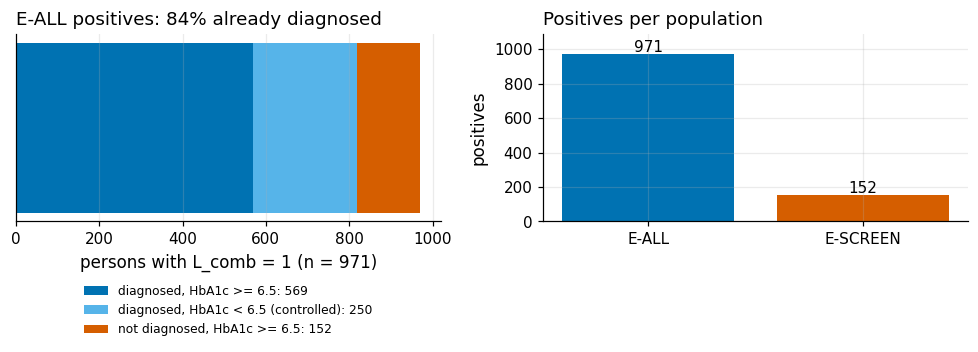

saved figures/S1_label_composition.png


In [58]:
# Figure: composition of the L_comb positives (left) and positives per population (right). Reads only the
# counts computed above; writes the figure with its caption through plots.savefig.
plots.set_style()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={"width_ratios": [1, 1]})
# Colour-blind-safe Okabe-Ito palette from the project config.
ok = C.OKABE_ITO
# Panel 1: who the 971 positives are
ax = axes[0]
parts = [("diagnosed, HbA1c >= 6.5", strata["D_uncontrolled"], ok["blue"]),
         ("diagnosed, HbA1c < 6.5 (controlled)", strata["D_controlled"], ok["sky"]),
         ("not diagnosed, HbA1c >= 6.5", strata["Undiagnosed"], ok["vermillion"])]
# Stacked horizontal bar: the three strata are drawn one after the other; `left` is where the next one starts.
left = 0
for lab, v, col in parts:
    ax.barh(0, v, left=left, color=col, label=f"{lab}: {v}")
    left += v
ax.set_yticks([]); ax.set_xlabel(f"persons with L_comb = 1 (n = {n_comb})")
ax.set_title(f"E-ALL positives: {share_known:.0%} already diagnosed", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), fontsize=8)
# Panel 2: E-SCREEN
ax = axes[1]
# Right panel: how few positives remain once the already-diagnosed are removed.
ax.bar(["E-ALL", "E-SCREEN"], [n_comb, n_escr_pos], color=[ok["blue"], ok["vermillion"]])
for i, v in enumerate([n_comb, n_escr_pos]):
    # Count label placed just above each bar (offset of 15 positives).
    ax.text(i, v + 15, str(v), ha="center")
ax.set_ylabel("positives"); ax.set_ylim(0, n_comb * 1.12); ax.set_title("Positives per population", loc="left")
fig.tight_layout()
f_comp = plots.savefig(fig, "S1_label_composition",
                       caption=f"Composition of the {n_comb} L_comb positives. {n_self} ({share_known:.1%}) already reported a diagnosis; "
                               f"only {n_escr_pos} are undiagnosed with HbA1c >= 6.5 and form the E-SCREEN positive class.")
plt.show(); print("saved", f_comp)

**So what.** Of the 971 positives, 819 (84.3 %) had already reported a diagnosis; only 152 are undiagnosed. E-ALL therefore rewards recognising known patients, while E-SCREEN (152 positives, 4,759 negatives) is where a screening aid has something to find. Prevalence is 16.9 % unweighted but 14.0 % weighted, mainly because older adults are over-represented in the sample. The E-ALL – E-SCREEN performance gap is reported as a finding in its own right. With 152 positives, many E-SCREEN contrasts will be *inconclusive*; that is stated in advance.

## 1.5 Research questions and hypotheses

**Why.** Four questions organise the project; each hypothesis has a metric, direction, magnitude, smallest effect of interest (SESOI), falsifier and an honest record of whether the data had been seen. They are read from `governance/hypotheses.md`, locked in §6.11 before any ablation.

| RQ | Question |
|---|---|
| RQ1 | **Labels as measurement.** What do self-report and HbA1c each measure, and who is missed by each? |
| RQ2 | **Rules and preparation.** How much do the availability rule (leakage) and systematic preparation change performance and stability, on E-ALL and on E-SCREEN? |
| RQ3 | **3 × 3 label matrix.** How does the training label change who is detected? |
| RQ4 | **Measurement bias.** Does BMI under-detect diabetes in Asian adults, and does waist-to-height ratio repair it? |

In [59]:
# Read the hypothesis table from governance/hypotheses.md and check that it is complete and well formed.
# Governance guard: every hypothesis carries a metric, a direction, a smallest effect of interest (SESOI), a
# falsifier and an honest record of whether the data had been seen before the hypothesis was written.
hyp = md_table(HYP_MD, "Hypothesis table")
display(hyp[["hyp_id", "rq_or_block", "statement", "prior_exposure"]])

# Allowed values for prior exposure: the pattern was seen in analysis, seen only descriptively, or not at all.
ALLOWED_EXPOSURE = {"analysis_seen", "descriptive_seen", "none"}
FIELDS = ["metric", "direction", "magnitude", "sesoi", "falsifier", "prior_exposure", "weights"]
# Exactly these eight hypotheses, in this order, so none can be added or dropped silently.
assert hyp["hyp_id"].tolist() == ["H1a", "H1b", "H2a", "H2b", "H2c", "H3", "H4a", "H4b"]
assert set(hyp["prior_exposure"]) <= ALLOWED_EXPOSURE
# No empty cell in any required field (an empty falsifier would make a hypothesis unfalsifiable).
assert (hyp[FIELDS].apply(lambda col: col.str.len() > 0)).all().all(), "every hypothesis needs all fields"
expo = hyp["prior_exposure"].value_counts().reindex(sorted(ALLOWED_EXPOSURE)).fillna(0).astype(int)
display(expo.rename("hypotheses").to_frame())
# Map each hypothesis to its research question by pulling `RQn` out of the block label.
rq_map = hyp.assign(rq=hyp["rq_or_block"].str.extract(r"(RQ\d)")[0]).groupby("rq")["hyp_id"].apply(list)
display(rq_map.rename("hypotheses").to_frame())

,hyp_id,rq_or_block,statement,prior_exposure
0,H1a,RQ1 (S5),"Among adults with HbA1c of 6.5 or more, the share not yet diagnosed (DIQ010 ...",analysis_seen
1,H1b,RQ1 (S4),The crude insured-minus-uninsured gap in diabetes prevalence shrinks after a...,analysis_seen
2,H2a,RQ2 / B1 (S7),A model that breaks the availability rule (M0) beats the same model with the...,analysis_seen
3,H2b,RQ2 / M1 vs S (S7),Systematic preparation (S) is equivalent to the availability-screened minima...,none
4,H2c,RQ2 / E-ALL vs E-SCREEN (S7),(i) T1 discriminates better on E-ALL than on E-SCREEN; (ii) removing the car...,none
5,H3,RQ3 (S8),In the 3 x 3 label matrix the training label determines who is missed: self-...,none
6,H4a,RQ4 (S5),"Among adults with diabetes, the share with BMI below 25 is much higher in As...",analysis_seen
7,H4b,"RQ4 (S5, S8)",Replacing waist circumference by waist-to-height ratio improves single-featu...,descriptive_seen


,hypotheses
prior_exposure,
analysis_seen,4
descriptive_seen,1
none,3


,hypotheses
rq,
RQ1,"[H1a, H1b]"
RQ2,"[H2a, H2b, H2c]"
RQ3,[H3]
RQ4,"[H4a, H4b]"


**So what.** Eight hypotheses cover the four questions (H1a, H1b → RQ1; H2a–H2c → RQ2; H3 → RQ3; H4a, H4b → RQ4), each with all seven fields. Four are `analysis_seen` (the pattern was observed in pilot profiling), one is `descriptive_seen`, and only the three experimental ones (H2b, H2c, H3) are genuine pre-registrations. §3–§5 therefore present confirmations of observed patterns, never pre-registered tests.

## 1.6 ADA-lite baseline

**Why.** A published risk score is the natural yardstick for a simple model, but this cycle lacks two of the seven items of Bang et al. 2009 (family history of diabetes, gestational diabetes). Calling the result "the ADA score" would overstate it. The baseline is therefore **ADA-lite, a reduced version missing 2 items**, compared on E-SCREEN only, because Bang's outcome is undiagnosed diabetes. The absence of the two items is checked in the CDC codebooks, not assumed.

In [60]:
# Show the ADA-lite item table and verify in the CDC codebooks that the two missing items really are absent.
# Reads governance/S1_scope.md and the MCQ_L / DIQ_L codebook pages; asserts zero hits for the missing items.
ada = md_table(SCOPE_MD, "ADA-lite baseline")
display(Markdown(to_md(ada)))
n_avail = int((ada["Status"] == "available").sum())
n_miss = int(ada["Status"].str.contains("missing").sum())
print(f"ADA-lite items available: {n_avail} of {len(ada)}; missing: {n_miss}")
# Five of the seven Bang et al. 2009 items exist in this cycle, two do not: hence 'ADA-lite'.
assert (n_avail, n_miss) == (5, 2)


# Plain lower-case text of one CDC codebook page: HTML tags stripped, whitespace collapsed (for term search).
def codebook_text(stem):
    t = (C.CODEBOOK_DIR / f"{stem}.htm").read_text(encoding="utf-8", errors="ignore")
    return re.sub(r"\s+", " ", re.sub(r"<[^>]+>", " ", t)).lower()


# Count how often each search term occurs in each codebook; the absence is evidence, not an assumption.
evidence = []
for stem in ["MCQ_L", "DIQ_L"]:
    t = codebook_text(stem)
    for term in ["family history", "blood relative", "gestational"]:
        evidence.append({"codebook": stem, "search term": term, "hits": t.count(term)})
    # 'during pregnancy' occurs in the wording of DIQ010 ("Other than during pregnancy ...") and is not a gestational-diabetes item
    evidence.append({"codebook": stem, "search term": "during pregnancy", "hits": t.count("during pregnancy")})
ev = pd.DataFrame(evidence)
display(ev)
# Show the context of 'during pregnancy' so a reader can see it is not a gestational-diabetes question.
ctx = [codebook_text("DIQ_L")[max(0, m.start() - 60): m.end() + 80] for m in re.finditer("during pregnancy", codebook_text("DIQ_L"))]
print("context of 'during pregnancy' in DIQ_L:")
for t in ctx[:2]:
    print("  ...", t.strip()[:120], "...")
# Zero hits for family history, blood relative and gestational: the two items are not in the data.
assert ev.query("`search term` in ['family history','blood relative','gestational']")["hits"].sum() == 0

| Item (Bang 2009) | NHANES 2021-23 | Status |
|---|---|---|
| Age | RIDAGEYR | available |
| Sex | RIAGENDR | available |
| History of hypertension | BPQ020 | available |
| Body mass index | BMXBMI (measured) | available |
| Physical activity | PAQ leisure-time items; inactive = no moderate and no vigorous sessions (PAD790Q = PAD810Q = 0) | available |
| Family history of diabetes | none in MCQ_L or DIQ_L | **missing** |
| Gestational diabetes | none in the 2021-23 files | **missing** |

ADA-lite items available: 5 of 7; missing: 2


,codebook,search term,hits
0,MCQ_L,family history,0
1,MCQ_L,blood relative,0
2,MCQ_L,gestational,0
3,MCQ_L,during pregnancy,0
4,DIQ_L,family history,0
5,DIQ_L,blood relative,0
6,DIQ_L,gestational,0
7,DIQ_L,during pregnancy,2


context of 'during pregnancy' in DIQ_L:
  ... uestions are about specific medical conditions. {other than during pregnancy, {have you/has sp}/{have you/has sp}} ever  ...
  ... play. if sp is female and age &gt;= 20, display "other than during pregnancy, {have you/has sp}". target: both males and ...


**So what.** Five of the seven items exist (age, sex, hypertension history, measured BMI, leisure-time activity); family history and gestational diabetes do not occur in the MCQ_L or DIQ_L codebooks (zero hits per search term), and the only pregnancy wording in DIQ_L is the exclusion clause of the diagnosis question. The baseline is therefore called ADA-lite. Only the verified abstract figures of Bang et al. (2009) are used, qualitatively (§9.8.3); no published AUC is used.

## 1.7 Novelty statement

**Why.** A contribution should be stated at the strength the evidence supports. The statement below says what is *combined*, not what is "first". It is read from `governance/S1_scope.md`, and the cell asserts that it contains no priority or superlative words.

In [61]:
# Check the novelty statement for priority claims. Reads governance/S1_scope.md; asserts that no word from the
# forbidden list occurs, so the text claims a combination of methods and never a 'first' or 'best'.
novelty = md_section(SCOPE_MD, "Novelty statement")
display(Markdown("> " + novelty))
# Priority and superlative words that a contribution statement must not use.
FORBIDDEN = ["first", "novel", "best", "optimal", "state-of-the-art", "unprecedented", "never before", "pioneer"]
# Whole-word, case-insensitive match (\b), so that e.g. 'bestow' would not trigger 'best'.
hits = [w for w in FORBIDDEN if re.search(rf"\b{re.escape(w)}\b", novelty, flags=re.I)]
assert not hits, hits
print("novelty statement: no priority or superlative words;", len(novelty.split()), "words")

> This project does not claim to discover that Asian adults develop diabetes at lower BMI, or that undiagnosed diabetes is linked to limited contact with health care; both are established. Its contribution is a combination applied to the 2021-2023 NHANES cycle with fixed basic models: an audit of the label as a measurement, a feature-availability rule that defines leakage, the quantified cost of blanket data cleaning, design-aware evaluation, and pre-registered paired ablations, triangulated against the published NCHS Data Brief 516 and a reduced ADA risk baseline. We have not found this integration in the literature we consulted.

novelty statement: no priority or superlative words; 97 words


## 1.8 Data user agreement and disclosure controls

**Why.** NHANES public-use files are released under the NCHS Data User Agreement. Compliance is part of the method: it forbids some analyses (linkage with other individual-level data) and shapes others (how small groups are reported). The datasheet summary (Gebru et al. 2021 format) states provenance, ethics approval and consent; the table maps each obligation to what the project does.

In [62]:
# Show the datasheet summary and the Data User Agreement obligations, and check that the ethics approval and
# consent statements are in the datasheet. Reads governance/datasheet.md and governance/S1_scope.md.
display(Markdown(md_section(DATASHEET_MD, "Summary")))
# Guard: the datasheet must name the NCHS ethics protocol and informed consent, not just assume them.
assert "Protocol #2021-05" in DATASHEET_MD and "informed consent" in DATASHEET_MD
dua = md_table(SCOPE_MD, "Data user agreement obligations")
display(dua)
# Five DUA obligations are tracked; a changed table has to be reviewed against the actions listed in it.
assert len(dua) == 5

| Item | Content |
|---|---|
| Source | NCHS/CDC NHANES public-use files, August 2021 – August 2023 (suffix `_L`), 16 files, downloaded 2026-10-10, SHA-256 verified |
| Ethics and consent | Collected by NCHS under NCHS Ethics Review Board approval (Protocol #2021-05, listed for NHANES 2021–2022 on the NCHS ERB page <https://www.cdc.gov/nchs/nhanes/about/erb.html>, accessed 2026-10-11) with documented informed consent of participants |
| Terms of use | NCHS Data User Agreement: statistical analysis only, no re-identification, no linkage, no study of disclosure controls |
| Instances | one row per participant; cohort N = 5,730 adults (20+, examined, HbA1c observed, not pregnant) from 11,933 |
| Variables | 175 raw columns, 78 kept after minimisation; definitions in `config/variable_spec.csv` |
| Label | `L_comb` = self-reported diagnosis or HbA1c >= 6.5 %: 971 positives (16.9 % unweighted, 14.0 % weighted); 84.3 % already diagnosed |
| Sampling | complex multistage design, 15 masked strata / 30 PSUs; no oversampling in this cycle; response 34.6 % (interview), 25.7 % (examination) |
| Known gaps | HbA1c missing for 4.9 % of examined adults (not MCAR); income missing 12.8 %; top-coding at age 80 and income ratio 5 |
| Intended use | teaching and research on data governance and label measurement; population-level estimates; basic models as measuring instruments |
| Not intended | clinical decisions about individuals, a deployable screening tool, causal claims, firm subgroup conclusions, linkage |

,Obligation (NCHS DUA),How the project complies
0,Use for statistical reporting and analysis only,Only population-level estimation and model evaluation; no individual-level d...
1,No attempt to identify any person or establishment,No identifying fields are used; no external lookup
2,No linkage with other data sets that could identify individuals,"External validation is against published aggregates only (DB516, Bang 2009)"
3,No study of disclosure-control methods,"Top-coding is taken as given and documented, never probed"
4,Presentation standards for survey estimates,"Flag n < 30, effective n < 30, 95 % CI width >= 0.30, domain df < 8 as explo..."


NCHS already applies disclosure controls to the public files. The project does not probe them; it makes their footprint visible so that a top-coded value is never mistaken for a measurement. The counts are computed on the cohort.

In [63]:
# Count the cohort rows hit by NCHS disclosure controls (top-coding, masked design variables) and compare them
# with what the loader and the models do about each. Reads the cohort and the public DEMO_L file; no model
# fit. Age 80 is the top code of RIDAGEYR (everyone older is recorded as 80).
age_top = int((c["RIDAGEYR"] == 80).sum())
# Income-to-poverty ratio is top-coded at 5; the 1e-9 tolerance guards the float comparison.
pir_top = int((c["INDFMPIR"] >= 5 - 1e-9).sum())
pir_na = int(c["INDFMPIR"].isna().sum())
# household size and pregnancy status are minimised away from the cohort; their disclosure footprint is read from the public DEMO_L file
# Read the raw SAS transport file, because these two columns are no longer in the minimised cohort.
demo_raw = pd.read_sas(C.RAW_DIR / "DEMO_L.xpt", format="xport")
hh_max = float(demo_raw["DMDHHSIZ"].max())
preg_known = demo_raw[demo_raw["RIDEXPRG"].notna()]
# Masked variance units: PSUs are nested in strata, so design df = PSUs - strata (30 - 15 = 15, asserted
# below). This is the df used for survey t-quantiles and for the delete-one-PSU jackknife in the other
# sections.
strata_n = int(c[C.STRATA].nunique())
psu_n = int(c.groupby(C.STRATA)[C.PSU].nunique().sum())

# One row per disclosure control: what it is, how many rows it touches, and how the project handles it.
dc = pd.DataFrame([
    ["Age top-coded at 80 (RIDAGEYR == 80)", age_top, f"{age_top / n:.1%} of cohort", "indicator age_top"],
    ["Income-to-poverty ratio top-coded at 5 (INDFMPIR)", pir_top, f"{pir_top / n:.1%} of cohort", "indicator pir_top"],
    ["Income-to-poverty ratio missing", pir_na, f"{pir_na / n:.1%} of cohort", "indicator pir_miss"],
    ["Household size, maximum value in DEMO_L (top-coded at 7)", hh_max, "dropped by minimisation", "documented in spec note"],
    ["Pregnancy status recorded only for women aged 20-44", f"{preg_known['RIDAGEYR'].min():.0f}-{preg_known['RIDAGEYR'].max():.0f}", f"{len(preg_known)} women in DEMO_L", "pregnant women excluded by the cohort rule"],
    ["Masked variance strata / PSUs", f"{strata_n} / {psu_n}", f"design df = {psu_n - strata_n}", "delete-one-PSU jackknife"],
], columns=["control", "value", "context", "handling"])
display(dc)
# Pin the counts quoted in the So-what; pregnancy status is recorded for women aged 20-44 only, which the last
# assert confirms.
assert (age_top, pir_top, pir_na) == (321, 1282, 734)
assert (strata_n, psu_n) == (15, 30) and hh_max == 7
assert preg_known["RIDAGEYR"].between(20, 44).all()

,control,value,context,handling
0,Age top-coded at 80 (RIDAGEYR == 80),321,5.6% of cohort,indicator age_top
1,Income-to-poverty ratio top-coded at 5 (INDFMPIR),1282,22.4% of cohort,indicator pir_top
2,Income-to-poverty ratio missing,734,12.8% of cohort,indicator pir_miss
3,"Household size, maximum value in DEMO_L (top-coded at 7)",7.0,dropped by minimisation,documented in spec note
4,Pregnancy status recorded only for women aged 20-44,20-44,1503 women in DEMO_L,pregnant women excluded by the cohort rule
5,Masked variance strata / PSUs,15 / 30,design df = 15,delete-one-PSU jackknife


**So what.** Ethics approval and consent come from NCHS, and the DUA obligations are met by design. 321 adults (5.6 %) are top-coded at age 80 and 1,282 (22.4 %) at an income ratio of 5, with 734 (12.8 %) missing, so indicators are kept next to the values. Masked variance units (15 strata, 30 PSUs) give 15 jackknife degrees of freedom; nothing tries to undo these controls.

## 1.9 Data minimisation

**Why.** Collecting or keeping more than the purpose needs is a governance risk even with public data (purpose limitation and data minimisation, e.g. GDPR Art. 5(1)(b)–(c); the Singapore PDPA has a purpose-limitation obligation). The loader keeps only columns that the variable specification keeps (`use_tier` other than `excluded`); `nhanes_io.minimisation_report` lists what was kept and dropped per file and per column.

In [64]:
# List, per NHANES file and per column, what the loader keeps and what it drops (data minimisation). Reads the
# variable specification; asserts the totals quoted in the So-what below.
mrep, mcols = nhanes_io.minimisation_report(spec)
display(mrep[["file", "use_tier", "cols_raw", "cols_kept", "cols_dropped"]])
tot_raw, tot_kept, tot_drop = (int(mrep[k].sum()) for k in ["cols_raw", "cols_kept", "cols_dropped"])
# Bookkeeping check: every raw column is either kept or dropped, never lost.
assert tot_raw == tot_kept + tot_drop
assert (tot_raw, tot_kept, tot_drop) == (175, 78, 97), "text of the so-what cell must be updated"
print(f"{tot_raw} raw columns in 16 files: {tot_kept} kept ({tot_kept / tot_raw:.0%}), {tot_drop} dropped ({tot_drop / tot_raw:.0%})")
# Examples of dropped quasi-identifiers and unrelated items, shown with the reason recorded for each.
examples = ["DMDBORN4", "DMDYRUSR", "DMQMILIZ", "DMDHHSIZ", "MCQ010"]
display(mcols[mcols["var"].isin(examples)][["file", "var", "decision", "reason"]])
# The per-column report and the per-file totals must describe the same dropped columns.
assert (mcols["decision"] == "drop").sum() == tot_drop
MIN_STATUS = {"raw_columns": tot_raw, "kept": tot_kept, "dropped": tot_drop}

,file,use_tier,cols_raw,cols_kept,cols_dropped
0,DEMO_L,core,27,13,14
1,GHB_L,core,3,3,0
2,GLU_L,side_analysis,4,3,1
3,BMX_L,core,22,7,15
4,BPXO_L,core,12,10,2
5,TCHOL_L,core,4,2,2
6,HDL_L,core,4,2,2
7,TRIGLY_L,side_analysis,10,3,7
8,DIQ_L,core,9,9,0
9,BPQ_L,recommended,6,3,3


175 raw columns in 16 files: 78 kept (45%), 97 dropped (55%)


,file,var,decision,reason
10,DEMO_L,DMQMILIZ,drop,military service: not needed (minimisation)
11,DEMO_L,DMDBORN4,drop,country of birth: not needed; quasi-identifier (minimisation)
12,DEMO_L,DMDYRUSR,drop,years in the US: not needed; quasi-identifier (minimisation)
16,DEMO_L,DMDHHSIZ,drop,"household size (top-coded 7): not needed, PIR already accounts for household..."
102,MCQ_L,MCQ010,drop,unrelated MCQ item (minimisation)


**So what.** Of 175 raw columns in the 16 files, 78 are kept and 97 (55 %) are dropped because they have no analytic role: quasi-identifiers (country of birth, years of residence), military service, household details, comment codes and unrelated MCQ items. Each dropped column has a stated reason, and the loader discards them right after reading, so downstream code cannot use them by accident.

## 1.10 Response rates and representativeness

**Why.** Survey weights make the sample resemble the US civilian non-institutionalised population *as far as known covariates allow*. They cannot repair non-response that depends on health. The 2021–2023 cycle has a low response and no oversampling of specific groups, which limits both generalisation and subgroup analysis.

,item,value,source
0,Interview response rate,34.6 %,NCHS cycle overview (not computable from the files)
1,Examination (MEC) response rate,25.7 %,NCHS cycle overview (not computable from the files)
2,Oversampling by race/ethnicity or income,none in this cycle,NCHS cycle overview; earlier cycles oversampled


,unweighted,WTPH2YR-weighted
20-39,24.7,34.8
40-59,29.2,33.8
60+,46.2,31.4


Kish design effect of the weights: 1.55; effective sample size 3707 of 5730


Asian adults in cohort: 315, of whom 50 with L_comb


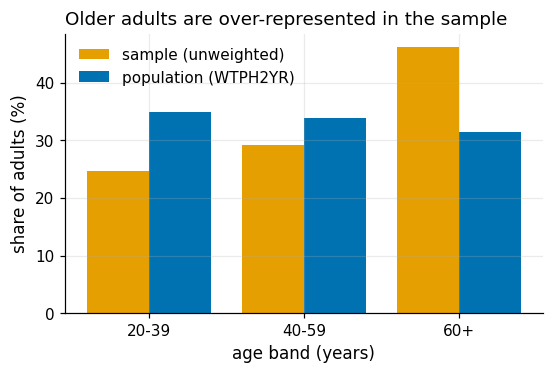

saved figures/S1_sample_vs_weighted_age.png


In [65]:
# Compare the sample with the weighted population and report response rates and the Kish design effect. The
# response rates come from the NCHS cycle overview (they cannot be computed from the files), so they are typed
# in with their source; the age structure and the design effect are computed from the cohort.
RESP = pd.DataFrame([
    ["Interview response rate", "34.6 %", "NCHS cycle overview (not computable from the files)"],
    ["Examination (MEC) response rate", "25.7 %", "NCHS cycle overview (not computable from the files)"],
    ["Oversampling by race/ethnicity or income", "none in this cycle", "NCHS cycle overview; earlier cycles oversampled"],
], columns=["item", "value", "source"])
display(RESP)

# Age bands, unweighted versus weighted by WTPH2YR: the gap shows which group is over-sampled.
w = c[C.WEIGHT_PHLEB]
bands = S.age_band(c["RIDAGEYR"]).values
tab = pd.DataFrame({"unweighted": pd.Series(bands).value_counts(normalize=True),
                    "WTPH2YR-weighted": pd.Series(w.values).groupby(bands).sum() / w.sum()}).loc[["20-39", "40-59", "60+"]]
display((tab * 100).round(1))
# Kish design effect = 1 + CV^2 of the weights; effective sample size = n / deff (information lost to unequal
# weights).
deff = S.kish_deff(w)
print(f"Kish design effect of the weights: {deff:.2f}; effective sample size {S.kish_neff(w):.0f} of {n}")
# Asian adults are the group of RQ4; the count shows how thin that subgroup is.
n_asian = int((c['RIDRETH3'] == 6).sum())
n_asian_pos = int(((c['RIDRETH3'] == 6) & (c['L_comb'] == 1)).sum())
print(f"Asian adults in cohort: {n_asian}, of whom {n_asian_pos} with L_comb")
# Pin the figures quoted in the So-what (Asian subgroup size, 60+ shares, design effect).
assert (n_asian, n_asian_pos) == (315, 50)
assert abs(tab.loc["60+", "unweighted"] - 0.462) < 0.001 and abs(tab.loc["60+", "WTPH2YR-weighted"] - 0.314) < 0.001
assert abs(deff - 1.55) < 0.01

# Figure: age structure of the sample versus the weighted population.
fig, ax = plt.subplots(figsize=(5.6, 3.3))
x = np.arange(3)
ax.bar(x - 0.2, tab["unweighted"] * 100, 0.4, color=C.OKABE_ITO["orange"], label="sample (unweighted)")
ax.bar(x + 0.2, tab["WTPH2YR-weighted"] * 100, 0.4, color=C.OKABE_ITO["blue"], label="population (WTPH2YR)")
ax.set_xticks(x, tab.index); ax.set_xlabel("age band (years)"); ax.set_ylabel("share of adults (%)")
ax.set_title("Older adults are over-represented in the sample", loc="left"); ax.legend()
f_age = plots.savefig(fig, "S1_sample_vs_weighted_age",
                      caption=f"Age structure of the {n} cohort adults, unweighted versus WTPH2YR-weighted. 60+ is {tab.loc['60+','unweighted']:.1%} of the sample "
                              f"but {tab.loc['60+','WTPH2YR-weighted']:.1%} of the weighted population; Kish design effect {deff:.2f}.")
plt.show(); print("saved", f_age)

**So what.** Adults aged 60+ are 46.2 % of the sample but 31.4 % of the weighted population, so unweighted figures overstate prevalence (16.9 % vs 14.0 %); the Kish design effect of 1.55 leaves the 5,730 adults with the information of roughly 3,700 simple-random-sample adults. Response is low (34.6 % interview, 25.7 % examination) and nothing is oversampled, so subgroups such as Asian adults (315, 50 with `L_comb`) are thin and reported as exploratory. Weights adjust for known covariates only; health-dependent participation (§5.6) remains a stated limitation.

## 1.11 Outputs

Decisions of this section (`governance/register/S1.csv`, with self-check verdicts) and the stored results (`results/metrics_S1.json`, `results/S1/`).

In [66]:
# Check the decision-register fragment for this section and store its numbers for later sections and the video.
# Reads governance/register/S1.csv; writes results/metrics_S1.json and two small tables under results/S1.
reg_path = GOV / "register" / "S1.csv"
reg = pd.read_csv(reg_path)
display(reg[["dr_id", "type", "decision", "hyp_id", "check_verdict"]])
# Every decision recorded for this section must have passed its self-check.
assert reg["check_verdict"].isin(["PASS", "PASS-FIX"]).all()

# Everything later sections quote from here is stored once, so they read it instead of recomputing it.
payload = {
    "n_cohort": n,
    "funnel": dict(zip(funnel["step"], funnel["n"])),
    "labels": {"L_self": n_self, "L_A1c": n_a1c, "L_comb": n_comb, "known_share_of_comb": share_known},
    "e_all": {"rows": n, "positives": n_comb},
    "e_screen": {"rows": n_escr, "positives": n_escr_pos, "negatives": n_escr_neg},
    "strata_3x3": strata.to_dict(),
    "prevalence_comb": {"unweighted": prev_u, "weighted": prev_w["est"],
                        "ci_low": prev_w["ci_low"], "ci_high": prev_w["ci_high"], "df": prev_w["df"]},
    "kish_deff": deff,
    "age60_share": {"sample": float(tab.loc["60+", "unweighted"]), "weighted": float(tab.loc["60+", "WTPH2YR-weighted"])},
    "disclosure": {"age_top": age_top, "pir_top": pir_top, "pir_missing": pir_na, "strata": strata_n, "psu": psu_n},
    "availability_rule": {"n_rule_rows": len(rule), "by_tier": counts.to_dict(), "spec": SPEC_STATUS},
    "ada_lite": {"items": len(ada), "available": n_avail, "missing": n_miss},
    "hypotheses": {"n": len(hyp), "prior_exposure": expo.to_dict()},
    "minimisation": MIN_STATUS,
    "response_rates": {"interview": 0.346, "mec": 0.257, "source": "NCHS cycle overview"},
}
# Write results/metrics_S1.json (the payload above); the two tables below go to results/S1.
R.save_section("S1", payload)
(C.RESULTS_DIR / "S1").mkdir(exist_ok=True)
rule.drop(columns="tier").to_csv(C.RESULTS_DIR / "S1" / "availability_rule.csv", index=False)
pop.to_csv(C.RESULTS_DIR / "S1" / "evaluation_populations.csv", index=False)
print("saved results/metrics_S1.json; S1 OK")

,dr_id,type,decision,hyp_id,check_verdict
0,DR-S1-01,scope,Frame the question as non-glycaemic identification of adult diabetes (diagno...,RQ1-RQ4,PASS
1,DR-S1-02,target,"Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on adults >=20, examined, non-pregna...",H2a,PASS
2,DR-S1-03,scope,Report E-ALL and E-SCREEN as co-primary populations; the gap between them is...,H2c,PASS
3,DR-S1-04,rule,"Admit a feature only if available at the screening moment, not a diagnostic ...",H2a,PASS
4,DR-S1-05,rule,Keep them admissible and add a T1-minus-care ablation arm reported on E-ALL ...,H2c,PASS
5,DR-S1-06,rule,Exclude from models by default; use as audit and stratification variables,H1a,PASS
6,DR-S1-07,baseline,"Use ADA-lite (reduced version, missing 2 items), compared on E-SCREEN only; ...",H2c,PASS
7,DR-S1-08,hypotheses,"Define H1a-H4b with prior_exposure markers; only H2b, H2c and H3 claim true ...",H1a-H4b,PASS
8,DR-S1-09,claims,State the contribution as a combination applied to one cycle with fixed basi...,NaN,PASS
9,DR-S1-10,governance,"Validate externally only against published aggregates (DB516, Bang 2009); ta...",NaN,PASS


saved results/metrics_S1.json; S1 OK


# §2 Data provenance, specification and minimisation

**Section lead:** A

This part works out where the data can be trusted and turns each finding into a recorded decision. §2.1 re-checks provenance, the codebook-derived specification and minimisation; the audit follows in §3:

§3.1 XPT read artefact · §3.2 completeness and funnel · §3.3 sentinel map · §3.4 cost of a blanket recode · §3.5 consistency · §3.6 top-coding · §3.7 HbA1c missingness · §3.8 outliers · §3.9 quality matrix.

Key numbers are asserted against reference values from an independent earlier computation, so any drift fails loudly. Results go to `results/metrics_S2.json` / `metrics_S3.json` and `results/S3/`, decisions to `governance/register/S2.csv` / `S3.csv`.

In [67]:
new_section()

In [68]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score
from IPython.display import display

from src import nhanes_io as io

pd.set_option("display.width", 160, "display.max_colwidth", 70, "display.max_rows", 80)
OI = C.OKABE_ITO
OUT = C.RESULTS_DIR / "S3"
OUT.mkdir(parents=True, exist_ok=True)
(C.RESULTS_DIR / "S2").mkdir(parents=True, exist_ok=True)
TODAY = "2026-10-11"
REGISTER_COLS = ["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision",
                 "alternatives_rejected", "hyp_id", "status", "check_verdict", "check_note", "loop_ref",
                 "change_request", "commit"]
M2, M3 = {}, {}   # metrics stored for S2 and S3


def close(a, b, tol=0.0):
    """Assert helper: |a - b| <= tol."""
    return abs(float(a) - float(b)) <= tol


def write_register(stage, rows):
    reg = pd.DataFrame(rows)
    for c in REGISTER_COLS:
        if c not in reg:
            reg[c] = ""
    reg = reg[REGISTER_COLS]
    reg.to_csv(C.GOVERNANCE_DIR / "register" / f"{stage}.csv", index=False, lineterminator="\n")
    return reg

## 2.1 Provenance, specification and minimisation

**Why.** An audit is only as good as its inputs. Three things are checked before any profiling:

- the raw files are the unmodified CDC files (SHA-256 against `MANIFEST.sha256`);
- the variable specification `config/variable_spec.csv` agrees with the CDC codebooks and with the columns actually present in the XPT files, because every sentinel code must have a traceable source;
- the loader keeps only what the purpose needs (data minimisation, GDPR Art. 5(1)(c)).

In [69]:
# Verify raw-file hashes, the variable specification and the minimisation report; assert the counts.
# Reads data/nhanes_2021_2023 and config/variable_spec.csv; writes results/S2/minimisation_*.csv.
integrity = io.ensure_raw_data(download=False)
print(f"raw files verified against MANIFEST.sha256: {len(integrity['verified'])}/{integrity['n_files']}; mismatched: {integrity['mismatched']}")
# Guard: every raw file must match MANIFEST.sha256 before anything is profiled (provenance).
assert integrity["mismatched"] == [] and len(integrity["verified"]) == 16

spec = io.load_spec()
problems = io.verify_spec(spec)
print("verify_spec problems:", problems or "none")
# verify_spec re-parses the CDC codebooks and XPT headers; any drift between spec and source fails here.
assert problems == []

# Included variables only; SEQN is the join key, not a feature, so it is left out of the role counts.
inc = io.included(spec)
role_tab = (inc[inc["var"] != "SEQN"].groupby(["role", "admissible"]).size().unstack(fill_value=0))
display(role_tab)
tier_tab = spec[spec["var"] != "SEQN"].groupby("use_tier").size().rename("variables").to_frame()
display(tier_tab)

# Minimisation: which raw columns the loader keeps or drops, with a stated reason for every drop.
min_files, min_cols = io.minimisation_report(spec)
min_files.to_csv(C.RESULTS_DIR / "S2" / "minimisation_report.csv", index=False, lineterminator="\n")
min_cols.to_csv(C.RESULTS_DIR / "S2" / "minimisation_columns.csv", index=False, lineterminator="\n")
display(min_files[["file", "use_tier", "rows", "cols_raw", "cols_kept", "cols_dropped"]])
n_raw, n_kept, n_drop = (int(min_files[c].sum()) for c in ("cols_raw", "cols_kept", "cols_dropped"))
print(f"columns: raw {n_raw}, kept {n_kept}, dropped {n_drop}; every dropped column has a reason:",
      bool(min_cols.loc[min_cols["decision"] == "drop", "reason"].str.len().gt(0).all()))
# Kept + dropped must partition all raw columns of the 16 files, so no column is silently lost.
assert n_raw == len(spec) == 175 and n_kept + n_drop == n_raw
# Data minimisation (GDPR Art. 5(1)(c)): a dropped column without a reason would be a governance gap.
assert min_cols.loc[min_cols["decision"] == "drop", "reason"].str.len().gt(0).all()

# Variables whose codebook lists Refused / Don't know codes (the per-variable sentinel map of §3.3).
n_sentinel_vars = len(io.sentinel_map(spec))
# Continuous lab and exam measures of the seven measurement files; none should carry refusal codes.
cont_inc = inc[(inc["dtype"] == "continuous") & inc["file"].isin(["BMX_L", "BPXO_L", "GHB_L", "TCHOL_L", "HDL_L", "GLU_L", "TRIGLY_L"])]
print(f"included variables with codebook refusal/don't-know codes: {n_sentinel_vars}; "
      f"continuous lab/exam measures with such codes: {int((cont_inc['sentinel_codes'] != '').sum())} of {len(cont_inc)}")
# Guard: no continuous measure has a sentinel code, only questionnaire items do. A blanket 7/9/77/99
# recode would therefore destroy valid values (§3.4).
assert (cont_inc["sentinel_codes"] == "").all() and len(cont_inc) == 21 and n_sentinel_vars == 25

raw files verified against MANIFEST.sha256: 16/16; mismatched: []


verify_spec problems: none


admissible,N,T1,T2
role,,,
audit,3,0,0
cohort_filter,2,0,0
design,2,0,0
feature,0,30,2
label,2,0,0
leak,8,0,0
optional,5,0,0
redundancy,2,0,0
side,2,0,0


,variables
use_tier,
core,41
excluded,97
optional,5
recommended,10
redundancy_demo,2
side_analysis,4


,file,use_tier,rows,cols_raw,cols_kept,cols_dropped
0,DEMO_L,core,11933,27,13,14
1,GHB_L,core,7199,3,3,0
2,GLU_L,side_analysis,3996,4,3,1
3,BMX_L,core,8860,22,7,15
4,BPXO_L,core,7801,12,10,2
5,TCHOL_L,core,8068,4,2,2
6,HDL_L,core,8068,4,2,2
7,TRIGLY_L,side_analysis,3996,10,3,7
8,DIQ_L,core,11744,9,9,0
9,BPQ_L,recommended,8501,6,3,3


columns: raw 175, kept 78, dropped 97; every dropped column has a reason: True
included variables with codebook refusal/don't-know codes: 25; continuous lab/exam measures with such codes: 0 of 21


**So what.** All 16 raw files match their hashes (CDC public-use files, Aug 2021 – Aug 2023, downloaded 2026-10-10). The specification has one row per raw column (175) and agrees with the codebooks and XPT headers; the loader keeps 78 columns and drops 97, each with a reason. The 25 variables with refusal or don't-know codes are all questionnaire items; none of the 21 continuous measures has one (§3.4 shows why this matters).

In [70]:
# Store the §2.1 checks in the metrics dict M2 (saved to results/ in the Outputs cell).
M2.update({
    "raw_files_verified": len(integrity["verified"]), "hash_mismatches": len(integrity["mismatched"]),
    "spec_rows": len(spec), "spec_problems": len(problems),
    "minimisation": {"cols_raw": n_raw, "cols_kept": n_kept, "cols_dropped": n_drop,
                     "per_file": min_files.set_index("file")[["cols_raw", "cols_kept", "cols_dropped"]].to_dict("index")},
    "use_tier_counts": tier_tab["variables"].to_dict(),
    # stack() flattens (role, admissible) to a Series; `if v` drops empty combinations.
    "role_admissible": {f"{r}|{a}": int(v) for (r, a), v in role_tab.stack().items() if v},
    "n_sentinel_variables": n_sentinel_vars,
})

# §3 Data profiling and quality audit

**Section lead:** B

This section continues §2 in the same workspace state (the helper functions and result dictionaries defined there are reused; no `new_section()` in between). It holds the nine audit items listed at the start of §2 (§3.1–§3.9) and the decision register of §2 and §3.

## 3.1 XPT read artefact and zero-weight semantics

**Why.** pandas reads a stored XPT zero as 5.397605e-79 (= 16⁻⁶⁵), a reader artefact that creates a spurious minimum and breaks `== 0` tests ("zero weight", "no activity"). The repair must keep NaN as NaN; the tempting `x.where(|x| >= 1e-10, 0)` turns every NaN into 0.

In [71]:
# Count XPT zero-read artefact cells (a stored 0 read as 5.4e-79) per file and variable.
# Reads all 16 XPT files via io.xpt_artefact_audit; writes results/S3/xpt_artefacts.csv.
art = io.xpt_artefact_audit()
art_file = art.groupby("file")["n_artefact"].sum().reindex(C.NHANES_FILES)
art_vars = art[art["n_artefact"] > 0].sort_values(["file", "n_artefact"], ascending=[True, False])
display(art_vars.reset_index(drop=True))
n_art = int(art_file.sum())
files_hit = art_file[art_file > 0].index.tolist()
print(f"artefact cells: {n_art:,} in {len(files_hit)} files")
print("  affected:", ", ".join(files_hit))
print("  clean:   ", ", ".join(art_file[art_file == 0].index))
art.to_csv(OUT / "xpt_artefacts.csv", index=False, lineterminator="\n")

# demonstrate the NaN-preservation requirement on one affected file
paq = io.read_xpt("PAQ_L")
fixed, n_fixed = io.fix_xpt(paq)
num = paq.select_dtypes("number")
wrong = num.where(num.abs() >= C.XPT_ZERO_EPS, 0.0)   # the tempting `where` version: NaN fails the test -> 0
nan_before, nan_after, nan_wrong = int(num.isna().sum().sum()), int(fixed[num.columns].isna().sum().sum()), int(wrong.isna().sum().sum())
residual = int(io._artefact_mask(fixed).to_numpy().sum())
print(f"PAQ_L: fixed {n_fixed:,} cells; NaN before {nan_before:,}, after mask-fix {nan_after:,}, after where-fix {nan_wrong:,}; residual 0<|x|<1e-10: {residual}")
# mask-fix keeps every NaN and leaves no residual artefact; the tempting where-fix loses NaN
# (nan_wrong < nan_before), which is the failure this check demonstrates.
assert nan_after == nan_before and residual == 0 and nan_wrong < nan_before

# whole-project check: all files repaired, NaN count unchanged
tot_fixed = 0
for f in C.NHANES_FILES:
    raw = io.read_xpt(f)
    fx, k = io.fix_xpt(raw)
    tot_fixed += k
    # No artefact may remain after the repair.
    assert io._artefact_mask(fx).to_numpy().sum() == 0
    # The repair must not change the NaN count of any file.
    assert fx.select_dtypes("number").isna().sum().sum() == raw.select_dtypes("number").isna().sum().sum()
# 13676 cells in 9 files: reference from an independent earlier computation; drift fails loudly.
assert n_art == tot_fixed == 13676 and len(files_hit) == 9

,file,var,n_artefact
0,DEMO_L,WTMEC2YR,3073
1,DEMO_L,RIDAGEYR,189
2,DEMO_L,INDFMPIR,100
3,DEMO_L,RIDAGEMN,17
4,DEMO_L,RIDEXAGM,4
5,GHB_L,WTPH2YR,449
6,GLU_L,WTSAF2YR,635
7,HDL_L,WTPH2YR,752
8,INQ_L,INDFMMPI,218
9,PAQ_L,PAD810Q,4413


artefact cells: 13,676 in 9 files
  affected: DEMO_L, GHB_L, GLU_L, TCHOL_L, HDL_L, TRIGLY_L, INQ_L, SMQ_L, PAQ_L
  clean:    BMX_L, BPXO_L, DIQ_L, BPQ_L, MCQ_L, HIQ_L, HUQ_L
PAQ_L: fixed 6,117 cells; NaN before 6,276, after mask-fix 6,276, after where-fix 0; residual 0<|x|<1e-10: 0


Several of the repaired zeros have a meaning defined in the codebook. A zero weight marks a participant outside that weight's sub-sample, so it must become missing before any weighted calculation:

In [72]:
# Zero-weight semantics: a zero weight means 'not in that sub-sample', not a real zero.
# Reads DEMO_L, GHB_L and GLU_L unminimised plus the cohort; asserts the counts.
demo = io.load_file("DEMO_L", minimise=False)[0]
ghb = io.load_file("GHB_L", minimise=False)[0]
glu = io.load_file("GLU_L", minimise=False)[0]
zw = pd.DataFrame([
    ["WTMEC2YR = 0", int((demo["WTMEC2YR"] == 0).sum()), "not MEC-examined", int((demo["RIDSTATR"] == 1).sum())],
    ["WTPH2YR = 0 (GHB_L)", int((ghb["WTPH2YR"] == 0).sum()), "no blood sample provided", None],
    ["WTSAF2YR = 0 (GLU_L)", int((glu["WTSAF2YR"] == 0).sum()), "fasting sub-sample non-response", None],
], columns=["condition", "n", "codebook meaning", "cross-check: RIDSTATR = 1 (interview only)"])
display(zw)
coh = io.build_cohort()
zero_in_cohort = int((coh["WTPH2YR"] == 0).sum())
print(f"cohort rows with WTPH2YR = 0: {zero_in_cohort}; WTPH2YR missing: {int(coh['WTPH2YR'].isna().sum())}")
# WTMEC2YR = 0 must equal the interview-only participants (RIDSTATR = 1): same count, same people.
assert zw.loc[0, "n"] == 3073 == zw.loc[0, "cross-check: RIDSTATR = 1 (interview only)"]
# 449 = participants without a blood sample; none may remain in the HbA1c-complete cohort.
assert zw.loc[1, "n"] == 449 and zero_in_cohort == 0

,condition,n,codebook meaning,cross-check: RIDSTATR = 1 (interview only)
0,WTMEC2YR = 0,3073,not MEC-examined,3073.0
1,WTPH2YR = 0 (GHB_L),449,no blood sample provided,NaN
2,WTSAF2YR = 0 (GLU_L),635,fasting sub-sample non-response,NaN


cohort rows with WTPH2YR = 0: 0; WTPH2YR missing: 0


**So what.** The artefact affects 13,676 cells in 9 files, mostly weights or frequencies whose true value is 0 (3,073 zero exam weights, 4,413 zero vigorous-activity sessions); the `mask` repair keeps every NaN, and no value with 0 < |x| < 10⁻¹⁰ remains. The zero weights carry meaning: `WTMEC2YR = 0` marks exactly the interview-only participants and `WTPH2YR = 0` the 449 without a blood sample. **Decision (DR-S3-01):** repair with `mask` at load time; zero weights become NaN before any weighted analysis.

In [73]:
# Store the XPT-artefact and zero-weight findings in M3.
M3["xpt_artefact"] = {"cells": n_art, "files": files_hit, "n_files": len(files_hit),
                      "per_file": {k: int(v) for k, v in art_file.items() if v},
                      "paq_nan_before": nan_before, "paq_nan_after_mask": nan_after, "paq_nan_after_where": nan_wrong}
M3["zero_weights"] = {"WTMEC2YR_0": int(zw.loc[0, "n"]), "WTPH2YR_0": int(zw.loc[1, "n"]),
                      "WTSAF2YR_0": int(zw.loc[2, "n"]), "cohort_WTPH2YR_0": zero_in_cohort}

## 3.2 Completeness, uniqueness and the sample funnel

**Why.** A left join on `SEQN` is only safe if `SEQN` is unique in every file and every file's participants are a subset of `DEMO_L`. Otherwise rows are duplicated or silently lost. The cohort definition is the first measurement decision of the project. Its funnel is asserted so that a change in any step fails loudly.

,file,rows,seqn_unique,subset_of_DEMO
0,DEMO_L,11933,True,True
1,GHB_L,7199,True,True
2,GLU_L,3996,True,True
3,BMX_L,8860,True,True
4,BPXO_L,7801,True,True
5,TCHOL_L,8068,True,True
6,HDL_L,8068,True,True
7,TRIGLY_L,3996,True,True
8,DIQ_L,11744,True,True
9,BPQ_L,8501,True,True


,step,n,dropped
0,DEMO_L participants,11933,0
1,Age >= 20,7809,4124
2,Interviewed and MEC-examined (RIDSTATR = 2),6064,1745
3,HbA1c measured (LBXGH present),5767,297
4,Not pregnant (RIDEXPRG != 1),5730,37


cohort N = 5,730; RIDEXPRG = 3 (cannot ascertain) kept and flagged: 21


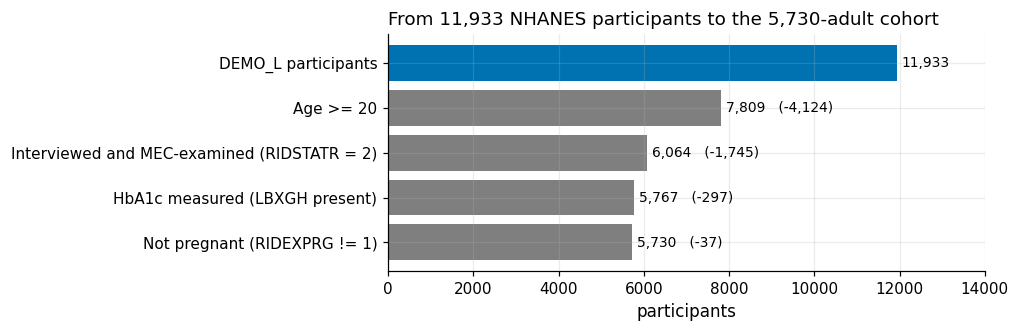

saved figures/S3_funnel.png


In [74]:
# Check that SEQN is unique in each file and a subset of DEMO_L, then assert the sample funnel.
# Reads all 16 XPT files; draws the funnel figure (figures/S3_funnel).
uniq = []
demo_ids = set(demo["SEQN"])
for f in C.NHANES_FILES:
    ids = io.read_xpt(f)["SEQN"]
    uniq.append({"file": f, "rows": len(ids), "seqn_unique": ids.is_unique, "subset_of_DEMO": set(ids) <= demo_ids})
uniq = pd.DataFrame(uniq)
display(uniq)
# Guard: a duplicate or orphan SEQN would duplicate or silently drop rows in the left join.
assert uniq["seqn_unique"].all() and uniq["subset_of_DEMO"].all()

fun = io.funnel()
display(fun)
# io.FUNNEL_EXPECTED holds the frozen step counts; a change in any cohort rule fails here.
assert tuple(fun["n"]) == io.FUNNEL_EXPECTED
# RIDEXPRG = 3 (pregnancy cannot be ascertained) is kept and flagged as preg_unknown, not dropped.
preg3 = int(coh["preg_unknown"].sum())
print(f"cohort N = {len(coh):,}; RIDEXPRG = 3 (cannot ascertain) kept and flagged: {preg3}")
assert preg3 == 21

# barh draws bottom-up, so the lists are reversed to show the first funnel step on top.
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(fun["step"][::-1], fun["n"][::-1], color=[OI["grey"]] * 4 + [OI["blue"]])
for y, (n, d) in enumerate(zip(fun["n"][::-1], fun["dropped"][::-1])):
    # Label each bar with its n and, in brackets, the rows removed at that step.
    ax.text(n + 120, y, f"{n:,}" + (f"   (-{d:,})" if d else ""), va="center", fontsize=9)
ax.set_xlabel("participants"); ax.set_xlim(0, 14000)
ax.set_title("From 11,933 NHANES participants to the 5,730-adult cohort", loc="left")
f_funnel = plots.savefig(fig, "S3_funnel", caption="Sample funnel: DEMO_L participants -> age >= 20 -> interviewed and examined -> HbA1c measured -> not pregnant (N = 5,730). Numbers in brackets are the rows removed at each step.")
plt.show(); print("saved", f_funnel)

**So what.** `SEQN` is unique in all 16 files and each is a subset of `DEMO_L`, so the join neither duplicates nor drops anyone. Funnel: 11,933 → 7,809 (age ≥ 20) → 6,064 (examined) → 5,767 (HbA1c present) → 5,730 (not pregnant); the examination step loses most (1,745). The 297 examined adults without HbA1c are studied in §3.7; 21 women with unascertainable pregnancy status are kept and flagged.

In [75]:
# Store the funnel, uniqueness and pregnancy-flag results in M3.
M3["funnel"] = dict(zip(fun["step"], fun["n"].astype(int)))
M3["uniqueness"] = {"files_seqn_unique": int(uniq["seqn_unique"].sum()), "files_subset_of_demo": int(uniq["subset_of_DEMO"].sum())}
M3["preg_unknown_kept"] = preg3

## 3.3 Per-variable sentinel map

**Why.** NHANES codes "Refused" / "Don't know" differently per variable (7/9, 77/99, 777/999, 7777/9999), and continuous measures have no such codes at all, so the sentinel map comes from each variable's codebook entry. Two checks make it auditable: recoded rows must equal the codebook frequency of each code, and look-alike codes that are real categories (`DIQ010 = 3` borderline, `HUQ030 = 3` more than one place of care) are kept.

In [76]:
# Audit the per-variable sentinel map: recoded cell counts must equal the codebook frequencies.
# Reads each file and the parsed codebooks; writes results/S3/sentinel_audit.csv.
cb = io.codebook_table()
rows = []
for f in C.NHANES_FILES:
    part = io.load_file(f, spec=spec)[0]
    # aud lists, per variable, the codes and the number of cells recoded.
    _, aud = io.apply_sentinels(part, spec, mode="per_variable")
    for _, a in aud.iterrows():
        codes = io._codes(a["codes"])
        # Codebook side: frequency of exactly the refusal / don't-know codes of this variable.
        cbv = cb[(cb["file"] == f) & (cb["var"] == a["var"])]
        cb_rows = cbv[cbv["code"].isin([str(c) for c in codes])]
        rows.append({"var": a["var"], "file": f, "codes": a["codes"],
                     "codebook_desc": " / ".join(cb_rows["desc"]),
                     "codebook_count": int(cb_rows["count"].sum()),
                     "recoded_file": int(a["n_recoded"])})
sent = pd.DataFrame(rows)
# Same audit on the cohort rows before any recoding (sentinels='none').
_, aud_coh = io.apply_sentinels(io.build_cohort(sentinels="none"), spec, mode="per_variable")
sent = sent.merge(aud_coh[["var", "n_recoded"]].rename(columns={"n_recoded": "recoded_cohort"}), on="var", how="left")
# traceable: cells we recode equal what the CDC codebook says exists for those codes.
sent["traceable"] = sent["codebook_count"] == sent["recoded_file"]
display(sent)
sent.to_csv(OUT / "sentinel_audit.csv", index=False, lineterminator="\n")
# Guard: every recode must be traceable to the codebook; an untraceable one would be an invented NA.
assert sent["traceable"].all(), sent[~sent["traceable"]]
# Reference values: 25 variables and 1047 recoded cells in the files.
assert len(sent) == 25 and int(sent["recoded_file"].sum()) == 1047
# Only 'Refused' / "Don't know" may be recoded; look-alike real categories must not appear here.
assert sent["codebook_desc"].str.split(" / ").map(lambda d: all(x in ("Refused", "Don't know") for x in d)).all()

# Look-alike codes that are real categories (borderline, several places of care, multiracial): kept.
legit = pd.DataFrame([
    ["DIQ010 = 3", "Borderline", int((coh["DIQ010"] == 3).sum()), int((io.read_xpt("DIQ_L")["DIQ010"] == 3).sum())],
    ["HUQ030 = 3", "There is more than one place", int((coh["HUQ030"] == 3).sum()), int((io.read_xpt("HUQ_L")["HUQ030"] == 3).sum())],
    ["RIDRETH3 = 7", "Other race, including multi-racial", int((coh["RIDRETH3"] == 7).sum()), int((demo["RIDRETH3"] == 7).sum())],
], columns=["code", "meaning", "cohort", "file"])
display(legit)
# Reference counts of borderline answers in the cohort and in the raw file.
assert legit.loc[0, "cohort"] == 213 and legit.loc[0, "file"] == 284
n_sent_coh = int(sent["recoded_cohort"].fillna(0).sum())
print(f"variables with codebook sentinels: {len(sent)}; cells recoded in the files: {int(sent['recoded_file'].sum()):,}; in the cohort: {n_sent_coh:,}")

,var,file,codes,codebook_desc,codebook_count,recoded_file,recoded_cohort,traceable
0,DMDEDUC2,DEMO_L,7;9,Refused / Don't know,11,11,2,True
1,DMDMARTZ,DEMO_L,77;99,Refused / Don't know,9,9,4,True
2,DIQ010,DIQ_L,7;9,Refused / Don't know,4,4,0,True
3,DID040,DIQ_L,777;999,Refused / Don't know,24,24,14,True
4,DIQ160,DIQ_L,7;9,Refused / Don't know,15,15,8,True
5,DIQ180,DIQ_L,7;9,Refused / Don't know,267,267,173,True
6,DIQ050,DIQ_L,7;9,Refused / Don't know,0,0,0,True
7,DID060,DIQ_L,777;999,Refused / Don't know,8,8,6,True
8,DIQ070,DIQ_L,7;9,Refused / Don't know,7,7,4,True
9,BPQ020,BPQ_L,7;9,Refused / Don't know,11,11,4,True


,code,meaning,cohort,file
0,DIQ010 = 3,Borderline,213,284
1,HUQ030 = 3,There is more than one place,34,57
2,RIDRETH3 = 7,"Other race, including multi-racial",363,948


variables with codebook sentinels: 25; cells recoded in the files: 1,047; in the cohort: 562


**So what.** For all 25 variables the recoded rows equal the codebook frequencies (1,047 cells; 562 in the cohort, most for `DIQ180`). Look-alike categories stay untouched: 213 borderline answers, 34 people with more than one usual place of care and 363 multiracial adults (`RIDRETH3 = 7`). **Decision (DR-S3-02):** recode per variable from the codebook; continuous measures are never recoded.

In [77]:
# Store the sentinel audit in M3.
M3["sentinel_audit"] = {"n_variables": len(sent), "cells_recoded_files": int(sent["recoded_file"].sum()),
                        "cells_recoded_cohort": n_sent_coh, "all_traceable": bool(sent["traceable"].all()),
                        "legit_codes_cohort": dict(zip(legit["code"], legit["cohort"].astype(int)))}

## 3.4 Cost of a blanket recode

**Why.** The common shortcut `df.replace([7, 9, 77, 99, 777, 999, 7777, 9999], np.nan)` – the naive arm M0 of §6.9 – removes valid values from continuous measures, which have no refusal codes (a diastolic pressure of 77, a weight of 99 kg, an HbA1c of 7.0 %). The damage is counted on the 5,730 adults for per-variable codes, the blanket shortcut and the shortcut restricted to six questionnaire items, including the effect on the labels.

In [78]:
# Cost of a blanket 7/9/77/99... recode versus the per-variable map, including the effect on labels.
# Reads cohorts built with sentinels none and blanket; writes results/S3/blanket_damage.csv.
coh_none = io.build_cohort(sentinels="none")
# Derived columns are computed after cleaning, so they are excluded from the blanket recode below.
DERIVED = ["bp_sys_mean", "bp_dia_mean", "whtr", "age_top", "pir_top", "pir_miss", "preg_unknown", "race", "sex"]
coh_blank = io.build_cohort(sentinels="blanket")
codes = list(io.BLANKET_CODES)
dmg = pd.DataFrame({"var": io.CONTINUOUS_CANDIDATES})
# Valid cells destroyed: non-missing values equal to a blanket code (these variables have no real codes).
dmg["valid_cells_destroyed"] = [int(coh_none[v].isin(codes).sum()) for v in dmg["var"]]
# Cross-check: the drop in non-missing cells in the blanket cohort must equal that count.
dmg["lost_in_blanket_cohort"] = [int(coh_none[v].notna().sum() - coh_blank[v].notna().sum()) for v in dmg["var"]]
# values_hit lists '<value>:<count>' for each blanket code that hits the variable.
dmg["values_hit"] = [", ".join(f"{io._num(k)}:{n}" for k, n in coh_none.loc[coh_none[v].isin(codes), v].value_counts().sort_index().items()) for v in dmg["var"]]
assert (dmg["valid_cells_destroyed"] == dmg["lost_in_blanket_cohort"]).all()
# Guard: none of the continuous candidates has a codebook sentinel, so every hit is valid data.
assert (spec.set_index("var").loc[list(io.CONTINUOUS_CANDIDATES), "sentinel_codes"].groupby(level=0).first() == "").all()
dmg = dmg.sort_values("valid_cells_destroyed", ascending=False).reset_index(drop=True)
display(dmg)
dmg.to_csv(OUT / "blanket_damage.csv", index=False, lineterminator="\n")
n_destroyed = int(dmg["valid_cells_destroyed"].sum())

# same 20 variables in the full merged file (secondary scope)
full_none = io.load_merged(sentinels="none")
n_destroyed_full = int(sum(full_none[v].isin(codes).sum() for v in io.CONTINUOUS_CANDIDATES))

# labels
# HbA1c positives (>= 6.5 %) before and after the blanket recode; 7.0 and 9.0 collide with codes 7 and 9.
a1c_pos = coh_none["LBXGH"] >= C.HBA1C_DIABETES
a1c_pos_blank = coh_blank["LBXGH"] >= C.HBA1C_DIABETES
lost_pos = int((a1c_pos & ~a1c_pos_blank).sum())
lost_values = coh_none.loc[a1c_pos & ~a1c_pos_blank, "LBXGH"].value_counts().to_dict()
# L_comb = self-reported diabetes OR HbA1c >= 6.5; a flip is a positive turned negative by the recode.
self_dm = coh["DIQ010"] == 1
l_comb = self_dm | a1c_pos
l_comb_blank = self_dm | a1c_pos_blank
flips = int((l_comb & ~l_comb_blank).sum())

# questionnaire-only arm: genuine codes in the six questionnaire items
q_arm = pd.Series({v: int(coh_none[v].isin(io.sentinel_map(spec)[v]).sum()) for v in io.QUESTIONNAIRE_ITEMS})
n_q = int(q_arm.sum())

# blanket on every numeric column: genuine codes vs valid values
# Derived columns are dropped first; 'genuine' counts hits that really are codebook codes.
_, aud_blank = io.apply_sentinels(coh_none.drop(columns=DERIVED), spec, mode="blanket")
smap = io.sentinel_map(spec)
aud_blank["genuine"] = [int(coh_none[v].isin(smap.get(v, [])).sum()) for v in aud_blank["var"]]
# Hits that are not codebook codes are valid values destroyed by the blanket rule.
aud_blank["valid_destroyed"] = aud_blank["n_recoded"] - aud_blank["genuine"]
n_blank_all, n_blank_genuine = int(aud_blank["n_recoded"].sum()), int(aud_blank["genuine"].sum())
# Variables outside the continuous candidates that still lose valid values (e.g. RIDRETH3 = 7).
other_valid = aud_blank[(aud_blank["valid_destroyed"] > 0) & ~aud_blank["var"].isin(io.CONTINUOUS_CANDIDATES)].sort_values("valid_destroyed", ascending=False)

print(f"valid cells destroyed in the cohort (20 continuous candidates): {n_destroyed:,}; same 20 variables in the full file: {n_destroyed_full:,}")
print(f"HbA1c positives lost: {lost_pos}/{int(a1c_pos.sum())} ({lost_pos / a1c_pos.sum():.1%}); values {lost_values}")
print(f"L_comb positives flipped to negative: {flips}/{int(l_comb.sum())}")
print(f"questionnaire-only arm: {n_q} genuine codes {q_arm.to_dict()}")
print(f"blanket over all numeric columns of the cohort: {n_blank_all:,} cells recoded, of which genuine refusal/don't-know {n_blank_genuine:,}")
display(other_valid[["var", "n_recoded", "genuine", "valid_destroyed", "by_code"]].head(12))

# Reference values from an independent earlier computation; any drift fails loudly.
assert n_destroyed == 1496 and n_destroyed_full == 2472
# The lost HbA1c positives sit exactly at 7.0 and 9.0 %, the values that collide with codes 7 and 9.
assert lost_pos == 29 and int(a1c_pos.sum()) == 721 and lost_values == {7.0: 28, 9.0: 1}
# Under L_comb few positives flip, because most also report a diagnosis (self-report masks the error).
assert flips == 6 and int(l_comb.sum()) == 971
assert n_q == 57 and q_arm.to_dict() == {"HIQ011": 9, "HUQ030": 1, "BPQ020": 4, "BPQ080": 34, "SMQ020": 7, "DMDEDUC2": 2}

,var,valid_cells_destroyed,lost_in_blanket_cohort,values_hit
0,BPXODI1,237,237,"77:214, 99:23"
1,BPXODI2,224,224,"77:209, 99:15"
2,BPXODI3,200,200,"77:182, 99:18"
3,BPXOPLS1,157,157,"77:139, 99:18"
4,BPXOPLS3,155,155,"77:138, 99:17"
5,BPXOPLS2,148,148,"77:127, 99:21"
6,RIDAGEYR,65,65,77:65
7,BPXOSY1,57,57,"77:2, 99:55"
8,BPXOSY3,56,56,"77:1, 99:55"
9,BPXOSY2,54,54,"77:1, 99:53"


valid cells destroyed in the cohort (20 continuous candidates): 1,496; same 20 variables in the full file: 2,472
HbA1c positives lost: 29/721 (4.0%); values {7.0: 28, 9.0: 1}
L_comb positives flipped to negative: 6/971
questionnaire-only arm: 57 genuine codes {'HIQ011': 9, 'HUQ030': 1, 'BPQ020': 4, 'BPQ080': 34, 'SMQ020': 7, 'DMDEDUC2': 2}
blanket over all numeric columns of the cohort: 3,132 cells recoded, of which genuine refusal/don't-know 562


,var,n_recoded,genuine,valid_destroyed,by_code
49,PAD790Q,405,25,380,7:380;7777:4;9999:21
3,RIDRETH3,363,0,363,7:363
9,LBXGLU,125,0,125,77:6;99:119
28,LBDLDL,63,0,63,77:25;99:38
51,PAD810Q,80,22,58,7:57;9:1;9999:22
27,LBXTLG,57,0,57,77:29;99:28
34,DID060,26,6,20,7:18;9:2;999:6
30,DID040,17,14,3,7:1;9:1;77:1;999:14
50,PAD800,16,13,3,7:3;9999:13
52,PAD820,10,9,1,7:1;7777:1;9999:8


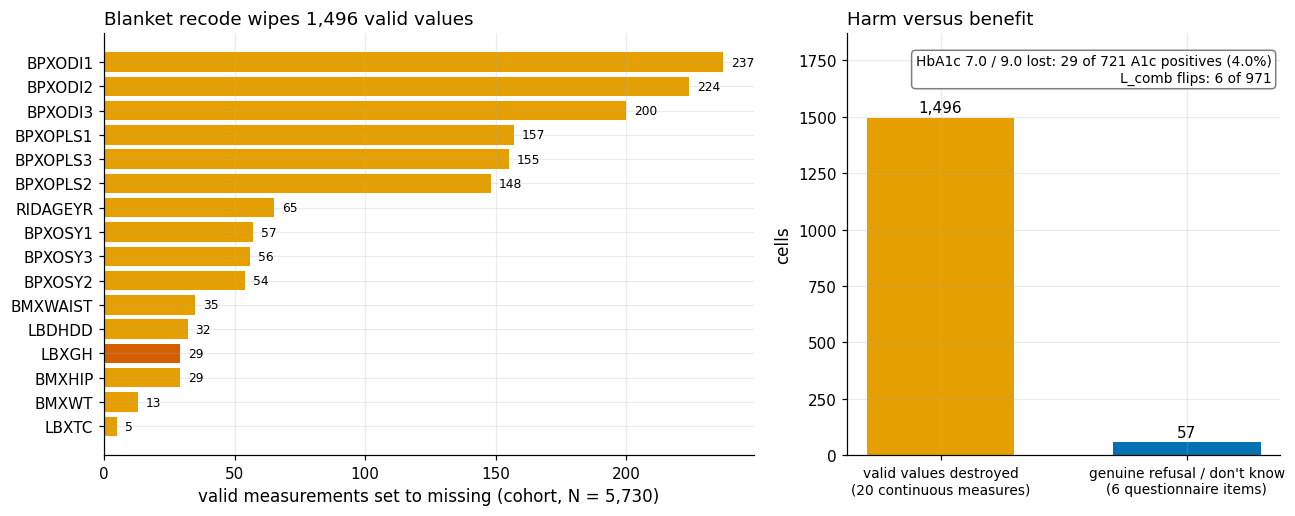

saved figures/S3_blanket_recode_damage.png


In [79]:
# Figure: valid values destroyed per variable (left) against genuine codes cleaned (right).
# Saves figures/S3_blanket_recode_damage.
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
# iloc[::-1] puts the largest bar on top in barh.
d = dmg[dmg["valid_cells_destroyed"] > 0].iloc[::-1]
# HbA1c in vermillion because its loss reaches the label.
col = [OI["vermillion"] if v == "LBXGH" else OI["orange"] for v in d["var"]]
a1.barh(d["var"], d["valid_cells_destroyed"], color=col)
for y, n in enumerate(d["valid_cells_destroyed"]):
    a1.text(n + 3, y, str(n), va="center", fontsize=8)
a1.set_xlabel("valid measurements set to missing (cohort, N = 5,730)")
a1.set_title(f"Blanket recode wipes {n_destroyed:,} valid values", loc="left")
# Right panel: harm (valid values destroyed) versus benefit (genuine codes in the six questionnaire items).
bars = [("valid values destroyed\n(20 continuous measures)", n_destroyed, OI["orange"]),
        ("genuine refusal / don't know\n(6 questionnaire items)", n_q, OI["blue"])]
a2.bar([b[0] for b in bars], [b[1] for b in bars], color=[b[2] for b in bars], width=0.6)
for x, b in enumerate(bars):
    a2.text(x, b[1] + 25, f"{b[1]:,}", ha="center", fontsize=10)
a2.set_ylabel("cells"); a2.set_ylim(0, n_destroyed * 1.25); a2.tick_params(axis="x", labelsize=9)
a2.set_title("Harm versus benefit", loc="left")
a2.text(0.98, 0.95, f"HbA1c 7.0 / 9.0 lost: {lost_pos} of {int(a1c_pos.sum())} A1c positives ({lost_pos / a1c_pos.sum():.1%})\n"
        f"L_comb flips: {flips} of {int(l_comb.sum())}", transform=a2.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round", fc="white", ec=OI["grey"]))
fig.tight_layout()
f_blank = plots.savefig(fig, "S3_blanket_recode_damage",
                        caption=f"Left: valid measurements removed by a blanket recode of 7/9/77/99/777/999/7777/9999 in the cohort, by variable "
                                f"({n_destroyed:,} in total; HbA1c in red). Right: the shortcut destroys {n_destroyed:,} valid values to clean {n_q} genuine "
                                f"refusal/don't-know answers in the questionnaire items; it removes {lost_pos}/{int(a1c_pos.sum())} HbA1c-defined positives, "
                                f"of which {flips} of {int(l_comb.sum())} L_comb positives flip.")
plt.show(); print("saved", f_blank)

**So what (non-obvious finding of the profiling).** On the same 5,730 adults the blanket recode destroys **1,496 valid measurements** (mostly diastolic pressure and pulse, where 77 and 99 are ordinary readings; 2,472 in the whole release). The harm reaches the label: all 29 HbA1c values it removes are 7.0 % (28) or 9.0 % (1), i.e. **29 of 721 HbA1c-defined positives (4.0 %)**. Under `L_comb` only **6 of 971** positives flip, because the other 23 also report a diagnosis: self-report hides the error. Applied to every numeric column it also erases real categories (the 363 multiracial adults, `RIDRETH3 = 7`). Its benefit is **57** genuine codes, so harm exceeds gain about 26-fold. **Decision (DR-S3-02):** the per-variable map is the systematic arm; the blanket recode survives only as the naive M0 arm (§6.9).

In [80]:
# Store the blanket-recode damage in M3.
M3["blanket_recode"] = {
    "valid_cells_destroyed_cohort": n_destroyed, "valid_cells_destroyed_full_file_same_20_vars": n_destroyed_full,
    "candidates": list(io.CONTINUOUS_CANDIDATES),
    "per_variable": dict(zip(dmg["var"], dmg["valid_cells_destroyed"].astype(int))),
    "a1c_positives_lost": lost_pos, "a1c_positives": int(a1c_pos.sum()), "a1c_lost_share": lost_pos / int(a1c_pos.sum()),
    "l_comb_flips": flips, "l_comb_positives": int(l_comb.sum()),
    "questionnaire_only_cells": n_q, "questionnaire_only_per_item": q_arm.to_dict(),
    "all_numeric_recoded": n_blank_all, "all_numeric_genuine": n_blank_genuine,
    "ridreth3_7_destroyed": int(aud_blank.set_index("var").loc["RIDRETH3", "valid_destroyed"]),
}

## 3.5 Consistency checks

**Why.** Internal consistency tests the data against facts that must hold: BMI is weight / height², systolic pressure exceeds diastolic, and pulse pressure and waist-to-height ratio stay within plausible bounds. Questions asked only of a sub-group (skip patterns) define who *can* have a value. That matters for leakage: a variable asked only of diagnosed people is a disguised label.

In [81]:
# Internal consistency: BMI arithmetic, SBP > DBP, pulse-pressure and WHtR bounds, skip-pattern universes.
# Reads BMX_L, BPXO_L, DIQ_L and the cohort; writes results/S3/consistency_checks.csv.
bmx = io.load_file("BMX_L")[0]
# Only rows with weight, height and BMI all present can be recomputed.
v = bmx.dropna(subset=["BMXWT", "BMXHT", "BMXBMI"])
# BMI = kg / m^2 with height in cm; the published BMI is rounded to 1 decimal, so up to 0.05 is rounding.
bmi_diff = (v["BMXWT"] / (v["BMXHT"] / 100) ** 2 - v["BMXBMI"]).abs()
bpx = io.load_file("BPXO_L")[0]
chk = [["BMI = weight / height^2: valid triples (BMX_L)", len(v), "max |diff| = %.3f; > 0.1: %d" % (bmi_diff.max(), (bmi_diff > 0.1).sum())]]
pp_rows = []
# Three oscillometric readings per person; pulse pressure = SBP - DBP must be positive and plausible
# (flagged below 20 or above 100 mmHg).
for src_name, df in [("BPXO_L file", bpx), ("cohort", coh)]:
    for i in (1, 2, 3):
        s, dd = df[f"BPXOSY{i}"], df[f"BPXODI{i}"]
        pp = s - dd
        pp_rows.append({"population": src_name, "reading": i, "valid": int((s.notna() & dd.notna()).sum()),
                        "SBP <= DBP": int((s <= dd).sum()), "pulse pressure < 20": int((pp < 20).sum()),
                        "pulse pressure > 100": int((pp > 100).sum())})
pp_tab = pd.DataFrame(pp_rows)
# Waist-to-height ratio above 1 (waist larger than height) is implausible in adults: flagged, not removed.
whtr_gt1 = int((coh["whtr"] > 1).sum())
chk.append(["Waist-to-height ratio > 1 (cohort)", int(coh["whtr"].notna().sum()), f"{whtr_gt1} flagged"])
chk = pd.DataFrame(chk, columns=["check", "n", "result"])
display(chk); display(pp_tab)

# Skip patterns: DIQ050 / DIQ070 are asked of sub-groups; tabulate who answered by DIQ010 and DIQ160.
diq_raw = io.read_xpt("DIQ_L")
univ = []
for var in ("DIQ050", "DIQ070"):
    ans = diq_raw[var].notna()
    g = diq_raw.loc[ans]
    univ.append({"var": var, "answered": int(ans.sum()),
                 "DIQ010=1": int((g["DIQ010"] == 1).sum()), "DIQ010=3": int((g["DIQ010"] == 3).sum()),
                 "DIQ010=2 & DIQ160=1": int(((g["DIQ010"] == 2) & (g["DIQ160"] == 1)).sum()),
                 "other": int((~((g["DIQ010"].isin([1, 3])) | ((g["DIQ010"] == 2) & (g["DIQ160"] == 1)))).sum())})
univ = pd.DataFrame(univ)
display(univ)
# Cohort adults taking oral glucose-lowering pills: shows DIQ070 also covers non-diabetic respondents.
coh_dia = coh[coh["DIQ070"] == 1]
d070 = {"self-reported diabetes": int((coh_dia["DIQ010"] == 1).sum()), "borderline": int((coh_dia["DIQ010"] == 3).sum()),
        "no diabetes (told prediabetes)": int((coh_dia["DIQ010"] == 2).sum())}
print("cohort, DIQ070 = 1 (takes oral glucose-lowering medication):", d070)
consistency = pd.concat([chk.assign(kind="arithmetic"), pp_tab.assign(kind="blood pressure")], ignore_index=True)
consistency.to_csv(OUT / "consistency_checks.csv", index=False, lineterminator="\n")

# Recomputed BMI differs from the published one by at most the 0.05 rounding (1e-9 float slack).
assert len(v) == 8471 and bmi_diff.max() <= 0.05 + 1e-9 and (bmi_diff > 0.1).sum() == 0
# SBP <= DBP would be a recording error; the WHtR > 1 count is a reference value.
assert pp_tab["SBP <= DBP"].sum() == 0 and whtr_gt1 == 4
# DIQ050 (insulin) is answered only by people with DIQ010 = 1, so as a feature it would be a disguised label.
assert univ.loc[0, ["answered", "DIQ010=1", "other"]].tolist() == [1081, 1081, 0]
# DIQ070 (pills) additionally covers borderline and prediabetic respondents, and nobody outside these groups.
assert univ.loc[1, ["DIQ010=1", "DIQ010=3", "DIQ010=2 & DIQ160=1", "other"]].tolist() == [1081, 282, 918, 0]

,check,n,result
0,BMI = weight / height^2: valid triples (BMX_L),8471,max |diff| = 0.050; > 0.1: 0
1,Waist-to-height ratio > 1 (cohort),5462,4 flagged


,population,reading,valid,SBP <= DBP,pulse pressure < 20,pulse pressure > 100
0,BPXO_L file,1,7517,0,12,37
1,BPXO_L file,2,7505,0,8,43
2,BPXO_L file,3,7480,0,11,32
3,cohort,1,5550,0,5,34
4,cohort,2,5544,0,2,39
5,cohort,3,5531,0,3,29


,var,answered,DIQ010=1,DIQ010=3,DIQ010=2 & DIQ160=1,other
0,DIQ050,1081,1081,0,0,0
1,DIQ070,2281,1081,282,918,0


cohort, DIQ070 = 1 (takes oral glucose-lowering medication): {'self-reported diabetes': 592, 'borderline': 44, 'no diabetes (told prediabetes)': 41}


**So what.** The arithmetic holds: BMI recomputes for all 8,471 valid triples (largest difference 0.050), no reading has systolic ≤ diastolic, and implausible pulse pressures and four waist-to-height ratios above 1 are flagged. The skip patterns matter more: `DIQ050` (insulin) is answered only by the 1,081 people reporting diabetes, and `DIQ070` (pills) also by borderline and prediabetic respondents (41 non-diabetic and 44 borderline cohort adults take them). **Decision (DR-S3-06):** both are inadmissible; the treatment-aware label (§5.8) uses them only inside this universe.

In [82]:
# Store the consistency results in M3.
M3["consistency"] = {"bmi_triples": len(v), "bmi_max_abs_diff": float(bmi_diff.max()), "bmi_diff_gt_0_1": int((bmi_diff > 0.1).sum()),
                     "sbp_le_dbp": int(pp_tab["SBP <= DBP"].sum()),
                     "pp_lt20_cohort": pp_tab.query("population == 'cohort'")["pulse pressure < 20"].tolist(),
                     "pp_gt100_cohort": pp_tab.query("population == 'cohort'")["pulse pressure > 100"].tolist(),
                     "pp_lt20_file": pp_tab.query("population == 'BPXO_L file'")["pulse pressure < 20"].tolist(),
                     "pp_gt100_file": pp_tab.query("population == 'BPXO_L file'")["pulse pressure > 100"].tolist(),
                     "whtr_gt1": whtr_gt1, "diq050_universe": univ.iloc[0].drop("var").to_dict(),
                     "diq070_universe": univ.iloc[1].drop("var").to_dict(), "cohort_diq070_yes": d070}

## 3.6 Top-coding

**Why.** Disclosure control caps age at 80 and the income-to-poverty ratio at 5. A capped value is a bound rather than a measurement. A model that treats "80" as exactly 80 years, or that loses the 12.8 % of people with no income ratio, misreads the data. Two questions decide the treatment: how many people sit at each cap, and whether the cap hides a change in risk.

In [83]:
# Top-coding: how many adults sit at the age cap (80) and the income-ratio cap (5); does the cap hide risk?
# Uses the cohort and the L_comb label from §3.4; asserts counts and prevalences.
# Attach the combined label (self-report OR HbA1c >= 6.5) for the prevalence comparison below.
coh["L_comb"] = l_comb.astype(int)
age_top, pir_top, pir_miss = int(coh["age_top"].sum()), int(coh["pir_top"].sum()), int(coh["pir_miss"].sum())
# Unweighted prevalence only, to screen for a risk change at the cap (RIDAGEYR is capped at 80 by NCHS).
prev_80 = coh.loc[coh["RIDAGEYR"] == 80, "L_comb"].mean()
prev_7079 = coh.loc[coh["RIDAGEYR"].between(70, 79), "L_comb"].mean()
top = pd.DataFrame([
    ["age_top (RIDAGEYR = 80)", age_top, age_top / len(coh)],
    ["pir_top (INDFMPIR = 5)", pir_top, pir_top / len(coh)],
    ["pir_miss (INDFMPIR missing)", pir_miss, pir_miss / len(coh)],
], columns=["flag", "n", "share"])
display(top)
print(f"L_comb prevalence (unweighted): age 80 group {prev_80:.1%}, ages 70-79 {prev_7079:.1%}")
# Reference counts of capped and missing values (age_top, pir_top, pir_miss).
assert (age_top, pir_top, pir_miss) == (321, 1282, 734)
# Reference prevalences, to within 0.1 percentage point.
assert close(prev_80, 0.262, 0.001) and close(prev_7079, 0.254, 0.001)

,flag,n,share
0,age_top (RIDAGEYR = 80),321,0.056021
1,pir_top (INDFMPIR = 5),1282,0.223735
2,pir_miss (INDFMPIR missing),734,0.128098


L_comb prevalence (unweighted): age 80 group 26.2%, ages 70-79 25.4%


**So what.** 321 adults (5.6 %) are capped at age 80 and 1,282 (22.4 %) at an income ratio of 5; another 734 (12.8 %) have no income ratio. The age cap hides little: unweighted `L_comb` prevalence is 26.2 % at the cap against 25.4 % at ages 70–79. **Decision (DR-S3-05):** keep the values and carry the flags `age_top`, `pir_top` and `pir_miss`; whether they help a model is tested as block B4 (§6.6).

In [84]:
# Store the top-coding results in M3.
M3["top_coding"] = {"age_top": age_top, "pir_top": pir_top, "pir_top_share": pir_top / len(coh),
                    "pir_miss": pir_miss, "pir_miss_share": pir_miss / len(coh),
                    "prev_age80": float(prev_80), "prev_age70_79": float(prev_7079)}

## 3.7 Missing-data mechanism for HbA1c

**Why.** The cohort keeps only examined adults *with* HbA1c; if missingness depended on diabetes itself, no weighting could repair the label. MCAR can be rejected from observed covariates, MAR vs MNAR cannot be tested. An unweighted logistic model for missingness among the 6,064 examined adults shows who is missing (Little's test is not used: it assumes normality and can only reject MCAR).

In [85]:
# Missing-data mechanism for HbA1c: unweighted logistic model of 'HbA1c missing' among examined adults.
# Reads the merged file (per-variable recode); writes results/S3/missingness_or.csv.
mrg = io.load_merged(sentinels="per_variable")
# Examined adults (RIDSTATR == 2, age >= 20) are the ones who could have an HbA1c; pregnant women included.
ex = mrg[(mrg["RIDAGEYR"] >= C.ADULT_MIN_AGE) & (mrg["RIDSTATR"] == 2)].copy()
# Outcome: 1 = HbA1c missing.
y_miss = ex["LBXGH"].isna().astype(int)
race_ex = ex["RIDRETH3"].map(io.RACE_LABELS)
# Covariates: demographics, access and self-reported conditions; age per 10 years gives an OR per decade.
Xm = pd.DataFrame({"age (per 10 y)": ex["RIDAGEYR"] / 10, "female": (ex["RIAGENDR"] == 2).astype(int)}, index=ex.index)
# One dummy per race group; NH White is the omitted reference level.
for r in ["NH Black", "NH Asian", "Mexican American", "Other Hispanic", "Other/Multi"]:
    Xm[r] = (race_ex == r).astype(int)
# Mean-impute continuous gaps and add a missing indicator (PIR, BMI); a missing BMI mainly signals
# an incomplete examination.
Xm["PIR (per unit)"] = ex["INDFMPIR"].fillna(ex["INDFMPIR"].mean())
Xm["PIR missing"] = ex["INDFMPIR"].isna().astype(int)
Xm["BMI (per unit)"] = ex["BMXBMI"].fillna(ex["BMXBMI"].mean())
Xm["BMI missing"] = ex["BMXBMI"].isna().astype(int)
# Binary indicators: no insurance (HIQ011 = 2), no usual place of care (HUQ030 = 2), self-reported
# diabetes (DIQ010 = 1) and told hypertension (BPQ020 = 1).
Xm["uninsured"] = (ex["HIQ011"] == 2).astype(int)
Xm["no usual place of care"] = (ex["HUQ030"] == 2).astype(int)
Xm["self-reported diabetes"] = (ex["DIQ010"] == 1).astype(int)
Xm["told hypertension"] = (ex["BPQ020"] == 1).astype(int)
# Plain logit with a constant; disp=0 silences the optimiser log.
fit = sm.Logit(y_miss, sm.add_constant(Xm)).fit(disp=0)
# 95 % Wald CI on the log-odds scale, exponentiated to odds ratios below.
ci = fit.conf_int()
or_tab = pd.DataFrame({"OR": np.exp(fit.params), "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]), "p": fit.pvalues}).drop("const")
# AUC of the missingness model: how well covariates predict who is missing (0.5 = nothing).
auc_miss = roc_auc_score(y_miss, fit.predict())
# Missing share by race group (mean of the 0/1 indicator).
miss_rate = ex.assign(m=y_miss, race=race_ex).groupby("race")["m"].agg(["size", "mean"]).rename(columns={"size": "n", "mean": "missing_share"})
print(f"examined adults {len(ex):,}; HbA1c missing {int(y_miss.sum())} ({y_miss.mean():.1%}); LLR p = {fit.llr_pvalue:.1e}; AUC = {auc_miss:.3f}")
display(or_tab.round(3)); display(miss_rate.round(3))
or_tab.to_csv(OUT / "missingness_or.csv", lineterminator="\n")

# Reference counts: examined adults and adults without HbA1c.
assert len(ex) == 6064 and int(y_miss.sum()) == 297
# Likelihood-ratio test rejects MCAR (covariates predict missingness); AUC within 0.005 of reference.
assert fit.llr_pvalue < 1e-10 and close(auc_miss, 0.65, 0.005)
# Odds ratios asserted against reference values (tolerance 0.01, 0.06 for the wide BMI-missing OR).
assert close(or_tab.loc["NH Black", "OR"], 1.85, 0.01) and close(or_tab.loc["NH Black", "ci_low"], 1.35, 0.01) and close(or_tab.loc["NH Black", "ci_high"], 2.54, 0.01)
assert close(or_tab.loc["PIR (per unit)", "OR"], 0.82, 0.01) and close(or_tab.loc["age (per 10 y)", "OR"], 0.89, 0.01)
assert close(or_tab.loc["BMI missing", "OR"], 2.6, 0.06) and close(or_tab.loc["self-reported diabetes", "OR"], 1.15, 0.01)

examined adults 6,064; HbA1c missing 297 (4.9%); LLR p = 2.8e-11; AUC = 0.650


,OR,ci_low,ci_high,p
age (per 10 y),0.893,0.826,0.965,0.004
female,0.948,0.745,1.205,0.660
NH Black,1.853,1.351,2.541,0.000
NH Asian,1.383,0.846,2.263,0.196
Mexican American,0.772,0.448,1.328,0.349
Other Hispanic,0.842,0.541,1.309,0.444
Other/Multi,1.244,0.785,1.973,0.353
PIR (per unit),0.820,0.753,0.892,0.000
PIR missing,1.572,1.151,2.148,0.004
BMI (per unit),0.997,0.981,1.014,0.723


,n,missing_share
race,,
Mexican American,405,0.040
NH Asian,335,0.060
NH Black,753,0.093
NH White,3569,0.040
Other Hispanic,614,0.042
Other/Multi,388,0.059


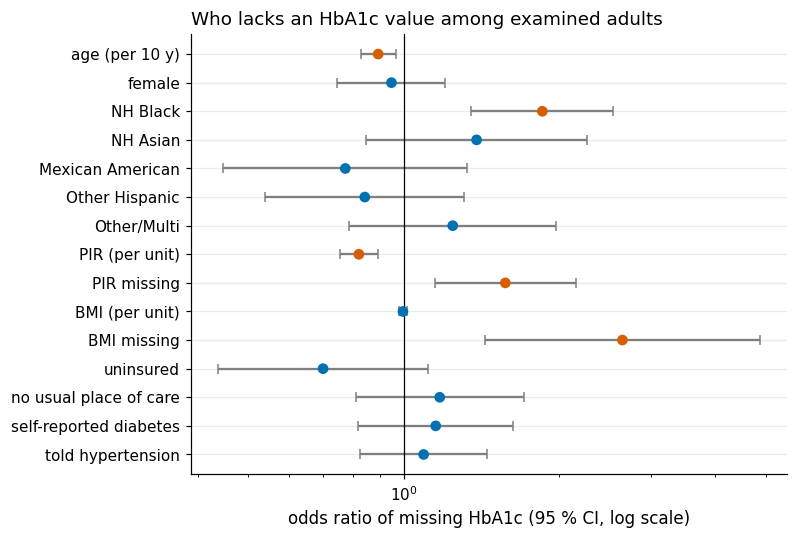

saved figures/S3_missing_hba1c_or.png


In [86]:
# Forest plot of the missingness odds ratios on a log scale; red = 95 % CI excludes 1.
# Saves figures/S3_missing_hba1c_or.
# Reverse the table so the first covariate is drawn at the top.
ot = or_tab.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5.2))
# sig: Wald CI entirely above or entirely below 1.
sig = (ot["ci_low"] > 1) | (ot["ci_high"] < 1)
ax.errorbar(ot["OR"], range(len(ot)), xerr=[ot["OR"] - ot["ci_low"], ot["ci_high"] - ot["OR"]], fmt="none", ecolor=OI["grey"], capsize=3)
ax.scatter(ot["OR"], range(len(ot)), color=[OI["vermillion"] if s else OI["blue"] for s in sig], zorder=3)
ax.axvline(1, color="black", lw=0.8)
ax.set_xscale("log"); ax.set_yticks(range(len(ot)), ot.index)
ax.set_xlabel("odds ratio of missing HbA1c (95 % CI, log scale)")
ax.set_title("Who lacks an HbA1c value among examined adults", loc="left")
f_miss = plots.savefig(fig, "S3_missing_hba1c_or",
                       caption=f"Unweighted logistic model for missing HbA1c among {len(ex):,} examined adults ({int(y_miss.sum())} missing). "
                               f"Odds ratios with 95 % Wald CIs; red = CI excludes 1. LLR p = {fit.llr_pvalue:.1e}, AUC = {auc_miss:.2f}. Reference: NH White.")
plt.show(); print("saved", f_miss)

**So what.** 297 of 6,064 examined adults (4.9 %; all examined adults, pregnant women included – §9.7 uses the 6,023 non-pregnant ones, 293 missing) lack HbA1c, and missingness clearly depends on observed covariates (likelihood-ratio p = 2.8 × 10⁻¹¹, AUC 0.65). Data are **not MCAR**. Associations with missing HbA1c:

| Covariate | OR (95 % CI) |
|---|---|
| Non-Hispanic Black | 1.85 (1.35, 2.54) |
| Income ratio, per unit | 0.82 |
| Age, per 10 years | 0.89 |
| Missing BMI | 2.6 (typically an incomplete examination) |
| Self-reported diabetes | 1.15 (0.82, 1.63) |

Self-reported diabetes, the closest observable stand-in for the outcome, shows no association.

The correct wording is narrow: **given these covariates there is no evidence against MAR, and MNAR cannot be tested with these data.** **Decision (DR-S3-04):** this wording is used everywhere; WTPH2YR already contains the NCHS blood-sample non-response adjustment, and an inverse-probability-weighting / delta-adjustment sensitivity analysis follows in §9.7.

In [87]:
# Store the missingness results in M3.
M3["missingness"] = {"examined_adults": len(ex), "a1c_missing": int(y_miss.sum()), "a1c_missing_share": float(y_miss.mean()),
                     "llr_p": float(fit.llr_pvalue), "auc": float(auc_miss),
                     "odds_ratios": {k: {kk: float(vv) for kk, vv in r.items()} for k, r in or_tab.iterrows()},
                     "missing_share_by_race": miss_rate["missing_share"].to_dict(),
                     "wording": "not MCAR; no evidence against MAR given covariates; MNAR untestable (sensitivity in §9.7)"}

## 3.8 Outliers: a three-layer rule

**Why.** In clinical data the extremes are often the signal (a very high HbA1c *is* diabetes), so deleting beyond 1.5 × IQR removes cases, not errors. Three layers: hard physiological limits and a robust z-score (|z| > 3.5) only flag; a human reviews what both flag. The harm of blind deletion is measured directly.

In [88]:
# Three-layer outlier rule: hard limits and robust z only flag; a human reviews what both flag.
# Writes results/S3/outlier_flags.csv, then measures the harm of deleting by the 1.5 x IQR rule on HbA1c.
# Layer 1: hard physiological limits (lo, hi) per variable, in the variable's own unit.
LIMITS = {"BMXBMI": (12, 70), "bp_sys_mean": (70, 260), "bp_dia_mean": (30, 150), "LBXTC": (60, 500), "LBDHDD": (10, 200), "LBXGH": (3, 18)}
# Robust z-score 0.6745 * (x - median) / MAD; the 0.6745 rescales the MAD to a standard deviation.
def robust_z(s):
    med = s.median(); mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad
out_rows = []
for var, (lo, hi) in LIMITS.items():
    s = coh[var]
    # Layer 1: outside the hard limits.
    hard = (s < lo) | (s > hi)
    # Layer 2: |robust z| > 3.5 (the usual cut-off for the modified z-score).
    rz = robust_z(s).abs() > 3.5
    out_rows.append({"var": var, "valid": int(s.notna().sum()), "min": s.min(), "max": s.max(), "limits": f"{lo}-{hi}",
                     "layer1_outside_limits": int(hard.sum()), "layer2_robust_z_gt_3.5": int(rz.sum()),
                     "both_layers": int((hard & rz).sum())})
outl = pd.DataFrame(out_rows)
display(outl)
outl.to_csv(OUT / "outlier_flags.csv", index=False, lineterminator="\n")
review = int(outl["both_layers"].sum())
print(f"layer 3 (manual review queue): {review} values flagged by both layers")

# Layer 3: the value(s) flagged by both layers, with the measurements needed to judge them.
both = pd.concat([coh.loc[((coh[v] < lo) | (coh[v] > hi)) & (robust_z(coh[v]).abs() > 3.5)].assign(var=v, value=lambda d, v=v: d[v])
                  for v, (lo, hi) in LIMITS.items()])
both["bmi_recomputed"] = (both["BMXWT"] / (both["BMXHT"] / 100) ** 2).round(1)
display(both[["var", "value", "BMXWT", "BMXHT", "bmi_recomputed", "RIDAGEYR"]]
        .rename(columns={"BMXWT": "weight_kg", "BMXHT": "height_cm", "RIDAGEYR": "age"}).reset_index(drop=True))
# Exactly one value passes both layers and it must be a BMI; any other outcome means a rule changed.
assert len(both) == review == 1 and both["var"].iloc[0] == "BMXBMI"
# Manual review: BMI recomputed from weight and height matches the recorded value (a real measurement).
assert abs(both["bmi_recomputed"].iloc[0] - both["value"].iloc[0]) <= 0.1
REVIEW_OUTCOME = (f"BMI {both['value'].iloc[0]:.1f} (weight {both['BMXWT'].iloc[0]:.1f} kg, height {both['BMXHT'].iloc[0]:.1f} cm) "
                  "recomputes from the measured weight and height: plausible class III obesity, kept with its flag")
print("layer-3 decision:", REVIEW_OUTCOME)

# Tukey fence: returns (outlier mask, lower fence, upper fence) at 1.5 x IQR.
def iqr_fence(s):
    q1, q3 = s.quantile([0.25, 0.75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i), q1 - 1.5 * i, q3 + 1.5 * i

# Harm demonstration: the 1.5 x IQR fence applied to HbA1c, where the extremes are the diabetic cases.
a1c = coh["LBXGH"]
fl, lo_f, hi_f = iqr_fence(a1c)
n_fl, n_fl_pos = int(fl.sum()), int((fl & (a1c >= C.HBA1C_DIABETES)).sum())
# Joint fence: a row is deleted if any of five predictors is outside its own fence.
JOINT = ["BMXBMI", "BMXWAIST", "BPXOSY1", "LBXTC", "LBDHDD"]
joint = np.zeros(len(coh), bool)
for c_ in JOINT:
    joint |= iqr_fence(coh[c_])[0].to_numpy()
# la1c: HbA1c-defined positive; compare its share among rows the joint fence deletes versus keeps.
la1c = (a1c >= C.HBA1C_DIABETES)
prev_del, prev_keep = la1c[joint].mean(), la1c[~joint].mean()
print(f"HbA1c 1.5xIQR fence: [{lo_f:.2f}, {hi_f:.2f}] flags {n_fl} rows, {n_fl_pos} of them A1c >= 6.5 ({n_fl_pos / la1c.sum():.0%} of {int(la1c.sum())} positives)")
print(f"joint fence on {JOINT}: deletes {int(joint.sum())} rows ({joint.mean():.1%}); A1c-positive share deleted {prev_del:.1%} vs kept {prev_keep:.1%}")
# Reference values: upper fence (6.8, to 1e-9) and the flagged counts.
assert close(hi_f, 6.8, 1e-9) and n_fl == 542 and n_fl_pos == 519
# Reference counts per layer; exactly one value reaches manual review.
assert outl.set_index("var").loc["BMXBMI", "layer1_outside_limits"] == 2 and outl.set_index("var").loc["LBXGH", "layer2_robust_z_gt_3.5"] == 462 and review == 1
# Reference: rows deleted by the joint fence and the positive shares (tolerance 0.1 percentage point).
assert int(joint.sum()) == 512 and close(prev_del, 0.172, 0.001) and close(prev_keep, 0.121, 0.001)

,var,valid,min,max,limits,layer1_outside_limits,layer2_robust_z_gt_3.5,both_layers
0,BMXBMI,5649,11.1,74.800000,12-70,2,88,1
1,bp_sys_mean,5550,70.0,232.333333,70-260,0,67,0
2,bp_dia_mean,5550,34.0,139.000000,30-150,0,29,0
3,LBXTC,5459,62.0,438.000000,60-500,0,21,0
4,LBDHDD,5459,22.0,159.000000,10-200,0,60,0
5,LBXGH,5730,3.2,17.100000,3-18,0,462,0


layer 3 (manual review queue): 1 values flagged by both layers


,var,value,weight_kg,height_cm,bmi_recomputed,age
0,BMXBMI,74.8,185.2,157.3,74.8,41.0


layer-3 decision: BMI 74.8 (weight 185.2 kg, height 157.3 cm) recomputes from the measured weight and height: plausible class III obesity, kept with its flag
HbA1c 1.5xIQR fence: [4.40, 6.80] flags 542 rows, 519 of them A1c >= 6.5 (72% of 721 positives)
joint fence on ['BMXBMI', 'BMXWAIST', 'BPXOSY1', 'LBXTC', 'LBDHDD']: deletes 512 rows (8.9%); A1c-positive share deleted 17.2% vs kept 12.1%


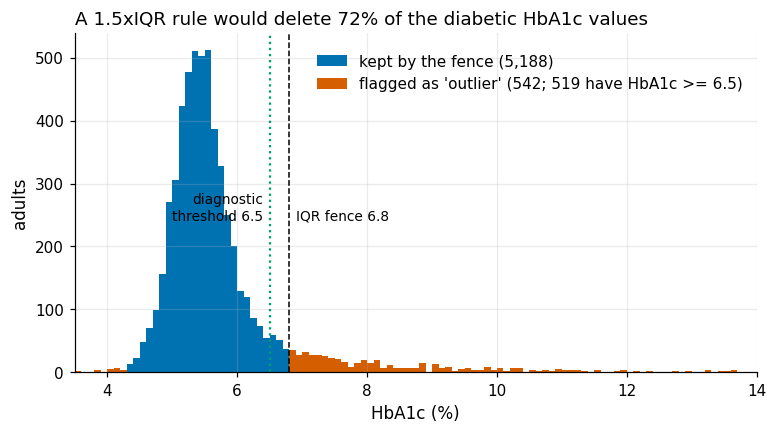

saved figures/S3_iqr_fence_harm.png


In [89]:
# Histogram of HbA1c split by the 1.5 x IQR fence: the flagged tail is the diabetic range.
# Saves figures/S3_iqr_fence_harm.
fig, ax = plt.subplots(figsize=(8, 4))
# 0.1-point bins; kept and flagged values are drawn as separate bars in different colours.
bins = np.arange(3.0, 17.6, 0.1)
ax.hist(a1c[~fl], bins=bins, color=OI["blue"], label=f"kept by the fence ({len(coh) - n_fl:,})")
ax.hist(a1c[fl], bins=bins, color=OI["vermillion"], label=f"flagged as 'outlier' ({n_fl}; {n_fl_pos} have HbA1c >= 6.5)")
# ytop places the annotation labels relative to the tallest bar.
ytop = ax.get_ylim()[1]
ax.axvline(hi_f, color="black", ls="--", lw=1); ax.text(hi_f + 0.1, ytop * 0.45, f"IQR fence {hi_f:.1f}", fontsize=9)
ax.axvline(C.HBA1C_DIABETES, color=OI["green"], ls=":", lw=1.5); ax.text(C.HBA1C_DIABETES - 0.1, ytop * 0.45, "diagnostic\nthreshold 6.5", ha="right", fontsize=9)
ax.set_xlim(3.5, 14); ax.set_xlabel("HbA1c (%)"); ax.set_ylabel("adults")
ax.set_title(f"A 1.5xIQR rule would delete {n_fl_pos / la1c.sum():.0%} of the diabetic HbA1c values", loc="left")
ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.98))
f_iqr = plots.savefig(fig, "S3_iqr_fence_harm",
                      caption=f"HbA1c distribution in the cohort (N = {len(coh):,}). A 1.5xIQR fence (upper bound {hi_f:.1f} %) flags {n_fl} values; "
                              f"{n_fl_pos} of them are at or above the diagnostic threshold of 6.5 %, i.e. {n_fl_pos / la1c.sum():.0%} of the {int(la1c.sum())} HbA1c-defined cases.")
plt.show(); print("saved", f_iqr)

**So what.** The hard limits flag 2 BMI values and the robust z-score 462 HbA1c values (the diabetic tail). The one value flagged by both, a BMI of 74.8, recomputes from measured weight (185.2 kg) and height (157.3 cm) and is kept. Blind deletion would be costly: the HbA1c 1.5 × IQR fence (6.8 %) flags 542 rows, 519 of them with HbA1c ≥ 6.5 % (**72 % of all HbA1c-defined cases**); a joint fence over five predictors deletes 512 rows with a higher positive share (17.2 % vs 12.1 %). **Decision (DR-S3-03):** keep every value; skewness is handled in block B5 (§6.7).

In [90]:
# Store the outlier results in M3.
M3["outliers"] = {"layer_table": outl.set_index("var")[["layer1_outside_limits", "layer2_robust_z_gt_3.5", "both_layers"]].to_dict("index"),
                  "manual_review": review, "manual_review_outcome": REVIEW_OUTCOME,
                  "a1c_iqr_fence_upper": float(hi_f), "a1c_iqr_flagged": n_fl, "a1c_iqr_flagged_positive": n_fl_pos,
                  "a1c_iqr_positive_share": n_fl_pos / int(la1c.sum()),
                  "joint_fence_vars": JOINT, "joint_fence_deleted": int(joint.sum()), "joint_fence_share": float(joint.mean()),
                  "joint_fence_prev_deleted": float(prev_del), "joint_fence_prev_kept": float(prev_keep)}

## 3.9 Data-quality dimension matrix

**Why.** The checks above must add up to a judgement per quality dimension. The matrix uses the six DAMA UK (2013) dimensions (completeness, uniqueness, timeliness, validity, accuracy, consistency) and adds **credibility** from ISO/IEC 25012 (2008) for what the files cannot show internally: low response rates and a self-reported label. Each dimension gets a metric, a threshold, the computed result and a verdict.

In [91]:
# Data-quality dimension matrix: one metric, threshold, result and verdict per dimension.
# Writes results/S3/missingness_by_var.csv and results/S3/quality_matrix.csv.
# Admissible Tier 1 / Tier 2 variables only, i.e. what a model may use.
feat = inc[(inc["admissible"].isin(["T1", "T2"]))]["var"].tolist()
miss_by_var = coh[feat].isna().mean().sort_values(ascending=False)
# Variables missing by design (skip pattern); excluded from the item-missingness check.
structural = {"PAD800": "skip: only if moderate activity > 0", "PAD820": "skip: only if vigorous activity > 0",
              "PAD790U": "skip: unit only if frequency > 0", "PAD810U": "skip: unit only if frequency > 0"}
# mv: missing share per feature; structural_skip labels those missing by design.
mv = miss_by_var.rename("missing_share").to_frame()
mv["structural_skip"] = mv.index.map(structural).fillna("")
mv.to_csv(OUT / "missingness_by_var.csv", lineterminator="\n")
# Item missingness without structural skips; compared with the 40 % scope-revision trigger below.
item_miss = mv[mv["structural_skip"] == ""]["missing_share"]
print("highest feature missingness (cohort):"); display(mv.head(8).round(3))

# validity: values outside the codebook range after per-variable recoding (top codes and special codes allowed)
cbs = io.spec_from_codebooks().set_index(["file", "var"])
viol = 0; checked = 0
for _, r in inc[(inc["dtype"] == "continuous")].iterrows():
    s = mrg[r["var"]].dropna()
    ref = cbs.loc[(r["file"], r["var"])]
    # Allowed non-range values: the top code and the special codes of the codebook ('code=meaning' pairs).
    allowed = set(io._codes(ref["top_code"])) | {io._num(p.split("=")[0]) for p in ref["special_codes"].split("; ") if "=" in p}
    # bad: outside the codebook's valid range and not an allowed top or special code.
    bad = ~(s.between(r["valid_min"], r["valid_max"]) | s.isin(allowed))
    viol += int(bad.sum()); checked += len(s)
print(f"validity: {checked:,} continuous values checked against codebook ranges; outside range: {viol}")
# Guard: no out-of-range values after per-variable recoding.
assert viol == 0

resp_int, resp_mec = 0.346, 0.257   # NCHS cycle overview (not computable from the files)
# One row per dimension; results are computed from the variables above, thresholds are stated in the row.
dq = pd.DataFrame([
    ["Completeness", "max item missingness among T1/T2 features in cohort (excl. structural skips)", "<= 40 % (scope-revision trigger)",
     f"{item_miss.max():.1%} ({item_miss.idxmax()}); HbA1c missing in 4.9 % of examined adults, not MCAR", "pass with flags"],
    ["Uniqueness", "duplicate SEQN per file; files subset of DEMO_L", "0 duplicates",
     f"{int((~uniq['seqn_unique']).sum())} duplicates in 16 files; all subsets", "pass"],
    ["Timeliness", "collection window; drift test", "single documented cycle",
     "Aug 2021 - Aug 2023, one cycle; no drift test possible (no pooling)", "not assessable"],
    ["Validity", "values outside codebook range after per-variable recode; sentinel codes traceable", "0 out of range; 100 % traceable",
     f"{viol} of {checked:,} values out of range; {int(sent['traceable'].sum())}/{len(sent)} sentinel variables traceable; XPT artefact repaired ({n_art:,} cells)", "pass"],
    ["Accuracy", "BMI recomputation; external anchor; label agreement", "|diff| <= 0.1; NCHS Data Brief 516 replication within 0.1 pp (§4.3)",
     f"max BMI diff {bmi_diff.max():.3f}; label accuracy limited: self-report vs HbA1c disagree (§5.1 kappa)", "pass for measures, limited for label"],
    ["Consistency", "SBP > DBP; skip-pattern universes; duplicate weight columns identical", "0 violations",
     f"SBP <= DBP: {int(pp_tab['SBP <= DBP'].sum())}; WHtR > 1: {whtr_gt1} flagged; DIQ050/DIQ070 universes as documented", "pass"],
    ["Credibility (ISO/IEC 25012)", "response rates; label source", "documented, not correctable",
     f"interview response {resp_int:.1%}, examination {resp_mec:.1%}; self-reported diagnosis part of the label", "limited"],
], columns=["dimension", "metric", "threshold", "result", "verdict"])
display(dq)
dq.to_csv(OUT / "quality_matrix.csv", index=False, lineterminator="\n")

highest feature missingness (cohort):


,missing_share,structural_skip
PAD820,0.557,skip: only if vigorous activity > 0
PAD810U,0.556,skip: unit only if frequency > 0
PAD800,0.209,skip: only if moderate activity > 0
PAD790U,0.207,skip: unit only if frequency > 0
INDFMPIR,0.128,
BMXHIP,0.054,
LBXTC,0.047,
LBDHDD,0.047,


validity: 214,422 continuous values checked against codebook ranges; outside range: 0


,dimension,metric,threshold,result,verdict
0,Completeness,max item missingness among T1/T2 features in cohort (excl. structu...,<= 40 % (scope-revision trigger),"12.8% (INDFMPIR); HbA1c missing in 4.9 % of examined adults, not MCAR",pass with flags
1,Uniqueness,duplicate SEQN per file; files subset of DEMO_L,0 duplicates,0 duplicates in 16 files; all subsets,pass
2,Timeliness,collection window; drift test,single documented cycle,"Aug 2021 - Aug 2023, one cycle; no drift test possible (no pooling)",not assessable
3,Validity,values outside codebook range after per-variable recode; sentinel ...,0 out of range; 100 % traceable,"0 of 214,422 values out of range; 25/25 sentinel variables traceab...",pass
4,Accuracy,BMI recomputation; external anchor; label agreement,|diff| <= 0.1; NCHS Data Brief 516 replication within 0.1 pp (§4.3),max BMI diff 0.050; label accuracy limited: self-report vs HbA1c d...,"pass for measures, limited for label"
5,Consistency,SBP > DBP; skip-pattern universes; duplicate weight columns identical,0 violations,SBP <= DBP: 0; WHtR > 1: 4 flagged; DIQ050/DIQ070 universes as doc...,pass
6,Credibility (ISO/IEC 25012),response rates; label source,"documented, not correctable","interview response 34.6%, examination 25.7%; self-reported diagnos...",limited


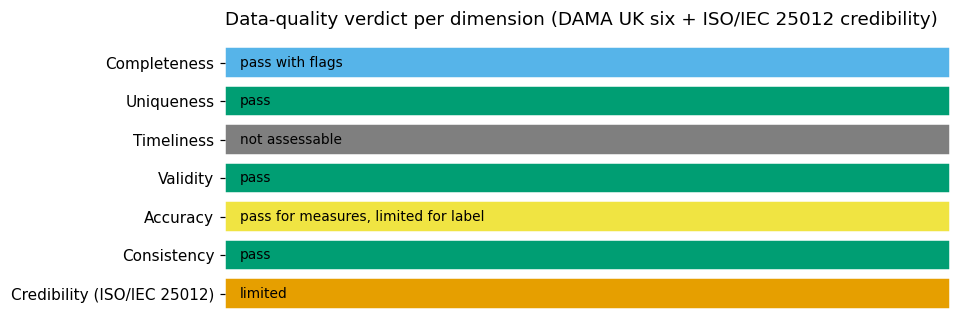

saved figures/S3_quality_matrix.png


In [92]:
# Traffic-light bar per dimension, coloured by verdict (Okabe-Ito palette). Saves figures/S3_quality_matrix.
# Verdict -> severity rank, which selects the colour.
order = {"pass": 0, "pass with flags": 1, "pass for measures, limited for label": 2, "limited": 3, "not assessable": 4}
cmap = {0: OI["green"], 1: OI["sky"], 2: OI["yellow"], 3: OI["orange"], 4: OI["grey"]}
fig, ax = plt.subplots(figsize=(8.5, 3.4))
for i, (dim, ver) in enumerate(zip(dq["dimension"], dq["verdict"])):
    ax.barh(i, 1, color=cmap[order[ver]], edgecolor="white")
    ax.text(0.02, i, ver, va="center", fontsize=9)
ax.set_yticks(range(len(dq)), dq["dimension"]); ax.invert_yaxis(); ax.set_xticks([]); ax.grid(False)
ax.set_xlim(0, 1); ax.set_title("Data-quality verdict per dimension (DAMA UK six + ISO/IEC 25012 credibility)", loc="left")
for s_ in ax.spines.values():
    s_.set_visible(False)
f_dq = plots.savefig(fig, "S3_quality_matrix", caption="Verdict per data-quality dimension; metrics, thresholds and results in results/S3/quality_matrix.csv.")
plt.show(); print("saved", f_dq)

**So what.** With the two read-time problems fixed the measurements are trustworthy (unique keys, codebook ranges, BMI recomputes, coherent BP pairs). The weak points are **credibility** (response 34.6 % / 25.7 %, partly self-reported label), **timeliness** (one cycle) and **completeness** with flags (§3.7); no admissible variable meets the scope-revision trigger. **Decision (DR-S3-07):** `scope-freeze`; credibility and label accuracy go to §5 and §10 as limitations.

In [93]:
# Store the quality-matrix results in M3.
M3["quality_matrix"] = dq.set_index("dimension")[["result", "verdict"]].to_dict("index")
M3["validity"] = {"continuous_values_checked": checked, "out_of_range": viol}
M3["max_item_missing_feature"] = {"var": item_miss.idxmax(), "share": float(item_miss.max())}

## 3.10 Outputs

Decisions of §2–§3 with their evidence (`governance/register/S2.csv`, `S3.csv`; every `evidence_value` is filled from a variable computed in this run) and the stored metrics.

In [94]:
# Write the decision registers governance/register/S2.csv and S3.csv, then save M2 and M3 to results/.
# Every evidence_value is an f-string over variables computed above, so no number is typed by hand.
# Each dict is one register row; write_register fills the missing columns with ''.
reg2 = write_register("S2", [
    dict(dr_id="DR-S2-01", stage="S2", date=TODAY, type="governance", finding="NCHS DUA forbids re-identification, linkage and study of disclosure methods; presentation standards apply to survey estimates",
         evidence_ref="governance/dua_checklist.md", evidence_value="5 obligations mapped; 4 presentation rules (n<30, n_eff<30, CI width>=0.30, df<8)",
         decision="Comply as mapped in the checklist; external validation against published aggregates only; small groups (NH Asian 315) always exploratory",
         alternatives_rejected="External validation by linking other micro-data (forbidden)", status="decided", check_verdict="PASS",
         check_note="Checklist re-read against the DUA page; quasi-identifiers confirmed absent from the loaded columns (minimisation report)"),
    dict(dr_id="DR-S2-02", stage="S2", date=TODAY, type="weights", finding="Each weight belongs to a sub-sample; zero weights mean 'not in sub-sample'",
         evidence_ref="governance/dua_checklist.md, section 3; §3.1",
         evidence_value=f"WTMEC2YR=0: {M3['zero_weights']['WTMEC2YR_0']}; WTPH2YR=0: {M3['zero_weights']['WTPH2YR_0']}; cohort WTPH2YR=0: {zero_in_cohort}",
         decision="WTPH2YR for every cohort analysis with HbA1c or lipids; WTSAF2YR only for DB516/SL5; WTINT2YR/WTMEC2YR for interview/exam-only descriptions; zero weights -> NaN; domains by zero weights, never row deletion",
         alternatives_rejected="WTMEC2YR for HbA1c analyses (ignores blood-sample non-response); unweighted descriptions", status="decided", check_verdict="PASS",
         check_note="Zero-weight counts recomputed; WTMEC2YR=0 equals RIDSTATR=1 (3,073)"),
    dict(dr_id="DR-S2-03", stage="S2", date=TODAY, type="minimisation", finding="16 files contain 175 columns, many not needed for the purpose (child items, quasi-identifiers, duplicates)",
         evidence_ref="results/S2/minimisation_report.csv; results/S2/minimisation_columns.csv",
         evidence_value=f"raw {n_raw}, kept {n_kept}, dropped {n_drop} (each with reason)",
         decision="Loader keeps only spec-included columns; dropped columns listed with reason",
         alternatives_rejected="Load all columns and select later (purpose limitation violated, more disclosure risk)", status="decided", check_verdict="PASS",
         check_note="Report regenerated from the spec in this run; every dropped column has a non-empty reason (assert)"),
    dict(dr_id="DR-S2-04", stage="S2", date=TODAY, type="specification", finding="Sentinel codes differ by variable and continuous measures have none; a single spec avoids drift between code and documentation",
         evidence_ref="config/variable_spec.csv; nhanes_io.verify_spec",
         evidence_value=f"{len(spec)} spec rows; {n_sentinel_vars} included variables with codebook sentinels; verify_spec problems: {len(problems)}",
         decision="variable_spec.csv (15 documented columns) is the single source; sentinel_codes parsed from the CDC codebooks (Refused / Don't know only); roles and admissibility from the S1 availability rule",
         alternatives_rejected="Hand-written sentinel list; global 7/9/77/99 list", status="decided", check_verdict="PASS",
         check_note="verify_spec re-parses all 16 codebooks and the XPT headers in this run: 0 problems"),
    dict(dr_id="DR-S2-05", stage="S2", date=TODAY, type="provenance", finding="Numbers are only reproducible if the raw files are byte-identical to the CDC release",
         evidence_ref="data/nhanes_2021_2023/MANIFEST.sha256; nhanes_io.ensure_raw_data",
         evidence_value=f"{len(integrity['verified'])}/16 hashes verified; funnel {' -> '.join(f'{n:,}' for n in fun['n'])}",
         decision="Verify hashes at the start of every profiling run; datasheet (Gebru) documents composition and preprocessing",
         alternatives_rejected="Trust the download", status="decided", check_verdict="PASS", check_note="Hashes and funnel recomputed in this run"),
    dict(dr_id="DR-S2-06", stage="S2", date=TODAY, type="coding", finding="Borderline diabetes (DIQ010=3) and uncertain pregnancy (RIDEXPRG=3) are legitimate but ambiguous codes",
         evidence_ref="§3.2–§3.3",
         evidence_value=f"DIQ010=3: {int(legit.loc[0, 'cohort'])} in cohort ({int(legit.loc[0, 'file'])} in file); RIDEXPRG=3: {preg3} in cohort",
         decision="Keep both; DIQ010=3 negative in L_self and flagged (S5 sensitivity SL3); RIDEXPRG=3 kept with flag preg_unknown for a sensitivity drop",
         alternatives_rejected="Recode as missing (loses 213 people with elevated risk); drop RIDEXPRG=3", status="decided", check_verdict="PASS",
         check_note="Counts recomputed and asserted (213/284, 21)"),
])
reg3 = write_register("S3", [
    dict(dr_id="DR-S3-01", stage="S3", date=TODAY, type="data_fix", finding="pandas reads stored zeros in XPT files as 5.4e-79; a where()-based repair turns NaN into 0",
         evidence_ref="results/S3/xpt_artefacts.csv; §3.1", evidence_value=f"{n_art:,} cells in {len(files_hit)} files; PAQ NaN {nan_before} kept by mask, {nan_wrong} after where",
         decision="Repair with x.mask((|x|<1e-10) & x.notna(), 0.0) at load (nhanes_io.fix_xpt); zero weights -> NaN before weighting",
         alternatives_rejected="where(); leave artefact", status="decided", check_verdict="PASS",
         check_note="Residual 0<|x|<1e-10 = 0 in all files and NaN counts unchanged (asserts)"),
    dict(dr_id="DR-S3-02", stage="S3", date=TODAY, type="cleaning", finding="Blanket recode of 7/9/77/99/777/999/7777/9999 destroys valid measurements; codebook sentinels only exist for questionnaire items",
         evidence_ref="results/S3/sentinel_audit.csv; results/S3/blanket_damage.csv; figures/S3_blanket_recode_damage.png",
         evidence_value=f"{n_destroyed:,} valid cells destroyed (cohort, 20 continuous vars; full file {n_destroyed_full:,}); A1c positives lost {lost_pos}/{int(a1c_pos.sum())}; L_comb flips {flips}/{int(l_comb.sum())}; questionnaire-only arm {n_q} cells",
         decision="Per-variable sentinel recoding from the codebook (systematic arm); blanket recode only as the naive M0 arm in S6",
         alternatives_rejected="Blanket recode; questionnaire-only blanket (cleans 57 cells, needs the same per-variable knowledge)", status="decided", check_verdict="PASS",
         check_note="1,496 / 29 of 721 / 6 of 971 / 57 recomputed and asserted; every recoded code traceable to codebook counts"),
    dict(dr_id="DR-S3-03", stage="S3", date=TODAY, type="outliers", finding="Extreme HbA1c values are the outcome, not errors",
         evidence_ref="results/S3/outlier_flags.csv; figures/S3_iqr_fence_harm.png",
         evidence_value=f"A1c IQR fence {hi_f:.1f}: {n_fl} flagged, {n_fl_pos} with A1c>=6.5 ({n_fl_pos / la1c.sum():.0%} of positives); joint fence deletes {int(joint.sum())} rows, A1c+ share {prev_del:.1%} vs {prev_keep:.1%}",
         decision="Keep all values; three-layer rule (hard limits flag, robust z flag, manual review); transformation/winsorising only as S6 ablation (B5)",
         alternatives_rejected="1.5xIQR deletion; z-score deletion", status="decided", check_verdict="PASS",
         check_note=f"542/519 and 512 recomputed and asserted; layer-3 review of {review} value: {REVIEW_OUTCOME}"),
    dict(dr_id="DR-S3-04", stage="S3", date=TODAY, type="missingness", finding="HbA1c missingness depends on race, income, age and examination completeness, not on self-reported diabetes",
         evidence_ref="results/S3/missingness_or.csv; figures/S3_missing_hba1c_or.png",
         evidence_value=f"{int(y_miss.sum())}/{len(ex)} missing; LLR p={fit.llr_pvalue:.1e}; AUC {auc_miss:.2f}; NH Black OR {or_tab.loc['NH Black', 'OR']:.2f} ({or_tab.loc['NH Black', 'ci_low']:.2f}, {or_tab.loc['NH Black', 'ci_high']:.2f}); self-report OR {or_tab.loc['self-reported diabetes', 'OR']:.2f}",
         decision="Wording: not MCAR; no evidence against MAR given covariates; MNAR untestable. Complete-case cohort with WTPH2YR (includes blood non-response adjustment); MNAR sensitivity (delta / IPW) in S9",
         alternatives_rejected="Little's MCAR test (normality, only rejects MCAR); multiple imputation of the label", status="decided", check_verdict="PASS",
         check_note="Logit refitted in this run; ORs asserted against the reference values", loop_ref="§9.7 MNAR sensitivity"),
    dict(dr_id="DR-S3-05", stage="S3", date=TODAY, type="top_coding", finding="Age capped at 80 and PIR at 5; PIR also missing",
         evidence_ref="§3.6", evidence_value=f"age_top {age_top}; pir_top {pir_top} ({pir_top / len(coh):.1%}); pir_miss {pir_miss} ({pir_miss / len(coh):.1%}); L_comb 80: {prev_80:.1%} vs 70-79: {prev_7079:.1%}",
         decision="Keep values and carry flags age_top, pir_top, pir_miss; their model value tested in S6 block B4 (P06/P07)",
         alternatives_rejected="Treat caps as exact; drop PIR-missing rows (12.8 %)", status="decided", check_verdict="PASS", check_note="Counts and prevalences recomputed and asserted"),
    dict(dr_id="DR-S3-06", stage="S3", date=TODAY, type="leakage", finding="DIQ050 is asked only of diagnosed people; DIQ070 also of borderline and prediabetic respondents",
         evidence_ref="§3.5", evidence_value=f"DIQ050 universe {univ.loc[0, 'answered']} (all DIQ010=1); DIQ070: 1,081 / 282 / 918; cohort DIQ070=1: {d070}",
         decision="DIQ050/DIQ070 inadmissible as features (spec admissible=N); usable only for the treatment-aware sensitivity label within the documented universe, excluding prediabetes medication",
         alternatives_rejected="Use DIQ070 as a feature (label proxy)", status="decided", check_verdict="PASS", check_note="Universes recomputed from DIQ_L and asserted"),
    dict(dr_id="DR-S3-07", stage="S3", date=TODAY, type="scope", finding="No admissible variable meets the scope-revision trigger; quality is high for measures, limited for credibility and label",
         evidence_ref="results/S3/quality_matrix.csv; figures/S3_quality_matrix.png",
         evidence_value=f"max item missingness {item_miss.max():.1%} ({item_miss.idxmax()}); validity {viol} out-of-range of {checked:,}; response 34.6 % / 25.7 %",
         decision="Freeze variable scope (scope-freeze); carry credibility and label accuracy as limitations to S5/S10",
         alternatives_rejected="Add variables after profiling", status="decided", check_verdict="PASS",
         check_note="Self-check: spec re-verified against all 16 codebooks (verify_spec), sentinel table re-scanned (all traceable)"),
])
display(reg3[["dr_id", "type", "decision", "check_verdict"]])
R.save_section("S2", M2)
R.save_section("S3", M3)
print("saved", R.section_path("S2").name, R.section_path("S3").name, "| register rows:", len(reg2), len(reg3))

,dr_id,type,decision,check_verdict
0,DR-S3-01,data_fix,"Repair with x.mask((|x|<1e-10) & x.notna(), 0.0) at load (nhanes_i...",PASS
1,DR-S3-02,cleaning,Per-variable sentinel recoding from the codebook (systematic arm);...,PASS
2,DR-S3-03,outliers,"Keep all values; three-layer rule (hard limits flag, robust z flag...",PASS
3,DR-S3-04,missingness,Wording: not MCAR; no evidence against MAR given covariates; MNAR ...,PASS
4,DR-S3-05,top_coding,"Keep values and carry flags age_top, pir_top, pir_miss; their mode...",PASS
5,DR-S3-06,leakage,DIQ050/DIQ070 inadmissible as features (spec admissible=N); usable...,PASS
6,DR-S3-07,scope,Freeze variable scope (scope-freeze); carry credibility and label ...,PASS


saved metrics_S2.json metrics_S3.json | register rows: 6 7


**So what.** Six §2 and seven §3 decisions are recorded, all PASS. They feed forward: §6 gets two contrasting cleaning arms (per-variable map vs blanket recode, measured cost 1,496 values), §5 the treatment-item universe and the MAR wording, §9.7 the MNAR sensitivity analysis. The variable scope is frozen.

# §4 Exploratory analysis and analytical fallacies

**Section lead:** C

Three questions are answered before any model is fitted:

1. **Which weight and variance method give trustworthy population numbers?** The survey toolkit
   (`src/survey.py`) is validated against NCHS Data Brief 516 (§4.1–§4.3).
2. **Which descriptive contrasts are artefacts?** Weighting, age standardisation, a systematic
   Simpson scan and a DAG that says what may and may not be adjusted for (§4.4–§4.8).
3. **What does the data structure imply for the algorithm?** Redundancy, skewness, non-linearity
   and interactions, summarised in a "data → algorithm" (DAJ) table that §6–§7 cite (§4.9–§4.13).

All population estimates use the delete-one-PSU jackknife; every proportion carries its domain
degrees of freedom, a Korn–Graubard interval and the NCHS presentation flags.

In [95]:
new_section()

In [96]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

from src import nhanes_io as io, survey as S, labels as L

pd.set_option("display.width", 160, "display.max_columns", 30)
RNG_SEEDS = np.random.SeedSequence(C.SEED_MASTER).spawn(8)   # one child stream per random step
OUT: dict = {}            # every reported number -> results/metrics_S4.json
REG: list[dict] = []      # decision-register rows -> governance/register/S4.csv
S4_DIR = C.RESULTS_DIR / "S4"
S4_DIR.mkdir(parents=True, exist_ok=True)
TODAY = "2026-10-11"


def reg(dr_id, type_, finding, evidence_ref, evidence_value, decision, alternatives_rejected,
        check_verdict="PASS", check_note="", hyp_id="", status="final", loop_ref=""):
    """Append one decision-register row (columns of the project decision register)."""
    REG.append({"dr_id": dr_id, "stage": "S4", "date": TODAY, "type": type_, "finding": finding,
                "evidence_ref": evidence_ref, "evidence_value": evidence_value, "decision": decision,
                "alternatives_rejected": alternatives_rejected, "hyp_id": hyp_id, "status": status,
                "check_verdict": check_verdict, "check_note": check_note, "loop_ref": loop_ref,
                "change_request": "", "commit": ""})


def pct(x, d=1):
    return f"{100 * x:.{d}f}"


def md_table(df: pd.DataFrame) -> str:
    """Minimal Markdown table (no extra dependency)."""
    cols = [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return chr(10).join(lines)


coh = L.add_labels(io.build_cohort())
assert len(coh) == io.COHORT_N == 5730
print(f"cohort: {len(coh):,} adults, L_comb positives {int(coh.L_comb.sum())}")

cohort: 5,730 adults, L_comb positives 971


## 4.1 Survey design and weights map
**Why.** NHANES is a stratified, clustered, unequal-probability sample. Each data component was
collected on a different subsample and carries its own weight; using the wrong weight (or none)
changes the population the numbers describe. The variance must reflect the 15 masked strata ×
2 PSUs, which leaves only **15 design degrees of freedom** however many people are sampled.

In [97]:
# Weights map: which survey weight belongs to which NHANES component, how many cohort rows carry it, and
# the design degrees of freedom. Reads the cohort; writes the weights map files and OUT['design'].
WEIGHTS_MAP = pd.DataFrame([
    ("Interview (questionnaires: DIQ, BPQ, HIQ, HUQ, SMQ, PAQ, INQ)", C.WEIGHT_INTERVIEW, "all interviewed", "interview-only descriptives"),
    ("MEC examination (BMX, BPXO)", C.WEIGHT_MEC, "examined", "exam-only descriptives"),
    ("Phlebotomy analytes (GHB = HbA1c, TCHOL, HDL)", C.WEIGHT_PHLEB, "examined + blood drawn", "**cohort analyses (contain HbA1c)**"),
    ("Fasting analytes (GLU, TRIGLY/LDL)", C.WEIGHT_FASTING, "morning fasting subsample, 8–24 h fast", "**DB516 replication, triglycerides, LDL**"),
], columns=["component", "weight", "subsample", "used here for"])
# Count rows with a positive weight per component (zero weight = not part of that subsample).
WEIGHTS_MAP["positive in cohort"] = [int((coh[w].fillna(0) > 0).sum()) for w in WEIGHTS_MAP.weight]
display(WEIGHTS_MAP)

# Design structure: PSUs nested in strata; design df = #PSU - #strata.
design = coh.groupby(C.STRATA)[C.PSU].nunique()
n_strata, n_psu = design.size, int(design.sum())
DF_DESIGN = S.design_df(coh)
print(f"\nstrata = {n_strata}, PSUs = {n_psu}, design df = #PSU - #strata = {DF_DESIGN}")
# Guard: 15 strata x 2 PSUs = 30 PSUs, hence 15 design df (all full-sample intervals use t with 15 df).
assert (n_strata, n_psu, DF_DESIGN) == (15, 30, 15)
# Fasting weight 0 inside the cohort = fasted outside the 8-24 h window or no specimen.
print(f"fasting rows with WTSAF2YR = 0 (fasted outside 8-24 h or no specimen) inside the cohort: "
      f"{int(((coh.WTSAF2YR == 0)).sum())}")

rule = ("Rule: when variables from several components are combined, use the weight of the smallest "
        "subsample involved (fasting < phlebotomy < MEC < interview).")
md = ["# Weights map (S4)", "", md_table(WEIGHTS_MAP), "", rule, "",
      f"Design: {n_strata} strata x 2 PSUs = {n_psu} PSUs; design df = {DF_DESIGN}. "
      "Variance: delete-one-PSU jackknife (JKn); domains by zeroing weights; domain df = (PSUs containing "
      "the domain) - (strata containing the domain) (NCHS rule); df < 8 flagged for review (NCHS)."]
(S4_DIR / "weights_map.md").write_text("\n".join(md) + "\n", encoding="utf-8")
WEIGHTS_MAP.to_csv(S4_DIR / "weights_map.csv", index=False)
# Store the design facts for the section's results file.
OUT["design"] = {"n_strata": n_strata, "n_psu": n_psu, "df": DF_DESIGN,
                 "n_wtph_pos": int((coh.WTPH2YR > 0).sum()),
                 "n_fasting_pos": int((coh.WTSAF2YR.fillna(0) > 0).sum())}

,component,weight,subsample,used here for,positive in cohort
0,"Interview (questionnaires: DIQ, BPQ, HIQ, HUQ, SMQ, PAQ, INQ)",WTINT2YR,all interviewed,interview-only descriptives,5730
1,"MEC examination (BMX, BPXO)",WTMEC2YR,examined,exam-only descriptives,5730
2,"Phlebotomy analytes (GHB = HbA1c, TCHOL, HDL)",WTPH2YR,examined + blood drawn,**cohort analyses (contain HbA1c)**,5730
3,"Fasting analytes (GLU, TRIGLY/LDL)",WTSAF2YR,"morning fasting subsample, 8–24 h fast","**DB516 replication, triglycerides, LDL**",2938



strata = 15, PSUs = 30, design df = #PSU - #strata = 15
fasting rows with WTSAF2YR = 0 (fasted outside 8-24 h or no specimen) inside the cohort: 299


**So what.** Every cohort row has a positive phlebotomy weight (`WTPH2YR`), the weight for all cohort
descriptives and the weighted ablation arm; `WTSAF2YR` is reserved for fasting glucose, triglycerides
and LDL. Fasting participants outside the 8–24 h window carry `WTSAF2YR = 0` and must be excluded
even though their glucose value is present (§4.10). With 15 design df, every full-sample interval
uses a t-quantile of 2.13, not 1.96.

## 4.2 Variance engine check
**Why.** Every interval in the project rests on the jackknife, so it is checked against Taylor
linearisation, including on small domains (weights zeroed outside the domain; df = PSUs − strata
containing the domain).

In [98]:
# Validate the jackknife variance engine against Taylor linearisation, on the full sample and on domains.
# Asserts SE ratios within 2 %; writes OUT['variance_check'] and the Asian-undiagnosed domain df.
def taylor_se_ratio(df, y, weight, domain=None):
    """Taylor-linearised SE of a weighted domain mean (with-replacement PSU approximation)."""
    yv = df[y].to_numpy(float) if isinstance(y, str) else np.asarray(y, float)
    dm = np.ones(len(df), bool) if domain is None else np.asarray(domain, bool)
    # Domain estimation by weight zeroing: weight 0 outside the domain and where y is missing.
    w = df[weight].fillna(0).to_numpy(float) * dm * ~np.isnan(yv)
    # NaN -> 0 is harmless because those rows already have weight 0.
    y0 = np.nan_to_num(yv)
    p = np.dot(w, y0) / w.sum()
    # Linearised score of the ratio estimator: z_i = w_i (y_i - p) / sum(w).
    z = w * (y0 - p) / w.sum()
    # Sum scores within each PSU first; the variance comes from PSU totals.
    tot = pd.DataFrame({"h": df[C.STRATA].to_numpy(), "i": df[C.PSU].to_numpy(), "z": z}).groupby(["h", "i"]).z.sum()
    var = 0.0
    # With-replacement stratified variance: n_h / (n_h - 1) times the squared PSU deviations in each stratum.
    for _, g in tot.groupby(level=0):
        nh = len(g)
        var += nh / (nh - 1) * ((g - g.mean()) ** 2).sum()
    return p, np.sqrt(var)


# Four checks: the whole cohort, and three domains of decreasing size (the Asian domain has few PSUs).
checks = []
asian = coh.race.eq("NH Asian").to_numpy()
# L_A1c == 1 = HbA1c >= 6.5 %: the denominator of the 'undiagnosed share'.
undx_dom = coh.L_A1c.eq(1).to_numpy()
for name, y, dom in [("L_comb, all adults", "L_comb", None),
                     ("L_comb, NH Asian", "L_comb", asian),
                     ("undiagnosed share, HbA1c>=6.5", "in_escreen", undx_dom),
                     ("undiagnosed share, Asian HbA1c>=6.5", "in_escreen", undx_dom & asian)]:
    # Jackknife estimate with Korn-Graubard (KG) interval and NCHS presentation flags.
    jk = S.weighted_prop(coh, y, weight=C.WEIGHT_PHLEB, domain=dom)
    p_t, se_t = taylor_se_ratio(coh, y, C.WEIGHT_PHLEB, dom)
    checks.append({"estimate": name, "n": jk["n"], "p": jk["est"], "se_jk": jk["se"], "se_taylor": se_t,
                   "ratio": jk["se"] / se_t, "domain_df": jk["df"], "kg_low": jk["kg_low"],
                   "kg_high": jk["kg_high"], "flags": ",".join(jk["nchs_flags"]) or "–", "nchs": jk["nchs_status"]})
checks = pd.DataFrame(checks)
print(checks.round(4).to_string(index=False))
# Guard: jackknife and Taylor SEs may differ by at most 2 %, otherwise the variance engine is wrong.
assert np.allclose(checks.ratio, 1, atol=0.02), "jackknife and Taylor SEs disagree"

# zero-weighting vs dropping rows: identical point estimate, but dropping hides which strata are empty
drop = coh[undx_dom & asian]
print(f"\nAsian undiagnosed domain: {len(drop)} rows in {drop[C.STRATA].nunique()} strata / "
      f"{drop[[C.STRATA, C.PSU]].drop_duplicates().shape[0]} PSUs -> domain df = PSUs - strata = "
      f"{S.domain_df(coh, undx_dom & asian)} (flag df<8: {S.domain_df(coh, undx_dom & asian) < C.NCHS_MIN_DF}); "
      f"a strata-count approximation would give {S.domain_df(coh, undx_dom & asian, method='strata')}")
OUT["variance_check"] = checks.drop(columns=["flags"]).to_dict("records")
OUT["asian_undx_domain_df"] = S.domain_df(coh, undx_dom & asian)

                           estimate    n      p  se_jk  se_taylor  ratio  domain_df  kg_low  kg_high                        flags     nchs
                 L_comb, all adults 5730 0.1404 0.0075     0.0075 1.0004         15  0.1247   0.1572                            –  present
                   L_comb, NH Asian  315 0.1161 0.0174     0.0173 1.0088         14  0.0802   0.1610                            –  present
      undiagnosed share, HbA1c>=6.5  721 0.2162 0.0217     0.0217 1.0001         15  0.1713   0.2666                            –  present
undiagnosed share, Asian HbA1c>=6.5   40 0.3621 0.0932     0.0922 1.0116          4  0.1315   0.6520 n_eff<30,ci_width>=0.30,df<8 suppress

Asian undiagnosed domain: 40 rows in 8 strata / 12 PSUs -> domain df = PSUs - strata = 4 (flag df<8: True); a strata-count approximation would give 8


**So what.** Jackknife and Taylor standard errors agree within 2 % on the full sample and on small
domains, so the jackknife can be trusted where no Taylor formula exists (standardised differences,
κ, AUC). The Asian-undiagnosed domain (40 adults) spans 8 strata but 12 PSUs, so its df is
12 − 8 = 4, below the NCHS minimum of 8: it is flagged and its intervals widen accordingly.

## 4.3 External anchor: NCHS Data Brief 516
**Why.** Only an external anchor detects a wrong *definition* or *weight*: if cohort logic, fasting weight, jackknife,
Korn–Graubard interval and age standardisation are right, we must land on NCHS Data Brief 516 (Gwira et al. 2024).
DB516: adults ≥ 20, non-pregnant, fasting subsample (`WTSAF2YR` > 0); undiagnosed = not diagnosed and (FPG ≥ 126
mg/dL or HbA1c ≥ 6.5 %); age adjustment to the US 2000 standard (20–39 / 40–59 / 60+). Note the fasting weight.

In [99]:
# Replicate NCHS Data Brief 516 (DB516) on the fasting subsample and compare with the published values.
# Asserts identical n and |difference| <= 0.1 pp; writes the replication table and OUT['db516'].
# NCHS Data Brief 516, Tables 1-2 (external reference values, transcribed from
# https://www.cdc.gov/nchs/products/databriefs/db516.htm). Percent (95% CI).
NCHS = pd.DataFrame([
    # measure, group, kind, n, est, lo, hi
    ("total", "All", "crude", 2938, 15.8, 13.6, 18.2), ("total", "All", "age-adj", 2938, 14.3, 12.1, 16.7),
    ("total", "Men", "crude", 1306, 18.0, 15.7, 20.4), ("total", "Men", "age-adj", 1306, 16.6, 14.0, 19.4),
    ("total", "Women", "crude", 1632, 13.7, 11.0, 16.7), ("total", "Women", "age-adj", 1632, 12.2, 9.9, 14.8),
    ("diagnosed", "All", "crude", 2938, 11.3, 9.3, 13.5), ("diagnosed", "All", "age-adj", 2938, 10.1, 8.3, 12.1),
    ("diagnosed", "Men", "crude", 1306, 12.9, 11.0, 15.0), ("diagnosed", "Men", "age-adj", 1306, 11.7, 9.9, 13.7),
    ("diagnosed", "Women", "crude", 1632, 9.7, 7.3, 12.7), ("diagnosed", "Women", "age-adj", 1632, 8.6, 6.7, 10.9),
    ("undiagnosed", "All", "crude", 2938, 4.5, 3.3, 5.9), ("undiagnosed", "All", "age-adj", 2938, 4.2, 2.9, 5.7),
    ("undiagnosed", "Men", "crude", 1306, 5.1, 3.6, 6.9), ("undiagnosed", "Men", "age-adj", 1306, 4.9, 3.3, 6.9),
    ("undiagnosed", "Women", "crude", 1632, 3.9, 2.8, 5.3), ("undiagnosed", "Women", "age-adj", 1632, 3.5, 2.4, 5.1),
    ("total", "20-39", "crude", 688, 3.6, 2.0, 5.9), ("total", "40-59", "crude", 861, 17.7, 14.7, 21.0),
    ("total", "60+", "crude", 1389, 27.3, 23.0, 31.9),
    ("diagnosed", "20-39", "crude", 688, 2.2, 1.1, 4.0), ("diagnosed", "40-59", "crude", 861, 12.1, 10.0, 14.5),
    ("diagnosed", "60+", "crude", 1389, 20.5, 16.2, 25.3),
    ("undiagnosed", "20-39", "crude", 688, 1.3, 0.5, 3.0), ("undiagnosed", "40-59", "crude", 861, 5.6, 3.3, 8.9),
    ("undiagnosed", "60+", "crude", 1389, 6.8, 5.3, 8.5),
], columns=["measure", "group", "kind", "n_nchs", "nchs", "nchs_low", "nchs_high"])

# DB516 population: positive fasting weight and a glucose result.
fast = coh.copy()
fast_dom = (fast[C.WEIGHT_FASTING].fillna(0) > 0) & fast.LBXGLU.notna()
# diagnosed = self-reported diagnosis; undiagnosed = no diagnosis and FPG >= 126 mg/dL or HbA1c >= 6.5 %
# (the cut-offs L.FPG_CUT and L.A1C_CUT); total = either.
fast["diagnosed"] = fast.L_self.astype(float)
fast["undiagnosed"] = ((fast.L_self == 0) & ((fast.LBXGLU >= L.FPG_CUT) | (fast.LBXGH >= L.A1C_CUT))).astype(float)
fast["total"] = ((fast.diagnosed == 1) | (fast.undiagnosed == 1)).astype(float)
fast["All"] = "All"
# Three NCHS age bands, used for the age-specific rows and for age adjustment.
fast["age3"] = S.age_band(fast.RIDAGEYR).to_numpy()
fast["sexg"] = fast.sex.map({"Male": "Men", "Female": "Women"})
# the SL5 label of labels.py is the same NCHS definition - cross-check
assert (L.sensitivity_labels(fast)["SL5"][fast_dom] == fast.loc[fast_dom, "total"]).all()

# Collect our estimates in the layout of the NCHS table: overall and by sex (crude and age-adjusted),
# then by age band (crude).
rows = []
for measure in ["total", "diagnosed", "undiagnosed"]:
    for gcol in ["All", "sexg"]:
        # age_standardise: crude and directly standardised rates with KG and jackknife CIs per group.
        t = S.age_standardise(fast, measure, gcol, weight=C.WEIGHT_FASTING, domain=fast_dom)
        for _, r in t.iterrows():
            rows.append((measure, r.group, "crude", r.n, r.crude, r.crude_kg_low, r.crude_kg_high, r.crude_low, r.crude_high, r.df))
            rows.append((measure, r.group, "age-adj", r.n, r["std"], r.std_kg_low, r.std_kg_high, r.std_low, r.std_high, r.df))
    for band in ["20-39", "40-59", "60+"]:
        r = S.weighted_prop(fast, measure, weight=C.WEIGHT_FASTING, domain=fast_dom & (fast.age3 == band))
        rows.append((measure, band, "crude", r["n"], r["est"], r["kg_low"], r["kg_high"], r["ci_low"], r["ci_high"], r["df"]))
ours = pd.DataFrame(rows, columns=["measure", "group", "kind", "n", "est", "kg_low", "kg_high", "jk_low", "jk_high", "df"])
# Percent scale, as in the published table.
ours[["est", "kg_low", "kg_high", "jk_low", "jk_high"]] *= 100
# Left join keeps every published estimate; a missing replication would show as NaN and fail the asserts.
DB516 = NCHS.merge(ours, on=["measure", "group", "kind"], how="left")
DB516["diff_pp"] = DB516.est - DB516.nchs
# ci_overlap: our KG interval overlaps the published CI. kg_matches: bounds agree to the published 0.1 pp.
DB516["ci_overlap"] = (DB516.kg_low <= DB516.nchs_high) & (DB516.kg_high >= DB516.nchs_low)
DB516["kg_matches_nchs_ci"] = ((DB516.kg_low.round(1) - DB516.nchs_low).abs() <= 0.1) & \
                              ((DB516.kg_high.round(1) - DB516.nchs_high).abs() <= 0.1)
DB516.to_csv(S4_DIR / "db516_replication.csv", index=False)
print(DB516[["measure", "group", "kind", "n", "n_nchs", "est", "kg_low", "kg_high", "nchs", "nchs_low",
             "nchs_high", "diff_pp"]].round(2).to_string(index=False))

# Guard: same sample sizes as NCHS, so population definition and weights match.
assert (DB516.n == DB516.n_nchs).all(), "sample sizes differ from NCHS"
# Guard: every estimate within 0.1 pp (published precision, plus float tolerance) and every CI overlaps.
assert DB516.diff_pp.abs().max() <= 0.1 + 1e-9 and DB516.ci_overlap.all()
# Headline rows (all adults) used in the summary lines and in the stored results.
head = DB516.query("group == 'All'").set_index(["measure", "kind"])
print(f"\nheadline: total {head.loc[('total','crude'),'est']:.2f}% "
      f"(JK t15 {head.loc[('total','crude'),'jk_low']:.2f}, {head.loc[('total','crude'),'jk_high']:.2f}; "
      f"KG {head.loc[('total','crude'),'kg_low']:.2f}, {head.loc[('total','crude'),'kg_high']:.2f}); "
      f"diagnosed {head.loc[('diagnosed','crude'),'est']:.2f}; undiagnosed {head.loc[('undiagnosed','crude'),'est']:.2f}; "
      f"age-adjusted {head.loc[('total','age-adj'),'est']:.2f}/{head.loc[('diagnosed','age-adj'),'est']:.2f}/"
      f"{head.loc[('undiagnosed','age-adj'),'est']:.2f}")
print(f"max |diff| over {len(DB516)} published estimates = {DB516.diff_pp.abs().max():.3f} pp; "
      f"KG interval equals the published CI (to 0.1 pp) in {int(DB516.kg_matches_nchs_ci.sum())}/{len(DB516)} rows")

    measure group    kind    n  n_nchs   est  kg_low  kg_high  nchs  nchs_low  nchs_high  diff_pp
      total   All   crude 2938    2938 15.79   13.59    18.19  15.8      13.6       18.2    -0.01
      total   All age-adj 2938    2938 14.31   12.21    16.62  14.3      12.1       16.7     0.01
      total   Men   crude 1306    1306 17.97   15.69    20.43  18.0      15.7       20.4    -0.03
      total   Men age-adj 1306    1306 16.57   14.05    19.34  16.6      14.0       19.4    -0.03
      total Women   crude 1632    1632 13.66   10.99    16.69  13.7      11.0       16.7    -0.04
      total Women age-adj 1632    1632 12.16    9.95    14.67  12.2       9.9       14.8    -0.04
  diagnosed   All   crude 2938    2938 11.30    9.31    13.55  11.3       9.3       13.5    -0.00
  diagnosed   All age-adj 2938    2938 10.13    8.42    12.05  10.1       8.3       12.1     0.03
  diagnosed   Men   crude 1306    1306 12.90   10.98    15.02  12.9      11.0       15.0     0.00
  diagnosed   Men ag

A slightly different denominator is easy to get wrong: keeping the two fasting adults who have no
HbA1c result (and counting them as non-diabetic) gives *n* = 2,940 instead of NCHS's 2,938. The
next cell computes that variant so the size of this definitional choice (about 0.01 pp) is visible.

In [100]:
# Definitional variant: keep adults without an HbA1c result (treated as not diabetic) to show how much
# a looser denominator moves the DB516 numbers. Reads the merged files; writes OUT['db516']['variant'].
full = io.zero_weights_to_nan(io.load_merged())
# Adults at or above the minimum age, not pregnant, in the fasting subsample; no HbA1c requirement.
v_dom = (full.RIDAGEYR >= C.ADULT_MIN_AGE) & (full.RIDEXPRG != 1) & (full[C.WEIGHT_FASTING].fillna(0) > 0)
dx = full.DIQ010.eq(1)
# A missing HbA1c does not count as high, which is what lets these adults enter as non-diabetic.
und = ~dx & (full.LBXGLU.ge(L.FPG_CUT) | full.LBXGH.ge(L.A1C_CUT))
variant = {}
for nm, y in [("total", dx | und), ("diagnosed", dx), ("undiagnosed", und)]:
    r = S.weighted_prop(full, y.astype(float), weight=C.WEIGHT_FASTING, domain=v_dom)
    variant[nm] = {"n": r["n"], "est": 100 * r["est"], "jk_low": 100 * r["ci_low"], "jk_high": 100 * r["ci_high"]}
print(pd.DataFrame(variant).T.round(2))
print("rows in the 2,940 variant without HbA1c:", int((v_dom & full.LBXGH.isna()).sum()))

OUT["db516"] = {"n": int(head.loc[("total", "crude"), "n"]),
                "total": head.loc[("total", "crude"), "est"], "total_jk_ci": [head.loc[("total", "crude"), "jk_low"], head.loc[("total", "crude"), "jk_high"]],
                "total_kg_ci": [head.loc[("total", "crude"), "kg_low"], head.loc[("total", "crude"), "kg_high"]],
                "diagnosed": head.loc[("diagnosed", "crude"), "est"], "undiagnosed": head.loc[("undiagnosed", "crude"), "est"],
                "age_adj": [head.loc[(m, "age-adj"), "est"] for m in ["total", "diagnosed", "undiagnosed"]],
                "max_abs_diff_pp": DB516.diff_pp.abs().max(), "n_estimates": len(DB516),
                "kg_matches_published_ci": int(DB516.kg_matches_nchs_ci.sum()),
                "variant_n2940": variant}

                  n    est  jk_low  jk_high
total        2940.0  15.78   13.53    18.03
diagnosed    2940.0  11.29    9.23    13.36
undiagnosed  2940.0   4.48    3.26     5.71
rows in the 2,940 variant without HbA1c: 2


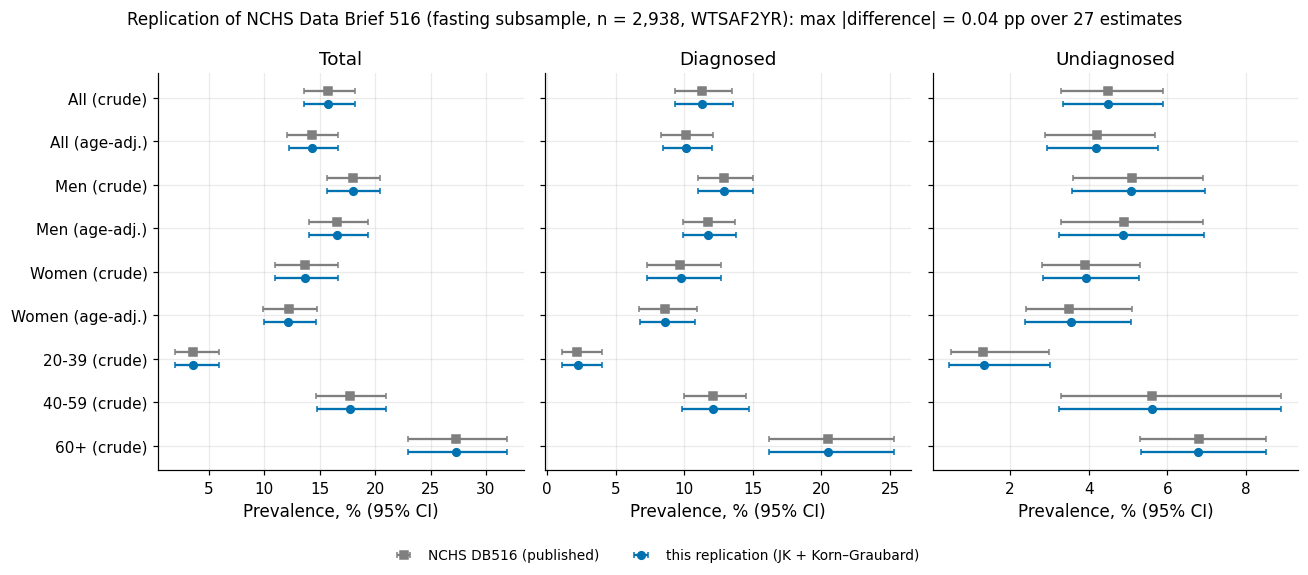

In [101]:
# Forest plot of published DB516 values vs our replication (KG intervals), then two register rows.
fig, axes = plt.subplots(1, 3, figsize=(12, 5.2), sharey=True)
for ax, measure in zip(axes, ["total", "diagnosed", "undiagnosed"]):
    d = DB516[DB516.measure == measure].reset_index(drop=True)
    labels_ = [f"{g} ({'age-adj.' if k == 'age-adj' else 'crude'})" for g, k in zip(d.group, d.kind)]
    # y positions run downwards so the first group is plotted at the top.
    yy = np.arange(len(d))[::-1]
    # Small vertical offsets (+/-0.15) separate the published and replicated markers of the same row.
    ax.errorbar(d.nchs, yy + 0.15, xerr=[d.nchs - d.nchs_low, d.nchs_high - d.nchs], fmt="s", ms=5,
                color=C.OKABE_ITO["grey"], capsize=2, label="NCHS DB516 (published)")
    ax.errorbar(d.est, yy - 0.15, xerr=[d.est - d.kg_low, d.kg_high - d.est], fmt="o", ms=5,
                color=C.OKABE_ITO["blue"], capsize=2, label="this replication (JK + Korn–Graubard)")
    ax.set_yticks(yy, labels_)
    ax.set_title(measure.capitalize())
    ax.set_xlabel("Prevalence, % (95% CI)")
# One shared legend for the three panels.
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=2, fontsize=9)
fig.suptitle(f"Replication of NCHS Data Brief 516 (fasting subsample, n = 2,938, WTSAF2YR): "
             f"max |difference| = {DB516.diff_pp.abs().max():.2f} pp over {len(DB516)} estimates", fontsize=11)
# rect leaves room at the bottom for the shared legend.
fig.tight_layout(rect=(0, 0.06, 1, 1))
plots.savefig(fig, "S4_db516_forest",
              caption="Our design-based estimates (blue, Korn-Graubard 95% CI) against the published NCHS "
                      "Data Brief 516 values (grey) for total, diagnosed and undiagnosed diabetes, crude and "
                      "age-adjusted, overall, by sex and by age group.")
plt.show()

reg("DR-S4-01", "method", "NHANES 2021-23 has 15 strata x 2 PSUs (df = 15); every cohort row has WTPH2YR > 0; "
    "jackknife SE agrees with Taylor linearisation (ratio within 2%).",
    "results/S4/weights_map.md; §4.2", f"df = {DF_DESIGN}; JK/Taylor SE ratio {checks.ratio.min():.3f}-{checks.ratio.max():.3f}",
    "WTPH2YR for all cohort analyses and the weighted ablation; WTSAF2YR for fasting analytes and DB516; "
    "delete-one-PSU jackknife with NCHS domain df (PSUs - strata containing the domain); NCHS flags (n, n_eff < 30, "
    "KG width >= 0.30, df < 8).",
    "Unweighted analysis (describes the sample, not the population); WTMEC2YR for HbA1c (ignores blood-draw "
    "non-response); Taylor-only variance (no formula for kappa/AUC/standardised differences).",
    check_note="re-computed in §4.2")
reg("DR-S4-02", "validation", "Survey toolkit reproduces NCHS Data Brief 516 on the fasting subsample.",
    "results/S4/db516_replication.csv; figures/S4_db516_forest.png",
    f"total {head.loc[('total','crude'),'est']:.2f}% vs 15.8; diagnosed {head.loc[('diagnosed','crude'),'est']:.2f} vs 11.3; "
    f"undiagnosed {head.loc[('undiagnosed','crude'),'est']:.2f} vs 4.5; max |diff| {DB516.diff_pp.abs().max():.2f} pp over {len(DB516)} estimates",
    "Use src/survey.py (JK + KG + 3-band US 2000 standardisation) for every population number in S4-S9.",
    "Accept the toolkit on internal checks only (cannot detect wrong definitions or weights).",
    check_note="n = 2,938 equals NCHS; an n = 2,940 variant keeping 2 adults without HbA1c gives 15.78 / 11.29 / 4.48")

**So what.** All 27 published DB516 estimates (overall, by sex, by age; crude and age-adjusted) are
reproduced within 0.1 pp with NCHS's exact sample size of 2,938, and our Korn–Graubard intervals
coincide with the published asymmetric ones, so the cohort filter, fasting weight, jackknife and
standardisation are right. This is the external anchor for every weighted number that follows.

## 4.4 Weighted vs unweighted prevalence
**Why.** The cohort's raw share of `L_comb` positives describes the *sample*, which over-represents
older adults. Because NCHS used a different definition (fasting glucose as well), our cohort number
is also not expected to equal DB516's 15.8 %. Both gaps need to be explained, not ignored.

In [102]:
# Weighted vs unweighted prevalence of L_comb and how much of the gap the age structure explains.
# Asserts the frozen prevalence and Kish values; writes OUT['prevalence'].
w_ph = coh[C.WEIGHT_PHLEB].to_numpy(float)
unw = coh.L_comb.mean()
wp = S.weighted_prop(coh, "L_comb", weight=C.WEIGHT_PHLEB)
# Kish design effect from unequal weights only (1 + CV^2 of the weights); clustering is added in wp['deff'].
kish = S.kish_deff(w_ph)
coh["age3"] = S.age_band(coh.RIDAGEYR).to_numpy()
bands = list(S.US2000_3BAND)
# Sample share per age band vs weighted (population) share = weight in band / total weight.
share_s = coh.age3.value_counts(normalize=True).reindex(bands)
share_w = pd.Series({b: w_ph[coh.age3 == b].sum() / w_ph.sum() for b in bands})
rate_unw = coh.groupby("age3").L_comb.mean().reindex(bands)
rate_w = {b: S.weighted_prop(coh, "L_comb", weight=C.WEIGHT_PHLEB, domain=coh.age3 == b) for b in bands}
# Counterfactual: sample age-specific rates combined with the population age mix.
unw_age_reweighted = float((rate_unw * share_w).sum())     # sample rates, population age mix
# Fraction of the unweighted-weighted gap that re-weighting the age mix alone reproduces.
explained = (unw - unw_age_reweighted) / (unw - wp["est"])
AGE_TAB = pd.DataFrame({"sample share": share_s, "weighted share": share_w, "unweighted rate": rate_unw,
                        "weighted rate": [rate_w[b]["est"] for b in bands],
                        "kg_low": [rate_w[b]["kg_low"] for b in bands], "kg_high": [rate_w[b]["kg_high"] for b in bands]})
print((AGE_TAB * 100).round(1))
print(f"\nL_comb unweighted {pct(unw, 2)}% vs WTPH2YR-weighted {pct(wp['est'], 2)}% "
      f"(JK {pct(wp['ci_low'])}-{pct(wp['ci_high'])}, KG {pct(wp['kg_low'])}-{pct(wp['kg_high'])}, df {wp['df']})")
print(f"sample rates re-weighted to the population age mix: {pct(unw_age_reweighted, 2)}% -> age structure explains "
      f"{100 * explained:.0f}% of the {100 * (unw - wp['est']):.2f} pp gap")
print(f"Kish deff (unequal weights) = {kish:.3f}; Kish n_eff = {S.kish_neff(w_ph):,.0f}; "
      f"full design effect for L_comb = {wp['deff']:.2f}")
# Guard: frozen prevalence (to 0.05 pp) and Kish deff (to 0.01); drift means cohort or weights changed.
assert abs(unw - 0.1695) < 5e-4 and abs(wp["est"] - 0.140) < 5e-4 and abs(kish - 1.55) < 0.01
OUT["prevalence"] = {"unweighted": unw, "weighted": wp["est"], "weighted_jk_ci": [wp["ci_low"], wp["ci_high"]],
                     "weighted_kg_ci": [wp["kg_low"], wp["kg_high"]], "kish_deff": kish, "design_deff": wp["deff"],
                     "share_60plus_sample": share_s["60+"], "share_60plus_weighted": share_w["60+"],
                     "share_20_39_sample": share_s["20-39"], "share_20_39_weighted": share_w["20-39"],
                     "unweighted_age_reweighted": unw_age_reweighted, "gap_explained_by_age": explained}

       sample share  weighted share  unweighted rate  weighted rate  kg_low  kg_high
20-39          24.7            34.8              3.7            3.5     2.6      4.8
40-59          29.2            33.8             16.6           15.3    13.4     17.5
60+            46.2            31.4             24.3           24.3    21.2     27.6

L_comb unweighted 16.95% vs WTPH2YR-weighted 14.04% (JK 12.4-15.6, KG 12.5-15.7, df 15)
sample rates re-weighted to the population age mix: 14.50% -> age structure explains 84% of the 2.91 pp gap
Kish deff (unequal weights) = 1.546; Kish n_eff = 3,707; full design effect for L_comb = 2.67


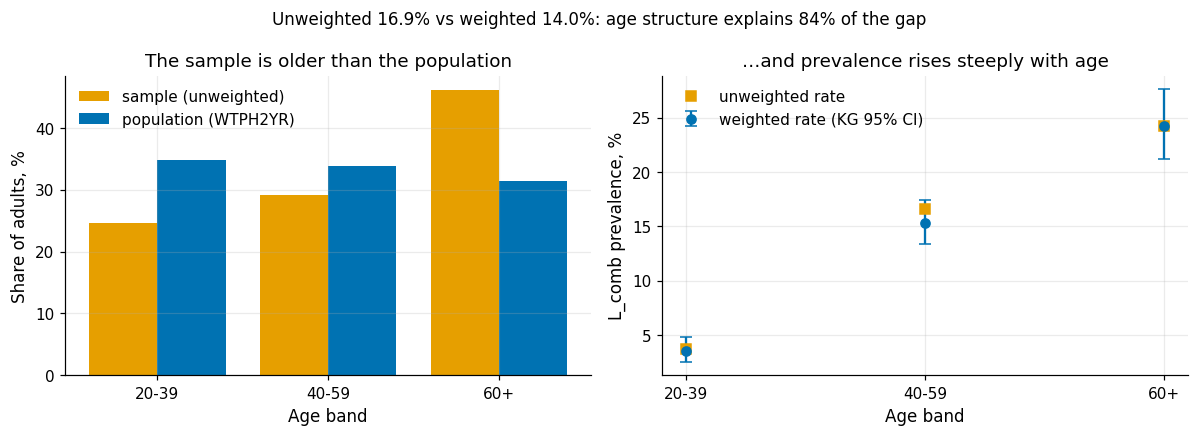

In [103]:
# Two panels: age mix of sample vs population (left) and weighted vs unweighted prevalence by age band
# (right). Reads AGE_TAB from the previous cell; only plots.
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(3)
# Side-by-side bars: offsets of -/+0.2 with width 0.4.
a1.bar(x - 0.2, share_s * 100, 0.4, label="sample (unweighted)", color=C.OKABE_ITO["orange"])
a1.bar(x + 0.2, share_w * 100, 0.4, label="population (WTPH2YR)", color=C.OKABE_ITO["blue"])
a1.set_xticks(x, bands); a1.set_ylabel("Share of adults, %"); a1.set_xlabel("Age band")
a1.set_title("The sample is older than the population"); a1.legend()
yr = AGE_TAB["weighted rate"] * 100
# Asymmetric error bars from the KG interval bounds.
a2.errorbar(x, yr, yerr=[yr - AGE_TAB.kg_low * 100, AGE_TAB.kg_high * 100 - yr], fmt="o", capsize=4,
            color=C.OKABE_ITO["blue"], label="weighted rate (KG 95% CI)")
a2.plot(x, AGE_TAB["unweighted rate"] * 100, "s", color=C.OKABE_ITO["orange"], label="unweighted rate")
a2.set_xticks(x, bands); a2.set_ylabel("L_comb prevalence, %"); a2.set_xlabel("Age band")
a2.set_title("…and prevalence rises steeply with age"); a2.legend()
fig.suptitle(f"Unweighted {pct(unw)}% vs weighted {pct(wp['est'])}%: age structure explains "
             f"{100 * explained:.0f}% of the gap", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S4_age_structure",
              caption="Left: age distribution of the cohort vs the weighted population. Right: L_comb prevalence "
                      "by age band (weighted with Korn-Graubard CI, and unweighted).")
plt.show()

**So what.** The unweighted 16.95 % overstates the weighted 14.0 % (12.4–15.6) because the sample is older (§1.10);
re-weighting age-specific rates to the population age mix closes most of the gap. The rest of the distance to DB516's
15.8 % is definitional (no fasting-glucose criterion, §9.8.2). The design effect (Kish 1.55, §1.10) motivates the
weighted ablation arm (B6b).

## 4.5 Age standardisation
**Why.** Groups with different age structures cannot be compared on crude prevalence, because age
is the strongest determinant of diabetes. Direct standardisation applies each group's age-specific
rates to one common age distribution. We use the US 2000 standard population in the three NCHS
bands; the band weights are derived here from the 5-year "standard million" (Klein & Schoenborn
2001) rather than taken on trust, and a 6-band standard and an internal (cohort) standard are
sensitivity analyses.

In [104]:
# Derive the 3-band and 6-band US 2000 standards from the 5-year standard million, then build the age-
# standardised prevalence table by group with NCHS flags. Asserts agreement with survey.US2000_3BAND.
# US 2000 standard population per million, 5-year groups from age 20 (Klein & Schoenborn 2001, Table 2)
US2000_5Y = {"20-24": 66478, "25-29": 64529, "30-34": 71044, "35-39": 80762, "40-44": 81851, "45-49": 72118,
             "50-54": 62716, "55-59": 48454, "60-64": 38793, "65-69": 34264, "70-74": 31773, "75-79": 26999,
             "80-84": 17842, "85+": 15508}
# Lower age bound of each 5-year group, e.g. '85+' -> 85.
lo_of = {k: int(k.rstrip("+").split("-")[0]) for k in US2000_5Y}
# Collapse the 5-year standard into coarser bands and renormalise so the weights sum to 1.
def collapse(cuts):
    out = {}
    for lab, (lo, hi) in cuts.items():
        # A 5-year group belongs to a band when its lower bound falls inside the band.
        out[lab] = sum(v for k, v in US2000_5Y.items() if lo <= lo_of[k] <= hi)
    tot = sum(out.values())
    return {k: v / tot for k, v in out.items()}
# Primary three-band standard (as used by NCHS) and a six-band sensitivity standard.
STD3 = collapse({"20-39": (20, 39), "40-59": (40, 59), "60+": (60, 200)})
STD6 = collapse({"20-29": (20, 29), "30-39": (30, 39), "40-49": (40, 49), "50-59": (50, 59), "60-69": (60, 69), "70+": (70, 200)})
print("3-band weights derived:", {k: round(v, 4) for k, v in STD3.items()}, "| survey.US2000_3BAND:", S.US2000_3BAND)
# Guard: derived weights equal the constants stored in survey.py (to 1e-4).
assert all(abs(STD3[k] - S.US2000_3BAND[k]) < 1e-4 for k in STD3)
STD_INT = {b: float(share_w[b]) for b in bands}            # internal standard: the weighted cohort itself
print("6-band weights:", {k: round(v, 4) for k, v in STD6.items()})

# Grouping variables for the standardised tables: insurance, and usual place of care (codes 1 and 3 both
# mean the person has a usual place).
coh["insurance"] = coh.HIQ011.map({1: "insured", 2: "uninsured"})
coh["usual_care"] = coh.HUQ030.map({1: "has usual place", 3: "has usual place", 2: "no usual place"})
std_tabs = []
for gcol in ["race", "sex", "insurance", "usual_care"]:
    t = S.age_standardise(coh, "L_comb", gcol, weight=C.WEIGHT_PHLEB)
    t.insert(0, "grouping", gcol)
    std_tabs.append(t)
STD_TAB = pd.concat(std_tabs, ignore_index=True)
STD_TAB["kg_width"] = STD_TAB.crude_kg_high - STD_TAB.crude_kg_low
# NCHS presentation flags per row (small n, small effective n, wide KG interval, low df, few events).
_fl = [S.nchs_flags(r.n, S._design_neff(r.crude, r.crude_se, r.n), r.kg_width, r.df, p=r.crude, n_events=r.n_events)
       for r in STD_TAB.itertuples()]
STD_TAB["nchs_flags"] = [",".join(f) for f in _fl]
STD_TAB["nchs_status"] = [S.nchs_status(f) for f in _fl]
STD_TAB.to_csv(S4_DIR / "std_prev_table.csv", index=False)
show = STD_TAB[["grouping", "group", "n", "df", "crude", "crude_kg_low", "crude_kg_high", "std", "std_low", "std_high", "nchs_status"]].copy()
# Percent scale for display only.
show[["crude", "crude_kg_low", "crude_kg_high", "std", "std_low", "std_high"]] *= 100
print(show.round(1).to_string(index=False))

3-band weights derived: {'20-39': 0.3966, '40-59': 0.3718, '60+': 0.2316} | survey.US2000_3BAND: {'20-39': 0.3966, '40-59': 0.3718, '60+': 0.2316}
6-band weights: {'20-29': 0.1837, '30-39': 0.2129, '40-49': 0.2159, '50-59': 0.1559, '60-69': 0.1024, '70+': 0.1292}


  grouping            group    n  df  crude  crude_kg_low  crude_kg_high  std  std_low  std_high nchs_status
      race Mexican American  386  14   16.9          11.1           24.1 19.6     14.6      24.6     present
      race         NH Asian  315  14   11.6           8.0           16.1 12.5      8.2      16.7     present
      race         NH Black  676  15   22.0          18.6           25.8 21.5     18.0      25.1     present
      race         NH White 3408  15   12.4          10.5           14.5 10.3      8.7      12.0     present
      race   Other Hispanic  582  15   12.8           7.8           19.4 13.5      9.5      17.6     present
      race      Other/Multi  363  15   16.6          12.6           21.2 16.0     12.1      19.8     present
       sex           Female 3144  15   13.1          10.6           15.8 11.6      9.6      13.7     present
       sex             Male 2586  15   15.0          13.5           16.7 13.9     12.4      15.5     present
 insurance         

In [105]:
# Age-standardised differences with CIs for the planned contrasts under three standards (US 2000 3-band,
# 6-band and internal). Asserts the frozen Asian-White and insured-uninsured results; fills OUT.
CONTRASTS = [("race", "NH Asian", "NH White"), ("race", "NH Black", "NH White"),
             ("race", "Mexican American", "NH White"), ("insurance", "insured", "uninsured"),
             ("usual_care", "has usual place", "no usual place")]
diffs = []
for gcol, a, b in CONTRASTS:
    for sname, std in [("US2000 3-band", STD3), ("US2000 6-band", STD6), ("internal 3-band", STD_INT)]:
        # std_difference: crude and standardised difference of group a minus group b with a jackknife CI.
        d = S.std_difference(coh, "L_comb", gcol, a, b, weight=C.WEIGHT_PHLEB, std=std)
        diffs.append({"contrast": f"{a} − {b}", "standard": sname, "n_a": d["n_a"], "n_b": d["n_b"], "df": d["df"],
                      "crude": 100 * d["crude_diff"], "crude_low": 100 * d["crude_low"], "crude_high": 100 * d["crude_high"],
                      "std": 100 * d["std_diff"], "std_low": 100 * d["std_low"], "std_high": 100 * d["std_high"]})
DIFFS = pd.DataFrame(diffs)
DIFFS.to_csv(S4_DIR / "std_differences.csv", index=False)
print(DIFFS.round(1).to_string(index=False))

# The two headline contrasts under the primary (US 2000 3-band) standard.
aw = DIFFS.query("contrast == 'NH Asian − NH White' and standard == 'US2000 3-band'").iloc[0]
iu = DIFFS.query("contrast == 'insured − uninsured' and standard == 'US2000 3-band'").iloc[0]
# Guard: frozen crude and standardised Asian-White estimates and CI bounds (to 0.1 pp).
assert abs(aw.crude - (-0.8)) < 0.1 and abs(aw["std"] - 2.1) < 0.1 and abs(aw.crude_low + 5.1) < 0.1 and abs(aw.std_high - 6.8) < 0.1
# Guard: the same for insured minus uninsured.
assert abs(iu.crude - 5.3) < 0.1 and abs(iu["std"] - 0.7) < 0.1 and abs(iu.crude_low - 1.8) < 0.1 and abs(iu.std_high - 3.9) < 0.1
asian_std = STD_TAB.query("group == 'NH Asian'").iloc[0]; white_std = STD_TAB.query("group == 'NH White'").iloc[0]
print(f"\nNH Asian vs NH White: crude {aw.crude:+.1f} ({aw.crude_low:.1f}, {aw.crude_high:.1f}) -> "
      f"standardised {aw['std']:+.1f} ({aw.std_low:.1f}, {aw.std_high:.1f}) pp")
print(f"standardised rates {pct(asian_std['std'])}% vs {pct(white_std['std'])}% "
      f"(an earlier pilot estimate of 18.0% vs 13.6% is not reproducible)")
OUT["standardisation"] = {
    "std3": STD3, "std6": STD6,
    "asian_white": {"crude": aw.crude, "crude_ci": [aw.crude_low, aw.crude_high], "std": aw["std"], "std_ci": [aw.std_low, aw.std_high],
                    "std_rate_asian": 100 * asian_std["std"], "std_rate_white": 100 * white_std["std"],
                    "std6": DIFFS.query("contrast == 'NH Asian − NH White' and standard == 'US2000 6-band'")["std"].item(),
                    "internal": DIFFS.query("contrast == 'NH Asian − NH White' and standard == 'internal 3-band'")["std"].item()},
    "insured_uninsured": {"crude": iu.crude, "crude_ci": [iu.crude_low, iu.crude_high], "std": iu["std"], "std_ci": [iu.std_low, iu.std_high]}}

                        contrast        standard  n_a  n_b  df  crude  crude_low  crude_high  std  std_low  std_high
             NH Asian − NH White   US2000 3-band  315 3408  15   -0.8       -5.1         3.5  2.1     -2.6       6.8
             NH Asian − NH White   US2000 6-band  315 3408  15   -0.8       -5.1         3.5  2.3     -2.2       6.9
             NH Asian − NH White internal 3-band  315 3408  15   -0.8       -5.1         3.5  2.9     -1.7       7.5
             NH Black − NH White   US2000 3-band  676 3408  15    9.6        5.2        14.0 11.2      7.1      15.3
             NH Black − NH White   US2000 6-band  676 3408  15    9.6        5.2        14.0 10.8      6.3      15.2
             NH Black − NH White internal 3-band  676 3408  15    9.6        5.2        14.0 11.4      6.9      15.9
     Mexican American − NH White   US2000 3-band  386 3408  15    4.5       -2.4        11.3  9.3      3.6      15.0
     Mexican American − NH White   US2000 6-band  386 3408  15  

**So what.** The band weights match the published standard (0.3966 / 0.3718 / 0.2316). NH Asian adults have a slightly
*lower* crude prevalence than NH White adults (−0.8 pp, −5.1 to 3.5) but, being younger, a *higher* standardised one
(+2.1 pp, −2.6 to 6.8); both intervals include zero: "direction changes after standardisation, magnitude unknown". An
earlier pilot estimate (18.0 % vs 13.6 %) cannot be reproduced and is withdrawn.

## 4.6 Insurance: attenuation, not reversal
**Why.** Insured adults show a clearly higher crude prevalence than uninsured adults. Before
reading this as a health-care effect we need to know how much of it is age: almost everyone
aged 65+ has Medicare, so insurance is a strong marker of age (Age → Medicare → Insurance), and
age drives diabetes.

In [106]:
# Insurance as a marker of age: age mix by insurance status and age-specific insured-uninsured differences.
# Reads w_ph and iu from earlier cells; extends OUT['standardisation'].
ins_age = (pd.crosstab(coh.insurance, coh.age3, values=w_ph, aggfunc="sum", normalize="index") * 100).reindex(columns=bands)
print("weighted age mix by insurance status (%):\n", ins_age.round(1))
band_diff = []
# Within one age band (a domain) the insurance gap is no longer confounded by age.
for b in bands:
    d = S.std_difference(coh, "L_comb", "insurance", "insured", "uninsured", weight=C.WEIGHT_PHLEB,
                         domain=coh.age3 == b)
    band_diff.append({"age band": b, "n_insured": d["n_a"], "n_uninsured": d["n_b"],
                      "diff_pp": 100 * d["crude_diff"], "low": 100 * d["crude_low"], "high": 100 * d["crude_high"]})
band_diff = pd.DataFrame(band_diff)
print("\nage-specific insured − uninsured differences (pp):\n", band_diff.round(1).to_string(index=False))
print(f"\ninsured − uninsured: crude {iu.crude:+.1f} ({iu.crude_low:.1f}, {iu.crude_high:.1f}) -> "
      f"age-standardised {iu['std']:+.1f} ({iu.std_low:.1f}, {iu.std_high:.1f}) pp; "
      f"{100 * (1 - iu['std'] / iu.crude):.0f}% attenuation, same sign")
OUT["standardisation"]["insured_uninsured"].update({
    "attenuation_share": 1 - iu["std"] / iu.crude,
    "uninsured_share_60plus": ins_age.loc["uninsured", "60+"], "insured_share_60plus": ins_age.loc["insured", "60+"],
    "band_diffs": band_diff.to_dict("records")})

weighted age mix by insurance status (%):


 age3       20-39  40-59   60+
insurance                    
insured     33.4   33.0  33.7
uninsured   47.8   42.1  10.0

age-specific insured − uninsured differences (pp):
 age band  n_insured  n_uninsured  diff_pp   low  high
   20-39       1223          186     -0.7  -4.5   3.2
   40-59       1467          202      5.7   1.4  10.0
     60+       2557           86     -5.1 -12.9   2.8

insured − uninsured: crude +5.3 (1.8, 8.8) -> age-standardised +0.7 (-2.6, 3.9) pp; 87% attenuation, same sign


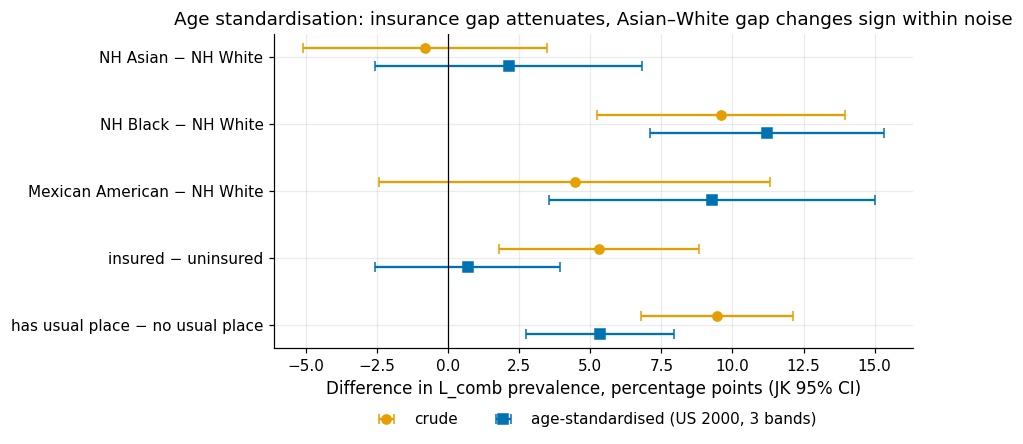

In [107]:
# Forest plot of crude vs age-standardised differences (US 2000 3-band), then three decision-register rows.
d3 = DIFFS[DIFFS.standard == "US2000 3-band"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
yy = np.arange(len(d3))[::-1]
# Offsets of +/-0.13 separate the crude and standardised markers of the same contrast.
ax.errorbar(d3.crude, yy + 0.13, xerr=[d3.crude - d3.crude_low, d3.crude_high - d3.crude], fmt="o", capsize=3,
            color=C.OKABE_ITO["orange"], label="crude")
ax.errorbar(d3["std"], yy - 0.13, xerr=[d3["std"] - d3.std_low, d3.std_high - d3["std"]], fmt="s", capsize=3,
            color=C.OKABE_ITO["blue"], label="age-standardised (US 2000, 3 bands)")
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(yy, d3.contrast)
ax.set_xlabel("Difference in L_comb prevalence, percentage points (JK 95% CI)")
ax.set_title("Age standardisation: insurance gap attenuates, Asian–White gap changes sign within noise")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
fig.tight_layout()
plots.savefig(fig, "S4_crude_vs_std",
              caption="Crude and age-standardised prevalence differences (WTPH2YR, jackknife 95% CI, df = 15).")
plt.show()

reg("DR-S4-03", "method", "US 2000 standard collapsed to 20-39/40-59/60+ = 0.3966/0.3718/0.2316, re-derived from the 5-year standard million.",
    "results/S4/std_prev_table.csv; §4.5", "derived weights equal survey.US2000_3BAND to 1e-4",
    "Direct age standardisation (3-band US 2000) for every between-group prevalence comparison; 6-band and internal standards as sensitivity.",
    "Crude comparisons (confounded by age); internal-only standard (not comparable with NCHS).",
    check_note="re-derived in-notebook; also validated indirectly by the DB516 age-adjusted replication")
reg("DR-S4-04", "claim_change", "NH Asian vs NH White L_comb: crude -0.8 pp (-5.1, 3.5) -> standardised +2.1 pp (-2.6, 6.8); pilot estimate 18.0% vs 13.6% not reproducible.",
    "results/S4/std_differences.csv; figures/S4_crude_vs_std.png",
    f"crude {aw.crude:+.1f} ({aw.crude_low:.1f}, {aw.crude_high:.1f}); std {aw['std']:+.1f} ({aw.std_low:.1f}, {aw.std_high:.1f}); std rates {pct(asian_std['std'])} vs {pct(white_std['std'])}%",
    "Withdraw the pilot 18.0/13.6 estimate; report the Asian-White contrast only as an example of honest uncertainty (both CIs include 0).",
    "Headline 'Asians have higher diabetes prevalence' (not supported by the CI).",
    check_verdict="PASS-FIX", check_note="pilot figure withdrawn; numbers re-computed with three standards")
reg("DR-S4-05", "interpretation", "Insured - uninsured L_comb: crude +5.3 pp (1.8, 8.8) -> age-standardised +0.7 pp (-2.6, 3.9).",
    "results/S4/std_differences.csv; §4.6",
    f"crude {iu.crude:+.1f} ({iu.crude_low:.1f}, {iu.crude_high:.1f}); std {iu['std']:+.1f} ({iu.std_low:.1f}, {iu.std_high:.1f}); uninsured 60+ share {ins_age.loc['uninsured','60+']:.1f}% vs insured {ins_age.loc['insured','60+']:.1f}%",
    "Describe as age confounding (Age -> Medicare -> Insurance; Age -> diabetes) causing attenuation; never call it a reversal or Simpson's paradox.",
    "Calling it a reversal or Simpson's paradox (the sign does not flip).",
    check_verdict="PASS-FIX", check_note="wording corrected from 'reversal' to 'attenuation'")

**So what.** Only 10 % of uninsured adults are 60+, against a third of insured adults. Age standardisation shrinks the
gap from +5.3 pp (1.8–8.8) to +0.7 pp (−2.6–3.9) with the **same sign**: age confounding, not a Simpson reversal. The
*usual place of care* gap survives (+9.4 → +5.3 pp, CI excluding zero), consistent with a care → diagnosis pathway
(§5.4). Access comparisons, including the §8 fairness audit, must be read conditional on age.

## 4.7 Simpson scan
**Why.** A systematic scan asks how often stratification flips the *sign* of a weighted difference (Simpson) or halves
it. It is exploratory, so every row carries a jackknife CI, flips get a design-based bootstrap probability, and only
flips the DAG (§4.8) supports as de-confounding may become claims. Grid fixed in advance: 9 binary exposures × 4
outcomes × 7 stratifiers (WTPH2YR; internal standard). Flip: opposite signs, both |Δ| > 1 pp; attenuation: same sign,
|crude| > 1 pp and |standardised| < ½ |crude|.

In [108]:
# Simpson scan: for every exposure x outcome x stratifier compare the crude difference with the stratum-
# standardised one and count sign flips and attenuations. Defines the grid, the DAG role of each stratifier
# and a vectorised scan function; fills SCAN with jackknife CIs.
r3 = coh.RIDRETH3
EXPOSURES = {   # name: (indicator with NaN outside the comparison, reference description)
    "female": (coh.sex.map({"Female": 1.0, "Male": 0.0}), "male"),
    # np.select builds a 1/0 indicator of exposure vs reference group, NaN for everyone else.
    "asian": (pd.Series(np.select([r3 == 6, r3 == 3], [1.0, 0.0], np.nan)), "NH White"),
    "black": (pd.Series(np.select([r3 == 4, r3 == 3], [1.0, 0.0], np.nan)), "NH White"),
    "hispanic": (pd.Series(np.select([r3.isin([1, 2]), r3 == 3], [1.0, 0.0], np.nan)), "NH White"),
    "uninsured": (coh.HIQ011.map({2: 1.0, 1: 0.0}), "insured"),
    "no_usual_care": (coh.HUQ030.map({2: 1.0, 1: 0.0, 3: 0.0}), "has usual place"),
    # Low income = poverty-income ratio below 1.3 (130 % of the poverty line); missing stays missing.
    "low_income": (pd.Series(np.where(coh.INDFMPIR.isna(), np.nan, (coh.INDFMPIR < 1.3).astype(float))), "PIR >= 1.3"),
    "ever_smoker": (coh.SMQ020.map({1: 1.0, 2: 0.0}), "never smoker"),
    # Low education = less than high school (codes 1-2) vs high school or more (codes 3-5).
    "low_education": (coh.DMDEDUC2.map({1: 1.0, 2: 1.0, 3: 0.0, 4: 0.0, 5: 0.0}), "high school or more"),
}
# Outcomes: the three labels plus the undiagnosed (E-SCREEN) flag.
OUTCOMES = {"L_comb": coh.L_comb.astype(float), "L_A1c": coh.L_A1c.astype(float),
            "L_self": coh.L_self.astype(float), "undiagnosed (E-SCREEN)": coh.y_escreen.astype(float)}
# Helper: bin a continuous column into labelled intervals closed on the left.
_cut = lambda x, b, l: pd.cut(x, b, labels=l, right=False).astype(object)
STRATIFIERS = {
    "age": coh.age3.astype(object),
    "sex": coh.sex.astype(object),
    "race": coh.RIDRETH3.map({1: "Hispanic", 2: "Hispanic", 3: "White", 4: "Black", 6: "Asian", 7: "Other"}),
    # Income bands in poverty-income ratio (usual NCHS cut-points).
    "income": _cut(coh.INDFMPIR, [0, 1.3, 3.5, 99], ["<1.3", "1.3-3.5", ">=3.5"]),
    # BMI bands at the WHO overweight and obesity cut-offs.
    "bmi": _cut(coh.BMXBMI, [0, 25, 30, 999], ["<25", "25-30", ">=30"]),
    "insurance": coh.insurance.astype(object),
    "education": coh.DMDEDUC2.map({1: "<HS", 2: "<HS", 3: "HS", 4: ">HS", 5: ">HS"}),
}
# Stratifier equal to the exposure itself is skipped: a variable cannot stratify itself.
SELF = {"female": "sex", "asian": "race", "black": "race", "hispanic": "race", "uninsured": "insurance",
        "low_income": "income", "low_education": "education"}
RACE_EXP = {"asian", "black", "hispanic"}
SES_EXP = {"uninsured", "no_usual_care", "low_income", "low_education"}


def stratifier_role(exposure, strat):
    """DAG role of the stratifier for this exposure (see §4.8)."""
    if strat == "bmi":
        return "mediator"                       # exposure -> adiposity -> BMI -> diabetes
    if strat == "age":
        return "confounder"                     # age -> exposure (Medicare, cohort, migration) and age -> diabetes
    if exposure in RACE_EXP:
        return "confounder" if strat == "sex" else "mediator"      # race -> SES/insurance -> diabetes
    if exposure in SES_EXP:
        return "confounder" if strat in ("sex", "race") else "ambiguous"   # SES siblings
    if exposure == "female":
        return "ambiguous"
    return "confounder" if strat in ("sex", "race", "income", "education", "insurance") else "ambiguous"


def scan_one(e, y, s, W):
    """Crude and internally standardised differences for every column of the weight matrix W."""
    # Usable rows: exposure, outcome and stratum known, and a positive full-sample weight.
    ok = ~np.isnan(e) & ~np.isnan(y) & pd.notna(s) & (W[:, 0] > 0)
    levels = sorted(set(s[ok]))
    cols = []
    # Indicator columns for every (exposure group, stratum) cell and its outcome-weighted twin.
    for g in (0.0, 1.0):
        for lv in levels:
            m = ok & (e == g) & (s == lv)
            cols += [m, m * np.nan_to_num(y)]
    M = np.column_stack(cols).astype(float)
    # One matrix product gives weighted denominators and numerators for the full sample and every replicate.
    A = W.T @ M                                      # R x (2 groups * k levels * 2)
    k = len(levels)
    den = A[:, 0::2].reshape(-1, 2, k)
    num = A[:, 1::2].reshape(-1, 2, k)
    crude = num.sum(2) / den.sum(2)                  # R x 2
    share = den.sum(1) / den.sum((1, 2))[:, None]    # pooled stratum shares, R x k
    with np.errstate(invalid="ignore", divide="ignore"):
        rate = num / den
    # Standardised rate: stratum-specific rates weighted by the pooled (internal) stratum shares.
    std = (rate * share[:, None, :]).sum(2)
    # Smallest exposure x stratum cell, reported so thin strata stay visible.
    min_cell = int(min(((ok & (e == g) & (s == lv)).sum()) for g in (0.0, 1.0) for lv in levels))
    return 100 * (crude[:, 1] - crude[:, 0]), 100 * (std[:, 1] - std[:, 0]), min_cell, int(ok.sum())


# Weight matrix: column 0 = full-sample weights, further columns = delete-one-PSU jackknife replicates.
W_full = coh[C.WEIGHT_PHLEB].to_numpy(float)
# jk_factor = jackknife variance multiplier per replicate.
W_jk, jk_factor = S.replicate_weights(coh, C.WEIGHT_PHLEB)
W_all = np.column_stack([W_full, W_jk])
# 95 % t quantile with the 15 design df.
t15 = stats.t.ppf(0.975, DF_DESIGN)
rows = []
for en, (ev, ref) in EXPOSURES.items():
    ev = ev.to_numpy(float)
    for on, yv in OUTCOMES.items():
        yv = yv.to_numpy(float)
        for sn, sv in STRATIFIERS.items():
            # Skip the stratifier that coincides with the exposure.
            if SELF.get(en) == sn:
                continue
            cr, sd, min_cell, n = scan_one(ev, yv, sv.to_numpy(object), W_all)
            # Jackknife SE of the difference: sqrt(sum_r factor_r * (replicate_r - full-sample estimate)^2).
            se_c = np.sqrt(np.sum(jk_factor * (cr[1:] - cr[0]) ** 2))
            se_s = np.sqrt(np.sum(jk_factor * (sd[1:] - sd[0]) ** 2))
            rows.append({"exposure": en, "reference": ref, "outcome": on, "stratifier": sn,
                         "role": stratifier_role(en, sn), "n": n, "min_cell": min_cell,
                         "crude": cr[0], "crude_low": cr[0] - t15 * se_c, "crude_high": cr[0] + t15 * se_c,
                         "std": sd[0], "std_low": sd[0] - t15 * se_s, "std_high": sd[0] + t15 * se_s})
SCAN = pd.DataFrame(rows)
# flip: crude and standardised signs differ and both differences exceed 1 pp in size.
SCAN["flip"] = (np.sign(SCAN.crude) != np.sign(SCAN["std"])) & (SCAN.crude.abs() > 1) & (SCAN["std"].abs() > 1)
# attenuation: same sign, crude above 1 pp and the standardised difference less than half of it.
SCAN["attenuation_50"] = (np.sign(SCAN.crude) == np.sign(SCAN["std"])) & (SCAN.crude.abs() > 1) & \
                         (SCAN["std"].abs() < 0.5 * SCAN.crude.abs())
# any_flip: sign change without the 1 pp size requirement.
SCAN["any_flip"] = np.sign(SCAN.crude) != np.sign(SCAN["std"])
# Grid size, minus the self-stratified combinations skipped above.
n_grid = len(EXPOSURES) * len(OUTCOMES) * len(STRATIFIERS)
n_self = len(OUTCOMES) * len(SELF)
print(f"grid {len(EXPOSURES)} x {len(OUTCOMES)} x {len(STRATIFIERS)} = {n_grid}; minus {n_self} self-stratifications "
      f"-> {len(SCAN)} comparisons (smallest exposure x stratum cell: {SCAN.min_cell.min()})")
print(f"sign flips (both |d| > 1 pp): {int(SCAN.flip.sum())}; any sign change: {int(SCAN.any_flip.sum())}; "
      f"attenuation > 50 %: {int(SCAN.attenuation_50.sum())}")
print("flips by stratifier role:", SCAN[SCAN.flip].role.value_counts().to_dict())

grid 9 x 4 x 7 = 252; minus 28 self-stratifications -> 224 comparisons (smallest exposure x stratum cell: 19)
sign flips (both |d| > 1 pp): 6; any sign change: 12; attenuation > 50 %: 10
flips by stratifier role: {'mediator': 4, 'confounder': 2}


**Design-based bootstrap of the flips.** A flip of a few points can be produced by sampling noise
alone. For every flagged flip – and for the pre-specified Asian × `L_comb` × age contrast – we
repeat the scan statistic on Rao–Wu rescaled bootstrap replicates (PSU resampling within strata with
*m_h = n_h − 1*, the standard choice for two-PSU designs) and report P(crude and standardised signs
differ) and P(standardised sign equals the point estimate's sign).

In [109]:
# Design-based (Rao-Wu) bootstrap of the flagged flips and of the pre-specified Asian x L_comb x age contrast.
# Adds P(crude and standardised signs differ); writes the scan table and OUT['simpson'].
B = C.N_BOOT
# Rao-Wu rescaled weights: PSUs resampled within strata, m_h = n_h - 1; seed from the master sequence.
W_boot = S.rao_wu_weights(coh, C.WEIGHT_PHLEB, B, seed=int(RNG_SEEDS[0].generate_state(1)[0]))
# Probe set: all flips plus the pre-specified contrast.
probe = SCAN[SCAN.flip | ((SCAN.exposure == "asian") & (SCAN.outcome == "L_comb") & (SCAN.stratifier == "age"))]
boot_rows = []
for idx, r in probe.iterrows():
    ev = EXPOSURES[r.exposure][0].to_numpy(float)
    yv = OUTCOMES[r.outcome].to_numpy(float)
    sv = STRATIFIERS[r.stratifier].to_numpy(object)
    # Same scan statistic on bootstrap weights: column 0 is the full sample, the rest are replicates.
    cr, sd, _, _ = scan_one(ev, yv, sv, np.column_stack([W_full, W_boot]))
    cr_b, sd_b = cr[1:], sd[1:]
    # p_sign_differs: share of replicates in which the crude and standardised signs differ.
    boot_rows.append({"idx": idx, "p_sign_differs": float(np.mean(np.sign(cr_b) != np.sign(sd_b))),
                      "p_std_sign_as_point": float(np.mean(np.sign(sd_b) == np.sign(r["std"]))),
                      "p_flip_rule": float(np.mean((np.sign(cr_b) != np.sign(sd_b)) & (np.abs(cr_b) > 1) & (np.abs(sd_b) > 1)))})
boot = pd.DataFrame(boot_rows).set_index("idx")
SCAN = SCAN.join(boot)
# A flip counts as DAG-supported only if the stratifier is a confounder (see §4.8).
SCAN["dag_supported"] = SCAN.flip & (SCAN.role == "confounder")
SCAN.to_csv(S4_DIR / "simpson_scan.csv", index=False)
cols = ["exposure", "outcome", "stratifier", "role", "crude", "crude_low", "crude_high", "std", "std_low", "std_high",
        "p_sign_differs", "p_std_sign_as_point", "dag_supported"]
print(f"Rao-Wu bootstrap replicates: B = {B} ({C.NB_MODE} mode)")
print(SCAN.loc[probe.index, cols].round(2).to_string(index=False))
print("\nlargest attenuations (|crude| > 1 pp):")
print(SCAN[SCAN.attenuation_50].assign(ratio=lambda d: d["std"] / d.crude).sort_values("ratio")
      [["exposure", "outcome", "stratifier", "role", "crude", "std"]].round(2).head(12).to_string(index=False))

# The two headline examples quoted in the text.
ex_ins = SCAN.query("exposure == 'uninsured' and outcome == 'L_A1c' and stratifier == 'age'").iloc[0]
ex_as = SCAN.query("exposure == 'asian' and outcome == 'L_comb' and stratifier == 'age'").iloc[0]
print(f"headline example uninsured x L_A1c | age: crude {ex_ins.crude:+.2f} -> standardised {ex_ins['std']:+.2f} pp; "
      f"P(signs differ) = {ex_ins.p_sign_differs:.3f} (B = {B})")
_aw_int = OUT["standardisation"]["asian_white"]["internal"]
print(f"Asian - White L_comb, three age standards: US 2000 {aw['std']:+.2f} pp; whole-cohort weighted age mix "
      f"{_aw_int:+.2f} pp; scan standard (pooled Asian + White age mix) {ex_as['std']:+.2f} pp")
OUT["simpson"] = {"n_comparisons": len(SCAN), "grid": [len(EXPOSURES), len(OUTCOMES), len(STRATIFIERS)],
                  "n_flips": int(SCAN.flip.sum()), "n_any_sign_change": int(SCAN.any_flip.sum()),
                  "n_attenuation_50": int(SCAN.attenuation_50.sum()), "n_boot": B, "bootstrap": "Rao-Wu rescaled, m_h = n_h - 1",
                  "flips": SCAN[SCAN.flip][cols].to_dict("records"),
                  "uninsured_A1c_age": {k: ex_ins[k] for k in ["crude", "std", "p_sign_differs", "p_std_sign_as_point"]},
                  "asian_Lcomb_age": {k: ex_as[k] for k in ["crude", "std", "p_sign_differs", "p_std_sign_as_point"]},
                  "n_dag_supported_flips": int(SCAN.dag_supported.sum())}

Rao-Wu bootstrap replicates: B = 1000 (FINAL mode)
 exposure outcome stratifier       role  crude  crude_low  crude_high   std  std_low  std_high  p_sign_differs  p_std_sign_as_point  dag_supported
    asian  L_comb        age confounder  -0.81      -5.09        3.46  3.27    -1.38      7.92            0.53                 0.92          False
    asian  L_comb        bmi   mediator  -1.32      -5.50        2.86  3.41    -3.61     10.42            0.53                 0.82          False
    asian   L_A1c        bmi   mediator  -1.27      -3.82        1.28  2.38    -1.41      6.17            0.73                 0.88          False
    asian  L_self        age confounder  -2.01      -6.37        2.35  1.44    -3.36      6.23            0.53                 0.73           True
 hispanic  L_comb  education   mediator   2.10      -3.47        7.67 -1.18    -6.74      4.38            0.37                 0.64          False
 hispanic  L_self  education   mediator   1.12      -3.27        5.

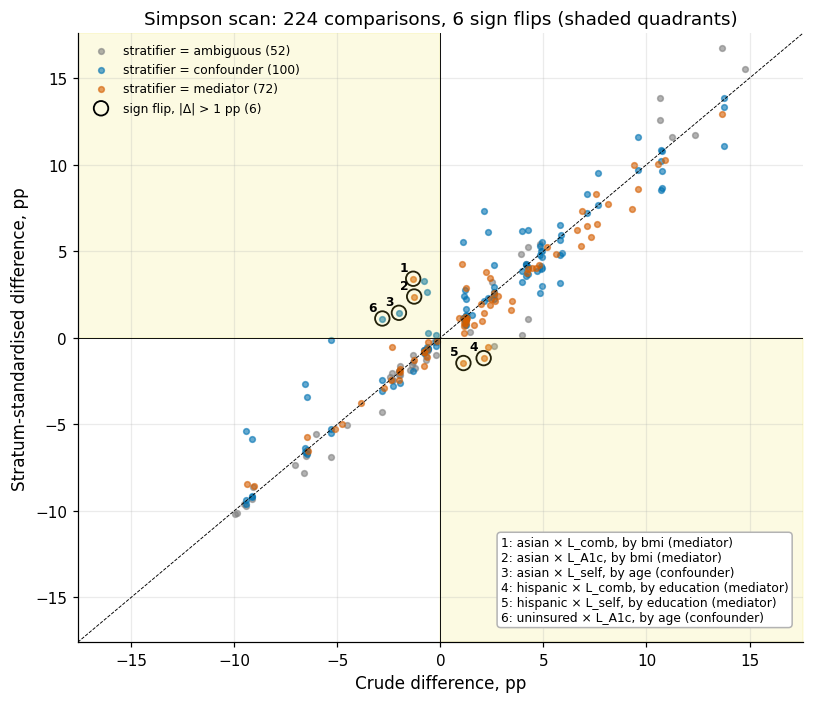

In [110]:
# Scatter of crude vs standardised differences for all scan comparisons, coloured by DAG role, flips circled;
# then one decision-register row.
fig, ax = plt.subplots(figsize=(7.5, 6.5))
role_col = {"confounder": C.OKABE_ITO["blue"], "mediator": C.OKABE_ITO["vermillion"], "ambiguous": C.OKABE_ITO["grey"]}
for role, g in SCAN.groupby("role"):
    ax.scatter(g.crude, g["std"], s=14, alpha=0.6, color=role_col[role], label=f"stratifier = {role} ({len(g)})")
fl = SCAN[SCAN.flip]
ax.scatter(fl.crude, fl["std"], s=90, facecolors="none", edgecolors="k", lw=1.2, label=f"sign flip, |Δ| > 1 pp ({len(fl)})")
key = []
for i, r in enumerate(fl.itertuples(), 1):
    ax.annotate(str(i), (r.crude, r.std), fontsize=8, fontweight="bold", xytext=(-9, 5), textcoords="offset points")
    key.append(f"{i}: {r.exposure} × {r.outcome.split(' ')[0]}, by {r.stratifier} ({r.role})")
ax.text(0.98, 0.03, chr(10).join(key), transform=ax.transAxes, ha="right", va="bottom", fontsize=8, multialignment="left",
        bbox=dict(boxstyle="round", fc="white", ec="0.7"))
# Symmetric axis limits so the diagonal is the identity line.
lim = np.nanmax(np.abs(SCAN[["crude", "std"]].to_numpy())) * 1.05
# Dashed diagonal: standardisation changes nothing.
ax.plot([-lim, lim], [-lim, lim], color="k", lw=0.6, ls="--")
ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
# Shaded quadrants: crude and standardised differences have opposite signs.
ax.fill_between([0, lim], -lim, 0, color=C.OKABE_ITO["yellow"], alpha=0.15)
ax.fill_between([-lim, 0], 0, lim, color=C.OKABE_ITO["yellow"], alpha=0.15)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("Crude difference, pp"); ax.set_ylabel("Stratum-standardised difference, pp")
ax.set_title(f"Simpson scan: {len(SCAN)} comparisons, {len(fl)} sign flips (shaded quadrants)")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plots.savefig(fig, "S4_simpson_scan",
              caption="Crude vs stratum-standardised weighted differences for every exposure x outcome x stratifier "
                      "combination; shaded quadrants = sign change; circled = flips with both |difference| > 1 pp. "
                      "Colour = DAG role of the stratifier.")
plt.show()

reg("DR-S4-06", "interpretation",
    f"Simpson scan: {len(SCAN)} comparisons, {int(SCAN.flip.sum())} sign flips, {int(SCAN.attenuation_50.sum())} attenuations > 50%; "
    f"{int((SCAN.flip & (SCAN.role == 'mediator')).sum())} flips come from mediator stratifiers (BMI, education).",
    "results/S4/simpson_scan.csv; figures/S4_simpson_scan.png",
    f"uninsured x L_A1c | age {ex_ins.crude:+.1f} -> {ex_ins['std']:+.1f} pp, P(sign differs) = {ex_ins.p_sign_differs:.2f}; "
    f"Asian x L_comb | age P(sign differs) = {ex_as.p_sign_differs:.2f} (B = {B})",
    "Treat the scan as exploratory; promote only DAG-supported (confounder-stratified) flips with CIs; never read BMI-stratified "
    "'flips' as de-confounding (BMI is a mediator / mismeasured proxy of adiposity).",
    "Reporting all flips as findings (multiple comparisons, mediator conditioning); hiding the scan.",
    check_note=f"grid fixed before the scan: 9 x 4 x 7 = 252 minus 28 self-stratifications = {len(SCAN)} comparisons")

**So what.** Of 224 comparisons, 6 flip sign and 10 attenuate by more than half; every flipped standardised difference
has a CI including zero. **Age-stratified flips** (uninsured × `L_A1c`, Asian × `L_self`) are DAG-supported but
exploratory (headline: uninsured × `L_A1c` | age, −2.8 → +1.1 pp, sign-change probability 0.775). **BMI- and
education-stratified flips** are *mediator artefacts*: BMI lies on race → adiposity → diabetes and under-states
Asian adiposity (§5.5), so equal-BMI strata are not equal-risk strata.

## 4.8 Causal structure (DAG)
**Why.** Whether stratifying on a variable removes bias (confounder) or creates it (mediator,
collider) is not a statistical property of the data – it follows from assumptions about how the
variables are generated. Writing those assumptions down as a DAG makes them checkable: the
adjustment sets used in §4.5–§4.7 and in §5.4 are verified with the back-door criterion
(d-separation in networkx) instead of being asserted.

In [111]:
# Encode the assumed causal structure as a DAG and check adjustment sets with the back-door criterion
# (networkx d-separation). Asserts the key valid/invalid sets; writes the adjustment-set table.
import networkx as nx

# Edges are assumed direct causal effects, taken from subject knowledge and not estimated from the data.
DAG_EDGES = [
    ("U: birth cohort / migration", "Race/ancestry"), ("U: birth cohort / migration", "Age"),
    ("Age", "Medicare"), ("Medicare", "Insurance"), ("SES", "Insurance"), ("Race/ancestry", "SES"),
    ("Insurance", "UsualCare"), ("SES", "UsualCare"), ("Age", "UsualCare"), ("UsualCare", "Diagnosis"),
    ("Race/ancestry", "Adiposity"), ("Age", "Adiposity"), ("Sex", "Adiposity"), ("SES", "Adiposity"),
    ("Adiposity", "BMI (measured)"), ("Race/ancestry", "BMI (measured)"),     # body-composition: BMI-adiposity relation differs
    ("Adiposity", "Diabetes"), ("Age", "Diabetes"), ("Sex", "Diabetes"), ("Race/ancestry", "Diabetes"), ("SES", "Diabetes"),
    ("Diabetes", "Diagnosis"), ("Diagnosis", "Treatment"), ("Treatment", "HbA1c (measured)"), ("Diabetes", "HbA1c (measured)"),
    ("Diabetes", "ExamSelection"), ("SES", "ExamSelection"), ("Age", "ExamSelection"),
]
G = nx.DiGraph(DAG_EDGES)
# Guard: a causal graph must be acyclic.
assert nx.is_directed_acyclic_graph(G)
LATENT = {"U: birth cohort / migration", "Adiposity", "Diabetes"}      # not directly observed


def backdoor_ok(g, x, y, z):
    """Back-door criterion: Z has no descendant of X and d-separates X and Y once X's out-edges are cut."""
    z = set(z)
    # Invalid if Z contains a descendant of X (post-exposure variable) or an unobserved variable.
    if z & nx.descendants(g, x) or z & LATENT:
        return False
    # Cut X's outgoing edges; if Z then d-separates X and Y, it blocks every back-door path.
    g2 = g.copy()
    g2.remove_edges_from(list(g.out_edges(x)))
    return nx.is_d_separator(g2, {x}, {y}, z)


# Enumerate minimal sufficient adjustment sets (up to max_size) among observed non-descendants of x.
def minimal_sets(g, x, y, max_size=3):
    cand = sorted(set(g) - {x, y} - nx.descendants(g, x) - LATENT)
    found = []
    from itertools import combinations
    for k in range(0, max_size + 1):
        for z in combinations(cand, k):
            # Keep only minimal sets: skip any set that contains one already found.
            if backdoor_ok(g, x, y, z) and not any(set(f) <= set(z) for f in found):
                found.append(z)
    return found


# Sets to test: sufficient ones, insufficient ones (crude, age only) and harmful ones (BMI, SES as mediators).
queries = [
    ("Insurance", "Diagnosis", ["Age", "SES"], "Insurance → undiagnosed (§5.4)"),
    ("Insurance", "Diagnosis", ["Age"], "… age only"),
    ("Insurance", "Diagnosis", [], "… crude"),
    ("Race/ancestry", "Diabetes", ["Age", "Sex"], "Race → diabetes (§4.5)"),
    ("Race/ancestry", "Diabetes", ["Age"], "… age only"),
    ("Race/ancestry", "Diabetes", [], "… crude"),
    ("Race/ancestry", "Diabetes", ["Age", "Sex", "BMI (measured)"], "… + BMI"),
    ("Race/ancestry", "Diabetes", ["Age", "Sex", "SES"], "… + SES (mediator)"),
    ("Insurance", "Diabetes", ["Age", "SES"], "Insurance → diabetes (§4.6)"),
]
DAG_TAB = pd.DataFrame([{"question": lab, "exposure": x, "outcome": y, "adjustment set": "{" + ", ".join(z) + "}",
                         "valid (back-door)": backdoor_ok(G, x, y, z),
                         "contains descendant of exposure": bool(set(z) & nx.descendants(G, x))}
                        for x, y, z, lab in queries])
print(DAG_TAB.to_string(index=False))
ms_ins = minimal_sets(G, "Insurance", "Diagnosis")
ms_race = minimal_sets(G, "Race/ancestry", "Diabetes")
print("\nminimal sufficient sets  Insurance -> Diagnosis:", ms_ins)
print("minimal sufficient sets  Race -> Diabetes:", ms_race)
# Selection: the cohort exists only for examined adults (conditioning on a collider)
# Remove the direct SES effects so SES and Diabetes are d-separated by construction.
g_noses = G.copy(); g_noses.remove_edge("SES", "Diabetes"); g_noses.remove_edge("SES", "Adiposity")
indep_without = nx.is_d_separator(g_noses, {"SES"}, {"Diabetes"}, {"Race/ancestry", "Age"})
indep_given_sel = nx.is_d_separator(g_noses, {"SES"}, {"Diabetes"}, {"Race/ancestry", "Age", "ExamSelection"})
print("\ncollider check (SES->diabetes edges removed):")
print(f"  SES ⟂ Diabetes | Race, Age: {indep_without}; also conditioning on ExamSelection: {indep_given_sel}")
print("  -> selection into the examination opens a path")
# Guard: {Age, SES} valid for insurance -> diagnosis, {Age, Sex} for race -> diabetes, adding BMI invalid.
assert DAG_TAB.loc[0, "valid (back-door)"] and DAG_TAB.loc[3, "valid (back-door)"] and not DAG_TAB.loc[6, "valid (back-door)"]
DAG_TAB.to_csv(S4_DIR / "dag_adjustment_sets.csv", index=False)
OUT["dag"] = {"n_nodes": G.number_of_nodes(), "n_edges": G.number_of_edges(),
              "minimal_sets_insurance_diagnosis": [list(z) for z in ms_ins],
              "minimal_sets_race_diabetes": [list(z) for z in ms_race],
              "bmi_adjustment_valid": bool(DAG_TAB.loc[6, "valid (back-door)"]), "exam_selection_opens_path": bool(indep_without and not indep_given_sel)}

                      question      exposure   outcome             adjustment set  valid (back-door)  contains descendant of exposure
Insurance → undiagnosed (§5.4)     Insurance Diagnosis                 {Age, SES}               True                            False
                    … age only     Insurance Diagnosis                      {Age}              False                            False
                       … crude     Insurance Diagnosis                         {}              False                            False
        Race → diabetes (§4.5) Race/ancestry  Diabetes                 {Age, Sex}               True                            False
                    … age only Race/ancestry  Diabetes                      {Age}               True                            False
                       … crude Race/ancestry  Diabetes                         {}              False                            False
                       … + BMI Race/ancestry  Diabetes {Age, S

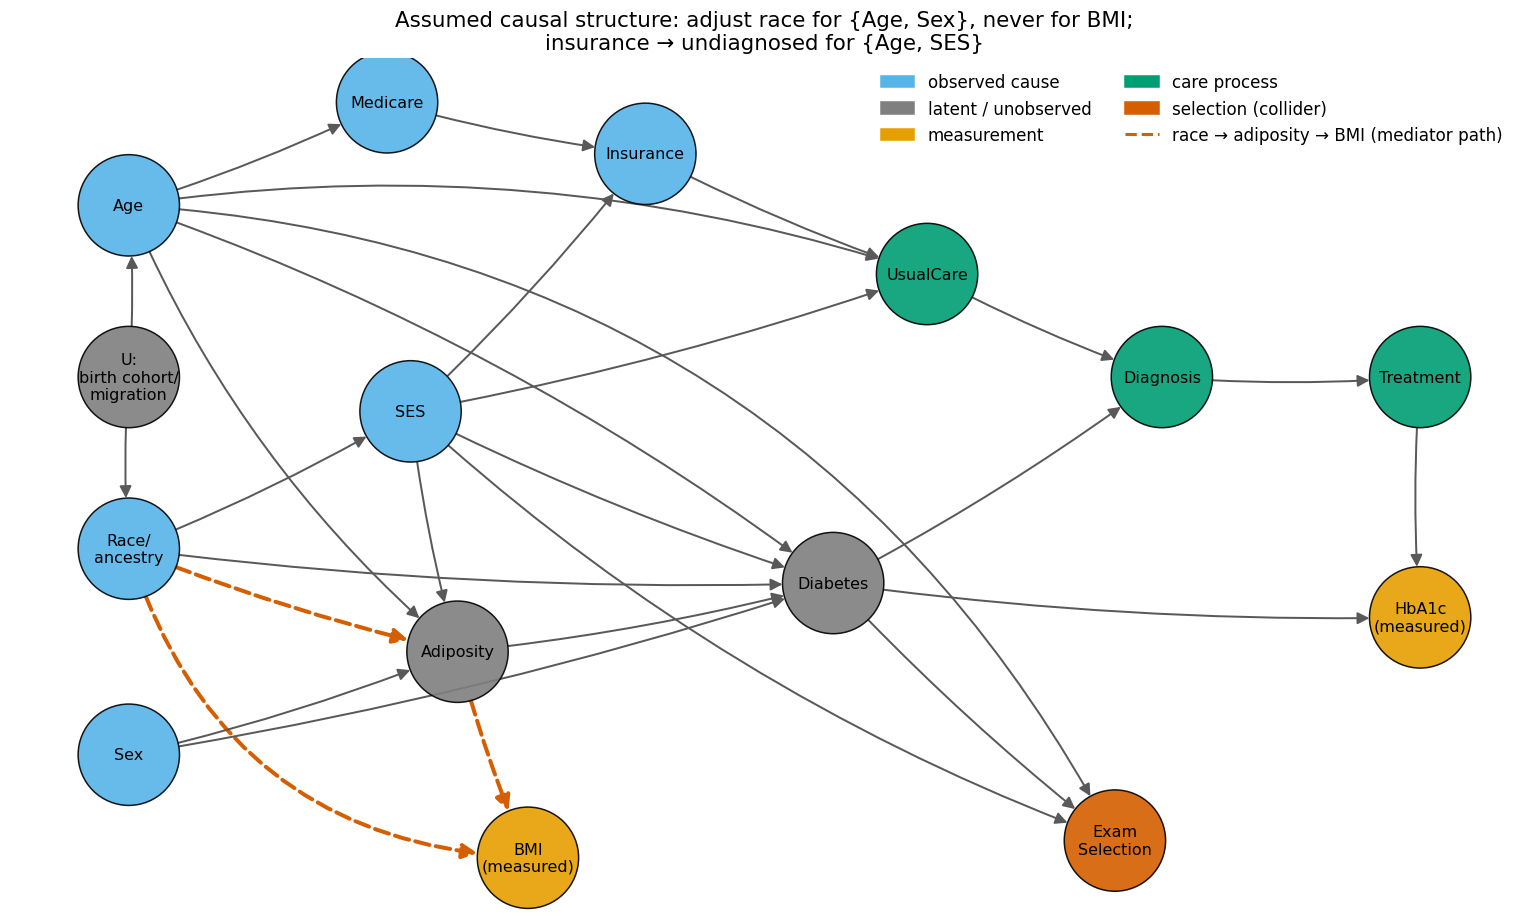

In [112]:
# Draw the DAG (layout, colours by node kind, mediator path dashed). Only plots; adds one register row.
# Hand-set node coordinates place causes on the left and outcomes on the right.
POS = {"Age": (0, 6.4), "U: birth cohort / migration": (0, 4.4), "Race/ancestry": (0, 2.4), "Sex": (0, 0.0),
       "Medicare": (2.2, 7.6), "Insurance": (4.4, 7.0), "UsualCare": (6.8, 5.6), "SES": (2.4, 4.0),
       "Adiposity": (2.8, 1.2), "BMI (measured)": (3.4, -1.2), "Diabetes": (6.0, 2.0), "Diagnosis": (8.8, 4.4),
       "Treatment": (11.0, 4.4), "HbA1c (measured)": (11.0, 1.6), "ExamSelection": (8.4, -1.0)}
# Node kinds drive the colours; any node not listed is an observed cause.
KIND = {n: "latent" for n in LATENT} | {"BMI (measured)": "measure", "HbA1c (measured)": "measure",
                                        "ExamSelection": "selection", "Diagnosis": "process", "Treatment": "process",
                                        "UsualCare": "process"}
KCOL = {"latent": C.OKABE_ITO["grey"], "measure": C.OKABE_ITO["orange"], "selection": C.OKABE_ITO["vermillion"],
        "process": C.OKABE_ITO["green"], "observed": C.OKABE_ITO["sky"]}
fig, ax = plt.subplots(figsize=(14, 8.5))
cols_ = [KCOL[KIND.get(n, "observed")] for n in G.nodes]
nx.draw_networkx_nodes(G, POS, ax=ax, node_color=cols_, node_size=4400, alpha=0.9,
                       node_shape="o", linewidths=1, edgecolors="k")
# Mediator path highlighted: race -> adiposity -> BMI.
mediator_edges = [("Race/ancestry", "Adiposity"), ("Adiposity", "BMI (measured)"), ("Race/ancestry", "BMI (measured)")]
# Edge curvature per edge to pull overlapping arrows apart.
EDGE_RAD = {("Race/ancestry", "BMI (measured)"): 0.35, ("Age", "UsualCare"): -0.12, ("Age", "Diabetes"): -0.08,
            ("Age", "ExamSelection"): -0.28, ("Age", "Adiposity"): 0.12, ("SES", "ExamSelection"): 0.10}
for e in G.edges:                                   # draw edge by edge so overlapping paths can be curved apart
    med = e in mediator_edges
    nx.draw_networkx_edges(G, POS, ax=ax, edgelist=[e], arrows=True, arrowsize=20 if med else 16, node_size=4400,
                           width=2.6 if med else 1.3, style="dashed" if med else "solid",
                           edge_color=C.OKABE_ITO["vermillion"] if med else "0.35",
                           connectionstyle=f"arc3,rad={EDGE_RAD.get(e, 0.04)}")
nx.draw_networkx_labels(G, POS, ax=ax, labels={n: n.replace(" (measured)", "\n(measured)").replace(": ", ":\n").replace(" / ", "/\n").replace("/ancestry", "/\nancestry").replace("ExamSelection", "Exam\nSelection") for n in G},
                        font_size=10.5)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=KCOL[k], label=lab) for k, lab in
                   [("observed", "observed cause"), ("latent", "latent / unobserved"), ("measure", "measurement"),
                    ("process", "care process"), ("selection", "selection (collider)")]] +
          [plt.Line2D([], [], color=C.OKABE_ITO["vermillion"], ls="--", lw=2, label="race → adiposity → BMI (mediator path)")],
          loc="upper right", fontsize=11, ncol=2)
ax.set_title("Assumed causal structure: adjust race for {Age, Sex}, never for BMI;\ninsurance → undiagnosed for {Age, SES}",
             fontsize=14)
ax.axis("off")
fig.tight_layout()
plots.savefig(fig, "S4_dag", caption="Directed acyclic graph of the assumed data-generating process (networkx); "
                                     "adjustment sets verified with the back-door criterion in §4.8.")
plt.show()

reg("DR-S4-07", "method", "In the DAG, BMI is a descendant of race (race -> adiposity -> BMI) and of SES; ExamSelection is a collider.",
    "figures/S4_dag.png; results/S4/dag_adjustment_sets.csv",
    f"back-door valid: race->diabetes | {{Age, Sex}} = True, + BMI = False; insurance->diagnosis | {{Age, SES}} = True; minimal sets {ms_ins}",
    "Adjust race comparisons for age (and sex) only; never present BMI-adjusted race contrasts as de-confounded; "
    "model coefficients are associations (no Table 2 fallacy).",
    "Adjusting for every available covariate (includes mediators and descendants); reading logistic coefficients causally.",
    check_note="adjustment sets verified with networkx d-separation")

**So what.** Under the stated assumptions {Age, SES} suffices for insurance → undiagnosed (§5.4) and {Age} or {Age, Sex}
for race → diabetes; adjusting for BMI breaks the back-door criterion, so BMI-adjusted race contrasts estimate
something else. The cohort conditions on the collider *ExamSelection*, and the HbA1c label descends from *Treatment*
(masking, §5.2). Model coefficients in §7 are conditional associations, not effects (Westreich & Greenland 2013).

## 4.9 Redundancy and collinearity
**Why.** Several candidate features are arithmetic functions of each other (BMI = weight/height²,
WHtR = waist/height, LDL is computed from TC, HDL and triglycerides) or repeated measurements of
one quantity (three systolic and three diastolic readings). Such redundancy inflates coefficient
variance and makes coefficients uninterpretable. Variance inflation factors (VIF) quantify it; they
are read with O'Brien (2007) in mind – a high VIF is a reason to look at the structure, not an
automatic deletion rule.

In [113]:
# Collinearity: VIFs per variable set, structural-redundancy checks and an iterative VIF pruning example.
# Asserts the frozen VIFs; writes the VIF table, OUT['vif'] and OUT['redundancy'].
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

# Sets are analysed block-wise because a VIF depends on which variables enter together.
VIF_SETS = {
    "raw_anthropometry": ["BMXWT", "BMXHT", "BMXBMI", "BMXWAIST", "BMXHIP", "BMXARMC"],
    "ht_bmi": ["BMXHT", "BMXBMI"],
    "bmi_waist": ["BMXBMI", "BMXWAIST"],
    "bp_readings": ["BPXOSY1", "BPXOSY2", "BPXOSY3", "BPXODI1", "BPXODI2", "BPXODI3"],
    "bp_means": ["bp_sys_mean", "bp_dia_mean"],
    "tier1_candidates": ["RIDAGEYR", "BMXBMI", "BMXWAIST", "bp_sys_mean", "INDFMPIR"],
    "tier2_candidates": ["RIDAGEYR", "BMXBMI", "bp_sys_mean", "LBXTC", "LBDHDD"],
}
vif_rows = []
for set_name, cols in VIF_SETS.items():
    # Complete cases within each set.
    x = coh[cols].dropna()
    # VIF_i = 1 / (1 - R^2_i) from regressing column i on the others, with an intercept.
    X = sm.add_constant(x.to_numpy(float))
    for i, c in enumerate(cols):
        # i + 1 skips the constant column.
        vif_rows.append({"set": set_name, "variable": c, "vif": variance_inflation_factor(X, i + 1), "n": len(x)})
VIF = pd.DataFrame(vif_rows)
VIF.to_csv(S4_DIR / "vif_table.csv", index=False)
print(VIF.pivot_table(index="variable", columns="set", values="vif", sort=False).round(1).fillna("").to_string())
print("complete cases per set:")
print("  " + ", ".join(f"{k} {v:,}" for k, v in VIF.groupby("set", sort=False).n.first().items()))

VIFS = VIF.set_index(["set", "variable"]).vif
# Guard: frozen VIFs of weight and BMI (structural redundancy).
assert abs(VIFS[("raw_anthropometry", "BMXWT")] - 95.7) < 0.1 and abs(VIFS[("raw_anthropometry", "BMXBMI")] - 97.6) < 0.1
bp = VIF.query("set == 'bp_readings'").vif
# Guard: frozen VIF range of the six BP readings.
assert abs(bp.min() - 8.8) < 0.1 and abs(bp.max() - 11.7) < 0.1

a = coh[["BMXBMI", "BMXWT", "BMXHT"]].dropna()
# BMI = W / H^2, so log BMI = log W - 2 log H exactly (cm -> m); r near 1 shows the duplication.
r_struct = np.corrcoef(np.log(a.BMXBMI), np.log(a.BMXWT) - 2 * np.log(a.BMXHT / 100))[0, 1]
# LDL and triglycerides are valid only where the fasting weight is positive.
fast_ok = coh[C.WEIGHT_FASTING].fillna(0) > 0
lip = coh.loc[fast_ok, ["LBXTC", "LBDLDL"]].dropna()
r_tc_ldl = lip.corr().iloc[0, 1]
print(f"\nstructural redundancy: corr(log BMI, log W - 2 log H) = {r_struct:.5f} (n = {len(a):,})")
print(f"TC vs LDL (fasting subsample, n = {len(lip):,}): Pearson r = {r_tc_ldl:.3f}")
OUT["vif"] = {s: {r.variable: r.vif for r in g.itertuples()} for s, g in VIF.groupby("set", sort=False)}


def prune_vif(x, protect, thresh=10.0):
    """Iteratively drop the unprotected column with the largest VIF while any VIF exceeds `thresh`."""
    cols, dropped = list(x.columns), []
    while True:
        X = sm.add_constant(x[cols].to_numpy(float))
        vifs = pd.Series([variance_inflation_factor(X, i + 1) for i in range(len(cols))], index=cols)
        # Largest VIF among the unprotected columns; protected ones (BMI, waist) are never dropped.
        cand = vifs.drop(labels=[c for c in protect if c in cols]).sort_values(ascending=False)
        # Stop once no VIF exceeds the threshold (10, a conventional rule of thumb; O'Brien 2007).
        if cand.empty or cand.iloc[0] <= thresh:
            return dropped, vifs
        dropped.append(cand.index[0]); cols.remove(cand.index[0])


# Illustration on the raw anthropometry set; the in-pipeline version (§6.5) refits this in each training fold.
_dropped, _vifs_after = prune_vif(coh[VIF_SETS["raw_anthropometry"]].dropna(), protect=["BMXBMI", "BMXWAIST"])
print(f"iterative VIF > 10 pruning (BMI, waist protected) on the raw anthropometry set drops {_dropped}; "
      f"remaining max VIF {_vifs_after.max():.1f} ({_vifs_after.idxmax()})")
OUT["vif_pruning_illustration"] = {"dropped": _dropped, "vif_after": _vifs_after.to_dict()}
OUT["redundancy"] = {"r_logbmi_logw_2logh": r_struct, "r_tc_ldl": r_tc_ldl, "n_tc_ldl": len(lip)}

set         raw_anthropometry ht_bmi bmi_waist bp_readings bp_means tier1_candidates tier2_candidates
variable                                                                                             
BMXWT                    95.7                                                                        
BMXHT                    21.6    1.0                                                                 
BMXBMI                   97.6    1.0       5.1                                   5.8              1.1
BMXWAIST                  7.1              5.1                                   5.9                 
BMXHIP                    7.7                                                                        
BMXARMC                   6.6                                                                        
BPXOSY1                                               10.5                                           
BPXOSY2                                               11.7                        

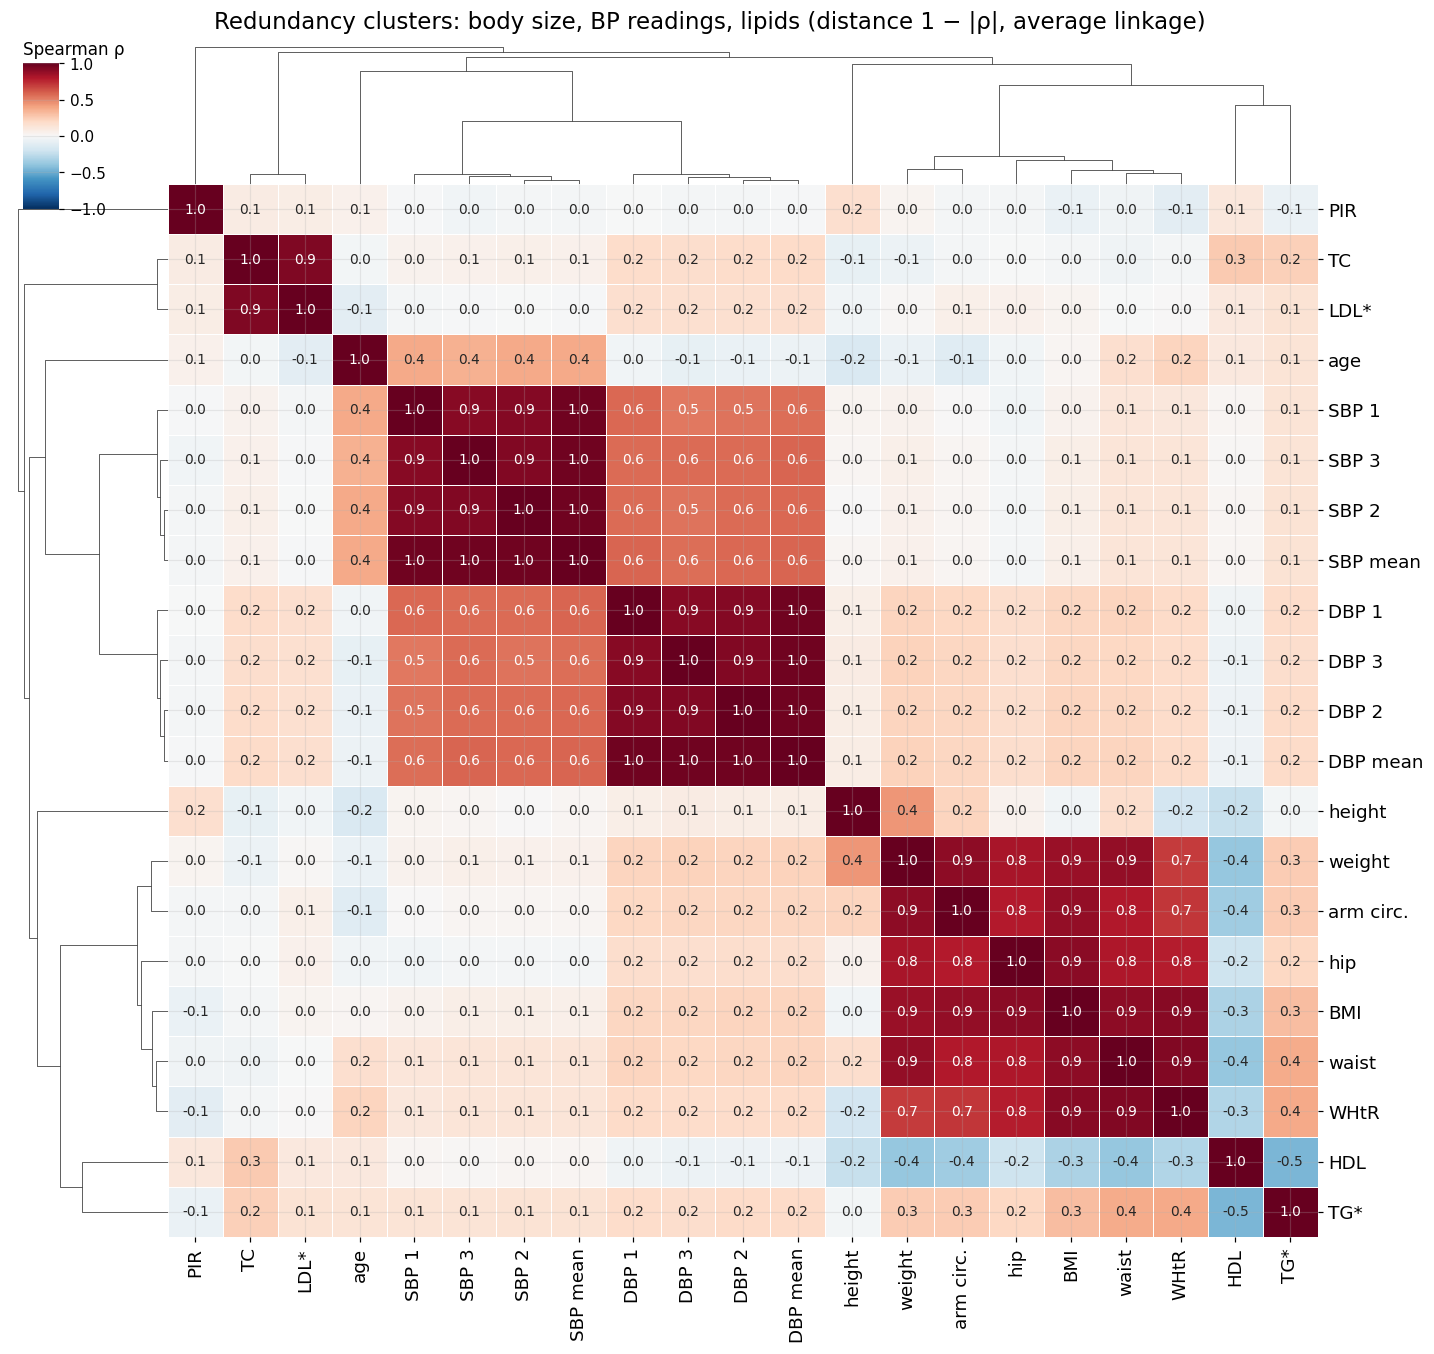

clusters with |rho| >= 0.7 (average linkage):
   TC, LDL*
   SBP 1, SBP 2, SBP 3, SBP mean
   DBP 1, DBP 2, DBP 3, DBP mean
   BMI, weight, waist, hip, arm circ., WHtR


In [114]:
# Clustered Spearman heat map of candidate predictors and the clusters at |rho| >= 0.7.
# Only plots; adds the cluster list to OUT['redundancy'].
import seaborn as sns
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

SPEAR_VARS = {"RIDAGEYR": "age", "BMXBMI": "BMI", "BMXWT": "weight", "BMXHT": "height", "BMXWAIST": "waist",
              "BMXHIP": "hip", "BMXARMC": "arm circ.", "whtr": "WHtR", "BPXOSY1": "SBP 1", "BPXOSY2": "SBP 2",
              "BPXOSY3": "SBP 3", "BPXODI1": "DBP 1", "BPXODI2": "DBP 2", "BPXODI3": "DBP 3",
              "bp_sys_mean": "SBP mean", "bp_dia_mean": "DBP mean", "LBXTC": "TC", "LBDHDD": "HDL",
              "LBDLDL": "LDL*", "LBXTLG": "TG*", "INDFMPIR": "PIR"}
sp = coh[list(SPEAR_VARS)].copy()
sp.loc[~fast_ok, ["LBDLDL", "LBXTLG"]] = np.nan                     # fasting analytes only where valid
# Spearman = rank-based, robust to skew; pairwise complete observations.
rho = sp.rename(columns=SPEAR_VARS).corr(method="spearman")          # pairwise complete
# Distance 1 - |rho|: strong negative and strong positive correlations both count as redundancy.
dist = 1 - rho.abs()
# squareform gives the condensed distances that linkage expects; average linkage.
link = hierarchy.linkage(squareform(dist.to_numpy(), checks=False), method="average")
annot_txt = rho.map(lambda v: f"{v:.1f}".replace("-0.0", "0.0"))
cg = sns.clustermap(rho, row_linkage=link, col_linkage=link, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                    annot=annot_txt, fmt="", annot_kws={"fontsize": 9}, figsize=(13, 12),
                    cbar_pos=(0.02, 0.86, 0.025, 0.11), dendrogram_ratio=0.12, linewidths=0.4, linecolor="white")
cg.ax_heatmap.tick_params(labelsize=12)
cg.ax_heatmap.set_xlabel(""); cg.ax_heatmap.set_ylabel("")
cg.ax_cbar.tick_params(labelsize=10); cg.ax_cbar.set_title("Spearman ρ", fontsize=11, loc="left")
cg.fig.suptitle("Redundancy clusters: body size, BP readings, lipids (distance 1 − |ρ|, average linkage)", y=1.01, fontsize=15)
plots.savefig(cg.fig, "S4_spearman_clustermap",
              caption="Clustered Spearman correlation heatmap of candidate predictors (pairwise complete; *LDL and "
                      "triglycerides on the valid fasting subsample only).")
plt.show()
# Cut the tree at distance 0.3: members of a cluster are correlated at about |rho| >= 0.7.
clusters = pd.Series(hierarchy.fcluster(link, t=1 - 0.7, criterion="distance"), index=rho.index)
# Keep only clusters with more than one member.
groups = [list(g.index) for _, g in clusters.groupby(clusters) if len(g) > 1]
print("clusters with |rho| >= 0.7 (average linkage):")
for g_ in groups:
    print("  ", ", ".join(g_))
OUT["redundancy"]["clusters_rho07"] = groups

**So what.** VIFs here are block-wise on the whole cohort (each block's variables only; §6.5 reports in-pipeline VIFs
on the training part with all inputs together). Within the six body measures, weight (VIF 95.7) and BMI (97.6) are
almost perfectly predictable, for a structural reason: log BMI is an exact linear function of log weight and log
height (r = 0.99999). BMI and waist share variance (5.1) but measure different things, and the six blood-pressure
readings (8.8–11.7) collapse to VIF 1.6 when only the two means are compared. TC and LDL correlate at 0.94 because
LDL is calculated from TC. Decision: mean SBP/DBP, no LDL, and in-fold iterative VIF > 10 pruning with
BMI and waist protected (removes only weight); L2 penalisation is the second line of defence. The
heatmap shows the three blocks (body size, blood pressure, lipids).

## 4.10 Skewness
**Why.** Strong right skew lets a few extreme values dominate a linear predictor and the
penalisation. We measure skewness before and after log and Yeo–Johnson transforms. Triglycerides
are a fasting analyte: they are only valid where the fasting weight is positive (8–24 h fast).

   variable             label                             subsample    n  skew_raw  skew_log  skew_yj  yj_lambda
     BMXBMI               BMI                                cohort 5649      1.22      0.42    -0.00      -0.65
bp_sys_mean          SBP mean                                cohort 5550      0.93      0.38    -0.01      -0.79
     LBDHDD               HDL                                cohort 5459      1.08      0.21     0.00      -0.29
   BMXWAIST             waist                                cohort 5470      0.58      0.12     0.00      -0.27
      LBXTC total cholesterol                                cohort 5459      0.54     -0.25     0.01       0.32
   INDFMPIR               PIR                                cohort 4996     -0.07       NaN    -0.17       0.77
     LBXTLG     triglycerides                fasting (WTSAF2YR > 0) 2820      6.62      0.60    -0.01      -0.35
     LBXTLG     triglycerides all with a value (incl. WTSAF2YR = 0) 3055      6.23      0.57    

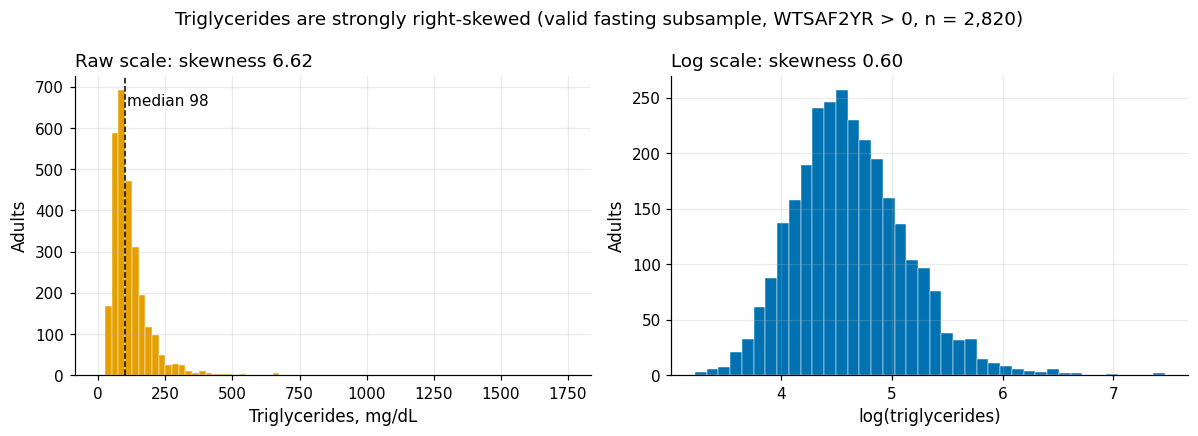

In [115]:
# Skewness of continuous candidates raw, after log and after Yeo-Johnson; triglycerides only on valid fasting
# rows. Asserts the frozen BMI skewness; writes the skew table and OUT['skew'].
SKEW_VARS = [("BMXBMI", "BMI"), ("bp_sys_mean", "SBP mean"), ("LBDHDD", "HDL"), ("BMXWAIST", "waist"),
             ("LBXTC", "total cholesterol"), ("INDFMPIR", "PIR")]
skew_rows = []
# One skew-table row: raw, log and Yeo-Johnson skewness plus the fitted Yeo-Johnson lambda.
def _skew_row(x, var, label, subsample):
    x = x.dropna().astype(float)
    # yeojohnson returns the transformed values and the maximum-likelihood lambda.
    yj, lam = stats.yeojohnson(x)
    return {"variable": var, "label": label, "subsample": subsample, "n": len(x), "skew_raw": stats.skew(x),
            # log skewness exists only when all values are positive.
            "skew_log": stats.skew(np.log(x)) if (x > 0).all() else np.nan, "skew_yj": stats.skew(yj), "yj_lambda": lam}
for var, label in SKEW_VARS:
    skew_rows.append(_skew_row(coh[var], var, label, "cohort"))
# Triglycerides twice: valid fasting rows vs every row with a value, to show the cost of non-fasting rows.
skew_rows.append(_skew_row(coh.loc[fast_ok, "LBXTLG"], "LBXTLG", "triglycerides", "fasting (WTSAF2YR > 0)"))
skew_rows.append(_skew_row(coh["LBXTLG"], "LBXTLG", "triglycerides", "all with a value (incl. WTSAF2YR = 0)"))
SKEW = pd.DataFrame(skew_rows)
SKEW.to_csv(S4_DIR / "skew_table.csv", index=False)
print(SKEW.round(2).to_string(index=False))
sk = SKEW.set_index(["variable", "subsample"])
# Guard: frozen BMI skewness and (near) zero skewness after Yeo-Johnson.
assert abs(sk.loc[("BMXBMI", "cohort"), "skew_raw"] - 1.22) < 0.01 and abs(sk.loc[("BMXBMI", "cohort"), "skew_yj"]) < 0.01
tg_f, tg_all = sk.loc[("LBXTLG", "fasting (WTSAF2YR > 0)")], sk.loc[("LBXTLG", "all with a value (incl. WTSAF2YR = 0)")]
print(f"\ntriglycerides: valid fasting n = {tg_f.n:,}, skew {tg_f.skew_raw:.2f} -> log {tg_f.skew_log:.2f}; "
      f"including {tg_all.n - tg_f.n} non-fasting rows: skew {tg_all.skew_raw:.2f} -> log {tg_all.skew_log:.2f}")
_raw_w = io.read_xpt("GLU_L")[C.WEIGHT_FASTING]          # unfixed transport-file read
# Zero weights read from the raw transport file appear as tiny positive floats and wrongly pass '> 0'.
_tiny = _raw_w[(_raw_w > 0) & (_raw_w < C.XPT_ZERO_EPS)]
print(f"unfixed GLU_L read: {len(_tiny)} fasting weights stored as 0 appear as {_tiny.max():.1e} and pass a '> 0' filter")
OUT["skew_tg_unfixed_zero_weights"] = {"n": len(_tiny), "value": float(_tiny.max()) if len(_tiny) else None}
OUT["skew"] = {f"{r.variable}|{r.subsample}": {"n": r.n, "raw": r.skew_raw, "log": r.skew_log, "yj": r.skew_yj,
                                               "lambda": r.yj_lambda} for r in SKEW.itertuples()}

# Triglycerides on the valid fasting subsample: raw vs log scale (same rows as the skew table).
tg = coh.loc[fast_ok, "LBXTLG"].dropna().astype(float)
# Guard: the plotted sample is exactly the skew-table sample.
assert len(tg) == tg_f.n and abs(stats.skew(tg) - tg_f.skew_raw) < 1e-9 and abs(stats.skew(np.log(tg)) - tg_f.skew_log) < 1e-9
fig, (t1, t2) = plt.subplots(1, 2, figsize=(11, 4))
# 25 mg/dL bins.
t1.hist(tg, bins=np.arange(0, tg.max() + 25, 25), color=C.OKABE_ITO["orange"], edgecolor="white", lw=0.3)
t1.axvline(tg.median(), color="k", ls="--", lw=1); t1.text(tg.median() * 1.08, t1.get_ylim()[1] * 0.9, f"median {tg.median():.0f}", fontsize=10)
t1.set_xlabel("Triglycerides, mg/dL"); t1.set_ylabel("Adults")
t1.set_title(f"Raw scale: skewness {tg_f.skew_raw:.2f}", loc="left")
t2.hist(np.log(tg), bins=40, color=C.OKABE_ITO["blue"], edgecolor="white", lw=0.3)
t2.set_xlabel("log(triglycerides)"); t2.set_ylabel("Adults")
t2.set_title(f"Log scale: skewness {tg_f.skew_log:.2f}", loc="left")
fig.suptitle(f"Triglycerides are strongly right-skewed (valid fasting subsample, WTSAF2YR > 0, n = {len(tg):,})", fontsize=12)
fig.tight_layout()
plots.savefig(fig, "S4_triglyceride_skew",
              caption=f"Distribution of triglycerides on the {len(tg):,} adults of the valid fasting subsample (WTSAF2YR > 0), raw "
                      f"(skewness {tg_f.skew_raw:.2f}) and log-transformed (skewness {tg_f.skew_log:.2f}). Including the "
                      f"{tg_all.n - tg_f.n} rows with WTSAF2YR = 0 would give a raw skewness of {tg_all.skew_raw:.2f}.")
plt.show()

reg("DR-S4-08", "preparation", "Structural redundancy: weight VIF 95.7, BMI 97.6 (BMI = W/H^2, r = 0.99999); six BP readings VIF 8.8-11.7; TC-LDL r = 0.94.",
    "results/S4/vif_table.csv; figures/S4_spearman_clustermap.png",
    f"BP means VIF {VIFS[('bp_means', 'bp_sys_mean')]:.1f}; Tier-1 max VIF {VIF[VIF.set == 'tier1_candidates'].vif.max():.1f}; "
    f"Tier-2 max {VIF[VIF.set == 'tier2_candidates'].vif.max():.1f}",
    "Average BP readings; exclude LDL; prune structural duplicates of BMI inside the training folds (iterative VIF > 10, BMI and waist protected; "
    "removes weight); keep BMI + waist (or WHtR, S8) under L2.",
    "Unprotected VIF deletion (O'Brien 2007: VIF alone is not a reason to drop BMI or waist); PCA of body measures (destroys interpretability).",
    check_note="VIFs re-computed; n = 5,388 for the raw anthropometry set")
reg("DR-S4-09", "preparation", "Right skew: BMI 1.22, SBP 0.93, HDL 1.08; triglycerides 6.62 on the valid fasting subsample.",
    "results/S4/skew_table.csv",
    f"BMI 1.22 -> log {sk.loc[('BMXBMI','cohort'),'skew_log']:.2f} -> YJ {sk.loc[('BMXBMI','cohort'),'skew_yj']:.2f}; TG {tg_f.skew_raw:.2f} (n {tg_f.n}) vs {tg_all.skew_raw:.2f} incl. non-fasting",
    "Offer Yeo-Johnson as a toggleable step fitted inside training folds only; the S7 ablation decides; triglycerides are not a T1/T2 feature.",
    "Transform on the full data before splitting (leakage of lambda); log for variables that can be 0 (PIR).",
    check_verdict="PASS-FIX", check_note="valid fasting value 6.62; including the 235 rows with WTSAF2YR = 0 would give 6.23; figure S4_triglyceride_skew")

**So what.** BMI, SBP and HDL are moderately right-skewed (0.9–1.2); Yeo–Johnson removes it. Triglycerides are extremely
skewed: 6.62 on the 2,820 valid fasting adults, 0.60 after a log transform. Including the 235 rows with
`WTSAF2YR = 0` would give 6.23 – an easy trap, because an unfixed XPT read makes those zero weights pass a `> 0`
filter (§3.1). Logistic regression assumes no distribution, so the transform is an in-fold step that §7 judges.

## 4.11 Linearity
**Why.** A plain logistic regression assumes linear effects on the log-odds. Each continuous predictor gets a 4-knot
restricted cubic spline (Harrell; 2 extra df) and a likelihood-ratio test against the linear term, with the others
linear and sex adjusted (complete cases, `L_comb`, unweighted: a model-structure question).

In [116]:
# Linearity: likelihood-ratio test of a 4-knot restricted cubic spline against a linear term, per predictor.
# Asserts the frozen complete-case n and chi-square values; writes the test table and OUT['linearity'].
import statsmodels.formula.api as smf

LIN_VARS = {"RIDAGEYR": "age", "BMXBMI": "BMI", "BMXWAIST": "waist", "bp_sys_mean": "SBP (mean)",
            "LBDHDD": "HDL", "LBXTC": "total cholesterol", "INDFMPIR": "PIR"}


def rcs_basis(x, q=(0.05, 0.35, 0.65, 0.95)):
    """Harrell restricted cubic spline basis (linear term + k-2 non-linear terms), knots at quantiles."""
    x = np.asarray(x, float)
    # Knots at the 5th/35th/65th/95th percentiles (Harrell's default for four knots).
    t = np.quantile(x, q)
    k = len(t)
    # Truncated cubic (u)+^3.
    p3 = lambda u: np.maximum(u, 0) ** 3
    # Non-linear terms: truncated cubics constrained to be linear beyond the outer knots (restricted spline).
    nl = [(p3(x - t[j]) - p3(x - t[k - 2]) * (t[k - 1] - t[j]) / (t[k - 1] - t[k - 2])
           + p3(x - t[k - 1]) * (t[k - 2] - t[j]) / (t[k - 1] - t[k - 2])) / (t[k - 1] - t[0]) ** 2 for j in range(k - 2)]
    return np.column_stack([x] + nl), t


# Complete cases across all seven predictors so every model uses the same rows.
lin = coh.dropna(subset=list(LIN_VARS)).reset_index(drop=True)
lin["female"] = (lin.sex == "Female").astype(float)
y_lin = lin.L_comb.to_numpy(float)
# Unweighted logit: this is a model-structure question, not a population estimate.
fit_logit = lambda X: sm.Logit(y_lin, sm.add_constant(X)).fit(disp=0)
lin_rows = []
for v, lab in LIN_VARS.items():
    # All other predictors enter linearly; sex is always adjusted.
    others = lin[[o for o in LIN_VARS if o != v] + ["female"]].to_numpy(float)
    basis, knots = rcs_basis(lin[v])
    # Linear vs spline fit of the tested variable: nested models, so a likelihood-ratio test applies.
    m_lin = fit_logit(np.column_stack([basis[:, :1], others]))
    m_rcs = fit_logit(np.column_stack([basis, others]))
    # LR statistic = 2 (llf_full - llf_reduced); df = number of non-linear terms (k - 2 = 2 for four knots).
    chi2 = 2 * (m_rcs.llf - m_lin.llf)
    dfree = basis.shape[1] - 1
    lin_rows.append({"variable": v, "label": lab, "n": len(lin), "n_events": int(y_lin.sum()), "chi2": chi2, "df": dfree,
                     "p": stats.chi2.sf(chi2, dfree), "knots": np.round(knots, 1).tolist()})
LIN = pd.DataFrame(lin_rows)
LIN["nonlinear"] = LIN.p < 0.05
LIN.to_csv(S4_DIR / "linearity_tests.csv", index=False)
print(LIN.assign(p=LIN.p.map(lambda p: f"{p:.2g}")).round(2).to_string(index=False))
expected = {"RIDAGEYR": 57.6, "BMXBMI": 11.6, "BMXWAIST": 7.1, "bp_sys_mean": 5.9, "LBDHDD": 18.5, "LBXTC": 41.8, "INDFMPIR": 0.8}
# Guard: frozen complete-case n and chi-square statistics (to 0.1).
assert len(lin) == 4478 and all(abs(LIN.set_index("variable").chi2[k] - e) < 0.1 for k, e in expected.items())
OUT["linearity"] = {r.variable: {"label": r.label, "chi2": r.chi2, "df": r.df, "p": r.p} for r in LIN.itertuples()}
OUT["linearity_n"] = {"n": len(lin), "events": int(y_lin.sum())}

   variable             label    n  n_events  chi2  df       p                        knots  nonlinear
   RIDAGEYR               age 4478       722 57.61   2 3.1e-13     [25.0, 47.0, 63.0, 79.0]       True
     BMXBMI               BMI 4478       722 11.56   2  0.0031     [20.5, 26.2, 31.1, 42.6]       True
   BMXWAIST             waist 4478       722  7.05   2   0.029   [76.4, 93.3, 106.5, 130.9]       True
bp_sys_mean        SBP (mean) 4478       722  5.87   2   0.053  [98.3, 114.3, 127.0, 154.4]      False
     LBDHDD               HDL 4478       722 18.47   2 9.8e-05     [35.0, 48.0, 58.0, 82.0]       True
      LBXTC total cholesterol 4478       722 41.77   2 8.5e-10 [125.0, 171.0, 202.0, 260.1]       True
   INDFMPIR               PIR 4478       722  0.83   2    0.66         [0.5, 2.1, 4.1, 5.0]      False


**Binned empirical log-odds.** The test says *whether* a curve is needed; the binned plot shows
*what shape* it has. Points are the observed log-odds in deciles (95 % CI); lines are univariable
linear and RCS logistic fits.

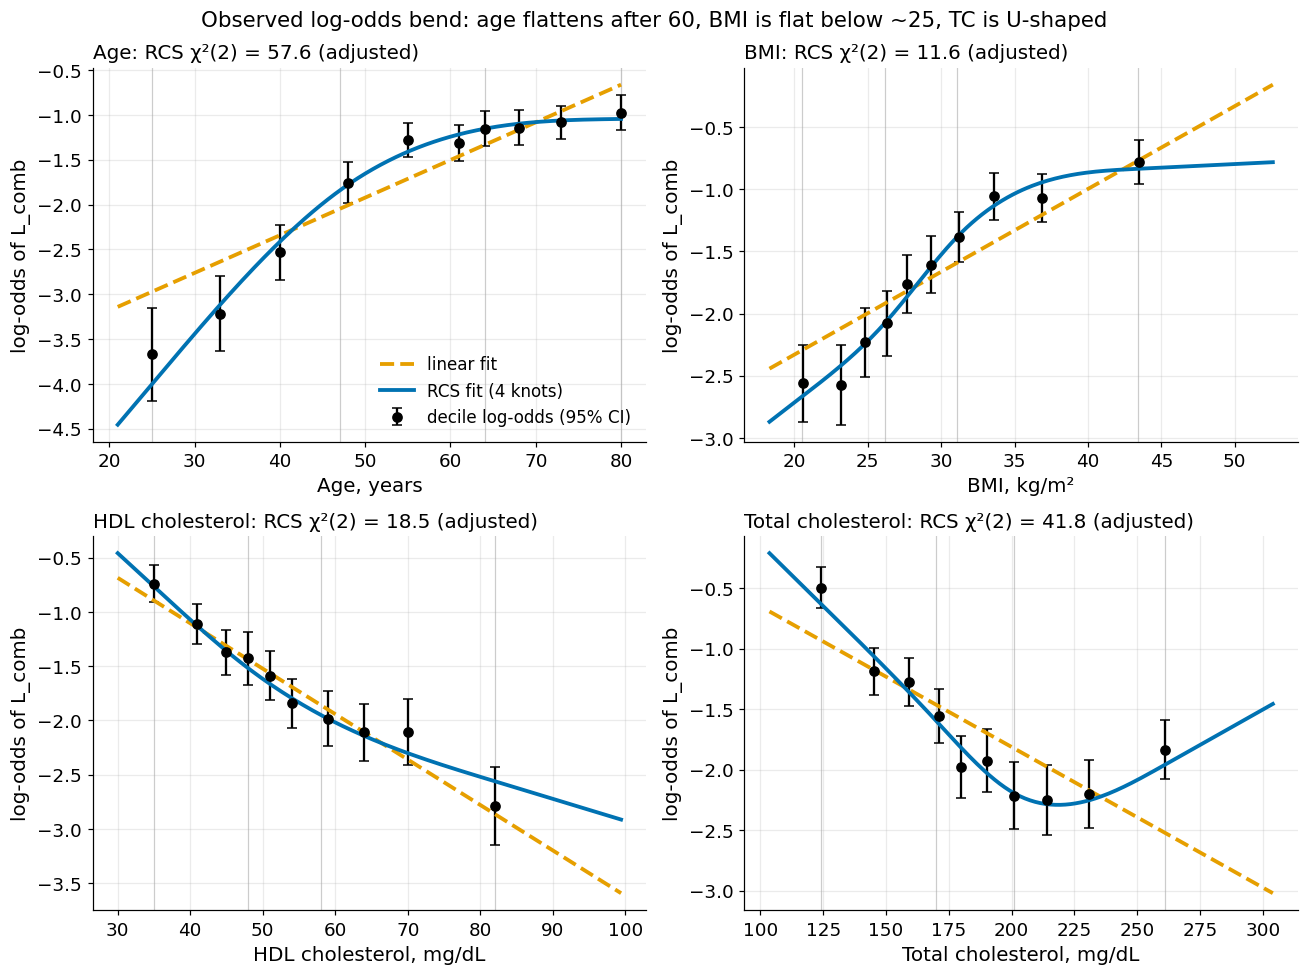

decile,1,2,3,4,5,6,7,8,9,10
BMI median,20.60,23.20,24.80,26.30,27.70,29.30,31.20,33.60,36.90,43.40
BMI log-odds,-2.56,-2.57,-2.23,-2.08,-1.76,-1.61,-1.39,-1.06,-1.07,-0.78
age median,25.00,33.00,40.00,48.00,55.00,61.00,64.00,68.00,73.00,80.00
age log-odds,-3.67,-3.22,-2.53,-1.76,-1.28,-1.32,-1.15,-1.14,-1.09,-0.97


In [117]:
# Decile-binned empirical log-odds with linear and spline fits for age, BMI, HDL and total cholesterol,
# to show the shape of the curvature. Only plots; stores the binned values in OUT.
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
binned = {}
for ax, (v, lab) in zip(axes.ravel(), [("RIDAGEYR", "Age, years"), ("BMXBMI", "BMI, kg/m²"),
                                       ("LBDHDD", "HDL cholesterol, mg/dL"), ("LBXTC", "Total cholesterol, mg/dL")]):
    d = coh[[v, "L_comb"]].dropna()
    # Deciles; duplicates='drop' merges bins if ties collapse a boundary.
    d["bin"] = pd.qcut(d[v], 10, duplicates="drop")
    g = d.groupby("bin", observed=True).agg(x=(v, "median"), n=("L_comb", "size"), k=("L_comb", "sum"))
    # Add 0.5 to events and non-events (Haldane-Anscombe) so empty or full bins keep a finite log-odds.
    pr = (g.k + 0.5) / (g.n + 1)
    # Standard error of an empirical log-odds: sqrt(1 / events + 1 / non-events).
    lo_ = np.log(pr / (1 - pr)); se = np.sqrt(1 / (g.k + 0.5) + 1 / (g.n - g.k + 0.5))
    ax.errorbar(g.x, lo_, yerr=1.96 * se, fmt="o", ms=6, color="k", capsize=3, label="decile log-odds (95% CI)")
    # Plot between the 1st and 99th percentile to avoid extreme tails.
    grid = np.linspace(d[v].quantile(0.01), d[v].quantile(0.99), 200)
    Bx, kn = rcs_basis(d[v])
    m_r = sm.Logit(d.L_comb.to_numpy(float), sm.add_constant(Bx)).fit(disp=0)
    # Same truncated cubic as in rcs_basis, evaluated on the plotting grid with the fitted knots.
    p3 = lambda u: np.maximum(u, 0) ** 3
    k_ = len(kn)
    Bg = np.column_stack([grid] + [(p3(grid - kn[j]) - p3(grid - kn[k_ - 2]) * (kn[k_ - 1] - kn[j]) / (kn[k_ - 1] - kn[k_ - 2])
                                    + p3(grid - kn[k_ - 1]) * (kn[k_ - 2] - kn[j]) / (kn[k_ - 1] - kn[k_ - 2])) / (kn[k_ - 1] - kn[0]) ** 2
                                   for j in range(k_ - 2)])
    m_l = sm.Logit(d.L_comb.to_numpy(float), sm.add_constant(d[[v]].to_numpy(float))).fit(disp=0)
    ax.plot(grid, m_l.params[0] + m_l.params[1] * grid, color=C.OKABE_ITO["orange"], lw=2.5, ls="--", label="linear fit")
    ax.plot(grid, sm.add_constant(Bg) @ m_r.params, color=C.OKABE_ITO["blue"], lw=2.5, label="RCS fit (4 knots)")
    for kv in kn:
        ax.axvline(kv, color="0.8", lw=0.8, zorder=0)
    ax.set_xlabel(lab, fontsize=13); ax.set_ylabel("log-odds of L_comb", fontsize=13)
    ax.tick_params(labelsize=12)
    ax.set_title(f"{lab.split(',')[0]}: RCS χ²(2) = {LIN.set_index('variable').chi2[v]:.1f} (adjusted)", fontsize=13, loc="left")
    binned[v] = pd.DataFrame({"median": g.x.to_numpy(), "logodds": lo_.to_numpy(), "n": g.n.to_numpy()})
axes[0, 0].legend(fontsize=11)
fig.suptitle("Observed log-odds bend: age flattens after 60, BMI is flat below ~25, TC is U-shaped", fontsize=14)
fig.tight_layout()
plots.savefig(fig, "S4_binned_logodds", caption="Decile-binned empirical log-odds of L_comb (unweighted, 95% CI) with "
                                                "univariable linear and 4-knot restricted cubic spline fits; grey lines = knots.")
plt.show()
bmi_b = binned["BMXBMI"]; age_b = binned["RIDAGEYR"]
display(pd.DataFrame({"decile": range(1, len(bmi_b) + 1), "BMI median": bmi_b["median"].round(1), "BMI log-odds": bmi_b.logodds.round(2),
                      "age median": age_b["median"].round(0), "age log-odds": age_b.logodds.round(2)}).set_index("decile").T)
OUT["binned_logodds"] = {lab: df_.to_dict("list") for lab, df_ in binned.items()}

**So what.** Five of seven predictors bend on the log-odds scale: age (χ² 57.6), total cholesterol (41.8), HDL (18.5),
BMI (11.6) and waist (7.1); SBP is borderline and PIR linear. Age rises steeply to about 60 and flattens; BMI is flat
below about 24; total cholesterol is U-shaped, most plausibly because statins lower it *after* diagnosis. Consequence:
cubic B-splines on continuous predictors, with a linear arm kept as an ablation.

## 4.12 Interactions and power
**Why.** If the BMI slope differed by race (as §5.5 suggests for Asian adults) the model would need an interaction.
A non-significant test is informative only with its power, so the minimum detectable effect (80 % power, α = 0.05) is
reported and the tests are repeated under three specifications.

In [118]:
# Interaction tests (race, Asian, age, sex x BMI) under three model specifications, with the minimum
# detectable effect. Asserts the race terms are non-significant; writes the tests and OUT['interactions'].
inter = lin.rename(columns={"RIDAGEYR": "age", "BMXBMI": "bmi", "BMXWAIST": "waist", "bp_sys_mean": "sbp",
                            "LBDHDD": "hdl", "LBXTC": "tc", "INDFMPIR": "pir"}).copy()
inter["race6"] = pd.Categorical(inter.race.astype(str), categories=list(io.RACE_ORDER))   # NH White = reference
inter["asian"] = (inter.race == "NH Asian").astype(float)
# Spline columns for age and BMI, needed by the splines specification.
for v in ["age", "bmi"]:
    Bv, _ = rcs_basis(inter[v]); inter[f"{v}_s1"], inter[f"{v}_s2"] = Bv[:, 1], Bv[:, 2]
# Specification B uses all adults with a BMI (larger n), so it is built from the full cohort.
bmi_cc = coh.dropna(subset=["BMXBMI"]).rename(columns={"RIDAGEYR": "age", "BMXBMI": "bmi"}).copy()
bmi_cc["female"] = (bmi_cc.sex == "Female").astype(float)
bmi_cc["race6"] = pd.Categorical(bmi_cc.race.astype(str), categories=list(io.RACE_ORDER))
bmi_cc["asian"] = (bmi_cc.race == "NH Asian").astype(float)
# Three specifications show whether the conclusion depends on the covariate set.
SPECS = {
    "A_primary": (inter, "age + female + race6 + bmi + waist + sbp + hdl + tc + pir"),
    "B_minimal": (bmi_cc, "age + female + race6 + bmi"),
    "C_splines": (inter, "age + age_s1 + age_s2 + bmi + bmi_s1 + bmi_s2 + female + race6"),
}
TERMS = {"race_x_bmi": "race6:bmi", "asian_x_bmi": "asian:bmi", "age_x_bmi": "age:bmi",
         "sex_x_bmi": "female:bmi"}
# z(1 - alpha/2) + z(power): multiplier for the minimum detectable effect (alpha 0.05, power 80 %).
z80 = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
int_rows = []
for spec, (d, base) in SPECS.items():
    # Base model without the interaction, for the nested likelihood-ratio test.
    m0 = smf.logit(f"L_comb ~ {base}", d).fit(disp=0)
    for term, expr in TERMS.items():
        m1 = smf.logit(f"L_comb ~ {base} + {expr}", d).fit(disp=0)
        # LR test of the interaction; df = number of parameters added.
        chi2 = 2 * (m1.llf - m0.llf); k = int(m1.df_model - m0.df_model)
        mde = np.nan
        # MDE is computed only for one-parameter interactions.
        if k == 1:
            name = [p for p in m1.params.index if p not in m0.params.index][0]
            mde = z80 * m1.bse[name] * 5                     # log-OR difference per 5 kg/m² BMI (per year x 5 for age)
        int_rows.append({"term": term, "spec": spec, "n": int(m1.nobs), "chi2": chi2, "df": k,
                         "p": stats.chi2.sf(chi2, k), "mde": mde})
INT = pd.DataFrame(int_rows)
INT["verdict"] = np.where(INT.p < 0.05, "detected", "not detected")
INT.to_csv(S4_DIR / "interaction_tests.csv", index=False)
print(INT.pivot(index="term", columns="spec", values="p").round(3).to_string())
prim = INT[INT.spec == "A_primary"].set_index("term")
mde_asian = prim.loc["asian_x_bmi", "mde"]
print(f"\nprimary spec (n = {int(prim.n.iloc[0]):,}): race x BMI chi2({int(prim.loc['race_x_bmi','df'])}) = "
      f"{prim.loc['race_x_bmi','chi2']:.2f}, p = {prim.loc['race_x_bmi','p']:.2f}; Asian x BMI p = {prim.loc['asian_x_bmi','p']:.2f}; "
      f"age x BMI p = {prim.loc['age_x_bmi','p']:.2f}; sex x BMI p = {prim.loc['sex_x_bmi','p']:.3f}")
print(f"MDE (80% power) for the Asian x BMI slope difference: {mde_asian:.2f} log-OR per 5 kg/m² "
      f"(odds-ratio multiplier {np.exp(mde_asian):.2f} per 5 kg/m²)")
race_p_range = (INT[INT.term == "race_x_bmi"].p.min(), INT[INT.term == "race_x_bmi"].p.max())
sex_p_range = (INT[INT.term == "sex_x_bmi"].p.min(), INT[INT.term == "sex_x_bmi"].p.max())
# Guard: race x BMI and Asian x BMI must be non-significant in every specification (the wording rests on it).
assert race_p_range[0] > 0.05 and INT[INT.term == "asian_x_bmi"].p.min() > 0.05
OUT["interactions"] = {r.term: {"chi2": r.chi2, "df": r.df, "p": r.p, "mde": r.mde} for r in prim.reset_index().itertuples()}
OUT["interactions_by_spec"] = INT.to_dict("records")

reg("DR-S4-10", "model", "Non-linearity: RCS LR chi2(2) age 57.6, TC 41.8, HDL 18.5, BMI 11.6, waist 7.1 (p < 0.05); SBP 5.9 (p 0.053); PIR 0.8.",
    "results/S4/linearity_tests.csv; figures/S4_binned_logodds.png",
    f"n = {len(lin):,}, events {int(y_lin.sum())}",
    "Main model: L2 logistic regression with SplineTransformer(n_knots=4, degree=3, knots='quantile', extrapolation='linear') on continuous features; linear arm as ablation.",
    "Plain linear logit (misses curvature); fixed-cut categorisation (loses information, arbitrary cut-points); GAM/boosting (outside the basic-model rule).")
reg("DR-S4-11", "model", "Interactions with BMI not detectable: race x BMI and Asian x BMI non-significant under all three specifications.",
    "results/S4/interaction_tests.csv",
    f"primary: race x BMI p = {prim.loc['race_x_bmi','p']:.2f}, Asian x BMI p = {prim.loc['asian_x_bmi','p']:.2f}; MDE Asian x BMI {mde_asian:.2f} log-OR per 5 kg/m²; "
    f"sex x BMI p range {sex_p_range[0]:.3f}-{sex_p_range[1]:.2f} (specification-dependent)",
    "No interaction terms in the main model ('not detectable, underpowered', not 'absent'); the Asian BMI problem is addressed as measurement (WHtR, S5/S8), not by an interaction.",
    "Adding race x BMI terms (cost variance, power too low to estimate them); claiming no interaction exists.",
    check_note="three specifications compared; conclusions for race terms hold in every one, sex x BMI is specification-dependent")

spec         A_primary  B_minimal  C_splines
term                                        
age_x_bmi        0.445      0.435      0.050
asian_x_bmi      0.933      0.945      0.789
race_x_bmi       0.393      0.393      0.172
sex_x_bmi        0.008      0.833      0.072

primary spec (n = 4,478): race x BMI chi2(5) = 5.19, p = 0.39; Asian x BMI p = 0.93; age x BMI p = 0.45; sex x BMI p = 0.008
MDE (80% power) for the Asian x BMI slope difference: 0.70 log-OR per 5 kg/m² (odds-ratio multiplier 2.02 per 5 kg/m²)


**So what.** Race × BMI and Asian × BMI are not detectable in any specification (p well above 0.05).
With about 300 Asian adults the minimum detectable effect is a large slope difference, so the wording
is "not detectable (underpowered)", not "no interaction". Sex × BMI is specification-dependent
(significant only with waist in the model, i.e. collinearity of two adiposity measures). Decision:
no interaction terms; the Asian BMI problem is treated as *measurement* (WHtR, §5.5 and §8.9).

## 4.13 Data → algorithm (DAJ) table
**Why.** Each modelling choice in §6–§7 should follow from a diagnostic in the data, with the reason
the alternatives were rejected. The table is built from the numbers computed above.

In [119]:
# Assemble the data -> algorithm (DAJ) table from numbers computed above, so it changes if the data change.
# Writes the DAJ table and OUT['daj'].
L_ = LIN.set_index("variable")
DAJ = pd.DataFrame([
    ("Non-linearity", f"RCS chi2(2): age {L_.chi2['RIDAGEYR']:.1f}, TC {L_.chi2['LBXTC']:.1f}, HDL {L_.chi2['LBDHDD']:.1f}, "
                      f"BMI {L_.chi2['BMXBMI']:.1f}, waist {L_.chi2['BMXWAIST']:.1f} (all p < 0.05); PIR {L_.chi2['INDFMPIR']:.1f}",
     "L2 logistic regression + SplineTransformer(4 quantile knots, cubic, linear extrapolation) on continuous features; linear arm as ablation",
     "Linear logit under-fits the bends; categorisation is arbitrary; GAM/boosting outside the basic-model rule and less interpretable"),
    ("Interactions", f"race x BMI p = {prim.loc['race_x_bmi','p']:.2f}, Asian x BMI p = {prim.loc['asian_x_bmi','p']:.2f} (MDE {mde_asian:.2f} log-OR / 5 kg/m²)",
     "No interaction terms; Asian BMI bias handled as measurement (WHtR arm, S8)",
     "Interaction terms with this power add variance without detectable gain; 'not detectable' is not 'absent'"),
    ("Structural redundancy", f"VIF weight {VIFS[('raw_anthropometry','BMXWT')]:.1f}, BMI {VIFS[('raw_anthropometry','BMXBMI')]:.1f}; "
                              f"BP readings {bp.min():.1f}-{bp.max():.1f}; corr(log BMI, log W - 2 log H) = {r_struct:.5f}",
     "Average BP readings; exclude LDL; remove structural duplicates of BMI by in-fold iterative VIF > 10 pruning with BMI and "
     "waist protected (preparation step P05, which removes weight); L2 penalty as second line of defence",
     "Unprotected VIF deletion (could drop BMI or waist, which measure different aspects of adiposity; O'Brien 2007); "
     "PCA of body measures (loses interpretability); pruning on the full data (leaks into the folds)"),
    ("Skewness", f"BMI {sk.loc[('BMXBMI','cohort'),'skew_raw']:.2f}, HDL {sk.loc[('LBDHDD','cohort'),'skew_raw']:.2f}, SBP {sk.loc[('bp_sys_mean','cohort'),'skew_raw']:.2f}; YJ -> ~0",
     "Yeo-Johnson as a toggleable step fitted inside training folds; kept only if the S7 ablation supports it",
     "Transforming before the split leaks lambda; log fails at 0"),
    ("Weights / age structure", f"weighted {pct(wp['est'])}% vs unweighted {pct(unw)}%; Kish deff {kish:.2f}; 60+ {pct(share_s['60+'])}% vs {pct(share_w['60+'])}%",
     "Survey weights as an ablation block (B6) and weighted evaluation metrics alongside unweighted ones",
     "Ignoring weights (sample != population) or training only weighted (variance cost without tested benefit)"),
    ("Age confounding", f"insured-uninsured +{iu.crude:.1f} -> +{iu['std']:.1f} pp; {int(SCAN.attenuation_50.sum())} attenuations > 50% in the scan",
     "Age always in the model; every group comparison age-standardised or age-adjusted",
     "Reading crude group gaps as access or ethnicity effects"),
    ("Causal structure", "BMI is a descendant of race (DAG); back-door invalid with BMI",
     "Model coefficients reported as conditional associations only; no causal language",
     "Table 2 fallacy: interpreting every coefficient as an effect"),
    ("Thresholds / leakage probe", "clinical cut-points (BMI 25/30, age 45) and leakage need inspection",
     f"Secondary shallow decision tree (max_depth = {C.TREE_MAX_DEPTH}, min_samples_leaf = {C.TREE_MIN_LEAF}) for threshold discovery and leak hunting only",
     "Deep trees / ensembles overfit and are outside the basic-model rule; a shallow tree is readable and exposes leaks as near-perfect splits"),
    ("Non-monotone TC", "TC U-shaped in binned log-odds (statins after diagnosis)",
     "Tier-2 lipid coefficients carry a reverse-causation caveat",
     "Interpreting low TC as protective"),
], columns=["diagnostic", "evidence", "decision", "why_not_alternative"])
DAJ.to_csv(S4_DIR / "daj_table.csv", index=False)
display(Markdown(md_table(DAJ)))
OUT["daj"] = DAJ.to_dict("records")
reg("DR-S4-12", "model", "Data -> algorithm table: 9 diagnostics mapped to modelling decisions.",
    "results/S4/daj_table.csv", "see table", "S7 cites the DAJ table for model justification; shallow tree only for thresholds and leakage.",
    "Choosing the algorithm before looking at data structure; using complex models (basic-model rule).")

| diagnostic | evidence | decision | why_not_alternative |
|---|---|---|---|
| Non-linearity | RCS chi2(2): age 57.6, TC 41.8, HDL 18.5, BMI 11.6, waist 7.1 (all p < 0.05); PIR 0.8 | L2 logistic regression + SplineTransformer(4 quantile knots, cubic, linear extrapolation) on continuous features; linear arm as ablation | Linear logit under-fits the bends; categorisation is arbitrary; GAM/boosting outside the basic-model rule and less interpretable |
| Interactions | race x BMI p = 0.39, Asian x BMI p = 0.93 (MDE 0.70 log-OR / 5 kg/m²) | No interaction terms; Asian BMI bias handled as measurement (WHtR arm, S8) | Interaction terms with this power add variance without detectable gain; 'not detectable' is not 'absent' |
| Structural redundancy | VIF weight 95.7, BMI 97.6; BP readings 8.8-11.7; corr(log BMI, log W - 2 log H) = 0.99999 | Average BP readings; exclude LDL; remove structural duplicates of BMI by in-fold iterative VIF > 10 pruning with BMI and waist protected (preparation step P05, which removes weight); L2 penalty as second line of defence | Unprotected VIF deletion (could drop BMI or waist, which measure different aspects of adiposity; O'Brien 2007); PCA of body measures (loses interpretability); pruning on the full data (leaks into the folds) |
| Skewness | BMI 1.22, HDL 1.08, SBP 0.93; YJ -> ~0 | Yeo-Johnson as a toggleable step fitted inside training folds; kept only if the S7 ablation supports it | Transforming before the split leaks lambda; log fails at 0 |
| Weights / age structure | weighted 14.0% vs unweighted 16.9%; Kish deff 1.55; 60+ 46.2% vs 31.4% | Survey weights as an ablation block (B6) and weighted evaluation metrics alongside unweighted ones | Ignoring weights (sample != population) or training only weighted (variance cost without tested benefit) |
| Age confounding | insured-uninsured +5.3 -> +0.7 pp; 10 attenuations > 50% in the scan | Age always in the model; every group comparison age-standardised or age-adjusted | Reading crude group gaps as access or ethnicity effects |
| Causal structure | BMI is a descendant of race (DAG); back-door invalid with BMI | Model coefficients reported as conditional associations only; no causal language | Table 2 fallacy: interpreting every coefficient as an effect |
| Thresholds / leakage probe | clinical cut-points (BMI 25/30, age 45) and leakage need inspection | Secondary shallow decision tree (max_depth = 3, min_samples_leaf = 50) for threshold discovery and leak hunting only | Deep trees / ensembles overfit and are outside the basic-model rule; a shallow tree is readable and exposes leaks as near-perfect splits |
| Non-monotone TC | TC U-shaped in binned log-odds (statins after diagnosis) | Tier-2 lipid coefficients carry a reverse-causation caveat | Interpreting low TC as protective |

**So what.** The EDA becomes constraints for §6–§7: an L2-penalised spline logistic regression as
the main model, no interaction terms, de-duplicated features, transformations and weights as
ablation toggles, and a depth-3 tree for thresholds and leakage. Every row is computed above, so the
table changes if the data change.

## 4.14 Outputs
**Self-check.** The key numbers are recomputed from scratch and compared with the reference values
fixed for the project; any difference is recorded, not silently fixed. The decision register
(`governance/register/S4.csv`) and `results/metrics_S4.json` are then written.

In [120]:
# Self-check: recompute key numbers and compare them with the reference values frozen for the project;
# differences are recorded, not silently fixed. Writes the self-check table and OUT['self_check'].
pa = prim.loc["asian_x_bmi", "p"]
SELF_CHECK = pd.DataFrame([
    ("DB516 n (fasting adults)", 2938, OUT["db516"]["n"], "equals NCHS"),
    ("DB516 total, %", 15.79, OUT["db516"]["total"], "NCHS definition; published 15.8"),
    ("DB516 diagnosed, %", 11.30, OUT["db516"]["diagnosed"], "published 11.3"),
    ("DB516 undiagnosed, %", 4.49, OUT["db516"]["undiagnosed"], "published 4.5"),
    ("DB516 age-adjusted total, %", 14.31, OUT["db516"]["age_adj"][0], "published 14.3"),
    ("L_comb weighted, %", 14.0, 100 * wp["est"], ""),
    ("L_comb unweighted, %", 16.95, 100 * unw, ""),
    ("Kish deff", 1.55, kish, ""),
    ("Asian-White crude, pp", -0.8, aw.crude, ""),
    ("Asian-White standardised, pp", 2.1, aw["std"], ""),
    ("insured-uninsured crude, pp", 5.3, iu.crude, ""),
    ("insured-uninsured standardised, pp", 0.7, iu["std"], ""),
    ("Simpson comparisons", 224, len(SCAN), "9 x 4 x 7 - 28 self-stratifications"),
    ("Simpson sign flips", 6, int(SCAN.flip.sum()), "4 of 6 from mediator stratifiers"),
    ("uninsured x A1c | age P(sign differs)", 0.775, ex_ins.p_sign_differs, f"reference at B = 1000; here B = {B} ({C.NB_MODE})"),
    ("VIF weight", 95.7, VIFS[("raw_anthropometry", "BMXWT")], ""),
    ("VIF BMI", 97.6, VIFS[("raw_anthropometry", "BMXBMI")], ""),
    ("skew BMI", 1.22, sk.loc[("BMXBMI", "cohort"), "skew_raw"], ""),
    ("skew triglycerides", 6.62, tg_f.skew_raw, "valid fasting subsample (WTSAF2YR > 0)"),
    ("RCS chi2 age", 57.6, L_.chi2["RIDAGEYR"], ""),
    ("RCS chi2 TC", 41.8, L_.chi2["LBXTC"], ""),
    ("race x BMI p", 0.39, prim.loc["race_x_bmi", "p"], "primary specification; non-significant in all 3"),
    ("Asian x BMI p", 0.93, pa, "primary specification"),
], columns=["quantity", "reference", "recomputed", "note"])
# Tolerance: 0.05 plus 0.2 % of the reference value (rounding of the quoted number); p-values 0.02;
# bootstrap probability 0.10 (Monte-Carlo error).
tol = 0.05 + 0.002 * SELF_CHECK.reference.abs()                     # rounding of the quoted value
tol[SELF_CHECK.quantity.str.endswith(" p")] = 0.02                   # p-values
tol[SELF_CHECK.quantity.str.contains("P(sign", regex=False)] = 0.10   # bootstrap probability, Monte-Carlo error at B = 100
SELF_CHECK["tolerance"] = tol
# PASS when the recomputed value lies within the tolerance of the reference.
SELF_CHECK["verdict"] = np.where((SELF_CHECK.recomputed - SELF_CHECK.reference).abs() <= tol, "PASS", "DIFF")
SELF_CHECK.to_csv(S4_DIR / "self_check.csv", index=False)
print(SELF_CHECK.round(3).to_string(index=False))
n_diff = int((SELF_CHECK.verdict == "DIFF").sum())
print(f"\n{len(SELF_CHECK) - n_diff}/{len(SELF_CHECK)} reference values reproduce on a clean re-run; {n_diff} differ")
OUT["self_check"] = SELF_CHECK.to_dict("records")
reg("DR-S4-13", "check", f"S4 self-check: {len(SELF_CHECK) - n_diff}/{len(SELF_CHECK)} verified reference values reproduced on a clean re-run.",
    "results/S4/self_check.csv",
    "; ".join(f"{r.quantity}: {r.reference} vs {r.recomputed:.3g}" for r in SELF_CHECK[SELF_CHECK.verdict == "DIFF"].itertuples()) or "all within tolerance",
    "Freeze the S4 numbers; downstream stages read them from results/metrics_S4.json.",
    "Re-reading numbers instead of recomputing them.", check_verdict="PASS" if n_diff == 0 else "FAIL",
    check_note="recomputed from the raw files in a fresh kernel")

                             quantity  reference  recomputed                                            note  tolerance verdict
             DB516 n (fasting adults)   2938.000    2938.000                                     equals NCHS      5.926    PASS
                       DB516 total, %     15.790      15.787                 NCHS definition; published 15.8      0.082    PASS
                   DB516 diagnosed, %     11.300      11.300                                  published 11.3      0.073    PASS
                 DB516 undiagnosed, %      4.490       4.487                                   published 4.5      0.059    PASS
          DB516 age-adjusted total, %     14.310      14.309                                  published 14.3      0.079    PASS
                   L_comb weighted, %     14.000      14.036                                                      0.078    PASS
                 L_comb unweighted, %     16.950      16.946                                            

**So what.** All anchors (DB516, prevalence, design effect, standardised contrasts, Simpson counts,
VIFs, skewness, RCS and interaction tests) reproduce on a clean re-run within rounding. Three
definitional choices matter and are stated where they arise: the DB516 denominator (§4.3), the valid
fasting subsample for triglycerides (§4.10) and the interaction-test specification (§4.12).

In [121]:
# Write the decision register and the stored section results.
reg_df = pd.DataFrame(REG)
(C.GOVERNANCE_DIR / "register").mkdir(parents=True, exist_ok=True)
reg_df.to_csv(C.GOVERNANCE_DIR / "register" / "S4.csv", index=False)
R.save_section("S4", OUT)
print(f"register rows: {len(reg_df)}; {len(OUT)} metric groups saved to results/metrics_S4.json")

register rows: 13; 20 metric groups saved to results/metrics_S4.json


# §5 Labels and bias audit

**Section lead:** C

A diabetes label is itself a measurement: self-report records a past diagnosis, HbA1c today's glycaemia under
whatever treatment the person receives. This section audits the label and two further bias layers before the
target is frozen (`target-freeze`):

| § | Question |
|---|---|
| 5.1 | How far do self-report and HbA1c agree? |
| 5.2 | Does treatment hide diabetes from HbA1c? |
| 5.3 | What does "undiagnosed" mean? |
| 5.4 | Who is undiagnosed? |
| 5.5 | Does BMI measure adiposity equally for Asian adults? |
| 5.6 | Whom do the 5,730 represent? |
| 5.7 | Is HbA1c missing at random? |
| 5.8 | Does the label pass the decision gate L2 (label revision), and what is frozen? |

All findings here were obtained after looking at the data (`prior_exposure = analysis_seen`); they motivate,
but do not count as, pre-registered tests.

In [122]:
new_section()

In [123]:
import hashlib
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from scipy import stats
from sklearn.metrics import roc_auc_score

from src import evalkit as E, labels as L, nhanes_io as NIO, survey as S

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
OUT = C.RESULTS_DIR / "S5"
OUT.mkdir(parents=True, exist_ok=True)
WT = C.WEIGHT_PHLEB                      # WTPH2YR: cohort analyses (HbA1c sample)
REG_DATE = "2026-10-11"
RACE = {1: "Mexican American", 2: "Other Hispanic", 3: "NH White", 4: "NH Black", 6: "NH Asian", 7: "Other/multi"}
RES: dict = {}                           # -> results/metrics_S5.json
REG: list[dict] = []                     # -> governance/register/S5.csv


def close(value, target, tol, what):
    """Assert a recomputed number against its verified reference value (independent earlier computation)."""
    assert abs(value - target) <= tol, f"{what}: got {value:.4f}, expected {target} ± {tol}"


def register(dr_id, type_, finding, evidence_ref, evidence_value, decision, alternatives_rejected,
             *, hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""):
    REG.append(dict(dr_id=dr_id, stage="S5", date=REG_DATE, type=type_, finding=finding,
                    evidence_ref=evidence_ref, evidence_value=evidence_value, decision=decision,
                    alternatives_rejected=alternatives_rejected, hyp_id=hyp_id, status=status,
                    check_verdict=check_verdict, check_note=check_note, loop_ref=loop_ref,
                    change_request="", commit=""))


def pct(x, nd=1):
    return f"{100 * x:.{nd}f}%"


NCHS_LABEL = {"present": "meets NCHS standard", "review": "exploratory, NCHS statistical review (df < 8)",
              "suppress": "exploratory, does not meet NCHS standard"}


def nchs_label(r):
    """Presentation label from survey.nchs_status (Parker et al. 2017): present / review / suppress."""
    return NCHS_LABEL[r["nchs_status"]]


def kg_text(r):
    flag = nchs_label(r)
    return (f"{pct(r['est'])} (KG {pct(r['kg_low'])}–{pct(r['kg_high'])}, width {r['ci_width']:.2f}; "
            f"n={r['n']}, events={r['n_events']}, df={r['df']}) -> {flag}")


cohort = NIO.build_cohort()
cohort.attrs = {}   # drop the attached sentinel-audit DataFrame (pandas cannot compare DataFrame attrs in concat)
d = L.add_labels(cohort)
assert len(d) == NIO.COHORT_N == 5730
d["race3"] = d["RIDRETH3"].map(RACE)
print(f"cohort: {len(d):,} adults; columns: {d.shape[1]}")

cohort: 5,730 adults; columns: 81


## 5.1 Three labels and their agreement

**Why.** Two independent instruments are available: `L_self` (DIQ010 = 1, "a doctor told you that you have diabetes")
and `L_A1c` (HbA1c ≥ 6.5 % at the exam); `L_comb` is their union. Their agreement is measured by Cohen's κ
(unweighted and WTPH2YR-weighted, jackknife df 15), with positive/negative specific agreement because κ depends on
prevalence.

In [124]:
# Cross-tabulate self-report against HbA1c >= 6.5, then compute kappa, PA/NA, sensitivity and PPV (§5.1).
# Reads the cohort `d`; asserts each statistic against its verified reference value; writes the label CSVs.
tab = L.confusion(d)
print("Self-report (rows) x HbA1c >= 6.5 (columns), unweighted counts")
print(tab, "\n")
# Unweighted agreement first; the weighted version below uses the delete-one-PSU jackknife on WTPH2YR.
unw = L.agreement(d)
jk_agree = S.jackknife(d, L.agreement_vector, weight=WT)
# Table: unweighted estimate next to the weighted estimate and its jackknife 95% CI.
agree = pd.DataFrame({
    "unweighted": [unw[k] for k in L.AGREEMENT_KEYS],
    "weighted": jk_agree["est"], "w_ci_low": jk_agree["ci_low"], "w_ci_high": jk_agree["ci_high"],
}, index=list(L.AGREEMENT_KEYS)).round(3)
print(agree)

# Guard: the frozen cohort and label counts must still hold before any single value is checked.
L.check_frozen_counts(d)
# Each close() compares a recomputed value with its 3-decimal reference (tolerance ~ rounding of the
# reference).
close(unw["kappa"], 0.699, 0.0015, "kappa unweighted")
close(unw["pa"], 0.739, 0.0015, "PA")
close(unw["na"], 0.959, 0.0015, "NA")
close(unw["sens"], 0.789, 0.0015, "sensitivity of self-report")
close(unw["ppv"], 0.695, 0.0015, "PPV of self-report")
close(jk_agree["est"][0], 0.709, 0.0015, "kappa weighted")
close(jk_agree["ci_low"][0], 0.665, 0.002, "kappa weighted CI low")
close(jk_agree["ci_high"][0], 0.752, 0.002, "kappa weighted CI high")

# Share of the union L_comb that each single instrument misses (the two off-diagonal cells of the table).
n_comb = int(d["L_comb"].sum())
miss_self, miss_a1c = int(tab.loc[0, 1]), int(tab.loc[1, 0])
# Weighted L_comb prevalence with a Korn-Graubard interval (kg_text); WTPH2YR is the HbA1c-sample weight.
w_prev = S.weighted_prop(d, "L_comb", weight=WT)
print(f"\nL_comb positives {n_comb} ({pct(n_comb / len(d))} unweighted; weighted {kg_text(w_prev)})")
print(f"L_self misses {miss_self}/{n_comb} = {pct(miss_self / n_comb)} of L_comb positives; "
      f"L_A1c misses {miss_a1c}/{n_comb} = {pct(miss_a1c / n_comb)}")
close(w_prev["est"], 0.140, 0.0015, "weighted L_comb prevalence")

# Per-label audit table: positives, unweighted prevalence and weighted estimate with KG interval for every
# label.
label_audit = pd.DataFrame([
    {"label": lab, "positives": int(d[lab].sum()), "prev_unweighted": d[lab].mean(),
     **{f"w_{k}": v for k, v in S.weighted_prop(d, lab, weight=WT).items()
        if k in ("est", "kg_low", "kg_high", "df")}}
    for lab in L.LABEL_COLS])
label_audit.to_csv(OUT / "label_audit.csv", index=False)
agree.to_csv(OUT / "label_agreement.csv")
# Collect results for the section's metrics JSON; the register row below documents the decision.
RES["labels"] = {
    "confusion": {f"self{i}_a1c{j}": int(tab.loc[i, j]) for i in (0, 1) for j in (0, 1)},
    "agreement_unweighted": {k: unw[k] for k in L.AGREEMENT_KEYS},
    "agreement_weighted": {k: {"est": e, "ci_low": lo, "ci_high": hi} for k, e, lo, hi in
                           zip(L.AGREEMENT_KEYS, jk_agree["est"], jk_agree["ci_low"], jk_agree["ci_high"])},
    "positives": {lab: int(d[lab].sum()) for lab in L.LABEL_COLS},
    "L_comb_weighted": {k: w_prev[k] for k in ("est", "ci_low", "ci_high", "kg_low", "kg_high")},
    "L_comb_unweighted": n_comb / len(d),
    "self_missed_share": miss_self / n_comb, "a1c_missed_share": miss_a1c / n_comb,
}
register("DR-S5-02", "label_audit",
         "Self-report and HbA1c are two different instruments with moderate-to-substantial agreement",
         "results/S5/label_agreement.csv; §5.1",
         f"kappa {unw['kappa']:.3f} (weighted {jk_agree['est'][0]:.3f}, CI {jk_agree['ci_low'][0]:.3f}-"
         f"{jk_agree['ci_high'][0]:.3f}); PA {unw['pa']:.3f}; NA {unw['na']:.3f}; sens {unw['sens']:.3f}; PPV {unw['ppv']:.3f}",
         "Use the union L_comb as training target; report PA/NA next to kappa; keep L_self and L_A1c as sensitivity labels SL2/SL1",
         "Single-instrument label (L_self or L_A1c) as target; kappa alone (prevalence-dependent)",
         check_note="Confusion table, kappa, PA/NA, sens/PPV recomputed and asserted against the verified reference values")

Self-report (rows) x HbA1c >= 6.5 (columns), unweighted counts
L_A1c      0    1
L_self           
0       4759  152
1        250  569 

       unweighted  weighted  w_ci_low  w_ci_high
kappa       0.699     0.709     0.665      0.752
pa          0.739     0.741     0.701      0.781
na          0.959     0.968     0.962      0.973
sens        0.789     0.784     0.738      0.830
ppv         0.695     0.703     0.652      0.753

L_comb positives 971 (16.9% unweighted; weighted 14.0% (KG 12.5%–15.7%, width 0.03; n=5730, events=971, df=15) -> meets NCHS standard)
L_self misses 152/971 = 15.7% of L_comb positives; L_A1c misses 250/971 = 25.7%


**So what.** The two instruments agree on 93 % of adults, but agreement *on cases* is much weaker: κ = 0.699
(weighted 0.709, CI 0.665–0.752, only just "substantial" on the Landis & Koch 1977 scale), PA = 0.739 against
NA = 0.959. Self-report detects 78.9 % of HbA1c-positive adults, and only 69.5 % of self-reported diabetics
are HbA1c-positive on the exam day. `L_self` misses 152/971 = 15.7 % of `L_comb` positives and `L_A1c` misses
250/971 = 25.7 %. The disagreement is structured, not noise; §5.2–§5.3 show why.

## 5.2 Treatment masking

**Why.** 250 self-reported diabetics have HbA1c < 6.5 %. If most of them are treated, a low HbA1c is the
*result* of diagnosis and treatment, and an HbA1c-only label would call well-controlled patients "healthy".
Medication (insulin DIQ050, pills DIQ070) is post-diagnosis information, so it is used here for the audit only,
never as a feature.

self-reported diabetics: 819; HbA1c < 6.5: 250 (30.5%)
  of these on insulin or pills: 165 (66%); untreated: 85, of whom 50 have HbA1c 5.7-6.4
treated self-reported diabetics: 694; HbA1c < 6.5 among them: 23.8%

HbA1c (%) of self-reported diabetics by treatment
                  count  mean   std  min  25%  50%  75%   max
on_med                                                       
insulin or pills  694.0  7.64  1.75  4.1  6.5  7.2  8.3  17.1
no medication     125.0  6.53  1.72  4.7  5.6  6.1  6.7  15.6


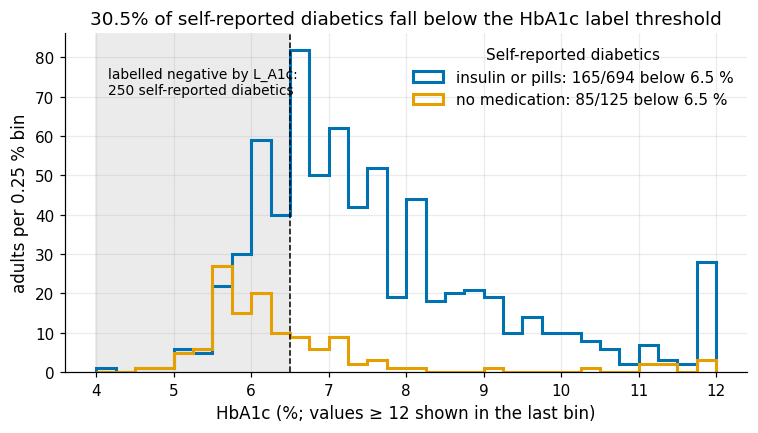

In [125]:
# Treatment masking (§5.2): how many HbA1c-negative self-reported diabetics are on insulin or pills?
# Reads d (on_med, L_self, L_A1c, LBXGH); medication is used for this audit only, never as a feature.
sr = d[d["L_self"] == 1]
# Controlled-looking group: reports diabetes, but HbA1c is below the 6.5 % label threshold.
ctrl = sr[sr["L_A1c"] == 0]
n_ctrl, n_ctrl_med = len(ctrl), int(ctrl["on_med"].sum())
unmed = ctrl[ctrl["on_med"] == 0]
# 5.7-6.49 % is the prediabetes range: untreated cases there suggest early or lifestyle-controlled disease.
n_unmed_pre = int(unmed["LBXGH"].between(5.7, 6.49).sum())
on_med = sr[sr["on_med"] == 1]
share_med_below = float((on_med["L_A1c"] == 0).mean())
print(f"self-reported diabetics: {len(sr)}; HbA1c < 6.5: {n_ctrl} ({pct(n_ctrl / len(sr))})")
print(f"  of these on insulin or pills: {n_ctrl_med} ({pct(n_ctrl_med / n_ctrl, 0)}); untreated: {len(unmed)}, "
      f"of whom {n_unmed_pre} have HbA1c 5.7-6.4")
print(f"treated self-reported diabetics: {len(on_med)}; HbA1c < 6.5 among them: {pct(share_med_below)}")
print("\nHbA1c (%) of self-reported diabetics by treatment")
print(sr.groupby(sr["on_med"].map({1: "insulin or pills", 0: "no medication"}))["LBXGH"]
      .describe(percentiles=[.25, .5, .75]).round(2))
# Guard: masking counts (below 6.5, treated among them, untreated, prediabetes range, all treated) match the
# reference.
assert (n_ctrl, n_ctrl_med, len(unmed), n_unmed_pre, len(on_med)) == (250, 165, 85, 50, 694)
close(n_ctrl / len(sr), 0.305, 0.001, "masking share")
close(share_med_below, 0.238, 0.001, "treated with HbA1c < 6.5")

# Figure: HbA1c histograms of self-reported diabetics by treatment; shaded area = below the label threshold.
fig, ax = plt.subplots(figsize=(8, 4))
# 0.25 % bins from 4 to 12; values above 12 are clipped into the last bin (see the axis label).
bins = np.arange(4.0, 12.01, 0.25)
ax.axvspan(4.0, C.HBA1C_DIABETES, color="0.92", zorder=0)
for flag, lab, col in [(1, "insulin or pills", plots.PALETTE[4]), (0, "no medication", plots.PALETTE[0])]:
    x = sr.loc[sr["on_med"] == flag, "LBXGH"].clip(upper=11.99)
    below = int((x < C.HBA1C_DIABETES).sum())
    ax.hist(x, bins=bins, histtype="step", lw=2, color=col, label=f"{lab}: {below}/{len(x)} below 6.5 %")
ax.axvline(C.HBA1C_DIABETES, color="k", ls="--", lw=1)
ax.text(4.15, ax.get_ylim()[1] * 0.9, f"labelled negative by L_A1c:\n{n_ctrl} self-reported diabetics", fontsize=9, va="top")
ax.set(xlabel="HbA1c (%; values ≥ 12 shown in the last bin)", ylabel="adults per 0.25 % bin",
       title=f"{pct(n_ctrl / len(sr))} of self-reported diabetics fall below the HbA1c label threshold")
ax.legend(loc="upper right", title="Self-reported diabetics")
plots.savefig(fig, "S5_a1c_by_medication",
              caption=f"HbA1c distribution of the {len(sr)} self-reported diabetics by current insulin/pill use. "
                      f"{n_ctrl} ({pct(n_ctrl / len(sr))}) are below 6.5 %, {n_ctrl_med} of them treated.")
plt.show()

# Store the results and register the finding.
RES["masking"] = {"self_reported": len(sr), "below_6_5": n_ctrl, "below_6_5_share": n_ctrl / len(sr),
                  "below_6_5_on_med": n_ctrl_med, "below_6_5_untreated": len(unmed),
                  "untreated_5_7_to_6_4": n_unmed_pre, "treated": len(on_med),
                  "treated_below_6_5_share": share_med_below}
register("DR-S5-03", "label_bias",
         "Treatment masks diabetes in HbA1c: an HbA1c-only label turns controlled patients into negatives",
         "figures/S5_a1c_by_medication.png; §5.2",
         f"{n_ctrl}/{len(sr)} ({pct(n_ctrl / len(sr))}) self-reported diabetics have HbA1c<6.5; {n_ctrl_med} of them on medication; "
         f"{pct(share_med_below)} of treated patients below 6.5",
         "Reject L_A1c as the sole target; keep stratum D_controlled as a 3x3 evaluation column; medication is audit-only (post-diagnosis)",
         "HbA1c-only target; medication as a feature (leakage by the availability rule)")

**So what.** 250 of 819 self-reported diabetics (30.5 %) are below the HbA1c threshold, and 165 of these
(66 %) take insulin or pills; among all 694 treated patients 23.8 % are "controlled". The remaining 85 are
untreated, 50 of them in the prediabetes range (5.7–6.4 %), consistent with lifestyle-controlled or
early disease. An HbA1c-only label would therefore count successful treatment as absence of disease: this is
the *D_controlled* column of the 3×3 label matrix (§8.6).

## 5.3 What "undiagnosed" means

**Why.** The 152 adults with HbA1c ≥ 6.5 % who do not report diabetes are the population the screening use case
is about (E-SCREEN). "Undiagnosed" is easily read as "never saw a doctor". DIQ010 = 3 (borderline), DIQ180
(blood test for high blood sugar in the past three years) and DIQ160 (told prediabetes) show whether they
had contact with the system. Counts are unweighted; shares among the undiagnosed are also weighted with
Korn–Graubard intervals.

In [126]:
# What 'undiagnosed' means (§5.3): borderline answers and health-system contact of HbA1c-positive
# non-reporters.
# Reads d (DIQ010, DIQ160, DIQ180, stratum_3x3); writes the contact table; asserts counts and the weighted
# share.
# DIQ010 coding: 1 yes, 2 no, 3 borderline. Compare how often HbA1c reaches 6.5 in the borderline and 'no'
# groups.
bl = d["DIQ010"].eq(3)
no = d["DIQ010"].eq(2)
p_bl, p_no = d.loc[bl, "L_A1c"].mean(), d.loc[no, "L_A1c"].mean()
print(f"DIQ010 = 3 (borderline): {int(bl.sum())}; HbA1c >= 6.5: {int(d.loc[bl, 'L_A1c'].sum())} ({pct(p_bl)}) "
      f"vs DIQ010 = 2: {pct(p_no)}")
# Undiagnosed = HbA1c-positive without a self-reported diagnosis (a 3x3 stratum); the mask is kept for domain
# estimates.
und_mask = (d["stratum_3x3"] == "Undiagnosed").to_numpy()
und = d[und_mask]
# Three contact indicators among the undiagnosed; all are post-test information, so they stay audit-only.
care = {
    "told borderline (DIQ010=3)": und["DIQ010"].eq(3),
    "blood test past 3 years (DIQ180=1)": und["DIQ180"].eq(1),
    "told prediabetes (DIQ160=1)": und["DIQ160"].eq(1),
}
rows = []
for name, s in care.items():
    # y is defined on the whole cohort but NaN outside the domain; `domain=` keeps every PSU and stratum in
    # the jackknife.
    y = np.where(und_mask, d.index.isin(s[s].index), np.nan)
    w = S.weighted_prop(d, y.astype(float), weight=WT, domain=und_mask)
    rows.append({"contact": name, "n": int(s.sum()), "of": len(und), "share": s.sum() / len(und),
                 "w_est": w["est"], "kg_low": w["kg_low"], "kg_high": w["kg_high"], "df": w["df"],
                 "flags": ";".join(w["nchs_flags"]), "nchs": nchs_label(w)})
care_tab = pd.DataFrame(rows)
print(care_tab.round(3).to_string(index=False))
print(f"DIQ180 missing among undiagnosed: {int(und['DIQ180'].isna().sum())}; DIQ160 missing: {int(und['DIQ160'].isna().sum())} "
      "(borderline respondents skip DIQ160)")
# Guards on the unweighted counts: borderline n, borderline HbA1c-positives, undiagnosed n and per-indicator
# n.
assert int(bl.sum()) == 213 and int(d.loc[bl, "L_A1c"].sum()) == 36 and len(und) == 152
assert care_tab["n"].tolist() == [36, 104, 48]
close(p_bl, 0.169, 0.001, "borderline A1c+ share")
close(p_no, 0.025, 0.001, "DIQ010=2 A1c+ share")
CT = care_tab.set_index("contact")
t180 = CT.loc["blood test past 3 years (DIQ180=1)"]
close(t180["w_est"], 0.625, 0.0015, "DIQ180 weighted share")
print(f"population estimate (WTPH2YR): {pct(t180['w_est'])} of undiagnosed adults had a blood test in the past 3 years "
      f"(KG {pct(t180['kg_low'])}-{pct(t180['kg_high'])}); unweighted sample share {pct(t180['share'])}")
care_tab.to_csv(OUT / "undiagnosed_care_contact.csv", index=False)
RES["undiagnosed_meaning"] = {"borderline_n": int(bl.sum()), "borderline_a1c_pos": int(d.loc[bl, "L_A1c"].sum()),
                              "borderline_a1c_share": p_bl, "no_a1c_share": p_no, "undiagnosed": len(und),
                              "contact": care_tab.set_index("contact")[["n", "share", "w_est", "kg_low", "kg_high"]].to_dict("index")}
register("DR-S5-04", "label_semantics",
         "Most undiagnosed adults had contact with the health system: the gap is diagnosis/communication, not only access",
         "results/S5/undiagnosed_care_contact.csv; §5.3",
         f"undiagnosed adults blood-tested in past 3 y: {pct(t180['w_est'])} weighted (KG {pct(t180['kg_low'])}-{pct(t180['kg_high'])}; "
         f"sample 104/152 = 68%); 36/152 told borderline; 48 told prediabetes",
         "Frame E-SCREEN positives as 'not diagnosed despite contact'; DIQ160/DIQ180 excluded as features (post-test information); borderline kept negative in L_comb and flagged",
         "Describe undiagnosed as 'no access to care'; use DIQ180 as a screening feature")

DIQ010 = 3 (borderline): 213; HbA1c >= 6.5: 36 (16.9%) vs DIQ010 = 2: 2.5%
                           contact   n  of  share  w_est  kg_low  kg_high  df flags                nchs
        told borderline (DIQ010=3)  36 152  0.237  0.235   0.165    0.318  14       meets NCHS standard
blood test past 3 years (DIQ180=1) 104 152  0.684  0.625   0.535    0.709  14       meets NCHS standard
       told prediabetes (DIQ160=1)  48 152  0.316  0.306   0.227    0.395  14       meets NCHS standard
DIQ180 missing among undiagnosed: 2; DIQ160 missing: 37 (borderline respondents skip DIQ160)
population estimate (WTPH2YR): 62.5% of undiagnosed adults had a blood test in the past 3 years (KG 53.5%-70.9%); unweighted sample share 68.4%


**So what.** Borderline respondents are almost seven times as likely to be HbA1c-positive as those answering "no"
(16.9 % vs 2.5 %). An estimated 62.5 % (weighted, WTPH2YR; KG 53.5–70.9 %) of undiagnosed adults had a blood-sugar
test in the past three years (unweighted: 104 of 152 = 68 %); 36 were told they were borderline and 48 that they had
prediabetes. "Undiagnosed" is mostly a diagnosis and communication gap; DIQ160 and DIQ180 record a glucose-test
result and are excluded as features.

## 5.4 Who is undiagnosed

**Why.** If the undiagnosed share differs by insurance, access or race, `L_self` is a biased label. Domain: adults with
HbA1c ≥ 6.5 % (n = 721); outcome: not self-reported. Proportions get Korn–Graubard intervals and the NCHS flags
(*exploratory* when n or effective n < 30 or the CI is too wide; Parker et al. 2017). The headline is the risk
difference (WTPH2YR, jackknife) on the joint domain's df, with the smaller group's own df as a conservative check.

In [127]:
# Who is undiagnosed (§5.4): undiagnosed share by insurance, usual place of care and race among HbA1c >= 6.5.
# Computes KG proportions with NCHS flags and jackknife risk differences; asserts values, df and the H1a rule.
# Outcome: 1 if an HbA1c-positive adult does not self-report diabetes (the domain is restricted to a1c_dom
# later).
d["undx"] = 1.0 - d["L_self"]
# HIQ011: 1 = covered, 2 = not covered; refused/don't-know codes stay NaN and drop out of the domain.
d["uninsured"] = np.select([d["HIQ011"].eq(2), d["HIQ011"].eq(1)], [1.0, 0.0], np.nan)
# HUQ030 (usual place of care): 2 = none -> 1; 1 = one place or 3 = several places -> 0; other codes stay NaN.
d["no_usual_place"] = np.select([d["HUQ030"].eq(2), d["HUQ030"].isin([1, 3])], [1.0, 0.0], np.nan)
# Domain mask: HbA1c-positive adults. All rows are kept so that the jackknife retains every stratum and PSU.
a1c_dom = d["L_A1c"].eq(1).to_numpy()


def risk_difference(df, y, ga, gb, weight=WT):
    """Weighted risk difference p(a) - p(b) with JK CI (df = NCHS domain df of a or b)."""
    yv = df[y].to_numpy(float)
    ok = ~np.isnan(yv)
    a, b = np.asarray(ga) & ok, np.asarray(gb) & ok
    y0 = np.nan_to_num(yv)

    # stat_fn(df, w): the jackknife re-calls this with replicate weights; masks a and b select the two groups.
    def f(_d, w):
        return np.dot(w * a, y0) / np.sum(w * a) - np.dot(w * b, y0) / np.sum(w * b)
    # df_override: the contrast's degrees of freedom come from the joint domain a | b, not from the whole
    # design.
    return S.jackknife(df, f, weight=weight, df_override=S.domain_df(df, a | b))


contrasts = [  # (name, column, level a, level b, label a, label b)
    ("uninsured - insured", "uninsured", 1.0, 0.0, "uninsured", "insured"),
    ("no usual place - usual place", "no_usual_place", 1.0, 0.0, "no usual place", "usual place"),
    ("NH Asian - NH White", "RIDRETH3", 6, 3, "NH Asian", "NH White"),
]
# For each contrast: KG proportions for both groups plus the weighted risk difference with its jackknife CI.
prop_rows, rd_rows = [], []
for name, col, a, b, la, lb in contrasts:
    for lev, lab in [(a, la), (b, lb)]:
        r = S.weighted_prop(d, "undx", weight=WT, domain=a1c_dom & d[col].eq(lev).to_numpy())
        prop_rows.append({"group": lab, "contrast": name, **{k: r[k] for k in
                          ("n", "n_events", "est", "kg_low", "kg_high", "ci_width", "n_eff", "df")},
                          "nchs": nchs_label(r), "nchs_status": r["nchs_status"], "flags": ";".join(r["nchs_flags"])})
    rd = risk_difference(d, "undx", a1c_dom & d[col].eq(a).to_numpy(), a1c_dom & d[col].eq(b).to_numpy())
    rd_rows.append({"contrast": name, "rd_pp": 100 * rd["est"], "ci_low_pp": 100 * rd["ci_low"],
                    "ci_high_pp": 100 * rd["ci_high"], "df": rd["df"]})
# One row per group; drop_duplicates is a safeguard in case a group is reused across contrasts.
props = pd.DataFrame(prop_rows).drop_duplicates("group")
rds = pd.DataFrame(rd_rows)
print("Undiagnosed share among HbA1c >= 6.5 (WTPH2YR, Korn-Graubard)")
print(props.drop(columns="flags").round(3).to_string(index=False))
print("\nRisk differences (percentage points, JK CI)")
print(rds.round(1).to_string(index=False))

# Reference asserts for proportions, KG bounds and domain df (the insurance and care groups share a small df).
P = props.set_index("group")
close(P.loc["uninsured", "est"], 0.430, 0.0015, "uninsured share"); assert P.loc["uninsured", "n"] == 49
close(P.loc["uninsured", "kg_low"], 0.242, 0.002, "uninsured KG low"); close(P.loc["uninsured", "kg_high"], 0.635, 0.002, "uninsured KG high")
assert P.loc["uninsured", "df"] == 9 and P.loc["no usual place", "df"] == 9
close(P.loc["insured", "est"], 0.199, 0.0015, "insured share")
close(P.loc["no usual place", "est"], 0.403, 0.0015, "no usual place share"); assert P.loc["no usual place", "n"] == 41
close(P.loc["NH Asian", "est"], 0.362, 0.0015, "Asian share"); assert P.loc["NH Asian", "n"] == 40 and P.loc["NH Asian", "df"] == 4
close(P.loc["NH Asian", "kg_low"], 0.131, 0.002, "Asian KG low"); close(P.loc["NH Asian", "kg_high"], 0.652, 0.002, "Asian KG high")
# All three small-group proportions must carry the NCHS 'suppress' flag (KG interval wider than the NCHS
# maximum).
for g in ("uninsured", "no usual place", "NH Asian"):
    assert P.loc[g, "ci_width"] >= C.NCHS_CI_WIDTH_MAX and P.loc[g, "nchs_status"] == "suppress"
assert P.loc["insured", "nchs"] == "meets NCHS standard"
RD = rds.set_index("contrast")
# Reference risk differences (estimate, low, high in pp); tolerance 0.06 pp = rounding to one decimal.
for name, (e, lo, hi) in {"uninsured - insured": (23.2, 6.2, 40.1), "no usual place - usual place": (19.9, -1.6, 41.5),
                          "NH Asian - NH White": (15.6, -5.7, 36.9)}.items():
    close(RD.loc[name, "rd_pp"], e, 0.06, name); close(RD.loc[name, "ci_low_pp"], lo, 0.06, name + " low")
    close(RD.loc[name, "ci_high_pp"], hi, 0.06, name + " high")

# Degrees of freedom of the contrast. The jackknife uses the domain "group a or group b", which here spans all
# strata (df shown above). The smaller group alone has fewer df (uninsured: 9), so as a conservative check the
# same standard error is combined with the t-quantile of the smaller group's domain df.
# Conservative check: same SE, but the t quantile uses the smaller group's own df (fewer df -> wider
# interval).
rd_df = []
for name, col, a, b, la, lb in contrasts:
    r_ = RD.loc[name]
    # Back out the SE from the stored 95% half-width: (high - low) / (2 * t_{0.975, df}).
    se_ = (r_["ci_high_pp"] - r_["ci_low_pp"]) / (2 * stats.t.ppf(0.975, r_["df"]))
    df_min = int(min(P.loc[la, "df"], P.loc[lb, "df"]))
    t_min = stats.t.ppf(0.975, df_min)
    rd_df.append({"contrast": name, "rd_pp": r_["rd_pp"], "df_contrast_domain": int(r_["df"]), "ci_low_pp": r_["ci_low_pp"],
                  "ci_high_pp": r_["ci_high_pp"], "df_smaller_group": df_min,
                  "ci_low_pp_conservative": r_["rd_pp"] - t_min * se_, "ci_high_pp_conservative": r_["rd_pp"] + t_min * se_})
rd_df = pd.DataFrame(rd_df)
display(rd_df.round(1))
RDC = rd_df.set_index("contrast")
# Guards: the smaller group's df is as stated, and the conservative lower bound of the insurance contrast
# stays > 0.
assert RDC.loc["uninsured - insured", "df_smaller_group"] == 9
assert RDC.loc["uninsured - insured", "ci_low_pp_conservative"] > 0      # H1a rule holds with either df

Undiagnosed share among HbA1c >= 6.5 (WTPH2YR, Korn-Graubard)


         group                     contrast   n  n_events   est  kg_low  kg_high  ci_width   n_eff  df                                     nchs nchs_status
     uninsured          uninsured - insured  49        18 0.430   0.242    0.635     0.393  33.776   9 exploratory, does not meet NCHS standard    suppress
       insured          uninsured - insured 670       133 0.199   0.157    0.246     0.088 392.084  15                      meets NCHS standard     present
no usual place no usual place - usual place  41        17 0.403   0.200    0.633     0.433  26.951   9 exploratory, does not meet NCHS standard    suppress
   usual place no usual place - usual place 680       135 0.203   0.158    0.256     0.098 327.872  15                      meets NCHS standard     present
      NH Asian          NH Asian - NH White  40        12 0.362   0.131    0.652     0.520  26.575   4 exploratory, does not meet NCHS standard    suppress
      NH White          NH Asian - NH White 362        74 0.206

,contrast,rd_pp,df_contrast_domain,ci_low_pp,ci_high_pp,df_smaller_group,ci_low_pp_conservative,ci_high_pp_conservative
0,uninsured - insured,23.2,15,6.2,40.1,9,5.2,41.1
1,no usual place - usual place,19.9,15,-1.6,41.5,9,-2.9,42.8
2,NH Asian - NH White,15.6,15,-5.7,36.9,4,-12.1,43.4


**Adjusted models.** Each exposure gets **its own** logistic model of "undiagnosed" among HbA1c-positive adults, with
the adjustment set the §4.8 DAG identifies:

| Exposure | Adjustment set (§4.8 DAG) | Not adjusted for, and why |
|---|---|---|
| uninsured | age, sex, SES (PIR + missing-PIR indicator) | usual place of care: a *mediator* (insurance → usual care → diagnosis) |
| no usual place of care | age, sex, SES (PIR + missing-PIR indicator) | insurance: an ancestor whose back-door paths age and SES already close |
| NH Asian (vs NH White) | age, sex | SES and BMI: *mediators* of race |

Each model is fitted unweighted and WTPH2YR-weighted (jackknife); a mutually adjusted model would adjust insurance for
its own mediator.

In [128]:
# Adjusted logistic models per exposure (§5.4), fitted unweighted and WTPH2YR-weighted (jackknife).
# Reads d; builds the covariates; asserts n per model and that every odds ratio points the same way as its
# crude RD.
# Race levels with NH White first, so that it becomes the reference category in the formula.
RACE_LEVELS = ["NH White", *[r for r in RACE.values() if r != "NH White"]]
# Age in decades: the coefficient is per 10 years, a more readable scale.
d["age10"] = d["RIDAGEYR"] / 10
d["male"] = d["RIAGENDR"].eq(1).astype(float)
# Median-impute the income ratio; the pir_miss indicator in the formulas flags the imputed rows.
d["pir"] = d["INDFMPIR"].fillna(d["INDFMPIR"].median())
d["race_cat"] = pd.Categorical(d["race3"], categories=RACE_LEVELS)
ADJ_MODELS = [  # (exposure label, coefficient, formula, adjustment set)
    ("uninsured", "uninsured", "undx ~ uninsured + age10 + male + pir + pir_miss", "age, sex, PIR (+ pir_miss)"),
    ("no usual place", "no_usual_place", "undx ~ no_usual_place + age10 + male + pir + pir_miss", "age, sex, PIR (+ pir_miss)"),
    ("NH Asian", "race_cat[T.NH Asian]", "undx ~ race_cat + age10 + male", "age, sex"),
]


def _wlogit(form, term, mask):
    """stat_fn for survey.jackknife: weighted logit coefficient of `term` on rows with mask & w > 0."""
    def f(df, w):
        m = mask & (w > 0)
        # Silence per-replicate fit warnings (each of the many replicate fits would otherwise print them).
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            # freq_weights rescaled to mean 1: the point estimate is unchanged and the sample size is not
            # inflated.
            fit_w = smf.glm(form, data=df[m], family=sm.families.Binomial(), freq_weights=w[m] / w[m].mean()).fit()
        return fit_w.params[term]
    return f


# One model per exposure, each with its own DAG-based adjustment set (see the table above).
adj_rows = []
for lab, term, form, adj in ADJ_MODELS:
    # `term` can be a patsy level name such as race_cat[T.NH Asian]; strip it to get the data column.
    col = term.split("[")[0]
    # cc = HbA1c-positive adults with complete exposure and covariates; the same rows feed both fits.
    cc = a1c_dom & d[[col, "age10", "male", "pir", "pir_miss"]].notna().all(axis=1).to_numpy()
    fit = smf.logit(form, data=d[cc]).fit(disp=0)
    ci = fit.conf_int().loc[term]
    # df_override: domain df of the modelled rows, so the t quantile reflects the PSUs actually available.
    jk = S.jackknife(d, _wlogit(form, term, cc), weight=WT, df_override=S.domain_df(d, cc))
    adj_rows.append({"exposure": lab, "adjustment_set": adj, "n": int(cc.sum()), "events": int(d.loc[cc, "undx"].sum()),
                     "OR": np.exp(fit.params[term]), "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]),
                     "OR_w": np.exp(jk["est"]), "w_ci_low": np.exp(jk["ci_low"]), "w_ci_high": np.exp(jk["ci_high"]),
                     "df": jk["df"], "formula": form})
logit_tab = pd.DataFrame(adj_rows)
print(f"domain: {int(a1c_dom.sum())} adults with HbA1c >= 6.5; PIR missing for {int(d.loc[a1c_dom, 'pir_miss'].sum())} "
      f"(indicator); unknown insurance: {int(d.loc[a1c_dom, 'uninsured'].isna().sum())}")
print(logit_tab.drop(columns="formula").round(2).to_string(index=False))
LT = logit_tab.set_index("exposure")
assert LT["n"].tolist() == [719, 721, 721]
# Does a 95% interval exclude the null odds ratio of 1?
excl = lambda lo, hi: lo > 1 or hi < 1   # noqa: E731
LT["unweighted_excludes_1"] = [excl(lo, hi) for lo, hi in zip(LT["ci_low"], LT["ci_high"])]
LT["weighted_excludes_1"] = [excl(lo, hi) for lo, hi in zip(LT["w_ci_low"], LT["w_ci_high"])]
display(LT[["unweighted_excludes_1", "weighted_excludes_1"]])
assert (LT[["OR", "OR_w"]] > 1).all().all()          # every exposure points in the same direction as its crude RD
# Pre-stated expectations: insurance excludes 1 in both fits, NH Asian in neither, usual place disagrees.
assert LT.loc["uninsured", "unweighted_excludes_1"] and LT.loc["uninsured", "weighted_excludes_1"]
assert not LT.loc["NH Asian", "unweighted_excludes_1"] and not LT.loc["NH Asian", "weighted_excludes_1"]
assert LT.loc["no usual place", "unweighted_excludes_1"] and not LT.loc["no usual place", "weighted_excludes_1"]  # fits disagree

domain: 721 adults with HbA1c >= 6.5; PIR missing for 93 (indicator); unknown insurance: 2
      exposure             adjustment_set   n  events   OR  ci_low  ci_high  OR_w  w_ci_low  w_ci_high  df
     uninsured age, sex, PIR (+ pir_miss) 719     151 2.22    1.18     4.18  2.90      1.48       5.67  15
no usual place age, sex, PIR (+ pir_miss) 721     152 2.76    1.43     5.33  2.52      0.89       7.09  15
      NH Asian                   age, sex 721     152 1.67    0.81     3.44  2.18      0.84       5.62  15


,unweighted_excludes_1,weighted_excludes_1
exposure,,
uninsured,True,True
no usual place,True,False
NH Asian,False,False


**Reading the models (Table-2 caveat).** Each odds ratio is the estimate for *its own* exposure only. The
coefficients of the adjustment covariates (age, sex, PIR) in the same fits are not effects and are therefore not
shown: they are themselves confounded or partly mediated (Westreich & Greenland 2013, "Table 2 fallacy").
The odds ratios are associations under the assumed DAG, not causal effects of insurance or care.

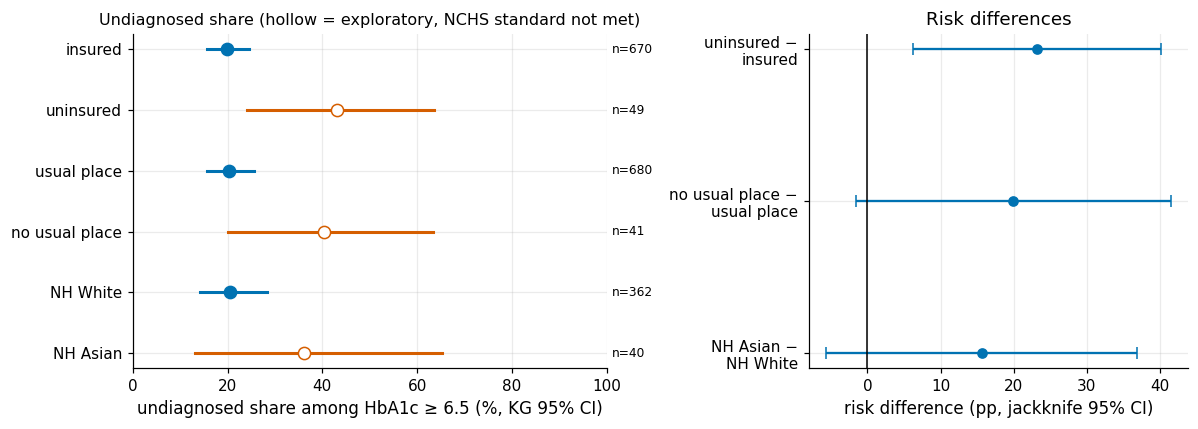

In [129]:
# Figure for §5.4: undiagnosed share by group (left) and risk differences with jackknife CI (right).
# Reads P and rds from the cells above; writes the figure and the §5.4 CSVs.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.25, 1]})
order = ["insured", "uninsured", "usual place", "no usual place", "NH White", "NH Asian"]
pp = P.loc[order]
yy = np.arange(len(order))[::-1]
for yi, (g, r) in zip(yy, pp.iterrows()):
    # Hollow marker = fails the NCHS presentation standard (exploratory).
    expl = r["nchs"].startswith("exploratory")
    col = plots.PALETTE[5] if expl else plots.PALETTE[4]
    ax1.plot([r["kg_low"] * 100, r["kg_high"] * 100], [yi, yi], color=col, lw=2)
    ax1.plot(r["est"] * 100, yi, "o", color=col, mfc="white" if expl else col, ms=8)
    ax1.text(101, yi, f"n={int(r['n'])}", va="center", fontsize=8)
ax1.set_yticks(yy, order)
ax1.set(xlim=(0, 100), xlabel="undiagnosed share among HbA1c ≥ 6.5 (%, KG 95% CI)",
        title="Undiagnosed share (hollow = exploratory, NCHS standard not met)")
ax1.title.set_fontsize(10.5)
yr = np.arange(len(rds))[::-1]
ax2.errorbar(rds["rd_pp"], yr, xerr=[rds["rd_pp"] - rds["ci_low_pp"], rds["ci_high_pp"] - rds["rd_pp"]],
             fmt="o", color=plots.PALETTE[4], capsize=4)
ax2.axvline(0, color="k", lw=1)
ax2.set_yticks(yr, [c.replace(" - ", " −\n") for c in rds["contrast"]])
ax2.set(xlabel="risk difference (pp, jackknife 95% CI)", title="Risk differences")
fig.tight_layout()
plots.savefig(fig, "S5_undiagnosed_inequality",
              caption="Share of HbA1c-positive adults who do not report diabetes (WTPH2YR, Korn-Graubard CI) and risk "
                      "differences with delete-one-PSU jackknife CI. Hollow markers: fails the NCHS presentation standard (exploratory).")
plt.show()

# Persist the tables and stash results for the final write-out in §5.9.
props.to_csv(OUT / "undiagnosed_by_group.csv", index=False)
rds.to_csv(OUT / "undiagnosed_risk_differences.csv", index=False)
logit_tab.to_csv(OUT / "undiagnosed_logit.csv", index=False)
RES["undiagnosed_inequality"] = {
    "proportions": props.set_index("group").drop(columns=["contrast"]).to_dict("index"),
    "risk_differences_pp": rds.set_index("contrast").to_dict("index"),
    "adjusted_logit": {r["exposure"]: {k: r[k] for k in ("adjustment_set", "formula", "n", "events", "OR", "ci_low", "ci_high",
                                                          "OR_w", "w_ci_low", "w_ci_high", "df")} for r in adj_rows},
}
register("DR-S5-05", "label_bias",
         "Undiagnosed share is higher without insurance or a usual place of care; small cells do not meet NCHS standards",
         "results/S5/undiagnosed_by_group.csv; results/S5/undiagnosed_risk_differences.csv; figures/S5_undiagnosed_inequality.png",
         f"RD uninsured-insured {RD.loc['uninsured - insured', 'rd_pp']:.1f}pp ({RD.loc['uninsured - insured', 'ci_low_pp']:.1f}, "
         f"{RD.loc['uninsured - insured', 'ci_high_pp']:.1f}); uninsured share 43.0% KG width {P.loc['uninsured', 'ci_width']:.2f}; "
         f"DAG-adjusted OR (age, sex, PIR) uninsured {LT.loc['uninsured', 'OR']:.2f} ({LT.loc['uninsured', 'ci_low']:.2f}, "
         f"{LT.loc['uninsured', 'ci_high']:.2f}), weighted {LT.loc['uninsured', 'OR_w']:.2f} ({LT.loc['uninsured', 'w_ci_low']:.2f}, "
         f"{LT.loc['uninsured', 'w_ci_high']:.2f}); no usual place {LT.loc['no usual place', 'OR']:.2f} ({LT.loc['no usual place', 'ci_low']:.2f}, "
         f"{LT.loc['no usual place', 'ci_high']:.2f}), weighted {LT.loc['no usual place', 'OR_w']:.2f} ({LT.loc['no usual place', 'w_ci_low']:.2f}, "
         f"{LT.loc['no usual place', 'w_ci_high']:.2f})",
         "Headline = risk difference with JK CI (df of the contrast domain; conservative df of the smaller group also shown); proportions with KG CI and NCHS flag; insurance and access are audit/stratification variables only; S8 audits L_self vs L_comb by low_access",
         "Report small-cell proportions as headline; drop small groups; put insurance into the model; one mutually adjusted model "
         "(adjusts insurance for its mediator usual care; Table-2 fallacy)")

**So what.** Among HbA1c-positive adults, 43.0 % of the uninsured but 19.9 % of the insured do not know their
diagnosis: a risk difference of +23.2 pp (6.2, 40.1; df 15), which still excludes zero with the uninsured
group's own df of 9 (table above). For no usual place of care (+19.9 pp, −1.6 to 41.5) and NH Asian vs NH
White (+15.6 pp, −5.7 to 36.9) the intervals include zero; all three group proportions are *exploratory*. In
the DAG-guided models, lacking insurance stays associated with being undiagnosed after age, sex and income
(OR 2.2 unweighted, 2.9 weighted; both CIs exclude 1); for no usual place the fits disagree (weighted OR 2.5,
0.9–7.1). `L_self` thus under-counts disease where access is poorer, hence the union target `L_comb`.

## 5.5 BMI as a biased measurement of adiposity in Asian adults

**Why.** BMI is the main adiposity feature of any non-laboratory screening model, but Asian adults develop diabetes at
lower BMI (Araneta et al. 2015; WHO Expert Consultation 2004): a possible *feature-level* measurement bias. NH Asian
and NH White adults are compared on the BMI of diabetics, prevalence by BMI band, single-feature AUC of BMI, waist and
waist-to-height ratio (WHtR, paired bootstrap of the gain) and the sensitivity of the BMI ≥ 25 / ≥ 23 cut-offs
(unweighted measurement properties).

In [130]:
# BMI as a measurement of adiposity in Asian vs White adults: BMI < 25 among diabetics, prevalence by band
# (§5.5).
# Reads d; asserts counts and 3-decimal reference values; thin bands are flagged by their NCHS status.
grp = {"NH Asian": 6, "NH White": 3}
bmi_dm = []
for g, code in grp.items():
    # L_comb diabetics in the group with a BMI value (missing BMI is excluded from the denominator).
    dm = d[(d["RIDRETH3"] == code) & (d["L_comb"] == 1) & d["BMXBMI"].notna()]
    # k = diabetics with BMI below 25, i.e. cases a 'BMI >= 25' screening rule would miss.
    k = int((dm["BMXBMI"] < 25).sum())
    # Weighted share by domain estimation; missing BMI becomes NaN so that it drops out of the proportion.
    w = S.weighted_prop(d, (d["BMXBMI"] < 25).astype(float).where(d["BMXBMI"].notna()), weight=WT,
                        domain=((d["RIDRETH3"] == code) & (d["L_comb"] == 1)).to_numpy())
    bmi_dm.append({"group": g, "bmi_lt25": k, "diabetics_with_bmi": len(dm), "share": k / len(dm),
                   "median_bmi": dm["BMXBMI"].median(), "w_share": w["est"], "kg_low": w["kg_low"], "kg_high": w["kg_high"]})
bmi_dm = pd.DataFrame(bmi_dm).set_index("group")
print("BMI < 25 among L_comb diabetics (denominator excludes missing BMI)")
print(bmi_dm.round(3))
assert (bmi_dm.loc["NH Asian", "bmi_lt25"], bmi_dm.loc["NH Asian", "diabetics_with_bmi"]) == (24, 47)
close(bmi_dm.loc["NH Asian", "share"], 0.511, 0.001, "Asian BMI<25"); close(bmi_dm.loc["NH White", "share"], 0.072, 0.001, "White BMI<25")

# Bands: 23 = lower action point proposed for Asian adults (WHO 2004), 25 = overweight, 30 = obesity.
BANDS = [0, 23, 25, 30, 200]
BLAB = ["<23", "23–24.9", "25–29.9", "≥30"]
# right=False gives intervals [lo, hi); 200 is simply an open upper bound.
d["bmi_band"] = pd.cut(d["BMXBMI"], BANDS, right=False, labels=BLAB)
band_rows = []
for g, code in grp.items():
    for b in BLAB:
        m = ((d["RIDRETH3"] == code) & (d["bmi_band"] == b)).to_numpy()
        w = S.weighted_prop(d, "L_comb", weight=WT, domain=m)
        band_rows.append({"group": g, "bmi_band": b, "n": int(m.sum()), "cases": int(d.loc[m, "L_comb"].sum()),
                          "prev": d.loc[m, "L_comb"].mean(), "w_prev": w["est"], "kg_low": w["kg_low"],
                          "kg_high": w["kg_high"], "ci_width": w["ci_width"], "df": w["df"],
                          "nchs_status": w["nchs_status"], "flags": ";".join(w["nchs_flags"])})
bands = pd.DataFrame(band_rows)
print("\nL_comb prevalence by BMI band (unweighted and WTPH2YR with KG CI)")
print(bands.round(3).to_string(index=False))
B_ = bands.set_index(["group", "bmi_band"])
# Count the Asian BMI bands whose weighted estimate fails the NCHS presentation standard.
n_flag_asian = int((bands.loc[bands["group"] == "NH Asian", "nchs_status"] != "present").sum())
print(f"NH Asian BMI bands failing the NCHS presentation standard: {n_flag_asian} of {len(BLAB)}")
# Guard: most Asian band estimates must stay exploratory, so the text may not present them as precise.
assert n_flag_asian >= 3
# Reference prevalences (unweighted 'prev' and weighted 'w_prev') per group and band, tolerance 0.001.
close(B_.loc[("NH Asian", "<23"), "prev"], 0.121, 0.001, "Asian <23"); close(B_.loc[("NH White", "<23"), "prev"], 0.043, 0.001, "White <23")
close(B_.loc[("NH Asian", "23–24.9"), "prev"], 0.175, 0.001, "Asian 23-25"); close(B_.loc[("NH White", "23–24.9"), "prev"], 0.033, 0.001, "White 23-25")
close(B_.loc[("NH Asian", "25–29.9"), "prev"], 0.115, 0.001, "Asian 25-30"); close(B_.loc[("NH Asian", "25–29.9"), "w_prev"], 0.053, 0.001, "Asian 25-30 weighted")
close(B_.loc[("NH Asian", "<23"), "w_prev"], 0.078, 0.001, "Asian <23 weighted"); close(B_.loc[("NH Asian", "23–24.9"), "w_prev"], 0.140, 0.001, "Asian 23-25 weighted")

BMI < 25 among L_comb diabetics (denominator excludes missing BMI)
          bmi_lt25  diabetics_with_bmi  share  median_bmi  w_share  kg_low  kg_high
group                                                                              
NH Asian        24                  47  0.511        24.9    0.501   0.255    0.747
NH White        35                 488  0.072        32.7    0.067   0.045    0.096



L_comb prevalence by BMI band (unweighted and WTPH2YR with KG CI)
   group bmi_band    n  cases  prev  w_prev  kg_low  kg_high  ci_width  df nchs_status                  flags
NH Asian      <23  107     13 0.121   0.078   0.028    0.167     0.139   9    suppress      rel_ci_width>130%
NH Asian  23–24.9   63     11 0.175   0.140   0.049    0.291     0.242   5    suppress rel_ci_width>130%;df<8
NH Asian  25–29.9   96     11 0.115   0.053   0.014    0.133     0.119   8    suppress      rel_ci_width>130%
NH Asian      ≥30   44     12 0.273   0.284   0.104    0.536     0.431   5    suppress    ci_width>=0.30;df<8
NH White      <23  485     21 0.043   0.033   0.018    0.055     0.037  15     present                       
NH White  23–24.9  423     14 0.033   0.028   0.012    0.052     0.040  15     present                       
NH White  25–29.9 1092    127 0.116   0.096   0.078    0.117     0.039  15     present                       
NH White      ≥30 1370    326 0.238   0.211   0.176  

In [131]:
# Single-feature ROC-AUC of BMI, waist and WHtR per group, with a stratified bootstrap (§5.5).
# Produces the AUC table `roc` and the bootstrap draws `boot_store`; asserts values and a positive Asian gain
# CI.
# Candidate adiposity measures; WHtR = waist-to-height ratio.
FEATS = {"BMI": "BMXBMI", "waist": "BMXWAIST", "WHtR": "whtr"}
# Number of bootstrap replicates (smaller outside the FINAL run).
B = C.N_BOOT
# Seed derived from the master seed plus a fixed label: reproducible and independent of other cells.
rng = np.random.default_rng(E.derive_seed(C.SEED_MASTER, "S5", "auc_bootstrap"))

# AUC of each feature for L_comb plus the paired gain (WHtR AUC - BMI AUC) on rows where both exist.

def auc_set(g):
    out = {}
    for f, col in FEATS.items():
        ok = g[col].notna()
        out[f] = roc_auc_score(g.loc[ok, "L_comb"], g.loc[ok, col])
    # The gain uses only rows with both BMI and WHtR, so both AUCs are computed on the same people.
    both = g["BMXBMI"].notna() & g["whtr"].notna()
    out["gain"] = (roc_auc_score(g.loc[both, "L_comb"], g.loc[both, "whtr"])
                   - roc_auc_score(g.loc[both, "L_comb"], g.loc[both, "BMXBMI"]))
    return out


roc_rows, boot_store = [], {}
for g, code in grp.items():
    sub = d.loc[d["RIDRETH3"] == code, ["L_comb", *FEATS.values()]].reset_index(drop=True)
    est = auc_set(sub)
    # Positives and negatives are resampled separately in each replicate, so the case count stays fixed.
    pos, neg = np.flatnonzero(sub["L_comb"] == 1), np.flatnonzero(sub["L_comb"] == 0)
    reps = pd.DataFrame([auc_set(sub.iloc[np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])])
                         for _ in range(B)])
    boot_store[g] = reps
    for k in [*FEATS, "gain"]:
        roc_rows.append({"group": g, "measure": k if k != "gain" else "WHtR − BMI (paired)",
                         "n": int(sub[FEATS[k]].notna().sum()) if k in FEATS else int((sub["BMXBMI"].notna() & sub["whtr"].notna()).sum()),
                         "auc": est[k], "ci_low": reps[k].quantile(0.025), "ci_high": reps[k].quantile(0.975)})
roc = pd.DataFrame(roc_rows)
# Difference of the two groups' bootstrap gains; the groups are resampled independently, so draws subtract
# directly.
gain_diff = boot_store["NH Asian"]["gain"] - boot_store["NH White"]["gain"]
print(f"Single-feature ROC-AUC for L_comb (stratified bootstrap, B = {B})")
print(roc.round(3).to_string(index=False))
print(f"Asian minus White WHtR gain: {roc.iloc[3]['auc'] - roc.iloc[7]['auc']:+.3f} "
      f"(bootstrap 95% CI {gain_diff.quantile(.025):+.3f}, {gain_diff.quantile(.975):+.3f})")
RO = roc.set_index(["group", "measure"])
assert gain_diff.quantile(.025) > 0, "Asian WHtR gain no longer exceeds the White gain"
# Reference AUCs and gains; tolerances equal the rounding of the stored reference values.
close(RO.loc[("NH Asian", "BMI"), "auc"], 0.573, 0.001, "Asian BMI AUC")
close(RO.loc[("NH Asian", "waist"), "auc"], 0.697, 0.001, "Asian waist AUC")
close(RO.loc[("NH Asian", "WHtR"), "auc"], 0.714, 0.001, "Asian WHtR AUC")
close(RO.loc[("NH White", "BMI"), "auc"], 0.701, 0.001, "White BMI AUC")
close(RO.loc[("NH White", "WHtR"), "auc"], 0.749, 0.001, "White WHtR AUC")
close(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "auc"], 0.137, 0.0006, "Asian gain")
close(RO.loc[("NH White", "WHtR − BMI (paired)"), "auc"], 0.049, 0.0006, "White gain")
tol_ci = 0.002 if C.IS_FINAL else 0.03   # bootstrap CI bounds: FINAL (B=1000) reproduces 0.093-0.181 / 0.039-0.058
close(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "ci_low"], 0.093, tol_ci, "Asian gain CI low")
close(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "ci_high"], 0.181, tol_ci, "Asian gain CI high")
close(RO.loc[("NH White", "WHtR − BMI (paired)"), "ci_low"], 0.039, tol_ci, "White gain CI low")
close(RO.loc[("NH White", "WHtR − BMI (paired)"), "ci_high"], 0.058, tol_ci, "White gain CI high")

Single-feature ROC-AUC for L_comb (stratified bootstrap, B = 1000)
   group             measure    n   auc  ci_low  ci_high
NH Asian                 BMI  310 0.573   0.486    0.663
NH Asian               waist  296 0.697   0.618    0.770
NH Asian                WHtR  296 0.714   0.640    0.793
NH Asian WHtR − BMI (paired)  296 0.137   0.093    0.181
NH White                 BMI 3370 0.701   0.677    0.724
NH White               waist 3274 0.751   0.729    0.772
NH White                WHtR 3268 0.749   0.727    0.770
NH White WHtR − BMI (paired) 3264 0.049   0.039    0.058
Asian minus White WHtR gain: +0.088 (bootstrap 95% CI +0.044, +0.135)


**Design-aware interval for the gain difference.** The bootstrap above resamples *people*, but NHANES adults are
clustered in 30 PSUs; people in the same PSU share neighbourhood, field team and exam period, so person-level
resampling can understate the uncertainty. As a check, the Asian − White difference in WHtR gain is also
bootstrapped at the PSU level (Rao–Wu rescaled bootstrap within the 15 strata, `survey.rao_wu_weights`; the
replicate multiplicities enter the unweighted AUCs as frequency weights).

In [132]:
# PSU-level (Rao-Wu) bootstrap of the Asian - White difference in WHtR gain, a design-aware check (§5.5).
# Reads RO and gain_diff; writes the interval comparison CSV; asserts that the PSU interval still excludes 0.
diff_est = float(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "auc"] - RO.loc[("NH White", "WHtR − BMI (paired)"), "auc"])
# B Rao-Wu replicate multiplicities (PSUs resampled within strata and rescaled), one column per bootstrap
# draw.
MULT = S.rao_wu_weights(d, np.ones(len(d)), B, seed=E.derive_seed(C.SEED_MASTER, "S5", "psu_bootstrap"))
# Rows with both BMI and WHtR (same pairing as in the person-level bootstrap).
both_ok = (d["BMXBMI"].notna() & d["whtr"].notna()).to_numpy()


# Weighted paired gain within one group; the multiplicities act as frequency weights, zero-weight rows drop
# out.
def _gain_w(mask, w):
    m = mask & both_ok & (w > 0)
    y = d["L_comb"].to_numpy()[m]
    return (roc_auc_score(y, d["whtr"].to_numpy()[m], sample_weight=w[m])
            - roc_auc_score(y, d["BMXBMI"].to_numpy()[m], sample_weight=w[m]))


is_as, is_wh = d["RIDRETH3"].eq(6).to_numpy(), d["RIDRETH3"].eq(3).to_numpy()
# One difference per draw: gain in Asian adults minus gain in White adults under the same PSU resample.
psu_diff = np.array([_gain_w(is_as, MULT[:, b]) - _gain_w(is_wh, MULT[:, b]) for b in range(B)])
gain_ci = pd.DataFrame([
    {"method": "person-level stratified bootstrap", "est": diff_est,
     "ci_low": gain_diff.quantile(.025), "ci_high": gain_diff.quantile(.975), "se": gain_diff.std()},
    {"method": "PSU cluster bootstrap (Rao-Wu)", "est": diff_est,
     "ci_low": np.quantile(psu_diff, .025), "ci_high": np.quantile(psu_diff, .975), "se": psu_diff.std()},
])
print(f"Asian − White difference in paired WHtR − BMI gain (B = {B})")
print(gain_ci.round(3).to_string(index=False))
close(diff_est, 0.088, 0.0006, "gain difference")
# Guard: the design-aware interval must exclude 0, otherwise the Asian-gain claim does not survive clustering.
assert np.quantile(psu_diff, .025) > 0, "PSU bootstrap CI of the gain difference includes 0"
if C.IS_FINAL:   # reviewer's independent PSU bootstrap: 0.039-0.116
    close(np.quantile(psu_diff, .025), 0.039, 0.01, "PSU CI low"); close(np.quantile(psu_diff, .975), 0.116, 0.01, "PSU CI high")
gain_ci.to_csv(OUT / "whtr_gain_difference_ci.csv", index=False)

Asian − White difference in paired WHtR − BMI gain (B = 1000)
                           method   est  ci_low  ci_high    se
person-level stratified bootstrap 0.088   0.044    0.135 0.023
   PSU cluster bootstrap (Rao-Wu) 0.088   0.035    0.116 0.021


**So what.** Clustering does not inflate the uncertainty here (FINAL run, B = 1,000: SE 0.021 at PSU level vs
0.023 at person level), but the PSU-level interval is shifted towards zero (0.035–0.116 vs 0.044–0.135). It
still excludes zero, so the larger WHtR gain in Asian adults is not an artefact of ignoring the survey's
clustering. The design-aware (PSU) interval is the one quoted from here on; with 30 PSUs and only 15 strata it
is itself approximate.

In [133]:
# Sensitivity and specificity of fixed BMI cut-offs (25 and 23) for L_comb within each group (§5.5).
# Reads d; asserts the Asian and White reference values (unweighted measurement properties).
cut_rows = []
for g, code in grp.items():
    sub = d[(d["RIDRETH3"] == code) & d["BMXBMI"].notna()]
    y = sub["L_comb"].eq(1)
    for cut in (25, 23):
        # Rule flags everyone at or above the cut-off; sensitivity = flagged share among cases, specificity =
        # unflagged among non-cases.
        flag = sub["BMXBMI"] >= cut
        cut_rows.append({"group": g, "rule": f"BMI ≥ {cut}", "sensitivity": flag[y].mean(),
                         "specificity": (~flag[~y]).mean(), "flagged_share": flag.mean(), "cases": int(y.sum())})
cuts = pd.DataFrame(cut_rows)
print(cuts.round(3).to_string(index=False))
CU = cuts.set_index(["group", "rule"])
close(CU.loc[("NH Asian", "BMI ≥ 25"), "sensitivity"], 0.489, 0.001, "Asian sens BMI>=25")
close(CU.loc[("NH White", "BMI ≥ 25"), "sensitivity"], 0.928, 0.001, "White sens BMI>=25")
close(CU.loc[("NH Asian", "BMI ≥ 23"), "sensitivity"], 0.723, 0.001, "Asian sens BMI>=23")
close(CU.loc[("NH Asian", "BMI ≥ 23"), "specificity"], 0.357, 0.001, "Asian spec BMI>=23")

   group     rule  sensitivity  specificity  flagged_share  cases
NH Asian BMI ≥ 25        0.489        0.555          0.452     47
NH Asian BMI ≥ 23        0.723        0.357          0.655     47
NH White BMI ≥ 25        0.928        0.303          0.731    488
NH White BMI ≥ 23        0.957        0.161          0.856    488


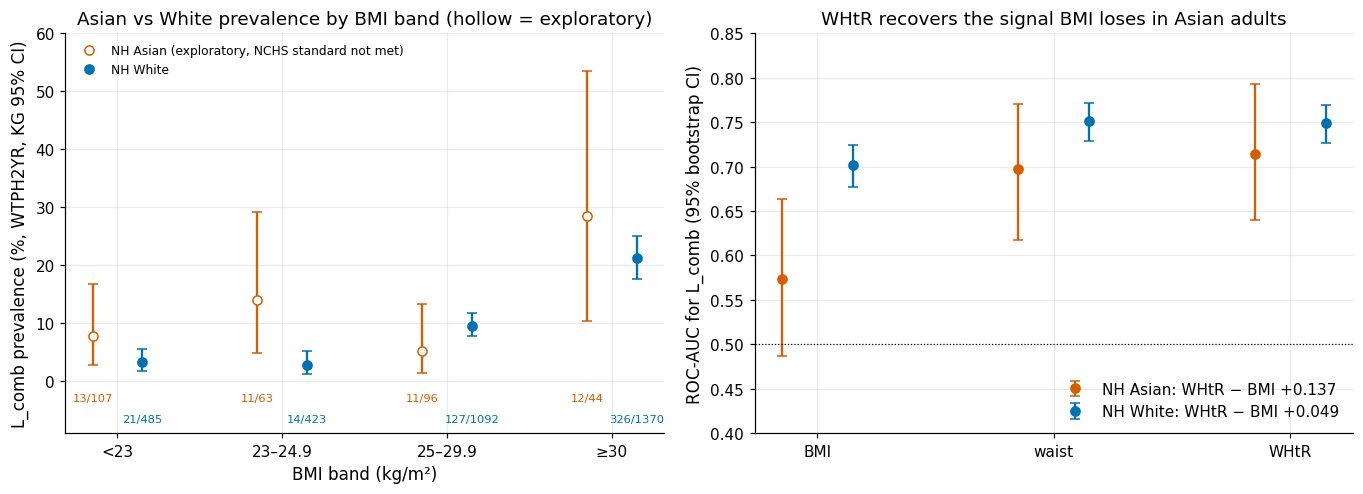

In [134]:
# Figure for §5.5: prevalence by BMI band (left) and single-feature AUCs (right), Asian vs White.
# Reads bands and RO; writes the figure and the §5.5 CSVs.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
xb = np.arange(len(BLAB))
for i, (g, col) in enumerate([("NH Asian", plots.PALETTE[5]), ("NH White", plots.PALETTE[4])]):
    sb = bands[bands["group"] == g]
    # Small horizontal offset so that the two groups' points do not overlap.
    off = (i - 0.5) * 0.3
    ax1.errorbar(xb + off, sb["w_prev"] * 100, yerr=[(sb["w_prev"] - sb["kg_low"]) * 100, (sb["kg_high"] - sb["w_prev"]) * 100],
                 fmt="none", ecolor=col, capsize=3)
    # Filled marker = band passes the NCHS presentation standard; hollow = exploratory.
    ok = (sb["nchs_status"] == "present").to_numpy()
    ax1.plot((xb + off)[ok], sb["w_prev"].to_numpy()[ok] * 100, "o", color=col, label=g if ok.any() else None)
    ax1.plot((xb + off)[~ok], sb["w_prev"].to_numpy()[~ok] * 100, "o", color=col, mfc="white",
             label=f"{g} (exploratory, NCHS standard not met)" if (~ok).any() else None)
    for x_, (_, r) in zip(xb + off, sb.iterrows()):
        # cases/n printed under the axis as a reminder of how thin the cells are.
        ax1.text(x_, -3.5 - 3.5 * i, f"{r['cases']}/{r['n']}", ha="center", fontsize=7.5, color=col)
ax1.set_xticks(xb, BLAB)
ax1.set(xlabel="BMI band (kg/m²)", ylabel="L_comb prevalence (%, WTPH2YR, KG 95% CI)", ylim=(-9, 60),
        title="Asian vs White prevalence by BMI band (hollow = exploratory)")
ax1.legend(loc="upper left", fontsize=8)
meas = ["BMI", "waist", "WHtR"]
for i, (g, col) in enumerate([("NH Asian", plots.PALETTE[5]), ("NH White", plots.PALETTE[4])]):
    rr = RO.loc[g].loc[meas]
    off = (i - 0.5) * 0.3
    ax2.errorbar(np.arange(3) + off, rr["auc"], yerr=[rr["auc"] - rr["ci_low"], rr["ci_high"] - rr["auc"]],
                 fmt="o", color=col, capsize=3,
                 label=f"{g}: WHtR − BMI {RO.loc[(g, 'WHtR − BMI (paired)'), 'auc']:+.3f}")
# AUC 0.5 = no discrimination.
ax2.axhline(0.5, color="k", lw=0.8, ls=":")
ax2.set_xticks(range(3), meas)
ax2.set(ylabel="ROC-AUC for L_comb (95% bootstrap CI)", ylim=(0.4, 0.85),
        title="WHtR recovers the signal BMI loses in Asian adults")
ax2.legend(loc="lower right")
fig.tight_layout()
plots.savefig(fig, "S5_asian_bmi_whtr",
              caption="Left: L_comb prevalence by BMI band, NH Asian vs NH White (WTPH2YR, Korn-Graubard CI; labels = cases/n; "
                      "hollow markers fail the NCHS presentation standard and are exploratory). "
                      "Right: single-feature ROC-AUC of BMI, waist and WHtR with stratified bootstrap CI; legend = paired WHtR - BMI gain.")
plt.show()

# Persist the CSVs, then collect results and register the finding.
roc.to_csv(OUT / "bmi_race_roc.csv", index=False)
bands.to_csv(OUT / "bmi_band_prevalence.csv", index=False)
cuts.to_csv(OUT / "bmi_cutoff_sensitivity.csv", index=False)
RES["asian_bmi"] = {
    "bmi_lt25_among_diabetics": bmi_dm.to_dict("index"),
    "band_prevalence": {f"{g}|{b}": v for (g, b), v in B_[["n", "cases", "prev", "w_prev", "kg_low", "kg_high"]].to_dict("index").items()},
    "auc": {f"{g}|{m}": v for (g, m), v in RO[["n", "auc", "ci_low", "ci_high"]].to_dict("index").items()},
    "gain_difference_asian_minus_white": {"est": float(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "auc"] - RO.loc[("NH White", "WHtR − BMI (paired)"), "auc"]),
                                          "ci_low": gain_diff.quantile(.025), "ci_high": gain_diff.quantile(.975),
                                          "psu_ci_low": np.quantile(psu_diff, .025), "psu_ci_high": np.quantile(psu_diff, .975),
                                          "psu_se": psu_diff.std(), "person_se": gain_diff.std()},
    "cutoffs": {f"{g}|{r}": v for (g, r), v in CU.to_dict("index").items()},
    "n_boot": B,
}
register("DR-S5-06", "measurement_bias",
         "BMI under-measures diabetes-relevant adiposity in NH Asian adults; WHtR recovers discrimination",
         "results/S5/bmi_race_roc.csv; results/S5/bmi_band_prevalence.csv; figures/S5_asian_bmi_whtr.png",
         f"BMI<25 among diabetics: Asian 24/47 (51.1%) vs White {pct(bmi_dm.loc['NH White', 'share'])}; AUC gain WHtR-BMI Asian "
         f"{RO.loc[('NH Asian', 'WHtR − BMI (paired)'), 'auc']:+.3f} ({RO.loc[('NH Asian', 'WHtR − BMI (paired)'), 'ci_low']:.3f}, "
         f"{RO.loc[('NH Asian', 'WHtR − BMI (paired)'), 'ci_high']:.3f}) vs White {RO.loc[('NH White', 'WHtR − BMI (paired)'), 'auc']:+.3f}",
         "Pre-register P14 (WHtR replaces waist, BMI kept) as S8 mitigation arm with White control; Asian results exploratory (40 A1c-positive cases); no group-specific thresholds",
         "Race-specific BMI cut-offs in the model; adding WHtR on top of waist (redundant); race x BMI interaction (not detectable, §4.12)",
         hyp_id="H-P14")

**So what.** Half of the Asian diabetics (24/47, 51.1 %) have a "normal" BMI below 25, against 7.2 % of White
diabetics (the BMI-band prevalences rest on 44–107 Asian adults each and are exploratory). BMI barely
discriminates in Asian adults (AUC 0.573), while waist (0.697) and WHtR (0.714) do.
The paired WHtR − BMI gain is +0.137 in Asian against +0.049 in White adults; the difference, +0.088, excludes
zero with person-level and PSU-level resampling (PSU 0.035–0.116, FINAL). A BMI ≥ 25 rule finds 48.9 % of Asian
cases (White 92.8 %); the ADA cut-off of 23 for Asian Americans raises this to 72.3 % at a specificity of 35.7 %.
With 40–50 Asian cases this is a measurement *signal* (consistent with Araneta et al. 2015) that motivates the
pre-registered WHtR arm P14 (§8.9).

## 5.6 Representation and response

**Why.** The composition, response rates and Kish design effect are those of §1.10; the new check here is whether exam
participation relates to health (self-reported diabetes, WTINT2YR, interview-only vs adults with an HbA1c result).

dimension            level    n  sample_share  weighted_share  diff_pp
      age            20-39 1414         0.247           0.348  -10.161
      age            40-59 1671         0.292           0.338   -4.632
      age              60+ 2645         0.462           0.314   14.794
     race Mexican American  386         0.067           0.071   -0.361
     race         NH Asian  315         0.055           0.061   -0.621
     race         NH Black  676         0.118           0.110    0.791
     race         NH White 3408         0.595           0.602   -0.731
     race   Other Hispanic  582         0.102           0.096    0.601
     race      Other/multi  363         0.063           0.060    0.320

Kish design effect of WTPH2YR: 1.55 (effective n ≈ 3,707); L_comb unweighted 16.9% vs weighted 14.0%
§4.4: age structure explains 84% of the 2.9 pp unweighted-weighted gap
documented response rates: interview 34.6%, exam 25.7%


self-reported diabetes (WTINT2YR): interview-only adults 8.8% (KG 7.0%–10.9%, width 0.04; n=1742, events=202, df=15) -> meets NCHS standard
                                   adults with HbA1c   11.7% (KG 10.2%–13.4%, width 0.03; n=5767, events=819, df=15) -> meets NCHS standard
difference with HbA1c - interview-only: +2.9 pp (1.0, 4.8)


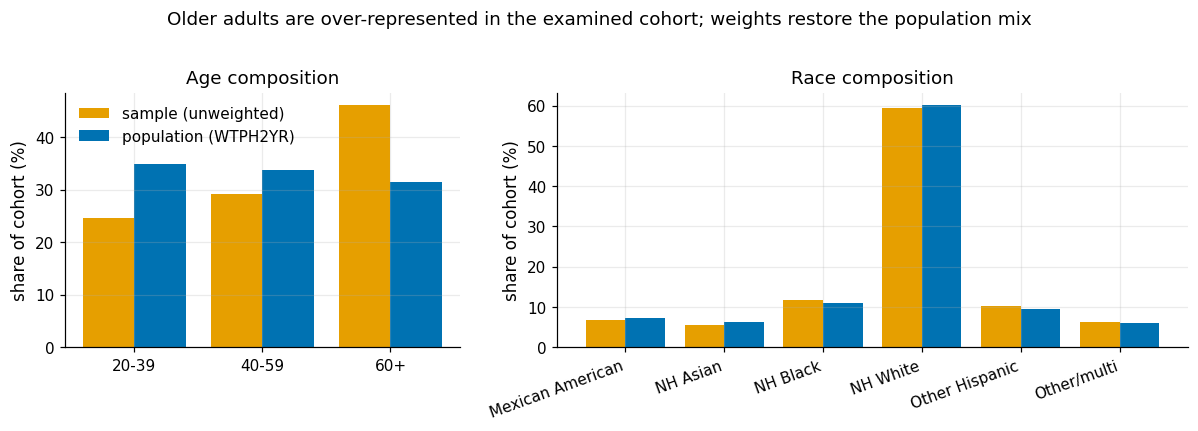

In [135]:
# Representation and response (§5.6): sample vs weighted composition, Kish design effect, selection into the
# exam.
# Reads d and the merged NHANES file; asserts composition, design effect and the share of the gap explained by
# age.
band_s = S.age_band(d["RIDAGEYR"]).to_numpy()
rep_rows = []
for dim, vals in [("age", band_s), ("race", d["race3"].to_numpy())]:
    for lev in pd.unique(vals):
        m = vals == lev
        rep_rows.append({"dimension": dim, "level": lev, "n": int(m.sum()), "sample_share": m.mean(),
                         "weighted_share": d.loc[m, WT].sum() / d[WT].sum()})
rep = pd.DataFrame(rep_rows).sort_values(["dimension", "level"]).reset_index(drop=True)
# diff_pp > 0: the group is over-represented in the sample relative to its weighted (population) share.
rep["diff_pp"] = 100 * (rep["sample_share"] - rep["weighted_share"])
print(rep.round(3).to_string(index=False))
# Kish design effect = 1 + CV^2 of the weights: variance inflation from unequal weights; n_eff = n / deff.
deff = S.kish_deff(d[WT])
unw_prev = d["L_comb"].mean()
print(f"\nKish design effect of WTPH2YR: {deff:.2f} (effective n ≈ {len(d) / deff:,.0f}); "
      f"L_comb unweighted {pct(unw_prev)} vs weighted {pct(w_prev['est'])}")
RP = rep.set_index(["dimension", "level"])
# Reference sample and weighted shares for the age extremes, then the Kish design effect.
close(RP.loc[("age", "60+"), "sample_share"], 0.462, 0.001, "60+ sample"); close(RP.loc[("age", "60+"), "weighted_share"], 0.314, 0.001, "60+ weighted")
close(RP.loc[("age", "20-39"), "sample_share"], 0.247, 0.001, "20-39 sample"); close(RP.loc[("age", "20-39"), "weighted_share"], 0.348, 0.001, "20-39 weighted")
close(deff, 1.55, 0.01, "Kish deff")
age_explained = R.load_section("S4")["prevalence"]["gap_explained_by_age"]   # S4: sample rates re-weighted to the population age mix
print(f"§4.4: age structure explains {100 * age_explained:.0f}% of the {100 * (unw_prev - w_prev['est']):.1f} pp unweighted-weighted gap")
close(age_explained, 0.84, 0.01, "share of gap explained by age (S4)")

# Response rates are documented by NCHS, not derivable from public files (§1.10; NHANES 2021-2023
# overview brief, https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/overviewbrief.aspx?Cycle=2021-2023).
RESPONSE = {"interview_unweighted": 0.346, "exam_unweighted": 0.257}
print(f"documented response rates: interview {pct(RESPONSE['interview_unweighted'])}, exam {pct(RESPONSE['exam_unweighted'])}")

# Full interview-and-exam file: needed to compare interview-only with examined adults.
merged = NIO.load_merged()
# Drop attached audit frames, as for the cohort above.
merged.attrs = {}
# Domains are masks on the full 11,933-row design (weights zeroed outside), never row subsets, so every
# jackknife replicate keeps all strata and PSUs.
# Self-reported diabetes indicator; NaN where DIQ010 is missing so it drops out of the proportion.
merged["self_dm"] = merged["DIQ010"].eq(1).astype(float).where(merged["DIQ010"].notna())
# Domains: interview-only adults (RIDSTATR 1) vs examined adults with an HbA1c result (RIDSTATR 2).
adult = (merged["RIDAGEYR"] >= C.ADULT_MIN_AGE).to_numpy()
io_mask = adult & merged["RIDSTATR"].eq(1).to_numpy()
a1c_mask = adult & (merged["RIDSTATR"].eq(2) & merged["LBXGH"].notna()).to_numpy()
# Both groups use the interview weight, the only weight defined for interview-only adults.
p_io = S.weighted_prop(merged, "self_dm", weight=C.WEIGHT_INTERVIEW, domain=io_mask)
p_a1c = S.weighted_prop(merged, "self_dm", weight=C.WEIGHT_INTERVIEW, domain=a1c_mask)
# Risk difference (HbA1c group - interview-only): do exam participants report diabetes more often?
rd_sel = risk_difference(merged, "self_dm", a1c_mask, io_mask, weight=C.WEIGHT_INTERVIEW)
print(f"self-reported diabetes (WTINT2YR): interview-only adults {kg_text(p_io)}")
print(f"                                   adults with HbA1c   {kg_text(p_a1c)}")
print(f"difference with HbA1c - interview-only: {100 * rd_sel['est']:+.1f} pp ({100 * rd_sel['ci_low']:.1f}, {100 * rd_sel['ci_high']:.1f})")
close(p_io["est"], 0.088, 0.0015, "interview-only self-report"); close(p_a1c["est"], 0.117, 0.0015, "with-A1c self-report")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
for ax, dim in zip(axes, ["age", "race"]):
    rr = rep[rep["dimension"] == dim]
    x = np.arange(len(rr))
    ax.bar(x - 0.2, rr["sample_share"] * 100, 0.4, label="sample (unweighted)", color=plots.PALETTE[0])
    ax.bar(x + 0.2, rr["weighted_share"] * 100, 0.4, label="population (WTPH2YR)", color=plots.PALETTE[4])
    ax.set_xticks(x, rr["level"], rotation=0 if dim == "age" else 20, ha="center" if dim == "age" else "right")
    ax.set(ylabel="share of cohort (%)", title=f"{dim.capitalize()} composition")
axes[0].legend()
fig.suptitle("Older adults are over-represented in the examined cohort; weights restore the population mix", y=1.02)
fig.tight_layout()
plots.savefig(fig, "S5_representation",
              caption="Sample versus WTPH2YR-weighted composition of the 5,730-adult cohort by age band and race/ethnicity.")
plt.show()

# Persist the table, then collect results and register the finding.
rep.to_csv(OUT / "representation.csv", index=False)
RES["representation"] = {
    "shares": {f"{a}|{b}": v for (a, b), v in RP[["n", "sample_share", "weighted_share"]].to_dict("index").items()},
    "kish_deff": deff, "n_eff_kish": len(d) / deff, "L_comb_unweighted": unw_prev,
    "response_rates_documented": RESPONSE,
    "self_dm_interview_only": {k: p_io[k] for k in ("est", "kg_low", "kg_high", "n")},
    "self_dm_with_a1c": {k: p_a1c[k] for k in ("est", "kg_low", "kg_high", "n")},
    "selection_rd": {"est": rd_sel["est"], "ci_low": rd_sel["ci_low"], "ci_high": rd_sel["ci_high"]},
}
register("DR-S5-07", "representation",
         "Cohort over-represents older adults; exam participants report more diabetes than interview-only adults",
         "results/S5/representation.csv; figures/S5_representation.png",
         f"60+: sample {pct(RP.loc[('age', '60+'), 'sample_share'])} vs weighted {pct(RP.loc[('age', '60+'), 'weighted_share'])}; "
         f"Kish deff {deff:.2f}; self-report interview-only {pct(p_io['est'])} vs with HbA1c {pct(p_a1c['est'])}; response 34.6%/25.7%",
         "Descriptive population estimates use WTPH2YR with PSU jackknife; survey-weighted training only as ablation B6b; claims scoped to the examined population",
         "Treat the unweighted sample as the population; claim national representativeness of model metrics")

**So what.** Composition and response rates repeat §1.10 (age structure explains about 84 % of the 16.9 % vs 14.0 %
prevalence gap, §4.4). New: interview-only adults report diabetes less often (8.8 %) than adults with an HbA1c result
(11.7 %), so weights correct for known covariates but not for health-related participation – model metrics describe
the examined population.

## 5.7 HbA1c missingness bias

**Why.** The cohort requires an HbA1c result. If HbA1c is missing more often in some groups and for health
reasons, the label is missing not at random. We compare missingness among examined adults by race, compare MEC- and phlebotomy-weighted prevalence (WTPH2YR already contains a blood-draw non-response
adjustment), and bound the `L_comb` prevalence without any assumption on the missing values (Manski bounds).
Self-report is observed for most adults without HbA1c, so the bounds are sharper than the naive width m.

In [136]:
# HbA1c missingness (§5.7): missing share by race, MEC vs phlebotomy weighting, Manski bounds on L_comb
# prevalence.
# Reads merged; writes the missingness and Manski CSVs; asserts missing shares and the MEC-weighted
# prevalence.
# Missingness by race on all examined adults (the §3.7 definition); Manski bounds below on the cohort universe
# (examined, non-pregnant adults).
merged["a1c_missing"] = merged["LBXGH"].isna().astype(float)
merged["race3"] = merged["RIDRETH3"].map(RACE)
exam = adult & merged["RIDSTATR"].eq(2).to_numpy()                      # all examined adults (§3.7 definition)
coh_univ = exam & ~merged["RIDEXPRG"].eq(1).to_numpy()                   # cohort universe: examined, not pregnant
miss_rows = []
for g in sorted(merged.loc[exam, "race3"].unique()):
    m = exam & merged["race3"].eq(g).to_numpy()
    # Missingness is weighted with the exam weight (WTMEC2YR), the weight of everyone who was examined.
    w = S.weighted_prop(merged, "a1c_missing", weight=C.WEIGHT_MEC, domain=m)
    miss_rows.append({"race3": g, "examined": int(m.sum()), "missing": int(merged.loc[m, "a1c_missing"].sum()),
                      "missing_share": merged.loc[m, "a1c_missing"].mean(), "w_missing_share": w["est"],
                      "kg_low": w["kg_low"], "kg_high": w["kg_high"], "df": w["df"]})
miss = pd.DataFrame(miss_rows).set_index("race3")
print(miss.round(3))
# Black - White contrast on the same weight; jackknife CI via risk_difference.
rd_miss = risk_difference(merged, "a1c_missing", exam & merged["race3"].eq("NH Black").to_numpy(),
                          exam & merged["race3"].eq("NH White").to_numpy(), weight=C.WEIGHT_MEC)
print(f"missing HbA1c, NH Black - NH White (WTMEC2YR, JK): {100 * rd_miss['est']:+.1f} pp "
      f"({100 * rd_miss['ci_low']:.1f}, {100 * rd_miss['ci_high']:.1f})")
close(miss.loc["NH Black", "missing_share"], 0.093, 0.0015, "Black missing"); close(miss.loc["NH White", "missing_share"], 0.040, 0.0015, "White missing")

# Prevalence under the exam weight, to compare with WTPH2YR (which includes a blood-draw non-response
# adjustment).
prev_mec = np.average(d["L_comb"], weights=d[C.WEIGHT_MEC])
print(f"\nL_comb prevalence: WTMEC2YR-weighted {pct(prev_mec)} vs WTPH2YR-weighted {pct(w_prev['est'])}")
close(prev_mec, 0.139, 0.0015, "MEC-weighted prevalence")

# Manski bounds on L_comb prevalence among examined adults (WTMEC2YR): missing HbA1c rows with self-reported
# diabetes are known positives; the rest could be anything.
# known_pos: HbA1c >= 6.5 or self-reported diabetes; these are positives whatever the missing values are.
known_pos = (merged["LBXGH"].ge(C.HBA1C_DIABETES) | merged["DIQ010"].eq(1)).astype(float).to_numpy()
# unknown: HbA1c missing and no self-reported diabetes; these could be positive or negative.
unknown = (merged["LBXGH"].isna() & ~merged["DIQ010"].eq(1)).astype(float).to_numpy()
observed = merged["LBXGH"].notna().to_numpy()
# Missing weights -> 0 so that such rows do not contribute.
w_mec = merged[C.WEIGHT_MEC].fillna(0).to_numpy()
# Lower bound = weighted share of known positives; upper = lower + weighted share of unknowns (Manski).
# naive_width_m is the plain missing share, i.e. the width if self-report were ignored.
man = []
for g in ["all", *sorted(merged.loc[coh_univ, "race3"].unique())]:
    m = coh_univ if g == "all" else coh_univ & merged["race3"].eq(g).to_numpy()
    lo = np.average(known_pos[m], weights=w_mec[m])
    unk = np.average(unknown[m], weights=w_mec[m])
    man.append({"group": g, "observed_prev": np.average(known_pos[m & observed], weights=w_mec[m & observed]),
                "lower": lo, "upper": lo + unk, "width": unk,
                "naive_width_m": np.average(merged["a1c_missing"].to_numpy()[m], weights=w_mec[m])})
manski = pd.DataFrame(man).set_index("group")
print("\nManski bounds for L_comb prevalence (WTMEC2YR, examined non-pregnant adults)")
print(manski.round(3))
# Persist the tables, then collect results and register the finding.
miss.to_csv(OUT / "a1c_missingness.csv")
manski.to_csv(OUT / "manski_bounds.csv")
RES["missingness"] = {"by_race": miss.to_dict("index"),
                      "black_minus_white_rd": {k: rd_miss[k] for k in ("est", "ci_low", "ci_high", "df")}, "prev_mec": prev_mec, "prev_ph": w_prev["est"],
                      "manski": manski.to_dict("index")}
register("DR-S5-08", "missingness",
         "HbA1c is missing more often for NH Black adults; WTPH2YR adjustment changes prevalence by 0.1 pp",
         "results/S5/a1c_missingness.csv; results/S5/manski_bounds.csv",
         f"missing HbA1c: Black {pct(miss.loc['NH Black', 'missing_share'])} vs White {pct(miss.loc['NH White', 'missing_share'])}; "
         f"prevalence MEC {pct(prev_mec)} vs PH {pct(w_prev['est'])}; Manski width overall {manski.loc['all', 'width']:.3f}",
         "Keep complete-case cohort with WTPH2YR; report Manski bounds; IPW sensitivity deferred to S9 (§9.7)",
         "Impute HbA1c (would impute the label); ignore missingness")

                  examined  missing  missing_share  w_missing_share  kg_low  kg_high  df
race3                                                                                   
Mexican American       405       16          0.040            0.044   0.025    0.072  14
NH Asian               335       20          0.060            0.058   0.023    0.117  14
NH Black               753       70          0.093            0.089   0.068    0.114  15
NH White              3569      142          0.040            0.040   0.029    0.054  15
Other Hispanic         614       26          0.042            0.044   0.023    0.077  15
Other/multi            388       23          0.059            0.073   0.036    0.127  15
missing HbA1c, NH Black - NH White (WTMEC2YR, JK): +4.9 pp (2.9, 6.9)

L_comb prevalence: WTMEC2YR-weighted 13.9% vs WTPH2YR-weighted 14.0%

Manski bounds for L_comb prevalence (WTMEC2YR, examined non-pregnant adults)
                  observed_prev  lower  upper  width  naive_width_m
gr

**So what.** HbA1c is missing for 9.3 % of examined NH Black vs 4.0 % of NH White adults (+4.9 pp, CI 2.9–6.9). The
blood-weight non-response adjustment moves prevalence only from 13.9 % to 14.0 %. Without assumptions on the missing
values the `L_comb` prevalence of examined non-pregnant adults lies between 13.9 % and 18.1 % (NH Black 21.5–28.4 %,
NH White 12.4–15.9 %). The cohort stays complete-case with WTPH2YR; IPW and MNAR checks follow in §9.7.

## 5.8 Decision gate L2 and target freeze

**Why.** The label-revision decision gate sends the project back to §1 if the label audit changes the question. Four
criteria, judged **after** seeing the data, decide whether `L_comb` is frozen together with E-SCREEN, the 3×3 strata
and the sensitivity labels SL1–SL7 (`governance/label_freeze.md`, executable in `src/labels.py`).

In [137]:
# Label-revision gate (§5.8): criteria C1-C4 for freezing L_comb, judged after seeing the data.
# Reads the variable spec and the labels; asserts the gate outcome; writes the gate table CSV.
spec = NIO.load_spec()
# Target components plus closely related post-diagnosis variables (medication, tests, glucose).
TARGET_PARTS = ["LBXGH", "DIQ010", "DIQ050", "DIQ070", "DID040", "DID060", "DIQ160", "DIQ180", "LBXGLU"]
# One spec row per variable; C2 requires that none of the target's components is admissible as a feature.
adm = spec[spec["var"].isin(TARGET_PARTS)].drop_duplicates("var").set_index("var")["admissible"].astype(str)
# Guard: every target part must exist in the spec, otherwise C2 would pass vacuously.
assert set(adm.index) == set(TARGET_PARTS), set(TARGET_PARTS) - set(adm.index)
# T1/T2 are the admissible tiers of the variable spec; any component carrying one would fail C2.
c2_bad = adm[adm.str.upper().isin(["T1", "T2"])]
# Positives per race group for C3 (the smallest reported group needs at least 40).
race_pos = d.groupby("race3")[["L_comb", "L_A1c"]].sum()
# Sensitivity labels SL1-SL7 from the executable label definitions.
sl = L.sensitivity_labels(d)
# C1 evidence: share of the union each instrument misses, plus the agreement statistics from §5.1.
c1 = {"self_missed": miss_self / n_comb, "a1c_missed": miss_a1c / n_comb, "kappa": unw["kappa"], "pa": unw["pa"], "na": unw["na"]}
gate = pd.DataFrame([
    {"criterion": "C1 descriptive evidence: each single instrument misses a material share of the union",
     "evidence": f"L_self misses {miss_self}/{n_comb} = {pct(c1['self_missed'])}; L_A1c misses {miss_a1c}/{n_comb} = {pct(c1['a1c_missed'])}; "
                 f"kappa {c1['kappa']:.2f}, PA {c1['pa']:.2f}, NA {c1['na']:.2f}",
     "verdict": "PASS (union justified; post-hoc judgement)"},
    {"criterion": "C2 no admissible feature is a component of the target",
     "evidence": f"variable_spec admissible flag of {', '.join(TARGET_PARTS)}: {sorted(set(adm.fillna('missing')))}",
     "verdict": "PASS" if c2_bad.empty else f"FAIL: {list(c2_bad.index)}"},
    {"criterion": "C3 >= 500 positives overall and >= 40 in the smallest reported group",
     "evidence": f"L_comb {n_comb}; smallest race group (L_comb) {race_pos['L_comb'].idxmin()} {int(race_pos['L_comb'].min())}; "
                 f"NH Asian L_comb {int(race_pos.loc['NH Asian', 'L_comb'])}, L_A1c {int(race_pos.loc['NH Asian', 'L_A1c'])}",
     "verdict": "PASS (NH Asian under L_A1c exactly at the line: descriptive only)"},
    {"criterion": "C4 borderline coding handled as sensitivity",
     "evidence": f"borderline positive (SL3): {int(sl['SL3'].sum())} positives vs {n_comb}",
     "verdict": "PASS (borderline negative + flagged; SL3 as sensitivity)"},
])
display(gate)
# Hard gate: C2 clean, >= 500 positives, >= 40 per race group under L_comb and for NH Asian under L_A1c.
assert c2_bad.empty and n_comb >= 500 and race_pos["L_comb"].min() >= 40 and race_pos.loc["NH Asian", "L_A1c"] >= 40
# C4: the borderline-positive label SL3 must keep its frozen positive count.
assert int(sl["SL3"].sum()) == 1148
# Cross-check C1 against the §5.1 reference shares.
close(c1["self_missed"], 0.157, 0.001, "C1 self missed"); close(c1["a1c_missed"], 0.257, 0.001, "C1 A1c missed")
gate.to_csv(OUT / "l2_gate.csv", index=False)

,criterion,evidence,verdict
0,C1 descriptive evidence: each single instrument misses a material ...,L_self misses 152/971 = 15.7%; L_A1c misses 250/971 = 25.7%; kappa...,PASS (union justified; post-hoc judgement)
1,C2 no admissible feature is a component of the target,"variable_spec admissible flag of LBXGH, DIQ010, DIQ050, DIQ070, DI...",PASS
2,C3 >= 500 positives overall and >= 40 in the smallest reported group,L_comb 971; smallest race group (L_comb) NH Asian 50; NH Asian L_c...,PASS (NH Asian under L_A1c exactly at the line: descriptive only)
3,C4 borderline coding handled as sensitivity,borderline positive (SL3): 1148 positives vs 971,PASS (borderline negative + flagged; SL3 as sensitivity)


**E-SCREEN, 3×3 strata and sensitivity labels.** The frozen definitions are computed once more from
`src/labels.py` and compared with the counts written into `governance/label_freeze.md`, so the document and
the code cannot drift apart.

3x3 evaluation strata: {'D_uncontrolled': 569, 'D_controlled': 250, 'Undiagnosed': 152, 'NonDiabetic': 4759}
E-SCREEN: {'n': 4911, 'positives': 152, 'negatives': 4759, 'borderline_in_escreen': 213, 'borderline_positive': 36}
label                                                    definition    n  positives  prev_unweighted   weight  w_prev  w_ci_low  w_ci_high
  SL1                                                    L_A1c only 5730        721            0.126  WTPH2YR   0.105     0.092      0.119
  SL2                                                   L_self only 5730        819            0.143  WTPH2YR   0.118     0.102      0.133
  SL3                                   borderline counted positive 5730       1148            0.200  WTPH2YR   0.167     0.149      0.184
  SL4 treatment-aware (A1c or treated self-report, DIQ070 universe) 5730        886            0.155  WTPH2YR   0.128     0.113      0.143
  SL5  NCHS: self-report or A1c>=6.5 or FPG>=126, fasting subsample 2938        

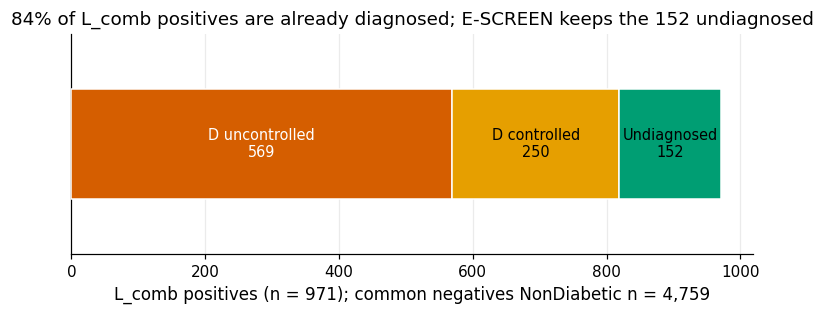

In [138]:
# Recompute the frozen definitions (3x3 strata, E-SCREEN, SL1-SL5) and compare them with
# governance/label_freeze.md.
# Asserts the counts and the document's JSON block, records its SHA-256; writes the strata figure and CSV.
strata = L.strata_counts(d)
# E-SCREEN population: adults without a self-reported diagnosis, target = HbA1c >= 6.5.
esc = d[d["in_escreen"] == 1]
esc_counts = {"n": len(esc), "positives": int(esc["y_escreen"].sum()), "negatives": int((esc["y_escreen"] == 0).sum()),
              "borderline_in_escreen": int(esc["borderline"].sum()),
              "borderline_positive": int(((esc["borderline"] == 1) & (esc["y_escreen"] == 1)).sum())}
print("3x3 evaluation strata:", strata)
print("E-SCREEN:", esc_counts)
# Guard: stratum counts equal the frozen values.
assert strata == {"D_uncontrolled": 569, "D_controlled": 250, "Undiagnosed": 152, "NonDiabetic": 4759}
assert esc_counts["positives"] == 152 and esc_counts["borderline_positive"] == 36

# Fasting-subsample mask (SL5 uses fasting plasma glucose, which is measured only there).
fm = L.fasting_mask(d)
# SL1-SL5 with definition and the weight matching each sample (WTPH2YR; the fasting weight for SL5).
sl_rows = []
for col, desc, wcol in [("SL1", "L_A1c only", WT), ("SL2", "L_self only", WT), ("SL3", "borderline counted positive", WT),
                        ("SL4", "treatment-aware (A1c or treated self-report, DIQ070 universe)", WT),
                        ("SL5", "NCHS: self-report or A1c>=6.5 or FPG>=126, fasting subsample", C.WEIGHT_FASTING)]:
    # Weighted prevalence per sensitivity label; the label is attached as a temporary column _y.
    w = S.weighted_prop(d.assign(_y=sl[col]), "_y", weight=wcol)
    sl_rows.append({"label": col, "definition": desc, "n": int(sl[col].notna().sum()), "positives": int(sl[col].sum()),
                    "prev_unweighted": sl[col].mean(), "weight": wcol, "w_prev": w["est"], "w_ci_low": w["ci_low"], "w_ci_high": w["ci_high"]})
sl_tab = pd.DataFrame(sl_rows)
print(sl_tab.round(3).to_string(index=False))
# DIQ070 universe: respondents asked about diabetes pills; pills of non-diagnosed people are not counted
# (SL4).
univ = L.diq070_universe(d)
# Who reports pills: mostly diagnosed; the borderline and prediabetes pill takers motivate the universe
# restriction.
pills_by_status = d[d["DIQ070"].eq(1)].groupby(d["DIQ010"].map({1: "diagnosed", 2: "no (told prediabetes)", 3: "borderline"})).size()
print("DIQ070 = 1 by DIQ010:", pills_by_status.to_dict(), f"; DIQ070 universe n = {int(univ.sum())}")
SLT = sl_tab.set_index("label")
# Guard: SL positives equal the frozen counts; the SL5 count is computed (fasting subsample).
assert SLT["positives"].tolist() == [721, 819, 1148, 886, int(SLT.loc["SL5", "positives"])]
assert pills_by_status.to_dict() == {"borderline": 44, "diagnosed": 592, "no (told prediabetes)": 41}
# SL5 mirrors the NCHS definition, so its weighted prevalence should land near the published figure (15.8 %).
close(SLT.loc["SL5", "w_prev"], 0.158, 0.006, "SL5 vs NCHS DB516 15.8%")

# Governance document vs code: parse the JSON block of label_freeze.md and compare it with recomputed counts.
freeze_path = C.GOVERNANCE_DIR / "label_freeze.md"
freeze_text = freeze_path.read_text(encoding="utf-8")
# The document stores its counts in a fenced json block; take the text between the first fence pair.
frozen = json.loads(freeze_text.split("```json")[1].split("```")[0])
computed = {"N": len(d), "L_comb": n_comb, "L_self": int(d["L_self"].sum()), "L_A1c": int(d["L_A1c"].sum()),
            "strata_3x3": strata, "escreen_positives": esc_counts["positives"], "escreen_negatives": esc_counts["negatives"],
            "escreen_borderline_positive": esc_counts["borderline_positive"],
            "SL_positives": {k: int(v) for k, v in SLT["positives"].items()}, "SL5_n": int(SLT.loc["SL5", "n"])}
# Guard: document and code cannot drift apart; on mismatch the message lists the differing keys.
assert frozen == computed, {k: (frozen.get(k), v) for k, v in computed.items() if frozen.get(k) != v}
# The document's hash is stored with the results so that later edits are detectable.
freeze_sha = hashlib.sha256(freeze_path.read_bytes()).hexdigest()
print(f"label_freeze.md counts match the code; SHA-256 {freeze_sha[:16]}…")

# Figure: stacked bar of the three positive strata (diagnosed uncontrolled, diagnosed controlled,
# undiagnosed).
fig, ax = plt.subplots(figsize=(8, 2.6))
cols = [plots.PALETTE[5], plots.PALETTE[0], plots.PALETTE[2]]
left = 0
for k, col in zip(L.POSITIVE_STRATA, cols):
    ax.barh(0, strata[k], left=left, height=0.5, color=col, edgecolor="white", zorder=3)
    ax.text(left + strata[k] / 2, 0, f"{k.replace('_', ' ')}\n{strata[k]}", ha="center", va="center", fontsize=9.5,
            color="white" if k == "D_uncontrolled" else "black", zorder=4)
    left += strata[k]
ax.set_yticks([])
ax.grid(axis="y", visible=False)
known = strata["D_uncontrolled"] + strata["D_controlled"]
ax.set(xlabel=f"L_comb positives (n = {n_comb}); common negatives NonDiabetic n = {strata['NonDiabetic']:,}", ylim=(-0.5, 0.5),
       title=f"{pct(known / n_comb, 0)} of L_comb positives are already diagnosed; E-SCREEN keeps the {strata['Undiagnosed']} undiagnosed")
plots.savefig(fig, "S5_label_strata", caption="Composition of the 971 L_comb positives by self-report and HbA1c; "
              "D_uncontrolled 569, D_controlled 250, Undiagnosed 152 (= E-SCREEN positives).")
plt.show()

# Persist the table, then collect results and register the findings.
sl_tab.to_csv(OUT / "sensitivity_labels.csv", index=False)
RES["freeze"] = {"target": "L_comb = (DIQ010 == 1) | (LBXGH >= 6.5)", "N": len(d), "gate": gate.set_index("criterion")["verdict"].to_dict(),
                 "gate_posthoc": True, "strata_3x3": strata, "escreen": esc_counts,
                 "sensitivity_labels": sl_tab.set_index("label")[["n", "positives", "prev_unweighted", "w_prev", "weight"]].to_dict("index"),
                 "known_dx_share_of_positives": strata["D_uncontrolled"] / n_comb + strata["D_controlled"] / n_comb,
                 "label_freeze_sha256": freeze_sha}
register("DR-S5-01", "target_freeze",
         "L2 gate C1-C4 passes (post-hoc); the union label is the least biased single target",
         "results/S5/l2_gate.csv; governance/label_freeze.md",
         f"L_comb {n_comb} positives ({pct(n_comb / len(d))}; weighted {pct(w_prev['est'])}); C1 15.7%/25.7% missed by single labels; "
         f"C3 Asian L_comb {int(race_pos.loc['NH Asian', 'L_comb'])}",
         "Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on N=5,730 (tag target-freeze); any change requires a register entry and reopening L2",
         "Freeze L_self (misses 152 undiagnosed); freeze L_A1c (misses 250 controlled); borderline positive (SL3, kept as sensitivity)",
         loop_ref="L2", check_note="Gate recomputed in §5.8; post-hoc nature stated")
register("DR-S5-09", "evaluation_population",
         "84% of L_comb positives are already diagnosed, so E-ALL measures recognition of known disease",
         "governance/label_freeze.md; figures/S5_label_strata.png",
         f"E-SCREEN: {esc_counts['n']} adults, {esc_counts['positives']} positives vs {esc_counts['negatives']} negatives; "
         f"borderline kept with {esc_counts['borderline_positive']} positive; 3x3 strata 569/250/152/4759",
         "E-SCREEN (DIQ010!=1, y = HbA1c>=6.5) is a co-primary evaluation population next to E-ALL; 3x3 label matrix (SL6) evaluated in S8 at specificity 0.80",
         "Evaluate on E-ALL only; train on E-SCREEN only (152 events too few)", loop_ref="L2")
register("DR-S5-10", "sensitivity_labels",
         "Label definition is a researcher degree of freedom; robustness needs pre-specified alternatives",
         "results/S5/sensitivity_labels.csv; governance/label_freeze.md",
         "SL1 721, SL2 819, SL3 1,148, SL4 886, SL5 " + f"{int(SLT.loc['SL5', 'positives'])}/{int(SLT.loc['SL5', 'n'])} (weighted {pct(SLT.loc['SL5', 'w_prev'])})",
         "Freeze SL1-SL7 as executable definitions (src/labels.py); SL4 uses only the DIQ070 universe and excludes pills of non-diagnosed respondents; S9 reports results under SL1-SL5, S8 runs SL6, S9 runs SL7",
         "Ad-hoc relabelling after seeing model results; DIQ070 pills as diabetes for all respondents (would count pills plausibly taken for prediabetes, e.g. metformin)")

**So what.** All four gate criteria pass, as a post-hoc judgement made after seeing the data: each single
instrument misses a material share of the union (15.7 % and 25.7 %), no admissible feature is part of the
target, every race group has at least 40 positives (NH Asian 50 under `L_comb`, exactly 40 under `L_A1c`, so
Asian results stay descriptive), and borderline coding is handled by SL3. **`L_comb` is frozen.** Of the 971
positives, 84 % are already diagnosed (569 uncontrolled, 250 controlled), so E-SCREEN (152 undiagnosed
positives vs 4,759 negatives) is co-primary, and §8.6 evaluates every training label on each 3×3 column. SL5
closely reproduces the published DB516 prevalence of 15.8 %, anchoring the label pipeline externally.

## 5.9 Hypothesis status and outputs

**Why.** Three entries of `governance/hypotheses.md` are checked in this section. All three were written after
the data had been analysed (`analysis_seen` / `descriptive_seen`), so "supported" here confirms a reproduced
description, not confirmatory evidence. The decision register (`governance/register/S5.csv`) and
`results/metrics_S5.json` are written at the end.

In [139]:
# Hypothesis status (§5.9): check H1a, H4a and H4b against their pre-stated rules and read their prior
# exposure.
# Reads RD, RO, gain_diff, psu_diff and bmi_dm; asserts all three verdicts and the pre-registration status.
from statsmodels.stats.proportion import confint_proportions_2indep

# H4a: difference in the share with BMI < 25 between Asian and White diabetics.
ka, na_ = int(bmi_dm.loc["NH Asian", "bmi_lt25"]), int(bmi_dm.loc["NH Asian", "diabetics_with_bmi"])
kw, nw = int(bmi_dm.loc["NH White", "bmi_lt25"]), int(bmi_dm.loc["NH White", "diabetics_with_bmi"])
# Newcombe hybrid-score interval for a difference of two independent proportions (suited to small counts).
h4a_lo, h4a_hi = confint_proportions_2indep(ka, na_, kw, nw, method="newcomb", compare="diff")
h4a = ka / na_ - kw / nw
# Survey-weighted version of the same difference via the jackknife risk difference, as a cross-check.
rd_bmi = risk_difference(d.assign(bmi_lt25=(d["BMXBMI"] < 25).astype(float).where(d["BMXBMI"].notna())), "bmi_lt25",
                         ((d["RIDRETH3"] == 6) & (d["L_comb"] == 1)).to_numpy(), ((d["RIDRETH3"] == 3) & (d["L_comb"] == 1)).to_numpy())
g_as, g_wh = RO.loc[("NH Asian", "WHtR − BMI (paired)")], RO.loc[("NH White", "WHtR − BMI (paired)")]
rd_un = RD.loc["uninsured - insured"]
# One row per hypothesis: estimate, pre-stated decision rule and verdict.
hyp = pd.DataFrame([
    {"hyp_id": "H1a", "estimate": f"RD uninsured - insured {rd_un['rd_pp']:+.1f} pp ({rd_un['ci_low_pp']:.1f}, {rd_un['ci_high_pp']:.1f})",
     "rule": "lower CI bound > 0", "verdict": "supported" if rd_un["ci_low_pp"] > 0 else "inconclusive",
     "note": "uninsured share exploratory (KG width >= 0.30)"},
    {"hyp_id": "H4a", "estimate": f"BMI<25 among diabetics, Asian - White {100 * h4a:+.1f} pp (Newcombe {100 * h4a_lo:.1f}, {100 * h4a_hi:.1f}); "
                                  f"weighted {100 * rd_bmi['est']:+.1f} pp (JK {100 * rd_bmi['ci_low']:.1f}, {100 * rd_bmi['ci_high']:.1f})",
     "rule": "difference >= 20 pp with CI above 20 pp",
     # Supported if the lower CI bound reaches 20 pp; inconclusive if only the point estimate does.
     "verdict": "supported" if h4a_lo >= 0.20 else ("inconclusive" if h4a >= 0.20 else "refuted"),
     "note": "47 Asian diabetics with BMI: exploratory"},
    {"hyp_id": "H4b", "estimate": f"WHtR - BMI gain Asian {g_as['auc']:+.3f} ({g_as['ci_low']:.3f}, {g_as['ci_high']:.3f}) vs "
                                  f"White {g_wh['auc']:+.3f} ({g_wh['ci_low']:.3f}, {g_wh['ci_high']:.3f}); difference CI "
                                  f"(person {gain_diff.quantile(.025):+.3f}, {gain_diff.quantile(.975):+.3f}; "
                                  f"PSU {np.quantile(psu_diff, .025):+.3f}, {np.quantile(psu_diff, .975):+.3f})",
     "rule": "Asian gain larger and CIs not fully overlapping",
     # H4b needs a larger Asian gain, CIs that do not fully overlap and a PSU-bootstrap difference interval
     # above 0.
     "verdict": "supported" if (g_as["auc"] > g_wh["auc"] and g_as["ci_low"] > g_wh["ci_low"] and np.quantile(psu_diff, .025) > 0) else "inconclusive",
     "note": "descriptive_seen; confirmatory test of the WHtR arm is P14 in S8"},
])
display(hyp)
# Guard: all three hypotheses must be supported.
assert hyp["verdict"].tolist() == ["supported", "supported", "supported"]
hyp.to_csv(OUT / "hypothesis_checks.csv", index=False)
RES["hypotheses"] = hyp.set_index("hyp_id").to_dict("index")
RES["undiagnosed_inequality"]["rd_df_sensitivity"] = rd_df.set_index("contrast").to_dict("index")
for r in REG:   # link register rows to the hypotheses they inform
    r["hyp_id"] = {"DR-S5-05": "H1a", "DR-S5-06": "H4a; H4b", "DR-S5-09": "H2c; H3"}.get(r["dr_id"], r["hyp_id"])

# prior_exposure of every hypothesis, read from the locked governance/hypotheses.md
_rows = [ln.split("|") for ln in (C.GOVERNANCE_DIR / "hypotheses.md").read_text(encoding="utf-8").splitlines()
         if ln.startswith("| H") and not ln.startswith("| hyp_id")]
prior = {r[1].strip(): r[9].strip() for r in _rows if len(r) > 10}
display(pd.Series(prior, name="prior_exposure").to_frame().T)
# prior_exposure == 'none' marks genuinely pre-registered tests.
genuine = sorted(h for h, p in prior.items() if p == "none")
print("genuinely pre-registered (prior_exposure = none):", genuine)
# Guard: the pre-registered tests are H2b, H2c and H3, while H2a had already been seen.
assert {"H2b", "H2c", "H3"} <= set(genuine) and prior.get("H2a") == "analysis_seen"

,hyp_id,estimate,rule,verdict,note
0,H1a,"RD uninsured - insured +23.2 pp (6.2, 40.1)",lower CI bound > 0,supported,uninsured share exploratory (KG width >= 0.30)
1,H4a,"BMI<25 among diabetics, Asian - White +43.9 pp (Newcombe 29.8, 57....",difference >= 20 pp with CI above 20 pp,supported,47 Asian diabetics with BMI: exploratory
2,H4b,"WHtR - BMI gain Asian +0.137 (0.093, 0.181) vs White +0.049 (0.039...",Asian gain larger and CIs not fully overlapping,supported,descriptive_seen; confirmatory test of the WHtR arm is P14 in S8


,H1a,H1b,H2a,H2b,H2c,H3,H4a,H4b
prior_exposure,analysis_seen,analysis_seen,analysis_seen,none,none,none,analysis_seen,descriptive_seen


genuinely pre-registered (prior_exposure = none): ['H2b', 'H2c', 'H3']


**So what.** H1a (uninsured adults more often undiagnosed), H4a (BMI < 25 far more common among Asian
diabetics) and H4b (larger WHtR gain in Asian adults) are reproduced with intervals that satisfy their
pre-stated rules, with the caveats printed above. Because the hypotheses were written after seeing these data,
they are recorded as *supported (analysis_seen)*. The genuinely pre-registered tests (`prior_exposure = none`)
are H2b, H2c and H3 in §7–§8; H2a (leakage gate) is `analysis_seen` and the WHtR arm P14 is `descriptive_seen`.

In [140]:
# Write the decision register and the section's metrics JSON (via results_io).
# Output: register rows sorted by id; the register CSV is written with LF line endings.
reg_df = pd.DataFrame(REG).sort_values("dr_id").reset_index(drop=True)
reg_path = C.GOVERNANCE_DIR / "register" / "S5.csv"
reg_path.parent.mkdir(parents=True, exist_ok=True)
# lineterminator='\n' keeps the CSV byte-identical across Windows and Linux (stable hash).
reg_df.to_csv(reg_path, index=False, lineterminator="\n")
R.save_section("S5", RES)
print(f"{len(reg_df)} register rows -> {reg_path.relative_to(C.ROOT).as_posix()}; results -> results/metrics_S5.json")
display(reg_df[["dr_id", "type", "decision"]])

10 register rows -> governance/register/S5.csv; results -> results/metrics_S5.json


,dr_id,type,decision
0,DR-S5-01,target_freeze,"Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on N=5,730 (tag target-fre..."
1,DR-S5-02,label_audit,Use the union L_comb as training target; report PA/NA next to kapp...
2,DR-S5-03,label_bias,Reject L_A1c as the sole target; keep stratum D_controlled as a 3x...
3,DR-S5-04,label_semantics,Frame E-SCREEN positives as 'not diagnosed despite contact'; DIQ16...
4,DR-S5-05,label_bias,Headline = risk difference with JK CI (df of the contrast domain; ...
5,DR-S5-06,measurement_bias,"Pre-register P14 (WHtR replaces waist, BMI kept) as S8 mitigation ..."
6,DR-S5-07,representation,Descriptive population estimates use WTPH2YR with PSU jackknife; s...
7,DR-S5-08,missingness,Keep complete-case cohort with WTPH2YR; report Manski bounds; IPW ...
8,DR-S5-09,evaluation_population,"E-SCREEN (DIQ010!=1, y = HbA1c>=6.5) is a co-primary evaluation po..."
9,DR-S5-10,sensitivity_labels,Freeze SL1-SL7 as executable definitions (src/labels.py); SL4 uses...


# §6 Preparation design

**Section lead:** B

This section turns the findings of §3–§5 into **fourteen switchable preparation steps** (P01–P14),
groups them into **six reporting blocks** (B1–B6) and fixes the **arms** that §7 compares:

* **M0** – the naive analyst: every column except id/design/label, blanket recode of 7/9/77/99/…,
  median imputation, one-hot encoding, logistic regression. Leakage included.
* **M1** – M0 plus the availability rule only (P03). The *naive-minimal* baseline: it keeps the blanket
  "7/9 = missing" recode that a naive analyst would use (P02 off), so its training label and some feature cells
  carry the damage measured in §3; evaluation labels are always the clean ones. A comparison with the
  codebook recode switched on (M1c = M1 + P02) is given in §9 (post-audit corrections).
* **S** – all steps on (P14 WHtR stays a separate arm).

The headline "minimal vs systematic" comparison is **M1 vs S** (same model); **M0 → M1 is the
leak gate**. The block hypotheses are locked here (§6.11), before any ablation.

In [141]:
new_section()

In [142]:
import hashlib, json, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from IPython.display import display
import textwrap

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek

pd.set_option("display.width", 160, "display.max_columns", 30, "display.max_colwidth", 80)
OUT = C.RESULTS_DIR / "S6"
OUT.mkdir(parents=True, exist_ok=True)
S6 = {}

## 6.1 Inputs
**Why.** Every preparation decision must happen *inside* the model pipeline so that it is refitted in
each training fold. The pipeline therefore receives the **raw** cohort (XPT artefact not repaired,
no sentinel recode) and the naive column set. The frozen evaluation label `L_comb` comes from the
per-variable cohort (§5). Descriptive design statistics below use the **training part** only: the
20 % hold-out (label × race stratified, `evalkit.make_holdout`, created once and persisted) is not
used by any statistic in §6 and is kept out of all fitting; it is scored once, in §9.11 (the internal
hold-out check). Note that the §4/§5 diagnostics, which ran before the split existed, used all 5,730 adults.

In [143]:
# Load the raw (unrepaired) and the cleaned cohort, split off the persisted hold-out and build the naive
# Tier 1 / Tier 2 feature frames. Produces S6['inputs']; the hold-out rows are not used in this section.
raw = P.raw_cohort()
clean = L.add_labels(io.build_cohort())
# Guard: raw and cleaned cohorts must be row-aligned, or the frozen label would attach to the wrong person.
assert (raw["SEQN"].to_numpy() == clean["SEQN"].to_numpy()).all()
# The 20 % hold-out is created once and persisted (evalkit.make_holdout); all statistics below use train rows.
train_idx, test_idx = ek.make_holdout(clean)
# reset_index so positional indexing matches the NumPy label arrays used in later cells.
raw_tr, clean_tr = raw.iloc[train_idx].reset_index(drop=True), clean.iloc[train_idx].reset_index(drop=True)
# Naive feature frames before any preparation step: Tier 2 is the wider of the two feature tiers.
X1, X2 = P.raw_feature_frame(raw, 1), P.raw_feature_frame(raw, 2)
X1_tr, X2_tr = X1.iloc[train_idx].reset_index(drop=True), X2.iloc[train_idx].reset_index(drop=True)
# Variable specification table: role, admissibility and dtype per column.
spec = P._spec_by_var()
# Count columns per (role, admissibility): shows what a naive analyst would hand to the model.
roles = spec.loc[X2.columns, ["role", "admissible", "dtype"]].value_counts(["role", "admissible"]).rename("n_columns")
print(f"cohort {len(raw):,} rows; training part {len(train_idx):,}, hold-out {len(test_idx):,} (not used here)")
print(f"naive feature frame: Tier 1 {X1.shape[1]} columns, Tier 2 {X2.shape[1]} columns")
print(roles.to_string())
S6["inputs"] = dict(n_cohort=len(raw), n_train=len(train_idx), n_holdout=len(test_idx),
                    n_raw_cols_t1=X1.shape[1], n_raw_cols_t2=X2.shape[1])

cohort 5,730 rows; training part 4,584, hold-out 1,146 (not used here)
naive feature frame: Tier 1 52 columns, Tier 2 54 columns
role           admissible
feature        T1            30
leak           N              8
optional       N              5
audit          N              3
feature        T2             2
cohort_filter  N              2
redundancy     N              2
side           N              2


**So what.** A naive analyst hands the model 52 (Tier 1) or 54 (Tier 2) columns, and the role table shows
what that includes: leakage items (glucose, treatment, age at diagnosis, DIQ160/DIQ180),
audit-only variables (race, insurance, usual place of care), side and optional variables. Only the rows
with admissibility T1/T2 pass the availability rule (§1.3); everything else is a trap that M0 keeps on
purpose.

## 6.2 Step catalogue
**Why.** Each step has to be traceable to evidence and must say whether it learns from the data
(then it is fitted in-fold) and whether it could ever see the label (none may).

In [144]:
# Collect the evidence numbers cited in the step catalogue from the stored §4/§5 results, so the text
# cannot drift from the analysis, then write and sanity-check results/S6/step_catalogue.csv.
S4dir = C.RESULTS_DIR / "S4"
vif4 = pd.read_csv(S4dir / "vif_table.csv")
lin4 = pd.read_csv(S4dir / "linearity_tests.csv").set_index("variable")
sk4 = pd.read_csv(S4dir / "skew_table.csv")
# Stored AUC results of the Asian-BMI analysis (§5.5), used for the P14 evidence.
auc5 = R.load_section("S5")["asian_bmi"]["auc"]
# VIF of the raw anthropometry set, indexed by variable.
vraw = vif4[vif4["set"] == "raw_anthropometry"].set_index("variable")["vif"]
vbp, vbm = vif4.loc[vif4["set"] == "bp_readings", "vif"], vif4.loc[vif4["set"] == "bp_means", "vif"]
sk_bmi = sk4.query("variable == 'BMXBMI' and subsample == 'cohort'")["skew_raw"].iloc[0]
sk_tg = sk4[(sk4["variable"] == "LBXTLG") & sk4["subsample"].str.startswith("fasting")]["skew_raw"].iloc[0]
# AUC gain of waist-to-height ratio over BMI, per non-Hispanic group (P14 evidence).
gain = {g: auc5[f"NH {g}|WHtR \u2212 BMI (paired)"]["auc"] for g in ("Asian", "White")}
# Evidence strings per step; the data-driven ones are built from stored numbers, not typed by hand.
ev = {
    "P04": f"§4.9: 6 BP readings VIF {vbp.min():.1f}-{vbp.max():.1f} vs means {vbm.max():.1f}; PA skip pattern",
    "P05": f"§4.9: weight VIF {vraw['BMXWT']:.1f}, BMI {vraw['BMXBMI']:.1f}; keep BMI + waist",
    "P06": f"cohort: PIR missing {raw['INDFMPIR'].isna().mean():.1%}; MNAR-suspect list",
    "P08": f"§4.10: |skew| > 1 (BMI {sk_bmi:.2f}, TG {sk_tg:.2f} fasting)",
    "P11": f"prevalence {clean['L_comb'].mean():.1%}; balanced weights",
    "P13": "§4.11: RCS LR chi2 " + ", ".join(f"{lab} {lin4.loc[v, 'chi2']:.1f}" for v, lab in
                                           (("RIDAGEYR", "age"), ("BMXBMI", "BMI"), ("LBDHDD", "HDL"), ("LBXTC", "TC"))),
    "P14": f"§5.5: WHtR-BMI AUC gain Asian {gain['Asian']:+.3f} vs White {gain['White']:+.3f}",
}
catalogue = pd.DataFrame([
    ("P01", "xpt_zero_fix", "B1", "stateless", "§3.1: zero stored as 5.4e-79; mask() keeps NaN"),
    ("P02", "sentinel_by_var", "B1", "stateless", "§3.4: blanket recode wipes valid values; off = blanket (M0)"),
    ("P03", "admissibility", "B2", "stateless", "§1.3 availability rule; spec column `admissible`"),
    ("P04", "aggregate", "B3", "stateless", ev["P04"]),
    ("P05", "prune", "B3", "fitted in-fold (X)", ev["P05"]),
    ("P06", "missing_indicator", "B4", "stateless", ev["P06"]),
    ("P07", "topcode_flag", "B4", "stateless", "§3.6: age top-coded 80, PIR 5"),
    ("P08", "yeo_johnson", "B5", "fitted in-fold (X)", ev["P08"]),
    ("P09", "scale", "B5", "fitted in-fold (X)", "L2 penalty is scale dependent; unscaled fits fail to converge"),
    ("P10", "rare_categories", "B5", "fitted in-fold (X)", "levels < 2 % grouped as infrequent"),
    ("P11", "class_weight", "B6a", "estimator", ev["P11"]),
    ("P12", "survey_weight", "B6b", "estimator", "§4.1: WTPH2YR for HbA1c cohort; mean 1"),
    ("P13", "splines", "B5", "fitted in-fold (X)", ev["P13"]),
    ("P14", "whtr", "(arm)", "stateless", ev["P14"]),
], columns=["step", "name", "block", "learns from", "evidence"])
# Catalogue order must equal the step registry in src/prep.py, so the table cannot omit or reorder a step.
assert list(catalogue["step"]) == list(P.STEPS)
# Block labels must match prep.STEP_BLOCK; P14 is its own arm, not a block, hence the (arm) exception.
assert all(P.STEP_BLOCK[s] == b or b == "(arm)" for s, b in zip(catalogue["step"], catalogue["block"]))
catalogue.to_csv(OUT / "step_catalogue.csv", index=False)
display(catalogue)

,step,name,block,learns from,evidence
0,P01,xpt_zero_fix,B1,stateless,§3.1: zero stored as 5.4e-79; mask() keeps NaN
1,P02,sentinel_by_var,B1,stateless,§3.4: blanket recode wipes valid values; off = blanket (M0)
2,P03,admissibility,B2,stateless,§1.3 availability rule; spec column `admissible`
3,P04,aggregate,B3,stateless,§4.9: 6 BP readings VIF 8.8-11.7 vs means 1.6; PA skip pattern
4,P05,prune,B3,fitted in-fold (X),"§4.9: weight VIF 95.7, BMI 97.6; keep BMI + waist"
5,P06,missing_indicator,B4,stateless,cohort: PIR missing 12.8%; MNAR-suspect list
6,P07,topcode_flag,B4,stateless,"§3.6: age top-coded 80, PIR 5"
7,P08,yeo_johnson,B5,fitted in-fold (X),"§4.10: |skew| > 1 (BMI 1.22, TG 6.62 fasting)"
8,P09,scale,B5,fitted in-fold (X),L2 penalty is scale dependent; unscaled fits fail to converge
9,P10,rare_categories,B5,fitted in-fold (X),levels < 2 % grouped as infrequent


**So what.** Seven steps are stateless, five are fitted on the training fold's **features** only, and two act
on the estimator. No step uses the label – §6.10 tests this with a random label. Two steps are
*switches* rather than on/off toggles because M0 already does something at that point: P02 (off = blanket
recode) and P10 (off = plain one-hot).

## 6.3 B1 integrity: XPT zeros and sentinel codes
**Why.** §3.1 and §3.4 showed that the XPT reader turns stored zeros into 5.4e-79 and that a blanket recode destroys
valid measurements – including HbA1c 7.0 % and 9.0 % before the naive label is formed. P01/P02 repair both.

In [145]:
# Quantify the B1 damage on the Tier-1 training frame: stored-zero artefacts, valid values wiped by the
# blanket recode and label flips. Reads raw/clean cohorts; writes S6['B1'] and asserts frozen counts.
x_fixed = P.XptZeroFix().transform(X1_tr)
# Numeric columns only: XPT zeros are float artefacts.
num = X1_tr.select_dtypes("number")
# Artefact = a non-zero value smaller than C.XPT_ZERO_EPS in absolute size (the reader stores 0 as ~5e-79).
art = ((num.abs() < C.XPT_ZERO_EPS) & num.notna() & (num != 0)).sum()
n_artefact = int(art.sum())
agg_off = P.Aggregate().transform(P.Sentinels("per_variable").transform(X1_tr))  # P01 off, P04 on
agg_on = P.Aggregate().transform(P.Sentinels("per_variable").transform(x_fixed))
# Cells that are NaN only because the XPT zero was not repaired: 'zero sessions' failed an equality test.
pa_lost = int((agg_on["pa_mod_min_wk"].eq(0) & agg_off["pa_mod_min_wk"].isna()).sum())
pv = P.Sentinels("per_variable").transform(x_fixed)
# Blanket recode turns every 7/9/77/99/... into NaN, including values that are genuine measurements.
bl = P.Sentinels("blanket").transform(x_fixed)
# Valid under the per-variable rules but NaN under the blanket recode = valid values destroyed.
wiped = (bl.isna() & pv.notna()).sum()
wiped = wiped[wiped > 0].sort_values(ascending=False)
# Naive label: all steps off, so the HbA1c cut-off is applied after the blanket recode.
y_naive_all = P.training_label(raw, P.ALL_OFF)
# Frozen evaluation label (per-variable cohort), used as the reference.
y_true_all = clean["L_comb"].to_numpy()
# Number of people whose naive label differs from the frozen L_comb label.
flips = int((y_naive_all != y_true_all).sum())
# HbA1c-positive people whose HbA1c is a blanket code (e.g. 7.0 or 9.0 %), hence lost by the naive recode.
a1c_lost = int((clean["L_A1c"].eq(1) & raw["LBXGH"].isin(io.BLANKET_CODES)).sum())
print(f"P01: {n_artefact:,} artefact cells (0 < |x| < 1e-10) in the Tier-1 training frame: {art[art > 0].to_dict()}")
print(f"P01 x P04: without the fix, 'frequency == 0' fails, so {pa_lost:,} non-exercisers get NaN instead of 0 weekly minutes")
print(f"P02: blanket recode wipes {int(wiped.sum()):,} valid values in {len(wiped)} feature columns (training part):")
print(wiped.head(12).to_string())
print(f"label: L_comb positives per-variable {y_true_all.sum()}, naive {y_naive_all.sum()}; "
      f"{a1c_lost} HbA1c positives lost, {flips} L_comb labels flip (whole cohort)")
# Guard: these counts are fixed by the cohort build; a change means the cohort or label logic has moved.
assert flips == 6 and a1c_lost == 29 and y_true_all.sum() == 971
S6["B1"] = dict(n_artefact_cells_train_t1=n_artefact, artefact_by_column=art[art > 0].to_dict(), pa_zero_lost_without_p01=pa_lost, n_blanket_wiped_train_t1=int(wiped.sum()),
                wiped_by_column=wiped.to_dict(), label_flips=flips, a1c_positives_lost=a1c_lost,
                naive_lcomb_pos=int(y_naive_all.sum()))

P01: 3,630 artefact cells (0 < |x| < 1e-10) in the Tier-1 training frame: {'INDFMPIR': 38, 'INDFMMPI': 93, 'PAD790Q': 939, 'PAD810Q': 2556, 'PAD680': 4}
P01 x P04: without the fix, 'frequency == 0' fails, so 939 non-exercisers get NaN instead of 0 weekly minutes
P02: blanket recode wipes 2,003 valid values in 24 feature columns (training part):
PAD790Q     298
RIDRETH3    291
BPXODI2     187
BPXODI1     187
BPXODI3     164
BPXOPLS2    123
BPXOPLS1    120
BPXOPLS3    118
LBXGLU       98
RIDAGEYR     54
LBDLDL       50
BPXOSY1      47
label: L_comb positives per-variable 971, naive 965; 29 HbA1c positives lost, 6 L_comb labels flip (whole cohort)


**So what.** Without P01 every equality test on zero fails, so the "0 sessions → 0 minutes" rule silently turns the
printed non-exercisers into missing values; the blanket recode costs the naive label 29 HbA1c-based positives (6 not
rescued by self-report), consistent with §3.4. Expected AUC effect: small (B1).

## 6.4 B2 admissibility (availability rule)
**Why.** The use case is screening *before any glucose test*, so a feature is admissible only if it exists at that
moment (§1.3); the rule is applied from the specification.

In [146]:
# Which columns does the P03 availability rule remove, per tier? Compares the rule with the specification
# table and writes results/S6/p03_excluded.csv. Asserts the rule drops every item listed in §1.3.
rows = []
for tier, X in ((1, X1), (2, X2)):
    # Columns that survive P03; the rest are recorded with role and reason.
    kept = P.Admissibility(tier).transform(X).columns
    for c in X.columns:
        if c not in kept:
            rows.append({"tier": tier, "column": c, "role": spec.loc[c, "role"],
                         "admissible": spec.loc[c, "admissible"], "reason": spec.loc[c, "admiss_reason"][:70]})
p03 = pd.DataFrame(rows)
p03.to_csv(OUT / "p03_excluded.csv", index=False)
excl_t1 = set(p03.loc[p03["tier"] == 1, "column"])
# Every column the §1.3 list names must really be dropped (checks the code against the spec).
missing_from_rule = [v for v in P.P03_EXCLUDED if v in X1.columns and v not in excl_t1]
assert not missing_from_rule, missing_from_rule
# LBXGH (HbA1c) defines the label, so it is not in the feature frame at all rather than dropped by P03.
assert set(P.P03_EXCLUDED) - set(X1.columns) == {"LBXGH"}  # LBXGH defines the label, never a feature
# P03 must never drop an admissible column: every removed item is flagged inadmissible ('N') in the spec.
assert (p03["admissible"] == "N").all()
kept_t1 = sorted(P.Admissibility(1).transform(X1).columns)
print(f"P03 removes {len(excl_t1)} of {X1.shape[1]} Tier-1 columns; kept ({len(kept_t1)}):")
print(textwrap.fill(", ".join(kept_t1), width=110, initial_indent="  ", subsequent_indent="  "))
print(p03[p03["tier"] == 1].groupby("role")["column"].apply(list).to_string())
S6["B2"] = dict(n_excluded_t1=len(excl_t1), n_kept_t1=len(kept_t1), kept_t1=kept_t1,
                excluded_t1=sorted(excl_t1))

P03 removes 22 of 52 Tier-1 columns; kept (30):
  BMXARMC, BMXBMI, BMXHIP, BMXHT, BMXWAIST, BMXWT, BPQ020, BPQ080, BPXODI1, BPXODI2, BPXODI3, BPXOPLS1,
  BPXOPLS2, BPXOPLS3, BPXOSY1, BPXOSY2, BPXOSY3, DMDEDUC2, DMDMARTZ, INDFMPIR, PAD680, PAD790Q, PAD790U,
  PAD800, PAD810Q, PAD810U, PAD820, RIAGENDR, RIDAGEYR, SMQ020
role
audit                                                   [RIDRETH3, HIQ011, HUQ030]
cohort_filter                                                 [RIDSTATR, RIDEXPRG]
leak             [LBXGLU, DID040, DIQ160, DIQ180, DIQ050, DID060, DIQ060U, DIQ070]
optional                             [MCQ160B, MCQ160C, MCQ160D, MCQ160E, MCQ160F]
redundancy                                                    [INDFMMPI, INDFMMPC]
side                                                              [LBXTLG, LBDLDL]


**So what.** P03 removes the glucose test, treatment and diagnosis history (leakage) and the audit-only race, insurance
and access items; the explicit §1.3 list is contained (asserted). The care traces BPQ020/BPQ080 stay, and the
**T1-minus-care** arm removes them so §7 can measure "being known to the health system".

## 6.5 B3 redundancy: aggregation and pruning
**Why.** §4.9 found the six BP readings and the weight–height–BMI formula collinear, and the activity block has a skip
pattern: non-exercisers are never asked a session length, so median imputation would give them one.

In [147]:
# Show why B3 is needed: the physical-activity skip pattern and the VIF of the continuous Tier-1 inputs before
# and after in-fold pruning. Writes results/S6/vif_in_pipeline.csv and S6['B3'].
xpv = P.Sentinels("per_variable").transform(P.XptZeroFix().transform(X1_tr))
# Skip pattern: zero sessions means the duration was never asked, so it is NaN by design, not unknown.
skip_mod = int((xpv["PAD790Q"].eq(0) & xpv["PAD800"].isna()).sum())
skip_vig = int((xpv["PAD810Q"].eq(0) & xpv["PAD820"].isna()).sum())
# Median that a naive imputer would hand to these non-exercisers.
med_mod = float(xpv["PAD800"].median())
agg = P.Aggregate().transform(P.Admissibility(1).transform(xpv))
# Run only P01-P04 (repair, admissibility, aggregation) so the VIFs reflect the pipeline's own inputs.
pre = Pipeline(P.preprocessor_steps(P.make_cfg(["P01", "P02", "P03", "P04"]), 1)).fit_transform(X1_tr)
# Continuous columns only: VIF is undefined for one-hot dummies.
cont = P._continuous(pre)
vif_before = P.vif_table(pre[cont]).sort_values(ascending=False)
# Fit the in-fold pruning step once on the training part; dropped_ lists the removed columns.
pr = P.VIFPrune().fit(pre)
# Recompute VIF on the surviving continuous columns to confirm the pruning worked.
vif_after = P.vif_table(pr.transform(pre)[[c for c in cont if c not in dict(pr.dropped_)]]).sort_values(ascending=False)
# VIF among the six raw BP readings, to compare with the BP means made by P04.
raw6 = P.vif_table(xpv[list(io.BP_SYS) + list(io.BP_DIA)])
vif_tab = pd.DataFrame({"vif_before_prune": vif_before, "vif_after_prune": vif_after}).round(2)
vif_tab.to_csv(OUT / "vif_in_pipeline.csv")
print(f"PA skip pattern: {skip_mod:,} with 0 moderate sessions and no duration (naive median would impute {med_mod:.0f} min); "
      f"{skip_vig:,} for vigorous")
print(f"weekly moderate minutes: median {agg['pa_mod_min_wk'].median():.0f}, share 0 = {agg['pa_mod_min_wk'].eq(0).mean():.1%}")
print(f"6 raw BP readings: VIF {raw6.min():.1f}-{raw6.max():.1f}")
print(f"P05 drops: {pr.dropped_}")
display(vif_tab)
S6["B3"] = dict(pa_skip_moderate=skip_mod, pa_skip_vigorous=skip_vig, pa_naive_median_minutes=med_mod,
                vif_bp_raw_min=float(raw6.min()), vif_bp_raw_max=float(raw6.max()),
                p05_dropped={c: v for c, v in pr.dropped_},
                vif_max_after=float(vif_after.max()))

PA skip pattern: 939 with 0 moderate sessions and no duration (naive median would impute 45 min); 2,556 for vigorous
weekly moderate minutes: median 120, share 0 = 20.5%
6 raw BP readings: VIF 8.7-11.7
P05 drops: [('BMXWT', 69.53177276876443)]


,vif_before_prune,vif_after_prune
BMXARMC,5.26,5.25
BMXBMI,62.29,9.72
BMXHIP,5.10,5.07
BMXHT,14.61,1.59
BMXWAIST,6.24,6.08
BMXWT,69.53,NaN
INDFMPIR,1.10,1.10
PAD680,1.09,1.09
RIDAGEYR,1.65,1.65
bp_dia_mean,2.23,2.23


**So what.** These VIFs are computed on the training part with *all* continuous Tier-1 inputs together, so they differ
from §4.9's block-wise cohort VIFs: the BP means sit at about 2.3, and in-fold pruning (threshold 10, BMI and waist
protected) removes **weight** only (BMI VIF 62 → 9.7). Weekly minutes turn the skip gap into a true zero for about a
fifth of the training part. B3 expects the same AUC but a more stable BMI coefficient.

## 6.6 B4 missingness: indicators and top-codes
**Why.** A missing-value indicator only helps when missingness is informative (Groenwold et al. 2012); the table
relates candidate missingness to the label in the training part (descriptive, hence `descriptive_seen` for B4).

In [148]:
# Relate candidate missingness to the label (descriptive only) to decide whether a missing indicator (P06)
# can help. Writes results/S6/mnar_candidates.csv and S6['B4'].
agg2 = P.Aggregate().transform(P.Admissibility(2).transform(
    P.Sentinels("per_variable").transform(P.XptZeroFix().transform(X2_tr))))
# Label of the training part; used here only to describe prevalence, never to fit anything.
ytr = clean_tr["L_comb"].to_numpy()
mrows = []
# MNAR_SUSPECT = columns whose missingness might itself carry signal (missing not at random).
for c in P.MNAR_SUSPECT:
    # m is True where the value is missing; prevalence is compared between missing and observed rows.
    m = agg2[c].isna().to_numpy()
    mrows.append({"column": c, "n_missing": int(m.sum()), "share_missing": m.mean(),
                  "prev_if_missing": ytr[m].mean() if m.any() else np.nan, "prev_if_observed": ytr[~m].mean()})
mnar = pd.DataFrame(mrows).round(3)
mnar.to_csv(OUT / "mnar_candidates.csv", index=False)
# Top-codes: age is censored at 80 and the income-to-poverty ratio (PIR) at 5 in the public files.
n_age80 = int(xpv["RIDAGEYR"].eq(80).sum()); n_pir5 = int(xpv["INDFMPIR"].eq(5).sum())
print(mnar.to_string(index=False))
print(f"top-codes in training part: age 80 = {n_age80}, PIR 5 = {n_pir5}")
S6["B4"] = dict(mnar=mnar.set_index("column").to_dict("index"), n_age_top=n_age80, n_pir_top=n_pir5)

     column  n_missing  share_missing  prev_if_missing  prev_if_observed
   INDFMPIR        599          0.131            0.174             0.169
   BMXWAIST        205          0.045            0.298             0.164
bp_sys_mean        144          0.031            0.194             0.169
      LBXTC        216          0.047            0.199             0.168


top-codes in training part: age 80 = 255, PIR 5 = 1017


**So what.** Missing waist is informative (prevalence 29.8 % vs 16.4 %), missing income almost not (17.4 % vs 16.9 %), so
the calibration benefit predicted for B4 is less likely than drafted; top-code flags treat "80+" and "5+" as categories.

## 6.7 B5 representation: skewness, splines, scaling, rare levels
**Why.** §4.10–§4.11 found right skew and curved relations for age and BMI (HDL/TC in Tier 2); splines keep the
model a GLM, and Yeo-Johnson is fitted in-fold on columns with |skew| > 1 that are not splined.

In [149]:
# Fit the B5 representation steps on the training part (no model): skewness before and after Yeo-Johnson,
# spline settings and rare category levels. Writes S6['B5'].
pre_s = Pipeline(P.preprocessor_steps(P.make_cfg(["P01", "P02", "P03", "P04", "P05", "P06", "P07"]), 2)[:-1]).fit_transform(X2_tr)   # before encoding
# Yeo-Johnson (P08) is fitted on non-splined columns; spline columns are excluded from the power transform.
yj = P.YeoJohnson(exclude=P.SPLINE_COLS[2]).fit(pre_s)
skew = pd.Series(yj.skew_).round(2).sort_values(key=abs, ascending=False)
# Refit and transform to check that skewness is removed after P08.
after = P.YeoJohnson(exclude=P.SPLINE_COLS[2]).fit(pre_s).transform(pre_s)
skew_after = {c: float(pd.Series(after[c]).skew()) for c in yj.cols_}
# Categorical columns are the only ones P10 can group.
cat_cols = [c for c in pre_s.columns if P._is_cat(pre_s, c)]
# Rare level = category with a relative frequency below P.RARE_MIN_FREQ (the 2 % rule of P10).
rare = {c: [str(k) for k, v in pre_s[c].value_counts(normalize=True).items() if v < P.RARE_MIN_FREQ] for c in cat_cols}
rare = {c: v for c, v in rare.items() if v}
# Same check with the aggregation step P04 switched off, to show that P04 is what removes the rare levels.
pre_nop4 = Pipeline(P.preprocessor_steps(P.make_cfg(["P01", "P02", "P03", "P05", "P06", "P07"]), 2)[:-1]).fit_transform(X2_tr)
rare_nop4 = {c: [f"{k} ({v:.1%})" for k, v in pre_nop4[c].value_counts(normalize=True).items() if v < P.RARE_MIN_FREQ]
             for c in pre_nop4.columns if P._is_cat(pre_nop4, c)}
rare_nop4 = {c: v for c, v in rare_nop4.items() if v}
print("training-fold skewness (Tier 2, before P08):"); print(skew.to_string())
print(f"P08 transforms {yj.cols_}; skewness after: { {k: round(v, 2) for k, v in skew_after.items()} }")
print("P13 splines:", "; ".join(f"Tier {k}: {', '.join(v)}" for k, v in P.SPLINE_COLS.items()))
print("    settings:", ", ".join(f"{k}={v}" for k, v in C.SPLINE_KW.items()))
print(f"P10 levels below {P.RARE_MIN_FREQ:.0%} with P04 on: {rare or 'none'}")
print(f"P10 levels below {P.RARE_MIN_FREQ:.0%} with P04 off:")
for c_, v_ in rare_nop4.items():
    print(textwrap.fill(f"{c_}: {', '.join(v_)}", width=110, initial_indent="  ", subsequent_indent="    "))
S6["B5"] = dict(skew=skew.to_dict(), yj_columns=yj.cols_, skew_after_yj=skew_after,
                spline_cols={k: list(v) for k, v in P.SPLINE_COLS.items()}, spline_kw=C.SPLINE_KW, rare_levels=rare, rare_levels_without_p04=rare_nop4)

training-fold skewness (Tier 2, before P08):


pa_vig_min_wk    12.14
pa_mod_min_wk     5.97
BMXHIP            1.13
bp_sys_mean       0.97
PAD680            0.79
BMXWAIST          0.63
BMXARMC           0.61
pulse_mean        0.51
bp_dia_mean       0.49
BMXHT             0.13
INDFMPIR         -0.04
P08 transforms ['BMXHIP', 'pa_mod_min_wk', 'pa_vig_min_wk']; skewness after: {'BMXHIP': 0.0, 'pa_mod_min_wk': -0.12, 'pa_vig_min_wk': 0.42}
P13 splines: Tier 1: RIDAGEYR, BMXBMI; Tier 2: RIDAGEYR, BMXBMI, LBDHDD, LBXTC
    settings: n_knots=4, degree=3, knots=quantile, extrapolation=linear, include_bias=False
P10 levels below 2% with P04 on: none
P10 levels below 2% with P04 off:
  PAD790U: Y (1.0%)
  PAD810U: Y (1.9%)


**So what.** Only activity minutes and hip circumference exceed |skew| = 1 once BMI is splined, and Yeo-Johnson makes
them nearly symmetric; P10 is inert in S (no rare level with P04 on), and P08/P09 must leave tree predictions
unchanged (§6.10).

## 6.8 B6 class and survey weights
**Why.** `class_weight='balanced'` (P11) trades calibration for sensitivity at threshold 0.5; survey weights (P12,
WTPH2YR) make the fit target the population (60+: 46.2 % of the sample vs 31.4 % weighted, §1.10).

In [150]:
# Describe the two B6 weights on the training part: balanced class weights (P11) and survey weights (P12).
# Writes S6['B6']; nothing is fitted here.
w = P.survey_weights(raw_tr)
# Kish effective sample size (sum w)^2 / sum w^2; design effect = n / n_eff (information lost to weighting).
kish = float(w.sum() ** 2 / (w ** 2).sum())
# Balanced weights give each class a total weight of 0.5, so a positive counts 0.5 / prevalence times.
print(f"training prevalence of L_comb: {ytr.mean():.3f}; balanced weights: positives x{0.5 / ytr.mean():.2f}, negatives x{0.5 / (1 - ytr.mean()):.2f}")
print(f"WTPH2YR / mean: min {w.min():.2f}, max {w.max():.2f}; Kish effective n {kish:,.0f} of {len(w):,} (deff {len(w) / kish:.2f})")
S6["B6"] = dict(train_prevalence=float(ytr.mean()), w_min=float(w.min()), w_max=float(w.max()),
                kish_neff=kish, kish_deff=len(w) / kish)

training prevalence of L_comb: 0.170; balanced weights: positives x2.95, negatives x0.60
WTPH2YR / mean: min 0.11, max 5.70; Kish effective n 2,968 of 4,584 (deff 1.54)


**So what.** Class weights multiply each positive by about 3, so the Brier score should worsen at equal AUC (B6a);
survey weights cut the effective sample by about a third, so B6b expects at most a small unweighted-AUC loss.

## 6.9 Arms
**Why.** The comparison logic must be fixed before results exist: the cumulative path
M0 → +B2 (= M1) → +B1 → +B3 → +B4 → +B5 → +B6a → +B6b (= S), leave-one-block-out arms S−Bk (the primary
block evidence), T1-minus-care, S-linear (splines off), S-linear-B3 (its coefficient-stability companion) and S+WHtR.

,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,NO_CARE,n_features_T1,n_features_T2
M0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,88,90
M1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,46,48
S,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,42,53
cum+B1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,46,48
cum+B3,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,29,31
cum+B4,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,34,37
cum+B5,1,1,1,1,1,1,1,1,1,1,0,0,1,0,0,42,53
cum+B6a,1,1,1,1,1,1,1,1,1,1,1,0,1,0,0,42,53
S-B1,0,0,1,1,1,1,1,1,1,1,1,1,1,0,0,42,53
S-B2,1,1,0,1,1,1,1,1,1,1,1,1,1,0,0,85,96


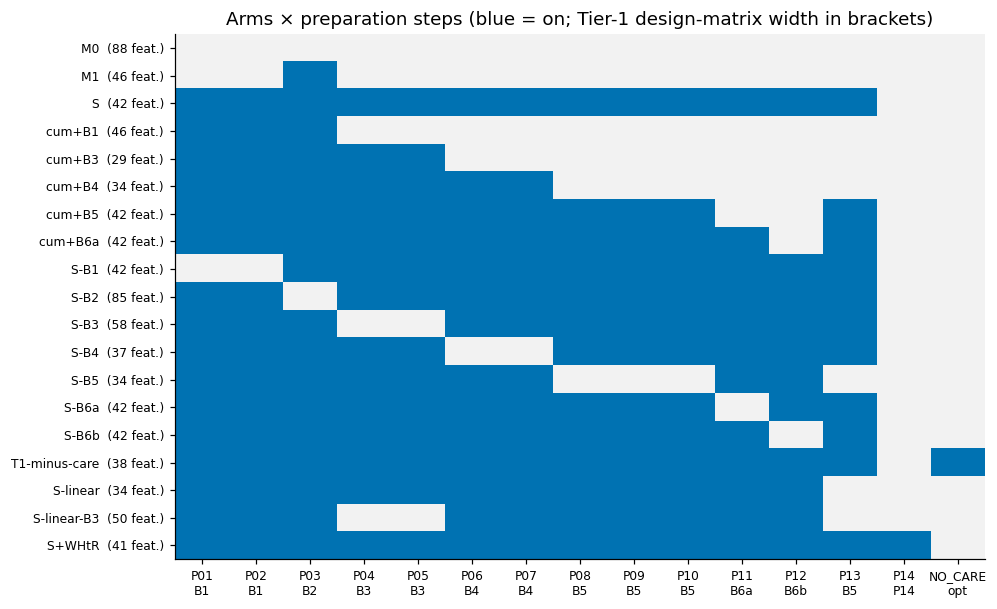

In [151]:
# Build the arm table (which steps are on in each experimental arm) and count the design-matrix width of
# every arm per tier. Only preprocessing is fitted here, never a model. Writes results/S6/arm_table.csv.
arms = P.arm_table()
arms.to_csv(OUT / "arm_table.csv")
# nfeat[(arm, tier)] = number of columns after the arm's preprocessing, fitted on the training part.
nfeat = {}
for a, cfg in P.ARMS.items():
    for t, X in ((1, X1_tr), (2, X2_tr)):
        nfeat[(a, t)] = Pipeline(P.preprocessor_steps(cfg, t)).fit_transform(X).shape[1]
# Reshape (arm, tier) pairs into one row per arm with a column per tier.
nfeat = pd.Series(nfeat).unstack().rename(columns={1: "n_features_T1", 2: "n_features_T2"})
display(arms.join(nfeat))
S6["arms"] = {a: {**{k: bool(v) for k, v in c.items()}, "n_features_t1": int(nfeat.loc[a, "n_features_T1"]),
                  "n_features_t2": int(nfeat.loc[a, "n_features_T2"])} for a, c in P.ARMS.items()}

# Heat map of arms (rows) by preparation steps (columns): blue = step switched on.
fig, ax = plt.subplots(figsize=(9.5, 6.2))
mat = arms[list(P.STEPS) + ["NO_CARE"]]
# Two-colour map: light grey for off (0), Okabe-Ito blue for on (1); colour-blind safe.
ax.imshow(mat.to_numpy(), cmap=plt.matplotlib.colors.ListedColormap(["#f2f2f2", C.OKABE_ITO["blue"]]), aspect="auto")
ax.set_xticks(range(mat.shape[1]), [f"{s}\n{P.STEP_BLOCK.get(s, 'opt')}" for s in mat.columns], fontsize=8)
ax.set_yticks(range(mat.shape[0]), [f"{a}  ({nfeat.loc[a, 'n_features_T1']} feat.)" for a in mat.index], fontsize=8)
ax.grid(False)
ax.set_title("Arms × preparation steps (blue = on; Tier-1 design-matrix width in brackets)")
plots.savefig(fig, "S6_arm_matrix", caption="Which preparation steps are switched on in each experimental arm (blue). "
              "M0 = naive with leakage, M1 = availability rule only, S = all steps; S-Bk = leave-one-block-out.")
plt.show()

**So what.** M0 feeds 88 columns (Tier 1) to the model, M1 46 and S 42. S is *narrower* than M1 although it adds
spline bases, indicators and flags, because aggregation and pruning remove redundant columns. Every arm
differs from its comparator in exactly the steps named in its label, which is what makes the paired
differences in §7 interpretable.

## 6.10 Pipeline assertions
**Why.** The ablation is only meaningful if the switches do what they claim. Four checks:
(a) all switches off reproduces an independently written naive M0; (b) P08/P09 do not change a tree's
predictions; (c) no preparation step reads the label; (d) a disabled Toggle is exactly the identity.

In [152]:
# Four assertions about the switch machinery: M0 equivalence, tree invariance to P08/P09, no step reads y,
# and the identity of a disabled Toggle. Any failure stops the notebook. Writes S6['assertions'].
checks = {}
for t, X in ((1, X1_tr), (2, X2_tr)):
    # (a) With every switch off, the switch machinery must reproduce an independently written naive M0.
    y0 = P.training_label(raw_tr, P.ALL_OFF)
    with warnings.catch_warnings():
        # Unscaled logistic fits warn about convergence; that is expected for M0 and not what is tested here.
        warnings.simplefilter("ignore")
        # a = switchable pipeline with all steps off; b = independent reference implementation.
        a = P.build_pipeline(P.ALL_OFF, t).fit(X, y0).predict_proba(X)[:, 1]
        b = P.naive_m0_reference(t, X).fit(X, y0).predict_proba(X)[:, 1]
    checks[f"m0_equiv_T{t}_maxabs"] = float(np.abs(a - b).max())
    # Tolerance 1e-9: both fits are deterministic, so only floating-point noise is allowed.
    assert checks[f"m0_equiv_T{t}_maxabs"] < 1e-9

# (b) Trees are invariant to monotone transforms, so P08 (power) and P09 (scale) must not change them.
ys = P.training_label(raw_tr, P.ARMS["S"])
tree_s = P.build_pipeline(P.ARMS["S"], 1, model="tree").fit(X1_tr, ys).predict_proba(X1_tr)[:, 1]
cfg_nt = {**P.ARMS["S"], "P08": False, "P09": False}
tree_n = P.build_pipeline(cfg_nt, 1, model="tree").fit(X1_tr, ys).predict_proba(X1_tr)[:, 1]
checks["tree_p08_p09_maxabs"] = float(np.abs(tree_s - tree_n).max())
# Exact equality, not a tolerance: monotone transforms leave tree splits and thus predictions unchanged.
assert checks["tree_p08_p09_maxabs"] == 0.0

# (c) Leakage guard: a preparation step must not read the label. Compare designs fitted with the true label
# and with a permuted label; a seed derived from the master seed keeps the permutation reproducible.
rng = np.random.default_rng(ek.derive_seed(C.SEED_MASTER, "S6", "random_y"))
y_rand = rng.permutation(ys)
for t, X in ((1, X1_tr), (2, X2_tr)):
    # Three arms: S and S+WHtR (all steps on, without and with P14) and M1 (availability rule only).
    for cfg_name in ("S", "S+WHtR", "M1"):
        pre = lambda: Pipeline(P.preprocessor_steps(P.ARMS[cfg_name], t))
        # za / zb = design matrices from fitting on the true / permuted label; they must be bit-identical.
        za, zb = pre().fit(X, ys).transform(X), pre().fit(X, y_rand).transform(X)
        assert za.columns.equals(zb.columns) and np.array_equal(za.to_numpy(float), zb.to_numpy(float), equal_nan=True)
checks["no_step_reads_y"] = True

# (d) A Toggle that is switched off must pass its input through untouched (same object, not a copy).
for name, step in [("P01", P.XptZeroFix()), ("P03", P.Admissibility(1)), ("P04", P.Aggregate()),
                   ("P05", P.VIFPrune()), ("P06", P.MissingIndicator()), ("P07", P.TopcodeFlags()),
                   ("P08", P.YeoJohnson()), ("P09", P.Scale()), ("P13", P.Splines(("RIDAGEYR",))), ("P14", P.WHtR())]:
    tog = P.Toggle(step, enabled=False).fit(X1_tr)
    assert tog.transform(X1_tr) is X1_tr
checks["disabled_toggle_is_identity"] = True
print(json.dumps(checks, indent=1))
S6["assertions"] = checks

{
 "m0_equiv_T1_maxabs": 8.881784197001252e-16,
 "m0_equiv_T2_maxabs": 1.4988010832439613e-15,
 "tree_p08_p09_maxabs": 0.0,
 "no_step_reads_y": true,
 "disabled_toggle_is_identity": true
}


**So what.** All four checks pass: (a) the switch machinery with everything off reproduces the naive M0 to machine
precision (max |Δp| printed), so "M0" in §7 is the naive analyst and not an artefact of our code; (b) the tree
arm is exactly invariant to P08/P09, as monotone transforms must be; (c) fitting the preparation on a permuted
label gives bit-identical design matrices for S, S+WHtR and M1 – no step peeks at y; (d) disabled toggles
return their input unchanged.

## 6.11 Hypotheses and pre-registration lock
**Why.** A block ablation tempts post-hoc storytelling. The block hypotheses (direction, magnitude, SESOI,
falsifier and honest `prior_exposure`) and the verdict rules are therefore written to
`governance/hypotheses.md` and locked by a dedicated commit **before** the first ablation result is
committed. The lock is the file's SHA-256 recorded in that commit; git history shows the order. Besides the three
exposure labels of §1.5, block hypotheses may carry `prototype_seen` = the pattern was seen in the pilot analysis.

In [153]:
# Parse the hypotheses table from governance/hypotheses.md, check its structure and verify the
# pre-registration lock via git history (lock commit, SHA-256, order versus the first ablation commit).
HYP = C.GOVERNANCE_DIR / "hypotheses.md"
text = HYP.read_text(encoding="utf-8")
# Table rows start with '| '; skip the header row and the markdown separator row.
rows = [l for l in text.splitlines() if l.startswith("| ") and not l.startswith("| hyp_id") and not l.startswith("|---")]
import re
# Split on pipes that are not escaped (backslash-pipe); keep the first 10 columns.
hyp = pd.DataFrame([[c.strip() for c in re.split(r"(?<!\\)\|", l.strip().strip("|"))][:10] for l in rows],
                   columns=["hyp_id", "rq_or_block", "statement", "metric", "direction", "magnitude", "sesoi",
                            "falsifier", "prior_exposure", "weights"])
# Block-level hypotheses: B1..B6b, B2t and the P14 arm.
blocks_h = hyp[hyp["hyp_id"].str.match(r"^(B\d|P14)")]
# Guard: all nine block hypotheses must be present in the locked file.
assert set(blocks_h["hyp_id"]) >= {"B1", "B2", "B2t", "B3", "B4", "B5", "B6a", "B6b", "P14"}
# Guard: every hypothesis declares how much the authors had already seen (the allowed exposure labels only).
assert blocks_h["prior_exposure"].str.match(r"^(none|analysis_seen|descriptive_seen|prototype_seen)").all()
_show = blocks_h.assign(prior=blocks_h["prior_exposure"].str.split(" ").str[0], sesoi=blocks_h["sesoi"].str[:40])
display(_show[["hyp_id", "direction", "sesoi", "prior"]])
print("\nprior_exposure counts (all hypotheses):", hyp["prior_exposure"].str.split(" ").str[0].value_counts().to_dict())

# SHA-256 of the file as it is now; compared below with the hash recorded in the lock commit.
sha_now = hashlib.sha256(HYP.read_bytes()).hexdigest()
LOCK_FILE = OUT / "prereg_lock.json"
lock = None
# Look up the lock commit in git history; fails softly when git or the repository is unavailable.
try:
    # --fixed-strings: the marker contains parentheses, which must not be read as a regex.
    log = subprocess.run(["git", "log", "--format=%H%x1f%cI%x1f%B%x1e", "--grep=lock hypotheses.md (prereg-lock)",
                          "--fixed-strings", "--", "governance/hypotheses.md"],
                         cwd=C.ROOT, capture_output=True, text=True, check=True).stdout
    # Entries end with the record separator (0x1e); the oldest match (last in log order) is the lock.
    entries = [e.strip("\n") for e in log.split("\x1e") if e.strip()]
    if entries:
        h, ts, body = entries[-1].split("\x1f")
        # The commit message records the SHA-256 as a 64-character hexadecimal word.
        recorded = next(w for w in body.split() if len(w) == 64 and all(ch in "0123456789abcdef" for ch in w))
        # Re-hash the file as stored in the lock commit rather than trusting the message alone.
        locked_bytes = subprocess.run(["git", "show", f"{h}:governance/hypotheses.md"], cwd=C.ROOT,
                                      capture_output=True, check=True).stdout
        sha_locked = hashlib.sha256(locked_bytes).hexdigest()
        # Governance guard: the recorded hash must equal the real hash of the file at the lock commit.
        assert sha_locked == recorded, "hypotheses.md at the lock commit does not match the recorded SHA-256"
        # First ablation-results commit, used to prove the lock came earlier.
        first_exp = subprocess.run(["git", "log", "--reverse", "--format=%H %cI", r"--grep=^exp\(S7\)", "-E"],
                                   cwd=C.ROOT, capture_output=True, text=True).stdout.split("\n")[0].split()
        lock = dict(commit=h, timestamp=ts, sha256=sha_locked, first_exp_commit=first_exp[0] if first_exp else None,
                    first_exp_timestamp=first_exp[1] if first_exp else None)
        if first_exp:
            # Guard: the lock commit must precede the first ablation commit (hypotheses fixed first).
            assert subprocess.run(["git", "merge-base", "--is-ancestor", h, first_exp[0]], cwd=C.ROOT).returncode == 0, \
                "first exp(S7) commit does not descend from the lock commit"
        LOCK_FILE.write_text(json.dumps(lock, indent=1), encoding="utf-8")
# No git available (e.g. assembled notebook run elsewhere): fall back to the stored record below.
except (OSError, subprocess.CalledProcessError, StopIteration):
    pass
# Fallback: use the lock record stored with the results.
if lock is None and LOCK_FILE.exists():   # no git available (e.g. the assembled notebook): use the stored record
    lock = json.loads(LOCK_FILE.read_text(encoding="utf-8"))
if lock:
    print(f"\nprereg-lock commit {lock['commit'][:12]}  at {lock['timestamp']}")
    print(f"SHA-256 at lock   {lock['sha256']}")
    print(f"SHA-256 now       {sha_now}  ({'unchanged' if sha_now == lock['sha256'] else 'post-lock amendments appended'})")
    print(f"first exp(S7) commit: {lock.get('first_exp_commit') or 'none yet'} {lock.get('first_exp_timestamp') or ''}")
else:
    print(f"\nNOT YET LOCKED – current SHA-256 {sha_now}")
S6["hypotheses"] = dict(n_total=len(hyp), block_ids=list(blocks_h["hyp_id"]), sha256_now=sha_now, lock=lock)

,hyp_id,direction,sesoi,prior
8,B1,none (equivalence),0.01,analysis_seen
9,B2,lower,0.05,prototype_seen
10,B2t,as stated,–,none
11,B3,(a) none; (b) ratio above 1; (c) lower with B3,0.01 AUC; SD ratio 2,prototype_seen
12,B4,(a) none; (b) lower,0.01 AUC; 0.005 Brier,descriptive_seen
13,B5,"(a) lower; (b), (c) higher",0.01 AUC,descriptive_seen
14,B6a,(a) none; (b) higher (worse); (c) higher,0.01 AUC; 0.005 Brier; 0.05 balanced acc,none
15,B6b,non-inferiority,0.01,none
16,P14,(a) none; (b) higher,0.01 AUC; 0.05 TPR,descriptive_seen



prior_exposure counts (all hypotheses): {'none': 6, 'analysis_seen': 5, 'descriptive_seen': 4, 'prototype_seen': 2}

prereg-lock commit 9fb6aefd8a15  at 2026-10-11T02:17:18+08:00
SHA-256 at lock   de032f4d200fa1ff9e51affd75d35183bf351714374cb35acf261b66b611610c
SHA-256 now       de032f4d200fa1ff9e51affd75d35183bf351714374cb35acf261b66b611610c  (unchanged)
first exp(S7) commit: f2ba69dccc160ff66a0cf9b9d59382d50b1ea483 2026-10-11T02:34:13+08:00


**So what.** Nine block-level hypotheses join the eight scope hypotheses. Only B2t, B6a and B6b are genuine
pre-registrations (`none`); B1 rests on damage counted in §3.4/§6.3, B2 and B3 on an earlier pilot analysis, B4
on the missingness table of §6.6, B5 on the linearity tests of §4.11 and P14 on the single-feature AUCs of §5.5 –
all disclosed. The lock commit, its timestamp and the SHA-256 recomputed from that commit are printed above; §7
results were committed only after it.

## 6.12 Outputs

Decisions of this section (`governance/register/S6.csv`) and the stored results (`results/metrics_S6.json`,
`results/S6/`).

In [154]:
# Display the decisions register for this section and write the section results JSON.
reg = pd.read_csv(C.GOVERNANCE_DIR / "register" / "S6.csv")
display(reg[["dr_id", "type", "decision"]])
R.save_section("S6", S6)
print("saved results/metrics_S6.json")

,dr_id,type,decision
0,DR-S6-01,arm_design,"Arms M0 (naive, leakage), M1 = M0 + P03, S = P01-P13; headline comparison M1..."
1,DR-S6-02,sentinels,"P02 is a Switch: off = blanket recode (M0 behaviour), on = codebook codes pe..."
2,DR-S6-03,xpt_fix,P01 as a stateless step with mask() (NaN preserved); its effect is measured ...
3,DR-S6-04,admissibility,P03 keeps spec features with admissible T1 (Tier 1) or T1/T2 (Tier 2); expli...
4,DR-S6-05,aggregation,"P04 = mean of the 3 SBP, DBP and pulse readings plus weekly moderate and vig..."
5,DR-S6-06,redundancy,"P05 iterative VIF > 10 pruning fitted in each training fold, BMI and waist (..."
6,DR-S6-07,missingness,"P06 indicators for INDFMPIR, BMXWAIST, bp_sys_mean, LBXTC; P07 flags age 80+..."
7,DR-S6-08,representation,"P13 SplineTransformer(n_knots=4, degree=3, quantile knots, linear extrapolat..."
8,DR-S6-09,weights,S includes P11 class_weight='balanced' and P12 WTPH2YR/mean; their effects a...
9,DR-S6-10,arm_design,Add S-linear-B3; B3b/H2b compare per-SD BMI coefficient SDs on S-linear (and...


saved results/metrics_S6.json


# §7 Experiments and Block Ablation

**Section lead:** D

The model is used as a **measuring instrument** for the preparation decisions of §6: one estimator (L2
logistic regression, C frozen) is applied to every arm on the same stored folds, and each block is judged
against its locked hypothesis with paired intervals. Two populations get equal weight:

* **E-ALL** – the whole training part, label `L_comb` (84 % of the positives already know their diagnosis);
* **E-SCREEN** – people *not* told they have diabetes, positive = HbA1c ≥ 6.5 % (the screening use case).

The 20 % internal hold-out is kept out of all §7 fitting and scoring; its single use is §9.11, after `exp-freeze`.

In [155]:
new_section()

In [156]:
import json, textwrap, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy import stats

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek

from IPython.display import display
pd.set_option("display.width", 150, "display.max_columns", 30, "display.max_colwidth", 60)


def show(df, digits=3):
    """Display a table as HTML (long text wraps; keeps the text output narrow)."""
    display(df.style.hide(axis="index").format(precision=digits, na_rep="")
            .set_properties(**{"text-align": "left", "white-space": "normal"}))


OUT = C.RESULTS_DIR / "S7"
OUT.mkdir(parents=True, exist_ok=True)
import os
os.environ.setdefault("PYTHONWARNINGS", "ignore::UserWarning")   # silence worker-side solver warnings (counted in run_arm_cv)
N_JOBS = min(12, max(1, (os.cpu_count() or 2) - 2))
# FAST mode (re-run setting) uses fewer coefficient-bootstrap replicates than config.N_BOOT_COEF: the unscaled arms
# reach the solver's iteration limit in every refit, which makes this the slowest step of the section. FINAL is unchanged.
B_COEF = C.N_BOOT_COEF if C.IS_FINAL else 30
S7 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_boot_coef": B_COEF}
T_START = time.time()
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, coefficient bootstrap B = {B_COEF}, {N_JOBS} workers")

mode FINAL: 5x5 CV, B = 1000, coefficient bootstrap B = 500, 12 workers


## 7.1 Splits
**Why.** Every arm must be scored on identical folds, otherwise paired differences mix model effects with
split noise. The hold-out (20 %, label × race stratified; created once at its first use in §6, DR-S6-12) and the
repeated stratified folds are stored with SHA-256 hashes and re-verified on every run. Folds are stratified on
the four label strata so that each fold holds a fair share of the 152 undiagnosed cases that define E-SCREEN.

In [157]:
# Rebuild the training part from the stored hold-out split and verify the stored repeated folds (§7.1).
# Reads the raw and labelled cohorts; produces X, y, esc, y_esc and folds; prints hashes. Hold-out rows are
# never scored.
raw = P.raw_cohort()
clean = L.add_labels(io.build_cohort())
# Guard: the raw (unprepared) and labelled cohorts must list the same people in the same order.
assert (raw["SEQN"].to_numpy() == clean["SEQN"].to_numpy()).all()
# The hold-out indices come from the stored split (created once); only the training part `tr` is used below.
tr, te = ek.make_holdout(clean)
raw_tr = raw.iloc[tr].reset_index(drop=True)
cl = clean.iloc[tr].reset_index(drop=True)
# Raw feature frames per feature tier; preparation steps are fitted later, inside each training fold.
X = {1: P.raw_feature_frame(raw_tr, 1), 2: P.raw_feature_frame(raw_tr, 2)}
# E-ALL target is L_comb; esc marks the E-SCREEN population (people not told they have diabetes).
y = cl["L_comb"].to_numpy()
esc = cl["in_escreen"].eq(1).to_numpy()
y_esc = cl["y_escreen"].fillna(0).astype(int).to_numpy()   # only scored inside the E-SCREEN mask
# Folds are stratified on the four label strata so the rare undiagnosed cases are spread over all folds.
strat = cl["stratum_3x3"].astype(str).to_numpy()
# Stored, hash-verified repeated stratified folds: every arm is scored on the same folds (paired comparisons).
folds = ek.make_folds(y, strat)
n = len(y)
# Train/test sizes of one fold; the Nadeau-Bengio variance correction needs them.
n_test_fold = n / C.CV_SPLITS
n_train_fold = n - n_test_fold
# Hold-out metadata is read only to print and store the hash of its test SEQNs, never to evaluate.
hold = json.loads((C.RESULTS_DIR / "splits" / "holdout.json").read_text(encoding="utf-8"))
print(f"training part {n:,} rows ({y.sum()} L_comb positives); hold-out {len(te):,} rows - not evaluated in S7")
print(f"E-SCREEN in training part: {esc.sum():,} rows, {y_esc[esc].sum()} positives (HbA1c >= 6.5, not diagnosed)")
print(f"folds: {len(folds)} = {folds.n_splits} x {folds.n_repeats}, hash {folds.hash[:16]}..., file {folds.path.name}")
print(f"hold-out test SEQN SHA-256 {hold['sha256_test_seqn'][:16]}...")
# Positives per test fold in both populations: shows how few E-SCREEN cases each fold holds.
per_fold = pd.DataFrame([{"fold": i, "n_test": len(t), "pos_eall": int(y[t].sum()), "pos_escreen": int(y_esc[t][esc[t]].sum())}
                         for i, (_, t) in enumerate(folds)])
display(per_fold.describe().loc[["min", "mean", "max"], ["n_test", "pos_eall", "pos_escreen"]].round(1))
S7["splits"] = dict(n_train=n, n_holdout=len(te), n_pos_eall=int(y.sum()), n_escreen=int(esc.sum()),
                    n_pos_escreen=int(y_esc[esc].sum()), folds_hash=folds.hash, folds_file=folds.path.name,
                    holdout_sha256=hold["sha256_test_seqn"], pos_escreen_per_fold_min=int(per_fold["pos_escreen"].min()))

training part 4,584 rows (777 L_comb positives); hold-out 1,146 rows - not evaluated in S7
E-SCREEN in training part: 3,934 rows, 127 positives (HbA1c >= 6.5, not diagnosed)
folds: 25 = 5 x 5, hash 0d20f8f706ebf1e1..., file folds_FINAL.npz
hold-out test SEQN SHA-256 616fd0590bec7b92...


,n_test,pos_eall,pos_escreen
min,916.0,155.0,25.0
mean,916.8,155.4,25.4
max,917.0,156.0,26.0


**So what.** Each fold holds about 155 E-ALL positives but only about 24 E-SCREEN positives. E-SCREEN is
therefore scored on the pooled out-of-fold vector (paired bootstrap), not fold by fold, and most E-SCREEN
verdicts are expected to be inconclusive. The hold-out hash is printed so that §9.11 can show that the split and the file were unchanged
and that none of its rows were scored or fitted in §6–§9. (The §4/§5 diagnostics did use all adults; see §9.11.)

## 7.2 Data-justified model choice
**Why.** Only basic interpretable models are allowed (logistic regression and shallow trees). Within that constraint
each modelling choice is tied to a diagnostic number from the §4 model-justification table, with the reason for *not*
choosing the alternative.

In [158]:
# Read the stored §4 diagnostics (linearity, interactions, VIF) and tabulate which diagnostic justifies which
# choice (§7.2).
# Writes model_choice.csv; nothing is fitted here except the S design used to count parameters.
S4dir = C.RESULTS_DIR / "S4"
lin = pd.read_csv(S4dir / "linearity_tests.csv")
inter = pd.read_csv(S4dir / "interaction_tests.csv")
daj = pd.read_csv(S4dir / "daj_table.csv")
vif4 = pd.read_csv(S4dir / "vif_table.csv")
print("§4 RCS linearity tests (4 knots vs linear, df 2):")
display(lin[["label", "n", "n_events", "chi2", "p", "nonlinear"]].round(4))
print("§4 interaction tests (primary spec A):")
display(inter[inter["spec"] == "A_primary"][["term", "chi2", "df", "p", "verdict"]].round(4))
# Sex x BMI p-value in every specification, printed rather than summarised.
sx = inter[inter["term"] == "sex_x_bmi"].set_index("spec")["p"].round(3).to_dict()
# Parameters of the S arm after preparation: columns of the fitted transformer (final estimator dropped).
epv_den = {t: P.build_pipeline(P.ARMS["S"], t)[:-1].fit_transform(X[t]).shape[1] for t in (1, 2)}
# Events per parameter (EPV) = positives / parameters, a rule of thumb for overfitting risk.
epv = {t: round(y.sum() / k, 1) for t, k in epv_den.items()}
print(f"\nsex x BMI by spec: {sx}")
print(f"events per parameter in S: Tier 1 {y.sum()}/{epv_den[1]} = {epv[1]}, Tier 2 {y.sum()}/{epv_den[2]} = {epv[2]}")
print(f"imbalance: prevalence {y.mean():.3f} in the training part")
lin_i = lin.set_index("variable")
# Variables quoted as evidence for non-linearity.
nl = ["RIDAGEYR", "BMXBMI", "LBDHDD", "LBXTC"]
ia = inter[inter["spec"] == "A_primary"].set_index("term")
# VIFs of raw weight/height/BMI/waist and of the six blood-pressure readings: evidence for collinearity
# handling.
vr = vif4[vif4["set"] == "raw_anthropometry"].set_index("variable")["vif"]
vb = vif4.loc[vif4["set"] == "bp_readings", "vif"]
ev_nonlin = ", ".join(f"{lin_i.loc[v, 'label']} {lin_i.loc[v, 'chi2']:.1f}" for v in nl) + f" (all p < {lin_i.loc[nl, 'p'].max():.3f})"
ev_inter = (f"race x BMI p {ia.loc['race_x_bmi', 'p']:.2f}, Asian x BMI p {ia.loc['asian_x_bmi', 'p']:.2f} "
            f"(MDE {ia.loc['asian_x_bmi', 'mde']:.2f} log-OR)")
ev_coll = f"weight VIF {vr['BMXWT']:.1f}, BMI {vr['BMXBMI']:.1f}; 6 BP readings {vb.min():.1f}-{vb.max():.1f}"
# One row per modelling question: evidence, decision, and why the alternative was rejected.
choice = pd.DataFrame([
    ("non-linearity", ev_nonlin, "L2 logistic regression + B-spline basis (P13)", "categorised bands (arbitrary cut-points, information loss); GAM / boosting (outside the allowed model class)"),
    ("interactions", ev_inter, "no interaction terms; Asian BMI bias treated as a measurement issue (P14, S8)", "interaction terms add variance without detectable gain"),
    ("collinearity", ev_coll, "aggregate + in-fold VIF pruning (P04/P05), L2 as second defence", "L1 (unstable selection among collinear columns, sensitivity only)"),
    ("sample size", f"{y.sum()} events / {epv_den[1]} parameters (EPV {epv[1]})", "unpenalised fit would be acceptable; mild L2 (C0) chosen by inner CV", "deep trees / ensembles (overfit, outside the allowed model class)"),
    ("imbalance", f"prevalence {y.mean():.1%}", "no resampling; class_weight tested as block B6a", "SMOTE (breaks calibration and the survey design)"),
    ("thresholds / leakage", "clinical cut-points and leakage need inspection", "depth-3 tree (min leaf 50) as a probe only", "tree as main model (step functions, unstable)"),
], columns=["diagnostic", "evidence (S4 / S7)", "decision", "why not the alternative"])
choice.to_csv(OUT / "model_choice.csv", index=False)
show(choice)
S7["model_choice"] = dict(linearity=lin.set_index("label")[["chi2", "p"]].round(4).to_dict("index"),
                          sex_x_bmi_p_by_spec=sx, epv=epv, n_params=epv_den)

§4 RCS linearity tests (4 knots vs linear, df 2):


,label,n,n_events,chi2,p,nonlinear
0,age,4478,722,57.6075,0.0000,True
1,BMI,4478,722,11.5618,0.0031,True
2,waist,4478,722,7.0540,0.0294,True
3,SBP (mean),4478,722,5.8698,0.0531,False
4,HDL,4478,722,18.4670,0.0001,True
5,total cholesterol,4478,722,41.7673,0.0000,True
6,PIR,4478,722,0.8344,0.6589,False


§4 interaction tests (primary spec A):


,term,chi2,df,p,verdict
0,race_x_bmi,5.1890,5,0.3933,not detected
1,asian_x_bmi,0.0071,1,0.9328,not detected
2,age_x_bmi,0.5829,1,0.4452,not detected
3,sex_x_bmi,6.9951,1,0.0082,detected



sex x BMI by spec: {'A_primary': 0.008, 'B_minimal': 0.833, 'C_splines': 0.072}
events per parameter in S: Tier 1 777/42 = 18.5, Tier 2 777/53 = 14.7
imbalance: prevalence 0.170 in the training part


diagnostic,evidence (S4 / S7),decision,why not the alternative
non-linearity,"age 57.6, BMI 11.6, HDL 18.5, total cholesterol 41.8 (all p < 0.003)",L2 logistic regression + B-spline basis (P13),"categorised bands (arbitrary cut-points, information loss); GAM / boosting (outside the allowed model class)"
interactions,"race x BMI p 0.39, Asian x BMI p 0.93 (MDE 0.70 log-OR)","no interaction terms; Asian BMI bias treated as a measurement issue (P14, S8)",interaction terms add variance without detectable gain
collinearity,"weight VIF 95.7, BMI 97.6; 6 BP readings 8.8-11.7","aggregate + in-fold VIF pruning (P04/P05), L2 as second defence","L1 (unstable selection among collinear columns, sensitivity only)"
sample size,777 events / 42 parameters (EPV 18.5),unpenalised fit would be acceptable; mild L2 (C0) chosen by inner CV,"deep trees / ensembles (overfit, outside the allowed model class)"
imbalance,prevalence 17.0%,no resampling; class_weight tested as block B6a,SMOTE (breaks calibration and the survey design)
thresholds / leakage,clinical cut-points and leakage need inspection,depth-3 tree (min leaf 50) as a probe only,"tree as main model (step functions, unstable)"


**So what.** Age, BMI and both lipids bend significantly, so the main model uses spline terms; the linear version
stays as the ablation arm *S-linear*. Race × BMI and Asian × BMI are not detected (underpowered: "not detected" is
not "absent"). Sex × BMI is significant in §4's primary specification only (p by specification printed above), so
no interaction term is added and the point is a limitation. With about 18 events per parameter overfitting risk is
modest; L2 mainly stabilises the correlated anthropometrics. In-fold VIF > 10 pruning with BMI and waist protected
(P05) removes only weight (§6.5).

## 7.3 Regularisation strength C0
**Why.** A fair minimal-versus-systematic comparison requires the *same model* in every arm. C is therefore chosen once – by
`LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10])`, inner 5-fold ROC-AUC, on the S arm of Tier 1 with its class and
survey weights – and then frozen for every arm. Choosing it on S favours S slightly (the other arms do not get
their own tuning); M0 and M1 with their own C are a §9.4 sensitivity. C0 was chosen once on the training part and is
*not* nested inside the outer folds; a nested check is reported in §9 (post-audit corrections).

In [159]:
# Choose the L2 strength C0 once, by inner 5-fold CV on the S arm (Tier 1), and freeze it for all arms (§7.3).
# Reads the training part; produces C0 and the inner-CV AUC per candidate C (stored with the section results).
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold

# Design matrix of the S arm after its preparation steps (final estimator dropped); label and weights follow.
cfgS = P.ARMS["S"]
design = P.build_pipeline(cfgS, 1)[:-1].fit_transform(X[1])
ylab = P.training_label(raw_tr, cfgS)
# Inner splitter seeded from the master seed, so the choice of C0 is reproducible.
inner = StratifiedKFold(5, shuffle=True, random_state=ek.derive_seed(C.SEED_MASTER, "S7", "C0"))
# Pure L2 via l1_ratios=(0.0,); class weights and survey weights match how the S arm is fitted.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    lrcv = LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10], cv=inner, scoring="roc_auc", max_iter=C.LR_MAX_ITER,
                                class_weight="balanced", l1_ratios=(0.0,), use_legacy_attributes=False)
    lrcv.fit(design, ylab, sample_weight=P.survey_weights(raw_tr))
scores = np.asarray(lrcv.scores_).reshape(5, -1)   # (inner folds, Cs); l1_ratio fixed at 0 (pure L2)
# Selected C (a single value because l1_ratio is fixed at 0).
C0 = float(np.ravel(lrcv.C_)[0])
# Mean inner-CV AUC for each candidate C, to judge how sensitive results are to the penalty.
cv_auc = pd.Series(scores.mean(axis=0).ravel()[:4], index=[0.01, 0.1, 1, 10]).round(4)
print("inner-CV ROC-AUC by C:"); print(cv_auc.to_string())
print(f"C0 = {C0} (frozen for all arms and tiers)")
S7["C0"] = dict(C0=C0, inner_cv_auc=cv_auc.to_dict())

inner-CV ROC-AUC by C:
0.01     0.8490
0.10     0.8519
1.00     0.8515
10.00    0.8514
C0 = 0.1 (frozen for all arms and tiers)


**So what.** The inner-CV AUC is almost flat across C (range about 0.003), so C is not a lever for the results below
and the optimism of tuning on S is expected to be small. Disclosure: C0 was chosen once on the whole training part
(the S-arm preparation steps were fitted on all of it for this one choice), not nested inside the outer folds.
The flat curve suggests the optimism is small; the nested check in §9 (post-audit corrections) tests this.

## 7.4 Running the arms
**Why.** Each arm × tier is cross-validated on the stored folds with the frozen C0; every preparation step is
refitted inside each training fold. Arms with P02 off are trained on their own naive label (965 positives),
but every arm is scored against the frozen `L_comb`. The depth-3 tree is run on M0, M1 and S as a probe.
Solver non-convergence (the unscaled arms) is counted, not suppressed.

In [160]:
# Cross-validate every arm x tier x model on the stored folds with the frozen C0 (§7.4), in parallel workers.
# Produces OOF (out-of-fold predictions per run), PM (repeat-averaged probability per row) and convergence
# counts.
ARM_LIST = list(P.ARMS)
# Logistic regression for every arm in both tiers; the depth-3 tree probe only for M0, M1 and S.
jobs = [(a, t, "lr") for t in (1, 2) for a in ARM_LIST] + [(a, t, "tree") for t in (1, 2) for a in ("M0", "M1", "S")]
t0 = time.time()
# one job per arm x tier x model, each deterministic: the number of workers changes the wall time only (FAST may use
# every core so that the re-run stays within about 5 minutes; FINAL keeps its worker count)
N_JOBS_ARMS = N_JOBS if C.IS_FINAL else max(N_JOBS, (os.cpu_count() or 2) - 2)
# run_arm_cv refits every preparation step inside each training fold, so the test fold never informs
# preparation.
runs = Parallel(n_jobs=N_JOBS_ARMS)(delayed(P.run_arm_cv)(a, t, X[t], raw_tr, folds, C_=C0, model=m) for a, t, m in jobs)
# OOF[(arm, tier, model)] is a long table of out-of-fold probabilities with repeat, fold and row indices.
OOF = {(r["arm"], r["tier"], r["model"]): r["oof"] for r in runs}
PM = {k: ek.mean_oof(v, n) for k, v in OOF.items()}          # repeat-averaged OOF probability per row
diag = pd.DataFrame([{k: r[k] for k in ("arm", "tier", "model", "n_convergence_warnings", "seconds", "n_pos_train_label")}
                     for r in runs])
# Guard: every row received a finite prediction in every run.
assert all(np.isfinite(v).all() for v in PM.values())
for r in runs:   # no hold-out row can appear: OOF rows index the training part only
    assert r["oof"]["row"].max() < n and r["oof"].groupby("repeat")["row"].nunique().eq(n).all()
print(f"{len(jobs)} arm x tier x model runs, {sum(len(f) for f in [folds]) * len(jobs)} fits, {time.time() - t0:.0f} s wall")
print("runs with solver non-convergence (folds at the iteration limit):")
display(diag[diag["n_convergence_warnings"] > 0].round(1))
S7["runs"] = dict(n_runs=len(jobs), wall_seconds=time.time() - t0,
                  convergence=diag[diag["n_convergence_warnings"] > 0][["arm", "tier", "model", "n_convergence_warnings"]].to_dict("records"))

44 arm x tier x model runs, 1100 fits, 108 s wall
runs with solver non-convergence (folds at the iteration limit):


,arm,tier,model,n_convergence_warnings,seconds,n_pos_train_label
0,M0,1,lr,25,60.7,772
1,M1,1,lr,25,43.9,772
3,cum+B1,1,lr,25,43.0,777
4,cum+B3,1,lr,25,39.4,777
5,cum+B4,1,lr,25,40.5,777
12,S-B5,1,lr,25,39.2,777
19,M0,2,lr,24,65.2,772
20,M1,2,lr,25,51.8,772
22,cum+B1,2,lr,25,50.6,777
23,cum+B3,2,lr,25,45.8,777


In [161]:
# Population masks, metric functions and one result row per run: AUC with bootstrap CI, PR-AUC, Brier,
# calibration.
# Writes arm_metrics.csv; E-ALL and E-SCREEN are scored on the pooled (repeat-averaged) OOF vectors.
from sklearn.metrics import roc_auc_score, average_precision_score

def pop_of(name):
    """(label vector, evaluation mask) of a population."""
    if name == "E-ALL":
        return y, np.ones(n, bool)
    if name == "E-SCREEN":
        return y_esc, esc
    if name == "PIR-missing":
        return y, cl["INDFMPIR"].isna().to_numpy()
    raise ValueError(name)

# Balanced accuracy at a fixed 0.5 probability threshold (shows what class weights do to a threshold).
def _bacc05(yy, pp):
    pred = pp >= 0.5
    return 0.5 * (pred[yy == 1].mean() + (~pred[yy == 0]).mean())

# Absolute distance of the calibration slope from its ideal value of 1 (smaller is better).
def _calslope_dev(yy, pp):
    return abs(ek._calibration(yy, pp)[0] - 1.0)

# Metric registry shared by the comparison engine (bootstrap and per-fold values).
METRIC_FN = {"roc_auc": roc_auc_score, "pr_auc": average_precision_score,
             "brier": lambda yy, pp: float(np.mean((pp - yy) ** 2)),
             "bacc05": _bacc05, "calslope_dev": _calslope_dev}

def auc_ci(p, pop="E-ALL", seed_tag="auc"):
    """AUC of a pooled OOF vector with a label-stratified bootstrap CI (paired against a constant 0.5)."""
    yy, m = pop_of(pop)
    # Comparing against a constant 0.5 prediction makes the paired bootstrap return the plain AUC; 0.5 is
    # added back.
    b = ek.paired_bootstrap(yy, p, np.full(n, 0.5), "roc_auc", n_boot=C.N_BOOT, eval_mask=m,
                            seed=ek.derive_seed(C.SEED_MASTER, "S7", seed_tag, pop))
    return b["metric_a"], b["ci_low"] + 0.5, b["ci_high"] + 0.5

# One result row per run: fold-level AUC mean and SD, plus pooled-OOF metrics in both populations.
def arm_row(key):
    oof, pm = OOF[key], PM[key]
    # Per-fold AUC on E-ALL: its mean and SD show how much the split alone moves the metric.
    fm = ek.fold_metrics(oof, y)
    out = {"arm": key[0], "tier": key[1], "model": key[2], "eall_auc_foldmean": fm["roc_auc"].mean(),
           "eall_auc_foldsd": fm["roc_auc"].std(ddof=1)}
    for pop in ("E-ALL", "E-SCREEN"):
        yy, m = pop_of(pop)
        # Metric suite on the repeat-averaged probabilities, restricted to the population mask.
        ms = ek.metric_suite(yy[m], pm[m])
        a, lo, hi = auc_ci(pm, pop, seed_tag=f"{key}")
        tag = "eall" if pop == "E-ALL" else "escr"
        out.update({f"{tag}_auc": a, f"{tag}_auc_lo": lo, f"{tag}_auc_hi": hi, f"{tag}_pr_auc": ms["pr_auc"],
                    f"{tag}_brier": ms["brier"], f"{tag}_recall_spec80": ms["recall_at_spec"],
                    f"{tag}_cal_slope": ms["cal_slope"], f"{tag}_cal_citl": ms["cal_citl"], f"{tag}_prev": ms["prevalence"]})
    # Survey-weighted AUC (WTPH2YR) as a check on the unweighted headline.
    out["eall_auc_weighted"] = ek.metric_suite(y, pm, w=cl[C.WEIGHT_PHLEB].to_numpy())["roc_auc"]
    return out

# The merge attaches solver-convergence counts and timing to each run.
arm_metrics = pd.DataFrame([arm_row(k) for k in OOF]).merge(diag, on=["arm", "tier", "model"])
arm_metrics.to_csv(OUT / "arm_metrics.csv", index=False)
cols_show = ["arm", "model", "eall_auc", "eall_auc_lo", "eall_auc_hi", "escr_auc", "escr_auc_lo", "escr_auc_hi",
             "eall_brier", "escr_recall_spec80", "eall_cal_slope", "n_convergence_warnings"]
# Arms shown in the headline table; all arms and Tier 2 are in the CSV.
main_arms = ["M0", "M1", "S", "T1-minus-care", "S-linear", "S+WHtR"]
tab = arm_metrics[(arm_metrics["tier"] == 1) & arm_metrics["arm"].isin(main_arms)]
print("Tier 1, main arms (all arms and Tier 2: results/S7/arm_metrics.csv):")
display(tab[cols_show].round(3))

Tier 1, main arms (all arms and Tier 2: results/S7/arm_metrics.csv):


,arm,model,eall_auc,eall_auc_lo,eall_auc_hi,escr_auc,escr_auc_lo,escr_auc_hi,eall_brier,escr_recall_spec80,eall_cal_slope,n_convergence_warnings
0,M0,lr,0.961,0.952,0.968,0.844,0.808,0.881,0.040,0.709,1.195,25
1,M1,lr,0.828,0.814,0.843,0.772,0.739,0.804,0.112,0.535,0.961,25
2,S,lr,0.836,0.822,0.849,0.781,0.748,0.809,0.185,0.520,0.867,0
15,T1-minus-care,lr,0.820,0.806,0.835,0.800,0.766,0.832,0.195,0.614,0.873,0
16,S-linear,lr,0.832,0.817,0.845,0.775,0.744,0.806,0.189,0.496,0.849,0
18,S+WHtR,lr,0.835,0.822,0.848,0.782,0.751,0.814,0.186,0.551,0.866,0
38,M0,tree,0.927,0.912,0.941,0.633,0.574,0.689,0.031,0.441,1.239,0
39,M1,tree,0.766,0.748,0.782,0.701,0.663,0.740,0.123,0.433,1.021,0
40,S,tree,0.768,0.751,0.784,0.683,0.646,0.720,0.190,0.354,0.963,0


**So what.** The paired comparisons below decide; three patterns are already visible. The naive arm M0 reaches
an E-ALL AUC near 0.96 that collapses once the availability rule is applied; all admissible arms sit in a narrow
band; and every arm loses discrimination on E-SCREEN. Only the unscaled arms (M0, M1, the cumulative steps before
B5, S−B5) stop at the solver's iteration limit – a cost of skipping scaling, examined post lock in §7.12.1.

### 7.4.1 Comparison engine
Paired difference A − B of a metric on a population: fold-level Nadeau–Bengio corrected t and a paired,
label-stratified bootstrap on the repeat-averaged OOF vectors; on E-ALL the **wider** interval is used, on
E-SCREEN the bootstrap only. The estimate is always the same quantity per population: on E-ALL the mean of the
fold-level paired differences, on E-SCREEN the difference on the pooled OOF vector. The 80 %-power minimal detectable difference (MDD) is reported with each Δ. Verdict
rules are those locked in `governance/hypotheses.md`; for a directional claim an `evalkit` verdict of
"equivalent" (CI inside ±magnitude) means the claimed magnitude is excluded and is recorded as **refuted**.

In [162]:
# Comparison engine (§7.4.1): paired difference A - B with Nadeau-Bengio corrected t and a paired bootstrap,
# plus verdict helpers.
# Produces no results itself; later cells call cmp_(), and COMP collects every comparison row.
# Metric value per (repeat, fold) test set, restricted to the population mask: the input of the corrected
# t-test.
def fold_values(key, metric, pop):
    yy, m = pop_of(pop)
    fn = METRIC_FN[metric]
    vals = {}
    for (r, f), g in OOF[key].groupby(["repeat", "fold"]):
        rows = g["row"].to_numpy()
        keep = m[rows]
        vals[(r, f)] = fn(yy[rows][keep], g["prob"].to_numpy()[keep])
    return pd.Series(vals)

def compare(a, b, tier=1, metric="roc_auc", pop="E-ALL", model="lr", pa=None, pb=None):
    """Paired comparison A - B; pa/pb override the OOF vectors (baselines)."""
    yy, m = pop_of(pop)
    # pa/pb override the OOF vectors, so baselines that are not in OOF (e.g. ADA points) use the same engine.
    pa = PM[(a, tier, model)] if pa is None else pa
    pb = PM[(b, tier, model)] if pb is None else pb
    # The bootstrap knows AUC, Brier and PR-AUC by name; other metrics are passed as functions.
    bm = metric if metric in ("roc_auc", "brier", "pr_auc") else METRIC_FN[metric]
    # Seed derived from arms, tier, metric and population: each comparison is reproducible and independent.
    bs = ek.paired_bootstrap(yy, pa, pb, bm, n_boot=C.N_BOOT, eval_mask=m,
                             seed=ek.derive_seed(C.SEED_MASTER, "S7", a, b, tier, metric, pop))
    row = dict(a=a, b=b, tier=tier, metric=metric, pop=pop, model=model, diff_pooled=bs["diff"],
               boot_lo=bs["ci_low"], boot_hi=bs["ci_high"], boot_se=bs["se"], n_eval=bs["n_eval"], n_pos=bs["n_pos"])
    # The fold-level test needs fold predictions, so it is skipped on E-SCREEN (too few positives per fold).
    if pop != "E-SCREEN" and (a, tier, model) in OOF and (b, tier, model) in OOF:
        # Paired per-fold differences; the J = repeats x folds values are dependent, so the variance needs a
        # correction.
        d = (fold_values((a, tier, model), metric, pop) - fold_values((b, tier, model), metric, pop)).to_numpy()
        # Nadeau-Bengio correction: variance factor (1/J + n_test/n_train) instead of 1/J, because CV training
        # sets overlap.
        ct = ek.corrected_t(d, n_train_fold, n_test_fold)
        row.update(t_mean=ct["mean"], t_lo=ct["ci_low"], t_hi=ct["ci_high"], t_se=ct["se_corr"], t_p=ct["p"], J=ct["J"])
        # Conservative rule on E-ALL: use the wider of the corrected-t and bootstrap intervals.
        use_t = (ct["ci_high"] - ct["ci_low"]) >= (bs["ci_high"] - bs["ci_low"])
        lo, hi, se = (ct["ci_low"], ct["ci_high"], ct["se_corr"]) if use_t else (bs["ci_low"], bs["ci_high"], bs["se"])
        est = ct["mean"]   # one estimand on E-ALL: the fold-mean paired difference (interval = the wider of the two)
        # Minimal detectable difference at 80 % power, two-sided 5 %: (t_0.975 + t_0.80) * SE.
        mdd = (stats.t.ppf(0.975, ct["df"]) + stats.t.ppf(0.80, ct["df"])) * se
        row["interval"] = "corrected_t" if use_t else "bootstrap"
    else:
        # E-SCREEN and fold-less baselines: bootstrap interval only, normal quantiles for the MDD.
        est, lo, hi, se = bs["diff"], bs["ci_low"], bs["ci_high"], bs["se"]
        mdd = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * se
        row["interval"] = "bootstrap"
        # Per-repeat differences show how much the E-SCREEN result depends on a particular CV repeat.
        if pop == "E-SCREEN" and (a, tier, model) in OOF and (b, tier, model) in OOF:
            ra = ek.repeat_metrics(OOF[(a, tier, model)], y_esc, eval_mask=esc).set_index("repeat")
            rb = ek.repeat_metrics(OOF[(b, tier, model)], y_esc, eval_mask=esc).set_index("repeat")
            if metric in ra:
                dr = ra[metric] - rb[metric]
                row.update(rep_min=dr.min(), rep_max=dr.max())
    row.update(est=est, lo=lo, hi=hi, se=se, mdd=mdd)
    return row

# Equivalence verdict for margin s: supported if the whole CI is inside ±s, refuted if it lies fully outside.
def v_equiv(lo, hi, s):
    return "supported" if (lo > -s and hi < s) else ("refuted" if (lo >= s or hi <= -s) else "inconclusive")

# Directional verdict from evalkit; 'equivalent' excludes the claimed magnitude and is recorded as refuted.
def v_dir(lo, hi, est, s, direction):
    v = ek.verdict(lo, hi, s, direction, est)
    return "refuted" if v == "equivalent" else v

# Non-inferiority verdict: supported if the lower bound stays above -s, refuted if the upper bound is below
# -s.
def v_noninf(lo, hi, s):
    return "supported" if lo > -s else ("refuted" if hi < -s else "inconclusive")

COMP = []   # every comparison row, stored in results/S7/comparisons.csv

# Run a comparison, label it and store its row for comparisons.csv.
def cmp_(*args, label="", **kw):
    r = compare(*args, **kw)
    r["label"] = label
    COMP.append(r)
    return r

# Format a comparison row as 'estimate [CI] (interval used, MDD)'.
def fmt(r, k=3):
    return f"{r['est']:+.{k}f} [{r['lo']:+.{k}f}, {r['hi']:+.{k}f}] ({r['interval']}, MDD {r['mdd']:.{k}f})"

## 7.5 Leak gate: M0 → M1
**Why.** M0 keeps glucose, treatment, diagnosis history, prediabetes counselling (DIQ160) and prior glucose
testing (DIQ180). If the availability rule removes real leakage, discrimination must *drop* – a correct
deterioration (hypotheses H2a, B2). A depth-3 tree shows *where* the M0 signal comes from (B2t).

Tier 1 E-ALL    AUC M1 - M0 = -0.131 [-0.148, -0.114] (corrected_t, MDD 0.024)


Tier 1 E-SCREEN AUC M1 - M0 = -0.072 [-0.113, -0.031] (bootstrap, MDD 0.059)


Tier 2 E-ALL    AUC M1 - M0 = -0.119 [-0.133, -0.106] (corrected_t, MDD 0.019)


Tier 2 E-SCREEN AUC M1 - M0 = -0.081 [-0.120, -0.041] (bootstrap, MDD 0.056)


Tier 1 E-ALL    AUC S - (S-B2) = -0.122 [-0.138, -0.105] (corrected_t, MDD 0.023)


Tier 1 E-SCREEN AUC S - (S-B2) = -0.090 [-0.124, -0.060] (bootstrap, MDD 0.047)


arm,root_feature,variable,role,threshold,level2
M0,DIQ070_2.0,DIQ070,leak,0.500,"['DIQ180_2.0', 'DID040']"
M1,BPQ020_2.0,BPQ020,feature,0.500,"['BMXWAIST', 'BMXWAIST']"
S,BPQ020_1.0,BPQ020,feature,0.500,"['BMXWAIST', 'BMXWAIST']"


|--- taking diabetic pills: no <= 0.50
|   |--- blood-glucose test in past 3 years: no <= 0.50
|   |   |--- weights: [43.00, 17.00] class: 0
|   |--- blood-glucose test in past 3 years: no >  0.50
|   |   |--- LDL cholesterol (mg/dL) <= 119.50
|   |   |   |--- weights: [0.00, 430.00] class: 1
|   |   |--- LDL cholesterol (mg/dL) >  119.50
|   |   |   |--- weights: [3.00, 47.00] class: 1
|--- taking diabetic pills: no >  0.50
|   |--- age at diabetes diagnosis <= 49.50
|   |   |--- weights: [0.00, 90.00] class: 1
|   |--- age at diabetes diagnosis >  49.50
|   |   |--- age at diabetes diagnosis <= 50.50
|   |   |   |--- weights: [3766.00, 121.00] class: 0
|   |   |--- age at diabetes diagnosis >  50.50
|   |   |   |--- weights: [0.00, 67.00] class: 1

DID040 (age at diagnosis) is asked only of diagnosed people: missing for 86% of the training part, median-imputed to 50 in M0
tree E-SCREEN AUC: M0 0.633, M1 0.701, S 0.683
B2t verdict: supported


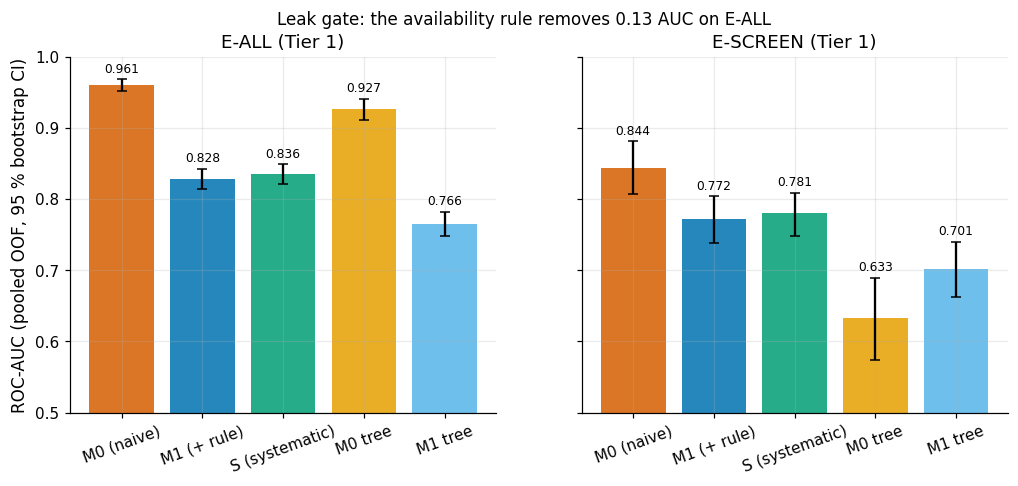

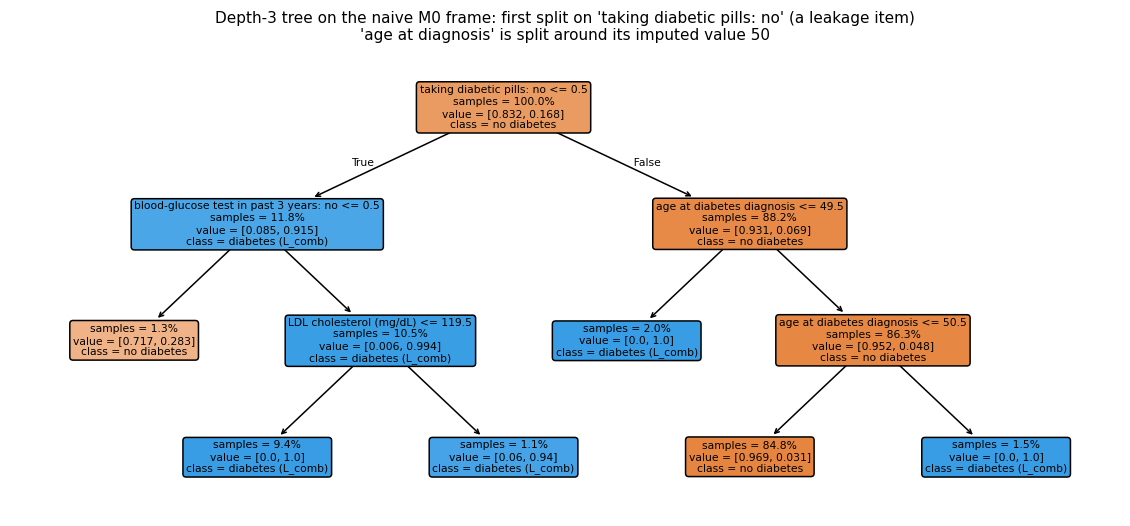

In [163]:
# Leak gate (§7.5): compare M1 with M0 and S with S-B2, and fit depth-3 trees to see where the M0 signal comes
# from.
# Produces the leak-gate figure and the M0 tree plot; the tree verdict (b2t) is computed in code.
from sklearn.tree import plot_tree

gate = {}
# M1 - M0 (negative = leakage removed) in both tiers and both populations.
for t in (1, 2):
    for pop in ("E-ALL", "E-SCREEN"):
        gate[(t, pop)] = cmp_("M1", "M0", t, "roc_auc", pop, label="B2 leak gate")
        print(f"Tier {t} {pop:8s} AUC M1 - M0 = {fmt(gate[(t, pop)])}")
# Leave-one-block-out view of the same block: S minus S without the availability rule.
for pop in ("E-ALL", "E-SCREEN"):
    r = cmp_("S", "S-B2", 1, "roc_auc", pop, label="B2 LOBO")
    print(f"Tier 1 {pop:8s} AUC S - (S-B2) = {fmt(r)}")

# Map an encoded feature name (e.g. 'variable_level') to its source variable by longest-prefix match.
def base_var(name):
    for v in sorted(P._spec_by_var().index, key=len, reverse=True):
        if name == v or name.startswith(v + "_"):
            return v
    return name

# For each tree arm record the root split, its role in the variable spec and the second-level splits.
roots, trees = {}, {}
for arm in ("M0", "M1", "S"):
    cfg = P.ARMS[arm]
    # Depth-3 tree probe fitted on the whole training part (not cross-validated): read for structure, not
    # scored.
    pipe = P.build_pipeline(cfg, 1, model="tree").fit(X[1], P.training_label(raw_tr, cfg), **P.fit_params(cfg, raw_tr))
    names = list(pipe[:-1].get_feature_names_out())
    tree = pipe[-1]
    trees[arm] = (tree, names)
    # tree_.feature[0] is the split feature of the root node; negative feature ids mark leaves.
    root = names[tree.tree_.feature[0]]
    rv = base_var(root)
    # Role of the root variable in the variable spec ('leak' marks inadmissible items).
    role = P._spec_by_var()["role"].get(rv, "derived")
    roots[arm] = dict(root_feature=root, variable=rv, role=role, threshold=float(tree.tree_.threshold[0]),
                      level2=[names[tree.tree_.feature[c]] for c in (tree.tree_.children_left[0], tree.tree_.children_right[0])
                              if tree.tree_.feature[c] >= 0])
show(pd.DataFrame(roots).T.rename_axis("arm").reset_index())
from sklearn.tree import export_text
# Refit the M0 tree to read the median that the imputer used for age at diagnosis.
m0_pipe = P.build_pipeline(P.ARMS["M0"], 1, model="tree").fit(X[1], P.training_label(raw_tr, P.ARMS["M0"]))
# DID040 (age at diagnosis) is asked only of diagnosed people; the tree splits around its imputed constant.
did040_fill = m0_pipe.named_steps["impute"].fill_["DID040"]
did040_miss = float(raw_tr["DID040"].isna().mean())
print(export_text(trees["M0"][0], feature_names=[P.plain_label(c) for c in trees["M0"][1]], show_weights=True))
print(f"DID040 (age at diagnosis) is asked only of diagnosed people: missing for {did040_miss:.0%} of the training part, "
      f"median-imputed to {did040_fill:.0f} in M0")
tree_escr = arm_metrics[(arm_metrics["tier"] == 1) & (arm_metrics["model"] == "tree")].set_index("arm")["escr_auc"]
print(f"tree E-SCREEN AUC: M0 {tree_escr['M0']:.3f}, M1 {tree_escr['M1']:.3f}, S {tree_escr['S']:.3f}")
S7["tree_m0"] = dict(did040_fill=did040_fill, did040_missing_share=did040_miss, escreen_auc=tree_escr.to_dict())
# B2t: supported if the M0 root is a leak item and the M1 root is not an inadmissible ('N') variable.
b2t = "supported" if roots["M0"]["role"] == "leak" and P._spec_by_var()["admissible"].get(roots["M1"]["variable"], "T1") != "N" else "refuted"
print(f"B2t verdict: {b2t}")
S7["leak_gate"] = {f"T{t}_{pop}": {k: gate[(t, pop)][k] for k in ("est", "lo", "hi", "interval", "mdd")} for (t, pop) in gate}
S7["tree_roots"] = roots

# Figure: AUC bars with bootstrap CI for M0, M1, S (logistic) and the M0/M1 trees; E-ALL left, E-SCREEN right.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
bars = [("M0", "lr", "M0 (naive)"), ("M1", "lr", "M1 (+ rule)"), ("S", "lr", "S (systematic)"), ("M0", "tree", "M0 tree"), ("M1", "tree", "M1 tree")]
colors = [C.OKABE_ITO["vermillion"], C.OKABE_ITO["blue"], C.OKABE_ITO["green"], C.OKABE_ITO["orange"], C.OKABE_ITO["sky"]]
for ax, pop, tag in zip(axes, ("E-ALL", "E-SCREEN"), ("eall", "escr")):
    sub = arm_metrics[arm_metrics["tier"] == 1].set_index(["arm", "model"])
    for i, ((a, m, _), c) in enumerate(zip(bars, colors)):
        v_ = sub.loc[(a, m)]
        ax.bar(i, v_[f"{tag}_auc"], color=c, alpha=0.85)
        ax.errorbar(i, v_[f"{tag}_auc"], yerr=[[v_[f"{tag}_auc"] - v_[f"{tag}_auc_lo"]], [v_[f"{tag}_auc_hi"] - v_[f"{tag}_auc"]]],
                    color="k", capsize=3)
        ax.text(i, v_[f"{tag}_auc_hi"] + 0.01, f"{v_[f'{tag}_auc']:.3f}", ha="center", fontsize=8)
    ax.set_xticks(range(len(bars)), [b[2] for b in bars], rotation=20)
    ax.set_ylim(0.5, 1.0)
    ax.set_title(f"{pop} (Tier 1)")
axes[0].set_ylabel("ROC-AUC (pooled OOF, 95 % bootstrap CI)")
fig.suptitle(f"Leak gate: the availability rule removes {-gate[(1, 'E-ALL')]['est']:.2f} AUC on E-ALL", fontsize=11)
plots.savefig(fig, "S7_leak_gate", caption="ROC-AUC of the naive arm M0, the availability-screened arm M1 and the systematic arm S "
              "(logistic regression) and of depth-3 trees, on E-ALL and E-SCREEN, Tier 1, with 95 % bootstrap CIs. "
              "The drop from M0 to M1 is the leakage removed by the availability rule.")
plt.show()

# Figure: the M0 tree, showing the root split on a treatment item and the splits around the imputed value.
fig, ax = plt.subplots(figsize=(13, 5.5))
tree, names = trees["M0"]
plot_tree(tree, feature_names=[P.plain_label(c) for c in names], class_names=["no diabetes", "diabetes (L_comb)"],
          filled=True, impurity=False, proportion=True, rounded=True, fontsize=7, ax=ax)
ax.set_title(f"Depth-3 tree on the naive M0 frame: first split on '{P.plain_label(roots['M0']['root_feature'])}' "
             f"(a leakage item)\n'age at diagnosis' is split around its imputed value {did040_fill:.0f}", fontsize=10)
plots.savefig(fig, "S7_tree_m0", caption="Decision tree (depth 3, min leaf 50) fitted on the naive M0 feature frame (Tier 1, training part). "
              "The root split uses a treatment item that the availability rule removes; the splits at 49.5 / 50.5 on age at diagnosis "
              "isolate the median imputation of an item that is only asked of diagnosed people.")
plt.show()

**So what.** The availability rule removes the "too-good-to-be-true" signal: E-ALL AUC falls by about 0.13, far
beyond the 0.05 locked for B2/H2a. This **deterioration is the correct outcome** – M0 exploited inadmissible items
(treatment, diagnosis history, glucose testing), i.e. the label leaking back in. The tree's root is a *treatment*
item; its age-at-diagnosis splits sit just below and above the median-imputed constant given to everyone never
asked the question. **Imputation has turned skip-pattern missingness into a code for the label.** The leaked tree is
even *worse* for screening than the M1 tree, and the drop is smaller on E-SCREEN, because these items mark the
already diagnosed.

## 7.6 Baselines on E-SCREEN
**Why.** A model is only interesting if it beats what a clinician already has: the reduced ADA risk test (Bang et al.
2009) – age 0–3, male +1, told high blood pressure +1, physically inactive +1, BMI 0–3 points. Family history and
gestational diabetes are not asked in 2021–23, so the score is **reduced** and compared by AUC and recall at
specificity 0.80, not by its cut-off. BL-ADAlite-LR refits the same items on `L_comb`; BL0 is the no-information prior.

In [164]:
# Baselines on E-SCREEN (§7.6): no-information prior, reduced ADA risk score, and its items refitted on
# L_comb.
# Adds BL0, BL-ADAlite-LR and BL-ADAlite to OOF/PM; asserts BL0 has AUC 0.5 in every fold; writes the
# baselines CSV.
from sklearn.dummy import DummyClassifier

# ADA-lite items (age, sex, hypertension, inactivity, BMI points) from the training part; missing answers
# score 0.
ada = P.ada_lite_items(cl)
# BL0: DummyClassifier(prior) gives everyone the training prevalence, so its AUC must be exactly 0.5.
OOF[("BL0", 1, "dummy")] = ek.cv_predict(lambda: DummyClassifier(strategy="prior"), X[1], y, folds)
PM[("BL0", 1, "dummy")] = ek.mean_oof(OOF[("BL0", 1, "dummy")], n)
bl0_fold = ek.fold_metrics(OOF[("BL0", 1, "dummy")], y)["roc_auc"]
# Guard: a no-information model must score 0.5 in every fold, otherwise the evaluation hides optimism.
assert np.allclose(bl0_fold, 0.5), "BL0 must have AUC 0.500 in every fold"
# Refit the same ADA items as a logistic regression (frozen C0) on L_comb, using the stored folds.
OOF[("BL-ADAlite-LR", 1, "lr")] = ek.cv_predict(lambda: P.ada_lr_pipeline(C0), ada, y, folds)
PM[("BL-ADAlite-LR", 1, "lr")] = ek.mean_oof(OOF[("BL-ADAlite-LR", 1, "lr")], n)
# The integer ADA points serve directly as a score, with no fitting (model key 'points').
ada_score = ada["ada_score"].to_numpy(float)
PM[("BL-ADAlite", 1, "points")] = ada_score
# Number of missing answers per ADA item (scored 0 in the points).
miss = ada[["ada_htn_missing", "ada_inactive_missing", "ada_bmi_missing"]].sum().to_dict()
print(f"ADA-lite item availability: missing answers scored 0 -> {miss}")
print(f"ADA-lite score distribution in E-SCREEN: {pd.Series(ada_score[esc]).value_counts().sort_index().to_dict()}")

# Baselines and main arms on E-SCREEN: AUC with bootstrap CI, PR-AUC, recall at 80 % specificity.
base_rows = []
for name, key in [("BL0 (prior)", ("BL0", 1, "dummy")), ("BL-ADAlite (points)", ("BL-ADAlite", 1, "points")),
                  ("BL-ADAlite-LR", ("BL-ADAlite-LR", 1, "lr")), ("M1", ("M1", 1, "lr")), ("S", ("S", 1, "lr")),
                  ("T1-minus-care", ("T1-minus-care", 1, "lr")), ("S Tier 2", ("S", 2, "lr"))]:
    p = PM[key]
    ms = ek.metric_suite(y_esc[esc], p[esc])
    a_, lo_, hi_ = auc_ci(p, "E-SCREEN", seed_tag=name)
    base_rows.append(dict(model=name, escr_auc=a_, lo=lo_, hi=hi_, escr_pr_auc=ms["pr_auc"],
                          escr_recall_spec80=ms["recall_at_spec"], eall_auc=roc_auc_score(y, p)))
baselines = pd.DataFrame(base_rows)
baselines.to_csv(OUT / "baselines_escreen.csv", index=False)
show(baselines, 3)
print(f"BL0 per-fold AUC (E-ALL): all exactly {bl0_fold.iloc[0]:.3f}; E-SCREEN prevalence {y_esc[esc].mean():.3f} = BL0 PR-AUC level")
# Paired E-SCREEN comparisons: S vs ADA points (H2c-iii), S vs refitted ADA-LR, no-care arm vs ADA points.
h2c3 = cmp_("S", "BL-ADAlite", 1, "roc_auc", "E-SCREEN", pb=ada_score, label="H2c(iii)")
s_vs_adalr = cmp_("S", "BL-ADAlite-LR", 1, "roc_auc", "E-SCREEN", pb=PM[("BL-ADAlite-LR", 1, "lr")], label="S vs ADA-LR")
care_vs_ada = cmp_("T1-minus-care", "BL-ADAlite", 1, "roc_auc", "E-SCREEN", pb=ada_score, label="T1-minus-care vs ADA")
print(f"E-SCREEN AUC S - ADA-lite points = {fmt(h2c3)}")
print(f"E-SCREEN AUC S - ADA-lite-LR     = {fmt(s_vs_adalr)}")
print(f"E-SCREEN AUC T1-minus-care - ADA-lite points = {fmt(care_vs_ada)}")
# Does refitting the ADA items on L_comb help? Compared with the plain points in both populations.
adalr_vs_pts = {pop: cmp_("BL-ADAlite-LR", "BL-ADAlite", 1, "roc_auc", pop, pa=PM[("BL-ADAlite-LR", 1, "lr")], pb=ada_score,
                          label="ADA-LR vs ADA points") for pop in ("E-ALL", "E-SCREEN")}
for pop, r in adalr_vs_pts.items():
    print(f"{pop:8s} AUC ADA-lite-LR - ADA-lite points = {fmt(r)}")
S7["ada_lr_minus_points"] = {pop: {k: r[k] for k in ("est", "lo", "hi")} for pop, r in adalr_vs_pts.items()}
S7["baselines"] = baselines.set_index("model").to_dict("index")
S7["ada_missing_answers"] = miss

ADA-lite item availability: missing answers scored 0 -> {'ada_htn_missing': 4, 'ada_inactive_missing': 39, 'ada_bmi_missing': 62}
ADA-lite score distribution in E-SCREEN: {0.0: 171, 1.0: 353, 2.0: 513, 3.0: 675, 4.0: 695, 5.0: 666, 6.0: 512, 7.0: 271, 8.0: 69, 9.0: 9}


model,escr_auc,lo,hi,escr_pr_auc,escr_recall_spec80,eall_auc
BL0 (prior),0.497,0.443,0.546,0.031,0.134,0.503
BL-ADAlite (points),0.726,0.681,0.764,0.077,0.244,0.761
BL-ADAlite-LR,0.708,0.665,0.752,0.079,0.449,0.768
M1,0.772,0.738,0.804,0.093,0.535,0.828
S,0.781,0.747,0.812,0.091,0.520,0.836
T1-minus-care,0.800,0.769,0.831,0.108,0.614,0.820
S Tier 2,0.790,0.758,0.823,0.104,0.535,0.850


BL0 per-fold AUC (E-ALL): all exactly 0.500; E-SCREEN prevalence 0.032 = BL0 PR-AUC level


E-SCREEN AUC S - ADA-lite points = +0.055 [+0.026, +0.083] (bootstrap, MDD 0.041)
E-SCREEN AUC S - ADA-lite-LR     = +0.072 [+0.041, +0.103] (bootstrap, MDD 0.044)
E-SCREEN AUC T1-minus-care - ADA-lite points = +0.074 [+0.043, +0.106] (bootstrap, MDD 0.046)


E-ALL    AUC ADA-lite-LR - ADA-lite points = +0.006 [-0.001, +0.014] (bootstrap, MDD 0.010)
E-SCREEN AUC ADA-lite-LR - ADA-lite points = -0.018 [-0.032, -0.002] (bootstrap, MDD 0.021)


**So what.** BL0 sits at AUC 0.500 in every fold (asserted) and at the prevalence for PR-AUC, so the evaluation has
no built-in optimism. The reduced ADA score reaches an E-SCREEN AUC of about 0.73 with integer points and no
fitting; S is better by about 0.05 with a CI excluding 0 (H2c-iii). The one-shot hold-out does not replicate this
margin (§9.11), and ADA-lite lacks two items, so the margin likely overstates what a complete ADA test would concede.
Refitting the ADA items on `L_comb` (BL-ADAlite-LR) leaves E-ALL unchanged but *lowers* E-SCREEN AUC by about 0.02:
weights learned from a label dominated by known diabetics do not transfer to screening.

## 7.7 Cumulative path M0 → S
**Why.** The cumulative path shows how the AUC moves as blocks are added in the pre-specified order. Increments depend
on the order, so they are descriptive; verdicts come from leave-one-block-out (§7.8).

pop,step,est,lo,hi,interval,mdd
E-ALL,M0 -> M1,-0.1308,-0.1479,-0.1138,corrected_t,0.0241
E-ALL,M1 -> cum+B1,0.0009,-0.0021,0.0040,corrected_t,0.0043
E-ALL,cum+B1 -> cum+B3,0.0023,-0.0027,0.0074,corrected_t,0.0071
E-ALL,cum+B3 -> cum+B4,0.0007,-0.0011,0.0025,corrected_t,0.0025
E-ALL,cum+B4 -> cum+B5,0.0060,0.0011,0.0109,bootstrap,0.0074
E-ALL,cum+B5 -> cum+B6a,0.0006,-0.0011,0.0023,corrected_t,0.0025
E-ALL,cum+B6a -> S,-0.0027,-0.0062,0.0008,corrected_t,0.0050
E-SCREEN,M0 -> M1,-0.0718,-0.1133,-0.0310,bootstrap,0.0587
E-SCREEN,M1 -> cum+B1,0.0029,-0.0015,0.0071,bootstrap,0.0061
E-SCREEN,cum+B1 -> cum+B3,0.0041,-0.0036,0.0117,bootstrap,0.0108


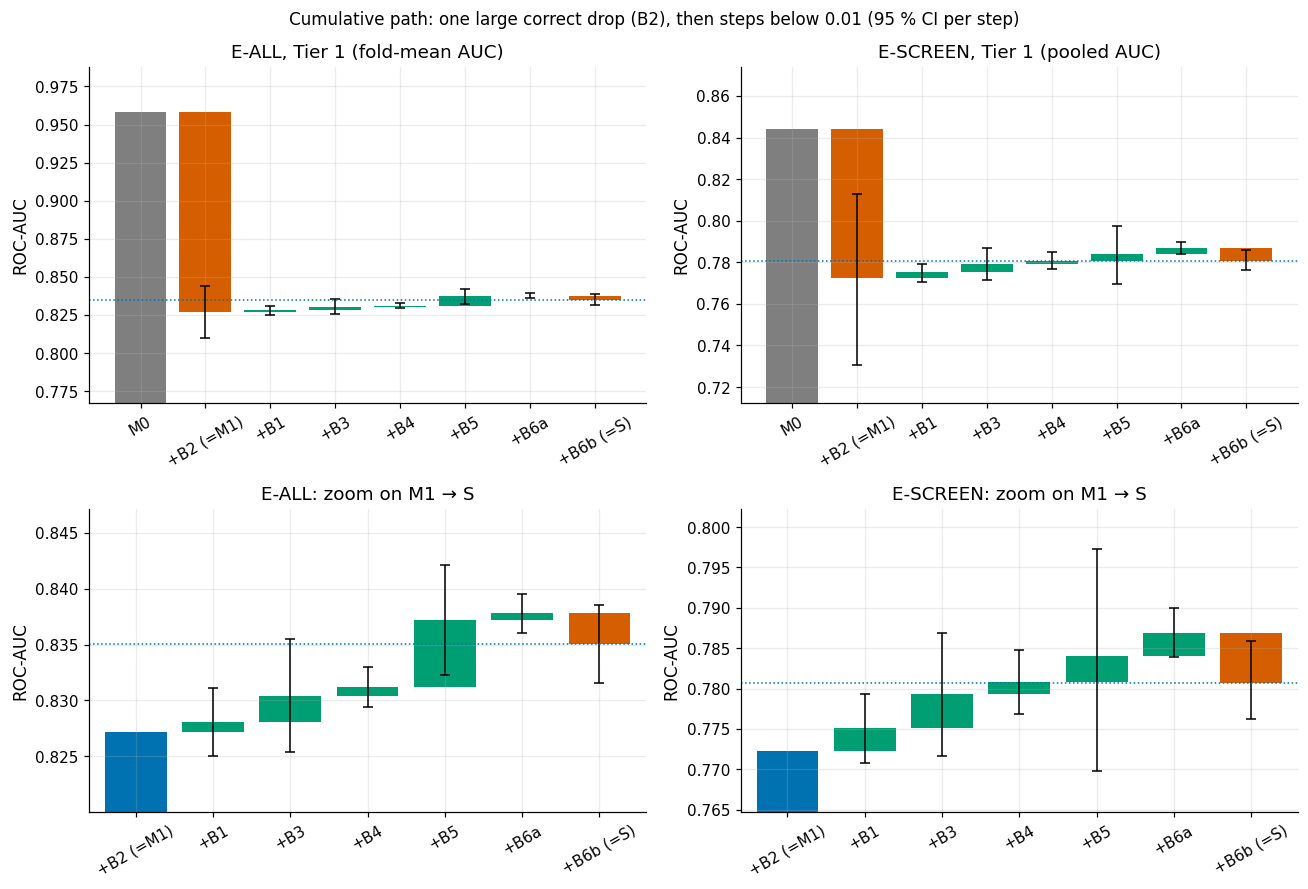

In [165]:
# Cumulative path M0 -> S (§7.7): paired AUC difference between consecutive arms in the pre-specified block
# order.
# Writes cumulative_path.csv and the waterfall figure; increments are descriptive because they depend on the
# order.
cum_rows = []
# P.CUMULATIVE lists the arms in the pre-specified order.
path = list(P.CUMULATIVE)
for t in (1, 2):
    for pop in ("E-ALL", "E-SCREEN"):
        for prev, cur in zip(path[:-1], path[1:]):
            r = cmp_(cur, prev, t, "roc_auc", pop, label="cumulative")
            r["step"] = f"{prev} -> {cur}"
            cum_rows.append(r)
cum = pd.DataFrame(cum_rows)
cum.to_csv(OUT / "cumulative_path.csv", index=False)
show(cum[cum["tier"] == 1][["pop", "step", "est", "lo", "hi", "interval", "mdd"]], 4)

# Waterfall: top row full scale, bottom row zoomed on the steps after the leak gate.
fig, axes = plt.subplots(2, 2, figsize=(12, 8.2), gridspec_kw={"height_ratios": [1, 0.9]})
labels_ = ["M0", "+B2 (=M1)", "+B1", "+B3", "+B4", "+B5", "+B6a", "+B6b (=S)"]
sub = arm_metrics[(arm_metrics["tier"] == 1) & (arm_metrics["model"] == "lr")].set_index("arm")
# Start level: E-ALL uses the fold-mean AUC, E-SCREEN the pooled AUC (same estimand as the step differences).
for col, (pop, lev_col) in enumerate((("E-ALL", "eall_auc_foldmean"), ("E-SCREEN", "escr_auc"))):
    c = cum[(cum["tier"] == 1) & (cum["pop"] == pop)].reset_index(drop=True)
    levels = [sub.loc[path[0], lev_col]]
    for _, r in c.iterrows():
        levels.append(levels[-1] + r["est"])     # E-ALL: fold-mean steps; E-SCREEN: pooled steps
    for row, start in ((0, 0), (1, 1)):          # row 1 = zoom on M1 -> S
        ax = axes[row, col]
        ax.bar(start, levels[start], color=C.OKABE_ITO["grey"] if start == 0 else C.OKABE_ITO["blue"])
        for i in range(start, len(c)):
            r, d = c.loc[i], c.loc[i, "est"]
            ax.bar(i + 1, d, bottom=levels[i], color=C.OKABE_ITO["vermillion"] if d < 0 else C.OKABE_ITO["green"])
            ax.errorbar(i + 1, levels[i] + d, yerr=[[max(d - r["lo"], 0)], [max(r["hi"] - d, 0)]], color="k", capsize=3, lw=1)
        ax.axhline(levels[-1], color=C.OKABE_ITO["blue"], ls=":", lw=1)
        ax.set_xticks(range(start, len(labels_)), labels_[start:], rotation=30)
        # Vertical range of the zoom panel: bar tops and CI ends of all steps shown.
        span = [levels[k] + dlt for k in range(start, len(c)) for dlt in (0, c.loc[k, "lo"], c.loc[k, "hi"])]
        if row == 0:
            ax.set_ylim(min(levels) - 0.06, max(levels) + 0.03)
            ax.set_title(f"{pop}, Tier 1 ({'fold-mean' if pop == 'E-ALL' else 'pooled'} AUC)")
        else:
            ax.set_ylim(min(span) - 0.005, max(span) + 0.005)
            ax.set_xlim(start - 0.6, len(labels_) - 0.4)
            ax.set_title(f"{pop}: zoom on M1 → S")
        ax.set_ylabel("ROC-AUC")
fig.suptitle("Cumulative path: one large correct drop (B2), then steps below 0.01 (95 % CI per step)", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S7_waterfall", caption="Waterfall of the ROC-AUC along the cumulative path M0 -> +B2 -> +B1 -> +B3 -> +B4 -> +B5 -> +B6a -> +B6b (= S), "
              "Tier 1. E-ALL: fold-mean AUC and fold-mean paired differences with the conservative 95 % CI (wider of corrected t and "
              "bootstrap); E-SCREEN: pooled-OOF AUC and bootstrap CI. Bottom row: zoom on the steps after the leak gate. "
              "Red = decrease, green = increase; dotted line = S.")
plt.show()

**So what.** After the leak gate every block moves E-ALL AUC by less than the 0.01 SESOI, each step about the size of
its own MDD. The systematic pipeline does not "buy" discrimination; its value lies in fidelity, stability and
calibration, which is what the block hypotheses predicted and what §7.8–§7.11 test.

## 7.8 Leave-one-block-out
**Why.** The contribution of a block given every other step is S − (S without the block). These are the primary
block comparisons of the locked hypotheses, evaluated on both populations and both tiers, plus the extra arms
S-linear (splines only), S+WHtR (P14) and T1-minus-care.

pop,block,est,lo,hi,interval,mdd
E-ALL,B1,0.0019,-0.0011,0.0049,corrected_t,0.0042
E-ALL,B2,-0.1217,-0.1381,-0.1053,corrected_t,0.0232
E-ALL,B3,0.0019,-0.0018,0.0055,corrected_t,0.0051
E-ALL,B4,0.0002,-0.0019,0.0024,corrected_t,0.0030
E-ALL,B5,0.0065,0.0024,0.0107,bootstrap,0.0063
E-ALL,B6a,0.0006,-0.0017,0.0028,corrected_t,0.0032
E-ALL,B6b,-0.0027,-0.0062,0.0008,corrected_t,0.0050
E-ALL,splines,0.0038,0.0005,0.0074,bootstrap,0.0050
E-ALL,P14 WHtR,-0.0009,-0.0028,0.0009,corrected_t,0.0026
E-ALL,care items,0.0159,0.0094,0.0220,bootstrap,0.0095


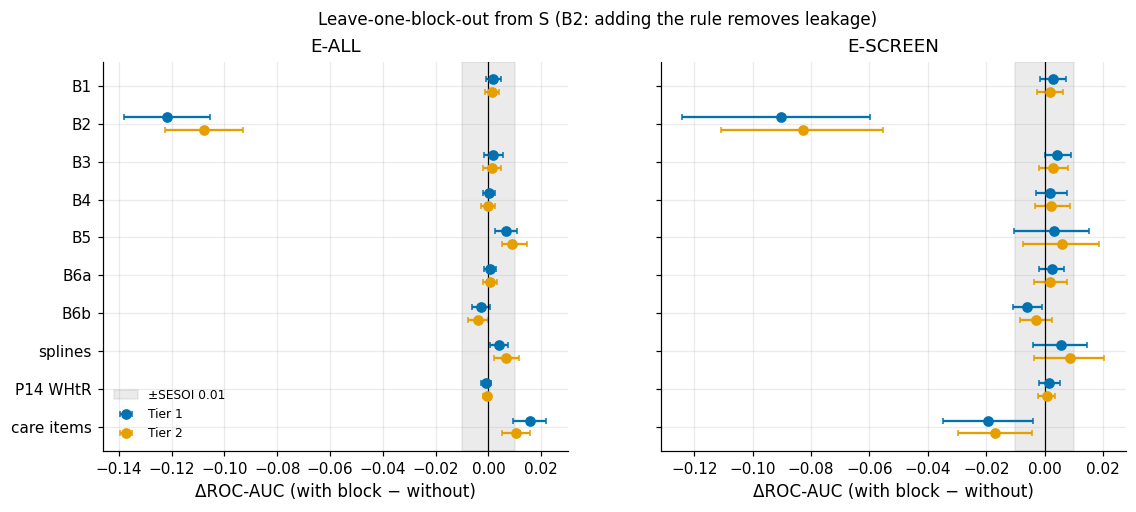

In [166]:
# Leave-one-block-out (§7.8): AUC, PR-AUC and Brier of S minus S without each block, per population and tier.
# Writes lobo.csv and the forest figure; the primary rows feed the verdicts in §7.12.
# Pairs are (with block, without block), so every difference reads 'with minus without'.
lobo_pairs = [("S", f"S-{b}", b) for b in P.BLOCKS] + [("S", "S-linear", "splines"), ("S+WHtR", "S", "P14 WHtR"),
                                                       ("S", "T1-minus-care", "care items")]
lobo_rows = []
for t in (1, 2):
    for pop in ("E-ALL", "E-SCREEN"):
        for a, b, lab in lobo_pairs:
            for metric in ("roc_auc", "pr_auc", "brier"):
                r = cmp_(a, b, t, metric, pop, label=f"LOBO {lab}")
                r["block"] = lab
                lobo_rows.append(r)
lobo = pd.DataFrame(lobo_rows)
lobo.to_csv(OUT / "lobo.csv", index=False)
# Tier-1 AUC rows for the printed table; the CSV holds every metric.
v_ = lobo[(lobo["tier"] == 1) & (lobo["metric"] == "roc_auc")]
show(v_[["pop", "block", "est", "lo", "hi", "interval", "mdd"]], 4)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
order = [lab for _, _, lab in lobo_pairs]
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    for t, off, col in ((1, -0.17, C.OKABE_ITO["blue"]), (2, 0.17, C.OKABE_ITO["orange"])):
        s = lobo[(lobo["tier"] == t) & (lobo["metric"] == "roc_auc") & (lobo["pop"] == pop)].set_index("block").loc[order]
        ax.errorbar(s["est"], np.arange(len(order)) + off, xerr=[s["est"] - s["lo"], s["hi"] - s["est"]], fmt="o",
                    color=col, capsize=2, label=f"Tier {t}")
    # Grey band = smallest effect size of interest (SESOI) for AUC; effects inside it are practically zero.
    ax.axvspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=C.OKABE_ITO["grey"], alpha=0.15, label="±SESOI 0.01")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(range(len(order)), order)
    ax.set_xlabel("ΔROC-AUC (with block − without)")
    ax.set_title(pop)
axes[0].invert_yaxis()
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Leave-one-block-out from S (B2: adding the rule removes leakage)", fontsize=11)
plots.savefig(fig, "S7_lobo", caption="Leave-one-block-out ΔROC-AUC = AUC(arm with the block) − AUC(arm without it) with conservative 95 % CIs, Tier 1 (blue) and "
              "Tier 2 (orange), E-ALL and E-SCREEN; grey band = ±SESOI 0.01. Every row is 'with − without': B2 is negative because adding the "
              "rule removes leakage; 'care items' = S − T1-minus-care (S keeps BPQ020/BPQ080); 'P14 WHtR' = S+WHtR − S.")
plt.show()

**So what.** Apart from B2 (negative because adding the rule removes leakage), block effects on discrimination are
small; their intervals decide between "equivalent" (inside the grey band) and "inconclusive" (crossing it). The
striking line is **care items** ("told high blood pressure / high cholesterol"): keeping them helps on E-ALL but
*hurts* on E-SCREEN. They help to recognise people the health system already knows, which is not the screening task.

## 7.9 E-ALL vs E-SCREEN
**Why.** 84 % of the `L_comb` positives already know their diagnosis, so an AUC on E-ALL largely measures how well a
model recognises *known* patients, who carry traces of care. The screening question is E-SCREEN. The gap between the
two is the pre-registered H2c(i).

S (Tier 1): AUC E-ALL 0.836 - E-SCREEN 0.781 = +0.055 [+0.028, +0.086] (bootstrap, MDD 0.040)
same 3,807 negatives in both populations; positives: E-ALL 777 (all L_comb), E-SCREEN 127 (undiagnosed only)
gap lower bound 0.028 vs pre-registered magnitude 0.03


arm,eall,eall_lo,eall_hi,escr,escr_lo,escr_hi,gap
M0,0.961,0.952,0.968,0.844,0.809,0.879,0.117
M1,0.828,0.814,0.841,0.772,0.739,0.804,0.056
S,0.836,0.822,0.848,0.781,0.746,0.812,0.055
S-linear,0.832,0.818,0.845,0.775,0.741,0.807,0.057
T1-minus-care,0.820,0.808,0.835,0.800,0.766,0.831,0.020
S+WHtR,0.835,0.821,0.847,0.782,0.749,0.814,0.053
S (T2),0.850,0.836,0.863,0.790,0.756,0.821,0.060
BL-ADAlite-LR,0.768,0.750,0.786,0.708,0.666,0.750,0.060
BL-ADAlite,0.761,0.745,0.778,0.726,0.687,0.769,0.035


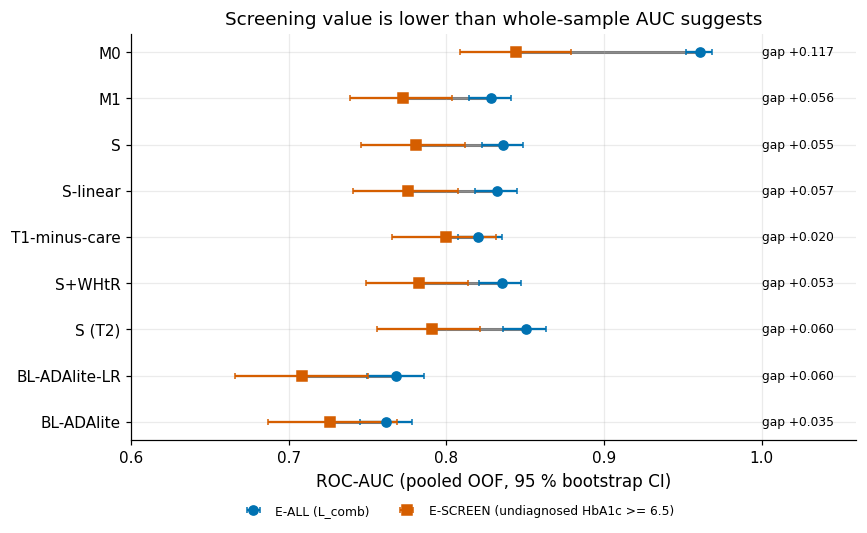

In [167]:
# E-ALL vs E-SCREEN gap (§7.9): bootstrap of AUC(E-ALL) - AUC(E-SCREEN) for S, and a gap table for the main
# arms.
# Asserts that both populations share the same negatives; writes eall_vs_escreen.csv and a dumbbell figure.
rng = np.random.default_rng(ek.derive_seed(C.SEED_MASTER, "S7", "H2c-i"))
# Resampling units: rows within each label stratum, so each bootstrap sample keeps the stratum mix.
groups = [np.flatnonzero(strat == s) for s in np.unique(strat)]
pS = PM[("S", 1, "lr")]
gaps = []
# Both AUCs are computed on the same resampled rows, so the gap is a paired quantity.
for _ in range(C.N_BOOT):
    idx = np.concatenate([rng.choice(g, len(g)) for g in groups])
    # E-SCREEN members among the resampled indices.
    e = idx[esc[idx]]
    gaps.append(roc_auc_score(y[idx], pS[idx]) - roc_auc_score(y_esc[e], pS[e]))
gaps = np.array(gaps)
gap_obs = roc_auc_score(y, pS) - roc_auc_score(y_esc[esc], pS[esc])
gap_lo, gap_hi = np.percentile(gaps, [2.5, 97.5])
# SE = bootstrap SD; MDD from normal quantiles (80 % power, two-sided 5 %).
h2c1 = dict(a="S", b="S", tier=1, metric="roc_auc", pop="E-ALL minus E-SCREEN", est=gap_obs, lo=gap_lo, hi=gap_hi,
            se=gaps.std(ddof=1), interval="bootstrap", mdd=(stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) * gaps.std(ddof=1),
            label="H2c(i)")
COMP.append(h2c1)
print(f"S (Tier 1): AUC E-ALL {roc_auc_score(y, pS):.3f} - E-SCREEN {roc_auc_score(y_esc[esc], pS[esc]):.3f} = {fmt(h2c1)}")
# Spectrum-bias design: the populations differ only in their positives (known diabetics vs undiagnosed).
neg_eall, neg_escr = set(np.flatnonzero(y == 0)), set(np.flatnonzero(esc & (y_esc == 0)))
assert neg_eall == neg_escr, "E-ALL and E-SCREEN must share the same negatives"
print(f"same {len(neg_eall):,} negatives in both populations; positives: E-ALL {int(y.sum())} (all L_comb), "
      f"E-SCREEN {int(y_esc[esc].sum())} (undiagnosed only)")
# H2c(i) was pre-registered with magnitude 0.03; the lower CI bound is compared with it.
print(f"gap lower bound {h2c1['lo']:.3f} vs pre-registered magnitude 0.03")

# Arms for the gap table; the ADA points are used in their raw 'points' form.
pairs = [("M0", 1, "lr"), ("M1", 1, "lr"), ("S", 1, "lr"), ("S-linear", 1, "lr"), ("T1-minus-care", 1, "lr"),
         ("S+WHtR", 1, "lr"), ("S", 2, "lr"), ("BL-ADAlite-LR", 1, "lr"), ("BL-ADAlite", 1, "points")]
dumb = []
for k in pairs:
    a1, l1, h1 = auc_ci(PM[k], "E-ALL", seed_tag=f"d{k}")
    a2, l2, h2 = auc_ci(PM[k], "E-SCREEN", seed_tag=f"d{k}")
    dumb.append(dict(arm=f"{k[0]}" + (" (T2)" if k[1] == 2 else ""), eall=a1, eall_lo=l1, eall_hi=h1, escr=a2, escr_lo=l2, escr_hi=h2))
dumb = pd.DataFrame(dumb)
dumb["gap"] = dumb["eall"] - dumb["escr"]
dumb.to_csv(OUT / "eall_vs_escreen.csv", index=False)
show(dumb, 3)

# Dumbbell plot: each line joins an arm's E-SCREEN (square) and E-ALL (circle) AUC.
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for i, r in dumb.iterrows():
    ax.plot([r["escr"], r["eall"]], [i, i], color=C.OKABE_ITO["grey"], lw=2, zorder=1)
    ax.errorbar(r["eall"], i, xerr=[[r["eall"] - r["eall_lo"]], [r["eall_hi"] - r["eall"]]], fmt="o", color=C.OKABE_ITO["blue"],
                capsize=2, label="E-ALL (L_comb)" if i == 0 else None, zorder=2)
    ax.errorbar(r["escr"], i, xerr=[[r["escr"] - r["escr_lo"]], [r["escr_hi"] - r["escr"]]], fmt="s", color=C.OKABE_ITO["vermillion"],
                capsize=2, label="E-SCREEN (undiagnosed HbA1c >= 6.5)" if i == 0 else None, zorder=2)
    ax.text(1.0, i, f"gap {r['gap']:+.3f}", va="center", fontsize=8)
ax.set_yticks(range(len(dumb)), dumb["arm"])
ax.invert_yaxis()
ax.set_xlim(0.6, 1.06)
ax.set_xlabel("ROC-AUC (pooled OOF, 95 % bootstrap CI)")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.13), ncol=2, fontsize=8, frameon=False)
ax.set_title("Screening value is lower than whole-sample AUC suggests")
plots.savefig(fig, "S7_eall_vs_escreen", caption="ROC-AUC on E-ALL (blue, L_comb, 84 % already diagnosed) and E-SCREEN (red, people not told they have "
              "diabetes, positive = HbA1c >= 6.5 %) for the main arms and baselines, Tier 1 unless marked, with 95 % bootstrap CIs.")
plt.show()

**So what.** The two populations share exactly the same negatives (asserted); only the positives differ, so the gap
is pure **spectrum bias** (Ransohoff & Feinstein 1978): known diabetics, with treatment, care contacts and higher
HbA1c, are easier to rank than the undiagnosed. For S the gap is about 0.055 (H2c-i supported); its lower bound
(about 0.028) sits just below the pre-registered 0.03. The smaller gaps of T1-minus-care and ADA-lite are the mirror
image: the less a model relies on care traces, the less it loses. A whole-sample AUC overstates screening value –
the label composition, not the model, sets the headline number.

## 7.10 Precision–recall and calibration
**Why.** AUC ignores prevalence and calibration. E-SCREEN has a prevalence of about 3 %, so precision binds in
screening, and a model trained on `L_comb` (17 %) is miscalibrated there by design; class weights (B6a) inflate
probabilities further.

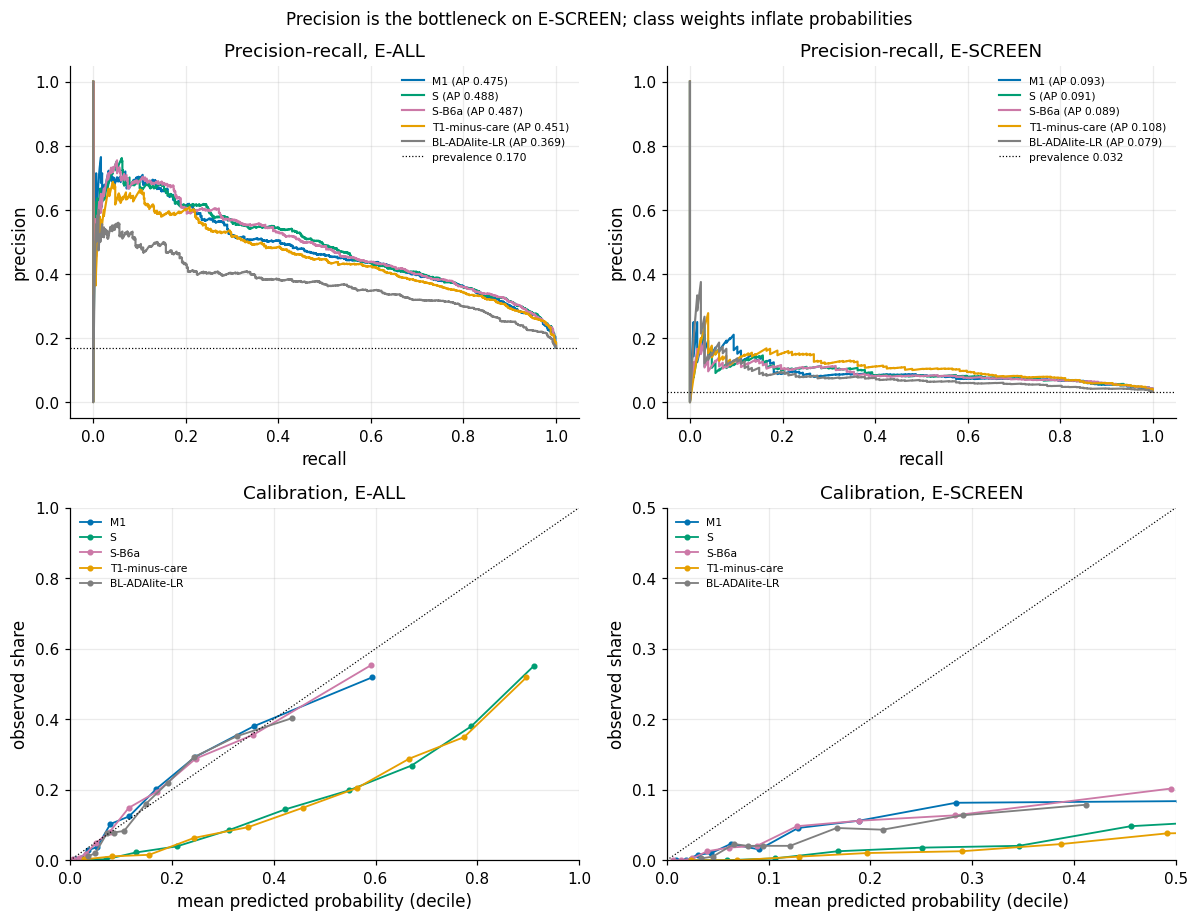

arm,pop,cal_slope,cal_citl,brier,mean_p,prevalence
M1,E-ALL,0.961,0.010,0.112,0.168,0.170
S,E-ALL,0.867,-1.818,0.185,0.409,0.170
S-B6a,E-ALL,0.979,0.027,0.110,0.167,0.170
T1-minus-care,E-ALL,0.873,-1.807,0.195,0.422,0.170
BL-ADAlite-LR,E-ALL,1.124,-0.001,0.123,0.170,0.170
M1,E-SCREEN,0.685,-1.814,0.056,0.136,0.032
S,E-SCREEN,0.613,-3.671,0.196,0.357,0.032
S-B6a,E-SCREEN,0.688,-1.783,0.055,0.133,0.032
T1-minus-care,E-SCREEN,0.723,-3.684,0.205,0.376,0.032
BL-ADAlite-LR,E-SCREEN,0.831,-1.799,0.054,0.152,0.032


In [168]:
# Precision-recall and calibration (§7.10) of selected Tier-1 arms on E-ALL and E-SCREEN.
# Writes calibration.csv and the PR/calibration figure; no assertions.
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve

# Arms shown: M1, S, S without class weights (S-B6a), the no-care variant and the refitted ADA baseline.
curve_keys = [("M1", 1, "lr", C.OKABE_ITO["blue"]), ("S", 1, "lr", C.OKABE_ITO["green"]),
              ("S-B6a", 1, "lr", C.OKABE_ITO["purple"]), ("T1-minus-care", 1, "lr", C.OKABE_ITO["orange"]),
              ("BL-ADAlite-LR", 1, "lr", C.OKABE_ITO["grey"])]
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
cal_rows = []
for col, pop in enumerate(("E-ALL", "E-SCREEN")):
    yy, m = pop_of(pop)
    for a, t, mdl, colr in curve_keys:
        p = PM[(a, t, mdl)][m]
        prec, rec, _ = precision_recall_curve(yy[m], p)
        axes[0, col].plot(rec, prec, color=colr, lw=1.4, label=f"{a} (AP {average_precision_score(yy[m], p):.3f})")
        # Decile calibration: quantile bins hold equally many cases per point.
        fr, mp = calibration_curve(yy[m], p, n_bins=10, strategy="quantile")
        axes[1, col].plot(mp, fr, "o-", color=colr, ms=3, lw=1.2, label=a)
        # metric_suite supplies the calibration slope and calibration-in-the-large (citl) of each arm and
        # population.
        ms_ = ek.metric_suite(yy[m], p)
        cal_rows.append(dict(arm=a, pop=pop, cal_slope=ms_["cal_slope"], cal_citl=ms_["cal_citl"], brier=ms_["brier"],
                             mean_p=float(p.mean()), prevalence=float(yy[m].mean())))
    axes[0, col].axhline(yy[m].mean(), color="k", ls=":", lw=0.8, label=f"prevalence {yy[m].mean():.3f}")
    axes[0, col].set(xlabel="recall", ylabel="precision", title=f"Precision-recall, {pop}")
    axes[0, col].legend(fontsize=7)
    # E-SCREEN probabilities are small, so its calibration axes stop at 0.5.
    lim = 1.0 if pop == "E-ALL" else 0.5
    axes[1, col].plot([0, lim], [0, lim], color="k", lw=0.8, ls=":")
    axes[1, col].set(xlabel="mean predicted probability (decile)", ylabel="observed share", title=f"Calibration, {pop}",
                     xlim=(0, lim), ylim=(0, lim))
    axes[1, col].legend(fontsize=7)
fig.suptitle("Precision is the bottleneck on E-SCREEN; class weights inflate probabilities", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S7_pr_calibration", caption="Top: precision-recall curves (average precision in the legend; dotted line = prevalence). Bottom: "
              "calibration by deciles of the predicted probability. Left E-ALL, right E-SCREEN; Tier 1 pooled OOF predictions. S uses "
              "balanced class weights; S-B6a is S without them.")
plt.show()
cal = pd.DataFrame(cal_rows)
cal.to_csv(OUT / "calibration.csv", index=False)
show(cal, 3)

**So what.** On E-SCREEN average precision is only about 0.1 against a prevalence of about 0.03: a screening tool
built on these items would mostly flag people without diabetes. The calibration panels show the price of class
weights – S predicts far above the observed prevalence, while S−B6a (no class weights) is close to the diagonal on
E-ALL. On E-SCREEN every model over-predicts, having been trained where 17 % are positive.

## 7.11 Coefficient stability
**Why.** Discrimination can hide unstable explanations: collinear anthropometrics share the BMI signal differently in
every resample. A nonparametric bootstrap of the whole pipeline (B = 500 in FINAL, 30 in FAST) measures this. BMI is
compared per SD across the arms in which it enters linearly (S is represented by S-linear, as locked); B3-b compares
S-linear−B3 with S-linear, H2b(c) compares M1 with S-linear. The *ratio* of two bootstrap SDs is reported as a
descriptive number: the interval around it comes from re-drawing the stored bootstrap replicates (Monte Carlo
error), not from re-sampling patients, so it is not a sampling interval and cannot decide a hypothesis.

arm,bmi_coef_per_sd,bmi_sd_per_sd,bmi_q_low,bmi_q_high,bmi_sign_flip,max_flip_anthro,anthro_in_model,n_coef,n_valid,share_flip_gt_10pct
M1,0.585,0.301,-0.164,1.075,0.120,0.822,"BMXBMI,BMXWT,BMXHT,BMXWAIST",46,500,0.391
cum+B1,0.240,0.354,-0.160,1.186,0.124,0.348,"BMXBMI,BMXWT,BMXHT,BMXWAIST",46,500,0.457
cum+B3,0.407,0.124,0.199,0.694,0.000,0.134,"BMXBMI,BMXHT,BMXWAIST",29,500,0.276
S-linear-B3,0.338,0.207,0.041,0.917,0.010,0.092,"BMXBMI,BMXWT,BMXHT,BMXWAIST",50,337,0.500
S-linear,0.699,0.152,0.433,1.035,0.000,0.484,"BMXBMI,BMXHT,BMXWAIST",34,500,0.353


SD ratio BMI S-linear-B3 / S-linear: 1.36, Monte Carlo interval [1.23, 1.50] (B = 500) -> descriptive ratio; verdict withdrawn post-audit (not testable with this design), see §9
SD ratio BMI M1 / S-linear: 1.98, Monte Carlo interval [1.80, 2.17] (B = 500) -> descriptive ratio; verdict withdrawn post-audit (not testable with this design), see §9
SD ratio BMI cum+B1 / cum+B3: 2.87, Monte Carlo interval [2.62, 3.12] (B = 500) -> descriptive only (no verdict)


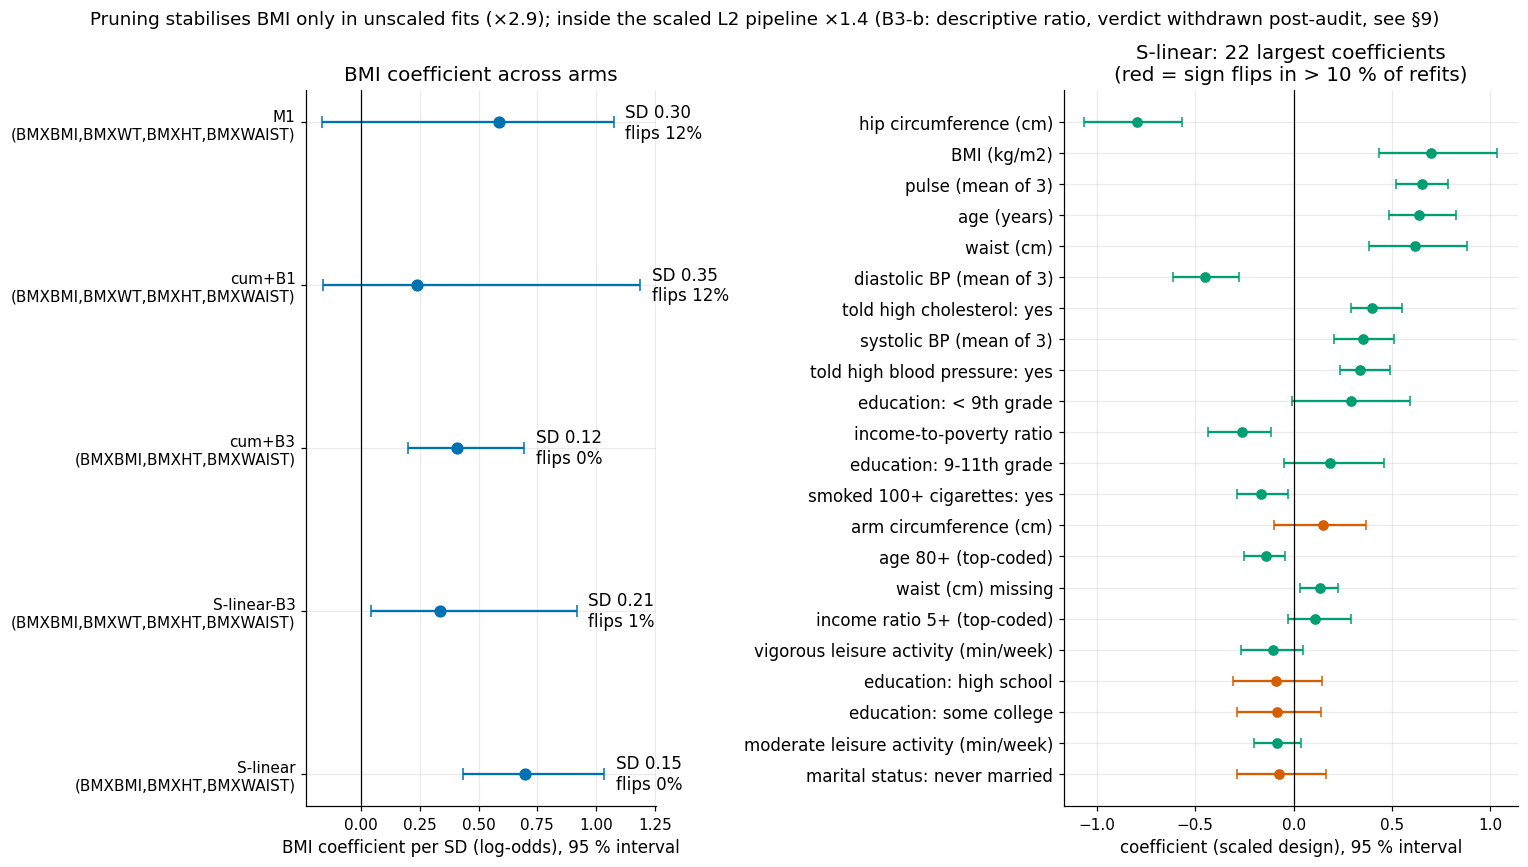

In [169]:
# Coefficient stability (§7.11): bootstrap the whole pipeline for five arms and compare the spread of the BMI
# coefficient.
# Writes coef_stability.csv and the forest figure; B_COEF replicates (fewer in FAST mode).
# Arms in which BMI enters linearly (S is represented by S-linear, as locked).
coef_arms = ["M1", "cum+B1", "cum+B3", "S-linear-B3", "S-linear"]
CB, coef_rows = {}, []
for arm in coef_arms:
    cfg = P.ARMS[arm]
    ylab_ = P.training_label(raw_tr, cfg)
    # Binding cfg=cfg makes the factory build a fresh pipeline of the current arm for each bootstrap
    # replicate.
    mk = (lambda cfg=cfg: P.build_pipeline(cfg, 1, C_=C0))
    # Silence solver warnings inside the replicate fits.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        cb = ek.coef_bootstrap(mk, X[1], ylab_, n_boot=B_COEF, seed=ek.derive_seed(C.SEED_MASTER, "S7", "coef", arm),
                               fit_params=P.fit_params(cfg, raw_tr), n_jobs=N_JOBS)
        # BMI standard deviation in the prepared design: coefficient x SD puts all arms on a per-SD scale.
        dsg = mk()[:-1].fit_transform(X[1])
    sd_bmi = float(dsg["BMXBMI"].std(ddof=0))
    CB[arm] = (cb, sd_bmi)
    s = cb.summary
    # Anthropometric columns present in each arm: weight, height and waist can share BMI's signal.
    anth = [c for c in ("BMXBMI", "BMXWT", "BMXHT", "BMXWAIST") if c in s.index]
    # From the bootstrap summary: coef = full-data fit, sd = spread over replicates, q_low/q_high = percentile
    # interval, sign_flip_rate = share of refits with the opposite sign.
    coef_rows.append(dict(arm=arm, bmi_coef_per_sd=s.loc["BMXBMI", "coef"] * sd_bmi, bmi_sd_per_sd=s.loc["BMXBMI", "sd"] * sd_bmi,
                          bmi_q_low=s.loc["BMXBMI", "q_low"] * sd_bmi, bmi_q_high=s.loc["BMXBMI", "q_high"] * sd_bmi,
                          bmi_sign_flip=s.loc["BMXBMI", "sign_flip_rate"], max_flip_anthro=s.loc[anth, "sign_flip_rate"].max(),
                          anthro_in_model=",".join(anth), n_coef=len(s), n_valid=int(s["n_valid"].min()),
                          share_flip_gt_10pct=float((s["sign_flip_rate"] > 0.10).mean())))
coef_tab = pd.DataFrame(coef_rows)
coef_tab.to_csv(OUT / "coef_stability.csv", index=False)
show(coef_tab, 3)

def sd_ratio(arm_a, arm_b, n_rs=2000):
    """SD(BMI per SD) of arm_a over arm_b with a Monte Carlo interval from resampling the B bootstrap replicates.

    The interval reflects the Monte Carlo error of the two SD estimates for the given number of replicates B (it narrows
    as B grows); it is not a sampling interval of the population ratio.
    """
    (ca, fa), (cb_, fb) = CB[arm_a], CB[arm_b]
    # Bootstrap coefficients of BMI per SD in each arm, failed refits (NaN) dropped.
    xa = ca.coefs["BMXBMI"].dropna().to_numpy() * fa
    xb = cb_.coefs["BMXBMI"].dropna().to_numpy() * fb
    # Monte Carlo interval: resample each arm's replicates and recompute the SD ratio n_rs times.
    r = np.random.default_rng(ek.derive_seed(C.SEED_MASTER, "S7", "ratio", arm_a, arm_b))
    rs = [xa[r.integers(0, len(xa), len(xa))].std(ddof=1) / xb[r.integers(0, len(xb), len(xb))].std(ddof=1) for _ in range(n_rs)]
    lo, hi = np.percentile(rs, [2.5, 97.5])
    return dict(a=arm_a, b=arm_b, ratio=xa.std(ddof=1) / xb.std(ddof=1), lo=lo, hi=hi)

# Ratio verdict: supported if the ratio reaches the locked factor and its lower bound exceeds 1; refuted if
# the upper bound is below the factor.
def v_ratio(d, thr=C.SESOI["coef_sd_ratio"]):
    return "supported" if (d["ratio"] >= thr and d["lo"] > 1) else ("refuted" if d["hi"] < thr else "inconclusive")

# Post-audit label for the two ratio sub-verdicts: the interval is Monte Carlo error, so the ratio is descriptive.
# The locked-rule label from v_ratio stays in the stored scoreboard files for traceability only.
WITHDRAWN = "descriptive ratio; verdict withdrawn post-audit (not testable with this design), see §9"

# B3-b (pruning inside the scaled pipeline), H2b-c (minimal vs systematic) and the unscaled cumulative pair.
ratio_b3 = sd_ratio("S-linear-B3", "S-linear")
ratio_h2b = sd_ratio("M1", "S-linear")
ratio_cum = sd_ratio("cum+B1", "cum+B3")
for d in (ratio_b3, ratio_h2b, ratio_cum):
    print(f"SD ratio BMI {d['a']} / {d['b']}: {d['ratio']:.2f}, Monte Carlo interval [{d['lo']:.2f}, {d['hi']:.2f}] "
          f"(B = {B_COEF}) -> {WITHDRAWN if d is not ratio_cum else 'descriptive only (no verdict)'}")

# Figure: BMI coefficient per SD with bootstrap interval per arm (left); 22 largest S-linear coefficients
# (right).
fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
for i, r in coef_tab.iterrows():
    ax.errorbar(r["bmi_coef_per_sd"], i, xerr=[[r["bmi_coef_per_sd"] - r["bmi_q_low"]], [r["bmi_q_high"] - r["bmi_coef_per_sd"]]],
                fmt="o", color=C.OKABE_ITO["blue"], capsize=4, ms=7)
    ax.text(r["bmi_q_high"] + 0.05, i, f"SD {r['bmi_sd_per_sd']:.2f}\nflips {r['bmi_sign_flip']:.0%}", va="center", fontsize=11)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(coef_tab)), [f"{a}\n({x})" for a, x in zip(coef_tab["arm"], coef_tab["anthro_in_model"])], fontsize=10)
ax.invert_yaxis()
ax.set_xlabel("BMI coefficient per SD (log-odds), 95 % interval", fontsize=11)
ax.set_title("BMI coefficient across arms", fontsize=13)
cbS, _ = CB["S-linear"]
# The most frequent level of each categorical variable is the reference level and is dropped from the display.
ref_levels = {f"{v}_{float(cl[v].mode().iloc[0]) if pd.api.types.is_numeric_dtype(cl[v]) else cl[v].mode().iloc[0]}"
              for v in P.categorical_columns() if v in cl.columns and cl[v].notna().any()}
disp = cbS.summary.drop(index=[c for c in cbS.summary.index if c in ref_levels])   # reference level of each category dropped
# Keep the 22 coefficients with the largest absolute value.
s = disp.reindex(disp["coef"].abs().sort_values(ascending=False).index)[:22]
ax = axes[1]
for i, (nm, r) in enumerate(s.iterrows()):
    # Red = coefficient changes sign in more than 10 % of the refits.
    colr = C.OKABE_ITO["vermillion"] if r["sign_flip_rate"] > 0.10 else C.OKABE_ITO["green"]
    ax.errorbar(r["coef"], i, xerr=[[r["coef"] - r["q_low"]], [r["q_high"] - r["coef"]]], fmt="o", color=colr, capsize=3, ms=6)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(s)), [P.plain_label(c)[:38] for c in s.index], fontsize=11)
ax.invert_yaxis()
ax.tick_params(axis="x", labelsize=10)
ax.set_xlabel("coefficient (scaled design), 95 % interval", fontsize=11)
ax.set_title("S-linear: 22 largest coefficients\n(red = sign flips in > 10 % of refits)", fontsize=13)
fig.suptitle(f"Pruning stabilises BMI only in unscaled fits (×{ratio_cum['ratio']:.1f}); inside the scaled L2 pipeline "
             f"×{ratio_b3['ratio']:.1f} (B3-b: descriptive ratio, verdict withdrawn post-audit, see §9)", fontsize=12)
fig.tight_layout()
plots.savefig(fig, "S7_coef_forest", caption="Left: bootstrap distribution (point = full-data fit, bar = 2.5-97.5 percentile) of the BMI coefficient per SD in the arms "
              "where BMI enters linearly, with the anthropometric columns present in each arm. Right: the 22 largest coefficients of S-linear "
              "(most frequent level of each category omitted for display); "
              f"red = sign flips in more than 10 % of the {B_COEF} bootstrap refits. Tier 1, training part.")
plt.show()
S7["coef_stability"] = dict(table=coef_tab.set_index("arm").to_dict("index"), ratio_B3=ratio_b3, ratio_H2b=ratio_h2b, ratio_cumulative=ratio_cum)

**So what.** Where weight, height and BMI enter together, BMI shares its signal with its formula partners: in the
unscaled arms (M1, cum+B1) its intervals cross zero and it flips sign in about one resample in eight (these two
figures come from fits that stop at the iteration limit, which shrinks the coefficients towards zero, so the crossings
are partly a solver artefact; see §9). M1 has a BMI SD about 2.0 times that of S-linear (descriptive ratio 1.98).
Inside the scaled L2 pipeline pruning adds little: the B3 ratio is about 1.4 (descriptive ratio). **Both ratio
intervals are Monte Carlo intervals** (re-draws of the stored bootstrap replicates: simulation error, not sampling
uncertainty), so the locked rule's verdicts for B3-b and H2b-c are *withdrawn post-audit (not testable with this
design)*; the numbers stay as descriptive ratios, and §9 gives the audit's view. B3-c fails for a mechanical reason –
after pruning the near-zero *height* coefficient flips in about half of the resamples by construction.
Discrimination is the same in all these arms (§7.8); only the stability of the explanation differs.

### 7.11.1 Post-hoc: penalty and stability
**Why.** *Not pre-registered; added after an independent audit; no verdict changes.* The B3 ratio is computed under the
frozen C0, and the unscaled ratios come from fits that stop at the iteration limit. Re-running the B3 contrast at
weaker penalties shows how much stabilisation the L2 penalty already provides.

In [170]:
# Post-hoc follow-up to §7.11: repeat the B3 contrast at weaker penalties to see how much stabilisation L2
# already gives.
# Writes posthoc_c_sensitivity.csv; exploratory, no verdict depends on it.
# C grid: the frozen C0, then weaker penalties up to a nearly unpenalised fit.
C_grid = [C0, 1.0, 100.0, 1e4]
B_s = 200 if C.IS_FINAL else 20   # replicates per arm and C (exploratory; FAST re-run mode uses fewer)
cs_rows = []
for c_ in C_grid:
    sd_ = {}
    for arm in ("S-linear-B3", "S-linear"):
        cfg = P.ARMS[arm]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            # Same bootstrap as in §7.11 with C varied; the seed includes C, so each setting is an independent
            # run.
            cb_ = ek.coef_bootstrap(lambda cfg=cfg, c_=c_: P.build_pipeline(cfg, 1, C_=c_), X[1], P.training_label(raw_tr, cfg),
                                    n_boot=B_s, seed=ek.derive_seed(C.SEED_MASTER, "S7", "Csens", arm, str(c_)),
                                    fit_params=P.fit_params(cfg, raw_tr), n_jobs=N_JOBS)
        # SD of the BMI coefficient across replicates; ratio = without pruning / with pruning.
        sd_[arm] = float(cb_.coefs["BMXBMI"].std(ddof=1))
    cs_rows.append(dict(C=c_, sd_bmi_without_B3=sd_["S-linear-B3"], sd_bmi_with_B3=sd_["S-linear"],
                        ratio=sd_["S-linear-B3"] / sd_["S-linear"]))
c_sens = pd.DataFrame(cs_rows)
c_sens.to_csv(OUT / "posthoc_c_sensitivity.csv", index=False)
# Unscaled arms behind the larger ratios, with the number of CV folds that ended at the iteration limit.
conv = diag[(diag["tier"] == 1) & (diag["model"] == "lr") & diag["arm"].isin(["M1", "cum+B1", "cum+B3"])]
print(f"post-hoc, scaled arms, B = {B_s} per C (per-SD BMI coefficient):")
show(c_sens, 3)
print("unscaled arms behind the larger ratios - CV folds ending at the iteration limit: "
      + ", ".join(f"{a} {k}/{len(folds)}" for a, k in zip(conv["arm"], conv["n_convergence_warnings"])))
S7["posthoc_c_sensitivity"] = dict(table=c_sens.to_dict("records"), unscaled_nonconvergence=dict(zip(conv["arm"], conv["n_convergence_warnings"].astype(int))),
                                   n_folds=len(folds), note="post hoc, exploratory, no verdict change")

post-hoc, scaled arms, B = 200 per C (per-SD BMI coefficient):


C,sd_bmi_without_B3,sd_bmi_with_B3,ratio
0.100,0.208,0.164,1.268
1.000,0.576,0.210,2.741
100.000,0.764,0.228,3.350
10000.000,0.834,0.213,3.916


unscaled arms behind the larger ratios - CV folds ending at the iteration limit: M1 25/25, cum+B1 25/25, cum+B3 25/25


**So what (exploratory).** As the penalty is relaxed towards an unpenalised fit the B3 ratio grows several-fold, so
the L2 penalty and pruning are partly *substitutes*. The large unscaled ratios (cum+B1/cum+B3; M1/S-linear behind
H2b-c) come from fits that hit the iteration limit in every fold, so they are not used to argue for B3. The post-audit
check in §9.12 shows that stopping early shrinks the coefficients and the M1 BMI SD (a converged M1 has a larger
BMI SD) and adds sign flips; it also shows that scaling alone explains the stability edge of S-linear.
The stored SD ratio is therefore not an optimiser-noise inflation.

## 7.12 Verdicts
**Why.** Each locked hypothesis gets exactly one verdict from its locked rule: the primary evaluation is E-ALL, Tier 1;
E-SCREEN and Tier 2 can only turn a decisive verdict into "mixed" by contradicting it. Verdict lines are generated
from the results. A FAST re-run (5 × 2, B = 100) reproduces every leakage, equivalence and class-weight verdict;
borderline ones (B3-b, B5-a, H2b) can move between "inconclusive" and a decisive verdict.

In [171]:
# Verdicts (§7.12): build the scoreboard from the locked hypotheses' rules, combine sub-verdicts, save the
# CSVs.
# Every verdict is computed from the comparison rows above; also writes the scoreboard tables.
def lrtest_splines(tier=1):
    """Likelihood-ratio test spline bases vs linear terms (unpenalised logit, S design, training part)."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import log_loss
    cfg = P.ARMS["S"]
    yl = P.training_label(raw_tr, cfg)
    dS = P.build_pipeline(cfg, tier)[:-1].fit_transform(X[tier])
    # Linear counterpart: same design with the spline basis switched off, keeping the base columns and linear
    # terms.
    dL = P.build_pipeline({**cfg, "P08": False}, tier)[:-1].set_params(p13__enabled=False).fit_transform(X[tier])
    spl_cols = [c for c in dS.columns if "_sp" in c]
    lin = [c.split("_sp")[0] for c in spl_cols]
    base = [c for c in dS.columns if c not in spl_cols]
    dL = pd.concat([dS[base], dL[sorted(set(lin))]], axis=1)
    ll = {}
    for nm, d in (("spline", dS), ("linear", dL)):
        # C = 1e8 is practically unpenalised, so this is a plain likelihood-ratio test; log-likelihood =
        # -log_loss (not normalised).
        m = LogisticRegression(C=1e8, max_iter=20000).fit(d, yl)
        ll[nm] = -log_loss(yl, m.predict_proba(d)[:, 1], normalize=False)
    # Degrees of freedom = spline columns minus the linear terms they replace.
    df_ = len(spl_cols) - len(set(lin))
    chi2 = 2 * (ll["spline"] - ll["linear"])
    return dict(chi2=chi2, df=df_, p=float(stats.chi2.sf(chi2, df_)))

lrt = {t: lrtest_splines(t) for t in (1, 2)}
for t_, r_ in lrt.items():
    print(f"B5(d) LR test splines vs linear, Tier {t_}: chi2 {r_['chi2']:.1f}, df {r_['df']}, p {r_['p']:.2g}")

# Shortcut: run a labelled comparison for the verdict scoreboard.
def get(a, b, metric="roc_auc", pop="E-ALL", tier=1, **kw):
    return cmp_(a, b, tier, metric, pop, label="verdict", **kw)

SB = []   # scoreboard rows
# Append one scoreboard row from a comparison result; sesoi is the smallest effect size of interest.
def add(hyp, sub, r, verdict, sesoi, role="primary"):
    SB.append(dict(hyp_id=hyp, sub=sub, role=role, comparison=f"{r.get('a')} - {r.get('b')}", metric=r.get("metric"),
                   pop=r.get("pop"), tier=r.get("tier"), est=r.get("est"), lo=r.get("lo"), hi=r.get("hi"),
                   interval=r.get("interval"), mdd=r.get("mdd"), sesoi=sesoi, verdict=verdict))

# Equivalence claim ±s: primary on E-ALL Tier 1, secondary checks on E-SCREEN and Tier 2.
def equiv_claim(hyp, sub, a, b, s=0.01, metric="roc_auc"):
    for pop, tier, role in (("E-ALL", 1, "primary"), ("E-SCREEN", 1, "secondary"), ("E-ALL", 2, "secondary")):
        r = get(a, b, metric, pop, tier)
        add(hyp, sub, r, v_equiv(r["lo"], r["hi"], s), s, role)

# Directional claim: verdict from the engine, overridden to 'refuted' when the pre-stated falsifier fires.
def dir_claim(hyp, sub, a, b, s, direction, metric="roc_auc", falsifier=None, pops=(("E-ALL", 1, "primary"), ("E-SCREEN", 1, "secondary"), ("E-ALL", 2, "secondary")), **kw):
    for pop, tier, role in pops:
        r = get(a, b, metric, pop, tier, **kw)
        v = v_dir(r["lo"], r["hi"], r["est"], s, direction)
        if falsifier is not None and falsifier(r):
            v = "refuted"
        add(hyp, sub, r, v, s, role)

# B1
equiv_claim("B1", "(a) AUC", "S", "S-B1")
# B2 (leak gate, falsifier: CI lower bound above -0.05)
dir_claim("B2", "(a) AUC M1-M0", "M1", "M0", 0.05, "-", falsifier=lambda r: r["lo"] > -0.05)
SB.append(dict(hyp_id="B2t", sub="root split", role="primary", comparison=f"M0 root {roots['M0']['root_feature']} ({roots['M0']['role']}); "
               f"M1 root {roots['M1']['root_feature']}", metric="tree", pop="training part", tier=1, verdict=b2t))
# B3
equiv_claim("B3", "(a) AUC", "S", "S-B3")
SB.append(dict(hyp_id="B3", sub="(b) BMI SD ratio", role="primary", comparison="S-linear-B3 / S-linear", metric="sd_ratio",
               pop="training part", tier=1, est=ratio_b3["ratio"], lo=ratio_b3["lo"], hi=ratio_b3["hi"], sesoi=2.0, verdict=v_ratio(ratio_b3)))
fa = coef_tab.set_index("arm")
# B3-c: the worst anthropometric sign-flip rate must be lower with pruning than without.
flip_v = "supported" if fa.loc["S-linear", "max_flip_anthro"] < fa.loc["S-linear-B3", "max_flip_anthro"] else (
    "inconclusive" if fa.loc["S-linear", "max_flip_anthro"] == fa.loc["S-linear-B3", "max_flip_anthro"] else "refuted")
SB.append(dict(hyp_id="B3", sub="(c) max sign-flip rate", role="primary", comparison="S-linear vs S-linear-B3", metric="sign_flip",
               pop="training part", tier=1, est=fa.loc["S-linear", "max_flip_anthro"], lo=fa.loc["S-linear-B3", "max_flip_anthro"],
               verdict=flip_v))
# B4
equiv_claim("B4", "(a) AUC", "S", "S-B4")
dir_claim("B4", "(b) Brier, PIR missing", "S", "S-B4", 0.005, "-", metric="brier", falsifier=lambda r: r["lo"] > -0.005,
          pops=(("PIR-missing", 1, "primary"), ("PIR-missing", 2, "secondary")))
# B5
dir_claim("B5", "(a) |cal slope - 1|", "S", "S-B5", 0.0, "-", metric="calslope_dev", falsifier=lambda r: r["lo"] > 0)
equiv_claim("B5", "(b) AUC block", "S", "S-B5")
equiv_claim("B5", "(c) AUC splines", "S", "S-linear")
# B5-d: likelihood-ratio test of the spline basis; supported when p < 0.05.
SB.append(dict(hyp_id="B5", sub="(d) LR test splines", role="primary", comparison="S spline vs linear terms", metric="LR chi2",
               pop="training part", tier=1, est=lrt[1]["chi2"], lo=lrt[1]["p"], verdict="supported" if lrt[1]["p"] < 0.05 else "refuted"))
# B5-e: value read back from the stored §6 results (tree probabilities with and without P08/P09).
SB.append(dict(hyp_id="B5", sub="(e) tree P08/P09", role="primary", comparison="S tree with/without P08,P09", metric="max |dp|",
               pop="training part", tier=1, est=json.loads((C.RESULTS_DIR / "metrics_S6.json").read_text(encoding="utf-8"))["assertions"]["tree_p08_p09_maxabs"],
               verdict="supported"))
# B6a
equiv_claim("B6a", "(a) AUC", "S", "S-B6a")
dir_claim("B6a", "(b) Brier", "S", "S-B6a", 0.005, "+", metric="brier")
dir_claim("B6a", "(c) balanced accuracy at 0.5", "S", "S-B6a", 0.05, "+", metric="bacc05")
# B6b
# B6b: non-inferiority margin 0.01 on unweighted AUC.
for pop, tier, role in (("E-ALL", 1, "primary"), ("E-SCREEN", 1, "secondary"), ("E-ALL", 2, "secondary")):
    r = get("S", "S-B6b", "roc_auc", pop, tier)
    add("B6b", "(a) unweighted AUC", r, v_noninf(r["lo"], r["hi"], 0.01), 0.01, role)
# P14
equiv_claim("P14", "(a) AUC", "S+WHtR", "S")
SB.append(dict(hyp_id="P14", sub="(b) Asian TPR@spec0.80", role="primary", comparison="S+WHtR - S", metric="TPR", pop="Asian",
               verdict="deferred to S8"))
# H2a
dir_claim("H2a", "AUC M0-M1", "M0", "M1", 0.05, "+", falsifier=lambda r: r["hi"] < 0.05)
# H2b
equiv_claim("H2b", "(a) AUC", "S", "M1")
equiv_claim("H2b", "(b) Brier", "S", "M1", s=0.005, metric="brier")
SB.append(dict(hyp_id="H2b", sub="(c) BMI SD ratio", role="primary", comparison="M1 / S-linear", metric="sd_ratio", pop="training part",
               tier=1, est=ratio_h2b["ratio"], lo=ratio_h2b["lo"], hi=ratio_h2b["hi"], sesoi=2.0, verdict=v_ratio(ratio_h2b)))
# H2c
add("H2c", "(i) AUC E-ALL - E-SCREEN (S)", h2c1, v_dir(h2c1["lo"], h2c1["hi"], h2c1["est"], 0.03, "+"), 0.03)
r = get("T1-minus-care", "S", "roc_auc", "E-ALL", 1)
add("H2c", "(ii) minus care, E-ALL", r, v_dir(r["lo"], r["hi"], r["est"], 0.01, "-"), 0.01)
r = get("T1-minus-care", "S", "roc_auc", "E-SCREEN", 1)
add("H2c", "(ii) minus care, E-SCREEN", r, v_equiv(r["lo"], r["hi"], 0.01), 0.01)
add("H2c", "(iii) S - ADA-lite, E-SCREEN", h2c3, v_dir(h2c3["lo"], h2c3["hi"], h2c3["est"], 0.01, "+"), 0.01)
# Hypotheses tested in other sections are listed so that the scoreboard is complete.
for h, st in (("H1a", "S5"), ("H1b", "S4"), ("H3", "S8"), ("H4a", "S5"), ("H4b", "S5/S8")):
    SB.append(dict(hyp_id=h, sub="-", role="primary", verdict=f"tested in {st}"))

# Combine per hypothesis: primary sub-verdicts are combined; a secondary row that contradicts a decisive
# primary verdict downgrades it to 'mixed'.
sb = pd.DataFrame(SB)
final = []
for h, g in sb.groupby("hyp_id", sort=False):
    if g["verdict"].str.startswith(("tested", "deferred")).all():
        final.append(dict(hyp_id=h, verdict=g["verdict"].iloc[0], note=""))
        continue
    # Only rows with a real verdict enter the combination.
    prim = g[(g["role"] == "primary") & g["verdict"].isin(C.VERDICTS)]
    v = ek.combine_verdicts(prim["verdict"].tolist())
    sec = g[(g["role"] == "secondary") & g["verdict"].isin(["supported", "refuted", "equivalent"])]
    contra = []
    for _, s2 in sec.iterrows():
        p_ = prim[prim["sub"] == s2["sub"]]
        # A secondary row contradicts the primary one if the primary is decisive and the verdicts differ.
        if len(p_) and p_["verdict"].iloc[0] in ("supported", "refuted") and s2["verdict"] != p_["verdict"].iloc[0]:
            contra.append(f"{s2['sub']} {s2['pop']} T{s2['tier']}: {s2['verdict']}")
    note = "; ".join(contra)
    # Contradiction turns a decisive verdict into 'mixed'.
    if contra and v in ("supported", "refuted"):
        v = "mixed"
    deferred = g[g["verdict"].str.startswith("deferred")]
    if len(deferred):
        note = (note + "; " if note else "") + "part (b) deferred to S8"
    final.append(dict(hyp_id=h, verdict=v, note=note))
final = pd.DataFrame(final)
sb.to_csv(OUT / "scoreboard_detail.csv", index=False)
final.to_csv(OUT / "scoreboard.csv", index=False)
prim = sb[(sb["role"] == "primary") & ~sb["verdict"].str.startswith("tested")]
print("primary sub-verdicts (E-ALL Tier 1 unless stated; secondary rows in results/S7/scoreboard_detail.csv):")
# Display copy: the two SD-ratio rows are shown as descriptive (post-audit); stored files keep the locked-rule label.
prim_show = prim.copy()
prim_show.loc[prim_show["metric"].eq("sd_ratio"), "verdict"] = "descriptive (verdict withdrawn, see §9)"
show(prim_show[["hyp_id", "sub", "pop", "est", "lo", "hi", "mdd", "sesoi", "verdict"]], 4)
print()
show(final)
print()
# One-line text for a sub-verdict: estimate, optional interval and verdict.
def _fmt_sub(r):
    if pd.isna(r.get("est")):
        return f"{r['sub']}: {r['verdict']}"
    rng_ = "" if pd.isna(r.get("hi")) else f" [{r['lo']:+.3f}, {r['hi']:+.3f}]"
    return f"{r['sub']} {r['est']:+.3f}{rng_} -> {r['verdict']}"
for _, f in final.iterrows():
    subs = prim_show[prim_show["hyp_id"] == f["hyp_id"]]
    if len(subs):
        print(textwrap.fill(f"{f['hyp_id']}: {f['verdict'].upper()} | " + "; ".join(_fmt_sub(r) for _, r in subs.iterrows()),
                            width=140, subsequent_indent="      "))
# Exploratory contrast (not locked): S without class weights vs M1, raw metric values and their paired
# difference.
pure = []
for pop in ("E-ALL", "E-SCREEN"):
    for metric in ("roc_auc", "brier"):
        r = cmp_("S-B6a", "M1", 1, metric, pop, label="exploratory pure preparation")
        pure.append(dict(pop=pop, metric=metric, S_B6a=METRIC_FN[metric](*[v[pop_of(pop)[1]] for v in (pop_of(pop)[0], PM[("S-B6a", 1, "lr")])]),
                         M1=METRIC_FN[metric](*[v[pop_of(pop)[1]] for v in (pop_of(pop)[0], PM[("M1", 1, "lr")])]),
                         diff=r["est"], lo=r["lo"], hi=r["hi"]))
pure = pd.DataFrame(pure)
print("\nexploratory 'pure preparation' contrast S-B6a (S without class weights) vs M1, Tier 1 (not a locked hypothesis):")
show(pure, 4)
S7["pure_preparation_S_B6a_vs_M1"] = pure.to_dict("records")
S7["scoreboard"] = final.set_index("hyp_id").to_dict("index")
S7["scoreboard_detail"] = sb.round(5).to_dict("records")
S7["lr_test_splines"] = lrt

B5(d) LR test splines vs linear, Tier 1: chi2 64.4, df 8, p 6.4e-11
B5(d) LR test splines vs linear, Tier 2: chi2 98.8, df 16, p 5.9e-14


primary sub-verdicts (E-ALL Tier 1 unless stated; secondary rows in results/S7/scoreboard_detail.csv):


hyp_id,sub,pop,est,lo,hi,mdd,sesoi,verdict
B1,(a) AUC,E-ALL,0.0019,-0.0011,0.0049,0.0042,0.0100,supported
B2,(a) AUC M1-M0,E-ALL,-0.1308,-0.1479,-0.1138,0.0241,0.0500,supported
B2t,root split,training part,,,,,,supported
B3,(a) AUC,E-ALL,0.0019,-0.0018,0.0055,0.0051,0.0100,supported
B3,(b) BMI SD ratio,training part,1.3609,1.2309,1.5020,,2.0000,"descriptive (verdict withdrawn, see §9)"
B3,(c) max sign-flip rate,training part,0.4840,0.0920,,,,refuted
B4,(a) AUC,E-ALL,0.0002,-0.0019,0.0024,0.0030,0.0100,supported
B4,"(b) Brier, PIR missing",PIR-missing,0.0033,-0.0098,0.0164,0.0185,0.0050,inconclusive
B5,(a) |cal slope - 1|,E-ALL,-0.0391,-0.0681,-0.0100,0.0411,0.0000,supported
B5,(b) AUC block,E-ALL,0.0065,0.0024,0.0107,0.0063,0.0100,inconclusive


hyp_id,verdict,note
B1,supported,
B2,supported,
B2t,supported,
B3,mixed,
B4,inconclusive,
B5,inconclusive,
B6a,supported,
B6b,supported,
P14,supported,part (b) deferred to S8
H2a,supported,



B1: SUPPORTED | (a) AUC +0.002 [-0.001, +0.005] -> supported
B2: SUPPORTED | (a) AUC M1-M0 -0.131 [-0.148, -0.114] -> supported
B2t: SUPPORTED | root split: supported
B3: MIXED | (a) AUC +0.002 [-0.002, +0.006] -> supported; (b) BMI SD ratio +1.361 [+1.231, +1.502] -> descriptive (verdict withdrawn, see
      §9); (c) max sign-flip rate +0.484 -> refuted
B4: INCONCLUSIVE | (a) AUC +0.000 [-0.002, +0.002] -> supported; (b) Brier, PIR missing +0.003 [-0.010, +0.016] -> inconclusive
B5: INCONCLUSIVE | (a) |cal slope - 1| -0.039 [-0.068, -0.010] -> supported; (b) AUC block +0.007 [+0.002, +0.011] -> inconclusive; (c) AUC
      splines +0.004 [+0.001, +0.007] -> supported; (d) LR test splines +64.394 -> supported; (e) tree P08/P09 +0.000 -> supported
B6a: SUPPORTED | (a) AUC +0.001 [-0.002, +0.003] -> supported; (b) Brier +0.076 [+0.068, +0.084] -> supported; (c) balanced accuracy at 0.5
      +0.145 [+0.123, +0.166] -> supported
B6b: SUPPORTED | (a) unweighted AUC -0.003 [-0.006, +0.001] 


exploratory 'pure preparation' contrast S-B6a (S without class weights) vs M1, Tier 1 (not a locked hypothesis):


pop,metric,S_B6a,M1,diff,lo,hi
E-ALL,roc_auc,0.8353,0.8285,0.0073,0.0001,0.0146
E-ALL,brier,0.1101,0.1119,-0.0018,-0.0036,-0.0000
E-SCREEN,roc_auc,0.7782,0.7723,0.0059,-0.0094,0.0214
E-SCREEN,brier,0.0552,0.0561,-0.0009,-0.0022,0.0005


**So what.** Reading of the verdicts (numbers above; FINAL run):

| Block / hypothesis | Verdict | Reading |
|---|---|---|
| H2a, B2, B2t leakage | supported | the rule costs about 0.13 AUC on E-ALL – a *correct deterioration* |
| B1, B4-a, B6b fidelity, missingness, survey weights | equivalent AUC | repairs change what the data *mean*, not discrimination |
| B3 redundancy | mixed | same AUC; stability gain small inside scaled L2 (B3-c refuted; B3-b is a descriptive ratio 1.36, verdict withdrawn post-audit, see §9) |
| B5 representation | inconclusive | calibration gain mostly solver convergence after scaling; splines kept on the LR test |
| B6a class weights | supported | same AUC, Brier worse by about 0.07: a threshold choice in disguise |
| H2b minimal vs systematic | inconclusive | (a) AUC +0.008 [0.000, 0.016], MDD > SESOI (underpowered); (b) Brier refuted by class weights alone; (c) SD ratio 1.98 is descriptive only, verdict withdrawn post-audit (see §9) |
| H2c recognition vs screening | inconclusive | (i) gap supported; (ii) care items lower E-ALL but *raise* E-SCREEN; (iii) S > ADA-lite |

Without class weights (S−B6a vs M1, exploratory) systematic preparation gains a little AUC and costs no calibration.
Where the MDD exceeds the SESOI, "inconclusive" means underpowered, not "no effect".

### 7.12.1 POST-LOCK sensitivity: M1 convergence and scaling
**Why.** *POST-LOCK – not pre-registered, added after the final audit; no locked verdict is changed.* The minimal arm
of H2b has two weaknesses: M1 stops at the solver's iteration limit in every fold, and without scaling its L2 penalty
acts unevenly on columns in different units. Three variants of M1 are refitted on the same stored folds with the
frozen C0: (i) the same solver with `max_iter` raised from 5,000 to 100,000; (ii) the same penalised likelihood solved
to its exact optimum (Newton–Cholesky solver); (iii) M1 plus scaling only (P09). Each is compared with S and with
S−B6a by the §7.4.1 engine. The results go to `results/S7/postlock_m1_sensitivity.csv`, never into the OOF file.

In [172]:
# POST-LOCK sensitivity: refit three M1 variants (more iterations, exact solver, scaling only) on the stored
# folds.
# Writes postlock_m1_sensitivity.csv; variants are removed from OOF again and asserted absent from it.
from sklearn.exceptions import ConvergenceWarning

# Variant name -> (arm config, estimator parameters); None = reuse the stored M1 run as the reference.
POSTLOCK = {"M1 stored (lbfgs, max_iter 5,000)": None,
            "M1 lbfgs, max_iter 100,000": (P.ARMS["M1"], {"model__max_iter": 100_000}),
            "M1 exact optimum (newton-cholesky)": (P.ARMS["M1"], {"model__solver": "newton-cholesky"}),
            "M1 + scaling only (P09)": ({**P.ARMS["M1"], "P09": True}, {})}


def run_postlock(cfg, params):
    """OOF predictions of an M1 variant on the stored folds; solver warnings counted inside the worker."""
    # record=True collects solver warnings inside the worker, where the parent process cannot see them.
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", ConvergenceWarning)
        oof = ek.cv_predict(lambda: P.build_pipeline(cfg, 1, C_=C0).set_params(**params), X[1],
                            P.training_label(raw_tr, cfg), folds, fit_params=P.fit_params(cfg, raw_tr))
    return oof, sum(issubclass(x.category, ConvergenceWarning) for x in w)


t0 = time.time()
# Only the new variants need fitting; the stored M1 is the reference.
todo = {k: v for k, v in POSTLOCK.items() if v is not None}
# Fit the variants in parallel; results are keyed by variant name.
res_pl = dict(zip(todo, Parallel(n_jobs=min(N_JOBS, len(todo)))(delayed(run_postlock)(*v) for v in todo.values())))
# Convergence count of the stored M1 arm from the main run.
conv_pl = {"M1 stored (lbfgs, max_iter 5,000)": int(diag.query("arm == 'M1' and tier == 1 and model == 'lr'")["n_convergence_warnings"].iloc[0])}
pl_rows = []
for name in POSTLOCK:
    key = ("M1", 1, "lr") if POSTLOCK[name] is None else (name, 1, "lr")
    if POSTLOCK[name] is not None:                  # temporary entry for the comparison engine, removed below
        OOF[key], PM[key] = res_pl[name][0], ek.mean_oof(res_pl[name][0], n)
        conv_pl[name] = int(res_pl[name][1])
    # try/finally guarantees that the temporary OOF entry is removed even if a comparison fails.
    try:
        for a in ("S", "S-B6a"):
            for pop in ("E-ALL", "E-SCREEN"):
                for metric, s_ in (("roc_auc", C.SESOI["roc_auc"]), ("brier", 0.005)):
                    r = compare(a, key[0], 1, metric, pop)
                    yy, m = pop_of(pop)
                    pl_rows.append(dict(variant=name, a=a, pop=pop, metric=metric, folds_not_converged=conv_pl[name],
                                        n_folds=len(folds), value_variant=METRIC_FN[metric](yy[m], PM[key][m]),
                                        value_a=METRIC_FN[metric](yy[m], PM[(a, 1, "lr")][m]), est=r["est"], lo=r["lo"],
                                        hi=r["hi"], interval=r["interval"], mdd=r["mdd"], verdict_equivalence=v_equiv(r["lo"], r["hi"], s_)))
    finally:
        if POSTLOCK[name] is not None:
            del OOF[key], PM[key]
# Guard: post-lock variants must never reach the OOF file that later sections read.
assert all(k[0] not in POSTLOCK for k in OOF), "post-lock variants must not reach the OOF file"
PL = pd.DataFrame(pl_rows)
PL.to_csv(OUT / "postlock_m1_sensitivity.csv", index=False)
# Reference row: H2b(a) with the stored M1; the other variants are compared with its verdict.
h2b_ref = PL.query("variant == 'M1 stored (lbfgs, max_iter 5,000)' and a == 'S' and pop == 'E-ALL' and metric == 'roc_auc'").iloc[0]
pl_eall = PL.query("a == 'S' and pop == 'E-ALL' and metric == 'roc_auc'").set_index("variant")
h2b_same = bool((pl_eall["verdict_equivalence"] == h2b_ref["verdict_equivalence"]).all())
print(f"POST-LOCK (not pre-registered): {len(todo)} M1 variants x {len(folds)} folds, {time.time() - t0:.0f} s")
for k_, v_ in conv_pl.items():
    print(f"   {k_:<38} folds stopped at a solver limit: {v_}/{len(folds)}")
show(PL.query("pop == 'E-ALL'")[["variant", "a", "metric", "folds_not_converged", "value_variant", "value_a", "est", "lo", "hi",
                                  "mdd", "verdict_equivalence"]], 4)
show(PL.query("pop == 'E-SCREEN' and metric == 'roc_auc'")[["variant", "a", "value_variant", "value_a", "est", "lo", "hi",
                                                             "verdict_equivalence"]], 4)
print("H2b(a) (S - M1, E-ALL AUC, equivalence +-0.01) under each M1 variant:")
for k_, r_ in pl_eall.iterrows():
    print(f"   {k_:<38} {r_['est']:+.4f} [{r_['lo']:+.4f}, {r_['hi']:+.4f}] -> {r_['verdict_equivalence']}")
print(f"H2b(a) conclusion unchanged: {h2b_same}")
S7["postlock_m1_sensitivity"] = dict(note="POST-LOCK sensitivity, not pre-registered; no verdict changed",
                                     folds_not_converged=conv_pl, n_folds=len(folds), h2b_a_unchanged=h2b_same,
                                     rows=PL.round(6).to_dict("records"))

POST-LOCK (not pre-registered): 3 M1 variants x 25 folds, 144 s
   M1 stored (lbfgs, max_iter 5,000)      folds stopped at a solver limit: 25/25
   M1 lbfgs, max_iter 100,000             folds stopped at a solver limit: 7/25
   M1 exact optimum (newton-cholesky)     folds stopped at a solver limit: 0/25
   M1 + scaling only (P09)                folds stopped at a solver limit: 0/25


variant,a,metric,folds_not_converged,value_variant,value_a,est,lo,hi,mdd,verdict_equivalence
"M1 stored (lbfgs, max_iter 5,000)",S,roc_auc,25,0.8285,0.8359,0.0079,0.0000,0.0158,0.0112,inconclusive
"M1 stored (lbfgs, max_iter 5,000)",S,brier,25,0.1119,0.1854,0.0739,0.0665,0.0814,0.0106,refuted
"M1 stored (lbfgs, max_iter 5,000)",S-B6a,roc_auc,25,0.8285,0.8353,0.0073,0.0001,0.0146,0.0103,inconclusive
"M1 stored (lbfgs, max_iter 5,000)",S-B6a,brier,25,0.1119,0.1101,-0.0018,-0.0036,-0.0000,0.0025,supported
"M1 lbfgs, max_iter 100,000",S,roc_auc,7,0.8288,0.8359,0.0072,-0.0006,0.0151,0.0111,inconclusive
"M1 lbfgs, max_iter 100,000",S,brier,7,0.1119,0.1854,0.0740,0.0665,0.0814,0.0105,refuted
"M1 lbfgs, max_iter 100,000",S-B6a,roc_auc,7,0.8288,0.8353,0.0067,-0.0005,0.0138,0.0101,inconclusive
"M1 lbfgs, max_iter 100,000",S-B6a,brier,7,0.1119,0.1101,-0.0018,-0.0035,-0.0001,0.0025,supported
M1 exact optimum (newton-cholesky),S,roc_auc,0,0.8289,0.8359,0.0072,-0.0006,0.0149,0.0110,inconclusive
M1 exact optimum (newton-cholesky),S,brier,0,0.1119,0.1854,0.0739,0.0666,0.0813,0.0105,refuted


variant,a,value_variant,value_a,est,lo,hi,verdict_equivalence
"M1 stored (lbfgs, max_iter 5,000)",S,0.7723,0.7807,0.0085,-0.0076,0.0245,inconclusive
"M1 stored (lbfgs, max_iter 5,000)",S-B6a,0.7723,0.7782,0.0059,-0.0094,0.0214,inconclusive
"M1 lbfgs, max_iter 100,000",S,0.7733,0.7807,0.0075,-0.0093,0.0225,inconclusive
"M1 lbfgs, max_iter 100,000",S-B6a,0.7733,0.7782,0.0049,-0.0125,0.0202,inconclusive
M1 exact optimum (newton-cholesky),S,0.7734,0.7807,0.0074,-0.0101,0.0234,inconclusive
M1 exact optimum (newton-cholesky),S-B6a,0.7734,0.7782,0.0048,-0.0112,0.0201,inconclusive
M1 + scaling only (P09),S,0.7707,0.7807,0.0100,-0.0049,0.0251,inconclusive
M1 + scaling only (P09),S-B6a,0.7707,0.7782,0.0075,-0.0095,0.0232,inconclusive


H2b(a) (S - M1, E-ALL AUC, equivalence +-0.01) under each M1 variant:
   M1 stored (lbfgs, max_iter 5,000)      +0.0079 [+0.0000, +0.0158] -> inconclusive
   M1 lbfgs, max_iter 100,000             +0.0072 [-0.0006, +0.0151] -> inconclusive
   M1 exact optimum (newton-cholesky)     +0.0072 [-0.0006, +0.0149] -> inconclusive
   M1 + scaling only (P09)                +0.0071 [-0.0003, +0.0145] -> inconclusive
H2b(a) conclusion unchanged: True


**So what (post lock).** Raising `max_iter` alone does not make M1 converge (the solver then stops at its
function-evaluation limit in 7 of 25 folds). Solved exactly, or with scaling added, M1 converges in every fold and its
AUC rises by less than 0.001. S − M1 shrinks from +0.008 [0.000, 0.016] to about +0.007 [−0.001, +0.015]: still
positive, small and neither excluding nor inside ±0.01, so **the H2b(a) conclusion is unchanged** – the lower bound
merely moves from 0 to just below it. The Brier gap remains the class-weight effect of S; S−B6a is level with every
M1 variant (ΔBrier about −0.002). The locked M1 stays the primary minimal arm: it is what a naive analyst would fit.

## 7.13 Outputs
**Why.** §8 and §9 re-use the out-of-fold predictions instead of refitting, and every number quoted in the video must come from
stored artefacts: `results/oof_predictions.parquet`, `results/S7/*.csv`, `results/metrics_S7.json` and the §7
decision-register fragment (`governance/register/S7.csv`, listed below).

In [173]:
# Outputs (§7.13): stack all OOF predictions into one parquet file, store comparisons and the metrics JSON.
# Asserts that no hold-out SEQN is in the OOF file; later sections read this file instead of refitting.
# Label columns, joined by training-part row, let downstream sections score every arm without re-deriving
# labels.
lab_cols = cl[["SEQN", "L_comb", "L_self", "L_A1c", "y_escreen", "in_escreen", "stratum_3x3"]].copy()
lab_cols["stratum_3x3"] = lab_cols["stratum_3x3"].astype(str)
parts = []
for (a, t, mdl), oof in OOF.items():
    d = oof.copy()
    d["arm"], d["tier"], d["model"] = a, t, mdl
    parts.append(d)
oof_all = pd.concat(parts, ignore_index=True)
oof_all = oof_all.join(lab_cols, on="row")
oof_all = oof_all[["SEQN", "repeat", "fold", "arm", "tier", "model", "prob", "L_comb", "L_self", "L_A1c", "y_escreen",
                   "in_escreen", "stratum_3x3", "row"]]
# Categorical dtypes and float32 probabilities keep the parquet file small.
for c in ("arm", "model", "stratum_3x3"):
    oof_all[c] = oof_all[c].astype("category")
oof_all["prob"] = oof_all["prob"].astype("float32")
oof_path = C.RESULTS_DIR / "oof_predictions.parquet"
oof_all.to_parquet(oof_path, index=False, compression="zstd")
# Guard: the one-shot hold-out must not leak into the stored predictions.
assert not set(oof_all["SEQN"]) & set(hold["test_seqn"]), "hold-out rows must not appear in the OOF file"
print(f"{oof_path.name}: {len(oof_all):,} rows, {oof_all.groupby(['arm', 'tier', 'model'], observed=True).ngroups} arm x tier x model, "
      f"{oof_path.stat().st_size / 2**20:.1f} MB; hold-out SEQNs absent (asserted)")

# Every comparison made in this section, for comparisons.csv.
comp = pd.DataFrame(COMP)
comp.to_csv(OUT / "comparisons.csv", index=False)
S7["arm_metrics"] = arm_metrics.round(5).to_dict("records")
S7["comparisons_n"] = len(comp)
# Headline numbers for the video, taken from stored artefacts rather than typed by hand.
S7["headline"] = {
    "auc_M0_eall_T1": float(arm_metrics.query("arm=='M0' and tier==1 and model=='lr'")["eall_auc"].iloc[0]),
    "auc_M1_eall_T1": float(arm_metrics.query("arm=='M1' and tier==1 and model=='lr'")["eall_auc"].iloc[0]),
    "auc_S_eall_T1": float(arm_metrics.query("arm=='S' and tier==1 and model=='lr'")["eall_auc"].iloc[0]),
    "auc_S_escreen_T1": float(arm_metrics.query("arm=='S' and tier==1 and model=='lr'")["escr_auc"].iloc[0]),
    "auc_S_eall_T2": float(arm_metrics.query("arm=='S' and tier==2 and model=='lr'")["eall_auc"].iloc[0]),
    "leak_gate_T1_eall": {k: gate[(1, "E-ALL")][k] for k in ("est", "lo", "hi")},
    "S_minus_M1_T1_eall": {k: v for k, v in get("S", "M1").items() if k in ("est", "lo", "hi", "interval", "mdd")},
    "eall_minus_escreen_S_T1": {k: h2c1[k] for k in ("est", "lo", "hi")},
    "S_minus_ADAlite_escreen": {k: h2c3[k] for k in ("est", "lo", "hi")},
    "minus_care_eall": {k: v for k, v in get("T1-minus-care", "S").items() if k in ("est", "lo", "hi")},
    "minus_care_escreen": {k: v for k, v in get("T1-minus-care", "S", pop="E-SCREEN").items() if k in ("est", "lo", "hi")},
}
S7["oof_file"] = dict(path="results/oof_predictions.parquet", rows=len(oof_all), mb=oof_path.stat().st_size / 2**20)
S7["runtime_seconds"] = time.time() - T_START
R.save_section("S7", S7)
reg_path = C.GOVERNANCE_DIR / "register" / "S7.csv"
if reg_path.exists():
    show(pd.read_csv(reg_path)[["dr_id", "type", "decision"]])
print(f"saved results/metrics_S7.json; section runtime {S7['runtime_seconds']:.0f} s ({C.NB_MODE})")
print(json.dumps(S7["headline"], indent=1, default=float))

oof_predictions.parquet: 1,054,320 rows, 46 arm x tier x model, 7.8 MB; hold-out SEQNs absent (asserted)


dr_id,type,decision
DR-S7-01,splits,"Hold-out (label x race) created once at its first use in §6 (DR-S6-12) and not evaluated in §7; repeated stratified folds on the training part stratified by stratum_3x3, stored with hash and shared by all arms"
DR-S7-02,model_choice,Main model L2 logistic regression with B-spline terms; depth-3 tree (min leaf 50) only as threshold/leakage probe; no interaction terms
DR-S7-03,model_choice,No sex x BMI term (specification-dependent evidence); listed as a limitation in §10.9
DR-S7-04,tuning,C0 chosen once by LogisticRegressionCV on S (Tier 1) and frozen for every arm; optimistic bias towards S disclosed; M0/M1 own-C sensitivity in §9.4
DR-S7-05,protocol,E-ALL: wider of Nadeau-Bengio corrected t and paired stratified bootstrap; E-SCREEN: bootstrap; MDD reported; for directional claims an evalkit 'equivalent' (CI inside +-magnitude) is recorded as refuted
DR-S7-06,baseline,"Reduced ADA-lite (age, sex, hypertension, inactivity, BMI points; missing answers 0 points) compared by AUC and recall at specificity 0.80 only; published cut-off not used"
DR-S7-07,leakage,M1 (availability rule) is the honest minimal arm; the drop is reported as a correct deterioration
DR-S7-08,finding,Report E-ALL and E-SCREEN side by side for every arm; E-SCREEN is the screening claim
DR-S7-09,finding,Carry T1-minus-care to §8/§9 as the screening-oriented variant; H2c(ii) E-SCREEN sub-claim reported as inconclusive under the locked rule although the CI excludes 0
DR-S7-10,finding,Keep S as locked (includes P11) and report S-B6a calibration; recommend an explicit threshold instead of class weights for deployment (§10.10)


saved results/metrics_S7.json; section runtime 923 s (FINAL)
{
 "auc_M0_eall_T1": 0.9606127573030646,
 "auc_M1_eall_T1": 0.8284525660412184,
 "auc_S_eall_T1": 0.8359179848541551,
 "auc_S_escreen_T1": 0.7807354458943223,
 "auc_S_eall_T2": 0.8502298313173019,
 "leak_gate_T1_eall": {
  "est": -0.13084083945101074,
  "lo": -0.14788207405092932,
  "hi": -0.11379960485109217
 },
 "S_minus_M1_T1_eall": {
  "interval": "corrected_t",
  "est": 0.00790745997840257,
  "lo": 1.0781488333326539e-05,
  "hi": 0.015804138468471812,
  "mdd": 0.011175091582012645
 },
 "eall_minus_escreen_S_T1": {
  "est": 0.05518253895983283,
  "lo": 0.028375552168389277,
  "hi": 0.08628798398208863
 },
 "S_minus_ADAlite_escreen": {
  "est": 0.05469410886286974,
  "lo": 0.026166494997817986,
  "hi": 0.0825388478331461
 },
 "minus_care_eall": {
  "est": -0.01587600396805298,
  "lo": -0.02218688631218183,
  "hi": -0.009363492164910532
 },
 "minus_care_escreen": {
  "est": 0.019231047655686062,
  "lo": 0.004103454266798217

# §8 Fairness and the 3 × 3 Label Matrix

**Section lead:** C

§5 showed that the label and one feature are measured unevenly across groups: self-report misses the 152
undiagnosed people, who are more often uninsured or without a usual place of care, and BMI under-reads adiposity in
Asian adults. This section checks whether those biases **carry over into the model**:

1. **Group audit** (§8.1–§8.5) – error rates of arm S by race, insurance, access, income and sex at one threshold, with
   bootstrap intervals, small-cell suppression and a permutation baseline.
2. **3 × 3 label matrix** (§8.6–§8.7, pre-registered H3) – one pipeline trained on three labels and scored on three
   kinds of diabetes, plus an access-proxy audit arm.
3. **Mitigation** (§8.8–§8.12) – reweighing, the WHtR fix (P14-b), group thresholds, the trade-off and calibration.

Everything uses the out-of-fold predictions of the **training part** on the §7 folds; the internal hold-out is not read. Race,
insurance and access never enter a prediction model (§1 availability rule): they are audit variables only.

In [174]:
new_section()

In [175]:
import json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek, survey as SV, fairness as F

from IPython.display import display
pd.set_option("display.width", 150, "display.max_columns", 30, "display.max_colwidth", 60)


def show(df, digits=3):
    """Display a table as HTML (long text wraps; keeps the text output narrow)."""
    display(df.style.hide(axis="index").format(precision=digits, na_rep="")
            .set_properties(**{"text-align": "left", "white-space": "normal"}))

OUT = C.RESULTS_DIR / "S8"
OUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("PYTHONWARNINGS", "ignore::UserWarning")
N_JOBS = min(12, max(1, (os.cpu_count() or 2) - 2))
N_PERM_GROUP = 200          # group-label permutations for the fairness null (§8.3)
SPEC = C.SPEC_FIXED
GAP, GAP_SUB = C.SESOI["group_tpr_gap"], C.SESOI["group_tpr_gap_substantive"]
AUC_SESOI = C.SESOI["roc_auc"]
T_START = time.time()
S8 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_perm_group": N_PERM_GROUP,
      "spec": SPEC}
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, {N_PERM_GROUP} group permutations, {N_JOBS} workers")

mode FINAL: 5x5 CV, B = 1000, 200 group permutations, 12 workers


## 8.0 Setup
**Why.** The audit must evaluate exactly the predictions that §7 judged. The stored hold-out split and folds are
re-verified, the OOF file is checked against the folds, and one fold of arm S is refitted to prove that a refit
reproduces the stored predictions, so the new arms below (other labels, reweighing) are paired with S on equal terms.

In [176]:
# Re-verify the stored hold-out split, folds and OOF file, then refit one fold of arm S to prove that a refit
# reproduces the stored predictions. Reads results/oof_predictions.parquet and the §7 metrics; writes nothing.
# raw: input of every arm (no XPT repair, no sentinel recode; the pipeline cleans inside each fold).
raw = P.raw_cohort()
# clean: the cleaned cohort with the labels added.
clean = L.add_labels(io.build_cohort())
# Guard: raw and clean must list the same participants in the same order.
assert (raw["SEQN"].to_numpy() == clean["SEQN"].to_numpy()).all()
# Stored stratified hold-out; only the training part (tr) is used here, the hold-out is not read in this section.
tr, te = ek.make_holdout(clean)
raw_tr = raw.iloc[tr].reset_index(drop=True)
cl = clean.iloc[tr].reset_index(drop=True)
# Tier 1 feature frame: the admissible variables of the availability rule.
X1 = P.raw_feature_frame(raw_tr, 1)
# y: the frozen combined label L_comb on the training part.
y = cl["L_comb"].to_numpy().astype(int)
# E-SCREEN: membership flag of the screening use-case population and its own label.
esc = cl["in_escreen"].eq(1).to_numpy()
y_esc = cl["y_escreen"].fillna(0).astype(int).to_numpy()
# 3 x 3 stratum of each row: stratifies the CV folds and defines the label-matrix columns (§8.6).
strat = cl["stratum_3x3"].astype(str).to_numpy()
# Same repeated stratified folds as §7; their hash is compared with the stored one below.
folds = ek.make_folds(y, strat)
n = len(y)
# Per-fold test and training sizes, needed by the Nadeau-Bengio corrected t-test (§8.8).
n_test_fold, n_train_fold = n / C.CV_SPLITS, n - n / C.CV_SPLITS
# Audit-group labels per row (race, insurance, low access, income band, sex): audit variables only.
grp = F.audit_groups(cl)
# The stored §7 metrics supply the regularisation constant C0 and the folds hash.
S7m = R.load_section("S7")
C0 = float(S7m["C0"]["C0"])
# Guard: the folds rebuilt here are those §7 used (hash prefix); FAST mode uses fewer repeats, so skipped.
assert folds.hash[:16] == S7m["splits"]["folds_hash"][:16] or C.NB_MODE == "FAST"

# Stored out-of-fold probabilities of every arm, tier and model from §7.
oof_all = pd.read_parquet(C.RESULTS_DIR / "oof_predictions.parquet")
oof_all = oof_all[oof_all["repeat"] < C.CV_REPEATS]          # FAST folds = first 2 repeats of the FINAL folds
# Guards: no hold-out participant appears in the OOF file, and every OOF participant is in the training part.
assert not set(oof_all["SEQN"]) & set(clean["SEQN"].iloc[te]) and set(oof_all["SEQN"]) <= set(cl["SEQN"])   # no hold-out row
# Guard: the row-to-SEQN mapping of the OOF file equals the training-part order (rows are aligned).
assert (oof_all.drop_duplicates("row").set_index("row")["SEQN"].sort_index().to_numpy() == cl["SEQN"].to_numpy()).all()
OOF = {}
# Index the OOF predictions by (arm, tier, model) for quick lookup.
for (a, t, m), g in oof_all.groupby(["arm", "tier", "model"], observed=True):
    OOF[(a, int(t), m)] = g[["repeat", "fold", "row", "prob"]].astype({"prob": float}).reset_index(drop=True)
# every stored (repeat, fold) test set equals the stored fold file
s_oof = OOF[("S", 1, "lr")]
for i, (_, te_i) in enumerate(folds):
    r_, f_ = i // folds.n_splits, i % folds.n_splits
    assert np.array_equal(np.sort(s_oof.query("repeat == @r_ and fold == @f_")["row"].to_numpy()), te_i)
PM = {k: ek.mean_oof(v, n) for k, v in OOF.items()}            # repeat-averaged OOF probability per row

# Arm S configuration, its fitted preprocessing parameters and the survey weights used in training.
cfgS = P.ARMS["S"]
fpS = P.fit_params(cfgS, raw_tr)
w_svy = P.survey_weights(raw_tr)
# Refit arm S on fold 0 only and compare with the stored predictions for the same test rows.
tr0, te0 = folds[0]
# Same C0 and survey weights as in the stored run.
m0 = P.build_pipeline(cfgS, 1, C_=C0).fit(X1.iloc[tr0], y[tr0], model__sample_weight=w_svy[tr0])
refit = m0.predict_proba(X1.iloc[te0])[:, 1]
# Stored fold-0 predictions of arm S, aligned to the test rows te0.
stored = s_oof.query("repeat == 0 and fold == 0").set_index("row").loc[te0, "prob"].to_numpy()
max_dev = float(np.abs(refit - stored).max())
# Guard: the refit reproduces storage to float32 precision (1e-5 tolerance).
assert max_dev < 1e-5, max_dev
assert np.array_equal(P.training_label(raw_tr, cfgS), y)        # arm S trains on the frozen L_comb
print(f"training part {n:,} rows, {y.sum()} L_comb positives; E-SCREEN {esc.sum():,} rows, {y_esc[esc].sum()} positives")
print(f"folds {folds.n_splits}x{folds.n_repeats}, hash {folds.hash[:16]}...; C0 = {C0}; OOF runs loaded: {len(OOF)}")
print(f"refit of arm S, repeat 0 fold 0 vs stored OOF: max |dp| = {max_dev:.2e} (float32 storage)")
S8["setup"] = dict(n_train=n, n_pos=int(y.sum()), n_escreen=int(esc.sum()), n_pos_escreen=int(y_esc[esc].sum()),
                   folds_hash=folds.hash, C0=C0, refit_max_abs_diff=max_dev)

training part 4,584 rows, 777 L_comb positives; E-SCREEN 3,934 rows, 127 positives
folds 5x5, hash 0d20f8f706ebf1e1...; C0 = 0.1; OOF runs loaded: 46
refit of arm S, repeat 0 fold 0 vs stored OOF: max |dp| = 2.97e-08 (float32 storage)


**So what.** Refitting arm S reproduces the stored predictions to float32 precision, so every new arm here is a
paired comparison with the S predictions of §7. The training part holds 4,584 adults; E-SCREEN has only 127 positives.

## 8.1 Audit groups
**Why.** Without race or income oversampling in this cycle, several groups have only a few dozen cases. Five
attributes are audited: race (NH Asian separate, always exploratory), insurance (HIQ011), **low access** (uninsured
*or* no usual place of care, HUQ030 – the measures §5 linked to being undiagnosed), income band (PIR < 1.3 / 1.3–3.49 /
≥ 3.5 / missing) and sex; the reference is the largest or most advantaged group. NCHS small-cell rule: a group with
n < 30 or fewer than 30 positives is shown, but no verdict is drawn on its gap.

**Ecological-fallacy caveat.** A lower TPR for a group says that the model misses a larger share of that group's
cases; it says nothing about any individual's risk, nor that group membership causes the difference.

In [177]:
# Group sizes and small-cell status per audit attribute (NCHS rule: n < 30 or positives < 30).
# Defines pop_of(); writes results/S8/group_sizes.csv.
def pop_of(name):
    """(label vector, evaluation mask) of an evaluation population."""
    if name == "E-ALL":
        return y, np.ones(n, bool)
    if name == "E-SCREEN":
        return y_esc, esc
    raise ValueError(name)

# One row per group on E-ALL and E-SCREEN; 'ref' marks the reference group.
size_rows = []
for attr in F.ATTRIBUTES:
    for lv in F.LEVELS[attr]:
        m = grp[attr].eq(lv).to_numpy()
        size_rows.append({"attribute": attr, "group": lv, "ref": lv == F.REFERENCE[attr], "n": int(m.sum()),
                          "pos_eall": int(y[m].sum()), "n_escreen": int((m & esc).sum()), "pos_escreen": int(y_esc[m & esc].sum()),
                          # cell_status returns 'present' or 'suppress' by the small-cell rule.
                          "status_eall": F.cell_status(int(m.sum()), int(y[m].sum())),
                          "status_escreen": F.cell_status(int((m & esc).sum()), int(y_esc[m & esc].sum()))})
    # Participants with unknown group membership (for example missing income) are counted separately.
    size_rows.append({"attribute": attr, "group": "(unknown)", "n": int(grp[attr].isna().sum())})
sizes = pd.DataFrame(size_rows)
sizes.to_csv(OUT / "group_sizes.csv", index=False)
show(sizes)
n_supp = {p: int((sizes[f"status_{p}"] == "suppress").sum()) for p in ("eall", "escreen")}
print(f"\nsuppressed groups (n < 30 or positives < 30): E-ALL {n_supp['eall']}, E-SCREEN {n_supp['escreen']} "
      f"of {int(sizes['status_eall'].notna().sum())}")
S8["group_sizes"] = sizes.to_dict("records")
S8["n_suppressed"] = n_supp

attribute,group,ref,n,pos_eall,n_escreen,pos_escreen,status_eall,status_escreen
race,NH White,True,2727,398.000,2392.000,63.000,present,present
race,NH Black,False,540,131.000,433.000,24.000,present,suppress
race,NH Asian,False,252,40.000,223.000,11.000,present,suppress
race,Mexican American,False,309,69.000,256.000,16.000,present,suppress
race,Other Hispanic,False,465,82.000,394.000,11.000,present,suppress
race,Other/Multi,False,291,57.000,236.000,2.000,present,suppress
race,(unknown),,0,,,,,
insurance,insured,True,4186,725.000,3571.000,110.000,present,present
insurance,uninsured,False,390,51.000,356.000,17.000,present,suppress
insurance,(unknown),,8,,,,,



suppressed groups (n < 30 or positives < 30): E-ALL 0, E-SCREEN 10 of 16


**So what.** On E-ALL every group passes the 30-positive rule, NH Asian adults with only 40 positives (exploratory).
On E-SCREEN 10 of 16 groups fall below 30 positives, so their gaps are numbers only. That is itself a governance
finding: a fairness audit of the screening use case needs more data than NHANES 2021–23 provides.

## 8.2 Group metrics at the fixed threshold
**Why.** Equal opportunity (Hardt et al. 2016) asks whether people *with* diabetes are found at the same rate in each
group. One threshold is fixed for everybody: specificity 0.80 on all negatives of the population (no group thresholds,
§8.10). Per group: TPR, FPR, selection rate, PPV, within-group AUC and observed-to-expected ratio (O:E). Intervals come
from a bootstrap stratified by group × label with the threshold **re-estimated in every replicate**. Arm S is
class-weighted, so its O:E is far below 1 everywhere; only O:E differences between groups are informative here
(absolute calibration: §8.12).

In [178]:
# Bootstrap audit engine: group metrics at the fixed specificity-0.80 threshold, with cached results.
# Defines audit() and tables(); prints the E-ALL group-metrics table for arm S.
AUD = {}   # (attr, pop, tier, arms) -> (point, boot, codes, mask)

def audit(attr, pop="E-ALL", tier=1, arms=("S",), weights="simple", preds=None):
    """Run the bootstrap engine for one attribute / population / tier and a tuple of arms (paired)."""
    key = (attr, pop, tier, tuple(arms), weights)
    if key in AUD and preds is None:
        return AUD[key]
    yy, m = pop_of(pop)
    lv = F.LEVELS[attr]
    # codes: integer group index per evaluated row (population mask applied).
    codes = F.encode(grp[attr], lv)[m]
    # Predictions of the requested arms stacked (arms are paired: same rows, same bootstrap replicates).
    Pm = np.vstack([(PM[(a, tier, "lr")] if preds is None or a not in preds else preds[a])[m] for a in arms])
    # Point estimates; the threshold is set at specificity 0.80 on the population's negatives.
    point = F.boot_engine(yy[m], Pm, codes, len(lv))
    # Seed derived from the master seed and the audit identity: reproducible and distinct per audit.
    seed = ek.derive_seed(C.SEED_MASTER, "S8", attr, pop, tier, weights)
    # Bootstrap weights come in three resampling schemes, selected by `weights`.
    if weights == "simple":          # label-stratified: group size and group positives fixed (TPR, FPR, EOD)
        W = F.stratified_counts(np.char.add(codes.astype(str), np.char.add("|", yy[m].astype(str))), C.N_BOOT, seed)
    elif weights == "group":         # group-stratified only: observed cases vary (O:E, calibration)
        W = F.stratified_counts(codes.astype(str), C.N_BOOT, seed)
    else:
        # Cluster resampling of the survey PSUs within strata (Rao-Wu style), respecting the design.
        W = F.psu_counts(cl.loc[m, [C.STRATA, C.PSU]].reset_index(drop=True), C.N_BOOT, seed)
    # Replicates of every metric; the engine re-estimates the threshold inside each replicate.
    boot = F.boot_engine(yy[m], Pm, codes, len(lv), W)
    out = (point, boot, codes, m)
    # Cache only the default (stored) predictions; custom `preds` arms are never cached.
    if preds is None:
        AUD[key] = out
    return out

# For one population / tier / arm: group-metric and EOD tables, stacked over all audit attributes.
def tables(pop="E-ALL", tier=1, arm="S"):
    gt, et = [], []
    for attr in F.ATTRIBUTES:
        point, boot, _, _ = audit(attr, pop, tier, (arm,))
        g = F.group_table(point, boot, F.LEVELS[attr], attribute=attr)
        e = F.eod_table(point, boot, F.LEVELS[attr], F.REFERENCE[attr], attribute=attr)
        # Prefix population and tier so that tables from different runs can be concatenated.
        g.insert(0, "pop", pop); g.insert(1, "tier", tier)
        e.insert(0, "pop", pop); e.insert(1, "tier", tier)
        gt.append(g); et.append(e)
    return pd.concat(gt, ignore_index=True), pd.concat(et, ignore_index=True)

t0 = time.time()
# Main audit: E-ALL, Tier 1 (the admissible inputs), arm S.
GT1, ET1 = tables("E-ALL", 1)
# The shared threshold is identical for every attribute, so read it from the first audit.
thr_eall = float(audit("race")[0]["thr"][0, 0])
# Independent evalkit computation of overall recall and threshold, used as a cross-check.
rec_check, thr_check = ek.recall_at_specificity(y, PM[("S", 1, "lr")])
# Guard: the engine's pooled TPR (group TPRs weighted by group positives) equals the evalkit recall.
assert abs(audit("race")[0]["tpr"][0, 0].dot(audit("race")[0]["n_pos"][0, 0]) / y.sum() - rec_check) < 1e-12
cols_show = ["attribute", "group", "n", "n_pos", "tpr", "tpr_lo", "tpr_hi", "fpr", "sel", "ppv", "auc", "auc_lo", "auc_hi", "oe", "status", "flags"]
print(f"E-ALL, Tier 1, arm S: threshold {thr_eall:.4f} (specificity 0.80 on {int((y == 0).sum())} negatives); "
      f"overall TPR {rec_check:.3f}; {time.time() - t0:.1f} s")
show(GT1[cols_show], 3)

E-ALL, Tier 1, arm S: threshold 0.6381 (specificity 0.80 on 3807 negatives); overall TPR 0.672; 2.6 s


attribute,group,n,n_pos,tpr,tpr_lo,tpr_hi,fpr,sel,ppv,auc,auc_lo,auc_hi,oe,status,flags
race,NH White,2727,398,0.709,0.651,0.766,0.210,0.283,0.366,0.845,0.825,0.862,0.356,present,
race,NH Black,540,131,0.611,0.534,0.702,0.225,0.319,0.465,0.784,0.740,0.825,0.542,present,
race,NH Asian,252,40,0.525,0.375,0.700,0.127,0.190,0.438,0.856,0.805,0.904,0.497,present,ci_width>=0.30;exploratory
race,Mexican American,309,69,0.623,0.507,0.739,0.158,0.262,0.531,0.840,0.788,0.887,0.571,present,
race,Other Hispanic,465,82,0.732,0.634,0.829,0.170,0.269,0.480,0.871,0.832,0.905,0.437,present,
race,Other/Multi,291,57,0.632,0.491,0.754,0.214,0.296,0.419,0.833,0.778,0.881,0.462,present,
insurance,insured,4186,725,0.676,0.632,0.726,0.208,0.289,0.405,0.834,0.820,0.848,0.418,present,
insurance,uninsured,390,51,0.608,0.471,0.745,0.124,0.187,0.425,0.853,0.808,0.896,0.376,present,
low_access,usual access,3838,701,0.680,0.642,0.722,0.221,0.305,0.407,0.827,0.813,0.841,0.425,present,
low_access,low access,742,75,0.587,0.480,0.720,0.100,0.150,0.396,0.873,0.837,0.906,0.336,present,


**So what.** At one shared threshold the model finds about two thirds of all cases, but not evenly: the lowest TPRs
belong to NH Asian adults, the highest income band, the low-access group and the uninsured; the highest to the lowest
income band. In NH Asian, low-access and uninsured adults low TPR comes with low FPR: their whole score distribution
sits lower. Within-group AUCs overlap widely (about 0.78–0.87), so the gaps come from where each group's scores lie
relative to the shared threshold, not from worse ranking.

## 8.3 Gaps and permutation baseline
**Why.** A gap is only interesting if it is larger than what random group labels would produce. Two checks are
combined: (i) the equal-opportunity difference EOD = TPR_group − TPR_reference with its bootstrap CI, flagged at
|EOD| ≥ 0.05 (SESOI) and called **substantive** only if |EOD| ≥ 0.10 *and* its CI excludes 0; (ii) a group-label
permutation null: group labels are shuffled 200 times (sizes kept, threshold fixed) and the observed max |EOD| over
the reportable groups is compared with the null distribution of that maximum. The maximum is the right statistic
because with six race groups the largest of five gaps is expected to look sizeable even by chance.

In [179]:
# Group-label permutation null for the largest TPR gap, plus the substantive-gap listing.
# Defines permutation_block(); prints EOD, permutation and substantive-gap tables for E-ALL.
# For each attribute: observed max |EOD| over reportable groups versus n_perm shuffles of the group labels.
def permutation_block(pop="E-ALL", tier=1, arm="S", preds=None):
    rows, nulls = [], {}
    yy, m = pop_of(pop)
    for attr in F.ATTRIBUTES:
        point, boot, codes, mm = audit(attr, pop, tier, (arm,), preds=preds)
        lv = F.LEVELS[attr]
        ref = lv.index(F.REFERENCE[attr])
        # ok: groups with enough cases to report (small-cell rule); only these enter the maximum.
        ok = [g for g in range(len(lv)) if F.cell_status(int(point["n"][0, 0, g]), int(point["n_pos"][0, 0, g])) == "present"]
        p_ = (PM[(arm, tier, "lr")] if preds is None else preds[arm])[mm]
        thr = np.nextafter(point["thr"][0, 0], np.inf)        # engine: positive if p > v  <=>  p >= nextafter(v)
        # Need the reference group and at least one comparison group, otherwise no maximum can be formed.
        if ref not in ok or len(ok) < 2:
            rows.append({"pop": pop, "tier": tier, "attribute": attr, "n_groups_eligible": len(ok) - (ref in ok),
                         "observed_max_eod": np.nan, "null_q95": np.nan, "p_value": np.nan, "note": "reference or all groups suppressed"})
            continue
        # Shuffle group labels n_perm times (sizes kept, threshold fixed); null = distribution of max |EOD|.
        res = F.eod_permutation(yy[mm], p_, codes, len(lv), ref, thr, eligible=ok, n_perm=N_PERM_GROUP,
                                seed=ek.derive_seed(C.SEED_MASTER, "S8", "perm", attr, pop, tier))
        tp = point["tpr"][0, 0]
        # Guard: the permutation routine's observed statistic equals the largest TPR gap from the engine.
        assert abs(res["observed"] - max(abs(tp[g] - tp[ref]) for g in ok if g != ref)) < 1e-12
        nulls[attr] = res["null"]
        rows.append({"pop": pop, "tier": tier, "attribute": attr, "n_groups_eligible": len(ok) - 1,
                     "observed_max_eod": res["observed"], "null_mean": res["null_mean"], "null_q95": res["null_q95"],
                     "p_value": res["p_value"], "note": ""})
    return pd.DataFrame(rows), nulls

PERM1, NULL1 = permutation_block("E-ALL", 1)
print("Equal-opportunity differences, E-ALL, Tier 1 (reference in column 'ref'):")
show(ET1[["attribute", "group", "ref", "eod", "eod_lo", "eod_hi", "fpr_diff", "flag_0.05", "substantive", "verdict_status"]], 3)
print("\nPermutation null of max |EOD| (reportable groups only):")
show(PERM1, 3)
# Substantive: |EOD| >= 0.10 and CI excludes 0; only reportable (non-suppressed) groups count.
sub1 = ET1[ET1["substantive"] & ET1["verdict_status"].eq("reportable")]
print(f"\nsubstantive gaps (|EOD| >= {GAP_SUB}, CI excludes 0, reportable): {len(sub1)}")
for r_ in sub1.itertuples():
    print(f"   {r_.attribute}: {r_.group} EOD {r_.eod:+.3f}")

Equal-opportunity differences, E-ALL, Tier 1 (reference in column 'ref'):


attribute,group,ref,eod,eod_lo,eod_hi,fpr_diff,flag_0.05,substantive,verdict_status
race,NH Black,NH White,-0.098,-0.192,0.009,0.015,True,False,reportable
race,NH Asian,NH White,-0.184,-0.343,-0.014,-0.083,True,True,reportable
race,Mexican American,NH White,-0.085,-0.214,0.031,-0.052,True,False,reportable
race,Other Hispanic,NH White,0.023,-0.073,0.135,-0.040,False,False,reportable
race,Other/Multi,NH White,-0.077,-0.220,0.046,0.004,True,False,reportable
insurance,uninsured,insured,-0.068,-0.197,0.068,-0.084,True,False,reportable
low_access,low access,usual access,-0.094,-0.206,0.041,-0.121,True,False,reportable
income,PIR 1.3-3.49,PIR >= 3.5,0.099,0.018,0.197,0.097,True,False,reportable
income,PIR < 1.3,PIR >= 3.5,0.186,0.085,0.270,0.131,True,True,reportable
income,PIR missing,PIR >= 3.5,0.084,-0.044,0.216,0.097,True,False,reportable



Permutation null of max |EOD| (reportable groups only):


pop,tier,attribute,n_groups_eligible,observed_max_eod,null_mean,null_q95,p_value,note
E-ALL,1,race,5,0.184,0.100,0.164,0.035,
E-ALL,1,insurance,1,0.068,0.051,0.116,0.318,
E-ALL,1,low_access,1,0.094,0.032,0.079,0.025,
E-ALL,1,income,3,0.186,0.062,0.110,0.005,
E-ALL,1,sex,1,0.016,0.026,0.072,0.652,



substantive gaps (|EOD| >= 0.1, CI excludes 0, reportable): 2
   race: NH Asian EOD -0.184
   income: PIR < 1.3 EOD +0.186


**So what.** Three attributes have a largest gap beyond the 95th percentile of the permutation null: **race** (NH Asian,
EOD about −0.18, CI excluding 0 – substantive but exploratory, 40 positives), **income** (the lowest band found *more*
often than the highest, EOD about +0.19) and **low access** (EOD about −0.09; its own CI includes 0, so borderline).
Insurance and sex show nothing beyond chance. Race, insurance and access are not inputs, so every gap must travel
through correlated features; the next table asks which.

In [180]:
# Decompose the TPR gaps into routes: diagnosed vs undiagnosed cases, care traces, age, BMI, coefficients.
# Writes results/S8/gap_decomposition.csv.
# hitS: True if the prediction reaches the shared specificity-0.80 threshold.
pS = PM[("S", 1, "lr")]
hitS = pS >= thr_check
dec = []
for attr in F.ATTRIBUTES:
    for lv in F.LEVELS[attr]:
        # m: the group's positives; dx / ud: those with / without a self-reported diagnosis (L_self).
        m = grp[attr].eq(lv).to_numpy() & (y == 1)
        dx = m & (cl["L_self"].to_numpy() == 1)
        ud = m & (cl["L_self"].to_numpy() == 0)
        dec.append({"attribute": attr, "group": lv, "n_pos": int(m.sum()), "share_diagnosed": dx.sum() / m.sum(),
                    "mean_age": cl.loc[m, "RIDAGEYR"].mean(), "mean_bmi": cl.loc[m, "BMXBMI"].mean(),
                    # care_trace: told of hypertension (BPQ020) or high cholesterol (BPQ080).
                    "care_trace": (cl.loc[m, "BPQ020"].eq(1) | cl.loc[m, "BPQ080"].eq(1)).mean(),
                    "tpr": hitS[m].mean(), "tpr_diagnosed": hitS[dx].mean(), "tpr_undiagnosed": hitS[ud].mean() if ud.sum() else np.nan})
DEC = pd.DataFrame(dec)
DEC.to_csv(OUT / "gap_decomposition.csv", index=False)
show(DEC, 3)
# Group-level correlations over the 16 groups: does TPR follow share diagnosed, care traces or age?
r_dx = float(np.corrcoef(DEC["share_diagnosed"], DEC["tpr"])[0, 1])
r_age = float(np.corrcoef(DEC["mean_age"], DEC["tpr"])[0, 1])
r_care = float(np.corrcoef(DEC["care_trace"], DEC["tpr"])[0, 1])
# Pooled TPR for diagnosed versus undiagnosed positives.
tpr_dx_all = hitS[(y == 1) & (cl["L_self"].to_numpy() == 1)].mean()
tpr_ud_all = hitS[(y == 1) & (cl["L_self"].to_numpy() == 0)].mean()
print(f"\nall positives: TPR diagnosed {tpr_dx_all:.3f} vs undiagnosed {tpr_ud_all:.3f}")
print(f"across the 16 groups, correlation of TPR with share diagnosed {r_dx:.2f}, with care-trace share {r_care:.2f}, "
      f"with mean age {r_age:.2f}")
# which inputs carry the routes? arm S refitted on the whole training part (per-SD coefficients, dummies vs base level)
fullS = P.build_pipeline(cfgS, 1, C_=C0).fit(X1, y, model__sample_weight=w_svy)
coefS = pd.Series(fullS[-1].coef_[0], index=fullS[:-1].get_feature_names_out())
# Candidate routes: income, education, hypertension / cholesterol, waist, hip and BMI inputs.
route_cols = [c for c in coefS.index if c.startswith(("INDFMPIR", "DMDEDUC2", "BPQ020", "BPQ080", "BMXWAIST", "BMXHIP", "BMXBMI"))]
print("\narm S coefficients of the route variables (scaled inputs):")
display(coefS[route_cols].round(3))
S8["gap_decomposition"] = dict(table=DEC.round(4).to_dict("records"), tpr_diagnosed=tpr_dx_all, tpr_undiagnosed=tpr_ud_all,
                               r_tpr_share_diagnosed=r_dx, r_tpr_care_trace=r_care, r_tpr_mean_age=r_age,
                               route_coefficients=coefS[route_cols].round(4).to_dict())

attribute,group,n_pos,share_diagnosed,mean_age,mean_bmi,care_trace,tpr,tpr_diagnosed,tpr_undiagnosed
race,NH White,398,0.842,64.455,34.031,0.897,0.709,0.713,0.683
race,NH Black,131,0.817,58.405,34.682,0.802,0.611,0.682,0.292
race,NH Asian,40,0.725,64.550,26.441,0.800,0.525,0.621,0.273
race,Mexican American,69,0.768,59.087,32.419,0.754,0.623,0.698,0.375
race,Other Hispanic,82,0.866,62.293,31.742,0.927,0.732,0.761,0.545
race,Other/Multi,57,0.965,62.649,33.933,0.877,0.632,0.636,0.500
insurance,insured,725,0.848,63.301,33.318,0.877,0.676,0.701,0.536
insurance,uninsured,51,0.667,52.529,34.120,0.686,0.608,0.706,0.412
low_access,usual access,701,0.853,63.395,33.296,0.877,0.680,0.702,0.553
low_access,low access,75,0.680,55.093,34.064,0.747,0.587,0.686,0.375



all positives: TPR diagnosed 0.702 vs undiagnosed 0.520
across the 16 groups, correlation of TPR with share diagnosed 0.53, with care-trace share 0.63, with mean age 0.22



arm S coefficients of the route variables (scaled inputs):


INDFMPIR           -0.259
BMXBMI_sp0         -0.073
BMXBMI_sp1         -0.190
BMXBMI_sp2         -0.252
BMXBMI_sp3          0.349
BMXBMI_sp4         -0.000
BMXWAIST            0.622
BMXHIP             -0.815
INDFMPIR_missing    0.019
BMXWAIST_missing    0.131
DMDEDUC2_1.0        0.267
DMDEDUC2_2.0        0.165
DMDEDUC2_3.0       -0.074
DMDEDUC2_4.0       -0.070
DMDEDUC2_5.0       -0.315
BPQ020_1.0          0.348
BPQ020_2.0         -0.375
BPQ080_1.0          0.391
BPQ080_2.0         -0.418
dtype: float64

**So what.** Three routes produce the gaps:

* **Label route.** Diagnosed cases are found far more often than undiagnosed ones (TPR about 0.70 vs 0.52, printed),
  and a group's TPR rises with its share of diagnosed cases with care traces – the access imprint of §5, reproduced.
* **Measurement route.** NH Asian cases are as old as White cases but much leaner (mean BMI about 26 vs 34); BMI and
  waist push their scores down, so they are missed more even when diagnosed.
* **Direct route.** Income has a negative and low education a positive coefficient: the model uses SES as a risk
  marker, which explains the income gaps.

The race and access gaps are mostly **label and measurement bias transmitted through the features**, so reweighing
is unlikely to remove them, while WHtR targets one route directly (§8.8–§8.9).

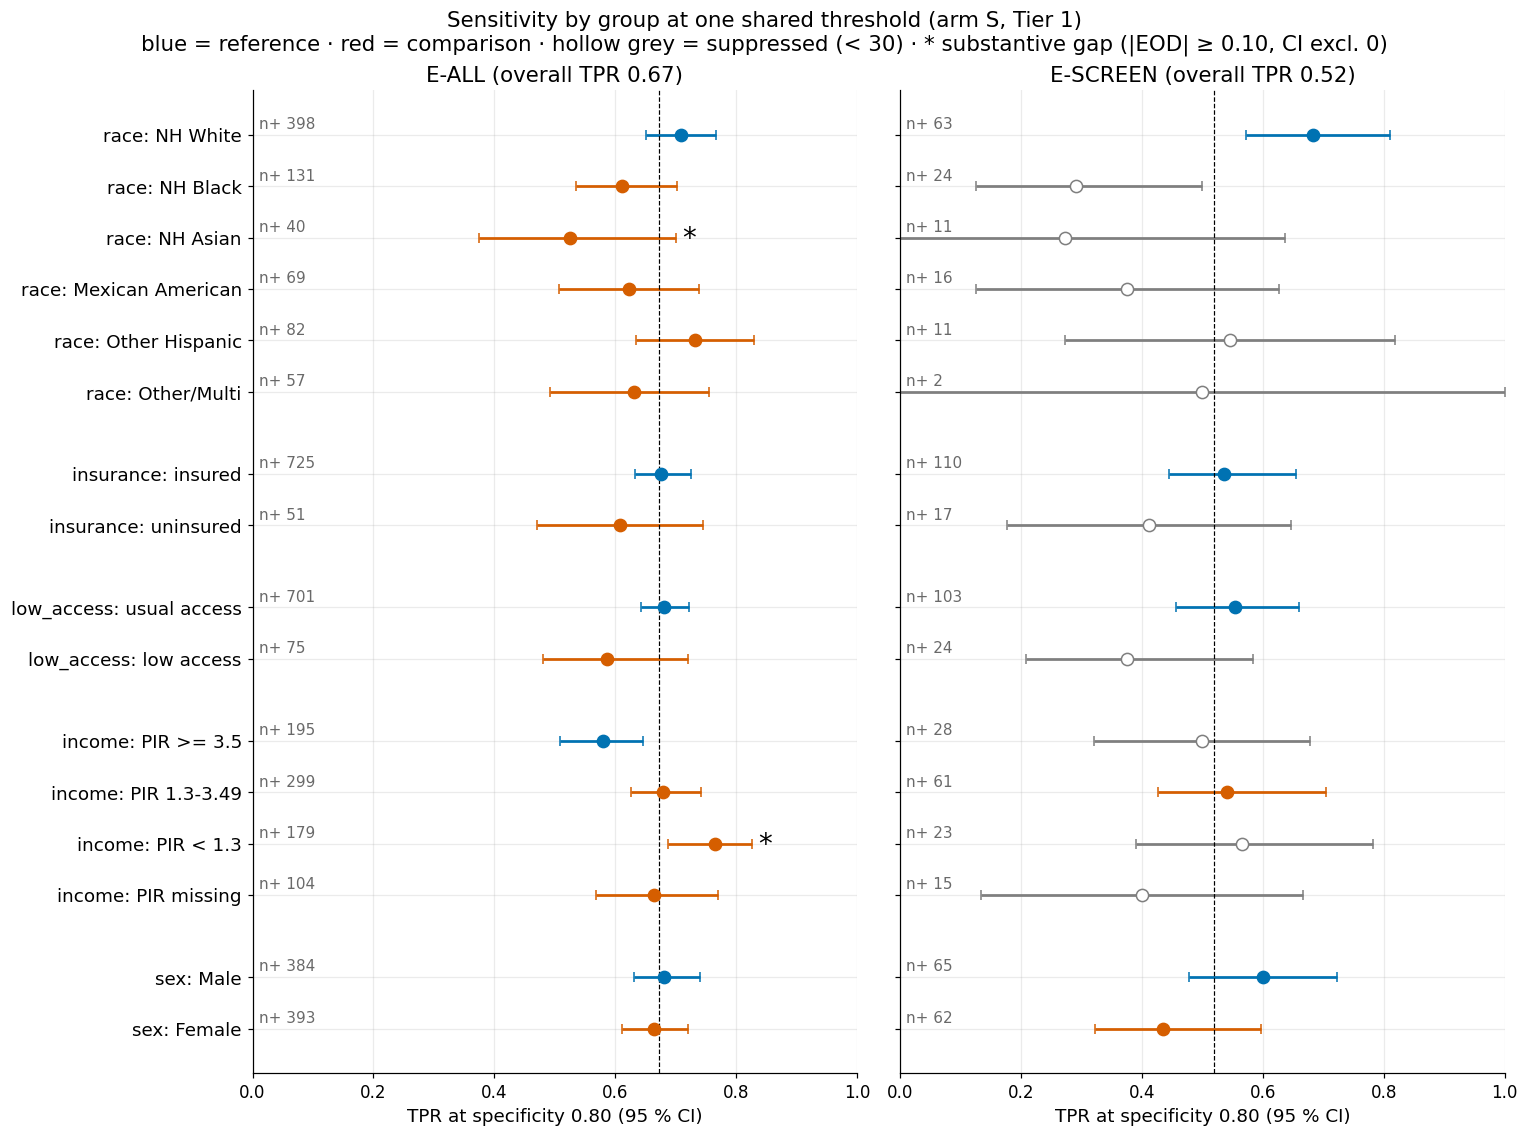

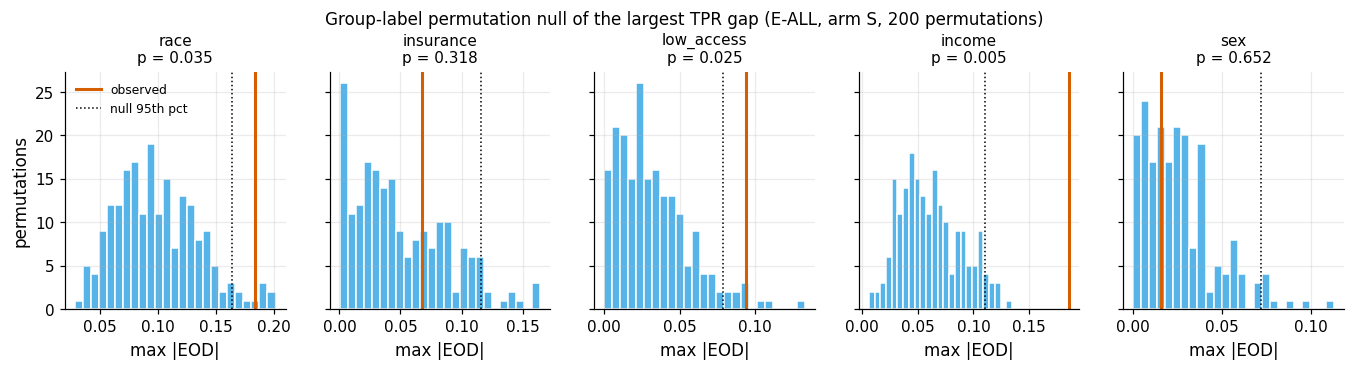

In [181]:
# Figure 8-1: group TPR forest plots (E-ALL and E-SCREEN) and the permutation-null histograms.
# Saves figures S8_group_tpr and S8_permutation_null; adds the metrics to the section dict.
plots.set_style()
def tpr_panel(ax, GT, ET, title, overall):
    """Point-range of group TPRs; returns y labels (attribute: group)."""
    ylabels, ypos, k = [], [], 0
    for attr in F.ATTRIBUTES:
        g = GT[GT["attribute"] == attr]
        for _, r in g.iterrows():
            # Suppressed cells are drawn hollow grey, the reference group blue, comparison groups vermillion.
            sup = r["status"] == "suppress"
            col = C.OKABE_ITO["grey"] if sup else (C.OKABE_ITO["blue"] if r["group"] == F.REFERENCE[attr] else C.OKABE_ITO["vermillion"])
            ax.errorbar(r["tpr"], -k, xerr=[[r["tpr"] - r["tpr_lo"]], [r["tpr_hi"] - r["tpr"]]], fmt="o",
                        color=col, mfc="white" if sup else col, capsize=3, ms=8, lw=1.8)
            e = ET[(ET["attribute"] == attr) & (ET["group"] == r["group"])]
            # A star marks a substantive, reportable gap (|EOD| >= 0.10, CI excludes 0).
            if len(e) and bool(e["substantive"].iloc[0]) and e["verdict_status"].iloc[0] == "reportable":
                ax.annotate("*", (r["tpr_hi"], -k), xytext=(4, -6), textcoords="offset points", fontsize=18, color="black")
            ax.annotate(f"n+ {int(r['n_pos'])}", (0.01, -k), xytext=(0, 4), textcoords="offset points", fontsize=10, color="dimgrey")
            ylabels.append(f"{attr}: {r['group']}")
            ypos.append(-k)
            k += 1
        # Extra vertical space between attribute blocks.
        k += 0.6
    # Dashed line = overall TPR of the population.
    ax.axvline(overall, color="black", lw=0.8, ls="--")
    ax.set_yticks(ypos); ax.set_yticklabels(ylabels, fontsize=12)
    ax.tick_params(axis="x", labelsize=11)
    ax.set_xlabel("TPR at specificity 0.80 (95 % CI)", fontsize=12)
    ax.set_title(title, fontsize=14)
    ax.set_xlim(0, 1)

# E-SCREEN tables are needed for the right panel (computed in §8.4, re-used there)
GTs, ETs = tables("E-SCREEN", 1)
# E-SCREEN overall recall at specificity 0.80 on its own negatives.
rec_s, _ = ek.recall_at_specificity(y_esc[esc], PM[("S", 1, "lr")][esc])
fig, axes = plt.subplots(1, 2, figsize=(14, 10.5))
tpr_panel(axes[1], GTs, ETs, f"E-SCREEN (overall TPR {rec_s:.2f})", rec_s)
axes[1].tick_params(labelleft=False)
tpr_panel(axes[0], GT1, ET1, f"E-ALL (overall TPR {rec_check:.2f})", rec_check)
fig.suptitle("Sensitivity by group at one shared threshold (arm S, Tier 1)\n"
             "blue = reference · red = comparison · hollow grey = suppressed (< 30) · * substantive gap (|EOD| ≥ 0.10, CI excl. 0)", fontsize=14)
fig.tight_layout()
f81 = plots.savefig(fig, "S8_group_tpr", caption="F8-1. TPR at specificity 0.80 by audit group for arm S (Tier 1) on E-ALL "
                    "and E-SCREEN, stratified bootstrap 95 % CI with the threshold re-estimated per replicate; dashed line = "
                    "overall TPR; hollow grey markers are suppressed cells (n < 30 or fewer than 30 positives).")
plt.show()

# Permutation panels, one per attribute: observed max |EOD| (red) against the null 95th percentile (dotted).
fig, axes = plt.subplots(1, len(F.ATTRIBUTES), figsize=(15, 2.8), sharey=True)
for ax, attr in zip(axes, F.ATTRIBUTES):
    row = PERM1.set_index("attribute").loc[attr]
    if attr in NULL1:
        ax.hist(NULL1[attr], bins=25, color=C.OKABE_ITO["sky"], edgecolor="white")
        ax.axvline(row["observed_max_eod"], color=C.OKABE_ITO["vermillion"], lw=2, label="observed")
        ax.axvline(row["null_q95"], color="black", ls=":", lw=1, label="null 95th pct")
        ax.set_title(f"{attr}\np = {row['p_value']:.3f}", fontsize=10)
    ax.set_xlabel("max |EOD|")
axes[0].set_ylabel("permutations"); axes[0].legend(fontsize=8)
fig.suptitle("Group-label permutation null of the largest TPR gap (E-ALL, arm S, 200 permutations)", fontsize=11, y=1.08)
f81b = plots.savefig(fig, "S8_permutation_null", caption="F8-1b. Null distribution of max |TPR_g - TPR_ref| over the reportable "
                     "groups when group labels are permuted 200 times (threshold fixed), with the observed value (red) "
                     "and the null 95th percentile (dotted). E-ALL, arm S, Tier 1.")
plt.show()
# Keep the E-ALL Tier 1 results for the metrics file.
S8["group_metrics_eall_t1"] = GT1.round(5).to_dict("records")
S8["eod_eall_t1"] = ET1.round(5).to_dict("records")
S8["permutation_eall_t1"] = PERM1.round(5).to_dict("records")
S8["threshold_eall_t1"] = thr_eall
S8["overall_tpr_eall_t1"] = rec_check

**So what.** The left panel is the audit in one picture: NH Asian adults and the highest income band fall clearly
below the overall TPR, the lowest income band lies above it; on E-SCREEN almost every group is suppressed. In the
permutation panel the observed maximum gap lies beyond the null's 95th percentile for race, income and low access, and
inside it for insurance and sex.

## 8.4 E-SCREEN
**Why.** The same audit on the use-case population (specificity 0.80 on E-SCREEN negatives; read in §8.11).

In [182]:
# Same group audit on the use-case population E-SCREEN (specificity 0.80 on its own negatives).
# Reuses audit(); the tables are stored in the section dict for the Outputs cell.
PERMs, NULLs = permutation_block("E-SCREEN", 1)
print(f"E-SCREEN, Tier 1, arm S: overall TPR {rec_s:.3f}")
show(GTs[cols_show], 3)
print()
show(ETs[["attribute", "group", "ref", "eod", "eod_lo", "eod_hi", "flag_0.05", "substantive", "verdict_status"]], 3)
print()
show(PERMs, 3)
# reportable: enough cases for a verdict (not suppressed by the small-cell rule).
rep_s = ETs[ETs["verdict_status"].eq("reportable")]
print(f"\nreportable E-SCREEN gaps: {len(rep_s)} of {len(ETs)}; substantive among them: {int(rep_s['substantive'].sum())}")
S8["group_metrics_escreen_t1"] = GTs.round(5).to_dict("records")
S8["eod_escreen_t1"] = ETs.round(5).to_dict("records")
S8["permutation_escreen_t1"] = PERMs.round(5).to_dict("records")
S8["overall_tpr_escreen_t1"] = rec_s

E-SCREEN, Tier 1, arm S: overall TPR 0.520


attribute,group,n,n_pos,tpr,tpr_lo,tpr_hi,fpr,sel,ppv,auc,auc_lo,auc_hi,oe,status,flags
race,NH White,2392,63,0.683,0.571,0.810,0.210,0.222,0.081,0.831,0.792,0.866,0.072,present,
race,NH Black,433,24,0.292,0.125,0.500,0.225,0.229,0.071,0.644,0.562,0.729,0.145,suppress,n_pos<30;ci_width>=0.30
race,NH Asian,223,11,0.273,0.000,0.636,0.127,0.135,0.100,0.809,0.703,0.900,0.179,suppress,n_pos<30;ci_width>=0.30;exploratory
race,Mexican American,256,16,0.375,0.125,0.627,0.158,0.172,0.136,0.761,0.663,0.848,0.193,suppress,n_pos<30;ci_width>=0.30
race,Other Hispanic,394,11,0.545,0.273,0.818,0.170,0.180,0.085,0.828,0.740,0.916,0.082,suppress,n_pos<30;ci_width>=0.30
race,Other/Multi,236,2,0.500,0.000,1.000,0.214,0.216,0.020,0.848,0.671,1.000,0.024,suppress,n_pos<30;ci_width>=0.30
insurance,insured,3571,110,0.536,0.445,0.655,0.208,0.218,0.076,0.787,0.751,0.819,0.085,present,
insurance,uninsured,356,17,0.412,0.176,0.647,0.124,0.138,0.143,0.775,0.697,0.848,0.153,suppress,n_pos<30;ci_width>=0.30
low_access,usual access,3240,103,0.553,0.456,0.660,0.221,0.232,0.076,0.778,0.740,0.816,0.085,present,
low_access,low access,691,24,0.375,0.208,0.583,0.100,0.110,0.118,0.826,0.773,0.877,0.128,suppress,n_pos<30;ci_width>=0.30


attribute,group,ref,eod,eod_lo,eod_hi,flag_0.05,substantive,verdict_status
race,NH Black,NH White,-0.391,-0.585,-0.171,True,True,suppressed
race,NH Asian,NH White,-0.410,-0.683,-0.062,True,True,suppressed
race,Mexican American,NH White,-0.308,-0.529,-0.026,True,True,suppressed
race,Other Hispanic,NH White,-0.137,-0.442,0.179,True,False,suppressed
race,Other/Multi,NH White,-0.183,-0.762,0.397,True,False,suppressed
insurance,uninsured,insured,-0.125,-0.396,0.124,True,False,suppressed
low_access,low access,usual access,-0.178,-0.381,0.044,True,False,suppressed
income,PIR 1.3-3.49,PIR >= 3.5,0.041,-0.160,0.285,False,False,suppressed
income,PIR < 1.3,PIR >= 3.5,0.065,-0.224,0.346,True,False,suppressed
income,PIR missing,PIR >= 3.5,-0.100,-0.407,0.207,True,False,suppressed


pop,tier,attribute,n_groups_eligible,observed_max_eod,null_q95,p_value,note,null_mean
E-SCREEN,1,race,0,,,,reference or all groups suppressed,
E-SCREEN,1,insurance,0,,,,reference or all groups suppressed,
E-SCREEN,1,low_access,0,,,,reference or all groups suppressed,
E-SCREEN,1,income,1,,,,reference or all groups suppressed,
E-SCREEN,1,sex,1,0.165,0.180,0.085,,0.073



reportable E-SCREEN gaps: 1 of 11; substantive among them: 0


## 8.5 Tier 2 summary
**Why.** Does adding total and HDL cholesterol (Tier 2) change the gaps? (read in §8.11)

In [183]:
# Tier 2 (adds total and HDL cholesterol): do the group gaps change?
# Compares EOD and permutation results between the two tiers.
GT2, ET2 = tables("E-ALL", 2)
PERM2, _ = permutation_block("E-ALL", 2)
# Join Tier 1 and Tier 2 EOD per group (suffix _t2) to read them side by side.
cmp_t = (ET1.set_index(["attribute", "group"])[["eod", "eod_lo", "eod_hi", "verdict_status"]]
         .join(ET2.set_index(["attribute", "group"])[["eod", "eod_lo", "eod_hi"]], rsuffix="_t2"))
# Change of the signed EOD when the lipids are added.
cmp_t["delta_t2_t1"] = cmp_t["eod_t2"] - cmp_t["eod"]
display(cmp_t.round(3))
summ = PERM1.set_index("attribute")[["observed_max_eod", "p_value"]].join(
    PERM2.set_index("attribute")[["observed_max_eod", "p_value"]], rsuffix="_t2")
print("\nmax |EOD| (reportable groups) and permutation p, Tier 1 vs Tier 2:")
display(summ.round(3))
# Largest absolute shift of any group's EOD between the tiers.
max_shift = float(cmp_t["delta_t2_t1"].abs().max())
print(f"largest change of any EOD from Tier 1 to Tier 2: {max_shift:.3f}")
S8["tier2_summary"] = dict(eod=ET2.round(5).to_dict("records"), permutation=PERM2.round(5).to_dict("records"),
                           max_abs_eod_shift=max_shift)

eod  eod_lo  eod_hi verdict_status  eod_t2  eod_lo_t2  eod_hi_t2  delta_t2_t1
attribute  group                                                                                            
race       NH Black         -0.098  -0.192   0.009     reportable  -0.065     -0.154      0.017        0.033
           NH Asian         -0.184  -0.343  -0.014     reportable  -0.179     -0.324     -0.006        0.005
           Mexican American -0.085  -0.214   0.031     reportable  -0.091     -0.209      0.043       -0.006
           Other Hispanic    0.023  -0.073   0.135     reportable   0.040     -0.068      0.143        0.016
           Other/Multi      -0.077  -0.220   0.046     reportable   0.008     -0.117      0.131        0.085
insurance  uninsured        -0.068  -0.197   0.068     reportable  -0.104     -0.227      0.037       -0.036
low_access low access       -0.094  -0.206   0.041     reportable  -0.160     -0.256     -0.018       -0.067
income     PIR 1.3-3.49      0.099   0.018   0.197     reportable   0.087     -0.009      0.161       -0.013
           PIR < 1.3         0.186   0.085   0.270     reportable   0.145      0.037      0.225       -0.041
           PIR missing       0.084  -0.044   0.216     reportable   0.096     -0.028      0.188        0.012
sex        Female           -0.016  -0.083   0.051     reportable  -0.027     -0.086      0.043       -0.011


max |EOD| (reportable groups) and permutation p, Tier 1 vs Tier 2:


,observed_max_eod,p_value,observed_max_eod_t2,p_value_t2
attribute,,,,
race,0.184,0.035,0.179,0.045
insurance,0.068,0.318,0.104,0.055
low_access,0.094,0.025,0.160,0.005
income,0.186,0.005,0.145,0.005
sex,0.016,0.652,0.027,0.458


largest change of any EOD from Tier 1 to Tier 2: 0.085


## 8.6 3 × 3 label matrix
**Why.** RQ3 asks whether the *label* decides who the model misses. H3 is a genuine pre-registration
(`prior_exposure = none`): the identical arm-S pipeline (same folds, steps, C0 and weights) is trained on `L_self`,
`L_A1c` and the union `L_comb` and scored on three kinds of diabetes – **D-uncontrolled** (self-report and HbA1c ≥ 6.5),
**D-controlled** (self-report, HbA1c < 6.5: treatment masking) and **Undiagnosed** (HbA1c ≥ 6.5, no diagnosis). Each
cell is recall at specificity 0.80 on the common non-diabetic negatives. Locked prediction: `L_self` misses Undiagnosed
most, `L_A1c` misses D-controlled most, `L_comb` has the smallest worst-cell gap; differences below 0.05 are
equivalent. "Misses most" is read **column-wise** (coded in `fairness.h3_elements` before the matrix was viewed);
contrasts are paired bootstrap differences judged at SESOI 0.05.

In [184]:
# 3 x 3 label matrix: arm S trained on each of three labels, scored on three kinds of diabetes (H3).
# Refits arm S on L_self and L_A1c over the same folds; the L_comb row reuses the stored OOF predictions.
LABELS3 = ("L_self", "L_A1c", "L_comb")
# One label vector per training label (training part).
YL = {lab: cl[lab].to_numpy().astype(int) for lab in LABELS3}
# Guard: the L_comb vector is the frozen label that arm S was trained on.
assert np.array_equal(YL["L_comb"], y)
from joblib import Parallel, delayed
t0 = time.time()
# Factory for a fresh arm-S pipeline with the stored C0.
mk_S = lambda: P.build_pipeline(cfgS, 1, C_=C0)
# Refit on the two other labels in parallel; same folds and fit parameters as S, so the rows are paired.
new = Parallel(n_jobs=2)(delayed(ek.cv_predict)(mk_S, X1, YL[lab], folds, fit_params=fpS) for lab in ("L_self", "L_A1c"))
# The L_comb row is the stored arm-S OOF; no refit is needed.
OOF3 = {"L_self": new[0], "L_A1c": new[1], "L_comb": OOF[("S", 1, "lr")]}
PM3 = {lab: ek.mean_oof(OOF3[lab], n) for lab in LABELS3}
# cnt: size of each 3 x 3 stratum in the training part, compared with the frozen full-cohort counts.
cnt = pd.Series(strat).value_counts()
full = L.strata_counts(clean)
print(f"refitted arm S on L_self and L_A1c: {2 * len(folds)} fits, {time.time() - t0:.0f} s")
print("training-part strata (share of the frozen full-cohort counts):")
print("   " + ", ".join(f"{k} {int(cnt[k])} ({cnt[k] / full[k]:.2f})" for k in L.STRATA_3X3))
# Guard: the stratified hold-out leaves about 80 % of each stratum in the training part (0.75-0.85).
assert all(0.75 < cnt[k] / full[k] < 0.85 for k in L.STRATA_3X3)
# Recall at specificity 0.80 on the common non-diabetic negatives, per training label and stratum.
LM = F.label_matrix(strat, PM3, n_boot=C.N_BOOT, seed=ek.derive_seed(C.SEED_MASTER, "S8", "3x3"))
cells = LM["cells"]
# consistency: L_comb row, Undiagnosed column = E-SCREEN recall of arm S (same positives, same negatives)
assert abs(LM["recall"].loc["L_comb", "Undiagnosed"] - rec_s) < 1e-12
print("\nrecall at specificity 0.80 on the common NonDiabetic negatives (rows: training label):")
display(LM["recall"].round(3))
print("\nROC-AUC against the common negatives:")
display(LM["auc"].round(3))
print()
show(cells[["train_label", "stratum", "n_pos", "recall", "recall_lo", "recall_hi", "auc", "auc_lo", "auc_hi"]], 3)
# Locked H3 elements (E1-E3) as paired bootstrap contrasts; coded before the matrix was viewed.
H3E = F.h3_elements(LM)
print("\npre-registered contrasts (predicted sign: negative):")
show(H3E, 3)
# row-wise reading (secondary): in which stratum does each training label have its lowest recall?
roww = LM["recall"].idxmin(axis=1).to_dict()
print(f"\nrow-wise reading (secondary): lowest-recall stratum per training label {roww}")
# Worst-cell gap per training label: largest recall shortfall against the best label in any stratum.
gaps = F._worst_gap(LM["point"]["tpr"][0])
print("worst-cell gap per training label:", dict(zip(LABELS3, np.round(gaps, 3))))

refitted arm S on L_self and L_A1c: 50 fits, 9 s
training-part strata (share of the frozen full-cohort counts):
   D_uncontrolled 455 (0.80), D_controlled 195 (0.78), Undiagnosed 127 (0.84), NonDiabetic 3807 (0.80)



recall at specificity 0.80 on the common NonDiabetic negatives (rows: training label):


,D_uncontrolled,D_controlled,Undiagnosed
L_self,0.738,0.615,0.504
L_A1c,0.741,0.569,0.559
L_comb,0.741,0.610,0.520



ROC-AUC against the common negatives:


,D_uncontrolled,D_controlled,Undiagnosed
L_self,0.860,0.812,0.767
L_A1c,0.861,0.797,0.784
L_comb,0.862,0.810,0.781


train_label,stratum,n_pos,recall,recall_lo,recall_hi,auc,auc_lo,auc_hi
L_self,D_uncontrolled,455,0.738,0.701,0.785,0.860,0.844,0.875
L_self,D_controlled,195,0.615,0.544,0.682,0.812,0.788,0.837
L_self,Undiagnosed,127,0.504,0.417,0.598,0.767,0.733,0.800
L_A1c,D_uncontrolled,455,0.741,0.697,0.787,0.861,0.845,0.875
L_A1c,D_controlled,195,0.569,0.503,0.646,0.797,0.771,0.824
L_A1c,Undiagnosed,127,0.559,0.457,0.646,0.784,0.752,0.817
L_comb,D_uncontrolled,455,0.741,0.701,0.789,0.862,0.847,0.877
L_comb,D_controlled,195,0.610,0.533,0.687,0.810,0.786,0.834
L_comb,Undiagnosed,127,0.520,0.441,0.630,0.781,0.749,0.813



pre-registered contrasts (predicted sign: negative):


element,contrast,est,lo,hi,se,predicted,verdict,reversed_ci_excl_0
E1,Undiagnosed: L_self - L_A1c,-0.055,-0.126,0.024,0.036,< 0,inconclusive,False
E1,Undiagnosed: L_self - L_comb,-0.016,-0.079,0.024,0.027,< 0,inconclusive,False
E2,D_controlled: L_A1c - L_self,-0.046,-0.097,0.005,0.026,< 0,inconclusive,False
E2,D_controlled: L_A1c - L_comb,-0.041,-0.092,0.010,0.027,< 0,inconclusive,False
E3,worst-cell gap: L_comb - L_self,-0.016,-0.079,0.028,0.027,< 0,inconclusive,False
E3,worst-cell gap: L_comb - L_A1c,-0.007,-0.087,0.059,0.036,< 0,inconclusive,False



row-wise reading (secondary): lowest-recall stratum per training label {'L_self': 'Undiagnosed', 'L_A1c': 'Undiagnosed', 'L_comb': 'Undiagnosed'}
worst-cell gap per training label: {'L_self': np.float64(0.055), 'L_A1c': np.float64(0.046), 'L_comb': np.float64(0.039)}


H3 element verdicts {'E1': 'inconclusive', 'E2': 'inconclusive', 'E3': 'inconclusive'} -> H3 inconclusive


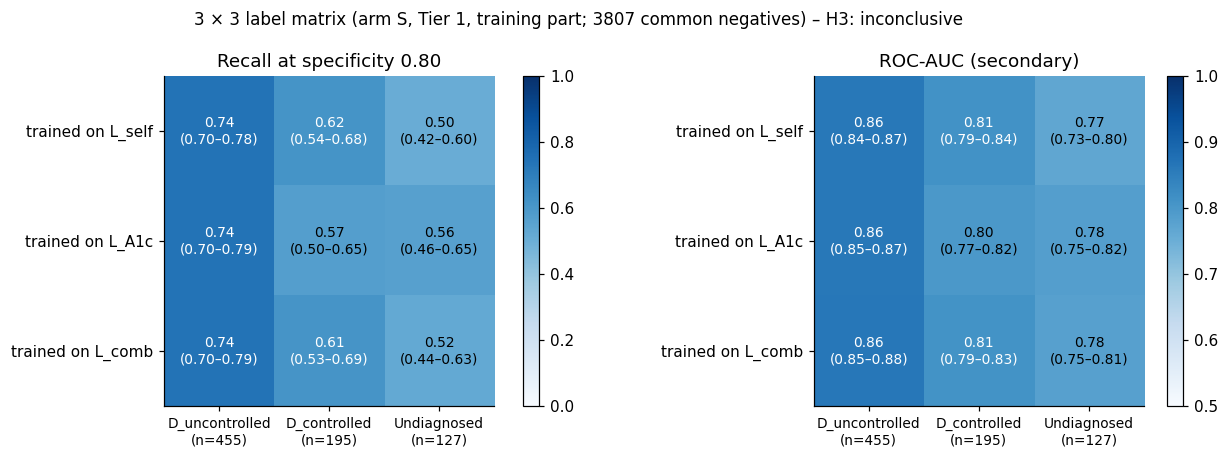

In [185]:
# Combine the H3 element verdicts, save the tables and draw the label-matrix heat maps.
# Writes results/S8/label_matrix_cells.csv and h3_contrasts.csv; saves figure S8_label_matrix.
# Each H3 element (E1-E3) combines the verdicts of its contrasts.
elem_v = {}
for el, g in H3E.groupby("element"):
    elem_v[el] = ek.combine_verdicts(g["verdict"].tolist())
# H3 overall combines the three element verdicts.
h3_v = ek.combine_verdicts(list(elem_v.values()))
if H3E["reversed_ci_excl_0"].any():                       # locked falsifier
    h3_v = "refuted"
print(f"H3 element verdicts {elem_v} -> H3 {h3_v}")
cells.to_csv(OUT / "label_matrix_cells.csv", index=False)
H3E.to_csv(OUT / "h3_contrasts.csv", index=False)
S8["label_matrix"] = dict(cells=cells.round(5).to_dict("records"), recall=LM["recall"].round(5).to_dict(),
                          auc=LM["auc"].round(5).to_dict(), contrasts=H3E.round(5).to_dict("records"),
                          element_verdicts=elem_v, verdict=h3_v, row_wise_min=roww,
                          worst_gap=dict(zip(LABELS3, gaps.round(5))), strata_train=cnt.to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
# Left: recall at specificity 0.80; right: ROC-AUC (secondary). Cells show estimate (95 % CI).
for ax, (mat, key, ttl) in zip(axes, [(LM["recall"], "recall", "Recall at specificity 0.80"), (LM["auc"], "auc", "ROC-AUC (secondary)")]):
    # Colour scale: recall from 0, AUC from 0.5 (chance level).
    im = ax.imshow(mat.to_numpy(), cmap="Blues", vmin=0 if key == "recall" else 0.5, vmax=1)
    for i, lab in enumerate(LABELS3):
        for j, st in enumerate(F.POS_STRATA):
            r = cells[(cells["train_label"] == lab) & (cells["stratum"] == st)].iloc[0]
            v = mat.loc[lab, st]
            # White text on dark cells for legibility; the switch point differs by metric.
            ax.text(j, i, f"{v:.2f}\n({r[key + '_lo']:.2f}–{r[key + '_hi']:.2f})", ha="center", va="center",
                    fontsize=9, color="white" if v > (0.6 if key == "recall" else 0.8) else "black")
    ax.set_xticks(range(3)); ax.set_xticklabels([f"{s}\n(n={int(cnt[s])})" for s in F.POS_STRATA], fontsize=9)
    ax.set_yticks(range(3)); ax.set_yticklabels([f"trained on {l}" for l in LABELS3])
    ax.set_title(ttl); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle(f"3 × 3 label matrix (arm S, Tier 1, training part; {int(cnt['NonDiabetic'])} common negatives) – H3: {h3_v}", fontsize=11)
fig.tight_layout()
f82 = plots.savefig(fig, "S8_label_matrix", caption="F8-2. 3x3 label matrix: arm S trained on L_self, L_A1c or L_comb "
                    "(identical folds, steps and C0) and scored on D-uncontrolled, D-controlled and Undiagnosed cases against "
                    "the common NonDiabetic negatives. Left: recall at specificity 0.80 with 95 % stratified bootstrap CI "
                    "(thresholds re-estimated per replicate); right: ROC-AUC.")
plt.show()

**So what.** Every element of the locked pattern points the predicted way, but the differences are small (at most
about 0.06) and every paired CI includes 0 while reaching beyond ±0.05, so H3 is **inconclusive**. The row-wise reading
tells the stronger story: *whatever* the training label, the Undiagnosed column is the hardest, and the AUCs agree.
Undiagnosed people lack the care traces and treatment-era profile the features pick up, so changing the label shifts
recall by only a few points. The label shapes *what the model claims to measure* (§5) more than *whom this feature set
can find*.

## 8.7 Access-proxy audit arm
**Why.** If the self-report label carries the access imprint of §5, a model trained on `L_self` should learn that
*lacking access lowers the chance of "having diabetes"* – an artefact of who gets diagnosed – while one trained on
HbA1c (which needs no doctor) should not. The audit arm adds **uninsured** (HIQ011 = 2) and **no usual place of care**
(HUQ030 = 2) to the arm-S pipeline and fits it on each label; per-SD coefficients are bootstrapped with the same seed
for every label, so label differences are paired. This arm is an **audit instrument only**.

In [186]:
# Access-proxy audit arm: arm S plus uninsured / no-usual-place features, coefficients bootstrapped per label.
# Audit instrument only. Writes results/S8/access_audit_coefs.csv and access_audit_diffs.csv.
t0 = time.time()
# Factory for the audit pipeline: arm S plus the two access dummies.
mk_acc = lambda: F.access_pipeline(cfgS, 1, C_=C0)
# Guard: both access features survive in the pipeline's feature names (else coefficients would be missing).
assert set(F.ACCESS_FEATURES) <= set(mk_acc()[:-1].fit(X1.iloc[:500], y[:500]).get_feature_names_out())
# Same seed for every label: identical bootstrap resamples, so label differences are paired.
seed_acc = ek.derive_seed(C.SEED_MASTER, "S8", "access_audit")
# Bootstrapped per-SD coefficients for each training label.
CB = {lab: ek.coef_bootstrap(mk_acc, X1, YL[lab], n_boot=C.N_BOOT_COEF, seed=seed_acc, fit_params=fpS, n_jobs=N_JOBS)
      for lab in LABELS3}
# SD of a binary feature, sqrt(p (1 - p)): converts a per-SD coefficient into a yes-versus-no odds ratio.
sd_bin = {f: float(np.sqrt(grp[f].fillna(0).mean() * (1 - grp[f].fillna(0).mean()))) for f in F.ACCESS_FEATURES}
acc_rows = []
for f in F.ACCESS_FEATURES:
    for lab in LABELS3:
        s_ = CB[lab].summary.loc[f]
        acc_rows.append({"feature": f, "label": lab, "coef_per_sd": s_["coef"], "lo": s_["q_low"], "hi": s_["q_high"],
                         "boot_sd": s_["sd"], "OR_yes_vs_no": np.exp(s_["coef"] / sd_bin[f]),
                         "OR_lo": np.exp(s_["q_low"] / sd_bin[f]), "OR_hi": np.exp(s_["q_high"] / sd_bin[f])})
ACC = pd.DataFrame(acc_rows)
# Paired differences between training labels: coefficient difference, CI from the paired bootstrap.
diff_rows = []
for f in F.ACCESS_FEATURES:
    for a, b in (("L_self", "L_comb"), ("L_self", "L_A1c"), ("L_comb", "L_A1c")):
        d = CB[a].coefs[f].to_numpy() - CB[b].coefs[f].to_numpy()
        e, lo, hi, se = F.summarise(CB[a].summary.loc[f, "coef"] - CB[b].summary.loc[f, "coef"], d)
        diff_rows.append({"feature": f, "contrast": f"{a} - {b}", "diff_per_sd": e, "lo": lo, "hi": hi,
                          "ci_excludes_0": bool(lo > 0 or hi < 0)})
ACCD = pd.DataFrame(diff_rows)
print(f"access audit arm: {len(LABELS3)} labels x (1 + {C.N_BOOT_COEF}) fits, {time.time() - t0:.0f} s")
show(ACC, 3)
print("\npaired differences of the per-SD coefficient between training labels:")
show(ACCD, 3)
ACC.to_csv(OUT / "access_audit_coefs.csv", index=False)
ACCD.to_csv(OUT / "access_audit_diffs.csv", index=False)
S8["access_audit"] = dict(coefs=ACC.round(5).to_dict("records"), diffs=ACCD.round(5).to_dict("records"),
                          n_boot=C.N_BOOT_COEF, sd_binary=sd_bin)

access audit arm: 3 labels x (1 + 500) fits, 44 s


feature,label,coef_per_sd,lo,hi,boot_sd,OR_yes_vs_no,OR_lo,OR_hi
uninsured,L_self,-0.112,-0.277,0.015,0.079,0.669,0.370,1.054
uninsured,L_A1c,0.016,-0.140,0.153,0.075,1.057,0.606,1.729
uninsured,L_comb,-0.012,-0.152,0.122,0.072,0.958,0.581,1.549
no_usual_place,L_self,-0.203,-0.386,-0.054,0.087,0.526,0.294,0.843
no_usual_place,L_A1c,-0.095,-0.279,0.044,0.083,0.741,0.412,1.150
no_usual_place,L_comb,-0.099,-0.259,0.025,0.073,0.731,0.440,1.081



paired differences of the per-SD coefficient between training labels:


feature,contrast,diff_per_sd,lo,hi,ci_excludes_0
uninsured,L_self - L_comb,-0.100,-0.231,0.014,False
uninsured,L_self - L_A1c,-0.128,-0.286,0.017,False
uninsured,L_comb - L_A1c,-0.028,-0.090,0.038,False
no_usual_place,L_self - L_comb,-0.104,-0.229,0.013,False
no_usual_place,L_self - L_A1c,-0.108,-0.276,0.078,False
no_usual_place,L_comb - L_A1c,-0.004,-0.076,0.090,False


**So what.** The access imprint appears where the label requires a doctor. Trained on self-report, both access features
get negative coefficients – no usual place of care *lowers* predicted risk (odds ratio about 0.5, CI excluding 0) –
although §4 showed the insured–uninsured prevalence gap is age confounding. Trained on HbA1c the coefficients are small
with CIs including 0, and the union label sits next to HbA1c. The paired self-report minus union differences (about
−0.10 per SD) have CIs that just include 0: suggestive, not established. A self-report model would **score people with
poor access as lower risk because they were never diagnosed** – a feedback loop that supports the union label and
keeping access out of the model.

## 8.8 Reweighing
**Why.** Reweighing (Kamiran & Calders 2012) gives each training row the weight w(g, y) = P(g)·P(y) / P(g, y), computed
from *unweighted* counts; on its own this would make group and label independent. Here the weights are then multiplied
by arm S's survey weights inside every training fold (so the comparison with S is paired), which means independence
holds only partly in the weights actually fitted: this is a **partial reweighing**. A correctly weighted version
(reweighing computed from survey-weighted counts) is checked in §9 (post-audit corrections); its conclusion, that
reweighing is not adopted, is unchanged. Race (pre-specified) and, as extensions, insurance and low access are
reweighed. ΔAUC uses the §7.4.1 engine; gap changes are paired bootstrap differences of EOD.

In [187]:
# Reweighing (Kamiran-Calders) inside every training fold, compared with arm S on the same folds.
# Defines fold_auc() and compare_auc(); writes results/S8/reweighing_auc.csv and reweighing_eod.csv.
from joblib import parallel_config
from sklearn.metrics import roc_auc_score
from scipy import stats as sstats

# AUC of each (repeat, fold) test set, optionally restricted to a population; feeds the corrected t-test.
def fold_auc(oof, pop="E-ALL"):
    yy, m = pop_of(pop)
    out = {}
    for (r, f), g in oof.groupby(["repeat", "fold"]):
        rows = g["row"].to_numpy()
        k = m[rows]
        out[(r, f)] = roc_auc_score(yy[rows][k], g["prob"].to_numpy()[k])
    return pd.Series(out)

def compare_auc(oof_a, oof_b, pop="E-ALL", tag=""):
    """Paired ΔAUC A - B with the S7 engine: on E-ALL the estimate is the fold-mean paired difference and the interval the
    wider of corrected t and paired bootstrap; on E-SCREEN the pooled-OOF difference with its paired bootstrap interval."""
    yy, m = pop_of(pop)
    # Paired bootstrap of the pooled-OOF AUC difference A - B; both arms share the same resamples.
    pa, pb = ek.mean_oof(oof_a, n), ek.mean_oof(oof_b, n)
    bs = ek.paired_bootstrap(yy, pa, pb, "roc_auc", n_boot=C.N_BOOT, eval_mask=m,
                             seed=ek.derive_seed(C.SEED_MASTER, "S8", "dauc", tag, pop))
    row = dict(pop=pop, diff_pooled=bs["diff"], boot_lo=bs["ci_low"], boot_hi=bs["ci_high"])
    est, lo, hi, se, interval = bs["diff"], bs["ci_low"], bs["ci_high"], bs["se"], "bootstrap"
    # Minimum detectable difference: (z at 97.5 % + z at 80 %) * SE: two-sided 5 % alpha, 80 % power.
    mdd = (sstats.norm.ppf(0.975) + sstats.norm.ppf(0.8)) * se
    if pop == "E-ALL":
        # Nadeau-Bengio corrected resampled t on the per-fold paired AUC differences; the correction
        # allows for the overlap of training sets across folds.
        ct = ek.corrected_t((fold_auc(oof_a) - fold_auc(oof_b)).to_numpy(), n_train_fold, n_test_fold)
        row.update(t_lo=ct["ci_low"], t_hi=ct["ci_high"])
        est = ct["mean"]
        # Report the wider of the corrected-t and bootstrap intervals (the conservative choice).
        if ct["ci_high"] - ct["ci_low"] >= hi - lo:
            lo, hi, se, interval = ct["ci_low"], ct["ci_high"], ct["se_corr"], "corrected_t"
        # The power quantile uses the corrected-t degrees of freedom instead of the normal quantile.
        mdd = (sstats.t.ppf(0.975, ct["df"]) + sstats.t.ppf(0.80, ct["df"])) * se
    row.update(est=est, lo=lo, hi=hi, se=se, interval=interval, mdd=mdd)
    return row

# Reweighed attributes and, for each, the group whose gap is expected to narrow.
RW_TARGET = {"race": "NH Asian", "insurance": "uninsured", "low_access": "low access"}
OOF_RW, RW_W, RW_ROWS, RW_EOD = {}, {}, [], []
t0 = time.time()
# max_nbytes=None disables joblib's memory-mapping of large arrays.
with parallel_config(max_nbytes=None):
    for attr in RW_TARGET:
        gvals = grp[attr].to_numpy(dtype=object)
        # Reweighing weight w(g, y) = P(g) P(y) / P(g, y) per training row.
        w_rw = F.reweighing_weights(gvals, y)
        RW_W[attr] = w_rw
        # Refit arm S per fold with weight = survey weight x reweighing weight; returns OOF predictions.
        OOF_RW[attr] = F.cv_predict_reweighed(mk_S, X1, y, folds, gvals, base_weight=w_svy, n_jobs=N_JOBS)
print(f"reweighing arms: {len(RW_TARGET)} x {len(folds)} fits, {time.time() - t0:.0f} s")
for attr, w_rw in RW_W.items():
    lv = grp[attr].fillna("(unknown)")
    # One weight per (group, label) cell: weights are constant within a cell, so take the first.
    tab = pd.DataFrame({"g": lv, "y": y, "w": w_rw}).groupby(["g", "y"])["w"].first().unstack()
    print(f"\n{attr}: reweighing weights w(g, y) on the training part (range {w_rw.min():.3f}-{w_rw.max():.3f})")
    display(tab.round(3).rename(columns={0: "w(y=0)", 1: "w(y=1)"}))
    # Repeat-averaged OOF probability of the reweighed arm.
    PMx = ek.mean_oof(OOF_RW[attr], n)
    # Compare with S on both populations; the verdict applies the locked AUC SESOI to the interval.
    for pop in ("E-ALL", "E-SCREEN"):
        r = compare_auc(OOF_RW[attr], OOF[("S", 1, "lr")], pop, tag=f"rw_{attr}")
        r.update(arm=f"S+RW({attr})", w_min=w_rw.min(), w_max=w_rw.max(),
                 verdict_auc=ek.verdict(r["lo"], r["hi"], AUC_SESOI, "+", r["est"]))
        RW_ROWS.append(r)
    # Paired audit of S and the reweighed arm (index 1), used for the change of EOD.
    point, boot, codes, mm = audit(attr, "E-ALL", 1, ("S", "RW"), preds={"RW": PMx})
    lvls = F.LEVELS[attr]
    ref = lvls.index(F.REFERENCE[attr])
    # For each non-reference group: change of EOD and of |EOD| (reweighed minus S) with paired bootstrap CIs.
    for g_i, g_nm in enumerate(lvls):
        if g_i == ref:
            continue
        # EOD = TPR_group - TPR_reference for each arm; bootstrap replicates are paired across arms.
        eod_pt = point["tpr"][0, :, g_i] - point["tpr"][0, :, ref]
        eod_bt = boot["tpr"][:, :, g_i] - boot["tpr"][:, :, ref]
        e, lo, hi, _ = F.summarise(eod_pt[1] - eod_pt[0], eod_bt[:, 1] - eod_bt[:, 0])
        # Change of |EOD|: negative means the gap narrows.
        ea, alo, ahi, _ = F.summarise(abs(eod_pt[1]) - abs(eod_pt[0]), np.abs(eod_bt[:, 1]) - np.abs(eod_bt[:, 0]))
        RW_EOD.append({"arm": f"S+RW({attr})", "attribute": attr, "group": g_nm, "eod_S": eod_pt[0], "eod_RW": eod_pt[1],
                       "d_eod": e, "d_eod_lo": lo, "d_eod_hi": hi, "d_abs_eod": ea, "d_abs_lo": alo, "d_abs_hi": ahi,
                       "target": g_nm == RW_TARGET[attr]})
RWT = pd.DataFrame(RW_ROWS)
RWE = pd.DataFrame(RW_EOD)
print("\nΔAUC reweighed arm − S:")
show(RWT[["arm", "pop", "est", "lo", "hi", "interval", "mdd", "w_min", "w_max", "verdict_auc"]], 4)
print("\nchange of equal-opportunity differences (reweighed − S), E-ALL:")
show(RWE, 3)
RWT.to_csv(OUT / "reweighing_auc.csv", index=False)
RWE.to_csv(OUT / "reweighing_eod.csv", index=False)
S8["reweighing"] = dict(auc=RWT.round(5).to_dict("records"), eod=RWE.round(5).to_dict("records"),
                        weight_range={a: [float(w.min()), float(w.max())] for a, w in RW_W.items()})

reweighing arms: 3 x 25 fits, 6 s

race: reweighing weights w(g, y) on the training part (range 0.699-1.161)


y,w(y=0),w(y=1)
g,,
Mexican American,1.069,0.759
NH Asian,0.987,1.068
NH Black,1.097,0.699
NH White,0.972,1.161
Other Hispanic,1.008,0.961
Other/Multi,1.033,0.865



insurance: reweighing weights w(g, y) on the training part (range 0.949-1.356)


y,w(y=0),w(y=1)
g,,
(unknown),0.949,1.356
insured,1.004,0.979
uninsured,0.955,1.296



low_access: reweighing weights w(g, y) on the training part (range 0.678-1.677)


y,w(y=0),w(y=1)
g,,
(unknown),1.107,0.678
low access,0.924,1.677
usual access,1.016,0.928



ΔAUC reweighed arm − S:


arm,pop,est,lo,hi,interval,mdd,w_min,w_max,verdict_auc
S+RW(race),E-ALL,-0.0002,-0.0018,0.0014,corrected_t,0.0022,0.6987,1.1614,equivalent
S+RW(race),E-SCREEN,-0.0013,-0.0044,0.0020,bootstrap,0.0046,0.6987,1.1614,equivalent
S+RW(insurance),E-ALL,0.0001,-0.0005,0.0007,corrected_t,0.0009,0.9491,1.3560,equivalent
S+RW(insurance),E-SCREEN,0.0021,0.0009,0.0033,bootstrap,0.0017,0.9491,1.3560,equivalent
S+RW(low_access),E-ALL,-0.0002,-0.0017,0.0013,corrected_t,0.0021,0.6780,1.6769,equivalent
S+RW(low_access),E-SCREEN,0.0041,0.0013,0.0069,bootstrap,0.0039,0.6780,1.6769,equivalent



change of equal-opportunity differences (reweighed − S), E-ALL:


arm,attribute,group,eod_S,eod_RW,d_eod,d_eod_lo,d_eod_hi,d_abs_eod,d_abs_lo,d_abs_hi,target
S+RW(race),race,NH Black,-0.098,-0.131,-0.033,-0.086,-0.003,0.033,-0.003,0.084,False
S+RW(race),race,NH Asian,-0.184,-0.201,-0.018,-0.093,0.053,0.018,-0.053,0.093,True
S+RW(race),race,Mexican American,-0.085,-0.103,-0.018,-0.096,0.032,0.018,-0.036,0.089,False
S+RW(race),race,Other Hispanic,0.023,0.006,-0.018,-0.061,0.014,-0.018,-0.054,0.045,False
S+RW(race),race,Other/Multi,-0.077,-0.095,-0.018,-0.053,0.025,0.018,-0.030,0.050,False
S+RW(insurance),insurance,uninsured,-0.068,-0.029,0.039,-0.010,0.062,-0.039,-0.057,0.026,True
S+RW(low_access),low_access,low access,-0.094,-0.047,0.047,-0.011,0.108,-0.047,-0.102,0.049,True


**So what.** Reweighing is an instructive null. Race weights range 0.70–1.16 (NH Black cases down-weighted most), yet every ΔAUC interval lies inside ±0.01. The gaps do not close either: race reweighing leaves the NH Asian gap
where it was and *widens* the NH Black gap (CI excluding 0), probably because it narrows the prevalence difference
that made Black cases easier to find (survey weights alone leave a race spread in positive rate of about 11 points;
the fitted product of reweighing and survey weights leaves about 4, so independence is only partial). Insurance and low-access reweighing narrow their gaps by about 0.04–0.05 with CIs including
0. Reweighing (in this partial form) acts on the label–group association; the gaps of §8.3 come from features and from the diagnosis
component of the label.

## 8.9 WHtR measurement fix (P14-b)
**Why.** §5 found that BMI under-reads adiposity in Asian adults (WHtR − BMI single-feature AUC gain +0.137 Asian vs
+0.049 White), and §8.3 found Asian cases missed most because they are leaner. Arm S+WHtR replaces waist by
waist-to-height ratio (P14, locked in §6, `prior_exposure = descriptive_seen`). Locked prediction **P14-b**: Asian TPR
rises by at least 0.05 (falsifier: upper CI bound below 0.05), with a smaller White change. With 40 Asian positives
clustered in few PSUs, a simple and a **PSU-cluster (Rao–Wu) bootstrap** are both computed; the wider decides.

In [188]:
# P14-b: replace waist by waist-to-height ratio (arm S+WHtR) and test the NH Asian TPR change against arm S.
# Computes simple and PSU-cluster bootstrap CIs per quantity and prints the table.
# Paired audits of S and S+WHtR for race under both resampling schemes.
pW = PM[("S+WHtR", 1, "lr")]
res = {}
for wt in ("simple", "psu"):
    point, boot, codes, mm = audit("race", "E-ALL", 1, ("S", "S+WHtR"), weights=wt)
    res[wt] = (point, boot)
# Level indices of the target group (NH Asian) and the control group (NH White).
lv = F.LEVELS["race"]
iA, iW = lv.index("NH Asian"), lv.index("NH White")
whtr_rows = []
# Add one table row: estimate plus simple and PSU-cluster CIs; the reported interval is the wider of the two.
def add_whtr(name, pt_fn):
    row = {"quantity": name}
    for wt in ("simple", "psu"):
        point, boot = res[wt]
        # pt_fn maps a point-estimate (or replicate) dict to the quantity of interest.
        e, lo, hi, se = F.summarise(pt_fn(point)[0], pt_fn(boot))
        bvals = np.asarray(pt_fn(boot), float)
        row.update({"est": e, f"{wt}_lo": lo, f"{wt}_hi": hi, f"{wt}_se": se, f"{wt}_boot_mean": float(np.nanmean(bvals))})
    # The wider interval decides: conservative with ~40 Asian positives clustered in few PSUs.
    wide = "psu" if (row["psu_hi"] - row["psu_lo"]) >= (row["simple_hi"] - row["simple_lo"]) else "simple"
    row.update(lo=row[f"{wide}_lo"], hi=row[f"{wide}_hi"], interval=wide)
    whtr_rows.append(row)
    return row
r_tA = add_whtr("TPR NH Asian, S", lambda d: d["tpr"][:, 0, iA])
r_tA2 = add_whtr("TPR NH Asian, S+WHtR", lambda d: d["tpr"][:, 1, iA])
r_tW = add_whtr("TPR NH White, S", lambda d: d["tpr"][:, 0, iW])
r_tW2 = add_whtr("TPR NH White, S+WHtR", lambda d: d["tpr"][:, 1, iW])
r_dA = add_whtr("ΔTPR NH Asian", lambda d: d["tpr"][:, 1, iA] - d["tpr"][:, 0, iA])
r_dW = add_whtr("ΔTPR NH White", lambda d: d["tpr"][:, 1, iW] - d["tpr"][:, 0, iW])
r_dd = add_whtr("ΔTPR Asian − ΔTPR White", lambda d: (d["tpr"][:, 1, iA] - d["tpr"][:, 0, iA]) - (d["tpr"][:, 1, iW] - d["tpr"][:, 0, iW]))
r_eod = add_whtr("Δ|EOD| Asian vs White", lambda d: np.abs(d["tpr"][:, 1, iA] - d["tpr"][:, 1, iW]) - np.abs(d["tpr"][:, 0, iA] - d["tpr"][:, 0, iW]))
r_auc = add_whtr("ΔAUC overall", lambda d: d["auc_all"][:, 1] - d["auc_all"][:, 0])
r_aA = add_whtr("ΔAUC within NH Asian", lambda d: d["auc"][:, 1, iA] - d["auc"][:, 0, iA])
r_aW = add_whtr("ΔAUC within NH White", lambda d: d["auc"][:, 1, iW] - d["auc"][:, 0, iW])
r_h4 = add_whtr("ΔAUC Asian − ΔAUC White (H4b, model level)", lambda d: (d["auc"][:, 1, iA] - d["auc"][:, 0, iA]) - (d["auc"][:, 1, iW] - d["auc"][:, 0, iW]))
WH = pd.DataFrame(whtr_rows)
show(WH[["quantity", "est", "simple_lo", "simple_hi", "simple_boot_mean", "psu_lo", "psu_hi", "psu_boot_mean", "interval"]], 3)
# E-SCREEN (secondary; NH Asian has 11 positives -> suppressed, numbers only)
pt_s, bt_s, _, _ = audit("race", "E-SCREEN", 1, ("S", "S+WHtR"))
dA_s = F.summarise(pt_s["tpr"][0, 1, iA] - pt_s["tpr"][0, 0, iA], bt_s["tpr"][:, 1, iA] - bt_s["tpr"][:, 0, iA])
print(f"\nE-SCREEN (suppressed, {int(pt_s['n_pos'][0, 0, iA])} Asian positives): ΔTPR NH Asian {dA_s[0]:+.3f} ({dA_s[1]:+.3f}, {dA_s[2]:+.3f})")
# P14-a (AUC change) was judged in §7; read it back so that P14 can combine parts (a) and (b).
p14a = next(r for r in S7m["scoreboard_detail"] if r["hyp_id"] == "P14" and r["sub"] == "(a) AUC" and r["pop"] == "E-ALL" and r["tier"] == 1)
print(f"P14-a from §7 (E-ALL, corrected t): ΔAUC {p14a['est']:+.4f} ({p14a['lo']:+.4f}, {p14a['hi']:+.4f}) -> {p14a['verdict']}")

quantity,est,simple_lo,simple_hi,simple_boot_mean,psu_lo,psu_hi,psu_boot_mean,interval
"TPR NH Asian, S",0.525,0.375,0.700,0.541,0.333,0.692,0.533,psu
"TPR NH Asian, S+WHtR",0.550,0.400,0.700,0.554,0.353,0.700,0.540,psu
"TPR NH White, S",0.709,0.651,0.766,0.711,0.649,0.776,0.709,psu
"TPR NH White, S+WHtR",0.721,0.656,0.764,0.715,0.655,0.768,0.710,psu
ΔTPR NH Asian,0.025,0.000,0.075,0.013,-0.042,0.071,0.008,psu
ΔTPR NH White,0.013,-0.020,0.030,0.004,-0.024,0.029,0.001,psu
ΔTPR Asian − ΔTPR White,0.012,-0.028,0.068,0.009,-0.033,0.067,0.006,psu
Δ|EOD| Asian vs White,-0.012,-0.068,0.030,-0.008,-0.067,0.033,-0.006,psu
ΔAUC overall,-0.001,-0.003,0.001,-0.001,-0.003,0.000,-0.001,simple
ΔAUC within NH Asian,0.003,-0.004,0.011,0.003,-0.006,0.011,0.003,psu



E-SCREEN (suppressed, 11 Asian positives): ΔTPR NH Asian +0.091 (+0.000, +0.273)
P14-a from §7 (E-ALL, corrected t): ΔAUC -0.0009 (-0.0028, +0.0009) -> supported


P14-b: ΔTPR NH Asian +0.025 (-0.042, +0.071; psu interval) -> inconclusive; White control |Δ| smaller: True
P14 overall (a: supported, b: inconclusive) -> inconclusive
H4b model level: +0.005 (-0.004, +0.013) -> inconclusive; S5 single-feature verdict supported -> H4b supported


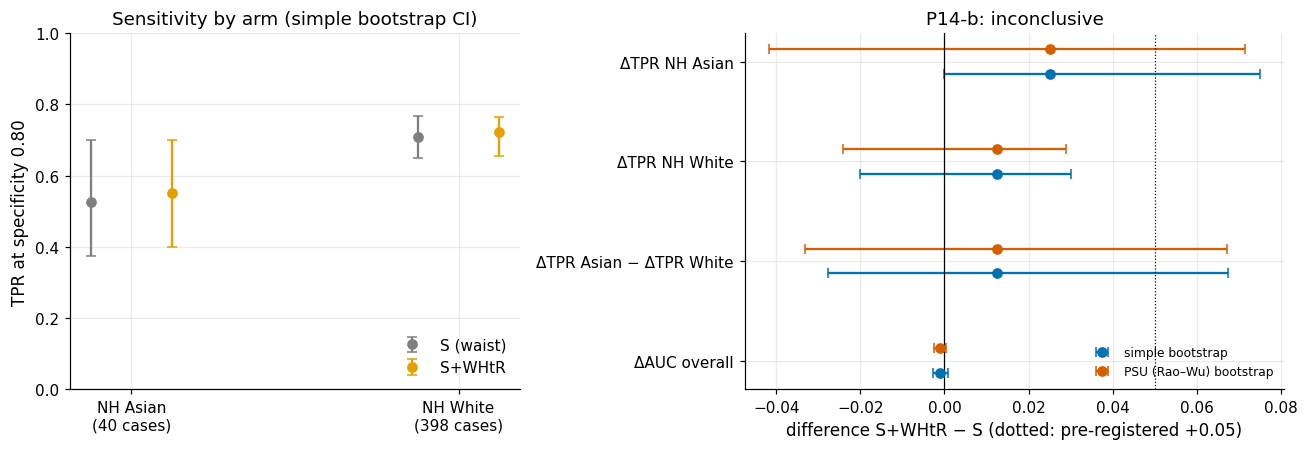

In [189]:
# Apply the locked verdict rules for P14-b, P14 and H4b and draw the WHtR figure.
# Writes results/S8/whtr_p14b.csv; saves figure S8_whtr_asian_white.
# P14-b: the NH Asian TPR gain is judged against the +0.05 SESOI (GAP).
v_p14b = ek.verdict(r_dA["lo"], r_dA["hi"], GAP, "+", r_dA["est"])
v_p14b = "refuted" if (v_p14b == "equivalent" or r_dA["hi"] < GAP) else v_p14b     # locked falsifier
# White control: the White change should be smaller in size than the Asian change.
control_ok = abs(r_dW["est"]) < abs(r_dA["est"])
# P14 overall combines part (a), AUC unchanged, and part (b), the Asian gain.
v_p14 = ek.combine_verdicts([p14a["verdict"], v_p14b])
# H4b at model level: supported if the CI lies above 0 and the estimate reaches the AUC SESOI;
# refuted if the CI lies wholly below 0.
v_h4b_model = ("supported" if (r_h4["lo"] > 0 and r_h4["est"] >= AUC_SESOI) else
               "refuted" if r_h4["hi"] < 0 else "inconclusive")
# H4b primary verdict is the single-feature test of §5 (stored); the model-level result is secondary.
s5_h4b = R.load_section("S5")["hypotheses"]["H4b"]["verdict"]
# 'mixed' only when both verdicts are decisive and disagree; otherwise the §5 verdict stands.
v_h4b = "mixed" if (s5_h4b in ("supported", "refuted") and v_h4b_model in ("supported", "refuted") and v_h4b_model != s5_h4b) else s5_h4b
print(f"P14-b: ΔTPR NH Asian {r_dA['est']:+.3f} ({r_dA['lo']:+.3f}, {r_dA['hi']:+.3f}; {r_dA['interval']} interval) -> {v_p14b}; "
      f"White control |Δ| smaller: {control_ok}")
print(f"P14 overall (a: {p14a['verdict']}, b: {v_p14b}) -> {v_p14}")
print(f"H4b model level: {r_h4['est']:+.3f} ({r_h4['lo']:+.3f}, {r_h4['hi']:+.3f}) -> {v_h4b_model}; S5 single-feature verdict "
      f"{s5_h4b} -> H4b {v_h4b}")
WH.to_csv(OUT / "whtr_p14b.csv", index=False)
S8["whtr"] = dict(table=WH.round(5).to_dict("records"), p14b_verdict=v_p14b, p14_verdict=v_p14, white_control_smaller=control_ok,
                  p14a_from_S7={k: p14a[k] for k in ("est", "lo", "hi", "verdict")}, h4b_model_verdict=v_h4b_model,
                  h4b_s5_verdict=s5_h4b, h4b_verdict=v_h4b, escreen_dtpr_asian=list(dA_s[:3]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
# Left panel: TPR of NH Asian and NH White under S (waist) and S+WHtR, simple-bootstrap CI.
ax = axes[0]
for j, (nm, a, b) in enumerate([("NH Asian", r_tA, r_tA2), ("NH White", r_tW, r_tW2)]):
    for k_, (r_, col, lab) in enumerate([(a, C.OKABE_ITO["grey"], "S (waist)"), (b, C.OKABE_ITO["orange"], "S+WHtR")]):
        x = j + (k_ - 0.5) * 0.25
        ax.errorbar(x, r_["est"], yerr=[[r_["est"] - r_["simple_lo"]], [r_["simple_hi"] - r_["est"]]], fmt="o", color=col,
                    capsize=3, label=lab if j == 0 else None)
ax.set_xticks([0, 1]); ax.set_xticklabels([f"NH Asian\n({int(res['simple'][0]['n_pos'][0, 0, iA])} cases)",
                                            f"NH White\n({int(res['simple'][0]['n_pos'][0, 0, iW])} cases)"])
ax.set_ylabel("TPR at specificity 0.80"); ax.set_ylim(0, 1); ax.legend(loc="lower right")
ax.set_title("Sensitivity by arm (simple bootstrap CI)")
# Right panel: paired changes with both bootstrap CIs; dotted line = the +0.05 gain.
ax = axes[1]
qs = ["ΔTPR NH Asian", "ΔTPR NH White", "ΔTPR Asian − ΔTPR White", "ΔAUC overall"]
for i, q in enumerate(qs):
    r_ = WH.set_index("quantity").loc[q]
    for k_, (wt, col) in enumerate([("simple", C.OKABE_ITO["blue"]), ("psu", C.OKABE_ITO["vermillion"])]):
        ax.errorbar(r_["est"], -i + (k_ - 0.5) * 0.25, xerr=[[r_["est"] - r_[f"{wt}_lo"]], [r_[f"{wt}_hi"] - r_["est"]]],
                    fmt="o", color=col, capsize=3, label=("simple bootstrap" if wt == "simple" else "PSU (Rao–Wu) bootstrap") if i == 0 else None)
ax.axvline(0, color="black", lw=0.8); ax.axvline(GAP, color="black", lw=0.8, ls=":")
ax.set_yticks([-i for i in range(len(qs))]); ax.set_yticklabels(qs)
ax.set_xlabel("difference S+WHtR − S (dotted: pre-registered +0.05)"); ax.legend(fontsize=8, loc="lower right")
ax.set_title(f"P14-b: {v_p14b}")
fig.tight_layout()
f83 = plots.savefig(fig, "S8_whtr_asian_white", caption="F8-3. WHtR measurement fix (arm S+WHtR vs S, E-ALL, Tier 1): TPR at "
                    "specificity 0.80 for NH Asian and NH White adults (left) and the paired changes with simple stratified and "
                    "PSU-cluster (Rao-Wu) bootstrap 95 % CIs (right); dotted line = pre-registered minimum gain of 0.05.")
plt.show()

**So what.** The fix moves the right group in the right direction, but by little: NH Asian sensitivity rises by +0.025
– one more case of 40 – against +0.013 for White adults, with overall AUC unchanged (P14-a). The PSU interval runs from
about −0.04 to +0.07, so P14-b is **inconclusive**. At model level the single-feature WHtR advantage (H4b) largely
disappears: the model already contains waist, height and BMI. WHtR is not adopted as a new preparation step.

## 8.10 Group-specific thresholds
**Why.** A group-specific threshold (Hardt et al. 2016) is **not** implemented (DR-S8-02: it needs race at prediction
time and equalises TPR by "levelling down"); its instability with about 40 Asian cases is quantified here.

In [190]:
# Counterfactual group threshold: the NH Asian cut-off that would match the NH White TPR (not adopted).
# Quantifies its false-positive cost and its instability by bootstrap.
# Returns (Asian threshold with weighted TPR equal to the White TPR, Asian FPR there, White TPR).
def asian_threshold(w=None):
    # w: optional bootstrap counts used as weights; default equal weights.
    w = np.ones(n) if w is None else w
    a_pos, a_neg = (grp["race"].eq("NH Asian").to_numpy() & (y == 1)), (grp["race"].eq("NH Asian").to_numpy() & (y == 0))
    w_pos = (grp["race"].eq("NH White").to_numpy() & (y == 1))
    # Positives caught by the shared threshold.
    hit = pS >= thr_check
    tpr_w = np.average(hit[w_pos], weights=w[w_pos])
    # Sort the Asian case scores and carry their weights along.
    s_ = np.sort(pS[a_pos]); ww = w[a_pos][np.argsort(pS[a_pos])]
    cum = np.cumsum(ww[::-1])[::-1] / ww.sum()          # share of Asian cases at or above each score
    # Highest sorted score whose upper tail still reaches the White TPR.
    k = np.flatnonzero(cum >= tpr_w - 1e-12).max()
    t_a = s_[k]
    fpr_a = np.average(pS[a_neg] >= t_a, weights=w[a_neg])
    return t_a, fpr_a, tpr_w
t_a, fpr_a, tpr_w = asian_threshold()
# Bootstrap counts stratified by race x label give percentile CIs for the Asian threshold and FPR.
Wst = F.stratified_counts((grp["race"].astype(str) + "|" + pd.Series(y).astype(str)).to_numpy(), C.N_BOOT, ek.derive_seed(C.SEED_MASTER, "S8", "gthr"))
bt = np.array([asian_threshold(Wst[b])[:2] for b in range(len(Wst))])
# Asian FPR at the shared threshold, from the E-ALL group table.
fpr_overall_a = float(GT1.set_index(["attribute", "group"]).loc[("race", "NH Asian"), "fpr"])
GTHR = dict(threshold_overall=thr_check, threshold_asian=t_a, threshold_asian_ci=list(np.percentile(bt[:, 0], [2.5, 97.5])),
            fpr_asian_at_own=fpr_a, fpr_asian_at_own_ci=list(np.percentile(bt[:, 1], [2.5, 97.5])), fpr_asian_at_shared=fpr_overall_a,
            tpr_white=tpr_w)
print(f"shared threshold {thr_check:.3f}; Asian threshold matching the White TPR ({tpr_w:.3f}): {t_a:.3f} "
      f"(95 % CI {GTHR['threshold_asian_ci'][0]:.3f}-{GTHR['threshold_asian_ci'][1]:.3f})")
print(f"Asian FPR: {fpr_overall_a:.3f} at the shared threshold -> {fpr_a:.3f} at the group threshold "
      f"(95 % CI {GTHR['fpr_asian_at_own_ci'][0]:.3f}-{GTHR['fpr_asian_at_own_ci'][1]:.3f})")
S8["group_threshold_counterfactual"] = GTHR

shared threshold 0.638; Asian threshold matching the White TPR (0.709): 0.545 (95 % CI 0.410-0.618)
Asian FPR: 0.127 at the shared threshold -> 0.175 at the group threshold (95 % CI 0.108-0.274)


## 8.11 Fairness–performance trade-off
**Why.** A mitigation is worth adopting only if it narrows its target gap without costing discrimination: ΔAUC vs the
change in the target group's |TPR gap|, with a "no practical change" box of |ΔAUC| < 0.01 and |Δ gap| < 0.05.

arm,target,d_auc,d_auc_lo,d_auc_hi,d_abs_eod,d_abs_eod_lo,d_abs_eod_hi,in_no_change_box
S+RW(race),NH Asian,-0.0002,-0.0018,0.0014,0.0176,-0.0525,0.0926,False
S+RW(insurance),uninsured,0.0001,-0.0005,0.0007,-0.0392,-0.0574,0.0264,False
S+RW(low_access),low access,-0.0002,-0.0017,0.0013,-0.0471,-0.1019,0.0486,False
S+WHtR,NH Asian,-0.0009,-0.0028,0.0009,-0.0124,-0.0673,0.0332,False


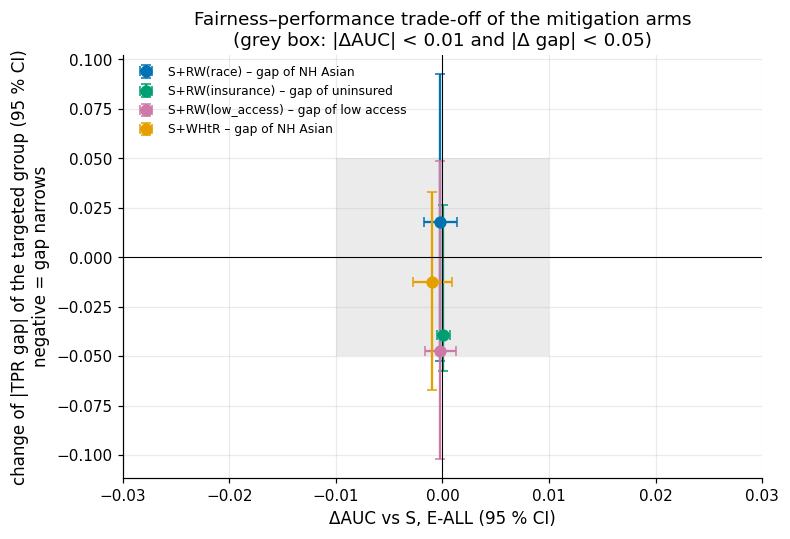

In [191]:
# Fairness-performance trade-off: ΔAUC against the change of the targeted group's |TPR gap| per arm.
# Writes results/S8/tradeoff.csv; saves figure S8_tradeoff.
# ΔAUC of WHtR versus S, computed with the same engine as for the reweighing arms.
wh_auc = compare_auc(OOF[("S+WHtR", 1, "lr")], OOF[("S", 1, "lr")], "E-ALL", tag="whtr")
TO = []
for attr, tgt in RW_TARGET.items():
    # Reweighing arms: ΔAUC on E-ALL and Δ|EOD| of the targeted group.
    a = RWT[(RWT["arm"] == f"S+RW({attr})") & (RWT["pop"] == "E-ALL")].iloc[0]
    e = RWE[(RWE["arm"] == f"S+RW({attr})") & (RWE["group"] == tgt)].iloc[0]
    TO.append({"arm": f"S+RW({attr})", "target": tgt, "d_auc": a["est"], "d_auc_lo": a["lo"], "d_auc_hi": a["hi"],
               "d_abs_eod": e["d_abs_eod"], "d_abs_eod_lo": e["d_abs_lo"], "d_abs_eod_hi": e["d_abs_hi"]})
# WHtR arm: the target group is NH Asian.
TO.append({"arm": "S+WHtR", "target": "NH Asian", "d_auc": wh_auc["est"], "d_auc_lo": wh_auc["lo"], "d_auc_hi": wh_auc["hi"],
           "d_abs_eod": r_eod["est"], "d_abs_eod_lo": r_eod["lo"], "d_abs_eod_hi": r_eod["hi"]})
TO = pd.DataFrame(TO)
# 'No practical change' box: both CIs entirely inside |ΔAUC| < SESOI and |Δ gap| < 0.05.
TO["in_no_change_box"] = (TO["d_auc_lo"] > -AUC_SESOI) & (TO["d_auc_hi"] < AUC_SESOI) & (TO["d_abs_eod_lo"] > -GAP) & (TO["d_abs_eod_hi"] < GAP)
show(TO, 4)
TO.to_csv(OUT / "tradeoff.csv", index=False)
S8["tradeoff"] = TO.round(5).to_dict("records")

fig, ax = plt.subplots(figsize=(7.5, 5))
# Grey rectangle = the no-practical-change box.
ax.add_patch(plt.Rectangle((-AUC_SESOI, -GAP), 2 * AUC_SESOI, 2 * GAP, color=C.OKABE_ITO["grey"], alpha=0.15, lw=0))
cols = [C.OKABE_ITO["blue"], C.OKABE_ITO["green"], C.OKABE_ITO["purple"], C.OKABE_ITO["orange"]]
for (_, r), col in zip(TO.iterrows(), cols):
    ax.errorbar(r["d_auc"], r["d_abs_eod"], xerr=[[r["d_auc"] - r["d_auc_lo"]], [r["d_auc_hi"] - r["d_auc"]]],
                yerr=[[r["d_abs_eod"] - r["d_abs_eod_lo"]], [r["d_abs_eod_hi"] - r["d_abs_eod"]]], fmt="o", color=col,
                capsize=3, ms=7, label=f"{r['arm']} – gap of {r['target']}")
ax.axhline(0, color="black", lw=0.7); ax.axvline(0, color="black", lw=0.7)
ax.set_xlabel("ΔAUC vs S, E-ALL (95 % CI)")
ax.set_ylabel("change of |TPR gap| of the targeted group (95 % CI)\nnegative = gap narrows")
ax.set_xlim(-0.03, 0.03)
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Fairness–performance trade-off of the mitigation arms\n(grey box: |ΔAUC| < 0.01 and |Δ gap| < 0.05)")
f85 = plots.savefig(fig, "S8_tradeoff", caption="F8-5. Fairness-performance plane for the mitigation arms (Tier 1): ΔAUC "
                    "against arm S on E-ALL (wider of corrected-t and paired-bootstrap CI) versus the change in the absolute "
                    "TPR gap of the targeted group at specificity 0.80 (paired stratified bootstrap); grey box = no practical change.")
plt.show()

**So what – screening audit and mitigation nulls (§8.4, §8.5, §8.10, §8.11).** On E-SCREEN only the sex contrast is
reportable: undiagnosed women are found less often than men (EOD about −0.17, CI includes 0, permutation p about
0.09); race gaps rest on 11–24 positives ("not measurable", not "fair"). Tier 2 lipids move every gap by less than its
CI. An Asian-specific threshold matching the White TPR would raise Asian false positives by about 40 % and is itself
unstable. All four mitigations cost no AUC, and none demonstrably helps (gap changes −0.05 to +0.02, intervals wider
than ±0.05): "cheap, harmless, not shown to help".

## 8.12 Within-group calibration
**Why.** Calibration within groups (a predicted 20 % meaning 20 % in every group) is a second fairness criterion that
cannot in general hold together with equal sensitivity when prevalences differ (Chouldechova 2017). Arm S is
class-weighted, so absolute calibration is checked on **S−B6a**, its AUC-equivalent sibling without class weights: O:E
(group-stratified bootstrap, so the number of cases varies), calibration-in-the-large (CITL) and slope.

S-B6a overall: O:E 1.017, CITL +0.027, slope 0.979


attribute,group,n,n_pos,mean_pred,observed,oe,oe_lo,oe_hi,citl,slope,oe_S_relative,oe_ci_excludes_1
race,NH White,2727,398,0.167,0.146,0.876,0.809,0.950,-0.203,1.043,0.857,True
race,NH Black,540,131,0.186,0.243,1.304,1.125,1.476,0.455,0.788,1.308,True
race,NH Asian,252,40,0.117,0.159,1.353,1.030,1.738,0.450,1.019,1.198,True
race,Mexican American,309,69,0.160,0.223,1.393,1.156,1.672,0.566,0.994,1.376,True
race,Other Hispanic,465,82,0.166,0.176,1.064,0.890,1.221,0.101,1.107,1.054,False
race,Other/Multi,291,57,0.181,0.196,1.081,0.862,1.303,0.133,0.909,1.114,False
insurance,insured,4186,725,0.170,0.173,1.018,0.958,1.076,0.029,0.983,1.007,False
insurance,uninsured,390,51,0.131,0.131,0.999,0.768,1.229,-0.001,0.902,0.907,False
low_access,usual access,3838,701,0.178,0.183,1.026,0.967,1.086,0.042,0.966,1.025,False
low_access,low access,742,75,0.108,0.101,0.935,0.750,1.113,-0.098,1.015,0.810,False


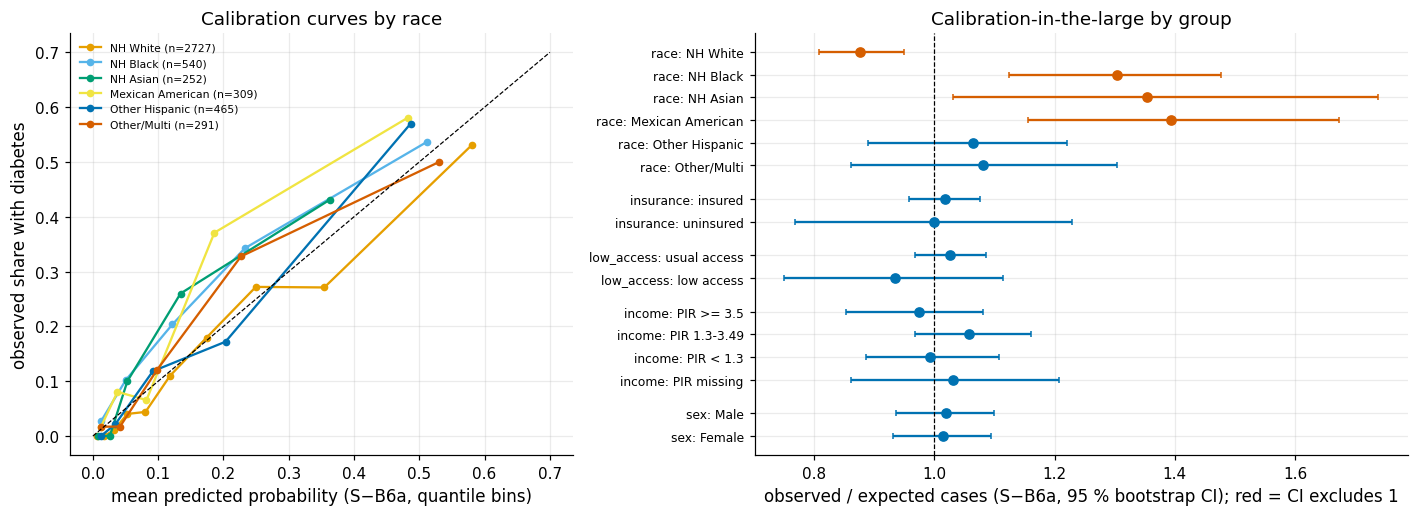

In [192]:
# Within-group calibration of S-B6a (arm S without class weights): O:E, calibration-in-the-large, slope.
# Writes results/S8/group_calibration.csv; saves figure S8_group_calibration.
# S-B6a keeps the true prevalence scale, so absolute calibration is interpretable (arm S is class-weighted).
pC = PM[("S-B6a", 1, "lr")]
cal_rows = []
for attr in F.ATTRIBUTES:
    # Group-stratified bootstrap (weights='group'): the number of observed cases varies, as O:E requires.
    point, boot, codes, mm = audit(attr, "E-ALL", 1, ("S-B6a", "S"), weights="group")
    lvls = F.LEVELS[attr]
    # Overall O:E of arm S, used to express each group's O:E of S relative to it.
    oe_all_S = y.sum() / pS.sum()
    for g_i, g_nm in enumerate(lvls):
        m = grp[attr].eq(g_nm).to_numpy()
        # Calibration slope, intercept and calibration-in-the-large (CITL) within the group.
        slope, icpt, citl = ek._calibration(y[m], pC[m])
        e, lo, hi, _ = F.summarise(point["oe"][0, 0, g_i], boot["oe"][:, 0, g_i])
        cal_rows.append({"attribute": attr, "group": g_nm, "n": int(m.sum()), "n_pos": int(y[m].sum()),
                         "mean_pred": pC[m].mean(), "observed": y[m].mean(), "oe": e, "oe_lo": lo, "oe_hi": hi,
                         "citl": citl, "slope": slope, "oe_S_relative": point["oe"][0, 1, g_i] / oe_all_S})
CAL = pd.DataFrame(cal_rows)
# A CI that excludes 1 marks a group that is mis-calibrated in the large.
CAL["oe_ci_excludes_1"] = (CAL["oe_lo"] > 1) | (CAL["oe_hi"] < 1)
slope_all, _, citl_all = ek._calibration(y, pC)
print(f"S-B6a overall: O:E {y.sum() / pC.sum():.3f}, CITL {citl_all:+.3f}, slope {slope_all:.3f}")
show(CAL, 3)
CAL.to_csv(OUT / "group_calibration.csv", index=False)
S8["calibration"] = dict(table=CAL.round(5).to_dict("records"), overall=dict(oe=float(y.sum() / pC.sum()), citl=citl_all, slope=slope_all),
                         groups_oe_ci_excl_1=CAL.loc[CAL["oe_ci_excludes_1"], ["attribute", "group", "oe"]].round(3).to_dict("records"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
for g_nm, col in zip(F.LEVELS["race"], plots.PALETTE):
    m = grp["race"].eq(g_nm).to_numpy()
    # Fewer quantile bins for small groups (< 600 rows) keep the bins populated.
    nb = 5 if m.sum() < 600 else 10
    # duplicates='drop' merges identical bin edges.
    q = pd.qcut(pC[m], nb, labels=False, duplicates="drop")
    d_ = pd.DataFrame({"p": pC[m], "y": y[m], "q": q}).groupby("q").mean()
    ax.plot(d_["p"], d_["y"], "o-", color=col, label=f"{g_nm} (n={int(m.sum())})", ms=4)
# Diagonal = perfect calibration.
ax.plot([0, 0.7], [0, 0.7], color="black", lw=0.8, ls="--")
ax.set_xlabel("mean predicted probability (S−B6a, quantile bins)"); ax.set_ylabel("observed share with diabetes")
ax.set_title("Calibration curves by race"); ax.legend(fontsize=7)
ax = axes[1]
k = 0; yt, yl = [], []
for attr in F.ATTRIBUTES:
    for _, r in CAL[CAL["attribute"] == attr].iterrows():
        ax.errorbar(r["oe"], -k, xerr=[[r["oe"] - r["oe_lo"]], [r["oe_hi"] - r["oe"]]], fmt="o",
                    color=C.OKABE_ITO["vermillion"] if r["oe_ci_excludes_1"] else C.OKABE_ITO["blue"], capsize=2)
        yt.append(-k); yl.append(f"{attr}: {r['group']}"); k += 1
    k += 0.5
ax.axvline(1, color="black", lw=0.8, ls="--")
ax.set_yticks(yt); ax.set_yticklabels(yl, fontsize=8)
ax.set_xlabel("observed / expected cases (S−B6a, 95 % bootstrap CI); red = CI excludes 1")
ax.set_title("Calibration-in-the-large by group")
fig.tight_layout()
f84 = plots.savefig(fig, "S8_group_calibration", caption="F8-4. Within-group calibration of arm S-B6a (arm S without class "
                    "weights, AUC-equivalent): calibration curves by race (quantile bins) and observed/expected ratio by audit "
                    "group with stratified bootstrap 95 % CI (E-ALL, Tier 1, training part OOF).")
plt.show()

**So what.** S−B6a is well calibrated overall (O:E about 1.02, slope about 0.98) and across insurance, access, income and
sex, but **not across race**: it under-predicts for NH Black, NH Asian (O:E about 1.35) and Mexican American adults
(CIs excluding 1) and over-predicts for NH White adults. A race-blind score averages over groups whose prevalence
differs at the same feature values – the second face of the Asian TPR gap. Correcting it would need race as an input
or race-specific recalibration, excluded for the reasons of §8.10; it is a limitation for any individual use.

## 8.13 Verdicts
**Why.** Each locked hypothesis tested here gets one verdict from its locked rule (`evalkit.verdict` with the SESOI
of `config.SESOI`, sub-claims combined by `evalkit.combine_verdicts`). H3 is a genuine pre-registration; P14-b and H4b
were written after a descriptive look. The gap flags of §8.3–§8.4 are audit findings, listed separately.

In [193]:
# Collect the locked verdicts (H3, P14, H4b) in one scoreboard; list substantive audit gaps separately.
# Writes results/S8/scoreboard.csv.
# Substantive, reportable gaps are audit flags, not hypotheses.
sub_eall = ET1[ET1["substantive"] & ET1["verdict_status"].eq("reportable")]
sub_escr = ETs[ETs["substantive"] & ETs["verdict_status"].eq("reportable")]
# One row per locked sub-claim; the evidence strings are built from computed values, not typed.
SB8 = pd.DataFrame([
    dict(hyp_id="H3", prior_exposure="none", sub="E1 L_self misses Undiagnosed most", verdict=elem_v["E1"],
         evidence="; ".join(f"{r.contrast} {r.est:+.3f} ({r.lo:+.3f}, {r.hi:+.3f})" for r in H3E[H3E.element == "E1"].itertuples())),
    dict(hyp_id="H3", prior_exposure="none", sub="E2 L_A1c misses D_controlled most", verdict=elem_v["E2"],
         evidence="; ".join(f"{r.contrast} {r.est:+.3f} ({r.lo:+.3f}, {r.hi:+.3f})" for r in H3E[H3E.element == "E2"].itertuples())),
    dict(hyp_id="H3", prior_exposure="none", sub="E3 L_comb smallest worst-cell gap", verdict=elem_v["E3"],
         evidence="; ".join(f"{r.contrast} {r.est:+.3f} ({r.lo:+.3f}, {r.hi:+.3f})" for r in H3E[H3E.element == "E3"].itertuples())),
    dict(hyp_id="H3", prior_exposure="none", sub="overall", verdict=h3_v, evidence="combine_verdicts(E1-E3); falsifier: any contrast reversed with CI excluding 0"),
    dict(hyp_id="P14", prior_exposure="descriptive_seen", sub="(a) |ΔAUC| < 0.01 (from S7)", verdict=p14a["verdict"],
         evidence=f"ΔAUC {p14a['est']:+.4f} ({p14a['lo']:+.4f}, {p14a['hi']:+.4f}), corrected t"),
    dict(hyp_id="P14", prior_exposure="descriptive_seen", sub="(b) NH Asian ΔTPR ≥ +0.05", verdict=v_p14b,
         evidence=f"ΔTPR {r_dA['est']:+.3f} ({r_dA['lo']:+.3f}, {r_dA['hi']:+.3f}), {r_dA['interval']} interval; White ΔTPR {r_dW['est']:+.3f}"),
    dict(hyp_id="P14", prior_exposure="descriptive_seen", sub="overall", verdict=v_p14, evidence="combine_verdicts(a, b)"),
    dict(hyp_id="H4b", prior_exposure="descriptive_seen", sub="single feature (S5)", verdict=s5_h4b,
         evidence=R.load_section("S5")["hypotheses"]["H4b"]["estimate"]),
    dict(hyp_id="H4b", prior_exposure="descriptive_seen", sub="model level (S8, secondary)", verdict=v_h4b_model,
         evidence=f"ΔAUC_Asian − ΔAUC_White {r_h4['est']:+.4f} ({r_h4['lo']:+.4f}, {r_h4['hi']:+.4f})"),
    dict(hyp_id="H4b", prior_exposure="descriptive_seen", sub="overall", verdict=v_h4b,
         evidence="S5 primary; a decisive contradicting S8 model-level verdict would make it mixed"),
])
# Guard: every verdict belongs to the allowed vocabulary C.VERDICTS.
assert set(SB8["verdict"]) <= set(C.VERDICTS)
show(SB8)
print("\naudit flags (not hypotheses): substantive reportable gaps")
for nm_, d_ in (("E-ALL", sub_eall), ("E-SCREEN", sub_escr)):
    print(f"  {nm_}: " + ("; ".join(f"{r.attribute} {r.group} {r.eod:+.3f} [{r.eod_lo:+.3f}, {r.eod_hi:+.3f}]" for r in d_.itertuples()) or "none"))
SB8.to_csv(OUT / "scoreboard.csv", index=False)
S8["scoreboard"] = {h: g.set_index("sub")["verdict"].to_dict() for h, g in SB8.groupby("hyp_id")}
S8["verdicts"] = {"H3": h3_v, "P14": v_p14, "P14b": v_p14b, "H4b": v_h4b, "H4b_model_level": v_h4b_model}
S8["substantive_gaps"] = {"E-ALL": sub_eall[["attribute", "group", "eod", "eod_lo", "eod_hi"]].round(4).to_dict("records"),
                          "E-SCREEN": sub_escr[["attribute", "group", "eod", "eod_lo", "eod_hi"]].round(4).to_dict("records")}

hyp_id,prior_exposure,sub,verdict,evidence
H3,none,E1 L_self misses Undiagnosed most,inconclusive,"Undiagnosed: L_self - L_A1c -0.055 (-0.126, +0.024); Undiagnosed: L_self - L_comb -0.016 (-0.079, +0.024)"
H3,none,E2 L_A1c misses D_controlled most,inconclusive,"D_controlled: L_A1c - L_self -0.046 (-0.097, +0.005); D_controlled: L_A1c - L_comb -0.041 (-0.092, +0.010)"
H3,none,E3 L_comb smallest worst-cell gap,inconclusive,"worst-cell gap: L_comb - L_self -0.016 (-0.079, +0.028); worst-cell gap: L_comb - L_A1c -0.007 (-0.087, +0.059)"
H3,none,overall,inconclusive,combine_verdicts(E1-E3); falsifier: any contrast reversed with CI excluding 0
P14,descriptive_seen,(a) |ΔAUC| < 0.01 (from S7),supported,"ΔAUC -0.0009 (-0.0028, +0.0009), corrected t"
P14,descriptive_seen,(b) NH Asian ΔTPR ≥ +0.05,inconclusive,"ΔTPR +0.025 (-0.042, +0.071), psu interval; White ΔTPR +0.013"
P14,descriptive_seen,overall,inconclusive,"combine_verdicts(a, b)"
H4b,descriptive_seen,single feature (S5),supported,"WHtR - BMI gain Asian +0.137 (0.093, 0.181) vs White +0.049 (0.039, 0.058); difference CI (person +0.044, +0.135; PSU +0.035, +0.116)"
H4b,descriptive_seen,"model level (S8, secondary)",inconclusive,"ΔAUC_Asian − ΔAUC_White +0.0051 (-0.0037, +0.0134)"
H4b,descriptive_seen,overall,supported,S5 primary; a decisive contradicting S8 model-level verdict would make it mixed



audit flags (not hypotheses): substantive reportable gaps
  E-ALL: race NH Asian -0.184 [-0.343, -0.014]; income PIR < 1.3 +0.186 [+0.085, +0.270]
  E-SCREEN: none


**So what.** No fairness experiment produces a decisive verdict, and each "inconclusive" is specific: **H3** – all
three orderings point the right way, but the label shifts recall by at most about 0.06 against CIs about ±0.07 wide;
**P14** – WHtR is harmless (a) and moves Asian sensitivity the predicted way, but its +0.025 neither confirms nor
excludes +0.05 (b); **H4b** – the single-feature WHtR advantage (§5, supported) does not transfer to the model. The
decisive results are audit findings: a substantive NH Asian sensitivity gap beyond the permutation null
(exploratory), SES-driven income gaps, an access imprint under self-report, and race-level miscalibration of a
race-blind model. A FAST re-run can move the borderline audit items across their thresholds.

## 8.14 Outputs
**Why.** Every decision goes into the §8 decision register with evidence computed above (no value typed by hand), and
every number into `results/metrics_S8.json` and `results/S8/`, from which §10 and the video read.

In [194]:
# Build the §8 decision register: every evidence_value is an f-string over variables computed above.
# Writes governance/register/S8.csv.
# Register column order, shared by the other sections' registers.
REGISTER_COLS = ["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision",
                 "alternatives_rejected", "hyp_id", "status", "check_verdict", "check_note", "loop_ref", "change_request", "commit"]
TODAY = "2026-10-11"
# Shorthands used by the evidence strings below.
eodA = ET1.set_index(["attribute", "group"]).loc[("race", "NH Asian")]
permr = PERM1.set_index("attribute")
rw_rng = {a: f"{w.min():.2f}-{w.max():.2f}" for a, w in RW_W.items()}
rw_auc = RWT[RWT["pop"] == "E-ALL"].set_index("arm")
cal_race = CAL[(CAL["attribute"] == "race") & CAL["oe_ci_excludes_1"]]
acc_d = ACCD.set_index(["feature", "contrast"])
sex_s = ETs.set_index("attribute").loc["sex"]
# Each dict is one decision-register row.
reg = [
    dict(dr_id="DR-S8-01", type="audit_design",
         finding="Group cells are small (no oversampling in 2021-23); E-SCREEN has 127 positives in the training part",
         evidence_ref="results/S8/group_sizes.csv", evidence_value=f"suppressed groups E-ALL {n_supp['eall']}/16, E-SCREEN {n_supp['escreen']}/16; NH Asian 40 positives (E-ALL)",
         decision="Audit race (NH Asian separate, exploratory), insurance, low access, income band, sex on training-part OOF; NCHS rule n<30 or positives<30 -> show, no gap verdict",
         alternatives_rejected="Pooling Asian with Other/Multi (hides the BMI measurement issue); verdicts on suppressed cells",
         status="decided", check_verdict="PASS", check_note="counts recomputed from the cohort and the stored split"),
    dict(dr_id="DR-S8-02", type="threshold",
         finding="One operating point is needed to compare groups; group thresholds need race at prediction time",
         evidence_ref="§8.2 and §8.10; results/metrics_S8.json group_threshold_counterfactual",
         evidence_value=f"shared threshold {thr_check:.3f} (spec 0.80, E-ALL); Asian threshold for White TPR {t_a:.3f} (CI {GTHR['threshold_asian_ci'][0]:.3f}-{GTHR['threshold_asian_ci'][1]:.3f}), Asian FPR {fpr_overall_a:.3f}->{fpr_a:.3f}",
         decision="Single threshold at overall specificity 0.80, re-estimated in each bootstrap replicate; no group-specific thresholds (race would be needed at prediction time)",
         alternatives_rejected="ThresholdOptimizer / equalised-odds post-processing (uses race at prediction, levelling down, unstable with ~40 cases)",
         status="decided", check_verdict="PASS", check_note="engine threshold equals evalkit.recall_at_specificity (asserted)"),
    dict(dr_id="DR-S8-03", type="finding",
         finding="Model reproduces label and measurement bias: NH Asian and income gaps exceed the permutation null on E-ALL",
         evidence_ref="results/S8/eod_eall_t1.csv; results/S8/permutation.csv; results/S8/gap_decomposition.csv; figures/S8_group_tpr.png",
         evidence_value=f"NH Asian EOD {eodA['eod']:+.3f} ({eodA['eod_lo']:+.3f}, {eodA['eod_hi']:+.3f}), race max|EOD| p {permr.loc['race', 'p_value']:.3f}; income p {permr.loc['income', 'p_value']:.3f}; TPR diagnosed {tpr_dx_all:.2f} vs undiagnosed {tpr_ud_all:.2f}",
         decision="Report gaps with CIs and permutation baseline; attribute them to routes (diagnosis/care traces, BMI, SES inputs); ecological-fallacy caveat; no claim about individual risk",
         alternatives_rejected="Reporting raw group differences without a null; interpreting group TPR as individual risk",
         hyp_id="", status="decided", check_verdict="PASS", check_note="NH Asian exploratory (40 positives)"),
    dict(dr_id="DR-S8-04", type="finding",
         finding="Screening-population (E-SCREEN) fairness cannot be audited by race, insurance or access at this sample size",
         evidence_ref="results/S8/eod_escreen_t1.csv",
         evidence_value=f"reportable E-SCREEN contrasts {len(rep_s)}/{len(ETs)}; female - male EOD {sex_s['eod']:+.3f} ({sex_s['eod_lo']:+.3f}, {sex_s['eod_hi']:+.3f}), permutation p {PERMs.set_index('attribute').loc['sex', 'p_value']:.3f}",
         decision="E-SCREEN group gaps shown as numbers only; the only reportable contrast (sex) reported with CI and permutation p; limitation for S10",
         alternatives_rejected="Pooling E-ALL and E-SCREEN (mixes the use cases)", status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-05", type="hypothesis_test",
         finding="3x3 label matrix: predicted ordering points the right way but differences are small; Undiagnosed is hardest for every label",
         evidence_ref="results/S8/label_matrix_cells.csv; results/S8/h3_contrasts.csv; figures/S8_label_matrix.png",
         evidence_value=f"recall Undiagnosed L_self {LM['recall'].loc['L_self', 'Undiagnosed']:.3f}, L_A1c {LM['recall'].loc['L_A1c', 'Undiagnosed']:.3f}, L_comb {LM['recall'].loc['L_comb', 'Undiagnosed']:.3f}; D_controlled L_A1c {LM['recall'].loc['L_A1c', 'D_controlled']:.3f}; elements {elem_v}",
         decision=f"H3 verdict {h3_v}; L_comb stays the frozen target", alternatives_rejected="Switching the training label after seeing the matrix",
         hyp_id="H3", status="decided", check_verdict="PASS", check_note="L_comb x Undiagnosed cell equals E-SCREEN recall of S (asserted)"),
    dict(dr_id="DR-S8-06", type="audit",
         finding="Trained on self-report, the model learns that poor access means lower risk; the label contrast points the same way",
         evidence_ref="results/S8/access_audit_coefs.csv; results/S8/access_audit_diffs.csv",
         evidence_value=f"no usual place under L_self {ACC.set_index(['feature', 'label']).loc[('no_usual_place', 'L_self'), 'coef_per_sd']:+.3f} ({ACC.set_index(['feature', 'label']).loc[('no_usual_place', 'L_self'), 'lo']:+.3f}, {ACC.set_index(['feature', 'label']).loc[('no_usual_place', 'L_self'), 'hi']:+.3f}); uninsured L_self - L_comb {acc_d.loc[('uninsured', 'L_self - L_comb'), 'diff_per_sd']:+.3f} ({acc_d.loc[('uninsured', 'L_self - L_comb'), 'lo']:+.3f}, {acc_d.loc[('uninsured', 'L_self - L_comb'), 'hi']:+.3f}); no usual place {acc_d.loc[('no_usual_place', 'L_self - L_comb'), 'diff_per_sd']:+.3f} ({acc_d.loc[('no_usual_place', 'L_self - L_comb'), 'lo']:+.3f}, {acc_d.loc[('no_usual_place', 'L_self - L_comb'), 'hi']:+.3f})",
         decision="Access features remain audit-only (P03); evidence supports the union label over self-report",
         alternatives_rejected="Adding insurance/usual place as predictors (would encode access to diagnosis)", status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-07", type="mitigation",
         finding="Race reweighing changes neither AUC nor the Asian gap and widens the NH Black gap",
         evidence_ref="results/S8/reweighing_auc.csv; results/S8/reweighing_eod.csv",
         evidence_value=f"w range race {rw_rng['race']}; dAUC {rw_auc.loc['S+RW(race)', 'est']:+.4f} ({rw_auc.loc['S+RW(race)', 'lo']:+.4f}, {rw_auc.loc['S+RW(race)', 'hi']:+.4f})",
         decision="Not adopted; reported as a null mitigation. Partial reweighing: weights from unweighted counts multiplied by survey weights, so group and label are only partly independent in the fitted weighting; a correctly weighted version is checked in S9 (post-audit corrections) and the conclusion is unchanged",
         alternatives_rejected="Race as a model feature (S9 sensitivity only)",
         status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-08", type="mitigation",
         finding="Insurance and low-access reweighing: AUC unchanged, targeted gaps narrow slightly with CIs including 0",
         evidence_ref="results/S8/reweighing_auc.csv; results/S8/reweighing_eod.csv; results/S8/tradeoff.csv",
         evidence_value=f"w range insurance {rw_rng['insurance']}, low access {rw_rng['low_access']}; dAUC {rw_auc.loc['S+RW(insurance)', 'est']:+.4f} / {rw_auc.loc['S+RW(low_access)', 'est']:+.4f}",
         decision="Not adopted (no demonstrated benefit); extension item complete. Partial reweighing (unweighted-count weights x survey weights, independence only partly achieved); corrected version checked in S9 post-audit corrections, conclusion unchanged",
         alternatives_rejected="Adopting on point estimates",
         status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-09", type="hypothesis_test",
         finding="WHtR raises NH Asian TPR in point estimate only; PSU-cluster interval crosses 0",
         evidence_ref="results/S8/whtr_p14b.csv; figures/S8_whtr_asian_white.png",
         evidence_value=f"Asian dTPR {r_dA['est']:+.3f} (simple {r_dA['simple_lo']:+.3f}, {r_dA['simple_hi']:+.3f}; PSU {r_dA['psu_lo']:+.3f}, {r_dA['psu_hi']:+.3f}); White {r_dW['est']:+.3f}; dAUC {r_auc['est']:+.4f}",
         decision=f"P14-b {v_p14b}, P14 {v_p14}; WHtR not adopted as a new preparation step; no return to the §6 design",
         alternatives_rejected="Adopting WHtR on the point estimate (post hoc)", hyp_id="P14", status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-10", type="hypothesis_test",
         finding="The single-feature WHtR advantage for Asian adults does not transfer to the multivariable model",
         evidence_ref="results/S8/whtr_p14b.csv", evidence_value=f"model-level dAUC Asian - White {r_h4['est']:+.4f} ({r_h4['lo']:+.4f}, {r_h4['hi']:+.4f})",
         decision=f"H4b stays {v_h4b} on the S5 single-feature test; S8 model-level result {v_h4b_model} reported as secondary",
         hyp_id="H4b", status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-11", type="finding",
         finding="Race-blind model is calibrated overall but not within race",
         evidence_ref="results/S8/group_calibration.csv; figures/S8_group_calibration.png",
         evidence_value=f"S-B6a O:E overall {y.sum() / pC.sum():.2f}; groups with CI excluding 1: {cal_race[['group', 'oe']].round(2).to_dict('records')}",
         decision="Reported as a limitation; no race-specific recalibration (same reasons as DR-S8-02)",
         alternatives_rejected="Race-specific recalibration", status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-12", type="tradeoff",
         finding="No mitigation arm narrows its targeted gap demonstrably; none costs AUC",
         evidence_ref="results/S8/tradeoff.csv; figures/S8_tradeoff.png",
         evidence_value="; ".join(f"{r.arm}: dAUC {r.d_auc:+.4f} [{r.d_auc_lo:+.4f}, {r.d_auc_hi:+.4f}], d|gap| {r.d_abs_eod:+.3f} [{r.d_abs_eod_lo:+.3f}, {r.d_abs_eod_hi:+.3f}]" for r in TO.itertuples()),
         decision="No mitigation adopted; reported as 'cheap, harmless, not shown to help'", alternatives_rejected="Adopting the arm with the best point estimate",
         status="decided", check_verdict="PASS"),
]
# Fill missing columns with '' and enforce the schema's column order.
REG8 = pd.DataFrame(reg)
REG8["stage"], REG8["date"] = "S8", TODAY
for c in REGISTER_COLS:
    if c not in REG8:
        REG8[c] = ""
REG8 = REG8[REGISTER_COLS].fillna("")
REG8.to_csv(C.GOVERNANCE_DIR / "register" / "S8.csv", index=False, lineterminator="\n")
show(REG8[["dr_id", "type", "decision"]])

dr_id,type,decision
DR-S8-01,audit_design,"Audit race (NH Asian separate, exploratory), insurance, low access, income band, sex on training-part OOF; NCHS rule n<30 or positives<30 -> show, no gap verdict"
DR-S8-02,threshold,"Single threshold at overall specificity 0.80, re-estimated in each bootstrap replicate; no group-specific thresholds (race would be needed at prediction time)"
DR-S8-03,finding,"Report gaps with CIs and permutation baseline; attribute them to routes (diagnosis/care traces, BMI, SES inputs); ecological-fallacy caveat; no claim about individual risk"
DR-S8-04,finding,E-SCREEN group gaps shown as numbers only; the only reportable contrast (sex) reported with CI and permutation p; limitation for S10
DR-S8-05,hypothesis_test,H3 verdict inconclusive; L_comb stays the frozen target
DR-S8-06,audit,Access features remain audit-only (P03); evidence supports the union label over self-report
DR-S8-07,mitigation,"Not adopted; reported as a null mitigation. Partial reweighing: weights from unweighted counts multiplied by survey weights, so group and label are only partly independent in the fitted weighting; a correctly weighted version is checked in S9 (post-audit corrections) and the conclusion is unchanged"
DR-S8-08,mitigation,"Not adopted (no demonstrated benefit); extension item complete. Partial reweighing (unweighted-count weights x survey weights, independence only partly achieved); corrected version checked in S9 post-audit corrections, conclusion unchanged"
DR-S8-09,hypothesis_test,"P14-b inconclusive, P14 inconclusive; WHtR not adopted as a new preparation step; no return to the §6 design"
DR-S8-10,hypothesis_test,H4b stays supported on the S5 single-feature test; S8 model-level result inconclusive reported as secondary


In [195]:
# Export all tables, figure names, runtime and verdicts.
# Writes results/S8/*.csv and results/metrics_S8.json.
for nm, df_ in {"group_metrics_eall_t1": GT1, "eod_eall_t1": ET1, "group_metrics_escreen_t1": GTs, "eod_escreen_t1": ETs,
                "group_metrics_eall_t2": GT2, "eod_eall_t2": ET2,
                "permutation": pd.concat([PERM1, PERMs, PERM2], ignore_index=True)}.items():
    df_.to_csv(OUT / f"{nm}.csv", index=False)
S8["figures"] = [f81, f81b, f82, f83, f84, f85]
S8["runtime_seconds"] = time.time() - T_START
R.save_section("S8", S8)
print(f"saved results/metrics_S8.json, {len(list(OUT.glob('*.csv')))} tables in results/S8, governance/register/S8.csv "
      f"({len(REG8)} rows); runtime {S8['runtime_seconds']:.0f} s ({C.NB_MODE})")
print(json.dumps(S8["verdicts"]))

saved results/metrics_S8.json, 19 tables in results/S8, governance/register/S8.csv (12 rows); runtime 93 s (FINAL)
{"H3": "inconclusive", "P14": "inconclusive", "P14b": "inconclusive", "H4b": "supported", "H4b_model_level": "inconclusive"}


# §9 Robustness and Credibility

**Section lead:** B

§7 reached its verdicts on one set of folds, one label, one imputation rule and one C. This section asks how much of
that is **procedure** and how much is **data**: negative and positive controls (§9.2), seed, specification, cluster
and missing-data stability of the headline contrast (§9.3–§9.7), external validity against NCHS Data Brief 516
(§9.8), a leak hunt for disguised labels among the admissible features (§9.9), the internal hold-out check (§9.11,
evaluated once after the `exp-freeze` tag) and the post-audit corrections of an external review (§9.12, post-lock).
Everything before §9.11 uses the training part only (4,584 rows). The headline contrast is
ΔAUC(S − M1), H2b(a) (locked rule: *supported* = equivalence within ±0.01; §7 verdict *inconclusive*).

In [196]:
new_section()

In [197]:
import json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek, survey as sv, robustness as RB
from src.robustness import Spec

from IPython.display import display
pd.set_option("display.width", 150, "display.max_columns", 30, "display.max_colwidth", 60)


def show(df, digits=3):
    """Display a table as HTML (long text wraps; keeps the text output narrow)."""
    display(df.style.hide(axis="index").format(precision=digits, na_rep="")
            .set_properties(**{"text-align": "left", "white-space": "normal"}))

warnings.filterwarnings("ignore", category=UserWarning)
os.environ.setdefault("PYTHONWARNINGS", "ignore")
OUT = C.RESULTS_DIR / "S9"
OUT.mkdir(parents=True, exist_ok=True)
N_JOBS = min(16, max(1, (os.cpu_count() or 2) - 2))
T_START = time.time()
# FAST mode (the re-run setting, <= ~5 min for the whole notebook) shrinks three extension-level loops; FINAL is unchanged:
# coefficient bootstrap of the noise check 500 -> 30 (config FAST value 100), robustness seeds 10 -> 5, specification
# curve 60 -> 30 specifications (C in {0.1, 10} instead of four values; C is the factor that matters least, see 5).
B_COEF9 = C.N_BOOT_COEF if C.IS_FINAL else 30
N_SEEDS = C.N_ROBUSTNESS_SEEDS if C.IS_FINAL else 5
C_CURVE = RB.C_GRID if C.IS_FINAL else (0.1, 10.0)
S9 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_perm": C.N_PERM,
      "n_boot_coef": B_COEF9, "n_seeds": N_SEEDS, "n_curve": 15 * len(C_CURVE)}
OI = C.OKABE_ITO
S7m = R.load_section("S7")
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, permutations = {C.N_PERM}, coefficient B = {B_COEF9}, "
      f"{N_SEEDS} robustness seeds, {S9['n_curve']}-specification curve, {N_JOBS} workers")

mode FINAL: 5x5 CV, B = 1000, permutations = 100, coefficient B = 500, 10 robustness seeds, 60-specification curve, 16 workers


## 9.1 Reference comparison
**Why.** Every robustness check varies one thing against a fixed reference, so the reference must be
exactly the §7 run: same training part, same stored folds, frozen C0, same comparison engine
(`robustness.compare` mirrors the §7 engine: Nadeau–Bengio corrected t and paired bootstrap, wider interval on
E-ALL; bootstrap only on E-SCREEN).

In [198]:
# Load the context of §7 (training part only, stored folds, frozen C0) and reproduce the headline contrast S -
# M1 once as the reference for every check below. Reads results/splits and the stored results; asserts that
# folds, hold-out hash and (FINAL mode) the stored estimate are unchanged.
ctx = RB.load_context()
RUNS = {}                                              # cache: (Spec, folds hash) -> OOF frame
# Only the hash of the hold-out SEQNs is read here; the hold-out rows themselves stay unread until §9.11.
hold = json.loads((C.RESULTS_DIR / "splits" / "holdout.json").read_text(encoding="utf-8"))
# A FINAL run must use exactly the folds stored by §7. FAST runs use fewer CV repeats, so the check is skipped
# there.
assert ctx.folds.hash == S7m["splits"]["folds_hash"] or not C.IS_FINAL, "FINAL run must use the S7 folds"
# The hold-out recorded on disk must be the one that was logged when the training part was split.
assert hold["sha256_test_seqn"] == S7m["splits"]["holdout_sha256"]
print(f"training part {ctx.n:,} rows, {ctx.y.sum()} L_comb positives; E-SCREEN {ctx.esc.sum():,} rows, "
      f"{ctx.y_esc[ctx.esc].sum()} positives; folds {len(ctx.folds)} ({ctx.folds.path.name}, hash {ctx.folds.hash[:12]}...)")
print(f"frozen C0 = {ctx.C0}; hold-out {len(ctx.test_idx):,} rows (SHA-256 {hold['sha256_test_seqn'][:16]}...) not read here")

def pair(spec_a, spec_b, folds=None, *, tag, label="L_comb", rows=None, use_t=True, w=None):
    """Run two specs (cached) and compare A - B on E-ALL (label) and E-SCREEN; returns two rows."""
    folds = ctx.folds if folds is None else folds
    oof = RB.run_many(ctx, {"a": spec_a, "b": spec_b}, folds, n_jobs=N_JOBS, cache=RUNS)
    f, mask = RB.spec_folds(ctx, spec_a, folds)
    _, mb = RB.spec_folds(ctx, spec_b, folds)
    # A paired comparison is only valid on identical rows (row subsets such as complete cases apply to both
    # specs).
    assert (mask == mb).all(), "paired specs must use the same rows"
    lab = ctx.labels[label].to_numpy()[mask].astype(int)
    # E-SCREEN = people without a reported diagnosis, scored against the HbA1c-only label (§1).
    esc, y_esc = ctx.esc[mask], ctx.y_esc[mask]
    ww = None if w is None else w[mask]
    out = []
    # The corrected t interval is used on E-ALL only; E-SCREEN uses the paired bootstrap alone, as in §7. The
    # bootstrap seed depends on (tag, population): reproducible, but different for every comparison.
    for pop, yy, m, t in (("E-ALL", lab, None, use_t), ("E-SCREEN", y_esc, esc, False)):
        r = RB.compare(oof["a"], oof["b"], yy, f, mask=m, w=ww, use_t=t, seed_=RB.seed(tag, pop))
        out.append(dict(tag=tag, pop=pop, **r))
    return out

# Reference contrast: delta = AUC(S) - AUC(M1) with the settings of §7.
ref = pair(Spec("S"), Spec("M1"), tag="reference")
ref_df = pd.DataFrame(ref)
show(ref_df[["pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b"]], 4)
# The stored scoreboard row of the same contrast (H2b(a), E-ALL, Tier 1) from §7.
s7_ref = next(r for r in S7m["scoreboard_detail"] if r["hyp_id"] == "H2b" and r["sub"] == "(a) AUC" and r["pop"] == "E-ALL" and r["tier"] == 1)
# 5e-5 = agreement to the fourth decimal, the precision at which the stored value is quoted.
if C.IS_FINAL:   # identical folds, model and engine -> identical numbers
    assert abs(ref[0]["est"] - s7_ref["est"]) < 5e-5 and abs(ref[0]["hi"] - s7_ref["hi"]) < 5e-5, (ref[0]["est"], s7_ref)
print(f"S7 stored (FINAL): {s7_ref['est']:+.4f} [{s7_ref['lo']:+.4f}, {s7_ref['hi']:+.4f}] -> {s7_ref['verdict']}")
# Keep the reference per population; the tables and figures below compare against it.
S9["reference"] = {r["pop"]: {k: r[k] for k in ("auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b")} for r in ref}

training part 4,584 rows, 777 L_comb positives; E-SCREEN 3,934 rows, 127 positives; folds 25 (folds_FINAL.npz, hash 0d20f8f706eb...)
frozen C0 = 0.1; hold-out 1,146 rows (SHA-256 616fd0590bec7b92...) not read here


pop,auc_a,auc_b,est,lo,hi,interval,mdd,h2b
E-ALL,0.8359,0.8285,0.0079,0.0000,0.0158,corrected_t,0.0112,inconclusive
E-SCREEN,0.7807,0.7723,0.0085,-0.0081,0.0236,bootstrap,0.0228,inconclusive


S7 stored (FINAL): +0.0079 [+0.0000, +0.0158] -> inconclusive


**So what.** In FINAL mode the reference reproduces §7 to the fourth decimal (asserted): S is ahead of M1 by about
+0.008 AUC on E-ALL with an interval from about 0 to +0.016, so H2b(a) is *inconclusive*. The question for every check
below is whether this verdict – not the point estimate – survives.

## 9.2 Negative and positive controls
### 9.2.1 Label permutation
**Why.** A model refitted on *permuted* labels must score 0.5 if the procedure leaks nothing (Ojala & Garriga 2010);
acceptance: null mean in [0.495, 0.505]. It cannot detect feature leakage – that is §9.9's job.

arm,observed,null_mean,null_sd,null_min,null_max,p_value,n_perm,in_band
M1,0.8274,0.5015,0.0127,0.4678,0.5352,0.0099,100,True
S,0.8351,0.5014,0.0130,0.4698,0.5287,0.0099,100,True


5050 fits in 485 s


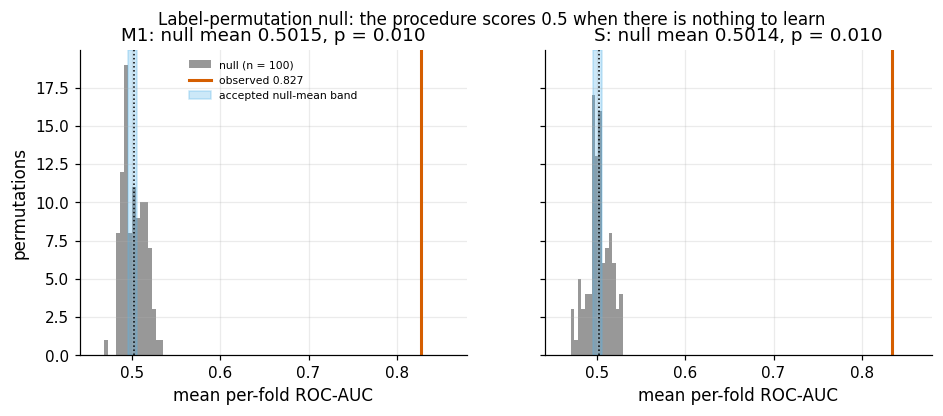

In [199]:
# Label-permutation null: refit M1 and S on permuted training labels (same folds) and collect the mean
# per-fold AUC. Reads ctx; writes results/S9/permutation.csv; asserts that the null mean lies in the accepted
# band.
t0 = time.time()
# permutations are drawn up front and refitted independently: the worker count changes the wall time only (FAST may run
# all of its permutations at once; FINAL keeps its worker count)
N_JOBS_PERM = N_JOBS if C.IS_FINAL else max(N_JOBS, min(C.N_PERM, (os.cpu_count() or 2) - 2))
# Per arm: the observed mean AUC, the permutation null and the permutation p-value.
PERM = {arm: RB.permutation_null(ctx, Spec(arm), n_perm=C.N_PERM, seed_=RB.seed("perm", arm), n_jobs=N_JOBS_PERM)
        for arm in RB.ADMISSIBLE_ARMS}
# in_band: with a leak-free procedure the null mean must sit at 0.5 up to Monte-Carlo noise, hence the band
# [0.495, 0.505] fixed in advance (RB.PERM_NULL_BAND).
perm_tab = pd.DataFrame([dict(arm=a, observed=d["observed"], null_mean=d["null_mean"], null_sd=d["null_sd"],
                              null_min=d["null"].min(), null_max=d["null"].max(), p_value=d["p_value"], n_perm=d["n_perm"],
                              in_band=RB.PERM_NULL_BAND[0] <= d["null_mean"] <= RB.PERM_NULL_BAND[1])
                         for a, d in PERM.items()])
perm_tab.to_csv(OUT / "permutation.csv", index=False)
show(perm_tab, 4)
print(f"{sum(len(ctx.folds) * (d['n_perm'] + 1) for d in PERM.values())} fits in {time.time() - t0:.0f} s")
# Procedural-leakage guard (e.g. preprocessing fitted on test rows, label-derived weights).
assert perm_tab["in_band"].all(), "permutation null mean outside [0.495, 0.505]: procedural leakage suspected"

# Figure: permutation null of each arm (histogram) with the observed AUC (red) and the accepted band.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (arm, d) in zip(axes, PERM.items()):
    ax.hist(d["null"], bins=15, color=OI["grey"], alpha=0.8, label=f"null (n = {d['n_perm']})")
    ax.axvline(d["observed"], color=OI["vermillion"], lw=2, label=f"observed {d['observed']:.3f}")
    ax.axvspan(*RB.PERM_NULL_BAND, color=OI["sky"], alpha=0.3, label="accepted null-mean band")
    ax.axvline(d["null_mean"], color="k", ls=":", lw=1)
    ax.set(title=f"{arm}: null mean {d['null_mean']:.4f}, p = {d['p_value']:.3f}", xlabel="mean per-fold ROC-AUC")
    # Same x range in both panels, wide enough for the null (near 0.5) and for the observed AUC.
    ax.set_xlim(0.44, 0.88)
axes[0].set_ylabel("permutations")
axes[0].legend(fontsize=7, loc="upper center")
fig.suptitle("Label-permutation null: the procedure scores 0.5 when there is nothing to learn", fontsize=11)
plots.savefig(fig, "S9_permutation_null", caption="F9-1. Mean per-fold ROC-AUC of M1 and S refitted on permuted training labels "
              f"({C.N_PERM} permutations, same folds; grey) against the observed value (red). Blue band = acceptance range "
              "[0.495, 0.505] for the null mean; dotted line = null mean. Training part, Tier 1, E-ALL.")
plt.show()
S9["permutation"] = perm_tab.set_index("arm").to_dict("index")

### 9.2.2 Pure-noise feature
**Why.** An appended N(0, 1) column must look like noise (interval covering 0, no AUC change, never a tree split).

In [200]:
# Pure-noise control: append an N(0, 1) column to M1 and S and check that it behaves like noise (coefficient
# interval covers 0, AUC unchanged, never used by a tree). Writes results/S9/noise_feature.csv; asserts both.
rng = np.random.default_rng(RB.seed("noise"))
# Extra columns live in the context and are appended to the raw frame by name (Spec.extra).
ctx.extras["noise_n01"] = rng.standard_normal(ctx.n)
noise_rows, NOISE_CB = [], {}
for arm in RB.ADMISSIBLE_ARMS:
    sp = Spec(arm, extra=("noise_n01",))
    X_, y_, sw_, _ = RB.spec_inputs(ctx, sp)
    # Bootstrap of the coefficients (B refits of the whole pipeline, with the arm's fit weights). `sp=sp` pins
    # the loop variable inside the lambda.
    cb = ek.coef_bootstrap(lambda sp=sp: RB.make_pipe(sp, ctx.C0), X_, y_.astype(int), n_boot=B_COEF9,
                           seed=RB.seed("noise-coef", arm), fit_params=None if sw_ is None else {"model__sample_weight": sw_},
                           n_jobs=N_JOBS)
    NOISE_CB[arm] = cb
    s = cb.summary.loc["noise_n01"]
    sdz = float(RB.make_pipe(sp, ctx.C0)[:-1].fit_transform(X_)["noise_n01"].std())   # per-SD scale of the design column
    # AUC change caused by the noise column: with-noise minus without-noise, same engine as the reference.
    cmp_ = pair(sp, Spec(arm), tag=f"noise-{arm}")
    # Refit depth-3 and depth-4 trees on every fold and count in how many of them the noise column is used.
    tr_ = RB.tree_features_used(ctx, Spec(arm, model="tree", extra=("noise_n01",)), ctx.folds, "noise_n01")
    tr4 = RB.tree_features_used(ctx, Spec(arm, model="tree", depth=4, extra=("noise_n01",)), ctx.folds, "noise_n01")
    zt = (cb.summary["coef"] / cb.summary["sd"]).abs()                                # bootstrap |z| for a scale-free rank
    rank = int(zt.rank(ascending=False)["noise_n01"])
    noise_rows.append(dict(arm=arm, coef_per_sd=s["coef"] * sdz, q_low=s["q_low"] * sdz, q_high=s["q_high"] * sdz,
                           ci_covers_0=bool(s["q_low"] <= 0 <= s["q_high"]), abs_z_rank=f"{rank}/{len(cb.summary)}", abs_z=float(zt["noise_n01"]),
                           dAUC_eall=cmp_[0]["est"], dAUC_eall_lo=cmp_[0]["lo"], dAUC_eall_hi=cmp_[0]["hi"],
                           dAUC_eall_verdict=RB.equivalence_verdict(cmp_[0]["lo"], cmp_[0]["hi"]),
                           tree3_uses=int(tr_["uses_feature"].sum()), tree4_uses=int(tr4["uses_feature"].sum()),
                           n_trees=len(tr_)))
noise_tab = pd.DataFrame(noise_rows)
noise_tab.to_csv(OUT / "noise_feature.csv", index=False)
show(noise_tab, 4)
# Overfitting guard: the noise coefficient interval must cover 0 and no depth-3 tree may split on the column.
assert noise_tab["ci_covers_0"].all() and (noise_tab["tree3_uses"] == 0).all()
S9["noise_feature"] = noise_tab.set_index("arm").to_dict("index")

arm,coef_per_sd,q_low,q_high,ci_covers_0,abs_z_rank,abs_z,dAUC_eall,dAUC_eall_lo,dAUC_eall_hi,dAUC_eall_verdict,tree3_uses,tree4_uses,n_trees
M1,0.0118,-0.0753,0.1100,True,43/47,0.2574,-0.0000,-0.0009,0.0009,supported,0,0,26
S,0.0482,-0.0668,0.1691,True,30/43,0.7934,-0.0001,-0.0008,0.0005,supported,0,4,26


### 9.2.3 Positive control
**Why.** A synthetic column z = d·y + N(0, 1) with known AUC 0.60 must be recovered and its increment detected.

In [201]:
# Positive control: add a synthetic column with a known single-feature AUC of 0.60 (z = d * y + N(0, 1)) and
# check that the procedure recovers that AUC and detects the increment. Writes
# results/S9/positive_control.csv.
ctx.extras["pos_control"] = RB.signal_feature(ctx.y, RB.POS_CONTROL_AUC, seed_=RB.seed("positive-control"))
# Single-feature AUC of z with a bootstrap interval; the design value (0.60) must lie inside it.
z_auc = RB.auc_ci(ctx.y, ctx.extras["pos_control"].to_numpy(), seed_=RB.seed("z-auc"))
print(f"single-feature AUC of z: {z_auc[0]:.3f} [{z_auc[1]:.3f}, {z_auc[2]:.3f}] (design value {RB.POS_CONTROL_AUC:.2f})")
pos_rows = []
for arm in RB.ADMISSIBLE_ARMS:
    for r in pair(Spec(arm, extra=("pos_control",)), Spec(arm), tag=f"pos-{arm}"):
        pos_rows.append(dict(arm=arm, pop=r["pop"], auc_without=r["auc_b"], auc_with=r["auc_a"], est=r["est"], lo=r["lo"],
                             hi=r["hi"], interval=r["interval"], detected=bool(r["lo"] > 0)))
# detected = the lower bound of the interval for the AUC gain is above 0.
pos_tab = pd.DataFrame(pos_rows)
pos_tab.to_csv(OUT / "positive_control.csv", index=False)
show(pos_tab, 4)
# The control only means something if z really has the intended AUC.
assert z_auc[1] <= RB.POS_CONTROL_AUC <= z_auc[2], "positive-control AUC not recovered"
# Power guard: a weak real signal must be detected on E-ALL, otherwise the negative controls could pass merely
# because the procedure is blind.
assert pos_tab.loc[pos_tab["pop"] == "E-ALL", "detected"].all(), "positive control not detected on E-ALL"
S9["positive_control"] = dict(z_auc=z_auc, rows=pos_tab.to_dict("records"))

single-feature AUC of z: 0.588 [0.567, 0.610] (design value 0.60)


arm,pop,auc_without,auc_with,est,lo,hi,interval,detected
M1,E-ALL,0.8285,0.8345,0.0061,0.0023,0.0101,bootstrap,True
M1,E-SCREEN,0.7723,0.7844,0.0122,0.0019,0.0228,bootstrap,True
S,E-ALL,0.8359,0.8420,0.0061,0.0021,0.0102,bootstrap,True
S,E-SCREEN,0.7807,0.7939,0.0132,0.0026,0.0242,bootstrap,True


## 9.3 Seed stability
**Why.** Ten seeds derived from `SEED_MASTER` draw new folds and bootstrap streams (FAST: five); the H2b(a) verdict must
not depend on them.

10 seeds x 2 arms x 25 folds in 46 s


seed_index,pop,auc_a,auc_b,est,lo,hi,interval,h2b
0,E-ALL,0.8355,0.8287,0.0069,-0.0018,0.0155,corrected_t,inconclusive
0,E-SCREEN,0.7805,0.7739,0.0066,-0.0084,0.0222,bootstrap,inconclusive
1,E-ALL,0.8354,0.8290,0.0060,-0.0013,0.0133,corrected_t,inconclusive
1,E-SCREEN,0.7814,0.7735,0.0080,-0.0082,0.0224,bootstrap,inconclusive
2,E-ALL,0.8364,0.8297,0.0068,0.0005,0.0131,corrected_t,inconclusive
2,E-SCREEN,0.7834,0.7749,0.0086,-0.0072,0.0230,bootstrap,inconclusive
3,E-ALL,0.8352,0.8284,0.0071,0.0002,0.0140,corrected_t,inconclusive
3,E-SCREEN,0.7818,0.7746,0.0072,-0.0079,0.0223,bootstrap,inconclusive
4,E-ALL,0.8347,0.8271,0.0078,0.0014,0.0143,corrected_t,inconclusive
4,E-SCREEN,0.7816,0.7712,0.0104,-0.0054,0.0248,bootstrap,inconclusive


,est_min,est_max,est_sd,lo_min,hi_max,verdicts
pop,,,,,,
E-ALL,0.0058,0.0078,0.0006,-0.0018,0.0155,inconclusive x10
E-SCREEN,0.0062,0.0104,0.0012,-0.0090,0.0248,inconclusive x10


E-ALL verdict identical under all seeds: True (reference: inconclusive)


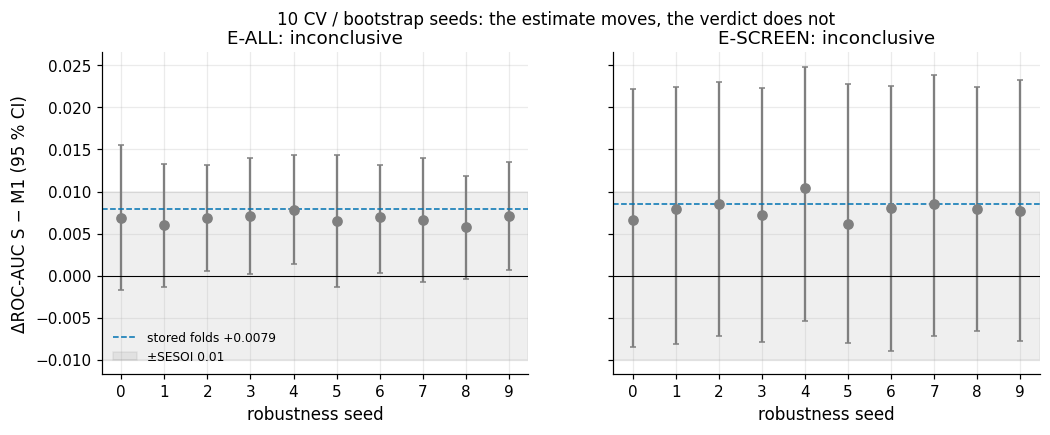

In [202]:
# Seed stability: redo the S - M1 comparison with new folds and bootstrap streams (data, hold-out and C0
# fixed). Reads ctx; writes results/S9/seed_stability.csv. The verdict must not depend on the seed. Fit many
# (spec, folds) pairs in one parallel batch; pair() later finds them in the cache.
def prefetch(items):
    """Run many (spec, folds) pairs in one parallel batch (fills the cache used by `pair`)."""
    t0 = time.time()
    RB.run_jobs(ctx, items, n_jobs=N_JOBS, cache=RUNS)
    return time.time() - t0

# One fresh repeated stratified fold set per robustness seed, derived from the master seed.
SEED_FOLDS = {k: RB.seed_folds(ctx.strat, RB.seed("cv-seed", k)) for k in range(N_SEEDS)}
secs = prefetch({f"{a}{k}": (Spec(a), f) for k, f in SEED_FOLDS.items() for a in RB.ADMISSIBLE_ARMS})
seed_rows = []
for k, f in SEED_FOLDS.items():
    for r in pair(Spec("S"), Spec("M1"), f, tag=f"seed{k}"):
        seed_rows.append(dict(seed_index=k, seed=f.seed, folds_hash=f.hash[:12], **{c: r[c] for c in
                              ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b", "sesoi_class")}))
seeds = pd.DataFrame(seed_rows)
seeds.to_csv(OUT / "seed_stability.csv", index=False)
print(f"{len(SEED_FOLDS)} seeds x 2 arms x {len(ctx.folds)} folds in {secs:.0f} s")
show(seeds[["seed_index", "pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b"]], 4)
# Spread of the estimates and verdict counts per population.
seed_sum = seeds.groupby("pop").agg(est_min=("est", "min"), est_max=("est", "max"), est_sd=("est", "std"),
                                    lo_min=("lo", "min"), hi_max=("hi", "max"),
                                    verdicts=("h2b", lambda v: ", ".join(f"{k} x{n}" for k, n in v.value_counts().items())))
display(seed_sum.round(4))
# Stable = all seeds give one and the same E-ALL verdict.
seed_stable = seeds.loc[seeds["pop"] == "E-ALL", "h2b"].nunique() == 1
ref_v = S9["reference"]["E-ALL"]["h2b"]
print(f"E-ALL verdict identical under all seeds: {seed_stable} (reference: {ref_v})")

# Figure: one interval per seed. Colour = verdict under the locked equivalence rule.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
# Verdict colours shared by the figures of this section.
VCOL = {"supported": OI["green"], "refuted": OI["vermillion"], "inconclusive": OI["grey"]}
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    s = seeds[seeds["pop"] == pop].reset_index(drop=True)
    for i, r in s.iterrows():
        ax.errorbar(i, r["est"], yerr=[[r["est"] - r["lo"]], [r["hi"] - r["est"]]], fmt="o", color=VCOL[r["h2b"]], capsize=2)
    rr = S9["reference"][pop]
    ax.axhline(rr["est"], color=OI["blue"], ls="--", lw=1, label=f"stored folds {rr['est']:+.4f}")
    ax.axhspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12, label="±SESOI 0.01")
    ax.axhline(0, color="k", lw=0.7)
    ax.set(xticks=range(len(s)), xlabel="robustness seed", title=f"{pop}: {', '.join(s['h2b'].value_counts().index)}")
axes[0].set_ylabel("ΔROC-AUC S − M1 (95 % CI)")
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle(f"{len(SEED_FOLDS)} CV / bootstrap seeds: the estimate moves, the verdict does not", fontsize=11)
plots.savefig(fig, "S9_seed_stability", caption=f"F9-3. ΔROC-AUC (S − M1, Tier 1) with its conservative 95 % CI under {len(SEED_FOLDS)} robustness seeds "
              "(new repeated stratified folds and bootstrap streams; data, hold-out and C0 fixed). Colour = verdict under the locked "
              "equivalence rule (grey = inconclusive); dashed = stored folds of the run mode.")
plt.show()
S9["seeds"] = dict(n=len(SEED_FOLDS), stable_eall=bool(seed_stable), summary=seed_sum.to_dict("index"))

## 9.4 Sensitivity table
**Why.** Many analysis choices were made once. Each of 16 pre-specified variations changes **one** choice for **both**
arms and recomputes ΔAUC(S − M1) with the same engine: labels SL1 (HbA1c only), SL2 (self-report only), SL3 (borderline
positive), SL4 (treatment-aware), SL5 (NCHS incl. fasting glucose, fasting subsample); survey weights in neither or both
fits; `IterativeImputer` or complete cases; Tier 2; C ∈ {0.01, 1, 10}; a depth-4 tree; race as a feature (excluded by
design in §1); and M1 with its **own** tuned C.

In [203]:
# Sensitivity table: change ONE analysis choice at a time (label, weights, imputation, tier, C, tree depth,
# race, own C) for both arms and recompute delta AUC(S - M1). Writes results/S9/sensitivity_table.csv. Also
# tunes C for M0 and M1 separately and runs the leak gate (M1 - M0) with each setting.
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline

# row subsets and extra columns used by the specifications
# Apply only the stateless preparation steps (nothing is fitted), so no information from y enters the masks
# below.
pre = Pipeline([s for s in P.preprocessor_steps(P.ARMS["S"], 1) if s[0] in ("p01", "p02", "p03", "no_care", "p04")])
pre_frame = pre.fit(ctx.X[1]).transform(ctx.X[1])          # stateless steps only: nothing is learned from y
# Complete cases = rows without any missing Tier-1 input after aggregation.
ctx.subsets["complete"] = pre_frame.notna().all(axis=1).to_numpy()
# Fasting subsample = rows where the fasting-glucose label SL5 is defined.
ctx.subsets["fasting"] = ctx.labels["SL5"].notna().to_numpy()
# Race as a string column for the 'race as a feature' variation (excluded by design in the main models, §1).
ctx.extras["race_feature"] = ctx.cl["race"].astype(str).astype(object).to_numpy()
print(f"complete cases (no missing Tier-1 input after aggregation): {ctx.subsets['complete'].sum():,} of {ctx.n:,}; "
      f"fasting subsample: {ctx.subsets['fasting'].sum():,} rows, {int(ctx.labels['SL5'].sum())} SL5 positives")

def tune_C(arm):
    """LogisticRegressionCV over the C grid on the arm's own design (the S7 C0 procedure, applied to the arm)."""
    sp = Spec(arm)
    X_, y_, sw_, _ = RB.spec_inputs(ctx, sp)
    design = RB.make_pipe(sp, ctx.C0)[:-1].fit_transform(X_)
    # Inner 5-fold CV on the training part, seeded per arm: C is chosen by inner-CV AUC.
    inner = StratifiedKFold(5, shuffle=True, random_state=RB.seed("ownC", arm))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        lrcv = LogisticRegressionCV(Cs=list(RB.C_GRID), cv=inner, scoring="roc_auc", max_iter=C.LR_MAX_ITER,
                                    class_weight=P.model_kwargs(P.ARMS[arm])["class_weight"], l1_ratios=(0.0,),
                                    use_legacy_attributes=False, n_jobs=N_JOBS)
        lrcv.fit(design, y_.astype(int), sample_weight=sw_)
    # Mean inner-CV AUC for each C of the grid (average over the 5 inner folds).
    sc = np.asarray(lrcv.scores_).reshape(5, -1).mean(axis=0).ravel()[:len(RB.C_GRID)]
    return float(np.ravel(lrcv.C_)[0]), {str(c): round(float(v), 4) for c, v in zip(RB.C_GRID, sc)}

# Tune C separately for M0 and M1: tests whether using the C0 tuned on S for every arm favoured S.
OWN_C = {arm: tune_C(arm) for arm in ("M0", "M1")}
for arm, (c_, sc) in OWN_C.items():
    print(f"{arm}: own C = {c_}  (inner-CV AUC by C {sc}; C0 = {ctx.C0} was tuned on S)")

# Each row changes one choice for both arms: (name, group, spec for S, spec for M1, label used on E-ALL). S is
# survey-weighted by default and M1 is not, so the two weighting rows each force the setting on one arm.
SENS = [  # (name, group, spec S, spec M1, E-ALL label)
    ("SL1 HbA1c only", "label", Spec("S", label="SL1"), Spec("M1", label="SL1"), "SL1"),
    ("SL2 self-report only", "label", Spec("S", label="SL2"), Spec("M1", label="SL2"), "SL2"),
    ("SL3 borderline positive", "label", Spec("S", label="SL3"), Spec("M1", label="SL3"), "SL3"),
    ("SL4 treatment-aware", "label", Spec("S", label="SL4"), Spec("M1", label="SL4"), "SL4"),
    ("SL5 NCHS incl. FPG (fasting)", "label", Spec("S", label="SL5", rows="fasting"), Spec("M1", label="SL5", rows="fasting"), "SL5"),
    ("unweighted fit (both)", "weights", Spec("S", weighted=False), Spec("M1"), "L_comb"),
    ("survey-weighted fit (both)", "weights", Spec("S"), Spec("M1", weighted=True), "L_comb"),
    ("IterativeImputer", "imputation", Spec("S", impute="iterative"), Spec("M1", impute="iterative"), "L_comb"),
    ("complete cases", "imputation", Spec("S", rows="complete"), Spec("M1", rows="complete"), "L_comb"),
    ("Tier 2 (+ lipids)", "tier", Spec("S", tier=2), Spec("M1", tier=2), "L_comb"),
    ("C = 0.01", "C", Spec("S", C=0.01), Spec("M1", C=0.01), "L_comb"),
    ("C = 1", "C", Spec("S", C=1.0), Spec("M1", C=1.0), "L_comb"),
    ("C = 10", "C", Spec("S", C=10.0), Spec("M1", C=10.0), "L_comb"),
    ("depth-4 tree", "model", Spec("S", model="tree", depth=4), Spec("M1", model="tree", depth=4), "L_comb"),
    ("race as a feature", "features", Spec("S", extra=("race_feature",)), Spec("M1", extra=("race_feature",)), "L_comb"),
    ("M1 with its own tuned C", "C", Spec("S"), Spec("M1", C=OWN_C["M1"][0]), "L_comb"),
]
# The pre-specified list has at most 16 variations (the text quotes 16).
assert len(SENS) <= 16
# Specs for the leak gate with each arm's own C; they are prefetched together with the table.
own_gate = [Spec("M1", C=OWN_C["M1"][0]), Spec("M0", C=OWN_C["M0"][0]), Spec("M0")]
# Fit every specification of the table and of the gate in one parallel batch.
secs = prefetch({f"{i}{j}": (sp, ctx.folds) for i, row in enumerate(SENS) for j, sp in enumerate(row[2:4])}
                | {f"g{j}": (sp, ctx.folds) for j, sp in enumerate(own_gate)})
# Start with the reference row so every variation can be read against it.
sens_rows = [dict(spec="reference (S7)", group="reference", **r) for r in ref]
for name, grp, sa, sb, lab in SENS:
    for r in pair(sa, sb, tag=f"sens-{name}", label=lab):
        sens_rows.append(dict(spec=name, group=grp, **r))
sens = pd.DataFrame(sens_rows)
# True where a variation gives the same H2b(a) verdict as the reference for that population.
sens["same_verdict_as_reference"] = [v == S9["reference"][p]["h2b"] for v, p in zip(sens["h2b"], sens["pop"])]
sens.to_csv(OUT / "sensitivity_table.csv", index=False)
print(f"{len(SENS)} specifications, {secs:.0f} s")
show(sens[["spec", "pop", "n_eval", "n_pos", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b"]], 4)

# Leak gate: AUC(M1) - AUC(M0), where M0 keeps the inadmissible columns. The gap measures how much of the
# naive performance came from inadmissible items. Computed with each arm's own C and, below, with the shared
# C0.
gate_own = pair(Spec("M1", C=OWN_C["M1"][0]), Spec("M0", C=OWN_C["M0"][0]), tag="gate-ownC")
gate_c0 = pair(Spec("M1"), Spec("M0"), tag="gate-C0")
for g, nm in ((gate_c0, "C0 for both"), (gate_own, "own C each")):
    print(f"leak gate M1 - M0 ({nm}): " + "; ".join(f"{r['pop']} {r['est']:+.3f} [{r['lo']:+.3f}, {r['hi']:+.3f}]" for r in g))

eall = sens[sens["pop"] == "E-ALL"]
n_same = int(eall["same_verdict_as_reference"].sum())
print(f"E-ALL: {n_same} of {len(eall)} rows share the reference verdict ({ref_v}); "
      f"differing: {eall.loc[~eall['same_verdict_as_reference'], 'spec'].tolist()}")
esc_ = sens[sens["pop"] == "E-SCREEN"]
print(f"E-SCREEN verdicts: {esc_['h2b'].value_counts().to_dict()}; estimates {esc_['est'].min():+.3f} to {esc_['est'].max():+.3f}")
print(f"sign: E-ALL estimates {eall['est'].min():+.4f} to {eall['est'].max():+.4f}; "
      f"rows with CI wholly below 0: {int((sens['hi'] < 0).sum())}")

complete cases (no missing Tier-1 input after aggregation): 3,621 of 4,584; fasting subsample: 2,338 rows, 454 SL5 positives


M0: own C = 0.1  (inner-CV AUC by C {'0.01': 0.9536, '0.1': 0.9575, '1.0': 0.9561, '10.0': 0.9552}; C0 = 0.1 was tuned on S)
M1: own C = 0.1  (inner-CV AUC by C {'0.01': 0.8263, '0.1': 0.828, '1.0': 0.8273, '10.0': 0.8272}; C0 = 0.1 was tuned on S)


16 specifications, 90 s


spec,pop,n_eval,n_pos,auc_a,auc_b,est,lo,hi,interval,h2b
reference (S7),E-ALL,4584,777,0.8359,0.8285,0.0079,0.0000,0.0158,corrected_t,inconclusive
reference (S7),E-SCREEN,3934,127,0.7807,0.7723,0.0085,-0.0081,0.0236,bootstrap,inconclusive
SL1 HbA1c only,E-ALL,4584,582,0.8316,0.8206,0.0116,0.0002,0.0230,corrected_t,inconclusive
SL1 HbA1c only,E-SCREEN,3934,127,0.7845,0.7796,0.0049,-0.0124,0.0214,bootstrap,inconclusive
SL2 self-report only,E-ALL,4584,650,0.8389,0.8329,0.0062,-0.0035,0.0160,corrected_t,inconclusive
SL2 self-report only,E-SCREEN,3934,127,0.7668,0.7587,0.0081,-0.0087,0.0245,bootstrap,inconclusive
SL3 borderline positive,E-ALL,4584,920,0.8254,0.8193,0.0061,0.0001,0.0121,corrected_t,inconclusive
SL3 borderline positive,E-SCREEN,3934,127,0.7763,0.7708,0.0055,-0.0090,0.0214,bootstrap,inconclusive
SL4 treatment-aware,E-ALL,4584,712,0.8384,0.8306,0.0079,0.0001,0.0158,corrected_t,inconclusive
SL4 treatment-aware,E-SCREEN,3934,127,0.7825,0.7732,0.0093,-0.0078,0.0253,bootstrap,inconclusive


leak gate M1 - M0 (C0 for both): E-ALL -0.131 [-0.148, -0.114]; E-SCREEN -0.072 [-0.109, -0.032]
leak gate M1 - M0 (own C each): E-ALL -0.131 [-0.148, -0.114]; E-SCREEN -0.072 [-0.113, -0.030]
E-ALL: 17 of 17 rows share the reference verdict (inconclusive); differing: []
E-SCREEN verdicts: {'inconclusive': 17}; estimates -0.012 to +0.020
sign: E-ALL estimates -0.0061 to +0.0116; rows with CI wholly below 0: 0


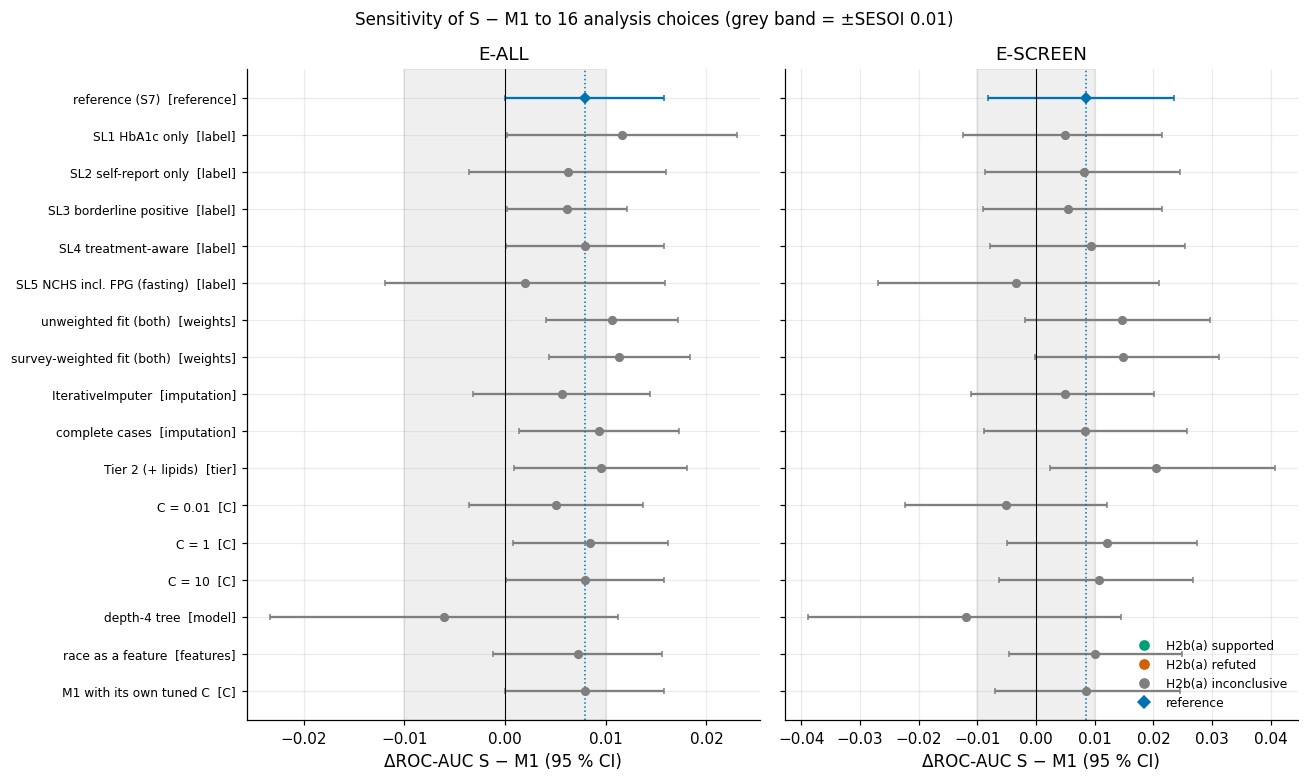

In [204]:
# Forest plot of the sensitivity table: one row per specification, E-ALL left and E-SCREEN right. Reads
# `sens`; writes the figure through plots.savefig.
from matplotlib.lines import Line2D
fig, axes = plt.subplots(1, 2, figsize=(12, 7.2), sharey=True)
# Keep the table order (reference first); dict.fromkeys removes duplicates and preserves order.
order = list(dict.fromkeys(sens["spec"]))
groups_ = sens.drop_duplicates("spec").set_index("spec")["group"]
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    s = sens[sens["pop"] == pop].set_index("spec").loc[order]
    # Row 0 is the reference (blue diamond); the other rows are coloured by their H2b(a) verdict.
    for i, (nm, r) in enumerate(s.iterrows()):
        ax.errorbar(r["est"], i, xerr=[[r["est"] - r["lo"]], [r["hi"] - r["est"]]], fmt="D" if i == 0 else "o",
                    color=OI["blue"] if i == 0 else VCOL[r["h2b"]], capsize=2, ms=5)
    # Grey band = +-SESOI (0.01), the equivalence margin of the locked rule.
    ax.axvspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12)
    ax.axvline(0, color="k", lw=0.7)
    ax.axvline(s["est"].iloc[0], color=OI["blue"], ls=":", lw=1)
    ax.set(title=pop, xlabel="ΔROC-AUC S − M1 (95 % CI)")
axes[0].set_yticks(range(len(order)), [f"{o}  [{groups_[o]}]" for o in order], fontsize=8)
axes[0].invert_yaxis()
axes[1].legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=f"H2b(a) {v}") for v, c in VCOL.items()]
               + [Line2D([], [], marker="D", ls="", color=OI["blue"], label="reference")], fontsize=8, loc="lower right")
fig.suptitle("Sensitivity of S − M1 to 16 analysis choices (grey band = ±SESOI 0.01)", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S9_sensitivity_forest", caption="F9-2. ΔROC-AUC (S − M1) with conservative 95 % CIs for the reference and 16 one-at-a-time "
              "variations (labels SL1-SL5, fit weights, imputation, tier, C, depth-4 tree, race as a feature, M1 with its own tuned C); "
              "left E-ALL (scored against the row's label), right E-SCREEN. Colour = H2b(a) verdict under the locked equivalence rule.")
plt.show()
S9["sensitivity"] = dict(n_specs=len(SENS), eall_same_verdict=n_same, eall_rows=len(eall),
                         own_C={a: c for a, (c, _) in OWN_C.items()},
                         leak_gate_C0={r["pop"]: {k: r[k] for k in ("est", "lo", "hi")} for r in gate_c0},
                         leak_gate_own_C={r["pop"]: {k: r[k] for k in ("est", "lo", "hi")} for r in gate_own},
                         table=sens[["spec", "group", "pop", "n_eval", "n_pos", "auc_a", "auc_b", "est", "lo", "hi", "interval",
                                     "mdd", "h2b"]].round(5).to_dict("records"))

**So what.** **The E-ALL verdict does not move**: all 16 variations give the reference verdict, and no interval lies
wholly below 0. **Labels and weighting move the estimate most**: weighting both arms alike enlarges the S advantage to
about +0.01 (part of the reference gap is S's own survey weighting, B6b); the label changes the size of the gap, not
its direction. **The depth-4 tree reverses the sign** with a wide interval – for a tree the preparation steps are
irrelevant (B5-e), one more reason the tree is a probe. **Per-arm C does not favour S**: tuned on their own, M0 and M1
pick the same C as S, so the "same model for every arm" rule neither favoured S nor manufactured the leak gate. This is
a fairness-across-arms check, not a test of nesting (C0 was chosen once on the whole training part); the approximate
nested check is in §9.12. On E-SCREEN every verdict is inconclusive (about 25 positives per fold).

## 9.5 Specification curve
**Why.** A specification curve (Simonsohn et al. 2020) crosses label × weighting × C: 60 specifications (FAST: 30).

In [205]:
# Specification curve: cross 5 training labels x 3 weighting schemes x the values of C (60 specifications in
# FINAL mode, 30 in FAST) and recompute delta AUC(S - M1) for each. Writes results/S9/specification_curve.csv.
import itertools
# Table name -> Spec.label; 'arm' keeps each arm's own training label (the main label), SL1-SL4 impose the
# same sensitivity label on both arms.
LABELS_SC = {"L_comb": "arm", "SL1": "SL1", "SL2": "SL2", "SL3": "SL3", "SL4": "SL4"}
# 'as specified' keeps each arm's own default (S weighted, M1 not); the other two force both arms alike.
WEIGHTING = ("as specified", "both unweighted", "both weighted")
grid = []
for (lab, lab_spec), wt, c in itertools.product(LABELS_SC.items(), WEIGHTING, C_CURVE):
    # None means 'use the frozen C0', so the C0 column reproduces the reference settings.
    cc = None if c == ctx.C0 else c
    # weighted=False forces S unweighted; None keeps S's own weighting. For M1, weighted=True forces survey
    # weights.
    sa = Spec("S", label=lab_spec, C=cc, weighted=False if wt == "both unweighted" else None)
    sb = Spec("M1", label=lab_spec, C=cc, weighted=True if wt == "both weighted" else None)
    grid.append(dict(label=lab, weighting=wt, C=c, sa=sa, sb=sb))
# 5 labels x 3 weightings x 4 values of C = 60 (FAST: 2 values of C = 30).
assert len(grid) == S9["n_curve"] == (60 if C.IS_FINAL else 30)
secs = prefetch({f"sc{i}{j}": (g[k], ctx.folds) for i, g in enumerate(grid) for j, k in enumerate(("sa", "sb"))})
sc_rows = []
for i, g in enumerate(grid):
    for r in pair(g["sa"], g["sb"], tag=f"curve{i}", label=g["label"]):
        sc_rows.append(dict(spec_id=i, label=g["label"], weighting=g["weighting"], C=g["C"], **{k: r[k] for k in
                            ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b", "sesoi_class")}))
curve = pd.DataFrame(sc_rows)
curve.to_csv(OUT / "specification_curve.csv", index=False)
print(f"{len(grid)} specifications x 2 arms in {secs:.0f} s")
# Per population: how many specifications put S ahead (est > 0), have an interval wholly above 0 (lo > 0),
# wholly below 0 (hi < 0) or beyond the SESOI (lo >= 0.01).
cs = curve.groupby("pop").agg(n=("est", "size"), est_median=("est", "median"), est_min=("est", "min"), est_max=("est", "max"),
                              share_positive=("est", lambda v: (v > 0).mean()),
                              share_ci_above_0=("lo", lambda v: (v > 0).mean()),
                              share_ci_below_0=("hi", lambda v: (v < 0).mean()),
                              share_beyond_sesoi=("lo", lambda v: (v >= C.SESOI["roc_auc"]).mean()))
display(cs.round(3))
display(curve.groupby(["pop", "h2b"]).size().unstack(fill_value=0))
print("median E-ALL estimate by factor:")
for fac in ("label", "weighting", "C"):
    print("  ", curve[curve["pop"] == "E-ALL"].groupby(fac)["est"].median().round(4).to_dict())

60 specifications x 2 arms in 97 s


,n,est_median,est_min,est_max,share_positive,share_ci_above_0,share_ci_below_0,share_beyond_sesoi
pop,,,,,,,,
E-ALL,60,0.010,0.005,0.018,1.00,0.85,0.0,0.0
E-SCREEN,60,0.012,-0.011,0.021,0.75,0.30,0.0,0.0


h2b,inconclusive
pop,
E-ALL,60
E-SCREEN,60


median E-ALL estimate by factor:
   {'L_comb': 0.0098, 'SL1': 0.0146, 'SL2': 0.01, 'SL3': 0.0079, 'SL4': 0.0104}
   {'as specified': 0.0074, 'both unweighted': 0.0105, 'both weighted': 0.0113}
   {0.01: 0.009, 0.1: 0.0103, 1.0: 0.0109, 10.0: 0.0108}


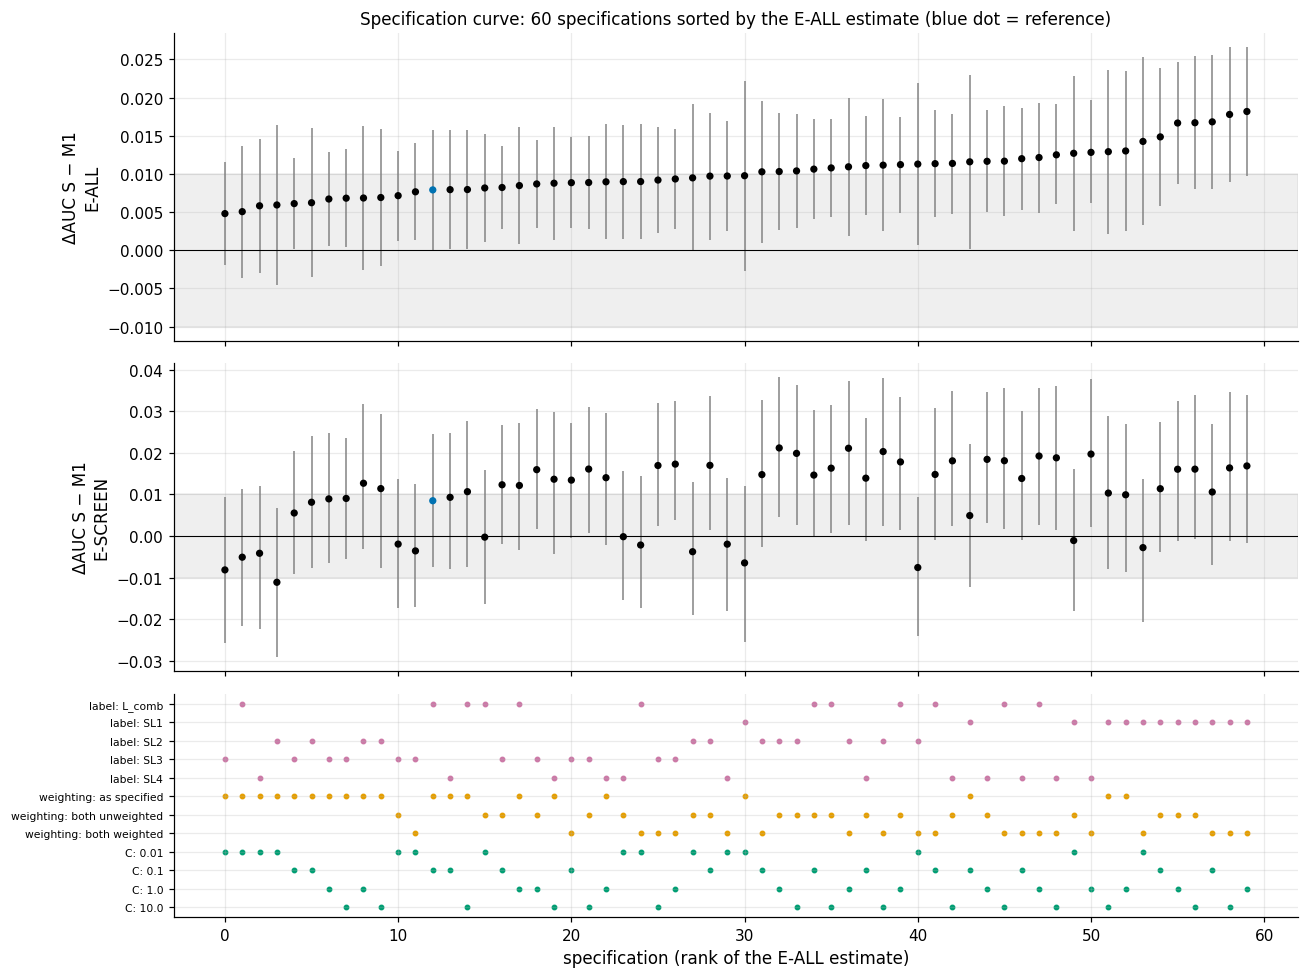

In [206]:
# Specification-curve figure: specifications sorted by the E-ALL estimate (top), the same order on E-SCREEN
# (middle) and the choices that define each specification (bottom).
e_all = curve[curve["pop"] == "E-ALL"].sort_values("est").reset_index(drop=True)
order_ids = e_all["spec_id"].tolist()
# Reorder the E-SCREEN rows by the E-ALL order so that the three panels line up.
e_scr = curve[curve["pop"] == "E-SCREEN"].set_index("spec_id").loc[order_ids].reset_index()
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, gridspec_kw={"height_ratios": [2.2, 2.2, 1.6]})
for ax, d, pop in ((axes[0], e_all, "E-ALL"), (axes[1], e_scr, "E-SCREEN")):
    x = np.arange(len(d))
    ax.vlines(x, d["lo"], d["hi"], color=[VCOL[v] for v in d["h2b"]], lw=1.2, alpha=0.8)
    ax.scatter(x, d["est"], s=14, color=[OI["blue"] if (l == "L_comb" and w == "as specified" and c == ctx.C0) else "k"
                                          for l, w, c in zip(d["label"], d["weighting"], d["C"])], zorder=3)
    ax.axhspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12)
    ax.axhline(0, color="k", lw=0.7)
    ax.set_ylabel(f"ΔAUC S − M1\n{pop}")
axes[0].set_title(f"Specification curve: {len(grid)} specifications sorted by the E-ALL estimate (blue dot = reference)", fontsize=11)
ax = axes[2]
# One indicator row per factor level; a dot marks each specification that uses that level.
rows_ind = [("label", l) for l in LABELS_SC] + [("weighting", w) for w in WEIGHTING] + [("C", c) for c in C_CURVE]
for j, (fac, val) in enumerate(rows_ind):
    hit = (e_all[fac] == val).to_numpy()
    ax.scatter(np.flatnonzero(hit), np.full(hit.sum(), j), s=8, color=OI["purple"] if fac == "label" else OI["orange"] if fac == "weighting" else OI["green"])
ax.set_yticks(range(len(rows_ind)), [f"{fac}: {val}" for fac, val in rows_ind], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("specification (rank of the E-ALL estimate)")
fig.tight_layout()
plots.savefig(fig, "S9_specification_curve", caption=f"Specification curve (extension). {len(grid)} specifications = 5 training labels x 3 weighting "
              f"schemes x {len(C_CURVE)} values of C. Top: ΔROC-AUC (S − M1) on E-ALL with conservative 95 % CI, sorted; middle: E-SCREEN in the same "
              "order; bottom: which choices define each specification. Line colour = H2b(a) verdict (grey inconclusive, green "
              "equivalent, red refuted); grey band = ±SESOI 0.01.")
plt.show()
S9["specification_curve"] = dict(n=len(grid), summary=cs.round(5).to_dict("index"),
                                 verdicts=curve.groupby(["pop", "h2b"]).size().unstack(fill_value=0).to_dict("index"))

## 9.6 Survey-cluster cross-validation
**Why.** Folds grouped by stratum × PSU keep each survey cluster on one side of every split.

In [207]:
# Survey-cluster CV: rebuild the folds so that every stratum x PSU cluster stays on one side of each split,
# then repeat the S - M1 comparison. Writes results/S9/grouped_cv.csv. Cluster id = stratum * 10 + PSU (the
# masked PSU is 1 or 2 within a stratum, so the id is unique).
groups = (ctx.cl[C.STRATA].astype(int) * 10 + ctx.cl[C.PSU].astype(int)).to_numpy()
# Group-aware repeated folds with the same number of splits and repeats as the stored ones.
GFOLDS = RB.group_folds(ctx.strat, groups, RB.seed("group-cv"))
gsz = pd.DataFrame([dict(fold=i, n_test=len(te), n_clusters=len(np.unique(groups[te])), pos=int(ctx.y[te].sum()),
                         pos_escreen=int(ctx.y_esc[te][ctx.esc[te]].sum())) for i, (_, te) in enumerate(GFOLDS)])
# Guard: no cluster may appear on both the training and the test side of any split.
assert all(len(set(groups[te]) & set(groups[tr])) == 0 for tr, te in GFOLDS), "a cluster appears on both sides of a split"
print(f"{len(np.unique(groups))} strata x PSU clusters in the training part; grouped folds: n_test {gsz['n_test'].min()}-{gsz['n_test'].max()}, "
      f"clusters per test fold {gsz['n_clusters'].min()}-{gsz['n_clusters'].max()}, E-SCREEN positives {gsz['pos_escreen'].min()}-{gsz['pos_escreen'].max()}")
secs = prefetch({f"g{a}": (Spec(a), GFOLDS) for a in RB.ADMISSIBLE_ARMS})
gcv = pair(Spec("S"), Spec("M1"), GFOLDS, tag="group-cv")
# Stack the stored-fold reference and the grouped-fold result into one table for a side-by-side reading.
gcv_tab = pd.DataFrame([dict(folds="stored stratified", **{k: r[k] for k in ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b")}) for r in ref]
                       + [dict(folds="strata x PSU grouped", **{k: r[k] for k in ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b")}) for r in gcv])
gcv_tab = gcv_tab.rename(columns={"auc_a": "auc_S", "auc_b": "auc_M1"})
gcv_tab.to_csv(OUT / "grouped_cv.csv", index=False)
show(gcv_tab, 4)
# Change in the AUC of S when folds are grouped; optimism from within-cluster dependence would appear as a
# drop.
dS = {p: gcv_tab.query("folds == 'strata x PSU grouped' and pop == @p")["auc_S"].iloc[0] - gcv_tab.query("folds == 'stored stratified' and pop == @p")["auc_S"].iloc[0]
      for p in ("E-ALL", "E-SCREEN")}
print(f"AUC of S, grouped minus stratified folds: E-ALL {dS['E-ALL']:+.4f}, E-SCREEN {dS['E-SCREEN']:+.4f}")
S9["grouped_cv"] = dict(n_clusters=int(len(np.unique(groups))), table=gcv_tab.round(5).to_dict("records"),
                        auc_S_grouped_minus_stratified=dS)

30 strata x PSU clusters in the training part; grouped folds: n_test 805-1058, clusters per test fold 5-7, E-SCREEN positives 20-31


folds,pop,auc_S,auc_M1,est,lo,hi,interval,h2b
stored stratified,E-ALL,0.8359,0.8285,0.0079,0.0000,0.0158,corrected_t,inconclusive
stored stratified,E-SCREEN,0.7807,0.7723,0.0085,-0.0081,0.0236,bootstrap,inconclusive
strata x PSU grouped,E-ALL,0.8313,0.8257,0.0055,-0.0001,0.0118,bootstrap,inconclusive
strata x PSU grouped,E-SCREEN,0.7797,0.7727,0.0070,-0.0086,0.0221,bootstrap,inconclusive


AUC of S, grouped minus stratified folds: E-ALL -0.0046, E-SCREEN -0.0010


## 9.7 Missing HbA1c: inverse-probability weights and delta adjustment
**Why.** The cohort keeps only examined adults *with* an HbA1c value. §3 showed this missingness is not MCAR (NH Black
OR about 1.85, DR-S3-04) and §5 bounded the prevalence (Manski, DR-S5-08); both deferred two analyses to here:

1. **MAR – inverse-probability weighting (IPW).** The §3 missingness model gives each cohort member a stabilised
   weight P(observed) / P(observed | x), used for the prevalence and for ΔAUC(S − M1).
2. **MNAR – delta adjustment.** People without HbA1c who report diabetes are positive; for the others the MAR
   probability of HbA1c ≥ 6.5 is shifted by δ on the log-odds scale (δ = log 3: three-fold odds among the
   unmeasured). Manski bounds bracket every δ.

In [208]:
# Missing HbA1c, MAR part: refit the missingness logit of §3 on all examined adults, build stabilised
# inverse-probability weights and recompute prevalence and delta AUC(S - M1) with them. Reads
# results/S3/missingness_or.csv; produces `coh['ipw']`, `prev_tab` and `ipw_tab`.
ex = RB.examined_population()
# True for examined adults without an HbA1c value, i.e. the people the cohort drops.
miss = ex["a1c_observed"].eq(0)
obs_fit = RB.observation_model(ex)
ci_ = obs_fit.conf_int()
# The model predicts P(observed), so the odds ratio of being MISSING is exp(-coefficient).
or_obs = pd.DataFrame({"OR_missing": np.exp(-obs_fit.params), "ci_low": np.exp(-ci_[1]), "ci_high": np.exp(-ci_[0])}).drop("const")
# Odds ratios stored by §3 for the same model, for comparison.
s3_or = pd.read_csv(C.RESULTS_DIR / "S3" / "missingness_or.csv", index_col=0)
or_cmp = or_obs.join(s3_or[["OR"]].rename(columns={"OR": "OR_missing_S3"}))
print(f"examined non-pregnant adults {len(ex):,}; without HbA1c {int(miss.sum())} ({miss.mean():.1%}); cohort {int((~miss).sum()):,}")
display(or_cmp.round(3))
# The people with an HbA1c value are exactly the analysis cohort.
assert int((~miss).sum()) == io.COHORT_N
assert abs(or_cmp.loc["NH Black", "OR_missing"] - or_cmp.loc["NH Black", "OR_missing_S3"]) < 0.1   # same model, 37 fewer rows
# Fitted P(HbA1c observed | covariates) for every examined adult.
p_obs = pd.Series(obs_fit.predict(), index=ex["SEQN"].to_numpy())
# Stabilised weight = overall P(observed) / P(observed | x): the numerator keeps the weights near 1 and limits
# their variance compared with the plain 1 / P(observed | x).
ipw_all = (~miss).mean() / p_obs                          # stabilised weight
coh = ctx.clean.copy()
coh["ipw"] = ipw_all.reindex(coh["SEQN"]).to_numpy()
coh["w_mec_ipw"] = coh[C.WEIGHT_MEC] * coh["ipw"]
# Weights of the training part only; no hold-out row is used.
ctx.ipw = coh["ipw"].to_numpy()[ctx.train_idx]
print(f"stabilised IPW in the cohort: min {coh['ipw'].min():.3f}, median {coh['ipw'].median():.3f}, "
      f"max {coh['ipw'].max():.3f}; Kish deff {sv.kish_deff(coh['ipw']):.3f}")

# Weighted prevalence of L_comb under three weightings: blood-sample weight (WTPH2YR), exam weight on the
# complete cases (WTMEC2YR) and exam weight x IPW. Intervals use the survey design.
prev_rows = []
for nm, wcol in (("WTPH2YR (blood non-response adjusted)", C.WEIGHT_PHLEB), ("WTMEC2YR (complete case)", C.WEIGHT_MEC),
                 ("WTMEC2YR x IPW", "w_mec_ipw")):
    wp = sv.weighted_prop(coh, "L_comb", weight=wcol)
    prev_rows.append(dict(weighting=nm, est=wp["est"], ci_low=wp["ci_low"], ci_high=wp["ci_high"], df=wp["df"]))
prev_tab = pd.DataFrame(prev_rows)
show(prev_tab, 4)
# The WTPH2YR prevalence must reproduce the 14.0 % reported in §1 (tolerance 0.15 percentage points).
assert abs(prev_tab.loc[0, "est"] - 0.140) < 0.0015, "WTPH2YR prevalence must reproduce 14.0 % (the §1 weighted prevalence)"

# Two uses of IPW: weights in the evaluation only (weighted AUC) and in both fit and evaluation (Spec.ipw=True
# multiplies the fit weights).
ipw_cmp = pair(Spec("S"), Spec("M1"), tag="ipw-eval", w=ctx.ipw) + pair(Spec("S", ipw=True), Spec("M1", ipw=True), tag="ipw-fit", w=ctx.ipw)
ipw_tab = pd.DataFrame([dict(variant=v, **{k: r[k] for k in ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b")})
                        for v, r in zip(["IPW evaluation"] * 2 + ["IPW fit + evaluation"] * 2, ipw_cmp)])
show(ipw_tab, 4)

examined non-pregnant adults 6,023; without HbA1c 293 (4.9%); cohort 5,730


,OR_missing,ci_low,ci_high,OR_missing_S3
age (per 10 y),0.892,0.825,0.965,0.893
female,0.940,0.738,1.196,0.948
NH Black,1.780,1.293,2.451,1.853
NH Asian,1.374,0.840,2.249,1.383
Mexican American,0.723,0.414,1.264,0.772
Other Hispanic,0.845,0.543,1.315,0.842
Other/Multi,1.245,0.785,1.974,1.244
PIR (per unit),0.821,0.754,0.894,0.820
PIR missing,1.564,1.142,2.141,1.572
BMI (per unit),0.997,0.980,1.014,0.997


stabilised IPW in the cohort: min 0.963, median 0.992, max 1.365; Kish deff 1.001


weighting,est,ci_low,ci_high,df
WTPH2YR (blood non-response adjusted),0.1404,0.1244,0.1563,15
WTMEC2YR (complete case),0.1393,0.1232,0.1553,15
WTMEC2YR x IPW,0.1402,0.1242,0.1563,15


variant,pop,auc_a,auc_b,est,lo,hi,interval,h2b
IPW evaluation,E-ALL,0.8359,0.8284,0.0079,0.0000,0.0158,corrected_t,inconclusive
IPW evaluation,E-SCREEN,0.7801,0.7717,0.0085,-0.0080,0.0252,bootstrap,inconclusive
IPW fit + evaluation,E-ALL,0.8356,0.8286,0.0072,-0.0009,0.0154,corrected_t,inconclusive
IPW fit + evaluation,E-SCREEN,0.7798,0.7706,0.0091,-0.0074,0.0249,bootstrap,inconclusive


In [209]:
# Missing HbA1c, MNAR part (delta adjustment): fit a MAR model of HbA1c >= 6.5 % among the undiagnosed on the
# training part, shift it by delta on the log-odds scale for people without HbA1c, and recompute prevalence
# and delta AUC(S - M1) over a grid of deltas, plus the Manski all-negative / all-positive bounds. Writes
# results/S9/mnar_delta_prevalence.csv, mnar_delta_auc.csv and ipw.csv.
import statsmodels.api as sm
# Drop 'self-reported diabetes': it is constant among the undiagnosed rows on which this model is fitted.
Xd_ex = RB.missingness_design(ex).drop(columns=["self-reported diabetes"])
# Row positions of the training-part cohort inside `ex`, to pick the matching covariate rows.
seq_pos = pd.Series(np.arange(len(ex)), index=ex["SEQN"].to_numpy())
tr_rows = seq_pos.reindex(ctx.cl["SEQN"]).to_numpy()
fit_rows = tr_rows[ctx.esc]                                     # training-part E-SCREEN rows (no hold-out row)
# MAR model: logit of HbA1c >= 6.5 % given the covariates, on training-part E-SCREEN rows only.
mar_fit = sm.Logit(ctx.y_esc[ctx.esc], sm.add_constant(Xd_ex.iloc[fit_rows])).fit(disp=0)
miss_idx = np.flatnonzero(miss.to_numpy())
# People without HbA1c who report diabetes count as positive; all others are 'undetermined'.
miss_self = ex["DIQ010"].eq(1).to_numpy()[miss_idx]
# MAR probability of HbA1c >= 6.5 % for each person without HbA1c (has_constant='add' forces the intercept
# column even if a selected subset has a constant column).
p_mar = mar_fit.predict(sm.add_constant(Xd_ex, has_constant="add").iloc[miss_idx]).to_numpy()
from sklearn.metrics import roc_auc_score
print(f"MAR model for HbA1c >= 6.5 among the undiagnosed: fitted on {len(fit_rows):,} training-part E-SCREEN rows "
      f"({int(ctx.y_esc[ctx.esc].sum())} positives), in-sample AUC {roc_auc_score(ctx.y_esc[ctx.esc], mar_fit.predict()):.3f}")
print(f"missing rows: {len(miss_idx)}; self-reported diabetes {int(miss_self.sum())}; undetermined {int((~miss_self).sum())}, "
      f"mean MAR probability {p_mar[~miss_self].mean():.3f}")

# Grid of delta on the log-odds scale: 0 = MAR, log 3 = three-fold odds (the scenario in the text), up to 3.
DELTAS = np.array([-1.0, -0.5, 0.0, 0.5, 1.0, np.log(3), 1.5, 2.0, 3.0])
# Exam weights (WTMEC2YR) for observed and missing people: both groups belong to the examined population.
w_obs = coh[C.WEIGHT_MEC].to_numpy()
w_m = ex[C.WEIGHT_MEC].to_numpy()[miss_idx]
# Weighted prevalence per delta; `dprev.attrs` carries the complete-case value and the Manski bounds.
dprev = RB.delta_prevalence(coh["L_comb"].to_numpy(), w_obs, miss_self, p_mar, w_m, DELTAS)
show(dprev, 4)
print(f"complete case (MEC) {dprev.attrs['complete_case']:.4f}; Manski bounds [{dprev.attrs['manski_low']:.4f}, {dprev.attrs['manski_high']:.4f}] "
      f"(S5: [{pd.read_csv(C.RESULTS_DIR / 'S5' / 'manski_bounds.csv').iloc[0]['lower']:.4f}, "
      f"{pd.read_csv(C.RESULTS_DIR / 'S5' / 'manski_bounds.csv').iloc[0]['upper']:.4f}])")
from scipy.optimize import brentq
# Tipping point: the delta at which the adjusted prevalence reaches the NCHS figure of 15.8 % (root finding;
# the prevalence grows with delta, so a root in [0, 20] exists only if delta = 20 already exceeds 15.8 %).
f_tip = lambda d: RB.delta_prevalence(coh["L_comb"].to_numpy(), w_obs, miss_self, p_mar, w_m, [d])["prevalence"].iloc[0] - 0.158
tip = brentq(f_tip, 0, 20) if f_tip(20) > 0 else np.nan
print(f"delta needed to reach the DB516 prevalence of 15.8 %: {tip:.2f} (odds ratio {np.exp(tip):.1f})" if np.isfinite(tip)
      else "15.8 % is not reachable even with every undetermined person positive")

# delta-adjusted S - M1: full-training-part models score the people without HbA1c
# Delta-adjusted S - M1: the people without HbA1c are not in the cohort, so their raw rows are rebuilt and
# scored by models refitted on the whole training part (scored only, never trained on).
raw_ex = io.load_merged(fix=False, sentinels="none")
raw_miss = raw_ex.set_index("SEQN").loc[ex["SEQN"].to_numpy()[miss_idx]].reset_index()
pa_m = RB.fit_full(ctx, Spec("S")).predict_proba(P.raw_feature_frame(raw_miss, 1))[:, 1]
pb_m = RB.fit_full(ctx, Spec("M1")).predict_proba(P.raw_feature_frame(raw_miss, 1))[:, 1]
# Out-of-fold predictions of the reference run, for the people who do have an HbA1c value.
ref_oof = RB.run_many(ctx, {"S": Spec("S"), "M1": Spec("M1")}, n_jobs=N_JOBS, cache=RUNS)
pa_o, pb_o = ek.mean_oof(ref_oof["S"], ctx.n), ek.mean_oof(ref_oof["M1"], ctx.n)
# Number of random label draws per delta for the adjusted AUC (at least 50).
N_DRAW = max(50, C.N_BOOT // 5)
dauc = []
# E-ALL adds every person without HbA1c; E-SCREEN adds only the undetermined ones (self-reporters are not in
# it).
for pop, om, mm, yo in (("E-ALL", None, None, ctx.y), ("E-SCREEN", ctx.esc, ~miss_self, ctx.y_esc)):
    d = RB.delta_auc(yo, pa_o, pb_o, miss_self, p_mar, pa_m, pb_m, DELTAS, n_draw=N_DRAW, seed_=RB.seed("delta-auc", pop),
                     obs_mask=om, miss_mask=mm)
    d.insert(0, "pop", pop)
    dauc.append(d)
dauc = pd.concat(dauc, ignore_index=True)
dprev.to_csv(OUT / "mnar_delta_prevalence.csv", index=False)
dauc.to_csv(OUT / "mnar_delta_auc.csv", index=False)
pd.concat([prev_tab.assign(kind="prevalence"), ipw_tab.assign(kind="dAUC S-M1")]).to_csv(OUT / "ipw.csv", index=False)
show(dauc, 4)
print(f"E-ALL S - M1 across all delta and Manski scenarios: {dauc.loc[dauc['pop'] == 'E-ALL', 'diff'].min():+.4f} to "
      f"{dauc.loc[dauc['pop'] == 'E-ALL', 'diff'].max():+.4f} (complete-case pooled {S9['reference']['E-ALL']['est']:+.4f})")

MAR model for HbA1c >= 6.5 among the undiagnosed: fitted on 3,934 training-part E-SCREEN rows (127 positives), in-sample AUC 0.802
missing rows: 293; self-reported diabetes 49; undetermined 244, mean MAR probability 0.036


delta,odds_ratio,prevalence
-1.0000,0.3679,0.1399
-0.5000,0.6065,0.1402
0.0000,1.0000,0.1406
0.5000,1.6487,0.1413
1.0000,2.7183,0.1422
1.0986,3.0000,0.1425
1.5000,4.4817,0.1436
2.0000,7.3891,0.1454
3.0000,20.0855,0.1506


complete case (MEC) 0.1393; Manski bounds [0.1395, 0.1811] (S5: [0.1395, 0.1811])
delta needed to reach the DB516 prevalence of 15.8 %: 4.07 (odds ratio 58.7)


pop,delta,scenario,auc_a,auc_b,diff,diff_lo,diff_hi
E-ALL,-1.0000,delta,0.8361,0.8286,0.0075,0.0071,0.0079
E-ALL,-0.5000,delta,0.8359,0.8284,0.0075,0.0069,0.0080
E-ALL,0.0000,delta,0.8358,0.8282,0.0076,0.0068,0.0083
E-ALL,0.5000,delta,0.8354,0.8278,0.0076,0.0068,0.0085
E-ALL,1.0000,delta,0.8346,0.8269,0.0077,0.0068,0.0087
E-ALL,1.0986,delta,0.8345,0.8268,0.0078,0.0066,0.0089
E-ALL,1.5000,delta,0.8335,0.8257,0.0078,0.0067,0.0090
E-ALL,2.0000,delta,0.8321,0.8243,0.0078,0.0064,0.0091
E-ALL,3.0000,delta,0.8251,0.8174,0.0077,0.0059,0.0092
E-ALL,,manski_all_negative,0.8362,0.8287,0.0074,,


E-ALL S - M1 across all delta and Manski scenarios: +0.0038 to +0.0078 (complete-case pooled +0.0079)


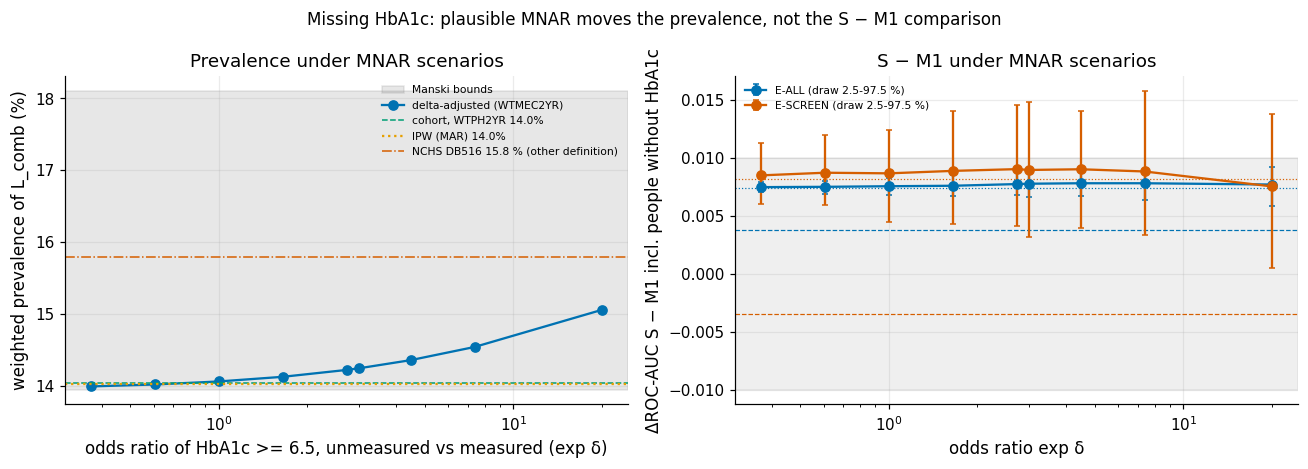

In [210]:
# Figure: prevalence (left) and delta AUC(S - M1) (right) across the delta scenarios; the x axis is
# exp(delta), the odds ratio of HbA1c >= 6.5 % for unmeasured versus measured people, on a log scale.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
ax.axhspan(dprev.attrs["manski_low"] * 100, dprev.attrs["manski_high"] * 100, color=OI["grey"], alpha=0.18, label="Manski bounds")
ax.plot(dprev["odds_ratio"], dprev["prevalence"] * 100, "o-", color=OI["blue"], label="delta-adjusted (WTMEC2YR)")
ax.axhline(prev_tab.loc[0, "est"] * 100, color=OI["green"], ls="--", lw=1, label=f"cohort, WTPH2YR {prev_tab.loc[0, 'est']:.1%}")
ax.axhline(prev_tab.loc[2, "est"] * 100, color=OI["orange"], ls=":", lw=1.5, label=f"IPW (MAR) {prev_tab.loc[2, 'est']:.1%}")
ax.axhline(15.8, color=OI["vermillion"], ls="-.", lw=1, label="NCHS DB516 15.8 % (other definition)")
ax.set_xscale("log")
ax.set(xlabel="odds ratio of HbA1c >= 6.5, unmeasured vs measured (exp δ)", ylabel="weighted prevalence of L_comb (%)",
       title="Prevalence under MNAR scenarios")
ax.legend(fontsize=7)
ax = axes[1]
for pop, col in (("E-ALL", OI["blue"]), ("E-SCREEN", OI["vermillion"])):
    d = dauc[(dauc["pop"] == pop) & (dauc["scenario"] == "delta")]
    ax.errorbar(np.exp(d["delta"]), d["diff"], yerr=[d["diff"] - d["diff_lo"], d["diff_hi"] - d["diff"]],
                fmt="o-", color=col, capsize=2, label=f"{pop} (draw 2.5-97.5 %)")
    for _, r in dauc[(dauc["pop"] == pop) & (dauc["scenario"] != "delta")].iterrows():
        # Manski bounds as horizontal lines: dotted = all undetermined negative, dashed = all undetermined
        # positive.
        ax.axhline(r["diff"], color=col, lw=0.8, ls=":" if "negative" in r["scenario"] else "--")
ax.axhspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12)
ax.set_xscale("log")
ax.set(xlabel="odds ratio exp δ", ylabel="ΔROC-AUC S − M1 incl. people without HbA1c", title="S − M1 under MNAR scenarios")
ax.legend(fontsize=7)
fig.suptitle("Missing HbA1c: plausible MNAR moves the prevalence, not the S − M1 comparison", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S9_mnar_delta", caption="Left: weighted prevalence of L_comb in examined non-pregnant adults when the people without HbA1c "
              "(who did not report diabetes) have exp(δ) times the MAR odds of HbA1c >= 6.5; grey = Manski bounds; lines = WTPH2YR cohort "
              "estimate, IPW estimate and the DB516 figure (different definition, see section 8). Right: ΔROC-AUC (S − M1) when those "
              "people are added to E-ALL / E-SCREEN with labels drawn under δ (dotted / dashed = Manski all-negative / all-positive).")
plt.show()
S9["mnar"] = dict(n_examined=int(len(ex)), n_missing=int(miss.sum()), n_missing_self=int(miss_self.sum()),
                  ipw_range=[float(coh["ipw"].min()), float(coh["ipw"].max())], prevalence=prev_tab.round(5).to_dict("records"),
                  ipw_dauc=ipw_tab.round(5).to_dict("records"), delta_prevalence=dprev.round(5).to_dict("records"),
                  manski=[dprev.attrs["manski_low"], dprev.attrs["manski_high"]], tipping_delta_db516=tip,
                  delta_auc=dauc.round(5).to_dict("records"))

**So what.** This closes DR-S3-04 and DR-S5-08. **MAR:** IPW changes the weighted prevalence by about a tenth of a
point – as much as the WTPH2YR non-response adjustment already absorbs – and moves ΔAUC(S − M1) by less than 0.001.
**MNAR:** even at many-fold odds among the unmeasured the prevalence stays inside the Manski band; 4–5 % missingness
cannot lift it to DB516's 15.8 % (tipping point printed), so that gap is a *definition* gap (§9.8.2). **Model
comparison:** labels drawn under any δ from −1 to 3 shift ΔAUC(S − M1) by about 0.001; only the Manski "all
positive" extreme moves it noticeably, still inside ±0.01.

## 9.8 External validity
### 9.8.1 V1: NCHS Data Brief 516
**Why.** An external anchor tests the whole data path (loading, XPT repair, sentinels, weights, jackknife) against a
number we did not produce. §4 reproduced 27 published estimates of NCHS Data Brief 516; that replication is cited,
not re-run.

27 published estimates; max |ours - NCHS| = 0.044 pp; our KG interval matches the published one (to 0.1 pp) in 24/27; intervals overlap in 27/27
headline: total 15.79 % (NCHS 15.8), diagnosed 11.30 % (11.3), undiagnosed 4.49 % (4.5); n = 2,938


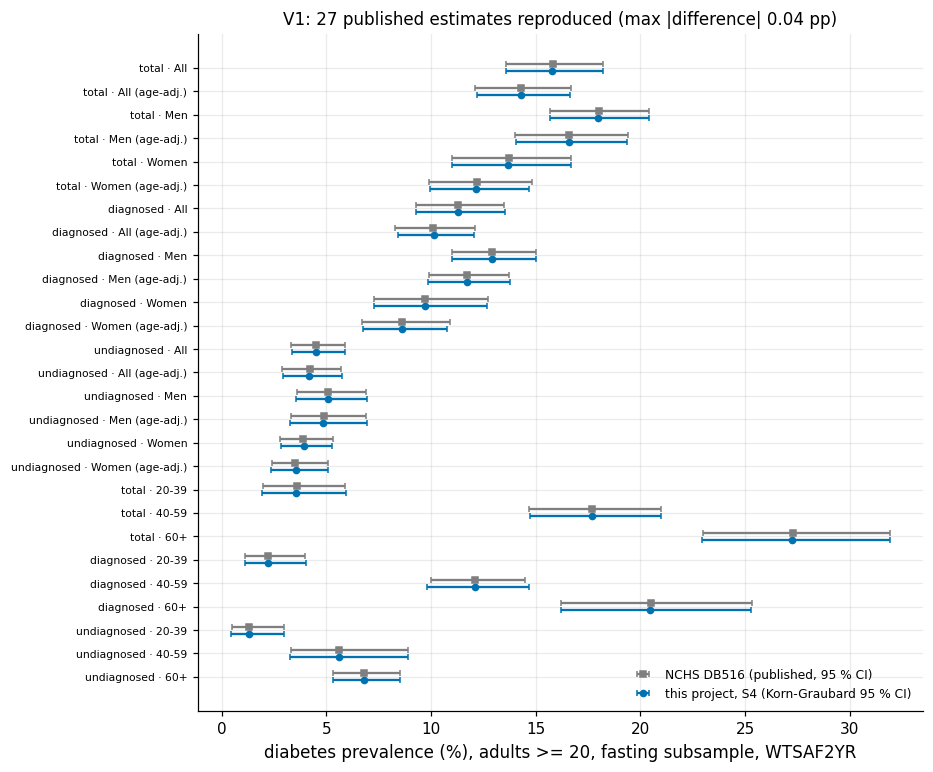

In [211]:
# External check V1: display the stored replication of the published NCHS Data Brief 516 estimates. Reads
# results/S4/db516_replication.csv (not recomputed here); asserts the three headline prevalences.
db = pd.read_csv(C.RESULTS_DIR / "S4" / "db516_replication.csv")
S4m = R.load_section("S4")["db516"]
db["label"] = db["measure"] + " · " + db["group"] + np.where(db["kind"] == "age-adj", " (age-adj.)", "")
print(f"{len(db)} published estimates; max |ours - NCHS| = {db['diff_pp'].abs().max():.3f} pp; "
      f"our KG interval matches the published one (to 0.1 pp) in {int(db['kg_matches_nchs_ci'].sum())}/{len(db)}; "
      f"intervals overlap in {int(db['ci_overlap'].sum())}/{len(db)}")
print(f"headline: total {S4m['total']:.2f} % (NCHS 15.8), diagnosed {S4m['diagnosed']:.2f} % (11.3), undiagnosed {S4m['undiagnosed']:.2f} % (4.5); n = {S4m['n']:,}")
# Published headline values (total 15.8 %, diagnosed 11.3 %, undiagnosed 4.5 %); 0.05 pp is half the rounding
# unit of the published figures.
assert abs(S4m["total"] - 15.8) < 0.05 and abs(S4m["diagnosed"] - 11.3) < 0.05 and abs(S4m["undiagnosed"] - 4.5) < 0.05

# Forest plot: the published NCHS interval (grey) beside our Korn-Graubard interval (blue) for each estimate.
fig, ax = plt.subplots(figsize=(8.5, 8))
# Two series per row, offset by -0.15 / +0.15 so that the two intervals do not overlap.
yy_ = np.arange(len(db))
ax.errorbar(db["nchs"], yy_ - 0.15, xerr=[db["nchs"] - db["nchs_low"], db["nchs_high"] - db["nchs"]], fmt="s", color=OI["grey"],
            capsize=2, ms=4, label="NCHS DB516 (published, 95 % CI)")
ax.errorbar(db["est"], yy_ + 0.15, xerr=[db["est"] - db["kg_low"], db["kg_high"] - db["est"]], fmt="o", color=OI["blue"],
            capsize=2, ms=4, label="this project, S4 (Korn-Graubard 95 % CI)")
ax.set_yticks(yy_, db["label"], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("diabetes prevalence (%), adults >= 20, fasting subsample, WTSAF2YR")
ax.legend(fontsize=8, loc="lower right")
ax.set_title(f"V1: 27 published estimates reproduced (max |difference| {db['diff_pp'].abs().max():.2f} pp)", fontsize=11)
plots.savefig(fig, "S9_db516_forest", caption="F9-4. NCHS Data Brief 516 prevalence estimates (grey, published) and the S4 replication (blue, delete-one-PSU "
              "jackknife with Korn-Graubard intervals) for total, diagnosed and undiagnosed diabetes by sex and age, crude and age-adjusted. "
              "Source: results/S4/db516_replication.csv (not re-run in S9).")
plt.show()

**So what.** Every published estimate is reproduced to within 0.05 percentage points and every pair of intervals
overlaps: the data path is externally validated.

### 9.8.2 V2: why our prevalence is 14.0 % and not 15.8 %
**Why.** `L_comb` has a weighted prevalence of 14.0 % (WTPH2YR), below DB516's 15.8 %. The pre-registered explanation –
no fasting-glucose criterion, and the HbA1c sample instead of the fasting subsample – is decomposed with jackknife
intervals: (A) cohort, WTPH2YR → (B) fasting subsample, WTSAF2YR (sample effect) → (C) DB516 definition with fasting
glucose ≥ 126 mg/dL (definition effect).

In [212]:
# V2: split the gap between our prevalence of L_comb and the NCHS figure into a sample effect (HbA1c cohort ->
# fasting subsample) and a definition effect (adds fasting glucose >= 126 mg/dL). Intervals come from
# replicate weights (delete-one-PSU jackknife). Writes results/S9/v2_prevalence_gap.csv.
cohort_all = ctx.clean.copy()
# Mask of the fasting subsample, the only rows where the fasting-glucose label SL5 is defined.
fm = L.fasting_mask(cohort_all).to_numpy()
sl_all = L.sensitivity_labels(cohort_all)
# yA = L_comb; yC = SL5, the label with the NCHS fasting-glucose criterion (undefined outside the subsample,
# set to 0 here and masked out below).
yA = cohort_all["L_comb"].to_numpy(float)
yC = sl_all["SL5"].fillna(0).to_numpy(float)
# Replicate weights and jackknife factors for the two weight variables; the fasting weight is zeroed outside
# the subsample.
Wph, fac = sv.replicate_weights(cohort_all, C.WEIGHT_PHLEB)
Wsa, fac2 = sv.replicate_weights(cohort_all, cohort_all[C.WEIGHT_FASTING].fillna(0).to_numpy() * fm)
# Both weights share the survey design, so their jackknife factors must be identical.
assert np.allclose(fac, fac2)

# Weighted prevalence of y among the rows in mask m (all rows if None).
def _prev(y_, w_, m_=None):
    m_ = np.ones(len(y_), bool) if m_ is None else m_
    return (w_[m_] * y_[m_]).sum() / w_[m_].sum()

# A = cohort (WTPH2YR), B = fasting subsample with the same label, C = fasting subsample with the NCHS-style
# label. Returns [A, B, C, B - A, C - B, C - A].
def _abc(wph, wsa):
    a = _prev(yA, wph)
    b = _prev(yA, wsa, fm)
    c = _prev(yC, wsa, fm)
    return np.array([a, b, c, b - a, c - b, c - a])

w_ph = np.nan_to_num(cohort_all[C.WEIGHT_PHLEB].to_numpy(float))
w_sa = np.nan_to_num(cohort_all[C.WEIGHT_FASTING].to_numpy(float)) * fm
est_ = _abc(w_ph, w_sa)
# Recompute all quantities under each set of replicate weights.
reps_ = np.array([_abc(Wph[:, r], Wsa[:, r]) for r in range(Wph.shape[1])])
# Jackknife variance = sum over replicates of factor * (replicate estimate - full estimate)^2.
se_ = np.sqrt(np.tensordot(fac, (reps_ - est_) ** 2, axes=(0, 0)))
# t quantile with the design degrees of freedom (PSUs - strata) for the 95 % intervals.
tcrit = stats.t.ppf(0.975, sv.design_df(cohort_all))
v2 = pd.DataFrame({"quantity": ["A L_comb, cohort, WTPH2YR", "B L_comb, fasting subsample, WTSAF2YR",
                                "C DB516 definition (+ FPG >= 126), fasting subsample", "sample effect B - A",
                                "definition effect C - B", "total C - A"],
                   "est_pct": est_ * 100, "ci_low": (est_ - tcrit * se_) * 100, "ci_high": (est_ + tcrit * se_) * 100})
# People who are positive only through fasting glucose (SL5 = 1 but L_comb = 0).
fpg_only = int(((sl_all["SL5"] == 1) & (cohort_all["L_comb"] == 0)).sum())
v2.to_csv(OUT / "v2_prevalence_gap.csv", index=False)
show(v2, 2)
print(f"fasting subsample n = {int(fm.sum()):,}; people positive only through fasting glucose: {fpg_only}")
# A must reproduce the 14.0 % of §1 (0.15 pp tolerance) and C the published total of §9.8.1 (0.01 pp).
assert abs(est_[0] - 0.140) < 0.0015 and abs(est_[2] * 100 - S4m["total"]) < 0.01

quantity,est_pct,ci_low,ci_high
"A L_comb, cohort, WTPH2YR",14.04,12.44,15.63
"B L_comb, fasting subsample, WTSAF2YR",13.86,11.65,16.08
"C DB516 definition (+ FPG >= 126), fasting subsample",15.79,13.53,18.04
sample effect B - A,-0.17,-1.66,1.32
definition effect C - B,1.92,1.37,2.48
total C - A,1.75,0.24,3.26


fasting subsample n = 2,938; people positive only through fasting glucose: 70


**So what.** The gap is almost entirely a **definition** effect: the sample effect is small, while adding the
fasting-glucose criterion lifts the prevalence to the DB516 value. 14.0 % is not a failed replication but a narrower
label that misses people whose only abnormal test is fasting glucose – why SL5 is a sensitivity label (§9.4).

### 9.8.3 ADA-lite vs Bang et al. 2009 (qualitative)
**Why.** The published ADA test is only a qualitative yardstick: ADA-lite lacks two of seven items, our outcome is
HbA1c-based and the population is 2021–23. Verified from the Bang et al. (2009) abstract: cut-off ≥ 5, sensitivity
79 %, specificity 67 %; circulating AUC values are not verified and not used.

In [213]:
# ADA-lite on the training-part E-SCREEN rows: sensitivity, specificity and share flagged at point cut-offs 3,
# 4 and 5, set beside the published figures of Bang et al. 2009 (qualitative only). Reads the baseline AUC
# stored by §7.
ada_tr = P.ada_lite_items(ctx.cl)
# ADA-lite point score of the E-SCREEN rows only.
sc_esc = ada_tr["ada_score"].to_numpy()[ctx.esc]
ye = ctx.y_esc[ctx.esc]
ada_rows = []
for cut in (3, 4, 5):
    # Flag everyone at or above the cut-off; sensitivity among positives, specificity among negatives.
    call = sc_esc >= cut
    ada_rows.append(dict(cutoff=f">= {cut}", sensitivity=call[ye == 1].mean(), specificity=(~call[ye == 0]).mean(),
                         share_flagged=call.mean()))
ada_tab = pd.DataFrame(ada_rows)
# AUC of the same score as stored by §7 (not recomputed here).
bl = S7m["baselines"]["BL-ADAlite (points)"]
print(f"ADA-lite (5 of 7 items, max 9 of 11 points) on training-part E-SCREEN: AUC {bl['escr_auc']:.3f} "
      f"[{bl['lo']:.3f}, {bl['hi']:.3f}], recall at specificity 0.80 {bl['escr_recall_spec80']:.3f} (S7)")
show(ada_tab, 3)
print("Bang et al. 2009 (abstract): cut-off >= 5 of 11 points, sensitivity 0.79, specificity 0.67; AUC: not verified")
S9["external"] = dict(db516=dict(n_estimates=len(db), max_abs_diff_pp=float(db["diff_pp"].abs().max()),
                                 kg_matches=int(db["kg_matches_nchs_ci"].sum()), ci_overlap=int(db["ci_overlap"].sum())),
                      v2=v2.round(4).to_dict("records"), fpg_only_positives=fpg_only,
                      ada_lite=dict(escr_auc=bl["escr_auc"], lo=bl["lo"], hi=bl["hi"], cutoffs=ada_tab.round(4).to_dict("records"),
                                    bang_2009_abstract="cut-off >= 5: sensitivity 0.79, specificity 0.67; AUC unverified"))

ADA-lite (5 of 7 items, max 9 of 11 points) on training-part E-SCREEN: AUC 0.726 [0.681, 0.764], recall at specificity 0.80 0.244 (S7)


cutoff,sensitivity,specificity,share_flagged
>= 3,0.961,0.271,0.736
>= 4,0.835,0.444,0.565
>= 5,0.701,0.622,0.388


Bang et al. 2009 (abstract): cut-off >= 5 of 11 points, sensitivity 0.79, specificity 0.67; AUC: not verified


**So what.** At cut-off ≥ 5 ADA-lite reaches about 0.70 sensitivity at 0.62 specificity, below Bang's 0.79 / 0.67, as
expected with two items missing. It is a fair but conservative comparator, so S's §7 margin over it is likely
overstated (limitation L06).

## 9.9 Leak hunt
**Why.** The permutation test cannot see feature leakage, and the availability rule was applied from the
specification, not from the data. The leak hunt asks the data whether an *admissible* feature behaves like a disguised
label. Pre-registered triggers (M1 and S; age exempt): E-ALL AUC > 0.90; a single admissible feature with AUC > 0.75;
permutation failure; unstable coefficients. Exit: all top-10 features of S pass the availability proof and the
permutation test passes; at most two rounds. The non-admissible M0 columns are scanned too, to show that the scans
*can* find leakage.

In [214]:
# Leak hunt, single-feature scan: score every column of the naive M0 frame (plus the derived S columns) with a
# univariate AUC and flag admissible features above the trigger. Writes
# results/S9/leak_single_feature_auc.csv.
spec_v = P._spec_by_var()
# Columns that the variable specification admits at Tier 1 and at Tier 2.
adm1, adm2 = set(P.admissible_columns(1)), set(P.admissible_columns(2))
cats = set(P.categorical_columns())
# scan frame: per-variable-clean values of every M0 column + the derived S columns (BP means, weekly activity minutes)
raw_cols = [c for c in P.raw_feature_frame(ctx.raw_tr, 2).columns]
scan_df = ctx.cl[[c for c in raw_cols if c in ctx.cl.columns]].copy()
for c in ("bp_sys_mean", "bp_dia_mean", "pulse_mean", "pa_mod_min_wk", "pa_vig_min_wk"):
    scan_df[c] = pre_frame[c].to_numpy()

# Admissibility of a column; a derived column inherits the status of its source variables (all must be
# admissible).
def status(v):
    src = RB.DERIVED_SOURCES.get(v, (v,))
    if all(s in adm1 for s in src):
        return "admissible T1"
    if all(s in adm2 for s in src):
        return "admissible T2"
    return f"not admissible ({spec_v['role'].get(src[0], 'derived')})"

# Univariate AUC on E-ALL. Numeric columns by rank; categorical ones by out-of-fold target encoding, so the
# encoding never sees the labels it is scored on. auc_oriented = max(AUC, 1 - AUC): a strongly inverse feature
# counts as well.
single = RB.single_feature_scan(scan_df, ctx.y, ctx.folds, cat_cols=cats)
# The same scan on E-SCREEN only, to see whether a feature's signal comes from known diagnoses.
single_e = RB.single_feature_scan(scan_df, ctx.y_esc, ctx.folds, cat_cols=cats, mask=ctx.esc)
single = single.merge(single_e[["variable", "auc_oriented"]].rename(columns={"auc_oriented": "auc_escreen"}), on="variable")
single["status"] = single["variable"].map(status)
single["admissible"] = single["status"].str.startswith("admissible")
# Trigger: admissible, above the 0.75 threshold and not age (age is exempt, a legitimate strong predictor).
single["trigger"] = single["admissible"] & (single["auc_oriented"] > RB.L3_SINGLE_FEATURE_AUC) & ~single["variable"].isin(RB.AGE_EXEMPT)
single.to_csv(OUT / "leak_single_feature_auc.csv", index=False)
show(single.head(25)[["variable", "status", "kind", "coverage", "auc_oriented", "auc_escreen", "trigger"]], 3)
print(f"admissible features above {RB.L3_SINGLE_FEATURE_AUC} (age exempt): {single.loc[single['trigger'], 'variable'].tolist()}")
print(f"non-admissible M0 columns above {RB.L3_SINGLE_FEATURE_AUC}: "
      f"{single.loc[~single['admissible'] & (single['auc_oriented'] > RB.L3_SINGLE_FEATURE_AUC), 'variable'].tolist()}")
# The table is sorted by AUC, so the first admissible row is the strongest admissible feature.
best_adm = single[single["admissible"]].iloc[0]
print(f"strongest admissible feature: {best_adm['variable']} AUC {best_adm['auc_oriented']:.3f}")

variable,status,kind,coverage,auc_oriented,auc_escreen,trigger
DIQ160,not admissible (leak),categorical (OOF target encoding),1.000,0.930,0.657,False
DIQ070,not admissible (leak),categorical (OOF target encoding),1.000,0.920,0.653,False
DIQ050,not admissible (leak),categorical (OOF target encoding),1.000,0.917,0.505,False
DIQ180,not admissible (leak),categorical (OOF target encoding),1.000,0.912,0.586,False
LBXGLU,not admissible (leak),numeric,0.555,0.895,0.934,False
BMXWAIST,admissible T1,numeric,0.955,0.706,0.734,False
BPQ020,admissible T1,categorical (OOF target encoding),1.000,0.671,0.580,False
LBDLDL,not admissible (side),numeric,0.527,0.668,0.517,False
BMXBMI,admissible T1,numeric,0.986,0.668,0.708,False
RIDAGEYR,admissible T1,numeric,1.000,0.666,0.634,False


admissible features above 0.75 (age exempt): []
non-admissible M0 columns above 0.75: ['DIQ160', 'DIQ070', 'DIQ050', 'DIQ180', 'LBXGLU']
strongest admissible feature: BMXWAIST AUC 0.706


In [215]:
# Leak hunt, missing-indicator scan: AUC of 'is missing' for every column with partial missingness. A skip
# pattern that tracks the label would show up here. Writes results/S9/leak_missing_indicator_auc.csv.
miss_scan = RB.missing_indicator_scan(scan_df, ctx.y)
miss_scan["status"] = miss_scan["variable"].map(status)
miss_scan["admissible"] = miss_scan["status"].str.startswith("admissible")
miss_scan["trigger"] = miss_scan["admissible"] & (miss_scan["auc_oriented"] > RB.L3_SINGLE_FEATURE_AUC)
miss_scan.to_csv(OUT / "leak_missing_indicator_auc.csv", index=False)
show(miss_scan.head(12)[["variable", "status", "n_missing", "prev_if_missing", "prev_if_present", "auc_oriented", "trigger"]], 3)
print(f"admissible is_missing indicators above {RB.L3_SINGLE_FEATURE_AUC}: {miss_scan.loc[miss_scan['trigger'], 'variable'].tolist()}; "
      f"largest admissible: {miss_scan[miss_scan['admissible']].iloc[0]['variable']} "
      f"{miss_scan[miss_scan['admissible']].iloc[0]['auc_oriented']:.3f}")

variable,status,n_missing,prev_if_missing,prev_if_present,auc_oriented,trigger
DIQ160,not admissible (leak),831,0.819,0.026,0.919,False
DIQ050,not admissible (leak),3934,0.032,1.000,0.918,False
DID040,not admissible (leak),3945,0.035,1.000,0.911,False
DIQ180,not admissible (leak),793,0.822,0.033,0.901,False
DIQ070,not admissible (leak),3202,0.018,0.520,0.875,False
DID060,not admissible (leak),4376,0.130,1.000,0.634,False
DIQ060U,not admissible (leak),4377,0.130,1.000,0.633,False
PAD820,admissible T1,2584,0.228,0.094,0.617,False
PAD810U,admissible T1,2578,0.228,0.095,0.616,False
PAD800,admissible T1,974,0.271,0.142,0.577,False


admissible is_missing indicators above 0.75: []; largest admissible: PAD820 0.617


In [216]:
# Leak hunt, depth-1 trees: a single-split tree per arm shows which variable the arm relies on most. Writes
# results/S9/leak_depth1_tree.csv; the root of M1 and S must be an admissible variable.
d1 = {}
for arm in ("M0", "M1", "S"):
    sp = Spec(arm, model="tree", depth=1)
    # Root variable of every fold fit; fold -1 is the fit on the whole training part ('__none__' tracks no
    # feature).
    tf = RB.tree_features_used(ctx, sp, ctx.folds, "__none__")
    oof1 = RB.run_many(ctx, {"t": sp}, n_jobs=N_JOBS, cache=RUNS)["t"]
    d1[arm] = dict(root_full_fit=tf.loc[tf["fold"] == -1, "root"].iloc[0], roots_in_folds=tf.loc[tf["fold"] >= 0, "root"].value_counts().to_dict(),
                   oof_auc_eall=roc_auc_score(ctx.y, ek.mean_oof(oof1, ctx.n)),
                   oof_auc_escreen=roc_auc_score(ctx.y_esc[ctx.esc], ek.mean_oof(oof1, ctx.n)[ctx.esc]))
d1_tab = pd.DataFrame(d1).T
# Map the root column back to its source variable, then classify it as admissible or not.
d1_tab["root_variable"] = d1_tab["root_full_fit"].map(RB.base_variable)
d1_tab["root_status"] = d1_tab["root_variable"].map(status)
d1_tab.to_csv(OUT / "leak_depth1_tree.csv")
display(d1_tab)

,root_full_fit,roots_in_folds,oof_auc_eall,oof_auc_escreen,root_variable,root_status
M0,DIQ070_2.0,{'DIQ070_2.0': 25},0.796572,0.564676,DIQ070,not admissible (leak)
M1,BPQ020_2.0,{'BPQ020_2.0': 25},0.663589,0.570412,BPQ020,admissible T1
S,BPQ020_1.0,"{'BPQ020_2.0': 19, 'BPQ020_1.0': 6}",0.667057,0.578739,BPQ020,admissible T1


**So what (scans).** The scans work – among the non-admissible M0 columns they flag treatment and diagnosis-history
items far above 0.75 – and find nothing among the admissible ones: the strongest admissible feature stays below
0.75, admissible `is_missing` indicators are close to 0.5, and the depth-1 trees of M1 and S split on admissible items.

In [217]:
# Leak hunt, importance and care-contact checks: availability proof for the ten most important features of S
# (each tier), effect of removing the care-contact items, and stability of the coefficients. Writes
# results/S9/leak_top10_availability.csv.
pipe_S = {t: RB.fit_full(ctx, Spec("S", tier=t)) for t in (1, 2)}
# Importance = standard deviation of each variable's contribution to the linear predictor (`sd_contribution`).
imp = {t: RB.contribution_importance(pipe_S[t], ctx.X[t]) for t in (1, 2)}
proof = []
for t in (1, 2):
    top = imp[t].head(10).copy()
    # For each top variable: its sources, the instrument that measures it, admissibility and care-contact
    # flag, and a PASS / FAIL verdict on whether it is available at the screening moment.
    pf = RB.availability_proof(top["variable"], tier=t)
    proof.append(top.merge(pf, on="variable").assign(tier=t))
proof = pd.concat(proof, ignore_index=True)
proof.to_csv(OUT / "leak_top10_availability.csv", index=False)
show(proof[["tier", "variable", "sd_contribution", "sources", "instrument", "admissible", "care_contact", "verdict"]], 3)
top_pass = bool((proof["verdict"] == "PASS").all())
print(f"top-10 availability proof: {'all PASS' if top_pass else 'FAIL: ' + str(proof.loc[proof['verdict'] != 'PASS', 'variable'].tolist())}")

# Remove the care-contact items (BPQ020, BPQ080): T1-minus-care - S. Informative only; it does not trigger a
# leak-hunt round.
care = pair(Spec("T1-minus-care"), Spec("S"), tag="minus-care")
care_items = single.set_index("variable").loc[list(P.CARE_ITEMS), ["auc_oriented", "auc_escreen"]]
print("T1-minus-care - S: " + "; ".join(f"{r['pop']} {r['est']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]" for r in care))
display("care-contact items, single-feature AUC (E-ALL vs E-SCREEN):"); print(care_items.round(3))

# Coefficient bootstrap of S taken from the noise-feature run (noise column removed).
cbS = NOISE_CB["S"].summary.drop(index="noise_n01")
# Unstable coefficient: interval excludes 0 but the sign flips in more than 10 % of the bootstrap refits.
unstable = cbS[(cbS["ci_excludes_0"]) & (cbS["sign_flip_rate"] > 0.10)]
print(f"coefficients of S whose CI excludes 0 but flip sign in > 10 % of {B_COEF9} refits: {len(unstable)}; "
      f"max flip rate among CI-excluding-0 coefficients {cbS.loc[cbS['ci_excludes_0'], 'sign_flip_rate'].max():.3f}")

tier,variable,sd_contribution,sources,instrument,admissible,care_contact,verdict
1,BMXHIP,0.815,BMXHIP,MEC body measures (tape / scale),T1,False,PASS
1,BMXBMI,0.741,BMXBMI,MEC body measures (tape / scale),T1,False,PASS
1,RIDAGEYR,0.699,RIDAGEYR,household interview (demographics),T1,False,PASS
1,pulse_mean,0.685,"BPXOPLS1,BPXOPLS2,BPXOPLS3",MEC oscillometric blood pressure,T1,False,PASS
1,BMXWAIST,0.633,BMXWAIST,MEC body measures (tape / scale),T1,False,PASS
1,bp_dia_mean,0.581,"BPXODI1,BPXODI2,BPXODI3",MEC oscillometric blood pressure,T1,False,PASS
1,bp_sys_mean,0.445,"BPXOSY1,BPXOSY2,BPXOSY3",MEC oscillometric blood pressure,T1,False,PASS
1,BPQ080,0.399,BPQ080,interview questionnaire (blood pressure & cholesterol),T1,True,PASS
1,BPQ020,0.352,BPQ020,interview questionnaire (blood pressure & cholesterol),T1,True,PASS
1,INDFMPIR,0.260,INDFMPIR,household interview (demographics),T1,False,PASS


top-10 availability proof: all PASS


T1-minus-care - S: E-ALL -0.0157 [-0.0221, -0.0093]; E-SCREEN +0.0192 [+0.0040, +0.0344]


'care-contact items, single-feature AUC (E-ALL vs E-SCREEN):'

          auc_oriented  auc_escreen
variable                           
BPQ020           0.671        0.580
BPQ080           0.657        0.547
coefficients of S whose CI excludes 0 but flip sign in > 10 % of 500 refits: 0; max flip rate among CI-excluding-0 coefficients 0.022


In [218]:
# Leak-hunt log: one row per pre-registered trigger with its value and whether it fired (triggered = True is a
# failed check and would start another round). Writes results/S9/leak_hunt_log.csv.
t1_auc = {a: S9["reference"]["E-ALL"]["auc_a" if a == "S" else "auc_b"] for a in ("S", "M1")}
log = pd.DataFrame([
    dict(check="T1 E-ALL AUC > 0.90 (M1, S)", value=f"M1 {t1_auc['M1']:.3f}, S {t1_auc['S']:.3f}", triggered=max(t1_auc.values()) > RB.L3_T1_EALL_AUC),
    dict(check="admissible single feature AUC > 0.75 (age exempt)", value=f"max {single.loc[single['admissible'] & ~single['variable'].isin(RB.AGE_EXEMPT), 'auc_oriented'].max():.3f} "
         f"({single.loc[single['admissible'] & ~single['variable'].isin(RB.AGE_EXEMPT)].iloc[0]['variable']})", triggered=bool(single["trigger"].any())),
    dict(check="admissible is_missing indicator AUC > 0.75", value=f"max {miss_scan.loc[miss_scan['admissible'], 'auc_oriented'].max():.3f}",
         triggered=bool(miss_scan["trigger"].any())),
    dict(check="depth-1 tree root of M1 / S admissible", value=f"M1 {d1_tab.loc['M1', 'root_variable']}, S {d1_tab.loc['S', 'root_variable']}",
         triggered=not (d1_tab.loc[["M1", "S"], "root_status"].str.startswith("admissible").all())),
    dict(check="permutation null mean in [0.495, 0.505] (M1, S)", value=", ".join(f"{a} {d['null_mean']:.4f}" for a, d in PERM.items()),
         triggered=not perm_tab["in_band"].all()),
    dict(check="coefficient instability (CI excludes 0 and > 10 % sign flips, S)", value=f"{len(unstable)} coefficients", triggered=len(unstable) > 0),
    dict(check="top-10 features of S (T1, T2) pass the availability proof", value=f"{int((proof['verdict'] == 'PASS').sum())}/{len(proof)} PASS",
         triggered=not top_pass),
    dict(check="T1-minus-care vs S (informative, no trigger)", value="; ".join(f"{r['pop']} {r['est']:+.3f}" for r in care), triggered=False),
])
# Action column: any fired trigger sends the work back to re-examine the feature.
log["action"] = np.where(log["triggered"], "leak-hunt round: re-examine feature, back to §6/§7", "none")
log.to_csv(OUT / "leak_hunt_log.csv", index=False)
show(log)
L3_TRIGGERED = bool(log["triggered"].any())
print(f"leak hunt triggered: {L3_TRIGGERED} -> {'rounds needed' if L3_TRIGGERED else 'exit condition met in round 0 (no re-run of §7)'}")
S9["leak_hunt"] = dict(triggered=L3_TRIGGERED, log=log.to_dict("records"), top10=proof[["tier", "variable", "sd_contribution", "verdict"]].round(5).to_dict("records"),
                       depth1=d1_tab[["root_full_fit", "root_variable", "oof_auc_eall", "oof_auc_escreen"]].to_dict("index"),
                       strongest_admissible=dict(variable=best_adm["variable"], auc=best_adm["auc_oriented"]),
                       minus_care={r["pop"]: {k: r[k] for k in ("est", "lo", "hi")} for r in care})

check,value,triggered,action
"T1 E-ALL AUC > 0.90 (M1, S)","M1 0.828, S 0.836",False,none
admissible single feature AUC > 0.75 (age exempt),max 0.706 (BMXWAIST),False,none
admissible is_missing indicator AUC > 0.75,max 0.617,False,none
depth-1 tree root of M1 / S admissible,"M1 BPQ020, S BPQ020",False,none
"permutation null mean in [0.495, 0.505] (M1, S)","M1 0.5015, S 0.5014",False,none
"coefficient instability (CI excludes 0 and > 10 % sign flips, S)",0 coefficients,False,none
"top-10 features of S (T1, T2) pass the availability proof",20/20 PASS,False,none
"T1-minus-care vs S (informative, no trigger)",E-ALL -0.016; E-SCREEN +0.019,False,none


leak hunt triggered: False -> exit condition met in round 0 (no re-run of §7)


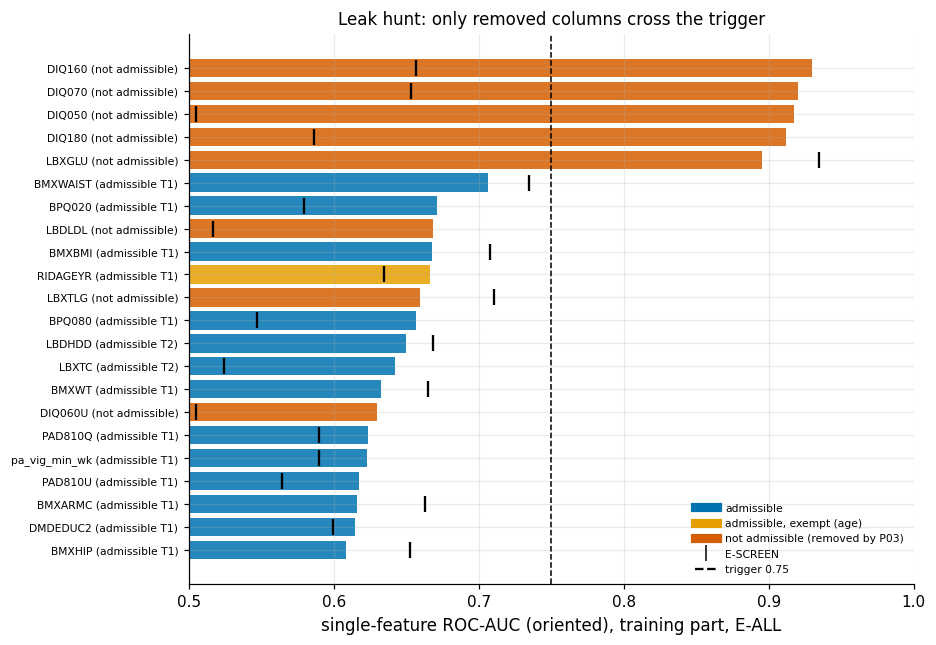

In [219]:
# Figure: the 22 strongest single-feature AUCs; reversed so that the strongest bar is drawn at the top.
top_scan = single.head(22).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6.5))
# Red = removed by the availability rule, orange = admissible but exempt (age), blue = admissible.
cols_ = [OI["vermillion"] if not a else (OI["orange"] if v in RB.AGE_EXEMPT else OI["blue"]) for a, v in zip(top_scan["admissible"], top_scan["variable"])]
ax.barh(range(len(top_scan)), top_scan["auc_oriented"], color=cols_, alpha=0.85)
ax.scatter(top_scan["auc_escreen"], range(len(top_scan)), marker="|", s=120, color="k", label="same feature on E-SCREEN", zorder=3)
ax.axvline(RB.L3_SINGLE_FEATURE_AUC, color="k", ls="--", lw=1, label="L3 trigger 0.75")
ax.set_yticks(range(len(top_scan)), [f"{v} ({s.split(' (')[0]})" for v, s in zip(top_scan["variable"], top_scan["status"])], fontsize=7)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("single-feature ROC-AUC (oriented), training part, E-ALL")
ax.legend(handles=[Line2D([], [], color=OI["blue"], lw=6, label="admissible"), Line2D([], [], color=OI["orange"], lw=6, label="admissible, exempt (age)"),
                   Line2D([], [], color=OI["vermillion"], lw=6, label="not admissible (removed by P03)"),
                   Line2D([], [], color="k", marker="|", ls="", ms=10, label="E-SCREEN"),
                   Line2D([], [], color="k", ls="--", label="trigger 0.75")], fontsize=7, loc="lower right")
ax.set_title("Leak hunt: only removed columns cross the trigger", fontsize=11)
plots.savefig(fig, "S9_single_feature_auc", caption="F9-5. Univariate ROC-AUC of the 22 strongest columns of the naive M0 frame (plus derived S columns), "
              "training part, E-ALL (bars) and E-SCREEN (ticks). Categorical items use out-of-fold target encoding. Red = removed by the "
              "availability rule; blue = admissible; dashed = L3 trigger 0.75 (age exempt).")
plt.show()

**So what.** The leak hunt is **not triggered**: the admissible arms stay far below 0.90, no admissible feature except
the exempt age exceeds 0.75, and each of the ten most important features of S (Tier 1 and 2) passes the point-of-care
availability proof. The exit condition is met in round 0, so §7 is not re-run. One caveat survives: "told high blood
pressure" and "told high cholesterol" are **care-contact traces** – admissible, but more informative for people
already in care; removing them costs AUC on E-ALL but not on E-SCREEN. That is the mechanism of H2c, not leakage.

## 9.10 Pre-hold-out summary
**Why.** Before the freeze, every robustness result for S − M1 is put on one scale, so that the robustness grade of the
claim (§10.7) can be read off one table and one figure.

check,pop,est_min,est_max,lo,hi,verdicts
reference (stored folds),E-ALL,0.0079,0.0079,0.0000,0.0158,inconclusive
10 CV seeds,E-ALL,0.0058,0.0078,-0.0018,0.0155,inconclusive 10
16 sensitivity specs,E-ALL,-0.0061,0.0116,-0.0233,0.0230,inconclusive 16
60-spec curve,E-ALL,0.0048,0.0182,-0.0046,0.0266,inconclusive 60
strata x PSU grouped CV,E-ALL,0.0055,0.0055,-0.0001,0.0118,inconclusive 1
IPW (evaluation; fit + evaluation),E-ALL,0.0072,0.0079,-0.0009,0.0158,inconclusive 2
MNAR delta -1 to 3 (draw means),E-ALL,0.0075,0.0078,0.0059,0.0092,n/a (no CI)
reference (stored folds),E-SCREEN,0.0085,0.0085,-0.0081,0.0236,inconclusive
10 CV seeds,E-SCREEN,0.0062,0.0104,-0.0090,0.0248,inconclusive 10
16 sensitivity specs,E-SCREEN,-0.0119,0.0204,-0.0389,0.0407,inconclusive 16


E-ALL: 89 alternative comparisons with a CI -> verdicts {'inconclusive': 89}
E-SCREEN: 89 alternative comparisons with a CI -> verdicts {'inconclusive': 89}


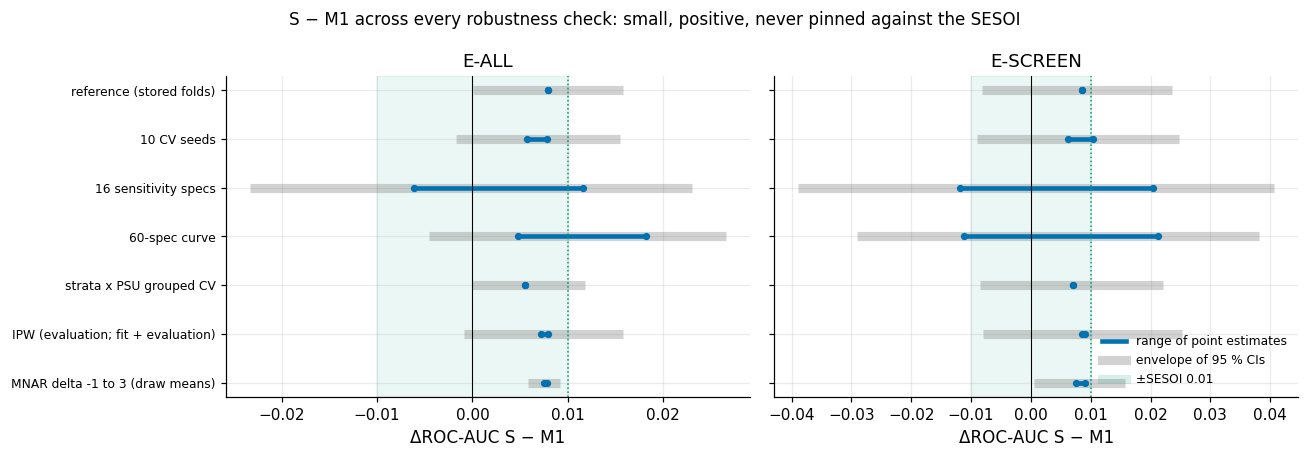

In [220]:
# Pre-hold-out summary: put every robustness family on one scale (range of the S - M1 point estimates and the
# envelope of the intervals). Reads the tables above; writes results/S9/robustness_summary.csv. Returns (min
# estimate, max estimate, lowest lower bound, highest upper bound, verdict counts) of one family.
def _rng(d, pop):
    x = d[d["pop"] == pop]
    return x["est"].min(), x["est"].max(), x["lo"].min(), x["hi"].max(), ", ".join(f"{k} {v}" for k, v in x["h2b"].value_counts().items())

summ = []
for pop in ("E-ALL", "E-SCREEN"):
    r0 = S9["reference"][pop]
    summ.append(dict(check="reference (stored folds)", pop=pop, est_min=r0["est"], est_max=r0["est"], lo=r0["lo"], hi=r0["hi"], verdicts=r0["h2b"]))
    for nm, d in ((f"{len(SEED_FOLDS)} CV seeds", seeds), (f"{len(SENS)} sensitivity specs", sens[sens["spec"] != "reference (S7)"]),
                  (f"{len(grid)}-spec curve", curve), ("strata x PSU grouped CV", gcv_tab[gcv_tab["folds"] != "stored stratified"]),
                  ("IPW (evaluation; fit + evaluation)", ipw_tab)):
        a, b, lo, hi, v = _rng(d, pop)
        summ.append(dict(check=nm, pop=pop, est_min=a, est_max=b, lo=lo, hi=hi, verdicts=v))
    dd = dauc[(dauc["pop"] == pop) & (dauc["scenario"] == "delta")]
    summ.append(dict(check="MNAR delta -1 to 3 (draw means)", pop=pop, est_min=dd["diff"].min(), est_max=dd["diff"].max(),
                     lo=dd["diff_lo"].min(), hi=dd["diff_hi"].max(), verdicts="n/a (no CI)"))
summ = pd.DataFrame(summ)
summ.to_csv(OUT / "robustness_summary.csv", index=False)
show(summ, 4)
# All verdicts of the alternative comparisons that come with an interval (seeds, sensitivity, curve, grouped
# CV, IPW); the MNAR draws have no interval and are left out.
fam_v = {pop: pd.concat([seeds.loc[seeds["pop"] == pop, "h2b"], sens.loc[(sens["pop"] == pop) & (sens["spec"] != "reference (S7)"), "h2b"],
                         curve.loc[curve["pop"] == pop, "h2b"], gcv_tab.loc[(gcv_tab["pop"] == pop) & (gcv_tab["folds"] != "stored stratified"), "h2b"],
                         ipw_tab.loc[ipw_tab["pop"] == pop, "h2b"]]) for pop in ("E-ALL", "E-SCREEN")}
# True if every alternative comparison of a population is inconclusive.
all_incon = {pop: bool((v == "inconclusive").all()) for pop, v in fam_v.items()}
for pop, v in fam_v.items():
    print(f"{pop}: {len(v)} alternative comparisons with a CI -> verdicts {v.value_counts().to_dict()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    s = summ[summ["pop"] == pop].reset_index(drop=True)
    for i, r in s.iterrows():
        ax.plot([r["lo"], r["hi"]], [i, i], color=OI["grey"], lw=6, alpha=0.35, solid_capstyle="butt")
        ax.plot([r["est_min"], r["est_max"]], [i, i], color=OI["blue"], lw=3)
        ax.scatter([r["est_min"], r["est_max"]], [i, i], color=OI["blue"], s=14, zorder=3)
    ax.axvspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["green"], alpha=0.08)
    ax.axvline(0, color="k", lw=0.7)
    ax.axvline(C.SESOI["roc_auc"], color=OI["green"], ls=":", lw=1)
    ax.set(title=pop, xlabel="ΔROC-AUC S − M1")
axes[0].set_yticks(range(len(s)), s["check"], fontsize=8)
axes[0].invert_yaxis()
axes[1].legend(handles=[Line2D([], [], color=OI["blue"], lw=3, label="range of point estimates"),
                        Line2D([], [], color=OI["grey"], lw=6, alpha=0.35, label="envelope of 95 % CIs"),
                        Line2D([], [], color=OI["green"], lw=6, alpha=0.15, label="±SESOI 0.01")], fontsize=8, loc="lower right")
fig.suptitle("S − M1 across every robustness check: small, positive, never pinned against the SESOI", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S9_robustness_summary", caption="Range of ΔROC-AUC (S − M1) point estimates (blue) and envelope of the 95 % CIs (grey) for each "
              f"family of robustness checks: stored folds, {len(SEED_FOLDS)} CV seeds, {len(SENS)} one-at-a-time specifications, {len(grid)}-specification curve, "
              "strata x PSU grouped CV, inverse-probability weighting and MNAR delta adjustment; E-ALL left, E-SCREEN right.")
plt.show()
S9["summary"] = dict(table=summ.round(5).to_dict("records"), all_inconclusive=all_incon)

**So what – controls and stability (§9.2–§9.7).** The procedure is neither optimistic nor blind: permutation nulls
centre on 0.5, the noise column is ignored (interval covers 0, no tree split) and the AUC-0.60 control is recovered and
detected (only a few thousandths of AUC on top of age, adiposity and blood pressure). For S − M1 every check agrees:
ten seeds move the estimate only in the third decimal; all 60 curve specifications put S ahead, none clears or sits
inside ±0.01; PSU-grouped folds change the AUC of S by a few thousandths; IPW and MNAR leave it unchanged. On E-ALL
S leads by roughly 0.005–0.015 and, apart from the depth-4 tree (DR-S9-13), no interval falls below about −0.01. The
robust reading of H2b(a) is "**S is at least as good as M1 and probably slightly better, by an amount that cannot be
distinguished from 0.01**" – *robust verdict, imprecise effect*; on E-SCREEN intervals are about twice as wide.

In [221]:
# decision-register rows of §9 (written and listed in §9.13 Outputs)
# Build the §9 rows of the decision register from the numbers computed above (nothing is typed in by hand).
# The file itself is written in §9.13, and only in FINAL mode.
from datetime import date
today = date.today().isoformat()
# Format a comparison row as 'est [lo, hi]' with k decimals.
def _f(r, k=3):
    return f"{r['est']:+.{k}f} [{r['lo']:+.{k}f}, {r['hi']:+.{k}f}]"

pc = pos_tab.set_index(["arm", "pop"])
reg = pd.DataFrame([
    dict(dr_id="DR-S9-01", type="negative_control", finding="Label-permutation null centred on 0.5 for both admissible arms; tests procedural leakage only",
         evidence_ref="results/S9/permutation.csv; figures/S9_permutation_null.png",
         evidence_value=f"null mean M1 {PERM['M1']['null_mean']:.4f}, S {PERM['S']['null_mean']:.4f} ({C.N_PERM} permutations); p = {PERM['S']['p_value']:.3f}",
         decision="Evaluation procedure accepted; feature leakage delegated to the L3 leak hunt", alternatives_rejected="sklearn permutation_test_score (no sample weights per fold, no fixed folds)",
         hyp_id="", status="decided", check_verdict="PASS", check_note="band [0.495, 0.505]", loop_ref="leak hunt §9.9"),
    dict(dr_id="DR-S9-02", type="negative_control", finding="An N(0,1) noise column is treated as noise",
         evidence_ref="results/S9/noise_feature.csv",
         evidence_value="; ".join(f"{r['arm']}: coef/SD {r['coef_per_sd']:+.3f} [{r['q_low']:+.3f}, {r['q_high']:+.3f}], dAUC {r['dAUC_eall']:+.4f}, depth-3 trees using it {r['tree3_uses']}/{r['n_trees']}" for _, r in noise_tab.iterrows()),
         decision="No overfitting to noise; depth cap 3 for the tree probe retained", alternatives_rejected="", hyp_id="", status="decided",
         check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-03", type="positive_control", finding="A synthetic feature with known AUC 0.60 is recovered and detected",
         evidence_ref="results/S9/positive_control.csv",
         evidence_value=f"z AUC {z_auc[0]:.3f} [{z_auc[1]:.3f}, {z_auc[2]:.3f}]; dAUC E-ALL M1 {pc.loc[('M1', 'E-ALL'), 'est']:+.4f} [{pc.loc[('M1', 'E-ALL'), 'lo']:+.4f}, {pc.loc[('M1', 'E-ALL'), 'hi']:+.4f}], S {pc.loc[('S', 'E-ALL'), 'est']:+.4f} [{pc.loc[('S', 'E-ALL'), 'lo']:+.4f}, {pc.loc[('S', 'E-ALL'), 'hi']:+.4f}]",
         decision="Procedure has power for weak real signals; negative controls are not passed by blindness", alternatives_rejected="",
         hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-04", type="seed_stability", finding="S - M1 verdict does not depend on the CV / bootstrap seed",
         evidence_ref="results/S9/seed_stability.csv; figures/S9_seed_stability.png",
         evidence_value=f"E-ALL est {seed_sum.loc['E-ALL', 'est_min']:+.4f} to {seed_sum.loc['E-ALL', 'est_max']:+.4f}; verdicts {seed_sum.loc['E-ALL', 'verdicts']}",
         decision="H2b(a) verdict graded seed-stable", alternatives_rejected="single seed", hyp_id="H2b", status="decided",
         check_verdict="PASS" if seed_stable else "FAIL", check_note="10 seeds via evalkit.derive_seed; hold-out fixed", loop_ref=""),
    dict(dr_id="DR-S9-05", type="sensitivity", finding="16 one-at-a-time analysis variations leave the E-ALL verdict of S - M1 unchanged",
         evidence_ref="results/S9/sensitivity_table.csv; figures/S9_sensitivity_forest.png",
         evidence_value=f"E-ALL same verdict {n_same}/{len(eall)}; est {eall['est'].min():+.4f} to {eall['est'].max():+.4f}; no CI wholly below 0",
         decision="H2b(a) inconclusive is robust; labels and arm-specific weighting move the size of the gap, not its direction (except the depth-4 tree)",
         alternatives_rejected="reporting only the reference specification", hyp_id="H2b", status="decided",
         check_verdict="PASS" if n_same == len(eall) else "PARTIAL", check_note="E-SCREEN all inconclusive (wide CIs)", loop_ref=""),
    dict(dr_id="DR-S9-06", type="tuning", finding="Arm-specific tuning of C gives M0 and M1 the same C as S",
         evidence_ref="§9.4; results/S9/sensitivity_table.csv",
         evidence_value=f"own C: M0 {OWN_C['M0'][0]}, M1 {OWN_C['M1'][0]} (C0 {ctx.C0}); leak gate own C E-ALL {_f(gate_own[0])}",
         decision="Tuning C on S does not favour S across arms (M0, M1 and S pick the same C); 'same model for every arm' rule kept. "
                  "This tests arm fairness, not nesting: the tuning optimism of the un-nested C0 is bounded by the post-audit nested check (DR-S9-17)",
         alternatives_rejected="per-arm tuning as primary design",
         hyp_id="H2a;H2b", status="decided", check_verdict="PASS", check_note="closes the arm-fairness item of DR-S7-04; nesting: DR-S9-17", loop_ref="DR-S9-17"),
    dict(dr_id="DR-S9-07", type="sensitivity", finding="60-specification curve (label x weighting x C) agrees with the core table",
         evidence_ref="results/S9/specification_curve.csv; figures/S9_specification_curve.png",
         evidence_value=f"E-ALL est {cs.loc['E-ALL', 'est_min']:+.4f} to {cs.loc['E-ALL', 'est_max']:+.4f}, {cs.loc['E-ALL', 'share_positive']:.0%} positive, "
                        f"{cs.loc['E-ALL', 'share_ci_above_0']:.0%} CI above 0, {cs.loc['E-ALL', 'share_beyond_sesoi']:.0%} beyond SESOI",
         decision="Extension item; does not change the core table", alternatives_rejected="", hyp_id="H2b", status="decided",
         check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-08", type="sensitivity", finding="Survey-cluster folds (strata x PSU) do not inflate or change the comparison",
         evidence_ref="results/S9/grouped_cv.csv",
         evidence_value=f"{len(np.unique(groups))} clusters; AUC(S) grouped - stratified E-ALL {dS['E-ALL']:+.4f}; S - M1 grouped {_f(gcv[0], 4)}",
         decision="Stratified (non-grouped) folds kept as primary design", alternatives_rejected="grouped folds as primary (unbalanced E-SCREEN positives per fold)",
         hyp_id="H2b", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-09", type="missingness", finding="Missing HbA1c: MAR (IPW) and MNAR (delta) scenarios move prevalence little and S - M1 not at all",
         evidence_ref="results/S9/ipw.csv; results/S9/mnar_delta_prevalence.csv; results/S9/mnar_delta_auc.csv; figures/S9_mnar_delta.png",
         evidence_value=f"prevalence WTPH2YR {prev_tab.loc[0, 'est']:.2%}, MEC x IPW {prev_tab.loc[2, 'est']:.2%}; delta OR 0.37-20: "
                        f"{dprev['prevalence'].min():.2%}-{dprev['prevalence'].max():.2%}; Manski [{dprev.attrs['manski_low']:.2%}, {dprev.attrs['manski_high']:.2%}]; "
                        f"OR needed for 15.8 %: {np.exp(tip):.0f}; S - M1 E-ALL under delta {dauc.loc[(dauc['pop'] == 'E-ALL') & (dauc['scenario'] == 'delta'), 'diff'].min():+.4f} to "
                        f"{dauc.loc[(dauc['pop'] == 'E-ALL') & (dauc['scenario'] == 'delta'), 'diff'].max():+.4f}",
         decision="Complete-case cohort with WTPH2YR confirmed; MNAR untestable but no plausible mechanism changes conclusions",
         alternatives_rejected="imputing HbA1c (would impute the label)", hyp_id="", status="decided", check_verdict="PASS",
         check_note="closes DR-S3-04 and DR-S5-08", loop_ref="DR-S3-04;DR-S5-08"),
    dict(dr_id="DR-S9-10", type="validation", finding="V1 DB516 replication holds; V2 gap 14.0 % vs 15.8 % is a label-definition gap",
         evidence_ref="results/S4/db516_replication.csv; results/S9/v2_prevalence_gap.csv; figures/S9_db516_forest.png",
         evidence_value=f"max |diff| {db['diff_pp'].abs().max():.3f} pp over {len(db)}; sample effect {v2.loc[3, 'est_pct']:+.2f} pp [{v2.loc[3, 'ci_low']:+.2f}, {v2.loc[3, 'ci_high']:+.2f}], "
                        f"definition effect {v2.loc[4, 'est_pct']:+.2f} pp [{v2.loc[4, 'ci_low']:+.2f}, {v2.loc[4, 'ci_high']:+.2f}]; {fpg_only} FPG-only positives",
         decision="Report 14.0 % as the prevalence of L_comb, not of NCHS-defined diabetes; no change to the frozen label",
         alternatives_rejected="calling the gap a failed replication", hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-11", type="validation", finding="ADA-lite vs Bang 2009 comparable only qualitatively",
         evidence_ref="§9.8.3",
         evidence_value=f"ADA-lite E-SCREEN AUC {bl['escr_auc']:.3f}; cut-off >= 5 sens {ada_tab.loc[2, 'sensitivity']:.2f}, spec {ada_tab.loc[2, 'specificity']:.2f} vs Bang 0.79 / 0.67",
         decision="Quote only the verified abstract figures; Bang AUC 0.79/0.83 marked unverified and not used",
         alternatives_rejected="quantitative comparison with the published AUC", hyp_id="H2c", status="decided", check_verdict="PASS",
         check_note="2 items missing; outcome HbA1c-based", loop_ref=""),
    dict(dr_id="DR-S9-12", type="leak_hunt", finding="L3 leak hunt not triggered on the admissible arms",
         evidence_ref="results/S9/leak_hunt_log.csv; leak_single_feature_auc.csv; leak_missing_indicator_auc.csv; leak_top10_availability.csv; figures/S9_single_feature_auc.png",
         evidence_value=f"T1 E-ALL AUC M1 {t1_auc['M1']:.3f}, S {t1_auc['S']:.3f}; strongest admissible single feature {best_adm['variable']} {best_adm['auc_oriented']:.3f}; "
                        f"top-10 availability {int((proof['verdict'] == 'PASS').sum())}/{len(proof)} PASS; only removed leak columns exceed 0.75",
         decision="Exit condition met in round 0; no re-run of §7. Care-contact items (BPQ020, BPQ080) kept but reported as the mechanism of the E-ALL/E-SCREEN gap",
         alternatives_rejected="dropping BPQ020/BPQ080 from the main model (they pass the availability rule)", hyp_id="H2c", status="decided",
         check_verdict="PASS" if not L3_TRIGGERED else "FAIL", check_note=f"T1-minus-care - S: E-ALL {_f(care[0], 4)}, E-SCREEN {_f(care[1], 4)}", loop_ref="leak hunt §9.9"),
    dict(dr_id="DR-S9-13", type="model_choice", finding="A depth-4 tree reverses the sign of S - M1 with a wide interval",
         evidence_ref="results/S9/sensitivity_table.csv",
         evidence_value="depth-4 tree S - M1 E-ALL " + _f(sens[(sens['spec'] == 'depth-4 tree') & (sens['pop'] == 'E-ALL')].iloc[0], 4),
         decision="Tree stays a probe; preparation effects are judged on the logistic model only", alternatives_rejected="tree as co-primary model",
         hyp_id="B5", status="decided", check_verdict="PASS", check_note="P08/P09 are no-ops for trees (B5-e)", loop_ref=""),
    dict(dr_id="DR-S9-14", type="freeze", finding="Pre-hold-out robustness complete; experiment configuration ready to freeze",
         evidence_ref="results/metrics_S9.json; results/splits/holdout.json",
         evidence_value=f"C0 {ctx.C0}; folds hash {ctx.folds.hash[:16]}; hold-out SHA-256 {hold['sha256_test_seqn'][:16]}; thresholds: spec 0.80 on training-part predictions",
         decision="Request exp-freeze; hold-out evaluated once afterwards with refits on the full training part; no re-tuning after it",
         alternatives_rejected="", hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
])
reg.insert(1, "stage", "S9")
reg.insert(2, "date", today)
# Columns that stay empty until a later change request or commit refers to the decision.
for c in ("change_request", "commit"):
    reg[c] = ""
reg = reg[["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision", "alternatives_rejected", "hyp_id",
           "status", "check_verdict", "check_note", "loop_ref", "change_request", "commit"]]
REG_PATH = C.GOVERNANCE_DIR / "register" / "S9.csv"
print(f"{len(reg)} decision-register rows prepared (listed in §9.13)")

14 decision-register rows prepared (listed in §9.13)


## 9.11 Internal hold-out check
**Why.** Everything above re-used the training part; repeated looks can drift towards what works. The 20 % hold-out
(1,146 adults, label × race stratified, created at its first use in §6, DR-S6-12) is an **internal hold-out check**,
not an independent validation: its rows were never fitted, tuned or scored in §6–§9 before this point, but they were
part of the full-cohort §4/§5 diagnostics (non-linearity, interactions, VIF, labels) that informed the design before
the split existed (§9.12, issue 1; L16). Rules fixed before looking: evaluated **once, after the `exp-freeze` tag**;
the arms are refitted on the whole training part with the frozen configuration; thresholds come from the training
part; a hold-out AUC more than 2 SE below CV is reported, **not** answered by re-tuning.

**What runs here.** The evaluation took place once (FINAL mode, 2026-10-11, after the tag). A FINAL execution
is a **deterministic re-execution, not a second look**: a gate opens only if C0, the fold hash and the hold-out hash
recomputed now equal the frozen values and the five modelling files (`config`, `prep`, `evalkit`, `labels`,
`nhanes_io`) are byte-identical to the tag; the refitted AUCs must then equal the logged ones (asserted), so nothing can
be tuned. A FAST run only displays the stored results. The tag's facts travel with the notebook as
`results/S9/exp_freeze_record.json` (inlined in §0.0, like the §6 pre-registration lock).

**Disclosure.** The hold-out harness in `src/robustness.py` was written *after* the `exp-freeze` tag and is not among
the five hashed files: the gate before the first run, the frozen record and the reproduction asserts after it (so that
a notebook without git history can re-execute the run). It holds no modelling choice – it checks frozen facts, calls
the hashed modelling code and compares numbers. The log records the first run and the number of executions; every
later execution reproduced the first exactly.

In [222]:
# Gate of the internal hold-out check: decide whether the evaluation may be executed (or reproduced), only displayed
# from stored results, or is not evaluated. Reads the frozen record, the git tag and any stored hold-out
# files; sets RELEASED and STORED.
HOLDOUT_LOG = OUT / "holdout_log.json"
HOLDOUT_CSV = OUT / "holdout_metrics.csv"
HOLDOUT_PAIRS = OUT / "holdout_pairs.csv"
prev = json.loads(HOLDOUT_LOG.read_text(encoding="utf-8")) if HOLDOUT_LOG.exists() else None
STORED = prev is not None and HOLDOUT_CSV.exists() and HOLDOUT_PAIRS.exists()
REC = RB.load_freeze_record()                       # frozen record shipped with the notebook
TAG_OK = RB.tag_exists("exp-freeze")                # only in a git checkout
if TAG_OK:                                          # facts re-derived from git; the shipped record must agree
    FROZEN = RB.frozen_reference("exp-freeze")
    if REC is not None:
        assert REC["frozen"] == FROZEN and REC["tag_commit"] == RB.head_commit("exp-freeze"), "freeze record disagrees with the tag"
    SRC_OK = RB.sources_unchanged("exp-freeze")
else:                                               # a copy without git: the record is the only source
    FROZEN = None if REC is None else REC["frozen"]
    SRC_OK = None if REC is None else RB.module_hashes() == REC["module_sha256"]
CURRENT = dict(C0=ctx.C0, folds_hash=ctx.folds.hash, holdout_sha256=hold["sha256_test_seqn"])
# Every condition must hold for the gate to open; otherwise nothing is refitted and stored results are shown.
gate = {"FINAL mode": C.IS_FINAL,
        "frozen record (exp-freeze) available": TAG_OK or REC is not None,
        **{f"{k} = frozen": FROZEN is not None and FROZEN.get(k) == v for k, v in CURRENT.items()},
        f"modelling sources identical to the tag ({len(RB.FROZEN_SOURCES)} files)": SRC_OK is True,
        # once the single evaluation run is on record, a FINAL execution may only reproduce it, never evaluate afresh
        "one-shot log present (re-execution = reproduction)": STORED or (REC is None and prev is None)}
RELEASED = all(gate.values())
if REC is not None:
    print(f"frozen record: tag {REC['tag']} on commit {REC['tag_commit'][:12]} (created {REC['tag_created']})")
    print(f"   C0 {REC['frozen']['C0']}, folds {REC['frozen']['folds_hash'][:12]}..., hold-out {REC['frozen']['holdout_sha256'][:12]}...")
    print(f"   evaluation run {REC['one_shot']['first_run_utc']} ({REC['one_shot']['nb_mode']}); "
          f"source: {'git tag (record verified)' if TAG_OK else 'record shipped with the notebook'}")
    if prev is not None:
        print(f"   executions on record before this run: {prev['n_executions']} (first {prev['first_run_utc']}, last {prev['last_run_utc']})")
print(f"this run: C0 {CURRENT['C0']}, folds {CURRENT['folds_hash'][:12]}... ({C.NB_MODE} folds), hold-out {CURRENT['holdout_sha256'][:12]}...")
for k, v in gate.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
REASON = "; ".join(k for k, v in gate.items() if not v)
if RELEASED:
    print("gate open -> refit the frozen models and reproduce the logged hold-out results of the single evaluation run")
elif STORED:
    print(f"gate closed ({REASON}) -> no refit; the stored results of the single evaluation run are displayed below")
else:
    print(f"gate closed ({REASON}) and no stored results of the single evaluation run -> hold-out not evaluated")

frozen record: tag exp-freeze on commit 37a2387af1b6 (created 2026-10-11T04:30:23+08:00)
   C0 0.1, folds 0d20f8f706eb..., hold-out 616fd0590bec...
   evaluation run 2026-10-11T05:35:17+00:00 (FINAL); source: git tag (record verified)
   executions on record before this run: 1 (first 2026-10-11T05:35:17+00:00, last 2026-10-11T05:35:17+00:00)
this run: C0 0.1, folds 0d20f8f706eb... (FINAL folds), hold-out 616fd0590bec...
  PASS  FINAL mode
  PASS  frozen record (exp-freeze) available
  PASS  C0 = frozen
  PASS  folds_hash = frozen
  PASS  holdout_sha256 = frozen
  PASS  modelling sources identical to the tag (5 files)
  PASS  one-shot log present (re-execution = reproduction)
gate open -> refit the frozen models and reproduce the logged hold-out results of the single evaluation run


In [223]:
# Hold-out evaluation. Gate open: refit the frozen models on the whole training part, set thresholds at
# specificity 0.80 on the training part, score the hold-out once, compare with CV and test the pre-registered
# contrasts. Only stored results: display them. Logging follows in the cell after the figures.
SHOW_HO = ["arm", "tier", "pop", "n_pos", "roc_auc", "auc_lo", "auc_hi", "cv_auc", "gap_in_se", "flag_2se_below_cv", "pr_auc", "brier",
           "cal_slope", "cal_citl", "recall_at_thr", "spec_at_thr"]
if RELEASED:
    from sklearn.dummy import DummyClassifier
    # First and only point at which hold-out rows are read.
    raw_te, cl_te, X_te = RB.holdout_frames(ctx)
    sha_te = RB.sha256_ints(cl_te["SEQN"])
    # Identity guard: the SEQNs read must hash to the stored value, so the split cannot have changed.
    assert sha_te == hold["sha256_test_seqn"], "hold-out SEQNs differ from the stored hash"
    # Leakage guard: no hold-out person may also be in the training part.
    assert not set(cl_te["SEQN"]) & set(ctx.cl["SEQN"]), "hold-out overlaps the training part"
    y_te = cl_te["L_comb"].to_numpy().astype(int)
    esc_te = cl_te["in_escreen"].eq(1).to_numpy()
    yesc_te = cl_te["y_escreen"].fillna(0).astype(int).to_numpy()
    print(f"hold-out: {len(cl_te):,} rows, {y_te.sum()} L_comb positives; E-SCREEN {esc_te.sum():,} rows, {yesc_te[esc_te].sum()} positives; "
          f"SHA-256 {sha_te[:16]}... verified")

    ada_tr_, ada_te_ = P.ada_lite_items(ctx.cl), P.ada_lite_items(cl_te)
    # (arm, tier) pairs evaluated: three baselines (prior only, ADA-lite points, ADA-lite logistic), the model
    # arms at Tier 1 and the three main models at Tier 2 (with the lipid panel).
    HO_ARMS = [("BL0", 1), ("BL-ADAlite", 1), ("BL-ADAlite-LR", 1), ("M0", 1), ("M1", 1), ("S", 1), ("T1-minus-care", 1),
               ("M0", 2), ("M1", 2), ("S", 2)]
    prefetch({f"cv{a}{t}": (Spec(a, tier=t), ctx.folds) for a, t in HO_ARMS if a in P.ARMS})
    # P_TR: predictions of the refitted model on the training part (used only to set thresholds); P_TE:
    # predictions on the hold-out; P_CV: pooled out-of-fold predictions on the training part.
    P_TR, P_TE, P_CV = {}, {}, {}
    for a, t in HO_ARMS:
        # Prior-only baseline: every person gets the training prevalence (AUC 0.5 by construction).
        if a == "BL0":
            m = DummyClassifier(strategy="prior").fit(ctx.X[1], ctx.y)
            P_TR[(a, t)], P_TE[(a, t)] = m.predict_proba(ctx.X[1])[:, 1], m.predict_proba(X_te[1])[:, 1]
            P_CV[(a, t)] = ek.mean_oof(ek.cv_predict(lambda: DummyClassifier(strategy="prior"), ctx.X[1], ctx.y, ctx.folds), ctx.n)
        # ADA-lite points are used directly as the score (nothing is fitted), so training, CV and hold-out
        # coincide.
        elif a == "BL-ADAlite":
            P_TR[(a, t)] = P_CV[(a, t)] = ada_tr_["ada_score"].to_numpy(float)
            P_TE[(a, t)] = ada_te_["ada_score"].to_numpy(float)
        # Logistic regression on the ADA-lite items, fitted on the training part with the frozen C0.
        elif a == "BL-ADAlite-LR":
            m = P.ada_lr_pipeline(ctx.C0).fit(ada_tr_, ctx.y)
            P_TR[(a, t)], P_TE[(a, t)] = m.predict_proba(ada_tr_)[:, 1], m.predict_proba(ada_te_)[:, 1]
            P_CV[(a, t)] = ek.mean_oof(ek.cv_predict(lambda: P.ada_lr_pipeline(ctx.C0), ada_tr_, ctx.y, ctx.folds), ctx.n)
        else:
            # Model arms: refit on the whole training part with the frozen configuration; no tuning.
            m = RB.fit_full(ctx, Spec(a, tier=t))
            P_TR[(a, t)], P_TE[(a, t)] = m.predict_proba(ctx.X[t])[:, 1], m.predict_proba(X_te[t])[:, 1]
            P_CV[(a, t)] = ek.mean_oof(RB.run_many(ctx, {"x": Spec(a, tier=t)}, n_jobs=N_JOBS, cache=RUNS)["x"], ctx.n)

    # Per arm and population: set the decision threshold on the training part at the fixed specificity, apply
    # it to the hold-out, bootstrap the hold-out metrics and compare the AUC with the cross-validated one.
    ho_rows = []
    for (a, t), pte in P_TE.items():
        ptr = P_TR[(a, t)]
        for pop, yy_te, m_te, yy_tr, m_tr in (("E-ALL", y_te, None, ctx.y, None), ("E-SCREEN", yesc_te, esc_te, ctx.y_esc, ctx.esc)):
            # Threshold at which the training-part specificity (among the negatives of this population) is
            # C.SPEC_FIXED; the hold-out never sets a threshold.
            thr = ek.recall_at_specificity(yy_tr, ptr, C.SPEC_FIXED, neg_mask=m_tr)[1]
            hs = RB.holdout_scores(yy_te, pte, thr, mask=m_te, seed_=RB.seed("holdout", a, t, pop))
            mm_tr = np.ones(ctx.n, bool) if m_tr is None else m_tr
            cv_auc, cv_lo, cv_hi = RB.auc_ci(yy_tr, P_CV[(a, t)], mm_tr, seed_=RB.seed("holdout-cv", a, t, pop))
            ho_rows.append(dict(arm=a, tier=t, pop=pop, **hs, cv_auc=cv_auc, cv_lo=cv_lo, cv_hi=cv_hi))
    ho = pd.DataFrame(ho_rows)
    ho["gap_holdout_minus_cv"] = ho["roc_auc"] - ho["cv_auc"]
    # Hold-out minus CV AUC in hold-out standard errors (undefined where the standard error is 0).
    ho["gap_in_se"] = np.where(ho["auc_se"] > 0, ho["gap_holdout_minus_cv"] / ho["auc_se"].where(ho["auc_se"] > 0), np.nan)
    pts = ho["arm"] == "BL-ADAlite"                 # an integer score, not a probability: no Brier / calibration
    ho.loc[pts, ["brier", "cal_slope", "cal_citl"]] = np.nan
    # Pre-registered flag: hold-out AUC more than 2 SE below CV. It is reported, never answered by re-tuning.
    ho["flag_2se_below_cv"] = ho["gap_in_se"] < -2
    show(ho[SHOW_HO], 3)

    def ho_pair(a, b, pop, rule):
        """Paired hold-out bootstrap A - B with the locked rule of the hypothesis it belongs to."""
        yy, m = (y_te, None) if pop == "E-ALL" else (yesc_te, esc_te)
        bs = ek.paired_bootstrap(yy, P_TE[a], P_TE[b], "roc_auc", n_boot=C.N_BOOT, eval_mask=m,
                                 seed=RB.seed("holdout-pair", str(a), str(b), pop))
        lo, hi, est = bs["ci_low"], bs["ci_high"], bs["diff"]
        # Each contrast uses the locked rule of its hypothesis: equivalence within +-0.01 (S - M1); leak gate
        # M1 - M0 predicted at least 0.05 lower (refuted if the lower bound stays above -0.05 or equivalence
        # holds); S versus ADA-lite predicted at least 0.01 higher (refuted if equivalence holds); otherwise
        # descriptive only.
        if rule == "equivalence 0.01":
            v = RB.equivalence_verdict(lo, hi)
        elif rule == "lower by >= 0.05":
            v = ek.verdict(lo, hi, 0.05, "-", est)
            v = "refuted" if (v == "equivalent" or lo > -0.05) else v
        elif rule == "higher by >= 0.01":
            v = ek.verdict(lo, hi, 0.01, "+", est)
            v = "refuted" if v == "equivalent" else v
        else:
            v = "descriptive"
        return dict(comparison=f"{a[0]} T{a[1]} - {b[0]} T{b[1]}", pop=pop, rule=rule, est=est, lo=lo, hi=hi, se=bs["se"], verdict=v)
    # Contrasts: S - M1 (both tiers), leak gate M1 - M0, T1-minus-care - S (descriptive) and S - ADA-lite on
    # E-SCREEN.
    hp = pd.DataFrame([ho_pair(("S", 1), ("M1", 1), p, "equivalence 0.01") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("S", 2), ("M1", 2), p, "equivalence 0.01") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("M1", 1), ("M0", 1), p, "lower by >= 0.05") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("T1-minus-care", 1), ("S", 1), p, "descriptive") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("S", 1), ("BL-ADAlite", 1), "E-SCREEN", "higher by >= 0.01")])
    show(hp, 4)
    print("CV (this run) S - M1: " + "; ".join(f"{p} {r['est']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}] {r['h2b']}" for p, r in S9["reference"].items()))
elif STORED:   # FAST mode (or a closed gate): show the logged results, never refit
    ho = pd.read_csv(HOLDOUT_CSV)
    hp = pd.read_csv(HOLDOUT_PAIRS)
    if REC is not None:   # the shipped tables must be the ones written by the single evaluation run
        same = {p_: RB.sha256_lf((C.ROOT / p_).read_bytes()) == h_ for p_, h_ in REC["stored_tables_sha256"].items()}
        assert all(same.values()), f"stored hold-out tables differ from the frozen record: {same}"
    print(f"STORED INTERNAL HOLD-OUT RESULTS - evaluated once in {prev['nb_mode_first_run']} mode on {prev['first_run_utc']}, "
          f"{prev['n_test']:,} adults, SHA-256 {prev['sha256_test_seqn'][:16]}...; NOT re-executed in this {C.NB_MODE} run"
          + ("; tables verified against the frozen record" if REC is not None else ""))
    show(ho[SHOW_HO], 3)
    show(hp, 4)
    print(f"CV (this run, {C.NB_MODE}) S - M1: " + "; ".join(f"{p} {r['est']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}] {r['h2b']}" for p, r in S9["reference"].items()))

hold-out: 1,146 rows, 194 L_comb positives; E-SCREEN 977 rows, 25 positives; SHA-256 616fd0590bec7b92... verified


arm,tier,pop,n_pos,roc_auc,auc_lo,auc_hi,cv_auc,gap_in_se,flag_2se_below_cv,pr_auc,brier,cal_slope,cal_citl,recall_at_thr,spec_at_thr
BL0,1,E-ALL,194,0.500,0.500,0.500,0.503,,False,0.169,0.141,,,0.000,1.000
BL0,1,E-SCREEN,25,0.500,0.500,0.500,0.497,,False,0.026,0.046,,,0.000,1.000
BL-ADAlite,1,E-ALL,194,0.779,0.748,0.810,0.761,1.119,False,0.356,,,,0.278,0.929
BL-ADAlite,1,E-SCREEN,25,0.762,0.677,0.835,0.726,0.906,False,0.060,,,,0.240,0.929
BL-ADAlite-LR,1,E-ALL,194,0.791,0.758,0.820,0.768,1.434,False,0.381,0.120,1.212,0.054,0.613,0.811
BL-ADAlite-LR,1,E-SCREEN,25,0.759,0.672,0.841,0.708,1.143,False,0.070,0.046,1.010,-1.977,0.520,0.811
M0,1,E-ALL,194,0.964,0.949,0.978,0.961,0.500,False,0.909,0.041,1.112,0.069,0.948,0.819
M0,1,E-SCREEN,25,0.833,0.741,0.907,0.844,-0.244,False,0.268,0.028,0.669,-1.132,0.760,0.819
M1,1,E-ALL,194,0.848,0.822,0.872,0.828,1.438,False,0.506,0.107,1.071,0.113,0.670,0.824
M1,1,E-SCREEN,25,0.796,0.724,0.872,0.772,0.598,False,0.151,0.045,0.857,-1.957,0.480,0.824


comparison,pop,rule,est,lo,hi,se,verdict
S T1 - M1 T1,E-ALL,equivalence 0.01,0.0035,-0.0070,0.0138,0.0053,inconclusive
S T1 - M1 T1,E-SCREEN,equivalence 0.01,-0.0053,-0.0289,0.0159,0.0114,inconclusive
S T2 - M1 T2,E-ALL,equivalence 0.01,0.0095,-0.0010,0.0197,0.0054,inconclusive
S T2 - M1 T2,E-SCREEN,equivalence 0.01,0.0085,-0.0167,0.0355,0.0138,inconclusive
M1 T1 - M0 T1,E-ALL,lower by >= 0.05,-0.1168,-0.1445,-0.0919,0.0134,supported
M1 T1 - M0 T1,E-SCREEN,lower by >= 0.05,-0.0374,-0.1173,0.0468,0.0426,inconclusive
T1-minus-care T1 - S T1,E-ALL,descriptive,-0.0096,-0.0209,0.0025,0.0060,descriptive
T1-minus-care T1 - S T1,E-SCREEN,descriptive,0.0176,-0.0135,0.0485,0.0160,descriptive
S T1 - BL-ADAlite T1,E-SCREEN,higher by >= 0.01,0.0286,-0.0370,0.0983,0.0354,inconclusive


CV (this run) S - M1: E-ALL +0.0079 [+0.0000, +0.0158] inconclusive; E-SCREEN +0.0085 [-0.0081, +0.0236] inconclusive


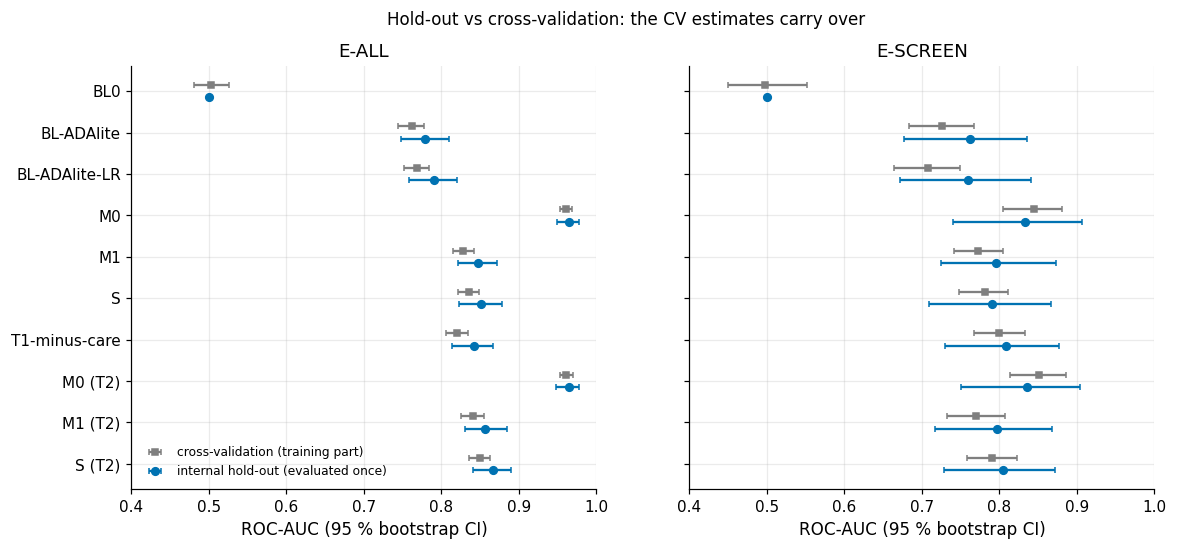

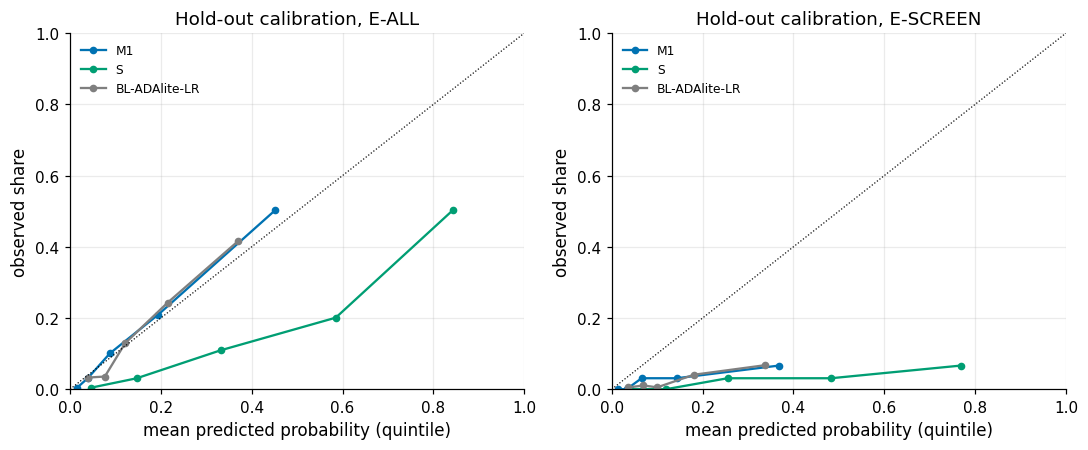

In [224]:
# Figure: hold-out AUC (evaluated once) against the pooled out-of-fold AUC for every arm; rows more than 2 SE below
# CV are labelled. Calibration curves follow, but only when the models were refitted in this run.
if RELEASED or STORED:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    lab_ = [f"{a}" + (" (T2)" if t == 2 else "") for a, t in ho.loc[ho["pop"] == "E-ALL", ["arm", "tier"]].itertuples(index=False)]
    for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
        d = ho[ho["pop"] == pop].reset_index(drop=True)
        yy_ = np.arange(len(d))
        ax.errorbar(d["cv_auc"], yy_ - 0.15, xerr=[d["cv_auc"] - d["cv_lo"], d["cv_hi"] - d["cv_auc"]], fmt="s", color=OI["grey"], capsize=2,
                    ms=4, label="cross-validation (training part)")
        ax.errorbar(d["roc_auc"], yy_ + 0.15, xerr=[d["roc_auc"] - d["auc_lo"], d["auc_hi"] - d["roc_auc"]], fmt="o", capsize=2, ms=5,
                    color=OI["blue"], label="internal hold-out (evaluated once)")
        for i, r in d.iterrows():
            if r["flag_2se_below_cv"]:
                ax.text(r["auc_lo"] - 0.01, i + 0.15, "> 2 SE below CV", ha="right", va="center", fontsize=7, color=OI["vermillion"])
        ax.set(title=pop, xlabel="ROC-AUC (95 % bootstrap CI)", xlim=(0.4, 1.0))
    axes[0].set_yticks(range(len(lab_)), lab_)
    axes[0].invert_yaxis()
    axes[0].legend(fontsize=8, loc="lower left")
    fig.suptitle("Hold-out vs cross-validation: the CV estimates carry over" + ("" if RELEASED else " (stored results of the single evaluation run)"), fontsize=11)
    plots.savefig(fig, "S9_holdout_vs_cv", caption="F9-6. ROC-AUC on the 20 % hold-out (blue; models refitted once on the whole training part, evaluated once "
                  "after exp-freeze) against the pooled out-of-fold estimate on the training part (grey), with 95 % bootstrap CIs; E-ALL left, "
                  "E-SCREEN right (about 25 hold-out positives).")
    plt.show()

if RELEASED:   # needs the refitted models' hold-out predictions
    from sklearn.calibration import calibration_curve
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
        yy, m = (y_te, np.ones(len(y_te), bool)) if pop == "E-ALL" else (yesc_te, esc_te)
        for (a, t), col in ((("M1", 1), OI["blue"]), (("S", 1), OI["green"]), (("BL-ADAlite-LR", 1), OI["grey"])):
            # Five quantile bins of the predicted probability, so every bin holds people despite the few
            # positives.
            fr, mp = calibration_curve(yy[m], P_TE[(a, t)][m], n_bins=5, strategy="quantile")
            ax.plot(mp, fr, "o-", color=col, ms=4, label=a)
        ax.plot([0, 1], [0, 1], "k:", lw=0.8)
        ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="mean predicted probability (quintile)", ylabel="observed share", title=f"Hold-out calibration, {pop}")
        ax.legend(fontsize=8)
    fig.tight_layout()
    plots.savefig(fig, "S9_holdout_calibration", caption="Calibration on the hold-out by quintiles of the predicted probability for M1, S (balanced class weights) "
                  "and BL-ADAlite-LR, Tier 1; E-ALL left, E-SCREEN right.")
    plt.show()
elif STORED:
    print("hold-out calibration curves need the refitted models' predictions; they are part of the stored FINAL outputs "
          "(calibration slope and CITL are in the table above)")

In [225]:
# Log the run and write the hold-out tables. A re-execution must reproduce the numbers of the single evaluation run exactly.
if RELEASED:
    now = pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds")
    if STORED:   # a re-execution must reproduce the numbers of the single evaluation run exactly (deterministic reproduction, not a second look)
        old = pd.read_csv(HOLDOUT_CSV).set_index(["arm", "tier", "pop"])["roc_auc"]
        new = ho.set_index(["arm", "tier", "pop"])["roc_auc"]
        assert old.index.sort_values().equals(new.index.sort_values()), "hold-out arms differ from the single evaluation run"
        dmax = float(np.abs(old.reindex(new.index).to_numpy() - new.to_numpy()).max())
        # Deterministic reproduction: the AUCs must equal the logged one-shot values up to floating-point
        # noise; a larger change would mean the frozen configuration moved.
        assert dmax <= 1e-9, f"hold-out AUCs changed after the single evaluation run (max difference {dmax})"
        oldp = pd.read_csv(HOLDOUT_PAIRS).set_index(["comparison", "pop"])["est"]
        newp = hp.set_index(["comparison", "pop"])["est"]
        assert np.allclose(oldp.reindex(newp.index).to_numpy(), newp.to_numpy(), atol=1e-9), "paired hold-out differences changed"
        print(f"re-execution reproduces the {len(new)} hold-out AUCs of the single evaluation run and {len(newp)} paired differences exactly "
              f"(first run {prev['first_run_utc']}; max |AUC difference| {dmax:.1e})")
    # First-run time and commit are kept from the first execution; only the last-run time and the counter
    # change.
    log_ = dict(first_run_utc=prev["first_run_utc"] if prev else now, last_run_utc=now,
                n_executions=(prev["n_executions"] + 1) if prev else 1, sha256_test_seqn=sha_te, n_test=int(len(cl_te)),
                exp_freeze_commit=RB.head_commit("exp-freeze") or (REC or {}).get("tag_commit"), head_at_first_run=prev["head_at_first_run"] if prev else RB.head_commit(),
                arms=[f"{a} T{t}" for a, t in P_TE], threshold_rule="specificity 0.80 on training-part predictions of the refitted model",
                nb_mode_first_run=prev["nb_mode_first_run"] if prev else C.NB_MODE, frozen=FROZEN, gate=gate)
    HOLDOUT_LOG.write_text(json.dumps(log_, indent=2), encoding="utf-8")
    ho.to_csv(HOLDOUT_CSV, index=False)
    hp.to_csv(OUT / "holdout_pairs.csv", index=False)
    print(json.dumps(log_, indent=1))
    S9["holdout"] = dict(status="re-executed in FINAL mode: reproduces the single evaluation run" if STORED else "evaluated (single evaluation run)",
                         log=log_, metrics=ho.round(5).to_dict("records"), pairs=hp.round(5).to_dict("records"),
                         n_flag_2se=int(ho["flag_2se_below_cv"].sum()))
elif STORED:   # never replace the one-shot results by "not evaluated": store them unchanged, labelled
    S9["holdout"] = dict(status=f"stored results of the single evaluation run, not re-executed in this {C.NB_MODE} run ({REASON})",
                         log=prev, metrics=ho.round(5).to_dict("records"), pairs=hp.round(5).to_dict("records"),
                         n_flag_2se=int(ho["flag_2se_below_cv"].sum()))
    print(S9["holdout"]["status"])
else:
    S9["holdout"] = dict(status=f"not evaluated: gate closed ({REASON}) and no stored results of the single evaluation run")
    print(S9["holdout"]["status"])

re-execution reproduces the 20 hold-out AUCs of the single evaluation run and 9 paired differences exactly (first run 2026-10-11T05:35:17+00:00; max |AUC difference| 1.1e-16)
{
 "first_run_utc": "2026-10-11T05:35:17+00:00",
 "last_run_utc": "2026-10-11T18:17:20+00:00",
 "n_executions": 2,
 "sha256_test_seqn": "616fd0590bec7b9256cd9704f62dfcd147f31d83a56b1f6969e1d613010659c3",
 "n_test": 1146,
 "exp_freeze_commit": "37a2387af1b6bf7bf3ed3aa4b192e5f817e5c738",
 "head_at_first_run": "9691c8c6f8c78bcae329542cc922662beec3d042",
 "arms": [
  "BL0 T1",
  "BL-ADAlite T1",
  "BL-ADAlite-LR T1",
  "M0 T1",
  "M1 T1",
  "S T1",
  "T1-minus-care T1",
  "M0 T2",
  "M1 T2",
  "S T2"
 ],
 "threshold_rule": "specificity 0.80 on training-part predictions of the refitted model",
 "nb_mode_first_run": "FINAL",
 "frozen": {
  "C0": 0.1,
  "folds_hash": "0d20f8f706ebf1e1103d23a4326e6d1a8cf0632c2a88417aac52cc8add4303ce",
  "holdout_sha256": "616fd0590bec7b9256cd9704f62dfcd147f31d83a56b1f6969e1d613010659c3"
 

**So what.** The internal hold-out check (1,146 adults, 194 positives; E-SCREEN 977 adults, 25 positives) changes no
verdict. **No optimism:** no arm × population row is more than 2 SE below CV; on E-ALL every model scores slightly
*higher* (S 0.851 [0.823, 0.878] vs CV 0.836), as does the unfitted ADA-lite score, so the hold-out sample is
slightly easier. **Contrasts:** the leak gate M1 − M0 replicates on E-ALL (−0.117, supported); S − M1 is +0.004
[−0.007, +0.014] on E-ALL and −0.005 on E-SCREEN (inconclusive, as in CV); the recognition gap of S has the same
direction and size (+0.060 vs +0.055) but is not separately testable with 25 screening positives; S − ADA-lite is
+0.029 [−0.037, +0.098] – **the CV margin does not replicate**. **Calibration:** S over-predicts by design (CITL −1.72).
Nothing was re-tuned. The check is internal: re-running the §4 diagnostics without the hold-out rows changes no design
decision (§9.12), but the hold-out is not an independent sample.

## 9.12 Post-audit corrections (post-lock)
**Why.** After the lock, an external methodological review raised six issues: (1) the hold-out was not fully
independent of the design, (2) C0 was not nested, (3) Monte Carlo ratio intervals decided two sub-claims, (4) the
reweighing arm used unweighted counts, (5) the M1 coefficient bootstrap did not converge, and (6) M1 keeps the blanket
sentinel recode. Each is checked here as an **approximate post-lock analysis** (`src/postaudit.py`, small resampling
sizes, printed below). No locked verdict, primary arm, stored §3–§8 result or hold-out row is changed;
`governance/hypotheses.md` stays byte-identical. Corrections go into the register (DR-S9-16 to DR-S9-21) and §10.

In [226]:
# Run the six post-audit checks (training part only; the hold-out is only counted in check 1) and display their
# tables. Reads the stored §4/§7/§8 results and the stored folds; writes nothing yet.
from src import postaudit as PA
t_pa = time.time()
PA_SZ = PA.sizes()
print(f"post-audit sizes ({C.NB_MODE}, approximate): nested C on {PA_SZ['nested_folds']} outer folds (repeat 0); "
      f"outer bootstrap {PA_SZ['outer']} x inner B {PA_SZ['inner']}; converged-M1 coefficient bootstrap B = {PA_SZ['coef_b']}")
PA1 = PA.holdout_design_check(ctx)
print("\n(1) hold-out rows inside the full-cohort §4 samples:")
show(PA1["overlap"], 3)
print("§4.11 linearity tests: full cohort (stored) vs training part only")
show(PA1["linearity"], 4)
print(f"interactions: {PA1['interactions_same_class']}/{PA1['interactions_n']} classifications unchanged {PA1['interactions_changed']}; "
      f"VIF > 10 class unchanged {PA1['vif_same_class']}/{PA1['vif_n']} (weight, BMI on training part: "
      f"{PA1['vif_weight_bmi_train'][0]:.1f}, {PA1['vif_weight_bmi_train'][1]:.1f}); max |skew change| {PA1['max_abs_skew_change']:.3f}")
PA2 = PA.nested_c(ctx)
print(f"\n(2) nested C ({PA2['folds_used']}); chosen C per fold: {PA2['cstar']}")
show(PA2["table"], 4)
PA3 = PA.ratio_outer_bootstrap(ctx)
print(f"\n(3) outer patient bootstrap of the BMI SD ratios ({PA3['n_outer']} outer x {PA3['n_inner']} inner refits; approximate)")
show(PA3["table"], 3)
PA4 = PA.weighted_reweighing(ctx)
print("\n(4) reweighing: weighted positive rate (%) by race, training rows of fold 0, and the spread across all folds")
display(PA4["rates_fold0"].query("attribute == 'race'").pivot(index="group", columns="weighting", values="pos_rate_pct").round(2))
show(PA4["spread"], 2)
show(PA4["eod"][["attribute", "group", "eod_S", "eod_asrun", "eod_corrected", "d_eod_corrected", "d_eod_corrected_lo", "d_eod_corrected_hi"]], 3)
show(PA4["auc"], 4)
PA5 = PA.converged_m1_coefs(ctx)
print(f"\n(5) M1 coefficient bootstrap on the first {PA5['n_boot']} resamples of §7.11 (stored §7.11 M1: BMI SD "
      f"{PA5['stored_7_11']['bmi_sd_per_sd']:.3f} over B = {PA5['stored_7_11']['n_boot']}); every refit's solver iterations counted")
show(PA5["table"], 3)
PA6 = PA.m1c_arm(ctx)
print(f"\n(6) M1c = M1 + P02 (codebook sentinel recode; {PA6['label_flips_train']} training labels differ from M1's blanket-recode label)")
show(PA6["table"], 4)
PA_SECONDS = time.time() - t_pa
print(f"post-audit checks: {PA_SECONDS:.0f} s")

post-audit sizes (FINAL, approximate): nested C on 5 outer folds (repeat 0); outer bootstrap 30 x inner B 100; converged-M1 coefficient bootstrap B = 200



(1) hold-out rows inside the full-cohort §4 samples:


sample,n,n_holdout,holdout_pos,holdout_share
"cohort (labels, binned age)",5730,1146,194,0.200
"§4.11 linearity / §4.12 interactions A, C (complete cases, 7 predictors)",4478,901,155,0.201
§4.12 interaction spec B (BMI present),5649,1127,191,0.200


§4.11 linearity tests: full cohort (stored) vs training part only


variable,chi2_full,p_full,chi2_train,p_train,nonlinear_full,nonlinear_train,same_class,splined_P13
RIDAGEYR,57.6075,0.0000,39.8503,0.0000,True,True,True,True
BMXBMI,11.5618,0.0031,9.1497,0.0103,True,True,True,True
BMXWAIST,7.0540,0.0294,7.3327,0.0256,True,True,True,False
bp_sys_mean,5.8698,0.0531,2.2312,0.3277,False,False,True,False
LBDHDD,18.4670,0.0001,15.9249,0.0003,True,True,True,True
LBXTC,41.7673,0.0000,34.4584,0.0000,True,True,True,True
INDFMPIR,0.8344,0.6589,1.1285,0.5688,False,False,True,False


...


(5) M1 coefficient bootstrap on the first 200 resamples of §7.11 (stored §7.11 M1: BMI SD 0.301 over B = 500); every refit's solver iterations counted


variant,bmi_coef_per_sd,bmi_sd_per_sd,q_low,q_high,sign_flip,max_flip_anthro,n_boot,at_limit,ratio_to_S_linear
"M1 stored (lbfgs, max_iter 5,000)",0.585,0.288,-0.176,0.948,0.095,0.840,200,200/200,1.896
M1 exact optimum (newton-cholesky),0.816,0.336,0.221,1.467,0.000,0.130,200,0/200,2.213
M1 + scaling only (P09),0.412,0.115,0.178,0.639,0.000,0.380,200,0/200,0.758



(6) M1c = M1 + P02 (codebook sentinel recode; 5 training labels differ from M1's blanket-recode label)


comparison,pop,auc_a,auc_b,est,lo,hi,interval,mdd,h2b_rule
S - M1,E-ALL,0.8359,0.8285,0.0079,0.0000,0.0158,corrected_t,0.0112,inconclusive
S - M1,E-SCREEN,0.7807,0.7723,0.0085,-0.0076,0.0245,bootstrap,0.0229,inconclusive
S - M1c,E-ALL,0.8359,0.8296,0.0068,-0.0008,0.0144,corrected_t,0.0108,inconclusive
S - M1c,E-SCREEN,0.7807,0.7766,0.0042,-0.0109,0.0189,bootstrap,0.0212,inconclusive
M1c - M1,E-ALL,0.8296,0.8285,0.0011,-0.0019,0.0041,corrected_t,0.0043,supported
M1c - M1,E-SCREEN,0.7766,0.7723,0.0043,0.0002,0.0086,bootstrap,0.0060,supported


post-audit checks: 198 s


In [227]:
# One summary table (issue -> check -> result -> consequence), asserts on the key numbers, storage under
# metrics_S9.json["postaudit"] and results/S9/postaudit_*.csv, and register rows DR-S9-16 to DR-S9-21.
r3b, r3h = PA3["ratio_B3"], PA3["ratio_H2b_c_converged"]
m1c_e, m1c_s = PA6["S_minus_M1c_eall"], PA6["S_minus_M1c_escreen"]
nb, nbs = PA2["dauc_nested"], PA2["dauc_stored"]
_conv_st = PA5["convergence"]["M1 stored (lbfgs, max_iter 5,000)"]
PA_SUM = pd.DataFrame([
    dict(issue="1 hold-out not independent of the design",
         check="§4 linearity, interaction, VIF and skew diagnostics re-run on the training part only",
         result=f"{PA1['lin_sample_holdout']} hold-out rows ({PA1['lin_sample_holdout_pos']} positives) were in the §4.11 sample; on the training part "
                f"{PA1['nl_same_class']}/{PA1['nl_n']} non-linearity and {PA1['interactions_same_class']}/{PA1['interactions_n']} interaction classifications are unchanged; "
                f"the splined set is unchanged",
         consequence="no design decision changes; §9.11 renamed 'internal hold-out check'; limitation L16"),
    dict(issue="2 C0 not nested",
         check=f"C chosen inside each of {PA2['n_folds']} outer folds (repeat 0), same grid",
         result=f"nested C = C0 in {PA2['S_folds_C0']}/{PA2['n_folds']} folds (S) and {PA2['M1_folds_C0']}/{PA2['n_folds']} (M1); S AUC {PA2['S_auc_nested']:.4f} vs "
                f"{PA2['S_auc_stored']:.4f}; ΔAUC S − M1 {nb['est']:+.4f} [{nb['lo']:+.4f}, {nb['hi']:+.4f}] vs {nbs['est']:+.4f} with C0",
         consequence="no change; DR-S9-06 reworded (arm fairness, not nesting); limitation L17"),
    dict(issue="3 Monte Carlo interval decided B3-b and H2b(c)",
         check=f"outer patient bootstrap ({PA3['n_outer']} x {PA3['n_inner']}, approximate)",
         result=f"B3 ratio {r3b['point']:.2f}: Monte Carlo [{r3b['mc_lo']:.2f}, {r3b['mc_hi']:.2f}] vs sampling about [{r3b['outer_q025']:.2f}, {r3b['outer_q975']:.2f}]; "
                f"H2b(c) (converged M1) about [{r3h['outer_q025']:.2f}, {r3h['outer_q975']:.2f}]",
         consequence="B3-b and H2b(c) verdicts withdrawn: not testable with this design; ratios descriptive; B3 mixed and H2b inconclusive unchanged"),
    dict(issue="4 reweighing used unweighted counts",
         check="Kamiran–Calders weights from WTPH2YR-weighted counts, refitted on the stored folds",
         result=f"race positive-rate spread {PA4['race_spread_pp']['survey']:.1f} pp (survey only) -> {PA4['race_spread_pp']['as_fitted']:.1f} pp (as run) -> 0 (corrected); "
                f"EOD NH Black {PA4['eod_nh_black']['corrected']:+.3f} vs {PA4['eod_nh_black']['asrun']:+.3f}, NH Asian {PA4['eod_nh_asian']['corrected']:+.3f} vs "
                f"{PA4['eod_nh_asian']['asrun']:+.3f}; max |ΔAUC| {PA4['max_abs_dauc_corrected']:.4f}",
         consequence="as-run arm described as partial reweighing; 'not adopted' stands (C21)"),
    dict(issue="5 M1 coefficient bootstrap unconverged",
         check=f"M1 at the exact optimum (newton-cholesky) and M1 + scaling (P09), B = {PA5['n_boot']}",
         result=f"same {PA5['n_boot']} resamples: BMI SD {PA5['sd_converged']:.3f} converged vs {PA5['sd_stored']:.3f} as fitted (ratio {PA5['ratio_converged']:.2f} vs {PA5['ratio_stored']:.2f}); "
                f"scaling only {PA5['ratio_scaled']:.2f}; stored refits at the limit {_conv_st['at_limit']}/{_conv_st['n_checked']}",
         consequence="early stopping shrinks the SD (L13 sign corrected); the stability edge of S comes from scaling"),
    dict(issue="6 M1 keeps the blanket recode",
         check="M1c = M1 + P02 on the stored folds, §7 engine",
         result=f"S − M1c E-ALL {m1c_e['est']:+.4f} [{m1c_e['lo']:+.4f}, {m1c_e['hi']:+.4f}]; E-SCREEN {m1c_s['est']:+.4f} [{m1c_s['lo']:+.4f}, {m1c_s['hi']:+.4f}]",
         consequence=f"H2b(a) reading unchanged ({m1c_e['verdict']}); M1 described as naive-minimal"),
])
show(PA_SUM)

# --- asserts on the key numbers (deterministic counts in both modes; resampling-dependent checks in FINAL)
assert PA1["lin_sample_holdout"] == 901 and PA1["lin_sample_holdout_pos"] == 155 and PA1["n_holdout"] == len(ctx.test_idx)
assert PA1["splined_still_nonlinear"] and not PA1["decision_changed"], "a design decision changes on the training part"
assert all(v is None or v < 1e-5 for v in PA2["max_dev_when_C0"].values()), "nested refits with C = C0 must reproduce the stored predictions"
assert abs(PA2["S_auc_change"]) < 0.002, PA2["S_auc_change"]
if C.IS_FINAL:   # FAST uses 5 outer samples, too few for a meaningful width comparison
    assert (r3b["outer_q975"] - r3b["outer_q025"]) > (r3b["mc_hi"] - r3b["mc_lo"]), "sampling interval must be wider than the Monte Carlo interval"
assert PA4["race_spread_pp"]["corrected"] < 1e-6, "weighted-count reweighing must make group and label independent"
assert PA4["max_abs_dauc_corrected"] < C.SESOI["roc_auc"]
assert PA5["full_coef_reproduced"] and PA5["convergence"]["M1 exact optimum (newton-cholesky)"]["at_limit"] == 0
assert PA6["label_flips_train"] == 5
if C.IS_FINAL:
    assert PA4["max_dev_asrun_vs_stored"] < 1e-4, "the as-run reweighing arm must reproduce §8.8"
    assert PA5["sd_converged"] > PA5["sd_stored"] and PA5["ratio_scaled"] < 1, "direction of the early-stopping bias"
    assert PA5["share_at_limit_stored"] >= 0.9
    assert m1c_e["verdict"] == "inconclusive" and nb["verdict"] == "inconclusive"

# --- storage
for nm, df in {"postaudit_summary": PA_SUM, "postaudit_holdout_overlap": PA1["overlap"], "postaudit_linearity_train": PA1["linearity"],
               "postaudit_interactions_train": PA1["interactions"], "postaudit_vif_train": PA1["vif"], "postaudit_nested_c": PA2["table"],
               "postaudit_ratio_outer": PA3["table"], "postaudit_ratio_outer_reps": PA3["per_outer"],
               "postaudit_reweighing_rates": PA4["rates_fold0"], "postaudit_reweighing_spread": PA4["spread"],
               "postaudit_reweighing_eod": PA4["eod"], "postaudit_reweighing_auc": PA4["auc"],
               "postaudit_m1_coef": PA5["table"], "postaudit_m1c": PA6["table"]}.items():
    df.to_csv(OUT / f"{nm}.csv", index=False)
_drop = lambda d, ks: {k: v for k, v in d.items() if k not in ks}
S9["postaudit"] = PA.jsonable(dict(
    note="POST-LOCK post-audit checks (approximate, small resampling sizes); locked verdicts, primary arms and the hold-out unchanged",
    sizes=PA_SZ, runtime_seconds=PA_SECONDS,
    holdout_design=_drop(PA1, ("overlap", "skew")),
    nested_c=PA2, ratio_outer=_drop(PA3, ("per_outer",)),
    reweighing=_drop(PA4, ("rates_fold0",)),
    m1_coef=PA5, m1c=PA6, summary=PA_SUM))

# --- decision-register rows (appended after DR-S9-15 in §9.13)
def _reg_pa(i, typ, fnd, ref, val, dec, alt, hyp, loop):
    # The register is append-only: each post-audit row names the earlier rows it supersedes or qualifies.
    return dict(dr_id=f"DR-S9-{i}", stage="S9", date=today, type=typ, finding=fnd, evidence_ref=ref, evidence_value=val, decision=f"{dec}. {loop}",
                alternatives_rejected=alt, hyp_id=hyp, status="decided", check_verdict="PASS",
                check_note="post-audit, post-lock; approximate check (§9.12)", loop_ref=loop, change_request="", commit="")

REG_PA = pd.DataFrame([
    _reg_pa(16, "postaudit_holdout", "Hold-out rows took part in the full-cohort §4/§5 design diagnostics (before the split existed)",
            "results/S9/postaudit_holdout_overlap.csv; postaudit_linearity_train.csv; postaudit_interactions_train.csv; postaudit_vif_train.csv",
            PA_SUM.loc[0, "result"], "Call §9.11 an internal hold-out check, not an independent validation; keep its numbers; add limitation L16",
            "re-splitting or re-scoring the hold-out", "H2a;H2b;H2c",
            "Qualifies DR-S6-12 and DR-S7-01 (the §4/§5 design statistics used the full cohort before the split) and the 'independent check' wording of the original §9.11 / DR-S9-15"),
    _reg_pa(17, "postaudit_tuning", "C0 was chosen once on the whole training part, not nested in the outer folds",
            "results/S9/postaudit_nested_c.csv", PA_SUM.loc[1, "result"],
            "Keep C0 and the 'same model for every arm' rule; report the nested check; add limitation L17",
            "re-running §7 with per-fold tuning (breaks the freeze)", "H2b",
            "Supersedes DR-S7-04 (tuning optimism now bounded by a nested check) and the earlier 'nil optimism' wording of DR-S9-06 (corrected in place: arm fairness, not nesting)"),
    _reg_pa(18, "postaudit_interval", "The §7.11 SD-ratio interval re-draws stored bootstrap replicates: Monte Carlo error, not sampling uncertainty",
            "results/S9/postaudit_ratio_outer.csv; results/S7/coef_stability.csv", PA_SUM.loc[2, "result"],
            "Withdraw the B3-b and H2b(c) verdicts as 'not testable with this design (post-audit)'; keep the ratios as descriptive; "
            "hypotheses.md unchanged; B3 and H2b hypothesis-level verdicts unchanged",
            "keeping the locked-rule verdicts; editing the locked file", "B3;H2b",
            "Supersedes DR-S7-11 (B3-b 'refuted' withdrawn: Monte Carlo interval) and the H2b(c) sub-verdict of the §7 scoreboard; the stored locked labels are kept for traceability"),
    _reg_pa(19, "postaudit_fairness", "§8.8 reweighing used unweighted-count weights multiplied by survey weights: group and label only partly independent",
            "results/S9/postaudit_reweighing_eod.csv; postaudit_reweighing_auc.csv; postaudit_reweighing_spread.csv", PA_SUM.loc[3, "result"],
            "Describe the §8.8 arm as partial reweighing; the corrected weighted-count arm gives the same picture; 'not adopted' stands",
            "replacing the stored §8 arm", "",
            "Qualifies DR-S8-07 and DR-S8-08 (arm as run is partial reweighing; corrected arm agrees, decision unchanged)"),
    _reg_pa(20, "postaudit_stability", "The M1 coefficient bootstrap stops at the iteration limit; early stopping shrinks the BMI SD",
            "results/S9/postaudit_m1_coef.csv", PA_SUM.loc[4, "result"],
            "Correct the sign of L13 and of the §7 'optimiser noise' wording; attribute the stability edge of S to scaling (P09); locked M1 kept",
            "replacing M1 after the lock", "H2b",
            "Supersedes DR-S7-14 ('optimiser noise' wording: early stopping shrinks, not inflates, the M1 BMI SD); complements DR-S7-16"),
    _reg_pa(21, "postaudit_baseline", "M1 keeps the blanket 7/9 sentinel recode (P02 off) in its features and training label",
            "results/S9/postaudit_m1c.csv", PA_SUM.loc[5, "result"],
            "Keep M1 as the locked naive-minimal baseline; report S − M1c as a post-lock comparison", "redefining the primary baseline", "H2b",
            "Qualifies DR-S6-01 and DR-S6-02 (M1 is naive-minimal: blanket sentinel recode; H2b(a) reading unchanged with M1c)"),
])
print(f"stored metrics_S9.json['postaudit'] and {len(REG_PA)} register rows (DR-S9-16 to DR-S9-21); post-audit runtime {PA_SECONDS:.0f} s")

issue,check,result,consequence
1 hold-out not independent of the design,"§4 linearity, interaction, VIF and skew diagnostics re-run on the training part only",901 hold-out rows (155 positives) were in the §4.11 sample; on the training part 7/7 non-linearity and 11/12 interaction classifications are unchanged; the splined set is unchanged,no design decision changes; §9.11 renamed 'internal hold-out check'; limitation L16
2 C0 not nested,"C chosen inside each of 5 outer folds (repeat 0), same grid","nested C = C0 in 5/5 folds (S) and 5/5 (M1); S AUC 0.8333 vs 0.8333; ΔAUC S − M1 +0.0063 [-0.0003, +0.0129] vs +0.0063 with C0","no change; DR-S9-06 reworded (arm fairness, not nesting); limitation L17"
3 Monte Carlo interval decided B3-b and H2b(c),"outer patient bootstrap (30 x 100, approximate)","B3 ratio 1.36: Monte Carlo [1.23, 1.50] vs sampling about [0.99, 2.05]; H2b(c) (converged M1) about [1.87, 2.76]",B3-b and H2b(c) verdicts withdrawn: not testable with this design; ratios descriptive; B3 mixed and H2b inconclusive unchanged
4 reweighing used unweighted counts,"Kamiran–Calders weights from WTPH2YR-weighted counts, refitted on the stored folds","race positive-rate spread 11.1 pp (survey only) -> 4.0 pp (as run) -> 0 (corrected); EOD NH Black -0.133 vs -0.131, NH Asian -0.189 vs -0.201; max |ΔAUC| 0.0053",as-run arm described as partial reweighing; 'not adopted' stands (C21)
5 M1 coefficient bootstrap unconverged,"M1 at the exact optimum (newton-cholesky) and M1 + scaling (P09), B = 200",same 200 resamples: BMI SD 0.336 converged vs 0.288 as fitted (ratio 2.21 vs 1.90); scaling only 0.76; stored refits at the limit 200/200,early stopping shrinks the SD (L13 sign corrected); the stability edge of S comes from scaling
6 M1 keeps the blanket recode,"M1c = M1 + P02 on the stored folds, §7 engine","S − M1c E-ALL +0.0068 [-0.0008, +0.0144]; E-SCREEN +0.0042 [-0.0109, +0.0189]",H2b(a) reading unchanged (inconclusive); M1 described as naive-minimal


stored metrics_S9.json['postaudit'] and 6 register rows (DR-S9-16 to DR-S9-21); post-audit runtime 198 s


**So what.** No issue changes a locked verdict or a headline number, but three change how results are read. The hold-out
is an *internal* check: 901 of its rows (155 positives) entered the §4 non-linearity tests, yet the training part alone
gives the same design (7/7 non-linearity, 11/12 interaction classifications). Nesting C changes nothing (C0 chosen
in 5/5 folds). The B3-b and H2b(c) verdicts are withdrawn: the approximate sampling interval of the B3 ratio (about
1.0–2.1) is far wider than its Monte Carlo interval (1.23–1.50). Weighted-count reweighing and M1 with the codebook
recode (S − M1c +0.007 [−0.001, +0.014]) leave the conclusions unchanged. Early stopping *shrinks* M1's BMI SD (0.288
against 0.336 converged); the stability edge of S is scaling (scaled-M1 ratio 0.76).

## 9.13 Outputs
**Why.** §10 and the video read every number from stored artefacts: `results/metrics_S9.json`, the tables in
`results/S9/`, the F9 figures and the §9 decision-register fragment (written from the FINAL run, listed below).

In [228]:
# Add the hold-out row to the decision register (only if the hold-out was evaluated or reproduced in this
# run), list the register, write it in FINAL mode and save results/metrics_S9.json.
if RELEASED and "metrics" in S9["holdout"]:
    hS = ho[(ho["arm"] == "S") & (ho["tier"] == 1)].set_index("pop")
    hpS = hp.set_index(["comparison", "pop"])
    reg = pd.concat([reg, pd.DataFrame([dict(
        dr_id="DR-S9-15", stage="S9", date=today, type="holdout",
        finding="Internal hold-out check, evaluated once after exp-freeze (design-informed through the full-cohort §4/§5 diagnostics, L16)",
        evidence_ref="results/S9/holdout_metrics.csv; results/S9/holdout_pairs.csv; results/S9/holdout_log.json; figures/S9_holdout_vs_cv.png",
        evidence_value=(f"S T1 AUC E-ALL {hS.loc['E-ALL', 'roc_auc']:.3f} [{hS.loc['E-ALL', 'auc_lo']:.3f}, {hS.loc['E-ALL', 'auc_hi']:.3f}] (CV {hS.loc['E-ALL', 'cv_auc']:.3f}), "
                        f"E-SCREEN {hS.loc['E-SCREEN', 'roc_auc']:.3f} [{hS.loc['E-SCREEN', 'auc_lo']:.3f}, {hS.loc['E-SCREEN', 'auc_hi']:.3f}] (CV {hS.loc['E-SCREEN', 'cv_auc']:.3f}); "
                        f"S - M1 E-ALL {hpS.loc[('S T1 - M1 T1', 'E-ALL'), 'est']:+.4f} [{hpS.loc[('S T1 - M1 T1', 'E-ALL'), 'lo']:+.4f}, {hpS.loc[('S T1 - M1 T1', 'E-ALL'), 'hi']:+.4f}]; "
                        f"{int(ho['flag_2se_below_cv'].sum())} of {len(ho)} arm x population rows > 2 SE below CV; SHA-256 {sha_te[:16]}"),
        decision="Report hold-out numbers as they are; no re-tuning", alternatives_rejected="re-tuning after seeing the hold-out",
        hyp_id="H2a;H2b;H2c", status="decided", check_verdict="PASS", check_note=f"first run {S9['holdout']['log']['first_run_utc']}",
        loop_ref="", change_request="", commit="")])], ignore_index=True)
# Post-audit rows (§9.12) follow the hold-out row.
reg = pd.concat([reg, REG_PA[reg.columns]], ignore_index=True)
show(reg[["dr_id", "type", "check_verdict", "decision"]])
if C.IS_FINAL:
    # The register is append-only: a row already on file keeps its original date unless its content changed.
    if REG_PATH.exists():
        old_reg = pd.read_csv(REG_PATH, dtype=str, keep_default_na=False).set_index("dr_id")
        for i, r in reg.iterrows():
            if r["dr_id"] in old_reg.index and all(str(r[c]) == old_reg.loc[r["dr_id"], c] for c in reg.columns
                                                   if c not in ("dr_id", "date") and c in old_reg.columns):
                reg.at[i, "date"] = old_reg.loc[r["dr_id"], "date"]
    # Only a FINAL run writes the register fragment; a FAST run must not overwrite the committed one.
    reg.to_csv(REG_PATH, index=False)
    print(f"wrote {REG_PATH.relative_to(C.ROOT).as_posix()} ({len(reg)} rows)")
else:
    print(f"FAST run: register fragment not written ({len(reg)} rows prepared; the committed fragment comes from the FINAL run)")
S9["register_ids"] = reg["dr_id"].tolist()
S9["runtime_seconds"] = time.time() - T_START
# Write results/metrics_S9.json (the `S9` dictionary built up in this section).
R.save_section("S9", S9)
print(f"saved results/metrics_S9.json; section runtime {S9['runtime_seconds']:.0f} s ({C.NB_MODE})")
print(json.dumps({"H2b(a) reference": S9["reference"]["E-ALL"]["h2b"], "seeds stable": S9["seeds"]["stable_eall"],
                  "sensitivity same verdict": f"{S9['sensitivity']['eall_same_verdict']}/{S9['sensitivity']['eall_rows']}",
                  "L3 triggered": S9["leak_hunt"]["triggered"], "hold-out": S9["holdout"]["status"]}, indent=1))

dr_id,type,check_verdict,decision
DR-S9-01,negative_control,PASS,Evaluation procedure accepted; feature leakage delegated to the L3 leak hunt
DR-S9-02,negative_control,PASS,No overfitting to noise; depth cap 3 for the tree probe retained
DR-S9-03,positive_control,PASS,Procedure has power for weak real signals; negative controls are not passed by blindness
DR-S9-04,seed_stability,PASS,H2b(a) verdict graded seed-stable
DR-S9-05,sensitivity,PASS,"H2b(a) inconclusive is robust; labels and arm-specific weighting move the size of the gap, not its direction (except the depth-4 tree)"
DR-S9-06,tuning,PASS,"Tuning C on S does not favour S across arms (M0, M1 and S pick the same C); 'same model for every arm' rule kept. This tests arm fairness, not nesting: the tuning optimism of the un-nested C0 is bounded by the post-audit nested check (DR-S9-17)"
DR-S9-07,sensitivity,PASS,Extension item; does not change the core table
DR-S9-08,sensitivity,PASS,Stratified (non-grouped) folds kept as primary design
DR-S9-09,missingness,PASS,Complete-case cohort with WTPH2YR confirmed; MNAR untestable but no plausible mechanism changes conclusions
DR-S9-10,validation,PASS,"Report 14.0 % as the prevalence of L_comb, not of NCHS-defined diabetes; no change to the frozen label"


wrote governance/register/S9.csv (21 rows)
saved results/metrics_S9.json; section runtime 1318 s (FINAL)
{
 "H2b(a) reference": "inconclusive",
 "seeds stable": true,
 "sensitivity same verdict": "17/17",
 "L3 triggered": false,
 "hold-out": "re-executed in FINAL mode: reproduces the single evaluation run"
}


# §10 Synthesis and Interpretation

**Section lead:** D

This section turns the numbers of §1–§9 into **claims** with an honest strength, scope and falsifier. Nothing is
re-estimated: every value is read from the stored results (`results/metrics_S*.json`, `results/S*/`), and every video
number is re-read and asserted in §10.11. The models are treated as **measuring instruments** – a leak detector, a
coefficient-stability meter, a label-bias meter, a negative control – so the question is "what did the models reveal
about the data?", not "how good is the model?".

Vocabulary. Verdicts follow the locked rules of `governance/hypotheses.md`. Evidence grades: **E1** deterministic fact,
**E2** large effect whose CI excludes 0 and that is stable under §9, **E3** moderate or choice-sensitive, **E4**
exploratory; the verb follows the grade (E1 *confirms*, E2 *shows*, E3 *is consistent with*, E4 *suggests*), and
statements say *association*, never *cause*. Numbers in text cells are those of the FINAL run.

In [229]:
new_section()

In [230]:
import hashlib, json, re, textwrap, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score

from src import evalkit as ek

from IPython.display import display
pd.set_option("display.width", 150, "display.max_columns", 30, "display.max_colwidth", 60)


def show(df, digits=3):
    """Display a table as HTML (long text wraps; keeps the text output narrow)."""
    display(df.style.hide(axis="index").format(precision=digits, na_rep="")
            .set_properties(**{"text-align": "left", "white-space": "normal"}))

OUT = C.RESULTS_DIR / "S10"
OUT.mkdir(parents=True, exist_ok=True)
OI = C.OKABE_ITO
T_START = time.time()
SECTIONS = ("S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9")
SEC = {"S1": "§1", "S2": "§2", "S3": "§3", "S4": "§4", "S5": "§5", "S6": "§6", "S7": "§7", "S8": "§8", "S9": "§9", "S10": "§10"}
S10 = {"mode": C.NB_MODE}
print(f"mode {C.NB_MODE}; this section re-estimates nothing – it reads stored results only")

mode FINAL; this section re-estimates nothing – it reads stored results only


## 10.1 Inputs and provenance
**Why.** A synthesis is only as good as its inputs: it must read the results of the run that produced the
notebook, from the locked hypothesis file, and say which run mode each section came from.

The helper `get("S7:headline.leak_gate_T1_eall.est")` resolves a *source key* – section, then a dotted path
into that section's metrics file; `name[k=v&k2=v2]` picks the one record of a list that matches. The same
keys are written next to every video number in §10.11, so each number can be traced to its origin.

In [231]:
# Load the stored metrics of §1–§9 and define the `get` source-key helper used for every number below.
# Reads results/metrics_S*.json through results_io; in a FINAL run asserts that §7–§9 ran in FINAL mode.
M = {s: R.load_section(s) for s in SECTIONS}
modes = {s: M[s]["_meta"]["nb_mode"] for s in SECTIONS}
print("run mode per section:", modes)
# Resampling-dependent results (§7–§9) are only valid at full size: refuse FAST leftovers in a FINAL run.
if C.IS_FINAL:   # numbers that depend on resampling size must come from the full protocol
    assert all(modes[s] == "FINAL" for s in ("S7", "S8", "S9")), modes

# Split a key path on '.' except inside [...] filters, whose values may themselves contain dots.
_SPLIT = re.compile(r"\.(?![^\[]*\])")


# Compare a stored field with a filter value numerically when it parses as a number, else as text.
def _match(v, want: str) -> bool:
    try:
        return abs(float(v) - float(want)) < 1e-9
    except (TypeError, ValueError):
        return str(v) == want


def get(key: str, src: dict | None = None):
    """Resolve 'S7:path.to[k=v&k2=v2].value' in the metrics dictionaries (default: this run's M)."""
    sec, path = key.split(":", 1)
    d = (src or M)[sec]
    # Each segment is 'name', 'name[k=v&k2=v2]' or '[k=v]': descend into `name`, then pick one list record.
    for seg in _SPLIT.split(path):
        m = re.fullmatch(r"([^\[]*)(?:\[(.*)\])?", seg)
        name, filt = m.group(1), m.group(2)
        if name:
            d = d[name]
        if filt:
            conds = [c.split("=", 1) for c in filt.split("&")]
            hits = [x for x in d if all(_match(x.get(k), v) for k, v in conds)]
            # Exactly one record must match: zero or several would silently return the wrong number.
            assert len(hits) == 1, f"{key}: {len(hits)} records match [{filt}]"
            d = hits[0]
    return d


# hypotheses.md is locked: its SHA-256 must equal the pre-registration record of §6
hyp_bytes = (C.GOVERNANCE_DIR / "hypotheses.md").read_bytes()
hyp_sha = hashlib.sha256(hyp_bytes).hexdigest()
lock = get("S6:hypotheses.lock")
# Pre-registration guard: any edit to the locked file after the lock changes its hash and stops the run.
assert hyp_sha == lock["sha256"], "governance/hypotheses.md differs from the locked version"
print(f"hypotheses.md SHA-256 {hyp_sha[:16]}... equals the lock of {lock['timestamp']} (commit {lock['commit'][:10]})")
# The lock must predate the first ablation commit (ISO timestamps compare correctly as strings).
print(f"first experiment commit {lock['first_exp_timestamp']} is later: {lock['first_exp_timestamp'] > lock['timestamp']}")

# parse the locked hypothesis tables (statement, metric, direction, magnitude, SESOI, falsifier, prior exposure)
HCOLS = ["hyp_id", "rq_or_block", "statement", "metric", "direction", "magnitude", "sesoi", "falsifier", "prior_exposure", "weights"]
rows = []
# Table rows start with '| '; skip the header and separator rows. The split regex ignores escaped pipes (\|)
# inside a cell, and the replace() restores them afterwards.
for line in hyp_bytes.decode("utf-8").splitlines():
    if line.startswith("| ") and not line.startswith("| hyp_id") and not line.startswith("|---"):
        cells = [c.strip().replace("\\|", "|") for c in re.split(r"(?<!\\)\|", line.strip().strip("|"))]
        if len(cells) == len(HCOLS):
            rows.append(dict(zip(HCOLS, cells)))
HYP = pd.DataFrame(rows).set_index("hyp_id")
# First word of prior_exposure (e.g. none, analysis_seen) tells how much was known before the hypothesis
# was locked.
HYP["prior"] = HYP["prior_exposure"].str.split(" ").str[0]
# Parsed table and the §6 record must both hold all 17 hypotheses; a parsing slip would drop rows silently.
assert len(HYP) == M["S6"]["hypotheses"]["n_total"] == 17, len(HYP)
print(f"{len(HYP)} locked hypotheses parsed; prior exposure: {HYP['prior'].value_counts().to_dict()}")

run mode per section: {'S1': 'FINAL', 'S2': 'FINAL', 'S3': 'FINAL', 'S4': 'FINAL', 'S5': 'FINAL', 'S6': 'FINAL', 'S7': 'FINAL', 'S8': 'FINAL', 'S9': 'FINAL'}
hypotheses.md SHA-256 de032f4d200fa1ff... equals the lock of 2026-10-11T02:17:18+08:00 (commit 9fb6aefd8a)
first experiment commit 2026-10-11T02:34:13+08:00 is later: True
17 locked hypotheses parsed; prior exposure: {'none': 6, 'analysis_seen': 5, 'descriptive_seen': 4, 'prototype_seen': 2}


**So what.** All nine upstream sections are present, §7–§9 from the FINAL protocol (asserted in a FINAL run), and the
hypothesis file is byte-identical to the locked version. Only 6 of the 17 hypotheses are genuine pre-registrations
(`prior_exposure = none`); the others confirm patterns already seen and are graded accordingly.

## 10.2 Hypothesis scoreboard
**Why.** Every locked hypothesis gets one verdict under its locked rule, with estimate, CI, SESOI and – for an
inconclusive AUC difference – the minimal detectable difference (MDD), so "inconclusive" can be read as "underpowered"
when the MDD exceeds the SESOI. Two verdicts are completed here (H1b had no verdict line in §4; P14 combines §7 (a) and
§8 (b)). As a check, the locked rules are re-applied to the stored CIs and must reproduce the stored verdicts. Exploratory rows
(not hypotheses, not counted) are appended: the pure-preparation contrast S−B6a vs M1, the post-lock M1 sensitivity
of §7.12.1 and the post-audit checks of §9.12. **Post-audit:** the two SD-ratio sub-claims (B3-b, H2b-c) are shown as
*not testable (post-audit)*, because their locked interval measured Monte Carlo error only; the locked-rule label
stays visible next to it.

In [232]:
# Build the hypothesis scoreboard: one verdict per locked hypothesis with estimate, CI, SESOI and MDD.
# Reads the stored §7 scoreboard and the §4/§5/§8 results; re-applies the locked rules as an assert.
# `prim` keeps the pre-registered primary sub-claims only (secondary and exploratory rows are excluded).
det = pd.DataFrame(M["S7"]["scoreboard_detail"])
prim = det[det["role"] == "primary"]


# Newcombe's method 10 combines the two Wilson intervals; unlike the Wald interval it stays valid for small
# counts and proportions near 0 or 1. z = 1.959964 is the 97.5 % normal quantile (two-sided 95 % CI).
def newcombe_diff(x1, n1, x2, n2, z=1.959964):
    """Newcombe hybrid-score CI for p1 - p2 (method 10), from Wilson intervals."""
    # Wilson score interval: the centre c is pulled towards 0.5 and the half-width h includes the z^2/4n^2
    # term.
    def wilson(x, n):
        p = x / n
        c = (p + z * z / (2 * n)) / (1 + z * z / n)
        h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
        return p, c - h, c + h
    p1, l1, u1 = wilson(x1, n1)
    p2, l2, u2 = wilson(x2, n2)
    # Hybrid CI for the difference: distances from each estimate to the Wilson bound facing the other group.
    d = p1 - p2
    return d, d - np.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + np.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)


# Collector for scoreboard rows. `add` appends one dict per hypothesis; `underpowered` is derived
# (inconclusive
# verdict and MDD > SESOI) unless the caller passes it explicitly.
SB = []


def add(hyp, est, lo, hi, unit, verdict, *, interval="", mdd=np.nan, sesoi=np.nan, subs="", source="", note="", underpowered=None):
    SB.append(dict(hyp_id=hyp, family=HYP.loc[hyp, "rq_or_block"], metric=HYP.loc[hyp, "metric"][:90],
                   direction=HYP.loc[hyp, "direction"], sesoi_locked=HYP.loc[hyp, "sesoi"], estimate=est, ci_low=lo, ci_high=hi,
                   unit=unit, interval=interval, mdd=mdd,
                   underpowered=bool(underpowered) if underpowered is not None else bool(verdict == "inconclusive" and np.isfinite(mdd) and np.isfinite(sesoi) and mdd > sesoi),
                   verdict=verdict, sub_verdicts=subs, prior_exposure=HYP.loc[hyp, "prior"], source=source, note=note))


# --- RQ1 (S4, S5)
# H1a: weighted risk difference with its jackknife CI. df = 15 is the design df of this survey cycle
# (number of PSUs minus number of strata, see §5); it is used when the stored record has no df of its own.
rd = get("S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured")
add("H1a", rd["rd_pp"], rd["ci_low_pp"], rd["ci_high_pp"], "pp", get("S5:hypotheses.H1a.verdict"), interval=f"jackknife (df {rd.get('df', 15)})",
    source="§5 (S5)", note="uninsured share itself exploratory (Korn-Graubard width ≥ 0.30)")
ins = get("S4:standardisation.insured_uninsured")
h1b_std, (h1b_lo, h1b_hi), h1b_crude = ins["std"], ins["std_ci"], ins["crude"]
# Locked H1b rule (§6): refuted if the age-standardised gap stays >= +2 pp with its CI above 0; supported
# if it
# falls below +2 pp (or its CI covers 0) and is smaller than the crude gap; otherwise inconclusive.
if h1b_std >= 2 and h1b_lo > 0:
    h1b_v = "refuted"
elif (h1b_std < 2 or h1b_lo <= 0) and h1b_std < h1b_crude:
    h1b_v = "supported"
else:
    h1b_v = "inconclusive"
add("H1b", h1b_std, h1b_lo, h1b_hi, "pp", h1b_v, interval="jackknife (df 15)", source="§4 (S4); verdict applied in §10",
    note=f"crude {h1b_crude:+.1f} pp [{ins['crude_ci'][0]:+.1f}, {ins['crude_ci'][1]:+.1f}] -> age-standardised; attenuation, not reversal")

# --- RQ2 and blocks (S7)
# One displayed row per block hypothesis: the first primary sub-claim gives the estimate and CI, the stored
# combined verdict gives the verdict, and every sub-verdict is listed in text.
S7V = M["S7"]["scoreboard"]
# Post-audit (§9.12, DR-S9-18): the SD-ratio sub-claims were decided by a Monte Carlo interval (re-draws of the stored
# bootstrap replicates), not a sampling interval, so their verdicts are withdrawn as "not testable with this design".
# The locked-rule label is kept next to it; the hypothesis-level verdicts are re-derived without them below.
WITHDRAWN = {("B3", "(b) BMI SD ratio"), ("H2b", "(c) BMI SD ratio")}
PA9 = M["S9"].get("postaudit")
assert PA9 is not None or not C.IS_FINAL, "§9.12 post-audit results missing"


def sub_status(h, sub, verdict):
    """Displayed status of a locked sub-claim: withdrawn SD-ratio sub-claims show the post-audit status."""
    return f"not testable (post-audit; locked rule: {verdict})" if (h, sub) in WITHDRAWN else verdict


for h in ["H2a", "H2b", "H2c", "B1", "B2", "B2t", "B3", "B4", "B5", "B6a", "B6b"]:
    g = prim[prim["hyp_id"] == h]
    r0 = g.iloc[0]
    # Sub-verdict text; the population is appended only when the same sub-claim appears on several
    # populations.
    subs = "; ".join(f"{r['sub']}{' ' + r['pop'] if (g['sub'] == r['sub']).sum() > 1 else ''}: {sub_status(h, r['sub'], r['verdict'])}" for _, r in g.iterrows())
    # Display unit by metric; dict.get falls back to the raw metric name for anything unlisted.
    unit = {"roc_auc": "AUC", "brier": "Brier", "sd_ratio": "ratio", "calslope_dev": "|slope−1|"}.get(r0["metric"], str(r0["metric"]))
    add(h, r0["est"], r0["lo"], r0["hi"], unit if np.isfinite(r0["est"]) else "", S7V[h]["verdict"], interval=str(r0["interval"]) if pd.notna(r0["interval"]) else "",
        mdd=r0["mdd"], sesoi=r0["sesoi"], subs=subs, source="§7 (S7)",
        # Underpowered = some inconclusive sub-claim whose minimal detectable difference exceeds its SESOI.
        underpowered=bool(((g["verdict"] == "inconclusive") & (g["mdd"] > g["sesoi"])).any()),
        note=f"primary: {r0['comparison']}, {r0['pop']}" + (f", Tier {int(r0['tier'])}" if pd.notna(r0['tier']) else ""))

# --- P14: (a) from S7, (b) and the combined verdict from S8 (supersedes the interim S7 entry)
# P14 has two parts: (a) the paired AUC difference from §7 and (b) the NH Asian TPR change from §8;
# the combined §8 verdict replaces the interim §7 entry.
pa = prim[(prim["hyp_id"] == "P14") & (prim["sub"] == "(a) AUC")].iloc[0]
wt = pd.DataFrame(get("S8:whtr.table")).set_index("quantity")
pb = wt.loc["ΔTPR NH Asian"]
add("P14", pb["est"], pb["lo"], pb["hi"], "TPR", get("S8:verdicts.P14"), interval="PSU cluster bootstrap", sesoi=0.05,
    subs=f"(a) ΔAUC {pa['est']:+.4f} [{pa['lo']:+.4f}, {pa['hi']:+.4f}]: {pa['verdict']}; (b) NH Asian ΔTPR: {get('S8:verdicts.P14b')}",
    source="§7 (a), §8 (b)", note=f"§7 interim entry was '{S7V['P14']['verdict']} ({S7V['P14']['note']})'; §8 combined verdict used")

# --- RQ3 (S8): H3 three elements, column-wise reading
# H3 is shown through its worst-stratum recall gap between labels L_comb and L_self (column-wise reading,
# §10.3).
lm = get("S8:label_matrix")
h3c = pd.DataFrame(lm["contrasts"])
e3 = h3c[h3c["contrast"] == "worst-cell gap: L_comb - L_self"].iloc[0]
add("H3", e3["est"], e3["lo"], e3["hi"], "recall", lm["verdict"], interval="paired bootstrap", sesoi=0.05,
    subs="; ".join(f"{k}: {v}" for k, v in lm["element_verdicts"].items()), source="§8 (S8)",
    note="primary shown: E3 worst-cell gap L_comb − L_self; column-wise reading (see §10.3)")

# --- RQ4 (S5, S8)
ab = get("S5:asian_bmi.bmi_lt25_among_diabetics")
x1, n1 = ab["NH Asian"]["bmi_lt25"], ab["NH Asian"]["diabetics_with_bmi"]
x2, n2 = ab["NH White"]["bmi_lt25"], ab["NH White"]["diabetics_with_bmi"]
# H4a: recompute the Asian-minus-White gap in BMI < 25 shares from counts with Newcombe's CI (in pp) and
# check it against the string stored by §5, so the two routes cannot drift apart.
h4a = np.array(newcombe_diff(x1, n1, x2, n2)) * 100
s5_h4a = get("S5:hypotheses.H4a.estimate")
assert f"+{h4a[0]:.1f} pp (Newcombe {h4a[1]:.1f}, {h4a[2]:.1f})" in s5_h4a, (h4a, s5_h4a)   # independent recomputation
# Locked H4a rule: supported if the gap is >= 20 pp and its lower bound stays above 20; refuted if the
# upper bound
# falls below 20; otherwise inconclusive.
h4a_v = "supported" if (h4a[0] >= 20 and h4a[1] > 20) else ("refuted" if h4a[2] < 20 else "inconclusive")
assert h4a_v == get("S5:hypotheses.H4a.verdict")
add("H4a", h4a[0], h4a[1], h4a[2], "pp", h4a_v, interval="Newcombe (recomputed from counts)", source="§5 (S5)",
    note=f"{x1}/{n1} Asian vs {x2}/{n2} White diabetics with BMI < 25; Asian cell exploratory")
gd = get("S5:asian_bmi.gain_difference_asian_minus_white")
mdl = wt.loc["ΔAUC Asian − ΔAUC White (H4b, model level)"]
add("H4b", gd["est"], gd["psu_ci_low"], gd["psu_ci_high"], "AUC", get("S8:verdicts.H4b"), interval="PSU cluster bootstrap",
    subs=f"single feature (§5): {get('S8:scoreboard.H4b.single feature (S5)')}; model level (§8, secondary): {get('S8:verdicts.H4b_model_level')} "
         f"({mdl['est']:+.4f} [{mdl['lo']:+.4f}, {mdl['hi']:+.4f}])",
    source="§5 (S5), §8 (S8)", note=f"gain Asian {get('S5:asian_bmi.auc.NH Asian|WHtR − BMI (paired).auc'):+.3f} vs White "
                                   f"{get('S5:asian_bmi.auc.NH White|WHtR − BMI (paired).auc'):+.3f}")

SCORE = pd.DataFrame(SB)
# Re-index in the locked hypothesis order so the table reads like hypotheses.md; the assert below checks that
# every verdict is one of the allowed labels.
order = list(HYP.index)
SCORE = SCORE.set_index("hyp_id").loc[order].reset_index()
assert set(SCORE["verdict"]) <= set(C.VERDICTS), set(SCORE["verdict"])

# independent re-application of the locked rules to the stored S7 CIs
# Rule per stored sub-claim: 'equiv' = equivalence inside +/-0.01 AUC, 'noninf' = non-inferiority at -0.01,
# (sign, margin) = directional test against that margin (SESOI).
CHECK = {  # (hyp, sub): rule
    ("B1", "(a) AUC"): "equiv", ("B3", "(a) AUC"): "equiv", ("B4", "(a) AUC"): "equiv", ("B6a", "(a) AUC"): "equiv",
    ("P14", "(a) AUC"): "equiv", ("H2b", "(a) AUC"): "equiv", ("B6b", "(a) unweighted AUC"): "noninf",
    ("H2a", "AUC M0-M1"): ("+", 0.05), ("B2", "(a) AUC M1-M0"): ("-", 0.05), ("B6a", "(b) Brier"): ("+", 0.005),
    ("B6a", "(c) balanced accuracy at 0.5"): ("+", 0.05), ("H2c", "(i) AUC E-ALL - E-SCREEN (S)"): ("+", 0.03),
    ("H2c", "(iii) S - ADA-lite, E-SCREEN"): ("+", 0.01)}
# Format an estimate with its CI as '+est [lo, hi]' with k decimals.
def ci3_(e, lo, hi, k=3):
    return f"{e:+.{k}f} [{lo:+.{k}f}, {hi:+.{k}f}]"


n_ok = 0
for (h, sub), rule in CHECK.items():
    r = prim[(prim["hyp_id"] == h) & (prim["sub"] == sub)].iloc[0]
    # Equivalence: supported if the whole CI lies inside +/-0.01, refuted if it lies wholly beyond one edge.
    if rule == "equiv":
        v = "supported" if (-0.01 < r["lo"] and r["hi"] < 0.01) else ("refuted" if (r["lo"] >= 0.01 or r["hi"] <= -0.01) else "inconclusive")
    # Non-inferiority: supported if the lower bound clears -0.01, refuted if even the upper bound lies
    # below it.
    elif rule == "noninf":
        v = "supported" if r["lo"] > -0.01 else ("refuted" if r["hi"] < -0.01 else "inconclusive")
    else:
        # Directional rules use the shared evalkit helper, so this check applies the same logic as §7.
        v = ek.verdict(r["lo"], r["hi"], rule[1], rule[0], r["est"])
    # The independent re-application of the locked rule must reproduce the stored verdict exactly.
    assert v == r["verdict"], (h, sub, v, r["verdict"])
    n_ok += 1
print(f"locked rules re-applied to {n_ok} stored S7 sub-claims: all reproduce the stored verdict")
# Withdrawing the two SD-ratio sub-verdicts must not change a hypothesis-level verdict (locked combination rule).
_changed = []
for h in sorted({h for h, _ in WITHDRAWN}):
    kept = prim[(prim["hyp_id"] == h) & ~prim["sub"].isin([s_ for h_, s_ in WITHDRAWN if h_ == h])]["verdict"].tolist()
    if ek.combine_verdicts(kept) != S7V[h]["verdict"]:
        _changed.append(f"{h} {S7V[h]['verdict']} -> {ek.combine_verdicts(kept)}")
# FINAL: the text below states that no hypothesis-level verdict changes. FAST (small resamples) may differ; it is reported.
assert not (C.IS_FINAL and _changed), _changed
_hv = ", ".join(f"{h} {S7V[h]['verdict']}" for h in sorted({h for h, _ in WITHDRAWN}))
print(f"post-audit: SD-ratio sub-verdicts withdrawn for {sorted(WITHDRAWN)}; "
      + (f"hypothesis verdicts unchanged ({_hv})" if not _changed else f"FAST run, verdict would change: {_changed}"))
# Locked rule, locked verdict and post-audit status of the two sub-claims, side by side.
PA_SUBS = pd.DataFrame([dict(hyp_id=h, sub=sub, estimate=r["est"], interval=f"[{r['lo']:.2f}, {r['hi']:.2f}] (Monte Carlo)",
                             locked_rule="supported if ratio ≥ 2 and CI low > 1; refuted if CI high < 2",
                             locked_verdict=r["verdict"], post_audit_status="not testable with this design (post-audit)",
                             sampling_interval_approx=(f"[{PA9['ratio_outer']['ratio_B3']['outer_q025']:.2f}, {PA9['ratio_outer']['ratio_B3']['outer_q975']:.2f}]"
                                                       if (PA9 and h == "B3") else
                                                       (f"[{PA9['ratio_outer']['ratio_H2b_c_converged']['outer_q025']:.2f}, "
                                                        f"{PA9['ratio_outer']['ratio_H2b_c_converged']['outer_q975']:.2f}] (converged M1)" if PA9 else "")))
                        for h, sub in sorted(WITHDRAWN) for _, r in prim[(prim["hyp_id"] == h) & (prim["sub"] == sub)].iterrows()])
show(PA_SUBS, 2)
# Verdict counts over the primary sub-claims with a verdict of their own (rows deferred to or tested in another section
# are skipped): locked labels versus the post-audit status. Hypothesis-level counts are unchanged (asserted above).
_pv = prim[prim["verdict"].isin(C.VERDICTS)]
SUB_COUNTS = dict(locked={k: int(v) for k, v in _pv["verdict"].value_counts().items()},
                  post_audit=pd.Series([("not testable (post-audit)" if (h_, s_) in WITHDRAWN else v_)
                                        for h_, s_, v_ in zip(_pv["hyp_id"], _pv["sub"], _pv["verdict"])]).value_counts().astype(int).to_dict())
print(f"primary sub-claim verdicts, locked labels: {SUB_COUNTS['locked']} -> post-audit: {SUB_COUNTS['post_audit']}")
if C.IS_FINAL:   # the counts quoted in the text below
    assert SUB_COUNTS["locked"] == {"supported": 18, "inconclusive": 5, "refuted": 3}, SUB_COUNTS
    assert SUB_COUNTS["post_audit"] == {"supported": 18, "inconclusive": 4, "refuted": 2, "not testable (post-audit)": 2}, SUB_COUNTS
S10["subclaim_verdict_counts"] = SUB_COUNTS
S10["withdrawn_subclaims"] = [dict(hyp_id=r["hyp_id"], sub=r["sub"], locked_verdict=r["locked_verdict"], status=r["post_audit_status"]) for _, r in PA_SUBS.iterrows()]
# Scoreboard column with the post-audit status and the locked label of each withdrawn sub-claim.
SCORE["post_audit"] = SCORE["hyp_id"].map({h: "; ".join(f"{s_} not testable (post-audit); locked verdict {r['verdict']}"
                                                         for h_, s_ in sorted(WITHDRAWN) if h_ == h
                                                         for _, r in prim[(prim["hyp_id"] == h) & (prim["sub"] == s_)].iterrows())
                                           for h, _ in WITHDRAWN}).fillna("")

score_view = SCORE.assign(est_ci=SCORE.apply(lambda r: "" if not np.isfinite(r["estimate"]) else
                                              f"{r['estimate']:+.3f} [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]", axis=1))
# exploratory rows (not hypotheses, not counted in the verdict totals): pure preparation and the post-lock M1 sensitivity
pp_rows = pd.DataFrame(M["S7"]["pure_preparation_S_B6a_vs_M1"]).set_index(["pop", "metric"])
pl7 = pd.DataFrame(get("S7:postlock_m1_sensitivity.rows"))
# Keep only the refit variants of M1; the stored fit is already on the scoreboard.
pl_main = pl7[(pl7["a"] == "S") & (pl7["pop"] == "E-ALL") & (pl7["metric"] == "roc_auc")
              & (pl7["variant"] != "M1 stored (lbfgs, max_iter 5,000)")]
EXPL = pd.DataFrame([dict(hyp_id="(expl.) S−B6a vs M1", est_ci=ci3_(pp_rows.loc[("E-ALL", m_), "diff"], pp_rows.loc[("E-ALL", m_), "lo"], pp_rows.loc[("E-ALL", m_), "hi"], 4),
                          unit=u_, mdd=np.nan, underpowered=False, verdict="exploratory", prior_exposure="post hoc",
                          source="§7.12") for m_, u_ in (("roc_auc", "AUC"), ("brier", "Brier"))]
                    + [dict(hyp_id="(post-lock) S − " + r.variant, est_ci=ci3_(r.est, r.lo, r.hi, 4), unit="AUC", mdd=r.mdd,
                            underpowered=False, verdict=f"H2b(a) rule: {r.verdict_equivalence}", prior_exposure="post lock",
                            source="§7.12.1") for r in pl_main.itertuples()])
if PA9:
    # post-audit rows of §9.12 (approximate post-lock checks; not hypotheses, not counted)
    _nc, _mc, _mo, _rw = PA9["nested_c"], PA9["m1c"], PA9["m1_coef"], PA9["reweighing"]
    EXPL = pd.concat([EXPL, pd.DataFrame([
        dict(hyp_id="(post-audit) S − M1c (M1 + codebook recode P02)", est_ci=ci3_(_mc["S_minus_M1c_eall"]["est"], _mc["S_minus_M1c_eall"]["lo"], _mc["S_minus_M1c_eall"]["hi"], 4),
             unit="AUC", mdd=np.nan, underpowered=False, verdict=f"H2b(a) rule: {_mc['S_minus_M1c_eall']['verdict']}", prior_exposure="post audit", source="§9.12 (6)"),
        dict(hyp_id=f"(post-audit) S − M1, C nested in {_nc['n_folds']} outer folds", est_ci=ci3_(_nc["dauc_nested"]["est"], _nc["dauc_nested"]["lo"], _nc["dauc_nested"]["hi"], 4),
             unit="AUC", mdd=np.nan, underpowered=False, verdict=f"H2b(a) rule: {_nc['dauc_nested']['verdict']}", prior_exposure="post audit", source="§9.12 (2)"),
        dict(hyp_id="(post-audit) BMI SD ratio, converged M1 / S-linear", est_ci=f"{_mo['ratio_converged']:.2f} (stored M1 {_mo['ratio_stored']:.2f}; M1 + scaling {_mo['ratio_scaled']:.2f})",
             unit="ratio", mdd=np.nan, underpowered=False, verdict="descriptive (no verdict)", prior_exposure="post audit", source="§9.12 (5)"),
        dict(hyp_id="(post-audit) EOD NH Black, weighted-count reweighing", est_ci=f"{_rw['eod_nh_black']['corrected']:+.3f} (as run {_rw['eod_nh_black']['asrun']:+.3f})",
             unit="TPR", mdd=np.nan, underpowered=False, verdict="descriptive; 'not adopted' stands", prior_exposure="post audit", source="§9.12 (4)")])],
        ignore_index=True)
show(pd.concat([score_view[["hyp_id", "est_ci", "unit", "mdd", "underpowered", "verdict", "post_audit", "prior_exposure", "source"]], EXPL],
               ignore_index=True), 4)
print("\nsub-verdicts:")
for _, r in SCORE[SCORE["sub_verdicts"] != ""].iterrows():
    print(textwrap.fill(f"  {r['hyp_id']:<4} {r['sub_verdicts']}", width=140, subsequent_indent="       "))
# Verdict totals for all hypotheses and for the genuine pre-registrations only (prior_exposure = none).
VCOUNT = SCORE["verdict"].value_counts().to_dict()
VCOUNT_PRE = SCORE[SCORE["prior_exposure"] == "none"]["verdict"].value_counts().to_dict()
print(f"\nverdicts: {VCOUNT}; genuine pre-registrations only: {VCOUNT_PRE}")
SCORE.to_csv(OUT / "scoreboard.csv", index=False)

locked rules re-applied to 13 stored S7 sub-claims: all reproduce the stored verdict
post-audit: SD-ratio sub-verdicts withdrawn for [('B3', '(b) BMI SD ratio'), ('H2b', '(c) BMI SD ratio')]; hypothesis verdicts unchanged (B3 mixed, H2b inconclusive)


hyp_id,sub,estimate,interval,locked_rule,locked_verdict,post_audit_status,sampling_interval_approx
B3,(b) BMI SD ratio,1.36,"[1.23, 1.50] (Monte Carlo)",supported if ratio ≥ 2 and CI low > 1; refuted if CI high < 2,refuted,not testable with this design (post-audit),"[0.99, 2.05]"
H2b,(c) BMI SD ratio,1.98,"[1.80, 2.17] (Monte Carlo)",supported if ratio ≥ 2 and CI low > 1; refuted if CI high < 2,inconclusive,not testable with this design (post-audit),"[1.87, 2.76] (converged M1)"


primary sub-claim verdicts, locked labels: {'supported': 18, 'inconclusive': 5, 'refuted': 3} -> post-audit: {'supported': 18, 'inconclusive': 4, 'not testable (post-audit)': 2, 'refuted': 2}


hyp_id,est_ci,unit,mdd,underpowered,verdict,post_audit,prior_exposure,source
H1a,"+23.158 [+6.235, +40.081]",pp,,False,supported,,analysis_seen,§5 (S5)
H1b,"+0.685 [-2.559, +3.930]",pp,,False,supported,,analysis_seen,§4 (S4); verdict applied in §10
H2a,"+0.131 [+0.114, +0.148]",AUC,0.0241,False,supported,,analysis_seen,§7 (S7)
H2b,"+0.008 [+0.000, +0.016]",AUC,0.0112,True,inconclusive,(c) BMI SD ratio not testable (post-audit); locked verdict inconclusive,none,§7 (S7)
H2c,"+0.055 [+0.028, +0.086]",AUC,0.0400,True,inconclusive,,none,§7 (S7)
H3,"-0.016 [-0.079, +0.028]",recall,,False,inconclusive,,none,§8 (S8)
H4a,"+43.892 [+29.821, +57.694]",pp,,False,supported,,analysis_seen,§5 (S5)
H4b,"+0.088 [+0.035, +0.116]",AUC,,False,supported,,descriptive_seen,"§5 (S5), §8 (S8)"
B1,"+0.002 [-0.001, +0.005]",AUC,0.0042,False,supported,,analysis_seen,§7 (S7)
B2,"-0.131 [-0.148, -0.114]",AUC,0.0241,False,supported,,prototype_seen,§7 (S7)



sub-verdicts:
  H2a  AUC M0-M1: supported
  H2b  (a) AUC: inconclusive; (b) Brier: refuted; (c) BMI SD ratio: not testable (post-audit; locked rule: inconclusive)
  H2c  (i) AUC E-ALL - E-SCREEN (S): supported; (ii) minus care, E-ALL: supported; (ii) minus care, E-SCREEN: inconclusive; (iii) S - ADA-
       lite, E-SCREEN: supported
  H3   E1: inconclusive; E2: inconclusive; E3: inconclusive
  H4b  single feature (§5): supported; model level (§8, secondary): inconclusive (+0.0051 [-0.0037, +0.0134])
  B1   (a) AUC: supported
  B2   (a) AUC M1-M0: supported
  B2t  root split: supported
  B3   (a) AUC: supported; (b) BMI SD ratio: not testable (post-audit; locked rule: refuted); (c) max sign-flip rate: refuted
  B4   (a) AUC: supported; (b) Brier, PIR missing: inconclusive
  B5   (a) |cal slope - 1|: supported; (b) AUC block: inconclusive; (c) AUC splines: supported; (d) LR test splines: supported; (e) tree
       P08/P09: supported
  B6a  (a) AUC: supported; (b) Brier: supported; (c) b

### 10.2.1 H2b in detail
**Why.** H2b is the brief's "minimal versus systematic preparation" test (same model, M1 vs S). Its locked verdict
combines three sub-claims, so the single word *inconclusive* hides what the data say. The table adds the exploratory
pure-preparation contrast S−B6a vs M1 (S without class weights), the POST-LOCK M1 variants of §7.12.1 and the
post-audit rows of §9.12 (M1c, nested C, converged-M1 stability). Sub-claim (c) shows its post-audit status next to
the locked verdict.

In [233]:
# Break H2b into its locked sub-claims and add the exploratory pure-preparation and post-lock M1 rows.
# Reads the stored §7 results; writes results/S10/h2b_detail.csv.
h2b = prim[prim["hyp_id"] == "H2b"].set_index("sub")
pp_ = pd.DataFrame(M["S7"]["pure_preparation_S_B6a_vs_M1"]).set_index(["pop", "metric"])
for sub, r in h2b.iterrows():
    # MDD above SESOI means an inconclusive result is underpowered rather than a demonstrated null.
    extra = (f"; MDD {r['mdd']:.3f} vs SESOI {r['sesoi']:.3f} -> {'underpowered' if r['mdd'] > r['sesoi'] else 'powered'}"
             if (pd.notna(r["mdd"]) and r["verdict"] == "inconclusive") else "")
    print(f"H2b {sub:<18} {r['est']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}] ({r['interval'] if pd.notna(r['interval']) else 'Monte Carlo'}): {r['verdict']}{extra}")
print(f"H2b combined (locked combination rule): {S7V['H2b']['verdict']}")
for (pop, met), r in pp_.iterrows():
    print(f"pure preparation S−B6a vs M1, {pop:<8} {met:<7} {r['diff']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]")
# Bootstrap SD ratio of the BMI coefficient (M1 versus the systematic linear model), from §7.
cs = M["S7"]["coef_stability"]
print(f"BMI coefficient SD ratio M1 / S-linear {cs['ratio_H2b']['ratio']:.2f} (descriptive; Monte Carlo interval [{cs['ratio_H2b']['lo']:.2f}, {cs['ratio_H2b']['hi']:.2f}]); "
      f"unscaled cumulative {cs['ratio_cumulative']['ratio']:.2f}; inside scaled L2 (B3) {cs['ratio_B3']['ratio']:.2f}")
# one table: locked sub-claims, the exploratory pure-preparation contrast and the POST-LOCK M1 variants (§7.12.1)
plm = get("S7:postlock_m1_sensitivity")
plr = pd.DataFrame(plm["rows"])
H2B_TAB = pd.DataFrame(
    [dict(row=f"H2b {sub}", status="locked", population=r["pop"], estimate_ci=(ci3_(r["est"], r["lo"], r["hi"], 4) if pd.notna(r["hi"]) else f"{r['est']:.2f}"),
          verdict=("not testable (post-audit)" if ("H2b", sub) in WITHDRAWN else r["verdict"]), locked_verdict=r["verdict"],
          note=(f"MDD {r['mdd']:.3f} vs SESOI {r['sesoi']:.3f}" if pd.notna(r["mdd"]) else
                "Monte Carlo interval (re-draws of stored replicates), not a sampling interval; ratio descriptive"))
     for sub, r in h2b.iterrows()]
    + [dict(row=f"S−B6a vs M1 ({'AUC' if met == 'roc_auc' else 'Brier'})", status="exploratory", population=pop,
            estimate_ci=ci3_(r["diff"], r["lo"], r["hi"], 4), verdict="no verdict (not locked)",
            note="S without class weights: preparation only") for (pop, met), r in pp_.iterrows()]
    + [dict(row=f"S − [{r['variant']}] (AUC)", status="POST-LOCK", population=r["pop"], estimate_ci=ci3_(r["est"], r["lo"], r["hi"], 4),
            verdict=f"equivalence rule: {r['verdict_equivalence']}", note=f"M1 folds at a solver limit: {r['folds_not_converged']}/{r['n_folds']}")
       for _, r in plr[(plr["a"] == "S") & (plr["metric"] == "roc_auc")].iterrows()])
if PA9:
    _mc, _nc, _mo, _ro = PA9["m1c"], PA9["nested_c"], PA9["m1_coef"], PA9["ratio_outer"]["ratio_H2b_c_converged"]
    H2B_TAB = pd.concat([H2B_TAB, pd.DataFrame(
        [dict(row="S − M1c (M1 + codebook recode P02) (AUC)", status="post-audit", population=pop_, estimate_ci=ci3_(d_["est"], d_["lo"], d_["hi"], 4),
              verdict=f"equivalence rule: {d_['verdict']}", note="M1 with the codebook sentinel recode and the correct training label (§9.12, 6)")
         for pop_, d_ in (("E-ALL", _mc["S_minus_M1c_eall"]), ("E-SCREEN", _mc["S_minus_M1c_escreen"]))]
        + [dict(row=f"S − M1 with C nested in {_nc['n_folds']} outer folds (AUC)", status="post-audit", population="E-ALL",
                estimate_ci=ci3_(_nc["dauc_nested"]["est"], _nc["dauc_nested"]["lo"], _nc["dauc_nested"]["hi"], 4),
                verdict=f"equivalence rule: {_nc['dauc_nested']['verdict']}",
                note=f"same folds with C0: {ci3_(_nc['dauc_stored']['est'], _nc['dauc_stored']['lo'], _nc['dauc_stored']['hi'], 4)}; nested C = C0 in {_nc['S_folds_C0']}/{_nc['n_folds']} (S), {_nc['M1_folds_C0']}/{_nc['n_folds']} (M1) (§9.12, 2)"),
           dict(row="(c) BMI SD ratio, converged M1 / S-linear", status="post-audit", population="training part",
                estimate_ci=f"{_mo['ratio_converged']:.2f}; outer bootstrap about [{_ro['outer_q025']:.2f}, {_ro['outer_q975']:.2f}]",
                verdict="descriptive (no verdict)", note=f"stored M1 stops at the iteration limit: {_mo['ratio_stored']:.2f} understates it (§9.12, 3 and 5)"),
           dict(row="(c) BMI SD ratio, M1 + scaling only (P09) / S-linear", status="post-audit", population="training part",
                estimate_ci=f"{_mo['ratio_scaled']:.2f}", verdict="descriptive (no verdict)", note="scaling alone removes M1's instability: the stability edge of S is scaling (§9.12, 5)")])],
        ignore_index=True)
show(H2B_TAB)
H2B_TAB.to_csv(OUT / "h2b_detail.csv", index=False)
print(f"POST-LOCK: H2b(a) conclusion unchanged under every M1 variant: {plm['h2b_a_unchanged']}")
S10["h2b"] = dict(subs={k: dict(est=r["est"], lo=r["lo"], hi=r["hi"], verdict=r["verdict"], mdd=r["mdd"]) for k, r in h2b.iterrows()},
                  pure_preparation=pp_.reset_index().to_dict("records"), verdict=S7V["H2b"]["verdict"],
                  postlock_m1=dict(h2b_a_unchanged=plm["h2b_a_unchanged"], folds_not_converged=plm["folds_not_converged"],
                                   rows=plr[(plr["a"] == "S") & (plr["pop"] == "E-ALL")].to_dict("records")),
                  sub_c_status="not testable (post-audit)", sub_c_locked_verdict=h2b.loc["(c) BMI SD ratio", "verdict"],
                  postaudit=(dict(S_minus_M1c_eall=PA9["m1c"]["S_minus_M1c_eall"], S_minus_M1c_escreen=PA9["m1c"]["S_minus_M1c_escreen"],
                                  S_minus_M1_nested_C=PA9["nested_c"]["dauc_nested"], sd_ratio_converged_M1=PA9["m1_coef"]["ratio_converged"],
                                  sd_ratio_scaled_M1=PA9["m1_coef"]["ratio_scaled"]) if PA9 else None))

H2b (a) AUC            +0.0079 [+0.0000, +0.0158] (corrected_t): inconclusive; MDD 0.011 vs SESOI 0.010 -> underpowered
H2b (b) Brier          +0.0739 [+0.0665, +0.0814] (corrected_t): refuted
H2b (c) BMI SD ratio   +1.9819 [+1.8048, +2.1708] (Monte Carlo): inconclusive
H2b combined (locked combination rule): inconclusive
pure preparation S−B6a vs M1, E-ALL    roc_auc +0.0073 [+0.0001, +0.0146]
pure preparation S−B6a vs M1, E-ALL    brier   -0.0018 [-0.0036, -0.0000]
pure preparation S−B6a vs M1, E-SCREEN roc_auc +0.0059 [-0.0094, +0.0214]
pure preparation S−B6a vs M1, E-SCREEN brier   -0.0009 [-0.0022, +0.0005]
BMI coefficient SD ratio M1 / S-linear 1.98 (descriptive; Monte Carlo interval [1.80, 2.17]); unscaled cumulative 2.87; inside scaled L2 (B3) 1.36


row,status,population,estimate_ci,verdict,locked_verdict,note
H2b (a) AUC,locked,E-ALL,"+0.0079 [+0.0000, +0.0158]",inconclusive,inconclusive,MDD 0.011 vs SESOI 0.010
H2b (b) Brier,locked,E-ALL,"+0.0739 [+0.0665, +0.0814]",refuted,refuted,MDD 0.011 vs SESOI 0.005
H2b (c) BMI SD ratio,locked,training part,"+1.9819 [+1.8048, +2.1708]",not testable (post-audit),inconclusive,"Monte Carlo interval (re-draws of stored replicates), not a sampling interval; ratio descriptive"
S−B6a vs M1 (AUC),exploratory,E-ALL,"+0.0073 [+0.0001, +0.0146]",no verdict (not locked),,S without class weights: preparation only
S−B6a vs M1 (Brier),exploratory,E-ALL,"-0.0018 [-0.0036, -0.0000]",no verdict (not locked),,S without class weights: preparation only
S−B6a vs M1 (AUC),exploratory,E-SCREEN,"+0.0059 [-0.0094, +0.0214]",no verdict (not locked),,S without class weights: preparation only
S−B6a vs M1 (Brier),exploratory,E-SCREEN,"-0.0009 [-0.0022, +0.0005]",no verdict (not locked),,S without class weights: preparation only
"S − [M1 stored (lbfgs, max_iter 5,000)] (AUC)",POST-LOCK,E-ALL,"+0.0079 [+0.0000, +0.0158]",equivalence rule: inconclusive,,M1 folds at a solver limit: 25/25
"S − [M1 stored (lbfgs, max_iter 5,000)] (AUC)",POST-LOCK,E-SCREEN,"+0.0085 [-0.0076, +0.0245]",equivalence rule: inconclusive,,M1 folds at a solver limit: 25/25
"S − [M1 lbfgs, max_iter 100,000] (AUC)",POST-LOCK,E-ALL,"+0.0072 [-0.0006, +0.0151]",equivalence rule: inconclusive,,M1 folds at a solver limit: 7/25


POST-LOCK: H2b(a) conclusion unchanged under every M1 variant: True


**So what.** Of 17 hypotheses, 10 are supported, 1 is mixed (B3), 6 are inconclusive (B4, B5, H2b, H2c, H3, P14) and
none is refuted overall; these hypothesis counts are the same before and after the post-audit correction. At sub-claim
level the correction moves two labels: B3-b (locked *refuted*) and H2b(c) (locked *inconclusive*) become *not testable
(post-audit)*, so the primary sub-claims go from 18 supported / 5 inconclusive / 3 refuted to 18 / 4 / 2 plus 2 not
testable (table above). Refuted sub-claims that stay visible: H2b-Brier and B3-c. "Supported" is dominated by
`analysis_seen` hypotheses; among the six genuine pre-registrations only B6a, B6b and the tree probe B2t are
supported. H2b by its parts: (a) AUC +0.008 [0.000, 0.016], MDD 0.011 > SESOI – underpowered, not null; (b) Brier
refuted (S − M1 +0.074; a different contrast from the B6a block effect S − S−B6a, +0.076), entirely from class weights
(S−B6a vs M1: −0.002); (c) not testable: the BMI SD ratio 1.98 is descriptive, a converged M1 gives 2.21 and a scaled
M1 0.76 on the same resamples, so the stability edge of S is scaling. Post lock and post audit, a converged or scaled
M1, a nested C and M1 with the codebook recode (M1c, +0.007 [−0.001, +0.014]) all leave (a) inconclusive.
Systematic preparation buys fidelity and, through scaling, coefficient stability – not discrimination.

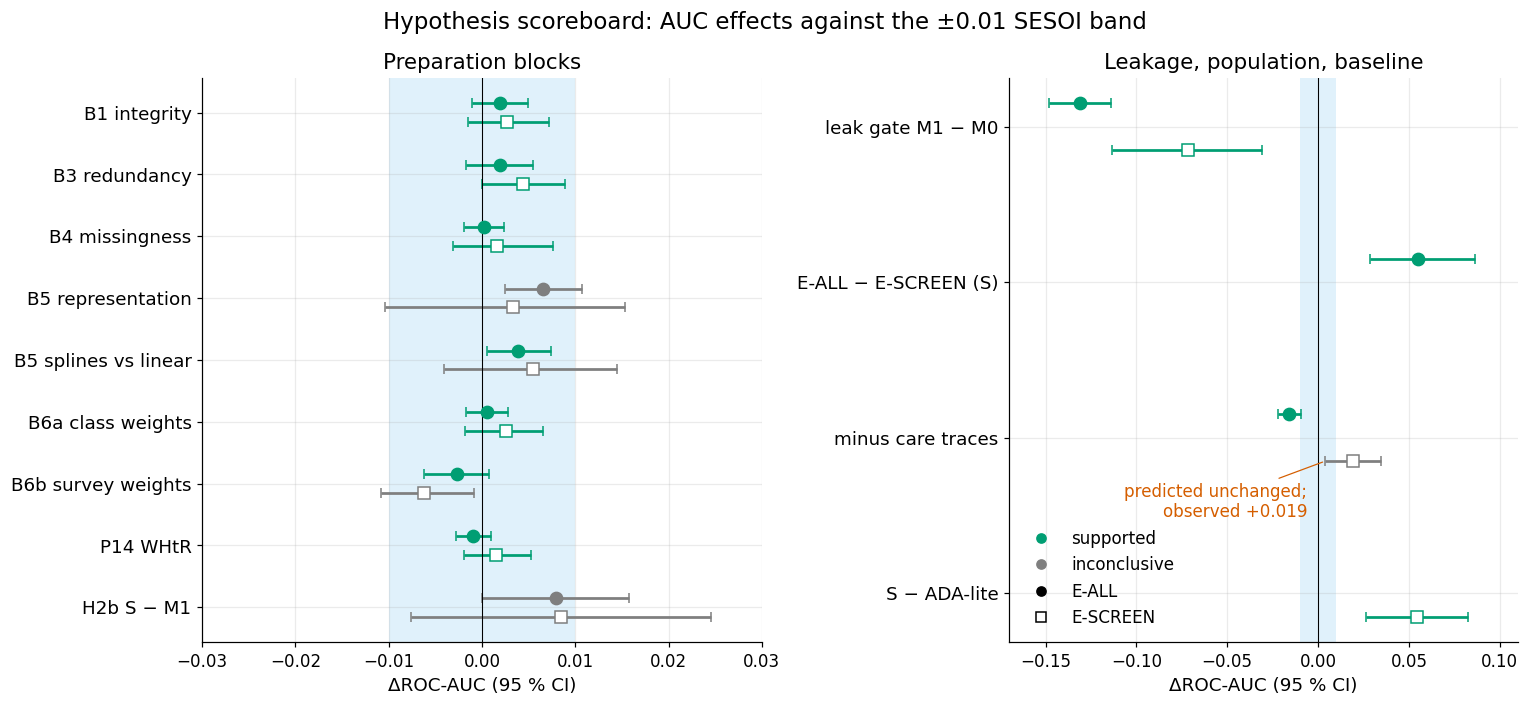

In [234]:
# Forest plot of the paired AUC differences of the locked sub-claims against the +/-0.01 SESOI band.
# Reads the scoreboard detail built above; saves the figure with its caption through plots.savefig.
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
# SEEN collects the verdicts that occur so the legend lists only those; VCOL gives each verdict its colour.
SEEN = set()
VCOL = {"supported": OI["green"], "equivalent": OI["blue"], "refuted": OI["vermillion"], "inconclusive": OI["grey"], "mixed": OI["purple"]}
# Rows are (hypothesis, sub-claim prefix, axis label). The left panel holds the small preparation effects
# and the
# right panel the large leakage/population effects, hence the different x limits.
LEFT = [("B1", "(a) AUC", "B1 integrity"), ("B3", "(a) AUC", "B3 redundancy"), ("B4", "(a) AUC", "B4 missingness"),
        ("B5", "(b) AUC block", "B5 representation"), ("B5", "(c) AUC splines", "B5 splines vs linear"),
        ("B6a", "(a) AUC", "B6a class weights"), ("B6b", "(a) unweighted AUC", "B6b survey weights"),
        ("P14", "(a) AUC", "P14 WHtR"), ("H2b", "(a) AUC", "H2b S − M1")]
RIGHT = [("B2", "(a) AUC M1-M0", "leak gate M1 − M0"), ("H2c", "(i) AUC E-ALL - E-SCREEN (S)", "E-ALL − E-SCREEN (S)"),
         ("H2c", "(ii) minus care, E-ALL", "minus care traces"), ("H2c", "(iii) S - ADA-lite, E-SCREEN", "S − ADA-lite")]
for ax, spec, ttl, lim in ((axes[0], LEFT, "Preparation blocks", (-0.03, 0.03)), (axes[1], RIGHT, "Leakage, population, baseline", (-0.17, 0.11))):
    ylabels = []
    for i, (h, sub, lab) in enumerate(spec):
        # Tier 1 AUC rows of this sub-claim; the 4-character prefix lets the E-ALL and E-SCREEN rows both
        # match.
        g = det[(det["hyp_id"] == h) & (det["sub"].str.startswith(sub[:4])) & (det["metric"] == "roc_auc") & (det["tier"] == 1)]
        if h == "H2c" and sub.startswith("(ii)"):
            g = det[(det["hyp_id"] == "H2c") & det["sub"].str.startswith("(ii)")]
        for _, r in g.iterrows():
            # E-ALL is drawn just above the row centre (filled circle), E-SCREEN just below (hollow square).
            off = -0.15 if r["pop"] in ("E-ALL", "E-ALL minus E-SCREEN") else 0.15
            col = VCOL.get(r["verdict"], OI["grey"])
            SEEN.add(r["verdict"])
            ax.errorbar(r["est"], i + off, xerr=[[r["est"] - r["lo"]], [r["hi"] - r["est"]]], fmt="o" if off < 0 else "s",
                        color=col, mfc=col if off < 0 else "white", capsize=3, ms=8, lw=1.8)
            # Mark the one sub-claim whose CI excludes 0 although the locked prediction was 'unchanged'.
            if h == "H2c" and r["pop"] == "E-SCREEN" and r["verdict"] == "inconclusive" and r["lo"] > 0:
                ax.annotate(f"predicted unchanged;\nobserved {r['est']:+.3f}", (r["lo"], i + off), xytext=(-12, -14), va="top",
                            textcoords="offset points", fontsize=11, color=OI["vermillion"], ha="right",
                            arrowprops=dict(arrowstyle="-", color=OI["vermillion"], lw=0.8))
        ylabels.append(lab)
    # Shaded band = SESOI of +/-0.01 AUC; a CI wholly inside it is evidence of equivalence.
    ax.axvspan(-0.01, 0.01, color=OI["sky"], alpha=0.18, lw=0)
    ax.axvline(0, color="k", lw=0.7)
    ax.set_yticks(range(len(spec)), ylabels, fontsize=12)
    ax.tick_params(axis="x", labelsize=11)
    # First row at the top.
    ax.invert_yaxis()
    ax.set_xlim(lim)
    ax.set_title(ttl, fontsize=14)
    ax.set_xlabel("ΔROC-AUC (95 % CI)", fontsize=12)
from matplotlib.lines import Line2D
hand = [Line2D([], [], marker="o", ls="", color=c, label=v) for v, c in VCOL.items() if v in SEEN]
hand += [Line2D([], [], marker="o", ls="", color="k", label="E-ALL"), Line2D([], [], marker="s", ls="", color="k", mfc="white", label="E-SCREEN")]
axes[1].legend(handles=hand, fontsize=11, loc="lower left")
fig.suptitle("Hypothesis scoreboard: AUC effects against the ±0.01 SESOI band", fontsize=15)
fig.tight_layout()
plots.savefig(fig, "S10_scoreboard_forest", caption="F10-1. Paired ΔROC-AUC of the locked AUC sub-claims (Tier 1; filled = E-ALL, corrected t or "
              "bootstrap, the wider; hollow = E-SCREEN, bootstrap) with 95 % CIs, coloured by the sub-claim verdict under its locked rule; "
              "blue band = SESOI ±0.01. For equivalence claims 'supported' means the CI lies inside the band. Left: preparation blocks "
              "(leave-one-block-out) and the minimal-vs-systematic contrast; right: leakage gate, evaluation population, care traces and baseline.")
plt.show()

**So what.** Every preparation block sits inside or at the edge of the ±0.01 band, while removing leakage (−0.13) and
changing the evaluation population (+0.055) move AUC by 5–13 times the SESOI: what the analyst *includes* and *whom
the model is scored on* matter an order of magnitude more than how carefully admissible data are prepared. The one
sub-claim that missed its locked prediction although its CI excludes 0 – care items on E-SCREEN, predicted
"unchanged", observed +0.019 – is labelled in the figure.

## 10.3 Post-lock notes
**Why.** After the lock, later interpretations must be visible as such. Three entries are recorded in the §10
decision register (not in the locked file): the operational reading of H3, the source of the P14 verdict and the
verdict of H1b. The POST-LOCK M1 sensitivity is recorded in §7.12.1 and DR-S7-16; two post-audit corrections of §9.12
(SD-ratio sub-verdicts, hold-out status) are listed here as well.

In [235]:
# Record the three post-lock interpretation notes (H3 reading, P14 verdict source, H1b verdict) next to their
# consequence. Reads values computed above; the locked hypotheses file itself is never modified.
POSTLOCK = [
    dict(item="H3 reading", note=("'Misses most' is read column-wise: within a diabetes stratum, which training label has the lowest recall "
                                  "(coded in fairness.h3_elements before the matrix was viewed). The row-wise reading – which stratum each label "
                                  f"misses most – is secondary: {lm['row_wise_min']}."),
         consequence=f"H3 {lm['verdict']} under the column-wise reading; the row-wise pattern is reported as a descriptive finding"),
    dict(item="P14 verdict", note=f"§7 entered P14 as '{S7V['P14']['verdict']}' with part (b) deferred; §8 combined (a) and (b)",
         consequence=f"scoreboard uses the §8 combined verdict: {get('S8:verdicts.P14')}"),
    dict(item="H1b verdict", note="§4 reported crude and standardised differences but no verdict line",
         consequence=f"locked rule applied here: standardised {h1b_std:+.2f} pp [{h1b_lo:+.2f}, {h1b_hi:+.2f}] < +2 pp and below crude -> {h1b_v}"),
    dict(item="SD-ratio sub-verdicts (post-audit)", note="the locked rule decided B3-b and H2b(c) with an interval that re-draws the stored bootstrap "
                                                          "replicates (Monte Carlo error, not sampling uncertainty; §9.12, DR-S9-18)",
         consequence="B3-b and H2b(c) shown as 'not testable with this design' next to their locked labels; ratios descriptive; B3 mixed and H2b inconclusive unchanged"),
    dict(item="Hold-out status (post-audit)", note="the hold-out rows took part in the full-cohort §4/§5 diagnostics before the split existed (§9.12, DR-S9-16)",
         consequence="§9.11 is an internal hold-out check, not an independent validation; numbers unchanged; limitation L16"),
]
show(pd.DataFrame(POSTLOCK))

item,note,consequence
H3 reading,"'Misses most' is read column-wise: within a diabetes stratum, which training label has the lowest recall (coded in fairness.h3_elements before the matrix was viewed). The row-wise reading – which stratum each label misses most – is secondary: {'L_self': 'Undiagnosed', 'L_A1c': 'Undiagnosed', 'L_comb': 'Undiagnosed'}.",H3 inconclusive under the column-wise reading; the row-wise pattern is reported as a descriptive finding
P14 verdict,§7 entered P14 as 'supported' with part (b) deferred; §8 combined (a) and (b),scoreboard uses the §8 combined verdict: inconclusive
H1b verdict,§4 reported crude and standardised differences but no verdict line,"locked rule applied here: standardised +0.69 pp [-2.56, +3.93] < +2 pp and below crude -> supported"
SD-ratio sub-verdicts (post-audit),"the locked rule decided B3-b and H2b(c) with an interval that re-draws the stored bootstrap replicates (Monte Carlo error, not sampling uncertainty; §9.12, DR-S9-18)",B3-b and H2b(c) shown as 'not testable with this design' next to their locked labels; ratios descriptive; B3 mixed and H2b inconclusive unchanged
Hold-out status (post-audit),"the hold-out rows took part in the full-cohort §4/§5 diagnostics before the split existed (§9.12, DR-S9-16)","§9.11 is an internal hold-out check, not an independent validation; numbers unchanged; limitation L16"


**So what.** None of the notes changes a locked statement or a stored estimate; they make explicit how ambiguous or
deferred items were resolved and how two post-audit corrections are carried.

## 10.4 Improvements and deteriorations
**Why.** The brief asks for improvements and deteriorations to be explained. A deterioration can be the correct outcome
(removing leakage) and an improvement an artefact (class weights at threshold 0.5); each row gives the mechanism,
the identifying test and the verdict.

In [236]:
# Table of improvements and deteriorations: mechanism, identifying test and verdict for each change.
# Reads the stored §7/§8 results; writes results/S10/improvements_deteriorations.csv.
lg = M["S7"]["leak_gate"]
hl = M["S7"]["headline"]
tm = M["S7"]["tree_m0"]
# Race-reweighing arm: equal-opportunity difference (EOD) by group, indexed by arm and group.
rw = pd.DataFrame(get("S8:reweighing.eod")).set_index(["arm", "group"]).sort_index()
blk = rw.loc[("S+RW(race)", "NH Black")]
asn = rw.loc[("S+RW(race)", "NH Asian")]
b6 = prim[prim["hyp_id"] == "B6a"].set_index("sub")
b5 = prim[prim["hyp_id"] == "B5"].set_index("sub")
ada = M["S7"]["ada_lr_minus_points"]["E-SCREEN"]
b6b_s = det[(det["hyp_id"] == "B6b") & (det["pop"] == "E-SCREEN")].iloc[0]


# Format an estimate with its CI as '+est [lo, hi]' with k decimals.
def ci3(e, lo, hi, k=3):
    return f"{e:+.{k}f} [{lo:+.{k}f}, {hi:+.{k}f}]"


# One row per change: `effect` is the measured paired difference, `mechanism` the explanation and `test` the
# analysis that identifies it. Every number is looked up in stored results, none is typed in.
IMPDET = pd.DataFrame([
    dict(change="Availability rule (M0 → M1)", direction="deterioration (correct)", metric="ΔAUC E-ALL / E-SCREEN",
         effect=f"{ci3(lg['T1_E-ALL']['est'], lg['T1_E-ALL']['lo'], lg['T1_E-ALL']['hi'])} / {ci3(lg['T1_E-SCREEN']['est'], lg['T1_E-SCREEN']['lo'], lg['T1_E-SCREEN']['hi'])}",
         mechanism="treatment and skip-logic items (DIQ070, DIQ180, DID040) exist only for people already diagnosed",
         test=f"tree root on M0 = {M['S7']['tree_roots']['M0']['variable']} (leak role); M1/S root {M['S7']['tree_roots']['S']['variable']}; §9 leak hunt not triggered",
         verdict=f"H2a {S7V['H2a']['verdict']}, B2 {S7V['B2']['verdict']}, B2t {S7V['B2t']['verdict']}"),
    dict(change="Naive median imputation (M0 tree)", direction="deterioration on screening", metric="tree AUC E-SCREEN M0 vs M1",
         effect=f"{tm['escreen_auc']['M0']:.3f} vs {tm['escreen_auc']['M1']:.3f}",
         mechanism=f"DID040 (age at diagnosis) {tm['did040_missing_share']:.0%} missing, filled with the median {tm['did040_fill']:.0f}: the split separates 'diagnosed' from 'imputed'",
         test="depth-3 tree on the M0 frame; level-2 split on DID040", verdict="descriptive (B2t probe)"),
    dict(change="Balanced class weights (B6a)", direction="deterioration (calibration) + artefactual gain", metric="ΔBrier / Δbalanced accuracy at 0.5",
         effect=f"{ci3(b6.loc['(b) Brier', 'est'], b6.loc['(b) Brier', 'lo'], b6.loc['(b) Brier', 'hi'])} / {ci3(b6.loc['(c) balanced accuracy at 0.5', 'est'], b6.loc['(c) balanced accuracy at 0.5', 'lo'], b6.loc['(c) balanced accuracy at 0.5', 'hi'])}",
         mechanism="re-weighting shifts every probability upward; ranking unchanged (ΔAUC "
                   f"{b6.loc['(a) AUC', 'est']:+.4f}); balanced accuracy at 0.5 rises only because 0.5 becomes a better threshold",
         test="leave-one-block-out, paired CV", verdict=f"B6a {S7V['B6a']['verdict']}; H2b(b) refuted"),
    dict(change="Systematic preparation without class weights (S−B6a vs M1)", direction="small improvement", metric="ΔAUC / ΔBrier E-ALL",
         effect=f"{ci3(pp_.loc[('E-ALL', 'roc_auc'), 'diff'], pp_.loc[('E-ALL', 'roc_auc'), 'lo'], pp_.loc[('E-ALL', 'roc_auc'), 'hi'])} / "
                f"{ci3(pp_.loc[('E-ALL', 'brier'), 'diff'], pp_.loc[('E-ALL', 'brier'), 'lo'], pp_.loc[('E-ALL', 'brier'), 'hi'], 4)}",
         mechanism="splines, scaling and pruning give the L2 model a better-posed problem (unscaled M1 hits the iteration limit in every fold)",
         test="paired bootstrap, exploratory (not locked)", verdict="below SESOI; not a verdict"),
    dict(change="Representation block (B5: Yeo-Johnson, scaling, splines)", direction="improvement (calibration)", metric="Δ|calibration slope − 1| E-ALL",
         effect=ci3(b5.loc['(a) |cal slope - 1|', 'est'], b5.loc['(a) |cal slope - 1|', 'lo'], b5.loc['(a) |cal slope - 1|', 'hi']),
         mechanism="mostly solver convergence once features are scaled; spline terms supported by the likelihood-ratio test",
         test=f"LR χ²({M['S7']['lr_test_splines']['1']['df']}) = {M['S7']['lr_test_splines']['1']['chi2']:.1f}", verdict=f"B5 {S7V['B5']['verdict']}"),
    dict(change="Removing care traces (T1-minus-care vs S)", direction="deterioration on E-ALL, improvement on E-SCREEN", metric="ΔAUC E-ALL / E-SCREEN",
         effect=f"{ci3(hl['minus_care_eall']['est'], hl['minus_care_eall']['lo'], hl['minus_care_eall']['hi'])} / {ci3(hl['minus_care_escreen']['est'], hl['minus_care_escreen']['lo'], hl['minus_care_escreen']['hi'])}",
         mechanism="told-high-blood-pressure and told-high-cholesterol items mark people already in care, who are mostly the diagnosed; among the not-yet-diagnosed they add noise",
         test="pre-registered ablation H2c(ii)", verdict="E-ALL supported; E-SCREEN rose (+0.019) instead of staying unchanged; its CI crosses the ±0.01 band (inconclusive)"),
    dict(change="ADA-lite items refitted by logistic regression (vs points)", direction="deterioration on E-SCREEN", metric="ΔAUC E-SCREEN",
         effect=ci3(ada['est'], ada['lo'], ada['hi']),
         mechanism="the refit learns L_comb, 84 % of whose positives are diagnosed: it optimises recognition, not screening",
         test="paired bootstrap", verdict="descriptive"),
    dict(change="Survey-weighted fit (B6b)", direction="small deterioration", metric="ΔAUC E-ALL / E-SCREEN (unweighted metric)",
         effect=f"{ci3(prim[prim['hyp_id'] == 'B6b'].iloc[0]['est'], prim[prim['hyp_id'] == 'B6b'].iloc[0]['lo'], prim[prim['hyp_id'] == 'B6b'].iloc[0]['hi'])} / "
                f"{ci3(b6b_s['est'], b6b_s['lo'], b6b_s['hi'])}",
         mechanism="weights re-target the population and cut the effective n (Kish deff ≈ 1.5)", test="non-inferiority at −0.01",
         verdict=f"B6b {S7V['B6b']['verdict']}"),
    dict(change="Race reweighing (fairness mitigation)", direction="deterioration (NH Black gap widens)", metric="ΔEOD NH Black / NH Asian",
         effect=f"{ci3(blk['d_eod'], blk['d_eod_lo'], blk['d_eod_hi'])} / {ci3(asn['d_eod'], asn['d_eod_lo'], asn['d_eod_hi'])}",
         mechanism=f"race weights range {get('S8:reweighing.weight_range.race')[0]:.2f}–{get('S8:reweighing.weight_range.race')[1]:.2f} (NH Black cases down-weighted most); "
                   "narrowing the prevalence differences moves the shared threshold away from the Black positives. As run, the weights came from unweighted "
                   "counts times survey weights, so group and label were only partly independent"
                   + (f" (race positive-rate spread {PA9['reweighing']['race_spread_pp']['survey']:.1f} → {PA9['reweighing']['race_spread_pp']['as_fitted']:.1f} pp); "
                      f"with weighted counts (exact independence) NH Black EOD {PA9['reweighing']['eod_nh_black']['corrected']:+.3f} vs {PA9['reweighing']['eod_nh_black']['asrun']:+.3f} as run (§9.12)"
                      if PA9 else ""),
         test="paired bootstrap of EOD change; post-audit weighted-count arm", verdict="not adopted (holds for the corrected arm)"),
])
show(IMPDET[["change", "direction", "effect", "mechanism", "verdict"]])
IMPDET.to_csv(OUT / "improvements_deteriorations.csv", index=False)

change,direction,effect,mechanism,verdict
Availability rule (M0 → M1),deterioration (correct),"-0.131 [-0.148, -0.114] / -0.072 [-0.113, -0.031]","treatment and skip-logic items (DIQ070, DIQ180, DID040) exist only for people already diagnosed","H2a supported, B2 supported, B2t supported"
Naive median imputation (M0 tree),deterioration on screening,0.633 vs 0.701,"DID040 (age at diagnosis) 86% missing, filled with the median 50: the split separates 'diagnosed' from 'imputed'",descriptive (B2t probe)
Balanced class weights (B6a),deterioration (calibration) + artefactual gain,"+0.076 [+0.068, +0.084] / +0.145 [+0.123, +0.166]",re-weighting shifts every probability upward; ranking unchanged (ΔAUC +0.0006); balanced accuracy at 0.5 rises only because 0.5 becomes a better threshold,B6a supported; H2b(b) refuted
Systematic preparation without class weights (S−B6a vs M1),small improvement,"+0.007 [+0.000, +0.015] / -0.0018 [-0.0036, -0.0000]","splines, scaling and pruning give the L2 model a better-posed problem (unscaled M1 hits the iteration limit in every fold)",below SESOI; not a verdict
"Representation block (B5: Yeo-Johnson, scaling, splines)",improvement (calibration),"-0.039 [-0.068, -0.010]",mostly solver convergence once features are scaled; spline terms supported by the likelihood-ratio test,B5 inconclusive
Removing care traces (T1-minus-care vs S),"deterioration on E-ALL, improvement on E-SCREEN","-0.016 [-0.022, -0.009] / +0.019 [+0.004, +0.034]","told-high-blood-pressure and told-high-cholesterol items mark people already in care, who are mostly the diagnosed; among the not-yet-diagnosed they add noise",E-ALL supported; E-SCREEN rose (+0.019) instead of staying unchanged; its CI crosses the ±0.01 band (inconclusive)
ADA-lite items refitted by logistic regression (vs points),deterioration on E-SCREEN,"-0.018 [-0.032, -0.002]","the refit learns L_comb, 84 % of whose positives are diagnosed: it optimises recognition, not screening",descriptive
Survey-weighted fit (B6b),small deterioration,"-0.003 [-0.006, +0.001] / -0.006 [-0.011, -0.001]",weights re-target the population and cut the effective n (Kish deff ≈ 1.5),B6b supported
Race reweighing (fairness mitigation),deterioration (NH Black gap widens),"-0.033 [-0.086, -0.003] / -0.018 [-0.093, +0.053]","race weights range 0.70–1.16 (NH Black cases down-weighted most); narrowing the prevalence differences moves the shared threshold away from the Black positives. As run, the weights came from unweighted counts times survey weights, so group and label were only partly independent (race positive-rate spread 11.1 → 4.0 pp); with weighted counts (exact independence) NH Black EOD -0.133 vs -0.131 as run (§9.12)",not adopted (holds for the corrected arm)


**So what.** The biggest change is a *correct deterioration*: the availability rule costs 0.13 AUC because that AUC
was leakage. The biggest *improvement* (balanced accuracy +0.14) is a class-weight artefact that worsens Brier by
0.076 (B6a block, S − S−B6a; the S − M1 Brier gap is +0.074); without class weights, systematic preparation gains
0.007 AUC and no calibration cost. Dropping care traces
lowers whole-sample AUC but raises screening AUC, and refitting ADA items on our label lowers screening AUC – both say
the label rewards *recognising the diagnosed*. Race reweighing widens the NH Black gap and was not adopted; the arm as
run was only partial reweighing, and the post-audit weighted-count version (§9.12) gives the same picture.

## 10.5 What the ML evidence says about the data
**Why.** The project uses simple models as instruments that measure properties of the data; each row names the
property, the probe, the reading, the number and the evidence grade.

In [237]:
# Table of data properties revealed by the models: probe, reading, number and evidence grade.
# Reads stored §3–§9 results; writes results/S10/what_ml_says.csv.
s3 = M["S3"]["blanket_recode"]
mask = M["S5"]["masking"]
cal = pd.DataFrame(get("S8:calibration.table")).set_index("group")
eod = pd.DataFrame(get("S8:eod_eall_t1")).set_index("group")
perm9 = M["S9"]["permutation"]
gdec = M["S8"]["gap_decomposition"]
flips = pd.DataFrame(get("S4:simpson.flips"))
# Simpson sign flips caused by mediator stratifiers (stratifying on a mediator is not a valid adjustment).
n_med_flip = int((flips["role"] == "mediator").sum())
mnar = M["S9"]["mnar"]
# Delta-adjusted (MNAR) prevalence, indexed by the assumed odds ratio for being missing; 1.0 = missing at
# random.
dp = pd.DataFrame(mnar["delta_prevalence"]).set_index("odds_ratio")
WHAT = pd.DataFrame([
    dict(property="Skip-logic leakage", probe="leak gate M0 → M1; depth-3 tree root",
         reading="the naive model's high AUC is a questionnaire-design artefact",
         number=f"AUC {hl['auc_M0_eall_T1']:.3f} → {hl['auc_M1_eall_T1']:.3f}; ΔAUC {ci3(lg['T1_E-ALL']['est'], lg['T1_E-ALL']['lo'], lg['T1_E-ALL']['hi'])}; root {M['S7']['tree_roots']['M0']['variable']}",
         grade="E2"),
    dict(property="Imputation artefact", probe="M0 tree level-2 split",
         reading="a tree learns an imputation constant as if it were biology",
         number=f"DID040 {tm['did040_missing_share']:.0%} missing → {tm['did040_fill']:.0f}; tree E-SCREEN AUC {tm['escreen_auc']['M0']:.3f} vs {tm['escreen_auc']['M1']:.3f}",
         grade="E1"),
    dict(property="Blanket sentinel cleaning", probe="per-variable vs blanket recode",
         reading="cleaning itself destroys information and labels",
         number=f"{s3['valid_cells_destroyed_cohort']:,} valid cells; {s3['a1c_positives_lost']}/{s3['a1c_positives']} HbA1c positives; {s3['l_comb_flips']}/{s3['l_comb_positives']} L_comb flips",
         grade="E1"),
    dict(property="Structural redundancy", probe="bootstrap SD of the BMI coefficient",
         reading="redundancy destabilises explanation, not prediction; L2 + scaling absorb most of it (ratios descriptive, post-audit)",
         number=f"SD ratio unscaled {cs['ratio_cumulative']['ratio']:.2f}, inside scaled L2 {cs['ratio_B3']['ratio']:.2f}; ΔAUC B3 "
                f"{prim[(prim['hyp_id'] == 'B3') & (prim['sub'] == '(a) AUC')].iloc[0]['est']:+.4f}",
         grade="E3"),
    dict(property="Spectrum / label composition", probe="same predictions scored on E-ALL and E-SCREEN",
         reading="whole-sample AUC measures recognition of known diabetes",
         number=f"S {hl['auc_S_eall_T1']:.3f} vs {hl['auc_S_escreen_T1']:.3f}; gap {ci3(hl['eall_minus_escreen_S_T1']['est'], hl['eall_minus_escreen_S_T1']['lo'], hl['eall_minus_escreen_S_T1']['hi'])}",
         grade="E2"),
    dict(property="Care traces", probe="T1-minus-care ablation on both populations",
         reading="contact-with-care items help recognition and hinder screening",
         number=f"E-ALL {hl['minus_care_eall']['est']:+.3f}; E-SCREEN {ci3(hl['minus_care_escreen']['est'], hl['minus_care_escreen']['lo'], hl['minus_care_escreen']['hi'])}",
         grade="E3"),
    dict(property="Label is a measurement", probe="3 × 3 label matrix; treatment masking",
         reading="each label misses different people; no label lets these features find the undiagnosed",
         number=f"masking {mask['below_6_5']}/{mask['self_reported']} ({mask['below_6_5_share']:.1%}); recall Undiagnosed "
                f"{lm['recall']['Undiagnosed']['L_self']:.2f}/{lm['recall']['Undiagnosed']['L_A1c']:.2f}/{lm['recall']['Undiagnosed']['L_comb']:.2f}",
         grade="E3"),
    dict(property="Diagnosis gap by access", probe="model TPR diagnosed vs undiagnosed; group decomposition",
         reading="the model inherits who has been diagnosed",
         number=f"TPR diagnosed {gdec['tpr_diagnosed']:.2f} vs undiagnosed {gdec['tpr_undiagnosed']:.2f}; r(group TPR, care-trace share) {gdec['r_tpr_care_trace']:.2f}",
         grade="E3"),
    dict(property="BMI measurement bias", probe="single-feature AUC WHtR vs BMI; Asian TPR gap",
         reading="BMI under-measures adiposity in Asian adults; the full model only partly compensates",
         number=f"Asian gain {get('S5:asian_bmi.auc.NH Asian|WHtR − BMI (paired).auc'):+.3f} vs White {get('S5:asian_bmi.auc.NH White|WHtR − BMI (paired).auc'):+.3f}; "
                f"EOD Asian {eod.loc['NH Asian', 'eod']:+.3f} [{eod.loc['NH Asian', 'eod_lo']:+.3f}, {eod.loc['NH Asian', 'eod_hi']:+.3f}]",
         grade="E3 (Asian cells exploratory)"),
    dict(property="Calibration across groups", probe="observed : expected by race",
         reading="a race-blind model is calibrated on average, not within race",
         number="O:E " + ", ".join(f"{g} {cal.loc[g, 'oe']:.2f}" for g in ["NH White", "NH Black", "NH Asian", "Mexican American"]),
         grade="E3"),
    dict(property="Procedure credibility", probe="label permutation; positive control",
         reading="no procedural leakage; weak real signal is detectable (does not exclude feature leakage)",
         number=f"null mean M1 {perm9['M1']['null_mean']:.4f}, S {perm9['S']['null_mean']:.4f}; synthetic AUC-0.60 feature detected "
                f"({sum(r['detected'] for r in M['S9']['positive_control']['rows'])}/{len(M['S9']['positive_control']['rows'])})",
         grade="E1"),
    dict(property="Missing HbA1c", probe="IPW and delta-adjusted (MNAR) prevalence; S − M1 under MNAR",
         reading="missingness is not ignorable in principle but barely moves prevalence or the comparison",
         number=f"prevalence {dp.loc[1.0, 'prevalence']:.1%} (MAR) to {dp.iloc[-1]['prevalence']:.1%} at odds ratio {dp.index[-1]:.0f}; Manski [{mnar['manski'][0]:.1%}, {mnar['manski'][1]:.1%}]",
         grade="E3"),
])
show(WHAT)
WHAT.to_csv(OUT / "what_ml_says.csv", index=False)

property,probe,reading,number,grade
Skip-logic leakage,leak gate M0 → M1; depth-3 tree root,the naive model's high AUC is a questionnaire-design artefact,"AUC 0.961 → 0.828; ΔAUC -0.131 [-0.148, -0.114]; root DIQ070",E2
Imputation artefact,M0 tree level-2 split,a tree learns an imputation constant as if it were biology,DID040 86% missing → 50; tree E-SCREEN AUC 0.633 vs 0.701,E1
Blanket sentinel cleaning,per-variable vs blanket recode,cleaning itself destroys information and labels,"1,496 valid cells; 29/721 HbA1c positives; 6/971 L_comb flips",E1
Structural redundancy,bootstrap SD of the BMI coefficient,"redundancy destabilises explanation, not prediction; L2 + scaling absorb most of it (ratios descriptive, post-audit)","SD ratio unscaled 2.87, inside scaled L2 1.36; ΔAUC B3 +0.0019",E3
Spectrum / label composition,same predictions scored on E-ALL and E-SCREEN,whole-sample AUC measures recognition of known diabetes,"S 0.836 vs 0.781; gap +0.055 [+0.028, +0.086]",E2
Care traces,T1-minus-care ablation on both populations,contact-with-care items help recognition and hinder screening,"E-ALL -0.016; E-SCREEN +0.019 [+0.004, +0.034]",E3
Label is a measurement,3 × 3 label matrix; treatment masking,each label misses different people; no label lets these features find the undiagnosed,masking 250/819 (30.5%); recall Undiagnosed 0.50/0.56/0.52,E3
Diagnosis gap by access,model TPR diagnosed vs undiagnosed; group decomposition,the model inherits who has been diagnosed,"TPR diagnosed 0.70 vs undiagnosed 0.52; r(group TPR, care-trace share) 0.63",E3
BMI measurement bias,single-feature AUC WHtR vs BMI; Asian TPR gap,BMI under-measures adiposity in Asian adults; the full model only partly compensates,"Asian gain +0.137 vs White +0.049; EOD Asian -0.184 [-0.343, -0.014]",E3 (Asian cells exploratory)
Calibration across groups,observed : expected by race,"a race-blind model is calibrated on average, not within race","O:E NH White 0.88, NH Black 1.30, NH Asian 1.35, Mexican American 1.39",E3


**So what.** Read top to bottom, the table is the project's argument: the data carry their *collection process* –
skip patterns, imputation constants, sentinel codes, who has been diagnosed, which body-size measure was taken – and
an unexamined model learns that process instead of diabetes. Probes that cost nothing in sophistication (a depth-3
tree, an ablation, a second evaluation population) expose more than any gain in AUC would.

## 10.6 Headline findings
**Why.** The video carries three findings, each backed by at least two independent lines of evidence; one is chosen
as the headline non-obvious modelling finding.

In [238]:
# Collect the three findings for the video and the evidence lines behind the chosen modelling headline.
# Reads stored results, including the internal hold-out check when available; writes
# results/S10/headline_findings.csv.
pc = pd.DataFrame(M["S9"]["positive_control"]["rows"])
# The hold-out may be absent in a re-run; HO_OK switches every hold-out reference on or off.
HO = M["S9"].get("holdout", {})
HO_OK = "metrics" in HO
if HO_OK:
    HOM = pd.DataFrame(HO["metrics"]).set_index(["arm", "tier", "pop"]).sort_index()
    HOP = pd.DataFrame(HO["pairs"]).set_index(["comparison", "pop"]).sort_index()
print(f"hold-out available: {HO_OK}" + ("" if HO_OK else f" ({HO.get('status', 'missing')})"))
F = {
    "F1 Leakage and naive cleaning": [
        f"leak gate ΔAUC {ci3(lg['T1_E-ALL']['est'], lg['T1_E-ALL']['lo'], lg['T1_E-ALL']['hi'])} (E-SCREEN {lg['T1_E-SCREEN']['est']:+.3f})",
        f"M0 tree splits on {M['S7']['tree_roots']['M0']['variable']} then on DID040 = median {tm['did040_fill']:.0f} ({tm['did040_missing_share']:.0%} missing); "
        f"tree E-SCREEN AUC M0 {tm['escreen_auc']['M0']:.3f} < M1 {tm['escreen_auc']['M1']:.3f}",
        f"blanket recode destroys {s3['valid_cells_destroyed_cohort']:,} valid cells; {s3['a1c_positives_lost']} vs {s3['l_comb_flips']} label flips (HbA1c-only vs frozen L_comb)",
        f"§9 leak hunt on admissible arms: not triggered (max single-feature AUC {M['S9']['leak_hunt']['strongest_admissible']['auc']:.3f})"]
    + ([f"hold-out M1 − M0 {ci3(HOP.loc[('M1 T1 - M0 T1', 'E-ALL'), 'est'], HOP.loc[('M1 T1 - M0 T1', 'E-ALL'), 'lo'], HOP.loc[('M1 T1 - M0 T1', 'E-ALL'), 'hi'])}"] if HO_OK else []),
    "F2 Fallacies and measurement of performance": [
        f"insurance gap {ins['crude']:+.1f} → {ins['std']:+.1f} pp after age standardisation (attenuation)",
        f"Asian − White {get('S4:standardisation.asian_white.crude'):+.1f} → {get('S4:standardisation.asian_white.std'):+.1f} pp, both CIs include 0",
        f"BMI is a mediator in the DAG; {n_med_flip} of {len(flips)} Simpson sign flips come from mediator stratifiers",
        f"spectrum gap E-ALL − E-SCREEN {ci3(hl['eall_minus_escreen_S_T1']['est'], hl['eall_minus_escreen_S_T1']['lo'], hl['eall_minus_escreen_S_T1']['hi'])}",
        f"care-trace reversal: E-ALL {hl['minus_care_eall']['est']:+.3f}, E-SCREEN {ci3(hl['minus_care_escreen']['est'], hl['minus_care_escreen']['lo'], hl['minus_care_escreen']['hi'])}"],
    "F3 Label and measurement bias": [
        f"treatment masking {mask['below_6_5']}/{mask['self_reported']} = {mask['below_6_5_share']:.1%} ({mask['below_6_5_on_med']} on medication)",
        f"undiagnosed risk difference uninsured − insured {rd['rd_pp']:+.1f} pp [{rd['ci_low_pp']:.1f}, {rd['ci_high_pp']:.1f}]",
        f"3 × 3 matrix: H3 {lm['verdict']}; Undiagnosed is the lowest-recall stratum for every training label",
        f"NH Asian TPR gap {eod.loc['NH Asian', 'eod']:+.3f} [{eod.loc['NH Asian', 'eod_lo']:+.3f}, {eod.loc['NH Asian', 'eod_hi']:+.3f}], race permutation p {get('S8:permutation_eall_t1[attribute=race].p_value'):.3f}",
        f"WHtR − BMI single-feature gain difference Asian − White {gd['est']:+.3f} [{gd['psu_ci_low']:+.3f}, {gd['psu_ci_high']:+.3f}]",
        "calibration O:E by race " + ", ".join(f"{g} {cal.loc[g, 'oe']:.2f}" for g in ["NH White", "NH Black", "NH Asian", "Mexican American"])],
}
for k, v in F.items():
    print(k)
    for line in v:
        print("   -", line)

# headline: whole-sample AUC measures recognition of known diabetes, not screening
# Independent evidence lines for the headline, each from a different analysis (a headline needs at least
# two, §10.7).
HEAD_LINES = [
    ("pre-registered spectrum gap (H2c-i, supported)", f"{ci3(hl['eall_minus_escreen_S_T1']['est'], hl['eall_minus_escreen_S_T1']['lo'], hl['eall_minus_escreen_S_T1']['hi'])}"),
    ("care-trace ablation changes sign between populations (H2c-ii)", f"E-ALL {hl['minus_care_eall']['est']:+.3f} vs E-SCREEN {hl['minus_care_escreen']['est']:+.3f}"),
    ("ADA items refitted on L_comb lose screening AUC", f"{ada['est']:+.3f} [{ada['lo']:+.3f}, {ada['hi']:+.3f}]"),
    ("§8 TPR: diagnosed vs undiagnosed positives at the same threshold", f"{gdec['tpr_diagnosed']:.2f} vs {gdec['tpr_undiagnosed']:.2f}"),
    ("§8 3 × 3 matrix: Undiagnosed column lowest under every label", str(lm["row_wise_min"])),
    ("leakage also is recognition: the leak gate is smaller on E-SCREEN", f"{lg['T1_E-ALL']['est']:+.3f} vs {lg['T1_E-SCREEN']['est']:+.3f}"),
]
if HO_OK:
    # Hold-out AUCs of arm S on both populations; only direction and size of the gap are compared with CV.
    s_all, s_scr = HOM.loc[("S", 1, "E-ALL"), "roc_auc"], HOM.loc[("S", 1, "E-SCREEN"), "roc_auc"]
    HEAD_LINES.append(("internal hold-out check, arm S: same direction and size (not separately testable, 25 screening positives)",
                       f"E-ALL {s_all:.3f} vs E-SCREEN {s_scr:.3f} (gap {s_all - s_scr:+.3f} vs {hl['eall_minus_escreen_S_T1']['est']:+.3f} in CV)"))
print("\nHEADLINE – whole-sample AUC measures recognition of known diabetes, not screening; distinct evidence lines:")
for a, b in HEAD_LINES:
    print(f"   - {a}: {b}")
S10["headline"] = dict(finding="Whole-sample AUC measures recognition of known diabetes, not screening",
                       n_evidence_lines=len(HEAD_LINES), lines=[f"{a}: {b}" for a, b in HEAD_LINES])
S10["findings"] = F
HF = pd.DataFrame([dict(finding=k, order=i + 1, evidence=line) for k, v in F.items() for i, line in enumerate(v)]
                  + [dict(finding="HEADLINE " + S10["headline"]["finding"], order=i + 1, evidence=f"{x}: {y}") for i, (x, y) in enumerate(HEAD_LINES)])
HF.to_csv(OUT / "headline_findings.csv", index=False)   # slide material for the three video findings

hold-out available: True
F1 Leakage and naive cleaning
   - leak gate ΔAUC -0.131 [-0.148, -0.114] (E-SCREEN -0.072)
   - M0 tree splits on DIQ070 then on DID040 = median 50 (86% missing); tree E-SCREEN AUC M0 0.633 < M1 0.701
   - blanket recode destroys 1,496 valid cells; 29 vs 6 label flips (HbA1c-only vs frozen L_comb)
   - §9 leak hunt on admissible arms: not triggered (max single-feature AUC 0.706)
   - hold-out M1 − M0 -0.117 [-0.144, -0.092]
F2 Fallacies and measurement of performance
   - insurance gap +5.3 → +0.7 pp after age standardisation (attenuation)
   - Asian − White -0.8 → +2.1 pp, both CIs include 0
   - BMI is a mediator in the DAG; 4 of 6 Simpson sign flips come from mediator stratifiers
   - spectrum gap E-ALL − E-SCREEN +0.055 [+0.028, +0.086]
   - care-trace reversal: E-ALL -0.016, E-SCREEN +0.019 [+0.004, +0.034]
F3 Label and measurement bias
   - treatment masking 250/819 = 30.5% (165 on medication)
   - undiagnosed risk difference uninsured − insured +23.2 pp

**So what – choice of the headline.** The modelling headline is **"a whole-sample AUC measures recognition of known
diabetes, not screening"** – spectrum bias (Ransohoff & Feinstein 1978) created by the label's composition (84 % of
positives already diagnosed), not by the model. It is non-obvious (one whole-sample AUC hides it), carried by six
evidence lines from §7–§8 (the internal hold-out check shows the same direction and size, +0.060 vs +0.055, but is not separately
testable with 25 screening positives), and actionable (report E-SCREEN; keep care traces out of screening models).
Its pre-registered core H2c(i) is supported; H2c as a whole is inconclusive because the care-trace sub-claim (ii) on
E-SCREEN rose (+0.019) instead of staying unchanged, with a CI that crosses the ±0.01 band.

**Non-obvious pattern found through systematic profiling and EDA** (the brief's requirement): the sentinel profiling
of §3 found that a blanket 7/9/77/99 recode deletes valid HbA1c values of exactly 7.0 % and 9.0 % – 29 HbA1c-defined positives –
and the §7.5 tree probe showed that median imputation turns the skip-pattern item "age at diagnosis" into a constant
that codes the label. Both are invisible to summary statistics and are the leakage and naive-cleaning finding (F1).

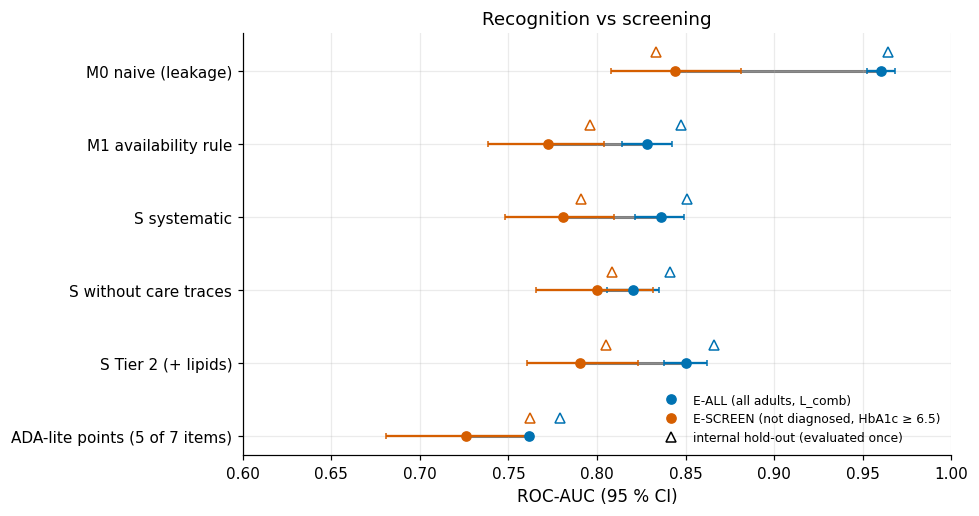

In [239]:
# Dumbbell plot: the same out-of-fold AUCs scored on E-ALL (recognition) and E-SCREEN (screening) per arm.
# Reads the §7 arm metrics and baselines, plus hold-out markers when available; saves the figure with caption.
fig, ax = plt.subplots(figsize=(9, 4.8))
# Arm metrics indexed by (arm, tier, model); the 'lr' rows are the logistic-regression results.
am = pd.DataFrame(M["S7"]["arm_metrics"]).set_index(["arm", "tier", "model"])
bl = M["S7"]["baselines"]
# Rows are (arm, tier, label); Tier 2 adds lipid measurements to the arm S features.
ARMS_FIG = [("M0", 1, "M0 naive (leakage)"), ("M1", 1, "M1 availability rule"), ("S", 1, "S systematic"),
            ("T1-minus-care", 1, "S without care traces"), ("S", 2, "S Tier 2 (+ lipids)")]
for i, (a, t, lab) in enumerate(ARMS_FIG):
    r = am.loc[(a, t, "lr")]
    # The grey bar spans the two AUCs: its length is the cost of moving from recognition to screening.
    ax.plot([r["escr_auc"], r["eall_auc"]], [i, i], color=OI["grey"], lw=2, zorder=1)
    ax.errorbar(r["eall_auc"], i, xerr=[[r["eall_auc"] - r["eall_auc_lo"]], [r["eall_auc_hi"] - r["eall_auc"]]], fmt="o", color=OI["blue"], capsize=2, zorder=2)
    ax.errorbar(r["escr_auc"], i, xerr=[[r["escr_auc"] - r["escr_auc_lo"]], [r["escr_auc_hi"] - r["escr_auc"]]], fmt="o", color=OI["vermillion"], capsize=2, zorder=2)
    # Internal hold-out AUCs as hollow triangles just below the CV points.
    if HO_OK and (a, t, "E-ALL") in HOM.index:
        ax.plot(HOM.loc[(a, t, "E-ALL"), "roc_auc"], i - 0.25, "^", color=OI["blue"], mfc="white", ms=6)
        ax.plot(HOM.loc[(a, t, "E-SCREEN"), "roc_auc"], i - 0.25, "^", color=OI["vermillion"], mfc="white", ms=6)
# Extra last row: the ADA-lite points score, a simple points-based risk score used as the baseline.
j = len(ARMS_FIG)
ada_p = bl["BL-ADAlite (points)"]
ax.errorbar(ada_p["escr_auc"], j, xerr=[[ada_p["escr_auc"] - ada_p["lo"]], [ada_p["hi"] - ada_p["escr_auc"]]], fmt="o", color=OI["vermillion"], capsize=2)
ax.plot(ada_p["eall_auc"], j, "o", color=OI["blue"])
ax.plot([ada_p["escr_auc"], ada_p["eall_auc"]], [j, j], color=OI["grey"], lw=2, zorder=0)
if HO_OK:
    for pop_, col_ in (("E-ALL", OI["blue"]), ("E-SCREEN", OI["vermillion"])):
        ax.plot(HOM.loc[("BL-ADAlite", 1, pop_), "roc_auc"], j - 0.25, "^", color=col_, mfc="white", ms=6)
ax.set_yticks(range(j + 1), [l for _, _, l in ARMS_FIG] + ["ADA-lite points (5 of 7 items)"])
ax.invert_yaxis()
leg = [Line2D([], [], marker="o", ls="", color=OI["blue"], label="E-ALL (all adults, L_comb)"),
       Line2D([], [], marker="o", ls="", color=OI["vermillion"], label="E-SCREEN (not diagnosed, HbA1c ≥ 6.5)")]
if HO_OK:
    leg.append(Line2D([], [], marker="^", ls="", color="k", mfc="white", label="internal hold-out (evaluated once)"))
ax.legend(handles=leg, fontsize=8, loc="lower right")
ax.set(xlabel="ROC-AUC (95 % CI)", xlim=(0.6, 1.0), title="Recognition vs screening")
fig.tight_layout()
plots.savefig(fig, "S10_recognition_vs_screening", caption="F10-2. The same out-of-fold predictions scored on E-ALL (blue; all adults, 84 % of "
              "positives already diagnosed) and E-SCREEN (red; adults without a diagnosis, positive = HbA1c ≥ 6.5 %), training part, 95 % "
              "bootstrap CIs; triangles = internal hold-out check where available. Every arm loses AUC on the screening population; the arm without "
              "care-trace items is the only one that ranks higher on E-SCREEN than arm S.")
plt.show()

**So what.** The grey bars are the price of moving from "recognise the diagnosed" to "find the undiagnosed": about 0.12
for M0, about 0.055 for the admissible arms, and only 0.02 for the arm without care traces – the best screening
model although the worst on E-ALL.

## 10.7 Claims ledger
**Why.** Every statement for the summary or the video becomes a row of `governance/claims.csv` with grade, evidence,
CI, robustness, external reference, scope, falsifier and video segment. Enforced in code: at most 25 words; the verb
follows the grade; no causal verbs; a **headline** claim with fewer than two independent evidence lines is
downgraded automatically.

In [240]:
# Build the claims ledger: each claim gets a grade, evidence lines, CI, scope and falsifier from stored
# results.
# Reads stored results; asserts the wording rules (<= 25 words, grade verbs, no causal verbs); writes
# claims files.
# Evidence grade -> verb: the strength of the wording follows the grade (E1 confirms ... E4 suggests).
LADDER = {"E1": "confirms that", "E2": "shows that", "E3": "is consistent with the view that", "E4": "suggests that"}
# Forbidden causal wording: the data are observational, so statements may only claim association.
CAUSAL = re.compile(r"\b(caus\w*|drive[sn]?|driven|leads? to|results? in|due to|because|impact\w*|effect of|prevent\w*)\b", re.I)
# Video segments with their time slots; every claim is assigned to exactly one.
VSEG = {"V1": "0:00-1:30 scope and design", "V2": "1:30-2:15 cost of naive cleaning", "V3": "2:15-3:30 leakage gate",
        "V4": "3:30-4:30 redundancy and skew", "V5": "4:30-6:00 fallacies", "V6": "6:00-8:30 label and measurement bias",
        "V7": "8:30-10:15 models and evaluation", "V8": "10:15-11:20 what ML says about the data"}
# §9 robustness summary for E-ALL. Row labels contain run-dependent counts (seeds, specifications), so rows
# are
# found by their suffix instead of by full name.
sm = M["S9"]["summary"]["table"]
sm_e = {r["check"]: r for r in sm if r["pop"] == "E-ALL"}
pick = lambda suf: next(v for k, v in sm_e.items() if k.endswith(suf))   # labels carry the run's counts (FAST 5 seeds / 30 specs)
N_SEEDS, N_CURVE = M["S9"]["seeds"]["n"], M["S9"]["specification_curve"]["n"]
# The leading integer of the label is the number of sensitivity specifications that were run.
N_SENS = int(pick("sensitivity specs")["check"].split()[0])
# Robustness strings quoted in the ledger are assembled from §9 results so that they cannot drift from the
# notebook.
ROB_H2B = (f"{N_SEEDS} seeds {pick('CV seeds')['verdicts']}; {N_SENS} specs {pick('sensitivity specs')['verdicts']}; "
           f"{N_CURVE}-spec curve {pick('-spec curve')['verdicts']}; PSU-grouped CV {sm_e['strata x PSU grouped CV']['verdicts']}; "
           f"IPW {sm_e['IPW (evaluation; fit + evaluation)']['verdicts']}")
ROB_LEAK = (f"own-C tuning gives the same gate {M['S9']['sensitivity']['leak_gate_own_C']['E-ALL']['est']:+.3f}; permutation null "
            f"{perm9['M1']['null_mean']:.3f}; leak hunt not triggered")
ROB_NONE = "not varied in §9 (single specification)"
db = M["S4"]["db516"]
v2 = pd.DataFrame(M["S9"]["external"]["v2"]).set_index("quantity")
v2d = v2.loc["definition effect C - B"]
ADA_ITEMS, ADA_MISS = get("S1:ada_lite.items"), get("S1:ada_lite.missing")
PUB_DB516 = {"total": 15.8, "diagnosed": 11.3, "undiagnosed": 4.5}   # published NCHS Data Brief 516 (external reference)
EXT_DB = (f"NCHS DB516: reproduced {db['total']:.2f}/{db['diagnosed']:.2f}/{db['undiagnosed']:.2f} % vs published "
          f"{PUB_DB516['total']}/{PUB_DB516['diagnosed']}/{PUB_DB516['undiagnosed']}")
# Format est [lo, hi] for a record with keys est, lo and hi.
sw = lambda r: f"{r['est']:+.3f} [{r['lo']:+.3f}, {r['hi']:+.3f}]"
und = get("S5:undiagnosed_meaning.contact.blood test past 3 years (DIQ180=1)")
pe = lambda h: HYP.loc[h, "prior"]
eod_b = rw.loc[("S+RW(race)", "NH Black")]
whtr_a = get("S5:asian_bmi.auc.NH Asian|WHtR − BMI (paired).auc")
whtr_w = get("S5:asian_bmi.auc.NH White|WHtR − BMI (paired).auc")
max_lab_diff = float(h3c["est"].abs().max())
hx = h3c.loc[h3c["est"].abs().idxmax()]
fx = flips[flips["role"] == "mediator"].iloc[0]
oe_lo = min(cal.loc[g, "oe"] for g in ["NH Black", "NH Asian", "Mexican American"])
oe_hi = max(cal.loc[g, "oe"] for g in ["NH Black", "NH Asian", "Mexican American"])
std_tab = pd.read_csv(C.RESULTS_DIR / "S4" / "std_differences.csv")
std_ins = std_tab[std_tab["contrast"] == "insured − uninsured"]["std"]
std_asw = std_tab[std_tab["contrast"] == "NH Asian − NH White"]["std"]
adj_u = get("S5:undiagnosed_inequality.adjusted_logit.uninsured")
told_bl = get("S5:undiagnosed_meaning.contact.told borderline (DIQ010=3)")
asian_pos_train = int(get("S8:group_sizes[group=NH Asian].pos_eall"))
asian_n = int(get("S5:representation.shares.race|NH Asian.n"))
uninsured_n = int(get("S5:undiagnosed_inequality.proportions.uninsured.n"))
asian_whtr_n = int(get("S5:asian_bmi.auc.NH Asian|WHtR.n"))
sum9 = {r["check"]: r["verdicts"] for r in M["S9"]["summary"]["table"] if r["pop"] == "E-ALL"}
top10_pass = sum(r["verdict"] == "PASS" for r in M["S9"]["leak_hunt"]["top10"])

# One dict per claim: id, video segment, headline flag, evidence grade, type, subject, proposition,
# evidence lines,
# effect with CI, pre-registration status, robustness, external reference, scope, falsifier and hypothesis
# ids.
# Numbers inside the text are f-string look-ups into stored results; none is typed in by hand.
# --- leakage and naive cleaning (C01-C04)
CL = [
    dict(cid="C01", vs="V3", head=True, grade="E2", type="leakage", subj="The leak gate",
         prop=f"removing inadmissible items (treatment, diagnosis history, glucose testing) lowers E-ALL AUC by {-lg['T1_E-ALL']['est']:.2f}, and the excess was leakage",
         ev=["§7 paired CV leak gate (H2a/B2)", "§7 depth-3 tree root on a treatment item (B2t)", "§9 leak hunt on admissible arms", "§9 permutation null"]
            + (["§9 internal hold-out M1 − M0"] if HO_OK else []),
         eff=f"ΔAUC M1 − M0 E-ALL {sw(lg['T1_E-ALL'])}; E-SCREEN {sw(lg['T1_E-SCREEN'])}", prereg=pe("H2a"),
         rob=ROB_LEAK + (f"; internal hold-out {sw(HOP.loc[('M1 T1 - M0 T1', 'E-ALL')])}" if HO_OK else ""), ext="none",
         scope="training part, Tier 1, E-ALL", fals="CI of M1 − M0 reaching above −0.05", hyp="H2a;B2;B2t"),
    dict(cid="C02", vs="V3", head=False, grade="E1", type="data_artefact", subj="The naive tree",
         prop=f"median imputation turns age at diagnosis ({tm['did040_missing_share']:.0%} missing) into a constant {tm['did040_fill']:.0f} that the tree splits on",
         ev=["§7 tree structure of M0"], eff=f"fill {tm['did040_fill']:.0f}; tree E-SCREEN AUC M0 {tm['escreen_auc']['M0']:.3f} vs M1 {tm['escreen_auc']['M1']:.3f} (descriptive)",
         prereg="none (tree probe B2t)", rob=ROB_NONE, ext="none", scope="M0 frame, training part", fals="M0 tree without a DID040 split", hyp="B2t"),
    dict(cid="C03", vs="V2", head=False, grade="E1", type="cleaning_cost", subj="The sentinel audit",
         prop=f"a blanket 7/9/77/99 recode destroys {s3['valid_cells_destroyed_cohort']:,} valid cells and {s3['a1c_positives_lost']} of {s3['a1c_positives']} HbA1c-positive labels",
         ev=["§3.3–§3.4 per-variable vs blanket recode counts", f"§6 label rebuilt from naive data ({M['S6']['B1']['naive_lcomb_pos']} vs {s3['l_comb_positives']} positives)"],
         eff=f"{s3['valid_cells_destroyed_cohort']:,} cells; {s3['a1c_positives_lost']}/{s3['a1c_positives']}; L_comb flips {s3['l_comb_flips']}/{s3['l_comb_positives']}",
         prereg="analysis_seen", rob="deterministic count", ext="NHANES codebooks (sentinels only on questionnaire items)", scope="cohort 5,730",
         fals="a recount giving a different number", hyp="B1"),
    dict(cid="C04", vs="V2", head=False, grade="E2", type="fidelity", subj="Leave-one-block-out ablation",
         prop=f"repairing XPT zeros and sentinels changes E-ALL AUC by only {prim[(prim['hyp_id'] == 'B1')].iloc[0]['est']:+.3f}: justified by fidelity, not performance",
         ev=["§7 paired CV B1", "§7 E-SCREEN and Tier 2 replicates"], eff=f"ΔAUC {sw(prim[prim['hyp_id'] == 'B1'].iloc[0])}",
         prereg=pe("B1"), rob="same verdict on E-SCREEN and Tier 2", ext="none", scope="training part", fals="CI wholly beyond ±0.01", hyp="B1"),
    # --- minimal versus systematic preparation, spectrum and care traces (C05-C10)
    dict(cid="C05", vs="V7", head=True, grade="E3", type="minimal_vs_systematic", subj="The M1-versus-S contrast",
         prop=f"systematic preparation changes AUC by under {h2b.loc['(a) AUC', 'hi']:.3f}; equivalence stays unestablished (MDD {h2b.loc['(a) AUC', 'mdd']:.3f})",
         ev=["§7 paired CV H2b(a)", f"§9 {N_SEEDS} seeds", f"§9 {N_SENS}-spec table", f"§9 {N_CURVE}-spec curve", "§9 PSU-grouped CV"] + (["§9 internal hold-out S − M1"] if HO_OK else []),
         eff=f"ΔAUC {sw(h2b.loc['(a) AUC'])}; Brier {h2b.loc['(b) Brier', 'est']:+.3f} (refuted, class weights); pure preparation ΔAUC {pp_.loc[('E-ALL', 'roc_auc'), 'diff']:+.3f}",
         prereg=pe("H2b"), rob=ROB_H2B + (f"; internal hold-out {sw(HOP.loc[('S T1 - M1 T1', 'E-ALL')])} ({HOP.loc[('S T1 - M1 T1', 'E-ALL'), 'verdict']})" if HO_OK else "")
             + (f"; post-audit: C nested in folds {sw(PA9['nested_c']['dauc_nested'])}, S − M1c (codebook recode) {sw(PA9['m1c']['S_minus_M1c_eall'])}, both "
                f"{PA9['m1c']['S_minus_M1c_eall']['verdict']}" if PA9 else ""),
         ext="none", scope="training part, E-ALL, Tier 1", fals="CI of S − M1 wholly beyond ±0.01", hyp="H2b"),
    dict(cid="C06", vs="V7", head=False, grade="E2", type="deterioration", subj="Paired cross-validation",
         prop=f"balanced class weights worsen the Brier score by {b6.loc['(b) Brier', 'est']:.3f} at unchanged AUC; without them preparation costs no calibration",
         ev=["§7 paired CV B6a(b)", "§7 pure-preparation contrast S−B6a vs M1"],
         eff=f"ΔBrier S − S−B6a (B6a block) {sw(b6.loc['(b) Brier'])}; S − M1 {h2b.loc['(b) Brier', 'est']:+.3f} is a different contrast (H2b-b); "
             f"S−B6a − M1 {pp_.loc[('E-ALL', 'brier'), 'diff']:+.4f}",
         prereg=pe("B6a"), rob="E-SCREEN and Tier 2 same direction", ext="none", scope="training part", fals="Brier CI including 0", hyp="B6a;H2b"),
    dict(cid="C07", vs="V7", head=True, grade="E2", type="spectrum", subj="Scoring arm S on E-SCREEN",
         prop=f"whole-sample AUC overstates screening discrimination by {hl['eall_minus_escreen_S_T1']['est']:.3f}; most positives were already diagnosed",
         ev=[a for a, _ in HEAD_LINES], eff=f"AUC {hl['auc_S_eall_T1']:.3f} vs {hl['auc_S_escreen_T1']:.3f}; gap {sw(hl['eall_minus_escreen_S_T1'])}",
         prereg=pe("H2c"), rob="all admissible arms lose AUC on E-SCREEN" + (f"; internal hold-out check: same direction and size ({s_all - s_scr:+.3f} vs "
                                                              f"{hl['eall_minus_escreen_S_T1']['est']:+.3f}), not separately testable with 25 screening positives" if HO_OK else ""), ext="none",
         scope="US adults 2021-23; screening = not yet diagnosed", fals="gap CI including 0 in a new sample", hyp="H2c"),
    dict(cid="C08", vs="V7", head=True, grade="E3", type="care_traces", subj="The care-trace ablation",
         prop=f"removing the two told-by-doctor items lowers E-ALL AUC by {-hl['minus_care_eall']['est']:.3f} yet raises E-SCREEN by {hl['minus_care_escreen']['est']:.3f}",
         ev=["§7 paired ablation H2c(ii) on E-ALL", "§7 same ablation on E-SCREEN", "§9 leak hunt T1-minus-care contrast"]
            + (["§9 internal hold-out T1-minus-care − S"] if HO_OK else []),
         eff=f"E-ALL {sw(hl['minus_care_eall'])}; E-SCREEN {sw(hl['minus_care_escreen'])}", prereg=pe("H2c"),
         rob="E-SCREEN CI excludes 0 but reaches below the SESOI" + (f"; internal hold-out same signs ({HOP.loc[('T1-minus-care T1 - S T1', 'E-ALL'), 'est']:+.3f} / "
                                                                f"{HOP.loc[('T1-minus-care T1 - S T1', 'E-SCREEN'), 'est']:+.3f}, CIs include 0)" if HO_OK else ""), ext="none", scope="training part, Tier 1", fals="E-SCREEN difference CI including 0", hyp="H2c"),
    dict(cid="C09", vs="V7", head=False, grade="E3", type="baseline", subj="The E-SCREEN baseline comparison",
         prop=f"arm S ranks undiagnosed cases better than the {ADA_ITEMS - ADA_MISS}-item ADA-lite points score, by {hl['S_minus_ADAlite_escreen']['est']:.3f} AUC",
         ev=["§7 paired bootstrap H2c(iii)"] + (["§9 internal hold-out S − ADA-lite"] if HO_OK else []),
         eff=f"ΔAUC {sw(hl['S_minus_ADAlite_escreen'])}", prereg=pe("H2c"),
         rob=(f"not replicated on the internal hold-out: {sw(HOP.loc[('S T1 - BL-ADAlite T1', 'E-SCREEN')])} (same sign, CI includes 0, about 25 positives); "
              "ADA-lite incomplete (L06)" if HO_OK else ROB_NONE),
         ext=f"Bang 2009 ADA risk test (qualitative only; ADA-lite lacks {ADA_MISS} of {ADA_ITEMS} items)", scope="E-SCREEN, training part", fals="CI including 0", hyp="H2c"),
    dict(cid="C10", vs="V7", head=False, grade="E3", type="deterioration", subj="Refitting ADA-lite items on L_comb",
         prop=f"this diagnosis-dominated label lowers screening AUC by {-ada['est']:.3f} versus the points score",
         ev=["§7 paired bootstrap ADA-LR vs points"], eff=f"ΔAUC E-SCREEN {sw(ada)}", prereg="none (not locked)", rob=ROB_NONE,
         ext="none", scope="E-SCREEN, training part", fals="CI including 0", hyp=""),
    # --- fallacies: age standardisation and Simpson scan (C11-C13)
    dict(cid="C11", vs="V5", head=False, grade="E2", type="fallacy", subj="Age standardisation",
         prop=f"the insured-minus-uninsured prevalence gap shrinks from {ins['crude']:+.1f} to {ins['std']:+.1f} pp: age confounding, not a reversal",
         ev=["§4 jackknife crude vs standardised difference", "§4 age-band differences"],
         eff=f"crude {ins['crude']:+.1f} [{ins['crude_ci'][0]:+.1f}, {ins['crude_ci'][1]:+.1f}] -> std {ins['std']:+.1f} [{ins['std_ci'][0]:+.1f}, {ins['std_ci'][1]:+.1f}] pp",
         prereg=pe("H1b"), rob=f"three standards give std {std_ins.min():+.1f} to {std_ins.max():+.1f} pp", ext="US 2000 standard population", scope="US adults 2021-23, weighted",
         fals="standardised gap ≥ +2 pp with CI excluding 0", hyp="H1b"),
    dict(cid="C12", vs="V5", head=False, grade="E4", type="uncertainty", subj="Age standardisation",
         prop=f"the Asian-minus-White prevalence difference changes sign ({get('S4:standardisation.asian_white.crude'):+.1f} to {get('S4:standardisation.asian_white.std'):+.1f} pp), but both intervals include 0",
         ev=["§4 jackknife standardised difference"],
         eff=f"crude {get('S4:standardisation.asian_white.crude'):+.1f} [{get('S4:standardisation.asian_white.crude_ci')[0]:+.1f}, {get('S4:standardisation.asian_white.crude_ci')[1]:+.1f}]; "
             f"std {get('S4:standardisation.asian_white.std'):+.1f} [{get('S4:standardisation.asian_white.std_ci')[0]:+.1f}, {get('S4:standardisation.asian_white.std_ci')[1]:+.1f}] pp",
         prereg="analysis_seen", rob=f"three standards give std {std_asw.min():+.1f} to {std_asw.max():+.1f} pp", ext="none", scope=f"NH Asian n = {asian_n} (exploratory)",
         fals="a CI excluding 0", hyp=""),
    dict(cid="C13", vs="V5", head=False, grade="E3", type="dag", subj="The DAG-guided Simpson scan",
         prop=f"BMI is a mediator, not a confounder, of race differences ({n_med_flip}/{len(flips)} flips involve mediators)",
         ev=["§4 DAG adjustment sets", "§4 224-comparison Simpson scan"], eff=f"{len(flips)} flips in {M['S4']['simpson']['n_comparisons']} comparisons; e.g. {fx['exposure']} by {fx['stratifier']}: crude {fx['crude']:+.1f} [{fx['crude_low']:+.1f}, {fx['crude_high']:+.1f}] -> std {fx['std']:+.1f} [{fx['std_low']:+.1f}, {fx['std_high']:+.1f}] pp; P(sign differs) {flips['p_sign_differs'].min():.2f}-{flips['p_sign_differs'].max():.2f}",
         prereg="analysis_seen", rob=f"bootstrap flip probabilities ≤ {flips['p_sign_differs'].max():.2f} (exploratory)", ext="none", scope="structural assumption", fals="sign flips that persist under confounder-only stratification", hyp=""),
    # --- label, access and measurement bias, fairness audit (C14-C21)
    dict(cid="C14", vs="V6", head=True, grade="E1", type="label_bias", subj="The label audit",
         prop=f"{mask['below_6_5']} of {mask['self_reported']} self-reported diabetics ({mask['below_6_5_share']:.1%}) have HbA1c below 6.5, so an HbA1c-only label calls them negative",
         ev=["§5 label cross-tabulation", f"§5 medication split ({mask['below_6_5_on_med']} treated)", "§8 3 × 3 matrix D-controlled column"],
         eff=f"{mask['below_6_5']}/{mask['self_reported']}; {mask['below_6_5_on_med']} on medication", prereg="analysis_seen", rob="deterministic count",
         ext="none", scope="cohort 5,730", fals="a recount giving a different number", hyp="H3"),
    dict(cid="C15", vs="V6", head=False, grade="E3", type="label_bias", subj="The risk-difference analysis",
         prop=f"uninsured adults with diabetes are more often undiagnosed, by {rd['rd_pp']:.1f} pp (weighted; uninsured share exploratory)",
         ev=["§5 jackknife risk difference", "§5 adjusted logit (age, sex, income)"], eff=f"RD {rd['rd_pp']:+.1f} pp [{rd['ci_low_pp']:.1f}, {rd['ci_high_pp']:.1f}]",
         prereg=pe("H1a"), rob=f"adjusted OR {adj_u['OR']:.1f} [{adj_u['ci_low']:.1f}, {adj_u['ci_high']:.1f}] (age, sex, income)", ext="none", scope=f"adults with diabetes, weighted; uninsured n = {uninsured_n}", fals="RD CI including 0", hyp="H1a"),
    dict(cid="C16", vs="V6", head=False, grade="E1", type="label_semantics", subj="The care-contact audit",
         prop=f"{und['n']} of {M['S5']['undiagnosed_meaning']['undiagnosed']} undiagnosed adults ({und['share']:.0%} unweighted, {und['w_est']:.1%} weighted) had a blood test within three years: a diagnosis gap",
         ev=["§5 DIQ180 among the undiagnosed", f"§5 told borderline {told_bl['share']:.0%}"], eff=f"{und['n']}/{M['S5']['undiagnosed_meaning']['undiagnosed']}; weighted {und['w_est']:.0%} [{und['kg_low']:.0%}, {und['kg_high']:.0%}]",
         prereg="analysis_seen", rob="deterministic count", ext="none", scope="undiagnosed, cohort", fals="a recount giving a different number", hyp=""),
    dict(cid="C17", vs="V6", head=True, grade="E3", type="label_matrix", subj="The label matrix",
         prop=f"every label finds undiagnosed cases worst; switching labels moves recall by at most {max_lab_diff:.2f}",
         ev=["§8 3 × 3 matrix contrasts (H3)", "§8 TPR diagnosed vs undiagnosed", "§7 E-SCREEN recall of arm S"],
         eff=f"recall Undiagnosed L_self {lm['recall']['Undiagnosed']['L_self']:.3f}, L_A1c {lm['recall']['Undiagnosed']['L_A1c']:.3f}, L_comb {lm['recall']['Undiagnosed']['L_comb']:.3f}; largest contrast {hx['est']:+.3f} [{hx['lo']:+.3f}, {hx['hi']:+.3f}]; H3 {lm['verdict']}",
         prereg=pe("H3"), rob=ROB_NONE, ext="none", scope="training part, Tier 1", fals="a label with Undiagnosed recall exceeding another stratum's", hyp="H3"),
    dict(cid="C18", vs="V6", head=False, grade="E4", type="fairness", subj="The group audit",
         prop=f"the model flags NH Asian adults with diabetes less often than White adults, TPR gap {eod.loc['NH Asian', 'eod']:+.2f}",
         ev=["§8 EOD with bootstrap CI and permutation null"], eff=f"EOD {eod.loc['NH Asian', 'eod']:+.3f} [{eod.loc['NH Asian', 'eod_lo']:+.3f}, {eod.loc['NH Asian', 'eod_hi']:+.3f}]; race p {get('S8:permutation_eall_t1[attribute=race].p_value'):.3f}",
         prereg="none (audit)", rob="Tier 2 gap " + f"{pd.DataFrame(M['S8']['tier2_summary']['eod']).set_index('group').loc['NH Asian', 'eod']:+.3f}",
         ext="ADA advice to screen Asian Americans from BMI 23", scope=f"E-ALL, {asian_pos_train} Asian positives (exploratory)", fals="CI including 0 in a larger sample", hyp=""),
    dict(cid="C19", vs="V6", head=False, grade="E3", type="measurement", subj="Single-feature discrimination",
         prop=f"WHtR outranks BMI more for Asian ({whtr_a:+.3f}) than White adults ({whtr_w:+.3f}), not in the full model",
         ev=["§5 paired single-feature AUC with PSU bootstrap", "§8 model-level WHtR arm (P14)"],
         eff=f"gain difference {gd['est']:+.3f} [{gd['psu_ci_low']:+.3f}, {gd['psu_ci_high']:+.3f}]; model level {mdl['est']:+.4f} [{mdl['lo']:+.4f}, {mdl['hi']:+.4f}]",
         prereg=pe("H4b"), rob="person and PSU bootstrap agree", ext="ADA advice to screen Asian Americans from BMI 23", scope=f"NH Asian {asian_whtr_n} with WHtR (exploratory)",
         fals="gain difference CI including 0", hyp="H4b;P14"),
    dict(cid="C20", vs="V6", head=False, grade="E3", type="calibration", subj="Within-group calibration",
         prop="the race-blind model under-predicts for Black, Asian and Mexican American adults and over-predicts for White adults",
         ev=["§8 observed : expected by race with bootstrap CI"], eff="O:E " + ", ".join(f"{g} {cal.loc[g, 'oe']:.2f} [{cal.loc[g, 'oe_lo']:.2f}, {cal.loc[g, 'oe_hi']:.2f}]" for g in ["NH White", "NH Black", "NH Asian", "Mexican American"]),
         prereg="none (audit)", rob=ROB_NONE, ext="none", scope="training part, S without class weights", fals="O:E CIs including 1", hyp=""),
    dict(cid="C21", vs="V7", head=False, grade="E3", type="mitigation", subj="Race reweighing",
         prop=f"it widens the NH Black gap by {-eod_b['d_eod']:.3f} without changing AUC, also with weighted counts",
         ev=["§8 paired bootstrap of EOD change"] + (["§9.12 post-audit weighted-count reweighing"] if PA9 else []),
         eff=f"ΔEOD NH Black {eod_b['d_eod']:+.3f} [{eod_b['d_eod_lo']:+.3f}, {eod_b['d_eod_hi']:+.3f}] (as run: partial reweighing, unweighted counts x survey weights); "
             f"NH Asian ΔEOD {asn['d_eod']:+.3f} [{asn['d_eod_lo']:+.3f}, {asn['d_eod_hi']:+.3f}]"
             + (f"; weighted counts: NH Black EOD {PA9['reweighing']['eod_nh_black']['corrected']:+.3f} vs {PA9['reweighing']['eod_nh_black']['asrun']:+.3f}, "
                f"NH Asian {PA9['reweighing']['eod_nh_asian']['corrected']:+.3f} vs {PA9['reweighing']['eod_nh_asian']['asrun']:+.3f}" if PA9 else ""),
         prereg="none (mitigation arm)", rob=("post-audit weighted-count arm (exact group-label independence) agrees" if PA9 else ROB_NONE), ext="none",
         scope="E-ALL, training part", fals="ΔEOD CI including 0", hyp=""),
    # --- procedure credibility, external replication and missing data (C22-C24)
    dict(cid="C22", vs="V7", head=False, grade="E1", type="credibility", subj="The control analysis",
         prop=f"the evaluation returns AUC {perm9['S']['null_mean']:.2f} without signal and detects a weak synthetic feature",
         ev=["§9 100 label permutations", "§9 positive control"], eff=f"null mean M1 {perm9['M1']['null_mean']:.4f}, S {perm9['S']['null_mean']:.4f}",
         prereg="none (control)", rob="both arms", ext="none", scope="procedure only, not feature leakage", fals="null mean outside [0.495, 0.505]", hyp=""),
    dict(cid="C23", vs="V1", head=False, grade="E2", type="external", subj="Replicating NCHS Data Brief 516",
         prop=f"our survey code reproduces published prevalence ({db['total']:.2f} vs {PUB_DB516['total']} %) and our {v2.loc['A L_comb, cohort, WTPH2YR', 'est_pct']:.1f} % differs by label definition",
         ev=["§4 DB516 replication (27 estimates)", "§9 V2 decomposition sample vs definition"],
         eff=f"max |diff| {db['max_abs_diff_pp']:.3f} pp; definition effect {v2d['est_pct']:+.2f} [{v2d['ci_low']:+.2f}, {v2d['ci_high']:+.2f}] pp",
         prereg="analysis_seen", rob=f"{db['kg_matches_published_ci']}/{db['n_estimates']} published CIs matched", ext=EXT_DB, scope="US adults 2021-23",
         fals="replication difference > 0.1 pp", hyp=""),
    dict(cid="C24", vs="V8", head=False, grade="E3", type="missingness", subj="The missing-data analysis",
         prop=f"missing HbA1c barely shifts prevalence: {dp.loc[1.0, 'prevalence']:.1%} to {dp.iloc[-1]['prevalence']:.1%} even if non-responders' odds are {dp.index[-1]:.0f}-fold",
         ev=["§9 IPW reweighting", "§9 delta adjustment", "§5 Manski bounds"], eff=f"Manski [{mnar['manski'][0]:.1%}, {mnar['manski'][1]:.1%}]; tipping delta to DB516 {mnar['tipping_delta_db516']:.2f}",
         prereg="none (sensitivity)", rob="S − M1 unchanged across deltas", ext=EXT_DB, scope="examined adults", fals="MNAR untestable: assumption, not test", hyp=""),
]
if HO_OK:
    nflag = int(HO.get("n_flag_2se", 0))
    hS = HOM.loc[("S", 1)]
    ho_gap = hS.loc["E-ALL", "roc_auc"] - hS.loc["E-SCREEN", "roc_auc"]          # from the stored hold-out AUCs only
    CL.append(dict(cid="C25", vs="V7", head=False, grade="E3", type="holdout", subj="The internal hold-out check",
                   prop=f"arm S keeps the recognition gap: same direction and size ({ho_gap:+.3f} vs {hl['eall_minus_escreen_S_T1']['est']:+.3f} in CV)",
                   ev=["§9 hold-out after exp-freeze", "§7 cross-validation"],
                   eff=f"E-ALL {hS.loc['E-ALL', 'roc_auc']:.3f} [{hS.loc['E-ALL', 'auc_lo']:.3f}, {hS.loc['E-ALL', 'auc_hi']:.3f}]; E-SCREEN {hS.loc['E-SCREEN', 'roc_auc']:.3f} "
                       f"[{hS.loc['E-SCREEN', 'auc_lo']:.3f}, {hS.loc['E-SCREEN', 'auc_hi']:.3f}]; {nflag} rows > 2 SE below CV",
                   prereg="none (evaluated once after exp-freeze; design-informed through the full-cohort §4/§5 diagnostics, L16)",
                   rob=f"evaluated once; internal, not independent (L16); {nflag} of 20 AUCs > 2 SE below CV; the gap itself is not separately testable "
                                                   "with 25 screening positives (no CI)", ext="none", scope="20 % hold-out (1,146 adults)",
                   fals="hold-out AUC > 2 SE below CV", hyp="H2a;H2b;H2c"))

vif_raw = get("S4:vif.raw_anthropometry")
tg_skew = get("S4:skew.LBXTLG|fasting (WTSAF2YR > 0)")
CL.append(dict(cid="C26", vs="V4", head=False, grade="E1", type="redundancy_skew", subj="The redundancy and skew audit",
               prop=f"weight and BMI are near-collinear (VIF {vif_raw['BMXWT']:.1f}, {vif_raw['BMXBMI']:.1f}) and fasting triglycerides are heavily skewed ({tg_skew['raw']:.2f})",
               ev=["§4 VIF of the raw anthropometrics", "§4 structural identity log BMI = log weight − 2 log height",
                   "§4 skewness on the valid fasting subsample", "§7 coefficient stability (B3, descriptive SD ratio)"],
               eff=f"VIF weight {vif_raw['BMXWT']:.1f}, BMI {vif_raw['BMXBMI']:.1f}; r(log BMI, log W − 2 log H) {get('S4:redundancy.r_logbmi_logw_2logh'):.5f}; "
                   f"triglyceride skewness {tg_skew['raw']:.2f} raw, {tg_skew['log']:.2f} log, {tg_skew['yj']:.3f} Yeo-Johnson (n = {tg_skew['n']:,}, WTSAF2YR > 0)",
               prereg="analysis_seen", rob="deterministic computation", ext="none",
               scope=f"cohort; triglycerides on the {tg_skew['n']:,} fasting-subsample adults with a valid weight",
               fals="a recomputation giving different values", hyp="B3;B5"))

# Automatic checks per claim: downgrade a headline with fewer than two independent evidence lines, then
# enforce
# the wording rules. A violated rule stops the run, so the ledger never holds an unchecked claim.
GRADES = ["E1", "E2", "E3", "E4"]
recs, PROBLEMS = [], []
for c in CL:
    g = c["grade"]
    n_lines = len(c["ev"])
    # A headline claim resting on fewer than two independent evidence lines loses one grade (E4 is the floor).
    downgraded = c["head"] and n_lines < 2
    if downgraded:
        g = GRADES[min(GRADES.index(g) + 1, 3)]
    # Statement = subject + grade-specific verb + proposition.
    stmt = f"{c['subj']} {LADDER[g]} {c['prop']}."
    nw = len(stmt.split())
    # Word limit keeps each claim to one sentence that can be read out in the video.
    if nw > 25:
        PROBLEMS.append((c["cid"], f"{nw} words", stmt))
    if CAUSAL.search(stmt):
        PROBLEMS.append((c["cid"], f"causal verb '{CAUSAL.search(stmt).group(0)}'", stmt))
    # Only deterministic counts (E1) may omit an interval; every other claim needs a CI or the word
    # 'descriptive'.
    if g != "E1" and not (re.search(r"[\[(]", c["eff"]) or "descriptive" in c["eff"]):
        PROBLEMS.append((c["cid"], "non-E1 claim without CI", c["eff"]))
    recs.append(dict(claim_id=c["cid"], statement=stmt, type=c["type"], evidence_refs=" | ".join(c["ev"]), effect_ci=c["eff"], grade=g,
                     prereg=c["prereg"], robustness=c["rob"], external_ref=c["ext"], scope=c["scope"], falsifier=c["fals"],
                     video_seg=f"{c['vs']} {VSEG[c['vs']]}", headline=c["head"], n_evidence_lines=n_lines, downgraded=downgraded,
                     hyp_ids=c["hyp"], words=nw))
# Any violated rule above stops the run here.
assert not PROBLEMS, " || ".join(map(str, PROBLEMS))
CLAIMS = pd.DataFrame(recs)
show(CLAIMS[["claim_id", "grade", "headline", "n_evidence_lines", "downgraded", "words", "statement"]])
print(f"\n{len(CLAIMS)} claims; grades {CLAIMS['grade'].value_counts().sort_index().to_dict()}; headline claims "
      f"{int(CLAIMS['headline'].sum())}, all with ≥ 2 evidence lines: {bool((CLAIMS.loc[CLAIMS['headline'], 'n_evidence_lines'] >= 2).all())}; "
      f"downgraded {int(CLAIMS['downgraded'].sum())}; max words {CLAIMS['words'].max()}")
# Columns of the public claims schema; the full table with extra audit fields stays in results/S10.
CL_COLS = ["claim_id", "statement", "type", "evidence_refs", "effect_ci", "grade", "prereg", "robustness", "external_ref", "scope", "falsifier", "video_seg"]
CLAIMS.to_csv(OUT / "claims_full.csv", index=False)
if C.IS_FINAL:
    # Only a FINAL run overwrites the committed ledger; a FAST re-run leaves it untouched.
    CLAIMS[CL_COLS].to_csv(C.GOVERNANCE_DIR / "claims.csv", index=False)
    print("wrote governance/claims.csv (claims schema)")
else:
    print("FAST run: governance/claims.csv not written (the committed ledger comes from the FINAL run)")

claim_id,grade,headline,n_evidence_lines,downgraded,words,statement
C01,E2,True,5,False,23,"The leak gate shows that removing inadmissible items (treatment, diagnosis history, glucose testing) lowers E-ALL AUC by 0.13, and the excess was leakage."
C02,E1,False,1,False,22,The naive tree confirms that median imputation turns age at diagnosis (86% missing) into a constant 50 that the tree splits on.
C03,E1,False,2,False,19,"The sentinel audit confirms that a blanket 7/9/77/99 recode destroys 1,496 valid cells and 29 of 721 HbA1c-positive labels."
C04,E2,False,2,False,20,"Leave-one-block-out ablation shows that repairing XPT zeros and sentinels changes E-ALL AUC by only +0.002: justified by fidelity, not performance."
C05,E3,True,6,False,21,The M1-versus-S contrast is consistent with the view that systematic preparation changes AUC by under 0.016; equivalence stays unestablished (MDD 0.011).
C06,E2,False,2,False,22,Paired cross-validation shows that balanced class weights worsen the Brier score by 0.076 at unchanged AUC; without them preparation costs no calibration.
C07,E2,True,7,False,19,Scoring arm S on E-SCREEN shows that whole-sample AUC overstates screening discrimination by 0.055; most positives were already diagnosed.
C08,E3,True,4,False,24,The care-trace ablation is consistent with the view that removing the two told-by-doctor items lowers E-ALL AUC by 0.016 yet raises E-SCREEN by 0.019.
C09,E3,False,2,False,25,"The E-SCREEN baseline comparison is consistent with the view that arm S ranks undiagnosed cases better than the 5-item ADA-lite points score, by 0.055 AUC."
C10,E3,False,1,False,23,Refitting ADA-lite items on L_comb is consistent with the view that this diagnosis-dominated label lowers screening AUC by 0.018 versus the points score.



26 claims; grades {'E1': 6, 'E2': 6, 'E3': 12, 'E4': 2}; headline claims 6, all with ≥ 2 evidence lines: True; downgraded 0; max words 25
wrote governance/claims.csv (claims schema)


**So what.** Grades and counts are printed above. All headline claims have at least two independent evidence lines, so
none was downgraded automatically. Two claims are graded by judgement: C05 (minimal vs systematic) stays E3 because
its effect is imprecise although its *verdict* is stable across seeds, specifications and the curve; C09 (S beats
ADA-lite on E-SCREEN) is E3 because the internal hold-out check does not replicate the margin and ADA-lite is incomplete
(L06). C26 adds the redundancy and skew audit behind the V4 segment. No statement uses a causal verb.

## 10.8 Hold-out against cross-validation
**Why.** The internal hold-out check was evaluated once, after the freeze (§9.11). It is internal, not independent: its
rows took part in the full-cohort §4/§5 diagnostics before the split existed (L16; re-running them without the hold-out
changes no design decision, §9.12). Expected precision: AUC SE about 0.017 on E-ALL and about 0.05 on E-SCREEN, so
differences below about 0.03 cannot be resolved.

In [241]:
# Compare the internal hold-out check with cross-validation, arm by arm and for the paired contrasts.
# Reads the stored hold-out results (nothing is re-evaluated); writes results/S10/holdout_vs_cv.csv and
# holdout_pairs_vs_cv.csv.
if HO_OK:
    hm = pd.DataFrame(HO["metrics"])
    cols_ = ["arm", "tier", "pop", "n_pos", "cv_auc", "cv_lo", "cv_hi", "roc_auc", "auc_lo", "auc_hi", "gap_holdout_minus_cv", "gap_in_se", "flag_2se_below_cv"]
    HOT = hm[cols_].copy()
    show(HOT, 3)
    hp = pd.DataFrame(HO["pairs"])
    # CV reference for each hold-out contrast, taken from stored results so both are on the same scale.
    CVREF = {("S T1 - M1 T1", "E-ALL"): M["S9"]["reference"]["E-ALL"], ("S T1 - M1 T1", "E-SCREEN"): M["S9"]["reference"]["E-SCREEN"],
             ("M1 T1 - M0 T1", "E-ALL"): lg["T1_E-ALL"], ("M1 T1 - M0 T1", "E-SCREEN"): lg["T1_E-SCREEN"],
             ("T1-minus-care T1 - S T1", "E-ALL"): hl["minus_care_eall"], ("T1-minus-care T1 - S T1", "E-SCREEN"): hl["minus_care_escreen"],
             ("S T1 - BL-ADAlite T1", "E-SCREEN"): hl["S_minus_ADAlite_escreen"]}
    hp["cv"] = [f"{CVREF[(c, p)]['est']:+.3f} [{CVREF[(c, p)]['lo']:+.3f}, {CVREF[(c, p)]['hi']:+.3f}]" if (c, p) in CVREF else "" for c, p in zip(hp["comparison"], hp["pop"])]
    hp["holdout"] = [f"{e:+.3f} [{l:+.3f}, {h:+.3f}]" for e, l, h in zip(hp["est"], hp["lo"], hp["hi"])]
    # 1.0 when the hold-out difference has the sign of the CV difference; NaN when no CV counterpart exists.
    hp["same_sign_as_cv"] = [float(np.sign(e) == np.sign(CVREF[(c, p)]["est"])) if (c, p) in CVREF else np.nan for c, p, e in zip(hp["comparison"], hp["pop"], hp["est"])]
    print()
    show(hp[["comparison", "pop", "rule", "cv", "holdout", "verdict", "same_sign_as_cv"]])
    HOT.to_csv(OUT / "holdout_vs_cv.csv", index=False)
    hp.to_csv(OUT / "holdout_pairs_vs_cv.csv", index=False)
    gap_ho = float(HOM.loc[("S", 1, "E-ALL"), "roc_auc"] - HOM.loc[("S", 1, "E-SCREEN"), "roc_auc"])   # stored AUCs, nothing new estimated
    print(f"arm S, E-ALL minus E-SCREEN: hold-out {gap_ho:+.3f} vs CV {hl['eall_minus_escreen_S_T1']['est']:+.3f} "
          f"(same direction and size; not separately testable with {int(HOM.loc[('S', 1, 'E-SCREEN'), 'n_pos'])} screening positives)")
    S10["holdout"] = dict(available=True, n_rows=len(HOT), n_flag_2se=int(HOT["flag_2se_below_cv"].sum()),
                          gap_S_eall_minus_escreen=gap_ho, gap_S_eall_minus_escreen_cv=float(hl["eall_minus_escreen_S_T1"]["est"]),
                          max_abs_gap_in_se=float(HOT["gap_in_se"].abs().max()), pairs_same_sign=int(np.nansum(hp["same_sign_as_cv"])),
                          n_pairs_with_cv=int(hp["same_sign_as_cv"].notna().sum()), first_run_utc=HO["log"]["first_run_utc"])
    print(f"\n{S10['holdout']['n_flag_2se']} of {len(HOT)} arm x population rows lie > 2 SE below CV; largest |gap| {S10['holdout']['max_abs_gap_in_se']:.1f} SE; "
          f"{S10['holdout']['pairs_same_sign']}/{S10['holdout']['n_pairs_with_cv']} paired contrasts have the CV sign")
else:
    S10["holdout"] = dict(available=False, status=HO.get("status", "missing"))
    print(f"hold-out not available in this run: {S10['holdout']['status']}. The claims above are graded on cross-validation only.")

arm,tier,pop,n_pos,cv_auc,cv_lo,cv_hi,roc_auc,auc_lo,auc_hi,gap_holdout_minus_cv,gap_in_se,flag_2se_below_cv
BL0,1,E-ALL,194,0.503,0.481,0.526,0.500,0.500,0.500,-0.003,,False
BL0,1,E-SCREEN,25,0.497,0.450,0.552,0.500,0.500,0.500,0.003,,False
BL-ADAlite,1,E-ALL,194,0.761,0.744,0.777,0.779,0.748,0.810,0.018,1.119,False
BL-ADAlite,1,E-SCREEN,25,0.726,0.684,0.767,0.762,0.677,0.835,0.036,0.906,False
BL-ADAlite-LR,1,E-ALL,194,0.768,0.752,0.784,0.791,0.758,0.820,0.023,1.434,False
BL-ADAlite-LR,1,E-SCREEN,25,0.708,0.664,0.749,0.759,0.672,0.841,0.051,1.143,False
M0,1,E-ALL,194,0.961,0.953,0.968,0.964,0.949,0.978,0.004,0.500,False
M0,1,E-SCREEN,25,0.844,0.805,0.881,0.833,0.741,0.907,-0.011,-0.244,False
M1,1,E-ALL,194,0.828,0.815,0.842,0.848,0.822,0.872,0.019,1.438,False
M1,1,E-SCREEN,25,0.772,0.741,0.804,0.796,0.724,0.872,0.024,0.598,False


comparison,pop,rule,cv,holdout,verdict,same_sign_as_cv
S T1 - M1 T1,E-ALL,equivalence 0.01,"+0.008 [+0.000, +0.016]","+0.004 [-0.007, +0.014]",inconclusive,1.000
S T1 - M1 T1,E-SCREEN,equivalence 0.01,"+0.008 [-0.008, +0.024]","-0.005 [-0.029, +0.016]",inconclusive,0.000
S T2 - M1 T2,E-ALL,equivalence 0.01,,"+0.009 [-0.001, +0.020]",inconclusive,
S T2 - M1 T2,E-SCREEN,equivalence 0.01,,"+0.009 [-0.017, +0.036]",inconclusive,
M1 T1 - M0 T1,E-ALL,lower by >= 0.05,"-0.131 [-0.148, -0.114]","-0.117 [-0.144, -0.092]",supported,1.000
M1 T1 - M0 T1,E-SCREEN,lower by >= 0.05,"-0.072 [-0.113, -0.031]","-0.037 [-0.117, +0.047]",inconclusive,1.000
T1-minus-care T1 - S T1,E-ALL,descriptive,"-0.016 [-0.022, -0.009]","-0.010 [-0.021, +0.002]",descriptive,1.000
T1-minus-care T1 - S T1,E-SCREEN,descriptive,"+0.019 [+0.004, +0.034]","+0.018 [-0.014, +0.048]",descriptive,1.000
S T1 - BL-ADAlite T1,E-SCREEN,higher by >= 0.01,"+0.055 [+0.026, +0.083]","+0.029 [-0.037, +0.098]",inconclusive,1.000


arm S, E-ALL minus E-SCREEN: hold-out +0.060 vs CV +0.055 (same direction and size; not separately testable with 25 screening positives)

0 of 20 arm x population rows lie > 2 SE below CV; largest |gap| 1.5 SE; 6/7 paired contrasts have the CV sign


**So what.** No arm falls more than 2 SE below its CV AUC (hold-out AUCs are, if anything, slightly higher). The leak
gate replicates on E-ALL (−0.117 [−0.144, −0.092], supported). The recognition-versus-screening gap of S has the same
direction and size (0.851 vs 0.791, +0.060 against +0.055 in CV) but is not separately testable with 25 screening
positives. S − M1 is +0.004 [−0.007, +0.014] on E-ALL and −0.005 on E-SCREEN, as the CV intervals predicted.
S − ADA-lite (+0.029 [−0.037, +0.098]) keeps its sign but **does not replicate** its CV margin, so C09 is held at E3.
The hold-out upgrades no claim; C25 is graded E3.

## 10.9 Limitations register
**Why.** Each threat states the direction in which it would bias the results, how it was bounded and which claims it
limits, so that a limitation is a property of specific claims, not a disclaimer.

In [242]:
# Build the limitations register: each threat with its bias direction, how it was bounded and affected claims.
# Reads stored results; flags borderline verdicts; writes results/S10/limitations.csv and
# governance/limitations.csv.
n_prior = HYP["prior"].value_counts().to_dict()
conv = pd.DataFrame(M["S7"]["runs"]["convergence"])
nonconv = conv[conv["n_convergence_warnings"] >= 0.9 * get("S7:posthoc_c_sensitivity.n_folds")]   # failed in ≥ 90 % of folds
# borderline verdicts: a CI bound within 0.002 AUC of a decision boundary (0 or ±SESOI) - a FAST re-run may print another verdict
# decision boundaries of the locked rule: equivalence -> ±SESOI; non-inferiority -> −SESOI; directional -> 0.
# A CI bound of an inconclusive sub-claim that touches 0 is also listed (it decides the "excludes 0" reading).
EQUIV = {("B1", "(a)"), ("B3", "(a)"), ("B4", "(a)"), ("B5", "(b)"), ("B5", "(c)"), ("B6a", "(a)"), ("P14", "(a)"), ("H2b", "(a)"), ("H2c", "(ii) minus care, E-SCREEN")}
bd = prim[prim["metric"] == "roc_auc"].copy()
# Boundaries that decide one sub-claim's verdict under its locked rule (see the comments above).
def _bounds(r):
    if (r["hyp_id"], r["sub"][:3]) in EQUIV or (r["hyp_id"], r["sub"]) in EQUIV:
        b = [-r["sesoi"], r["sesoi"]] + ([0.0] if r["verdict"] == "inconclusive" else [])
    elif r["hyp_id"] == "B6b":
        b = [-r["sesoi"]]
    else:
        b = [0.0]
    return b
# margin = distance from the nearest CI bound to the nearest decision boundary. Below 0.002 AUC, different
# Monte-Carlo noise (a FAST re-run) could flip the verdict, so these items are listed as borderline.
bd["margin"] = bd.apply(lambda r: min(abs(b - x) for b in _bounds(r) for x in (r["lo"], r["hi"])), axis=1)
BORDER = bd[bd["margin"] < 0.002]
border_txt = "; ".join(f"{r['hyp_id']} {r['sub']} {r['pop']} (CI {r['lo']:+.4f} to {r['hi']:+.4f}, margin {r['margin']:.4f})" for _, r in BORDER.iterrows())
print(f"borderline AUC sub-claims (CI bound within 0.002 of a boundary of the locked rule): {len(BORDER)}")
for t_ in border_txt.split("; "):
    print("   " + t_)
esc_mdd = M["S9"]["reference"]["E-SCREEN"]["mdd"]
sup = M["S8"]["n_suppressed"]
uns = get("S5:undiagnosed_inequality.proportions.uninsured")
# One row per threat. `claims_affected` lists ledger claim IDs and is validated against the claims table
# below.
LIM = pd.DataFrame([
    dict(lim_id="L01", threat="Cross-sectional, observational data",
         bias_direction="unknown sign; associations can run backwards (e.g. diagnosed people change weight or blood pressure)",
         how_bounded="association-only wording (enforced in code); DAG states assumptions; no causal estimand", claims_affected="C11, C12, C13, C15, C18, C20"),
    dict(lim_id="L02", threat=f"Complex survey and low response (interview {M['S1']['response_rates']['interview']:.1%}, examination {M['S1']['response_rates']['mec']:.1%})",
         bias_direction="unknown sign; non-response weights adjust for demographics only, so health-related non-response can remain",
         how_bounded=f"WTPH2YR weights with PSU jackknife; DB516 replicated to {db['max_abs_diff_pp']:.2f} pp; model metrics unweighted (stated)",
         claims_affected="C11, C15, C23, C24"),
    dict(lim_id="L03", threat="No racial or income oversampling in 2021-23",
         bias_direction="wide CIs for minorities, pushing verdicts towards inconclusive",
         how_bounded=f"NH Asian {asian_n} adults ({asian_pos_train} positives in the training part) reported as exploratory with CIs; {len(get('S8:group_sizes'))} audit-group cells checked against n ≥ 30",
         claims_affected="C12, C18, C19, C20, C21"),
    dict(lim_id="L04", threat="Estimates that fail NCHS presentation standards",
         bias_direction="unstable point estimates in either direction",
         how_bounded=f"uninsured undiagnosed share CI width {uns['ci_width']:.2f} flagged and replaced by the risk difference; E-SCREEN group cells suppressed {sup['escreen']}/16",
         claims_affected="C15, C18"),
    dict(lim_id="L05", threat=f"E-SCREEN has only {M['S1']['e_screen']['positives']} positives ({M['S7']['splits']['n_pos_escreen']} in the training part)",
         bias_direction="towards inconclusive; the E-SCREEN MDD for S − M1 is " + f"{esc_mdd:.3f}, above the SESOI",
         how_bounded="bootstrap-only intervals; E-SCREEN results stated as direction; spectrum gap tested with a paired row bootstrap",
         claims_affected="C05, C07, C08, C09, C10, C17"),
    dict(lim_id="L06", threat=f"ADA-lite lacks {ADA_MISS} of {ADA_ITEMS} ADA items (family history, gestational diabetes not collected in 2021-23)",
         bias_direction="understates the ADA score, so S − ADA-lite favours S; the hold-out does not replicate the CV margin",
         how_bounded=f"ADA-lite compared with Bang 2009 only qualitatively (ours at cut-off ≥ 5: sensitivity {pd.DataFrame(M['S9']['external']['ada_lite']['cutoffs']).set_index('cutoff').loc['>= 5', 'sensitivity']:.2f}; published: {M['S9']['external']['ada_lite']['bang_2009_abstract']})",
         claims_affected="C09, C10"),
    dict(lim_id="L07", threat="Label definition: one HbA1c measurement, self-report, treatment masking, no type 1 / type 2 split, no FPG",
         bias_direction="misclassification both ways; L_comb is below the NCHS definition by " + f"{v2d['est_pct']:.1f} pp (FPG cases)",
         how_bounded=f"union label; SL1-SL5 sensitivity labels in the {N_SENS}-spec table (verdict unchanged); 3 × 3 matrix", claims_affected="C07, C14, C17, C23"),
    dict(lim_id="L08", threat=f"HbA1c missing for {mnar['n_missing']} of {mnar['n_examined']:,} examined non-pregnant adults (§3.7 counts all examined adults, "
                             f"pregnant women included: {get('S3:missingness.a1c_missing')} of {get('S3:missingness.examined_adults'):,}); MNAR untestable",
         bias_direction="if non-responders are sicker, prevalence understated",
         how_bounded=f"IPW and delta scenarios ({dp.loc[1.0, 'prevalence']:.1%}–{dp.iloc[-1]['prevalence']:.1%}); Manski bounds [{mnar['manski'][0]:.1%}, {mnar['manski'][1]:.1%}]",
         claims_affected="C23, C24"),
    dict(lim_id="L09", threat=f"Top-coding: age 80 ({M['S1']['disclosure']['age_top']} adults), income ratio 5 ({M['S1']['disclosure']['pir_top']:,})",
         bias_direction="compresses the oldest and richest; attenuates age and income gradients",
         how_bounded="top-code flags in block B4 (equivalent AUC)", claims_affected="C05, C11"),
    dict(lim_id="L10", threat="Generalisability: US civilian non-institutionalised adults; not Singapore",
         bias_direction="unknown; ethnic mix, screening practice and BMI cut-off conventions differ",
         how_bounded="scope column of every claim; no transport claims", claims_affected="all"),
    dict(lim_id="L11", threat="Researcher degrees of freedom: analyses seen before hypotheses were written",
         bias_direction="optimistic verdicts for analysis_seen hypotheses",
         how_bounded=f"prior_exposure stated per hypothesis ({', '.join(f'{k} {v}' for k, v in n_prior.items())}); {N_CURVE}-specification curve; verdicts unchanged after the lock",
         claims_affected="C03, C11, C12, C13, C14, C15, C16, C23"),
    dict(lim_id="L12", threat="FAST vs FINAL: verdicts with a CI bound near a decision boundary",
         bias_direction="a FAST re-run (5 × 2 CV, B = 100) may print a different verdict for these items",
         how_bounded=f"committed notebook uses FINAL; {len(BORDER)} borderline AUC sub-claims: {border_txt or 'none'}",
         claims_affected="C05"),
    dict(lim_id="L13", threat=f"Non-convergence: unscaled arms hit the iteration limit ({', '.join(sorted(set(nonconv['arm'])))}; "
                             f"{nonconv['n_convergence_warnings'].min()}-{nonconv['n_convergence_warnings'].max()} of {get("S7:posthoc_c_sensitivity.n_folds")} folds)",
         bias_direction=("early stopping shrinks M1's coefficients towards 0: it lowers the BMI SD (so the stored H2b SD ratio understates the "
                         "unscaled instability) and adds sign flips and intervals crossing 0"
                         + (f"; converged M1 BMI SD {PA9['m1_coef']['sd_converged']:.3f} vs {PA9['m1_coef']['sd_stored']:.3f} stored (ratio {PA9['m1_coef']['ratio_converged']:.2f} "
                            f"vs {PA9['m1_coef']['ratio_stored']:.2f}); scaling alone gives {PA9['m1_coef']['ratio_scaled']:.2f}" if PA9 else "")),
         how_bounded=("post-audit converged and scaled M1 bootstrap (§9.12); post hoc C sensitivity; POST-LOCK M1 refits (exact optimum, scaling only) leave H2b(a) "
                      + ("unchanged" if get("S7:postlock_m1_sensitivity.h2b_a_unchanged") else "CHANGED") + " (§7.12.1); stability claims graded E3; "
                      "locked M1 kept because a naive analyst would get the same fit; H2b(c) verdict withdrawn post-audit"), claims_affected="C05"),
    dict(lim_id="L14", threat="Permutation test detects procedural leakage only",
         bias_direction="feature leakage would inflate AUC", how_bounded=f"availability rule plus L3 leak hunt ({top10_pass}/{len(M['S9']['leak_hunt']['top10'])} top features pass)", claims_affected="C01, C22"),
    dict(lim_id="L15", threat="Fairness audit uses one criterion (equal opportunity) at one threshold",
         bias_direction="other criteria (calibration, PPV) can disagree; small groups inflate variance",
         how_bounded="permutation null for gaps; within-group calibration reported; no claim that the model is fair", claims_affected="C18, C20, C21"),
    dict(lim_id="L16", threat="The hold-out is internal and design-informed: its rows took part in the full-cohort §4/§5 diagnostics "
                              "(non-linearity, interactions, VIF, labels) before the split existed",
         bias_direction=(f"at most slightly optimistic for S (splines vs linear, B5-c, add {b5.loc['(c) AUC splines', 'est']:+.4f} AUC in CV); every arm, including the "
                         "unfitted ADA-lite score, scores higher on the hold-out, which points to an easier sample rather than design leakage"),
         how_bounded=(f"§4 diagnostics re-run on the training part only: {PA9['holdout_design']['nl_same_class']}/{PA9['holdout_design']['nl_n']} non-linearity and "
                      f"{PA9['holdout_design']['interactions_same_class']}/{PA9['holdout_design']['interactions_n']} interaction classifications unchanged, splined set unchanged "
                      f"({PA9['holdout_design']['lin_sample_holdout']} hold-out rows were in the §4.11 sample); " if PA9 else "")
                     + "hold-out rows never fitted, tuned or scored before §9.11; no independent cohort available",
         claims_affected="C01, C05, C07, C08, C09, C25"),
    dict(lim_id="L17", threat="C0 was chosen once on the whole training part (preparation fitted on all of it), not nested in the outer folds",
         bias_direction="optimistic for S in principle (C0 was tuned on S)",
         how_bounded=(f"approximate nested check on {PA9['nested_c']['n_folds']} outer folds: nested C = C0 in {PA9['nested_c']['S_folds_C0']}/{PA9['nested_c']['n_folds']} (S) and "
                      f"{PA9['nested_c']['M1_folds_C0']}/{PA9['nested_c']['n_folds']} (M1); S AUC change {PA9['nested_c']['S_auc_change']:+.4f}; "
                      f"ΔAUC S − M1 {sw(PA9['nested_c']['dauc_nested'])} vs {sw(PA9['nested_c']['dauc_stored'])} with C0; " if PA9 else "")
                     + "flat inner-CV curve (§7.3); the per-arm C check of §9.4 tests arm fairness, not nesting",
         claims_affected="C05"),
])
show(LIM[["lim_id", "threat", "claims_affected"]])
LIM.to_csv(OUT / "limitations.csv", index=False)
# Every claim ID cited by a limitation must exist in the ledger (catches typos and renumbering).
cited = set(re.findall(r"C\d\d", " ".join(LIM["claims_affected"])))
assert cited <= set(CLAIMS["claim_id"]), cited - set(CLAIMS["claim_id"])
if C.IS_FINAL:
    # Only a FINAL run overwrites the committed limitations file.
    LIM.to_csv(C.GOVERNANCE_DIR / "limitations.csv", index=False)
    print("wrote governance/limitations.csv")

borderline AUC sub-claims (CI bound within 0.002 of a boundary of the locked rule): 2
   B5 (b) AUC block E-ALL (CI +0.0024 to +0.0107, margin 0.0007)
   H2b (a) AUC E-ALL (CI +0.0000 to +0.0158, margin 0.0000)


lim_id,threat,claims_affected
L01,"Cross-sectional, observational data","C11, C12, C13, C15, C18, C20"
L02,"Complex survey and low response (interview 34.6%, examination 25.7%)","C11, C15, C23, C24"
L03,No racial or income oversampling in 2021-23,"C12, C18, C19, C20, C21"
L04,Estimates that fail NCHS presentation standards,"C15, C18"
L05,E-SCREEN has only 152 positives (127 in the training part),"C05, C07, C08, C09, C10, C17"
L06,"ADA-lite lacks 2 of 7 ADA items (family history, gestational diabetes not collected in 2021-23)","C09, C10"
L07,"Label definition: one HbA1c measurement, self-report, treatment masking, no type 1 / type 2 split, no FPG","C07, C14, C17, C23"
L08,"HbA1c missing for 293 of 6,023 examined non-pregnant adults (§3.7 counts all examined adults, pregnant women included: 297 of 6,064); MNAR untestable","C23, C24"
L09,"Top-coding: age 80 (321 adults), income ratio 5 (1,282)","C05, C11"
L10,Generalisability: US civilian non-institutionalised adults; not Singapore,all


wrote governance/limitations.csv


**So what.** Seventeen limitations, each tied to claims. Two bound the *substance* most: L05 (E-SCREEN has 127 training
positives, so almost every screening contrast is underpowered) and L07 (the label is itself a measurement with known
blind spots). L12 is notebook-specific: the lower CI bound of S − M1 sits essentially on 0, so a FAST re-run can show
another sub-verdict for H2b(a) while H2b stays inconclusive.

## 10.10 Ethics, governance closure and recommendations
**Why.** A governance project ends with what was done to protect people and what should – and should not – be done
with the results.

In [243]:
# Ethics and governance table plus the recommendations that follow from the measured effects.
# Reads the GenAI log and stored results; writes results/S10/ethics.csv and recommendations.csv.
gl = pd.read_csv(C.GOVERNANCE_DIR / "genai_log.csv")
# Arm S (class-weighted) supplies PR-AUC and prevalence; its unweighted variant supplies calibration below.
am_s = am.loc[("S", 1, "lr")]
am_nw = am.loc[("S-B6a", 1, "lr")]   # S without class weights: calibration not distorted by re-weighting
ETH = pd.DataFrame([
    dict(principle="Data use agreement and minimisation", practice=f"public-use files only; no linkage; {M['S1']['minimisation']['kept']} of {M['S1']['minimisation']['raw_columns']} columns kept",
         evidence="§1 minimisation report; §1 DUA checklist"),
    dict(principle="Disclosure in public outputs", practice=f"aggregates only in notebook and video; cells with n or positives < 30 shown without verdicts ({sup['escreen']} E-SCREEN cells)",
         evidence="§8 group sizes"),
    dict(principle="Protected attributes", practice="race is an audit variable, never a model feature (only as a §9 sensitivity variant)", evidence="§1 availability rule"),
    dict(principle="Access variables", practice=f"insurance and usual place of care kept out of models: trained on self-report they would encode access to diagnosis "
                                                 f"(no usual place {get('S8:access_audit.coefs[feature=no_usual_place&label=L_self].coef_per_sd'):+.3f} per SD)",
         evidence="§8 access-proxy audit"),
    dict(principle="Not a clinical tool", practice=f"E-SCREEN PR-AUC {am_s['escr_pr_auc']:.3f} at prevalence {am_s['escr_prev']:.3f}; without class weights the E-SCREEN calibration intercept is {am_nw['escr_cal_citl']:+.2f} and slope {am_nw['escr_cal_slope']:.2f}",
         evidence="§7 arm metrics"),
    dict(principle="Fairness is not certified", practice="gap metrics with CIs and permutation nulls describe disparities; they cannot certify a model as fair",
         evidence="§8 EOD, calibration by race"),
    dict(principle="GenAI transparency", practice=f"{len(gl)} logged uses of AI assistants; no participant-level data shared; every number recomputed in this notebook",
         evidence="governance/genai_log.csv; front-matter declaration"),
])
show(ETH)
# Each recommendation is paired with the measured effect that motivates it (`because`).
REC = pd.DataFrame([
    dict(rec="Use an explicit decision threshold instead of balanced class weights",
         because=f"class weights leave AUC unchanged ({b6.loc['(a) AUC', 'est']:+.4f}) but worsen Brier by {b6.loc['(b) Brier', 'est']:.3f}; the gain in balanced accuracy at 0.5 is a threshold effect"),
    dict(rec="Recalibrate on the screening population before any screening use",
         because=f"without class weights the E-SCREEN calibration intercept is {am_nw['escr_cal_citl']:+.2f} (slope {am_nw['escr_cal_slope']:.2f}); within-race O:E from {cal['oe'].loc[['NH White', 'NH Black', 'NH Asian', 'Mexican American']].min():.2f} to {cal['oe'].loc[['NH White', 'NH Black', 'NH Asian', 'Mexican American']].max():.2f}"),
    dict(rec="Exclude care-trace items (told hypertension, told high cholesterol) from screening models",
         because=f"removing them raises E-SCREEN AUC by {hl['minus_care_escreen']['est']:.3f} [{hl['minus_care_escreen']['lo']:.3f}, {hl['minus_care_escreen']['hi']:.3f}]"),
    dict(rec="Report the screening population (E-SCREEN) next to any whole-sample AUC",
         because=f"the whole-sample AUC is {hl['eall_minus_escreen_S_T1']['est']:.3f} higher for the same predictions"),
    dict(rec="Test measurement-aware features (WHtR) in larger Asian samples before adopting them",
         because=f"single-feature gain is clear ({gd['est']:+.3f}) but the model-level TPR change {pb['est']:+.3f} [{pb['lo']:+.3f}, {pb['hi']:+.3f}] rests on {asian_pos_train} positives"),
    dict(rec="Do not deploy as a clinical tool; do not describe it as fair",
         because="cross-sectional US data, not validated prospectively; one fairness criterion at one threshold"),
])
print()
show(REC)
ETH.to_csv(OUT / "ethics.csv", index=False)
REC.to_csv(OUT / "recommendations.csv", index=False)

principle,practice,evidence
Data use agreement and minimisation,public-use files only; no linkage; 78 of 175 columns kept,§1 minimisation report; §1 DUA checklist
Disclosure in public outputs,aggregates only in notebook and video; cells with n or positives < 30 shown without verdicts (10 E-SCREEN cells),§8 group sizes
Protected attributes,"race is an audit variable, never a model feature (only as a §9 sensitivity variant)",§1 availability rule
Access variables,insurance and usual place of care kept out of models: trained on self-report they would encode access to diagnosis (no usual place -0.203 per SD),§8 access-proxy audit
Not a clinical tool,E-SCREEN PR-AUC 0.091 at prevalence 0.032; without class weights the E-SCREEN calibration intercept is -1.78 and slope 0.69,§7 arm metrics
Fairness is not certified,gap metrics with CIs and permutation nulls describe disparities; they cannot certify a model as fair,"§8 EOD, calibration by race"
GenAI transparency,7 logged uses of AI assistants; no participant-level data shared; every number recomputed in this notebook,governance/genai_log.csv; front-matter declaration


rec,because
Use an explicit decision threshold instead of balanced class weights,class weights leave AUC unchanged (+0.0006) but worsen Brier by 0.076; the gain in balanced accuracy at 0.5 is a threshold effect
Recalibrate on the screening population before any screening use,without class weights the E-SCREEN calibration intercept is -1.78 (slope 0.69); within-race O:E from 0.88 to 1.39
"Exclude care-trace items (told hypertension, told high cholesterol) from screening models","removing them raises E-SCREEN AUC by 0.019 [0.004, 0.034]"
Report the screening population (E-SCREEN) next to any whole-sample AUC,the whole-sample AUC is 0.055 higher for the same predictions
Test measurement-aware features (WHtR) in larger Asian samples before adopting them,"single-feature gain is clear (+0.088) but the model-level TPR change +0.025 [-0.042, +0.071] rests on 40 positives"
Do not deploy as a clinical tool; do not describe it as fair,"cross-sectional US data, not validated prospectively; one fairness criterion at one threshold"


**So what.** The closure is mostly *restraint*: variables that would make the model look better (access, race, care
traces) are kept out for reasons the data themselves supplied, and the outputs are framed as an audit of the data, not a
screening tool. Each recommendation follows from a measured effect.

## 10.11 Numbers quoted in the video
**Why.** Every number the video shows must come from a stored result. `results/S10/numbers_on_slides.csv` (file name kept) lists
video segment, label, value and source key; after all sections are merged into `results/final_metrics.json`, every value is re-read
and asserted, and key values are recomputed independently.

In [244]:
# List every number shown in the video as (segment, label, source key, format). Definitions only: values are
# resolved from stored results in the next cell. Keys use the `get` syntax of §10.1; V1–V8 are the video
# segments.
NUM = [  # slide, label, source key, format
    ("V1", "adults in DEMO_L", "S1:funnel.DEMO_L participants", "{:,.0f}"),
    ("V1", "analytic cohort", "S1:n_cohort", "{:,.0f}"),
    ("V1", "L_comb positives", "S1:labels.L_comb", "{:,.0f}"),
    ("V1", "share of positives already diagnosed", "S1:labels.known_share_of_comb", "{:.0%}"),
    ("V1", "weighted prevalence L_comb", "S1:prevalence_comb.weighted", "{:.1%}"),
    ("V1", "interview response rate", "S1:response_rates.interview", "{:.1%}"),
    ("V1", "examination response rate", "S1:response_rates.mec", "{:.1%}"),
    ("V1", "E-SCREEN positives", "S1:e_screen.positives", "{:,.0f}"),
    ("V1", "self-reported diabetes (L_self)", "S1:labels.L_self", "{:,.0f}"),
    ("V1", "E-SCREEN cohort (not diagnosed)", "S1:e_screen.rows", "{:,.0f}"),
    ("V2", "valid cells destroyed by blanket recode", "S3:blanket_recode.valid_cells_destroyed_cohort", "{:,.0f}"),
    ("V2", "HbA1c positives lost", "S3:blanket_recode.a1c_positives_lost", "{:.0f}"),
    ("V2", "HbA1c positives", "S3:blanket_recode.a1c_positives", "{:.0f}"),
    ("V2", "L_comb label flips", "S3:blanket_recode.l_comb_flips", "{:.0f}"),
    ("V2", "HbA1c values beyond the IQR outlier fence", "S3:outliers.a1c_iqr_flagged", "{:.0f}"),
    ("V2", "HbA1c fence values that are diabetic (>= 6.5)", "S3:outliers.a1c_iqr_flagged_positive", "{:.0f}"),
    ("V3", "AUC M0 E-ALL", "S7:headline.auc_M0_eall_T1", "{:.3f}"),
    ("V3", "AUC M1 E-ALL", "S7:headline.auc_M1_eall_T1", "{:.3f}"),
    ("V3", "leak gate dAUC", "S7:leak_gate.T1_E-ALL.est", "{:+.3f}"),
    ("V3", "leak gate CI low", "S7:leak_gate.T1_E-ALL.lo", "{:+.3f}"),
    ("V3", "leak gate CI high", "S7:leak_gate.T1_E-ALL.hi", "{:+.3f}"),
    ("V3", "leak gate dAUC E-SCREEN", "S7:leak_gate.T1_E-SCREEN.est", "{:+.3f}"),
    ("V3", "DID040 missing share", "S7:tree_m0.did040_missing_share", "{:.0%}"),
    ("V3", "DID040 imputed value", "S7:tree_m0.did040_fill", "{:.0f}"),
    ("V3", "tree AUC E-SCREEN M0", "S7:tree_m0.escreen_auc.M0", "{:.3f}"),
    ("V3", "tree AUC E-SCREEN M1", "S7:tree_m0.escreen_auc.M1", "{:.3f}"),
    ("V4", "VIF weight", "S4:vif.raw_anthropometry.BMXWT", "{:.1f}"),
    ("V4", "VIF BMI", "S4:vif.raw_anthropometry.BMXBMI", "{:.1f}"),
    ("V4", "BMI coefficient SD ratio before/after pruning (unscaled)", "S7:coef_stability.ratio_cumulative.ratio", "{:.2f}"),
    ("V4", "BMI coefficient SD ratio inside scaled L2", "S7:coef_stability.ratio_B3.ratio", "{:.2f}"),
    ("V4", "skew triglycerides (fasting)", "S4:skew.LBXTLG|fasting (WTSAF2YR > 0).raw", "{:.2f}"),
    ("V4", "skew BMI", "S4:skew.BMXBMI|cohort.raw", "{:.2f}"),
    ("V4", "skew triglycerides after Yeo-Johnson", "S4:skew.LBXTLG|fasting (WTSAF2YR > 0).yj", "{:.3f}"),
    ("V4", "fasting subsample n (triglycerides)", "S4:skew.LBXTLG|fasting (WTSAF2YR > 0).n", "{:,.0f}"),
    ("V4", "r(log BMI, log weight - 2 log height)", "S4:redundancy.r_logbmi_logw_2logh", "{:.5f}"),
    ("V5", "insurance gap crude (pp)", "S4:standardisation.insured_uninsured.crude", "{:+.1f}"),
    ("V5", "insurance gap standardised (pp)", "S4:standardisation.insured_uninsured.std", "{:+.1f}"),
    ("V5", "Asian-White crude (pp)", "S4:standardisation.asian_white.crude", "{:+.1f}"),
    ("V5", "Asian-White standardised (pp)", "S4:standardisation.asian_white.std", "{:+.1f}"),
    ("V5", "Simpson comparisons", "S4:simpson.n_comparisons", "{:.0f}"),
    ("V5", "Simpson sign flips", "S4:simpson.n_flips", "{:.0f}"),
    ("V6", "self-reported with HbA1c < 6.5", "S5:masking.below_6_5", "{:.0f}"),
    ("V6", "treatment masking share", "S5:masking.below_6_5_share", "{:.1%}"),
    ("V6", "undiagnosed RD uninsured - insured (pp)", "S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured.rd_pp", "{:+.1f}"),
    ("V6", "undiagnosed RD CI low (pp)", "S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured.ci_low_pp", "{:.1f}"),
    ("V6", "undiagnosed RD CI high (pp)", "S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured.ci_high_pp", "{:.1f}"),
    ("V6", "undiagnosed with blood test in 3 years", "S5:undiagnosed_meaning.contact.blood test past 3 years (DIQ180=1).share", "{:.0%}"),
    ("V6", "undiagnosed with blood test in 3 years (unweighted)", "S5:undiagnosed_meaning.contact.blood test past 3 years (DIQ180=1).share", "{:.0%}"),
    ("V6", "undiagnosed with blood test in 3 years (weighted, WTPH2YR)", "S5:undiagnosed_meaning.contact.blood test past 3 years (DIQ180=1).w_est", "{:.1%}"),
    ("V6", "recall Undiagnosed, trained on L_self", "S8:label_matrix.recall.Undiagnosed.L_self", "{:.2f}"),
    ("V6", "recall Undiagnosed, trained on L_A1c", "S8:label_matrix.recall.Undiagnosed.L_A1c", "{:.2f}"),
    ("V6", "recall Undiagnosed, trained on L_comb", "S8:label_matrix.recall.Undiagnosed.L_comb", "{:.2f}"),
    ("V6", "recall D-controlled, trained on L_A1c", "S8:label_matrix.recall.D_controlled.L_A1c", "{:.2f}"),
    ("V6", "Asian AUC BMI", "S5:asian_bmi.auc.NH Asian|BMI.auc", "{:.3f}"),
    ("V6", "Asian AUC WHtR", "S5:asian_bmi.auc.NH Asian|WHtR.auc", "{:.3f}"),
    ("V6", "Asian diabetics with BMI < 25", "S5:asian_bmi.bmi_lt25_among_diabetics.NH Asian.share", "{:.1%}"),
    ("V6", "White diabetics with BMI < 25", "S5:asian_bmi.bmi_lt25_among_diabetics.NH White.share", "{:.1%}"),
    ("V6", "NH Asian TPR gap (EOD)", "S8:eod_eall_t1[group=NH Asian].eod", "{:+.3f}"),
    ("V6", "O:E NH Black", "S8:calibration.table[group=NH Black].oe", "{:.2f}"),
    ("V6", "O:E NH White", "S8:calibration.table[group=NH White].oe", "{:.2f}"),
    ("V6", "O:E NH Asian", "S8:calibration.table[group=NH Asian].oe", "{:.2f}"),
    ("V6", "TPR diagnosed positives (arm S)", "S8:gap_decomposition.tpr_diagnosed", "{:.2f}"),
    ("V6", "TPR undiagnosed positives (arm S)", "S8:gap_decomposition.tpr_undiagnosed", "{:.2f}"),
    ("V7", "AUC S E-ALL", "S7:headline.auc_S_eall_T1", "{:.3f}"),
    ("V7", "AUC S E-SCREEN", "S7:headline.auc_S_escreen_T1", "{:.3f}"),
    ("V7", "E-ALL minus E-SCREEN gap", "S7:headline.eall_minus_escreen_S_T1.est", "{:+.3f}"),
    ("V7", "S - M1 dAUC", "S7:headline.S_minus_M1_T1_eall.est", "{:+.3f}"),
    ("V7", "S - M1 CI low", "S7:headline.S_minus_M1_T1_eall.lo", "{:+.3f}"),
    ("V7", "S - M1 CI high", "S7:headline.S_minus_M1_T1_eall.hi", "{:+.3f}"),
    ("V7", "S - M1 MDD", "S7:headline.S_minus_M1_T1_eall.mdd", "{:.3f}"),
    ("V7", "minus care traces E-ALL", "S7:headline.minus_care_eall.est", "{:+.3f}"),
    ("V7", "minus care traces E-SCREEN", "S7:headline.minus_care_escreen.est", "{:+.3f}"),
    ("V7", "S - ADA-lite E-SCREEN", "S7:headline.S_minus_ADAlite_escreen.est", "{:+.3f}"),
    ("V7", "class weights dBrier", "S7:scoreboard_detail[hyp_id=B6a&sub=(b) Brier&role=primary].est", "{:+.3f}"),
    ("V7", "B6a Brier, S - S-B6a (class weights alone)", "S7:scoreboard_detail[hyp_id=B6a&sub=(b) Brier&role=primary].est", "{:+.3f}"),
    ("V7", "H2b Brier, S - M1 (different contrast)", "S7:scoreboard_detail[hyp_id=H2b&sub=(b) Brier&role=primary].est", "{:+.3f}"),
    ("V7", "S-B6a vs M1 dAUC", "S7:pure_preparation_S_B6a_vs_M1[pop=E-ALL&metric=roc_auc].diff", "{:+.3f}"),
    ("V7", "S-B6a vs M1 dAUC CI low", "S7:pure_preparation_S_B6a_vs_M1[pop=E-ALL&metric=roc_auc].lo", "{:+.3f}"),
    ("V7", "S-B6a vs M1 dAUC CI high", "S7:pure_preparation_S_B6a_vs_M1[pop=E-ALL&metric=roc_auc].hi", "{:+.3f}"),
    ("V7", "S-B6a vs M1 dBrier", "S7:pure_preparation_S_B6a_vs_M1[pop=E-ALL&metric=brier].diff", "{:+.3f}"),
    ("V7", "post-lock: M1 folds at the iteration limit (stored fit)", "S7:postlock_m1_sensitivity.folds_not_converged.M1 stored (lbfgs, max_iter 5,000)", "{:.0f}"),
    ("V7", "post-lock: S - M1 dAUC, M1 at exact optimum", "S7:postlock_m1_sensitivity.rows[variant=M1 exact optimum (newton-cholesky)&a=S&pop=E-ALL&metric=roc_auc].est", "{:+.3f}"),
    ("V7", "post-lock: S - M1 CI low, M1 at exact optimum", "S7:postlock_m1_sensitivity.rows[variant=M1 exact optimum (newton-cholesky)&a=S&pop=E-ALL&metric=roc_auc].lo", "{:+.3f}"),
    ("V7", "post-lock: S - M1 CI high, M1 at exact optimum", "S7:postlock_m1_sensitivity.rows[variant=M1 exact optimum (newton-cholesky)&a=S&pop=E-ALL&metric=roc_auc].hi", "{:+.3f}"),
    ("V7", "post-lock: S - (M1 + scaling) dAUC", "S7:postlock_m1_sensitivity.rows[variant=M1 + scaling only (P09)&a=S&pop=E-ALL&metric=roc_auc].est", "{:+.3f}"),
    ("V7", "post-lock: H2b(a) conclusion unchanged (1 = yes)", "S7:postlock_m1_sensitivity.h2b_a_unchanged", "{:.0f}"),
    ("V7", "permutation null mean (S)", "S9:permutation.S.null_mean", "{:.3f}"),
    ("V7", "DB516 total reproduced (%)", "S4:db516.total", "{:.2f}"),
    ("V7", "DB516 diagnosed reproduced (%)", "S4:db516.diagnosed", "{:.2f}"),
    ("V7", "DB516 undiagnosed reproduced (%)", "S4:db516.undiagnosed", "{:.2f}"),
]
if HO_OK:
    # Hold-out numbers are listed only when the hold-out exists.
    NUM += [("V7", "hold-out AUC S E-ALL", "S9:holdout.metrics[arm=S&tier=1&pop=E-ALL].roc_auc", "{:.3f}"),
            ("V7", "hold-out AUC S E-SCREEN", "S9:holdout.metrics[arm=S&tier=1&pop=E-SCREEN].roc_auc", "{:.3f}"),
            ("V7", "hold-out AUC M0 E-ALL", "S9:holdout.metrics[arm=M0&tier=1&pop=E-ALL].roc_auc", "{:.3f}"),
            ("V7", "hold-out AUC M1 E-ALL", "S9:holdout.metrics[arm=M1&tier=1&pop=E-ALL].roc_auc", "{:.3f}"),
            ("V7", "hold-out n", "S9:holdout.log.n_test", "{:,.0f}"),
            ("V7", "hold-out gap E-ALL minus E-SCREEN (arm S)", "S10:holdout.gap_S_eall_minus_escreen", "{:+.3f}"),
            ("V7", "hold-out S - ADA-lite E-SCREEN", "S9:holdout.pairs[comparison=S T1 - BL-ADAlite T1&pop=E-SCREEN].est", "{:+.3f}"),
            ("V7", "hold-out S - ADA-lite CI low", "S9:holdout.pairs[comparison=S T1 - BL-ADAlite T1&pop=E-SCREEN].lo", "{:+.3f}"),
            ("V7", "hold-out S - ADA-lite CI high", "S9:holdout.pairs[comparison=S T1 - BL-ADAlite T1&pop=E-SCREEN].hi", "{:+.3f}")]
NUM += [("V8", "hypotheses supported", "S10:verdict_counts.supported", "{:.0f}"),
        ("V8", "hypotheses inconclusive", "S10:verdict_counts.inconclusive", "{:.0f}"),
        ("V8", "hypotheses mixed", "S10:verdict_counts.mixed", "{:.0f}"),
        ("V8", "claims in ledger", "S10:claims.n", "{:.0f}")]

**Storage before the audit.** The §10 results are saved first, so that `collect()` can include them.

In [245]:
# Save the §10 results first, then resolve every video number from the merged final_metrics.json.
# Writes results/metrics_S10.json, results/final_metrics.json and results/S10/numbers_on_slides.csv.
S10["verdict_counts"] = {v: int(VCOUNT.get(v, 0)) for v in C.VERDICTS}
S10["verdict_counts_prereg_none"] = {v: int(VCOUNT_PRE.get(v, 0)) for v in C.VERDICTS}
S10["scoreboard"] = SCORE.round(6).to_dict("records")
S10["claims"] = dict(n=len(CLAIMS), grades=CLAIMS["grade"].value_counts().to_dict(), n_headline=int(CLAIMS["headline"].sum()),
                     n_downgraded=int(CLAIMS["downgraded"].sum()), max_words=int(CLAIMS["words"].max()))
S10["limitations"] = dict(n=len(LIM), borderline_auc_items=BORDER[["hyp_id", "sub", "pop", "lo", "hi", "margin"]].round(6).to_dict("records"))
S10["postlock_notes"] = POSTLOCK
S10["h1b_verdict"] = h1b_v
S10["h4a_newcombe_pp"] = h4a.round(4).tolist()
R.save_section("S10", S10)
# collect() merges all section files, now including §10, into one dictionary and results/final_metrics.json.
FM = R.collect()
print(f"final_metrics.json: sections {list(FM)}")

rows_ = []
# `value` is the formatted string quoted in the video; `value_raw` keeps full precision for the audit below.
for slide, label, key, fmt in NUM:
    v = get(key, FM)
    rows_.append(dict(slide_id=slide, label=label, value=fmt.format(float(v)), value_raw=float(v), source_key=key))
NOS = pd.DataFrame(rows_)
NOS.to_csv(OUT / "numbers_on_slides.csv", index=False)
print(f"results/S10/numbers_on_slides.csv: {len(NOS)} numbers on {NOS['slide_id'].nunique()} video segments")
print(NOS.groupby("slide_id").size().to_dict())

final_metrics.json: sections ['S0', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10']
results/S10/numbers_on_slides.csv: 103 numbers on 8 video segments
{'V1': 10, 'V2': 6, 'V3': 10, 'V4': 9, 'V5': 6, 'V6': 22, 'V7': 36, 'V8': 4}


### 10.11.1 Assert audit
The file is re-read from disk and every value is re-resolved from `results/final_metrics.json`; then key
values are recomputed independently of the metrics files.

In [246]:
# Audit every video number: re-read from disk, re-resolve the source key, then recompute key values
# independently.
# Reads final_metrics.json, numbers_on_slides.csv, out-of-fold predictions and stored result tables;
# asserts equality.
FM_disk = json.loads((C.RESULTS_DIR / "final_metrics.json").read_text(encoding="utf-8"))
nos = pd.read_csv(OUT / "numbers_on_slides.csv")
fmt_of = {lab: f for _, lab, _, f in NUM}
n_pass = 0
for _, r in nos.iterrows():
    v = float(get(r["source_key"], FM_disk))
    # Same value as when it was saved (relative tolerance 1e-9) ...
    assert abs(v - r["value_raw"]) <= 1e-9 * max(1, abs(v)), (r["label"], v, r["value_raw"])
    # ... and the same formatted text, so a rounding or format change cannot slip through.
    assert fmt_of[r["label"]].format(v) == str(r["value"]), (r["label"], fmt_of[r["label"]].format(v), r["value"])
    n_pass += 1
print(f"{n_pass}/{len(nos)} slide numbers re-resolved from final_metrics.json: identical")

# independent recomputations
# Out-of-fold predictions of every arm: lets the key AUCs be recomputed without going through the metrics
# files.
oof = pd.read_parquet(C.RESULTS_DIR / "oof_predictions.parquet", columns=["arm", "tier", "model", "row", "prob", "L_comb", "y_escreen", "in_escreen"])
# AUC of one arm on E-ALL or E-SCREEN: average the repeated-CV predictions per person, then score once.
def auc_from_oof(arm, pop, model="lr", tier=1):
    g = oof[(oof["arm"] == arm) & (oof["tier"] == tier) & (oof["model"] == model)]
    # One row per person: mean probability over CV repeats; the label and screening flag are constant per
    # person.
    p = g.groupby("row", observed=True).agg(prob=("prob", "mean"), y=("L_comb", "first"), ye=("y_escreen", "first"), ie=("in_escreen", "first"))
    if pop == "E-SCREEN":
        p = p[p["ie"] == 1]
        return roc_auc_score(p["ye"], p["prob"])
    return roc_auc_score(p["y"], p["prob"])
nv = nos.set_index("label")["value_raw"]
# (label, independently recomputed value, absolute tolerance). Tolerance 0 means an exact count; otherwise
# it is
# about the rounding precision of the stored value.
RECOMP = [("AUC M0 E-ALL", auc_from_oof("M0", "E-ALL"), 1e-6), ("AUC M1 E-ALL", auc_from_oof("M1", "E-ALL"), 1e-6),
          ("AUC S E-ALL", auc_from_oof("S", "E-ALL"), 1e-6), ("AUC S E-SCREEN", auc_from_oof("S", "E-SCREEN"), 1e-6),
          ("tree AUC E-SCREEN M0", auc_from_oof("M0", "E-SCREEN", model="tree"), 1e-4),
          ("tree AUC E-SCREEN M1", auc_from_oof("M1", "E-SCREEN", model="tree"), 1e-4),
          ("valid cells destroyed by blanket recode", pd.read_csv(C.RESULTS_DIR / "S3" / "blanket_damage.csv")["valid_cells_destroyed"].sum(), 0),
          ("self-reported with HbA1c < 6.5", get("S1:strata_3x3.D_controlled"), 0),
          ("E-SCREEN positives", get("S1:strata_3x3.Undiagnosed"), 0),
          ("L_comb positives", sum(get(f"S1:strata_3x3.{k}") for k in ("D_uncontrolled", "D_controlled", "Undiagnosed")), 0),
          ("L_comb label flips", get("S6:B1.label_flips"), 0),
          ("treatment masking share", get("S5:masking.below_6_5") / get("S5:masking.self_reported"), 1e-12),
          ("E-ALL minus E-SCREEN gap", get("S7:headline.auc_S_eall_T1") - get("S7:headline.auc_S_escreen_T1"), 1e-9),
          ("B6a Brier, S - S-B6a (class weights alone)", float(pd.read_csv(C.RESULTS_DIR / "S7" / "comparisons.csv").query(
              "a == 'S' and b == 'S-B6a' and metric == 'brier' and pop == 'E-ALL' and tier == 1 and label == 'verdict'")["est"].iloc[0]), 1e-5),
          ("H2b Brier, S - M1 (different contrast)", float(pd.read_csv(C.RESULTS_DIR / "S7" / "comparisons.csv").query(
              "a == 'S' and b == 'M1' and metric == 'brier' and pop == 'E-ALL' and tier == 1 and label == 'verdict'")["est"].iloc[0]), 1e-5),
          ("self-reported diabetes (L_self)", get("S5:masking.self_reported"), 0),
          ("E-SCREEN cohort (not diagnosed)", get("S5:freeze.escreen.n"), 0),
          ("S-B6a vs M1 dBrier", float(pd.read_csv(C.RESULTS_DIR / "S7" / "comparisons.csv").query(
              "label == 'exploratory pure preparation' and pop == 'E-ALL' and metric == 'brier'")["est"].iloc[0]), 1e-9),
          ("post-lock: S - M1 dAUC, M1 at exact optimum", float(pd.read_csv(C.RESULTS_DIR / "S7" / "postlock_m1_sensitivity.csv").query(
              "variant == 'M1 exact optimum (newton-cholesky)' and a == 'S' and pop == 'E-ALL' and metric == 'roc_auc'")["est"].iloc[0]), 1e-6)]   # metrics store 6 decimals
if HO_OK:
    # Hold-out recomputation reads the stored hold-out tables and the split file, not the section metrics.
    ho_pairs = pd.read_csv(C.RESULTS_DIR / "S9" / "holdout_pairs.csv").set_index(["comparison", "pop"])
    ho_m = pd.read_csv(C.RESULTS_DIR / "S9" / "holdout_metrics.csv").set_index(["arm", "tier", "pop"])
    RECOMP += [("hold-out n", len(json.loads((C.RESULTS_DIR / "splits" / "holdout.json").read_text(encoding="utf-8"))["test_seqn"]), 0),
               ("hold-out gap E-ALL minus E-SCREEN (arm S)",
                float(ho_m.loc[("S", 1, "E-ALL"), "roc_auc"] - ho_m.loc[("S", 1, "E-SCREEN"), "roc_auc"]), 1e-4),
               ("hold-out S - ADA-lite E-SCREEN", float(ho_pairs.loc[("S T1 - BL-ADAlite T1", "E-SCREEN"), "est"]), 1e-5)]   # metrics store 5 decimals
# A deviation beyond tolerance means a video number no longer matches its independent recomputation.
for lab, val, tol in RECOMP:
    assert abs(nv[lab] - val) <= tol, (lab, nv[lab], val)
print(f"{len(RECOMP)} slide numbers recomputed independently (OOF predictions, recode audit, label strata): all within tolerance")
for lab, val, _ in RECOMP:
    print(f"   {lab:<42} slide {nv[lab]:.4f}   recomputed {val:.4f}")

103/103 slide numbers re-resolved from final_metrics.json: identical


22 slide numbers recomputed independently (OOF predictions, recode audit, label strata): all within tolerance
   AUC M0 E-ALL                               slide 0.9606   recomputed 0.9606
   AUC M1 E-ALL                               slide 0.8285   recomputed 0.8285
   AUC S E-ALL                                slide 0.8359   recomputed 0.8359
   AUC S E-SCREEN                             slide 0.7807   recomputed 0.7807
   tree AUC E-SCREEN M0                       slide 0.6329   recomputed 0.6329
   tree AUC E-SCREEN M1                       slide 0.7012   recomputed 0.7012
   valid cells destroyed by blanket recode    slide 1496.0000   recomputed 1496.0000
   self-reported with HbA1c < 6.5             slide 250.0000   recomputed 250.0000
   E-SCREEN positives                         slide 152.0000   recomputed 152.0000
   L_comb positives                           slide 971.0000   recomputed 971.0000
   L_comb label flips                         slide 6.0000   recomputed 6.0000
   

**So what.** Every number quoted in the video is traceable to a source key and has passed the assert, and the headline AUCs and counts
agree with an independent recomputation. If an upstream section changes a number, this cell – not a viewer – notices.

## 10.12 Outputs
**Why.** The decisions of this section – how verdicts were completed, which finding leads, how claims were graded –
go into the §10 decision-register fragment like every other stage; results go to `results/metrics_S10.json`,
`results/S10/` and `results/final_metrics.json`.

In [247]:
# Write this section's decision-register fragment and save the final results.
# Writes the register fragment under governance/register (FINAL runs only), results/metrics_S10.json and
# results/final_metrics.json.
from datetime import date
today = date.today().isoformat()
# One register row per decision. Evidence values are f-strings over the results above, so the register cannot
# disagree with the notebook.
reg = pd.DataFrame([
    dict(dr_id="DR-S10-01", type="scoreboard", finding="Every locked hypothesis has one verdict under its locked rule",
         evidence_ref="results/S10/scoreboard.csv; figures/S10_scoreboard_forest.png", evidence_value=f"verdicts {VCOUNT}; genuine pre-registrations {VCOUNT_PRE}; primary sub-claims locked {SUB_COUNTS['locked']} -> post-audit {SUB_COUNTS['post_audit']}",
         decision="Report all 17 with estimate, CI, SESOI, MDD and sub-verdicts; refuted sub-claims stay visible; B3-b and H2b(c) shown as not testable (post-audit) next to their locked labels", alternatives_rejected="reporting supported hypotheses only",
         hyp_id="all", check_verdict="PASS", check_note=f"locked rules re-applied to {n_ok} stored S7 sub-claims reproduce the stored verdicts"),
    dict(dr_id="DR-S10-02", type="postlock_interpretation", finding="H3 wording 'misses most' is ambiguous (row-wise or column-wise)",
         evidence_ref="results/S8/h3_contrasts.csv; §8.6", evidence_value=f"column-wise elements {lm['element_verdicts']}; row-wise lowest stratum {lm['row_wise_min']}",
         decision="Record the column-wise reading fixed in fairness.h3_elements before the matrix was viewed as a post-lock interpretation note; hypotheses.md unchanged",
         alternatives_rejected="editing the locked file; switching to the row-wise reading after seeing it", hyp_id="H3", check_verdict="PASS", check_note="post hoc note, no verdict change"),
    dict(dr_id="DR-S10-03", type="verdict_source", finding="P14 had an interim §7 verdict with part (b) deferred",
         evidence_ref="results/metrics_S8.json verdicts", evidence_value=f"§7 '{S7V['P14']['verdict']}' -> §8 combined '{get('S8:verdicts.P14')}' (ΔTPR {pb['est']:+.3f} [{pb['lo']:+.3f}, {pb['hi']:+.3f}])",
         decision="Scoreboard uses the §8 combined verdict", alternatives_rejected="keeping the interim supported", hyp_id="P14", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-04", type="verdict_completion", finding="H1b had numbers but no verdict line in §4",
         evidence_ref="results/S4/std_differences.csv", evidence_value=f"crude {h1b_crude:+.2f} -> std {h1b_std:+.2f} [{h1b_lo:+.2f}, {h1b_hi:+.2f}] pp",
         decision=f"Apply the locked rule: {h1b_v}", alternatives_rejected="", hyp_id="H1b", check_verdict="PASS", check_note="H4a Newcombe CI recomputed from counts and matches §5"),
    dict(dr_id="DR-S10-05", type="interpretation", finding="H2b inconclusive hides three different sub-results",
         evidence_ref="results/S7/scoreboard_detail.csv; results/S7/comparisons.csv",
         evidence_value=f"AUC {sw(h2b.loc['(a) AUC'])} MDD {h2b.loc['(a) AUC', 'mdd']:.3f}; Brier refuted; SD ratio {cs['ratio_H2b']['ratio']:.2f} (descriptive)"
                        + (f", converged M1 {PA9['m1_coef']['ratio_converged']:.2f}, scaled M1 {PA9['m1_coef']['ratio_scaled']:.2f}" if PA9 else "")
                        + f"; pure preparation ΔBrier {pp_.loc[('E-ALL', 'brier'), 'diff']:+.4f}",
         decision="Report H2b as underpowered on AUC and refuted on Brier by class weights alone; the stability sub-claim (c) is not testable post-audit "
                  "(descriptive ratio; the stability edge of S comes from scaling, §9.12); no verdict change",
         alternatives_rejected="calling S equivalent or better", hyp_id="H2b", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-06", type="headline", finding="The brief asks for one non-obvious finding discovered through profiling and EDA",
         evidence_ref="§10.6; figures/S10_recognition_vs_screening.png", evidence_value=f"{len(HEAD_LINES)} distinct evidence lines (§7, §8, hold-out); gap {sw(hl['eall_minus_escreen_S_T1'])}",
         decision="Modelling headline: whole-sample AUC measures recognition of known diabetes (spectrum bias); profiling finding tagged separately: blanket recode deletes HbA1c 7.0/9.0 % and imputation turns DID040 into a label code",
         alternatives_rejected="leak gate (expected once the rule is stated); Asian TPR gap (exploratory)",
         hyp_id="H2c", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-07", type="claims", finding="Claims need grades, falsifiers and a wording rule",
         evidence_ref="governance/claims.csv; results/S10/claims_full.csv",
         evidence_value=f"{len(CLAIMS)} claims; grades {CLAIMS['grade'].value_counts().sort_index().to_dict()}; downgraded {int(CLAIMS['downgraded'].sum())}; max {CLAIMS['words'].max()} words",
         decision="Ledger generated from results with ≤ 25 words, grade-specific verbs, no causal verbs, automatic downgrade of headline claims with < 2 evidence lines",
         alternatives_rejected="hand-written claims", hyp_id="", check_verdict="PASS", check_note="asserted in code"),
    dict(dr_id="DR-S10-08", type="holdout", finding="Hold-out must be integrated as evaluated, without re-tuning",
         evidence_ref="results/S10/holdout_vs_cv.csv; results/S9/holdout_metrics.csv",
         evidence_value=(f"{S10['holdout']['n_flag_2se']} of {S10['holdout']['n_rows']} rows > 2 SE below CV; {S10['holdout']['pairs_same_sign']}/{S10['holdout']['n_pairs_with_cv']} contrasts keep the CV sign"
                         if HO_OK else f"not available: {S10['holdout']['status']}"),
         decision="Cite the hold-out as an extra evidence line where it agrees in sign; report disagreements as they are", alternatives_rejected="re-tuning after the hold-out",
         hyp_id="H2a;H2b;H2c", check_verdict="PASS" if HO_OK else "PENDING", check_note=""),
    dict(dr_id="DR-S10-09", type="limitations", finding="Limitations must bind to claims",
         evidence_ref="governance/limitations.csv", evidence_value=f"{len(LIM)} threats; {len(BORDER)} borderline AUC sub-claims; non-converged arms {sorted(set(nonconv['arm']))}",
         decision="Each threat with bias direction, bound and affected claims", alternatives_rejected="generic disclaimer", hyp_id="", check_verdict="PASS",
         check_note="cited claim IDs asserted to exist"),
    dict(dr_id="DR-S10-10", type="recommendation", finding="Measured effects imply concrete practice changes",
         evidence_ref="results/S10/recommendations.csv", evidence_value=f"{len(REC)} recommendations",
         decision="Explicit threshold instead of class weights; recalibrate before screening; no care traces in screening models; report E-SCREEN; larger Asian samples; not a clinical tool",
         alternatives_rejected="", hyp_id="", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-12", type="grading", finding="S beats ADA-lite in CV but not demonstrably on the hold-out",
         evidence_ref="results/S10/holdout_pairs_vs_cv.csv; governance/claims.csv C09",
         evidence_value=(f"CV {sw(hl['S_minus_ADAlite_escreen'])}; hold-out {sw(HOP.loc[('S T1 - BL-ADAlite T1', 'E-SCREEN')])}" if HO_OK else "hold-out not available"),
         decision="C09 graded E3 (not E2) and its robustness column states the non-replication", alternatives_rejected="keeping E2 on the CV result alone",
         hyp_id="H2c", check_verdict="PASS", check_note="final-audit item F11"),
    dict(dr_id="DR-S10-13", type="postlock_sensitivity", finding="The locked minimal arm M1 never converges and is unscaled",
         evidence_ref="results/S7/postlock_m1_sensitivity.csv; results/S10/h2b_detail.csv; §7.12.1",
         evidence_value="; ".join(f"{r['variant']}: S - M1 {ci3_(r['est'], r['lo'], r['hi'], 4)} ({r['verdict_equivalence']})" for r in S10["h2b"]["postlock_m1"]["rows"] if r["metric"] == "roc_auc"),
         decision="Report the post-lock refits next to the locked H2b; locked verdict and arm unchanged", alternatives_rejected="replacing M1 after the lock",
         hyp_id="H2b", check_verdict="PASS", check_note="final-audit item F8"),
    dict(dr_id="DR-S10-14", type="postaudit", finding="An external review raised six methodological issues after the lock; §9.12 checked each (post-lock, approximate)",
         evidence_ref="results/S9/postaudit_summary.csv; results/metrics_S9.json postaudit; governance/register/S9.csv DR-S9-16 to DR-S9-21",
         evidence_value=("; ".join(f"{r['issue']}: {r['consequence']}" for r in PA9["summary"]) if PA9 else "post-audit results not available"),
         decision="B3-b and H2b(c) shown as 'not testable (post-audit)' next to their locked labels; post-audit rows in the scoreboard and H2b detail; "
                  "claims C01, C05, C07, C08, C09, C21, C25 and C26 reworded; L13 corrected; L16 and L17 added; hypotheses.md unchanged",
         alternatives_rejected="editing the locked file; replacing locked arms or verdicts", hyp_id="B3;H2b", check_verdict="PASS" if PA9 else "PENDING",
         check_note="hypothesis-level verdicts re-derived without the withdrawn sub-claims: unchanged (asserted)"),
    dict(dr_id="DR-S10-11", type="number_audit", finding="Every slide number must be traceable and checked",
         evidence_ref="results/S10/numbers_on_slides.csv; results/final_metrics.json", evidence_value=f"{len(NOS)} numbers re-resolved; {len(RECOMP)} recomputed independently",
         decision="Slides use only numbers_on_slides.csv", alternatives_rejected="typing numbers into slides", hyp_id="", check_verdict="PASS", check_note="asserted in code"),
])
# Columns that are constant for every row of this section (empty string = not applicable).
for col, val in (("stage", "S10"), ("date", today), ("status", "decided"), ("loop_ref", ""), ("change_request", ""), ("commit", "")):
    reg[col] = val
REG_COLS = ["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision", "alternatives_rejected", "hyp_id", "status",
            "check_verdict", "check_note", "loop_ref", "change_request", "commit"]
# Enforce the exact column order required by governance/README.md (the header checked in §0).
reg = reg[REG_COLS]
show(reg[["dr_id", "type", "check_verdict", "decision"]])
REG_PATH = C.GOVERNANCE_DIR / "register" / "S10.csv"
if C.IS_FINAL:
    # The register is append-only: a row already on file keeps its original date unless its content changed.
    if REG_PATH.exists():
        old_reg = pd.read_csv(REG_PATH, dtype=str, keep_default_na=False).set_index("dr_id")
        for i, r in reg.iterrows():
            if r["dr_id"] in old_reg.index and all(str(r[c]) == old_reg.loc[r["dr_id"], c] for c in reg.columns
                                                   if c not in ("dr_id", "date") and c in old_reg.columns):
                reg.at[i, "date"] = old_reg.loc[r["dr_id"], "date"]
    # Only a FINAL run overwrites the committed register fragment.
    reg.to_csv(REG_PATH, index=False)
    print(f"wrote {REG_PATH.relative_to(C.ROOT).as_posix()} ({len(reg)} rows)")
else:
    print(f"FAST run: register fragment not written ({len(reg)} rows prepared; the committed fragment comes from the FINAL run)")
S10["register_ids"] = reg["dr_id"].tolist()
S10["runtime_seconds"] = time.time() - T_START
R.save_section("S10", S10)
R.collect()
print(f"saved results/metrics_S10.json and results/final_metrics.json; section runtime {S10['runtime_seconds']:.0f} s")

dr_id,type,check_verdict,decision
DR-S10-01,scoreboard,PASS,"Report all 17 with estimate, CI, SESOI, MDD and sub-verdicts; refuted sub-claims stay visible; B3-b and H2b(c) shown as not testable (post-audit) next to their locked labels"
DR-S10-02,postlock_interpretation,PASS,Record the column-wise reading fixed in fairness.h3_elements before the matrix was viewed as a post-lock interpretation note; hypotheses.md unchanged
DR-S10-03,verdict_source,PASS,Scoreboard uses the §8 combined verdict
DR-S10-04,verdict_completion,PASS,Apply the locked rule: supported
DR-S10-05,interpretation,PASS,"Report H2b as underpowered on AUC and refuted on Brier by class weights alone; the stability sub-claim (c) is not testable post-audit (descriptive ratio; the stability edge of S comes from scaling, §9.12); no verdict change"
DR-S10-06,headline,PASS,Modelling headline: whole-sample AUC measures recognition of known diabetes (spectrum bias); profiling finding tagged separately: blanket recode deletes HbA1c 7.0/9.0 % and imputation turns DID040 into a label code
DR-S10-07,claims,PASS,"Ledger generated from results with ≤ 25 words, grade-specific verbs, no causal verbs, automatic downgrade of headline claims with < 2 evidence lines"
DR-S10-08,holdout,PASS,Cite the hold-out as an extra evidence line where it agrees in sign; report disagreements as they are
DR-S10-09,limitations,PASS,"Each threat with bias direction, bound and affected claims"
DR-S10-10,recommendation,PASS,Explicit threshold instead of class weights; recalibrate before screening; no care traces in screening models; report E-SCREEN; larger Asian samples; not a clinical tool


wrote governance/register/S10.csv (14 rows)
saved results/metrics_S10.json and results/final_metrics.json; section runtime 1 s


**So what.** The synthesis closes the evidence chain: 17 hypotheses with locked verdicts, graded claims, 17 limitations
bound to claims, six recommendations and an audited list of every number in the video, all read from the stored
results of §1–§9 and asserted on a clean run.

# Appendix A: Registers, pre-registration, references and GenAI log

## A.1 Decision register
**Why.** Every decision that shaped the data or the analysis has a row with its evidence, the alternatives that were rejected and a self-check verdict (a re-computation of the evidence in the notebook). The per-stage fragments `governance/register/S*.csv` are merged here into one table.

In [248]:
new_section()
import pandas as pd
from IPython.display import HTML, display

parts = sorted((C.GOVERNANCE_DIR / "register").glob("S*.csv"), key=lambda p: int(p.stem[1:]))
register = pd.concat([pd.read_csv(p).assign(source=p.name) for p in parts], ignore_index=True)
assert register["dr_id"].is_unique, register[register["dr_id"].duplicated()]
register.drop(columns="source").to_csv(C.GOVERNANCE_DIR / "decision_register.csv", index=False, lineterminator="\n")

by_stage = (register.groupby("stage", sort=False)
            .agg(decisions=("dr_id", "count"),
                 PASS=("check_verdict", lambda s: int((s == "PASS").sum())),
                 PASS_FIX=("check_verdict", lambda s: int((s == "PASS-FIX").sum())),
                 other=("check_verdict", lambda s: int((~s.isin(["PASS", "PASS-FIX"])).sum()))))
display(by_stage.T)
print(f"{len(register)} decisions from {len(parts)} stage fragments; merged table saved as governance/decision_register.csv")

show = register[["dr_id", "type", "finding", "evidence_value", "decision", "alternatives_rejected", "hyp_id", "check_verdict"]].fillna("")
css = ("<style>.dr td,.dr th{text-align:left;vertical-align:top;font-size:12px;padding:3px 6px;max-width:340px;white-space:normal}"
       ".dr{border-collapse:collapse}.dr tr:nth-child(even){background:rgba(127,127,127,.10)}</style>")
display(HTML(css + show.to_html(index=False, classes="dr", border=0, escape=True)))

stage,S0,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10
decisions,8,14,6,7,13,10,12,16,12,21,14
PASS,8,14,6,7,10,10,12,16,12,21,14
PASS_FIX,0,0,0,0,3,0,0,0,0,0,0
other,0,0,0,0,0,0,0,0,0,0,0


133 decisions from 11 stage fragments; merged table saved as governance/decision_register.csv


dr_id,type,finding,evidence_value,decision,alternatives_rejected,hyp_id,check_verdict
DR-S0-01,environment,"Library versions change results (solver defaults, spline code); a mismatch must be visible",pinned versions compared with installed ones; 12 packages listed,Pin versions in requirements.txt and print a pinned-versus-installed table in §0,Unpinned install; conda lock file (no gain for a pure-pip stack),,PASS
DR-S0-02,reproducibility,One shared integer seed would couple random steps (adding a bootstrap call shifts the CV folds),"SEED_MASTER=20261011; evalkit.derive_seed(master, *tags) = SeedSequence([master, crc32(tag)...]); 10 robustness seeds from tags",Derive one named seed per random consumer with evalkit.derive_seed (SeedSequence over master seed and crc32 of the tags); hold-out generated once and stored,Global np.random.seed; ad-hoc per-call seeds; positional SeedSequence.spawn (stream moves when a consumer is added),,PASS
DR-S0-03,provenance,"Raw files are the provenance anchor; any edit, truncation or line-ending change must be detected",16/16 SHA-256 digests match; every file has a CDC codebook,Re-hash all XPT files at the start of §0 and fail hard on a mismatch; .gitattributes marks *.xpt binary and the manifest LF,Trust git alone; check file sizes only,,PASS
DR-S0-04,engineering,The final notebook is assembled from sections; each must run standalone and be checkable,"sections as jupytext percent scripts, executed copies in notebooks/executed/","One script per section with a standard bootstrap cell, run-all check before every commit, no absolute paths",Free-form notebooks; one monolithic notebook from the start,,PASS
DR-S0-05,governance,"Decisions, hypotheses and AI use must be auditable stage by stage",register columns as documented in governance/README.md (16 columns); GenAI log columns (6),Register fragments per stage merged by tools/build_final.py; GenAI log and devlog append-only; headers asserted in §0,One register file edited by all agents (merge conflicts); free-text log,,PASS
DR-S0-06,governance,GenAI tools must not receive participant-level data (project rule on AI use; NCHS DUA),6 log entries covering the planning and the implementation work,Agents run code locally and read back only aggregates; each log row states what data were shared,Pasting sample rows to debug; logging only tool names,,PASS
DR-S0-07,engineering,Graders need a quick re-run; the submitted notebook needs the full protocol,"FAST: CV 5x2, B=100, 20 permutations; FINAL: 5x5, B=1000, 100 permutations",Switch all repetition counts with one environment variable read from config; asserted against the documented sizes,Hard-coded sizes in each section; separate FAST notebooks,,PASS
DR-S0-08,governance,"Freezes must be provable from history, not asserted","6 tags: scope-freeze, target-freeze, prereg-lock, exp-freeze, content-freeze, submitted-v1",Fix the order in §0; each freeze is a separate commit with a same-named tag; after a freeze only fix commits with a change_request,Informal freezes; one tag at the end,,PASS
DR-S1-01,scope,The use case determines which features and populations are legitimate; 'identify diabetes' alone is ambiguous,use case = screening aid applied before any glucose test,"Frame the question as non-glycaemic identification of adult diabetes (diagnosed or not) with a screening use case; models are measuring instruments, not the product",Pure prediction benchmark on all variables; causal question,RQ1-RQ4,PASS
DR-S1-02,target,The training target must be fixed before modelling and be reproducible,"N=5730; L_self 819; L_A1c 721; L_comb 971 (16.9% unweighted, 14.0% WTPH2YR, CI 12.4-15.6)","Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on adults >=20, examined, non-pregnant; DIQ010=3 coded negative and flagged (target-freeze happens after S5)",L_A1c only (loses controlled diabetics); L_self only (misses undiagnosed),H2a,PASS


**So what.** The table shows all decisions in one place; the summary above it counts them per stage and per self-check verdict. A decision without a PASS or PASS-FIX verdict would be visible as `other` and has to be justified in the text of its section.

## A.2 Locked pre-registration text (shown verbatim; SHA-256 below)
**Why.** The hypotheses, their margins and their falsifiers were written before the ablation results existed. The file is locked: it is reproduced here byte for byte with its SHA-256, so it can be compared with the locked version (the lock commit and its timestamp are shown in [§6.11](#6.11-Hypotheses-and-pre-registration-lock)). Its wording is therefore not edited for this notebook.

**Glossary for internal names in the locked text:** `scope-gov`, `modeling`: the project's work-package labels for scope and governance (§1) and for preparation design and experiments (§6–§7) at the time of writing · S0–S12: project stages; Stage Sk is §k of this notebook (S11–S12 are assembly and video) · design phase, prototype: the planning round before the section notebooks; its numbers are recomputed and asserted in §3–§5 · `docs/development_process.md`: the internal methods plan (not part of the submission) · `prereg-lock`, `prereg-v1`: git tags of the lock commit (§6.11) · P01–P14: preparation steps; B1–B6: blocks of steps (§6.2) · `evalkit`, `config`: the modules `src/evalkit.py` and `src/config.py` written in §0.0.

In [249]:
import hashlib, re
from IPython.display import Markdown, display

hyp_path = C.GOVERNANCE_DIR / "hypotheses.md"
hyp_bytes = hyp_path.read_bytes()
print("governance/hypotheses.md  SHA-256:", hashlib.sha256(hyp_bytes).hexdigest())
print("file timestamp (UTC) of the copy in this workspace is not evidence; the lock commit and its timestamp are shown in section 6.11.")
display(Markdown(hyp_bytes.decode("utf-8")))

governance/hypotheses.md  SHA-256: de032f4d200fa1ff9e51affd75d35183bf351714374cb35acf261b66b611610c
file timestamp (UTC) of the copy in this workspace is not evidence; the lock commit and its timestamp are shown in section 6.11.


# Hypotheses

**Status: LOCKED (prereg-lock) at 2026-10-10T18:17:17Z by `modeling` (S6). Later changes only under "Post-lock amendments".**

> **Drafted by `scope-gov` (S1, H1a-H4b); finalised by `modeling` (S6), which added the block hypotheses B1-B6, B2t and P14 and the operational verdict rules.** The lock is the SHA-256 of this file plus the timestamp of the dedicated commit `chore(S6): lock hypotheses.md (prereg-lock)` (tag `prereg-lock`), which precedes the first ablation-result commit. After the lock the file is only appended to, under "Post-lock amendments", each amendment marked post hoc and logged in the decision register.

## Reading guide

* `prior_exposure` states honestly whether the data had already been looked at when the hypothesis was written.
  * `analysis_seen`: the quantity was analysed in S3-S5 (or in the design-phase prototype) before the statement was written. Not a pre-registration; reported as a confirmation of an observed pattern.
  * `descriptive_seen`: only a descriptive pattern was seen; the test as specified (including the contrast of arms) has not been run. Entered in `prereg-v1`.
  * `none`: genuine pre-registration. Only the experimental hypotheses of S7/S8 qualify.
* Verdict vocabulary: supported, refuted, equivalent, inconclusive, mixed (`src/config.py`, `VERDICTS`). Failing to detect an effect is reported as *not detected*, never as *absent*; statements say *association*, never *causes*.
* SESOI (smallest effect size of interest): ΔROC-AUC 0.01, ΔPR-AUC 0.02, ΔBrier 0.005, coefficient SD ratio 2, group TPR gap 0.05 (substantive 0.10). Estimates with n or effective n below 30, CI width of 0.30 or more, or domain df below 8 are labelled exploratory.
* Numbers quoted in the statements are the design-phase values from `docs/development_process.md`; the stage that tests them (named in `rq_or_block`) recomputes them and the notebook asserts agreement.

## Hypothesis table

| hyp_id | rq_or_block | statement | metric | direction | magnitude | sesoi | falsifier | prior_exposure | weights |
|---|---|---|---|---|---|---|---|---|---|
| H1a | RQ1 (S5) | Among adults with HbA1c of 6.5 or more, the share not yet diagnosed (DIQ010 not 1) is higher in uninsured than in insured adults | Risk difference uninsured minus insured in the undiagnosed share, with jackknife or logit CI; shares with Korn-Graubard CI | difference greater than 0 | +23.2 pp (6.2 to 40.1); shares 43.0 % uninsured against 19.9 % insured | lower CI bound above 0 | lower CI bound of the risk difference at or below 0. The share for the uninsured has CI width above 0.30 and is labelled exploratory | analysis_seen | WTPH2YR, jackknife, domain df from strata |
| H1b | RQ1 (S4) | The crude insured-minus-uninsured gap in diabetes prevalence shrinks after age standardisation; this is attenuation from age confounding, not a reversal of sign | Crude and age-standardised risk difference in L_comb prevalence (US 2000 three-band standard) | attenuation towards 0 | +5.3 pp (1.8 to 8.8) crude to +0.7 pp (-2.6 to 3.9) standardised | standardised difference below +2 pp or CI includes 0 | standardised difference stays at +2 pp or more with a CI excluding 0 | analysis_seen | WTPH2YR, jackknife |
| H2a | RQ2 / B1 (S7) | A model that breaks the availability rule (M0) beats the same model with the rule applied (M1) on E-ALL | ΔROC-AUC (M0 minus M1) on E-ALL, repeated CV, corrected t and paired bootstrap (the more conservative) | M0 higher | at least +0.05 (prototype 0.958 against 0.860) | 0.05 | CI of ΔAUC lies wholly below 0.05 | analysis_seen | unweighted fit and metrics (primary) |
| H2b | RQ2 / M1 vs S (S7) | Systematic preparation (S) is equivalent to the availability-screened minimal arm (M1) in discrimination, with more stable coefficients | ΔROC-AUC, ΔBrier, ratio of bootstrap SD of coefficients (M1 over S) on E-ALL | equivalence for AUC and Brier; coefficient SD ratio at least 2 | absolute ΔAUC below 0.01; ΔBrier at most 0.005; SD ratio at least 2 | 0.01 AUC; 0.005 Brier; ratio 2 | CI of ΔAUC extends beyond plus or minus 0.01 (refuted if wholly beyond, inconclusive otherwise); or SD ratio below 2 | none | unweighted primary; design-weighted variant as separate block |
| H2c | RQ2 / E-ALL vs E-SCREEN (S7) | (i) T1 discriminates better on E-ALL than on E-SCREEN; (ii) removing the care-contact items lowers E-ALL but not E-SCREEN; (iii) T1 beats ADA-lite on E-SCREEN | (i) AUC(E-ALL) minus AUC(E-SCREEN) for T1; (ii) ΔAUC of T1-minus-care against T1 on each population; (iii) ΔAUC of T1 against ADA-lite on E-SCREEN | (i) positive; (ii) E-ALL falls, E-SCREEN unchanged; (iii) T1 higher | (i) at least 0.03; (ii) E-ALL drop at least 0.01 and E-SCREEN change below 0.01; (iii) at least 0.01 | 0.03 for (i); 0.01 for (ii) and (iii) | any sub-claim whose CI excludes its magnitude in the stated direction; verdict mixed if sub-claims disagree | none | unweighted primary |
| H3 | RQ3 (S8) | In the 3 x 3 label matrix the training label determines who is missed: self-report misses most undiagnosed cases, HbA1c-only misses most controlled diagnosed cases, the combined label has the smallest worst-cell gap | Recall at specificity 0.80, rows train label (L_self, L_A1c, L_comb), columns stratum (D-uncontrolled 569, D-controlled 250, Undiagnosed 152) against the shared 4,759 negatives | pattern as stated | worst-cell gap smallest for L_comb | gaps below 0.05 are reported as equivalent | any element of the predicted ordering reversed with CI excluding 0 | none | unweighted primary |
| H4a | RQ4 (S5) | Among adults with diabetes, the share with BMI below 25 is much higher in Asian than in White adults | Difference in proportion with BMI below 25 among diabetes cases (Asian minus White) with CI | Asian higher | 51.1 % (24 of 47) against 7.2 %; difference at least 20 pp | 20 pp | difference below 20 pp or CI including values below 20 pp. Asian cases with HbA1c of 6.5 or more number 40 only: exploratory | analysis_seen | unweighted counts; weighted variant reported |
| H4b | RQ4 (S5, S8) | Replacing waist circumference by waist-to-height ratio improves single-feature discrimination more for Asian than for White adults | AUC gain WHtR minus BMI (single feature) by group; difference of gains | Asian gain larger | Asian +0.137 (0.093 to 0.181) against White +0.049 (S5 recomputation, paired bootstrap; design phase +0.136 against +0.048) | 0.01 AUC (difference of gains) | the gains' CIs overlap fully or the Asian gain is not larger | descriptive_seen | unweighted |

## Block hypotheses (S6, tested in S7)

Comparisons are **leave-one-block-out** from S unless stated: Δ = metric(S) − metric(S without the block), i.e. the contribution of the block given every other step. Arms and blocks are defined in `src/prep.py` (`ARMS`, `BLOCKS`). Primary evaluation: E-ALL (`L_comb`, training part of the cohort, repeated stratified CV, Tier 1). E-SCREEN (DIQ010 not 1, positive = HbA1c of 6.5 or more) and Tier 2 are reported with the same rules. The cumulative path M0 → +B2 → +B1 → +B3 → +B4 → +B5 → +B6a → +B6b is descriptive (its increments depend on the order) and does not decide verdicts.

| hyp_id | rq_or_block | statement | metric | direction | magnitude | sesoi | falsifier | prior_exposure | weights |
|---|---|---|---|---|---|---|---|---|---|
| B1 | B1 integrity (P01+P02) | Repairing the XPT zero artefact and recoding sentinels per variable restores data fidelity (valid values, 6 label flips) without a practically relevant change in discrimination | ΔROC-AUC S − (S−B1) | none (equivalence) | absolute ΔAUC below 0.01 | 0.01 | CI wholly beyond ±0.01 (refuted); CI crossing ±0.01 (inconclusive) | analysis_seen (damage counted in S3 and S6; no model run) | unweighted metrics |
| B2 | B2 admissibility (P03), leak gate | Applying the availability rule lowers discrimination substantially. This is a correct deterioration: the removed signal is leakage | ΔROC-AUC M1 − M0 (leak gate); S − (S−B2) reported | lower | drop of at least 0.05 | 0.05 | CI lower bound above −0.05 (the drop is smaller than 0.05) | prototype_seen (design prototype 0.958 → 0.860) | unweighted |
| B2t | B2 admissibility, tree probe | A depth-3 decision tree fitted on the M0 frame splits first on a leakage variable (spec role `leak`: glucose, treatment, age at diagnosis, DIQ160, DIQ180); fitted on the M1 frame it splits first on an admissible variable | Root-split variable of `DecisionTreeClassifier(max_depth=3, min_samples_leaf=50)`, training part, Tier 1 | as stated | – | – | M0 root split on an admissible variable | none | unweighted |
| B3 | B3 redundancy (P04+P05) | Aggregating repeated readings and pruning structural redundancy leaves discrimination unchanged but stabilises the BMI coefficient | (a) ΔROC-AUC S − (S−B3); (b) ratio of bootstrap SDs of the per-SD BMI coefficient, arm S-linear−B3 over arm S-linear (both scaled, BMI not splined); (c) largest sign-flip rate over the BMI, weight, height and waist coefficients | (a) none; (b) ratio above 1; (c) lower with B3 | (a) absolute ΔAUC below 0.01; (b) ratio of at least 2 | 0.01 AUC; SD ratio 2 | (b) upper CI bound of the ratio below 2 | prototype_seen (prototype BMI coefficient SD 0.25 → 0.03) | unweighted |
| B4 | B4 missingness (P06+P07) | Missing indicators and top-code flags do not change discrimination but improve calibration for people with missing income | (a) ΔROC-AUC S − (S−B4); (b) ΔBrier S − (S−B4) among rows with missing INDFMPIR (paired bootstrap) | (a) none; (b) lower | (a) absolute ΔAUC below 0.01; (b) ΔBrier of −0.005 or less | 0.01 AUC; 0.005 Brier | (b) CI lower bound above −0.005 (an improvement, if any, below SESOI) | descriptive_seen (S6 table: income missingness is barely related to the label, 17.4 % against 16.9 %) | unweighted |
| B5 | B5 representation (P08+P09+P10+P13) | The representation block brings the calibration slope closer to 1; its AUC gain is at most small; the spline terms are statistically supported; for a tree P08 and P09 change nothing | (a) Δ\|calibration slope − 1\| S − (S−B5), paired bootstrap (primary); (b) ΔROC-AUC S − (S−B5); (c) ΔROC-AUC S − S-linear; (d) likelihood-ratio test of the spline bases against linear terms (unpenalised logit on the S design, training part); (e) tree difference for P08/P09 (code check) | (a) lower; (b), (c) higher | (a) CI below 0; (b), (c) about +0.002 to +0.01, expected inside ±0.01 (equivalent); (d) p below 0.05; (e) exactly 0 | 0.01 AUC | (a) CI lower bound above 0 (refuted); (e) any non-zero tree difference | descriptive_seen (S4 linearity tests) | unweighted |
| B6a | B6a class weight (P11) | Balanced class weights leave discrimination unchanged, worsen the Brier score and raise balanced accuracy at the default threshold of 0.5 | (a) ΔROC-AUC S − (S−B6a); (b) ΔBrier; (c) Δbalanced accuracy at threshold 0.5 | (a) none; (b) higher (worse); (c) higher | (a) absolute below 0.01; (b) +0.005 or more; (c) +0.05 or more | 0.01 AUC; 0.005 Brier; 0.05 balanced accuracy | any of (a)-(c) refuted | none | unweighted |
| B6b | B6b survey weight (P12) | Fitting with WTPH2YR costs at most 0.01 of unweighted discrimination | ΔROC-AUC S − (S−B6b), unweighted metric; weighted AUC reported | non-inferiority | ΔAUC of −0.01 or more | 0.01 | CI upper bound below −0.01 (refuted); CI crossing −0.01 (inconclusive) | none | weighted fit, unweighted metric (primary) |
| P14 | WHtR arm (P14) | Replacing waist by WHtR leaves overall discrimination unchanged; for Asian adults it raises sensitivity at specificity 0.80 | (a) ΔROC-AUC (S+WHtR) − S (S7); (b) Asian ΔTPR at specificity 0.80 (S8, exploratory) | (a) none; (b) higher | (a) absolute below 0.01; (b) +0.05 or more | 0.01 AUC; 0.05 TPR | (a) CI wholly beyond ±0.01; (b) upper CI bound of ΔTPR below 0.05 | descriptive_seen (S5 single-feature AUC gain) | unweighted |

## Operational verdict rules

These rules apply to every hypothesis above and to H2a-H2c.

* **Intervals.** E-ALL: the 95 % CI of the Nadeau-Bengio corrected resampled t over the J fold-level differences (`evalkit.corrected_t`, n_test/n_train = 1/4), and the 95 % paired, label-stratified percentile bootstrap on the repeat-averaged out-of-fold predictions (`evalkit.paired_bootstrap`, B = `config.N_BOOT`). The **wider** interval is used. E-SCREEN (about 120 positives in the training part): paired bootstrap only, because a fold holds about 24 positives.
* **Equivalence claims** (B1, B3a, B4a, B5b, B5c, B6a-a, P14a): supported if the CI lies inside (−SESOI, +SESOI); refuted if the CI lies wholly above +SESOI or wholly below −SESOI; otherwise inconclusive.
* **Directional claims with a magnitude** (B2, B4b, B5a, B6a-b, B6a-c, H2a): `evalkit.verdict(ci_low, ci_high, sesoi=magnitude, direction)`. Supported if the CI excludes 0 in the stated direction and the estimate reaches the magnitude. Refuted if the CI excludes 0 in the opposite direction, or if the falsifier in the table holds. Otherwise inconclusive.
* **Non-inferiority** (B6b): supported if the CI lower bound is above −SESOI; refuted if the CI upper bound is below −SESOI; otherwise inconclusive.
* **SD ratios** (B3b, H2b): the ratio of bootstrap SDs from `evalkit.coef_bootstrap` (B = `config.N_BOOT_COEF`); its 95 % CI comes from resampling the bootstrap replicates of both arms. Supported if the ratio is at least 2 and the CI lower bound is above 1; refuted if the CI upper bound is below 2; otherwise inconclusive.
* **Combination.** Sub-claims are combined with `evalkit.combine_verdicts`. The hypothesis verdict is the E-ALL Tier-1 verdict. If a decisive E-SCREEN or Tier-2 verdict contradicts it, the hypothesis is labelled **mixed** and the dependence is reported.
* **Minimal detectable difference.** Each Δ is reported with its 80 %-power MDD = (t_0.975 + t_0.80) × SE beside the SESOI, so that "inconclusive" can be read as "underpowered" wherever MDD exceeds the SESOI.
* **Model.** Every arm uses the same estimator, `LogisticRegression(C=C0, max_iter=5000)`. C0 is chosen once with `LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10])` on the S arm (Tier 1, training part) and then frozen. This slightly favours S; this bias is reported, and M0 with its own C is an S9 sensitivity analysis.

## Notes

* H1a: the design-phase interval for the uninsured share (24.9 to 61.2) was replaced in S5 by the Korn-Graubard interval (24.8 to 62.7, width 0.38); the formal criterion is the risk difference, not the share.
* H2a, H2b and H2c refer to arms and blocks defined in S6 (`M0`, `M1`, `S`, `T1-minus-care`, blocks B1-B6); their wording is binding, their implementation details are not.
* H4b enters `prereg-v1` although the AUC gain was seen descriptively in S5: the contrast with White adults and the CI of the difference are what is pre-registered.
* The Asian subgroup is small (315 adults, 50 positives of `L_comb`); every Asian result is exploratory and reported with its CI.
* H4b: the S5 recomputation (+0.137 against +0.049) replaces the design-phase values (+0.136 against +0.048). prior_exposure stays descriptive_seen.
* H2b and B3 (coefficient stability): a splined BMI has no single coefficient, so S is represented by S-linear, which is identical to S except for P13. Coefficients are compared per standard deviation of the BMI input (Yeo-Johnson transformed where P08 applies). For the unscaled M1 the raw coefficient is multiplied by the training SD of BMI. M1 is unscaled and its solver may not converge; such fits are counted and reported, because they are part of what the naive arm is.
* H2c(i) uses the S arm of Tier 1. Its CI comes from a row bootstrap of AUC(E-ALL) − AUC(E-SCREEN) on the same repeat-averaged predictions.
* E-ALL and E-SCREEN use the same out-of-fold predictions. The model is always trained on `L_comb` of the training part; E-SCREEN changes only which rows and which label are scored.
* Arms whose P02 is off (M0, M1, S−B1) are trained on the naive label: the blanket recode runs before the label is built, giving 965 instead of 971 positives. Every arm is evaluated against the frozen `L_comb`.

## Post-lock amendments

None.


## A.3 Hypothesis scoreboard
The scoreboard with every verdict, including the refuted and inconclusive ones, is in [§10.2](#10.2-Hypothesis-scoreboard); it is not repeated here.

## A.4 References

Every work cited in this notebook, including the docstrings of the modules written in §0.0.

- American Diabetes Association Professional Practice Committee (2024). 2. Diagnosis and classification of diabetes: Standards of Care in Diabetes – 2024. *Diabetes Care*, 47(Suppl. 1), S20–S42.
- Araneta, M. R. G., Kanaya, A. M., Hsu, W. C., et al. (2015). Optimum BMI cut points to screen Asian Americans for type 2 diabetes. *Diabetes Care*, 38(5), 814–820.
- Bang, H., Edwards, A. M., Bomback, A. S., et al. (2009). Development and validation of a patient self-assessment score for diabetes risk. *Annals of Internal Medicine*, 151(11), 775–783.
- Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review*, 78(1), 1–3.
- Chouldechova, A. (2017). Fair prediction with disparate impact: A study of bias in recidivism prediction instruments. *Big Data*, 5(2), 153–163.
- Cicchetti, D. V., & Feinstein, A. R. (1990). High agreement but low kappa: II. Resolving the paradoxes. *Journal of Clinical Epidemiology*, 43(6), 551–558.
- Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement*, 20(1), 37–46.
- Cox, D. R. (1958). Two further applications of a model for binary regression. *Biometrika*, 45(3–4), 562–565.
- DAMA UK Working Group (2013). *The six primary dimensions for data quality assessment*. DAMA UK.
- Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
- Gebru, T., Morgenstern, J., Vecchione, B., et al. (2021). Datasheets for datasets. *Communications of the ACM*, 64(12), 86–92.
- Groenwold, R. H. H., White, I. R., Donders, A. R. T., et al. (2012). Missing covariate data in clinical research: when and when not to use the missing-indicator method for analysis. *CMAJ*, 184(11), 1265–1269.
- Gwira, J. A., Fryar, C. D., & Gu, Q. (2024). Prevalence of total, diagnosed, and undiagnosed diabetes in adults: United States, August 2021 – August 2023. *NCHS Data Brief*, No. 516. National Center for Health Statistics. https://www.cdc.gov/nchs/products/databriefs/db516.htm
- Hanley, J. A., & McNeil, B. J. (1982). The meaning and use of the area under a receiver operating characteristic (ROC) curve. *Radiology*, 143(1), 29–36.
- Hardt, M., Price, E., & Srebro, N. (2016). Equality of opportunity in supervised learning. *Advances in Neural Information Processing Systems*, 29.
- Harrell, F. E., Jr. (2015). *Regression Modeling Strategies* (2nd ed.). Springer.
- ISO/IEC (2008). *ISO/IEC 25012:2008 Software engineering – Software product Quality Requirements and Evaluation (SQuaRE) – Data quality model*. International Organization for Standardization.
- Kamiran, F., & Calders, T. (2012). Data preprocessing techniques for classification without discrimination. *Knowledge and Information Systems*, 33(1), 1–33.
- Kish, L. (1965). *Survey Sampling*. Wiley.
- Klein, R. J., & Schoenborn, C. A. (2001). Age adjustment using the 2000 projected U.S. population. *Healthy People Statistical Notes*, 20. National Center for Health Statistics.
- Korn, E. L., & Graubard, B. I. (1998). Confidence intervals for proportions with small expected number of positive counts estimated from survey data. *Survey Methodology*, 24(2), 193–201.
- Lakens, D. (2017). Equivalence tests: A practical primer for t tests, correlations, and meta-analyses. *Social Psychological and Personality Science*, 8(4), 355–362.
- Landis, J. R., & Koch, G. G. (1977). The measurement of observer agreement for categorical data. *Biometrics*, 33(1), 159–174.
- Little, R. J. A. (1988). A test of missing completely at random for multivariate data with missing values. *Journal of the American Statistical Association*, 83(404), 1198–1202.
- Manski, C. F. (2003). *Partial Identification of Probability Distributions*. Springer.
- Nadeau, C., & Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52(3), 239–281.
- National Center for Health Statistics. NHANES August 2021 – August 2023: data files, codebooks and survey documentation. https://wwwn.cdc.gov/nchs/nhanes/ ; analytic guidance on weighting: https://wwwn.cdc.gov/nchs/nhanes/tutorials/weighting.aspx
- National Center for Health Statistics. Data User Agreement. https://www.cdc.gov/nchs/policy/data-user-agreement.html
- Okabe, M., & Ito, K. (2008). *Color Universal Design (CUD): How to make figures and presentations that are friendly to colorblind people*. J*Fly. https://jfly.uni-koeln.de/color/
- O'Brien, R. M. (2007). A caution regarding rules of thumb for variance inflation factors. *Quality & Quantity*, 41(5), 673–690.
- Newcombe, R. G. (1998). Interval estimation for the difference between independent proportions: comparison of eleven methods. *Statistics in Medicine*, 17(8), 873–890.
- Ojala, M., & Garriga, G. C. (2010). Permutation tests for studying classifier performance. *Journal of Machine Learning Research*, 11, 1833–1863.
- Parker, J. D., Talih, M., Malec, D. J., et al. (2017). National Center for Health Statistics data presentation standards for proportions. *Vital and Health Statistics*, Series 2, No. 175.
- Phipson, B., & Smyth, G. K. (2010). Permutation p-values should never be zero: calculating exact p-values when permutations are randomly drawn. *Statistical Applications in Genetics and Molecular Biology*, 9(1), Article 39.
- Ransohoff, D. F., & Feinstein, A. R. (1978). Problems of spectrum and bias in evaluating the efficacy of diagnostic tests. *New England Journal of Medicine*, 299(17), 926–930.
- Rao, J. N. K., & Wu, C. F. J. (1988). Resampling inference with complex survey data. *Journal of the American Statistical Association*, 83(401), 231–241.
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3), e0118432.
- Simonsohn, U., Simmons, J. P., & Nelson, L. D. (2020). Specification curve analysis. *Nature Human Behaviour*, 4(11), 1208–1214.
- Westreich, D., & Greenland, S. (2013). The Table 2 fallacy: presenting and interpreting confounder and modifier coefficients. *American Journal of Epidemiology*, 177(4), 292–298.
- WHO Expert Consultation (2004). Appropriate body-mass index for Asian populations and its implications for policy and intervention strategies. *The Lancet*, 363(9403), 157–163.
- Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association*, 22(158), 209–212.
- Yeo, I.-K., & Johnson, R. A. (2000). A new family of power transformations to improve normality or symmetry. *Biometrika*, 87(4), 954–959.
- Youden, W. J. (1950). Index for rating diagnostic tests. *Cancer*, 3(1), 32–35.

## A.5 Reference check (FINAL_REF)
**Why.** The stored outputs come from the FINAL protocol. A reader who re-runs the faster FAST mode should obtain the same headline numbers up to Monte-Carlo error. The reference values below are the FINAL numbers; each run is compared with them within a tolerance chosen far below the effect sizes interpreted in the text (counts must match exactly). The hold-out values (§9.11) have tolerance 0 in both modes: FAST displays the stored one-shot results and FINAL must reproduce them exactly.

In [250]:
new_section()
import json, re
import pandas as pd
from IPython.display import display

FINAL_REF = [
    {"id": "cohort_n", "section": "S1", "path": "n_cohort", "value": 5730, "tol_fast": 0, "tol_final": 0},
    {"id": "L_comb_positives", "section": "S1", "path": "labels.L_comb", "value": 971, "tol_fast": 0, "tol_final": 0},
    {"id": "prevalence_weighted", "section": "S1", "path": "prevalence_comb.weighted", "value": 0.14035739528195537, "tol_fast": 1e-06, "tol_final": 1e-06},
    {"id": "S7_auc_M0_eall_T1", "section": "S7", "path": "headline.auc_M0_eall_T1", "value": 0.9606127573030646, "tol_fast": 0.02, "tol_final": 0.005},
    {"id": "S7_auc_M1_eall_T1", "section": "S7", "path": "headline.auc_M1_eall_T1", "value": 0.8284525660412184, "tol_fast": 0.02, "tol_final": 0.005},
    {"id": "S7_auc_S_eall_T1", "section": "S7", "path": "headline.auc_S_eall_T1", "value": 0.8359179848541551, "tol_fast": 0.02, "tol_final": 0.005},
    {"id": "S7_auc_S_escreen_T1", "section": "S7", "path": "headline.auc_S_escreen_T1", "value": 0.7807354458943223, "tol_fast": 0.04, "tol_final": 0.01},
    {"id": "S7_leak_gate_est", "section": "S7", "path": "headline.leak_gate_T1_eall.est", "value": -0.13084083945101074, "tol_fast": 0.03, "tol_final": 0.01},
    {"id": "S7_S_minus_M1_est", "section": "S7", "path": "headline.S_minus_M1_T1_eall.est", "value": 0.00790745997840257, "tol_fast": 0.015, "tol_final": 0.005},
    {"id": "S8_escreen_positives_train", "section": "S8", "path": "setup.n_pos_escreen", "value": 127, "tol_fast": 0, "tol_final": 0},
    {"id": "S8_tpr_eall_T1", "section": "S8", "path": "overall_tpr_eall_t1", "value": 0.6718146718146718, "tol_fast": 0.03, "tol_final": 0.005},
    {"id": "S8_tpr_undiagnosed", "section": "S8", "path": "gap_decomposition.tpr_undiagnosed", "value": 0.5196850393700787, "tol_fast": 0.05, "tol_final": 0.01},
    {"id": "S8_worst_cell_gap_Lcomb", "section": "S8", "path": "label_matrix.worst_gap.L_comb", "value": 0.03937, "tol_fast": 0.03, "tol_final": 0.005},
    {"id": "S8_calibration_slope", "section": "S8", "path": "calibration.overall.slope", "value": 0.9785301363492269, "tol_fast": 0.05, "tol_final": 0.01},
    {"id": "S9_permutation_null_mean_S", "section": "S9", "path": "permutation.S.null_mean", "value": 0.5013611778042592, "tol_fast": 0.005, "tol_final": 0.005},
    {"id": "S9_sensitivity_same_verdict", "section": "S9", "path": "sensitivity.eall_same_verdict", "value": 17, "tol_fast": 1, "tol_final": 0},
    {"id": "S9_db516_max_abs_diff_pp", "section": "S9", "path": "external.db516.max_abs_diff_pp", "value": 0.0436634537300619, "tol_fast": 1e-06, "tol_final": 1e-06},
    {"id": "S9_prevalence_ipw", "section": "S9", "path": "mnar.prevalence[weighting=WTMEC2YR x IPW].est", "value": 0.14022, "tol_fast": 1e-05, "tol_final": 1e-05},
    {"id": "S9_strongest_admissible_auc", "section": "S9", "path": "leak_hunt.strongest_admissible.auc", "value": 0.7059594510711829, "tol_fast": 0.01, "tol_final": 0.001},
    {"id": "S9_holdout_auc_S_eall", "section": "S9", "path": "holdout.metrics[arm=S&tier=1&pop=E-ALL].roc_auc", "value": 0.8511, "tol_fast": 0, "tol_final": 0},
    {"id": "S9_holdout_auc_S_escreen", "section": "S9", "path": "holdout.metrics[arm=S&tier=1&pop=E-SCREEN].roc_auc", "value": 0.79076, "tol_fast": 0, "tol_final": 0},
    {"id": "S9_holdout_auc_M1_eall", "section": "S9", "path": "holdout.metrics[arm=M1&tier=1&pop=E-ALL].roc_auc", "value": 0.84758, "tol_fast": 0, "tol_final": 0},
    {"id": "S9_holdout_auc_M0_eall", "section": "S9", "path": "holdout.metrics[arm=M0&tier=1&pop=E-ALL].roc_auc", "value": 0.96437, "tol_fast": 0, "tol_final": 0},
    {"id": "S9_holdout_S_minus_M1_eall", "section": "S9", "path": "holdout.pairs[comparison=S T1 - M1 T1&pop=E-ALL].est", "value": 0.00352, "tol_fast": 0, "tol_final": 0},
    {"id": "S9_holdout_rows_2se_below_cv", "section": "S9", "path": "holdout.n_flag_2se", "value": 0, "tol_fast": 0, "tol_final": 0},
    {"id": "S10_claims", "section": "S10", "path": "claims.n", "value": 26, "tol_fast": 0, "tol_final": 0},
    {"id": "S10_headline_claims", "section": "S10", "path": "claims.n_headline", "value": 6, "tol_fast": 0, "tol_final": 0},
    {"id": "S10_limitations", "section": "S10", "path": "limitations.n", "value": 17, "tol_fast": 0, "tol_final": 0},
    {"id": "S10_verdicts_supported", "section": "S10", "path": "verdict_counts.supported", "value": 10, "tol_fast": 1, "tol_final": 0},
    {"id": "S10_holdout_rows_2se_below_cv", "section": "S10", "path": "holdout.n_flag_2se", "value": 0, "tol_fast": 0, "tol_final": 0},
    {"id": "summary_undiagnosed", "section": "S1", "path": "e_screen.positives", "value": 152, "tol_fast": 0, "tol_final": 0},
    {"id": "summary_prevalence_ci_low", "section": "S1", "path": "prevalence_comb.ci_low", "value": 0.12438333225970571, "tol_fast": 1e-06, "tol_final": 1e-06},
    {"id": "summary_prevalence_ci_high", "section": "S1", "path": "prevalence_comb.ci_high", "value": 0.15633145830420503, "tol_fast": 1e-06, "tol_final": 1e-06},
    {"id": "summary_blanket_cells_destroyed", "section": "S3", "path": "blanket_recode.valid_cells_destroyed_cohort", "value": 1496, "tol_fast": 0, "tol_final": 0},
    {"id": "summary_blanket_a1c_positives_lost", "section": "S3", "path": "blanket_recode.a1c_positives_lost", "value": 29, "tol_fast": 0, "tol_final": 0},
    {"id": "summary_masking_below_6_5", "section": "S5", "path": "masking.below_6_5", "value": 250, "tol_fast": 0, "tol_final": 0},
    {"id": "summary_self_reported", "section": "S5", "path": "masking.self_reported", "value": 819, "tol_fast": 0, "tol_final": 0},
    {"id": "summary_undiagnosed_rd_uninsured_pp", "section": "S5", "path": "undiagnosed_inequality.risk_differences_pp.uninsured - insured.rd_pp", "value": 23.157835907921932, "tol_fast": 1e-06, "tol_final": 1e-06},
    {"id": "summary_eall_minus_escreen_S", "section": "S7", "path": "headline.eall_minus_escreen_S_T1.est", "value": 0.05518253895983283, "tol_fast": 0.02, "tol_final": 0.005},
    {"id": "summary_minus_care_eall", "section": "S7", "path": "headline.minus_care_eall.est", "value": -0.01587600396805298, "tol_fast": 0.01, "tol_final": 0.003},
    {"id": "summary_minus_care_escreen", "section": "S7", "path": "headline.minus_care_escreen.est", "value": 0.019231047655686062, "tol_fast": 0.02, "tol_final": 0.005},
    {"id": "summary_did040_fill", "section": "S7", "path": "tree_m0.did040_fill", "value": 50.0, "tol_fast": 0, "tol_final": 0},
    {"id": "summary_did040_missing_share", "section": "S7", "path": "tree_m0.did040_missing_share", "value": 0.8582024432809773, "tol_fast": 1e-06, "tol_final": 1e-06},
    {"id": "summary_tpr_diagnosed", "section": "S8", "path": "gap_decomposition.tpr_diagnosed", "value": 0.7015384615384616, "tol_fast": 0.05, "tol_final": 0.01},
    {"id": "summary_h2b_brier", "section": "S10", "path": "h2b.subs.(b) Brier.est", "value": 0.07392, "tol_fast": 0.01, "tol_final": 0.003},
    {"id": "summary_pure_prep_auc", "section": "S10", "path": "h2b.pure_preparation[pop=E-ALL&metric=roc_auc].diff", "value": 0.007332867558757137, "tol_fast": 0.015, "tol_final": 0.005},
    {"id": "summary_pure_prep_brier", "section": "S10", "path": "h2b.pure_preparation[pop=E-ALL&metric=brier].diff", "value": -0.0018306190971882797, "tol_fast": 0.003, "tol_final": 0.001},
    {"id": "summary_holdout_M1_minus_M0", "section": "S9", "path": "holdout.pairs[comparison=M1 T1 - M0 T1&pop=E-ALL].est", "value": -0.1168, "tol_fast": 0, "tol_final": 0},
    {"id": "summary_holdout_n_test", "section": "S9", "path": "holdout.log.n_test", "value": 1146, "tol_fast": 0, "tol_final": 0},
    {"id": "summary_holdout_rows", "section": "S10", "path": "holdout.n_rows", "value": 20, "tol_fast": 0, "tol_final": 0},
    {"id": "summary_holdout_gap_S", "section": "S9", "path": "holdout.metrics[arm=S&tier=1&pop=E-ALL].roc_auc MINUS holdout.metrics[arm=S&tier=1&pop=E-SCREEN].roc_auc", "value": 0.06033999999999995, "tol_fast": 0, "tol_final": 0},
    {"id": "summary_holdout_escreen_positives", "section": "S9", "path": "holdout.metrics[arm=S&tier=1&pop=E-SCREEN].n_pos", "value": 25, "tol_fast": 0, "tol_final": 0},
]

def dig(d, path):
    """Value at a dotted path; a list element is selected with key[field=value&field=value] (values compared as text);
    'path_a MINUS path_b' is the difference of two values."""
    if " MINUS " in path:
        a, b = path.split(" MINUS ")
        return float(dig(d, a)) - float(dig(d, b))
    for part in re.findall(r"[^.\[]+(?:\[[^\]]*\])?", path):
        key, _, sel = part.partition("[")
        d = d[key]
        if sel:
            conds = [c.split("=", 1) for c in sel.rstrip("]").split("&")]
            hits = [x for x in d if all(str(x.get(f)) == v for f, v in conds)]
            assert len(hits) == 1, f"{path}: {len(hits)} matches for [{sel}"
            d = hits[0]
    return d

rows = []
for r in FINAL_REF:
    met = R.load_section(r["section"], missing_ok=True)
    if not met:                      # section not run in this (partial) session
        continue
    try:
        val = float(dig(met, r["path"]))
    except (KeyError, TypeError, AssertionError):
        val = float("nan")
    tol = r["tol_final"] if C.IS_FINAL else r["tol_fast"]
    ok = abs(val - r["value"]) <= tol + 1e-12
    rows.append({"quantity": r["id"], "reference (FINAL)": r["value"], f"this run ({C.NB_MODE})": val, "tolerance": tol, "within": ok})
ref_table = pd.DataFrame(rows)
display(ref_table.round(4))
bad = ref_table[~ref_table["within"]]
assert bad.empty, f"values outside the tolerance of the FINAL reference:\n{bad}"
print(f"{len(ref_table)} reference quantities reproduced within tolerance ({C.NB_MODE} mode)")

,quantity,reference (FINAL),this run (FINAL),tolerance,within
0,cohort_n,5730.0000,5730.0000,0.000,True
1,L_comb_positives,971.0000,971.0000,0.000,True
2,prevalence_weighted,0.1404,0.1404,0.000,True
3,S7_auc_M0_eall_T1,0.9606,0.9606,0.005,True
4,S7_auc_M1_eall_T1,0.8285,0.8285,0.005,True
5,S7_auc_S_eall_T1,0.8359,0.8359,0.005,True
6,S7_auc_S_escreen_T1,0.7807,0.7807,0.010,True
7,S7_leak_gate_est,-0.1308,-0.1308,0.010,True
8,S7_S_minus_M1_est,0.0079,0.0079,0.005,True
9,S8_escreen_positives_train,127.0000,127.0000,0.000,True


52 reference quantities reproduced within tolerance (FINAL mode)


**So what.** If the table shows every quantity inside its tolerance, the notebook reproduces the numbers reported in the text and the video; a failure here means that a package version or the data changed the analysis and the narrative must be re-checked.

## A.6 Build record

Assembled by `tools/build_final.py` from repository commit `798deeaf3f3f`. Inlined files and section scripts (first 16 hex digits of the SHA-256 of the LF-normalised text):

| file | sha256 (16) |
|---|---|
| notebooks/sections/00_setup.py | cb1f200b1027d7a2 |
| notebooks/sections/01_scope_governance.py | 9212f9791e386fe9 |
| notebooks/sections/02_profiling.py | e6771997f8bce621 |
| notebooks/sections/03_eda.py | 4fbfdae97403f4d2 |
| notebooks/sections/04_labels_bias.py | 65d19f552d346591 |
| notebooks/sections/05_prep_design.py | 81665f3957411ea8 |
| notebooks/sections/06_experiments.py | 133b4eb43abfd91c |
| notebooks/sections/07_fairness.py | f384556f3ea2bc66 |
| notebooks/sections/08_robustness.py | 30c89d1ab0f39dd7 |
| notebooks/sections/09_synthesis.py | 4e148a163927080a |
| src/__init__.py | 10d77247b58e6e17 |
| src/config.py | ae061678b9b32c2f |
| src/evalkit.py | 35ab9d62eb80815e |
| src/fairness.py | 324685cde4c7a9da |
| src/labels.py | 6cc7eae4c463b064 |
| src/nhanes_io.py | f8e398a34f111d7c |
| src/plots.py | 9fef98b866657933 |
| src/postaudit.py | f9efde554b14b9fe |
| src/prep.py | 28bda11825da954b |
| src/results_io.py | 9924a4a6e8d91187 |
| src/robustness.py | 698a98aa3c07c32f |
| src/survey.py | 2c6f2277d59ee9a0 |

## A.7 Generative-AI use log

Every use of a generative-AI tool during the project, in date order (the file `governance/genai_log.csv`, written into the workspace in §0.0 and counted in §10). The short declaration is in the front matter: [Generative-AI declaration](#Generative-AI-declaration).

| Date | Tool (version) | Purpose | Data shared | Output used in | Verification |
|---|---|---|---|---|---|
| 2026-10-10 | Claude (Anthropic), chat and command line; exact model build not recorded | Topic scoping and first-pass profiling scripts for NHANES 2021-23 | No participant-level record entered into prompts; the public-use NHANES files stay on the local machine; scripts ran locally and only aggregate outputs (counts, rates) were read back | First-pass profiling table, superseded by §2-§5 | Several first-pass numbers did not reproduce (e.g. Asian prevalence 18.0 % vs 13.6 %) and were withdrawn; every number in the notebook is recomputed from the raw files |
| 2026-10-11 | Claude Opus (Anthropic) | Planning: analysis protocol, research questions, per-section plans and acceptance criteria | No participant-level data; aggregate published figures only | Internal methods plan (not part of the submission); its reference numbers are recomputed in §3-§5 | The team read and approved each part; the key numbers are re-derived in §3-§5 and checked by assert |
| 2026-10-11 | Claude Sonnet (Anthropic) | Planning: drafting the per-section analysis plans; read-only recomputation of key figures from the raw files | No participant-level record entered into prompts; scripts ran locally and printed aggregates only | Section plans for §0-§10 | Checked by independent review passes; every figure is recomputed in the notebook |
| 2026-10-11 | Claude Sonnet (Anthropic) | Review: literature check, statistical correctness and cross-section consistency (about 60 findings) | No participant-level data; independent aggregate recomputation only | Corrections before implementation (four critical items fixed) | The team adjudicated each finding and spot-checked the recomputations |
| 2026-10-11 | Claude Opus 5.5 (Anthropic) | Code drafting and review: project structure, module interfaces, shared configuration, plotting and results helpers, notebook builder | No participant-level data; aggregate results only | src/config.py, src/plots.py, src/results_io.py, tools/ | The team reviewed every change; each section was re-run from scratch and the repository checks passed before each commit |
| 2026-10-11 | Claude Sonnet 5.5 and Claude Opus 5.5 (Anthropic) | Code and text drafting and final review: section notebooks, analysis modules, governance documents, tests, release checks | No participant-level record entered into prompts; files loaded locally and only aggregates printed | §0-§10 code and text, src/*.py, governance files (every assisted commit carries a Co-Authored-By trailer) | Asserts against independently verified reference values; full re-execution from an empty folder; decision-register self-checks; independent re-implementation audits; external replication of NCHS Data Brief 516; git history as audit trail; members can explain every step |
| 2026-10-12 | Codex (OpenAI); exact model build not recorded | Human-directed revision of A-D responsibilities, evidence-linked verification and human-AI collaboration records; assistance with communication summaries | No participant-level records entered into prompts; raw public-use files read locally and only aggregate checks printed | docs/team_roles.md; notebooks/final/team.json; governance/team_verification.json; final-notebook declarations | User specified the human-led workflow; 28 automated evidence checks passed against raw-data spot recomputations, saved FINAL results and freeze records. This update does not certify individual member participation or historical signatures; members confirm their own descriptions. |